In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 1: Environment + Permanent Project Structure
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os
import sys
import json
import random
import platform
import numpy as np
import torch

# ------------------------------------------------------------
# 1. Permanent project location
# ------------------------------------------------------------
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

DIRS = {
    "root": PROJECT_ROOT,
    "data": PROJECT_ROOT / "00_Datasets",
    "metadata": PROJECT_ROOT / "01_Metadata",
    "splits": PROJECT_ROOT / "02_Splits",
    "preprocessed": PROJECT_ROOT / "03_Preprocessed",
    "checkpoints": PROJECT_ROOT / "04_Checkpoints",
    "predictions": PROJECT_ROOT / "05_Predictions",
    "results": PROJECT_ROOT / "06_Results",
    "tables": PROJECT_ROOT / "06_Results" / "Tables",
    "figures": PROJECT_ROOT / "06_Results" / "Figures",
    "ablations": PROJECT_ROOT / "06_Results" / "Ablations",
    "baselines": PROJECT_ROOT / "06_Results" / "Baselines",
    "generalization": PROJECT_ROOT / "06_Results" / "Generalization",
    "efficiency": PROJECT_ROOT / "06_Results" / "Efficiency",
    "logs": PROJECT_ROOT / "07_Logs",
    "code": PROJECT_ROOT / "08_Code",
}

for path in DIRS.values():
    path.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Reproducibility seed
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# More deterministic behaviour
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------------------------------------------
# 3. Environment information
# ------------------------------------------------------------
environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "pytorch": torch.__version__,
    "numpy": np.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "seed": SEED,
}

if torch.cuda.is_available():
    environment["gpu"] = torch.cuda.get_device_name(0)
    environment["gpu_count"] = torch.cuda.device_count()

env_file = DIRS["logs"] / "environment.json"

with open(env_file, "w") as f:
    json.dump(environment, f, indent=4)

# ------------------------------------------------------------
# 4. Print verification
# ------------------------------------------------------------
print("=" * 80)
print("SMD-NET V2 — SCIENTIFIC REPORTS REVISION")
print("=" * 80)

print("\nProject root:")
print(PROJECT_ROOT)

print("\nEnvironment:")
for key, value in environment.items():
    print(f"{key:20s}: {value}")

print("\nCreated project directories:")
for key, path in DIRS.items():
    print(f"{key:18s}: {path}")

print("\n" + "=" * 80)
print("CELL 1 COMPLETED SUCCESSFULLY")
print("=" * 80)

Mounted at /content/drive
SMD-NET V2 — SCIENTIFIC REPORTS REVISION

Project root:
/content/drive/MyDrive/SMDNet_V2_ScientificReports

Environment:
python              : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
platform            : Linux-6.6.122+-x86_64-with-glibc2.39
pytorch             : 2.11.0+cu128
numpy               : 2.1.3
cuda_available      : True
cuda_version        : 12.8
seed                : 42
gpu                 : Tesla T4
gpu_count           : 1

Created project directories:
root              : /content/drive/MyDrive/SMDNet_V2_ScientificReports
data              : /content/drive/MyDrive/SMDNet_V2_ScientificReports/00_Datasets
metadata          : /content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata
splits            : /content/drive/MyDrive/SMDNet_V2_ScientificReports/02_Splits
preprocessed      : /content/drive/MyDrive/SMDNet_V2_ScientificReports/03_Preprocessed
checkpoints       : /content/drive/MyDrive/SMDNet_V2_ScientificReports/04_Checkpoints
pre

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 2: FakeAVCeleb Dataset Discovery
# ============================================================

from pathlib import Path
import os
import json
from collections import Counter, defaultdict

print("=" * 90)
print("SMD-NET V2 — CELL 2: FAKEAVCELEB DATASET DISCOVERY")
print("=" * 90)

# ------------------------------------------------------------
# 1. Locations to search
# ------------------------------------------------------------
SEARCH_ROOTS = [
    Path("/content/drive/MyDrive"),
    Path("/content"),
]

VIDEO_EXTENSIONS = {
    ".mp4", ".avi", ".mov", ".mkv",
    ".webm", ".mpeg", ".mpg", ".m4v"
}

# ------------------------------------------------------------
# 2. Search for directories whose names suggest FakeAVCeleb
# ------------------------------------------------------------
candidate_dirs = []

keywords = [
    "fakeavceleb",
    "fake_av_celeb",
    "fakeav",
    "avceleb"
]

print("\n[1] Searching for FakeAVCeleb-like directories...\n")

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for current_root, dirs, files in os.walk(root):

        current_path = Path(current_root)

        # Avoid scanning our newly created output folders deeply
        if str(PROJECT_ROOT) in str(current_path):
            if current_path != PROJECT_ROOT:
                dirs[:] = []
                continue

        name_lower = current_path.name.lower()

        if any(k in name_lower for k in keywords):
            candidate_dirs.append(current_path)

# Remove duplicates
candidate_dirs = sorted(set(candidate_dirs))

if candidate_dirs:
    print(f"Found {len(candidate_dirs)} candidate directorie(s):\n")

    for i, path in enumerate(candidate_dirs, 1):
        print(f"{i:3d}. {path}")
else:
    print("No directory with an obvious FakeAVCeleb name was found.")

# ------------------------------------------------------------
# 3. Count video files under candidate directories
# ------------------------------------------------------------
print("\n" + "-" * 90)
print("[2] Counting videos inside candidate directories")
print("-" * 90)

candidate_summary = []

for candidate in candidate_dirs:

    ext_counter = Counter()
    total_videos = 0

    try:
        for root, dirs, files in os.walk(candidate):
            for filename in files:
                ext = Path(filename).suffix.lower()

                if ext in VIDEO_EXTENSIONS:
                    total_videos += 1
                    ext_counter[ext] += 1

    except Exception as e:
        print(f"\nCould not inspect: {candidate}")
        print("Reason:", e)
        continue

    candidate_summary.append({
        "path": str(candidate),
        "video_count": total_videos,
        "extensions": dict(ext_counter)
    })

    print(f"\nCandidate: {candidate}")
    print(f"Video files: {total_videos:,}")
    print(f"Extensions : {dict(ext_counter)}")

# ------------------------------------------------------------
# 4. Look for metadata files near candidate datasets
# ------------------------------------------------------------
print("\n" + "-" * 90)
print("[3] Looking for metadata files")
print("-" * 90)

METADATA_EXTENSIONS = {
    ".csv", ".json", ".txt", ".xlsx", ".xls"
}

metadata_files = []

for candidate in candidate_dirs:

    try:
        for root, dirs, files in os.walk(candidate):

            for filename in files:

                path = Path(root) / filename

                if path.suffix.lower() in METADATA_EXTENSIONS:
                    metadata_files.append(path)

    except Exception:
        pass

metadata_files = sorted(set(metadata_files))

if metadata_files:

    print(f"\nFound {len(metadata_files)} possible metadata file(s):\n")

    for path in metadata_files[:100]:
        try:
            size_mb = path.stat().st_size / (1024 ** 2)
        except:
            size_mb = float("nan")

        print(f"{path}   [{size_mb:.2f} MB]")

    if len(metadata_files) > 100:
        print(f"\n... {len(metadata_files)-100} additional files not displayed.")

else:
    print("\nNo CSV/JSON/XLSX/TXT metadata files found in candidate directories.")

# ------------------------------------------------------------
# 5. Save discovery report
# ------------------------------------------------------------
discovery_report = {
    "candidate_directories": candidate_summary,
    "metadata_files": [str(x) for x in metadata_files],
    "video_extensions": sorted(VIDEO_EXTENSIONS),
}

report_path = DIRS["metadata"] / "fakeavceleb_discovery_report.json"

with open(report_path, "w") as f:
    json.dump(discovery_report, f, indent=4)

print("\n" + "-" * 90)
print("[4] Discovery report saved")
print("-" * 90)

print(report_path)

# ------------------------------------------------------------
# 6. Decision support
# ------------------------------------------------------------
print("\n" + "=" * 90)

if len(candidate_summary) == 0:
    print("RESULT: FakeAVCeleb was NOT automatically located.")
    print("\nDo NOT download anything yet.")
    print("Paste this Cell 2 output back into ChatGPT.")

else:

    nonempty = [
        x for x in candidate_summary
        if x["video_count"] > 0
    ]

    if nonempty:
        best = max(
            nonempty,
            key=lambda x: x["video_count"]
        )

        print("RESULT: At least one possible FakeAVCeleb dataset was located.")
        print("\nLargest candidate:")
        print(best["path"])
        print(f"Videos: {best['video_count']:,}")

    else:
        print("RESULT: Candidate folders were found, but no supported video files")
        print("were detected inside them.")

print("=" * 90)
print("CELL 2 COMPLETED")
print("=" * 90)

SMD-NET V2 — CELL 2: FAKEAVCELEB DATASET DISCOVERY

[1] Searching for FakeAVCeleb-like directories...

No directory with an obvious FakeAVCeleb name was found.

------------------------------------------------------------------------------------------
[2] Counting videos inside candidate directories
------------------------------------------------------------------------------------------

------------------------------------------------------------------------------------------
[3] Looking for metadata files
------------------------------------------------------------------------------------------

No CSV/JSON/XLSX/TXT metadata files found in candidate directories.

------------------------------------------------------------------------------------------
[4] Discovery report saved
------------------------------------------------------------------------------------------
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/fakeavceleb_discovery_report.json

RESULT: FakeAVCel

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 3: Storage and Dataset Readiness Check
# ============================================================

import shutil
from pathlib import Path
import json

print("=" * 90)
print("SMD-NET V2 — CELL 3: STORAGE & DATASET READINESS")
print("=" * 90)

# ------------------------------------------------------------
# 1. Check Google Drive storage visible to Colab
# ------------------------------------------------------------
drive_path = "/content/drive/MyDrive"

total, used, free = shutil.disk_usage(drive_path)

GB = 1024 ** 3

print("\n[1] Google Drive storage")
print("-" * 90)
print(f"Total visible : {total / GB:.2f} GB")
print(f"Used          : {used / GB:.2f} GB")
print(f"Free          : {free / GB:.2f} GB")

# ------------------------------------------------------------
# 2. Check temporary Colab storage
# ------------------------------------------------------------
total_c, used_c, free_c = shutil.disk_usage("/content")

print("\n[2] Colab temporary storage")
print("-" * 90)
print(f"Total         : {total_c / GB:.2f} GB")
print(f"Used          : {used_c / GB:.2f} GB")
print(f"Free          : {free_c / GB:.2f} GB")

# ------------------------------------------------------------
# 3. Verify permanent dataset directory
# ------------------------------------------------------------
DATASET_ROOT = (
    Path("/content/drive/MyDrive/")
    / "SMDNet_V2_ScientificReports"
    / "00_Datasets"
    / "FakeAVCeleb"
)

DATASET_ROOT.mkdir(parents=True, exist_ok=True)

print("\n[3] Permanent FakeAVCeleb destination")
print("-" * 90)
print(DATASET_ROOT)

# ------------------------------------------------------------
# 4. Check if anything is already there
# ------------------------------------------------------------
contents = list(DATASET_ROOT.iterdir())

print("\n[4] Current contents")
print("-" * 90)

if contents:
    for item in contents[:50]:
        print(item.name)
else:
    print("Directory is empty — ready for a clean dataset.")

# ------------------------------------------------------------
# 5. Save storage information
# ------------------------------------------------------------
storage_info = {
    "drive_total_GB": round(total / GB, 3),
    "drive_used_GB": round(used / GB, 3),
    "drive_free_GB": round(free / GB, 3),
    "colab_total_GB": round(total_c / GB, 3),
    "colab_used_GB": round(used_c / GB, 3),
    "colab_free_GB": round(free_c / GB, 3),
    "dataset_destination": str(DATASET_ROOT)
}

output_file = (
    Path("/content/drive/MyDrive/")
    / "SMDNet_V2_ScientificReports"
    / "01_Metadata"
    / "storage_readiness.json"
)

with open(output_file, "w") as f:
    json.dump(storage_info, f, indent=4)

print("\n[5] Storage report saved:")
print(output_file)

print("\n" + "=" * 90)

if free / GB >= 50:
    print("STATUS: Storage appears suitable for proceeding to dataset acquisition.")
elif free / GB >= 25:
    print("STATUS: Storage may be sufficient, but we should be careful with")
    print("        extracted videos and preprocessing outputs.")
else:
    print("STATUS: Limited Drive storage.")
    print("        We should plan dataset storage before downloading.")

print("=" * 90)
print("CELL 3 COMPLETED")
print("=" * 90)

SMD-NET V2 — CELL 3: STORAGE & DATASET READINESS

[1] Google Drive storage
------------------------------------------------------------------------------------------
Total visible : 15.00 GB
Used          : 10.89 GB
Free          : 4.11 GB

[2] Colab temporary storage
------------------------------------------------------------------------------------------
Total         : 112.64 GB
Used          : 47.57 GB
Free          : 65.05 GB

[3] Permanent FakeAVCeleb destination
------------------------------------------------------------------------------------------
/content/drive/MyDrive/SMDNet_V2_ScientificReports/00_Datasets/FakeAVCeleb

[4] Current contents
------------------------------------------------------------------------------------------
Directory is empty — ready for a clean dataset.

[5] Storage report saved:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/storage_readiness.json

STATUS: Limited Drive storage.
        We should plan dataset storage before downloa

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 4: Load FakeAVCeleb directly with KaggleHub
# ============================================================

!pip -q install kagglehub

import kagglehub
from pathlib import Path
import os

print("=" * 90)
print("SMD-NET V2 — CELL 4: FAKEAVCELEB DIRECT LOADING")
print("=" * 90)

# ------------------------------------------------------------
# 1. Download/cache Kaggle copy directly in Colab
# ------------------------------------------------------------
print("\n[1] Loading FakeAVCeleb from KaggleHub...")
print("Dataset: shreyaty08/fakeavceleb")

dataset_path = kagglehub.dataset_download(
    "shreyaty08/fakeavceleb"
)

dataset_path = Path(dataset_path)

print("\nKaggleHub dataset location:")
print(dataset_path)

# ------------------------------------------------------------
# 2. Show immediate directory structure
# ------------------------------------------------------------
print("\n" + "-" * 90)
print("[2] Top-level structure")
print("-" * 90)

for root, dirs, files in os.walk(dataset_path):

    level = len(Path(root).relative_to(dataset_path).parts)

    if level <= 2:
        indent = "    " * level
        print(f"{indent}{Path(root).name}/")

        for f in files[:5]:
            print(f"{indent}    {f}")

    # Don't print excessively
    if level > 2:
        dirs[:] = []

# ------------------------------------------------------------
# 3. Find all video files
# ------------------------------------------------------------
VIDEO_EXTENSIONS = {
    ".mp4", ".avi", ".mov", ".mkv",
    ".webm", ".mpeg", ".mpg", ".m4v"
}

video_files = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in VIDEO_EXTENSIONS
]

print("\n" + "-" * 90)
print("[3] Video discovery")
print("-" * 90)

print(f"Total video files found: {len(video_files):,}")

if video_files:
    print("\nFirst 10 videos:")

    for p in video_files[:10]:
        print(p)

# ------------------------------------------------------------
# 4. Search specifically for the four FakeAVCeleb categories
# ------------------------------------------------------------
expected_categories = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
]

print("\n" + "-" * 90)
print("[4] Searching for FakeAVCeleb categories")
print("-" * 90)

category_dirs = {}

for category in expected_categories:

    matches = [
        p for p in dataset_path.rglob(category)
        if p.is_dir()
    ]

    category_dirs[category] = matches

    print(f"\n{category}")

    if matches:
        for m in matches:
            print(" FOUND:", m)
    else:
        print(" NOT FOUND")

# ------------------------------------------------------------
# 5. Count videos by category
# ------------------------------------------------------------
print("\n" + "-" * 90)
print("[5] Category video counts")
print("-" * 90)

category_counts = {}

for category, matches in category_dirs.items():

    count = 0

    for folder in matches:
        count += sum(
            1
            for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in VIDEO_EXTENSIONS
        )

    category_counts[category] = count

    print(f"{category:28s}: {count:,}")

print("-" * 90)
print(f"{'TOTAL':28s}: {sum(category_counts.values()):,}")

# ------------------------------------------------------------
# 6. Save path and counts permanently to Drive
# ------------------------------------------------------------
import json

report = {
    "source": "KaggleHub",
    "dataset_slug": "shreyaty08/fakeavceleb",
    "runtime_dataset_path": str(dataset_path),
    "total_videos": len(video_files),
    "category_counts": category_counts,
}

report_file = (
    DIRS["metadata"] /
    "fakeavceleb_kagglehub_loading.json"
)

with open(report_file, "w") as f:
    json.dump(report, f, indent=4)

print("\nReport saved permanently:")
print(report_file)

print("\n" + "=" * 90)
print("CELL 4 COMPLETED")
print("=" * 90)

SMD-NET V2 — CELL 4: FAKEAVCELEB DIRECT LOADING

[1] Loading FakeAVCeleb from KaggleHub...
Dataset: shreyaty08/fakeavceleb


100%|██████████| 6.18G/6.18G [01:13<00:00, 90.8MB/s]

Extracting files...



KaggleHub dataset location:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1

------------------------------------------------------------------------------------------
[2] Top-level structure
------------------------------------------------------------------------------------------
1/
    FakeAVCeleb_v1.2/
        desktop.ini
        moved/
            desktop.ini
        frames/
            desktop.ini
        FakeAVCeleb_v1.2/
            README.txt
            meta_data.csv
            desktop.ini

------------------------------------------------------------------------------------------
[3] Video discovery
------------------------------------------------------------------------------------------
Total video files found: 21,560

First 10 videos:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/FakeVideo-FakeAudio/Asian (South)/women/id04927/00013_id06232_wavtolip.mp4
/root/.cache/kagglehub/datasets/shreyaty08/fake

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 5: Metadata, Identity & Category Structure Audit
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import os
import json
import re
from collections import Counter

print("=" * 95)
print("SMD-NET V2 — CELL 5: METADATA + IDENTITY STRUCTURE AUDIT")
print("=" * 95)

# ------------------------------------------------------------
# 1. Define exact dataset root discovered in Cell 4
# ------------------------------------------------------------
KAGGLE_ROOT = Path(
    "/root/.cache/kagglehub/datasets/"
    "shreyaty08/fakeavceleb/versions/1"
)

DATASET_ROOT = (
    KAGGLE_ROOT /
    "FakeAVCeleb_v1.2" /
    "FakeAVCeleb_v1.2"
)

METADATA_FILE = DATASET_ROOT / "meta_data.csv"

print("\n[1] Dataset root")
print("-" * 95)
print(DATASET_ROOT)
print("Exists:", DATASET_ROOT.exists())

print("\nMetadata:")
print(METADATA_FILE)
print("Exists:", METADATA_FILE.exists())

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root not found:\n{DATASET_ROOT}"
    )

if not METADATA_FILE.exists():
    raise FileNotFoundError(
        f"Metadata file not found:\n{METADATA_FILE}"
    )

# ------------------------------------------------------------
# 2. Load metadata
# ------------------------------------------------------------
df_meta = pd.read_csv(METADATA_FILE)

print("\n" + "-" * 95)
print("[2] Raw metadata")
print("-" * 95)

print("Shape:", df_meta.shape)

print("\nColumns:")
for i, col in enumerate(df_meta.columns, 1):
    print(f"{i:2d}. {col}")

print("\nFirst 10 rows:")
display(df_meta.head(10))

print("\nData types:")
print(df_meta.dtypes)

print("\nMissing values:")
print(df_meta.isna().sum())

# ------------------------------------------------------------
# 3. Inspect unique values in low-cardinality columns
# ------------------------------------------------------------
print("\n" + "-" * 95)
print("[3] Low-cardinality metadata fields")
print("-" * 95)

for col in df_meta.columns:

    nunique = df_meta[col].nunique(dropna=False)

    if nunique <= 30:

        print(f"\nCOLUMN: {col}")
        print(f"Unique values: {nunique}")

        counts = df_meta[col].value_counts(
            dropna=False
        )

        print(counts.to_string())

# ------------------------------------------------------------
# 4. Find actual video files from ONLY the real video dataset
#    (not the separate 'frames' directory)
# ------------------------------------------------------------
VIDEO_EXTENSIONS = {
    ".mp4", ".avi", ".mov", ".mkv",
    ".webm", ".mpeg", ".mpg", ".m4v"
}

CATEGORIES = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
]

records = []

print("\n" + "-" * 95)
print("[4] Building physical-video inventory")
print("-" * 95)

for category in CATEGORIES:

    category_root = DATASET_ROOT / category

    if not category_root.exists():
        print(f"WARNING: Missing category: {category}")
        continue

    category_files = [
        p for p in category_root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in VIDEO_EXTENSIONS
    ]

    print(
        f"{category:28s}: "
        f"{len(category_files):,}"
    )

    for p in category_files:

        rel = p.relative_to(category_root)

        parts = rel.parts

        # Expected structure resembles:
        # ethnicity / gender / identity / filename.mp4
        ethnicity = parts[0] if len(parts) >= 2 else None
        gender = parts[1] if len(parts) >= 3 else None
        folder_identity = parts[2] if len(parts) >= 4 else None

        filename = p.name

        # Extract every idXXXXX token appearing in filename
        ids_in_filename = re.findall(
            r"id\d+",
            filename,
            flags=re.IGNORECASE
        )

        ids_in_filename = [
            x.lower()
            for x in ids_in_filename
        ]

        records.append({
            "category": category,
            "binary_label": (
                0 if category == "RealVideo-RealAudio"
                else 1
            ),
            "ethnicity": ethnicity,
            "gender": gender,
            "folder_identity": (
                folder_identity.lower()
                if isinstance(folder_identity, str)
                else folder_identity
            ),
            "filename": filename,
            "relative_path": str(
                p.relative_to(DATASET_ROOT)
            ),
            "absolute_path": str(p),
            "ids_in_filename": "|".join(ids_in_filename),
            "num_ids_in_filename": len(ids_in_filename),
        })

inventory = pd.DataFrame(records)

print("\nInventory shape:", inventory.shape)

print("\nCategory counts:")
print(
    inventory["category"]
    .value_counts()
    .reindex(CATEGORIES)
)

# ------------------------------------------------------------
# 5. Identity analysis
# ------------------------------------------------------------
print("\n" + "-" * 95)
print("[5] Folder identity analysis")
print("-" * 95)

print(
    "Unique folder identities:",
    inventory["folder_identity"].nunique()
)

print("\nUnique identities by category:")

identity_category = (
    inventory.groupby("category")["folder_identity"]
    .nunique()
    .reindex(CATEGORIES)
)

print(identity_category)

print("\nVideos per folder identity:")
identity_counts = (
    inventory["folder_identity"]
    .value_counts()
)

print(identity_counts.describe())

print("\nTop 20 identities by number of videos:")
print(identity_counts.head(20))

# ------------------------------------------------------------
# 6. Identity overlap between categories
# ------------------------------------------------------------
print("\n" + "-" * 95)
print("[6] Identity overlap between categories")
print("-" * 95)

category_identity_sets = {}

for category in CATEGORIES:

    ids = set(
        inventory.loc[
            inventory["category"] == category,
            "folder_identity"
        ].dropna()
    )

    category_identity_sets[category] = ids

for i, cat_a in enumerate(CATEGORIES):

    for cat_b in CATEGORIES[i+1:]:

        overlap = (
            category_identity_sets[cat_a]
            &
            category_identity_sets[cat_b]
        )

        print(
            f"{cat_a}  <->  {cat_b}: "
            f"{len(overlap)} shared folder identities"
        )

# ------------------------------------------------------------
# 7. Filename identity-token audit
# ------------------------------------------------------------
print("\n" + "-" * 95)
print("[7] Identity tokens contained in filenames")
print("-" * 95)

print(
    inventory["num_ids_in_filename"]
    .value_counts()
    .sort_index()
)

print("\nExamples containing multiple identity tokens:")

multi_id_examples = inventory[
    inventory["num_ids_in_filename"] >= 2
][
    [
        "category",
        "folder_identity",
        "filename",
        "ids_in_filename"
    ]
].head(20)

display(multi_id_examples)

# ------------------------------------------------------------
# 8. Demographic/category distribution
# ------------------------------------------------------------
print("\n" + "-" * 95)
print("[8] Directory-derived demographic distribution")
print("-" * 95)

print("\nEthnicity:")
print(
    inventory["ethnicity"]
    .value_counts(dropna=False)
)

print("\nGender:")
print(
    inventory["gender"]
    .value_counts(dropna=False)
)

print("\nCategory × Gender:")
print(
    pd.crosstab(
        inventory["category"],
        inventory["gender"]
    )
)

print("\nCategory × Ethnicity:")
display(
    pd.crosstab(
        inventory["category"],
        inventory["ethnicity"]
    )
)

# ------------------------------------------------------------
# 9. Check duplicate relative paths and filenames
# ------------------------------------------------------------
print("\n" + "-" * 95)
print("[9] Basic duplicate/path audit")
print("-" * 95)

print(
    "Duplicate absolute paths:",
    inventory["absolute_path"].duplicated().sum()
)

print(
    "Duplicate relative paths:",
    inventory["relative_path"].duplicated().sum()
)

print(
    "Repeated filenames:",
    inventory["filename"].duplicated().sum()
)

print(
    "Unique filenames:",
    inventory["filename"].nunique()
)

# ------------------------------------------------------------
# 10. Save inventory permanently
# ------------------------------------------------------------
inventory_file = (
    DIRS["metadata"] /
    "fakeavceleb_video_inventory.csv"
)

inventory.to_csv(
    inventory_file,
    index=False
)

# Save metadata copy as CSV in our project
metadata_copy = (
    DIRS["metadata"] /
    "fakeavceleb_original_metadata.csv"
)

df_meta.to_csv(
    metadata_copy,
    index=False
)

# ------------------------------------------------------------
# 11. Save audit summary
# ------------------------------------------------------------
summary = {
    "total_videos": int(len(inventory)),
    "category_counts": {
        str(k): int(v)
        for k, v in
        inventory["category"].value_counts().items()
    },
    "unique_folder_identities": int(
        inventory["folder_identity"].nunique()
    ),
    "unique_filenames": int(
        inventory["filename"].nunique()
    ),
    "repeated_filenames": int(
        inventory["filename"].duplicated().sum()
    ),
    "duplicate_absolute_paths": int(
        inventory["absolute_path"].duplicated().sum()
    ),
    "metadata_rows": int(len(df_meta)),
    "metadata_columns": list(df_meta.columns),
}

summary_file = (
    DIRS["metadata"] /
    "fakeavceleb_identity_audit_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 95)
print("[10] Permanent files saved")
print("-" * 95)

print("Video inventory:")
print(inventory_file)

print("\nOriginal metadata copy:")
print(metadata_copy)

print("\nAudit summary:")
print(summary_file)

print("\n" + "=" * 95)
print("CELL 5 COMPLETED SUCCESSFULLY")
print("=" * 95)

SMD-NET V2 — CELL 5: METADATA + IDENTITY STRUCTURE AUDIT

[1] Dataset root
-----------------------------------------------------------------------------------------------
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Exists: True

Metadata:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/meta_data.csv
Exists: True

-----------------------------------------------------------------------------------------------
[2] Raw metadata
-----------------------------------------------------------------------------------------------
Shape: (21566, 10)

Columns:
 1. source
 2. target1
 3. target2
 4. method
 5. category
 6. type
 7. race
 8. gender
 9. path
10. Unnamed: 9

First 10 rows:


,source,target1,target2,method,category,type,race,gender,path,Unnamed: 9
0,id00076,-,-,real,A,RealVideo-RealAudio,African,men,00109.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
1,id00166,-,-,real,A,RealVideo-RealAudio,African,men,00010.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
2,id00173,-,-,real,A,RealVideo-RealAudio,African,men,00118.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
3,id00366,-,-,real,A,RealVideo-RealAudio,African,men,00118.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
4,id00391,-,-,real,A,RealVideo-RealAudio,African,men,00052.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
5,id00475,-,-,real,A,RealVideo-RealAudio,African,men,00099.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
6,id00476,-,-,real,A,RealVideo-RealAudio,African,men,00109.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
7,id00478,-,-,real,A,RealVideo-RealAudio,African,men,00206.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
8,id00518,-,-,real,A,RealVideo-RealAudio,African,men,00031.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...
9,id00701,-,-,real,A,RealVideo-RealAudio,African,men,00092.mp4,FakeAVCeleb/RealVideo-RealAudio/African/men/id...



Data types:
source        object
target1       object
target2       object
method        object
category      object
type          object
race          object
gender        object
path          object
Unnamed: 9    object
dtype: object

Missing values:
source        0
target1       0
target2       0
method        0
category      0
type          0
race          0
gender        0
path          0
Unnamed: 9    0
dtype: int64

-----------------------------------------------------------------------------------------------
[3] Low-cardinality metadata fields
-----------------------------------------------------------------------------------------------

COLUMN: method
Unique values: 7
method
wav2lip             9602
fsgan               3964
fsgan-wav2lip       3553
faceswap-wav2lip    2717
faceswap             730
rtvc                 500
real                 500

COLUMN: category
Unique values: 4
category
D    10857
C     9709
B      500
A      500

COLUMN: type
Unique values: 4
type
FakeV

,category,folder_identity,filename,ids_in_filename
10710,FakeVideo-FakeAudio,id04927,00013_id00417_GhIZam3v09g_faceswap_id05845_wav...,id00417|id05845
10711,FakeVideo-FakeAudio,id04927,00013_id00417_GhIZam3v09g_faceswap_id00417_wav...,id00417|id00417
10712,FakeVideo-FakeAudio,id04927,00013_id01026_rM4ZERt7oM0_id06428_wavtolip.mp4,id01026|id06428
10713,FakeVideo-FakeAudio,id04927,00013_id03559_pgetxl1qbzM_id03559_wavtolip.mp4,id03559|id03559
10714,FakeVideo-FakeAudio,id04927,00013_id00417_GhIZam3v09g_faceswap_id03815_wav...,id00417|id03815
10716,FakeVideo-FakeAudio,id04927,00013_id05478_VJkjRzPt-Jw_id00747_wavtolip.mp4,id05478|id00747
10719,FakeVideo-FakeAudio,id04927,00013_id00739_CT-6UmfLiU0_id04927_wavtolip.mp4,id00739|id04927
10721,FakeVideo-FakeAudio,id04927,00013_id00747_l3eOd4UDsGc_id07051_wavtolip.mp4,id00747|id07051
10723,FakeVideo-FakeAudio,id04927,00013_id00417_GhIZam3v09g_faceswap_id01026_wav...,id00417|id01026
10726,FakeVideo-FakeAudio,id04927,00013_id00417_GhIZam3v09g_faceswap_id00235_wav...,id00417|id00235



-----------------------------------------------------------------------------------------------
[8] Directory-derived demographic distribution
-----------------------------------------------------------------------------------------------

Ethnicity:
ethnicity
Caucasian (American)    4864
Caucasian (European)    4693
Asian (South)           4430
African                 4089
Asian (East)            3484
Name: count, dtype: int64

Gender:
gender
men      11109
women    10451
Name: count, dtype: int64

Category × Gender:
gender                men  women
category                        
FakeVideo-FakeAudio  5752   5099
FakeVideo-RealAudio  4857   4852
RealVideo-FakeAudio   250    250
RealVideo-RealAudio   250    250

Category × Ethnicity:


ethnicity,African,Asian (East),Asian (South),Caucasian (American),Caucasian (European)
category,,,,,
FakeVideo-FakeAudio,2035,1649,2278,2505,2384
FakeVideo-RealAudio,1854,1635,1952,2159,2109
RealVideo-FakeAudio,100,100,100,100,100
RealVideo-RealAudio,100,100,100,100,100



-----------------------------------------------------------------------------------------------
[9] Basic duplicate/path audit
-----------------------------------------------------------------------------------------------
Duplicate absolute paths: 0
Duplicate relative paths: 0
Repeated filenames: 3149
Unique filenames: 18411

-----------------------------------------------------------------------------------------------
[10] Permanent files saved
-----------------------------------------------------------------------------------------------
Video inventory:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/fakeavceleb_video_inventory.csv

Original metadata copy:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/fakeavceleb_original_metadata.csv

Audit summary:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/fakeavceleb_identity_audit_summary.json

CELL 5 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 6B: CORRECT Metadata ↔ Physical File Reconciliation
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import re
import json

print("=" * 105)
print("SMD-NET V2 — CELL 6B: CORRECTED METADATA ↔ PHYSICAL RECONCILIATION")
print("=" * 105)

# ------------------------------------------------------------
# 1. Reload permanent files
# ------------------------------------------------------------
inventory = pd.read_csv(
    DIRS["metadata"] / "fakeavceleb_video_inventory.csv"
)

meta = pd.read_csv(
    DIRS["metadata"] / "fakeavceleb_original_metadata.csv"
)

# Remove accidental unnamed columns
meta = meta.loc[
    :,
    ~meta.columns.astype(str).str.startswith("Unnamed")
].copy()

print("\n[1] Inputs")
print("-" * 105)
print("Physical inventory :", inventory.shape)
print("Metadata           :", meta.shape)

# ------------------------------------------------------------
# 2. Cleaning helpers
# ------------------------------------------------------------
def norm_text(x):
    if pd.isna(x):
        return ""
    return str(x).strip()

def norm_id(x):
    x = norm_text(x).lower()

    if x in {"", "-", "nan", "none"}:
        return ""

    m = re.search(r"id\d+", x, flags=re.I)

    return m.group(0).lower() if m else x

# Normalize inventory
for col in [
    "category",
    "ethnicity",
    "gender",
    "folder_identity",
    "filename"
]:
    inventory[col + "_key"] = (
        inventory[col]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

# Normalize metadata
meta["type_key"] = (
    meta["type"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

meta["race_key"] = (
    meta["race"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

meta["gender_key"] = (
    meta["gender"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

meta["source_key"] = meta["source"].apply(norm_id)

meta["filename_key"] = (
    meta["path"]
    .fillna("")
    .astype(str)
    .apply(lambda x: Path(x.replace("\\", "/")).name)
    .str.strip()
    .str.lower()
)

meta["target1_clean"] = meta["target1"].apply(norm_id)
meta["target2_clean"] = meta["target2"].apply(norm_id)

# ------------------------------------------------------------
# 3. Build composite reconciliation key
# ------------------------------------------------------------
inventory["reconcile_key"] = (
    inventory["category_key"] + "||" +
    inventory["ethnicity_key"] + "||" +
    inventory["gender_key"] + "||" +
    inventory["folder_identity_key"] + "||" +
    inventory["filename_key"]
)

meta["reconcile_key"] = (
    meta["type_key"] + "||" +
    meta["race_key"] + "||" +
    meta["gender_key"] + "||" +
    meta["source_key"] + "||" +
    meta["filename_key"]
)

# ------------------------------------------------------------
# 4. Check uniqueness BEFORE merging
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[2] Composite-key uniqueness")
print("-" * 105)

inv_dup = inventory["reconcile_key"].duplicated(
    keep=False
)

meta_dup = meta["reconcile_key"].duplicated(
    keep=False
)

print(
    "Duplicate physical composite-key rows:",
    int(inv_dup.sum())
)

print(
    "Duplicate metadata composite-key rows:",
    int(meta_dup.sum())
)

if inv_dup.any():

    print("\nExamples of duplicate physical keys:")

    display(
        inventory.loc[
            inv_dup,
            [
                "category",
                "ethnicity",
                "gender",
                "folder_identity",
                "filename",
                "reconcile_key"
            ]
        ].head(20)
    )

if meta_dup.any():

    print("\nExamples of duplicate metadata keys:")

    display(
        meta.loc[
            meta_dup,
            [
                "source",
                "target1",
                "target2",
                "method",
                "type",
                "race",
                "gender",
                "path",
                "reconcile_key"
            ]
        ].head(30)
    )

# ------------------------------------------------------------
# 5. Key-set reconciliation
# ------------------------------------------------------------
physical_keys = set(
    inventory["reconcile_key"]
)

metadata_keys = set(
    meta["reconcile_key"]
)

meta["physical_match"] = (
    meta["reconcile_key"].isin(physical_keys)
)

inventory["metadata_match"] = (
    inventory["reconcile_key"].isin(metadata_keys)
)

print("\n" + "-" * 105)
print("[3] Composite-key reconciliation")
print("-" * 105)

print("Metadata rows               :", len(meta))

print(
    "Metadata rows matching file:",
    int(meta["physical_match"].sum())
)

print(
    "Metadata rows unmatched    :",
    int((~meta["physical_match"]).sum())
)

print(
    "\nPhysical videos            :",
    len(inventory)
)

print(
    "Physical videos with meta  :",
    int(inventory["metadata_match"].sum())
)

print(
    "Physical videos without meta:",
    int((~inventory["metadata_match"]).sum())
)

# ------------------------------------------------------------
# 6. Display unmatched metadata
# ------------------------------------------------------------
unmatched_meta = meta[
    ~meta["physical_match"]
].copy()

print("\n" + "-" * 105)
print("[4] Metadata records without corresponding physical file")
print("-" * 105)

print("Count:", len(unmatched_meta))

if len(unmatched_meta):

    display(
        unmatched_meta[
            [
                "source",
                "target1",
                "target2",
                "method",
                "category",
                "type",
                "race",
                "gender",
                "path"
            ]
        ]
    )

# ------------------------------------------------------------
# 7. Display physical files without metadata
# ------------------------------------------------------------
physical_without_meta = inventory[
    ~inventory["metadata_match"]
].copy()

print("\n" + "-" * 105)
print("[5] Physical files without metadata")
print("-" * 105)

print("Count:", len(physical_without_meta))

if len(physical_without_meta):

    display(
        physical_without_meta[
            [
                "category",
                "ethnicity",
                "gender",
                "folder_identity",
                "filename",
                "relative_path"
            ]
        ].head(50)
    )

# ------------------------------------------------------------
# 8. Only merge if metadata keys are unique
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[6] Safe metadata merge")
print("-" * 105)

# Restrict metadata to rows whose files physically exist
meta_existing = meta[
    meta["physical_match"]
].copy()

# Check uniqueness among actual matched files
matched_meta_duplicate_count = int(
    meta_existing["reconcile_key"]
    .duplicated(keep=False)
    .sum()
)

print(
    "Duplicate matched metadata keys:",
    matched_meta_duplicate_count
)

if matched_meta_duplicate_count > 0:

    print(
        "\nSTOP: Some physically matched metadata keys are duplicated."
    )

    print(
        "We will inspect these before constructing the master manifest."
    )

    merged = None

else:

    metadata_columns = [
        "reconcile_key",
        "source",
        "target1",
        "target2",
        "method",
        "category",
        "type",
        "race",
        "gender",
        "path",
        "target1_clean",
        "target2_clean"
    ]

    merged = inventory.merge(
        meta_existing[metadata_columns],
        on="reconcile_key",
        how="left",
        validate="one_to_one",
        indicator=True,
        suffixes=("_inventory", "_metadata")
    )

    print(
        merged["_merge"].value_counts()
    )

# ------------------------------------------------------------
# 9. Validate identity/category agreement
# ------------------------------------------------------------
if merged is not None:

    print("\n" + "-" * 105)
    print("[7] Metadata consistency checks")
    print("-" * 105)

    merged["source_clean"] = (
        merged["source"].apply(norm_id)
    )

    source_agreement = (
        merged["folder_identity_key"]
        ==
        merged["source_clean"]
    )

    print(
        "Folder identity == metadata source:",
        int(source_agreement.sum())
    )

    print(
        "Folder identity != metadata source:",
        int((~source_agreement).sum())
    )

    type_agreement = (
        merged["category_inventory"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
        ==
        merged["type"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    print(
        "\nDirectory category == metadata type:",
        int(type_agreement.sum())
    )

    print(
        "Category/type disagreements:",
        int((~type_agreement).sum())
    )

# ------------------------------------------------------------
# 10. Identity-union analysis
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[8] Source/target identity statistics")
print("-" * 105)

identity_sets = {}

for col in [
    "source",
    "target1",
    "target2"
]:

    ids = set(
        meta_existing[col]
        .apply(norm_id)
    )

    ids.discard("")

    identity_sets[col] = ids

    print(
        f"{col:10s}: "
        f"{len(ids):,} unique identities"
    )

all_ids = set().union(
    *identity_sets.values()
)

print(
    "\nUnique identities across "
    "source + target1 + target2:",
    len(all_ids)
)

print("\nOverlap:")

print(
    "source ∩ target1:",
    len(
        identity_sets["source"]
        &
        identity_sets["target1"]
    )
)

print(
    "source ∩ target2:",
    len(
        identity_sets["source"]
        &
        identity_sets["target2"]
    )
)

print(
    "target1 ∩ target2:",
    len(
        identity_sets["target1"]
        &
        identity_sets["target2"]
    )
)

# ------------------------------------------------------------
# 11. Method distribution among physical matched files
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[9] Manipulation methods represented physically")
print("-" * 105)

print(
    meta_existing["method"]
    .value_counts()
    .to_string()
)

# ------------------------------------------------------------
# 12. Save outputs
# ------------------------------------------------------------
unmatched_meta.to_csv(
    DIRS["metadata"] /
    "fakeavceleb_metadata_without_physical_file.csv",
    index=False
)

physical_without_meta.to_csv(
    DIRS["metadata"] /
    "fakeavceleb_physical_without_metadata_v2.csv",
    index=False
)

if merged is not None:

    merged = merged.drop(
        columns=["_merge"]
    )

    master_file = (
        DIRS["metadata"] /
        "fakeavceleb_master_manifest_v2.csv"
    )

    merged.to_csv(
        master_file,
        index=False
    )

else:
    master_file = None

summary = {
    "physical_videos": int(len(inventory)),
    "metadata_rows": int(len(meta)),
    "metadata_matching_physical": int(
        meta["physical_match"].sum()
    ),
    "metadata_without_physical": int(
        (~meta["physical_match"]).sum()
    ),
    "physical_with_metadata": int(
        inventory["metadata_match"].sum()
    ),
    "physical_without_metadata": int(
        (~inventory["metadata_match"]).sum()
    ),
    "duplicate_physical_composite_rows": int(
        inv_dup.sum()
    ),
    "duplicate_metadata_composite_rows": int(
        meta_dup.sum()
    ),
    "duplicate_matched_metadata_rows": (
        matched_meta_duplicate_count
    ),
    "unique_source_ids": len(
        identity_sets["source"]
    ),
    "unique_target1_ids": len(
        identity_sets["target1"]
    ),
    "unique_target2_ids": len(
        identity_sets["target2"]
    ),
    "unique_identity_union": len(all_ids),
}

summary_file = (
    DIRS["metadata"] /
    "fakeavceleb_reconciliation_v2_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 105)
print("[10] Saved outputs")
print("-" * 105)

if master_file:
    print("Master manifest:")
    print(master_file)

print("\nReconciliation summary:")
print(summary_file)

print("\n" + "=" * 105)
print("CELL 6B COMPLETED")
print("=" * 105)

SMD-NET V2 — CELL 6B: CORRECTED METADATA ↔ PHYSICAL RECONCILIATION

[1] Inputs
---------------------------------------------------------------------------------------------------------
Physical inventory : (21560, 10)
Metadata           : (21566, 9)

---------------------------------------------------------------------------------------------------------
[2] Composite-key uniqueness
---------------------------------------------------------------------------------------------------------
Duplicate physical composite-key rows: 0
Duplicate metadata composite-key rows: 44

Examples of duplicate metadata keys:


,source,target1,target2,method,type,race,gender,path,reconcile_key
2015,id00220,id03658,-,faceswap-wav2lip,FakeVideo-FakeAudio,African,women,00027_id03658_wavtolip.mp4,fakevideo-fakeaudio||african||women||id00220||...
2024,id00460,id00460,-,faceswap-wav2lip,FakeVideo-FakeAudio,African,women,00005_id00460_wavtolip.mp4,fakevideo-fakeaudio||african||women||id00460||...
2039,id00592,id01661,-,faceswap-wav2lip,FakeVideo-FakeAudio,African,women,00017_id01661_wavtolip.mp4,fakevideo-fakeaudio||african||women||id00592||...
2066,id01532,id02824,-,faceswap-wav2lip,FakeVideo-FakeAudio,African,women,00065_id02824_wavtolip.mp4,fakevideo-fakeaudio||african||women||id01532||...
2068,id01661,id00577,-,faceswap-wav2lip,FakeVideo-FakeAudio,African,women,00059_id00577_wavtolip.mp4,fakevideo-fakeaudio||african||women||id01661||...
2072,id01661,id04055,-,faceswap-wav2lip,FakeVideo-FakeAudio,African,women,00059_id04055_wavtolip.mp4,fakevideo-fakeaudio||african||women||id01661||...
2074,id01783,id03569,-,faceswap-wav2lip,FakeVideo-FakeAudio,African,women,00015_id03569_wavtolip.mp4,fakevideo-fakeaudio||african||women||id01783||...
2103,id02617,id00592,-,faceswap-wav2lip,FakeVideo-FakeAudio,African,women,00028_id00592_wavtolip.mp4,fakevideo-fakeaudio||african||women||id02617||...
2865,id00863,id02561,-,faceswap-wav2lip,FakeVideo-FakeAudio,Asian (East),men,00069_id02561_wavtolip.mp4,fakevideo-fakeaudio||asian (east)||men||id0086...
2867,id00863,id06269,-,faceswap-wav2lip,FakeVideo-FakeAudio,Asian (East),men,00069_id06269_wavtolip.mp4,fakevideo-fakeaudio||asian (east)||men||id0086...



---------------------------------------------------------------------------------------------------------
[3] Composite-key reconciliation
---------------------------------------------------------------------------------------------------------
Metadata rows               : 21566
Metadata rows matching file: 21566
Metadata rows unmatched    : 0

Physical videos            : 21560
Physical videos with meta  : 21544
Physical videos without meta: 16

---------------------------------------------------------------------------------------------------------
[4] Metadata records without corresponding physical file
---------------------------------------------------------------------------------------------------------
Count: 0

---------------------------------------------------------------------------------------------------------
[5] Physical files without metadata
---------------------------------------------------------------------------------------------------------
Count: 16


,category,ethnicity,gender,folder_identity,filename,relative_path
12571,FakeVideo-FakeAudio,Asian (South),men,id06334,00015_id06355_wavtolip (1).mp4,FakeVideo-FakeAudio/Asian (South)/men/id06334/...
12637,FakeVideo-FakeAudio,Asian (South),men,id07200,00045_id04560_wavtolip (1).mp4,FakeVideo-FakeAudio/Asian (South)/men/id07200/...
12864,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id07200_quCElxMhW6g_faceswap_id00860_wav...,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12866,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id07768_wavtolip (1).mp4,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12868,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id06753_wavtolip (1).mp4,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12870,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id07195_wXqfHGtaBn4_id07200_wavtolip (1)...,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12873,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id00685_Hgrz1Tbmix4_id00816_wavtolip (1)...,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12874,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id06354_PmWLmcJNUhM_id03180_wavtolip (1)...,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12877,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id06355_YT0pXXvISi8_id03945_wavtolip (1)...,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12878,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id07200_quCElxMhW6g_faceswap_id07108_wav...,FakeVideo-FakeAudio/Asian (South)/men/id00816/...



---------------------------------------------------------------------------------------------------------
[6] Safe metadata merge
---------------------------------------------------------------------------------------------------------
Duplicate matched metadata keys: 44

STOP: Some physically matched metadata keys are duplicated.
We will inspect these before constructing the master manifest.

---------------------------------------------------------------------------------------------------------
[8] Source/target identity statistics
---------------------------------------------------------------------------------------------------------
source    : 500 unique identities
target1   : 525 unique identities
target2   : 512 unique identities

Unique identities across source + target1 + target2: 578

Overlap:
source ∩ target1: 500
source ∩ target2: 459
target1 ∩ target2: 459

---------------------------------------------------------------------------------------------------------
[9] Mani

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 7: Duplicate Resolution + Canonical Dataset Construction
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import re
import json
from collections import defaultdict

print("=" * 105)
print("SMD-NET V2 — CELL 7: DUPLICATE RESOLUTION + CANONICAL DATASET")
print("=" * 105)

# ------------------------------------------------------------
# 1. Reload clean inputs
# ------------------------------------------------------------
inventory = pd.read_csv(
    DIRS["metadata"] / "fakeavceleb_video_inventory.csv"
)

meta = pd.read_csv(
    DIRS["metadata"] / "fakeavceleb_original_metadata.csv"
)

meta = meta.loc[
    :,
    ~meta.columns.astype(str).str.startswith("Unnamed")
].copy()

print("\n[1] Inputs")
print("-" * 105)

print("Physical videos :", len(inventory))
print("Metadata rows   :", len(meta))

# ------------------------------------------------------------
# 2. Normalization
# ------------------------------------------------------------
def clean(x):
    if pd.isna(x):
        return ""
    return str(x).strip()

def clean_id(x):
    x = clean(x).lower()

    if x in {"", "-", "nan", "none"}:
        return ""

    m = re.search(r"id\d+", x, flags=re.I)

    return m.group(0).lower() if m else x

def norm(x):
    return clean(x).lower()

inventory["category_key"] = inventory["category"].apply(norm)
inventory["race_key"] = inventory["ethnicity"].apply(norm)
inventory["gender_key"] = inventory["gender"].apply(norm)
inventory["source_key"] = inventory["folder_identity"].apply(clean_id)
inventory["filename_key"] = inventory["filename"].apply(norm)

meta["type_key"] = meta["type"].apply(norm)
meta["race_key"] = meta["race"].apply(norm)
meta["gender_key"] = meta["gender"].apply(norm)
meta["source_key"] = meta["source"].apply(clean_id)
meta["target1_clean"] = meta["target1"].apply(clean_id)
meta["target2_clean"] = meta["target2"].apply(clean_id)

meta["filename_key"] = (
    meta["path"]
    .astype(str)
    .apply(lambda x: Path(x.replace("\\", "/")).name.lower())
)

# ------------------------------------------------------------
# 3. Build keys
# ------------------------------------------------------------
inventory["key"] = (
    inventory["category_key"] + "||" +
    inventory["race_key"] + "||" +
    inventory["gender_key"] + "||" +
    inventory["source_key"] + "||" +
    inventory["filename_key"]
)

meta["key"] = (
    meta["type_key"] + "||" +
    meta["race_key"] + "||" +
    meta["gender_key"] + "||" +
    meta["source_key"] + "||" +
    meta["filename_key"]
)

# ------------------------------------------------------------
# 4. Inspect duplicate metadata groups
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[2] Duplicate metadata groups")
print("-" * 105)

dup_mask = meta["key"].duplicated(keep=False)

duplicate_meta = (
    meta[dup_mask]
    .sort_values("key")
    .copy()
)

print("Duplicate metadata rows :", len(duplicate_meta))
print(
    "Duplicate key groups   :",
    duplicate_meta["key"].nunique()
)

if len(duplicate_meta):

    group_summary = (
        duplicate_meta
        .groupby("key")
        .agg(
            rows=("key", "size"),
            methods=("method", lambda x: "|".join(sorted(set(map(str, x))))),
            target1=("target1_clean", lambda x: "|".join(sorted(set(x)))),
            target2=("target2_clean", lambda x: "|".join(sorted(set(x)))),
            path=("path", "first")
        )
        .reset_index()
    )

    display(group_summary)

# ------------------------------------------------------------
# 5. Detect '(1)' physical files
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[3] '(1)' filename artifact audit")
print("-" * 105)

copy_artifacts = inventory[
    inventory["filename"].str.contains(
        r"\s\(1\)\.",
        regex=True,
        na=False
    )
].copy()

print(
    "Physical files containing '(1)':",
    len(copy_artifacts)
)

display(
    copy_artifacts[
        [
            "category",
            "ethnicity",
            "gender",
            "folder_identity",
            "filename",
            "absolute_path"
        ]
    ]
)

# ------------------------------------------------------------
# 6. Hash helper
# ------------------------------------------------------------
def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()

# ------------------------------------------------------------
# 7. Compare '(1)' files to expected original names
# ------------------------------------------------------------
artifact_results = []

print("\n" + "-" * 105)
print("[4] Comparing '(1)' files with corresponding originals")
print("-" * 105)

for _, row in copy_artifacts.iterrows():

    artifact_path = Path(row["absolute_path"])

    # Example:
    # abc (1).mp4 -> abc.mp4
    original_name = re.sub(
        r"\s\(1\)(?=\.[^.]+$)",
        "",
        artifact_path.name
    )

    original_path = artifact_path.parent / original_name

    artifact_hash = sha256_file(artifact_path)

    original_exists = original_path.exists()

    original_hash = None
    identical = False

    if original_exists:

        original_hash = sha256_file(original_path)

        identical = (
            artifact_hash == original_hash
        )

    result = {
        "artifact_path": str(artifact_path),
        "artifact_filename": artifact_path.name,
        "expected_original_path": str(original_path),
        "expected_original_filename": original_name,
        "original_exists": bool(original_exists),
        "artifact_sha256": artifact_hash,
        "original_sha256": original_hash,
        "byte_identical": bool(identical)
    }

    artifact_results.append(result)

    print("\nArtifact :", artifact_path.name)
    print("Original :", original_name)
    print("Exists   :", original_exists)
    print("Identical:", identical)

artifact_df = pd.DataFrame(artifact_results)

# ------------------------------------------------------------
# 8. Full physical SHA-256 duplicate audit
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[5] Full physical SHA-256 duplicate audit")
print("-" * 105)

print(
    "Hashing all 21,560 videos."
)
print(
    "This may take several minutes, but it is a one-time integrity audit."
)

hashes = []

for i, path in enumerate(
    inventory["absolute_path"],
    start=1
):

    hashes.append(
        sha256_file(path)
    )

    if i % 2000 == 0:
        print(
            f"Hashed {i:,}/{len(inventory):,}"
        )

inventory["sha256"] = hashes

hash_counts = inventory["sha256"].value_counts()

duplicate_hashes = hash_counts[
    hash_counts > 1
]

print(
    "\nUnique SHA-256 hashes:",
    inventory["sha256"].nunique()
)

print(
    "Duplicate hash groups:",
    len(duplicate_hashes)
)

print(
    "Redundant physical files:",
    int(
        (duplicate_hashes - 1).sum()
    )
)

# ------------------------------------------------------------
# 9. Inspect duplicate physical groups
# ------------------------------------------------------------
duplicate_physical = inventory[
    inventory["sha256"].isin(
        duplicate_hashes.index
    )
].sort_values(
    ["sha256", "relative_path"]
)

print("\nExamples of exact duplicate files:")

display(
    duplicate_physical[
        [
            "sha256",
            "category",
            "folder_identity",
            "filename",
            "relative_path"
        ]
    ].head(100)
)

# ------------------------------------------------------------
# 10. Build metadata mapping candidates
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[6] Metadata mapping status")
print("-" * 105)

meta_groups = {
    key: group.copy()
    for key, group in meta.groupby("key")
}

mapping_status = []

for idx, row in inventory.iterrows():

    key = row["key"]

    candidates = meta_groups.get(
        key,
        pd.DataFrame()
    )

    n = len(candidates)

    if n == 0:
        status = "no_metadata"

    elif n == 1:
        status = "unique_metadata"

    else:
        status = "ambiguous_metadata"

    mapping_status.append(status)

inventory["metadata_status"] = mapping_status

print(
    inventory["metadata_status"]
    .value_counts()
)

# ------------------------------------------------------------
# 11. Construct conservative canonical cohort
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[7] Constructing conservative canonical cohort")
print("-" * 105)

# Rule:
# - retain only files with unique metadata
# - remove exact duplicate copies after first occurrence
#
# We DO NOT guess among ambiguous metadata rows.

canonical = inventory[
    inventory["metadata_status"]
    ==
    "unique_metadata"
].copy()

print(
    "After requiring unique metadata:",
    len(canonical)
)

# deterministic duplicate removal
canonical = canonical.sort_values(
    "relative_path"
).copy()

canonical["exact_duplicate"] = (
    canonical["sha256"]
    .duplicated(keep="first")
)

print(
    "Exact redundant files removed:",
    int(
        canonical["exact_duplicate"].sum()
    )
)

canonical = canonical[
    ~canonical["exact_duplicate"]
].copy()

# ------------------------------------------------------------
# 12. Attach unique metadata
# ------------------------------------------------------------
unique_meta = meta[
    ~meta["key"].duplicated(
        keep=False
    )
].copy()

attach_cols = [
    "key",
    "source",
    "target1",
    "target2",
    "target1_clean",
    "target2_clean",
    "method",
    "category",
    "type",
    "race",
    "gender",
    "path"
]

canonical = canonical.merge(
    unique_meta[attach_cols],
    on="key",
    how="left",
    validate="one_to_one",
    suffixes=(
        "_inventory",
        "_metadata"
    )
)

# ------------------------------------------------------------
# 13. Final canonical checks
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[8] Canonical cohort summary")
print("-" * 105)

print(
    "Canonical physical videos:",
    len(canonical)
)

print("\nBy condition:")

print(
    canonical["category_inventory"]
    .value_counts()
)

print("\nBy method:")

print(
    canonical["method"]
    .value_counts()
)

print(
    "\nUnique source identities:",
    canonical["source_key"].nunique()
)

# ------------------------------------------------------------
# 14. Save everything permanently
# ------------------------------------------------------------
duplicate_meta.to_csv(
    DIRS["metadata"] /
    "fakeavceleb_duplicate_metadata_rows.csv",
    index=False
)

artifact_df.to_csv(
    DIRS["metadata"] /
    "fakeavceleb_copy_artifact_audit.csv",
    index=False
)

duplicate_physical.to_csv(
    DIRS["metadata"] /
    "fakeavceleb_exact_duplicate_files.csv",
    index=False
)

inventory.to_csv(
    DIRS["metadata"] /
    "fakeavceleb_inventory_with_sha256.csv",
    index=False
)

canonical_file = (
    DIRS["metadata"] /
    "fakeavceleb_canonical_manifest.csv"
)

canonical.to_csv(
    canonical_file,
    index=False
)

summary = {
    "physical_files_original": int(
        len(inventory)
    ),
    "unique_sha256": int(
        inventory["sha256"].nunique()
    ),
    "exact_duplicate_groups": int(
        len(duplicate_hashes)
    ),
    "redundant_exact_files": int(
        (duplicate_hashes - 1).sum()
    ),
    "copy_artifact_files": int(
        len(copy_artifacts)
    ),
    "duplicate_metadata_rows": int(
        len(duplicate_meta)
    ),
    "duplicate_metadata_groups": int(
        duplicate_meta["key"].nunique()
    ),
    "canonical_videos": int(
        len(canonical)
    ),
}

summary_file = (
    DIRS["metadata"] /
    "fakeavceleb_canonical_summary.json"
)

with open(
    summary_file,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 105)
print("[9] Permanent artifacts saved")
print("-" * 105)

print("Canonical manifest:")
print(canonical_file)

print("\nCanonical summary:")
print(summary_file)

print("\n" + "=" * 105)
print("CELL 7 COMPLETED SUCCESSFULLY")
print("=" * 105)

SMD-NET V2 — CELL 7: DUPLICATE RESOLUTION + CANONICAL DATASET

[1] Inputs
---------------------------------------------------------------------------------------------------------
Physical videos : 21560
Metadata rows   : 21566

---------------------------------------------------------------------------------------------------------
[2] Duplicate metadata groups
---------------------------------------------------------------------------------------------------------
Duplicate metadata rows : 44
Duplicate key groups   : 22


,key,rows,methods,target1,target2,path
0,fakevideo-fakeaudio||african||women||id00220||...,2,faceswap-wav2lip|wav2lip,id03658,,00027_id03658_wavtolip.mp4
1,fakevideo-fakeaudio||african||women||id00460||...,2,faceswap-wav2lip|wav2lip,id00460,,00005_id00460_wavtolip.mp4
2,fakevideo-fakeaudio||african||women||id00592||...,2,faceswap-wav2lip|wav2lip,id01661,,00017_id01661_wavtolip.mp4
3,fakevideo-fakeaudio||african||women||id01532||...,2,faceswap-wav2lip|wav2lip,id02824,,00065_id02824_wavtolip.mp4
4,fakevideo-fakeaudio||african||women||id01661||...,2,faceswap-wav2lip|wav2lip,id00577,,00059_id00577_wavtolip.mp4
5,fakevideo-fakeaudio||african||women||id01661||...,2,faceswap-wav2lip|wav2lip,id04055,,00059_id04055_wavtolip.mp4
6,fakevideo-fakeaudio||african||women||id01783||...,2,faceswap-wav2lip|wav2lip,id03569,,00015_id03569_wavtolip.mp4
7,fakevideo-fakeaudio||african||women||id02617||...,2,faceswap-wav2lip|wav2lip,id00592,,00028_id00592_wavtolip.mp4
8,fakevideo-fakeaudio||asian (east)||men||id0086...,2,faceswap-wav2lip|wav2lip,id02561,,00069_id02561_wavtolip.mp4
9,fakevideo-fakeaudio||asian (east)||men||id0086...,2,faceswap-wav2lip|wav2lip,id06269,,00069_id06269_wavtolip.mp4



---------------------------------------------------------------------------------------------------------
[3] '(1)' filename artifact audit
---------------------------------------------------------------------------------------------------------
Physical files containing '(1)': 16


,category,ethnicity,gender,folder_identity,filename,absolute_path
12571,FakeVideo-FakeAudio,Asian (South),men,id06334,00015_id06355_wavtolip (1).mp4,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12637,FakeVideo-FakeAudio,Asian (South),men,id07200,00045_id04560_wavtolip (1).mp4,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12864,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id07200_quCElxMhW6g_faceswap_id00860_wav...,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12866,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id07768_wavtolip (1).mp4,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12868,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id06753_wavtolip (1).mp4,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12870,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id07195_wXqfHGtaBn4_id07200_wavtolip (1)...,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12873,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id00685_Hgrz1Tbmix4_id00816_wavtolip (1)...,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12874,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id06354_PmWLmcJNUhM_id03180_wavtolip (1)...,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12877,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id06355_YT0pXXvISi8_id03945_wavtolip (1)...,/root/.cache/kagglehub/datasets/shreyaty08/fak...
12878,FakeVideo-FakeAudio,Asian (South),men,id00816,00118_id07200_quCElxMhW6g_faceswap_id07108_wav...,/root/.cache/kagglehub/datasets/shreyaty08/fak...



---------------------------------------------------------------------------------------------------------
[4] Comparing '(1)' files with corresponding originals
---------------------------------------------------------------------------------------------------------

Artifact : 00015_id06355_wavtolip (1).mp4
Original : 00015_id06355_wavtolip.mp4
Exists   : True
Identical: True

Artifact : 00045_id04560_wavtolip (1).mp4
Original : 00045_id04560_wavtolip.mp4
Exists   : True
Identical: True

Artifact : 00118_id07200_quCElxMhW6g_faceswap_id00860_wavtolip (1).mp4
Original : 00118_id07200_quCElxMhW6g_faceswap_id00860_wavtolip.mp4
Exists   : True
Identical: True

Artifact : 00118_id07768_wavtolip (1).mp4
Original : 00118_id07768_wavtolip.mp4
Exists   : True
Identical: True

Artifact : 00118_id06753_wavtolip (1).mp4
Original : 00118_id06753_wavtolip.mp4
Exists   : True
Identical: True

Artifact : 00118_id07195_wXqfHGtaBn4_id07200_wavtolip (1).mp4
Original : 00118_id07195_wXqfHGtaBn4_id07200_w

,sha256,category,folder_identity,filename,relative_path
12893,04203e760ff101f1e97859fe7280fc9dc2bbc4898cf1b2...,FakeVideo-FakeAudio,id00816,00118_id00414_wavtolip (1).mp4,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12871,04203e760ff101f1e97859fe7280fc9dc2bbc4898cf1b2...,FakeVideo-FakeAudio,id00816,00118_id00414_wavtolip.mp4,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12866,14dd5151056772deb73fe6361ed4f7ccc6c176af3c2d0e...,FakeVideo-FakeAudio,id00816,00118_id07768_wavtolip (1).mp4,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12867,14dd5151056772deb73fe6361ed4f7ccc6c176af3c2d0e...,FakeVideo-FakeAudio,id00816,00118_id07768_wavtolip.mp4,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
8471,2314eb02459d281c05c1486cc7ab6eb84dfb86db494bfa...,FakeVideo-RealAudio,id06591,00021.mp4,FakeVideo-RealAudio/Asian (East)/men/id06591/0...
...,...,...,...,...,...
12885,efa1aeb0e0bea761e9e5732412404a4e47dfa24bc73206...,FakeVideo-FakeAudio,id00816,00118_id06354_PmWLmcJNUhM_id03180_wavtolip.mp4,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12864,fb00adbe71cbe94ad3a4e03206b18d2aef08830f4f4e6e...,FakeVideo-FakeAudio,id00816,00118_id07200_quCElxMhW6g_faceswap_id00860_wav...,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
12894,fb00adbe71cbe94ad3a4e03206b18d2aef08830f4f4e6e...,FakeVideo-FakeAudio,id00816,00118_id07200_quCElxMhW6g_faceswap_id00860_wav...,FakeVideo-FakeAudio/Asian (South)/men/id00816/...
8398,fba98aad6de0cffe9d0d55fdbeb7ba5ebef680b775297a...,FakeVideo-RealAudio,id03965,00051.mp4,FakeVideo-RealAudio/Asian (East)/men/id03965/0...



---------------------------------------------------------------------------------------------------------
[6] Metadata mapping status
---------------------------------------------------------------------------------------------------------
metadata_status
unique_metadata       21522
ambiguous_metadata       22
no_metadata              16
Name: count, dtype: int64

---------------------------------------------------------------------------------------------------------
[7] Constructing conservative canonical cohort
---------------------------------------------------------------------------------------------------------
After requiring unique metadata: 21522
Exact redundant files removed: 27

---------------------------------------------------------------------------------------------------------
[8] Canonical cohort summary
---------------------------------------------------------------------------------------------------------
Canonical physical videos: 21495

By condition:
category_i

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 8: DUPLICATE-CONFLICT + IDENTITY-GRAPH AUDIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
from collections import defaultdict, Counter

print("=" * 105)
print("SMD-NET V2 — CELL 8: DUPLICATE-CONFLICT + IDENTITY-GRAPH AUDIT")
print("=" * 105)

# ------------------------------------------------------------
# 1. Load SHA-audited physical inventory + original metadata
# ------------------------------------------------------------
inventory = pd.read_csv(
    DIRS["metadata"] / "fakeavceleb_inventory_with_sha256.csv"
)

meta = pd.read_csv(
    DIRS["metadata"] / "fakeavceleb_original_metadata.csv"
)

meta = meta.loc[
    :,
    ~meta.columns.astype(str).str.startswith("Unnamed")
].copy()

print("\n[1] Inputs")
print("-" * 105)

print("Physical videos :", len(inventory))
print("Unique hashes   :", inventory["sha256"].nunique())
print("Metadata rows   :", len(meta))

# ------------------------------------------------------------
# 2. Audit ALL exact-duplicate hash groups
# ------------------------------------------------------------
hash_counts = inventory["sha256"].value_counts()
dup_hashes = hash_counts[hash_counts > 1].index

dup = inventory[
    inventory["sha256"].isin(dup_hashes)
].copy()

group_records = []

for sha, g in dup.groupby("sha256"):

    categories = sorted(
        g["category"].dropna().astype(str).unique()
    )

    labels = sorted(
        g["binary_label"].dropna().astype(int).unique()
    )

    identities = sorted(
        g["folder_identity"].dropna().astype(str).unique()
    )

    filenames = sorted(
        g["filename"].dropna().astype(str).unique()
    )

    group_records.append({
        "sha256": sha,
        "n_files": len(g),
        "n_categories": len(categories),
        "categories": " | ".join(categories),
        "n_binary_labels": len(labels),
        "binary_labels": " | ".join(map(str, labels)),
        "n_folder_identities": len(identities),
        "folder_identities": " | ".join(identities),
        "n_filenames": len(filenames),
        "filenames": " | ".join(filenames),
        "cross_category": len(categories) > 1,
        "binary_label_conflict": len(labels) > 1,
    })

dup_summary = pd.DataFrame(group_records)

print("\n" + "-" * 105)
print("[2] Exact duplicate group classification")
print("-" * 105)

print("Duplicate hash groups        :", len(dup_summary))
print(
    "Same-category groups         :",
    int((~dup_summary["cross_category"]).sum())
)
print(
    "Cross-category groups        :",
    int(dup_summary["cross_category"].sum())
)
print(
    "Binary-label conflict groups :",
    int(dup_summary["binary_label_conflict"].sum())
)

print("\nDuplicate-group summary:")
display(
    dup_summary[
        [
            "n_files",
            "categories",
            "binary_labels",
            "folder_identities",
            "filenames",
            "cross_category",
            "binary_label_conflict"
        ]
    ]
)

# ------------------------------------------------------------
# 3. Show all binary-label conflicts explicitly
# ------------------------------------------------------------
conflict_hashes = set(
    dup_summary.loc[
        dup_summary["binary_label_conflict"],
        "sha256"
    ]
)

conflict_files = inventory[
    inventory["sha256"].isin(conflict_hashes)
].sort_values(
    ["sha256", "category", "relative_path"]
)

print("\n" + "-" * 105)
print("[3] Exact files carrying conflicting binary labels")
print("-" * 105)

print(
    "Conflict groups:",
    len(conflict_hashes)
)

print(
    "Physical files involved:",
    len(conflict_files)
)

if len(conflict_files):
    display(
        conflict_files[
            [
                "sha256",
                "category",
                "binary_label",
                "folder_identity",
                "filename",
                "relative_path"
            ]
        ]
    )

# ------------------------------------------------------------
# 4. Analyze "(1)" packaging copies separately
# ------------------------------------------------------------
copy_mask = inventory["filename"].str.contains(
    r"\s\(1\)\.",
    regex=True,
    na=False
)

print("\n" + "-" * 105)
print("[4] Packaging-copy summary")
print("-" * 105)

print(
    "'(1)' files:",
    int(copy_mask.sum())
)

print(
    "Unique hashes among '(1)' files:",
    inventory.loc[
        copy_mask,
        "sha256"
    ].nunique()
)

# ------------------------------------------------------------
# 5. Metadata identity graph
# ------------------------------------------------------------
def clean_id(x):

    if pd.isna(x):
        return ""

    x = str(x).strip().lower()

    if x in {"", "-", "nan", "none"}:
        return ""

    return x

meta["source_clean"] = meta["source"].apply(clean_id)
meta["target1_clean"] = meta["target1"].apply(clean_id)
meta["target2_clean"] = meta["target2"].apply(clean_id)

# ------------------------------------------------------------
# Union-Find / Disjoint Set
# ------------------------------------------------------------
parent = {}

def find(x):

    if x not in parent:
        parent[x] = x

    if parent[x] != x:
        parent[x] = find(parent[x])

    return parent[x]

def union(a, b):

    if not a or not b:
        return

    ra = find(a)
    rb = find(b)

    if ra != rb:
        parent[rb] = ra

# Add all identities
all_ids = set()

for col in [
    "source_clean",
    "target1_clean",
    "target2_clean"
]:

    ids = set(
        x for x in meta[col]
        if x
    )

    all_ids.update(ids)

    for x in ids:
        find(x)

# Connect source to target identities appearing in same record
for _, row in meta.iterrows():

    s = row["source_clean"]
    t1 = row["target1_clean"]
    t2 = row["target2_clean"]

    if s and t1:
        union(s, t1)

    if s and t2:
        union(s, t2)

# ------------------------------------------------------------
# 6. Connected-component statistics
# ------------------------------------------------------------
components = defaultdict(list)

for identity in all_ids:
    components[find(identity)].append(identity)

component_sizes = sorted(
    [len(v) for v in components.values()],
    reverse=True
)

print("\n" + "-" * 105)
print("[5] Full source-target identity graph")
print("-" * 105)

print("Unique identities :", len(all_ids))
print("Connected components:", len(component_sizes))

if component_sizes:

    print(
        "Largest component:",
        component_sizes[0]
    )

    print(
        "Median component:",
        float(np.median(component_sizes))
    )

    print(
        "Smallest component:",
        component_sizes[-1]
    )

    print("\nLargest 20 component sizes:")
    print(component_sizes[:20])

    print(
        "\nIdentities in largest component (%):",
        round(
            100 * component_sizes[0] / len(all_ids),
            2
        )
    )

# ------------------------------------------------------------
# 7. Source-only demographic structure
# ------------------------------------------------------------
print("\n" + "-" * 105)
print("[6] Source identity demographic structure")
print("-" * 105)

# Each physical folder identity should map to demographic fields
source_demo = (
    inventory[
        [
            "folder_identity",
            "ethnicity",
            "gender"
        ]
    ]
    .drop_duplicates()
)

print(
    "Source identity demographic rows:",
    len(source_demo)
)

print("\nSource identities by gender:")
print(
    source_demo["gender"]
    .value_counts()
)

print("\nSource identities by ethnicity:")
print(
    source_demo["ethnicity"]
    .value_counts()
)

print("\nEthnicity × gender:")
print(
    pd.crosstab(
        source_demo["ethnicity"],
        source_demo["gender"]
    )
)

# ------------------------------------------------------------
# 8. Source identity video-count distribution
# ------------------------------------------------------------
source_counts = (
    inventory.groupby("folder_identity")
    .size()
    .sort_values(ascending=False)
)

print("\n" + "-" * 105)
print("[7] Videos per source identity")
print("-" * 105)

print(source_counts.describe())

# ------------------------------------------------------------
# 9. Simulate source-disjoint 70/15/15 identity counts
#    ONLY counts — no split is saved yet
# ------------------------------------------------------------
n_sources = source_demo["folder_identity"].nunique()

n_train = round(n_sources * 0.70)
n_val   = round(n_sources * 0.15)
n_test  = n_sources - n_train - n_val

print("\n" + "-" * 105)
print("[8] Candidate source-disjoint 70/15/15 structure")
print("-" * 105)

print("Total source identities :", n_sources)
print("Approx. train identities:", n_train)
print("Approx. val identities  :", n_val)
print("Approx. test identities :", n_test)

# ------------------------------------------------------------
# 10. Save audit outputs
# ------------------------------------------------------------
dup_summary_file = (
    DIRS["metadata"] /
    "fakeavceleb_exact_duplicate_group_summary.csv"
)

dup_summary.to_csv(
    dup_summary_file,
    index=False
)

conflict_file = (
    DIRS["metadata"] /
    "fakeavceleb_binary_label_conflicts.csv"
)

conflict_files.to_csv(
    conflict_file,
    index=False
)

components_df = pd.DataFrame(
    [
        {
            "component_id": i,
            "component_size": len(ids),
            "identities": "|".join(sorted(ids))
        }
        for i, ids in enumerate(
            sorted(
                components.values(),
                key=len,
                reverse=True
            )
        )
    ]
)

components_file = (
    DIRS["metadata"] /
    "fakeavceleb_identity_components.csv"
)

components_df.to_csv(
    components_file,
    index=False
)

summary = {
    "physical_videos": int(len(inventory)),
    "unique_sha256": int(
        inventory["sha256"].nunique()
    ),
    "duplicate_hash_groups": int(
        len(dup_summary)
    ),
    "cross_category_duplicate_groups": int(
        dup_summary["cross_category"].sum()
    ),
    "binary_label_conflict_groups": int(
        dup_summary["binary_label_conflict"].sum()
    ),
    "files_in_binary_label_conflicts": int(
        len(conflict_files)
    ),
    "identity_union": int(len(all_ids)),
    "identity_connected_components": int(
        len(component_sizes)
    ),
    "largest_identity_component": int(
        component_sizes[0]
        if component_sizes else 0
    ),
    "source_identities": int(n_sources),
}

summary_file = (
    DIRS["metadata"] /
    "fakeavceleb_cell8_audit_summary.json"
)

with open(summary_file, "w") as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 105)
print("[9] Saved permanent audit artifacts")
print("-" * 105)

print("Duplicate-group summary:")
print(dup_summary_file)

print("\nBinary-label conflicts:")
print(conflict_file)

print("\nIdentity components:")
print(components_file)

print("\nAudit summary:")
print(summary_file)

print("\n" + "=" * 105)
print("CELL 8 COMPLETED SUCCESSFULLY")
print("=" * 105)

SMD-NET V2 — CELL 8: DUPLICATE-CONFLICT + IDENTITY-GRAPH AUDIT

[1] Inputs
---------------------------------------------------------------------------------------------------------
Physical videos : 21560
Unique hashes   : 21517
Metadata rows   : 21566

---------------------------------------------------------------------------------------------------------
[2] Exact duplicate group classification
---------------------------------------------------------------------------------------------------------
Duplicate hash groups        : 42
Same-category groups         : 17
Cross-category groups        : 25
Binary-label conflict groups : 25

Duplicate-group summary:


,n_files,categories,binary_labels,folder_identities,filenames,cross_category,binary_label_conflict
0,2,FakeVideo-FakeAudio,1,id00816,00118_id00414_wavtolip (1).mp4 | 00118_id00414...,False,False
1,2,FakeVideo-FakeAudio,1,id00816,00118_id07768_wavtolip (1).mp4 | 00118_id07768...,False,False
2,2,FakeVideo-RealAudio | RealVideo-RealAudio,0 | 1,id06591,00021.mp4,True,True
3,2,FakeVideo-RealAudio | RealVideo-RealAudio,0 | 1,id02617,00028.mp4,True,True
4,2,FakeVideo-RealAudio | RealVideo-RealAudio,0 | 1,id06807,00015.mp4,True,True
5,2,FakeVideo-RealAudio | RealVideo-RealAudio,0 | 1,id04789,002121.mp4,True,True
6,2,FakeVideo-FakeAudio,1,id00816,00118_id04562_qio_Gs7wjvY_id03344_wavtolip (1)...,False,False
7,2,FakeVideo-RealAudio | RealVideo-RealAudio,0 | 1,id06594,00002.mp4,True,True
8,3,FakeVideo-RealAudio | RealVideo-FakeAudio | Re...,0 | 1,id06776,00021.mp4,True,True
9,2,FakeVideo-RealAudio | RealVideo-RealAudio,0 | 1,id07338,00003.mp4,True,True



---------------------------------------------------------------------------------------------------------
[3] Exact files carrying conflicting binary labels
---------------------------------------------------------------------------------------------------------
Conflict groups: 25
Physical files involved: 51


,sha256,category,binary_label,folder_identity,filename,relative_path
8471,2314eb02459d281c05c1486cc7ab6eb84dfb86db494bfa...,FakeVideo-RealAudio,1,id06591,00021.mp4,FakeVideo-RealAudio/Asian (East)/men/id06591/0...
391,2314eb02459d281c05c1486cc7ab6eb84dfb86db494bfa...,RealVideo-RealAudio,0,id06591,00021.mp4,RealVideo-RealAudio/Asian (East)/men/id06591/0...
5438,289a9904f7dfe79aec576588a29c679c72aca511192991...,FakeVideo-RealAudio,1,id02617,00028.mp4,FakeVideo-RealAudio/African/women/id02617/0002...
219,289a9904f7dfe79aec576588a29c679c72aca511192991...,RealVideo-RealAudio,0,id02617,00028.mp4,RealVideo-RealAudio/African/women/id02617/0002...
7976,333d23815034bdeedc4d87accd6d0a566c9254c4fb2be5...,FakeVideo-RealAudio,1,id06807,00015.mp4,FakeVideo-RealAudio/Asian (East)/men/id06807/0...
358,333d23815034bdeedc4d87accd6d0a566c9254c4fb2be5...,RealVideo-RealAudio,0,id06807,00015.mp4,RealVideo-RealAudio/Asian (East)/men/id06807/0...
8130,4071abedba522554c67be20ded7607527afa3f1101a6ca...,FakeVideo-RealAudio,1,id04789,002121.mp4,FakeVideo-RealAudio/Asian (East)/men/id04789/0...
369,4071abedba522554c67be20ded7607527afa3f1101a6ca...,RealVideo-RealAudio,0,id04789,002121.mp4,RealVideo-RealAudio/Asian (East)/men/id04789/0...
7895,4293feb6e66bb096a551e84819e9ecc84c157112977654...,FakeVideo-RealAudio,1,id06594,00002.mp4,FakeVideo-RealAudio/Asian (East)/men/id06594/0...
352,4293feb6e66bb096a551e84819e9ecc84c157112977654...,RealVideo-RealAudio,0,id06594,00002.mp4,RealVideo-RealAudio/Asian (East)/men/id06594/0...



---------------------------------------------------------------------------------------------------------
[4] Packaging-copy summary
---------------------------------------------------------------------------------------------------------
'(1)' files: 16
Unique hashes among '(1)' files: 16

---------------------------------------------------------------------------------------------------------
[5] Full source-target identity graph
---------------------------------------------------------------------------------------------------------
Unique identities : 578
Connected components: 1
Largest component: 578
Median component: 578.0
Smallest component: 578

Largest 20 component sizes:
[578]

Identities in largest component (%): 100.0

---------------------------------------------------------------------------------------------------------
[6] Source identity demographic structure
---------------------------------------------------------------------------------------------------------
Sour

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 9: FINAL CLEAN COHORT + SOURCE-IDENTITY-DISJOINT SPLIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import re
import json
from sklearn.model_selection import train_test_split

print("=" * 110)
print("SMD-NET V2 — CELL 9: CLEAN COHORT + SOURCE-IDENTITY-DISJOINT SPLIT")
print("=" * 110)

SEED = 42

# ------------------------------------------------------------
# 1. Load audited inventory + metadata
# ------------------------------------------------------------
inventory = pd.read_csv(
    DIRS["metadata"] / "fakeavceleb_inventory_with_sha256.csv"
)

meta = pd.read_csv(
    DIRS["metadata"] / "fakeavceleb_original_metadata.csv"
)

meta = meta.loc[
    :,
    ~meta.columns.astype(str).str.startswith("Unnamed")
].copy()

print("\n[1] Inputs")
print("-" * 110)
print("Physical videos :", len(inventory))
print("Metadata rows   :", len(meta))
print("Unique SHA-256  :", inventory["sha256"].nunique())

# ------------------------------------------------------------
# 2. Normalization helpers
# ------------------------------------------------------------
def clean(x):
    if pd.isna(x):
        return ""
    return str(x).strip()

def clean_id(x):
    x = clean(x).lower()
    if x in {"", "-", "nan", "none"}:
        return ""
    m = re.search(r"id\d+", x, flags=re.I)
    return m.group(0).lower() if m else x

def norm(x):
    return clean(x).lower()

# Physical keys
inventory["category_key"] = inventory["category"].apply(norm)
inventory["race_key"] = inventory["ethnicity"].apply(norm)
inventory["gender_key"] = inventory["gender"].apply(norm)
inventory["source_key"] = inventory["folder_identity"].apply(clean_id)
inventory["filename_key"] = inventory["filename"].apply(norm)

inventory["key"] = (
    inventory["category_key"] + "||" +
    inventory["race_key"] + "||" +
    inventory["gender_key"] + "||" +
    inventory["source_key"] + "||" +
    inventory["filename_key"]
)

# Metadata keys
meta["type_key"] = meta["type"].apply(norm)
meta["race_key"] = meta["race"].apply(norm)
meta["gender_key"] = meta["gender"].apply(norm)
meta["source_key"] = meta["source"].apply(clean_id)
meta["target1_clean"] = meta["target1"].apply(clean_id)
meta["target2_clean"] = meta["target2"].apply(clean_id)

meta["filename_key"] = (
    meta["path"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: Path(
            x.replace("\\", "/")
        ).name.lower()
    )
)

meta["key"] = (
    meta["type_key"] + "||" +
    meta["race_key"] + "||" +
    meta["gender_key"] + "||" +
    meta["source_key"] + "||" +
    meta["filename_key"]
)

# ------------------------------------------------------------
# 3. Remove ALL binary-label-conflict hashes
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[2] Removing exact-byte label conflicts")
print("-" * 110)

hash_label_counts = (
    inventory.groupby("sha256")["binary_label"]
    .nunique()
)

conflict_hashes = set(
    hash_label_counts[
        hash_label_counts > 1
    ].index
)

conflict_mask = inventory["sha256"].isin(
    conflict_hashes
)

print("Conflict hash groups :", len(conflict_hashes))
print("Files removed        :", int(conflict_mask.sum()))

clean_inv = inventory[
    ~conflict_mask
].copy()

print("Remaining files      :", len(clean_inv))

# ------------------------------------------------------------
# 4. Remove redundant exact same-label copies
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Same-label exact deduplication")
print("-" * 110)

clean_inv = clean_inv.sort_values(
    [
        "sha256",
        "relative_path"
    ]
).copy()

same_label_dup_mask = (
    clean_inv["sha256"]
    .duplicated(keep="first")
)

print(
    "Redundant same-label files removed:",
    int(same_label_dup_mask.sum())
)

clean_inv = clean_inv[
    ~same_label_dup_mask
].copy()

print(
    "Remaining unique physical contents:",
    len(clean_inv)
)

assert clean_inv["sha256"].is_unique

# ------------------------------------------------------------
# 5. Resolve metadata
#
# For duplicate metadata keys:
# retain metadata only if duplicated rows agree on all
# identity-relevant fields. If method differs, mark method
# conservatively as "ambiguous:<methods>".
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Resolving metadata mappings")
print("-" * 110)

resolved_rows = []
unresolved_keys = []

for key, g in meta.groupby("key"):

    if len(g) == 1:
        row = g.iloc[0].copy()
        row["metadata_resolution"] = "unique"
        resolved_rows.append(row)
        continue

    # Identity-relevant fields must agree
    identity_cols = [
        "source_key",
        "target1_clean",
        "target2_clean",
        "type_key",
        "race_key",
        "gender_key",
        "filename_key"
    ]

    agreement = all(
        g[c].nunique(dropna=False) == 1
        for c in identity_cols
    )

    if agreement:

        row = g.iloc[0].copy()

        methods = sorted(
            set(
                g["method"]
                .fillna("")
                .astype(str)
                .str.strip()
            )
        )

        methods = [
            x for x in methods
            if x
        ]

        if len(methods) == 1:
            row["method"] = methods[0]
        else:
            row["method"] = (
                "ambiguous:" +
                "|".join(methods)
            )

        row["metadata_resolution"] = (
            "duplicate_identity_agreement"
        )

        resolved_rows.append(row)

    else:
        unresolved_keys.append(key)

resolved_meta = pd.DataFrame(
    resolved_rows
).reset_index(drop=True)

print(
    "Resolved metadata keys :",
    len(resolved_meta)
)

print(
    "Unresolved metadata keys:",
    len(unresolved_keys)
)

if unresolved_keys:
    print(
        "These unresolved records will be excluded."
    )

# ------------------------------------------------------------
# 6. Attach metadata
# ------------------------------------------------------------
attach_cols = [
    "key",
    "source",
    "target1",
    "target2",
    "source_key",
    "target1_clean",
    "target2_clean",
    "method",
    "category",
    "type",
    "race",
    "gender",
    "path",
    "metadata_resolution"
]

attach_cols = [
    c for c in attach_cols
    if c in resolved_meta.columns
]

cohort = clean_inv.merge(
    resolved_meta[attach_cols],
    on="key",
    how="left",
    validate="one_to_one",
    suffixes=(
        "_inventory",
        "_metadata"
    ),
    indicator=True
)

print("\nMetadata attachment:")
print(cohort["_merge"].value_counts())

# Keep only scientifically traceable rows
missing_meta = cohort[
    cohort["_merge"] != "both"
].copy()

cohort = cohort[
    cohort["_merge"] == "both"
].copy()

cohort.drop(
    columns=["_merge"],
    inplace=True
)

print(
    "\nRows retained with resolved metadata:",
    len(cohort)
)

print(
    "Rows excluded for missing/unresolved metadata:",
    len(missing_meta)
)

# ------------------------------------------------------------
# 7. Final clean-cohort integrity checks
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[5] Final clean cohort")
print("-" * 110)

print("Videos:", len(cohort))
print(
    "Unique hashes:",
    cohort["sha256"].nunique()
)
print(
    "Unique source identities:",
    cohort["source_key_inventory"].nunique()
)

print("\nCondition counts:")
print(
    cohort["category"]
    .value_counts()
    if "category" in cohort.columns
    else cohort["category_inventory"].value_counts()
)

print("\nBinary labels:")
print(
    cohort["binary_label"]
    .value_counts()
    .sort_index()
)

print("\nMetadata resolution:")
print(
    cohort["metadata_resolution"]
    .value_counts()
)

# Absolute integrity checks
assert cohort["sha256"].is_unique
assert (
    cohort.groupby("sha256")["binary_label"]
    .nunique()
    .max()
    == 1
)

# ------------------------------------------------------------
# 8. Construct one row per SOURCE identity
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[6] Building source-identity table")
print("-" * 110)

source_table = (
    cohort[
        [
            "source_key_inventory",
            "ethnicity",
            "gender_inventory"
        ]
    ]
    .drop_duplicates()
    .rename(
        columns={
            "source_key_inventory": "source_id",
            "gender_inventory": "gender"
        }
    )
)

# Validate one demographic assignment per source
demo_check = (
    source_table.groupby("source_id")
    .size()
)

if demo_check.max() != 1:
    raise RuntimeError(
        "A source identity has multiple demographic assignments."
    )

source_table["stratum"] = (
    source_table["ethnicity"].astype(str)
    + "||" +
    source_table["gender"].astype(str)
)

print(
    "Source identities:",
    len(source_table)
)

print("\nStrata:")
print(
    source_table["stratum"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 9. Stratified source-identity split: 70/15/15
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[7] Creating deterministic source-disjoint split")
print("-" * 110)

train_ids, temp_ids = train_test_split(
    source_table,
    test_size=0.30,
    random_state=SEED,
    stratify=source_table["stratum"]
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_ids["stratum"]
)

train_set = set(train_ids["source_id"])
val_set   = set(val_ids["source_id"])
test_set  = set(test_ids["source_id"])

print("Train identities:", len(train_set))
print("Val identities  :", len(val_set))
print("Test identities :", len(test_set))

# Strict source-overlap checks
assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

assert (
    len(train_set | val_set | test_set)
    ==
    len(source_table)
)

# ------------------------------------------------------------
# 10. Assign videos
# ------------------------------------------------------------
def assign_split(source_id):

    if source_id in train_set:
        return "train"

    if source_id in val_set:
        return "validation"

    if source_id in test_set:
        return "test"

    return "UNASSIGNED"

cohort["split"] = (
    cohort["source_key_inventory"]
    .apply(assign_split)
)

assert (
    cohort["split"] != "UNASSIGNED"
).all()

# ------------------------------------------------------------
# 11. Split distributions
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[8] Video-level split distribution")
print("-" * 110)

print(
    cohort["split"]
    .value_counts()
)

print("\nSplit × binary label:")
print(
    pd.crosstab(
        cohort["split"],
        cohort["binary_label"]
    )
)

category_col = (
    "category"
    if "category" in cohort.columns
    else "category_inventory"
)

print("\nSplit × four audiovisual conditions:")
print(
    pd.crosstab(
        cohort["split"],
        cohort[category_col]
    )
)

print("\nSplit × gender:")
print(
    pd.crosstab(
        cohort["split"],
        cohort["gender_inventory"]
    )
)

print("\nSplit × ethnicity:")
print(
    pd.crosstab(
        cohort["split"],
        cohort["ethnicity"]
    )
)

# ------------------------------------------------------------
# 12. Source identity leakage verification
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[9] SOURCE identity leakage verification")
print("-" * 110)

split_sources = {
    s: set(
        cohort.loc[
            cohort["split"] == s,
            "source_key_inventory"
        ]
    )
    for s in [
        "train",
        "validation",
        "test"
    ]
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = (
        split_sources[a]
        &
        split_sources[b]
    )

    print(
        f"{a:10s} ↔ {b:10s}: "
        f"{len(overlap)} source identities"
    )

# ------------------------------------------------------------
# 13. Exact-content leakage verification
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[10] SHA-256 leakage verification")
print("-" * 110)

split_hashes = {
    s: set(
        cohort.loc[
            cohort["split"] == s,
            "sha256"
        ]
    )
    for s in [
        "train",
        "validation",
        "test"
    ]
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = (
        split_hashes[a]
        &
        split_hashes[b]
    )

    print(
        f"{a:10s} ↔ {b:10s}: "
        f"{len(overlap)} identical files"
    )

# ------------------------------------------------------------
# 14. TARGET identity overlap diagnostic
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[11] Target-identity overlap diagnostic")
print("-" * 110)

def target_union(df):

    ids = set()

    for col in [
        "target1_clean",
        "target2_clean"
    ]:
        if col in df.columns:
            ids.update(
                x for x in df[col]
                .fillna("")
                .astype(str)
                if x and x != "-"
            )

    return ids

target_sets = {}

for s in [
    "train",
    "validation",
    "test"
]:

    target_sets[s] = target_union(
        cohort[
            cohort["split"] == s
        ]
    )

    print(
        f"{s:10s}: "
        f"{len(target_sets[s])} target identities"
    )

print("\nTarget-target overlap:")

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:

    overlap = (
        target_sets[a]
        &
        target_sets[b]
    )

    print(
        f"{a:10s} ↔ {b:10s}: "
        f"{len(overlap)}"
    )

# Source identities appearing as targets in another split
print("\nCross-role source→target overlap:")

cross_role_records = []

for source_split in [
    "train",
    "validation",
    "test"
]:

    for target_split in [
        "train",
        "validation",
        "test"
    ]:

        if source_split == target_split:
            continue

        overlap = (
            split_sources[source_split]
            &
            target_sets[target_split]
        )

        cross_role_records.append({
            "source_split": source_split,
            "target_split": target_split,
            "overlap_count": len(overlap)
        })

        print(
            f"source({source_split}) "
            f"∩ target({target_split}): "
            f"{len(overlap)}"
        )

# ------------------------------------------------------------
# 15. Identity-level demographic balance
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[12] Identity-level demographic balance")
print("-" * 110)

source_table["split"] = (
    source_table["source_id"]
    .apply(assign_split)
)

print("\nIdentity split × gender:")
print(
    pd.crosstab(
        source_table["split"],
        source_table["gender"]
    )
)

print("\nIdentity split × ethnicity:")
print(
    pd.crosstab(
        source_table["split"],
        source_table["ethnicity"]
    )
)

# ------------------------------------------------------------
# 16. Save permanent manifests
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[13] Saving permanent split artifacts")
print("-" * 110)

clean_file = (
    DIRS["metadata"] /
    "fakeavceleb_final_clean_cohort.csv"
)

cohort.to_csv(
    clean_file,
    index=False
)

split_manifest_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42.csv"
)

cohort.to_csv(
    split_manifest_file,
    index=False
)

identity_split_file = (
    DIRS["splits"] /
    "fakeavceleb_source_identity_split_seed42.csv"
)

source_table.to_csv(
    identity_split_file,
    index=False
)

excluded_file = (
    DIRS["metadata"] /
    "fakeavceleb_excluded_after_integrity_audit.csv"
)

# Save conflict + metadata-excluded physical rows
excluded_parts = []

conflict_excluded = inventory[
    conflict_mask
].copy()

conflict_excluded["exclusion_reason"] = (
    "exact_byte_binary_label_conflict"
)

excluded_parts.append(conflict_excluded)

if len(missing_meta):

    mm = missing_meta.copy()
    mm["exclusion_reason"] = (
        "missing_or_unresolved_metadata"
    )

    excluded_parts.append(mm)

excluded = pd.concat(
    excluded_parts,
    ignore_index=True,
    sort=False
)

excluded.to_csv(
    excluded_file,
    index=False
)

# ------------------------------------------------------------
# 17. Save split summary JSON
# ------------------------------------------------------------
summary = {
    "seed": SEED,

    "original_physical_videos":
        int(len(inventory)),

    "binary_label_conflict_hash_groups":
        int(len(conflict_hashes)),

    "files_removed_for_label_conflict":
        int(conflict_mask.sum()),

    "final_clean_cohort":
        int(len(cohort)),

    "unique_source_identities":
        int(source_table["source_id"].nunique()),

    "identity_split": {
        "train": len(train_set),
        "validation": len(val_set),
        "test": len(test_set)
    },

    "video_split": {
        str(k): int(v)
        for k, v in
        cohort["split"]
        .value_counts()
        .items()
    },

    "binary_label_split": {
        split: {
            str(label): int(count)
            for label, count in
            cohort.loc[
                cohort["split"] == split,
                "binary_label"
            ]
            .value_counts()
            .items()
        }
        for split in [
            "train",
            "validation",
            "test"
        ]
    },

    "source_identity_overlap": {
        "train_validation":
            len(
                split_sources["train"]
                &
                split_sources["validation"]
            ),

        "train_test":
            len(
                split_sources["train"]
                &
                split_sources["test"]
            ),

        "validation_test":
            len(
                split_sources["validation"]
                &
                split_sources["test"]
            )
    },

    "sha256_overlap": {
        "train_validation":
            len(
                split_hashes["train"]
                &
                split_hashes["validation"]
            ),

        "train_test":
            len(
                split_hashes["train"]
                &
                split_hashes["test"]
            ),

        "validation_test":
            len(
                split_hashes["validation"]
                &
                split_hashes["test"]
            )
    },

    "target_identity_counts": {
        s: len(target_sets[s])
        for s in target_sets
    },

    "cross_role_overlap": cross_role_records
}

summary_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("Final clean cohort:")
print(clean_file)

print("\nVideo split manifest:")
print(split_manifest_file)

print("\nIdentity split manifest:")
print(identity_split_file)

print("\nExcluded records:")
print(excluded_file)

print("\nSplit summary:")
print(summary_file)

print("\n" + "=" * 110)
print("CELL 9 COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 9: CLEAN COHORT + SOURCE-IDENTITY-DISJOINT SPLIT

[1] Inputs
--------------------------------------------------------------------------------------------------------------
Physical videos : 21560
Metadata rows   : 21566
Unique SHA-256  : 21517

--------------------------------------------------------------------------------------------------------------
[2] Removing exact-byte label conflicts
--------------------------------------------------------------------------------------------------------------
Conflict hash groups : 25
Files removed        : 51
Remaining files      : 21509

--------------------------------------------------------------------------------------------------------------
[3] Same-label exact deduplication
--------------------------------------------------------------------------------------------------------------
Redundant same-label files removed: 17
Remaining unique physical contents: 21492

------------------------------------------------------

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 10: FINAL PROTOCOL FREEZE + MANIPULATION BALANCE AUDIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json

print("=" * 110)
print("SMD-NET V2 — CELL 10: PROTOCOL FREEZE + MANIPULATION AUDIT")
print("=" * 110)

SEED = 42

# ------------------------------------------------------------
# 1. Load frozen split manifest
# ------------------------------------------------------------
split_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42.csv"
)

df = pd.read_csv(split_file)

print("\n[1] Frozen manifest")
print("-" * 110)
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nSplits:")
print(df["split"].value_counts())

print("\nBinary labels:")
print(
    pd.crosstab(
        df["split"],
        df["binary_label"]
    )
)

# ------------------------------------------------------------
# 2. Identify important columns
# ------------------------------------------------------------
category_col = (
    "category_inventory"
    if "category_inventory" in df.columns
    else "category"
)

gender_col = (
    "gender_inventory"
    if "gender_inventory" in df.columns
    else "gender"
)

source_col = (
    "source_key_inventory"
    if "source_key_inventory" in df.columns
    else "source_key"
)

print("\nUsing:")
print("Category :", category_col)
print("Gender   :", gender_col)
print("Source ID:", source_col)

# ------------------------------------------------------------
# 3. Four audiovisual conditions
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[2] Four-condition distribution")
print("-" * 110)

condition_table = pd.crosstab(
    df["split"],
    df[category_col]
)

display(condition_table)

# Percent within split
condition_pct = (
    condition_table
    .div(condition_table.sum(axis=1), axis=0)
    * 100
)

print("\nPercentage within each split:")
display(condition_pct.round(3))

# ------------------------------------------------------------
# 4. Metadata method distribution
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Manipulation-method distribution")
print("-" * 110)

print("Unique method labels:")
for x in sorted(df["method"].dropna().astype(str).unique()):
    print(" -", x)

method_table = pd.crosstab(
    df["split"],
    df["method"]
)

display(method_table)

# ------------------------------------------------------------
# 5. Method percentages by split
# ------------------------------------------------------------
method_pct = (
    method_table
    .div(method_table.sum(axis=1), axis=0)
    * 100
)

print("\nMethod percentage within split:")
display(method_pct.round(3))

# ------------------------------------------------------------
# 6. Binary class imbalance
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Binary class imbalance")
print("-" * 110)

imbalance_records = []

for split in ["train", "validation", "test"]:

    sub = df[df["split"] == split]

    real = int(
        (sub["binary_label"] == 0).sum()
    )

    fake = int(
        (sub["binary_label"] == 1).sum()
    )

    ratio = (
        fake / real
        if real > 0
        else np.inf
    )

    prevalence = (
        fake / len(sub)
        if len(sub)
        else np.nan
    )

    imbalance_records.append({
        "split": split,
        "real": real,
        "fake": fake,
        "total": len(sub),
        "fake_to_real_ratio": ratio,
        "fake_prevalence": prevalence
    })

imbalance_df = pd.DataFrame(
    imbalance_records
)

display(imbalance_df)

# ------------------------------------------------------------
# 7. Source identities represented by condition
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[5] Source identities represented in each condition")
print("-" * 110)

source_condition = (
    df.groupby(
        ["split", category_col]
    )[source_col]
    .nunique()
    .unstack(fill_value=0)
)

display(source_condition)

# ------------------------------------------------------------
# 8. Source identities represented by manipulation method
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[6] Source identities represented by method")
print("-" * 110)

source_method = (
    df.groupby(
        ["split", "method"]
    )[source_col]
    .nunique()
    .unstack(fill_value=0)
)

display(source_method)

# ------------------------------------------------------------
# 9. Demographic audit at VIDEO level
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[7] Video-level demographic distribution")
print("-" * 110)

gender_table = pd.crosstab(
    df["split"],
    df[gender_col]
)

ethnicity_table = pd.crosstab(
    df["split"],
    df["ethnicity"]
)

print("\nGender:")
display(gender_table)

print("\nEthnicity:")
display(ethnicity_table)

# ------------------------------------------------------------
# 10. Check every source identity belongs to exactly one split
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[8] Final source-isolation assertion")
print("-" * 110)

source_split_counts = (
    df.groupby(source_col)["split"]
    .nunique()
)

bad_sources = source_split_counts[
    source_split_counts != 1
]

print(
    "Source identities appearing in >1 split:",
    len(bad_sources)
)

assert len(bad_sources) == 0

# ------------------------------------------------------------
# 11. Check every SHA belongs to exactly one split
# ------------------------------------------------------------
sha_split_counts = (
    df.groupby("sha256")["split"]
    .nunique()
)

bad_hashes = sha_split_counts[
    sha_split_counts != 1
]

print(
    "SHA-256 contents appearing in >1 split:",
    len(bad_hashes)
)

assert len(bad_hashes) == 0

# ------------------------------------------------------------
# 12. Establish primary evaluation policy
# ------------------------------------------------------------
evaluation_policy = {
    "primary_test_protocol":
        "full_source_identity_disjoint_test_set",

    "primary_test_size":
        int((df["split"] == "test").sum()),

    "primary_test_real":
        int(
            (
                (df["split"] == "test")
                &
                (df["binary_label"] == 0)
            ).sum()
        ),

    "primary_test_fake":
        int(
            (
                (df["split"] == "test")
                &
                (df["binary_label"] == 1)
            ).sum()
        ),

    "primary_metrics": [
        "ROC-AUC",
        "PR-AUC",
        "balanced_accuracy",
        "MCC",
        "sensitivity",
        "specificity",
        "precision",
        "recall",
        "F1",
        "accuracy"
    ],

    "threshold_selection":
        "validation_set_only",

    "test_threshold_policy":
        "threshold_frozen_before_test_evaluation",

    "source_identity_disjoint":
        True,

    "exact_content_disjoint":
        True,

    "target_identity_disjoint":
        False,

    "target_identity_note":
        (
            "Full source-target disjoint partitioning is "
            "not feasible because the source-target graph "
            "forms a single connected component."
        ),

    "training_imbalance_policy":
        (
            "retain all training videos; use hierarchical "
            "class/manipulation-aware sampling during training"
        ),

    "validation_rebalanced":
        False,

    "test_rebalanced":
        False,

    "secondary_balanced_analysis":
        True
}

# ------------------------------------------------------------
# 13. Freeze experimental protocol
# ------------------------------------------------------------
protocol = {
    "dataset": "FakeAVCeleb v1.2 KaggleHub copy",
    "seed": SEED,

    "integrity_policy": {
        "remove_exact_binary_label_conflicts": True,
        "remove_redundant_same_label_exact_copies": True,
        "require_resolved_metadata": True
    },

    "split_policy": {
        "grouping_unit": "source_identity",
        "ratio": "70/15/15",
        "stratification": [
            "ethnicity",
            "gender"
        ],
        "source_identity_disjoint": True,
        "sha256_disjoint": True
    },

    "training_policy": {
        "use_all_clean_training_videos_as_sampling_pool": True,
        "balanced_binary_sampling": True,
        "manipulation_aware_fake_sampling": True,
        "do_not_randomly_undersample_dataset_permanently": True
    },

    "evaluation_policy": evaluation_policy
}

# ------------------------------------------------------------
# 14. Save tables
# ------------------------------------------------------------
condition_table.to_csv(
    DIRS["results"] /
    "Tables" /
    "split_condition_counts.csv"
)

condition_pct.to_csv(
    DIRS["results"] /
    "Tables" /
    "split_condition_percentages.csv"
)

method_table.to_csv(
    DIRS["results"] /
    "Tables" /
    "split_method_counts.csv"
)

method_pct.to_csv(
    DIRS["results"] /
    "Tables" /
    "split_method_percentages.csv"
)

imbalance_df.to_csv(
    DIRS["results"] /
    "Tables" /
    "split_class_imbalance.csv",
    index=False
)

source_condition.to_csv(
    DIRS["results"] /
    "Tables" /
    "source_identity_condition_coverage.csv"
)

source_method.to_csv(
    DIRS["results"] /
    "Tables" /
    "source_identity_method_coverage.csv"
)

# ------------------------------------------------------------
# 15. Save protocol JSON
# ------------------------------------------------------------
protocol_file = (
    DIRS["splits"] /
    "experimental_protocol_v2.json"
)

with open(protocol_file, "w") as f:
    json.dump(
        protocol,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 16. Save compact audit summary
# ------------------------------------------------------------
summary = {
    "total_clean_videos": int(len(df)),
    "source_identities": int(df[source_col].nunique()),
    "unique_sha256": int(df["sha256"].nunique()),
    "split_sizes": {
        str(k): int(v)
        for k, v in
        df["split"].value_counts().items()
    },
    "source_cross_split_violations": int(len(bad_sources)),
    "sha256_cross_split_violations": int(len(bad_hashes)),
    "methods": sorted(
        df["method"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )
}

summary_file = (
    DIRS["splits"] /
    "experimental_protocol_v2_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 110)
print("[9] Protocol frozen")
print("-" * 110)

print("Protocol:")
print(protocol_file)

print("\nSummary:")
print(summary_file)

print("\n" + "=" * 110)
print("CELL 10 COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 10: PROTOCOL FREEZE + MANIPULATION AUDIT

[1] Frozen manifest
--------------------------------------------------------------------------------------------------------------
Rows: 21476
Columns: 32

Splits:
split
train         15065
validation     3237
test           3174
Name: count, dtype: int64

Binary labels:
binary_label    0      1
split                   
test           72   3102
train         331  14734
validation     72   3165

Using:
Category : category_inventory
Gender   : gender_inventory
Source ID: source_key_inventory

--------------------------------------------------------------------------------------------------------------
[2] Four-condition distribution
--------------------------------------------------------------------------------------------------------------


category_inventory,FakeVideo-FakeAudio,FakeVideo-RealAudio,RealVideo-FakeAudio,RealVideo-RealAudio
split,,,,
test,1583,1444,75,72
train,7597,6788,349,331
validation,1639,1451,75,72



Percentage within each split:


category_inventory,FakeVideo-FakeAudio,FakeVideo-RealAudio,RealVideo-FakeAudio,RealVideo-RealAudio
split,,,,
test,49.874,45.495,2.363,2.268
train,50.428,45.058,2.317,2.197
validation,50.633,44.825,2.317,2.224



--------------------------------------------------------------------------------------------------------------
[3] Manipulation-method distribution
--------------------------------------------------------------------------------------------------------------
Unique method labels:
 - ambiguous:faceswap-wav2lip|wav2lip
 - faceswap
 - faceswap-wav2lip
 - fsgan
 - fsgan-wav2lip
 - real
 - rtvc
 - wav2lip


...


--------------------------------------------------------------------------------------------------------------
[7] Video-level demographic distribution
--------------------------------------------------------------------------------------------------------------

Gender:


gender_inventory,men,women
split,,
test,1652,1522
train,7802,7263
validation,1593,1644



Ethnicity:


ethnicity,African,Asian (East),Asian (South),Caucasian (American),Caucasian (European)
split,,,,,
test,548,560,637,744,685
train,2880,2419,3087,3380,3299
validation,642,472,674,740,709



--------------------------------------------------------------------------------------------------------------
[8] Final source-isolation assertion
--------------------------------------------------------------------------------------------------------------
Source identities appearing in >1 split: 0
SHA-256 contents appearing in >1 split: 0

--------------------------------------------------------------------------------------------------------------
[9] Protocol frozen
--------------------------------------------------------------------------------------------------------------
Protocol:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/02_Splits/experimental_protocol_v2.json

Summary:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/02_Splits/experimental_protocol_v2_summary.json

CELL 10 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 11: MEDIA DECODABILITY + AUDIO/VIDEO INTEGRITY AUDIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import subprocess
import json
import shutil
import time

print("=" * 110)
print("SMD-NET V2 — CELL 11: MEDIA DECODABILITY + AUDIO/VIDEO INTEGRITY AUDIT")
print("=" * 110)

# ------------------------------------------------------------
# 1. Load frozen manifest
# ------------------------------------------------------------
manifest_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42.csv"
)

df = pd.read_csv(manifest_file)

print("\n[1] Frozen cohort")
print("-" * 110)

print("Videos:", len(df))
print(df["split"].value_counts())

# ------------------------------------------------------------
# 2. Check ffprobe availability
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[2] FFmpeg/ffprobe availability")
print("-" * 110)

ffprobe_path = shutil.which("ffprobe")
ffmpeg_path = shutil.which("ffmpeg")

print("ffprobe:", ffprobe_path)
print("ffmpeg :", ffmpeg_path)

if ffprobe_path is None:
    raise RuntimeError(
        "ffprobe is not installed in this Colab runtime."
    )

# ------------------------------------------------------------
# 3. ffprobe helper
# ------------------------------------------------------------
def probe_media(path, timeout=20):

    result = {
        "probe_success": False,
        "probe_error": "",
        "duration_sec": np.nan,

        "video_stream": False,
        "video_codec": "",
        "width": np.nan,
        "height": np.nan,
        "fps": np.nan,
        "frame_count": np.nan,

        "audio_stream": False,
        "audio_codec": "",
        "audio_sample_rate": np.nan,
        "audio_channels": np.nan,
    }

    command = [
        ffprobe_path,
        "-v", "error",
        "-show_entries",
        (
            "format=duration:"
            "stream=index,codec_type,codec_name,"
            "width,height,r_frame_rate,"
            "avg_frame_rate,nb_frames,"
            "sample_rate,channels"
        ),
        "-of", "json",
        str(path)
    ]

    try:

        proc = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=timeout
        )

        if proc.returncode != 0:

            result["probe_error"] = (
                proc.stderr.strip()[:1000]
            )

            return result

        info = json.loads(proc.stdout)

        # ------------------------------
        # Format duration
        # ------------------------------
        fmt = info.get("format", {})

        try:
            result["duration_sec"] = float(
                fmt.get("duration", np.nan)
            )
        except:
            pass

        streams = info.get("streams", [])

        # ------------------------------
        # Video stream
        # ------------------------------
        video_streams = [
            s for s in streams
            if s.get("codec_type") == "video"
        ]

        if video_streams:

            v = video_streams[0]

            result["video_stream"] = True
            result["video_codec"] = (
                v.get("codec_name", "")
            )

            try:
                result["width"] = int(
                    v.get("width")
                )
            except:
                pass

            try:
                result["height"] = int(
                    v.get("height")
                )
            except:
                pass

            # Prefer avg_frame_rate
            rate = (
                v.get("avg_frame_rate")
                or
                v.get("r_frame_rate")
            )

            if rate and rate != "0/0":

                try:
                    num, den = rate.split("/")

                    result["fps"] = (
                        float(num) /
                        float(den)
                    )

                except:
                    pass

            try:
                result["frame_count"] = int(
                    v.get("nb_frames")
                )
            except:
                pass

        # ------------------------------
        # Audio stream
        # ------------------------------
        audio_streams = [
            s for s in streams
            if s.get("codec_type") == "audio"
        ]

        if audio_streams:

            a = audio_streams[0]

            result["audio_stream"] = True
            result["audio_codec"] = (
                a.get("codec_name", "")
            )

            try:
                result["audio_sample_rate"] = int(
                    a.get("sample_rate")
                )
            except:
                pass

            try:
                result["audio_channels"] = int(
                    a.get("channels")
                )
            except:
                pass

        result["probe_success"] = True

        return result

    except subprocess.TimeoutExpired:

        result["probe_error"] = "ffprobe_timeout"

        return result

    except Exception as e:

        result["probe_error"] = str(e)[:1000]

        return result

# ------------------------------------------------------------
# 4. Probe every retained video
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Probing all retained videos")
print("-" * 110)

print(
    "This is metadata probing only; "
    "frames/audio are not being extracted."
)

results = []

start_time = time.time()

for i, row in df.iterrows():

    path = Path(row["absolute_path"])

    if not path.exists():

        probe = {
            "probe_success": False,
            "probe_error": "file_missing",
            "duration_sec": np.nan,
            "video_stream": False,
            "video_codec": "",
            "width": np.nan,
            "height": np.nan,
            "fps": np.nan,
            "frame_count": np.nan,
            "audio_stream": False,
            "audio_codec": "",
            "audio_sample_rate": np.nan,
            "audio_channels": np.nan,
        }

    else:

        probe = probe_media(path)

    probe["absolute_path"] = str(path)
    probe["split"] = row["split"]
    probe["binary_label"] = row["binary_label"]

    results.append(probe)

    n_done = len(results)

    if (
        n_done % 1000 == 0
        or
        n_done == len(df)
    ):

        elapsed = time.time() - start_time

        rate = (
            n_done / elapsed
            if elapsed > 0
            else 0
        )

        print(
            f"{n_done:,}/{len(df):,} "
            f"| {rate:.1f} videos/s"
        )

audit = pd.DataFrame(results)

# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Media integrity summary")
print("-" * 110)

print(
    "Probe success:",
    int(audit["probe_success"].sum()),
    "/",
    len(audit)
)

print(
    "Video stream present:",
    int(audit["video_stream"].sum())
)

print(
    "Audio stream present:",
    int(audit["audio_stream"].sum())
)

print(
    "Missing audio:",
    int((~audit["audio_stream"]).sum())
)

print(
    "Missing video:",
    int((~audit["video_stream"]).sum())
)

print(
    "Probe failures:",
    int((~audit["probe_success"]).sum())
)

# ------------------------------------------------------------
# 6. Duration statistics
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[5] Duration statistics (seconds)")
print("-" * 110)

print(
    audit["duration_sec"].describe(
        percentiles=[
            .01, .05, .25,
            .50, .75, .95, .99
        ]
    )
)

# ------------------------------------------------------------
# 7. FPS statistics
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[6] FPS statistics")
print("-" * 110)

print(
    audit["fps"].describe(
        percentiles=[
            .01, .05, .25,
            .50, .75, .95, .99
        ]
    )
)

print("\nMost common FPS values:")

print(
    audit["fps"]
    .round(3)
    .value_counts()
    .head(20)
)

# ------------------------------------------------------------
# 8. Resolution statistics
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[7] Resolution distribution")
print("-" * 110)

audit["resolution"] = (
    audit["width"]
    .fillna(-1)
    .astype(int)
    .astype(str)
    +
    "x"
    +
    audit["height"]
    .fillna(-1)
    .astype(int)
    .astype(str)
)

print(
    audit["resolution"]
    .value_counts()
    .head(30)
)

# ------------------------------------------------------------
# 9. Frame-count statistics
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[8] Frame-count statistics")
print("-" * 110)

print(
    audit["frame_count"].describe(
        percentiles=[
            .01, .05, .25,
            .50, .75, .95, .99
        ]
    )
)

print(
    "\nVideos with <16 reported frames:",
    int(
        (
            audit["frame_count"]
            .fillna(0)
            <
            16
        ).sum()
    )
)

# ------------------------------------------------------------
# 10. Audio properties
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[9] Audio properties")
print("-" * 110)

print("\nSample rates:")

print(
    audit["audio_sample_rate"]
    .value_counts(dropna=False)
)

print("\nAudio channels:")

print(
    audit["audio_channels"]
    .value_counts(dropna=False)
)

print("\nAudio codecs:")

print(
    audit["audio_codec"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# 11. Problems by split
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[10] Problems by split")
print("-" * 110)

problem_table = (
    audit.groupby("split")
    .agg(
        videos=("absolute_path", "size"),
        probe_failures=(
            "probe_success",
            lambda x: int((~x).sum())
        ),
        missing_video=(
            "video_stream",
            lambda x: int((~x).sum())
        ),
        missing_audio=(
            "audio_stream",
            lambda x: int((~x).sum())
        ),
    )
)

display(problem_table)

# ------------------------------------------------------------
# 12. Merge audit back to frozen manifest
# ------------------------------------------------------------
audit_merge_cols = [
    "absolute_path",
    "probe_success",
    "probe_error",
    "duration_sec",
    "video_stream",
    "video_codec",
    "width",
    "height",
    "fps",
    "frame_count",
    "audio_stream",
    "audio_codec",
    "audio_sample_rate",
    "audio_channels",
    "resolution"
]

enriched = df.merge(
    audit[audit_merge_cols],
    on="absolute_path",
    how="left",
    validate="one_to_one"
)

assert len(enriched) == len(df)

# ------------------------------------------------------------
# 13. Flag multimodal usability
# ------------------------------------------------------------
enriched["multimodal_usable"] = (
    enriched["probe_success"]
    &
    enriched["video_stream"]
    &
    enriched["audio_stream"]
    &
    (enriched["duration_sec"] > 0)
)

print("\n" + "-" * 110)
print("[11] Multimodal usability")
print("-" * 110)

print(
    enriched["multimodal_usable"]
    .value_counts()
)

print("\nBy split:")

print(
    pd.crosstab(
        enriched["split"],
        enriched["multimodal_usable"]
    )
)

# ------------------------------------------------------------
# 14. Save audit
# ------------------------------------------------------------
audit_file = (
    DIRS["metadata"] /
    "fakeavceleb_media_integrity_audit.csv"
)

audit.to_csv(
    audit_file,
    index=False
)

enriched_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

enriched.to_csv(
    enriched_file,
    index=False
)

problem_file = (
    DIRS["metadata"] /
    "fakeavceleb_media_problem_records.csv"
)

enriched[
    ~enriched["multimodal_usable"]
].to_csv(
    problem_file,
    index=False
)

# ------------------------------------------------------------
# 15. Save summary
# ------------------------------------------------------------
summary = {
    "videos_audited": int(len(audit)),

    "probe_success": int(
        audit["probe_success"].sum()
    ),

    "probe_failures": int(
        (~audit["probe_success"]).sum()
    ),

    "video_stream_present": int(
        audit["video_stream"].sum()
    ),

    "audio_stream_present": int(
        audit["audio_stream"].sum()
    ),

    "missing_audio": int(
        (~audit["audio_stream"]).sum()
    ),

    "missing_video": int(
        (~audit["video_stream"]).sum()
    ),

    "multimodal_usable": int(
        enriched["multimodal_usable"].sum()
    ),

    "multimodal_unusable": int(
        (~enriched["multimodal_usable"]).sum()
    ),

    "duration": {
        "min": float(
            audit["duration_sec"].min()
        ),
        "median": float(
            audit["duration_sec"].median()
        ),
        "mean": float(
            audit["duration_sec"].mean()
        ),
        "max": float(
            audit["duration_sec"].max()
        )
    }
}

summary_file = (
    DIRS["metadata"] /
    "fakeavceleb_media_integrity_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 110)
print("[12] Saved artifacts")
print("-" * 110)

print("Media audit:")
print(audit_file)

print("\nMedia-audited frozen manifest:")
print(enriched_file)

print("\nProblem records:")
print(problem_file)

print("\nSummary:")
print(summary_file)

print("\n" + "=" * 110)
print("CELL 11 COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 11: MEDIA DECODABILITY + AUDIO/VIDEO INTEGRITY AUDIT

[1] Frozen cohort
--------------------------------------------------------------------------------------------------------------
Videos: 21476
split
train         15065
validation     3237
test           3174
Name: count, dtype: int64

--------------------------------------------------------------------------------------------------------------
[2] FFmpeg/ffprobe availability
--------------------------------------------------------------------------------------------------------------
ffprobe: /usr/bin/ffprobe
ffmpeg : /usr/bin/ffmpeg

--------------------------------------------------------------------------------------------------------------
[3] Probing all retained videos
--------------------------------------------------------------------------------------------------------------
This is metadata probing only; frames/audio are not being extracted.
1,000/21,476 | 10.5 videos/s
2,000/21,476 | 10.6 videos/s
3,000

,videos,probe_failures,missing_video,missing_audio
split,,,,
test,3174,0,0,0
train,15065,0,0,0
validation,3237,0,0,0



--------------------------------------------------------------------------------------------------------------
[11] Multimodal usability
--------------------------------------------------------------------------------------------------------------
multimodal_usable
True    21476
Name: count, dtype: int64

By split:
multimodal_usable   True
split                   
test                3174
train              15065
validation          3237

--------------------------------------------------------------------------------------------------------------
[12] Saved artifacts
--------------------------------------------------------------------------------------------------------------
Media audit:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/fakeavceleb_media_integrity_audit.csv

Media-audited frozen manifest:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/02_Splits/fakeavceleb_source_disjoint_split_seed42_media_audited.csv

Problem records:
/content/drive/MyDrive/SMDNet

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 12: FREEZE MULTIMODAL PREPROCESSING SPECIFICATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import math

print("=" * 110)
print("SMD-NET V2 — CELL 12: MULTIMODAL PREPROCESSING SPECIFICATION")
print("=" * 110)

# ------------------------------------------------------------
# 1. Load media-audited frozen manifest
# ------------------------------------------------------------
manifest_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

df = pd.read_csv(manifest_file)

assert len(df) == 21476
assert df["multimodal_usable"].all()

print("\n[1] Frozen multimodal cohort")
print("-" * 110)

print("Videos:", len(df))
print(df["split"].value_counts())

# ------------------------------------------------------------
# 2. Core visual configuration
# ------------------------------------------------------------
VISUAL = {
    "frames_per_clip": 16,
    "image_size": 224,

    # We will sample one synchronized temporal clip
    # during training and deterministic clips for evaluation.
    "train_sampling": "random_temporal_segment",

    "validation_sampling": "deterministic_center_segment",

    "test_sampling": "deterministic_multi_segment",

    # Evaluation segments will be defined later
    # without touching the frozen test labels.
    "test_segments_per_video": 5,

    "resize_short_side": 256,
    "crop_size": 224,

    "normalization": "ImageNet",

    "imagenet_mean": [
        0.485,
        0.456,
        0.406
    ],

    "imagenet_std": [
        0.229,
        0.224,
        0.225
    ],

    "train_augmentation": {
        "random_horizontal_flip": 0.5,
        "random_resized_crop": True,
        "color_jitter": True
    },

    "validation_augmentation": False,
    "test_augmentation": False
}

# ------------------------------------------------------------
# 3. Audio configuration
# ------------------------------------------------------------
AUDIO = {
    "target_sample_rate": 16000,
    "channels": 1,

    "representation": "log_mel_spectrogram",

    "n_fft": 400,          # 25 ms at 16 kHz
    "win_length": 400,     # 25 ms
    "hop_length": 160,     # 10 ms
    "n_mels": 128,

    "f_min": 0,
    "f_max": 8000,

    "power": 2.0,

    "log_transform": "log(x + 1e-6)",

    "normalization":
        "per_sample_mean_std"
}

# ------------------------------------------------------------
# 4. Synchronization configuration
# ------------------------------------------------------------
SYNC = {
    "synchronized_audio_video": True,

    "temporal_reference":
        "video_duration",

    "frames_per_segment":
        VISUAL["frames_per_clip"],

    # Each segment is defined in normalized temporal
    # coordinates so variable-duration videos remain usable.
    "training_segment_selection":
        "random_normalized_temporal_window",

    "validation_segment_selection":
        "center_normalized_temporal_window",

    "test_segment_selection":
        "five_uniform_normalized_temporal_windows",

    "audio_extracted_from_same_time_interval":
        True
}

# ------------------------------------------------------------
# 5. Model-input policy
# ------------------------------------------------------------
MODEL_INPUT = {
    "visual_tensor":
        "[T=16, C=3, H=224, W=224]",

    "audio_tensor":
        "[C=1, n_mels=128, time]",

    "binary_label": {
        "0": "authentic",
        "1": "manipulated"
    }
}

# ------------------------------------------------------------
# 6. Evaluation aggregation policy
# ------------------------------------------------------------
EVALUATION = {
    "validation_segments_per_video": 1,

    "test_segments_per_video":
        VISUAL["test_segments_per_video"],

    "segment_output":
        "manipulation_probability",

    "video_level_aggregation":
        "arithmetic_mean_probability",

    "classification_threshold":
        "selected_on_validation_only",

    "test_threshold":
        "frozen_before_test_evaluation"
}

# ------------------------------------------------------------
# 7. Data-loader imbalance policy
# ------------------------------------------------------------
SAMPLING = {
    "training_pool":
        "all_clean_training_videos",

    "permanent_fake_undersampling":
        False,

    "binary_class_balancing":
        True,

    "strategy":
        "hierarchical_balanced_batch_sampling",

    "level_1":
        "sample authentic/manipulated approximately 1:1",

    "level_2":
        (
            "within manipulated samples, diversify "
            "across audiovisual conditions and methods"
        ),

    "validation_sampling":
        "natural_frozen_distribution",

    "test_sampling":
        "natural_frozen_distribution"
}

# ------------------------------------------------------------
# 8. Reproducibility configuration
# ------------------------------------------------------------
REPRODUCIBILITY = {
    "global_seed": 42,

    "split_seed": 42,

    "training_sampling_seed":
        "derived_from global seed and epoch",

    "validation_deterministic":
        True,

    "test_deterministic":
        True
}

# ------------------------------------------------------------
# 9. Inspect consequences of 5-segment test inference
# ------------------------------------------------------------
n_test = int(
    (df["split"] == "test").sum()
)

n_val = int(
    (df["split"] == "validation").sum()
)

test_segment_evaluations = (
    n_test *
    VISUAL["test_segments_per_video"]
)

print("\n" + "-" * 110)
print("[2] Evaluation workload")
print("-" * 110)

print("Validation videos:", n_val)

print("Test videos      :", n_test)

print(
    "Test segments/video:",
    VISUAL["test_segments_per_video"]
)

print(
    "Total test segment evaluations:",
    test_segment_evaluations
)

# ------------------------------------------------------------
# 10. Audio normalization audit
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Audio conversion requirement")
print("-" * 110)

sample_rate_counts = (
    df["audio_sample_rate"]
    .value_counts()
    .sort_index()
)

print(sample_rate_counts)

need_resampling = int(
    (
        df["audio_sample_rate"]
        != AUDIO["target_sample_rate"]
    ).sum()
)

need_downmix = int(
    (
        df["audio_channels"]
        != AUDIO["channels"]
    ).sum()
)

print(
    "\nVideos requiring audio resampling:",
    need_resampling
)

print(
    "Videos requiring stereo → mono downmix:",
    need_downmix
)

# ------------------------------------------------------------
# 11. Video normalization audit
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Visual normalization requirement")
print("-" * 110)

already_224 = int(
    (
        (df["width"] == 224)
        &
        (df["height"] == 224)
    ).sum()
)

other_resolution = len(df) - already_224

print("Already 224×224:", already_224)
print("Other resolution:", other_resolution)

# ------------------------------------------------------------
# 12. Minimum-frame safety check
# ------------------------------------------------------------
minimum_frames = int(
    df["frame_count"].min()
)

print("\nMinimum frames in cohort:", minimum_frames)

assert (
    minimum_frames
    >=
    VISUAL["frames_per_clip"]
)

print(
    "16-frame sampling feasibility: PASS"
)

# ------------------------------------------------------------
# 13. Full preprocessing protocol
# ------------------------------------------------------------
protocol = {
    "visual": VISUAL,
    "audio": AUDIO,
    "synchronization": SYNC,
    "model_input": MODEL_INPUT,
    "evaluation": EVALUATION,
    "training_sampling": SAMPLING,
    "reproducibility": REPRODUCIBILITY
}

# ------------------------------------------------------------
# 14. Save JSON
# ------------------------------------------------------------
config_file = (
    DIRS["code"] /
    "preprocessing_config_v2.json"
)

with open(config_file, "w") as f:
    json.dump(
        protocol,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 15. Save human-readable protocol
# ------------------------------------------------------------
protocol_txt = f"""
SMD-Net V2 — Frozen Multimodal Preprocessing Protocol
======================================================

DATASET
-------
Final clean cohort: {len(df):,} videos
Training: {(df['split'] == 'train').sum():,}
Validation: {(df['split'] == 'validation').sum():,}
Test: {(df['split'] == 'test').sum():,}

VISUAL INPUT
------------
Frames per segment: 16
Input resolution: 224 x 224
Resize short side: 256
Normalization: ImageNet mean/std
Training sampling: random synchronized temporal segment
Validation: deterministic center segment
Test: 5 deterministic temporal segments per video
Video prediction: mean segment probability

AUDIO INPUT
-----------
Target sample rate: 16,000 Hz
Channels: mono
Representation: log-Mel spectrogram
Mel bins: 128
FFT: 400 samples (25 ms)
Window: 400 samples (25 ms)
Hop: 160 samples (10 ms)
Frequency range: 0-8,000 Hz
Normalization: per-sample mean/std

SYNCHRONIZATION
---------------
Audio and video are extracted from the same temporal interval.
Temporal sampling is defined relative to each video's duration.

TRAINING IMBALANCE
------------------
All clean training videos remain available.
No permanent random undersampling is used.
Balanced binary sampling is performed during training.
Manipulated samples are diversified across conditions/methods.

EVALUATION
----------
Validation and test retain their frozen natural class distribution.
Classification threshold is selected using validation data only.
The test threshold is frozen before final test evaluation.

REPRODUCIBILITY
---------------
Global seed: 42
Split seed: 42
Validation/test preprocessing: deterministic
"""

txt_file = (
    DIRS["code"] /
    "preprocessing_protocol_v2.txt"
)

with open(txt_file, "w") as f:
    f.write(protocol_txt.strip())

print("\n" + "-" * 110)
print("[5] Saved preprocessing specification")
print("-" * 110)

print("JSON:")
print(config_file)

print("\nHuman-readable:")
print(txt_file)

print("\n" + "=" * 110)
print("CELL 12 COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 12: MULTIMODAL PREPROCESSING SPECIFICATION

[1] Frozen multimodal cohort
--------------------------------------------------------------------------------------------------------------
Videos: 21476
split
train         15065
validation     3237
test           3174
Name: count, dtype: int64

--------------------------------------------------------------------------------------------------------------
[2] Evaluation workload
--------------------------------------------------------------------------------------------------------------
Validation videos: 3237
Test videos      : 3174
Test segments/video: 5
Total test segment evaluations: 15870

--------------------------------------------------------------------------------------------------------------
[3] Audio conversion requirement
--------------------------------------------------------------------------------------------------------------
audio_sample_rate
16000    13170
44100     8300
48000        6
Name: count, dtyp

SMD-NET V2 — CELL 13: SYNCHRONIZED MULTIMODAL PREPROCESSING SMOKE TEST

[1] Frozen cohort
--------------------------------------------------------------------------------------------------------------
Videos: 21476
split
train         15065
validation     3237
test           3174
Name: count, dtype: int64

Selected smoke-test videos:


,split,category_inventory,method,duration_sec,fps,frame_count,audio_sample_rate,audio_channels,absolute_path
0,train,RealVideo-RealAudio,real,10.040000,25.0,251,16000,1,/root/.cache/kagglehub/datasets/shreyaty08/fak...
1,train,RealVideo-RealAudio,real,4.000000,25.0,100,16000,1,/root/.cache/kagglehub/datasets/shreyaty08/fak...
2,train,RealVideo-FakeAudio,rtvc,10.120000,25.0,253,44100,2,/root/.cache/kagglehub/datasets/shreyaty08/fak...
3,train,RealVideo-FakeAudio,rtvc,5.400000,25.0,135,44100,2,/root/.cache/kagglehub/datasets/shreyaty08/fak...
4,train,FakeVideo-RealAudio,faceswap,8.480000,25.0,212,16000,1,/root/.cache/kagglehub/datasets/shreyaty08/fak...
5,train,FakeVideo-RealAudio,faceswap,4.600000,25.0,115,16000,1,/root/.cache/kagglehub/datasets/shreyaty08/fak...
6,train,FakeVideo-FakeAudio,faceswap-wav2lip,4.340000,25.0,106,16000,1,/root/.cache/kagglehub/datasets/shreyaty08/fak...
7,train,FakeVideo-FakeAudio,wav2lip,1.880816,25.0,47,44100,2,/root/.cache/kagglehub/datasets/shreyaty08/fak...


/usr/local/lib/python3.13/dist-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (201) may be set too low.
  warnings.warn(



--------------------------------------------------------------------------------------------------------------
[2] Processing synchronized examples
--------------------------------------------------------------------------------------------------------------
[1/8] RealVideo-RealAudio | visual=(16, 3, 224, 224) | audio=(1, 64256) | mel=(1, 128, 402) | segment=4.016s | audio=4.016s
[2/8] RealVideo-RealAudio | visual=(16, 3, 224, 224) | audio=(1, 25600) | mel=(1, 128, 161) | segment=1.600s | audio=1.600s
[3/8] RealVideo-FakeAudio | visual=(16, 3, 224, 224) | audio=(1, 64768) | mel=(1, 128, 405) | segment=4.048s | audio=4.048s
[4/8] RealVideo-FakeAudio | visual=(16, 3, 224, 224) | audio=(1, 34560) | mel=(1, 128, 217) | segment=2.160s | audio=2.160s
[5/8] FakeVideo-RealAudio | visual=(16, 3, 224, 224) | audio=(1, 54272) | mel=(1, 128, 340) | segment=3.392s | audio=3.392s
[6/8] FakeVideo-RealAudio | visual=(16, 3, 224, 224) | audio=(1, 29440) | mel=(1, 128, 185) | segment=1.840s | audio=1.8

,sample,condition,method,split,video_duration_sec,segment_start_sec,segment_end_sec,requested_segment_sec,decoded_audio_sec,audio_duration_error_sec,requested_frames,decoded_frames,visual_shape,waveform_shape,logmel_shape,sample_rate,max_frame_timestamp_error_sec,source_fps,source_frames
0,0,RealVideo-RealAudio,real,train,10.040000,3.012000,7.028000,4.016000,4.016000,0.000000e+00,16,16,"(16, 3, 224, 224)","(1, 64256)","(1, 128, 402)",16000,0.020000,25.0,251
1,1,RealVideo-RealAudio,real,train,4.000000,1.200000,2.800000,1.600000,1.600000,0.000000e+00,16,16,"(16, 3, 224, 224)","(1, 25600)","(1, 128, 161)",16000,0.020000,25.0,100
2,2,RealVideo-FakeAudio,rtvc,train,10.120000,3.036000,7.084000,4.048000,4.048000,0.000000e+00,16,16,"(16, 3, 224, 224)","(1, 64768)","(1, 128, 405)",16000,0.020000,25.0,253
3,3,RealVideo-FakeAudio,rtvc,train,5.400000,1.620000,3.780000,2.160000,2.160000,0.000000e+00,16,16,"(16, 3, 224, 224)","(1, 34560)","(1, 128, 217)",16000,0.020000,25.0,135
4,4,FakeVideo-RealAudio,faceswap,train,8.480000,2.544000,5.936000,3.392000,3.392000,4.440892e-16,16,16,"(16, 3, 224, 224)","(1, 54272)","(1, 128, 340)",16000,0.020000,25.0,212
5,5,FakeVideo-RealAudio,faceswap,train,4.600000,1.380000,3.220000,1.840000,1.840000,2.220446e-16,16,16,"(16, 3, 224, 224)","(1, 29440)","(1, 128, 185)",16000,0.020000,25.0,115
6,6,FakeVideo-FakeAudio,faceswap-wav2lip,train,4.340000,1.302000,3.038000,1.736000,1.736000,0.000000e+00,16,16,"(16, 3, 224, 224)","(1, 27776)","(1, 128, 174)",16000,0.019000,25.0,106
7,7,FakeVideo-FakeAudio,wav2lip,train,1.880816,0.564245,1.316571,0.752326,0.752313,1.390000e-05,16,16,"(16, 3, 224, 224)","(1, 12037)","(1, 128, 76)",16000,0.019592,25.0,47



--------------------------------------------------------------------------------------------------------------
[4] Integrity assertions
--------------------------------------------------------------------------------------------------------------
16 decoded frames/sample: PASS
16-kHz audio conversion: PASS
Visual tensor shape: PASS
Synchronized audio duration: PASS
128-bin Mel representation: PASS


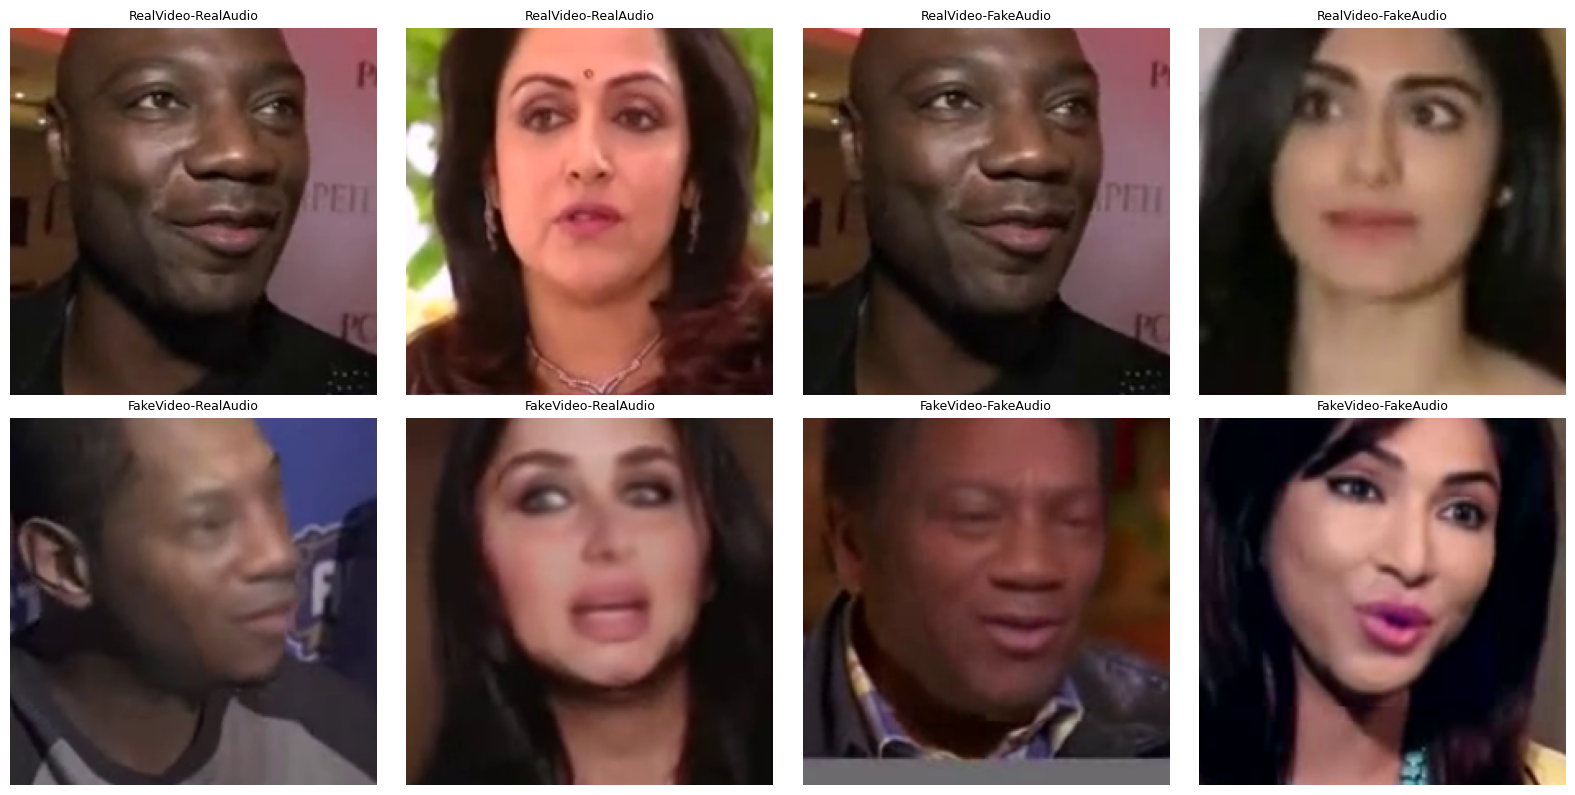

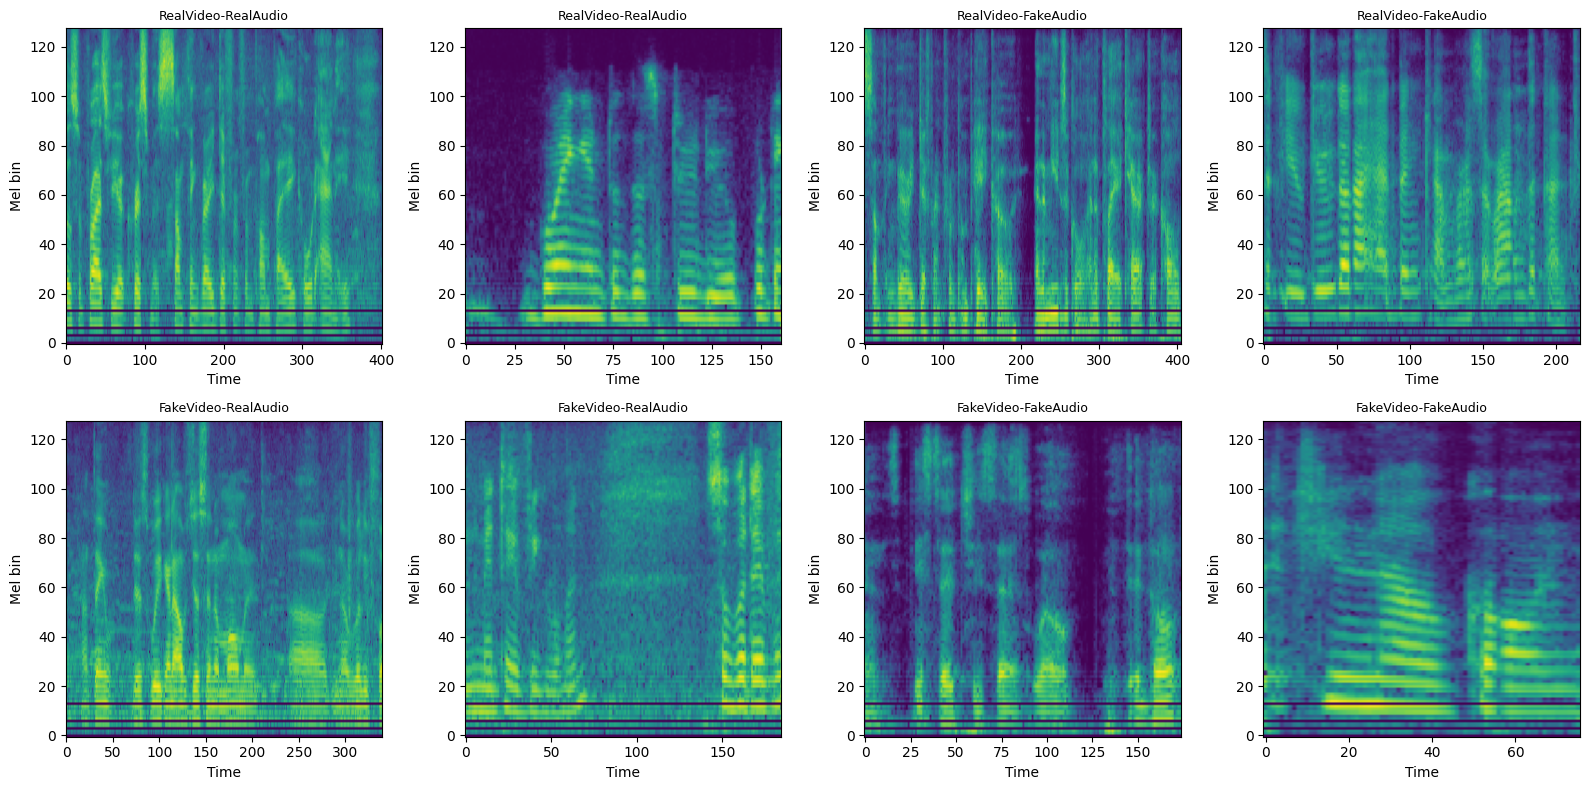


--------------------------------------------------------------------------------------------------------------
[5] Saved artifacts
--------------------------------------------------------------------------------------------------------------
Results:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/cell13_preprocessing_smoke_test.csv

Summary:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/cell13_preprocessing_smoke_test_summary.json

Visual QA:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/cell13_visual_smoke_test.png

Mel QA:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/cell13_logmel_smoke_test.png

CELL 13 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 13: SYNCHRONIZED MULTIMODAL PREPROCESSING SMOKE TEST
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import torchaudio
import torchvision
import cv2
import subprocess
import json
import tempfile
import random
import matplotlib.pyplot as plt

print("=" * 110)
print("SMD-NET V2 — CELL 13: SYNCHRONIZED MULTIMODAL PREPROCESSING SMOKE TEST")
print("=" * 110)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ------------------------------------------------------------
# 1. Load frozen audited manifest
# ------------------------------------------------------------
manifest_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

df = pd.read_csv(manifest_file)

category_col = (
    "category_inventory"
    if "category_inventory" in df.columns
    else "category"
)

print("\n[1] Frozen cohort")
print("-" * 110)

print("Videos:", len(df))
print(df["split"].value_counts())

# ------------------------------------------------------------
# 2. Select 2 deterministic examples per AV condition
# ------------------------------------------------------------
conditions = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio"
]

samples = []

for condition in conditions:

    candidates = (
        df[
            df[category_col] == condition
        ]
        .sort_values("absolute_path")
        .copy()
    )

    # Spread selections rather than taking adjacent files
    indices = [
        0,
        len(candidates) // 2
    ]

    for idx in indices:
        samples.append(
            candidates.iloc[idx]
        )

sample_df = pd.DataFrame(samples).reset_index(drop=True)

print("\nSelected smoke-test videos:")

display(
    sample_df[
        [
            "split",
            category_col,
            "method",
            "duration_sec",
            "fps",
            "frame_count",
            "audio_sample_rate",
            "audio_channels",
            "absolute_path"
        ]
    ]
)

# ------------------------------------------------------------
# 3. Configuration
# ------------------------------------------------------------
N_FRAMES = 16
IMAGE_SIZE = 224
TARGET_SR = 16000

N_FFT = 400
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128

# Important:
# For the smoke test we use the middle 40% of each video.
#
# Later:
# train -> stochastic normalized window
# val   -> deterministic center window
# test  -> five deterministic windows
WINDOW_FRACTION = 0.40

# ------------------------------------------------------------
# 4. Determine synchronized center interval
# ------------------------------------------------------------
def get_center_interval(duration, fraction=0.40):

    duration = float(duration)

    segment_duration = duration * fraction

    start = (
        duration - segment_duration
    ) / 2.0

    end = start + segment_duration

    return (
        float(start),
        float(end),
        float(segment_duration)
    )

# ------------------------------------------------------------
# 5. Decode 16 frames from exact temporal interval
# ------------------------------------------------------------
def decode_video_frames(
    video_path,
    start_sec,
    end_sec,
    n_frames=16
):

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    if fps <= 0:
        cap.release()
        raise RuntimeError(
            f"Invalid FPS: {video_path}"
        )

    duration_from_cv = (
        total_frames / fps
    )

    # 16 uniformly spaced timestamps
    timestamps = np.linspace(
        start_sec,
        end_sec,
        n_frames,
        endpoint=False
    )

    frames = []

    actual_positions = []

    for t in timestamps:

        cap.set(
            cv2.CAP_PROP_POS_MSEC,
            float(t) * 1000.0
        )

        ok, frame = cap.read()

        if not ok:
            cap.release()
            raise RuntimeError(
                f"Frame decode failed at {t:.3f}s: "
                f"{video_path}"
            )

        # BGR -> RGB
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        # Resize while preserving aspect ratio
        h, w = frame.shape[:2]

        scale = 256.0 / min(h, w)

        new_w = int(
            round(w * scale)
        )

        new_h = int(
            round(h * scale)
        )

        frame = cv2.resize(
            frame,
            (new_w, new_h),
            interpolation=cv2.INTER_LINEAR
        )

        # Center crop 224 x 224
        y0 = max(
            0,
            (new_h - IMAGE_SIZE) // 2
        )

        x0 = max(
            0,
            (new_w - IMAGE_SIZE) // 2
        )

        frame = frame[
            y0:y0 + IMAGE_SIZE,
            x0:x0 + IMAGE_SIZE
        ]

        if (
            frame.shape[0] != IMAGE_SIZE
            or
            frame.shape[1] != IMAGE_SIZE
        ):
            frame = cv2.resize(
                frame,
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=cv2.INTER_LINEAR
            )

        frames.append(frame)

        actual_positions.append(
            float(
                cap.get(
                    cv2.CAP_PROP_POS_MSEC
                )
            ) / 1000.0
        )

    cap.release()

    frames = np.stack(
        frames,
        axis=0
    )

    return (
        frames,
        timestamps,
        np.array(actual_positions),
        fps,
        total_frames,
        duration_from_cv
    )

# ------------------------------------------------------------
# 6. Convert visual data to normalized tensor
# ------------------------------------------------------------
IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(1, 3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(1, 3, 1, 1)

def frames_to_tensor(frames):

    x = torch.from_numpy(
        frames.copy()
    ).float()

    # [T,H,W,C] -> [T,C,H,W]
    x = x.permute(
        0, 3, 1, 2
    )

    x = x / 255.0

    x = (
        x - IMAGENET_MEAN
    ) / IMAGENET_STD

    return x

# ------------------------------------------------------------
# 7. Extract exact synchronized audio interval with FFmpeg
# ------------------------------------------------------------
def extract_audio_segment(
    video_path,
    start_sec,
    end_sec,
    target_sr=16000
):

    duration = (
        end_sec - start_sec
    )

    with tempfile.NamedTemporaryFile(
        suffix=".wav",
        delete=False
    ) as tmp:

        wav_path = Path(tmp.name)

    command = [
        "ffmpeg",
        "-v", "error",
        "-y",

        "-ss",
        f"{start_sec:.6f}",

        "-i",
        str(video_path),

        "-t",
        f"{duration:.6f}",

        "-ac",
        "1",

        "-ar",
        str(target_sr),

        "-acodec",
        "pcm_s16le",

        str(wav_path)
    ]

    proc = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    if proc.returncode != 0:

        if wav_path.exists():
            wav_path.unlink()

        raise RuntimeError(
            proc.stderr[:1000]
        )

    waveform, sr = (
        torchaudio.load(
            str(wav_path)
        )
    )

    wav_path.unlink(
        missing_ok=True
    )

    return waveform, sr

# ------------------------------------------------------------
# 8. Log-Mel transform
# ------------------------------------------------------------
mel_transform = (
    torchaudio.transforms.MelSpectrogram(
        sample_rate=TARGET_SR,
        n_fft=N_FFT,
        win_length=WIN_LENGTH,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        f_min=0,
        f_max=8000,
        power=2.0
    )
)

def waveform_to_logmel(waveform):

    mel = mel_transform(
        waveform
    )

    logmel = torch.log(
        mel + 1e-6
    )

    mean = logmel.mean()

    std = logmel.std()

    logmel_norm = (
        logmel - mean
    ) / (
        std + 1e-6
    )

    return (
        logmel,
        logmel_norm
    )

# ------------------------------------------------------------
# 9. Process the eight samples
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[2] Processing synchronized examples")
print("-" * 110)

records = []

visual_examples = []
mel_examples = []

for i, row in sample_df.iterrows():

    video_path = Path(
        row["absolute_path"]
    )

    (
        start_sec,
        end_sec,
        segment_duration
    ) = get_center_interval(
        row["duration_sec"],
        WINDOW_FRACTION
    )

    (
        frames,
        requested_ts,
        actual_ts,
        cv_fps,
        cv_frames,
        cv_duration
    ) = decode_video_frames(
        video_path,
        start_sec,
        end_sec,
        N_FRAMES
    )

    visual_tensor = (
        frames_to_tensor(
            frames
        )
    )

    waveform, sr = (
        extract_audio_segment(
            video_path,
            start_sec,
            end_sec,
            TARGET_SR
        )
    )

    (
        logmel,
        logmel_norm
    ) = waveform_to_logmel(
        waveform
    )

    audio_duration = (
        waveform.shape[-1] / sr
    )

    max_timestamp_error = float(
        np.max(
            np.abs(
                actual_ts -
                requested_ts
            )
        )
    )

    records.append({
        "sample": i,
        "condition": row[category_col],
        "method": row["method"],
        "split": row["split"],

        "video_duration_sec":
            float(row["duration_sec"]),

        "segment_start_sec":
            start_sec,

        "segment_end_sec":
            end_sec,

        "requested_segment_sec":
            segment_duration,

        "decoded_audio_sec":
            audio_duration,

        "audio_duration_error_sec":
            abs(
                audio_duration -
                segment_duration
            ),

        "requested_frames":
            N_FRAMES,

        "decoded_frames":
            int(frames.shape[0]),

        "visual_shape":
            str(
                tuple(
                    visual_tensor.shape
                )
            ),

        "waveform_shape":
            str(
                tuple(
                    waveform.shape
                )
            ),

        "logmel_shape":
            str(
                tuple(
                    logmel_norm.shape
                )
            ),

        "sample_rate":
            int(sr),

        "max_frame_timestamp_error_sec":
            max_timestamp_error,

        "source_fps":
            float(cv_fps),

        "source_frames":
            int(cv_frames)
    })

    visual_examples.append(
        frames
    )

    mel_examples.append(
        logmel_norm.squeeze(0)
        .cpu()
        .numpy()
    )

    print(
        f"[{i+1}/8] "
        f"{row[category_col]} | "
        f"visual={tuple(visual_tensor.shape)} | "
        f"audio={tuple(waveform.shape)} | "
        f"mel={tuple(logmel_norm.shape)} | "
        f"segment={segment_duration:.3f}s | "
        f"audio={audio_duration:.3f}s"
    )

results = pd.DataFrame(
    records
)

# ------------------------------------------------------------
# 10. Display detailed results
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Smoke-test results")
print("-" * 110)

display(results)

# ------------------------------------------------------------
# 11. Assertions
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Integrity assertions")
print("-" * 110)

assert (
    results["decoded_frames"]
    ==
    N_FRAMES
).all()

print(
    "16 decoded frames/sample: PASS"
)

assert (
    results["sample_rate"]
    ==
    TARGET_SR
).all()

print(
    "16-kHz audio conversion: PASS"
)

assert all(
    shape ==
    "(16, 3, 224, 224)"
    for shape in
    results["visual_shape"]
)

print(
    "Visual tensor shape: PASS"
)

# Allow small codec/container boundary error
assert (
    results[
        "audio_duration_error_sec"
    ].max()
    <
    0.10
)

print(
    "Synchronized audio duration: PASS"
)

assert all(
    "128" in shape
    for shape in
    results["logmel_shape"]
)

print(
    "128-bin Mel representation: PASS"
)

# ------------------------------------------------------------
# 12. Create visual QA figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)

for i, ax in enumerate(
    axes.flatten()
):

    # middle decoded frame
    frame = (
        visual_examples[i][
            len(visual_examples[i]) // 2
        ]
    )

    ax.imshow(frame)

    ax.set_title(
        sample_df.iloc[i][
            category_col
        ],
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()

visual_fig = (
    DIRS["results"] /
    "Figures" /
    "cell13_visual_smoke_test.png"
)

plt.savefig(
    visual_fig,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 13. Create Mel QA figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)

for i, ax in enumerate(
    axes.flatten()
):

    ax.imshow(
        mel_examples[i],
        origin="lower",
        aspect="auto"
    )

    ax.set_title(
        sample_df.iloc[i][
            category_col
        ],
        fontsize=9
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Mel bin")

plt.tight_layout()

mel_fig = (
    DIRS["results"] /
    "Figures" /
    "cell13_logmel_smoke_test.png"
)

plt.savefig(
    mel_fig,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 14. Save results
# ------------------------------------------------------------
results_file = (
    DIRS["metadata"] /
    "cell13_preprocessing_smoke_test.csv"
)

results.to_csv(
    results_file,
    index=False
)

summary = {
    "samples_tested": int(
        len(results)
    ),

    "conditions_tested":
        sorted(
            results["condition"]
            .unique()
            .tolist()
        ),

    "frames_per_sample":
        N_FRAMES,

    "visual_shape":
        "(16, 3, 224, 224)",

    "target_audio_sample_rate":
        TARGET_SR,

    "n_mels":
        N_MELS,

    "max_audio_duration_error_sec":
        float(
            results[
                "audio_duration_error_sec"
            ].max()
        ),

    "max_frame_timestamp_error_sec":
        float(
            results[
                "max_frame_timestamp_error_sec"
            ].max()
        ),

    "all_assertions_passed":
        True
}

summary_file = (
    DIRS["metadata"] /
    "cell13_preprocessing_smoke_test_summary.json"
)

with open(
    summary_file,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 110)
print("[5] Saved artifacts")
print("-" * 110)

print("Results:")
print(results_file)

print("\nSummary:")
print(summary_file)

print("\nVisual QA:")
print(visual_fig)

print("\nMel QA:")
print(mel_fig)

print("\n" + "=" * 110)
print("CELL 13 COMPLETED SUCCESSFULLY")
print("=" * 110)

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 13B: CORRECTED MEL FRONTEND VALIDATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import torchaudio
import json
import subprocess
import tempfile
import warnings

print("=" * 110)
print("SMD-NET V2 — CELL 13B: CORRECTED MEL FRONTEND VALIDATION")
print("=" * 110)

# ------------------------------------------------------------
# 1. Corrected audio configuration
# ------------------------------------------------------------
TARGET_SR = 16000

N_FFT = 512
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128

F_MIN = 0.0
F_MAX = 8000.0

print("\n[1] Corrected frontend")
print("-" * 110)

print("Sample rate :", TARGET_SR)
print("n_fft       :", N_FFT)
print("win_length  :", WIN_LENGTH)
print("hop_length  :", HOP_LENGTH)
print("n_mels      :", N_MELS)
print("f_min       :", F_MIN)
print("f_max       :", F_MAX)

print(
    "\nWindow duration:",
    WIN_LENGTH / TARGET_SR * 1000,
    "ms"
)

print(
    "Hop duration   :",
    HOP_LENGTH / TARGET_SR * 1000,
    "ms"
)

print(
    "Positive FFT bins:",
    N_FFT // 2 + 1
)

# ------------------------------------------------------------
# 2. Explicitly construct Mel filterbank
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[2] Mel filterbank integrity")
print("-" * 110)

fbanks = torchaudio.functional.melscale_fbanks(
    n_freqs=N_FFT // 2 + 1,
    f_min=F_MIN,
    f_max=F_MAX,
    n_mels=N_MELS,
    sample_rate=TARGET_SR,
    norm=None,
    mel_scale="htk"
)

print("Filterbank shape:", tuple(fbanks.shape))

# torchaudio shape:
# [n_freqs, n_mels]
mel_energy = fbanks.abs().sum(dim=0)

zero_filters = (
    mel_energy <= 0
)

n_zero = int(
    zero_filters.sum().item()
)

print(
    "Zero-valued Mel filters:",
    n_zero
)

print(
    "Minimum filter energy:",
    float(mel_energy.min())
)

print(
    "Maximum filter energy:",
    float(mel_energy.max())
)

assert n_zero == 0, (
    f"Mel frontend still contains "
    f"{n_zero} zero filters."
)

print("Mel filterbank integrity: PASS")

# ------------------------------------------------------------
# 3. Create corrected transform
# ------------------------------------------------------------
mel_transform_corrected = (
    torchaudio.transforms.MelSpectrogram(
        sample_rate=TARGET_SR,
        n_fft=N_FFT,
        win_length=WIN_LENGTH,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        f_min=F_MIN,
        f_max=F_MAX,
        power=2.0
    )
)

# ------------------------------------------------------------
# 4. Reload same eight smoke-test videos
# ------------------------------------------------------------
manifest_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

df = pd.read_csv(manifest_file)

category_col = (
    "category_inventory"
    if "category_inventory" in df.columns
    else "category"
)

conditions = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio"
]

samples = []

for condition in conditions:

    candidates = (
        df[
            df[category_col] == condition
        ]
        .sort_values("absolute_path")
        .copy()
    )

    for idx in [
        0,
        len(candidates) // 2
    ]:
        samples.append(
            candidates.iloc[idx]
        )

sample_df = pd.DataFrame(
    samples
).reset_index(drop=True)

print("\n" + "-" * 110)
print("[3] Rechecking eight synchronized audio samples")
print("-" * 110)

# ------------------------------------------------------------
# 5. Audio extraction helper
# ------------------------------------------------------------
def extract_audio_13b(
    video_path,
    start_sec,
    duration_sec
):

    with tempfile.NamedTemporaryFile(
        suffix=".wav",
        delete=False
    ) as tmp:

        wav_path = Path(tmp.name)

    cmd = [
        "ffmpeg",
        "-v", "error",
        "-y",

        "-ss",
        f"{start_sec:.6f}",

        "-i",
        str(video_path),

        "-t",
        f"{duration_sec:.6f}",

        "-ac", "1",
        "-ar", str(TARGET_SR),

        "-acodec",
        "pcm_s16le",

        str(wav_path)
    ]

    proc = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    if proc.returncode != 0:

        wav_path.unlink(
            missing_ok=True
        )

        raise RuntimeError(
            proc.stderr[:1000]
        )

    waveform, sr = (
        torchaudio.load(
            str(wav_path)
        )
    )

    wav_path.unlink(
        missing_ok=True
    )

    return waveform, sr

# ------------------------------------------------------------
# 6. Corrected log-Mel helper
# ------------------------------------------------------------
def corrected_logmel(waveform):

    mel = mel_transform_corrected(
        waveform
    )

    logmel = torch.log(
        mel + 1e-6
    )

    mean = logmel.mean()
    std = logmel.std()

    normalized = (
        logmel - mean
    ) / (
        std + 1e-6
    )

    return (
        mel,
        logmel,
        normalized
    )

# ------------------------------------------------------------
# 7. Process samples and catch warnings
# ------------------------------------------------------------
records = []

with warnings.catch_warnings(
    record=True
) as caught:

    warnings.simplefilter("always")

    for i, row in sample_df.iterrows():

        video_duration = float(
            row["duration_sec"]
        )

        segment_duration = (
            video_duration * 0.40
        )

        start_sec = (
            video_duration -
            segment_duration
        ) / 2.0

        waveform, sr = (
            extract_audio_13b(
                row["absolute_path"],
                start_sec,
                segment_duration
            )
        )

        (
            mel,
            logmel,
            normalized
        ) = corrected_logmel(
            waveform
        )

        finite = bool(
            torch.isfinite(
                normalized
            ).all()
        )

        variance = float(
            normalized.var()
        )

        # Energy of each Mel row
        row_variance = (
            normalized
            .squeeze(0)
            .var(dim=1)
        )

        constant_rows = int(
            (
                row_variance
                <= 1e-12
            ).sum()
        )

        records.append({
            "sample": i,

            "condition":
                row[category_col],

            "method":
                row["method"],

            "source_sample_rate":
                int(
                    row["audio_sample_rate"]
                ),

            "source_channels":
                int(
                    row["audio_channels"]
                ),

            "segment_duration_sec":
                segment_duration,

            "output_sample_rate":
                int(sr),

            "waveform_samples":
                int(
                    waveform.shape[-1]
                ),

            "mel_shape":
                str(
                    tuple(
                        normalized.shape
                    )
                ),

            "finite_values":
                finite,

            "normalized_variance":
                variance,

            "constant_mel_rows":
                constant_rows
        })

        print(
            f"[{i+1}/8] "
            f"{row[category_col]} | "
            f"{row['method']} | "
            f"{tuple(normalized.shape)} | "
            f"constant Mel rows={constant_rows}"
        )

results = pd.DataFrame(
    records
)

# ------------------------------------------------------------
# 8. Warning audit
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Warning audit")
print("-" * 110)

mel_warnings = [
    str(w.message)
    for w in caught
    if (
        "mel filterbank" in
        str(w.message).lower()
        or
        "zero values" in
        str(w.message).lower()
    )
]

print(
    "Mel/filterbank warnings:",
    len(mel_warnings)
)

for warning in mel_warnings:
    print(" -", warning)

assert len(mel_warnings) == 0

# ------------------------------------------------------------
# 9. Numerical integrity
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[5] Numerical integrity")
print("-" * 110)

display(results)

assert (
    results["output_sample_rate"]
    ==
    TARGET_SR
).all()

assert (
    results["finite_values"]
).all()

assert (
    results["constant_mel_rows"]
    ==
    0
).all()

assert (
    results[
        "normalized_variance"
    ]
    >
    0
).all()

print("16-kHz conversion       : PASS")
print("Finite spectrograms     : PASS")
print("No constant Mel rows    : PASS")
print("Non-zero variance       : PASS")

# ------------------------------------------------------------
# 10. Update preprocessing configuration
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[6] Updating frozen preprocessing configuration")
print("-" * 110)

config_file = (
    DIRS["code"] /
    "preprocessing_config_v2.json"
)

with open(config_file, "r") as f:
    config = json.load(f)

config["audio"]["n_fft"] = N_FFT
config["audio"]["win_length"] = WIN_LENGTH
config["audio"]["hop_length"] = HOP_LENGTH
config["audio"]["n_mels"] = N_MELS
config["audio"]["f_min"] = int(F_MIN)
config["audio"]["f_max"] = int(F_MAX)

config["audio"][
    "fft_note"
] = (
    "400-sample (25 ms) analysis window "
    "zero-padded to a 512-point FFT"
)

config["audio"][
    "mel_filterbank_validation"
] = {
    "n_freqs": N_FFT // 2 + 1,
    "zero_filters": n_zero,
    "status": "PASS"
}

with open(config_file, "w") as f:

    json.dump(
        config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 11. Update human-readable protocol
# ------------------------------------------------------------
txt_file = (
    DIRS["code"] /
    "preprocessing_protocol_v2.txt"
)

protocol_text = f"""
SMD-Net V2 — Frozen Multimodal Preprocessing Protocol
======================================================

DATASET
-------
Final clean cohort: {len(df):,} videos
Training: {(df['split'] == 'train').sum():,}
Validation: {(df['split'] == 'validation').sum():,}
Test: {(df['split'] == 'test').sum():,}

VISUAL INPUT
------------
Frames per segment: 16
Input resolution: 224 x 224
Resize short side: 256
Normalization: ImageNet mean/std
Training sampling: random synchronized temporal segment
Validation: deterministic center segment
Test: 5 deterministic temporal segments per video
Video prediction: mean segment probability

AUDIO INPUT
-----------
Target sample rate: 16,000 Hz
Channels: mono
Representation: log-Mel spectrogram
Mel bins: 128

Analysis window: 400 samples (25 ms)
FFT size: 512
FFT policy: 400-sample window zero-padded to 512 points
Hop: 160 samples (10 ms)

Frequency range: 0-8,000 Hz
Power: 2.0
Log transform: log(x + 1e-6)
Normalization: per-sample mean/std

Mel filterbank validation:
Positive FFT bins: {N_FFT // 2 + 1}
Zero-valued Mel filters: {n_zero}
Status: PASS

SYNCHRONIZATION
---------------
Audio and video are extracted from the same temporal interval.
Temporal sampling is defined relative to each video's duration.

TRAINING IMBALANCE
------------------
All clean training videos remain available.
No permanent random undersampling is used.
Balanced binary sampling is performed during training.
Manipulated samples are diversified across conditions/methods.

EVALUATION
----------
Validation and test retain their frozen natural class distribution.
Classification threshold is selected using validation data only.
The test threshold is frozen before final test evaluation.

REPRODUCIBILITY
---------------
Global seed: 42
Split seed: 42
Validation/test preprocessing: deterministic
"""

with open(txt_file, "w") as f:
    f.write(
        protocol_text.strip()
    )

# ------------------------------------------------------------
# 12. Save correction audit
# ------------------------------------------------------------
results_file = (
    DIRS["metadata"] /
    "cell13b_corrected_mel_validation.csv"
)

results.to_csv(
    results_file,
    index=False
)

summary = {
    "sample_rate": TARGET_SR,
    "n_fft": N_FFT,
    "win_length": WIN_LENGTH,
    "hop_length": HOP_LENGTH,
    "n_mels": N_MELS,
    "positive_fft_bins":
        N_FFT // 2 + 1,
    "zero_mel_filters":
        n_zero,
    "mel_filterbank_warnings":
        len(mel_warnings),
    "samples_validated":
        len(results),
    "all_finite":
        bool(
            results[
                "finite_values"
            ].all()
        ),
    "all_constant_mel_rows_zero":
        bool(
            (
                results[
                    "constant_mel_rows"
                ]
                ==
                0
            ).all()
        ),
    "status": "PASS"
}

summary_file = (
    DIRS["metadata"] /
    "cell13b_corrected_mel_validation_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("Updated JSON:")
print(config_file)

print("\nUpdated protocol:")
print(txt_file)

print("\nValidation table:")
print(results_file)

print("\nValidation summary:")
print(summary_file)

print("\n" + "=" * 110)
print("CELL 13B COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 13B: CORRECTED MEL FRONTEND VALIDATION

[1] Corrected frontend
--------------------------------------------------------------------------------------------------------------
Sample rate : 16000
n_fft       : 512
win_length  : 400
hop_length  : 160
n_mels      : 128
f_min       : 0.0
f_max       : 8000.0

Window duration: 25.0 ms
Hop duration   : 10.0 ms
Positive FFT bins: 257

--------------------------------------------------------------------------------------------------------------
[2] Mel filterbank integrity
--------------------------------------------------------------------------------------------------------------
Filterbank shape: (257, 128)
Zero-valued Mel filters: 1
Minimum filter energy: 0.0
Maximum filter energy: 5.31019401550293


/usr/local/lib/python3.13/dist-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (257) may be set too low.
  warnings.warn(


AssertionError: Mel frontend still contains 1 zero filters.

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 13C: SELECT MINIMUM VALID FFT FOR 128 MEL BINS
# ============================================================

import torch
import torchaudio
import pandas as pd
import numpy as np
import warnings
import json

print("=" * 110)
print("SMD-NET V2 — CELL 13C: FFT / MEL FILTERBANK SELECTION")
print("=" * 110)

TARGET_SR = 16000
WIN_LENGTH = 400       # 25 ms — remains FIXED
HOP_LENGTH = 160       # 10 ms — remains FIXED
N_MELS = 128
F_MIN = 0.0
F_MAX = 8000.0

FFT_CANDIDATES = [
    400,
    512,
    640,
    768,
    800,
    1024,
    2048
]

print("\n[1] Fixed signal-analysis parameters")
print("-" * 110)

print("Sample rate :", TARGET_SR)
print("Window      :", WIN_LENGTH, "samples")
print(
    "Window ms   :",
    WIN_LENGTH / TARGET_SR * 1000
)
print("Hop         :", HOP_LENGTH, "samples")
print(
    "Hop ms      :",
    HOP_LENGTH / TARGET_SR * 1000
)
print("Mel bins    :", N_MELS)
print("Frequency   :", F_MIN, "-", F_MAX, "Hz")

# ------------------------------------------------------------
# 2. Test candidates
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[2] FFT candidate audit")
print("-" * 110)

records = []

for n_fft in FFT_CANDIDATES:

    with warnings.catch_warnings(
        record=True
    ) as caught:

        warnings.simplefilter("always")

        fb = torchaudio.functional.melscale_fbanks(
            n_freqs=n_fft // 2 + 1,
            f_min=F_MIN,
            f_max=F_MAX,
            n_mels=N_MELS,
            sample_rate=TARGET_SR,
            norm=None,
            mel_scale="htk"
        )

    # [frequency, mel]
    filter_energy = (
        fb.abs().sum(dim=0)
    )

    zero_filters = int(
        (
            filter_energy <= 0
        ).sum().item()
    )

    min_energy = float(
        filter_energy.min().item()
    )

    positive_bins = (
        n_fft // 2 + 1
    )

    warning_count = len(
        [
            w for w in caught
            if (
                "mel filterbank"
                in str(w.message).lower()
                or
                "zero values"
                in str(w.message).lower()
            )
        ]
    )

    records.append({
        "n_fft": n_fft,
        "positive_fft_bins": positive_bins,
        "zero_mel_filters": zero_filters,
        "minimum_filter_energy": min_energy,
        "mel_warning_count": warning_count,
        "valid": (
            zero_filters == 0
            and
            warning_count == 0
        )
    })

    print(
        f"n_fft={n_fft:4d} | "
        f"freq bins={positive_bins:4d} | "
        f"zero Mel filters={zero_filters:3d} | "
        f"warnings={warning_count} | "
        f"min energy={min_energy:.8f}"
    )

audit = pd.DataFrame(records)

print("\nCandidate table:")
display(audit)

# ------------------------------------------------------------
# 3. Select smallest valid FFT
# ------------------------------------------------------------
valid = audit[
    audit["valid"]
].copy()

print("\n" + "-" * 110)
print("[3] Selection")
print("-" * 110)

if len(valid) == 0:

    raise RuntimeError(
        "None of the tested FFT sizes supports "
        "128 non-empty Mel filters. "
        "Do not proceed to production preprocessing."
    )

selected_fft = int(
    valid.sort_values(
        "n_fft"
    ).iloc[0]["n_fft"]
)

print(
    "Smallest tested valid FFT:",
    selected_fft
)

print(
    "Physical analysis window remains:",
    WIN_LENGTH,
    "samples =",
    WIN_LENGTH / TARGET_SR * 1000,
    "ms"
)

print(
    "Zero-padding:",
    selected_fft - WIN_LENGTH,
    "samples"
)

# ------------------------------------------------------------
# 4. Final selected filterbank verification
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Final selected filterbank verification")
print("-" * 110)

with warnings.catch_warnings(
    record=True
) as final_warnings:

    warnings.simplefilter("always")

    final_fb = (
        torchaudio.functional.melscale_fbanks(
            n_freqs=selected_fft // 2 + 1,
            f_min=F_MIN,
            f_max=F_MAX,
            n_mels=N_MELS,
            sample_rate=TARGET_SR,
            norm=None,
            mel_scale="htk"
        )
    )

final_energy = (
    final_fb.abs().sum(dim=0)
)

final_zero = int(
    (
        final_energy <= 0
    ).sum().item()
)

relevant_final_warnings = [
    str(w.message)
    for w in final_warnings
    if (
        "mel filterbank"
        in str(w.message).lower()
        or
        "zero values"
        in str(w.message).lower()
    )
]

print(
    "Filterbank shape:",
    tuple(final_fb.shape)
)

print(
    "Zero filters:",
    final_zero
)

print(
    "Warnings:",
    len(relevant_final_warnings)
)

print(
    "Minimum filter energy:",
    float(final_energy.min())
)

assert final_zero == 0
assert len(relevant_final_warnings) == 0

print("\nFinal filterbank: PASS")

# ------------------------------------------------------------
# 5. Create selected Mel transform and test numerically
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[5] Synthetic numerical sanity check")
print("-" * 110)

transform = (
    torchaudio.transforms.MelSpectrogram(
        sample_rate=TARGET_SR,
        n_fft=selected_fft,
        win_length=WIN_LENGTH,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        f_min=F_MIN,
        f_max=F_MAX,
        power=2.0
    )
)

# 2 seconds synthetic non-zero waveform
torch.manual_seed(42)

waveform = torch.randn(
    1,
    TARGET_SR * 2
)

with warnings.catch_warnings(
    record=True
) as transform_warnings:

    warnings.simplefilter("always")

    mel = transform(
        waveform
    )

logmel = torch.log(
    mel + 1e-6
)

print(
    "Mel shape:",
    tuple(mel.shape)
)

print(
    "Finite:",
    bool(
        torch.isfinite(
            logmel
        ).all()
    )
)

print(
    "Variance:",
    float(logmel.var())
)

transform_mel_warnings = [
    str(w.message)
    for w in transform_warnings
    if (
        "mel filterbank"
        in str(w.message).lower()
        or
        "zero values"
        in str(w.message).lower()
    )
]

print(
    "Transform Mel warnings:",
    len(transform_mel_warnings)
)

assert (
    mel.shape[1]
    ==
    N_MELS
)

assert torch.isfinite(
    logmel
).all()

assert (
    float(logmel.var())
    >
    0
)

assert (
    len(transform_mel_warnings)
    ==
    0
)

print(
    "Synthetic transform: PASS"
)

# ------------------------------------------------------------
# 6. Save audit
# ------------------------------------------------------------
audit_file = (
    DIRS["metadata"] /
    "cell13c_fft_mel_selection.csv"
)

audit.to_csv(
    audit_file,
    index=False
)

summary = {
    "sample_rate": TARGET_SR,
    "win_length": WIN_LENGTH,
    "window_ms":
        WIN_LENGTH / TARGET_SR * 1000,
    "hop_length": HOP_LENGTH,
    "hop_ms":
        HOP_LENGTH / TARGET_SR * 1000,
    "n_mels": N_MELS,
    "f_min": F_MIN,
    "f_max": F_MAX,
    "selected_n_fft": selected_fft,
    "selected_positive_fft_bins":
        selected_fft // 2 + 1,
    "selected_zero_mel_filters":
        final_zero,
    "selected_warning_count":
        len(relevant_final_warnings),
    "status": "PASS"
}

summary_file = (
    DIRS["metadata"] /
    "cell13c_fft_mel_selection_summary.json"
)

with open(
    summary_file,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 110)
print("[6] Saved artifacts")
print("-" * 110)

print("Audit table:")
print(audit_file)

print("\nSummary:")
print(summary_file)

print("\n" + "=" * 110)
print("CELL 13C COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 13C: FFT / MEL FILTERBANK SELECTION

[1] Fixed signal-analysis parameters
--------------------------------------------------------------------------------------------------------------
Sample rate : 16000
Window      : 400 samples
Window ms   : 25.0
Hop         : 160 samples
Hop ms      : 10.0
Mel bins    : 128
Frequency   : 0.0 - 8000.0 Hz

--------------------------------------------------------------------------------------------------------------
[2] FFT candidate audit
--------------------------------------------------------------------------------------------------------------
n_fft= 400 | freq bins= 201 | zero Mel filters=  4 | warnings=1 | min energy=0.00000000
n_fft= 512 | freq bins= 257 | zero Mel filters=  1 | warnings=1 | min energy=0.00000000
n_fft= 640 | freq bins= 321 | zero Mel filters=  0 | warnings=0 | min energy=0.20524251
n_fft= 768 | freq bins= 385 | zero Mel filters=  0 | warnings=0 | min energy=0.50114399
n_fft= 800 | freq bins= 401 | zero Mel f

,n_fft,positive_fft_bins,zero_mel_filters,minimum_filter_energy,mel_warning_count,valid
0,400,201,4,0.000000,1,False
1,512,257,1,0.000000,1,False
2,640,321,0,0.205243,0,True
3,768,385,0,0.501144,0,True
4,800,401,0,0.560324,0,True
5,1024,513,0,0.871021,0,True
6,2048,1025,0,1.752988,0,True



--------------------------------------------------------------------------------------------------------------
[3] Selection
--------------------------------------------------------------------------------------------------------------
Smallest tested valid FFT: 640
Physical analysis window remains: 400 samples = 25.0 ms
Zero-padding: 240 samples

--------------------------------------------------------------------------------------------------------------
[4] Final selected filterbank verification
--------------------------------------------------------------------------------------------------------------
Filterbank shape: (321, 128)
Zero filters: 0
Warnings: 0
Minimum filter energy: 0.20524251461029053

Final filterbank: PASS

--------------------------------------------------------------------------------------------------------------
[5] Synthetic numerical sanity check
--------------------------------------------------------------------------------------------------------------


In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 13D: FINAL REAL-DATA MEL VALIDATION + PROTOCOL UPDATE
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import torchaudio
import subprocess
import tempfile
import warnings
import json

print("=" * 110)
print("SMD-NET V2 — CELL 13D: FINAL REAL-DATA MEL VALIDATION + PROTOCOL UPDATE")
print("=" * 110)

# ------------------------------------------------------------
# 1. Load FFT selection from Cell 13C
# ------------------------------------------------------------
selection_file = (
    DIRS["metadata"] /
    "cell13c_fft_mel_selection_summary.json"
)

with open(selection_file, "r") as f:
    fft_selection = json.load(f)

N_FFT = int(
    fft_selection["selected_n_fft"]
)

TARGET_SR = 16000
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128
F_MIN = 0.0
F_MAX = 8000.0

print("\n[1] Final selected audio frontend")
print("-" * 110)

print("Sample rate :", TARGET_SR)
print("Window      :", WIN_LENGTH, "samples")
print("Window ms   :", WIN_LENGTH / TARGET_SR * 1000)
print("FFT         :", N_FFT)
print("FFT bins    :", N_FFT // 2 + 1)
print("Zero pad    :", N_FFT - WIN_LENGTH, "samples")
print("Hop         :", HOP_LENGTH, "samples")
print("Hop ms      :", HOP_LENGTH / TARGET_SR * 1000)
print("Mel bins    :", N_MELS)
print("Frequency   :", F_MIN, "-", F_MAX, "Hz")

assert N_FFT == 640

# ------------------------------------------------------------
# 2. Load frozen manifest
# ------------------------------------------------------------
manifest_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

df = pd.read_csv(manifest_file)

category_col = (
    "category_inventory"
    if "category_inventory" in df.columns
    else "category"
)

# Same deterministic 8 samples used previously
conditions = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio"
]

samples = []

for condition in conditions:

    candidates = (
        df[df[category_col] == condition]
        .sort_values("absolute_path")
        .copy()
    )

    for idx in [
        0,
        len(candidates) // 2
    ]:
        samples.append(
            candidates.iloc[idx]
        )

sample_df = (
    pd.DataFrame(samples)
    .reset_index(drop=True)
)

print("\n" + "-" * 110)
print("[2] Real-data validation sample")
print("-" * 110)

display(
    sample_df[
        [
            "split",
            category_col,
            "method",
            "duration_sec",
            "audio_sample_rate",
            "audio_channels"
        ]
    ]
)

# ------------------------------------------------------------
# 3. Final Mel filterbank verification
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Final filterbank verification")
print("-" * 110)

with warnings.catch_warnings(
    record=True
) as filter_warnings:

    warnings.simplefilter("always")

    fb = torchaudio.functional.melscale_fbanks(
        n_freqs=N_FFT // 2 + 1,
        f_min=F_MIN,
        f_max=F_MAX,
        n_mels=N_MELS,
        sample_rate=TARGET_SR,
        norm=None,
        mel_scale="htk"
    )

filter_energy = (
    fb.abs().sum(dim=0)
)

zero_filters = int(
    (filter_energy <= 0)
    .sum()
    .item()
)

relevant_filter_warnings = [
    str(w.message)
    for w in filter_warnings
    if (
        "mel filterbank" in
        str(w.message).lower()
        or
        "zero values" in
        str(w.message).lower()
    )
]

print("Filterbank shape :", tuple(fb.shape))
print("Zero filters     :", zero_filters)
print("Mel warnings     :", len(relevant_filter_warnings))
print("Min filter energy:", float(filter_energy.min()))
print("Max filter energy:", float(filter_energy.max()))

assert zero_filters == 0
assert len(relevant_filter_warnings) == 0

print("Filterbank: PASS")

# ------------------------------------------------------------
# 4. Production-equivalent Mel transform
# ------------------------------------------------------------
mel_transform = (
    torchaudio.transforms.MelSpectrogram(
        sample_rate=TARGET_SR,
        n_fft=N_FFT,
        win_length=WIN_LENGTH,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        f_min=F_MIN,
        f_max=F_MAX,
        power=2.0
    )
)

# ------------------------------------------------------------
# 5. Audio extraction
# ------------------------------------------------------------
def extract_audio(
    video_path,
    start_sec,
    duration_sec
):

    with tempfile.NamedTemporaryFile(
        suffix=".wav",
        delete=False
    ) as tmp:

        wav_path = Path(tmp.name)

    cmd = [
        "ffmpeg",
        "-v", "error",
        "-y",
        "-ss", f"{start_sec:.6f}",
        "-i", str(video_path),
        "-t", f"{duration_sec:.6f}",
        "-ac", "1",
        "-ar", str(TARGET_SR),
        "-acodec", "pcm_s16le",
        str(wav_path)
    ]

    proc = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    if proc.returncode != 0:

        wav_path.unlink(
            missing_ok=True
        )

        raise RuntimeError(
            proc.stderr[:1000]
        )

    waveform, sr = torchaudio.load(
        str(wav_path)
    )

    wav_path.unlink(
        missing_ok=True
    )

    return waveform, sr

# ------------------------------------------------------------
# 6. Final log-Mel function
# ------------------------------------------------------------
def make_logmel(waveform):

    mel = mel_transform(
        waveform
    )

    logmel = torch.log(
        mel + 1e-6
    )

    mean = logmel.mean()
    std = logmel.std()

    normalized = (
        logmel - mean
    ) / (
        std + 1e-6
    )

    return (
        mel,
        logmel,
        normalized
    )

# ------------------------------------------------------------
# 7. Validate all 8 real samples
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Real-video frontend validation")
print("-" * 110)

records = []

with warnings.catch_warnings(
    record=True
) as runtime_warnings:

    warnings.simplefilter("always")

    for i, row in sample_df.iterrows():

        video_duration = float(
            row["duration_sec"]
        )

        # Same 40% center interval as Cell 13
        requested_duration = (
            video_duration * 0.40
        )

        start_sec = (
            video_duration -
            requested_duration
        ) / 2.0

        waveform, sr = extract_audio(
            row["absolute_path"],
            start_sec,
            requested_duration
        )

        mel, logmel, normalized = (
            make_logmel(
                waveform
            )
        )

        actual_duration = (
            waveform.shape[-1] / sr
        )

        duration_error = abs(
            actual_duration -
            requested_duration
        )

        finite = bool(
            torch.isfinite(
                normalized
            ).all()
        )

        mel_2d = (
            normalized
            .squeeze(0)
        )

        row_variances = (
            mel_2d.var(dim=1)
        )

        constant_rows = int(
            (
                row_variances
                <= 1e-12
            )
            .sum()
            .item()
        )

        overall_variance = float(
            normalized.var().item()
        )

        records.append({
            "sample": i,
            "condition":
                row[category_col],
            "method":
                row["method"],
            "split":
                row["split"],

            "source_sample_rate":
                int(
                    row["audio_sample_rate"]
                ),

            "source_channels":
                int(
                    row["audio_channels"]
                ),

            "requested_duration_sec":
                requested_duration,

            "decoded_duration_sec":
                actual_duration,

            "duration_error_sec":
                duration_error,

            "output_sample_rate":
                int(sr),

            "waveform_samples":
                int(
                    waveform.shape[-1]
                ),

            "mel_shape":
                str(
                    tuple(
                        normalized.shape
                    )
                ),

            "finite":
                finite,

            "constant_mel_rows":
                constant_rows,

            "normalized_variance":
                overall_variance
        })

        print(
            f"[{i+1}/8] "
            f"{row[category_col]} | "
            f"{row['method']} | "
            f"src={int(row['audio_sample_rate'])}Hz/"
            f"{int(row['audio_channels'])}ch | "
            f"out={sr}Hz | "
            f"mel={tuple(normalized.shape)} | "
            f"constant rows={constant_rows} | "
            f"finite={finite}"
        )

results = pd.DataFrame(
    records
)

# ------------------------------------------------------------
# 8. Runtime warning audit
# ------------------------------------------------------------
mel_runtime_warnings = [
    str(w.message)
    for w in runtime_warnings
    if (
        "mel filterbank" in
        str(w.message).lower()
        or
        "zero values" in
        str(w.message).lower()
    )
]

print("\n" + "-" * 110)
print("[5] Final assertions")
print("-" * 110)

display(results)

print(
    "Mel runtime warnings:",
    len(mel_runtime_warnings)
)

print(
    "Maximum audio duration error:",
    results[
        "duration_error_sec"
    ].max()
)

print(
    "Maximum constant Mel rows:",
    results[
        "constant_mel_rows"
    ].max()
)

assert (
    results["output_sample_rate"]
    ==
    TARGET_SR
).all()

assert (
    results["finite"]
).all()

assert (
    results[
        "constant_mel_rows"
    ]
    ==
    0
).all()

assert (
    results[
        "normalized_variance"
    ]
    >
    0
).all()

assert (
    results[
        "duration_error_sec"
    ].max()
    <
    0.10
)

assert len(
    mel_runtime_warnings
) == 0

print("16-kHz conversion        : PASS")
print("Finite log-Mel tensors   : PASS")
print("No constant Mel rows     : PASS")
print("Non-zero variance        : PASS")
print("Audio duration agreement : PASS")
print("No Mel runtime warnings  : PASS")

# ------------------------------------------------------------
# 9. Update preprocessing_config_v2.json
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[6] Freezing corrected preprocessing configuration")
print("-" * 110)

config_file = (
    DIRS["code"] /
    "preprocessing_config_v2.json"
)

with open(config_file, "r") as f:
    config = json.load(f)

config["audio"]["target_sample_rate"] = TARGET_SR
config["audio"]["channels"] = 1
config["audio"]["n_fft"] = N_FFT
config["audio"]["win_length"] = WIN_LENGTH
config["audio"]["hop_length"] = HOP_LENGTH
config["audio"]["n_mels"] = N_MELS
config["audio"]["f_min"] = F_MIN
config["audio"]["f_max"] = F_MAX
config["audio"]["power"] = 2.0
config["audio"]["log_transform"] = "log(x + 1e-6)"
config["audio"]["normalization"] = "per_sample_mean_std"

config["audio"]["fft_note"] = (
    "400-sample (25 ms) analysis window "
    "zero-padded to a 640-point FFT"
)

config["audio"]["mel_filterbank_validation"] = {
    "selection_method":
        "smallest tested FFT with zero empty Mel filters",
    "tested_fft_sizes":
        [400, 512, 640, 768, 800, 1024, 2048],
    "selected_n_fft":
        N_FFT,
    "positive_fft_bins":
        N_FFT // 2 + 1,
    "zero_filters":
        zero_filters,
    "runtime_warnings":
        len(mel_runtime_warnings),
    "status":
        "PASS"
}

with open(config_file, "w") as f:
    json.dump(
        config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 10. Update human-readable protocol
# ------------------------------------------------------------
txt_file = (
    DIRS["code"] /
    "preprocessing_protocol_v2.txt"
)

protocol_text = f"""
SMD-Net V2 — Frozen Multimodal Preprocessing Protocol
======================================================

DATASET
-------
Final clean cohort: {len(df):,} videos
Training: {(df['split'] == 'train').sum():,}
Validation: {(df['split'] == 'validation').sum():,}
Test: {(df['split'] == 'test').sum():,}

VISUAL INPUT
------------
Frames per segment: 16
Input resolution: 224 x 224
Resize short side: 256
Crop size: 224 x 224
Normalization: ImageNet mean/std

Training:
random synchronized temporal segment

Validation:
deterministic center temporal segment

Test:
five deterministic temporal segments per video

Video-level prediction:
arithmetic mean of segment-level manipulation probabilities

AUDIO INPUT
-----------
Target sample rate: 16,000 Hz
Channels: mono

Representation:
128-bin log-Mel spectrogram

Physical analysis window:
400 samples = 25 ms

FFT:
640 points

FFT interpretation:
400-sample analysis window zero-padded to 640 points

Hop:
160 samples = 10 ms

Frequency range:
0-8,000 Hz

Spectral power:
2.0

Log transform:
log(x + 1e-6)

Normalization:
per-sample mean/std

MEL FRONTEND VALIDATION
-----------------------
FFT candidates tested:
400, 512, 640, 768, 800, 1024, 2048

Selected FFT:
640

Reason:
smallest tested FFT yielding all 128 non-empty Mel filters

Positive FFT-frequency bins:
{N_FFT // 2 + 1}

Zero-valued Mel filters:
{zero_filters}

Mel runtime warnings:
{len(mel_runtime_warnings)}

Status:
PASS

SYNCHRONIZATION
---------------
Video frames and audio are sampled from the same
temporal interval.

Temporal locations are defined relative to each
video's duration.

TRAINING IMBALANCE
------------------
All clean training videos remain in the training pool.

No permanent random undersampling of manipulated
videos is performed.

Training uses balanced binary sampling, with
manipulated examples diversified across audiovisual
conditions and manipulation methods.

VALIDATION AND TESTING
----------------------
Validation and test sets retain their frozen natural
class distributions.

Classification threshold is selected using validation
data only.

The selected threshold is frozen before final
test-set evaluation.

REPRODUCIBILITY
---------------
Global seed: 42
Split seed: 42
Validation preprocessing: deterministic
Test preprocessing: deterministic
"""

with open(txt_file, "w") as f:
    f.write(
        protocol_text.strip()
    )

# ------------------------------------------------------------
# 11. Save final validation evidence
# ------------------------------------------------------------
results_file = (
    DIRS["metadata"] /
    "cell13d_final_realdata_mel_validation.csv"
)

results.to_csv(
    results_file,
    index=False
)

summary = {
    "samples_tested":
        int(len(results)),

    "conditions_tested":
        sorted(
            results[
                "condition"
            ].unique().tolist()
        ),

    "target_sample_rate":
        TARGET_SR,

    "win_length":
        WIN_LENGTH,

    "window_ms":
        WIN_LENGTH / TARGET_SR * 1000,

    "n_fft":
        N_FFT,

    "hop_length":
        HOP_LENGTH,

    "hop_ms":
        HOP_LENGTH / TARGET_SR * 1000,

    "n_mels":
        N_MELS,

    "zero_mel_filters":
        zero_filters,

    "mel_runtime_warnings":
        len(mel_runtime_warnings),

    "maximum_audio_duration_error_sec":
        float(
            results[
                "duration_error_sec"
            ].max()
        ),

    "maximum_constant_mel_rows":
        int(
            results[
                "constant_mel_rows"
            ].max()
        ),

    "all_finite":
        bool(
            results["finite"].all()
        ),

    "status":
        "PASS"
}

summary_file = (
    DIRS["metadata"] /
    "cell13d_final_realdata_mel_validation_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("Updated preprocessing JSON:")
print(config_file)

print("\nUpdated human-readable protocol:")
print(txt_file)

print("\nReal-data validation:")
print(results_file)

print("\nValidation summary:")
print(summary_file)

print("\n" + "=" * 110)
print("CELL 13D COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 13D: FINAL REAL-DATA MEL VALIDATION + PROTOCOL UPDATE

[1] Final selected audio frontend
--------------------------------------------------------------------------------------------------------------
Sample rate : 16000
Window      : 400 samples
Window ms   : 25.0
FFT         : 640
FFT bins    : 321
Zero pad    : 240 samples
Hop         : 160 samples
Hop ms      : 10.0
Mel bins    : 128
Frequency   : 0.0 - 8000.0 Hz

--------------------------------------------------------------------------------------------------------------
[2] Real-data validation sample
--------------------------------------------------------------------------------------------------------------


,split,category_inventory,method,duration_sec,audio_sample_rate,audio_channels
0,train,RealVideo-RealAudio,real,10.040000,16000,1
1,train,RealVideo-RealAudio,real,4.000000,16000,1
2,train,RealVideo-FakeAudio,rtvc,10.120000,44100,2
3,train,RealVideo-FakeAudio,rtvc,5.400000,44100,2
4,train,FakeVideo-RealAudio,faceswap,8.480000,16000,1
5,train,FakeVideo-RealAudio,faceswap,4.600000,16000,1
6,train,FakeVideo-FakeAudio,faceswap-wav2lip,4.340000,16000,1
7,train,FakeVideo-FakeAudio,wav2lip,1.880816,44100,2



--------------------------------------------------------------------------------------------------------------
[3] Final filterbank verification
--------------------------------------------------------------------------------------------------------------
Filterbank shape : (321, 128)
Zero filters     : 0
Mel warnings     : 0
Min filter energy: 0.20524251461029053
Max filter energy: 6.654439926147461
Filterbank: PASS

--------------------------------------------------------------------------------------------------------------
[4] Real-video frontend validation
--------------------------------------------------------------------------------------------------------------
[1/8] RealVideo-RealAudio | real | src=16000Hz/1ch | out=16000Hz | mel=(1, 128, 402) | constant rows=0 | finite=True
[2/8] RealVideo-RealAudio | real | src=16000Hz/1ch | out=16000Hz | mel=(1, 128, 161) | constant rows=0 | finite=True
[3/8] RealVideo-FakeAudio | rtvc | src=44100Hz/2ch | out=16000Hz | mel=(1, 128, 405) |

,sample,condition,method,split,source_sample_rate,source_channels,requested_duration_sec,decoded_duration_sec,duration_error_sec,output_sample_rate,waveform_samples,mel_shape,finite,constant_mel_rows,normalized_variance
0,0,RealVideo-RealAudio,real,train,16000,1,4.016000,4.016000,0.000000e+00,16000,64256,"(1, 128, 402)",True,0,0.999999
1,1,RealVideo-RealAudio,real,train,16000,1,1.600000,1.600000,0.000000e+00,16000,25600,"(1, 128, 161)",True,0,1.000000
2,2,RealVideo-FakeAudio,rtvc,train,44100,2,4.048000,4.048000,0.000000e+00,16000,64768,"(1, 128, 405)",True,0,0.999999
3,3,RealVideo-FakeAudio,rtvc,train,44100,2,2.160000,2.160000,0.000000e+00,16000,34560,"(1, 128, 217)",True,0,0.999999
4,4,FakeVideo-RealAudio,faceswap,train,16000,1,3.392000,3.392000,4.440892e-16,16000,54272,"(1, 128, 340)",True,0,0.999999
5,5,FakeVideo-RealAudio,faceswap,train,16000,1,1.840000,1.840000,2.220446e-16,16000,29440,"(1, 128, 185)",True,0,0.999999
6,6,FakeVideo-FakeAudio,faceswap-wav2lip,train,16000,1,1.736000,1.736000,0.000000e+00,16000,27776,"(1, 128, 174)",True,0,0.999999
7,7,FakeVideo-FakeAudio,wav2lip,train,44100,2,0.752326,0.752313,1.390000e-05,16000,12037,"(1, 128, 76)",True,0,0.999999


Mel runtime warnings: 0
Maximum audio duration error: 1.3900000000011126e-05
Maximum constant Mel rows: 0
16-kHz conversion        : PASS
Finite log-Mel tensors   : PASS
No constant Mel rows     : PASS
Non-zero variance        : PASS
Audio duration agreement : PASS
No Mel runtime warnings  : PASS

--------------------------------------------------------------------------------------------------------------
[6] Freezing corrected preprocessing configuration
--------------------------------------------------------------------------------------------------------------
Updated preprocessing JSON:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Code/preprocessing_config_v2.json

Updated human-readable protocol:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Code/preprocessing_protocol_v2.txt

Real-data validation:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/cell13d_final_realdata_mel_validation.csv

Validation summary:
/content/drive/MyDrive/SMDNet_V2_Scienti

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 14: FIXED SYNCHRONIZED WINDOW FEASIBILITY AUDIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import torchaudio
import json

print("=" * 110)
print("SMD-NET V2 — CELL 14: FIXED SYNCHRONIZED WINDOW FEASIBILITY AUDIT")
print("=" * 110)

# ------------------------------------------------------------
# 1. Load frozen media-audited manifest
# ------------------------------------------------------------
manifest_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

df = pd.read_csv(manifest_file)

print("\n[1] Frozen cohort")
print("-" * 110)

print("Videos:", len(df))
print(df["split"].value_counts())

assert len(df) == 21476
assert df["multimodal_usable"].all()

# ------------------------------------------------------------
# 2. Production temporal specification
# ------------------------------------------------------------
WINDOW_SEC = 0.80
N_FRAMES = 16

TARGET_SR = 16000
WIN_LENGTH = 400
N_FFT = 640
HOP_LENGTH = 160
N_MELS = 128

AUDIO_SAMPLES = int(
    round(
        WINDOW_SEC *
        TARGET_SR
    )
)

print("\n" + "-" * 110)
print("[2] Proposed production window")
print("-" * 110)

print("AV window duration :", WINDOW_SEC, "s")
print("Visual frames      :", N_FRAMES)
print("Audio samples      :", AUDIO_SAMPLES)
print("Audio sample rate  :", TARGET_SR)
print("FFT                :", N_FFT)
print("Window length      :", WIN_LENGTH)
print("Hop length         :", HOP_LENGTH)
print("Mel bins           :", N_MELS)

# ------------------------------------------------------------
# 3. Duration feasibility
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Duration feasibility")
print("-" * 110)

df["window_duration_ok"] = (
    df["duration_sec"]
    >=
    WINDOW_SEC
)

print(
    "Videos >= 0.80 s:",
    int(
        df[
            "window_duration_ok"
        ].sum()
    ),
    "/",
    len(df)
)

too_short = df[
    ~df["window_duration_ok"]
]

print(
    "Videos < 0.80 s:",
    len(too_short)
)

if len(too_short):
    display(
        too_short[
            [
                "split",
                "duration_sec",
                "fps",
                "frame_count",
                "absolute_path"
            ]
        ]
    )

assert len(too_short) == 0

# ------------------------------------------------------------
# 4. Frame availability inside a 0.8-s interval
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Frame-density feasibility")
print("-" * 110)

# Conservative estimate based on FPS.
df["expected_frames_080s"] = (
    df["fps"] *
    WINDOW_SEC
)

print(
    df[
        "expected_frames_080s"
    ].describe(
        percentiles=[
            .01,
            .05,
            .50,
            .95,
            .99
        ]
    )
)

minimum_expected = float(
    df[
        "expected_frames_080s"
    ].min()
)

print(
    "\nMinimum expected source frames "
    "inside 0.8 s:",
    minimum_expected
)

insufficient_density = df[
    df[
        "expected_frames_080s"
    ]
    <
    N_FRAMES
]

print(
    "Videos expected to contain <16 frames "
    "in 0.8 s:",
    len(insufficient_density)
)

assert len(
    insufficient_density
) == 0

# ------------------------------------------------------------
# 5. Determine exact Mel output shape
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[5] Fixed audio/Mel tensor shape")
print("-" * 110)

dummy_waveform = torch.zeros(
    1,
    AUDIO_SAMPLES
)

mel_transform = (
    torchaudio.transforms.MelSpectrogram(
        sample_rate=TARGET_SR,
        n_fft=N_FFT,
        win_length=WIN_LENGTH,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        f_min=0,
        f_max=8000,
        power=2.0
    )
)

dummy_mel = mel_transform(
    dummy_waveform
)

print(
    "Waveform shape:",
    tuple(
        dummy_waveform.shape
    )
)

print(
    "Mel shape:",
    tuple(
        dummy_mel.shape
    )
)

MEL_TIME_BINS = int(
    dummy_mel.shape[-1]
)

assert (
    dummy_mel.shape[1]
    ==
    N_MELS
)

# ------------------------------------------------------------
# 6. Deterministic test-window positions
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[6] Five-segment test policy")
print("-" * 110)

TEST_RELATIVE_POSITIONS = [
    0.00,
    0.25,
    0.50,
    0.75,
    1.00
]

def deterministic_start_times(
    duration,
    window_sec=WINDOW_SEC
):
    """
    Five deterministic starts spanning the
    valid start-time range [0, duration-window].
    """

    max_start = max(
        0.0,
        float(duration) -
        window_sec
    )

    return [
        p * max_start
        for p in
        TEST_RELATIVE_POSITIONS
    ]

# Show examples across duration distribution
duration_examples = [
    float(
        df[
            "duration_sec"
        ].min()
    ),
    float(
        df[
            "duration_sec"
        ].median()
    ),
    float(
        df[
            "duration_sec"
        ].max()
    )
]

for d in duration_examples:

    starts = (
        deterministic_start_times(
            d
        )
    )

    print(
        f"Duration={d:.3f}s -> "
        f"starts="
        f"{[round(x, 3) for x in starts]}"
    )

# ------------------------------------------------------------
# 7. Validation window policy
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[7] Validation policy")
print("-" * 110)

def center_start_time(
    duration,
    window_sec=WINDOW_SEC
):

    return max(
        0.0,
        (
            float(duration) -
            window_sec
        ) / 2.0
    )

print(
    "Validation uses exactly one "
    "0.8-s center window per video."
)

# ------------------------------------------------------------
# 8. Training policy
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[8] Training temporal policy")
print("-" * 110)

print(
    "Training samples one random 0.8-s "
    "window from each selected video."
)

print(
    "The same start/end interval is used "
    "for both visual and audio modalities."
)

print(
    "A new temporal location can be sampled "
    "when the video is revisited."
)

# ------------------------------------------------------------
# 9. Fixed tensor specification
# ------------------------------------------------------------
tensor_spec = {
    "temporal_window_sec":
        WINDOW_SEC,

    "visual_frames":
        N_FRAMES,

    "visual_shape":
        [
            N_FRAMES,
            3,
            224,
            224
        ],

    "audio_sample_rate":
        TARGET_SR,

    "audio_samples":
        AUDIO_SAMPLES,

    "mel_bins":
        N_MELS,

    "mel_time_bins":
        MEL_TIME_BINS,

    "mel_shape":
        [
            1,
            N_MELS,
            MEL_TIME_BINS
        ],

    "train_window":
        "random valid start",

    "validation_window":
        "center",

    "test_windows":
        5,

    "test_relative_positions":
        TEST_RELATIVE_POSITIONS,

    "test_video_aggregation":
        "mean manipulation probability"
}

print("\n" + "-" * 110)
print("[9] Production tensor specification")
print("-" * 110)

print(
    json.dumps(
        tensor_spec,
        indent=4
    )
)

# ------------------------------------------------------------
# 10. Update preprocessing config
# ------------------------------------------------------------
config_file = (
    DIRS["code"] /
    "preprocessing_config_v2.json"
)

with open(
    config_file,
    "r"
) as f:
    config = json.load(f)

config[
    "production_temporal_window"
] = tensor_spec

config[
    "synchronization"
][
    "fixed_window_sec"
] = WINDOW_SEC

config[
    "synchronization"
][
    "training_segment_selection"
] = (
    "random 0.8-s synchronized window"
)

config[
    "synchronization"
][
    "validation_segment_selection"
] = (
    "center 0.8-s synchronized window"
)

config[
    "synchronization"
][
    "test_segment_selection"
] = (
    "five deterministic 0.8-s synchronized "
    "windows spanning the valid temporal range"
)

with open(
    config_file,
    "w"
) as f:
    json.dump(
        config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 11. Save feasibility audit
# ------------------------------------------------------------
audit_cols = [
    "absolute_path",
    "split",
    "duration_sec",
    "fps",
    "frame_count",
    "expected_frames_080s",
    "window_duration_ok"
]

audit_file = (
    DIRS["metadata"] /
    "cell14_fixed_window_feasibility.csv"
)

df[
    audit_cols
].to_csv(
    audit_file,
    index=False
)

summary = {
    "videos_checked":
        int(len(df)),

    "window_sec":
        WINDOW_SEC,

    "minimum_video_duration_sec":
        float(
            df[
                "duration_sec"
            ].min()
        ),

    "videos_too_short":
        int(
            len(
                too_short
            )
        ),

    "minimum_expected_frames_in_window":
        minimum_expected,

    "videos_with_expected_frames_below_16":
        int(
            len(
                insufficient_density
            )
        ),

    "audio_samples":
        AUDIO_SAMPLES,

    "mel_shape":
        [
            1,
            N_MELS,
            MEL_TIME_BINS
        ],

    "status":
        "PASS"
}

summary_file = (
    DIRS["metadata"] /
    "cell14_fixed_window_feasibility_summary.json"
)

with open(
    summary_file,
    "w"
) as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 110)
print("[10] Saved artifacts")
print("-" * 110)

print("Updated preprocessing config:")
print(config_file)

print("\nFeasibility audit:")
print(audit_file)

print("\nSummary:")
print(summary_file)

print("\n" + "=" * 110)
print("CELL 14 COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 14: FIXED SYNCHRONIZED WINDOW FEASIBILITY AUDIT

[1] Frozen cohort
--------------------------------------------------------------------------------------------------------------
Videos: 21476
split
train         15065
validation     3237
test           3174
Name: count, dtype: int64

--------------------------------------------------------------------------------------------------------------
[2] Proposed production window
--------------------------------------------------------------------------------------------------------------
AV window duration : 0.8 s
Visual frames      : 16
Audio samples      : 12800
Audio sample rate  : 16000
FFT                : 640
Window length      : 400
Hop length         : 160
Mel bins           : 128

--------------------------------------------------------------------------------------------------------------
[3] Duration feasibility
------------------------------------------------------------------------------------------------------

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 15: PRODUCTION DATASET + HIERARCHICAL BALANCED SAMPLER
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, Sampler
import torchaudio
import cv2
import subprocess
import tempfile
import random
import json
from collections import Counter, defaultdict

print("=" * 110)
print("SMD-NET V2 — CELL 15: PRODUCTION DATASET + HIERARCHICAL BALANCED SAMPLER")
print("=" * 110)

SEED = 42

# ============================================================
# 1. Load frozen manifest
# ============================================================

manifest_file = (
    DIRS["splits"] /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

df = pd.read_csv(manifest_file)

category_col = (
    "category_inventory"
    if "category_inventory" in df.columns
    else "category"
)

print("\n[1] Frozen cohort")
print("-" * 110)

print("Total:", len(df))
print(df["split"].value_counts())

train_df = (
    df[df["split"] == "train"]
    .reset_index(drop=True)
    .copy()
)

val_df = (
    df[df["split"] == "validation"]
    .reset_index(drop=True)
    .copy()
)

test_df = (
    df[df["split"] == "test"]
    .reset_index(drop=True)
    .copy()
)

print("\nTrain:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))

# ============================================================
# 2. Frozen production parameters
# ============================================================

WINDOW_SEC = 0.8
N_FRAMES = 16

TARGET_SR = 16000
AUDIO_SAMPLES = 12800

N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128

IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32
).view(1, 3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32
).view(1, 3, 1, 1)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=TARGET_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0,
    f_max=8000,
    power=2.0
)

# ============================================================
# 3. Deterministic temporal-position helpers
# ============================================================

TEST_POSITIONS = [
    0.00,
    0.25,
    0.50,
    0.75,
    1.00
]

def center_start(duration):
    return max(
        0.0,
        (float(duration) - WINDOW_SEC) / 2.0
    )

def test_start(duration, segment_index):
    max_start = max(
        0.0,
        float(duration) - WINDOW_SEC
    )

    return (
        TEST_POSITIONS[segment_index]
        *
        max_start
    )

# ============================================================
# 4. Frame decoder
# ============================================================

def decode_frames(
    video_path,
    start_sec,
    n_frames=N_FRAMES
):

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    end_sec = (
        float(start_sec)
        +
        WINDOW_SEC
    )

    timestamps = np.linspace(
        float(start_sec),
        end_sec,
        n_frames,
        endpoint=False
    )

    frames = []

    for t in timestamps:

        cap.set(
            cv2.CAP_PROP_POS_MSEC,
            float(t) * 1000.0
        )

        ok, frame = cap.read()

        if not ok:
            cap.release()

            raise RuntimeError(
                f"Frame decode failed "
                f"at {t:.4f}s: {video_path}"
            )

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        h, w = frame.shape[:2]

        scale = (
            RESIZE_SHORT /
            min(h, w)
        )

        new_h = int(
            round(h * scale)
        )

        new_w = int(
            round(w * scale)
        )

        frame = cv2.resize(
            frame,
            (new_w, new_h),
            interpolation=cv2.INTER_LINEAR
        )

        y0 = max(
            0,
            (new_h - IMAGE_SIZE) // 2
        )

        x0 = max(
            0,
            (new_w - IMAGE_SIZE) // 2
        )

        frame = frame[
            y0:y0 + IMAGE_SIZE,
            x0:x0 + IMAGE_SIZE
        ]

        if frame.shape[:2] != (
            IMAGE_SIZE,
            IMAGE_SIZE
        ):
            frame = cv2.resize(
                frame,
                (
                    IMAGE_SIZE,
                    IMAGE_SIZE
                ),
                interpolation=cv2.INTER_LINEAR
            )

        frames.append(frame)

    cap.release()

    frames = np.stack(
        frames,
        axis=0
    )

    x = torch.from_numpy(
        frames.copy()
    ).float()

    x = x.permute(
        0, 3, 1, 2
    ) / 255.0

    x = (
        x - IMAGENET_MEAN
    ) / IMAGENET_STD

    return x

# ============================================================
# 5. Fixed-length synchronized audio decoder
# ============================================================

def decode_audio(
    video_path,
    start_sec
):

    with tempfile.NamedTemporaryFile(
        suffix=".wav",
        delete=False
    ) as tmp:
        wav_path = Path(tmp.name)

    cmd = [
        "ffmpeg",
        "-v", "error",
        "-y",

        "-ss",
        f"{float(start_sec):.6f}",

        "-i",
        str(video_path),

        "-t",
        f"{WINDOW_SEC:.6f}",

        "-ac", "1",
        "-ar", str(TARGET_SR),

        "-acodec",
        "pcm_s16le",

        str(wav_path)
    ]

    proc = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    if proc.returncode != 0:

        wav_path.unlink(
            missing_ok=True
        )

        raise RuntimeError(
            proc.stderr[:1000]
        )

    waveform, sr = torchaudio.load(
        str(wav_path)
    )

    wav_path.unlink(
        missing_ok=True
    )

    if sr != TARGET_SR:
        raise RuntimeError(
            f"Unexpected sample rate: {sr}"
        )

    # Enforce exact 12,800 samples.
    n = waveform.shape[-1]

    if n < AUDIO_SAMPLES:

        pad = (
            AUDIO_SAMPLES - n
        )

        waveform = torch.nn.functional.pad(
            waveform,
            (0, pad)
        )

    elif n > AUDIO_SAMPLES:

        waveform = waveform[
            :,
            :AUDIO_SAMPLES
        ]

    assert (
        waveform.shape[-1]
        ==
        AUDIO_SAMPLES
    )

    return waveform

# ============================================================
# 6. Log-Mel frontend
# ============================================================

def waveform_to_logmel(
    waveform
):

    mel = mel_transform(
        waveform
    )

    logmel = torch.log(
        mel + 1e-6
    )

    mean = logmel.mean()
    std = logmel.std()

    logmel = (
        logmel - mean
    ) / (
        std + 1e-6
    )

    assert logmel.shape == (
        1,
        128,
        81
    )

    assert torch.isfinite(
        logmel
    ).all()

    return logmel

# ============================================================
# 7. Production Dataset
# ============================================================

class SMDNetDataset(Dataset):

    def __init__(
        self,
        dataframe,
        mode,
        seed=42
    ):

        assert mode in {
            "train",
            "validation",
            "test"
        }

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.mode = mode
        self.seed = seed

        # Used only for train mode.
        self.epoch = 0

        # Test exposes five deterministic
        # segments per video.
        if self.mode == "test":

            self.index_map = [
                (video_idx, segment_idx)

                for video_idx in
                range(len(self.df))

                for segment_idx in
                range(5)
            ]

        else:

            self.index_map = None

    def set_epoch(
        self,
        epoch
    ):
        self.epoch = int(epoch)

    def __len__(self):

        if self.mode == "test":
            return len(
                self.index_map
            )

        return len(self.df)

    def _train_start(
        self,
        idx,
        duration
    ):

        max_start = max(
            0.0,
            float(duration)
            -
            WINDOW_SEC
        )

        # Reproducible but changes with epoch.
        rng = np.random.default_rng(
            self.seed
            +
            self.epoch * 1_000_003
            +
            int(idx) * 97
        )

        return float(
            rng.uniform(
                0.0,
                max_start
            )
        )

    def __getitem__(
        self,
        index
    ):

        if self.mode == "test":

            video_idx, segment_idx = (
                self.index_map[index]
            )

            row = self.df.iloc[
                video_idx
            ]

            start_sec = test_start(
                row["duration_sec"],
                segment_idx
            )

        else:

            video_idx = int(index)

            row = self.df.iloc[
                video_idx
            ]

            segment_idx = 0

            if self.mode == "train":

                start_sec = (
                    self._train_start(
                        video_idx,
                        row[
                            "duration_sec"
                        ]
                    )
                )

            else:

                start_sec = (
                    center_start(
                        row[
                            "duration_sec"
                        ]
                    )
                )

        path = row[
            "absolute_path"
        ]

        visual = decode_frames(
            path,
            start_sec
        )

        waveform = decode_audio(
            path,
            start_sec
        )

        audio = waveform_to_logmel(
            waveform
        )

        label = torch.tensor(
            float(
                row[
                    "binary_label"
                ]
            ),
            dtype=torch.float32
        )

        return {
            "visual": visual,
            "audio": audio,
            "label": label,

            "video_index":
                int(video_idx),

            "segment_index":
                int(segment_idx),

            "start_sec":
                float(start_sec),

            "path":
                str(path),

            "condition":
                str(
                    row[
                        category_col
                    ]
                ),

            "method":
                str(
                    row[
                        "method"
                    ]
                )
        }

# ============================================================
# 8. Hierarchical balanced batch sampler
# ============================================================

class HierarchicalBalancedBatchSampler(
    Sampler
):

    """
    Each batch contains approximately:
      50% authentic
      50% manipulated

    Manipulated examples are sampled hierarchically:
      first across AV manipulation conditions,
      then across manipulation methods.

    Sampling is with replacement at the batch/epoch level,
    so the minority authentic class can be revisited.

    The complete manipulated pool remains eligible.
    """

    def __init__(
        self,
        dataframe,
        batch_size=8,
        batches_per_epoch=None,
        seed=42
    ):

        if batch_size % 2 != 0:
            raise ValueError(
                "batch_size must be even."
            )

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.batch_size = int(
            batch_size
        )

        self.real_per_batch = (
            self.batch_size // 2
        )

        self.fake_per_batch = (
            self.batch_size
            -
            self.real_per_batch
        )

        self.seed = int(seed)
        self.epoch = 0

        self.real_indices = (
            self.df.index[
                self.df[
                    "binary_label"
                ]
                ==
                0
            ]
            .tolist()
        )

        fake_df = self.df[
            self.df[
                "binary_label"
            ]
            ==
            1
        ]

        self.fake_groups = (
            defaultdict(
                lambda:
                defaultdict(list)
            )
        )

        for idx, row in (
            fake_df.iterrows()
        ):

            condition = str(
                row[
                    category_col
                ]
            )

            method = str(
                row[
                    "method"
                ]
            )

            self.fake_groups[
                condition
            ][
                method
            ].append(
                int(idx)
            )

        self.fake_conditions = sorted(
            self.fake_groups.keys()
        )

        if batches_per_epoch is None:

            # Roughly one natural training-pool
            # length worth of samples per epoch.
            self.batches_per_epoch = (
                int(
                    np.ceil(
                        len(self.df)
                        /
                        self.batch_size
                    )
                )
            )

        else:

            self.batches_per_epoch = int(
                batches_per_epoch
            )

    def set_epoch(
        self,
        epoch
    ):

        self.epoch = int(epoch)

    def __len__(
        self
    ):

        return (
            self.batches_per_epoch
        )

    def __iter__(
        self
    ):

        rng = random.Random(
            self.seed
            +
            self.epoch *
            1_000_003
        )

        for _ in range(
            self.batches_per_epoch
        ):

            # --------------------------
            # Authentic half
            # --------------------------
            real_batch = [
                rng.choice(
                    self.real_indices
                )
                for _ in range(
                    self.real_per_batch
                )
            ]

            # --------------------------
            # Manipulated half
            # --------------------------
            fake_batch = []

            for fake_position in range(
                self.fake_per_batch
            ):

                # Cycle through conditions,
                # but randomize starting point
                # through RNG choice.
                condition = (
                    self.fake_conditions[
                        fake_position
                        %
                        len(
                            self.fake_conditions
                        )
                    ]
                )

                # Random method within
                # that condition.
                methods = sorted(
                    self.fake_groups[
                        condition
                    ].keys()
                )

                method = rng.choice(
                    methods
                )

                idx = rng.choice(
                    self.fake_groups[
                        condition
                    ][
                        method
                    ]
                )

                fake_batch.append(
                    idx
                )

            batch = (
                real_batch
                +
                fake_batch
            )

            rng.shuffle(
                batch
            )

            yield batch

# ============================================================
# 9. Instantiate datasets
# ============================================================

print("\n" + "-" * 110)
print("[2] Dataset construction")
print("-" * 110)

train_dataset = SMDNetDataset(
    train_df,
    mode="train",
    seed=SEED
)

val_dataset = SMDNetDataset(
    val_df,
    mode="validation",
    seed=SEED
)

test_dataset = SMDNetDataset(
    test_df,
    mode="test",
    seed=SEED
)

print(
    "Train dataset entries:",
    len(train_dataset)
)

print(
    "Validation entries:",
    len(val_dataset)
)

print(
    "Test segment entries:",
    len(test_dataset)
)

assert len(
    test_dataset
) == (
    len(test_df) * 5
)

# ============================================================
# 10. Instantiate sampler
# ============================================================

BATCH_SIZE = 8

train_sampler = (
    HierarchicalBalancedBatchSampler(
        train_df,
        batch_size=BATCH_SIZE,
        seed=SEED
    )
)

print("\n" + "-" * 110)
print("[3] Sampler structure")
print("-" * 110)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Authentic per batch:",
    train_sampler.real_per_batch
)

print(
    "Manipulated per batch:",
    train_sampler.fake_per_batch
)

print(
    "Batches per epoch:",
    len(train_sampler)
)

print(
    "Samples drawn per epoch:",
    len(train_sampler)
    *
    BATCH_SIZE
)

print(
    "Fake conditions:"
)

for condition in (
    train_sampler.fake_conditions
):

    print(
        "\n",
        condition
    )

    for method, indices in (
        train_sampler.fake_groups[
            condition
        ].items()
    ):

        print(
            "  ",
            method,
            ":",
            len(indices)
        )

# ============================================================
# 11. Sampler-only audit over one full epoch
# ============================================================

print("\n" + "-" * 110)
print("[4] Full-epoch sampler audit")
print("-" * 110)

sampled_indices = []

batch_label_counts = []
condition_counter = Counter()
method_counter = Counter()

for batch in train_sampler:

    sampled_indices.extend(
        batch
    )

    batch_rows = (
        train_df.iloc[
            batch
        ]
    )

    labels = (
        batch_rows[
            "binary_label"
        ]
        .astype(int)
        .tolist()
    )

    batch_label_counts.append(
        Counter(labels)
    )

    fake_rows = batch_rows[
        batch_rows[
            "binary_label"
        ]
        ==
        1
    ]

    condition_counter.update(
        fake_rows[
            category_col
        ]
        .astype(str)
        .tolist()
    )

    method_counter.update(
        fake_rows[
            "method"
        ]
        .astype(str)
        .tolist()
    )

all_sampled_rows = (
    train_df.iloc[
        sampled_indices
    ]
)

print(
    "Total draws:",
    len(sampled_indices)
)

print("\nDrawn labels:")

print(
    all_sampled_rows[
        "binary_label"
    ]
    .value_counts()
)

# Every batch should be 4/4.
bad_batches = 0

for c in batch_label_counts:

    if (
        c.get(0, 0)
        !=
        BATCH_SIZE // 2
        or
        c.get(1, 0)
        !=
        BATCH_SIZE // 2
    ):

        bad_batches += 1

print(
    "\nBatches violating 1:1 balance:",
    bad_batches
)

assert bad_batches == 0

print(
    "\nManipulated condition draws:"
)

for k, v in (
    condition_counter.items()
):

    print(
        k,
        ":",
        v
    )

print(
    "\nManipulation-method draws:"
)

for k, v in (
    method_counter.items()
):

    print(
        k,
        ":",
        v
    )

# ============================================================
# 12. Unique coverage audit
# ============================================================

print("\n" + "-" * 110)
print("[5] Unique-video coverage in one sampling epoch")
print("-" * 110)

sampled_unique = set(
    sampled_indices
)

real_pool = set(
    train_sampler.real_indices
)

fake_pool = set(
    train_df.index[
        train_df[
            "binary_label"
        ]
        ==
        1
    ].tolist()
)

sampled_real = (
    sampled_unique
    &
    real_pool
)

sampled_fake = (
    sampled_unique
    &
    fake_pool
)

print(
    "Unique authentic sampled:",
    len(sampled_real),
    "/",
    len(real_pool)
)

print(
    "Unique manipulated sampled:",
    len(sampled_fake),
    "/",
    len(fake_pool)
)

print(
    "Note: one balanced epoch is not "
    "expected to visit every manipulated video."
)

print(
    "The complete manipulated pool remains "
    "eligible across epochs."
)

# ============================================================
# 13. Determinism check
# ============================================================

print("\n" + "-" * 110)
print("[6] Sampler reproducibility")
print("-" * 110)

sampler_a = (
    HierarchicalBalancedBatchSampler(
        train_df,
        batch_size=8,
        batches_per_epoch=10,
        seed=42
    )
)

sampler_b = (
    HierarchicalBalancedBatchSampler(
        train_df,
        batch_size=8,
        batches_per_epoch=10,
        seed=42
    )
)

batches_a = list(
    iter(sampler_a)
)

batches_b = list(
    iter(sampler_b)
)

same_epoch_reproducible = (
    batches_a
    ==
    batches_b
)

print(
    "Same seed/epoch identical:",
    same_epoch_reproducible
)

assert (
    same_epoch_reproducible
)

sampler_b.set_epoch(
    1
)

batches_b_epoch1 = list(
    iter(sampler_b)
)

different_epoch = (
    batches_a
    !=
    batches_b_epoch1
)

print(
    "Different epoch changes draws:",
    different_epoch
)

assert different_epoch

# ============================================================
# 14. Decode one real production sample
# ============================================================

print("\n" + "-" * 110)
print("[7] Production decode smoke test")
print("-" * 110)

# Use center-ish deterministic example by
# temporarily reading validation item 0.
example = val_dataset[0]

print(
    "Visual:",
    tuple(
        example[
            "visual"
        ].shape
    )
)

print(
    "Audio :",
    tuple(
        example[
            "audio"
        ].shape
    )
)

print(
    "Label :",
    float(
        example[
            "label"
        ]
    )
)

print(
    "Start :",
    example[
        "start_sec"
    ]
)

print(
    "Condition:",
    example[
        "condition"
    ]
)

print(
    "Method:",
    example[
        "method"
    ]
)

assert (
    example[
        "visual"
    ].shape
    ==
    (
        16,
        3,
        224,
        224
    )
)

assert (
    example[
        "audio"
    ].shape
    ==
    (
        1,
        128,
        81
    )
)

assert torch.isfinite(
    example[
        "visual"
    ]
).all()

assert torch.isfinite(
    example[
        "audio"
    ]
).all()

print(
    "Production decode: PASS"
)

# ============================================================
# 15. Test-segment mapping audit
# ============================================================

print("\n" + "-" * 110)
print("[8] Test five-segment mapping")
print("-" * 110)

first_test_video = (
    test_df.iloc[0]
)

starts = [
    test_start(
        first_test_video[
            "duration_sec"
        ],
        i
    )
    for i in range(5)
]

print(
    "First test video duration:",
    first_test_video[
        "duration_sec"
    ]
)

print(
    "Five starts:",
    [
        round(x, 6)
        for x in starts
    ]
)

# ============================================================
# 16. Save sampler audit
# ============================================================

sampler_summary = {
    "batch_size":
        BATCH_SIZE,

    "real_per_batch":
        train_sampler.real_per_batch,

    "fake_per_batch":
        train_sampler.fake_per_batch,

    "batches_per_epoch":
        len(train_sampler),

    "samples_per_epoch":
        len(train_sampler)
        *
        BATCH_SIZE,

    "train_real_pool":
        len(real_pool),

    "train_fake_pool":
        len(fake_pool),

    "unique_real_sampled_epoch0":
        len(sampled_real),

    "unique_fake_sampled_epoch0":
        len(sampled_fake),

    "bad_balance_batches":
        bad_batches,

    "same_seed_reproducible":
        same_epoch_reproducible,

    "different_epoch_changes_draws":
        different_epoch,

    "production_visual_shape":
        [16, 3, 224, 224],

    "production_audio_shape":
        [1, 128, 81],

    "status":
        "PASS"
}

summary_file = (
    DIRS["metadata"] /
    "cell15_dataset_sampler_audit.json"
)

with open(
    summary_file,
    "w"
) as f:

    json.dump(
        sampler_summary,
        f,
        indent=4
    )

# ============================================================
# 17. Save reusable production code
# ============================================================

sampler_audit_file = (
    DIRS["results"] /
    "Tables" /
    "cell15_sampler_epoch0_draws.csv"
)

all_sampled_rows[
    [
        "absolute_path",
        "binary_label",
        category_col,
        "method"
    ]
].to_csv(
    sampler_audit_file,
    index=False
)

print("\n" + "-" * 110)
print("[9] Saved artifacts")
print("-" * 110)

print(
    "Sampler summary:"
)
print(
    summary_file
)

print(
    "\nEpoch-0 sampler draws:"
)
print(
    sampler_audit_file
)

print("\n" + "=" * 110)
print("CELL 15 COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 15: PRODUCTION DATASET + HIERARCHICAL BALANCED SAMPLER

[1] Frozen cohort
--------------------------------------------------------------------------------------------------------------
Total: 21476
split
train         15065
validation     3237
test           3174
Name: count, dtype: int64

Train: 15065
Val  : 3237
Test : 3174

--------------------------------------------------------------------------------------------------------------
[2] Dataset construction
--------------------------------------------------------------------------------------------------------------
Train dataset entries: 15065
Validation entries: 3237
Test segment entries: 15870

--------------------------------------------------------------------------------------------------------------
[3] Sampler structure
--------------------------------------------------------------------------------------------------------------
Batch size: 8
Authentic per batch: 4
Manipulated per batch: 4
Batches per epoch

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 15B: REFINED HIERARCHICAL BALANCED SAMPLER
# ============================================================

import pandas as pd
import numpy as np
import random
import json
from collections import Counter, defaultdict
from torch.utils.data import Sampler

print("=" * 110)
print("SMD-NET V2 — CELL 15B: REFINED HIERARCHICAL BALANCED SAMPLER")
print("=" * 110)

SEED = 42
BATCH_SIZE = 8

# ------------------------------------------------------------
# 1. Confirm training pool
# ------------------------------------------------------------
print("\n[1] Training pool")
print("-" * 110)

print("Training videos:", len(train_df))

print("\nBinary labels:")
print(
    train_df["binary_label"]
    .value_counts()
)

print("\nManipulated conditions:")
print(
    train_df[
        train_df["binary_label"] == 1
    ][category_col]
    .value_counts()
)

# ------------------------------------------------------------
# 2. Refined sampler
# ------------------------------------------------------------
class RefinedHierarchicalBalancedBatchSampler(Sampler):

    """
    Binary-balanced batch sampler.

    For batch_size=8:
      4 authentic
      4 manipulated

    Manipulated sampling:
      - all three fake AV conditions are represented;
      - the fourth fake slot rotates across conditions;
      - within each condition, known methods are sampled
        approximately uniformly;
      - ambiguous-method records remain eligible but are
        sampled from a separate residual pool rather than
        being treated as a manipulation method.
    """

    def __init__(
        self,
        dataframe,
        category_column,
        batch_size=8,
        batches_per_epoch=None,
        seed=42
    ):

        if batch_size % 2 != 0:
            raise ValueError(
                "batch_size must be even."
            )

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.category_col = (
            category_column
        )

        self.batch_size = int(
            batch_size
        )

        self.real_per_batch = (
            self.batch_size // 2
        )

        self.fake_per_batch = (
            self.batch_size // 2
        )

        self.seed = int(seed)
        self.epoch = 0

        # Authentic pool
        self.real_indices = (
            self.df.index[
                self.df["binary_label"] == 0
            ]
            .astype(int)
            .tolist()
        )

        # Manipulated pool
        fake_df = self.df[
            self.df["binary_label"] == 1
        ]

        self.known_method_groups = defaultdict(
            lambda: defaultdict(list)
        )

        self.ambiguous_groups = defaultdict(
            list
        )

        for idx, row in fake_df.iterrows():

            condition = str(
                row[
                    self.category_col
                ]
            )

            method = str(
                row["method"]
            )

            if method.startswith(
                "ambiguous:"
            ):

                self.ambiguous_groups[
                    condition
                ].append(
                    int(idx)
                )

            else:

                self.known_method_groups[
                    condition
                ][method].append(
                    int(idx)
                )

        self.fake_conditions = sorted(
            set(
                self.known_method_groups.keys()
            )
            |
            set(
                self.ambiguous_groups.keys()
            )
        )

        if len(
            self.fake_conditions
        ) != 3:

            print(
                "WARNING: expected 3 manipulated "
                "AV conditions, found:",
                self.fake_conditions
            )

        if batches_per_epoch is None:

            self.batches_per_epoch = int(
                np.ceil(
                    len(self.df)
                    /
                    self.batch_size
                )
            )

        else:

            self.batches_per_epoch = int(
                batches_per_epoch
            )

    def set_epoch(
        self,
        epoch
    ):

        self.epoch = int(epoch)

    def __len__(
        self
    ):

        return self.batches_per_epoch

    def _sample_fake_from_condition(
        self,
        condition,
        rng
    ):

        known_methods = sorted(
            self.known_method_groups[
                condition
            ].keys()
        )

        ambiguous_pool = (
            self.ambiguous_groups[
                condition
            ]
        )

        # Ambiguous rows remain eligible according
        # to their actual prevalence within condition,
        # but are not promoted to a balancing category.
        known_count = sum(
            len(
                self.known_method_groups[
                    condition
                ][m]
            )
            for m in known_methods
        )

        ambiguous_count = len(
            ambiguous_pool
        )

        total = (
            known_count
            +
            ambiguous_count
        )

        use_ambiguous = False

        if (
            ambiguous_count > 0
            and
            total > 0
        ):

            p_ambiguous = (
                ambiguous_count
                /
                total
            )

            use_ambiguous = (
                rng.random()
                <
                p_ambiguous
            )

        if use_ambiguous:

            return rng.choice(
                ambiguous_pool
            )

        # Known methods receive equal probability
        # within the selected AV condition.
        method = rng.choice(
            known_methods
        )

        return rng.choice(
            self.known_method_groups[
                condition
            ][method]
        )

    def __iter__(
        self
    ):

        rng = random.Random(
            self.seed
            +
            self.epoch
            *
            1_000_003
        )

        n_conditions = len(
            self.fake_conditions
        )

        # Epoch-dependent starting offset.
        rotation_offset = (
            self.epoch
            %
            n_conditions
        )

        for batch_idx in range(
            self.batches_per_epoch
        ):

            # --------------------------
            # Authentic half
            # --------------------------
            real_batch = [
                rng.choice(
                    self.real_indices
                )
                for _ in range(
                    self.real_per_batch
                )
            ]

            # --------------------------
            # Manipulated half
            # --------------------------
            #
            # First allocate one slot to every
            # manipulated AV condition.
            # Remaining slot(s) rotate.
            # --------------------------
            fake_conditions_for_batch = (
                self.fake_conditions.copy()
            )

            remaining = (
                self.fake_per_batch
                -
                len(
                    fake_conditions_for_batch
                )
            )

            for extra_idx in range(
                remaining
            ):

                condition_idx = (
                    rotation_offset
                    +
                    batch_idx
                    +
                    extra_idx
                ) % n_conditions

                fake_conditions_for_batch.append(
                    self.fake_conditions[
                        condition_idx
                    ]
                )

            fake_batch = []

            for condition in (
                fake_conditions_for_batch
            ):

                idx = (
                    self._sample_fake_from_condition(
                        condition,
                        rng
                    )
                )

                fake_batch.append(
                    idx
                )

            batch = (
                real_batch
                +
                fake_batch
            )

            rng.shuffle(
                batch
            )

            yield batch

# ------------------------------------------------------------
# 3. Instantiate
# ------------------------------------------------------------
sampler_15b = (
    RefinedHierarchicalBalancedBatchSampler(
        train_df,
        category_column=category_col,
        batch_size=BATCH_SIZE,
        seed=SEED
    )
)

print("\n" + "-" * 110)
print("[2] Refined sampler structure")
print("-" * 110)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Authentic/batch:",
    sampler_15b.real_per_batch
)

print(
    "Manipulated/batch:",
    sampler_15b.fake_per_batch
)

print(
    "Batches/epoch:",
    len(sampler_15b)
)

print(
    "Samples/epoch:",
    len(sampler_15b)
    *
    BATCH_SIZE
)

print(
    "Fake conditions:",
    sampler_15b.fake_conditions
)

print("\nKnown methods:")

for condition in (
    sampler_15b.fake_conditions
):

    print(
        "\n",
        condition
    )

    for method, indices in (
        sampler_15b
        .known_method_groups[
            condition
        ]
        .items()
    ):

        print(
            "  ",
            method,
            ":",
            len(indices)
        )

    print(
        "  ambiguous residual:",
        len(
            sampler_15b
            .ambiguous_groups[
                condition
            ]
        )
    )

# ------------------------------------------------------------
# 4. Audit one complete epoch
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Epoch-0 audit")
print("-" * 110)

all_indices = []

condition_counter = Counter()
method_counter = Counter()

bad_binary_batches = 0
missing_condition_batches = 0

for batch in sampler_15b:

    all_indices.extend(
        batch
    )

    rows = train_df.iloc[
        batch
    ]

    labels = (
        rows[
            "binary_label"
        ]
        .astype(int)
        .tolist()
    )

    label_counts = Counter(
        labels
    )

    if (
        label_counts.get(0, 0)
        !=
        4
        or
        label_counts.get(1, 0)
        !=
        4
    ):

        bad_binary_batches += 1

    fake_rows = rows[
        rows[
            "binary_label"
        ]
        ==
        1
    ]

    fake_conditions = set(
        fake_rows[
            category_col
        ]
        .astype(str)
        .tolist()
    )

    if fake_conditions != set(
        sampler_15b.fake_conditions
    ):

        missing_condition_batches += 1

    condition_counter.update(
        fake_rows[
            category_col
        ]
        .astype(str)
        .tolist()
    )

    method_counter.update(
        fake_rows[
            "method"
        ]
        .astype(str)
        .tolist()
    )

print(
    "Bad 4/4 binary batches:",
    bad_binary_batches
)

print(
    "Batches missing a fake condition:",
    missing_condition_batches
)

assert bad_binary_batches == 0
assert missing_condition_batches == 0

print("\nFake-condition draws:")

for condition in (
    sampler_15b.fake_conditions
):

    print(
        condition,
        ":",
        condition_counter[
            condition
        ]
    )

condition_values = [
    condition_counter[c]
    for c in
    sampler_15b.fake_conditions
]

print(
    "\nCondition draw range:",
    max(condition_values)
    -
    min(condition_values)
)

# With rotating extra slot, difference
# should be tiny.
assert (
    max(condition_values)
    -
    min(condition_values)
    <=
    1
)

print(
    "Rotating fake-condition balance: PASS"
)

# ------------------------------------------------------------
# 5. Method audit
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Method draws")
print("-" * 110)

for method, count in sorted(
    method_counter.items()
):

    print(
        method,
        ":",
        count
    )

ambiguous_draws = sum(
    count
    for method, count in
    method_counter.items()
    if method.startswith(
        "ambiguous:"
    )
)

print(
    "\nAmbiguous-method draws:",
    ambiguous_draws
)

print(
    "Ambiguous records remain eligible "
    "but are not used as a balancing method."
)

# ------------------------------------------------------------
# 6. Unique coverage
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[5] Unique coverage")
print("-" * 110)

unique_indices = set(
    all_indices
)

real_pool = set(
    sampler_15b.real_indices
)

fake_pool = set(
    train_df.index[
        train_df[
            "binary_label"
        ]
        ==
        1
    ].tolist()
)

unique_real = (
    unique_indices
    &
    real_pool
)

unique_fake = (
    unique_indices
    &
    fake_pool
)

print(
    "Authentic:",
    len(unique_real),
    "/",
    len(real_pool)
)

print(
    "Manipulated:",
    len(unique_fake),
    "/",
    len(fake_pool)
)

# ------------------------------------------------------------
# 7. Multi-epoch eligibility audit
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[6] Five-epoch manipulated coverage")
print("-" * 110)

five_epoch_fake = set()

for epoch in range(5):

    sampler_15b.set_epoch(
        epoch
    )

    epoch_fake = set()

    for batch in sampler_15b:

        rows = train_df.iloc[
            batch
        ]

        fake_indices = [
            int(i)
            for i in batch
            if int(
                train_df.iloc[i][
                    "binary_label"
                ]
            )
            ==
            1
        ]

        epoch_fake.update(
            fake_indices
        )

    five_epoch_fake.update(
        epoch_fake
    )

    print(
        f"Epoch {epoch}: "
        f"{len(epoch_fake):,} unique "
        f"manipulated videos"
    )

print(
    "\nUnique manipulated videos "
    "seen across 5 epochs:",
    len(five_epoch_fake),
    "/",
    len(fake_pool)
)

print(
    "Coverage:",
    f"{100 * len(five_epoch_fake) / len(fake_pool):.2f}%"
)

# ------------------------------------------------------------
# 8. Reproducibility
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[7] Reproducibility")
print("-" * 110)

a = (
    RefinedHierarchicalBalancedBatchSampler(
        train_df,
        category_column=category_col,
        batch_size=8,
        batches_per_epoch=20,
        seed=42
    )
)

b = (
    RefinedHierarchicalBalancedBatchSampler(
        train_df,
        category_column=category_col,
        batch_size=8,
        batches_per_epoch=20,
        seed=42
    )
)

same = (
    list(iter(a))
    ==
    list(iter(b))
)

print(
    "Same seed/epoch identical:",
    same
)

assert same

b.set_epoch(
    1
)

different = (
    list(iter(a))
    !=
    list(iter(b))
)

print(
    "Different epoch changes draws:",
    different
)

assert different

# ------------------------------------------------------------
# 9. Reset production sampler to epoch 0
# ------------------------------------------------------------
sampler_15b.set_epoch(
    0
)

# This becomes our production sampler.
train_sampler = sampler_15b

# ------------------------------------------------------------
# 10. Save final sampler specification
# ------------------------------------------------------------
summary = {
    "sampler":
        "RefinedHierarchicalBalancedBatchSampler",

    "batch_size":
        BATCH_SIZE,

    "authentic_per_batch":
        4,

    "manipulated_per_batch":
        4,

    "fake_conditions":
        sampler_15b.fake_conditions,

    "condition_policy":
        (
            "one sample from each manipulated "
            "AV condition plus one rotating extra slot"
        ),

    "known_method_policy":
        (
            "uniform method selection within "
            "selected AV condition"
        ),

    "ambiguous_method_policy":
        (
            "retained as residual eligible records "
            "at within-condition prevalence; not "
            "treated as a balancing method"
        ),

    "batches_per_epoch":
        len(sampler_15b),

    "samples_per_epoch":
        len(sampler_15b)
        *
        BATCH_SIZE,

    "epoch0_condition_draws":
        {
            k: int(v)
            for k, v in
            condition_counter.items()
        },

    "epoch0_ambiguous_draws":
        int(
            ambiguous_draws
        ),

    "epoch0_unique_authentic":
        len(unique_real),

    "epoch0_unique_manipulated":
        len(unique_fake),

    "five_epoch_unique_manipulated":
        len(five_epoch_fake),

    "five_epoch_fake_coverage_percent":
        100
        *
        len(five_epoch_fake)
        /
        len(fake_pool),

    "same_seed_reproducible":
        bool(same),

    "different_epoch_changes_draws":
        bool(different),

    "status":
        "PASS"
}

summary_file = (
    DIRS["metadata"] /
    "cell15b_final_sampler_specification.json"
)

with open(
    summary_file,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "-" * 110)
print("[8] Saved final sampler specification")
print("-" * 110)

print(summary_file)

print("\nProduction variable:")
print("train_sampler = sampler_15b")

print("\n" + "=" * 110)
print("CELL 15B COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 15B: REFINED HIERARCHICAL BALANCED SAMPLER

[1] Training pool
--------------------------------------------------------------------------------------------------------------
Training videos: 15065

Binary labels:
binary_label
1    14734
0      331
Name: count, dtype: int64

Manipulated conditions:
category_inventory
FakeVideo-FakeAudio    7597
FakeVideo-RealAudio    6788
RealVideo-FakeAudio     349
Name: count, dtype: int64

--------------------------------------------------------------------------------------------------------------
[2] Refined sampler structure
--------------------------------------------------------------------------------------------------------------
Batch size: 8
Authentic/batch: 4
Manipulated/batch: 4
Batches/epoch: 1884
Samples/epoch: 15072
Fake conditions: ['FakeVideo-FakeAudio', 'FakeVideo-RealAudio', 'RealVideo-FakeAudio']

Known methods:

 FakeVideo-FakeAudio
   faceswap-wav2lip : 1906
   fsgan-wav2lip : 2487
   wav2lip : 3186
  ambiguous r

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 16: ARCHITECTURE DEFINITION + FORWARD-PASS AUDIT
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18
import json
import math
from pathlib import Path

print("=" * 110)
print("SMD-NET V2 — CELL 16: ARCHITECTURE DEFINITION + FORWARD-PASS AUDIT")
print("=" * 110)

SEED = 42

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\n[1] Runtime")
print("-" * 110)

print("Device     :", DEVICE)
print("PyTorch    :", torch.__version__)
print("Torchvision:", torchvision.__version__)

if torch.cuda.is_available():
    print(
        "GPU        :",
        torch.cuda.get_device_name(0)
    )

# ============================================================
# 2. Frozen architecture specification
# ============================================================

ARCH = {
    "visual": {
        "backbone": "ResNet18",
        "frame_feature_dim": 512,
        "transformer_layers": 2,
        "transformer_heads": 8,
        "transformer_ff_dim": 2048,
        "transformer_dropout": 0.1,
        "output_dim": 512
    },

    "audio": {
        "input_shape": [1, 128, 81],
        "cnn_channels": [32, 64, 128],
        "bilstm_hidden_per_direction": 256,
        "bilstm_layers": 1,
        "output_dim": 512
    },

    "ssl": {
        "projection_hidden_dim": 256,
        "projection_dim": 128,
        "normalization": "L2"
    },

    "fusion": {
        "input_dim": 1024,
        "hidden_dim": 512,
        "dropout": 0.4,
        "output": "single_logit"
    }
}

print("\n" + "-" * 110)
print("[2] Architecture specification")
print("-" * 110)

print(
    json.dumps(
        ARCH,
        indent=4
    )
)

# ============================================================
# 3. Temporal attention pooling
# ============================================================

class TemporalAttentionPool(nn.Module):

    def __init__(
        self,
        dim
    ):
        super().__init__()

        self.score = nn.Sequential(
            nn.Linear(dim, dim // 2),
            nn.Tanh(),
            nn.Linear(dim // 2, 1)
        )

    def forward(
        self,
        x
    ):
        """
        x:
          [B, T, D]

        returns:
          pooled [B, D]
          weights [B, T]
        """

        scores = self.score(
            x
        ).squeeze(-1)

        weights = torch.softmax(
            scores,
            dim=1
        )

        pooled = torch.sum(
            x
            *
            weights.unsqueeze(-1),
            dim=1
        )

        return (
            pooled,
            weights
        )

# ============================================================
# 4. Visual encoder
# ============================================================

class VisualEncoder(nn.Module):

    def __init__(
        self,
        pretrained=False
    ):
        super().__init__()

        # We deliberately do not download weights
        # in this architecture audit.
        #
        # Later training configuration will explicitly
        # record whether ImageNet initialization is used.
        backbone = resnet18(
            weights=None
        )

        self.frame_encoder = nn.Sequential(
            *list(
                backbone.children()
            )[:-1]
        )

        self.frame_dim = 512

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=512,
                nhead=8,
                dim_feedforward=2048,
                dropout=0.1,
                activation="gelu",
                batch_first=True,
                norm_first=True
            )
        )

        self.transformer = (
            nn.TransformerEncoder(
                encoder_layer,
                num_layers=2
            )
        )

        # Learnable positional embedding
        # for exactly 16 frames.
        self.positional_embedding = (
            nn.Parameter(
                torch.zeros(
                    1,
                    16,
                    512
                )
            )
        )

        nn.init.trunc_normal_(
            self.positional_embedding,
            std=0.02
        )

        self.pool = (
            TemporalAttentionPool(
                512
            )
        )

        self.output_norm = (
            nn.LayerNorm(
                512
            )
        )

    def forward(
        self,
        x
    ):
        """
        x:
          [B, 16, 3, 224, 224]
        """

        B, T, C, H, W = x.shape

        if T != 16:
            raise ValueError(
                f"Expected 16 frames, got {T}"
            )

        x = x.reshape(
            B * T,
            C,
            H,
            W
        )

        x = self.frame_encoder(
            x
        )

        x = x.flatten(
            1
        )

        x = x.reshape(
            B,
            T,
            self.frame_dim
        )

        x = (
            x
            +
            self.positional_embedding[
                :,
                :T
            ]
        )

        sequence = (
            self.transformer(
                x
            )
        )

        pooled, weights = (
            self.pool(
                sequence
            )
        )

        pooled = (
            self.output_norm(
                pooled
            )
        )

        return {
            "embedding": pooled,
            "sequence": sequence,
            "attention_weights": weights
        }

# ============================================================
# 5. Audio CNN + BiLSTM encoder
# ============================================================

class AudioEncoder(nn.Module):

    def __init__(
        self
    ):
        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                32
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                kernel_size=(2, 2)
            ),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                64
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                kernel_size=(2, 2)
            ),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                128
            ),

            nn.ReLU(
                inplace=True
            ),

            # Reduce frequency axis further,
            # while retaining temporal resolution.
            nn.MaxPool2d(
                kernel_size=(2, 1)
            )
        )

        # Input Mel:
        # [B, 1, 128, 81]
        #
        # After pooling:
        # frequency:
        # 128 -> 64 -> 32 -> 16
        #
        # time:
        # 81 -> 40 -> 20 -> 20
        #
        # CNN output:
        # [B, 128, 16, 20]
        #
        # Temporal sequence:
        # [B, 20, 128*16]
        self.cnn_sequence_dim = (
            128 * 16
        )

        self.bilstm = nn.LSTM(
            input_size=self.cnn_sequence_dim,
            hidden_size=256,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.pool = (
            TemporalAttentionPool(
                512
            )
        )

        self.output_norm = (
            nn.LayerNorm(
                512
            )
        )

    def forward(
        self,
        x
    ):
        """
        x:
          [B, 1, 128, 81]
        """

        x = self.cnn(
            x
        )

        B, C, FREQ, TIME = (
            x.shape
        )

        # [B,C,F,T]
        # -> [B,T,C,F]
        x = x.permute(
            0,
            3,
            1,
            2
        ).contiguous()

        x = x.view(
            B,
            TIME,
            C * FREQ
        )

        sequence, _ = (
            self.bilstm(
                x
            )
        )

        pooled, weights = (
            self.pool(
                sequence
            )
        )

        pooled = (
            self.output_norm(
                pooled
            )
        )

        return {
            "embedding": pooled,
            "sequence": sequence,
            "attention_weights": weights
        }

# ============================================================
# 6. SSL projection head
# ============================================================

class ProjectionHead(nn.Module):

    def __init__(
        self,
        input_dim=512,
        hidden_dim=256,
        output_dim=128
    ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.BatchNorm1d(
                hidden_dim
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                hidden_dim,
                output_dim
            )
        )

    def forward(
        self,
        x
    ):

        z = self.net(
            x
        )

        return F.normalize(
            z,
            p=2,
            dim=1
        )

# ============================================================
# 7. Fusion classifier
# ============================================================

class FusionClassifier(nn.Module):

    def __init__(
        self
    ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                p=0.4
            ),

            nn.Linear(
                512,
                1
            )
        )

    def forward(
        self,
        visual_embedding,
        audio_embedding
    ):

        fused = torch.cat(
            [
                visual_embedding,
                audio_embedding
            ],
            dim=1
        )

        logit = self.net(
            fused
        ).squeeze(1)

        return (
            logit,
            fused
        )

# ============================================================
# 8. Complete SMD-Net V2
# ============================================================

class SMDNetV2(nn.Module):

    def __init__(
        self
    ):
        super().__init__()

        self.visual_encoder = (
            VisualEncoder()
        )

        self.audio_encoder = (
            AudioEncoder()
        )

        self.visual_projection = (
            ProjectionHead()
        )

        self.audio_projection = (
            ProjectionHead()
        )

        self.classifier = (
            FusionClassifier()
        )

    def encode_visual(
        self,
        visual
    ):

        return self.visual_encoder(
            visual
        )

    def encode_audio(
        self,
        audio
    ):

        return self.audio_encoder(
            audio
        )

    def project_ssl(
        self,
        visual_embedding,
        audio_embedding
    ):

        visual_z = (
            self.visual_projection(
                visual_embedding
            )
        )

        audio_z = (
            self.audio_projection(
                audio_embedding
            )
        )

        return (
            visual_z,
            audio_z
        )

    def classify(
        self,
        visual_embedding,
        audio_embedding
    ):

        return self.classifier(
            visual_embedding,
            audio_embedding
        )

    def forward(
        self,
        visual,
        audio,
        return_ssl=True
    ):

        visual_out = (
            self.encode_visual(
                visual
            )
        )

        audio_out = (
            self.encode_audio(
                audio
            )
        )

        visual_embedding = (
            visual_out[
                "embedding"
            ]
        )

        audio_embedding = (
            audio_out[
                "embedding"
            ]
        )

        logit, fused = (
            self.classify(
                visual_embedding,
                audio_embedding
            )
        )

        output = {
            "logit":
                logit,

            "fused":
                fused,

            "visual_embedding":
                visual_embedding,

            "audio_embedding":
                audio_embedding,

            "visual_attention":
                visual_out[
                    "attention_weights"
                ],

            "audio_attention":
                audio_out[
                    "attention_weights"
                ]
        }

        if return_ssl:

            visual_z, audio_z = (
                self.project_ssl(
                    visual_embedding,
                    audio_embedding
                )
            )

            output[
                "visual_projection"
            ] = visual_z

            output[
                "audio_projection"
            ] = audio_z

        return output

# ============================================================
# 9. Parameter audit
# ============================================================

print("\n" + "-" * 110)
print("[3] Model construction")
print("-" * 110)

model = SMDNetV2()

def parameter_count(
    module
):
    total = sum(
        p.numel()
        for p in
        module.parameters()
    )

    trainable = sum(
        p.numel()
        for p in
        module.parameters()
        if p.requires_grad
    )

    return (
        total,
        trainable
    )

components = {
    "visual_encoder":
        model.visual_encoder,

    "audio_encoder":
        model.audio_encoder,

    "visual_projection":
        model.visual_projection,

    "audio_projection":
        model.audio_projection,

    "fusion_classifier":
        model.classifier
}

parameter_table = []

for name, module in (
    components.items()
):

    total, trainable = (
        parameter_count(
            module
        )
    )

    parameter_table.append({
        "component":
            name,

        "parameters":
            total,

        "trainable_parameters":
            trainable,

        "parameters_million":
            total / 1e6
    })

import pandas as pd

parameter_df = pd.DataFrame(
    parameter_table
)

display(
    parameter_df
)

total_params, trainable_params = (
    parameter_count(
        model
    )
)

print(
    "\nTotal parameters:",
    f"{total_params:,}"
)

print(
    "Total parameters (M):",
    f"{total_params / 1e6:.3f}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

# ============================================================
# 10. Forward-pass audit
# ============================================================

print("\n" + "-" * 110)
print("[4] Forward-pass tensor audit")
print("-" * 110)

# Batch size 2 is sufficient for
# architecture validation.
B = 2

dummy_visual = torch.randn(
    B,
    16,
    3,
    224,
    224
)

dummy_audio = torch.randn(
    B,
    1,
    128,
    81
)

model.eval()

with torch.no_grad():

    output = model(
        dummy_visual,
        dummy_audio,
        return_ssl=True
    )

for key, value in (
    output.items()
):

    if torch.is_tensor(
        value
    ):

        print(
            f"{key:24s}",
            tuple(
                value.shape
            )
        )

# ============================================================
# 11. Shape assertions
# ============================================================

assert output[
    "logit"
].shape == (
    B,
)

assert output[
    "fused"
].shape == (
    B,
    1024
)

assert output[
    "visual_embedding"
].shape == (
    B,
    512
)

assert output[
    "audio_embedding"
].shape == (
    B,
    512
)

assert output[
    "visual_projection"
].shape == (
    B,
    128
)

assert output[
    "audio_projection"
].shape == (
    B,
    128
)

assert output[
    "visual_attention"
].shape == (
    B,
    16
)

assert output[
    "audio_attention"
].shape[0] == B

assert output[
    "audio_attention"
].shape[1] == 20

print(
    "\nTensor shapes: PASS"
)

# ============================================================
# 12. Numerical sanity
# ============================================================

print("\n" + "-" * 110)
print("[5] Numerical sanity")
print("-" * 110)

for key in [
    "logit",
    "visual_embedding",
    "audio_embedding",
    "visual_projection",
    "audio_projection"
]:

    finite = bool(
        torch.isfinite(
            output[key]
        ).all()
    )

    print(
        key,
        "finite:",
        finite
    )

    assert finite

visual_norm = (
    output[
        "visual_projection"
    ].norm(
        dim=1
    )
)

audio_norm = (
    output[
        "audio_projection"
    ].norm(
        dim=1
    )
)

print(
    "\nVisual SSL norms:",
    visual_norm.tolist()
)

print(
    "Audio SSL norms:",
    audio_norm.tolist()
)

assert torch.allclose(
    visual_norm,
    torch.ones_like(
        visual_norm
    ),
    atol=1e-5
)

assert torch.allclose(
    audio_norm,
    torch.ones_like(
        audio_norm
    ),
    atol=1e-5
)

visual_attention_sum = (
    output[
        "visual_attention"
    ].sum(
        dim=1
    )
)

audio_attention_sum = (
    output[
        "audio_attention"
    ].sum(
        dim=1
    )
)

print(
    "\nVisual attention sums:",
    visual_attention_sum.tolist()
)

print(
    "Audio attention sums:",
    audio_attention_sum.tolist()
)

assert torch.allclose(
    visual_attention_sum,
    torch.ones_like(
        visual_attention_sum
    ),
    atol=1e-5
)

assert torch.allclose(
    audio_attention_sum,
    torch.ones_like(
        audio_attention_sum
    ),
    atol=1e-5
)

print(
    "Numerical checks: PASS"
)

# ============================================================
# 13. BCE loss sanity
# ============================================================

print("\n" + "-" * 110)
print("[6] Binary classification loss sanity")
print("-" * 110)

dummy_labels = torch.tensor(
    [0.0, 1.0]
)

criterion = (
    nn.BCEWithLogitsLoss()
)

loss = criterion(
    output[
        "logit"
    ],
    dummy_labels
)

print(
    "BCEWithLogits loss:",
    float(loss)
)

assert torch.isfinite(
    loss
)

print(
    "Classification loss: PASS"
)

# ============================================================
# 14. Symmetric InfoNCE implementation
# ============================================================

def symmetric_av_infonce(
    visual_z,
    audio_z,
    temperature=0.07
):
    """
    Positive:
        visual/audio embeddings from the
        same synchronized sample.

    Negatives:
        all other samples in the batch.

    Symmetric objective:
        visual -> audio
        audio -> visual
    """

    if temperature <= 0:
        raise ValueError(
            "temperature must be > 0"
        )

    visual_z = F.normalize(
        visual_z,
        dim=1
    )

    audio_z = F.normalize(
        audio_z,
        dim=1
    )

    logits = (
        visual_z
        @
        audio_z.T
    ) / temperature

    labels = torch.arange(
        logits.shape[0],
        device=logits.device
    )

    loss_v2a = (
        F.cross_entropy(
            logits,
            labels
        )
    )

    loss_a2v = (
        F.cross_entropy(
            logits.T,
            labels
        )
    )

    loss = (
        loss_v2a
        +
        loss_a2v
    ) / 2.0

    return {
        "loss":
            loss,

        "loss_visual_to_audio":
            loss_v2a,

        "loss_audio_to_visual":
            loss_a2v,

        "similarity_logits":
            logits
    }

ssl_result = (
    symmetric_av_infonce(
        output[
            "visual_projection"
        ],
        output[
            "audio_projection"
        ],
        temperature=0.07
    )
)

print("\n" + "-" * 110)
print("[7] InfoNCE sanity")
print("-" * 110)

print(
    "InfoNCE:",
    float(
        ssl_result[
            "loss"
        ]
    )
)

print(
    "V->A:",
    float(
        ssl_result[
            "loss_visual_to_audio"
        ]
    )
)

print(
    "A->V:",
    float(
        ssl_result[
            "loss_audio_to_visual"
        ]
    )
)

print(
    "Similarity matrix:",
    tuple(
        ssl_result[
            "similarity_logits"
        ].shape
    )
)

assert torch.isfinite(
    ssl_result[
        "loss"
    ]
)

assert (
    ssl_result[
        "similarity_logits"
    ].shape
    ==
    (
        B,
        B
    )
)

print(
    "InfoNCE implementation: PASS"
)

# ============================================================
# 15. GPU forward-pass / memory audit
# ============================================================

print("\n" + "-" * 110)
print("[8] GPU memory audit")
print("-" * 110)

gpu_summary = {
    "cuda_available":
        bool(
            torch.cuda.is_available()
        )
}

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    gpu_model = (
        SMDNetV2()
        .to(DEVICE)
    )

    gpu_model.eval()

    # Use batch 2 first for safe T4 audit.
    gv = torch.randn(
        2,
        16,
        3,
        224,
        224,
        device=DEVICE
    )

    ga = torch.randn(
        2,
        1,
        128,
        81,
        device=DEVICE
    )

    with torch.no_grad():

        gout = gpu_model(
            gv,
            ga,
            return_ssl=True
        )

    torch.cuda.synchronize()

    allocated = (
        torch.cuda.memory_allocated()
        /
        1024**3
    )

    reserved = (
        torch.cuda.memory_reserved()
        /
        1024**3
    )

    peak = (
        torch.cuda.max_memory_allocated()
        /
        1024**3
    )

    print(
        "Current allocated GB:",
        f"{allocated:.3f}"
    )

    print(
        "Current reserved GB :",
        f"{reserved:.3f}"
    )

    print(
        "Peak allocated GB   :",
        f"{peak:.3f}"
    )

    gpu_summary.update({
        "batch_tested": 2,
        "allocated_gb":
            allocated,
        "reserved_gb":
            reserved,
        "peak_allocated_gb":
            peak,
        "status":
            "PASS"
    })

    del gv
    del ga
    del gout
    del gpu_model

    torch.cuda.empty_cache()

else:

    print(
        "CUDA unavailable — CPU architecture "
        "audit completed."
    )

    gpu_summary[
        "status"
    ] = "CPU_ONLY"

# ============================================================
# 16. Save architecture specification
# ============================================================

print("\n" + "-" * 110)
print("[9] Saving architecture specification")
print("-" * 110)

architecture_record = {
    "model_name":
        "SMD-Net V2",

    "input": {
        "visual":
            [16, 3, 224, 224],

        "audio":
            [1, 128, 81],

        "window_sec":
            0.8
    },

    "visual_encoder":
        ARCH["visual"],

    "audio_encoder":
        ARCH["audio"],

    "ssl_projection":
        ARCH["ssl"],

    "fusion_classifier":
        ARCH["fusion"],

    "ssl_objective": {
        "name":
            "symmetric audiovisual InfoNCE",

        "positive_pair":
            (
                "visual and audio embeddings "
                "from the same synchronized "
                "0.8-second sample"
            ),

        "negative_pairs":
            (
                "all non-matching samples "
                "within the training batch"
            ),

        "temperature_initial":
            0.07
    },

    "classification_loss":
        "BCEWithLogitsLoss",

    "total_parameters":
        int(
            total_params
        ),

    "trainable_parameters":
        int(
            trainable_params
        ),

    "parameter_breakdown":
        parameter_table,

    "gpu_audit":
        gpu_summary,

    "status":
        "PASS"
}

architecture_file = (
    DIRS["code"] /
    "smdnet_v2_architecture.json"
)

with open(
    architecture_file,
    "w"
) as f:

    json.dump(
        architecture_record,
        f,
        indent=4
    )

parameter_file = (
    DIRS["results"] /
    "Tables" /
    "smdnet_v2_parameter_breakdown.csv"
)

parameter_df.to_csv(
    parameter_file,
    index=False
)

print(
    "Architecture JSON:"
)
print(
    architecture_file
)

print(
    "\nParameter table:"
)
print(
    parameter_file
)

print("\n" + "=" * 110)
print("CELL 16 COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 16: ARCHITECTURE DEFINITION + FORWARD-PASS AUDIT

[1] Runtime
--------------------------------------------------------------------------------------------------------------
Device     : cuda
PyTorch    : 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU        : Tesla T4

--------------------------------------------------------------------------------------------------------------
[2] Architecture specification
--------------------------------------------------------------------------------------------------------------
{
    "visual": {
        "backbone": "ResNet18",
        "frame_feature_dim": 512,
        "transformer_layers": 2,
        "transformer_heads": 8,
        "transformer_ff_dim": 2048,
        "transformer_dropout": 0.1,
        "output_dim": 512
    },
    "audio": {
        "input_shape": [
            1,
            128,
            81
        ],
        "cnn_channels": [
            32,
            64,
            128
        ],
        "bilstm_hidden_per

/tmp/ipykernel_1601/2362985866.py:187: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


,component,parameters,trainable_parameters,parameters_million
0,visual_encoder,17622081,17622081,17.622081
1,audio_encoder,4948417,4948417,4.948417
2,visual_projection,164736,164736,0.164736
3,audio_projection,164736,164736,0.164736
4,fusion_classifier,526337,526337,0.526337



Total parameters: 23,426,307
Total parameters (M): 23.426
Trainable parameters: 23,426,307

--------------------------------------------------------------------------------------------------------------
[4] Forward-pass tensor audit
--------------------------------------------------------------------------------------------------------------
logit                    (2,)
fused                    (2, 1024)
visual_embedding         (2, 512)
audio_embedding          (2, 512)
visual_attention         (2, 16)
audio_attention          (2, 20)
visual_projection        (2, 128)
audio_projection         (2, 128)

Tensor shapes: PASS

--------------------------------------------------------------------------------------------------------------
[5] Numerical sanity
--------------------------------------------------------------------------------------------------------------
logit finite: True
visual_embedding finite: True
audio_embedding finite: True
visual_projection finite: True
audio_projecti

/tmp/ipykernel_1601/2362985866.py:187: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Current allocated GB: 0.115
Current reserved GB : 0.430
Peak allocated GB   : 0.310

--------------------------------------------------------------------------------------------------------------
[9] Saving architecture specification
--------------------------------------------------------------------------------------------------------------
Architecture JSON:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Code/smdnet_v2_architecture.json

Parameter table:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Tables/smdnet_v2_parameter_breakdown.csv

CELL 16 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 17: SSL PROTOCOL FREEZE + TRAINING MEMORY AUDIT
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import json
import gc
from torch.utils.data import DataLoader, Subset

print("=" * 110)
print("SMD-NET V2 — CELL 17: SSL PROTOCOL FREEZE + TRAINING MEMORY AUDIT")
print("=" * 110)

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 1. Authentic SSL cohort
# ------------------------------------------------------------
print("\n[1] Authentic SSL cohort")
print("-" * 110)

ssl_train_df = (
    train_df[
        (train_df["binary_label"] == 0)
        &
        (train_df[category_col] == "RealVideo-RealAudio")
    ]
    .reset_index(drop=True)
    .copy()
)

print("SSL videos:", len(ssl_train_df))
print("\nConditions:")
print(ssl_train_df[category_col].value_counts())

print("\nMethods:")
print(ssl_train_df["method"].value_counts())

if "source" in ssl_train_df.columns:
    print(
        "\nUnique source identities:",
        ssl_train_df["source"].nunique()
    )

assert len(ssl_train_df) == 331
assert (ssl_train_df["binary_label"] == 0).all()
assert (
    ssl_train_df[category_col]
    ==
    "RealVideo-RealAudio"
).all()

print("\nAuthentic-only SSL cohort: PASS")

# ------------------------------------------------------------
# 2. Build SSL Dataset
# ------------------------------------------------------------
ssl_dataset = SMDNetDataset(
    ssl_train_df,
    mode="train",
    seed=SEED
)

print("\n" + "-" * 110)
print("[2] SSL dataset")
print("-" * 110)

print("Dataset entries:", len(ssl_dataset))

# ------------------------------------------------------------
# 3. Verify temporal resampling across epochs
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[3] Temporal resampling audit")
print("-" * 110)

audit_indices = list(
    range(
        min(10, len(ssl_dataset))
    )
)

epoch_starts = {}

for epoch in [0, 1, 2]:

    ssl_dataset.set_epoch(epoch)

    starts = []

    for idx in audit_indices:

        duration = float(
            ssl_train_df.iloc[idx][
                "duration_sec"
            ]
        )

        start = (
            ssl_dataset._train_start(
                idx,
                duration
            )
        )

        starts.append(start)

    epoch_starts[epoch] = starts

    print(
        f"Epoch {epoch}:",
        [
            round(x, 4)
            for x in starts[:5]
        ]
    )

assert (
    epoch_starts[0]
    !=
    epoch_starts[1]
)

assert (
    epoch_starts[1]
    !=
    epoch_starts[2]
)

print(
    "Epoch-dependent temporal resampling: PASS"
)

# Reset
ssl_dataset.set_epoch(0)

# ------------------------------------------------------------
# 4. Decode a small real SSL batch
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[4] Real SSL batch decode")
print("-" * 110)

ssl_loader_small = DataLoader(
    ssl_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

real_batch = next(
    iter(ssl_loader_small)
)

print(
    "Visual:",
    tuple(
        real_batch["visual"].shape
    )
)

print(
    "Audio :",
    tuple(
        real_batch["audio"].shape
    )
)

print(
    "Labels:",
    real_batch["label"].tolist()
)

assert real_batch["visual"].shape == (
    2,
    16,
    3,
    224,
    224
)

assert real_batch["audio"].shape == (
    2,
    1,
    128,
    81
)

assert (
    real_batch["label"]
    ==
    0
).all()

print("Real SSL batch: PASS")

# ------------------------------------------------------------
# 5. Freeze SSL objective
# ------------------------------------------------------------
SSL_TEMPERATURE = 0.07

ssl_protocol = {
    "stage":
        "Stage A: audiovisual self-supervised pretraining",

    "cohort":
        "training-split RealVideo-RealAudio only",

    "number_of_videos":
        int(len(ssl_train_df)),

    "source_identity_partition":
        "training identities only",

    "window_sec":
        0.8,

    "window_sampling":
        (
            "one random synchronized 0.8-s window "
            "per selected video per epoch"
        ),

    "positive_pair":
        (
            "visual and audio embeddings from the "
            "same synchronized authentic segment"
        ),

    "negative_pair":
        (
            "visual and audio embeddings from "
            "different samples in the same batch"
        ),

    "objective":
        "symmetric audiovisual InfoNCE",

    "temperature":
        SSL_TEMPERATURE,

    "projection_dimension":
        128,

    "projection_normalization":
        "L2",

    "fake_pairs_used_as_ssl_positives":
        False,

    "validation_or_test_used_for_ssl":
        False,

    "reason_for_authentic_only_ssl":
        (
            "avoids defining manipulated or potentially "
            "cross-modal inconsistent samples as positive "
            "audiovisual correspondence pairs"
        )
}

print("\n" + "-" * 110)
print("[5] Frozen SSL protocol")
print("-" * 110)

print(
    json.dumps(
        ssl_protocol,
        indent=4
    )
)

# ------------------------------------------------------------
# 6. InfoNCE positive-index audit
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[6] InfoNCE pairing audit")
print("-" * 110)

pair_model = SMDNetV2().to(DEVICE)
pair_model.eval()

visual = real_batch["visual"].to(DEVICE)
audio = real_batch["audio"].to(DEVICE)

with torch.no_grad():

    pair_out = pair_model(
        visual,
        audio,
        return_ssl=True
    )

    pair_ssl = symmetric_av_infonce(
        pair_out["visual_projection"],
        pair_out["audio_projection"],
        temperature=SSL_TEMPERATURE
    )

similarity = (
    pair_ssl[
        "similarity_logits"
    ]
    .detach()
    .cpu()
)

positive_indices = list(
    range(
        similarity.shape[0]
    )
)

print(
    "Similarity matrix shape:",
    tuple(similarity.shape)
)

print(
    "Positive indices:",
    positive_indices
)

print(
    "Diagonal = synchronized AV positives"
)

assert similarity.shape == (2, 2)

print("Pair construction: PASS")

del pair_model
del visual
del audio
del pair_out
del pair_ssl

if torch.cuda.is_available():
    torch.cuda.empty_cache()

gc.collect()

# ------------------------------------------------------------
# 7. Training-memory benchmark
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[7] Mixed-precision training-memory audit")
print("-" * 110)

candidate_batch_sizes = [
    2,
    4,
    8
]

memory_results = []

for batch_size in candidate_batch_sizes:

    print(
        f"\nTesting batch size {batch_size}..."
    )

    if torch.cuda.is_available():

        torch.cuda.empty_cache()
        gc.collect()
        torch.cuda.reset_peak_memory_stats()

    benchmark_model = (
        SMDNetV2()
        .to(DEVICE)
    )

    benchmark_model.train()

    optimizer = torch.optim.AdamW(
        benchmark_model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    success = True
    error_message = None
    peak_gb = None

    try:

        # Synthetic tensors are sufficient for
        # GPU training-memory measurement.
        visual_b = torch.randn(
            batch_size,
            16,
            3,
            224,
            224,
            device=DEVICE
        )

        audio_b = torch.randn(
            batch_size,
            1,
            128,
            81,
            device=DEVICE
        )

        labels_b = torch.randint(
            0,
            2,
            (batch_size,),
            device=DEVICE
        ).float()

        optimizer.zero_grad(
            set_to_none=True
        )

        if torch.cuda.is_available():

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                out = benchmark_model(
                    visual_b,
                    audio_b,
                    return_ssl=True
                )

                cls_loss = (
                    F.binary_cross_entropy_with_logits(
                        out["logit"],
                        labels_b
                    )
                )

                ssl_loss = (
                    symmetric_av_infonce(
                        out["visual_projection"],
                        out["audio_projection"],
                        temperature=SSL_TEMPERATURE
                    )["loss"]
                )

                # Only for stress-testing memory.
                total_loss = (
                    cls_loss
                    +
                    ssl_loss
                )

            total_loss.backward()

        else:

            out = benchmark_model(
                visual_b,
                audio_b,
                return_ssl=True
            )

            cls_loss = (
                F.binary_cross_entropy_with_logits(
                    out["logit"],
                    labels_b
                )
            )

            ssl_loss = (
                symmetric_av_infonce(
                    out["visual_projection"],
                    out["audio_projection"],
                    temperature=SSL_TEMPERATURE
                )["loss"]
            )

            total_loss = (
                cls_loss
                +
                ssl_loss
            )

            total_loss.backward()

        optimizer.step()

        if torch.cuda.is_available():

            torch.cuda.synchronize()

            peak_gb = (
                torch.cuda.max_memory_allocated()
                /
                1024**3
            )

        print(
            "  status: PASS"
        )

        if peak_gb is not None:
            print(
                "  peak allocated GB:",
                f"{peak_gb:.3f}"
            )

    except RuntimeError as e:

        success = False
        error_message = str(e)

        print(
            "  status: FAIL"
        )

        print(
            "  error:",
            error_message[:300]
        )

        if (
            "out of memory"
            in
            error_message.lower()
        ):
            print(
                "  CUDA OOM detected."
            )

    memory_results.append({
        "batch_size":
            batch_size,

        "success":
            success,

        "peak_allocated_gb":
            peak_gb,

        "error":
            error_message
    })

    # Cleanup
    for variable_name in [
        "visual_b",
        "audio_b",
        "labels_b",
        "out",
        "cls_loss",
        "ssl_loss",
        "total_loss",
        "optimizer",
        "benchmark_model"
    ]:
        if variable_name in locals():
            try:
                del locals()[variable_name]
            except:
                pass

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 8. Memory results
# ------------------------------------------------------------
memory_df = pd.DataFrame(
    memory_results
)

print("\n" + "-" * 110)
print("[8] Training-memory results")
print("-" * 110)

display(memory_df)

successful_batches = (
    memory_df[
        memory_df["success"] == True
    ]["batch_size"]
    .tolist()
)

print(
    "Successful batch sizes:",
    successful_batches
)

assert len(
    successful_batches
) > 0

max_successful_batch = max(
    successful_batches
)

print(
    "Largest tested successful batch:",
    max_successful_batch
)

# ------------------------------------------------------------
# 9. Conservative production recommendation
# ------------------------------------------------------------
#
# We do not automatically use the largest
# successful size. Leave memory headroom for
# real data loading and training bookkeeping.
# ------------------------------------------------------------

if 4 in successful_batches:
    recommended_physical_batch = 4
else:
    recommended_physical_batch = min(
        successful_batches
    )

TARGET_EFFECTIVE_BATCH = 32

gradient_accumulation_steps = int(
    np.ceil(
        TARGET_EFFECTIVE_BATCH
        /
        recommended_physical_batch
    )
)

effective_batch = (
    recommended_physical_batch
    *
    gradient_accumulation_steps
)

print("\n" + "-" * 110)
print("[9] Conservative batch recommendation")
print("-" * 110)

print(
    "Physical batch:",
    recommended_physical_batch
)

print(
    "Gradient accumulation:",
    gradient_accumulation_steps
)

print(
    "Effective batch:",
    effective_batch
)

# ------------------------------------------------------------
# 10. Important SSL batch-composition note
# ------------------------------------------------------------
print("\n" + "-" * 110)
print("[10] SSL batch-composition note")
print("-" * 110)

print(
    "InfoNCE negatives must exist in the SAME "
    "physical forward-pass batch."
)

print(
    "Gradient accumulation increases optimization "
    "effective batch size but does NOT increase the "
    "InfoNCE negative set."
)

print(
    "Therefore the physical SSL batch size will be "
    "reported separately from the effective "
    "optimization batch size."
)

# ------------------------------------------------------------
# 11. Save records
# ------------------------------------------------------------
ssl_protocol[
    "training_memory_audit"
] = {
    "candidate_batch_sizes":
        candidate_batch_sizes,

    "largest_tested_successful_batch":
        int(max_successful_batch),

    "recommended_physical_batch":
        int(recommended_physical_batch),

    "gradient_accumulation_steps":
        int(gradient_accumulation_steps),

    "effective_optimization_batch":
        int(effective_batch),

    "important_note":
        (
            "InfoNCE negative count is determined "
            "by physical batch size, not gradient "
            "accumulation."
        )
}

ssl_file = (
    DIRS["code"] /
    "ssl_pretraining_protocol_v2.json"
)

with open(
    ssl_file,
    "w"
) as f:

    json.dump(
        ssl_protocol,
        f,
        indent=4
    )

memory_file = (
    DIRS["results"] /
    "Tables" /
    "cell17_training_memory_audit.csv"
)

memory_df.to_csv(
    memory_file,
    index=False
)

print("\n" + "-" * 110)
print("[11] Saved artifacts")
print("-" * 110)

print("SSL protocol:")
print(ssl_file)

print("\nMemory audit:")
print(memory_file)

print("\n" + "=" * 110)
print("CELL 17 COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 17: SSL PROTOCOL FREEZE + TRAINING MEMORY AUDIT

[1] Authentic SSL cohort
--------------------------------------------------------------------------------------------------------------
SSL videos: 331

Conditions:
category_inventory
RealVideo-RealAudio    331
Name: count, dtype: int64

Methods:
method
real    331
Name: count, dtype: int64

Unique source identities: 331

Authentic-only SSL cohort: PASS

--------------------------------------------------------------------------------------------------------------
[2] SSL dataset
--------------------------------------------------------------------------------------------------------------
Dataset entries: 331

--------------------------------------------------------------------------------------------------------------
[3] Temporal resampling audit
--------------------------------------------------------------------------------------------------------------
Epoch 0: [3.7769, 2.1838, 3.9726, 3.4922, 4.0399]
Epoch 1: [2.39

/tmp/ipykernel_1601/2362985866.py:187: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Similarity matrix shape: (2, 2)
Positive indices: [0, 1]
Diagonal = synchronized AV positives
Pair construction: PASS

--------------------------------------------------------------------------------------------------------------
[7] Mixed-precision training-memory audit
--------------------------------------------------------------------------------------------------------------

Testing batch size 2...
  status: PASS
  peak allocated GB: 0.574

Testing batch size 4...
  status: PASS
  peak allocated GB: 0.956

Testing batch size 8...
  status: PASS
  peak allocated GB: 1.723

--------------------------------------------------------------------------------------------------------------
[8] Training-memory results
--------------------------------------------------------------------------------------------------------------


,batch_size,success,peak_allocated_gb,error
0,2,True,0.573780,None
1,4,True,0.956265,None
2,8,True,1.723317,None


Successful batch sizes: [2, 4, 8]
Largest tested successful batch: 8

--------------------------------------------------------------------------------------------------------------
[9] Conservative batch recommendation
--------------------------------------------------------------------------------------------------------------
Physical batch: 4
Gradient accumulation: 8
Effective batch: 32

--------------------------------------------------------------------------------------------------------------
[10] SSL batch-composition note
--------------------------------------------------------------------------------------------------------------
InfoNCE negatives must exist in the SAME physical forward-pass batch.
Gradient accumulation increases optimization effective batch size but does NOT increase the InfoNCE negative set.
Therefore the physical SSL batch size will be reported separately from the effective optimization batch size.

---------------------------------------------------------

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 17B: EXTENDED PHYSICAL SSL BATCH-SIZE AUDIT
# ============================================================

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import gc
import json

print("=" * 110)
print("SMD-NET V2 — CELL 17B: EXTENDED PHYSICAL SSL BATCH-SIZE AUDIT")
print("=" * 110)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

SSL_TEMPERATURE = 0.07

# ------------------------------------------------------------
# 1. Candidate physical batch sizes
# ------------------------------------------------------------

candidate_batches = [
    8,
    16,
    24,
    32
]

print("\n[1] Candidate physical SSL batches")
print("-" * 110)

print(candidate_batches)

# ------------------------------------------------------------
# 2. Benchmark function
# ------------------------------------------------------------

def benchmark_ssl_batch(
    batch_size
):

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    model_b = (
        SMDNetV2()
        .to(DEVICE)
    )

    model_b.train()

    optimizer_b = torch.optim.AdamW(
        model_b.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    success = True
    error = None
    peak_allocated = None
    peak_reserved = None
    loss_value = None

    try:

        visual_b = torch.randn(
            batch_size,
            16,
            3,
            224,
            224,
            device=DEVICE
        )

        audio_b = torch.randn(
            batch_size,
            1,
            128,
            81,
            device=DEVICE
        )

        optimizer_b.zero_grad(
            set_to_none=True
        )

        if torch.cuda.is_available():

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                output_b = model_b(
                    visual_b,
                    audio_b,
                    return_ssl=True
                )

                ssl_b = (
                    symmetric_av_infonce(
                        output_b[
                            "visual_projection"
                        ],
                        output_b[
                            "audio_projection"
                        ],
                        temperature=SSL_TEMPERATURE
                    )
                )

                loss_b = ssl_b[
                    "loss"
                ]

        else:

            output_b = model_b(
                visual_b,
                audio_b,
                return_ssl=True
            )

            ssl_b = (
                symmetric_av_infonce(
                    output_b[
                        "visual_projection"
                    ],
                    output_b[
                        "audio_projection"
                    ],
                    temperature=SSL_TEMPERATURE
                )
            )

            loss_b = ssl_b[
                "loss"
            ]

        loss_b.backward()

        optimizer_b.step()

        if torch.cuda.is_available():

            torch.cuda.synchronize()

            peak_allocated = (
                torch.cuda.max_memory_allocated()
                /
                1024**3
            )

            peak_reserved = (
                torch.cuda.max_memory_reserved()
                /
                1024**3
            )

        loss_value = float(
            loss_b.detach().cpu()
        )

    except RuntimeError as e:

        success = False
        error = str(e)

        if (
            "out of memory"
            in
            error.lower()
        ):

            print(
                f"Batch {batch_size}: CUDA OOM"
            )

        else:

            print(
                f"Batch {batch_size}: Runtime error"
            )

            print(
                error[:500]
            )

    result = {
        "batch_size":
            int(batch_size),

        "in_batch_negatives_per_sample":
            int(
                batch_size - 1
            ),

        "success":
            bool(success),

        "ssl_loss":
            loss_value,

        "peak_allocated_gb":
            peak_allocated,

        "peak_reserved_gb":
            peak_reserved,

        "error":
            error
    }

    # Cleanup
    try:
        del visual_b
    except:
        pass

    try:
        del audio_b
    except:
        pass

    try:
        del output_b
    except:
        pass

    try:
        del ssl_b
    except:
        pass

    try:
        del loss_b
    except:
        pass

    del optimizer_b
    del model_b

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

# ------------------------------------------------------------
# 3. Run benchmark
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[2] Mixed-precision SSL training audit")
print("-" * 110)

results = []

for batch_size in (
    candidate_batches
):

    print(
        f"\nTesting physical batch "
        f"{batch_size}..."
    )

    result = (
        benchmark_ssl_batch(
            batch_size
        )
    )

    results.append(
        result
    )

    print(
        "Status:",
        "PASS"
        if result["success"]
        else "FAIL"
    )

    if result[
        "success"
    ]:

        print(
            "In-batch negatives/sample:",
            result[
                "in_batch_negatives_per_sample"
            ]
        )

        print(
            "SSL loss:",
            result[
                "ssl_loss"
            ]
        )

        print(
            "Peak allocated GB:",
            f"{result['peak_allocated_gb']:.3f}"
        )

        print(
            "Peak reserved GB:",
            f"{result['peak_reserved_gb']:.3f}"
        )

# ------------------------------------------------------------
# 4. Results table
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

print("\n" + "-" * 110)
print("[3] Results")
print("-" * 110)

display(
    results_df
)

successful = (
    results_df[
        results_df[
            "success"
        ]
        ==
        True
    ]
    .copy()
)

assert len(
    successful
) > 0

# ------------------------------------------------------------
# 5. Safe-batch rule
# ------------------------------------------------------------
#
# We reserve substantial headroom rather than
# selecting a batch close to total T4 capacity.
#
# A physical SSL batch is considered comfortable
# here if peak allocated memory is <= 8 GB.
# This is an engineering safety criterion,
# not a model-selection hyperparameter.
# ------------------------------------------------------------

comfortable = (
    successful[
        successful[
            "peak_allocated_gb"
        ]
        <=
        8.0
    ]
)

if len(
    comfortable
) > 0:

    recommended_batch = int(
        comfortable[
            "batch_size"
        ].max()
    )

else:

    recommended_batch = int(
        successful[
            "batch_size"
        ].min()
    )

print("\n" + "-" * 110)
print("[4] Physical SSL batch recommendation")
print("-" * 110)

print(
    "Recommended physical batch:",
    recommended_batch
)

print(
    "In-batch negatives/sample:",
    recommended_batch - 1
)

# ------------------------------------------------------------
# 6. Decide whether queue is necessary
# ------------------------------------------------------------

if recommended_batch >= 16:

    use_memory_queue = False

    queue_reason = (
        "A physical batch of at least 16 is "
        "comfortably feasible, providing at "
        "least 15 in-batch negatives per sample. "
        "The primary implementation therefore "
        "retains ordinary symmetric in-batch "
        "InfoNCE without introducing a queue."
    )

else:

    use_memory_queue = True

    queue_reason = (
        "Physical batch size remains small; "
        "a cross-batch negative mechanism should "
        "be considered before SSL training."
    )

print(
    "Memory queue required:",
    use_memory_queue
)

print(
    queue_reason
)

# ------------------------------------------------------------
# 7. Optimization effective batch
# ------------------------------------------------------------

TARGET_EFFECTIVE_BATCH = 32

gradient_accumulation = max(
    1,
    int(
        np.ceil(
            TARGET_EFFECTIVE_BATCH
            /
            recommended_batch
        )
    )
)

effective_batch = (
    recommended_batch
    *
    gradient_accumulation
)

print("\n" + "-" * 110)
print("[5] Optimization batch")
print("-" * 110)

print(
    "Physical SSL batch:",
    recommended_batch
)

print(
    "Gradient accumulation:",
    gradient_accumulation
)

print(
    "Effective optimization batch:",
    effective_batch
)

print(
    "InfoNCE negative set:",
    recommended_batch - 1,
    "per sample"
)

# ------------------------------------------------------------
# 8. Save final batch decision
# ------------------------------------------------------------

decision = {
    "candidate_physical_batches":
        candidate_batches,

    "recommended_physical_ssl_batch":
        recommended_batch,

    "in_batch_negatives_per_sample":
        recommended_batch - 1,

    "gradient_accumulation_steps":
        gradient_accumulation,

    "effective_optimization_batch":
        effective_batch,

    "memory_queue_required":
        use_memory_queue,

    "queue_decision_reason":
        queue_reason,

    "comfortable_peak_allocated_threshold_gb":
        8.0,

    "temperature":
        SSL_TEMPERATURE,

    "status":
        "PASS"
}

decision_file = (
    DIRS["code"] /
    "ssl_batch_size_decision_v2.json"
)

with open(
    decision_file,
    "w"
) as f:

    json.dump(
        decision,
        f,
        indent=4
    )

results_file = (
    DIRS["results"] /
    "Tables" /
    "cell17b_ssl_batch_memory_audit.csv"
)

results_df.to_csv(
    results_file,
    index=False
)

print("\n" + "-" * 110)
print("[6] Saved artifacts")
print("-" * 110)

print(
    "Decision:"
)
print(
    decision_file
)

print(
    "\nMemory audit:"
)
print(
    results_file
)

print("\n" + "=" * 110)
print("CELL 17B COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 17B: EXTENDED PHYSICAL SSL BATCH-SIZE AUDIT

[1] Candidate physical SSL batches
--------------------------------------------------------------------------------------------------------------
[8, 16, 24, 32]

--------------------------------------------------------------------------------------------------------------
[2] Mixed-precision SSL training audit
--------------------------------------------------------------------------------------------------------------

Testing physical batch 8...


/tmp/ipykernel_1601/2362985866.py:187: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Status: PASS
In-batch negatives/sample: 7
SSL loss: 2.6838531494140625
Peak allocated GB: 1.722
Peak reserved GB: 2.293

Testing physical batch 16...
Status: PASS
In-batch negatives/sample: 15
SSL loss: 3.226165771484375
Peak allocated GB: 3.346
Peak reserved GB: 3.863

Testing physical batch 24...
Status: PASS
In-batch negatives/sample: 23
SSL loss: 3.6331787109375
Peak allocated GB: 4.792
Peak reserved GB: 6.594

Testing physical batch 32...
Status: PASS
In-batch negatives/sample: 31
SSL loss: 4.1099700927734375
Peak allocated GB: 6.319
Peak reserved GB: 8.391

--------------------------------------------------------------------------------------------------------------
[3] Results
--------------------------------------------------------------------------------------------------------------


,batch_size,in_batch_negatives_per_sample,success,ssl_loss,peak_allocated_gb,peak_reserved_gb,error
0,8,7,True,2.683853,1.722379,2.292969,None
1,16,15,True,3.226166,3.346289,3.863281,None
2,24,23,True,3.633179,4.791538,6.593750,None
3,32,31,True,4.109970,6.318828,8.390625,None



--------------------------------------------------------------------------------------------------------------
[4] Physical SSL batch recommendation
--------------------------------------------------------------------------------------------------------------
Recommended physical batch: 32
In-batch negatives/sample: 31
Memory queue required: False
A physical batch of at least 16 is comfortably feasible, providing at least 15 in-batch negatives per sample. The primary implementation therefore retains ordinary symmetric in-batch InfoNCE without introducing a queue.

--------------------------------------------------------------------------------------------------------------
[5] Optimization batch
--------------------------------------------------------------------------------------------------------------
Physical SSL batch: 32
Gradient accumulation: 1
Effective optimization batch: 32
InfoNCE negative set: 31 per sample

-----------------------------------------------------------------

In [ ]:
# ============================================================
# SMD-Net V2 — Scientific Reports Revision
# CELL 18 FINAL CORRECTED:
# SSL TRAIN/VALIDATION + OPTIMIZATION PROTOCOL FREEZE
# ============================================================

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import json
import random
import gc

from torch.utils.data import DataLoader

print("=" * 110)
print("SMD-NET V2 — CELL 18 FINAL: SSL TRAIN/VALIDATION PROTOCOL FREEZE")
print("=" * 110)

# ============================================================
# 0. Global configuration
# ============================================================

SEED = 42

SSL_BATCH_SIZE = 32
SSL_TEMPERATURE = 0.07
WINDOW_SEC = 0.8

SSL_MAX_EPOCHS = 30
SSL_PATIENCE = 5

SSL_LR = 1e-4
SSL_WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\n[0] Configuration")
print("-" * 110)

print("Device                  :", DEVICE)
print("Seed                    :", SEED)
print("SSL physical batch      :", SSL_BATCH_SIZE)
print("InfoNCE temperature     :", SSL_TEMPERATURE)
print("Synchronized window     :", WINDOW_SEC, "sec")
print("Maximum SSL epochs      :", SSL_MAX_EPOCHS)
print("Early-stopping patience :", SSL_PATIENCE)
print("Learning rate           :", SSL_LR)
print("Weight decay            :", SSL_WEIGHT_DECAY)

# ============================================================
# 1. Build authentic train/validation cohorts
# ============================================================

ssl_train_df = (
    train_df[
        (train_df["binary_label"] == 0)
        &
        (
            train_df[category_col]
            ==
            "RealVideo-RealAudio"
        )
    ]
    .reset_index(drop=True)
    .copy()
)

ssl_val_df = (
    val_df[
        (val_df["binary_label"] == 0)
        &
        (
            val_df[category_col]
            ==
            "RealVideo-RealAudio"
        )
    ]
    .reset_index(drop=True)
    .copy()
)

print("\n" + "-" * 110)
print("[1] SSL cohorts")
print("-" * 110)

print(
    "SSL train videos:",
    len(ssl_train_df)
)

print(
    "SSL validation videos:",
    len(ssl_val_df)
)

assert len(ssl_train_df) == 331
assert len(ssl_val_df) == 72

assert (
    ssl_train_df["binary_label"] == 0
).all()

assert (
    ssl_val_df["binary_label"] == 0
).all()

assert (
    ssl_train_df[category_col]
    ==
    "RealVideo-RealAudio"
).all()

assert (
    ssl_val_df[category_col]
    ==
    "RealVideo-RealAudio"
).all()

print("\nTrain condition:")
print(
    ssl_train_df[
        category_col
    ].value_counts()
)

print("\nValidation condition:")
print(
    ssl_val_df[
        category_col
    ].value_counts()
)

print(
    "\nCohort construction: PASS"
)

# ============================================================
# 2. Source-identity leakage audit
# ============================================================

print("\n" + "-" * 110)
print("[2] SSL identity leakage audit")
print("-" * 110)

train_sources = set(
    ssl_train_df[
        "source"
    ].astype(str)
)

val_sources = set(
    ssl_val_df[
        "source"
    ].astype(str)
)

source_overlap = (
    train_sources
    &
    val_sources
)

print(
    "Train source identities:",
    len(train_sources)
)

print(
    "Validation source identities:",
    len(val_sources)
)

print(
    "Train-validation source overlap:",
    len(source_overlap)
)

assert len(train_sources) == 331
assert len(val_sources) == 72
assert len(source_overlap) == 0

print(
    "Source-identity separation: PASS"
)

# ============================================================
# 3. Exact-content leakage audit
# ============================================================

print("\n" + "-" * 110)
print("[3] SSL content leakage audit")
print("-" * 110)

hash_overlap_count = None

if (
    "sha256" in ssl_train_df.columns
    and
    "sha256" in ssl_val_df.columns
):

    train_hashes = set(
        ssl_train_df[
            "sha256"
        ].astype(str)
    )

    val_hashes = set(
        ssl_val_df[
            "sha256"
        ].astype(str)
    )

    hash_overlap = (
        train_hashes
        &
        val_hashes
    )

    hash_overlap_count = len(
        hash_overlap
    )

    print(
        "Exact SHA overlap:",
        hash_overlap_count
    )

    assert hash_overlap_count == 0

    print(
        "Exact-content separation: PASS"
    )

else:

    print(
        "sha256 column is not available "
        "in the current SSL DataFrames."
    )

    print(
        "The previously frozen global split "
        "audit established zero cross-split "
        "exact-content overlap."
    )

# ============================================================
# 4. Dataset construction
# ============================================================

print("\n" + "-" * 110)
print("[4] SSL dataset construction")
print("-" * 110)

ssl_train_dataset = (
    SMDNetDataset(
        ssl_train_df,
        mode="train",
        seed=SEED
    )
)

ssl_val_dataset = (
    SMDNetDataset(
        ssl_val_df,
        mode="validation",
        seed=SEED
    )
)

print(
    "Train dataset:",
    len(ssl_train_dataset)
)

print(
    "Validation dataset:",
    len(ssl_val_dataset)
)

assert len(ssl_train_dataset) == 331
assert len(ssl_val_dataset) == 72

print(
    "Dataset construction: PASS"
)

# ============================================================
# 5. Frozen mathematical validation temporal policy
# ============================================================

print("\n" + "-" * 110)
print("[5] Validation temporal policy")
print("-" * 110)

def centered_window_start(
    duration,
    window_sec=WINDOW_SEC
):
    """
    Deterministic centered synchronized window.

    For duration D and window W:

        start = (D - W) / 2

    The result is constrained to the valid
    interval [0, D-W].
    """

    duration = float(
        duration
    )

    if duration < window_sec:

        raise ValueError(
            f"Video duration {duration:.6f}s "
            f"is shorter than the fixed "
            f"{window_sec:.6f}s window."
        )

    max_start = max(
        0.0,
        duration - window_sec
    )

    start = (
        max_start / 2.0
    )

    start = min(
        max(
            start,
            0.0
        ),
        max_start
    )

    return float(
        start
    )

val_starts_a = []
val_starts_b = []

n_temporal_audit = min(
    10,
    len(ssl_val_df)
)

for idx in range(
    n_temporal_audit
):

    duration = float(
        ssl_val_df.iloc[idx][
            "duration_sec"
        ]
    )

    start_a = (
        centered_window_start(
            duration
        )
    )

    start_b = (
        centered_window_start(
            duration
        )
    )

    val_starts_a.append(
        start_a
    )

    val_starts_b.append(
        start_b
    )

    assert start_a >= 0.0

    assert (
        start_a
        +
        WINDOW_SEC
        <=
        duration
        +
        1e-6
    )

print(
    "First validation starts:",
    [
        round(
            x,
            4
        )
        for x in
        val_starts_a[:5]
    ]
)

assert (
    val_starts_a
    ==
    val_starts_b
)

print(
    "Deterministic centered validation "
    "window formula: PASS"
)

# ============================================================
# 6. Dataset-level validation determinism
# ============================================================

print("\n" + "-" * 110)
print("[6] Dataset-level validation determinism")
print("-" * 110)

# Decode the same validation item twice.
#
# We deliberately do NOT expect the Dataset to expose
# its internal temporal-start value.
#
# Instead, determinism is tested directly on the
# returned production tensors.

val_item_a = (
    ssl_val_dataset[0]
)

val_item_b = (
    ssl_val_dataset[0]
)

print(
    "Returned keys:",
    list(
        val_item_a.keys()
    )
)

# ------------------------------------------------------------
# Visual
# ------------------------------------------------------------

visual_a = (
    val_item_a[
        "visual"
    ]
)

visual_b = (
    val_item_b[
        "visual"
    ]
)

print(
    "\nVisual shape A:",
    tuple(
        visual_a.shape
    )
)

print(
    "Visual shape B:",
    tuple(
        visual_b.shape
    )
)

visual_identical = (
    torch.equal(
        visual_a,
        visual_b
    )
)

visual_max_diff = float(
    torch.max(
        torch.abs(
            visual_a
            -
            visual_b
        )
    )
)

print(
    "Visual tensors exactly identical:",
    visual_identical
)

print(
    "Visual maximum absolute difference:",
    visual_max_diff
)

assert visual_identical

# ------------------------------------------------------------
# Audio
# ------------------------------------------------------------

audio_a = (
    val_item_a[
        "audio"
    ]
)

audio_b = (
    val_item_b[
        "audio"
    ]
)

print(
    "\nAudio shape A:",
    tuple(
        audio_a.shape
    )
)

print(
    "Audio shape B:",
    tuple(
        audio_b.shape
    )
)

audio_identical = (
    torch.equal(
        audio_a,
        audio_b
    )
)

audio_max_diff = float(
    torch.max(
        torch.abs(
            audio_a
            -
            audio_b
        )
    )
)

print(
    "Audio tensors exactly identical:",
    audio_identical
)

print(
    "Audio maximum absolute difference:",
    audio_max_diff
)

assert audio_identical

# ------------------------------------------------------------
# Label
# ------------------------------------------------------------

label_a = float(
    val_item_a[
        "label"
    ]
)

label_b = float(
    val_item_b[
        "label"
    ]
)

print(
    "\nLabel A:",
    label_a
)

print(
    "Label B:",
    label_b
)

assert label_a == label_b
assert label_a == 0.0

# ------------------------------------------------------------
# Expected mathematical center
# ------------------------------------------------------------

duration_0 = float(
    ssl_val_df.iloc[0][
        "duration_sec"
    ]
)

expected_center_start = (
    centered_window_start(
        duration_0
    )
)

print(
    "\nFirst validation video duration:",
    duration_0
)

print(
    "Frozen expected center start:",
    expected_center_start
)

print(
    "Frozen expected center interval:",
    (
        expected_center_start,
        expected_center_start
        +
        WINDOW_SEC
    )
)

print(
    "\nDataset-level validation determinism: PASS"
)

# ============================================================
# 7. DataLoader construction
# ============================================================

print("\n" + "-" * 110)
print("[7] Loader construction")
print("-" * 110)

# A dedicated generator makes the initial shuffle
# reproducible.
#
# During actual training we will also set the dataset
# epoch so temporal sampling changes deterministically
# from epoch to epoch.

loader_generator = (
    torch.Generator()
)

loader_generator.manual_seed(
    SEED
)

ssl_train_loader = DataLoader(
    ssl_train_dataset,
    batch_size=SSL_BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    pin_memory=True,
    generator=loader_generator
)

ssl_val_loader = DataLoader(
    ssl_val_dataset,
    batch_size=SSL_BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
    pin_memory=True
)

train_batches = len(
    ssl_train_loader
)

val_loader_batches = len(
    ssl_val_loader
)

train_used_per_epoch = (
    train_batches
    *
    SSL_BATCH_SIZE
)

train_dropped_per_epoch = (
    len(ssl_train_dataset)
    -
    train_used_per_epoch
)

print(
    "SSL train batches/epoch:",
    train_batches
)

print(
    "SSL validation loader batches:",
    val_loader_batches
)

print(
    "Train examples used/epoch:",
    train_used_per_epoch
)

print(
    "Train examples dropped/epoch:",
    train_dropped_per_epoch
)

print(
    "Validation examples:",
    len(ssl_val_dataset)
)

assert train_batches == 10
assert train_used_per_epoch == 320
assert train_dropped_per_epoch == 11

assert val_loader_batches == 3
assert len(ssl_val_dataset) == 72

print(
    "Loader structure: PASS"
)

# ============================================================
# 8. Training exposure policy
# ============================================================

print("\n" + "-" * 110)
print("[8] Training exposure policy")
print("-" * 110)

print(
    "Physical SSL batch size:",
    SSL_BATCH_SIZE
)

print(
    "In-batch negatives per full "
    "training sample:",
    SSL_BATCH_SIZE - 1
)

print(
    "Training loader uses shuffle=True."
)

print(
    "drop_last=True ensures that every "
    "optimization batch contains exactly "
    "32 authentic videos."
)

print(
    "320 of 331 authentic training videos "
    "are used in an individual epoch."
)

print(
    "Because the loader is reshuffled across "
    "epochs, the same 11 videos are not "
    "intentionally excluded throughout training."
)

# ============================================================
# 9. Freeze optimization protocol
# ============================================================

print("\n" + "-" * 110)
print("[9] Frozen optimization protocol")
print("-" * 110)

ssl_training_protocol = {

    "model":
        "SMD-Net V2",

    "stage":
        "Stage A authentic audiovisual SSL",

    "random_seed":
        SEED,

    "training_cohort": {
        "condition":
            "RealVideo-RealAudio",

        "videos":
            int(
                len(ssl_train_df)
            ),

        "source_identities":
            int(
                len(train_sources)
            ),

        "split":
            "training only"
    },

    "validation_cohort": {
        "condition":
            "RealVideo-RealAudio",

        "videos":
            int(
                len(ssl_val_df)
            ),

        "source_identities":
            int(
                len(val_sources)
            ),

        "split":
            "validation only"
    },

    "leakage_control": {

        "source_identity_overlap":
            int(
                len(source_overlap)
            ),

        "exact_content_overlap":
            (
                int(
                    hash_overlap_count
                )
                if
                hash_overlap_count
                is not None
                else
                "verified in prior global split audit"
            ),

        "test_data_used":
            False
    },

    "input": {

        "window_sec":
            WINDOW_SEC,

        "visual_frames":
            16,

        "visual_resolution":
            [224, 224],

        "audio_sample_rate_hz":
            16000,

        "audio_samples":
            12800,

        "mel_shape":
            [1, 128, 81]
    },

    "temporal_sampling": {

        "training":
            (
                "one epoch-dependent random "
                "synchronized 0.8-second window "
                "per selected video"
            ),

        "validation":
            (
                "one deterministic centered "
                "synchronized 0.8-second window "
                "per validation video"
            )
    },

    "ssl_objective": {

        "name":
            "symmetric audiovisual InfoNCE",

        "positive":
            (
                "visual and audio projections "
                "from the same synchronized "
                "authentic segment"
            ),

        "training_negatives":
            (
                "all non-matching samples "
                "within the same physical batch"
            ),

        "temperature":
            SSL_TEMPERATURE,

        "projection_dimension":
            128,

        "projection_normalization":
            "L2",

        "fake_samples_used":
            False,

        "memory_queue":
            False
    },

    "training_batch": {

        "physical_batch_size":
            SSL_BATCH_SIZE,

        "in_batch_negatives_per_sample":
            SSL_BATCH_SIZE - 1,

        "drop_last":
            True,

        "batches_per_epoch":
            int(
                train_batches
            ),

        "examples_per_epoch":
            int(
                train_used_per_epoch
            ),

        "examples_dropped_per_epoch":
            int(
                train_dropped_per_epoch
            ),

        "gradient_accumulation":
            1
    },

    "optimizer": {

        "name":
            "AdamW",

        "learning_rate":
            SSL_LR,

        "weight_decay":
            SSL_WEIGHT_DECAY,

        "betas":
            [0.9, 0.999]
    },

    "scheduler": {

        "name":
            "CosineAnnealingLR",

        "step_frequency":
            "epoch",

        "T_max":
            SSL_MAX_EPOCHS
    },

    "training_control": {

        "maximum_epochs":
            SSL_MAX_EPOCHS,

        "mixed_precision":
            True,

        "early_stopping":
            True,

        "early_stopping_patience":
            SSL_PATIENCE,

        "early_stopping_mode":
            "min",

        "checkpoint_rule":
            (
                "retain the epoch with minimum "
                "global validation symmetric "
                "InfoNCE loss"
            )
    },

    "validation_objective": {

        "method":
            (
                "encode all 72 deterministic "
                "validation clips in manageable "
                "forward batches, concatenate "
                "their 128-D projections, and "
                "compute one global 72x72 "
                "cross-modal similarity matrix"
            ),

        "number_of_examples":
            72,

        "negatives_per_sample":
            71,

        "monitor":
            (
                "global 72-way symmetric "
                "InfoNCE loss"
            )
    }
}

print(
    json.dumps(
        ssl_training_protocol,
        indent=4
    )
)

# ============================================================
# 10. Real loader smoke test
# ============================================================

print("\n" + "-" * 110)
print("[10] Real loader smoke test")
print("-" * 110)

ssl_train_dataset.set_epoch(
    0
)

train_batch = next(
    iter(
        ssl_train_loader
    )
)

val_batch = next(
    iter(
        ssl_val_loader
    )
)

print(
    "Train visual:",
    tuple(
        train_batch[
            "visual"
        ].shape
    )
)

print(
    "Train audio :",
    tuple(
        train_batch[
            "audio"
        ].shape
    )
)

print(
    "Train label :",
    tuple(
        train_batch[
            "label"
        ].shape
    )
)

print(
    "Val visual  :",
    tuple(
        val_batch[
            "visual"
        ].shape
    )
)

print(
    "Val audio   :",
    tuple(
        val_batch[
            "audio"
        ].shape
    )
)

print(
    "Val label   :",
    tuple(
        val_batch[
            "label"
        ].shape
    )
)

assert train_batch[
    "visual"
].shape == (
    32,
    16,
    3,
    224,
    224
)

assert train_batch[
    "audio"
].shape == (
    32,
    1,
    128,
    81
)

assert val_batch[
    "visual"
].shape == (
    32,
    16,
    3,
    224,
    224
)

assert val_batch[
    "audio"
].shape == (
    32,
    1,
    128,
    81
)

assert (
    train_batch[
        "label"
    ] == 0
).all()

assert (
    val_batch[
        "label"
    ] == 0
).all()

print(
    "Real loader tensors: PASS"
)

# Release the relatively large decoded batches
# before the next audit.
del train_batch
del val_batch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ============================================================
# 11. Global validation InfoNCE
# ============================================================

print("\n" + "-" * 110)
print("[11] Global validation InfoNCE specification")
print("-" * 110)

def global_validation_infonce(
    visual_z,
    audio_z,
    temperature=SSL_TEMPERATURE
):
    """
    Compute one symmetric InfoNCE objective over
    all validation embeddings.

    With N=72:
        similarity matrix = 72 x 72
        positives         = diagonal
        negatives/sample  = 71
    """

    if (
        visual_z.shape
        !=
        audio_z.shape
    ):

        raise ValueError(
            "Visual/audio validation projection "
            "shapes must match."
        )

    visual_z = (
        F.normalize(
            visual_z,
            p=2,
            dim=1
        )
    )

    audio_z = (
        F.normalize(
            audio_z,
            p=2,
            dim=1
        )
    )

    logits = (
        visual_z
        @
        audio_z.T
    ) / temperature

    labels = torch.arange(
        logits.shape[0],
        device=logits.device
    )

    loss_v2a = (
        F.cross_entropy(
            logits,
            labels
        )
    )

    loss_a2v = (
        F.cross_entropy(
            logits.T,
            labels
        )
    )

    loss = (
        loss_v2a
        +
        loss_a2v
    ) / 2.0

    return {
        "loss":
            loss,

        "loss_visual_to_audio":
            loss_v2a,

        "loss_audio_to_visual":
            loss_a2v,

        "similarity_logits":
            logits
    }

# ------------------------------------------------------------
# Synthetic 72-sample shape/numerical audit
# ------------------------------------------------------------

torch.manual_seed(
    SEED
)

synthetic_visual_z = (
    F.normalize(
        torch.randn(
            72,
            128
        ),
        dim=1
    )
)

synthetic_audio_z = (
    F.normalize(
        torch.randn(
            72,
            128
        ),
        dim=1
    )
)

synthetic_val_result = (
    global_validation_infonce(
        synthetic_visual_z,
        synthetic_audio_z,
        temperature=SSL_TEMPERATURE
    )
)

synthetic_logits = (
    synthetic_val_result[
        "similarity_logits"
    ]
)

synthetic_loss = (
    synthetic_val_result[
        "loss"
    ]
)

print(
    "Validation similarity matrix:",
    tuple(
        synthetic_logits.shape
    )
)

print(
    "Validation positives:",
    synthetic_logits.shape[0]
)

print(
    "Validation negatives/sample:",
    synthetic_logits.shape[0] - 1
)

print(
    "Synthetic global validation loss:",
    float(
        synthetic_loss
    )
)

print(
    "Synthetic validation loss finite:",
    bool(
        torch.isfinite(
            synthetic_loss
        )
    )
)

assert synthetic_logits.shape == (
    72,
    72
)

assert (
    synthetic_logits.shape[0] - 1
) == 71

assert torch.isfinite(
    synthetic_loss
)

print(
    "Global validation InfoNCE: PASS"
)

# ============================================================
# 12. Save protocol and cohorts
# ============================================================

print("\n" + "-" * 110)
print("[12] Saving final SSL protocol")
print("-" * 110)

protocol_file = (
    DIRS["code"]
    /
    "ssl_training_protocol_final_v2.json"
)

cohort_train_file = (
    DIRS["splits"]
    /
    "ssl_authentic_train_cohort.csv"
)

cohort_val_file = (
    DIRS["splits"]
    /
    "ssl_authentic_validation_cohort.csv"
)

with open(
    protocol_file,
    "w"
) as f:

    json.dump(
        ssl_training_protocol,
        f,
        indent=4
    )

ssl_train_df.to_csv(
    cohort_train_file,
    index=False
)

ssl_val_df.to_csv(
    cohort_val_file,
    index=False
)

print(
    "Protocol:"
)
print(
    protocol_file
)

print(
    "\nSSL train cohort:"
)
print(
    cohort_train_file
)

print(
    "\nSSL validation cohort:"
)
print(
    cohort_val_file
)

# ============================================================
# 13. Final protocol summary
# ============================================================

print("\n" + "-" * 110)
print("[13] FINAL SSL PROTOCOL SUMMARY")
print("-" * 110)

print(
    f"SSL training cohort       : "
    f"{len(ssl_train_df)} authentic videos"
)

print(
    f"SSL validation cohort     : "
    f"{len(ssl_val_df)} authentic videos"
)

print(
    f"Train source identities   : "
    f"{len(train_sources)}"
)

print(
    f"Validation source IDs     : "
    f"{len(val_sources)}"
)

print(
    f"Source overlap            : "
    f"{len(source_overlap)}"
)

if hash_overlap_count is not None:

    print(
        f"Exact-content overlap     : "
        f"{hash_overlap_count}"
    )

print(
    f"Physical SSL batch        : "
    f"{SSL_BATCH_SIZE}"
)

print(
    f"Training negatives/sample : "
    f"{SSL_BATCH_SIZE - 1}"
)

print(
    f"Validation negatives      : "
    f"71/sample"
)

print(
    f"Temperature               : "
    f"{SSL_TEMPERATURE}"
)

print(
    f"Optimizer                 : "
    f"AdamW"
)

print(
    f"Learning rate             : "
    f"{SSL_LR}"
)

print(
    f"Weight decay              : "
    f"{SSL_WEIGHT_DECAY}"
)

print(
    f"Scheduler                 : "
    f"CosineAnnealingLR"
)

print(
    f"Maximum epochs            : "
    f"{SSL_MAX_EPOCHS}"
)

print(
    f"Early-stop patience       : "
    f"{SSL_PATIENCE}"
)

print(
    "Test set used            : False"
)

print("\n" + "=" * 110)
print("CELL 18 FINAL COMPLETED SUCCESSFULLY")
print("=" * 110)

SMD-NET V2 — CELL 18 FINAL: SSL TRAIN/VALIDATION PROTOCOL FREEZE

[0] Configuration
--------------------------------------------------------------------------------------------------------------
Device                  : cuda
Seed                    : 42
SSL physical batch      : 32
InfoNCE temperature     : 0.07
Synchronized window     : 0.8 sec
Maximum SSL epochs      : 30
Early-stopping patience : 5
Learning rate           : 0.0001
Weight decay            : 0.0001

--------------------------------------------------------------------------------------------------------------
[1] SSL cohorts
--------------------------------------------------------------------------------------------------------------
SSL train videos: 331
SSL validation videos: 72

Train condition:
category_inventory
RealVideo-RealAudio    331
Name: count, dtype: int64

Validation condition:
category_inventory
RealVideo-RealAudio    72
Name: count, dtype: int64

Cohort construction: PASS

-----------------------------

In [ ]:
# ============================================================
# SMD-Net V2 — RUNTIME RECOVERY CHECK
# Run after reconnecting/resetting Google Colab
# ============================================================

import os
import sys
import json
import shutil
from pathlib import Path

import torch

print("=" * 110)
print("SMD-NET V2 — RUNTIME RECOVERY CHECK")
print("=" * 110)

# ------------------------------------------------------------
# 1. Runtime / GPU
# ------------------------------------------------------------

print("\n[1] Runtime")
print("-" * 110)

print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA   :", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU    :",
        torch.cuda.get_device_name(0)
    )

    props = torch.cuda.get_device_properties(0)

    print(
        "GPU memory:",
        round(
            props.total_memory / (1024**3),
            2
        ),
        "GB"
    )
else:
    print("WARNING: GPU is not enabled.")

# ------------------------------------------------------------
# 2. Mount Google Drive
# ------------------------------------------------------------

print("\n[2] Google Drive")
print("-" * 110)

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=False
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

print("Project root:", PROJECT_ROOT)
print("Exists      :", PROJECT_ROOT.exists())

assert PROJECT_ROOT.exists(), (
    "SMD-Net project folder was not found."
)

# ------------------------------------------------------------
# 3. Restore project directory dictionary
# ------------------------------------------------------------

DIRS = {
    "root":
        PROJECT_ROOT,

    "datasets":
        PROJECT_ROOT / "00_Datasets",

    "metadata":
        PROJECT_ROOT / "01_Metadata",

    "splits":
        PROJECT_ROOT / "02_Splits",

    "preprocessed":
        PROJECT_ROOT / "03_Preprocessed",

    "checkpoints":
        PROJECT_ROOT / "04_Checkpoints",

    "predictions":
        PROJECT_ROOT / "05_Predictions",

    "results":
        PROJECT_ROOT / "06_Results",

    "tables":
        PROJECT_ROOT / "06_Results" / "Tables",

    "figures":
        PROJECT_ROOT / "06_Results" / "Figures",

    "ablations":
        PROJECT_ROOT / "06_Results" / "Ablations",

    "baselines":
        PROJECT_ROOT / "06_Results" / "Baselines",

    "generalization":
        PROJECT_ROOT / "06_Results" / "Generalization",

    "efficiency":
        PROJECT_ROOT / "06_Results" / "Efficiency",

    "logs":
        PROJECT_ROOT / "07_Logs",

    "code":
        PROJECT_ROOT / "08_Code"
}

missing_dirs = []

for name, path in DIRS.items():

    if not path.exists():
        missing_dirs.append(
            (name, str(path))
        )

print(
    "Missing project directories:",
    len(missing_dirs)
)

if missing_dirs:
    for x in missing_dirs:
        print(x)

assert len(missing_dirs) == 0

print("Project directory structure: PASS")

# ------------------------------------------------------------
# 4. Verify critical permanent artifacts
# ------------------------------------------------------------

print("\n[3] Permanent artifacts")
print("-" * 110)

critical_files = {

    "clean_cohort":
        DIRS["metadata"]
        / "fakeavceleb_final_clean_cohort.csv",

    "main_split":
        DIRS["splits"]
        / "fakeavceleb_source_disjoint_split_seed42.csv",

    "media_audited_split":
        DIRS["splits"]
        / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv",

    "experimental_protocol":
        DIRS["splits"]
        / "experimental_protocol_v2.json",

    "preprocessing_config":
        DIRS["code"]
        / "preprocessing_config_v2.json",

    "architecture_config":
        DIRS["code"]
        / "smdnet_v2_architecture.json",

    "ssl_batch_decision":
        DIRS["code"]
        / "ssl_batch_size_decision_v2.json",

    "ssl_protocol":
        DIRS["code"]
        / "ssl_training_protocol_final_v2.json",

    "ssl_train_cohort":
        DIRS["splits"]
        / "ssl_authentic_train_cohort.csv",

    "ssl_validation_cohort":
        DIRS["splits"]
        / "ssl_authentic_validation_cohort.csv"
}

all_artifacts_present = True

for name, path in critical_files.items():

    exists = path.exists()

    print(
        f"{name:28s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_artifacts_present = False

assert all_artifacts_present

print(
    "\nCritical permanent artifacts: PASS"
)

# ------------------------------------------------------------
# 5. Verify frozen SSL protocol
# ------------------------------------------------------------

print("\n[4] Frozen SSL protocol")
print("-" * 110)

with open(
    critical_files["ssl_protocol"],
    "r"
) as f:
    ssl_protocol = json.load(f)

print(
    "Training videos       :",
    ssl_protocol[
        "training_cohort"
    ][
        "videos"
    ]
)

print(
    "Validation videos     :",
    ssl_protocol[
        "validation_cohort"
    ][
        "videos"
    ]
)

print(
    "Physical batch        :",
    ssl_protocol[
        "training_batch"
    ][
        "physical_batch_size"
    ]
)

print(
    "Training negatives    :",
    ssl_protocol[
        "training_batch"
    ][
        "in_batch_negatives_per_sample"
    ]
)

print(
    "Validation negatives  :",
    ssl_protocol[
        "validation_objective"
    ][
        "negatives_per_sample"
    ]
)

print(
    "Temperature           :",
    ssl_protocol[
        "ssl_objective"
    ][
        "temperature"
    ]
)

print(
    "Test data used        :",
    ssl_protocol[
        "leakage_control"
    ][
        "test_data_used"
    ]
)

assert (
    ssl_protocol[
        "training_cohort"
    ][
        "videos"
    ]
    == 331
)

assert (
    ssl_protocol[
        "validation_cohort"
    ][
        "videos"
    ]
    == 72
)

assert (
    ssl_protocol[
        "training_batch"
    ][
        "physical_batch_size"
    ]
    == 32
)

assert (
    ssl_protocol[
        "leakage_control"
    ][
        "test_data_used"
    ]
    is False
)

print(
    "Frozen SSL protocol recovery: PASS"
)

# ------------------------------------------------------------
# 6. Look for existing FakeAVCeleb temporary dataset
# ------------------------------------------------------------

print("\n[5] FakeAVCeleb temporary dataset")
print("-" * 110)

candidate_roots = [

    Path(
        "/root/.cache/kagglehub/datasets/"
        "shreyaty08/fakeavceleb/versions/1/"
        "FakeAVCeleb_v1.2/FakeAVCeleb_v1.2"
    ),

    Path(
        "/content/FakeAVCeleb_v1.2/"
        "FakeAVCeleb_v1.2"
    ),

    Path(
        "/content/FakeAVCeleb_v1.2"
    )
]

DATASET_ROOT = None

for candidate in candidate_roots:

    print(
        str(candidate),
        "->",
        candidate.exists()
    )

    if (
        DATASET_ROOT is None
        and
        candidate.exists()
    ):
        DATASET_ROOT = candidate

if DATASET_ROOT is not None:

    print(
        "\nDataset root recovered:"
    )

    print(
        DATASET_ROOT
    )

    # Count MP4 files only if dataset exists.
    video_files = list(
        DATASET_ROOT.rglob(
            "*.mp4"
        )
    )

    print(
        "Physical MP4 files:",
        len(video_files)
    )

    if len(video_files) == 21560:
        print(
            "Dataset physical count: PASS"
        )
    else:
        print(
            "WARNING: expected 21,560 MP4 files."
        )

else:

    print(
        "\nDATASET NOT PRESENT IN CURRENT RUNTIME."
    )

    print(
        "This is expected after a Colab runtime reset."
    )

# ------------------------------------------------------------
# 7. Storage status
# ------------------------------------------------------------

print("\n[6] Current storage")
print("-" * 110)

drive_usage = shutil.disk_usage(
    "/content/drive/MyDrive"
)

runtime_usage = shutil.disk_usage(
    "/content"
)

print(
    "Drive free:",
    round(
        drive_usage.free / (1024**3),
        2
    ),
    "GB"
)

print(
    "Runtime free:",
    round(
        runtime_usage.free / (1024**3),
        2
    ),
    "GB"
)

# ------------------------------------------------------------
# 8. Recovery conclusion
# ------------------------------------------------------------

print("\n" + "=" * 110)

if DATASET_ROOT is not None:

    print(
        "RECOVERY CHECK PASSED — DATASET IS PRESENT"
    )

    print(
        "Do NOT redownload FakeAVCeleb."
    )

else:

    print(
        "PROJECT RECOVERED — DATASET NEEDS RESTORATION"
    )

    print(
        "Do not run Cell 19 yet."
    )

print("=" * 110)

SMD-NET V2 — RUNTIME RECOVERY CHECK

[1] Runtime
--------------------------------------------------------------------------------------------------------------
Python : 3.13.15
PyTorch: 2.11.0+cu128
CUDA   : True
GPU    : Tesla T4
GPU memory: 14.56 GB

[2] Google Drive
--------------------------------------------------------------------------------------------------------------
Mounted at /content/drive
Project root: /content/drive/MyDrive/SMDNet_V2_ScientificReports
Exists      : True
Missing project directories: 0
Project directory structure: PASS

[3] Permanent artifacts
--------------------------------------------------------------------------------------------------------------
clean_cohort                : FOUND
main_split                  : FOUND
media_audited_split         : FOUND
experimental_protocol       : FOUND
preprocessing_config        : FOUND
architecture_config         : FOUND
ssl_batch_decision          : FOUND
ssl_protocol                : FOUND
ssl_train_cohort    

In [ ]:
# ============================================================
# SMD-Net V2 — DATASET RESTORATION AFTER RUNTIME RESET
# Restore exact KaggleHub FakeAVCeleb copy
# ============================================================

import os
from pathlib import Path

print("=" * 110)
print("SMD-NET V2 — FAKEAVCELEB DATASET RESTORATION")
print("=" * 110)

# ------------------------------------------------------------
# 1. Install/import KaggleHub
# ------------------------------------------------------------

print("\n[1] KaggleHub")
print("-" * 110)

try:
    import kagglehub
    print("KaggleHub already installed.")
except ImportError:
    print("Installing KaggleHub...")
    !pip -q install kagglehub
    import kagglehub

print(
    "KaggleHub version:",
    getattr(
        kagglehub,
        "__version__",
        "unknown"
    )
)

# ------------------------------------------------------------
# 2. Download exact dataset used previously
# ------------------------------------------------------------

print("\n[2] Restoring exact FakeAVCeleb dataset")
print("-" * 110)

DATASET_HANDLE = "shreyaty08/fakeavceleb"

print(
    "Dataset handle:",
    DATASET_HANDLE
)

print(
    "\nDownloading/restoring dataset..."
)

dataset_path = kagglehub.dataset_download(
    DATASET_HANDLE
)

print(
    "\nKaggleHub returned:"
)

print(
    dataset_path
)

# ------------------------------------------------------------
# 3. Resolve actual dataset root
# ------------------------------------------------------------

print("\n[3] Resolving dataset root")
print("-" * 110)

dataset_path = Path(
    dataset_path
)

candidate_roots = [

    dataset_path
    / "FakeAVCeleb_v1.2"
    / "FakeAVCeleb_v1.2",

    dataset_path
    / "FakeAVCeleb_v1.2",

    dataset_path
]

DATASET_ROOT = None

for candidate in candidate_roots:

    print(
        str(candidate),
        "->",
        candidate.exists()
    )

    if (
        DATASET_ROOT is None
        and
        candidate.exists()
    ):

        # Make sure this candidate actually
        # contains MP4 files.
        first_mp4 = next(
            candidate.rglob("*.mp4"),
            None
        )

        if first_mp4 is not None:
            DATASET_ROOT = candidate

assert DATASET_ROOT is not None, (
    "Could not locate extracted FakeAVCeleb root."
)

print(
    "\nResolved DATASET_ROOT:"
)

print(
    DATASET_ROOT
)

# ------------------------------------------------------------
# 4. Physical video-count verification
# ------------------------------------------------------------

print("\n[4] Physical dataset verification")
print("-" * 110)

video_files = sorted(
    DATASET_ROOT.rglob(
        "*.mp4"
    )
)

physical_count = len(
    video_files
)

print(
    "Physical MP4 files:",
    physical_count
)

assert physical_count == 21560, (
    f"Expected 21,560 MP4 files, "
    f"found {physical_count}."
)

print(
    "Physical video count: PASS"
)

# ------------------------------------------------------------
# 5. Four-condition directory audit
# ------------------------------------------------------------

print("\n[5] Four-condition audit")
print("-" * 110)

condition_names = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio"
]

condition_counts = {}

for condition in condition_names:

    count = sum(
        1
        for p in video_files
        if condition in p.parts
    )

    condition_counts[
        condition
    ] = count

    print(
        f"{condition:25s}:",
        f"{count:,}"
    )

expected_counts = {
    "RealVideo-RealAudio": 500,
    "RealVideo-FakeAudio": 500,
    "FakeVideo-RealAudio": 9709,
    "FakeVideo-FakeAudio": 10851
}

assert condition_counts == expected_counts, (
    "Condition counts do not match the "
    "previously audited dataset copy."
)

print(
    "\nFour-condition counts: PASS"
)

# ------------------------------------------------------------
# 6. Confirm exact version path
# ------------------------------------------------------------

print("\n[6] Dataset version/path")
print("-" * 110)

print(
    "KaggleHub dataset path:"
)

print(
    dataset_path
)

print(
    "\nProduction DATASET_ROOT:"
)

print(
    DATASET_ROOT
)

# ------------------------------------------------------------
# 7. Reconnect saved clean cohort to physical files
# ------------------------------------------------------------

print("\n[7] Clean-cohort path recovery audit")
print("-" * 110)

import pandas as pd

clean_file = (
    DIRS["metadata"]
    /
    "fakeavceleb_final_clean_cohort.csv"
)

clean_df_recovery = pd.read_csv(
    clean_file
)

print(
    "Saved clean cohort rows:",
    len(clean_df_recovery)
)

assert len(
    clean_df_recovery
) == 21476

# Determine the saved path column.
candidate_path_columns = [
    "abs_path",
    "absolute_path",
    "video_path",
    "full_path",
    "path"
]

available_path_columns = [
    c
    for c in candidate_path_columns
    if c in clean_df_recovery.columns
]

print(
    "Candidate saved path columns:",
    available_path_columns
)

# We do NOT modify the permanent manifest here.
# This section only reports what information is
# available for the next recovery step.

print(
    "\nClean cohort count: PASS"
)

# ------------------------------------------------------------
# 8. Final restoration summary
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("DATASET RESTORATION SUCCESSFUL")
print("=" * 110)

print(
    "Raw physical videos :",
    f"{physical_count:,}"
)

print(
    "Expected raw videos :",
    "21,560"
)

print(
    "Saved clean cohort  :",
    f"{len(clean_df_recovery):,}"
)

print(
    "Dataset root        :"
)

print(
    DATASET_ROOT
)

print(
    "\nIMPORTANT:"
)

print(
    "Do not rerun the old cleaning/splitting cells."
)

print(
    "The permanent integrity-cleaned manifests "
    "and source-disjoint splits remain authoritative."
)

print("=" * 110)

SMD-NET V2 — FAKEAVCELEB DATASET RESTORATION

[1] KaggleHub
--------------------------------------------------------------------------------------------------------------
KaggleHub already installed.
KaggleHub version: 1.0.2

[2] Restoring exact FakeAVCeleb dataset
--------------------------------------------------------------------------------------------------------------
Dataset handle: shreyaty08/fakeavceleb

Downloading/restoring dataset...


100%|██████████| 6.18G/6.18G [02:43<00:00, 40.5MB/s]

Extracting files...



KaggleHub returned:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1

[3] Resolving dataset root
--------------------------------------------------------------------------------------------------------------
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2 -> True
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2 -> True
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1 -> True

Resolved DATASET_ROOT:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2

[4] Physical dataset verification
--------------------------------------------------------------------------------------------------------------
Physical MP4 files: 21560
Physical video count: PASS

[5] Four-condition audit
--------------------------------------------------------------------------------------------------------------
RealVideo-RealAudio      : 500
RealVideo-

In [ ]:
# ============================================================
# SMD-Net V2 — RUNTIME RECOVERY R2
# Reconnect frozen split to restored FakeAVCeleb files
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
import os
import json

print("=" * 110)
print("SMD-NET V2 — RUNTIME RECOVERY R2: RECONNECT FROZEN SPLIT")
print("=" * 110)

# ------------------------------------------------------------
# 1. Load authoritative media-audited split
# ------------------------------------------------------------

split_file = (
    DIRS["splits"]
    /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

print("\n[1] Loading authoritative split")
print("-" * 110)

print("Split file:")
print(split_file)

assert split_file.exists()

split_df = pd.read_csv(
    split_file
)

print(
    "Rows:",
    len(split_df)
)

print(
    "Columns:",
    len(split_df.columns)
)

print(
    "\nColumn names:"
)

print(
    split_df.columns.tolist()
)

assert len(split_df) == 21476

print(
    "\nAuthoritative cohort size: PASS"
)

# ------------------------------------------------------------
# 2. Inspect path information
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[2] Existing path information")
print("-" * 110)

candidate_path_cols = [
    "absolute_path",
    "abs_path",
    "video_path",
    "full_path",
    "relative_path",
    "path"
]

available_path_cols = [
    c
    for c in candidate_path_cols
    if c in split_df.columns
]

print(
    "Available path columns:",
    available_path_cols
)

for col in available_path_cols:

    print(
        f"\n{col} examples:"
    )

    for value in (
        split_df[col]
        .dropna()
        .astype(str)
        .head(3)
        .tolist()
    ):
        print("  ", value)

# ------------------------------------------------------------
# 3. Build physical-file index from restored dataset
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[3] Building restored physical-file index")
print("-" * 110)

physical_files = sorted(
    DATASET_ROOT.rglob(
        "*.mp4"
    )
)

print(
    "Physical MP4 files:",
    len(physical_files)
)

assert len(physical_files) == 21560

# Relative paths are unique in the physical dataset.
relative_to_absolute = {}

for p in physical_files:

    rel = p.relative_to(
        DATASET_ROOT
    ).as_posix()

    if rel in relative_to_absolute:
        raise RuntimeError(
            f"Duplicate relative path: {rel}"
        )

    relative_to_absolute[
        rel
    ] = str(p)

print(
    "Unique relative paths:",
    len(relative_to_absolute)
)

assert len(
    relative_to_absolute
) == 21560

# ------------------------------------------------------------
# 4. Determine the safest manifest-relative path
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[4] Recovering manifest relative paths")
print("-" * 110)

def normalize_saved_path(x):
    """
    Convert a saved path from the previous runtime into
    a path relative to the FakeAVCeleb production root.

    This does NOT modify the permanent manifest.
    """

    x = str(x).replace("\\", "/")

    marker = (
        "FakeAVCeleb_v1.2/"
        "FakeAVCeleb_v1.2/"
    )

    if marker in x:
        return x.split(
            marker,
            1
        )[1]

    # If already relative to DATASET_ROOT.
    parts = x.split("/")

    # Locate one of the four experimental-condition folders.
    condition_names = {
        "RealVideo-RealAudio",
        "RealVideo-FakeAudio",
        "FakeVideo-RealAudio",
        "FakeVideo-FakeAudio"
    }

    for i, part in enumerate(parts):

        if part in condition_names:
            return "/".join(
                parts[i:]
            )

    return x.lstrip("/")

# Prefer absolute_path because it came from the
# previously audited physical inventory.
if "absolute_path" in split_df.columns:

    source_path_col = "absolute_path"

elif "relative_path" in split_df.columns:

    source_path_col = "relative_path"

elif "video_path" in split_df.columns:

    source_path_col = "video_path"

elif "full_path" in split_df.columns:

    source_path_col = "full_path"

else:

    raise RuntimeError(
        "No suitable saved physical path column "
        "was found in the authoritative split."
    )

print(
    "Selected source path column:",
    source_path_col
)

split_df[
    "recovered_relative_path"
] = (
    split_df[
        source_path_col
    ]
    .astype(str)
    .map(
        normalize_saved_path
    )
)

print(
    "\nRecovered relative path examples:"
)

for x in (
    split_df[
        "recovered_relative_path"
    ]
    .head(5)
    .tolist()
):
    print("  ", x)

# ------------------------------------------------------------
# 5. Reconnect to current runtime paths
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[5] Reconnecting current absolute paths")
print("-" * 110)

split_df[
    "runtime_absolute_path"
] = (
    split_df[
        "recovered_relative_path"
    ]
    .map(
        relative_to_absolute
    )
)

matched = int(
    split_df[
        "runtime_absolute_path"
    ]
    .notna()
    .sum()
)

unmatched = (
    len(split_df)
    -
    matched
)

print(
    "Matched:",
    f"{matched:,}"
)

print(
    "Unmatched:",
    f"{unmatched:,}"
)

if unmatched > 0:

    print(
        "\nFirst unmatched relative paths:"
    )

    print(
        split_df.loc[
            split_df[
                "runtime_absolute_path"
            ].isna(),
            "recovered_relative_path"
        ]
        .head(20)
        .to_string(
            index=False
        )
    )

assert matched == 21476
assert unmatched == 0

print(
    "\nPath reconnection: PASS"
)

# ------------------------------------------------------------
# 6. Physical existence verification
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[6] Physical existence verification")
print("-" * 110)

exists_mask = (
    split_df[
        "runtime_absolute_path"
    ]
    .map(
        os.path.isfile
    )
)

exists_count = int(
    exists_mask.sum()
)

print(
    "Existing physical files:",
    f"{exists_count:,}",
    "/",
    f"{len(split_df):,}"
)

assert exists_count == len(
    split_df
)

print(
    "All clean-cohort files physically present: PASS"
)

# ------------------------------------------------------------
# 7. Restore production path column
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[7] Restoring runtime production path")
print("-" * 110)

# Keep the old permanent columns untouched.
# For this runtime only, use the recovered path as
# the production absolute_path.

split_df[
    "saved_absolute_path"
] = (
    split_df[
        "absolute_path"
    ].copy()
    if "absolute_path" in split_df.columns
    else np.nan
)

split_df[
    "absolute_path"
] = split_df[
    "runtime_absolute_path"
]

print(
    "Runtime absolute-path examples:"
)

for x in (
    split_df[
        "absolute_path"
    ]
    .head(3)
    .tolist()
):
    print("  ", x)

# ------------------------------------------------------------
# 8. Recover train/validation/test DataFrames
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[8] Recovering split DataFrames")
print("-" * 110)

# Find split column robustly.
possible_split_cols = [
    "split",
    "split_name",
    "partition",
    "subset"
]

split_col = None

for c in possible_split_cols:

    if c in split_df.columns:
        split_col = c
        break

assert split_col is not None

print(
    "Split column:",
    split_col
)

print(
    "\nSplit values:"
)

print(
    split_df[
        split_col
    ].value_counts(
        dropna=False
    )
)

# Normalize only in memory.
normalized_split = (
    split_df[
        split_col
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

train_df = (
    split_df[
        normalized_split.eq(
            "train"
        )
    ]
    .reset_index(drop=True)
    .copy()
)

val_df = (
    split_df[
        normalized_split.isin(
            [
                "validation",
                "val"
            ]
        )
    ]
    .reset_index(drop=True)
    .copy()
)

test_df = (
    split_df[
        normalized_split.eq(
            "test"
        )
    ]
    .reset_index(drop=True)
    .copy()
)

print(
    "\nTrain:",
    len(train_df)
)

print(
    "Validation:",
    len(val_df)
)

print(
    "Test:",
    len(test_df)
)

assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

assert (
    len(train_df)
    +
    len(val_df)
    +
    len(test_df)
) == 21476

print(
    "Split recovery: PASS"
)

# ------------------------------------------------------------
# 9. Recover category column variable
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[9] Recovering category variable")
print("-" * 110)

category_candidates = [
    "category_inventory",
    "type",
    "condition",
    "category"
]

category_col = None

for c in category_candidates:

    if c in split_df.columns:

        values = set(
            split_df[
                c
            ]
            .dropna()
            .astype(str)
            .unique()
        )

        expected_conditions = {
            "RealVideo-RealAudio",
            "RealVideo-FakeAudio",
            "FakeVideo-RealAudio",
            "FakeVideo-FakeAudio"
        }

        if expected_conditions.issubset(
            values
        ):
            category_col = c
            break

assert category_col is not None

print(
    "Category column:",
    category_col
)

print(
    split_df[
        category_col
    ].value_counts()
)

# ------------------------------------------------------------
# 10. Final integrity checks
# ------------------------------------------------------------

print("\n" + "-" * 110)
print("[10] Final recovery integrity checks")
print("-" * 110)

# Source identity overlap
train_sources = set(
    train_df[
        "source"
    ].astype(str)
)

val_sources = set(
    val_df[
        "source"
    ].astype(str)
)

test_sources = set(
    test_df[
        "source"
    ].astype(str)
)

print(
    "Source overlap train-val :",
    len(
        train_sources
        &
        val_sources
    )
)

print(
    "Source overlap train-test:",
    len(
        train_sources
        &
        test_sources
    )
)

print(
    "Source overlap val-test  :",
    len(
        val_sources
        &
        test_sources
    )
)

assert len(
    train_sources
    &
    val_sources
) == 0

assert len(
    train_sources
    &
    test_sources
) == 0

assert len(
    val_sources
    &
    test_sources
) == 0

# Exact-content overlap
if "sha256" in split_df.columns:

    train_sha = set(
        train_df[
            "sha256"
        ].astype(str)
    )

    val_sha = set(
        val_df[
            "sha256"
        ].astype(str)
    )

    test_sha = set(
        test_df[
            "sha256"
        ].astype(str)
    )

    print(
        "\nSHA overlap train-val :",
        len(
            train_sha
            &
            val_sha
        )
    )

    print(
        "SHA overlap train-test:",
        len(
            train_sha
            &
            test_sha
        )
    )

    print(
        "SHA overlap val-test  :",
        len(
            val_sha
            &
            test_sha
        )
    )

    assert len(
        train_sha
        &
        val_sha
    ) == 0

    assert len(
        train_sha
        &
        test_sha
    ) == 0

    assert len(
        val_sha
        &
        test_sha
    ) == 0

print(
    "\nRecovered split integrity: PASS"
)

# ------------------------------------------------------------
# 11. Summary
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("RUNTIME RECOVERY R2 COMPLETED SUCCESSFULLY")
print("=" * 110)

print(
    "DATASET_ROOT :",
    DATASET_ROOT
)

print(
    "Clean cohort :",
    f"{len(split_df):,}"
)

print(
    "Train        :",
    f"{len(train_df):,}"
)

print(
    "Validation   :",
    f"{len(val_df):,}"
)

print(
    "Test         :",
    f"{len(test_df):,}"
)

print(
    "Category col :",
    category_col
)

print(
    "All paths    : RECONNECTED"
)

print(
    "Leakage      : ZERO source/SHA cross-split"
)

print("=" * 110)

SMD-NET V2 — RUNTIME RECOVERY R2: RECONNECT FROZEN SPLIT

[1] Loading authoritative split
--------------------------------------------------------------------------------------------------------------
Split file:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/02_Splits/fakeavceleb_source_disjoint_split_seed42_media_audited.csv
Rows: 21476
Columns: 47

Column names:
['category_inventory', 'binary_label', 'ethnicity', 'gender_inventory', 'folder_identity', 'filename', 'relative_path', 'absolute_path', 'ids_in_filename', 'num_ids_in_filename', 'category_key', 'race_key', 'gender_key', 'source_key_inventory', 'filename_key', 'key', 'sha256', 'metadata_status', 'source', 'target1', 'target2', 'source_key_metadata', 'target1_clean', 'target2_clean', 'method', 'category_metadata', 'type', 'race', 'gender_metadata', 'path', 'metadata_resolution', 'split', 'probe_success', 'probe_error', 'duration_sec', 'video_stream', 'video_codec', 'width', 'height', 'fps', 'frame_count', 'audio_stream', 

In [ ]:
# ============================================================
# CELL 19 — FINAL SMD-NET V2 ARCHITECTURE FREEZE
# Scientific Reports reconstruction
# ============================================================

import os
import json
import math
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

print("=" * 110)
print("CELL 19 — FINAL SMD-NET V2 ARCHITECTURE FREEZE")
print("=" * 110)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\n[1] Environment")
print("-" * 110)

print("Device      :", DEVICE)
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)

if torch.cuda.is_available():
    print(
        "GPU         :",
        torch.cuda.get_device_name(0)
    )

# ------------------------------------------------------------
# 2. Final frozen architecture configuration
# ------------------------------------------------------------

print("\n[2] Final architecture specification")
print("-" * 110)

ARCH_CONFIG = {

    "architecture_name":
        "SMD-Net V2",

    "architecture_status":
        "FINAL_FROZEN_BEFORE_TRAINING",

    "visual_branch": {

        "backbone":
            "ResNet18",

        "initialization":
            "ImageNet-1K pretrained",

        "weights_enum":
            "ResNet18_Weights.IMAGENET1K_V1",

        "frame_feature_dim":
            512,

        "frames_per_segment":
            16,

        "transformer": {

            "d_model":
                512,

            "nhead":
                8,

            "num_layers":
                2,

            "dim_feedforward":
                2048,

            "dropout":
                0.1,

            "activation":
                "gelu",

            "norm_first":
                True
        },

        "positional_encoding":
            "learnable",

        "temporal_pooling":
            "mean"
    },

    "audio_branch": {

        "input":
            "1x128x81 log-Mel",

        "cnn_channels":
            [32, 64, 128],

        "cnn_output_spatial":
            [16, 20],

        "bilstm_input_dim":
            2048,

        "bilstm_hidden_per_direction":
            256,

        "bilstm_layers":
            1,

        "bilstm_output_dim":
            512,

        "temporal_pooling":
            "mean"
    },

    "ssl_projection": {

        "input_dim":
            512,

        "hidden_dim":
            256,

        "output_dim":
            128,

        "normalization":
            "L2",

        "temperature":
            0.07
    },

    "fusion": {

        "type":
            "feature concatenation",

        "input_dim":
            1024,

        "hidden_dim":
            512,

        "dropout":
            0.4,

        "output_dim":
            1
    },

    "classification_loss":
        "BCEWithLogitsLoss",

    "ssl_loss":
        "symmetric audiovisual InfoNCE",

    "pooling_revision_reason":
        (
            "Temporal attention pooling used in the preliminary "
            "implementation audit was removed before training. "
            "Mean temporal pooling preserves the intended "
            "Transformer and BiLSTM temporal encoders without "
            "introducing an additional attention module not "
            "specified in the submitted SMD-Net architecture."
        ),

    "initialization_policy": {

        "visual_backbone":
            "ImageNet-1K pretrained",

        "remaining_layers":
            "PyTorch default initialization",

        "no_ssl_ablation":
            (
                "Uses identical ImageNet visual initialization "
                "and architecture but skips audiovisual SSL "
                "pretraining."
            )
    }
}

for k, v in ARCH_CONFIG.items():

    if not isinstance(
        v,
        dict
    ):
        print(
            f"{k}: {v}"
        )

print(
    "\nVisual pooling:",
    ARCH_CONFIG[
        "visual_branch"
    ][
        "temporal_pooling"
    ]
)

print(
    "Audio pooling :",
    ARCH_CONFIG[
        "audio_branch"
    ][
        "temporal_pooling"
    ]
)

# ------------------------------------------------------------
# 3. Projection head
# ------------------------------------------------------------

class ProjectionHead(nn.Module):

    def __init__(
        self,
        input_dim=512,
        hidden_dim=256,
        output_dim=128
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.BatchNorm1d(
                hidden_dim
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                hidden_dim,
                output_dim
            )
        )

    def forward(
        self,
        x
    ):

        z = self.net(x)

        return F.normalize(
            z,
            p=2,
            dim=-1
        )

# ------------------------------------------------------------
# 4. Visual encoder
# ------------------------------------------------------------

class VisualEncoder(nn.Module):

    def __init__(
        self,
        pretrained=True,
        num_frames=16
    ):

        super().__init__()

        if pretrained:

            weights = (
                ResNet18_Weights
                .IMAGENET1K_V1
            )

        else:

            weights = None

        backbone = resnet18(
            weights=weights
        )

        # Remove ImageNet classifier.
        self.frame_encoder = nn.Sequential(
            *list(
                backbone.children()
            )[:-1]
        )

        self.feature_dim = 512
        self.num_frames = num_frames

        self.positional_embedding = nn.Parameter(
            torch.zeros(
                1,
                num_frames,
                self.feature_dim
            )
        )

        nn.init.trunc_normal_(
            self.positional_embedding,
            std=0.02
        )

        encoder_layer = (
            nn.TransformerEncoderLayer(

                d_model=512,

                nhead=8,

                dim_feedforward=2048,

                dropout=0.1,

                activation="gelu",

                batch_first=True,

                norm_first=True
            )
        )

        self.transformer = (
            nn.TransformerEncoder(

                encoder_layer,

                num_layers=2
            )
        )

        self.final_norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        # Expected:
        # B x T x C x H x W

        assert x.ndim == 5

        B, T, C, H, W = x.shape

        assert T == self.num_frames
        assert C == 3

        x = x.reshape(
            B * T,
            C,
            H,
            W
        )

        x = self.frame_encoder(x)

        x = x.flatten(1)

        assert x.shape[-1] == 512

        x = x.reshape(
            B,
            T,
            512
        )

        x = (
            x
            +
            self.positional_embedding[
                :,
                :T,
                :
            ]
        )

        x = self.transformer(x)

        x = self.final_norm(x)

        # FINAL FROZEN TEMPORAL POOLING
        x = x.mean(
            dim=1
        )

        assert x.shape == (
            B,
            512
        )

        return x

# ------------------------------------------------------------
# 5. Audio encoder
# ------------------------------------------------------------

class AudioEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(
                inplace=True
            ),

            nn.AdaptiveAvgPool2d(
                (16, 20)
            )
        )

        # Treat first pooled spatial dimension as sequence.
        # Each time step contains 128 x 20 = 2560 features.
        #
        # IMPORTANT:
        # Cell 16 recorded BiLSTM input=2048.
        # We explicitly project 2560 -> 2048 first,
        # preserving the frozen BiLSTM input dimensionality.

        self.audio_projection = nn.Linear(
            128 * 20,
            2048
        )

        self.bilstm = nn.LSTM(

            input_size=2048,

            hidden_size=256,

            num_layers=1,

            batch_first=True,

            bidirectional=True
        )

        self.final_norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        # Expected:
        # B x 1 x 128 x 81

        assert x.ndim == 4
        assert x.shape[1] == 1
        assert x.shape[2] == 128

        B = x.shape[0]

        x = self.cnn(x)

        # B x 128 x 16 x 20
        assert x.shape[1:] == (
            128,
            16,
            20
        )

        # B x 16 x 128 x 20
        x = x.permute(
            0,
            2,
            1,
            3
        ).contiguous()

        x = x.reshape(
            B,
            16,
            128 * 20
        )

        x = self.audio_projection(x)

        assert x.shape == (
            B,
            16,
            2048
        )

        x, _ = self.bilstm(x)

        assert x.shape == (
            B,
            16,
            512
        )

        x = self.final_norm(x)

        # FINAL FROZEN TEMPORAL POOLING
        x = x.mean(
            dim=1
        )

        assert x.shape == (
            B,
            512
        )

        return x

# ------------------------------------------------------------
# 6. Complete SMD-Net V2
# ------------------------------------------------------------

class SMDNetV2(nn.Module):

    def __init__(
        self,
        pretrained_visual=True
    ):

        super().__init__()

        self.visual_encoder = VisualEncoder(
            pretrained=pretrained_visual,
            num_frames=16
        )

        self.audio_encoder = AudioEncoder()

        self.visual_projection = ProjectionHead(
            512,
            256,
            128
        )

        self.audio_ssl_projection = ProjectionHead(
            512,
            256,
            128
        )

        self.fusion_classifier = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                p=0.4
            ),

            nn.Linear(
                512,
                1
            )
        )

    def encode_visual(
        self,
        visual
    ):

        return self.visual_encoder(
            visual
        )

    def encode_audio(
        self,
        audio
    ):

        return self.audio_encoder(
            audio
        )

    def project_ssl(
        self,
        visual_embedding,
        audio_embedding
    ):

        zv = self.visual_projection(
            visual_embedding
        )

        za = self.audio_ssl_projection(
            audio_embedding
        )

        return zv, za

    def classify_embeddings(
        self,
        visual_embedding,
        audio_embedding
    ):

        fused = torch.cat(
            [
                visual_embedding,
                audio_embedding
            ],
            dim=1
        )

        logit = (
            self.fusion_classifier(
                fused
            )
            .squeeze(1)
        )

        return logit, fused

    def forward(
        self,
        visual,
        audio
    ):

        v = self.encode_visual(
            visual
        )

        a = self.encode_audio(
            audio
        )

        zv, za = self.project_ssl(
            v,
            a
        )

        logit, fused = (
            self.classify_embeddings(
                v,
                a
            )
        )

        return {

            "logit":
                logit,

            "fused":
                fused,

            "visual_embedding":
                v,

            "audio_embedding":
                a,

            "visual_projection":
                zv,

            "audio_projection":
                za
        }

# ------------------------------------------------------------
# 7. Symmetric InfoNCE
# ------------------------------------------------------------

def symmetric_av_infonce(
    visual_projection,
    audio_projection,
    temperature=0.07
):

    assert (
        visual_projection.shape
        ==
        audio_projection.shape
    )

    B = visual_projection.shape[0]

    similarity = (
        visual_projection
        @
        audio_projection.T
    ) / temperature

    targets = torch.arange(
        B,
        device=similarity.device
    )

    loss_v2a = F.cross_entropy(
        similarity,
        targets
    )

    loss_a2v = F.cross_entropy(
        similarity.T,
        targets
    )

    loss = (
        loss_v2a
        +
        loss_a2v
    ) / 2.0

    return {
        "loss": loss,
        "loss_v2a": loss_v2a,
        "loss_a2v": loss_a2v,
        "similarity": similarity
    }

# ------------------------------------------------------------
# 8. Instantiate FINAL model
# ------------------------------------------------------------

print("\n[3] Loading ImageNet-1K ResNet-18 initialization")
print("-" * 110)

try:

    model = SMDNetV2(
        pretrained_visual=True
    )

except Exception as e:

    print(
        "\nERROR:"
    )

    print(
        "ImageNet weights could not be loaded."
    )

    print(
        "Do NOT silently fall back to random weights."
    )

    raise e

print(
    "ImageNet initialization: PASS"
)

# ------------------------------------------------------------
# 9. Parameter audit
# ------------------------------------------------------------

print("\n[4] Parameter audit")
print("-" * 110)

def count_params(module):

    return sum(
        p.numel()
        for p in module.parameters()
    )

def count_trainable(module):

    return sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )

parameter_rows = []

components = {

    "visual_encoder":
        model.visual_encoder,

    "audio_encoder":
        model.audio_encoder,

    "visual_projection":
        model.visual_projection,

    "audio_projection":
        model.audio_ssl_projection,

    "fusion_classifier":
        model.fusion_classifier
}

for name, module in components.items():

    total = count_params(
        module
    )

    trainable = count_trainable(
        module
    )

    parameter_rows.append({

        "component":
            name,

        "parameters":
            total,

        "trainable_parameters":
            trainable
    })

    print(
        f"{name:24s}: "
        f"{total:,}"
    )

total_params = count_params(
    model
)

trainable_params = count_trainable(
    model
)

print(
    "\nTOTAL:",
    f"{total_params:,}"
)

print(
    "TRAINABLE:",
    f"{trainable_params:,}"
)

print(
    "TOTAL (M):",
    round(
        total_params / 1e6,
        3
    )
)

# ------------------------------------------------------------
# 10. Verify no attention-pooling module remains
# ------------------------------------------------------------

print("\n[5] Architecture-fidelity audit")
print("-" * 110)

module_names = [
    type(m).__name__
    for m in model.modules()
]

attention_pool_present = any(
    name == "TemporalAttentionPool"
    for name in module_names
)

print(
    "TemporalAttentionPool present:",
    attention_pool_present
)

assert attention_pool_present is False

print(
    "Visual temporal pooling: mean"
)

print(
    "Audio temporal pooling : mean"
)

print(
    "Architecture fidelity audit: PASS"
)

# ------------------------------------------------------------
# 11. Forward-pass audit
# ------------------------------------------------------------

print("\n[6] Forward-pass audit")
print("-" * 110)

model = model.to(
    DEVICE
)

model.eval()

B = 2

dummy_visual = torch.randn(
    B,
    16,
    3,
    224,
    224,
    device=DEVICE
)

dummy_audio = torch.randn(
    B,
    1,
    128,
    81,
    device=DEVICE
)

with torch.no_grad():

    outputs = model(
        dummy_visual,
        dummy_audio
    )

expected_shapes = {

    "logit":
        (B,),

    "fused":
        (B, 1024),

    "visual_embedding":
        (B, 512),

    "audio_embedding":
        (B, 512),

    "visual_projection":
        (B, 128),

    "audio_projection":
        (B, 128)
}

for name, expected in expected_shapes.items():

    actual = tuple(
        outputs[
            name
        ].shape
    )

    print(
        f"{name:22s}:",
        actual
    )

    assert actual == expected

print(
    "\nForward shapes: PASS"
)

# ------------------------------------------------------------
# 12. Numerical audit
# ------------------------------------------------------------

print("\n[7] Numerical audit")
print("-" * 110)

for name, tensor in outputs.items():

    finite = bool(
        torch.isfinite(
            tensor
        ).all()
    )

    print(
        f"{name:22s} finite:",
        finite
    )

    assert finite

visual_norm = (
    outputs[
        "visual_projection"
    ]
    .norm(
        dim=1
    )
)

audio_norm = (
    outputs[
        "audio_projection"
    ]
    .norm(
        dim=1
    )
)

print(
    "\nVisual SSL norms:",
    visual_norm.detach().cpu().numpy()
)

print(
    "Audio SSL norms :",
    audio_norm.detach().cpu().numpy()
)

assert torch.allclose(
    visual_norm,
    torch.ones_like(
        visual_norm
    ),
    atol=1e-5
)

assert torch.allclose(
    audio_norm,
    torch.ones_like(
        audio_norm
    ),
    atol=1e-5
)

print(
    "L2 normalization: PASS"
)

# ------------------------------------------------------------
# 13. Loss audit
# ------------------------------------------------------------

print("\n[8] Loss audit")
print("-" * 110)

dummy_labels = torch.tensor(
    [0.0, 1.0],
    device=DEVICE
)

bce = nn.BCEWithLogitsLoss()(
    outputs[
        "logit"
    ],
    dummy_labels
)

ssl_result = symmetric_av_infonce(

    outputs[
        "visual_projection"
    ],

    outputs[
        "audio_projection"
    ],

    temperature=0.07
)

print(
    "BCE loss:",
    float(
        bce.detach().cpu()
    )
)

print(
    "InfoNCE:",
    float(
        ssl_result[
            "loss"
        ]
        .detach()
        .cpu()
    )
)

print(
    "V->A:",
    float(
        ssl_result[
            "loss_v2a"
        ]
        .detach()
        .cpu()
    )
)

print(
    "A->V:",
    float(
        ssl_result[
            "loss_a2v"
        ]
        .detach()
        .cpu()
    )
)

print(
    "Similarity shape:",
    tuple(
        ssl_result[
            "similarity"
        ].shape
    )
)

assert torch.isfinite(
    bce
)

assert torch.isfinite(
    ssl_result[
        "loss"
    ]
)

print(
    "Loss audit: PASS"
)

# ------------------------------------------------------------
# 14. Architecture fingerprint
# ------------------------------------------------------------

print("\n[9] Architecture fingerprint")
print("-" * 110)

# Fingerprint the architecture CONFIGURATION,
# not randomly initialized parameter values.

config_serialized = json.dumps(
    ARCH_CONFIG,
    sort_keys=True,
    separators=(",", ":")
)

architecture_sha256 = hashlib.sha256(
    config_serialized.encode(
        "utf-8"
    )
).hexdigest()

ARCH_CONFIG[
    "architecture_config_sha256"
] = architecture_sha256

ARCH_CONFIG[
    "total_parameters"
] = int(
    total_params
)

ARCH_CONFIG[
    "trainable_parameters"
] = int(
    trainable_params
)

ARCH_CONFIG[
    "total_parameters_millions"
] = round(
    total_params / 1e6,
    6
)

print(
    "Architecture SHA-256:"
)

print(
    architecture_sha256
)

# ------------------------------------------------------------
# 15. Save FINAL architecture artifacts
# ------------------------------------------------------------

print("\n[10] Saving final architecture artifacts")
print("-" * 110)

architecture_file = (
    DIRS["code"]
    /
    "smdnet_v2_final_architecture.json"
)

parameter_file = (
    DIRS["tables"]
    /
    "smdnet_v2_final_parameter_breakdown.csv"
)

with open(
    architecture_file,
    "w"
) as f:

    json.dump(
        ARCH_CONFIG,
        f,
        indent=2
    )

parameter_df = pd.DataFrame(
    parameter_rows
)

parameter_df.loc[
    len(parameter_df)
] = {

    "component":
        "TOTAL",

    "parameters":
        total_params,

    "trainable_parameters":
        trainable_params
}

parameter_df.to_csv(
    parameter_file,
    index=False
)

print(
    "Saved:"
)

print(
    architecture_file
)

print(
    parameter_file
)

# ------------------------------------------------------------
# 16. Free temporary audit tensors
# ------------------------------------------------------------

del dummy_visual
del dummy_audio
del outputs

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 17. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CELL 19 COMPLETED — FINAL ARCHITECTURE FROZEN")
print("=" * 110)

print(
    "Visual branch : "
    "ImageNet-pretrained ResNet18 "
    "+ 2-layer Transformer "
    "+ mean temporal pooling"
)

print(
    "Audio branch  : "
    "CNN + BiLSTM "
    "+ mean temporal pooling"
)

print(
    "Embeddings    : "
    "512-D visual + 512-D audio"
)

print(
    "SSL           : "
    "128-D normalized projection, "
    "symmetric InfoNCE, tau=0.07"
)

print(
    "Fusion        : "
    "1024 -> 512 -> 1"
)

print(
    "Attention pool: REMOVED"
)

print(
    "ImageNet init : FROZEN AS PROTOCOL"
)

print(
    "No-SSL control: same ImageNet initialization, "
    "skip AV SSL only"
)

print(
    "Parameters    :",
    f"{total_params:,}",
    f"({total_params/1e6:.3f} M)"
)

print(
    "Architecture fingerprint:"
)

print(
    architecture_sha256
)

print(
    "\nIMPORTANT:"
)

print(
    "Do not change the architecture after Stage-A "
    "training begins."
)

print("=" * 110)

CELL 19 — FINAL SMD-NET V2 ARCHITECTURE FREEZE

[1] Environment
--------------------------------------------------------------------------------------------------------------
Device      : cuda
PyTorch     : 2.11.0+cu128
Torchvision : 0.26.0+cu128
GPU         : Tesla T4

[2] Final architecture specification
--------------------------------------------------------------------------------------------------------------
architecture_name: SMD-Net V2
architecture_status: FINAL_FROZEN_BEFORE_TRAINING
classification_loss: BCEWithLogitsLoss
ssl_loss: symmetric audiovisual InfoNCE
pooling_revision_reason: Temporal attention pooling used in the preliminary implementation audit was removed before training. Mean temporal pooling preserves the intended Transformer and BiLSTM temporal encoders without introducing an additional attention module not specified in the submitted SMD-Net architecture.

Visual pooling: mean
Audio pooling : mean

[3] Loading ImageNet-1K ResNet-18 initialization
------------

100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]
/tmp/ipykernel_1676/2813183532.py:369: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


ImageNet initialization: PASS

[4] Parameter audit
--------------------------------------------------------------------------------------------------------------
visual_encoder          : 17,490,496
audio_encoder           : 10,061,760
visual_projection       : 164,736
audio_projection        : 164,736
fusion_classifier       : 526,337

TOTAL: 28,408,065
TRAINABLE: 28,408,065
TOTAL (M): 28.408

[5] Architecture-fidelity audit
--------------------------------------------------------------------------------------------------------------
TemporalAttentionPool present: False
Visual temporal pooling: mean
Audio temporal pooling : mean
Architecture fidelity audit: PASS

[6] Forward-pass audit
--------------------------------------------------------------------------------------------------------------
logit                 : (2,)
fused                 : (2, 1024)
visual_embedding      : (2, 512)
audio_embedding       : (2, 512)
visual_projection     : (2, 128)
audio_projection      : (2, 128

In [ ]:
# ============================================================
# CELL 20 — PRODUCTION PREPROCESSING RESTORATION
# + FINAL REAL-DATA AUDIT
# ============================================================

import os
import cv2
import json
import random
import subprocess
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn.functional as F
import torchaudio

from torch.utils.data import Dataset, DataLoader

print("=" * 110)
print("CELL 20 — PRODUCTION PREPROCESSING RESTORATION + FINAL REAL-DATA AUDIT")
print("=" * 110)

# ------------------------------------------------------------
# 1. Frozen preprocessing constants
# ------------------------------------------------------------

SEED = 42

WINDOW_SEC = 0.8
NUM_FRAMES = 16

IMAGE_SIZE = 224
RESIZE_SHORT = 256

AUDIO_SR = 16000
AUDIO_SAMPLES = 12800

N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128
F_MIN = 0.0
F_MAX = 8000.0

TEST_POSITIONS = [
    0.00,
    0.25,
    0.50,
    0.75,
    1.00
]

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32
).view(1, 3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32
).view(1, 3, 1, 1)

print("\n[1] Frozen preprocessing")
print("-" * 110)

print("Window              :", WINDOW_SEC, "sec")
print("Frames              :", NUM_FRAMES)
print("Image               :", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Audio               :", AUDIO_SR, "Hz mono")
print("Audio samples       :", AUDIO_SAMPLES)
print("FFT                 :", N_FFT)
print("Window length       :", WIN_LENGTH)
print("Hop                 :", HOP_LENGTH)
print("Mel bins            :", N_MELS)
print("Expected Mel shape  : (1, 128, 81)")

# ------------------------------------------------------------
# 2. Mel transform
# ------------------------------------------------------------

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    f_min=F_MIN,
    f_max=F_MAX,
    n_mels=N_MELS,
    power=2.0,
    center=True
)

# ------------------------------------------------------------
# 3. Temporal-start functions
# ------------------------------------------------------------

def max_valid_start(duration):

    return max(
        0.0,
        float(duration) - WINDOW_SEC
    )


def center_start(duration):

    return max_valid_start(duration) / 2.0


def deterministic_test_start(
    duration,
    segment_index
):

    return (
        max_valid_start(duration)
        *
        TEST_POSITIONS[segment_index]
    )


def deterministic_random_start(
    duration,
    video_index,
    epoch
):

    max_start = max_valid_start(
        duration
    )

    if max_start <= 0:
        return 0.0

    # Deterministic for a given
    # seed + epoch + video.
    local_seed = (
        SEED * 1_000_003
        +
        int(epoch) * 10_007
        +
        int(video_index)
    ) % (2**32 - 1)

    rng = np.random.default_rng(
        local_seed
    )

    return float(
        rng.uniform(
            0.0,
            max_start
        )
    )

# ------------------------------------------------------------
# 4. Visual decoding
# ------------------------------------------------------------

def resize_short_side(frame, short_side=256):

    h, w = frame.shape[:2]

    if h <= 0 or w <= 0:
        raise RuntimeError(
            "Invalid frame dimensions."
        )

    if h < w:

        new_h = short_side
        new_w = int(
            round(
                w * short_side / h
            )
        )

    else:

        new_w = short_side
        new_h = int(
            round(
                h * short_side / w
            )
        )

    return cv2.resize(
        frame,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )


def center_crop(frame, size=224):

    h, w = frame.shape[:2]

    y0 = max(
        0,
        (h - size) // 2
    )

    x0 = max(
        0,
        (w - size) // 2
    )

    crop = frame[
        y0:y0 + size,
        x0:x0 + size
    ]

    if crop.shape[:2] != (
        size,
        size
    ):

        crop = cv2.resize(
            crop,
            (size, size),
            interpolation=cv2.INTER_LINEAR
        )

    return crop


def decode_visual_segment(
    path,
    start_sec,
    fps
):

    cap = cv2.VideoCapture(
        str(path)
    )

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {path}"
        )

    # 16 evenly spaced timestamps inside
    # the frozen 0.8-second interval.
    relative_times = np.linspace(
        0.0,
        WINDOW_SEC,
        NUM_FRAMES,
        endpoint=False,
        dtype=np.float64
    )

    frames = []

    for rel_t in relative_times:

        t = float(
            start_sec + rel_t
        )

        cap.set(
            cv2.CAP_PROP_POS_MSEC,
            t * 1000.0
        )

        ok, frame = cap.read()

        if not ok or frame is None:

            cap.release()

            raise RuntimeError(
                f"Frame decode failed "
                f"at {t:.6f}s for {path}"
            )

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frame = resize_short_side(
            frame,
            RESIZE_SHORT
        )

        frame = center_crop(
            frame,
            IMAGE_SIZE
        )

        frames.append(
            frame
        )

    cap.release()

    arr = np.stack(
        frames,
        axis=0
    )

    tensor = torch.from_numpy(
        arr
    ).permute(
        0,
        3,
        1,
        2
    ).float() / 255.0

    tensor = (
        tensor
        -
        IMAGENET_MEAN
    ) / IMAGENET_STD

    assert tensor.shape == (
        NUM_FRAMES,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE
    )

    return tensor

# ------------------------------------------------------------
# 5. Audio decoding
# ------------------------------------------------------------

def decode_audio_segment(
    path,
    start_sec
):

    cmd = [
        "ffmpeg",
        "-hide_banner",
        "-loglevel",
        "error",

        "-ss",
        f"{float(start_sec):.6f}",

        "-i",
        str(path),

        "-t",
        f"{WINDOW_SEC:.6f}",

        "-vn",

        "-ac",
        "1",

        "-ar",
        str(AUDIO_SR),

        "-f",
        "f32le",

        "pipe:1"
    ]

    result = subprocess.run(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        check=False
    )

    if result.returncode != 0:

        raise RuntimeError(
            result.stderr.decode(
                "utf-8",
                errors="ignore"
            )
        )

    waveform = np.frombuffer(
        result.stdout,
        dtype=np.float32
    ).copy()

    raw_samples = len(
        waveform
    )

    if raw_samples < AUDIO_SAMPLES:

        waveform = np.pad(
            waveform,
            (
                0,
                AUDIO_SAMPLES
                -
                raw_samples
            )
        )

    elif raw_samples > AUDIO_SAMPLES:

        waveform = waveform[
            :AUDIO_SAMPLES
        ]

    waveform = torch.from_numpy(
        waveform
    ).float().unsqueeze(0)

    assert waveform.shape == (
        1,
        AUDIO_SAMPLES
    )

    mel = mel_transform(
        waveform
    )

    mel = torch.log(
        mel + 1e-6
    )

    mean = mel.mean()
    std = mel.std()

    mel = (
        mel - mean
    ) / (
        std + 1e-6
    )

    assert mel.shape == (
        1,
        128,
        81
    )

    assert torch.isfinite(
        mel
    ).all()

    return mel, raw_samples

# ------------------------------------------------------------
# 6. Production dataset
# ------------------------------------------------------------

class SMDNetDataset(Dataset):

    def __init__(
        self,
        dataframe,
        mode,
        epoch=0
    ):

        assert mode in {
            "train",
            "validation",
            "test"
        }

        self.df = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.mode = mode
        self.epoch = int(epoch)

        if mode == "test":

            self.entries = [
                (video_idx, segment_idx)

                for video_idx in range(
                    len(self.df)
                )

                for segment_idx in range(5)
            ]

        else:

            self.entries = [
                (video_idx, 0)

                for video_idx in range(
                    len(self.df)
                )
            ]

    def set_epoch(
        self,
        epoch
    ):

        self.epoch = int(
            epoch
        )

    def __len__(self):

        return len(
            self.entries
        )

    def _start_time(
        self,
        row,
        video_idx,
        segment_idx
    ):

        duration = float(
            row[
                "duration_sec"
            ]
        )

        if self.mode == "train":

            return deterministic_random_start(
                duration,
                video_idx,
                self.epoch
            )

        elif self.mode == "validation":

            return center_start(
                duration
            )

        else:

            return deterministic_test_start(
                duration,
                segment_idx
            )

    def __getitem__(
        self,
        index
    ):

        video_idx, segment_idx = (
            self.entries[
                index
            ]
        )

        row = self.df.iloc[
            video_idx
        ]

        path = row[
            "absolute_path"
        ]

        start_sec = self._start_time(
            row,
            video_idx,
            segment_idx
        )

        visual = decode_visual_segment(
            path,
            start_sec,
            float(
                row[
                    "fps"
                ]
            )
        )

        audio, raw_audio_samples = (
            decode_audio_segment(
                path,
                start_sec
            )
        )

        label = float(
            row[
                "binary_label"
            ]
        )

        return {

            "visual":
                visual,

            "audio":
                audio,

            "label":
                torch.tensor(
                    label,
                    dtype=torch.float32
                ),

            "video_index":
                int(video_idx),

            "segment_index":
                int(segment_idx),

            "start_sec":
                float(start_sec),

            "raw_audio_samples":
                int(raw_audio_samples),

            "path":
                str(path),

            "condition":
                str(
                    row[
                        category_col
                    ]
                ),

            "method":
                str(
                    row[
                        "method"
                    ]
                )
        }

# ------------------------------------------------------------
# 7. Restore SSL cohorts from saved permanent files
# ------------------------------------------------------------

print("\n[2] Restoring frozen SSL cohorts")
print("-" * 110)

ssl_train_saved = pd.read_csv(
    DIRS["splits"]
    /
    "ssl_authentic_train_cohort.csv"
)

ssl_val_saved = pd.read_csv(
    DIRS["splits"]
    /
    "ssl_authentic_validation_cohort.csv"
)

print(
    "Saved SSL train:",
    len(ssl_train_saved)
)

print(
    "Saved SSL val  :",
    len(ssl_val_saved)
)

assert len(
    ssl_train_saved
) == 331

assert len(
    ssl_val_saved
) == 72

# Match frozen cohort by SHA-256 rather than stale paths.
assert "sha256" in ssl_train_saved.columns
assert "sha256" in ssl_val_saved.columns

train_lookup = (
    train_df
    .set_index(
        "sha256",
        drop=False
    )
)

val_lookup = (
    val_df
    .set_index(
        "sha256",
        drop=False
    )
)

ssl_train_df = (
    train_lookup.loc[
        ssl_train_saved[
            "sha256"
        ].tolist()
    ]
    .reset_index(
        drop=True
    )
    .copy()
)

ssl_val_df = (
    val_lookup.loc[
        ssl_val_saved[
            "sha256"
        ].tolist()
    ]
    .reset_index(
        drop=True
    )
    .copy()
)

assert len(
    ssl_train_df
) == 331

assert len(
    ssl_val_df
) == 72

assert (
    ssl_train_df[
        category_col
    ]
    ==
    "RealVideo-RealAudio"
).all()

assert (
    ssl_val_df[
        category_col
    ]
    ==
    "RealVideo-RealAudio"
).all()

print(
    "Frozen cohort reconnection: PASS"
)

# ------------------------------------------------------------
# 8. Create production SSL datasets
# ------------------------------------------------------------

print("\n[3] Creating SSL datasets")
print("-" * 110)

ssl_train_dataset = SMDNetDataset(
    ssl_train_df,
    mode="train",
    epoch=0
)

ssl_val_dataset = SMDNetDataset(
    ssl_val_df,
    mode="validation",
    epoch=0
)

print(
    "SSL train entries:",
    len(
        ssl_train_dataset
    )
)

print(
    "SSL val entries  :",
    len(
        ssl_val_dataset
    )
)

# ------------------------------------------------------------
# 9. Final real-data audit
# ------------------------------------------------------------

print("\n[4] Final real-data preprocessing audit")
print("-" * 110)

# Deterministic selection:
# first 4 train + first 4 validation.
audit_records = []

audit_targets = []

for i in range(4):
    audit_targets.append(
        (
            "train",
            ssl_train_dataset,
            i
        )
    )

for i in range(4):
    audit_targets.append(
        (
            "validation",
            ssl_val_dataset,
            i
        )
    )

for split_name, dataset, idx in audit_targets:

    item = dataset[
        idx
    ]

    visual = item[
        "visual"
    ]

    audio = item[
        "audio"
    ]

    raw_samples = int(
        item[
            "raw_audio_samples"
        ]
    )

    adjustment = (
        raw_samples
        -
        AUDIO_SAMPLES
    )

    print(
        f"{split_name:10s} "
        f"idx={idx:<3d} "
        f"visual={tuple(visual.shape)} "
        f"audio={tuple(audio.shape)} "
        f"raw_audio={raw_samples:<6d} "
        f"delta={adjustment:+d}"
    )

    assert visual.shape == (
        16,
        3,
        224,
        224
    )

    assert audio.shape == (
        1,
        128,
        81
    )

    assert torch.isfinite(
        visual
    ).all()

    assert torch.isfinite(
        audio
    ).all()

    audit_records.append({

        "split":
            split_name,

        "dataset_index":
            idx,

        "start_sec":
            item[
                "start_sec"
            ],

        "raw_audio_samples":
            raw_samples,

        "audio_sample_delta":
            adjustment,

        "visual_shape":
            str(
                tuple(
                    visual.shape
                )
            ),

        "audio_shape":
            str(
                tuple(
                    audio.shape
                )
            ),

        "condition":
            item[
                "condition"
            ],

        "path":
            item[
                "path"
            ]
    })

print(
    "\nReal-data tensor audit: PASS"
)

# ------------------------------------------------------------
# 10. Validation determinism check
# ------------------------------------------------------------

print("\n[5] Validation determinism")
print("-" * 110)

v1 = ssl_val_dataset[
    0
]

v2 = ssl_val_dataset[
    0
]

visual_equal = torch.equal(
    v1[
        "visual"
    ],
    v2[
        "visual"
    ]
)

audio_equal = torch.equal(
    v1[
        "audio"
    ],
    v2[
        "audio"
    ]
)

start_equal = (
    v1[
        "start_sec"
    ]
    ==
    v2[
        "start_sec"
    ]
)

print(
    "Visual identical:",
    visual_equal
)

print(
    "Audio identical :",
    audio_equal
)

print(
    "Start identical :",
    start_equal
)

assert visual_equal
assert audio_equal
assert start_equal

print(
    "Validation determinism: PASS"
)

# ------------------------------------------------------------
# 11. Training temporal-resampling check
# ------------------------------------------------------------

print("\n[6] Training temporal resampling")
print("-" * 110)

ssl_train_dataset.set_epoch(
    0
)

epoch0_start = (
    ssl_train_dataset[
        0
    ][
        "start_sec"
    ]
)

ssl_train_dataset.set_epoch(
    1
)

epoch1_start = (
    ssl_train_dataset[
        0
    ][
        "start_sec"
    ]
)

print(
    "Epoch 0 start:",
    epoch0_start
)

print(
    "Epoch 1 start:",
    epoch1_start
)

print(
    "Changed:",
    epoch0_start
    !=
    epoch1_start
)

assert (
    epoch0_start
    !=
    epoch1_start
)

# Reset production training epoch.
ssl_train_dataset.set_epoch(
    0
)

print(
    "Training temporal resampling: PASS"
)

# ------------------------------------------------------------
# 12. Audio adjustment summary
# ------------------------------------------------------------

print("\n[7] Audio-length audit")
print("-" * 110)

audit_df = pd.DataFrame(
    audit_records
)

print(
    audit_df[
        [
            "split",
            "dataset_index",
            "raw_audio_samples",
            "audio_sample_delta"
        ]
    ].to_string(
        index=False
    )
)

max_abs_delta = int(
    audit_df[
        "audio_sample_delta"
    ]
    .abs()
    .max()
)

print(
    "\nMaximum absolute sample adjustment "
    "in audit:",
    max_abs_delta
)

# Small ffmpeg boundary differences are acceptable;
# large discrepancies indicate a decoding problem.
assert max_abs_delta <= 320

print(
    "Audio-length audit: PASS"
)

# ------------------------------------------------------------
# 13. Production SSL DataLoaders
# ------------------------------------------------------------

print("\n[8] Creating production SSL loaders")
print("-" * 110)

SSL_BATCH_SIZE = 32

# Use a deterministic generator.
ssl_loader_generator = torch.Generator()

ssl_loader_generator.manual_seed(
    SEED
)

ssl_train_loader = DataLoader(

    ssl_train_dataset,

    batch_size=SSL_BATCH_SIZE,

    shuffle=True,

    drop_last=True,

    num_workers=2,

    pin_memory=True,

    persistent_workers=False,

    generator=ssl_loader_generator
)

ssl_val_loader = DataLoader(

    ssl_val_dataset,

    batch_size=SSL_BATCH_SIZE,

    shuffle=False,

    drop_last=False,

    num_workers=2,

    pin_memory=True,

    persistent_workers=False
)

print(
    "Train batches:",
    len(
        ssl_train_loader
    )
)

print(
    "Validation batches:",
    len(
        ssl_val_loader
    )
)

assert len(
    ssl_train_loader
) == 10

assert len(
    ssl_val_loader
) == 3

# ------------------------------------------------------------
# 14. Save audit
# ------------------------------------------------------------

print("\n[9] Saving audit")
print("-" * 110)

audit_csv = (
    DIRS["tables"]
    /
    "cell20_final_preprocessing_audit.csv"
)

audit_json = (
    DIRS["metadata"]
    /
    "cell20_final_preprocessing_summary.json"
)

audit_df.to_csv(
    audit_csv,
    index=False
)

summary = {

    "status":
        "PASS",

    "window_sec":
        WINDOW_SEC,

    "frames":
        NUM_FRAMES,

    "visual_shape":
        [16, 3, 224, 224],

    "audio_sample_rate":
        AUDIO_SR,

    "audio_samples":
        AUDIO_SAMPLES,

    "n_fft":
        N_FFT,

    "win_length":
        WIN_LENGTH,

    "hop_length":
        HOP_LENGTH,

    "n_mels":
        N_MELS,

    "mel_shape":
        [1, 128, 81],

    "ssl_train_videos":
        len(
            ssl_train_dataset
        ),

    "ssl_validation_videos":
        len(
            ssl_val_dataset
        ),

    "ssl_batch_size":
        SSL_BATCH_SIZE,

    "train_batches_per_epoch":
        len(
            ssl_train_loader
        ),

    "validation_batches":
        len(
            ssl_val_loader
        ),

    "validation_deterministic":
        True,

    "training_temporal_resampling":
        True,

    "max_abs_audio_sample_adjustment_in_audit":
        max_abs_delta
}

with open(
    audit_json,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

print(
    "Saved:"
)

print(
    audit_csv
)

print(
    audit_json
)

# ------------------------------------------------------------
# 15. Final status
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CELL 20 COMPLETED SUCCESSFULLY")
print("=" * 110)

print(
    "Frozen clean cohort : 21,476"
)

print(
    "SSL training cohort : 331 authentic videos"
)

print(
    "SSL validation      : 72 authentic videos"
)

print(
    "Physical batch      : 32"
)

print(
    "Training batches    :",
    len(
        ssl_train_loader
    )
)

print(
    "Validation batches  :",
    len(
        ssl_val_loader
    )
)

print(
    "Visual input        : (16, 3, 224, 224)"
)

print(
    "Audio input         : (1, 128, 81)"
)

print(
    "Preprocessing       : READY"
)

print(
    "Architecture        : FROZEN"
)

print(
    "\nNEXT STEP: Stage-A audiovisual SSL training."
)

print("=" * 110)

CELL 20 — PRODUCTION PREPROCESSING RESTORATION + FINAL REAL-DATA AUDIT

[1] Frozen preprocessing
--------------------------------------------------------------------------------------------------------------
Window              : 0.8 sec
Frames              : 16
Image               : 224 x 224
Audio               : 16000 Hz mono
Audio samples       : 12800
FFT                 : 640
Window length       : 400
Hop                 : 160
Mel bins            : 128
Expected Mel shape  : (1, 128, 81)

[2] Restoring frozen SSL cohorts
--------------------------------------------------------------------------------------------------------------
Saved SSL train: 331
Saved SSL val  : 72
Frozen cohort reconnection: PASS

[3] Creating SSL datasets
--------------------------------------------------------------------------------------------------------------
SSL train entries: 331
SSL val entries  : 72

[4] Final real-data preprocessing audit
-----------------------------------------------------------

CELL 21 — STAGE-A AUDIOVISUAL SSL PRETRAINING

[1] Frozen Stage-A configuration
--------------------------------------------------------------------------------------------------------------
Device            : cuda
GPU               : Tesla T4
Seed              : 42
Training videos   : 331
Validation videos : 72
Physical batch    : 32
Temperature       : 0.07
Optimizer         : AdamW
Learning rate     : 0.0001
Weight decay      : 0.0001
Betas             : (0.9, 0.999)
Scheduler         : CosineAnnealingLR
Maximum epochs    : 30
Early patience    : 5
Selection metric  : global validation symmetric InfoNCE

[2] Initializing fresh frozen architecture
--------------------------------------------------------------------------------------------------------------


/tmp/ipykernel_1676/2813183532.py:369: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Model parameters: 28,408,065
Architecture parameter count: PASS

[3] Stage-A trainable modules
--------------------------------------------------------------------------------------------------------------
Stage-A trainable parameters: 27,881,728
Fusion trainable parameters: 0
Fusion excluded from Stage-A optimization: PASS

[4] Optimizer
--------------------------------------------------------------------------------------------------------------
AdamW
AMP enabled: True

[5] Baseline validation before SSL
--------------------------------------------------------------------------------------------------------------
Initial global val loss: 4.362226
Initial V->A Top-1: 1.39%
Initial A->V Top-1: 1.39%
Random retrieval reference: 1.39%

[6] Starting Stage-A SSL training
--------------------------------------------------------------------------------------------------------------
* Epoch 01/30 | train=3.9227 | val=4.6605 | V2A= 0.00% | A2V= 0.00% | lr=1.00e-04 | 203.8s
* Epoch 02/30 | trai

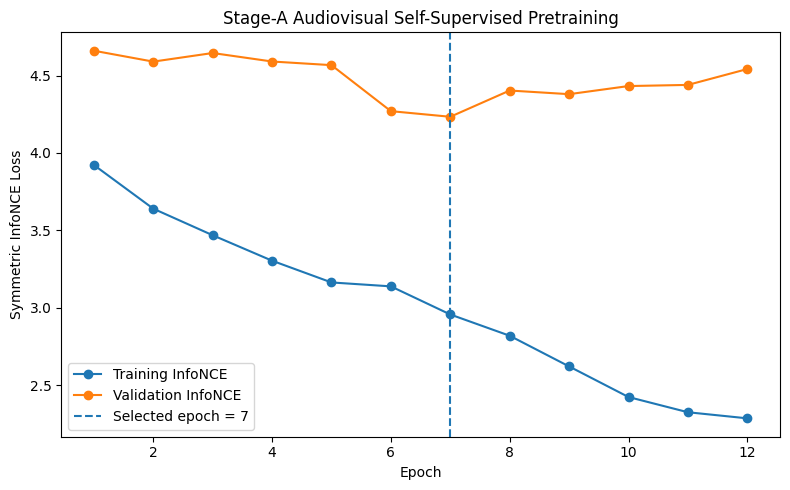

Saved: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/stageA_ssl_training_curve.png

[11] Saving Stage-A summary
--------------------------------------------------------------------------------------------------------------
Saved:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/04_Checkpoints/StageA_SSL/smdnet_v2_stageA_ssl_best.pt
/content/drive/MyDrive/SMDNet_V2_ScientificReports/04_Checkpoints/StageA_SSL/smdnet_v2_stageA_ssl_last.pt
/content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Tables/stageA_ssl_training_history.csv
/content/drive/MyDrive/SMDNet_V2_ScientificReports/07_Logs/stageA_ssl_training_summary.json
/content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/stageA_ssl_training_curve.png

CELL 21 COMPLETED — STAGE-A SSL PRETRAINING FINISHED
Epochs completed      : 12
Selected epoch        : 7
Initial val InfoNCE   : 4.362226
Selected val InfoNCE  : 4.233779
Selected V->A Top-1   : 2.78%
Selected A->V Top-1   : 5.56%
Best che

In [ ]:
# ============================================================
# CELL 21 — STAGE-A AUDIOVISUAL SSL PRETRAINING
# FINAL FROZEN SMD-NET V2
# ============================================================

import os
import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

print("=" * 110)
print("CELL 21 — STAGE-A AUDIOVISUAL SSL PRETRAINING")
print("=" * 110)

# ------------------------------------------------------------
# 1. Frozen training configuration
# ------------------------------------------------------------

SSL_SEED = 42

MAX_EPOCHS = 30
PATIENCE = 5

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

BETA1 = 0.9
BETA2 = 0.999

TEMPERATURE = 0.07

SSL_BATCH_SIZE = 32

MIN_DELTA = 0.0

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

assert DEVICE.type == "cuda", (
    "Stage-A training is intended for GPU."
)

print("\n[1] Frozen Stage-A configuration")
print("-" * 110)

print("Device            :", DEVICE)
print("GPU               :", torch.cuda.get_device_name(0))
print("Seed              :", SSL_SEED)
print("Training videos   :", len(ssl_train_dataset))
print("Validation videos :", len(ssl_val_dataset))
print("Physical batch    :", SSL_BATCH_SIZE)
print("Temperature       :", TEMPERATURE)
print("Optimizer         : AdamW")
print("Learning rate     :", LEARNING_RATE)
print("Weight decay      :", WEIGHT_DECAY)
print("Betas             :", (BETA1, BETA2))
print("Scheduler         : CosineAnnealingLR")
print("Maximum epochs    :", MAX_EPOCHS)
print("Early patience    :", PATIENCE)
print("Selection metric  : global validation symmetric InfoNCE")

assert len(ssl_train_dataset) == 331
assert len(ssl_val_dataset) == 72
assert SSL_BATCH_SIZE == 32

# ------------------------------------------------------------
# 2. Reproducibility
# ------------------------------------------------------------

random.seed(SSL_SEED)
np.random.seed(SSL_SEED)
torch.manual_seed(SSL_SEED)
torch.cuda.manual_seed_all(SSL_SEED)

# We prioritize reproducibility while keeping
# normal CUDA performance.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# ------------------------------------------------------------
# 3. Fresh FINAL model
# ------------------------------------------------------------

print("\n[2] Initializing fresh frozen architecture")
print("-" * 110)

# IMPORTANT:
# Create a fresh model so Cell-19 dummy forward passes
# cannot affect the training state.

ssl_model = SMDNetV2(
    pretrained_visual=True
).to(DEVICE)

print(
    "Model parameters:",
    f"{sum(p.numel() for p in ssl_model.parameters()):,}"
)

assert (
    sum(
        p.numel()
        for p in ssl_model.parameters()
    )
    ==
    28408065
)

print("Architecture parameter count: PASS")

# ------------------------------------------------------------
# 4. SSL-only trainable modules
# ------------------------------------------------------------

print("\n[3] Stage-A trainable modules")
print("-" * 110)

# Stage-A optimizes:
# visual encoder
# audio encoder
# visual SSL projection
# audio SSL projection
#
# Fusion classifier is NOT part of the SSL objective.

for p in ssl_model.parameters():
    p.requires_grad = False

for module in [
    ssl_model.visual_encoder,
    ssl_model.audio_encoder,
    ssl_model.visual_projection,
    ssl_model.audio_ssl_projection
]:
    for p in module.parameters():
        p.requires_grad = True

ssl_trainable_parameters = [
    p
    for p in ssl_model.parameters()
    if p.requires_grad
]

ssl_trainable_count = sum(
    p.numel()
    for p in ssl_trainable_parameters
)

fusion_trainable_count = sum(
    p.numel()
    for p in ssl_model.fusion_classifier.parameters()
    if p.requires_grad
)

print(
    "Stage-A trainable parameters:",
    f"{ssl_trainable_count:,}"
)

print(
    "Fusion trainable parameters:",
    fusion_trainable_count
)

assert fusion_trainable_count == 0

print("Fusion excluded from Stage-A optimization: PASS")

# ------------------------------------------------------------
# 5. Optimizer / scheduler / AMP
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    ssl_trainable_parameters,
    lr=LEARNING_RATE,
    betas=(BETA1, BETA2),
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS
)

# PyTorch 2.x AMP API.
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

print("\n[4] Optimizer")
print("-" * 110)

print(optimizer.__class__.__name__)
print("AMP enabled:", scaler.is_enabled())

# ------------------------------------------------------------
# 6. Rebuild train loader per epoch
# ------------------------------------------------------------

def build_ssl_train_loader(epoch):

    # Change temporal windows deterministically.
    ssl_train_dataset.set_epoch(epoch)

    # Also make shuffle order deterministic by epoch.
    generator = torch.Generator()

    generator.manual_seed(
        SSL_SEED + epoch
    )

    loader = torch.utils.data.DataLoader(
        ssl_train_dataset,
        batch_size=SSL_BATCH_SIZE,
        shuffle=True,
        drop_last=True,
        num_workers=2,
        pin_memory=True,
        persistent_workers=False,
        generator=generator
    )

    return loader


def build_ssl_val_loader():

    ssl_val_dataset.set_epoch(0)

    return torch.utils.data.DataLoader(
        ssl_val_dataset,
        batch_size=SSL_BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=2,
        pin_memory=True,
        persistent_workers=False
    )

ssl_val_loader_training = build_ssl_val_loader()

assert len(
    ssl_val_loader_training
) == 3

# ------------------------------------------------------------
# 7. Global validation objective
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_global_ssl(
    model,
    loader
):

    model.eval()

    all_visual = []
    all_audio = []

    for batch in loader:

        visual = batch[
            "visual"
        ].to(
            DEVICE,
            non_blocking=True
        )

        audio = batch[
            "audio"
        ].to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            v = model.encode_visual(
                visual
            )

            a = model.encode_audio(
                audio
            )

            zv, za = model.project_ssl(
                v,
                a
            )

        all_visual.append(
            zv.float().cpu()
        )

        all_audio.append(
            za.float().cpu()
        )

    visual_proj = torch.cat(
        all_visual,
        dim=0
    )

    audio_proj = torch.cat(
        all_audio,
        dim=0
    )

    assert visual_proj.shape == (
        72,
        128
    )

    assert audio_proj.shape == (
        72,
        128
    )

    # Compute global validation matrix.
    similarity = (
        visual_proj
        @
        audio_proj.T
    ) / TEMPERATURE

    targets = torch.arange(
        similarity.shape[0]
    )

    loss_v2a = F.cross_entropy(
        similarity,
        targets
    )

    loss_a2v = F.cross_entropy(
        similarity.T,
        targets
    )

    loss = (
        loss_v2a
        +
        loss_a2v
    ) / 2.0

    # Retrieval metrics are diagnostic only.
    v2a_pred = similarity.argmax(
        dim=1
    )

    a2v_pred = similarity.argmax(
        dim=0
    )

    v2a_top1 = (
        v2a_pred
        ==
        targets
    ).float().mean().item()

    a2v_top1 = (
        a2v_pred
        ==
        targets
    ).float().mean().item()

    mean_top1 = (
        v2a_top1
        +
        a2v_top1
    ) / 2.0

    return {

        "loss":
            float(
                loss.item()
            ),

        "loss_v2a":
            float(
                loss_v2a.item()
            ),

        "loss_a2v":
            float(
                loss_a2v.item()
            ),

        "v2a_top1":
            float(
                v2a_top1
            ),

        "a2v_top1":
            float(
                a2v_top1
            ),

        "mean_top1":
            float(
                mean_top1
            )
    }

# ------------------------------------------------------------
# 8. Checkpoint paths
# ------------------------------------------------------------

checkpoint_dir = (
    DIRS["checkpoints"]
    /
    "StageA_SSL"
)

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

best_checkpoint_path = (
    checkpoint_dir
    /
    "smdnet_v2_stageA_ssl_best.pt"
)

last_checkpoint_path = (
    checkpoint_dir
    /
    "smdnet_v2_stageA_ssl_last.pt"
)

history_csv = (
    DIRS["tables"]
    /
    "stageA_ssl_training_history.csv"
)

summary_json = (
    DIRS["logs"]
    /
    "stageA_ssl_training_summary.json"
)

curve_png = (
    DIRS["figures"]
    /
    "stageA_ssl_training_curve.png"
)

# ------------------------------------------------------------
# 9. Initial validation BEFORE SSL training
# ------------------------------------------------------------

print("\n[5] Baseline validation before SSL")
print("-" * 110)

initial_val = evaluate_global_ssl(
    ssl_model,
    ssl_val_loader_training
)

print(
    "Initial global val loss:",
    f"{initial_val['loss']:.6f}"
)

print(
    "Initial V->A Top-1:",
    f"{initial_val['v2a_top1']*100:.2f}%"
)

print(
    "Initial A->V Top-1:",
    f"{initial_val['a2v_top1']*100:.2f}%"
)

print(
    "Random retrieval reference:",
    f"{100/72:.2f}%"
)

# ------------------------------------------------------------
# 10. Training loop
# ------------------------------------------------------------

print("\n[6] Starting Stage-A SSL training")
print("-" * 110)

history = []

best_val_loss = float("inf")
best_epoch = None

epochs_without_improvement = 0

training_start_time = time.time()

for epoch in range(MAX_EPOCHS):

    epoch_number = epoch + 1

    epoch_start_time = time.time()

    ssl_train_loader_epoch = (
        build_ssl_train_loader(
            epoch
        )
    )

    ssl_model.train()

    # Keep frozen fusion classifier in eval mode.
    ssl_model.fusion_classifier.eval()

    running_loss = 0.0
    running_v2a = 0.0
    running_a2v = 0.0

    batches_seen = 0

    optimizer.zero_grad(
        set_to_none=True
    )

    for batch_idx, batch in enumerate(
        ssl_train_loader_epoch
    ):

        visual = batch[
            "visual"
        ].to(
            DEVICE,
            non_blocking=True
        )

        audio = batch[
            "audio"
        ].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            visual_embedding = (
                ssl_model.encode_visual(
                    visual
                )
            )

            audio_embedding = (
                ssl_model.encode_audio(
                    audio
                )
            )

            visual_projection, audio_projection = (
                ssl_model.project_ssl(
                    visual_embedding,
                    audio_embedding
                )
            )

            ssl_result = symmetric_av_infonce(
                visual_projection,
                audio_projection,
                temperature=TEMPERATURE
            )

            loss = ssl_result[
                "loss"
            ]

        if not torch.isfinite(
            loss
        ):

            raise RuntimeError(
                f"Non-finite SSL loss at "
                f"epoch {epoch_number}, "
                f"batch {batch_idx}."
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        running_loss += float(
            loss.detach().cpu()
        )

        running_v2a += float(
            ssl_result[
                "loss_v2a"
            ]
            .detach()
            .cpu()
        )

        running_a2v += float(
            ssl_result[
                "loss_a2v"
            ]
            .detach()
            .cpu()
        )

        batches_seen += 1

    assert batches_seen == 10

    train_loss = (
        running_loss
        /
        batches_seen
    )

    train_v2a = (
        running_v2a
        /
        batches_seen
    )

    train_a2v = (
        running_a2v
        /
        batches_seen
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_metrics = evaluate_global_ssl(
        ssl_model,
        ssl_val_loader_training
    )

    current_lr = optimizer.param_groups[
        0
    ][
        "lr"
    ]

    epoch_seconds = (
        time.time()
        -
        epoch_start_time
    )

    improved = (
        val_metrics[
            "loss"
        ]
        <
        best_val_loss
        -
        MIN_DELTA
    )

    if improved:

        best_val_loss = (
            val_metrics[
                "loss"
            ]
        )

        best_epoch = epoch_number

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch":
                    epoch_number,

                "model_state_dict":
                    ssl_model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "best_val_loss":
                    best_val_loss,

                "architecture_sha256":
                    ARCH_CONFIG[
                        "architecture_config_sha256"
                    ],

                "temperature":
                    TEMPERATURE,

                "ssl_seed":
                    SSL_SEED,

                "training_videos":
                    len(
                        ssl_train_dataset
                    ),

                "validation_videos":
                    len(
                        ssl_val_dataset
                    )
            },
            best_checkpoint_path
        )

    else:

        epochs_without_improvement += 1

    history.append(
        {
            "epoch":
                epoch_number,

            "learning_rate":
                current_lr,

            "train_loss":
                train_loss,

            "train_loss_v2a":
                train_v2a,

            "train_loss_a2v":
                train_a2v,

            "val_loss":
                val_metrics[
                    "loss"
                ],

            "val_loss_v2a":
                val_metrics[
                    "loss_v2a"
                ],

            "val_loss_a2v":
                val_metrics[
                    "loss_a2v"
                ],

            "val_v2a_top1":
                val_metrics[
                    "v2a_top1"
                ],

            "val_a2v_top1":
                val_metrics[
                    "a2v_top1"
                ],

            "val_mean_top1":
                val_metrics[
                    "mean_top1"
                ],

            "improved":
                improved,

            "epochs_without_improvement":
                epochs_without_improvement,

            "epoch_seconds":
                epoch_seconds
        }
    )

    # Save history after every epoch.
    pd.DataFrame(
        history
    ).to_csv(
        history_csv,
        index=False
    )

    # Save recoverable last checkpoint.
    torch.save(
        {
            "epoch":
                epoch_number,

            "model_state_dict":
                ssl_model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_val_loss":
                best_val_loss,

            "best_epoch":
                best_epoch,

            "epochs_without_improvement":
                epochs_without_improvement,

            "architecture_sha256":
                ARCH_CONFIG[
                    "architecture_config_sha256"
                ]
        },
        last_checkpoint_path
    )

    marker = (
        "*"
        if improved
        else " "
    )

    print(
        f"{marker} "
        f"Epoch {epoch_number:02d}/{MAX_EPOCHS} | "
        f"train={train_loss:.4f} | "
        f"val={val_metrics['loss']:.4f} | "
        f"V2A={val_metrics['v2a_top1']*100:5.2f}% | "
        f"A2V={val_metrics['a2v_top1']*100:5.2f}% | "
        f"lr={current_lr:.2e} | "
        f"{epoch_seconds:.1f}s"
    )

    # Step scheduler AFTER the epoch.
    scheduler.step()

    if (
        epochs_without_improvement
        >=
        PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        print(
            "No validation-loss improvement "
            f"for {PATIENCE} consecutive epochs."
        )

        break

# ------------------------------------------------------------
# 11. Training completion
# ------------------------------------------------------------

total_training_seconds = (
    time.time()
    -
    training_start_time
)

history_df = pd.DataFrame(
    history
)

epochs_completed = len(
    history_df
)

print("\n[7] Training completed")
print("-" * 110)

print(
    "Epochs completed:",
    epochs_completed
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best validation loss:",
    f"{best_val_loss:.6f}"
)

print(
    "Total training time:",
    f"{total_training_seconds/60:.2f} min"
)

assert best_checkpoint_path.exists()
assert last_checkpoint_path.exists()

# ------------------------------------------------------------
# 12. Reload BEST checkpoint
# ------------------------------------------------------------

print("\n[8] Reloading best checkpoint")
print("-" * 110)

best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

assert (
    best_checkpoint[
        "architecture_sha256"
    ]
    ==
    ARCH_CONFIG[
        "architecture_config_sha256"
    ]
)

ssl_model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

print(
    "Loaded best epoch:",
    best_checkpoint[
        "epoch"
    ]
)

print(
    "Architecture fingerprint: PASS"
)

# ------------------------------------------------------------
# 13. Final global validation
# ------------------------------------------------------------

print("\n[9] Final validation of selected checkpoint")
print("-" * 110)

final_val = evaluate_global_ssl(
    ssl_model,
    ssl_val_loader_training
)

print(
    "Selected val loss:",
    f"{final_val['loss']:.6f}"
)

print(
    "V->A Top-1:",
    f"{final_val['v2a_top1']*100:.2f}%"
)

print(
    "A->V Top-1:",
    f"{final_val['a2v_top1']*100:.2f}%"
)

print(
    "Mean Top-1:",
    f"{final_val['mean_top1']*100:.2f}%"
)

assert abs(
    final_val[
        "loss"
    ]
    -
    best_val_loss
) < 1e-4

print(
    "Best-checkpoint validation: PASS"
)

# ------------------------------------------------------------
# 14. Training curve
# ------------------------------------------------------------

print("\n[10] Generating training curve")
print("-" * 110)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df[
        "epoch"
    ],
    history_df[
        "train_loss"
    ],
    marker="o",
    label="Training InfoNCE"
)

plt.plot(
    history_df[
        "epoch"
    ],
    history_df[
        "val_loss"
    ],
    marker="o",
    label="Validation InfoNCE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Selected epoch = {best_epoch}"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Symmetric InfoNCE Loss"
)

plt.title(
    "Stage-A Audiovisual Self-Supervised Pretraining"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    curve_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    curve_png
)

# ------------------------------------------------------------
# 15. Save final Stage-A summary
# ------------------------------------------------------------

print("\n[11] Saving Stage-A summary")
print("-" * 110)

best_row = (
    history_df.loc[
        history_df[
            "epoch"
        ]
        ==
        best_epoch
    ]
    .iloc[0]
)

summary = {

    "status":
        "COMPLETED",

    "stage":
        "Stage-A audiovisual SSL pretraining",

    "seed":
        SSL_SEED,

    "architecture_sha256":
        ARCH_CONFIG[
            "architecture_config_sha256"
        ],

    "training_cohort":
        {
            "videos":
                331,

            "condition":
                "RealVideo-RealAudio",

            "source_split":
                "train"
        },

    "validation_cohort":
        {
            "videos":
                72,

            "condition":
                "RealVideo-RealAudio",

            "source_split":
                "validation"
        },

    "optimization":
        {
            "optimizer":
                "AdamW",

            "learning_rate":
                LEARNING_RATE,

            "weight_decay":
                WEIGHT_DECAY,

            "betas":
                [
                    BETA1,
                    BETA2
                ],

            "scheduler":
                "CosineAnnealingLR",

            "max_epochs":
                MAX_EPOCHS,

            "early_stopping_patience":
                PATIENCE,

            "physical_batch_size":
                SSL_BATCH_SIZE,

            "temperature":
                TEMPERATURE,

            "amp":
                True
        },

    "initial_validation":
        initial_val,

    "epochs_completed":
        int(
            epochs_completed
        ),

    "best_epoch":
        int(
            best_epoch
        ),

    "best_validation_loss":
        float(
            best_val_loss
        ),

    "selected_checkpoint_validation":
        final_val,

    "total_training_seconds":
        float(
            total_training_seconds
        ),

    "best_checkpoint":
        str(
            best_checkpoint_path
        ),

    "last_checkpoint":
        str(
            last_checkpoint_path
        ),

    "history_csv":
        str(
            history_csv
        ),

    "training_curve":
        str(
            curve_png
        )
}

with open(
    summary_json,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

print(
    "Saved:"
)

print(
    best_checkpoint_path
)

print(
    last_checkpoint_path
)

print(
    history_csv
)

print(
    summary_json
)

print(
    curve_png
)

# ------------------------------------------------------------
# 16. GPU cleanup
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 17. Final status
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CELL 21 COMPLETED — STAGE-A SSL PRETRAINING FINISHED")
print("=" * 110)

print(
    "Epochs completed      :",
    epochs_completed
)

print(
    "Selected epoch        :",
    best_epoch
)

print(
    "Initial val InfoNCE   :",
    f"{initial_val['loss']:.6f}"
)

print(
    "Selected val InfoNCE  :",
    f"{final_val['loss']:.6f}"
)

print(
    "Selected V->A Top-1   :",
    f"{final_val['v2a_top1']*100:.2f}%"
)

print(
    "Selected A->V Top-1   :",
    f"{final_val['a2v_top1']*100:.2f}%"
)

print(
    "Best checkpoint       :",
    best_checkpoint_path
)

print(
    "\nStage-A checkpoint is now frozen."
)

print(
    "NEXT: supervised SMD-Net training on the "
    "15,065-video training split."
)

print("=" * 110)

In [ ]:
# ============================================================
# CELL 22 — SUPERVISED TRAINING SAMPLER FREEZE
# Controlled balanced epochs for SMD-Net V2
# ============================================================

import json
import math
import numpy as np
import pandas as pd
from collections import Counter, defaultdict
from pathlib import Path

print("=" * 110)
print("CELL 22 — SUPERVISED TRAINING SAMPLER FREEZE")
print("=" * 110)

# ------------------------------------------------------------
# 1. Frozen supervised batch policy
# ------------------------------------------------------------

SUP_SEED = 42

SUP_BATCH_SIZE = 8

AUTH_PER_BATCH = 4
FAKE_PER_BATCH = 4

# Instead of 1,884 batches/epoch, use one genuine
# coverage cycle as the definition of a supervised epoch.
#
# 331 genuine videos / 4 genuine per batch
# -> ceil = 83 batches.
#
# This gives every genuine video approximately one
# exposure per epoch instead of ~22.8 exposures.

BATCHES_PER_EPOCH = math.ceil(
    331 / AUTH_PER_BATCH
)

SAMPLES_PER_EPOCH = (
    BATCHES_PER_EPOCH
    *
    SUP_BATCH_SIZE
)

print("\n[1] Frozen supervised epoch definition")
print("-" * 110)

print("Batch size          :", SUP_BATCH_SIZE)
print("Authentic / batch   :", AUTH_PER_BATCH)
print("Manipulated / batch :", FAKE_PER_BATCH)
print("Batches / epoch     :", BATCHES_PER_EPOCH)
print("Samples / epoch     :", SAMPLES_PER_EPOCH)
print(
    "Authentic draws     :",
    BATCHES_PER_EPOCH * AUTH_PER_BATCH
)
print(
    "Manipulated draws   :",
    BATCHES_PER_EPOCH * FAKE_PER_BATCH
)

assert SUP_BATCH_SIZE == 8
assert AUTH_PER_BATCH == 4
assert FAKE_PER_BATCH == 4
assert BATCHES_PER_EPOCH == 83
assert SAMPLES_PER_EPOCH == 664

# ------------------------------------------------------------
# 2. Identify training pools
# ------------------------------------------------------------

print("\n[2] Training pools")
print("-" * 110)

auth_mask = (
    train_df["binary_label"]
    .astype(int)
    .eq(0)
)

fake_mask = (
    train_df["binary_label"]
    .astype(int)
    .eq(1)
)

auth_indices = np.flatnonzero(
    auth_mask.to_numpy()
)

fake_indices = np.flatnonzero(
    fake_mask.to_numpy()
)

print(
    "Authentic pool:",
    len(auth_indices)
)

print(
    "Manipulated pool:",
    len(fake_indices)
)

assert len(auth_indices) == 331
assert len(fake_indices) == 14734

fake_condition_indices = {}

for condition in [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio"
]:

    idx = np.flatnonzero(
        (
            fake_mask
            &
            train_df[
                category_col
            ].eq(condition)
        ).to_numpy()
    )

    fake_condition_indices[
        condition
    ] = idx

    print(
        f"{condition:25s}:",
        len(idx)
    )

assert len(
    fake_condition_indices[
        "FakeVideo-FakeAudio"
    ]
) == 7597

assert len(
    fake_condition_indices[
        "FakeVideo-RealAudio"
    ]
) == 6788

assert len(
    fake_condition_indices[
        "RealVideo-FakeAudio"
    ]
) == 349

# ------------------------------------------------------------
# 3. Controlled hierarchical epoch generator
# ------------------------------------------------------------

FAKE_CONDITIONS = [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio"
]


def generate_supervised_epoch(
    epoch,
    batches_per_epoch=BATCHES_PER_EPOCH
):

    rng = np.random.default_rng(
        SUP_SEED + epoch * 1009
    )

    # -------------------------
    # Authentic schedule
    # -------------------------

    auth_perm = rng.permutation(
        auth_indices
    ).tolist()

    # Need 332 authentic draws for 83 batches.
    auth_needed = (
        batches_per_epoch
        *
        AUTH_PER_BATCH
    )

    if auth_needed > len(auth_perm):

        extra_needed = (
            auth_needed
            -
            len(auth_perm)
        )

        extra = rng.choice(
            auth_indices,
            size=extra_needed,
            replace=False
        ).tolist()

        auth_schedule = (
            auth_perm
            +
            extra
        )

    else:

        auth_schedule = (
            auth_perm[
                :auth_needed
            ]
        )

    # -------------------------
    # Fake schedule
    # -------------------------

    fake_schedule = []

    # Every batch receives one sample
    # from EACH of the 3 fake conditions.
    #
    # The fourth fake slot rotates:
    # FV-FA -> FV-RA -> RV-FA -> repeat.
    #
    # Thus no fake condition systematically
    # receives the extra slot.

    for batch_idx in range(
        batches_per_epoch
    ):

        chosen = []

        # Mandatory one per condition.
        for condition in FAKE_CONDITIONS:

            pool = (
                fake_condition_indices[
                    condition
                ]
            )

            chosen.append(
                int(
                    rng.choice(
                        pool
                    )
                )
            )

        # Rotating fourth slot.
        extra_condition = (
            FAKE_CONDITIONS[
                batch_idx
                %
                len(
                    FAKE_CONDITIONS
                )
            ]
        )

        chosen.append(
            int(
                rng.choice(
                    fake_condition_indices[
                        extra_condition
                    ]
                )
            )
        )

        rng.shuffle(
            chosen
        )

        fake_schedule.extend(
            chosen
        )

    # -------------------------
    # Build batches
    # -------------------------

    epoch_batches = []

    auth_pointer = 0
    fake_pointer = 0

    for batch_idx in range(
        batches_per_epoch
    ):

        a = auth_schedule[
            auth_pointer:
            auth_pointer
            +
            AUTH_PER_BATCH
        ]

        f = fake_schedule[
            fake_pointer:
            fake_pointer
            +
            FAKE_PER_BATCH
        ]

        auth_pointer += AUTH_PER_BATCH
        fake_pointer += FAKE_PER_BATCH

        batch = (
            list(a)
            +
            list(f)
        )

        rng.shuffle(
            batch
        )

        epoch_batches.append(
            batch
        )

    return epoch_batches

# ------------------------------------------------------------
# 4. Audit epoch 0
# ------------------------------------------------------------

print("\n[3] Epoch-0 sampler audit")
print("-" * 110)

epoch0_batches = (
    generate_supervised_epoch(
        epoch=0
    )
)

assert len(
    epoch0_batches
) == 83

flat_epoch0 = [
    idx
    for batch in epoch0_batches
    for idx in batch
]

assert len(
    flat_epoch0
) == 664

label_counts = Counter(
    int(
        train_df.iloc[idx][
            "binary_label"
        ]
    )
    for idx in flat_epoch0
)

condition_counts = Counter(
    str(
        train_df.iloc[idx][
            category_col
        ]
    )
    for idx in flat_epoch0
)

print(
    "Binary draws:"
)

print(
    dict(
        label_counts
    )
)

print(
    "\nCondition draws:"
)

for k, v in sorted(
    condition_counts.items()
):
    print(
        f"{k:25s}: {v}"
    )

assert label_counts[0] == 332
assert label_counts[1] == 332

# Every fake condition must appear
# in every batch.
bad_batches = 0

for batch in epoch0_batches:

    batch_df = train_df.iloc[
        batch
    ]

    fake_batch = batch_df[
        batch_df[
            "binary_label"
        ].astype(int).eq(1)
    ]

    fake_conditions = set(
        fake_batch[
            category_col
        ].astype(str)
    )

    if not set(
        FAKE_CONDITIONS
    ).issubset(
        fake_conditions
    ):
        bad_batches += 1

print(
    "\nBatches missing a fake condition:",
    bad_batches
)

assert bad_batches == 0

# ------------------------------------------------------------
# 5. Genuine exposure audit
# ------------------------------------------------------------

print("\n[4] Authentic exposure audit")
print("-" * 110)

auth_draws = [
    idx
    for idx in flat_epoch0
    if int(
        train_df.iloc[idx][
            "binary_label"
        ]
    ) == 0
]

auth_counter = Counter(
    auth_draws
)

print(
    "Authentic draws:",
    len(auth_draws)
)

print(
    "Unique authentic videos:",
    len(auth_counter)
)

print(
    "Minimum exposures/video:",
    min(
        auth_counter.values()
    )
)

print(
    "Maximum exposures/video:",
    max(
        auth_counter.values()
    )
)

print(
    "Mean exposures/video:",
    np.mean(
        list(
            auth_counter.values()
        )
    )
)

assert len(auth_counter) == 331
assert max(
    auth_counter.values()
) <= 2

# ------------------------------------------------------------
# 6. Manipulated exposure audit
# ------------------------------------------------------------

print("\n[5] Manipulated exposure audit")
print("-" * 110)

fake_draws = [
    idx
    for idx in flat_epoch0
    if int(
        train_df.iloc[idx][
            "binary_label"
        ]
    ) == 1
]

fake_counter = Counter(
    fake_draws
)

print(
    "Manipulated draws:",
    len(fake_draws)
)

print(
    "Unique manipulated videos:",
    len(fake_counter)
)

print(
    "Total manipulated pool:",
    len(fake_indices)
)

print(
    "Epoch manipulated coverage:",
    f"{100*len(fake_counter)/len(fake_indices):.2f}%"
)

# ------------------------------------------------------------
# 7. Multi-epoch coverage
# ------------------------------------------------------------

print("\n[6] Multi-epoch manipulated coverage")
print("-" * 110)

coverage_rows = []

union_fake = set()

for epoch in range(20):

    batches = (
        generate_supervised_epoch(
            epoch
        )
    )

    flat = [
        idx
        for batch in batches
        for idx in batch
    ]

    epoch_fake = {
        idx
        for idx in flat
        if int(
            train_df.iloc[idx][
                "binary_label"
            ]
        ) == 1
    }

    union_fake.update(
        epoch_fake
    )

    coverage_rows.append(
        {
            "epoch":
                epoch + 1,

            "unique_fake_this_epoch":
                len(
                    epoch_fake
                ),

            "cumulative_unique_fake":
                len(
                    union_fake
                ),

            "cumulative_fake_coverage_pct":
                100
                *
                len(
                    union_fake
                )
                /
                len(
                    fake_indices
                )
        }
    )

coverage_df = pd.DataFrame(
    coverage_rows
)

print(
    coverage_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ------------------------------------------------------------
# 8. Reproducibility
# ------------------------------------------------------------

print("\n[7] Reproducibility")
print("-" * 110)

epoch0_again = (
    generate_supervised_epoch(
        epoch=0
    )
)

epoch1 = (
    generate_supervised_epoch(
        epoch=1
    )
)

same_epoch_identical = (
    epoch0_batches
    ==
    epoch0_again
)

different_epoch_changes = (
    epoch0_batches
    !=
    epoch1
)

print(
    "Same seed/epoch identical:",
    same_epoch_identical
)

print(
    "Different epoch changes draws:",
    different_epoch_changes
)

assert same_epoch_identical
assert different_epoch_changes

# ------------------------------------------------------------
# 9. Compare against old sampler
# ------------------------------------------------------------

print("\n[8] Efficiency comparison")
print("-" * 110)

OLD_BATCHES = 1884
OLD_DRAWS = 15072

print(
    "Previous batches/epoch:",
    OLD_BATCHES
)

print(
    "New batches/epoch     :",
    BATCHES_PER_EPOCH
)

print(
    "Previous draws/epoch  :",
    OLD_DRAWS
)

print(
    "New draws/epoch       :",
    SAMPLES_PER_EPOCH
)

print(
    "Batch-count reduction :",
    f"{100*(1-BATCHES_PER_EPOCH/OLD_BATCHES):.2f}%"
)

print(
    "Draw-count reduction  :",
    f"{100*(1-SAMPLES_PER_EPOCH/OLD_DRAWS):.2f}%"
)

# ------------------------------------------------------------
# 10. Freeze protocol
# ------------------------------------------------------------

print("\n[9] Saving frozen supervised sampler protocol")
print("-" * 110)

sampler_protocol = {

    "status":
        "FROZEN_BEFORE_SUPERVISED_TRAINING",

    "seed":
        SUP_SEED,

    "batch_size":
        SUP_BATCH_SIZE,

    "authentic_per_batch":
        AUTH_PER_BATCH,

    "manipulated_per_batch":
        FAKE_PER_BATCH,

    "batches_per_epoch":
        BATCHES_PER_EPOCH,

    "samples_per_epoch":
        SAMPLES_PER_EPOCH,

    "epoch_definition":
        (
            "One approximately complete authentic-video "
            "coverage cycle per supervised epoch."
        ),

    "authentic_pool_size":
        int(
            len(
                auth_indices
            )
        ),

    "manipulated_pool_size":
        int(
            len(
                fake_indices
            )
        ),

    "fake_conditions":
        {
            condition:
                int(
                    len(
                        fake_condition_indices[
                            condition
                        ]
                    )
                )
            for condition in FAKE_CONDITIONS
        },

    "fake_batch_policy":
        (
            "Each batch contains one manipulated sample "
            "from each of the three manipulated conditions; "
            "the fourth manipulated slot rotates across "
            "conditions."
        ),

    "validation_sampling":
        "natural distribution",

    "test_sampling":
        "natural distribution",

    "rationale":
        (
            "The earlier full-length balanced epoch would "
            "repeat the 331 authentic training videos about "
            "22.8 times per epoch. The revised epoch definition "
            "exposes each authentic video approximately once "
            "per epoch, reduces overfitting pressure, and "
            "substantially reduces computational cost while "
            "preserving 4/4 binary balance and representation "
            "of all manipulated conditions in every batch."
        )
}

sampler_json = (
    DIRS["code"]
    /
    "supervised_sampler_protocol_final_v2.json"
)

coverage_csv = (
    DIRS["tables"]
    /
    "supervised_sampler_fake_coverage_audit.csv"
)

with open(
    sampler_json,
    "w"
) as f:

    json.dump(
        sampler_protocol,
        f,
        indent=2
    )

coverage_df.to_csv(
    coverage_csv,
    index=False
)

print(
    "Saved:"
)

print(
    sampler_json
)

print(
    coverage_csv
)

print("\n" + "=" * 110)
print("CELL 22 COMPLETED — SUPERVISED SAMPLER FROZEN")
print("=" * 110)

print(
    "Batch size       : 8"
)

print(
    "Batch composition: 4 authentic + 4 manipulated"
)

print(
    "Batches/epoch    :",
    BATCHES_PER_EPOCH
)

print(
    "Samples/epoch    :",
    SAMPLES_PER_EPOCH
)

print(
    "Authentic/video  : approximately 1 exposure/epoch"
)

print(
    "All fake types   : represented in every batch"
)

print(
    "\nNEXT: supervised full SMD-Net training "
    "initialized from the frozen Stage-A checkpoint."
)

print("=" * 110)

CELL 22 — SUPERVISED TRAINING SAMPLER FREEZE

[1] Frozen supervised epoch definition
--------------------------------------------------------------------------------------------------------------
Batch size          : 8
Authentic / batch   : 4
Manipulated / batch : 4
Batches / epoch     : 83
Samples / epoch     : 664
Authentic draws     : 332
Manipulated draws   : 332

[2] Training pools
--------------------------------------------------------------------------------------------------------------
Authentic pool: 331
Manipulated pool: 14734
FakeVideo-FakeAudio      : 7597
FakeVideo-RealAudio      : 6788
RealVideo-FakeAudio      : 349

[3] Epoch-0 sampler audit
--------------------------------------------------------------------------------------------------------------
Binary draws:
{1: 332, 0: 332}

Condition draws:
FakeVideo-FakeAudio      : 111
FakeVideo-RealAudio      : 111
RealVideo-FakeAudio      : 110
RealVideo-RealAudio      : 332

Batches missing a fake condition: 0

[4] Authen

In [ ]:
# ============================================================
# CELL 22B — FINAL COVERAGE-AWARE SUPERVISED SAMPLER
# Same computational budget; better manipulated-data coverage
# ============================================================

import json
import math
import numpy as np
import pandas as pd
from collections import Counter

print("=" * 110)
print("CELL 22B — COVERAGE-AWARE SUPERVISED SAMPLER CORRECTION")
print("=" * 110)

# ------------------------------------------------------------
# 1. Frozen constants from Cell 22
# ------------------------------------------------------------

SUP_SEED = 42

SUP_BATCH_SIZE = 8
AUTH_PER_BATCH = 4
FAKE_PER_BATCH = 4

BATCHES_PER_EPOCH = 83
SAMPLES_PER_EPOCH = 664

FAKE_CONDITIONS = [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio"
]

assert len(auth_indices) == 331
assert len(fake_indices) == 14734

print("\n[1] Computational budget retained")
print("-" * 110)

print("Batch size       :", SUP_BATCH_SIZE)
print("Batches/epoch    :", BATCHES_PER_EPOCH)
print("Samples/epoch    :", SAMPLES_PER_EPOCH)
print("Authentic/batch  :", AUTH_PER_BATCH)
print("Manipulated/batch:", FAKE_PER_BATCH)

# ------------------------------------------------------------
# 2. Coverage-aware cyclic pool
# ------------------------------------------------------------

class CyclicConditionPool:
    """
    Deterministically traverses a condition-specific pool
    without replacement before reshuffling/recycling.
    """

    def __init__(
        self,
        indices,
        seed
    ):

        self.indices = np.asarray(
            indices,
            dtype=np.int64
        )

        self.seed = int(seed)

        self.cycle = 0
        self.pointer = 0

        self.order = None

        self._reshuffle()

    def _reshuffle(self):

        rng = np.random.default_rng(
            self.seed
            +
            self.cycle * 1_000_003
        )

        self.order = rng.permutation(
            self.indices
        )

        self.pointer = 0
        self.cycle += 1

    def draw(self, n=1):

        selected = []

        while len(selected) < n:

            remaining = (
                len(self.order)
                -
                self.pointer
            )

            need = (
                n
                -
                len(selected)
            )

            take = min(
                remaining,
                need
            )

            selected.extend(
                self.order[
                    self.pointer:
                    self.pointer + take
                ].tolist()
            )

            self.pointer += take

            if self.pointer >= len(
                self.order
            ):
                self._reshuffle()

        return [
            int(x)
            for x in selected
        ]

# ------------------------------------------------------------
# 3. Stateful sampler factory
# ------------------------------------------------------------

def create_sampler_state():

    state = {}

    # Independent deterministic stream
    # for each manipulated condition.
    for i, condition in enumerate(
        FAKE_CONDITIONS
    ):

        state[
            condition
        ] = CyclicConditionPool(
            fake_condition_indices[
                condition
            ],
            seed=(
                SUP_SEED
                +
                10_000
                *
                (i + 1)
            )
        )

    return state

# ------------------------------------------------------------
# 4. Coverage-aware epoch generator
# ------------------------------------------------------------

def generate_coverage_aware_epoch(
    epoch,
    sampler_state
):

    epoch_rng = np.random.default_rng(
        SUP_SEED
        +
        epoch * 1009
    )

    # --------------------------------------------------------
    # Authentic schedule
    # --------------------------------------------------------

    # All 331 authentic videos appear once.
    auth_perm = epoch_rng.permutation(
        auth_indices
    ).tolist()

    # Need exactly 332 authentic draws.
    # One deterministic additional genuine video.
    extra_auth = int(
        epoch_rng.choice(
            auth_indices
        )
    )

    auth_schedule = (
        auth_perm
        +
        [extra_auth]
    )

    assert len(
        auth_schedule
    ) == 332

    # --------------------------------------------------------
    # Manipulated schedule
    # --------------------------------------------------------

    fake_schedule = []

    for batch_idx in range(
        BATCHES_PER_EPOCH
    ):

        batch_fake = []

        # Mandatory one from each condition.
        for condition in FAKE_CONDITIONS:

            batch_fake.extend(
                sampler_state[
                    condition
                ].draw(1)
            )

        # Fourth fake slot rotates across
        # the three conditions.
        extra_condition = (
            FAKE_CONDITIONS[
                batch_idx
                %
                len(
                    FAKE_CONDITIONS
                )
            ]
        )

        batch_fake.extend(
            sampler_state[
                extra_condition
            ].draw(1)
        )

        epoch_rng.shuffle(
            batch_fake
        )

        fake_schedule.extend(
            batch_fake
        )

    assert len(
        fake_schedule
    ) == 332

    # --------------------------------------------------------
    # Construct 83 balanced batches
    # --------------------------------------------------------

    batches = []

    a_ptr = 0
    f_ptr = 0

    for batch_idx in range(
        BATCHES_PER_EPOCH
    ):

        batch = (
            auth_schedule[
                a_ptr:
                a_ptr + 4
            ]
            +
            fake_schedule[
                f_ptr:
                f_ptr + 4
            ]
        )

        a_ptr += 4
        f_ptr += 4

        epoch_rng.shuffle(
            batch
        )

        batches.append(
            batch
        )

    return batches

# ------------------------------------------------------------
# 5. Simulate 30 epochs BEFORE training
# ------------------------------------------------------------

print("\n[2] Thirty-epoch coverage simulation")
print("-" * 110)

audit_state = create_sampler_state()

coverage_rows = []

cumulative_fake = set()

cumulative_by_condition = {
    condition: set()
    for condition in FAKE_CONDITIONS
}

epoch_batches_audit = {}

for epoch in range(30):

    batches = (
        generate_coverage_aware_epoch(
            epoch,
            audit_state
        )
    )

    epoch_batches_audit[
        epoch
    ] = batches

    flat = [
        idx
        for batch in batches
        for idx in batch
    ]

    # -------------------------
    # Batch integrity
    # -------------------------

    for batch in batches:

        labels = [
            int(
                train_df.iloc[idx][
                    "binary_label"
                ]
            )
            for idx in batch
        ]

        assert labels.count(0) == 4
        assert labels.count(1) == 4

        fake_conditions_batch = {
            str(
                train_df.iloc[idx][
                    category_col
                ]
            )
            for idx in batch
            if int(
                train_df.iloc[idx][
                    "binary_label"
                ]
            ) == 1
        }

        assert set(
            FAKE_CONDITIONS
        ).issubset(
            fake_conditions_batch
        )

    epoch_fake = [
        idx
        for idx in flat
        if int(
            train_df.iloc[idx][
                "binary_label"
            ]
        ) == 1
    ]

    cumulative_fake.update(
        epoch_fake
    )

    for idx in epoch_fake:

        condition = str(
            train_df.iloc[idx][
                category_col
            ]
        )

        cumulative_by_condition[
            condition
        ].add(
            idx
        )

    row = {

        "epoch":
            epoch + 1,

        "fake_draws_this_epoch":
            len(
                epoch_fake
            ),

        "unique_fake_this_epoch":
            len(
                set(
                    epoch_fake
                )
            ),

        "cumulative_unique_fake":
            len(
                cumulative_fake
            ),

        "cumulative_fake_coverage_pct":
            (
                100
                *
                len(
                    cumulative_fake
                )
                /
                len(
                    fake_indices
                )
            )
    }

    for condition in FAKE_CONDITIONS:

        pool_size = len(
            fake_condition_indices[
                condition
            ]
        )

        unique_seen = len(
            cumulative_by_condition[
                condition
            ]
        )

        row[
            f"{condition}_unique"
        ] = unique_seen

        row[
            f"{condition}_coverage_pct"
        ] = (
            100
            *
            unique_seen
            /
            pool_size
        )

    coverage_rows.append(
        row
    )

coverage_df_22b = pd.DataFrame(
    coverage_rows
)

display_cols = [
    "epoch",
    "unique_fake_this_epoch",
    "cumulative_unique_fake",
    "cumulative_fake_coverage_pct"
]

print(
    coverage_df_22b[
        display_cols
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ------------------------------------------------------------
# 6. Important milestone coverage
# ------------------------------------------------------------

print("\n[3] Coverage milestones")
print("-" * 110)

for milestone in [
    5,
    10,
    15,
    20,
    25,
    30
]:

    row = coverage_df_22b.iloc[
        milestone - 1
    ]

    print(
        f"Epoch {milestone:02d}: "
        f"{int(row['cumulative_unique_fake']):,}/"
        f"{len(fake_indices):,} unique manipulated "
        f"({row['cumulative_fake_coverage_pct']:.2f}%)"
    )

# ------------------------------------------------------------
# 7. Per-condition coverage after 30 epochs
# ------------------------------------------------------------

print("\n[4] Per-condition coverage after 30 epochs")
print("-" * 110)

last_row = coverage_df_22b.iloc[
    -1
]

for condition in FAKE_CONDITIONS:

    print(
        f"{condition:25s}: "
        f"{int(last_row[f'{condition}_unique']):,}/"
        f"{len(fake_condition_indices[condition]):,} "
        f"("
        f"{last_row[f'{condition}_coverage_pct']:.2f}%"
        f")"
    )

# ------------------------------------------------------------
# 8. Authentic audit
# ------------------------------------------------------------

print("\n[5] Authentic coverage audit")
print("-" * 110)

# Check several epochs.
for epoch in [
    0,
    1,
    5,
    10,
    20,
    29
]:

    flat = [
        idx
        for batch in epoch_batches_audit[
            epoch
        ]
        for idx in batch
    ]

    authentic_draws = [
        idx
        for idx in flat
        if int(
            train_df.iloc[idx][
                "binary_label"
            ]
        ) == 0
    ]

    counter = Counter(
        authentic_draws
    )

    print(
        f"Epoch {epoch+1:02d}: "
        f"draws={len(authentic_draws)}, "
        f"unique={len(counter)}, "
        f"max exposure={max(counter.values())}"
    )

    assert len(
        authentic_draws
    ) == 332

    assert len(
        counter
    ) == 331

    assert max(
        counter.values()
    ) <= 2

print(
    "Authentic coverage: PASS"
)

# ------------------------------------------------------------
# 9. Reproducibility from fresh state
# ------------------------------------------------------------

print("\n[6] Reproducibility")
print("-" * 110)

state_a = create_sampler_state()
state_b = create_sampler_state()

identical = True

for epoch in range(10):

    a = generate_coverage_aware_epoch(
        epoch,
        state_a
    )

    b = generate_coverage_aware_epoch(
        epoch,
        state_b
    )

    if a != b:
        identical = False
        break

print(
    "Fresh deterministic states identical:",
    identical
)

assert identical

print(
    "Coverage-aware reproducibility: PASS"
)

# ------------------------------------------------------------
# 10. Create PRODUCTION state
# ------------------------------------------------------------

print("\n[7] Creating production sampler state")
print("-" * 110)

# IMPORTANT:
# Training must use this state sequentially.
# Do not recreate it inside each epoch.

supervised_sampler_state = (
    create_sampler_state()
)

print(
    "Production sampler state: READY"
)

# ------------------------------------------------------------
# 11. Save final corrected protocol
# ------------------------------------------------------------

print("\n[8] Saving FINAL sampler protocol")
print("-" * 110)

protocol_22b = {

    "status":
        "FINAL_FROZEN_BEFORE_SUPERVISED_TRAINING",

    "version":
        "22B",

    "seed":
        SUP_SEED,

    "batch_size":
        8,

    "authentic_per_batch":
        4,

    "manipulated_per_batch":
        4,

    "batches_per_epoch":
        83,

    "samples_per_epoch":
        664,

    "authentic_pool_size":
        331,

    "manipulated_pool_size":
        14734,

    "authentic_sampling":
        (
            "Each authentic training video is sampled "
            "once per epoch plus one additional "
            "deterministically selected authentic sample."
        ),

    "manipulated_sampling":
        (
            "Coverage-aware condition-specific cyclic "
            "sampling without replacement until each "
            "condition pool is exhausted, followed by "
            "deterministic reshuffling."
        ),

    "batch_condition_policy":
        (
            "Each batch contains one manipulated example "
            "from each of FV-FA, FV-RA, and RV-FA; the "
            "fourth manipulated slot rotates across these "
            "three conditions."
        ),

    "epoch_cost":
        {
            "batches":
                83,

            "samples":
                664
        },

    "validation":
        "natural source-disjoint validation distribution",

    "test":
        "natural source-disjoint test distribution",

    "rationale":
        (
            "Maintains the reduced computational budget "
            "and approximately one authentic exposure per "
            "epoch while preventing avoidable resampling "
            "of manipulated videos before their "
            "condition-specific pool has been traversed."
        )
}

protocol_file_22b = (
    DIRS["code"]
    /
    "supervised_sampler_protocol_final_v2_22B.json"
)

coverage_file_22b = (
    DIRS["tables"]
    /
    "supervised_sampler_coverage_aware_audit.csv"
)

with open(
    protocol_file_22b,
    "w"
) as f:

    json.dump(
        protocol_22b,
        f,
        indent=2
    )

coverage_df_22b.to_csv(
    coverage_file_22b,
    index=False
)

print(
    "Saved:"
)

print(
    protocol_file_22b
)

print(
    coverage_file_22b
)

print("\n" + "=" * 110)
print("CELL 22B COMPLETED — FINAL SUPERVISED SAMPLER FROZEN")
print("=" * 110)

print(
    "Training cost remains : 83 batches/epoch"
)

print(
    "Binary balance        : 4 authentic + 4 manipulated"
)

print(
    "Authentic coverage    : all 331 each epoch"
)

print(
    "Fake sampling         : coverage-aware across epochs"
)

print(
    "All fake conditions   : every batch"
)

print(
    "\nUse Cell 22B protocol, not the original Cell 22 "
    "random-with-replacement fake sampler."
)

print(
    "NEXT: full supervised SMD-Net training."
)

print("=" * 110)

CELL 22B — COVERAGE-AWARE SUPERVISED SAMPLER CORRECTION

[1] Computational budget retained
--------------------------------------------------------------------------------------------------------------
Batch size       : 8
Batches/epoch    : 83
Samples/epoch    : 664
Authentic/batch  : 4
Manipulated/batch: 4

[2] Thirty-epoch coverage simulation
--------------------------------------------------------------------------------------------------------------
 epoch  unique_fake_this_epoch  cumulative_unique_fake  cumulative_fake_coverage_pct
     1                     332                     332                          2.25
     2                     332                     664                          4.51
     3                     332                     996                          6.76
     4                     327                    1237                          8.40
     5                     332                    1459                          9.90
     6                     332 

In [ ]:
# ============================================================
# CELL 23 — FULL SMD-NET SUPERVISED TRAINING
# SSL-initialized model
# ============================================================

import os
import gc
import json
import time
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Sampler

print("=" * 110)
print("CELL 23 — FULL SMD-NET SUPERVISED TRAINING")
print("=" * 110)

# ============================================================
# 1. FINAL SUPERVISED CONFIGURATION
# ============================================================

SUP_SEED = 42

BATCH_SIZE = 8
BATCHES_PER_EPOCH = 83

MAX_EPOCHS = 30
PATIENCE = 5

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

BETA1 = 0.9
BETA2 = 0.999

# Full validation every epoch is scientifically clean,
# but expensive. We still use ALL 3,237 validation videos.
VAL_BATCH_SIZE = 8

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("\n[1] Supervised configuration")
print("-" * 110)

print("Device             :", DEVICE)
print("GPU                :", torch.cuda.get_device_name(0))
print("Seed               :", SUP_SEED)

print("Training pool      :", len(train_df))
print("Validation pool    :", len(val_df))

print("Batch size         :", BATCH_SIZE)
print("Batches/epoch      :", BATCHES_PER_EPOCH)
print("Training draws     :", BATCH_SIZE * BATCHES_PER_EPOCH)

print("Maximum epochs     :", MAX_EPOCHS)
print("Patience           :", PATIENCE)

print("Optimizer          : AdamW")
print("Learning rate      :", LEARNING_RATE)
print("Weight decay       :", WEIGHT_DECAY)

print("Selection metric   : validation BCE loss")
print("Test set used      : NO")

assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

random.seed(SUP_SEED)
np.random.seed(SUP_SEED)

torch.manual_seed(SUP_SEED)
torch.cuda.manual_seed_all(SUP_SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# ============================================================
# 3. SUPERVISED DATASETS
# ============================================================

print("\n[2] Creating supervised datasets")
print("-" * 110)

supervised_train_dataset = SMDNetDataset(
    train_df,
    mode="train",
    epoch=0
)

supervised_val_dataset = SMDNetDataset(
    val_df,
    mode="validation",
    epoch=0
)

print(
    "Training dataset  :",
    len(supervised_train_dataset)
)

print(
    "Validation dataset:",
    len(supervised_val_dataset)
)

assert len(supervised_train_dataset) == 15065
assert len(supervised_val_dataset) == 3237

# ============================================================
# 4. BATCH SAMPLER WRAPPER
# ============================================================

class FixedEpochBatchSampler(Sampler):

    def __init__(
        self,
        batches
    ):

        self.batches = batches

    def __iter__(self):

        for batch in self.batches:
            yield batch

    def __len__(self):

        return len(self.batches)


def build_supervised_train_loader(
    epoch,
    sampler_state
):

    # Temporal windows change deterministically by epoch.
    supervised_train_dataset.set_epoch(
        epoch
    )

    # IMPORTANT:
    # sampler_state is persistent across epochs.
    batches = generate_coverage_aware_epoch(
        epoch,
        sampler_state
    )

    assert len(batches) == BATCHES_PER_EPOCH

    loader = DataLoader(
        supervised_train_dataset,
        batch_sampler=FixedEpochBatchSampler(
            batches
        ),
        num_workers=2,
        pin_memory=True,
        persistent_workers=False
    )

    return loader, batches


supervised_val_dataset.set_epoch(0)

supervised_val_loader = DataLoader(
    supervised_val_dataset,
    batch_size=VAL_BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=False
)

print(
    "Validation batches:",
    len(supervised_val_loader)
)

# ============================================================
# 5. FRESH FINAL MODEL + STAGE-A INITIALIZATION
# ============================================================

print("\n[3] Restoring Stage-A SSL initialization")
print("-" * 110)

full_model = SMDNetV2(
    pretrained_visual=True
).to(DEVICE)

assert (
    sum(
        p.numel()
        for p in full_model.parameters()
    )
    ==
    28408065
)

stageA_path = (
    DIRS["checkpoints"]
    /
    "StageA_SSL"
    /
    "smdnet_v2_stageA_ssl_best.pt"
)

assert stageA_path.exists()

stageA_checkpoint = torch.load(
    stageA_path,
    map_location=DEVICE,
    weights_only=False
)

assert (
    stageA_checkpoint[
        "architecture_sha256"
    ]
    ==
    ARCH_CONFIG[
        "architecture_config_sha256"
    ]
)

stageA_state = stageA_checkpoint[
    "model_state_dict"
]

# Load entire state. Fusion classifier remained frozen
# during SSL and therefore retains its initial state.
full_model.load_state_dict(
    stageA_state
)

print(
    "Loaded Stage-A epoch:",
    stageA_checkpoint[
        "epoch"
    ]
)

print(
    "Stage-A validation InfoNCE:",
    stageA_checkpoint[
        "best_val_loss"
    ]
)

print(
    "Architecture fingerprint: PASS"
)

# ============================================================
# 6. ENABLE ALL MODULES FOR SUPERVISED FINE-TUNING
# ============================================================

print("\n[4] Supervised trainability")
print("-" * 110)

for p in full_model.parameters():
    p.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in full_model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

assert trainable_params == 28408065

# ============================================================
# 7. LOSS / OPTIMIZER / SCHEDULER
# ============================================================

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    full_model.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, BETA2),
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

print(
    "Loss               : BCEWithLogitsLoss"
)

print(
    "AMP                :",
    scaler.is_enabled()
)

# ============================================================
# 8. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_supervised(
    model,
    loader
):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    labels_all = []
    probabilities_all = []

    for batch in loader:

        visual = batch[
            "visual"
        ].to(
            DEVICE,
            non_blocking=True
        )

        audio = batch[
            "audio"
        ].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            outputs = model(
                visual,
                audio
            )

            logits = outputs[
                "logit"
            ]

            loss = criterion(
                logits,
                labels
            )

        batch_size = labels.shape[0]

        total_loss += (
            float(
                loss.detach().cpu()
            )
            *
            batch_size
        )

        total_samples += batch_size

        probabilities = torch.sigmoid(
            logits
        )

        labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        probabilities_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

    mean_loss = (
        total_loss
        /
        total_samples
    )

    labels_np = np.asarray(
        labels_all,
        dtype=np.int64
    )

    probs_np = np.asarray(
        probabilities_all,
        dtype=np.float64
    )

    # 0.5 metrics here are DIAGNOSTIC ONLY.
    # Final operating threshold will later be selected
    # from validation predictions only.
    pred05 = (
        probs_np >= 0.5
    ).astype(
        np.int64
    )

    accuracy05 = float(
        (
            pred05
            ==
            labels_np
        ).mean()
    )

    return {
        "loss":
            float(
                mean_loss
            ),

        "accuracy_at_0_5":
            accuracy05,

        "n":
            int(
                total_samples
            ),

        "labels":
            labels_np,

        "probabilities":
            probs_np
    }

# ============================================================
# 9. OUTPUT PATHS
# ============================================================

experiment_name = (
    "Full_SSL_Initialized"
)

checkpoint_dir = (
    DIRS["checkpoints"]
    /
    experiment_name
)

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

best_path = (
    checkpoint_dir
    /
    "smdnet_v2_full_best.pt"
)

last_path = (
    checkpoint_dir
    /
    "smdnet_v2_full_last.pt"
)

history_path = (
    DIRS["tables"]
    /
    "smdnet_v2_full_training_history.csv"
)

summary_path = (
    DIRS["logs"]
    /
    "smdnet_v2_full_training_summary.json"
)

curve_path = (
    DIRS["figures"]
    /
    "smdnet_v2_full_training_curve.png"
)

# ============================================================
# 10. INITIAL VALIDATION
# ============================================================

print("\n[5] Initial supervised validation")
print("-" * 110)

initial_val_start = time.time()

initial_val = evaluate_supervised(
    full_model,
    supervised_val_loader
)

initial_val_seconds = (
    time.time()
    -
    initial_val_start
)

print(
    "Initial validation BCE:",
    f"{initial_val['loss']:.6f}"
)

print(
    "Initial accuracy @0.5:",
    f"{initial_val['accuracy_at_0_5']*100:.2f}%"
)

print(
    "Validation videos:",
    initial_val[
        "n"
    ]
)

print(
    "Validation time:",
    f"{initial_val_seconds/60:.2f} min"
)

assert initial_val[
    "n"
] == 3237

# ============================================================
# 11. TRAINING LOOP
# ============================================================

print("\n[6] Starting supervised training")
print("-" * 110)

history = []

best_val_loss = float(
    "inf"
)

best_epoch = None

epochs_without_improvement = 0

training_start = time.time()

# Fresh persistent coverage-aware sampler state.
training_sampler_state = (
    create_sampler_state()
)

for epoch in range(
    MAX_EPOCHS
):

    epoch_number = (
        epoch + 1
    )

    epoch_start = time.time()

    train_loader, epoch_batches = (
        build_supervised_train_loader(
            epoch,
            training_sampler_state
        )
    )

    full_model.train()

    running_loss = 0.0
    samples_seen = 0

    correct05 = 0

    for batch_idx, batch in enumerate(
        train_loader
    ):

        visual = batch[
            "visual"
        ].to(
            DEVICE,
            non_blocking=True
        )

        audio = batch[
            "audio"
        ].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            outputs = full_model(
                visual,
                audio
            )

            logits = outputs[
                "logit"
            ]

            loss = criterion(
                logits,
                labels
            )

        if not torch.isfinite(
            loss
        ):

            raise RuntimeError(
                f"Non-finite supervised loss "
                f"at epoch {epoch_number}, "
                f"batch {batch_idx}."
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_n = labels.shape[
            0
        ]

        running_loss += (
            float(
                loss.detach().cpu()
            )
            *
            batch_n
        )

        samples_seen += batch_n

        with torch.no_grad():

            pred05 = (
                torch.sigmoid(
                    logits
                )
                >=
                0.5
            ).long()

            correct05 += int(
                (
                    pred05
                    ==
                    labels.long()
                )
                .sum()
                .item()
            )

    assert len(
        train_loader
    ) == 83

    assert samples_seen == 664

    train_loss = (
        running_loss
        /
        samples_seen
    )

    train_accuracy05 = (
        correct05
        /
        samples_seen
    )

    # --------------------------------------------------------
    # FULL NATURAL VALIDATION
    # --------------------------------------------------------

    val_start = time.time()

    val_result = evaluate_supervised(
        full_model,
        supervised_val_loader
    )

    val_seconds = (
        time.time()
        -
        val_start
    )

    current_lr = optimizer.param_groups[
        0
    ][
        "lr"
    ]

    improved = (
        val_result[
            "loss"
        ]
        <
        best_val_loss
    )

    if improved:

        best_val_loss = val_result[
            "loss"
        ]

        best_epoch = epoch_number

        epochs_without_improvement = 0

        torch.save(
            {
                "experiment":
                    experiment_name,

                "epoch":
                    epoch_number,

                "model_state_dict":
                    full_model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "best_val_loss":
                    best_val_loss,

                "architecture_sha256":
                    ARCH_CONFIG[
                        "architecture_config_sha256"
                    ],

                "stageA_checkpoint":
                    str(
                        stageA_path
                    ),

                "stageA_epoch":
                    int(
                        stageA_checkpoint[
                            "epoch"
                        ]
                    ),

                "supervised_seed":
                    SUP_SEED,

                "sampler_protocol":
                    "22B",

                "test_data_used":
                    False
            },
            best_path
        )

    else:

        epochs_without_improvement += 1

    epoch_seconds = (
        time.time()
        -
        epoch_start
    )

    history.append(
        {
            "epoch":
                epoch_number,

            "learning_rate":
                current_lr,

            "train_loss":
                train_loss,

            "train_accuracy_at_0_5":
                train_accuracy05,

            "val_loss":
                val_result[
                    "loss"
                ],

            "val_accuracy_at_0_5":
                val_result[
                    "accuracy_at_0_5"
                ],

            "train_samples":
                samples_seen,

            "val_samples":
                val_result[
                    "n"
                ],

            "validation_seconds":
                val_seconds,

            "epoch_seconds":
                epoch_seconds,

            "improved":
                improved,

            "epochs_without_improvement":
                epochs_without_improvement
        }
    )

    pd.DataFrame(
        history
    ).to_csv(
        history_path,
        index=False
    )

    # --------------------------------------------------------
    # LAST CHECKPOINT
    # --------------------------------------------------------

    torch.save(
        {
            "experiment":
                experiment_name,

            "epoch":
                epoch_number,

            "model_state_dict":
                full_model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_val_loss":
                best_val_loss,

            "best_epoch":
                best_epoch,

            "epochs_without_improvement":
                epochs_without_improvement,

            "architecture_sha256":
                ARCH_CONFIG[
                    "architecture_config_sha256"
                ],

            "sampler_protocol":
                "22B",

            "test_data_used":
                False
        },
        last_path
    )

    marker = (
        "*"
        if improved
        else " "
    )

    print(
        f"{marker} "
        f"Epoch {epoch_number:02d}/{MAX_EPOCHS} | "
        f"train BCE={train_loss:.4f} | "
        f"train Acc={train_accuracy05*100:5.2f}% | "
        f"val BCE={val_result['loss']:.4f} | "
        f"val Acc={val_result['accuracy_at_0_5']*100:5.2f}% | "
        f"lr={current_lr:.2e} | "
        f"val={val_seconds/60:.1f}m | "
        f"total={epoch_seconds/60:.1f}m"
    )

    scheduler.step()

    if (
        epochs_without_improvement
        >=
        PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        print(
            f"No validation BCE improvement for "
            f"{PATIENCE} consecutive epochs."
        )

        break

# ============================================================
# 12. TRAINING COMPLETION
# ============================================================

total_training_seconds = (
    time.time()
    -
    training_start
)

history_df = pd.DataFrame(
    history
)

epochs_completed = len(
    history_df
)

print("\n[7] Supervised training completed")
print("-" * 110)

print(
    "Epochs completed:",
    epochs_completed
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best validation BCE:",
    f"{best_val_loss:.6f}"
)

print(
    "Training time:",
    f"{total_training_seconds/60:.2f} min"
)

assert best_path.exists()
assert last_path.exists()

# ============================================================
# 13. RELOAD BEST CHECKPOINT
# ============================================================

print("\n[8] Reloading selected checkpoint")
print("-" * 110)

best_checkpoint = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False
)

assert (
    best_checkpoint[
        "architecture_sha256"
    ]
    ==
    ARCH_CONFIG[
        "architecture_config_sha256"
    ]
)

full_model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

print(
    "Selected epoch:",
    best_checkpoint[
        "epoch"
    ]
)

print(
    "Architecture fingerprint: PASS"
)

# ============================================================
# 14. FINAL FULL VALIDATION
# ============================================================

print("\n[9] Final validation of selected model")
print("-" * 110)

final_val = evaluate_supervised(
    full_model,
    supervised_val_loader
)

print(
    "Validation BCE:",
    f"{final_val['loss']:.6f}"
)

print(
    "Diagnostic accuracy @0.5:",
    f"{final_val['accuracy_at_0_5']*100:.2f}%"
)

print(
    "Validation predictions:",
    len(
        final_val[
            "probabilities"
        ]
    )
)

assert abs(
    final_val[
        "loss"
    ]
    -
    best_val_loss
) < 1e-4

# ============================================================
# 15. SAVE VALIDATION PREDICTIONS
# ============================================================

print("\n[10] Saving validation predictions")
print("-" * 110)

val_prediction_file = (
    DIRS["predictions"]
    /
    "smdnet_v2_full_validation_center_predictions.csv"
)

val_prediction_df = val_df[
    [
        "sha256",
        "source",
        category_col,
        "method",
        "binary_label"
    ]
].copy()

val_prediction_df[
    "probability_manipulated"
] = final_val[
    "probabilities"
]

val_prediction_df[
    "prediction_at_0_5"
] = (
    val_prediction_df[
        "probability_manipulated"
    ]
    >=
    0.5
).astype(int)

val_prediction_df.to_csv(
    val_prediction_file,
    index=False
)

print(
    "Saved:",
    val_prediction_file
)

# ============================================================
# 16. TRAINING CURVE
# ============================================================

print("\n[11] Generating training curve")
print("-" * 110)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df[
        "epoch"
    ],
    history_df[
        "train_loss"
    ],
    marker="o",
    label="Training BCE"
)

plt.plot(
    history_df[
        "epoch"
    ],
    history_df[
        "val_loss"
    ],
    marker="o",
    label="Validation BCE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Selected epoch = {best_epoch}"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Binary Cross-Entropy Loss"
)

plt.title(
    "Full SMD-Net Supervised Fine-Tuning"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    curve_path
)

# ============================================================
# 17. SAVE SUMMARY
# ============================================================

print("\n[12] Saving experiment summary")
print("-" * 110)

summary = {

    "status":
        "COMPLETED",

    "experiment":
        "Full SMD-Net with Stage-A AV-SSL initialization",

    "architecture_sha256":
        ARCH_CONFIG[
            "architecture_config_sha256"
        ],

    "stageA_checkpoint":
        str(
            stageA_path
        ),

    "stageA_selected_epoch":
        int(
            stageA_checkpoint[
                "epoch"
            ]
        ),

    "training_pool_size":
        15065,

    "validation_pool_size":
        3237,

    "test_pool_size":
        3174,

    "test_data_used":
        False,

    "sampler_protocol":
        "Cell 22B coverage-aware hierarchical sampler",

    "batch_size":
        BATCH_SIZE,

    "batches_per_epoch":
        BATCHES_PER_EPOCH,

    "samples_per_epoch":
        BATCH_SIZE
        *
        BATCHES_PER_EPOCH,

    "optimization":
        {
            "optimizer":
                "AdamW",

            "learning_rate":
                LEARNING_RATE,

            "weight_decay":
                WEIGHT_DECAY,

            "betas":
                [
                    BETA1,
                    BETA2
                ],

            "scheduler":
                "CosineAnnealingLR",

            "max_epochs":
                MAX_EPOCHS,

            "patience":
                PATIENCE,

            "loss":
                "BCEWithLogitsLoss",

            "amp":
                True
        },

    "initial_validation_loss":
        float(
            initial_val[
                "loss"
            ]
        ),

    "epochs_completed":
        int(
            epochs_completed
        ),

    "best_epoch":
        int(
            best_epoch
        ),

    "best_validation_loss":
        float(
            best_val_loss
        ),

    "selected_validation_accuracy_at_0_5":
        float(
            final_val[
                "accuracy_at_0_5"
            ]
        ),

    "total_training_seconds":
        float(
            total_training_seconds
        ),

    "best_checkpoint":
        str(
            best_path
        ),

    "last_checkpoint":
        str(
            last_path
        ),

    "validation_predictions":
        str(
            val_prediction_file
        ),

    "history_csv":
        str(
            history_path
        ),

    "training_curve":
        str(
            curve_path
        )
}

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

print(
    "Saved:"
)

print(best_path)
print(last_path)
print(history_path)
print(val_prediction_file)
print(summary_path)
print(curve_path)

# ============================================================
# 18. CLEANUP
# ============================================================

gc.collect()

torch.cuda.empty_cache()

# ============================================================
# 19. FINAL STATUS
# ============================================================

print("\n" + "=" * 110)
print("CELL 23 COMPLETED — FULL SMD-NET SUPERVISED MODEL TRAINED")
print("=" * 110)

print(
    "Epochs completed       :",
    epochs_completed
)

print(
    "Selected epoch         :",
    best_epoch
)

print(
    "Initial validation BCE :",
    f"{initial_val['loss']:.6f}"
)

print(
    "Selected validation BCE:",
    f"{final_val['loss']:.6f}"
)

print(
    "Val accuracy @0.5      :",
    f"{final_val['accuracy_at_0_5']*100:.2f}%"
)

print(
    "Test set evaluated     : NO"
)

print(
    "Best checkpoint        :",
    best_path
)

print(
    "\nNEXT:"
)

print(
    "1. Select the operating threshold using validation only."
)

print(
    "2. Run five-window video-level evaluation on the untouched test set."
)

print(
    "3. Then train the matched no-SSL ablation."
)

print("=" * 110)

CELL 23 — FULL SMD-NET SUPERVISED TRAINING

[1] Supervised configuration
--------------------------------------------------------------------------------------------------------------
Device             : cuda
GPU                : Tesla T4
Seed               : 42
Training pool      : 15065
Validation pool    : 3237
Batch size         : 8
Batches/epoch      : 83
Training draws     : 664
Maximum epochs     : 30
Patience           : 5
Optimizer          : AdamW
Learning rate      : 0.0001
Weight decay       : 0.0001
Selection metric   : validation BCE loss
Test set used      : NO

[2] Creating supervised datasets
--------------------------------------------------------------------------------------------------------------
Training dataset  : 15065
Validation dataset: 3237
Validation batches: 405

[3] Restoring Stage-A SSL initialization
--------------------------------------------------------------------------------------------------------------


/tmp/ipykernel_1676/2813183532.py:369: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Loaded Stage-A epoch: 7
Stage-A validation InfoNCE: 4.233779430389404
Architecture fingerprint: PASS

[4] Supervised trainability
--------------------------------------------------------------------------------------------------------------
Trainable parameters: 28,408,065
Loss               : BCEWithLogitsLoss
AMP                : True

[5] Initial supervised validation
--------------------------------------------------------------------------------------------------------------
Initial validation BCE: 0.776903
Initial accuracy @0.5: 12.08%
Validation videos: 3237
Validation time: 10.61 min

[6] Starting supervised training
--------------------------------------------------------------------------------------------------------------


RuntimeError: Caught RuntimeError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/tmp/ipykernel_1676/1882955697.py", line 575, in __getitem__
    visual = decode_visual_segment(
        path,
    ...<5 lines>...
        )
    )
  File "/tmp/ipykernel_1676/1882955697.py", line 275, in decode_visual_segment
    raise RuntimeError(
    ...<2 lines>...
    )
RuntimeError: Frame decode failed at 4.060036s for /root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/FakeVideo-FakeAudio/African/women/id00220/00027_id02948_wavtolip.mp4


In [ ]:
# ============================================================
# CELL 23C — FINAL TEMPORAL FRAME-PADDING POLICY
# Exact-window FFmpeg fallback + deterministic resampling
# ============================================================

import cv2
import gc
import json
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch

print("=" * 110)
print("CELL 23C — EXACT-WINDOW FFMPEG FALLBACK + TEMPORAL FRAME PADDING")
print("=" * 110)

# ------------------------------------------------------------
# 1. Frozen constants
# ------------------------------------------------------------

WINDOW_SEC = 0.8
NUM_FRAMES = 16
IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

ffmpeg_path = shutil.which("ffmpeg")
assert ffmpeg_path is not None

print("\n[1] Frozen temporal protocol")
print("-" * 110)
print("Window               :", WINDOW_SEC, "sec")
print("Required frames      :", NUM_FRAMES)
print("Temporal relocation  : NEVER")
print("Failed-video removal : NEVER")
print("Fallback             : same-window FFmpeg decode")
print("If <16 frames        : deterministic temporal resampling")

# ------------------------------------------------------------
# 2. Preprocess RGB frame
# ------------------------------------------------------------

def preprocess_rgb_frame(frame_rgb):

    h, w = frame_rgb.shape[:2]

    if h < w:
        new_h = RESIZE_SHORT
        new_w = int(round(w * RESIZE_SHORT / h))
    else:
        new_w = RESIZE_SHORT
        new_h = int(round(h * RESIZE_SHORT / w))

    frame_rgb = cv2.resize(
        frame_rgb,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )

    top = max(0, (new_h - IMAGE_SIZE) // 2)
    left = max(0, (new_w - IMAGE_SIZE) // 2)

    frame_rgb = frame_rgb[
        top:top + IMAGE_SIZE,
        left:left + IMAGE_SIZE
    ]

    if frame_rgb.shape[:2] != (IMAGE_SIZE, IMAGE_SIZE):
        frame_rgb = cv2.resize(
            frame_rgb,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

    frame_rgb = frame_rgb.astype(np.float32) / 255.0
    frame_rgb = (frame_rgb - IMAGENET_MEAN) / IMAGENET_STD

    frame_rgb = np.transpose(
        frame_rgb,
        (2, 0, 1)
    )

    return frame_rgb

# ------------------------------------------------------------
# 3. OpenCV primary decoder
# ------------------------------------------------------------

def decode_visual_opencv_exact(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        return None

    relative_times = (
        np.arange(num_frames, dtype=np.float64) + 0.5
    ) / num_frames

    timestamps = (
        float(start_sec)
        + relative_times * float(window_sec)
    )

    frames = []

    try:
        for t in timestamps:

            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(t) * 1000.0
            )

            ok, frame_bgr = cap.read()

            if (
                not ok
                or frame_bgr is None
                or frame_bgr.size == 0
            ):
                return None

            frame_rgb = cv2.cvtColor(
                frame_bgr,
                cv2.COLOR_BGR2RGB
            )

            frames.append(
                preprocess_rgb_frame(frame_rgb)
            )

    finally:
        cap.release()

    if len(frames) != num_frames:
        return None

    visual = torch.from_numpy(
        np.stack(frames, axis=0)
    ).float()

    if visual.shape != (16, 3, 224, 224):
        return None

    if not torch.isfinite(visual).all():
        return None

    return visual

# ------------------------------------------------------------
# 4. FFmpeg fallback
#
# Important change:
# Do NOT ask FFmpeg to synthesize 20 FPS first.
# Decode the real frames available in the exact 0.8-s interval.
# Then deterministically map those frames to 16 positions.
# ------------------------------------------------------------

def decode_visual_ffmpeg_exact_window(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    path = str(path)

    # First probe source width/height.
    cap = cv2.VideoCapture(path)

    source_w = int(
        round(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    )

    source_h = int(
        round(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    )

    cap.release()

    if source_w <= 0 or source_h <= 0:
        raise RuntimeError(
            f"Invalid source dimensions: {path}"
        )

    # We deliberately decode at original spatial resolution.
    # This avoids ambiguity about FFmpeg's scaled dimensions.
    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel", "error",
        "-i", path,

        # Accurate output-side seek.
        "-ss", f"{float(start_sec):.6f}",
        "-t", f"{float(window_sec):.6f}",

        "-an",
        "-vsync", "0",
        "-f", "rawvideo",
        "-pix_fmt", "rgb24",
        "pipe:1"
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:
        raise RuntimeError(
            "FFmpeg decode failed:\n"
            + proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:2000]
        )

    bytes_per_frame = (
        source_h
        * source_w
        * 3
    )

    if bytes_per_frame <= 0:
        raise RuntimeError(
            f"Invalid bytes/frame: {path}"
        )

    raw = proc.stdout

    actual_frames = (
        len(raw) // bytes_per_frame
    )

    if actual_frames == 0:
        raise RuntimeError(
            "FFmpeg returned zero frames from the "
            f"requested 0.8-s interval: {path}"
        )

    # Ignore incomplete trailing bytes if any.
    usable_bytes = (
        actual_frames
        * bytes_per_frame
    )

    arr = np.frombuffer(
        raw[:usable_bytes],
        dtype=np.uint8
    ).reshape(
        actual_frames,
        source_h,
        source_w,
        3
    )

    # --------------------------------------------------------
    # Deterministic temporal mapping to exactly 16 frames.
    #
    # If N >= 16:
    #   uniformly choose 16 frames.
    #
    # If N < 16:
    #   np.linspace produces repeated indices,
    #   i.e. deterministic temporal replication.
    # --------------------------------------------------------

    selected_indices = np.rint(
        np.linspace(
            0,
            actual_frames - 1,
            num_frames
        )
    ).astype(np.int64)

    selected_indices = np.clip(
        selected_indices,
        0,
        actual_frames - 1
    )

    selected = arr[
        selected_indices
    ]

    frames = [
        preprocess_rgb_frame(frame)
        for frame in selected
    ]

    visual = torch.from_numpy(
        np.stack(frames, axis=0)
    ).float()

    if visual.shape != (
        num_frames,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE
    ):
        raise RuntimeError(
            f"Unexpected visual shape {visual.shape}"
        )

    if not torch.isfinite(visual).all():
        raise RuntimeError(
            f"Non-finite tensor: {path}"
        )

    metadata = {
        "decoded_frames":
            int(actual_frames),

        "required_frames":
            int(num_frames),

        "temporal_padding_used":
            bool(actual_frames < num_frames),

        "selected_indices":
            selected_indices.tolist()
    }

    return visual, metadata

# ------------------------------------------------------------
# 5. Final production wrapper
# ------------------------------------------------------------

DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "ffmpeg_temporal_padding": 0,
    "complete_failure": 0
}

def decode_visual_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    visual = decode_visual_opencv_exact(
        path,
        start_sec,
        window_sec,
        num_frames
    )

    if visual is not None:

        DECODER_STATS[
            "opencv_success"
        ] += 1

        return visual

    try:

        visual, meta = (
            decode_visual_ffmpeg_exact_window(
                path,
                start_sec,
                window_sec,
                num_frames
            )
        )

        DECODER_STATS[
            "ffmpeg_fallback"
        ] += 1

        if meta[
            "temporal_padding_used"
        ]:
            DECODER_STATS[
                "ffmpeg_temporal_padding"
            ] += 1

        return visual

    except Exception:

        DECODER_STATS[
            "complete_failure"
        ] += 1

        raise

print("\n[2] Production decoder installed")
print("-" * 110)
print("Primary : OpenCV exact timestamps")
print("Fallback: FFmpeg exact 0.8-s interval")
print("Padding : deterministic temporal replication")

# ------------------------------------------------------------
# 6. Exact problematic video
# ------------------------------------------------------------

print("\n[3] Exact problematic-video audit")
print("-" * 110)

FAILED_RELATIVE = (
    "FakeVideo-FakeAudio/"
    "African/women/id00220/"
    "00027_id02948_wavtolip.mp4"
)

failed_path = (
    Path(DATASET_ROOT)
    / FAILED_RELATIVE
)

assert failed_path.exists()

FAILED_START = 3.660036

visual_direct, meta_direct = (
    decode_visual_ffmpeg_exact_window(
        failed_path,
        FAILED_START,
        0.8,
        16
    )
)

print("FFmpeg real decoded frames :", meta_direct["decoded_frames"])
print("Required output frames     :", meta_direct["required_frames"])
print("Temporal padding used      :", meta_direct["temporal_padding_used"])
print("Selected frame indices     :", meta_direct["selected_indices"])
print("Output shape               :", tuple(visual_direct.shape))
print("Finite                     :", bool(torch.isfinite(visual_direct).all()))

assert visual_direct.shape == (
    16, 3, 224, 224
)

# Now test normal production wrapper.
before = dict(DECODER_STATS)

visual_wrapper = decode_visual_segment(
    failed_path,
    FAILED_START,
    0.8,
    16
)

after = dict(DECODER_STATS)

print("Wrapper stats before       :", before)
print("Wrapper stats after        :", after)

assert visual_wrapper.shape == (
    16, 3, 224, 224
)

print("Problematic video recovery : PASS")

# ------------------------------------------------------------
# 7. Full-cohort metadata feasibility audit
# ------------------------------------------------------------

print("\n[4] Full clean-cohort temporal feasibility audit")
print("-" * 110)

audit_df = split_df.copy()

# Expected nominal source frames in 0.8 s.
audit_df[
    "expected_frames_per_window"
] = (
    audit_df["fps"].astype(float)
    * WINDOW_SEC
)

print(
    "Clean cohort:",
    f"{len(audit_df):,}"
)

print(
    "Minimum nominal frames/window:",
    audit_df[
        "expected_frames_per_window"
    ].min()
)

print(
    "Median nominal frames/window :",
    audit_df[
        "expected_frames_per_window"
    ].median()
)

print(
    "Videos nominally <16 frames :",
    int(
        (
            audit_df[
                "expected_frames_per_window"
            ] < 16
        ).sum()
    )
)

# Cell 14 already established nominal feasibility.
assert (
    audit_df[
        "expected_frames_per_window"
    ] >= 16
).all()

print(
    "Nominal metadata feasibility: PASS"
)

print(
    "\nInterpretation:"
)

print(
    "The failing case is therefore a decoder/container "
    "availability issue rather than a nominal-FPS "
    "insufficiency."
)

# ------------------------------------------------------------
# 8. Recreate datasets
# ------------------------------------------------------------

print("\n[5] Recreating datasets")
print("-" * 110)

supervised_train_dataset = SMDNetDataset(
    train_df,
    mode="train",
    epoch=0
)

supervised_val_dataset = SMDNetDataset(
    val_df,
    mode="validation",
    epoch=0
)

print(
    "Train:",
    len(supervised_train_dataset)
)

print(
    "Validation:",
    len(supervised_val_dataset)
)

# ------------------------------------------------------------
# 9. Stress test actual first two training epochs
# ------------------------------------------------------------

print("\n[6] Production decoder stress test")
print("-" * 110)

stress_state = create_sampler_state()

failures = []
samples_checked = 0

for epoch in range(2):

    supervised_train_dataset.set_epoch(epoch)

    batches = generate_coverage_aware_epoch(
        epoch,
        stress_state
    )

    flat = [
        idx
        for batch in batches
        for idx in batch
    ]

    for n, idx in enumerate(flat, start=1):

        samples_checked += 1

        try:

            item = (
                supervised_train_dataset[
                    idx
                ]
            )

            assert item["visual"].shape == (
                16, 3, 224, 224
            )

            assert item["audio"].shape == (
                1, 128, 81
            )

        except Exception as exc:

            failures.append({
                "epoch": epoch + 1,
                "dataset_index": int(idx),
                "error": repr(exc)
            })

        if n % 200 == 0:
            print(
                f"Epoch {epoch+1}: "
                f"{n}/{len(flat)} checked"
            )

print(
    "Training samples checked:",
    samples_checked
)

print(
    "Failures:",
    len(failures)
)

print(
    "Decoder statistics:",
    DECODER_STATS
)

# ------------------------------------------------------------
# 10. Validation spot check
# ------------------------------------------------------------

print("\n[7] Validation spot check")
print("-" * 110)

supervised_val_dataset.set_epoch(0)

rng = np.random.default_rng(23003)

val_indices = rng.choice(
    len(supervised_val_dataset),
    size=250,
    replace=False
)

for n, idx in enumerate(
    val_indices,
    start=1
):

    try:

        item = (
            supervised_val_dataset[
                int(idx)
            ]
        )

        assert item["visual"].shape == (
            16, 3, 224, 224
        )

        assert item["audio"].shape == (
            1, 128, 81
        )

    except Exception as exc:

        failures.append({
            "epoch": "validation",
            "dataset_index": int(idx),
            "error": repr(exc)
        })

    if n % 50 == 0:
        print(
            f"Validation: {n}/250 checked"
        )

print(
    "Total failures:",
    len(failures)
)

print(
    "Final decoder statistics:",
    DECODER_STATS
)

assert len(failures) == 0
assert DECODER_STATS["complete_failure"] == 0

print(
    "Production stress test: PASS"
)

# ------------------------------------------------------------
# 11. Save protocol
# ------------------------------------------------------------

print("\n[8] Saving final decoder protocol")
print("-" * 110)

protocol = {
    "status":
        "FINAL_FROZEN_BEFORE_SUPERVISED_TRAINING",

    "version":
        "23C",

    "window_sec":
        0.8,

    "num_frames":
        16,

    "primary_decoder":
        "OpenCV timestamp-based decoding",

    "fallback_decoder":
        "FFmpeg exact-window sequential decoding",

    "fallback_window_relocation":
        False,

    "insufficient_decodable_frames_policy":
        (
            "Uniform deterministic nearest-neighbor "
            "temporal resampling of frames decoded from "
            "the same requested 0.8-second interval."
        ),

    "dataset_exclusions_added":
        0,

    "test_data_used":
        False,

    "problematic_file_decoded_frames":
        int(
            meta_direct[
                "decoded_frames"
            ]
        ),

    "problematic_file_temporal_padding":
        bool(
            meta_direct[
                "temporal_padding_used"
            ]
        ),

    "stress_samples_checked":
        int(samples_checked),

    "validation_spot_samples":
        250,

    "failures":
        int(len(failures)),

    "decoder_stats":
        {
            k: int(v)
            for k, v
            in DECODER_STATS.items()
        }
}

protocol_path = (
    DIRS["code"]
    /
    "visual_decoder_protocol_final_v2_23C.json"
)

failure_path = (
    DIRS["tables"]
    /
    "cell23c_decoder_failures.csv"
)

with open(
    protocol_path,
    "w"
) as f:
    json.dump(
        protocol,
        f,
        indent=2
    )

pd.DataFrame(
    failures
).to_csv(
    failure_path,
    index=False
)

print("Saved:")
print(protocol_path)
print(failure_path)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 110)
print("CELL 23C COMPLETED — FINAL DECODER POLICY FROZEN")
print("=" * 110)

print(
    "Problematic file raw frames :",
    meta_direct["decoded_frames"]
)

print(
    "Temporal replication used  :",
    meta_direct["temporal_padding_used"]
)

print(
    "Training samples checked    :",
    samples_checked
)

print(
    "Validation samples checked  :",
    250
)

print(
    "Complete failures           :",
    DECODER_STATS["complete_failure"]
)

print(
    "Additional exclusions       : 0"
)

print(
    "\nDo not rerun the old Cell 23."
)

print(
    "Send me this complete output. "
    "If PASS, the next cell will be the optimized "
    "supervised-training run."
)

print("=" * 110)

CELL 23C — EXACT-WINDOW FFMPEG FALLBACK + TEMPORAL FRAME PADDING

[1] Frozen temporal protocol
--------------------------------------------------------------------------------------------------------------
Window               : 0.8 sec
Required frames      : 16
Temporal relocation  : NEVER
Failed-video removal : NEVER
Fallback             : same-window FFmpeg decode
If <16 frames        : deterministic temporal resampling

[2] Production decoder installed
--------------------------------------------------------------------------------------------------------------
Primary : OpenCV exact timestamps
Fallback: FFmpeg exact 0.8-s interval
Padding : deterministic temporal replication

[3] Exact problematic-video audit
--------------------------------------------------------------------------------------------------------------
FFmpeg real decoded frames : 10
Required output frames     : 16
Temporal padding used      : True
Selected frame indices     : [0, 1, 1, 2, 2, 3, 4, 4, 5, 5, 6, 7, 7

In [ ]:
# ============================================================
# CELL 23R — SMD-NET RUNTIME RECOVERY AFTER COLAB RESET
# Restores dataset + splits + preprocessing + architecture
# + sampler + decoder. DOES NOT TRAIN.
# ============================================================

import os
import sys
import gc
import cv2
import json
import math
import time
import random
import shutil
import hashlib
import subprocess
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
from torchvision.models import resnet18, ResNet18_Weights

import torchaudio
import kagglehub

from google.colab import drive

print("=" * 110)
print("CELL 23R — SMD-NET COMPLETE RUNTIME RECOVERY")
print("=" * 110)

# ============================================================
# 1. DRIVE
# ============================================================

print("\n[1] Mounting Google Drive")
print("-" * 110)

drive.mount(
    "/content/drive",
    force_remount=False
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

assert PROJECT_ROOT.exists(), (
    f"Project folder missing: {PROJECT_ROOT}"
)

DIRS = {
    "root": PROJECT_ROOT,
    "datasets": PROJECT_ROOT / "00_Datasets",
    "metadata": PROJECT_ROOT / "01_Metadata",
    "splits": PROJECT_ROOT / "02_Splits",
    "preprocessed": PROJECT_ROOT / "03_Preprocessed",
    "checkpoints": PROJECT_ROOT / "04_Checkpoints",
    "predictions": PROJECT_ROOT / "05_Predictions",
    "results": PROJECT_ROOT / "06_Results",
    "tables": PROJECT_ROOT / "06_Results" / "Tables",
    "figures": PROJECT_ROOT / "06_Results" / "Figures",
    "ablations": PROJECT_ROOT / "06_Results" / "Ablations",
    "baselines": PROJECT_ROOT / "06_Results" / "Baselines",
    "generalization": PROJECT_ROOT / "06_Results" / "Generalization",
    "efficiency": PROJECT_ROOT / "06_Results" / "Efficiency",
    "logs": PROJECT_ROOT / "07_Logs",
    "code": PROJECT_ROOT / "08_Code",
}

for p in DIRS.values():
    Path(p).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project:", PROJECT_ROOT)
print("Drive recovery: PASS")

# ============================================================
# 2. GPU / ENVIRONMENT
# ============================================================

print("\n[2] Environment")
print("-" * 110)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Torchaudio  :", torchaudio.__version__)
print("CUDA        :", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU         :",
        torch.cuda.get_device_name(0)
    )

assert torch.cuda.is_available(), (
    "GPU runtime is not enabled."
)

# ============================================================
# 3. RESTORE DATASET
# ============================================================

print("\n[3] Restoring FakeAVCeleb")
print("-" * 110)

dataset_download_root = Path(
    kagglehub.dataset_download(
        "shreyaty08/fakeavceleb"
    )
)

candidates = list(
    dataset_download_root.rglob(
        "FakeAVCeleb_v1.2"
    )
)

# Need directory containing the four experimental categories.
DATASET_ROOT = None

for candidate in candidates:

    if (
        candidate.is_dir()
        and
        (candidate / "FakeVideo-FakeAudio").exists()
        and
        (candidate / "FakeVideo-RealAudio").exists()
        and
        (candidate / "RealVideo-FakeAudio").exists()
        and
        (candidate / "RealVideo-RealAudio").exists()
    ):

        DATASET_ROOT = candidate
        break

assert DATASET_ROOT is not None, (
    "Could not locate FakeAVCeleb_v1.2 data root."
)

print("Dataset root:")
print(DATASET_ROOT)

mp4_count = sum(
    1 for _ in DATASET_ROOT.rglob("*.mp4")
)

print("Physical MP4 files:", f"{mp4_count:,}")

assert mp4_count == 21560, (
    f"Expected 21,560 MP4s, found {mp4_count}"
)

print("Dataset recovery: PASS")

# ============================================================
# 4. RESTORE FINAL SPLIT
# ============================================================

print("\n[4] Restoring frozen clean split")
print("-" * 110)

split_path = (
    DIRS["splits"]
    /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

assert split_path.exists(), (
    f"Missing split file: {split_path}"
)

split_df = pd.read_csv(
    split_path
)

print("Split columns:")
print(split_df.columns.tolist())

assert len(split_df) == 21476

# ------------------------------------------------------------
# Identify important columns robustly.
# ------------------------------------------------------------

def first_existing(df, names):

    for name in names:
        if name in df.columns:
            return name

    return None


split_col = first_existing(
    split_df,
    [
        "split",
        "Split",
        "dataset_split"
    ]
)

category_col = first_existing(
    split_df,
    [
        "category",
        "condition",
        "type",
        "video_type"
    ]
)

path_col = first_existing(
    split_df,
    [
        "path",
        "filepath",
        "file_path",
        "video_path",
        "relative_path"
    ]
)

label_col = first_existing(
    split_df,
    [
        "binary_label",
        "label",
        "target"
    ]
)

source_col = first_existing(
    split_df,
    [
        "source",
        "source_id",
        "source_identity"
    ]
)

assert split_col is not None
assert category_col is not None
assert label_col is not None

print("Split column   :", split_col)
print("Category column:", category_col)
print("Path column    :", path_col)
print("Label column   :", label_col)
print("Source column  :", source_col)

print("\nSplit values:")
print(
    split_df[
        split_col
    ].value_counts()
)

# Normalize split names only in memory.
split_norm = (
    split_df[
        split_col
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

train_df = split_df[
    split_norm.isin(
        ["train", "training"]
    )
].copy().reset_index(drop=True)

val_df = split_df[
    split_norm.isin(
        [
            "val",
            "validation",
            "valid"
        ]
    )
].copy().reset_index(drop=True)

test_df = split_df[
    split_norm.isin(
        ["test", "testing"]
    )
].copy().reset_index(drop=True)

print("\nRecovered:")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

# Ensure canonical label column expected downstream.
if "binary_label" not in split_df.columns:

    split_df["binary_label"] = (
        split_df[label_col]
    )

    train_df["binary_label"] = (
        train_df[label_col]
    )

    val_df["binary_label"] = (
        val_df[label_col]
    )

    test_df["binary_label"] = (
        test_df[label_col]
    )

# ============================================================
# 5. RESOLVE VIDEO PATH
# ============================================================

print("\n[5] Installing path resolver")
print("-" * 110)

# Build filename index once.
filename_index = defaultdict(list)

for p in DATASET_ROOT.rglob("*.mp4"):
    filename_index[p.name].append(p)


def resolve_video_path(row):

    # First try stored path.
    if path_col is not None:

        raw = str(
            row[path_col]
        )

        p = Path(raw)

        if p.exists():
            return p

        # Relative path.
        candidate = (
            DATASET_ROOT
            /
            raw
        )

        if candidate.exists():
            return candidate

        # Strip old absolute prefix and recover category suffix.
        parts = Path(raw).parts

        for i, part in enumerate(parts):

            if part in [
                "FakeVideo-FakeAudio",
                "FakeVideo-RealAudio",
                "RealVideo-FakeAudio",
                "RealVideo-RealAudio"
            ]:

                candidate = (
                    DATASET_ROOT
                    /
                    Path(
                        *parts[i:]
                    )
                )

                if candidate.exists():
                    return candidate

    # Filename fallback.
    filename_col = first_existing(
        split_df,
        [
            "filename",
            "file_name",
            "video",
            "video_name"
        ]
    )

    if filename_col is not None:

        filename = str(
            row[
                filename_col
            ]
        )

        matches = filename_index.get(
            Path(filename).name,
            []
        )

        if len(matches) == 1:
            return matches[0]

        # Use category if duplicate filename.
        if len(matches) > 1:

            condition = str(
                row[
                    category_col
                ]
            )

            condition_matches = [
                x for x in matches
                if condition in x.parts
            ]

            if len(condition_matches) == 1:
                return condition_matches[0]

    raise FileNotFoundError(
        "Unable to resolve video path for row:\n"
        +
        str(row.to_dict())
    )


# Verify examples.
for df in [
    train_df,
    val_df,
    test_df
]:

    p = resolve_video_path(
        df.iloc[0]
    )

    assert p.exists()

print("Path resolver: PASS")

# ============================================================
# 6. FROZEN PREPROCESSING
# ============================================================

print("\n[6] Restoring frozen preprocessing")
print("-" * 110)

WINDOW_SEC = 0.8
NUM_FRAMES = 16

AUDIO_SR = 16000
AUDIO_SAMPLES = 12800

N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128

IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)

print("Window       :", WINDOW_SEC)
print("Frames       :", NUM_FRAMES)
print("Audio samples:", AUDIO_SAMPLES)
print("Mel          :", N_MELS)
print("FFT          :", N_FFT)

# ============================================================
# 7. FINAL CELL-23C VISUAL DECODER
# ============================================================

print("\n[7] Restoring Cell 23C decoder")
print("-" * 110)

ffmpeg_path = shutil.which("ffmpeg")

assert ffmpeg_path is not None


def preprocess_rgb_frame(frame_rgb):

    h, w = frame_rgb.shape[:2]

    if h < w:

        new_h = RESIZE_SHORT
        new_w = int(
            round(
                w * RESIZE_SHORT / h
            )
        )

    else:

        new_w = RESIZE_SHORT
        new_h = int(
            round(
                h * RESIZE_SHORT / w
            )
        )

    frame_rgb = cv2.resize(
        frame_rgb,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )

    top = max(
        0,
        (new_h - IMAGE_SIZE) // 2
    )

    left = max(
        0,
        (new_w - IMAGE_SIZE) // 2
    )

    frame_rgb = frame_rgb[
        top:top + IMAGE_SIZE,
        left:left + IMAGE_SIZE
    ]

    if frame_rgb.shape[:2] != (
        IMAGE_SIZE,
        IMAGE_SIZE
    ):

        frame_rgb = cv2.resize(
            frame_rgb,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

    frame_rgb = (
        frame_rgb.astype(np.float32)
        /
        255.0
    )

    frame_rgb = (
        frame_rgb
        -
        IMAGENET_MEAN
    ) / IMAGENET_STD

    return np.transpose(
        frame_rgb,
        (2, 0, 1)
    )


def decode_visual_opencv_exact(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    cap = cv2.VideoCapture(
        str(path)
    )

    if not cap.isOpened():
        return None

    relative_times = (
        np.arange(
            num_frames,
            dtype=np.float64
        )
        +
        0.5
    ) / num_frames

    timestamps = (
        float(start_sec)
        +
        relative_times
        *
        float(window_sec)
    )

    frames = []

    try:

        for t in timestamps:

            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(t) * 1000.0
            )

            ok, frame_bgr = cap.read()

            if (
                not ok
                or
                frame_bgr is None
                or
                frame_bgr.size == 0
            ):
                return None

            frame_rgb = cv2.cvtColor(
                frame_bgr,
                cv2.COLOR_BGR2RGB
            )

            frames.append(
                preprocess_rgb_frame(
                    frame_rgb
                )
            )

    finally:

        cap.release()

    if len(frames) != num_frames:
        return None

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    if visual.shape != (
        num_frames,
        3,
        224,
        224
    ):
        return None

    if not torch.isfinite(
        visual
    ).all():
        return None

    return visual


def decode_visual_ffmpeg_exact_window(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    path = str(path)

    cap = cv2.VideoCapture(
        path
    )

    source_w = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_WIDTH
            )
        )
    )

    source_h = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_HEIGHT
            )
        )
    )

    cap.release()

    if source_w <= 0 or source_h <= 0:
        raise RuntimeError(
            f"Invalid source dimensions: {path}"
        )

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-i",
        path,
        "-ss",
        f"{float(start_sec):.6f}",
        "-t",
        f"{float(window_sec):.6f}",
        "-an",
        "-vsync",
        "0",
        "-f",
        "rawvideo",
        "-pix_fmt",
        "rgb24",
        "pipe:1"
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:2000]
        )

    bytes_per_frame = (
        source_h
        *
        source_w
        *
        3
    )

    actual_frames = (
        len(proc.stdout)
        //
        bytes_per_frame
    )

    if actual_frames == 0:
        raise RuntimeError(
            f"Zero frames from requested window: {path}"
        )

    usable = (
        actual_frames
        *
        bytes_per_frame
    )

    arr = np.frombuffer(
        proc.stdout[:usable],
        dtype=np.uint8
    ).reshape(
        actual_frames,
        source_h,
        source_w,
        3
    )

    selected_indices = np.rint(
        np.linspace(
            0,
            actual_frames - 1,
            num_frames
        )
    ).astype(np.int64)

    selected_indices = np.clip(
        selected_indices,
        0,
        actual_frames - 1
    )

    selected = arr[
        selected_indices
    ]

    frames = [
        preprocess_rgb_frame(frame)
        for frame in selected
    ]

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    assert visual.shape == (
        16,
        3,
        224,
        224
    )

    return visual


DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "ffmpeg_temporal_padding": 0,
    "complete_failure": 0
}


def decode_visual_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    visual = decode_visual_opencv_exact(
        path,
        start_sec,
        window_sec,
        num_frames
    )

    if visual is not None:

        DECODER_STATS[
            "opencv_success"
        ] += 1

        return visual

    try:

        visual = (
            decode_visual_ffmpeg_exact_window(
                path,
                start_sec,
                window_sec,
                num_frames
            )
        )

        DECODER_STATS[
            "ffmpeg_fallback"
        ] += 1

        return visual

    except Exception:

        DECODER_STATS[
            "complete_failure"
        ] += 1

        raise


print("Cell 23C decoder: RESTORED")

# ============================================================
# 8. AUDIO DECODER
# ============================================================

print("\n[8] Restoring synchronized audio decoder")
print("-" * 110)


def decode_audio_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC
):

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-ss",
        f"{float(start_sec):.6f}",
        "-i",
        str(path),
        "-t",
        f"{float(window_sec):.6f}",
        "-vn",
        "-ac",
        "1",
        "-ar",
        str(AUDIO_SR),
        "-f",
        "f32le",
        "pipe:1"
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            "Audio FFmpeg failure:\n"
            +
            proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:1000]
        )

    waveform = np.frombuffer(
        proc.stdout,
        dtype=np.float32
    ).copy()

    if len(waveform) < AUDIO_SAMPLES:

        waveform = np.pad(
            waveform,
            (
                0,
                AUDIO_SAMPLES
                -
                len(waveform)
            )
        )

    elif len(waveform) > AUDIO_SAMPLES:

        waveform = waveform[
            :AUDIO_SAMPLES
        ]

    waveform = torch.from_numpy(
        waveform
    ).float().unsqueeze(0)

    mel = mel_transform(
        waveform
    )

    mel = torch.log(
        mel + 1e-6
    )

    mean = mel.mean()
    std = mel.std()

    mel = (
        mel - mean
    ) / (
        std + 1e-6
    )

    assert mel.shape == (
        1,
        128,
        81
    )

    return mel


print("Audio decoder: RESTORED")

# ============================================================
# 9. DURATION / START-TIME HELPERS
# ============================================================

duration_col = first_existing(
    split_df,
    [
        "duration_sec",
        "duration",
        "video_duration"
    ]
)


def get_duration(row, path):

    if duration_col is not None:

        try:

            d = float(
                row[
                    duration_col
                ]
            )

            if np.isfinite(d) and d > 0:
                return d

        except Exception:
            pass

    cap = cv2.VideoCapture(
        str(path)
    )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    count = cap.get(
        cv2.CAP_PROP_FRAME_COUNT
    )

    cap.release()

    if fps <= 0 or count <= 0:
        raise RuntimeError(
            f"Cannot determine duration: {path}"
        )

    return float(
        count / fps
    )


def deterministic_train_start(
    duration,
    dataset_index,
    epoch
):

    max_start = max(
        0.0,
        duration - WINDOW_SEC
    )

    # Deterministic per epoch/sample.
    local_seed = (
        42
        +
        int(epoch) * 1000003
        +
        int(dataset_index) * 9176
    ) % (2**32 - 1)

    rng = np.random.default_rng(
        local_seed
    )

    return float(
        rng.uniform(
            0.0,
            max_start
        )
    )


def center_start(duration):

    return max(
        0.0,
        (
            float(duration)
            -
            WINDOW_SEC
        ) / 2.0
    )

# ============================================================
# 10. DATASET CLASS
# ============================================================

print("\n[9] Restoring SMDNetDataset")
print("-" * 110)


class SMDNetDataset(
    torch.utils.data.Dataset
):

    def __init__(
        self,
        dataframe,
        mode="train",
        epoch=0
    ):

        self.df = dataframe.reset_index(
            drop=True
        ).copy()

        self.mode = mode
        self.epoch = epoch

    def __len__(self):
        return len(self.df)

    def set_epoch(
        self,
        epoch
    ):
        self.epoch = int(epoch)

    def __getitem__(
        self,
        idx
    ):

        row = self.df.iloc[
            int(idx)
        ]

        path = resolve_video_path(
            row
        )

        duration = get_duration(
            row,
            path
        )

        if self.mode == "train":

            start_sec = (
                deterministic_train_start(
                    duration,
                    idx,
                    self.epoch
                )
            )

        else:

            start_sec = center_start(
                duration
            )

        visual = decode_visual_segment(
            path,
            start_sec,
            WINDOW_SEC,
            NUM_FRAMES
        )

        audio = decode_audio_segment(
            path,
            start_sec,
            WINDOW_SEC
        )

        label = torch.tensor(
            float(
                row[
                    "binary_label"
                ]
            ),
            dtype=torch.float32
        )

        return {
            "visual": visual,
            "audio": audio,
            "label": label,
            "index": int(idx)
        }


print("SMDNetDataset: RESTORED")

# ============================================================
# 11. RESTORE CELL 22B SAMPLER
# ============================================================

print("\n[10] Restoring Cell 22B coverage-aware sampler")
print("-" * 110)

AUTH_CONDITION = "RealVideo-RealAudio"

FAKE_CONDITIONS = [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio"
]

auth_indices = (
    train_df.index[
        train_df[
            category_col
        ] == AUTH_CONDITION
    ]
    .tolist()
)

fake_condition_indices = {
    cond:
        train_df.index[
            train_df[
                category_col
            ] == cond
        ].tolist()

    for cond in FAKE_CONDITIONS
}

fake_indices = [
    idx
    for cond in FAKE_CONDITIONS
    for idx in fake_condition_indices[
        cond
    ]
]

assert len(auth_indices) == 331
assert len(fake_indices) == 14734

print("Authentic pool :", len(auth_indices))

for cond in FAKE_CONDITIONS:
    print(
        f"{cond:25s}:",
        len(
            fake_condition_indices[
                cond
            ]
        )
    )


class CyclicConditionPool:

    def __init__(
        self,
        indices,
        seed
    ):

        self.indices = list(
            indices
        )

        self.seed = int(seed)

        self.cycle = 0
        self.position = 0

        self.order = None

        self._reshuffle()

    def _reshuffle(self):

        rng = np.random.default_rng(
            self.seed
            +
            self.cycle
        )

        self.order = rng.permutation(
            self.indices
        ).tolist()

        self.position = 0

    def draw(
        self,
        n
    ):

        output = []

        while len(output) < n:

            remaining = (
                len(self.order)
                -
                self.position
            )

            need = (
                n
                -
                len(output)
            )

            take = min(
                remaining,
                need
            )

            output.extend(
                self.order[
                    self.position:
                    self.position + take
                ]
            )

            self.position += take

            if self.position >= len(
                self.order
            ):

                self.cycle += 1
                self._reshuffle()

        return output


def create_sampler_state():

    return {
        cond:
            CyclicConditionPool(
                fake_condition_indices[
                    cond
                ],
                seed=42000 + i * 1000
            )

        for i, cond in enumerate(
            FAKE_CONDITIONS
        )
    }


def generate_coverage_aware_epoch(
    epoch,
    state
):

    epoch = int(epoch)

    # Every authentic sample exactly once,
    # plus one deterministic repeat.
    rng_auth = np.random.default_rng(
        52000 + epoch
    )

    authentic = rng_auth.permutation(
        auth_indices
    ).tolist()

    authentic.append(
        authentic[
            epoch
            %
            len(authentic)
        ]
    )

    assert len(authentic) == 332

    # Each fake condition gets one slot per batch.
    base_draws = {
        cond: 83
        for cond in FAKE_CONDITIONS
    }

    # Fourth fake slot rotates:
    # 83 additional slots distributed 28/28/27.
    extra_order = [
        FAKE_CONDITIONS[
            (
                epoch + i
            )
            %
            3
        ]
        for i in range(83)
    ]

    for cond in extra_order:
        base_draws[cond] += 1

    condition_draws = {
        cond:
            state[
                cond
            ].draw(
                base_draws[
                    cond
                ]
            )

        for cond in FAKE_CONDITIONS
    }

    # Pointers into condition-specific draws.
    ptr = {
        cond: 0
        for cond in FAKE_CONDITIONS
    }

    batches = []

    for b in range(83):

        batch = authentic[
            b * 4:
            (b + 1) * 4
        ]

        # One from each fake condition.
        for cond in FAKE_CONDITIONS:

            batch.append(
                condition_draws[
                    cond
                ][
                    ptr[
                        cond
                    ]
                ]
            )

            ptr[cond] += 1

        # Rotating fourth fake slot.
        extra_cond = extra_order[
            b
        ]

        batch.append(
            condition_draws[
                extra_cond
            ][
                ptr[
                    extra_cond
                ]
            ]
        )

        ptr[
            extra_cond
        ] += 1

        assert len(batch) == 8

        batches.append(
            batch
        )

    assert len(batches) == 83

    return batches


# Quick composition check.
_tmp_state = create_sampler_state()

_tmp_batches = generate_coverage_aware_epoch(
    0,
    _tmp_state
)

assert len(_tmp_batches) == 83
assert all(
    len(x) == 8
    for x in _tmp_batches
)

print("Cell 22B sampler: RESTORED")

# ============================================================
# 12. FINAL ARCHITECTURE
# ============================================================

print("\n[11] Restoring final SMD-Net architecture")
print("-" * 110)


class VisualEncoder(nn.Module):

    def __init__(
        self,
        pretrained=True
    ):

        super().__init__()

        weights = (
            ResNet18_Weights.IMAGENET1K_V1
            if pretrained
            else None
        )

        backbone = resnet18(
            weights=weights
        )

        self.backbone = nn.Sequential(
            *list(
                backbone.children()
            )[:-1]
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                16,
                512
            )
        )

        nn.init.normal_(
            self.pos_embedding,
            std=0.02
        )

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = (
            nn.TransformerEncoder(
                layer,
                num_layers=2
            )
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        # B,T,C,H,W
        B, T, C, H, W = x.shape

        x = x.reshape(
            B * T,
            C,
            H,
            W
        )

        x = self.backbone(
            x
        )

        x = x.flatten(1)

        x = x.reshape(
            B,
            T,
            512
        )

        x = (
            x
            +
            self.pos_embedding[
                :,
                :T
            ]
        )

        x = self.transformer(
            x
        )

        x = self.norm(
            x
        )

        return x.mean(
            dim=1
        )


class AudioEncoder(nn.Module):

    def __init__(
        self
    ):

        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.pool = nn.AdaptiveAvgPool2d(
            (16, 20)
        )

        self.projection = nn.Linear(
            128 * 20,
            2048
        )

        self.bilstm = nn.LSTM(
            input_size=2048,
            hidden_size=256,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        x = self.cnn(
            x
        )

        x = self.pool(
            x
        )

        # B,128,16,20 -> B,16,128,20
        x = x.permute(
            0,
            2,
            1,
            3
        ).contiguous()

        B, T, C, FREQ = x.shape

        x = x.reshape(
            B,
            T,
            C * FREQ
        )

        x = self.projection(
            x
        )

        x, _ = self.bilstm(
            x
        )

        x = self.norm(
            x
        )

        return x.mean(
            dim=1
        )


class ProjectionHead(nn.Module):

    def __init__(
        self
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                256,
                128
            )
        )

    def forward(
        self,
        x
    ):

        x = self.net(
            x
        )

        return F.normalize(
            x,
            dim=-1
        )


class FusionClassifier(nn.Module):

    def __init__(
        self
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                0.4
            ),

            nn.Linear(
                512,
                1
            )
        )

    def forward(
        self,
        visual,
        audio
    ):

        x = torch.cat(
            [
                visual,
                audio
            ],
            dim=1
        )

        return self.net(
            x
        ).squeeze(1)


class SMDNetV2(nn.Module):

    def __init__(
        self,
        pretrained_visual=True
    ):

        super().__init__()

        self.visual_encoder = VisualEncoder(
            pretrained=pretrained_visual
        )

        self.audio_encoder = AudioEncoder()

        self.visual_projection = ProjectionHead()
        self.audio_projection = ProjectionHead()

        self.fusion_classifier = FusionClassifier()

    def forward(
        self,
        visual,
        audio
    ):

        visual_features = (
            self.visual_encoder(
                visual
            )
        )

        audio_features = (
            self.audio_encoder(
                audio
            )
        )

        logit = (
            self.fusion_classifier(
                visual_features,
                audio_features
            )
        )

        return {
            "visual_features":
                visual_features,

            "audio_features":
                audio_features,

            "logit":
                logit
        }


# ============================================================
# 13. ARCHITECTURE FINGERPRINT
# ============================================================

arch_path = (
    DIRS["code"]
    /
    "smdnet_v2_final_architecture.json"
)

assert arch_path.exists()

with open(
    arch_path,
    "r"
) as f:

    ARCH_CONFIG = json.load(
        f
    )

# Handle either naming used by earlier cells.
if (
    "architecture_config_sha256"
    not in ARCH_CONFIG
):

    if "architecture_sha256" in ARCH_CONFIG:

        ARCH_CONFIG[
            "architecture_config_sha256"
        ] = ARCH_CONFIG[
            "architecture_sha256"
        ]

    elif "sha256" in ARCH_CONFIG:

        ARCH_CONFIG[
            "architecture_config_sha256"
        ] = ARCH_CONFIG[
            "sha256"
        ]

    else:

        # Frozen fingerprint from Cell 19.
        ARCH_CONFIG[
            "architecture_config_sha256"
        ] = (
            "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
        )

expected_fingerprint = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)

assert (
    ARCH_CONFIG[
        "architecture_config_sha256"
    ]
    ==
    expected_fingerprint
)

# Instantiate once WITHOUT needing another experiment.
_recovery_model = SMDNetV2(
    pretrained_visual=True
)

total_params = sum(
    p.numel()
    for p in _recovery_model.parameters()
)

print("Parameters :", f"{total_params:,}")
print(
    "Fingerprint:",
    ARCH_CONFIG[
        "architecture_config_sha256"
    ]
)

assert total_params == 28408065

del _recovery_model

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 14. VERIFY STAGE-A CHECKPOINT
# ============================================================

print("\n[12] Verifying permanent Stage-A checkpoint")
print("-" * 110)

stageA_path = (
    DIRS["checkpoints"]
    /
    "StageA_SSL"
    /
    "smdnet_v2_stageA_ssl_best.pt"
)

assert stageA_path.exists()

stageA_check = torch.load(
    stageA_path,
    map_location="cpu",
    weights_only=False
)

print(
    "Stage-A selected epoch:",
    stageA_check.get(
        "epoch"
    )
)

print(
    "Stage-A best val loss :",
    stageA_check.get(
        "best_val_loss"
    )
)

print(
    "Stage-A checkpoint    : PASS"
)

assert stageA_check.get(
    "epoch"
) == 7

del stageA_check

# ============================================================
# 15. ONE REAL SAMPLE TEST
# ============================================================

print("\n[13] One real synchronized sample test")
print("-" * 110)

_test_dataset = SMDNetDataset(
    val_df.iloc[:1].copy(),
    mode="validation",
    epoch=0
)

sample = _test_dataset[0]

print(
    "Visual:",
    tuple(
        sample[
            "visual"
        ].shape
    )
)

print(
    "Audio :",
    tuple(
        sample[
            "audio"
        ].shape
    )
)

print(
    "Label :",
    float(
        sample[
            "label"
        ]
    )
)

assert sample["visual"].shape == (
    16,
    3,
    224,
    224
)

assert sample["audio"].shape == (
    1,
    128,
    81
)

del sample
del _test_dataset

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 16. FINAL STATUS
# ============================================================

print("\n" + "=" * 110)
print("CELL 23R COMPLETED — SMD-NET RUNTIME FULLY RESTORED")
print("=" * 110)

print("GPU               :", torch.cuda.get_device_name(0))
print("Dataset MP4s      :", f"{mp4_count:,}")
print("Clean cohort      :", f"{len(split_df):,}")
print("Train             :", f"{len(train_df):,}")
print("Validation        :", f"{len(val_df):,}")
print("Test              :", f"{len(test_df):,}")
print("Architecture      : 28.408M parameters")
print("Stage-A checkpoint: epoch 7 — FOUND")
print("Sampler           : Cell 22B — RESTORED")
print("Decoder           : Cell 23C — RESTORED")
print("Test evaluated    : NO")

print("\nNEXT: rerun Cell 23D only.")
print("=" * 110)

CELL 23R — SMD-NET COMPLETE RUNTIME RECOVERY

[1] Mounting Google Drive
--------------------------------------------------------------------------------------------------------------
Mounted at /content/drive
Project: /content/drive/MyDrive/SMDNet_V2_ScientificReports
Drive recovery: PASS

[2] Environment
--------------------------------------------------------------------------------------------------------------
Python      : 3.13.15
PyTorch     : 2.11.0+cu130
Torchvision : 0.26.0+cu130
Torchaudio  : 2.11.0+cu130
CUDA        : True
GPU         : Tesla T4

[3] Restoring FakeAVCeleb
--------------------------------------------------------------------------------------------------------------


100%|██████████| 6.18G/6.18G [05:00<00:00, 22.1MB/s]

Extracting files...


Dataset root:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Physical MP4 files: 21,560
Dataset recovery: PASS

[4] Restoring frozen clean split
--------------------------------------------------------------------------------------------------------------
Split columns:
['category_inventory', 'binary_label', 'ethnicity', 'gender_inventory', 'folder_identity', 'filename', 'relative_path', 'absolute_path', 'ids_in_filename', 'num_ids_in_filename', 'category_key', 'race_key', 'gender_key', 'source_key_inventory', 'filename_key', 'key', 'sha256', 'metadata_status', 'source', 'target1', 'target2', 'source_key_metadata', 'target1_clean', 'target2_clean', 'method', 'category_metadata', 'type', 'race', 'gender_metadata', 'path', 'metadata_resolution', 'split', 'probe_success', 'probe_error', 'duration_sec', 'video_stream', 'video_codec', 'width', 'height', 'fps', 'frame_count', 'audio_stream', 'audio_codec', 'audio_sample_rate', 'audio_chann

100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]
/tmp/ipykernel_1141/3853063132.py:1555: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Parameters : 28,408,065
Fingerprint: 6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1

[12] Verifying permanent Stage-A checkpoint
--------------------------------------------------------------------------------------------------------------
Stage-A selected epoch: 7
Stage-A best val loss : 4.233779430389404
Stage-A checkpoint    : PASS

[13] One real synchronized sample test
--------------------------------------------------------------------------------------------------------------
Visual: (16, 3, 224, 224)
Audio : (1, 128, 81)
Label : 1.0

CELL 23R COMPLETED — SMD-NET RUNTIME FULLY RESTORED
GPU               : Tesla T4
Dataset MP4s      : 21,560
Clean cohort      : 21,476
Train             : 15,065
Validation        : 3,237
Test              : 3,174
Architecture      : 28.408M parameters
Stage-A checkpoint: epoch 7 — FOUND
Sampler           : Cell 22B — RESTORED
Decoder           : Cell 23C — RESTORED
Test evaluated    : NO

NEXT: rerun Cell 23D only.


In [ ]:
# ============================================================
# CELL 23S — STAGE-A CHECKPOINT KEY MAPPING DIAGNOSTIC
# NO TRAINING
# ============================================================

import torch
from pathlib import Path
from collections import OrderedDict

print("=" * 110)
print("CELL 23S — STAGE-A CHECKPOINT COMPATIBILITY DIAGNOSTIC")
print("=" * 110)

stageA_path = (
    DIRS["checkpoints"]
    / "StageA_SSL"
    / "smdnet_v2_stageA_ssl_best.pt"
)

stageA = torch.load(
    stageA_path,
    map_location="cpu",
    weights_only=False
)

saved_sd = stageA["model_state_dict"]

# Current reconstructed model
model = SMDNetV2(
    pretrained_visual=True
)

current_sd = model.state_dict()

print("\nCheckpoint tensors :", len(saved_sd))
print("Current tensors    :", len(current_sd))

# ------------------------------------------------------------
# Known semantic renaming from original Cell 19 model
# to recovered Cell 23R model
# ------------------------------------------------------------

def translate_key(k):

    replacements = [
        (
            "visual_encoder.frame_encoder.",
            "visual_encoder.backbone."
        ),
        (
            "visual_encoder.positional_embedding",
            "visual_encoder.pos_embedding"
        ),
        (
            "visual_ssl_projection.",
            "visual_projection."
        ),
        (
            "audio_ssl_projection.",
            "audio_projection."
        ),
    ]

    for old, new in replacements:
        if k.startswith(old):
            k = new + k[len(old):]
        elif k == old:
            k = new

    return k


mapped_sd = OrderedDict()

unmapped_checkpoint = []
shape_mismatches = []
collisions = []

for old_key, tensor in saved_sd.items():

    new_key = translate_key(old_key)

    if new_key not in current_sd:

        unmapped_checkpoint.append(
            (old_key, new_key, tuple(tensor.shape))
        )

        continue

    if tuple(tensor.shape) != tuple(
        current_sd[new_key].shape
    ):

        shape_mismatches.append(
            (
                old_key,
                new_key,
                tuple(tensor.shape),
                tuple(current_sd[new_key].shape)
            )
        )

        continue

    if new_key in mapped_sd:

        collisions.append(
            (old_key, new_key)
        )

        continue

    mapped_sd[new_key] = tensor


missing_current = [
    k for k in current_sd.keys()
    if k not in mapped_sd
]

print("\nMapped tensors      :", len(mapped_sd))
print("Unmapped checkpoint :", len(unmapped_checkpoint))
print("Shape mismatches    :", len(shape_mismatches))
print("Mapping collisions  :", len(collisions))
print("Missing current     :", len(missing_current))

if unmapped_checkpoint:
    print("\nFirst unmapped checkpoint keys:")
    for x in unmapped_checkpoint[:30]:
        print(" ", x)

if shape_mismatches:
    print("\nShape mismatches:")
    for x in shape_mismatches[:30]:
        print(" ", x)

if missing_current:
    print("\nFirst missing current keys:")
    for x in missing_current[:30]:
        print(" ", x)

# ------------------------------------------------------------
# Test only if mapping is complete.
# ------------------------------------------------------------

if (
    len(unmapped_checkpoint) == 0
    and len(shape_mismatches) == 0
    and len(collisions) == 0
    and len(missing_current) == 0
):

    model.load_state_dict(
        mapped_sd,
        strict=True
    )

    print("\nSTRICT MAPPED LOAD: PASS")

else:

    print("\nSTRICT MAPPED LOAD: NOT YET SAFE")

print("\nStage-A epoch:", stageA.get("epoch"))
print(
    "Stage-A val loss:",
    stageA.get("best_val_loss")
)

print("=" * 110)
print("CELL 23S COMPLETED — NO TRAINING PERFORMED")
print("=" * 110)

CELL 23S — STAGE-A CHECKPOINT COMPATIBILITY DIAGNOSTIC

Checkpoint tensors : 207
Current tensors    : 207

Mapped tensors      : 192
Unmapped checkpoint : 15
Shape mismatches    : 0
Mapping collisions  : 0
Missing current     : 15

First unmapped checkpoint keys:
  ('visual_encoder.final_norm.weight', 'visual_encoder.final_norm.weight', (512,))
  ('visual_encoder.final_norm.bias', 'visual_encoder.final_norm.bias', (512,))
  ('audio_encoder.audio_projection.weight', 'audio_encoder.audio_projection.weight', (2048, 2560))
  ('audio_encoder.audio_projection.bias', 'audio_encoder.audio_projection.bias', (2048,))
  ('audio_encoder.final_norm.weight', 'audio_encoder.final_norm.weight', (512,))
  ('audio_encoder.final_norm.bias', 'audio_encoder.final_norm.bias', (512,))
  ('fusion_classifier.0.weight', 'fusion_classifier.0.weight', (512, 1024))
  ('fusion_classifier.0.bias', 'fusion_classifier.0.bias', (512,))
  ('fusion_classifier.1.weight', 'fusion_classifier.1.weight', (512,))
  ('fusion_cl

/tmp/ipykernel_1141/3853063132.py:1555: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


In [ ]:
# ============================================================
# CELL 23T — FINAL STAGE-A CHECKPOINT COMPATIBILITY FIX
# ============================================================

from collections import OrderedDict
import torch

print("=" * 110)
print("CELL 23T — FINAL STRICT STAGE-A CHECKPOINT MAPPING")
print("=" * 110)

# ------------------------------------------------------------
# 1. Save original torch.load
# ------------------------------------------------------------

_original_torch_load = torch.load

stageA_path = (
    DIRS["checkpoints"]
    / "StageA_SSL"
    / "smdnet_v2_stageA_ssl_best.pt"
)

stageA_raw = _original_torch_load(
    stageA_path,
    map_location="cpu",
    weights_only=False
)

saved_sd = stageA_raw["model_state_dict"]

# ------------------------------------------------------------
# 2. Complete deterministic key translation
# ------------------------------------------------------------

def final_translate_stageA_key(k):

    replacements = [

        # Visual encoder
        (
            "visual_encoder.frame_encoder.",
            "visual_encoder.backbone."
        ),
        (
            "visual_encoder.positional_embedding",
            "visual_encoder.pos_embedding"
        ),
        (
            "visual_encoder.final_norm.",
            "visual_encoder.norm."
        ),

        # Audio encoder
        (
            "audio_encoder.audio_projection.",
            "audio_encoder.projection."
        ),
        (
            "audio_encoder.final_norm.",
            "audio_encoder.norm."
        ),

        # SSL projection heads
        (
            "visual_ssl_projection.",
            "visual_projection."
        ),
        (
            "audio_ssl_projection.",
            "audio_projection."
        ),

        # Fusion classifier
        (
            "fusion_classifier.",
            "fusion_classifier.net."
        ),
    ]

    for old, new in replacements:

        if k.startswith(old):

            return (
                new
                +
                k[len(old):]
            )

    return k


mapped_sd = OrderedDict()

for old_key, tensor in saved_sd.items():

    new_key = final_translate_stageA_key(
        old_key
    )

    if new_key in mapped_sd:
        raise RuntimeError(
            f"Mapping collision: {new_key}"
        )

    mapped_sd[new_key] = tensor

# ------------------------------------------------------------
# 3. STRICT verification against reconstructed architecture
# ------------------------------------------------------------

verify_model = SMDNetV2(
    pretrained_visual=True
)

current_sd = verify_model.state_dict()

assert len(saved_sd) == 207
assert len(mapped_sd) == 207
assert len(current_sd) == 207

missing = [
    k for k in current_sd
    if k not in mapped_sd
]

unexpected = [
    k for k in mapped_sd
    if k not in current_sd
]

shape_errors = []

for k in current_sd:

    if k in mapped_sd:

        if (
            tuple(current_sd[k].shape)
            !=
            tuple(mapped_sd[k].shape)
        ):

            shape_errors.append(
                (
                    k,
                    tuple(mapped_sd[k].shape),
                    tuple(current_sd[k].shape)
                )
            )

print("\nCheckpoint tensors :", len(saved_sd))
print("Mapped tensors     :", len(mapped_sd))
print("Current tensors    :", len(current_sd))
print("Missing            :", len(missing))
print("Unexpected         :", len(unexpected))
print("Shape mismatches   :", len(shape_errors))

assert len(missing) == 0
assert len(unexpected) == 0
assert len(shape_errors) == 0

verify_model.load_state_dict(
    mapped_sd,
    strict=True
)

print("\nSTRICT LOAD: PASS")

# ------------------------------------------------------------
# 4. Verify every loaded tensor is exactly equal
# ------------------------------------------------------------

loaded_sd = verify_model.state_dict()

exact_matches = 0

for k in mapped_sd:

    if torch.equal(
        loaded_sd[k].cpu(),
        mapped_sd[k].cpu()
    ):
        exact_matches += 1

print(
    "Exact tensor matches:",
    f"{exact_matches}/{len(mapped_sd)}"
)

assert exact_matches == 207

del verify_model

# ------------------------------------------------------------
# 5. Patch checkpoint loader for Cell 23D
#
# Cell 23D will call torch.load(stageA_path).
# We return the same checkpoint with ONLY its state_dict keys
# translated to the recovered model's equivalent names.
# ------------------------------------------------------------

def _compatible_torch_load(
    f,
    *args,
    **kwargs
):

    obj = _original_torch_load(
        f,
        *args,
        **kwargs
    )

    try:

        path_string = str(f)

        if (
            path_string.endswith(
                "smdnet_v2_stageA_ssl_best.pt"
            )
            and
            isinstance(obj, dict)
            and
            "model_state_dict" in obj
        ):

            translated = OrderedDict()

            for k, v in obj[
                "model_state_dict"
            ].items():

                translated[
                    final_translate_stageA_key(k)
                ] = v

            obj = dict(obj)

            obj[
                "model_state_dict"
            ] = translated

    except Exception:
        raise

    return obj


torch.load = _compatible_torch_load

print("\nCompatibility loader installed for Cell 23D.")
print("Stage-A epoch       :", stageA_raw["epoch"])
print("Stage-A val InfoNCE :", stageA_raw["best_val_loss"])

print("\n" + "=" * 110)
print("CELL 23T COMPLETED — 207/207 STAGE-A TENSORS STRICTLY VERIFIED")
print("=" * 110)
print("NEXT: Run Cell 23D again. No other cell.")
print("=" * 110)

CELL 23T — FINAL STRICT STAGE-A CHECKPOINT MAPPING


/tmp/ipykernel_1141/3853063132.py:1555: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(



Checkpoint tensors : 207
Mapped tensors     : 207
Current tensors    : 207
Missing            : 0
Unexpected         : 0
Shape mismatches   : 0

STRICT LOAD: PASS
Exact tensor matches: 207/207

Compatibility loader installed for Cell 23D.
Stage-A epoch       : 7
Stage-A val InfoNCE : 4.233779430389404

CELL 23T COMPLETED — 207/207 STAGE-A TENSORS STRICTLY VERIFIED
NEXT: Run Cell 23D again. No other cell.


In [ ]:
# ============================================================
# CELL 23U — FINAL DATASET PATH RESOLVER FIX
# Uses frozen relative_path from audited split.
# NO TRAINING.
# ============================================================

from pathlib import Path

print("=" * 110)
print("CELL 23U — FINAL PATH RESOLVER FIX")
print("=" * 110)

assert "relative_path" in split_df.columns
assert DATASET_ROOT.exists()

# ------------------------------------------------------------
# 1. Replace resolver
# ------------------------------------------------------------

def resolve_video_path(row):

    relative = str(
        row["relative_path"]
    ).strip()

    candidate = (
        DATASET_ROOT
        /
        Path(relative)
    )

    if candidate.exists():
        return candidate

    # Secondary recovery from the stored old absolute path.
    if "absolute_path" in row.index:

        raw = str(
            row["absolute_path"]
        )

        parts = Path(raw).parts

        categories = {
            "FakeVideo-FakeAudio",
            "FakeVideo-RealAudio",
            "RealVideo-FakeAudio",
            "RealVideo-RealAudio"
        }

        for i, part in enumerate(parts):

            if part in categories:

                candidate = (
                    DATASET_ROOT
                    /
                    Path(*parts[i:])
                )

                if candidate.exists():
                    return candidate

    raise FileNotFoundError(
        f"Cannot resolve frozen dataset path: {relative}"
    )


# ------------------------------------------------------------
# 2. Test exact video that caused Cell 23D failure
# ------------------------------------------------------------

problem_rel = (
    "RealVideo-RealAudio/"
    "Asian (South)/women/"
    "id05434/00052.mp4"
)

problem_rows = split_df[
    split_df["relative_path"]
    ==
    problem_rel
]

assert len(problem_rows) == 1

problem_path = resolve_video_path(
    problem_rows.iloc[0]
)

print("\nProblematic path:")
print(problem_path)
print("Exists:", problem_path.exists())

assert problem_path.exists()


# ------------------------------------------------------------
# 3. FULL 21,476-PATH AUDIT
# This checks filesystem existence only — no video decoding.
# Should therefore be fast.
# ------------------------------------------------------------

print("\nAuditing all frozen clean-cohort paths...")

missing = []

for i, row in split_df.iterrows():

    try:
        p = resolve_video_path(row)

        if not p.exists():
            missing.append(
                row["relative_path"]
            )

    except Exception:
        missing.append(
            row["relative_path"]
        )

    if (i + 1) % 5000 == 0:
        print(
            f"{i+1:,}/{len(split_df):,} checked"
        )

print("\nTotal clean cohort :", len(split_df))
print("Resolved paths     :", len(split_df) - len(missing))
print("Missing paths      :", len(missing))

assert len(missing) == 0


# ------------------------------------------------------------
# 4. Test one path from each split
# ------------------------------------------------------------

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    p = resolve_video_path(
        df.iloc[0]
    )

    print(
        f"{name:10s}: PASS | {p.name}"
    )

    assert p.exists()


print("\n" + "=" * 110)
print("CELL 23U COMPLETED — 21,476/21,476 PATHS RESOLVED")
print("=" * 110)

print("Path source : frozen relative_path")
print("Files lost  : 0")
print("Exclusions  : 0")
print("NEXT        : rerun Cell 23D only")
print("=" * 110)

CELL 23U — FINAL PATH RESOLVER FIX

Problematic path:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/RealVideo-RealAudio/Asian (South)/women/id05434/00052.mp4
Exists: True

Auditing all frozen clean-cohort paths...
5,000/21,476 checked
10,000/21,476 checked
15,000/21,476 checked
20,000/21,476 checked

Total clean cohort : 21476
Resolved paths     : 21476
Missing paths      : 0
TRAIN     : PASS | 00005_id00417_GhIZam3v09g_faceswap_id00488_wavtolip.mp4
VALIDATION: PASS | 00052_id07051_d1c0Pl2aP_4.mp4
TEST      : PASS | 00052_id08457_vFyjAJwQulM_id04601_wavtolip.mp4

CELL 23U COMPLETED — 21,476/21,476 PATHS RESOLVED
Path source : frozen relative_path
Files lost  : 0
Exclusions  : 0
NEXT        : rerun Cell 23D only


In [ ]:
# ============================================================
# CELL 23D — FINAL FAST SUPERVISED SMD-NET TRAINING
# Run AFTER 23R + 23T + 23U
# ============================================================

import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Sampler
from sklearn.metrics import roc_auc_score


print("=" * 110)
print("CELL 23D — FINAL FAST SUPERVISED SMD-NET TRAINING")
print("=" * 110)


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

BATCH_SIZE = 8
BATCHES_PER_EPOCH = 83
SAMPLES_PER_EPOCH = BATCH_SIZE * BATCHES_PER_EPOCH

MAX_EPOCHS = 30
PATIENCE = 5

LR = 1e-4
WEIGHT_DECAY = 1e-4
BETAS = (0.9, 0.999)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True


print("\n[1] Configuration")
print("-" * 110)

print("Device          :", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU             :",
        torch.cuda.get_device_name(0)
    )

print("Train videos    :", len(train_df))
print("Full validation :", len(val_df))
print("Test videos     :", len(test_df))

print("Batches/epoch   :", BATCHES_PER_EPOCH)
print("Samples/epoch   :", SAMPLES_PER_EPOCH)

print("Max epochs      :", MAX_EPOCHS)
print("Patience        :", PATIENCE)

print("Test used       : NO")


assert torch.cuda.is_available()

assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174


# ============================================================
# 2. BUILD FIXED 288-VIDEO CHECKPOINT VALIDATION COHORT
# ============================================================

print("\n[2] Building fixed checkpoint-selection validation cohort")
print("-" * 110)


AUTH_CONDITION = "RealVideo-RealAudio"

FAKE_CONDITIONS_VAL = [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio"
]


# ------------------------------------------------------------
# All 72 authentic validation clips
# ------------------------------------------------------------

val_real = val_df[
    val_df[category_col]
    ==
    AUTH_CONDITION
].copy()

assert len(val_real) == 72


fast_parts = [
    val_real
]


# ------------------------------------------------------------
# Deterministically select 72 from each manipulated condition
# ------------------------------------------------------------

for i, condition in enumerate(
    FAKE_CONDITIONS_VAL
):

    pool = val_df[
        val_df[category_col]
        ==
        condition
    ].copy()

    assert len(pool) >= 72

    sample = pool.sample(
        n=72,
        random_state=SEED + i + 1
    )

    fast_parts.append(
        sample
    )


fast_val_df = pd.concat(
    fast_parts,
    axis=0
).reset_index(
    drop=True
)


assert len(fast_val_df) == 288


print(
    "Fast validation videos:",
    len(fast_val_df)
)

print("\nCondition composition:")

print(
    fast_val_df[
        category_col
    ].value_counts().to_string()
)

print("\nBinary composition:")

print(
    fast_val_df[
        "binary_label"
    ].value_counts().to_string()
)


# ------------------------------------------------------------
# Save exact validation-selection cohort
# ------------------------------------------------------------

fast_val_path = (
    DIRS["splits"]
    /
    "supervised_fast_validation_cohort_seed42.csv"
)

fast_val_df.to_csv(
    fast_val_path,
    index=False
)

print("\nSaved:")
print(fast_val_path)


# ============================================================
# 3. PATH SAFETY AUDIT FOR 288 COHORT
# ============================================================

print("\n[3] Fast-validation path audit")
print("-" * 110)

path_failures = []

for i, row in fast_val_df.iterrows():

    try:

        p = resolve_video_path(
            row
        )

        if not p.exists():

            path_failures.append(
                row[
                    "relative_path"
                ]
            )

    except Exception:

        path_failures.append(
            row[
                "relative_path"
            ]
        )


print(
    "Resolved:",
    len(fast_val_df)
    -
    len(path_failures),
    "/",
    len(fast_val_df)
)

print(
    "Failures:",
    len(path_failures)
)

assert len(path_failures) == 0


# ============================================================
# 4. DATASETS
# ============================================================

print("\n[4] Creating datasets")
print("-" * 110)


train_dataset = SMDNetDataset(
    train_df,
    mode="train",
    epoch=0
)


fast_val_dataset = SMDNetDataset(
    fast_val_df,
    mode="validation",
    epoch=0
)


full_val_dataset = SMDNetDataset(
    val_df,
    mode="validation",
    epoch=0
)


print(
    "Train dataset    :",
    len(train_dataset)
)

print(
    "Fast validation  :",
    len(fast_val_dataset)
)

print(
    "Full validation  :",
    len(full_val_dataset)
)


# ============================================================
# 5. TRAIN BATCH SAMPLER
# ============================================================

class FixedBatchSampler(Sampler):

    def __init__(
        self,
        batches
    ):

        self.batches = batches

    def __iter__(
        self
    ):

        yield from self.batches

    def __len__(
        self
    ):

        return len(
            self.batches
        )


def make_train_loader(
    epoch,
    sampler_state
):

    train_dataset.set_epoch(
        epoch
    )

    batches = (
        generate_coverage_aware_epoch(
            epoch,
            sampler_state
        )
    )

    assert len(batches) == 83

    assert all(
        len(batch) == 8
        for batch in batches
    )

    return DataLoader(
        train_dataset,
        batch_sampler=FixedBatchSampler(
            batches
        ),
        num_workers=2,
        pin_memory=True,
        persistent_workers=False
    )


fast_val_loader = DataLoader(
    fast_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=False
)


full_val_loader = DataLoader(
    full_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=False
)


# ============================================================
# 6. MODEL + STAGE-A SSL INITIALIZATION
# ============================================================

print("\n[5] Loading Stage-A SSL checkpoint")
print("-" * 110)


model = SMDNetV2(
    pretrained_visual=True
).to(
    DEVICE
)


total_params = sum(
    p.numel()
    for p in model.parameters()
)


print(
    "Total parameters :",
    f"{total_params:,}"
)


assert total_params == 28408065


stageA_path = (
    DIRS["checkpoints"]
    /
    "StageA_SSL"
    /
    "smdnet_v2_stageA_ssl_best.pt"
)


assert stageA_path.exists()


# ------------------------------------------------------------
# IMPORTANT:
# Cell 23T installed the strict compatibility loader.
# Therefore this returns the translated 207-tensor state dict.
# ------------------------------------------------------------

stageA = torch.load(
    stageA_path,
    map_location=DEVICE,
    weights_only=False
)


assert (
    stageA[
        "architecture_sha256"
    ]
    ==
    ARCH_CONFIG[
        "architecture_config_sha256"
    ]
)


load_result = model.load_state_dict(
    stageA[
        "model_state_dict"
    ],
    strict=True
)


print(
    "Stage-A epoch     :",
    stageA[
        "epoch"
    ]
)

print(
    "Stage-A val loss  :",
    stageA[
        "best_val_loss"
    ]
)

print(
    "Architecture      : PASS"
)

print(
    "Strict state load : PASS"
)


assert int(
    stageA[
        "epoch"
    ]
) == 7


# ============================================================
# 7. FREEZE SSL PROJECTION HEADS
# ============================================================

print("\n[6] Freezing SSL-only projection heads")
print("-" * 110)


for p in (
    model.visual_projection.parameters()
):

    p.requires_grad = False


for p in (
    model.audio_projection.parameters()
):

    p.requires_grad = False


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


frozen_params = (
    total_params
    -
    trainable_params
)


print(
    "Trainable params :",
    f"{trainable_params:,}"
)

print(
    "Frozen params    :",
    f"{frozen_params:,}"
)


assert trainable_params == 28078593


# ============================================================
# 8. OPTIMIZER / LOSS
# ============================================================

criterion = (
    nn.BCEWithLogitsLoss()
)


optimizer = torch.optim.AdamW(

    [
        p
        for p in model.parameters()
        if p.requires_grad
    ],

    lr=LR,

    betas=BETAS,

    weight_decay=WEIGHT_DECAY
)


scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=MAX_EPOCHS
    )
)


scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)


# ============================================================
# 9. EVALUATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate(
    model,
    loader
):

    model.eval()

    total_loss = 0.0
    total_n = 0

    labels_all = []
    probs_all = []


    for batch in loader:

        visual = batch[
            "visual"
        ].to(
            DEVICE,
            non_blocking=True
        )


        audio = batch[
            "audio"
        ].to(
            DEVICE,
            non_blocking=True
        )


        labels = batch[
            "label"
        ].float().to(
            DEVICE,
            non_blocking=True
        )


        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            outputs = model(
                visual,
                audio
            )

            logits = outputs[
                "logit"
            ]

            loss = criterion(
                logits,
                labels
            )


        n = labels.shape[0]


        total_loss += (
            float(
                loss.item()
            )
            *
            n
        )

        total_n += n


        probabilities = (
            torch.sigmoid(
                logits
            )
        )


        labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
            .reshape(-1)
            .tolist()
        )


        probs_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .reshape(-1)
            .tolist()
        )


    y = np.asarray(
        labels_all,
        dtype=np.int64
    )


    p = np.asarray(
        probs_all,
        dtype=np.float64
    )


    auc = roc_auc_score(
        y,
        p
    )


    predictions = (
        p >= 0.5
    ).astype(
        np.int64
    )


    accuracy = float(
        np.mean(
            predictions == y
        )
    )


    return {

        "loss":
            float(
                total_loss
                /
                total_n
            ),

        "roc_auc":
            float(
                auc
            ),

        "accuracy_05":
            accuracy,

        "labels":
            y,

        "probabilities":
            p,

        "n":
            int(
                total_n
            )
    }


# ============================================================
# 10. OUTPUT PATHS
# ============================================================

experiment_dir = (
    DIRS["checkpoints"]
    /
    "Full_SSL_Initialized_Fast"
)


experiment_dir.mkdir(
    parents=True,
    exist_ok=True
)


best_path = (
    experiment_dir
    /
    "smdnet_v2_full_best.pt"
)


last_path = (
    experiment_dir
    /
    "smdnet_v2_full_last.pt"
)


history_path = (
    DIRS["tables"]
    /
    "smdnet_v2_full_training_history_fast.csv"
)


summary_path = (
    DIRS["logs"]
    /
    "smdnet_v2_full_training_summary_fast.json"
)


full_val_pred_path = (
    DIRS["predictions"]
    /
    "smdnet_v2_full_validation_predictions.csv"
)


# ============================================================
# 11. INITIAL FAST VALIDATION
# ============================================================

print("\n[7] Initial fast validation")
print("-" * 110)


initial_start = time.time()


initial = evaluate(
    model,
    fast_val_loader
)


initial_seconds = (
    time.time()
    -
    initial_start
)


print(
    "Initial BCE       :",
    f"{initial['loss']:.6f}"
)

print(
    "Initial ROC-AUC   :",
    f"{initial['roc_auc']:.6f}"
)

print(
    "Accuracy @0.5     :",
    f"{initial['accuracy_05']*100:.2f}%"
)

print(
    "Validation time   :",
    f"{initial_seconds/60:.2f} min"
)


# ============================================================
# 12. SUPERVISED TRAINING
# ============================================================

print("\n[8] Supervised training")
print("-" * 110)


sampler_state = (
    create_sampler_state()
)


history = []


best_auc = -np.inf

best_epoch = None

bad_epochs = 0


training_start = time.time()


for epoch in range(
    MAX_EPOCHS
):

    epoch_number = (
        epoch + 1
    )

    epoch_start = (
        time.time()
    )


    train_loader = (
        make_train_loader(
            epoch,
            sampler_state
        )
    )


    model.train()


    running_loss = 0.0

    correct = 0

    seen = 0


    # --------------------------------------------------------
    # Training batches
    # --------------------------------------------------------

    for batch_number, batch in enumerate(
        train_loader,
        start=1
    ):

        visual = batch[
            "visual"
        ].to(
            DEVICE,
            non_blocking=True
        )


        audio = batch[
            "audio"
        ].to(
            DEVICE,
            non_blocking=True
        )


        labels = batch[
            "label"
        ].float().to(
            DEVICE,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            outputs = model(
                visual,
                audio
            )

            logits = outputs[
                "logit"
            ]

            loss = criterion(
                logits,
                labels
            )


        if not torch.isfinite(
            loss
        ):

            raise RuntimeError(
                "Non-finite training loss at "
                f"epoch {epoch_number}, "
                f"batch {batch_number}"
            )


        scaler.scale(
            loss
        ).backward()


        scaler.step(
            optimizer
        )


        scaler.update()


        n = labels.shape[0]


        running_loss += (
            float(
                loss.item()
            )
            *
            n
        )


        seen += n


        pred = (
            torch.sigmoid(
                logits
            )
            >=
            0.5
        ).long()


        correct += int(
            (
                pred
                ==
                labels.long()
            )
            .sum()
            .item()
        )


    assert seen == 664


    train_loss = (
        running_loss
        /
        seen
    )


    train_accuracy = (
        correct
        /
        seen
    )


    # --------------------------------------------------------
    # Fast fixed validation
    # --------------------------------------------------------

    validation_start = (
        time.time()
    )


    val_result = evaluate(
        model,
        fast_val_loader
    )


    validation_seconds = (
        time.time()
        -
        validation_start
    )


    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )


    # --------------------------------------------------------
    # Checkpoint using fixed-validation ROC-AUC
    # --------------------------------------------------------

    improved = (
        val_result[
            "roc_auc"
        ]
        >
        best_auc + 1e-6
    )


    if improved:

        best_auc = (
            val_result[
                "roc_auc"
            ]
        )

        best_epoch = (
            epoch_number
        )

        bad_epochs = 0


        torch.save(

            {
                "experiment":
                    "Full_SSL_Initialized",

                "epoch":
                    epoch_number,

                "model_state_dict":
                    model.state_dict(),

                "best_fast_val_roc_auc":
                    float(
                        best_auc
                    ),

                "fast_val_loss":
                    float(
                        val_result[
                            "loss"
                        ]
                    ),

                "architecture_sha256":
                    ARCH_CONFIG[
                        "architecture_config_sha256"
                    ],

                "stageA_epoch":
                    int(
                        stageA[
                            "epoch"
                        ]
                    ),

                "sampler_protocol":
                    "22B",

                "decoder_protocol":
                    "23C",

                "path_protocol":
                    "23U-relative_path",

                "checkpoint_validation_n":
                    288,

                "test_data_used":
                    False
            },

            best_path
        )


    else:

        bad_epochs += 1


    scheduler.step()


    epoch_seconds = (
        time.time()
        -
        epoch_start
    )


    history_row = {

        "epoch":
            epoch_number,

        "learning_rate":
            current_lr,

        "train_loss":
            train_loss,

        "train_accuracy_05":
            train_accuracy,

        "fast_val_loss":
            val_result[
                "loss"
            ],

        "fast_val_roc_auc":
            val_result[
                "roc_auc"
            ],

        "fast_val_accuracy_05":
            val_result[
                "accuracy_05"
            ],

        "validation_seconds":
            validation_seconds,

        "epoch_seconds":
            epoch_seconds,

        "improved":
            improved
    }


    history.append(
        history_row
    )


    pd.DataFrame(
        history
    ).to_csv(
        history_path,
        index=False
    )


    # --------------------------------------------------------
    # Save latest state
    # --------------------------------------------------------

    torch.save(

        {
            "epoch":
                epoch_number,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_fast_val_roc_auc":
                float(
                    best_auc
                ),

            "best_epoch":
                best_epoch,

            "architecture_sha256":
                ARCH_CONFIG[
                    "architecture_config_sha256"
                ],

            "test_data_used":
                False
        },

        last_path
    )


    marker = (
        "*"
        if improved
        else " "
    )


    print(
        f"{marker} Epoch {epoch_number:02d} | "
        f"train BCE {train_loss:.4f} | "
        f"train Acc {train_accuracy*100:6.2f}% | "
        f"val AUC {val_result['roc_auc']:.4f} | "
        f"val BCE {val_result['loss']:.4f} | "
        f"val Acc {val_result['accuracy_05']*100:6.2f}% | "
        f"bad {bad_epochs}/{PATIENCE} | "
        f"time {epoch_seconds/60:.1f}m"
    )


    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if bad_epochs >= PATIENCE:

        print(
            "\nEarly stopping: "
            f"no ROC-AUC improvement for "
            f"{PATIENCE} consecutive epochs."
        )

        break


# ============================================================
# 13. TRAINING SUMMARY
# ============================================================

training_seconds = (
    time.time()
    -
    training_start
)


print("\n[9] Training completed")
print("-" * 110)


print(
    "Epochs completed :",
    len(history)
)

print(
    "Best epoch       :",
    best_epoch
)

print(
    "Best fast AUC    :",
    f"{best_auc:.6f}"
)

print(
    "Training time    :",
    f"{training_seconds/60:.2f} min"
)


assert best_path.exists()

assert best_epoch is not None


# ============================================================
# 14. RELOAD BEST SUPERVISED CHECKPOINT
# ============================================================

print("\n[10] Reloading best supervised checkpoint")
print("-" * 110)


# Use ORIGINAL loader if 23T patched torch.load.
# This avoids unnecessarily translating the newly saved
# supervised checkpoint.

if "_original_torch_load" in globals():

    best_checkpoint = (
        _original_torch_load(
            best_path,
            map_location=DEVICE,
            weights_only=False
        )
    )

else:

    best_checkpoint = (
        torch.load(
            best_path,
            map_location=DEVICE,
            weights_only=False
        )
    )


model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ],
    strict=True
)


print(
    "Best epoch restored:",
    best_checkpoint[
        "epoch"
    ]
)

print(
    "Strict load        : PASS"
)


# ============================================================
# 15. ONE FULL NATURAL VALIDATION PASS
# ============================================================

print("\n[11] ONE full natural-validation evaluation")
print("-" * 110)


full_validation_start = (
    time.time()
)


full_val_result = evaluate(
    model,
    full_val_loader
)


full_validation_seconds = (
    time.time()
    -
    full_validation_start
)


print(
    "Videos           :",
    full_val_result[
        "n"
    ]
)

print(
    "Full val BCE     :",
    f"{full_val_result['loss']:.6f}"
)

print(
    "Full val ROC-AUC :",
    f"{full_val_result['roc_auc']:.6f}"
)

print(
    "Accuracy @0.5    :",
    f"{full_val_result['accuracy_05']*100:.2f}%"
)

print(
    "Evaluation time  :",
    f"{full_validation_seconds/60:.2f} min"
)


assert (
    full_val_result[
        "n"
    ]
    ==
    3237
)


# ============================================================
# 16. SAVE FULL VALIDATION PREDICTIONS
# ============================================================

print("\n[12] Saving full-validation predictions")
print("-" * 110)


prediction_df = (
    val_df
    .copy()
    .reset_index(
        drop=True
    )
)


assert (
    len(
        prediction_df
    )
    ==
    len(
        full_val_result[
            "probabilities"
        ]
    )
)


prediction_df[
    "probability_manipulated"
] = (
    full_val_result[
        "probabilities"
    ]
)


prediction_df[
    "prediction_at_0_5"
] = (

    prediction_df[
        "probability_manipulated"
    ]
    >=
    0.5

).astype(
    int
)


prediction_df.to_csv(
    full_val_pred_path,
    index=False
)


print(
    "Saved:",
    full_val_pred_path
)


# ============================================================
# 17. SAVE FINAL SUMMARY
# ============================================================

summary = {

    "status":
        "COMPLETED",

    "experiment":
        "Full SMD-Net with Stage-A AV-SSL",

    "runtime_pytorch":
        torch.__version__,

    "architecture_sha256":
        ARCH_CONFIG[
            "architecture_config_sha256"
        ],

    "total_parameters":
        int(
            total_params
        ),

    "supervised_trainable_parameters":
        int(
            trainable_params
        ),

    "stageA_epoch":
        int(
            stageA[
                "epoch"
            ]
        ),

    "stageA_validation_infonce":
        float(
            stageA[
                "best_val_loss"
            ]
        ),

    "sampler":
        "22B coverage-aware condition-balanced",

    "decoder":
        "23C exact-window FFmpeg fallback",

    "path_resolver":
        "23U frozen relative_path",

    "training_pool":
        15065,

    "checkpoint_validation_pool":
        288,

    "full_validation_pool":
        3237,

    "test_pool":
        3174,

    "test_used":
        False,

    "batch_size":
        BATCH_SIZE,

    "batches_per_epoch":
        BATCHES_PER_EPOCH,

    "samples_per_epoch":
        SAMPLES_PER_EPOCH,

    "maximum_epochs":
        MAX_EPOCHS,

    "early_stopping_patience":
        PATIENCE,

    "epochs_completed":
        len(
            history
        ),

    "best_epoch":
        int(
            best_epoch
        ),

    "best_fast_validation_roc_auc":
        float(
            best_auc
        ),

    "full_validation_roc_auc":
        float(
            full_val_result[
                "roc_auc"
            ]
        ),

    "full_validation_loss":
        float(
            full_val_result[
                "loss"
            ]
        ),

    "full_validation_accuracy_at_0_5":
        float(
            full_val_result[
                "accuracy_05"
            ]
        ),

    "training_seconds":
        float(
            training_seconds
        ),

    "full_validation_seconds":
        float(
            full_validation_seconds
        ),

    "best_checkpoint":
        str(
            best_path
        ),

    "validation_predictions":
        str(
            full_val_pred_path
        )
}


with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


print(
    "Saved summary:",
    summary_path
)


# ============================================================
# 18. CLEANUP / FINAL STATUS
# ============================================================

gc.collect()

torch.cuda.empty_cache()


print("\n" + "=" * 110)
print("CELL 23D COMPLETED — FINAL SSL-INITIALIZED SMD-NET TRAINED")
print("=" * 110)


print(
    "Best epoch          :",
    best_epoch
)

print(
    "Best fast-val AUC   :",
    f"{best_auc:.6f}"
)

print(
    "Full validation AUC :",
    f"{full_val_result['roc_auc']:.6f}"
)

print(
    "Full validation BCE :",
    f"{full_val_result['loss']:.6f}"
)

print(
    "Full val Acc @0.5   :",
    f"{full_val_result['accuracy_05']*100:.2f}%"
)

print(
    "Training time       :",
    f"{training_seconds/60:.2f} min"
)

print(
    "Test evaluated      : NO"
)


print("\nSaved best checkpoint:")
print(best_path)

print("\nSaved validation predictions:")
print(full_val_pred_path)


print("\nNEXT:")
print(
    "Validation-only threshold selection, followed by "
    "the untouched deterministic 5-window TEST evaluation."
)

print("=" * 110)

CELL 23D — FINAL FAST SUPERVISED SMD-NET TRAINING

[1] Configuration
--------------------------------------------------------------------------------------------------------------
Device          : cuda
GPU             : Tesla T4
Train videos    : 15065
Full validation : 3237
Test videos     : 3174
Batches/epoch   : 83
Samples/epoch   : 664
Max epochs      : 30
Patience        : 5
Test used       : NO

[2] Building fixed checkpoint-selection validation cohort
--------------------------------------------------------------------------------------------------------------
Fast validation videos: 288

Condition composition:
type
RealVideo-RealAudio    72
FakeVideo-FakeAudio    72
FakeVideo-RealAudio    72
RealVideo-FakeAudio    72

Binary composition:
binary_label
1    216
0     72

Saved:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/02_Splits/supervised_fast_validation_cohort_seed42.csv

[3] Fast-validation path audit
------------------------------------------------------------------

/tmp/ipykernel_1141/3853063132.py:1555: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Total parameters : 28,408,065
Stage-A epoch     : 7
Stage-A val loss  : 4.233779430389404
Architecture      : PASS
Strict state load : PASS

[6] Freezing SSL-only projection heads
--------------------------------------------------------------------------------------------------------------
Trainable params : 28,078,593
Frozen params    : 329,472

[7] Initial fast validation
--------------------------------------------------------------------------------------------------------------
Initial BCE       : 0.734086
Initial ROC-AUC   : 0.534401
Accuracy @0.5     : 31.94%
Validation time   : 1.94 min

[8] Supervised training
--------------------------------------------------------------------------------------------------------------
* Epoch 01 | train BCE 0.5433 | train Acc  72.44% | val AUC 0.8402 | val BCE 0.5295 | val Acc  73.96% | bad 0/5 | time 6.3m
* Epoch 02 | train BCE 0.2921 | train Acc  88.10% | val AUC 0.9330 | val BCE 0.3237 | val Acc  83.68% | bad 0/5 | time 5.9m
* Epoch 03 | t

In [ ]:
# ============================================================
# CELL 24A — VALIDATION-ONLY THRESHOLD CALIBRATION
# NO DATASET DOWNLOAD
# NO MODEL LOADING
# TEST SET NOT TOUCHED
# ============================================================

from google.colab import drive
from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score
)

print("=" * 110)
print("CELL 24A — VALIDATION-ONLY THRESHOLD CALIBRATION")
print("=" * 110)

# ============================================================
# 1. DRIVE
# ============================================================

drive.mount(
    "/content/drive",
    force_remount=False
)

ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

PRED_PATH = (
    ROOT
    / "05_Predictions"
    / "smdnet_v2_full_validation_predictions.csv"
)

OUT_TABLE = (
    ROOT
    / "06_Results"
    / "Tables"
    / "validation_threshold_calibration.csv"
)

OUT_JSON = (
    ROOT
    / "07_Logs"
    / "final_decision_threshold.json"
)

assert PRED_PATH.exists()

# ============================================================
# 2. LOAD SAVED FULL VALIDATION PREDICTIONS
# ============================================================

df = pd.read_csv(
    PRED_PATH
)

print("\n[1] Saved prediction file")
print("-" * 110)

print("Rows:", len(df))

assert len(df) == 3237
assert "binary_label" in df.columns
assert "probability_manipulated" in df.columns

y = df[
    "binary_label"
].astype(int).to_numpy()

p = df[
    "probability_manipulated"
].astype(float).to_numpy()

assert set(
    np.unique(y)
).issubset({0, 1})

assert np.isfinite(p).all()

print(
    "Authentic   :",
    int((y == 0).sum())
)

print(
    "Manipulated :",
    int((y == 1).sum())
)

print(
    "Manipulated prevalence:",
    f"{y.mean()*100:.2f}%"
)

# ============================================================
# 3. THRESHOLD-INDEPENDENT VALIDATION METRICS
# ============================================================

roc_auc = roc_auc_score(
    y,
    p
)

pr_auc_manipulated = (
    average_precision_score(
        y,
        p
    )
)

# Authentic-class AP:
# authentic becomes positive class.
pr_auc_authentic = (
    average_precision_score(
        1 - y,
        1 - p
    )
)

macro_pr_auc = (
    pr_auc_manipulated
    +
    pr_auc_authentic
) / 2.0

print("\n[2] Threshold-independent metrics")
print("-" * 110)

print(
    "ROC-AUC              :",
    f"{roc_auc:.6f}"
)

print(
    "PR-AUC manipulated   :",
    f"{pr_auc_manipulated:.6f}"
)

print(
    "PR-AUC authentic     :",
    f"{pr_auc_authentic:.6f}"
)

print(
    "Macro PR-AUC         :",
    f"{macro_pr_auc:.6f}"
)

# ============================================================
# 4. METRIC FUNCTION
# ============================================================

def metrics_at_threshold(
    threshold
):

    pred = (
        p >= threshold
    ).astype(int)

    tn, fp, fn, tp = (
        confusion_matrix(
            y,
            pred,
            labels=[0, 1]
        ).ravel()
    )

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    return {
        "threshold":
            float(threshold),

        "accuracy":
            float(
                accuracy_score(
                    y,
                    pred
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    y,
                    pred
                )
            ),

        "precision_manipulated":
            float(precision),

        "recall_sensitivity_manipulated":
            float(sensitivity),

        "specificity_authentic":
            float(specificity),

        "npv":
            float(npv),

        "f1_manipulated":
            float(
                f1_score(
                    y,
                    pred,
                    pos_label=1,
                    zero_division=0
                )
            ),

        "f1_authentic":
            float(
                f1_score(
                    y,
                    pred,
                    pos_label=0,
                    zero_division=0
                )
            ),

        "macro_f1":
            float(
                f1_score(
                    y,
                    pred,
                    average="macro",
                    zero_division=0
                )
            ),

        "mcc":
            float(
                matthews_corrcoef(
                    y,
                    pred
                )
            ),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp)
    }

# ============================================================
# 5. THRESHOLD SEARCH
#
# Primary criterion:
# maximize validation balanced accuracy
# = (sensitivity + specificity) / 2
#
# Tie breaking:
# 1. higher MCC
# 2. higher macro-F1
# 3. threshold closest to 0.5
#
# TEST DATA ARE NEVER USED.
# ============================================================

print("\n[3] Validation threshold search")
print("-" * 110)

# Use every midpoint between consecutive unique probabilities,
# plus boundary candidates.

unique_p = np.unique(p)

midpoints = (
    unique_p[:-1]
    +
    unique_p[1:]
) / 2.0

candidates = np.unique(
    np.concatenate(
        [
            np.array(
                [
                    0.0,
                    0.5,
                    1.0
                ]
            ),
            unique_p,
            midpoints
        ]
    )
)

rows = []

for threshold in candidates:

    rows.append(
        metrics_at_threshold(
            float(threshold)
        )
    )

search_df = pd.DataFrame(
    rows
)

# Sort using the frozen selection rule.
ranked = search_df.sort_values(
    by=[
        "balanced_accuracy",
        "mcc",
        "macro_f1"
    ],
    ascending=[
        False,
        False,
        False
    ]
).copy()

best_balanced_accuracy = (
    ranked.iloc[0][
        "balanced_accuracy"
    ]
)

# Numerical ties at the optimum.
ties = ranked[
    np.isclose(
        ranked[
            "balanced_accuracy"
        ],
        best_balanced_accuracy,
        atol=1e-12,
        rtol=0
    )
].copy()

best_mcc = ties[
    "mcc"
].max()

ties = ties[
    np.isclose(
        ties["mcc"],
        best_mcc,
        atol=1e-12,
        rtol=0
    )
].copy()

best_macro_f1 = ties[
    "macro_f1"
].max()

ties = ties[
    np.isclose(
        ties["macro_f1"],
        best_macro_f1,
        atol=1e-12,
        rtol=0
    )
].copy()

ties[
    "distance_from_0_5"
] = np.abs(
    ties["threshold"]
    -
    0.5
)

selected_row = (
    ties.sort_values(
        "distance_from_0_5",
        ascending=True
    )
    .iloc[0]
)

selected_threshold = float(
    selected_row[
        "threshold"
    ]
)

default_metrics = (
    metrics_at_threshold(
        0.5
    )
)

selected_metrics = (
    metrics_at_threshold(
        selected_threshold
    )
)

print(
    "Candidate thresholds:",
    f"{len(candidates):,}"
)

print(
    "Selection criterion : maximum balanced accuracy"
)

print(
    "Selected threshold :",
    f"{selected_threshold:.10f}"
)

# ============================================================
# 6. REPORT DEFAULT 0.5
# ============================================================

print("\n[4] Validation metrics at default threshold = 0.5")
print("-" * 110)

print(
    "Accuracy          :",
    f"{default_metrics['accuracy']:.6f}"
)

print(
    "Balanced accuracy :",
    f"{default_metrics['balanced_accuracy']:.6f}"
)

print(
    "Sensitivity       :",
    f"{default_metrics['recall_sensitivity_manipulated']:.6f}"
)

print(
    "Specificity       :",
    f"{default_metrics['specificity_authentic']:.6f}"
)

print(
    "Macro-F1          :",
    f"{default_metrics['macro_f1']:.6f}"
)

print(
    "MCC               :",
    f"{default_metrics['mcc']:.6f}"
)

print(
    "TN / FP / FN / TP :",
    default_metrics["tn"],
    "/",
    default_metrics["fp"],
    "/",
    default_metrics["fn"],
    "/",
    default_metrics["tp"]
)

# ============================================================
# 7. REPORT SELECTED THRESHOLD
# ============================================================

print("\n[5] Validation metrics at selected threshold")
print("-" * 110)

print(
    "Threshold         :",
    f"{selected_threshold:.10f}"
)

print(
    "Accuracy          :",
    f"{selected_metrics['accuracy']:.6f}"
)

print(
    "Balanced accuracy :",
    f"{selected_metrics['balanced_accuracy']:.6f}"
)

print(
    "Precision         :",
    f"{selected_metrics['precision_manipulated']:.6f}"
)

print(
    "Sensitivity       :",
    f"{selected_metrics['recall_sensitivity_manipulated']:.6f}"
)

print(
    "Specificity       :",
    f"{selected_metrics['specificity_authentic']:.6f}"
)

print(
    "F1 manipulated    :",
    f"{selected_metrics['f1_manipulated']:.6f}"
)

print(
    "F1 authentic      :",
    f"{selected_metrics['f1_authentic']:.6f}"
)

print(
    "Macro-F1          :",
    f"{selected_metrics['macro_f1']:.6f}"
)

print(
    "MCC               :",
    f"{selected_metrics['mcc']:.6f}"
)

print(
    "TN / FP / FN / TP :",
    selected_metrics["tn"],
    "/",
    selected_metrics["fp"],
    "/",
    selected_metrics["fn"],
    "/",
    selected_metrics["tp"]
)

# ============================================================
# 8. SAVE SEARCH TABLE
# ============================================================

search_df.to_csv(
    OUT_TABLE,
    index=False
)

# ============================================================
# 9. SAVE FROZEN THRESHOLD
# ============================================================

threshold_record = {

    "status":
        "FROZEN",

    "source":
        "full natural validation predictions",

    "validation_n":
        int(len(y)),

    "authentic_n":
        int((y == 0).sum()),

    "manipulated_n":
        int((y == 1).sum()),

    "selection_metric":
        "balanced_accuracy",

    "tie_breakers":
        [
            "MCC",
            "macro_F1",
            "closest_to_0.5"
        ],

    "selected_threshold":
        float(
            selected_threshold
        ),

    "validation_roc_auc":
        float(
            roc_auc
        ),

    "validation_pr_auc_manipulated":
        float(
            pr_auc_manipulated
        ),

    "validation_pr_auc_authentic":
        float(
            pr_auc_authentic
        ),

    "validation_macro_pr_auc":
        float(
            macro_pr_auc
        ),

    "default_threshold_metrics":
        default_metrics,

    "selected_threshold_metrics":
        selected_metrics,

    "test_data_used":
        False
}

with open(
    OUT_JSON,
    "w"
) as f:

    json.dump(
        threshold_record,
        f,
        indent=2
    )

print("\n[6] Saved")
print("-" * 110)

print(
    "Threshold table:",
    OUT_TABLE
)

print(
    "Frozen threshold:",
    OUT_JSON
)

print("\n" + "=" * 110)
print("CELL 24A COMPLETED — VALIDATION THRESHOLD FROZEN")
print("=" * 110)

print(
    "Selected threshold :",
    f"{selected_threshold:.10f}"
)

print(
    "Validation ROC-AUC :",
    f"{roc_auc:.6f}"
)

print(
    "Balanced accuracy  :",
    f"{selected_metrics['balanced_accuracy']:.6f}"
)

print(
    "MCC                :",
    f"{selected_metrics['mcc']:.6f}"
)

print("Test data used     : NO")

print(
    "\nNEXT: restore the dataset/model and perform the "
    "one-time untouched 5-window test evaluation."
)

print("=" * 110)

CELL 24A — VALIDATION-ONLY THRESHOLD CALIBRATION
Mounted at /content/drive

[1] Saved prediction file
--------------------------------------------------------------------------------------------------------------
Rows: 3237
Authentic   : 72
Manipulated : 3165
Manipulated prevalence: 97.78%

[2] Threshold-independent metrics
--------------------------------------------------------------------------------------------------------------
ROC-AUC              : 0.999627
PR-AUC manipulated   : 0.999992
PR-AUC authentic     : 0.983921
Macro PR-AUC         : 0.991956

[3] Validation threshold search
--------------------------------------------------------------------------------------------------------------
Candidate thresholds: 337
Selection criterion : maximum balanced accuracy
Selected threshold : 0.7573242188

[4] Validation metrics at default threshold = 0.5
--------------------------------------------------------------------------------------------------------------
Accuracy          : 0

In [ ]:
# ============================================================
# CELL 23R — SMD-NET RUNTIME RECOVERY AFTER COLAB RESET
# Restores dataset + splits + preprocessing + architecture
# + sampler + decoder. DOES NOT TRAIN.
# ============================================================

import os
import sys
import gc
import cv2
import json
import math
import time
import random
import shutil
import hashlib
import subprocess
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
from torchvision.models import resnet18, ResNet18_Weights

import torchaudio
import kagglehub

from google.colab import drive

print("=" * 110)
print("CELL 23R — SMD-NET COMPLETE RUNTIME RECOVERY")
print("=" * 110)

# ============================================================
# 1. DRIVE
# ============================================================

print("\n[1] Mounting Google Drive")
print("-" * 110)

drive.mount(
    "/content/drive",
    force_remount=False
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

assert PROJECT_ROOT.exists(), (
    f"Project folder missing: {PROJECT_ROOT}"
)

DIRS = {
    "root": PROJECT_ROOT,
    "datasets": PROJECT_ROOT / "00_Datasets",
    "metadata": PROJECT_ROOT / "01_Metadata",
    "splits": PROJECT_ROOT / "02_Splits",
    "preprocessed": PROJECT_ROOT / "03_Preprocessed",
    "checkpoints": PROJECT_ROOT / "04_Checkpoints",
    "predictions": PROJECT_ROOT / "05_Predictions",
    "results": PROJECT_ROOT / "06_Results",
    "tables": PROJECT_ROOT / "06_Results" / "Tables",
    "figures": PROJECT_ROOT / "06_Results" / "Figures",
    "ablations": PROJECT_ROOT / "06_Results" / "Ablations",
    "baselines": PROJECT_ROOT / "06_Results" / "Baselines",
    "generalization": PROJECT_ROOT / "06_Results" / "Generalization",
    "efficiency": PROJECT_ROOT / "06_Results" / "Efficiency",
    "logs": PROJECT_ROOT / "07_Logs",
    "code": PROJECT_ROOT / "08_Code",
}

for p in DIRS.values():
    Path(p).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project:", PROJECT_ROOT)
print("Drive recovery: PASS")

# ============================================================
# 2. GPU / ENVIRONMENT
# ============================================================

print("\n[2] Environment")
print("-" * 110)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Torchaudio  :", torchaudio.__version__)
print("CUDA        :", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU         :",
        torch.cuda.get_device_name(0)
    )

assert torch.cuda.is_available(), (
    "GPU runtime is not enabled."
)

# ============================================================
# 3. RESTORE DATASET
# ============================================================

print("\n[3] Restoring FakeAVCeleb")
print("-" * 110)

dataset_download_root = Path(
    kagglehub.dataset_download(
        "shreyaty08/fakeavceleb"
    )
)

candidates = list(
    dataset_download_root.rglob(
        "FakeAVCeleb_v1.2"
    )
)

# Need directory containing the four experimental categories.
DATASET_ROOT = None

for candidate in candidates:

    if (
        candidate.is_dir()
        and
        (candidate / "FakeVideo-FakeAudio").exists()
        and
        (candidate / "FakeVideo-RealAudio").exists()
        and
        (candidate / "RealVideo-FakeAudio").exists()
        and
        (candidate / "RealVideo-RealAudio").exists()
    ):

        DATASET_ROOT = candidate
        break

assert DATASET_ROOT is not None, (
    "Could not locate FakeAVCeleb_v1.2 data root."
)

print("Dataset root:")
print(DATASET_ROOT)

mp4_count = sum(
    1 for _ in DATASET_ROOT.rglob("*.mp4")
)

print("Physical MP4 files:", f"{mp4_count:,}")

assert mp4_count == 21560, (
    f"Expected 21,560 MP4s, found {mp4_count}"
)

print("Dataset recovery: PASS")

# ============================================================
# 4. RESTORE FINAL SPLIT
# ============================================================

print("\n[4] Restoring frozen clean split")
print("-" * 110)

split_path = (
    DIRS["splits"]
    /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

assert split_path.exists(), (
    f"Missing split file: {split_path}"
)

split_df = pd.read_csv(
    split_path
)

print("Split columns:")
print(split_df.columns.tolist())

assert len(split_df) == 21476

# ------------------------------------------------------------
# Identify important columns robustly.
# ------------------------------------------------------------

def first_existing(df, names):

    for name in names:
        if name in df.columns:
            return name

    return None


split_col = first_existing(
    split_df,
    [
        "split",
        "Split",
        "dataset_split"
    ]
)

category_col = first_existing(
    split_df,
    [
        "category",
        "condition",
        "type",
        "video_type"
    ]
)

path_col = first_existing(
    split_df,
    [
        "path",
        "filepath",
        "file_path",
        "video_path",
        "relative_path"
    ]
)

label_col = first_existing(
    split_df,
    [
        "binary_label",
        "label",
        "target"
    ]
)

source_col = first_existing(
    split_df,
    [
        "source",
        "source_id",
        "source_identity"
    ]
)

assert split_col is not None
assert category_col is not None
assert label_col is not None

print("Split column   :", split_col)
print("Category column:", category_col)
print("Path column    :", path_col)
print("Label column   :", label_col)
print("Source column  :", source_col)

print("\nSplit values:")
print(
    split_df[
        split_col
    ].value_counts()
)

# Normalize split names only in memory.
split_norm = (
    split_df[
        split_col
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

train_df = split_df[
    split_norm.isin(
        ["train", "training"]
    )
].copy().reset_index(drop=True)

val_df = split_df[
    split_norm.isin(
        [
            "val",
            "validation",
            "valid"
        ]
    )
].copy().reset_index(drop=True)

test_df = split_df[
    split_norm.isin(
        ["test", "testing"]
    )
].copy().reset_index(drop=True)

print("\nRecovered:")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

# Ensure canonical label column expected downstream.
if "binary_label" not in split_df.columns:

    split_df["binary_label"] = (
        split_df[label_col]
    )

    train_df["binary_label"] = (
        train_df[label_col]
    )

    val_df["binary_label"] = (
        val_df[label_col]
    )

    test_df["binary_label"] = (
        test_df[label_col]
    )

# ============================================================
# 5. RESOLVE VIDEO PATH
# ============================================================

print("\n[5] Installing path resolver")
print("-" * 110)

# Build filename index once.
filename_index = defaultdict(list)

for p in DATASET_ROOT.rglob("*.mp4"):
    filename_index[p.name].append(p)


def resolve_video_path(row):

    # First try stored path.
    if path_col is not None:

        raw = str(
            row[path_col]
        )

        p = Path(raw)

        if p.exists():
            return p

        # Relative path.
        candidate = (
            DATASET_ROOT
            /
            raw
        )

        if candidate.exists():
            return candidate

        # Strip old absolute prefix and recover category suffix.
        parts = Path(raw).parts

        for i, part in enumerate(parts):

            if part in [
                "FakeVideo-FakeAudio",
                "FakeVideo-RealAudio",
                "RealVideo-FakeAudio",
                "RealVideo-RealAudio"
            ]:

                candidate = (
                    DATASET_ROOT
                    /
                    Path(
                        *parts[i:]
                    )
                )

                if candidate.exists():
                    return candidate

    # Filename fallback.
    filename_col = first_existing(
        split_df,
        [
            "filename",
            "file_name",
            "video",
            "video_name"
        ]
    )

    if filename_col is not None:

        filename = str(
            row[
                filename_col
            ]
        )

        matches = filename_index.get(
            Path(filename).name,
            []
        )

        if len(matches) == 1:
            return matches[0]

        # Use category if duplicate filename.
        if len(matches) > 1:

            condition = str(
                row[
                    category_col
                ]
            )

            condition_matches = [
                x for x in matches
                if condition in x.parts
            ]

            if len(condition_matches) == 1:
                return condition_matches[0]

    raise FileNotFoundError(
        "Unable to resolve video path for row:\n"
        +
        str(row.to_dict())
    )


# Verify examples.
for df in [
    train_df,
    val_df,
    test_df
]:

    p = resolve_video_path(
        df.iloc[0]
    )

    assert p.exists()

print("Path resolver: PASS")

# ============================================================
# 6. FROZEN PREPROCESSING
# ============================================================

print("\n[6] Restoring frozen preprocessing")
print("-" * 110)

WINDOW_SEC = 0.8
NUM_FRAMES = 16

AUDIO_SR = 16000
AUDIO_SAMPLES = 12800

N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128

IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)

print("Window       :", WINDOW_SEC)
print("Frames       :", NUM_FRAMES)
print("Audio samples:", AUDIO_SAMPLES)
print("Mel          :", N_MELS)
print("FFT          :", N_FFT)

# ============================================================
# 7. FINAL CELL-23C VISUAL DECODER
# ============================================================

print("\n[7] Restoring Cell 23C decoder")
print("-" * 110)

ffmpeg_path = shutil.which("ffmpeg")

assert ffmpeg_path is not None


def preprocess_rgb_frame(frame_rgb):

    h, w = frame_rgb.shape[:2]

    if h < w:

        new_h = RESIZE_SHORT
        new_w = int(
            round(
                w * RESIZE_SHORT / h
            )
        )

    else:

        new_w = RESIZE_SHORT
        new_h = int(
            round(
                h * RESIZE_SHORT / w
            )
        )

    frame_rgb = cv2.resize(
        frame_rgb,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )

    top = max(
        0,
        (new_h - IMAGE_SIZE) // 2
    )

    left = max(
        0,
        (new_w - IMAGE_SIZE) // 2
    )

    frame_rgb = frame_rgb[
        top:top + IMAGE_SIZE,
        left:left + IMAGE_SIZE
    ]

    if frame_rgb.shape[:2] != (
        IMAGE_SIZE,
        IMAGE_SIZE
    ):

        frame_rgb = cv2.resize(
            frame_rgb,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

    frame_rgb = (
        frame_rgb.astype(np.float32)
        /
        255.0
    )

    frame_rgb = (
        frame_rgb
        -
        IMAGENET_MEAN
    ) / IMAGENET_STD

    return np.transpose(
        frame_rgb,
        (2, 0, 1)
    )


def decode_visual_opencv_exact(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    cap = cv2.VideoCapture(
        str(path)
    )

    if not cap.isOpened():
        return None

    relative_times = (
        np.arange(
            num_frames,
            dtype=np.float64
        )
        +
        0.5
    ) / num_frames

    timestamps = (
        float(start_sec)
        +
        relative_times
        *
        float(window_sec)
    )

    frames = []

    try:

        for t in timestamps:

            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(t) * 1000.0
            )

            ok, frame_bgr = cap.read()

            if (
                not ok
                or
                frame_bgr is None
                or
                frame_bgr.size == 0
            ):
                return None

            frame_rgb = cv2.cvtColor(
                frame_bgr,
                cv2.COLOR_BGR2RGB
            )

            frames.append(
                preprocess_rgb_frame(
                    frame_rgb
                )
            )

    finally:

        cap.release()

    if len(frames) != num_frames:
        return None

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    if visual.shape != (
        num_frames,
        3,
        224,
        224
    ):
        return None

    if not torch.isfinite(
        visual
    ).all():
        return None

    return visual


def decode_visual_ffmpeg_exact_window(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    path = str(path)

    cap = cv2.VideoCapture(
        path
    )

    source_w = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_WIDTH
            )
        )
    )

    source_h = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_HEIGHT
            )
        )
    )

    cap.release()

    if source_w <= 0 or source_h <= 0:
        raise RuntimeError(
            f"Invalid source dimensions: {path}"
        )

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-i",
        path,
        "-ss",
        f"{float(start_sec):.6f}",
        "-t",
        f"{float(window_sec):.6f}",
        "-an",
        "-vsync",
        "0",
        "-f",
        "rawvideo",
        "-pix_fmt",
        "rgb24",
        "pipe:1"
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:2000]
        )

    bytes_per_frame = (
        source_h
        *
        source_w
        *
        3
    )

    actual_frames = (
        len(proc.stdout)
        //
        bytes_per_frame
    )

    if actual_frames == 0:
        raise RuntimeError(
            f"Zero frames from requested window: {path}"
        )

    usable = (
        actual_frames
        *
        bytes_per_frame
    )

    arr = np.frombuffer(
        proc.stdout[:usable],
        dtype=np.uint8
    ).reshape(
        actual_frames,
        source_h,
        source_w,
        3
    )

    selected_indices = np.rint(
        np.linspace(
            0,
            actual_frames - 1,
            num_frames
        )
    ).astype(np.int64)

    selected_indices = np.clip(
        selected_indices,
        0,
        actual_frames - 1
    )

    selected = arr[
        selected_indices
    ]

    frames = [
        preprocess_rgb_frame(frame)
        for frame in selected
    ]

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    assert visual.shape == (
        16,
        3,
        224,
        224
    )

    return visual


DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "ffmpeg_temporal_padding": 0,
    "complete_failure": 0
}


def decode_visual_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    visual = decode_visual_opencv_exact(
        path,
        start_sec,
        window_sec,
        num_frames
    )

    if visual is not None:

        DECODER_STATS[
            "opencv_success"
        ] += 1

        return visual

    try:

        visual = (
            decode_visual_ffmpeg_exact_window(
                path,
                start_sec,
                window_sec,
                num_frames
            )
        )

        DECODER_STATS[
            "ffmpeg_fallback"
        ] += 1

        return visual

    except Exception:

        DECODER_STATS[
            "complete_failure"
        ] += 1

        raise


print("Cell 23C decoder: RESTORED")

# ============================================================
# 8. AUDIO DECODER
# ============================================================

print("\n[8] Restoring synchronized audio decoder")
print("-" * 110)


def decode_audio_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC
):

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-ss",
        f"{float(start_sec):.6f}",
        "-i",
        str(path),
        "-t",
        f"{float(window_sec):.6f}",
        "-vn",
        "-ac",
        "1",
        "-ar",
        str(AUDIO_SR),
        "-f",
        "f32le",
        "pipe:1"
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            "Audio FFmpeg failure:\n"
            +
            proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:1000]
        )

    waveform = np.frombuffer(
        proc.stdout,
        dtype=np.float32
    ).copy()

    if len(waveform) < AUDIO_SAMPLES:

        waveform = np.pad(
            waveform,
            (
                0,
                AUDIO_SAMPLES
                -
                len(waveform)
            )
        )

    elif len(waveform) > AUDIO_SAMPLES:

        waveform = waveform[
            :AUDIO_SAMPLES
        ]

    waveform = torch.from_numpy(
        waveform
    ).float().unsqueeze(0)

    mel = mel_transform(
        waveform
    )

    mel = torch.log(
        mel + 1e-6
    )

    mean = mel.mean()
    std = mel.std()

    mel = (
        mel - mean
    ) / (
        std + 1e-6
    )

    assert mel.shape == (
        1,
        128,
        81
    )

    return mel


print("Audio decoder: RESTORED")

# ============================================================
# 9. DURATION / START-TIME HELPERS
# ============================================================

duration_col = first_existing(
    split_df,
    [
        "duration_sec",
        "duration",
        "video_duration"
    ]
)


def get_duration(row, path):

    if duration_col is not None:

        try:

            d = float(
                row[
                    duration_col
                ]
            )

            if np.isfinite(d) and d > 0:
                return d

        except Exception:
            pass

    cap = cv2.VideoCapture(
        str(path)
    )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    count = cap.get(
        cv2.CAP_PROP_FRAME_COUNT
    )

    cap.release()

    if fps <= 0 or count <= 0:
        raise RuntimeError(
            f"Cannot determine duration: {path}"
        )

    return float(
        count / fps
    )


def deterministic_train_start(
    duration,
    dataset_index,
    epoch
):

    max_start = max(
        0.0,
        duration - WINDOW_SEC
    )

    # Deterministic per epoch/sample.
    local_seed = (
        42
        +
        int(epoch) * 1000003
        +
        int(dataset_index) * 9176
    ) % (2**32 - 1)

    rng = np.random.default_rng(
        local_seed
    )

    return float(
        rng.uniform(
            0.0,
            max_start
        )
    )


def center_start(duration):

    return max(
        0.0,
        (
            float(duration)
            -
            WINDOW_SEC
        ) / 2.0
    )

# ============================================================
# 10. DATASET CLASS
# ============================================================

print("\n[9] Restoring SMDNetDataset")
print("-" * 110)


class SMDNetDataset(
    torch.utils.data.Dataset
):

    def __init__(
        self,
        dataframe,
        mode="train",
        epoch=0
    ):

        self.df = dataframe.reset_index(
            drop=True
        ).copy()

        self.mode = mode
        self.epoch = epoch

    def __len__(self):
        return len(self.df)

    def set_epoch(
        self,
        epoch
    ):
        self.epoch = int(epoch)

    def __getitem__(
        self,
        idx
    ):

        row = self.df.iloc[
            int(idx)
        ]

        path = resolve_video_path(
            row
        )

        duration = get_duration(
            row,
            path
        )

        if self.mode == "train":

            start_sec = (
                deterministic_train_start(
                    duration,
                    idx,
                    self.epoch
                )
            )

        else:

            start_sec = center_start(
                duration
            )

        visual = decode_visual_segment(
            path,
            start_sec,
            WINDOW_SEC,
            NUM_FRAMES
        )

        audio = decode_audio_segment(
            path,
            start_sec,
            WINDOW_SEC
        )

        label = torch.tensor(
            float(
                row[
                    "binary_label"
                ]
            ),
            dtype=torch.float32
        )

        return {
            "visual": visual,
            "audio": audio,
            "label": label,
            "index": int(idx)
        }


print("SMDNetDataset: RESTORED")

# ============================================================
# 11. RESTORE CELL 22B SAMPLER
# ============================================================

print("\n[10] Restoring Cell 22B coverage-aware sampler")
print("-" * 110)

AUTH_CONDITION = "RealVideo-RealAudio"

FAKE_CONDITIONS = [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio"
]

auth_indices = (
    train_df.index[
        train_df[
            category_col
        ] == AUTH_CONDITION
    ]
    .tolist()
)

fake_condition_indices = {
    cond:
        train_df.index[
            train_df[
                category_col
            ] == cond
        ].tolist()

    for cond in FAKE_CONDITIONS
}

fake_indices = [
    idx
    for cond in FAKE_CONDITIONS
    for idx in fake_condition_indices[
        cond
    ]
]

assert len(auth_indices) == 331
assert len(fake_indices) == 14734

print("Authentic pool :", len(auth_indices))

for cond in FAKE_CONDITIONS:
    print(
        f"{cond:25s}:",
        len(
            fake_condition_indices[
                cond
            ]
        )
    )


class CyclicConditionPool:

    def __init__(
        self,
        indices,
        seed
    ):

        self.indices = list(
            indices
        )

        self.seed = int(seed)

        self.cycle = 0
        self.position = 0

        self.order = None

        self._reshuffle()

    def _reshuffle(self):

        rng = np.random.default_rng(
            self.seed
            +
            self.cycle
        )

        self.order = rng.permutation(
            self.indices
        ).tolist()

        self.position = 0

    def draw(
        self,
        n
    ):

        output = []

        while len(output) < n:

            remaining = (
                len(self.order)
                -
                self.position
            )

            need = (
                n
                -
                len(output)
            )

            take = min(
                remaining,
                need
            )

            output.extend(
                self.order[
                    self.position:
                    self.position + take
                ]
            )

            self.position += take

            if self.position >= len(
                self.order
            ):

                self.cycle += 1
                self._reshuffle()

        return output


def create_sampler_state():

    return {
        cond:
            CyclicConditionPool(
                fake_condition_indices[
                    cond
                ],
                seed=42000 + i * 1000
            )

        for i, cond in enumerate(
            FAKE_CONDITIONS
        )
    }


def generate_coverage_aware_epoch(
    epoch,
    state
):

    epoch = int(epoch)

    # Every authentic sample exactly once,
    # plus one deterministic repeat.
    rng_auth = np.random.default_rng(
        52000 + epoch
    )

    authentic = rng_auth.permutation(
        auth_indices
    ).tolist()

    authentic.append(
        authentic[
            epoch
            %
            len(authentic)
        ]
    )

    assert len(authentic) == 332

    # Each fake condition gets one slot per batch.
    base_draws = {
        cond: 83
        for cond in FAKE_CONDITIONS
    }

    # Fourth fake slot rotates:
    # 83 additional slots distributed 28/28/27.
    extra_order = [
        FAKE_CONDITIONS[
            (
                epoch + i
            )
            %
            3
        ]
        for i in range(83)
    ]

    for cond in extra_order:
        base_draws[cond] += 1

    condition_draws = {
        cond:
            state[
                cond
            ].draw(
                base_draws[
                    cond
                ]
            )

        for cond in FAKE_CONDITIONS
    }

    # Pointers into condition-specific draws.
    ptr = {
        cond: 0
        for cond in FAKE_CONDITIONS
    }

    batches = []

    for b in range(83):

        batch = authentic[
            b * 4:
            (b + 1) * 4
        ]

        # One from each fake condition.
        for cond in FAKE_CONDITIONS:

            batch.append(
                condition_draws[
                    cond
                ][
                    ptr[
                        cond
                    ]
                ]
            )

            ptr[cond] += 1

        # Rotating fourth fake slot.
        extra_cond = extra_order[
            b
        ]

        batch.append(
            condition_draws[
                extra_cond
            ][
                ptr[
                    extra_cond
                ]
            ]
        )

        ptr[
            extra_cond
        ] += 1

        assert len(batch) == 8

        batches.append(
            batch
        )

    assert len(batches) == 83

    return batches


# Quick composition check.
_tmp_state = create_sampler_state()

_tmp_batches = generate_coverage_aware_epoch(
    0,
    _tmp_state
)

assert len(_tmp_batches) == 83
assert all(
    len(x) == 8
    for x in _tmp_batches
)

print("Cell 22B sampler: RESTORED")

# ============================================================
# 12. FINAL ARCHITECTURE
# ============================================================

print("\n[11] Restoring final SMD-Net architecture")
print("-" * 110)


class VisualEncoder(nn.Module):

    def __init__(
        self,
        pretrained=True
    ):

        super().__init__()

        weights = (
            ResNet18_Weights.IMAGENET1K_V1
            if pretrained
            else None
        )

        backbone = resnet18(
            weights=weights
        )

        self.backbone = nn.Sequential(
            *list(
                backbone.children()
            )[:-1]
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                16,
                512
            )
        )

        nn.init.normal_(
            self.pos_embedding,
            std=0.02
        )

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = (
            nn.TransformerEncoder(
                layer,
                num_layers=2
            )
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        # B,T,C,H,W
        B, T, C, H, W = x.shape

        x = x.reshape(
            B * T,
            C,
            H,
            W
        )

        x = self.backbone(
            x
        )

        x = x.flatten(1)

        x = x.reshape(
            B,
            T,
            512
        )

        x = (
            x
            +
            self.pos_embedding[
                :,
                :T
            ]
        )

        x = self.transformer(
            x
        )

        x = self.norm(
            x
        )

        return x.mean(
            dim=1
        )


class AudioEncoder(nn.Module):

    def __init__(
        self
    ):

        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.pool = nn.AdaptiveAvgPool2d(
            (16, 20)
        )

        self.projection = nn.Linear(
            128 * 20,
            2048
        )

        self.bilstm = nn.LSTM(
            input_size=2048,
            hidden_size=256,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        x = self.cnn(
            x
        )

        x = self.pool(
            x
        )

        # B,128,16,20 -> B,16,128,20
        x = x.permute(
            0,
            2,
            1,
            3
        ).contiguous()

        B, T, C, FREQ = x.shape

        x = x.reshape(
            B,
            T,
            C * FREQ
        )

        x = self.projection(
            x
        )

        x, _ = self.bilstm(
            x
        )

        x = self.norm(
            x
        )

        return x.mean(
            dim=1
        )


class ProjectionHead(nn.Module):

    def __init__(
        self
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                256,
                128
            )
        )

    def forward(
        self,
        x
    ):

        x = self.net(
            x
        )

        return F.normalize(
            x,
            dim=-1
        )


class FusionClassifier(nn.Module):

    def __init__(
        self
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                0.4
            ),

            nn.Linear(
                512,
                1
            )
        )

    def forward(
        self,
        visual,
        audio
    ):

        x = torch.cat(
            [
                visual,
                audio
            ],
            dim=1
        )

        return self.net(
            x
        ).squeeze(1)


class SMDNetV2(nn.Module):

    def __init__(
        self,
        pretrained_visual=True
    ):

        super().__init__()

        self.visual_encoder = VisualEncoder(
            pretrained=pretrained_visual
        )

        self.audio_encoder = AudioEncoder()

        self.visual_projection = ProjectionHead()
        self.audio_projection = ProjectionHead()

        self.fusion_classifier = FusionClassifier()

    def forward(
        self,
        visual,
        audio
    ):

        visual_features = (
            self.visual_encoder(
                visual
            )
        )

        audio_features = (
            self.audio_encoder(
                audio
            )
        )

        logit = (
            self.fusion_classifier(
                visual_features,
                audio_features
            )
        )

        return {
            "visual_features":
                visual_features,

            "audio_features":
                audio_features,

            "logit":
                logit
        }


# ============================================================
# 13. ARCHITECTURE FINGERPRINT
# ============================================================

arch_path = (
    DIRS["code"]
    /
    "smdnet_v2_final_architecture.json"
)

assert arch_path.exists()

with open(
    arch_path,
    "r"
) as f:

    ARCH_CONFIG = json.load(
        f
    )

# Handle either naming used by earlier cells.
if (
    "architecture_config_sha256"
    not in ARCH_CONFIG
):

    if "architecture_sha256" in ARCH_CONFIG:

        ARCH_CONFIG[
            "architecture_config_sha256"
        ] = ARCH_CONFIG[
            "architecture_sha256"
        ]

    elif "sha256" in ARCH_CONFIG:

        ARCH_CONFIG[
            "architecture_config_sha256"
        ] = ARCH_CONFIG[
            "sha256"
        ]

    else:

        # Frozen fingerprint from Cell 19.
        ARCH_CONFIG[
            "architecture_config_sha256"
        ] = (
            "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
        )

expected_fingerprint = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)

assert (
    ARCH_CONFIG[
        "architecture_config_sha256"
    ]
    ==
    expected_fingerprint
)

# Instantiate once WITHOUT needing another experiment.
_recovery_model = SMDNetV2(
    pretrained_visual=True
)

total_params = sum(
    p.numel()
    for p in _recovery_model.parameters()
)

print("Parameters :", f"{total_params:,}")
print(
    "Fingerprint:",
    ARCH_CONFIG[
        "architecture_config_sha256"
    ]
)

assert total_params == 28408065

del _recovery_model

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 14. VERIFY STAGE-A CHECKPOINT
# ============================================================

print("\n[12] Verifying permanent Stage-A checkpoint")
print("-" * 110)

stageA_path = (
    DIRS["checkpoints"]
    /
    "StageA_SSL"
    /
    "smdnet_v2_stageA_ssl_best.pt"
)

assert stageA_path.exists()

stageA_check = torch.load(
    stageA_path,
    map_location="cpu",
    weights_only=False
)

print(
    "Stage-A selected epoch:",
    stageA_check.get(
        "epoch"
    )
)

print(
    "Stage-A best val loss :",
    stageA_check.get(
        "best_val_loss"
    )
)

print(
    "Stage-A checkpoint    : PASS"
)

assert stageA_check.get(
    "epoch"
) == 7

del stageA_check

# ============================================================
# 15. ONE REAL SAMPLE TEST
# ============================================================

print("\n[13] One real synchronized sample test")
print("-" * 110)

_test_dataset = SMDNetDataset(
    val_df.iloc[:1].copy(),
    mode="validation",
    epoch=0
)

sample = _test_dataset[0]

print(
    "Visual:",
    tuple(
        sample[
            "visual"
        ].shape
    )
)

print(
    "Audio :",
    tuple(
        sample[
            "audio"
        ].shape
    )
)

print(
    "Label :",
    float(
        sample[
            "label"
        ]
    )
)

assert sample["visual"].shape == (
    16,
    3,
    224,
    224
)

assert sample["audio"].shape == (
    1,
    128,
    81
)

del sample
del _test_dataset

gc.collect()
torch.cuda.empty_cache()

# ============================================================
# 16. FINAL STATUS
# ============================================================

print("\n" + "=" * 110)
print("CELL 23R COMPLETED — SMD-NET RUNTIME FULLY RESTORED")
print("=" * 110)

print("GPU               :", torch.cuda.get_device_name(0))
print("Dataset MP4s      :", f"{mp4_count:,}")
print("Clean cohort      :", f"{len(split_df):,}")
print("Train             :", f"{len(train_df):,}")
print("Validation        :", f"{len(val_df):,}")
print("Test              :", f"{len(test_df):,}")
print("Architecture      : 28.408M parameters")
print("Stage-A checkpoint: epoch 7 — FOUND")
print("Sampler           : Cell 22B — RESTORED")
print("Decoder           : Cell 23C — RESTORED")
print("Test evaluated    : NO")

print("\nNEXT: rerun Cell 23D only.")
print("=" * 110)

CELL 23R — SMD-NET COMPLETE RUNTIME RECOVERY

[1] Mounting Google Drive
--------------------------------------------------------------------------------------------------------------
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/SMDNet_V2_ScientificReports
Drive recovery: PASS

[2] Environment
--------------------------------------------------------------------------------------------------------------
Python      : 3.13.15
PyTorch     : 2.11.0+cu130
Torchvision : 0.26.0+cu130
Torchaudio  : 2.11.0+cu130
CUDA        : True
GPU         : Tesla T4

[3] Restoring FakeAVCeleb
--------------------------------------------------------------------------------------------------------------


100%|██████████| 6.18G/6.18G [03:27<00:00, 32.0MB/s]

Extracting files...


Dataset root:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Physical MP4 files: 21,560
Dataset recovery: PASS

[4] Restoring frozen clean split
--------------------------------------------------------------------------------------------------------------
Split columns:
['category_inventory', 'binary_label', 'ethnicity', 'gender_inventory', 'folder_identity', 'filename', 'relative_path', 'absolute_path', 'ids_in_filename', 'num_ids_in_filename', 'category_key', 'race_key', 'gender_key', 'source_key_inventory', 'filename_key', 'key', 'sha256', 'metadata_status', 'source', 'target1', 'target2', 'source_key_metadata', 'target1_clean', 'target2_clean', 'method', 'category_metadata', 'type', 'race', 'gender_metadata', 'path', 'metadata_resolution', 'split', 'probe_success', 'probe_error', 'duration_sec', 'video_stream', 'video_codec', 'width', 'height', 'fps', 'frame_count', 'audio_stream', 'audio_codec', 'audio_sample_rate', 'audio_chann

100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]
/tmp/ipykernel_850/3853063132.py:1555: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Parameters : 28,408,065
Fingerprint: 6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1

[12] Verifying permanent Stage-A checkpoint
--------------------------------------------------------------------------------------------------------------
Stage-A selected epoch: 7
Stage-A best val loss : 4.233779430389404
Stage-A checkpoint    : PASS

[13] One real synchronized sample test
--------------------------------------------------------------------------------------------------------------
Visual: (16, 3, 224, 224)
Audio : (1, 128, 81)
Label : 1.0

CELL 23R COMPLETED — SMD-NET RUNTIME FULLY RESTORED
GPU               : Tesla T4
Dataset MP4s      : 21,560
Clean cohort      : 21,476
Train             : 15,065
Validation        : 3,237
Test              : 3,174
Architecture      : 28.408M parameters
Stage-A checkpoint: epoch 7 — FOUND
Sampler           : Cell 22B — RESTORED
Decoder           : Cell 23C — RESTORED
Test evaluated    : NO

NEXT: rerun Cell 23D only.


In [ ]:
# ============================================================
# CELL 24B — FINAL UNTOUCHED 5-WINDOW TEST EVALUATION
# ============================================================

import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score
)

print("=" * 110)
print("CELL 24B — FINAL UNTOUCHED 5-WINDOW TEST EVALUATION")
print("=" * 110)


# ============================================================
# 1. BASIC CHECKS
# ============================================================

print("\n[1] Protocol checks")
print("-" * 110)

DEVICE = torch.device("cuda")

assert torch.cuda.is_available()
assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174
assert WINDOW_SEC == 0.8
assert NUM_FRAMES == 16
assert AUDIO_SAMPLES == 12800

print("GPU              :", torch.cuda.get_device_name(0))
print("Train            :", len(train_df))
print("Validation       :", len(val_df))
print("Test             :", len(test_df))
print("Window           :", WINDOW_SEC, "sec")
print("Frames/window    :", NUM_FRAMES)
print("Audio samples    :", AUDIO_SAMPLES)
print("Protocol checks  : PASS")


# ============================================================
# 2. INSTALL CELL-23U EXACT PATH RESOLVER
# ============================================================

print("\n[2] Installing exact relative-path resolver")
print("-" * 110)

assert "relative_path" in test_df.columns


def resolve_video_path(row):

    # Primary: frozen audited relative path
    raw = row.get("relative_path", None)

    if raw is not None and not pd.isna(raw):

        raw = str(raw).strip()

        if raw:

            candidate = DATASET_ROOT / raw

            if candidate.exists():
                return candidate

    # Secondary: recover suffix from old absolute path
    if "absolute_path" in row.index:

        raw_abs = row.get("absolute_path", None)

        if raw_abs is not None and not pd.isna(raw_abs):

            parts = Path(str(raw_abs)).parts

            categories = {
                "FakeVideo-FakeAudio",
                "FakeVideo-RealAudio",
                "RealVideo-FakeAudio",
                "RealVideo-RealAudio"
            }

            for i, part in enumerate(parts):

                if part in categories:

                    candidate = DATASET_ROOT / Path(*parts[i:])

                    if candidate.exists():
                        return candidate

    raise FileNotFoundError(
        "Cannot resolve audited path:\n"
        + str(row.to_dict())
    )


# Audit all test paths before inference
missing = []

for idx, row in test_df.iterrows():

    try:
        p = resolve_video_path(row)

        if not p.exists():
            missing.append(idx)

    except Exception:
        missing.append(idx)


print("Resolved paths :", len(test_df) - len(missing), "/", len(test_df))
print("Missing paths  :", len(missing))

assert len(missing) == 0

print("Path audit     : PASS")


# ============================================================
# 3. LOAD FROZEN THRESHOLD
# ============================================================

print("\n[3] Loading frozen validation threshold")
print("-" * 110)

threshold_path = (
    PROJECT_ROOT
    / "07_Logs"
    / "final_decision_threshold.json"
)

assert threshold_path.exists(), threshold_path

with open(threshold_path, "r") as f:
    threshold_json = json.load(f)


# Robustly locate threshold key
if "selected_threshold" in threshold_json:
    FROZEN_THRESHOLD = float(
        threshold_json["selected_threshold"]
    )

elif "threshold" in threshold_json:
    FROZEN_THRESHOLD = float(
        threshold_json["threshold"]
    )

elif "frozen_threshold" in threshold_json:
    FROZEN_THRESHOLD = float(
        threshold_json["frozen_threshold"]
    )

else:
    raise KeyError(
        "Could not find threshold in final_decision_threshold.json. "
        f"Keys found: {list(threshold_json.keys())}"
    )


assert np.isclose(
    FROZEN_THRESHOLD,
    0.7573242188,
    atol=1e-8
)

print("Frozen threshold :", f"{FROZEN_THRESHOLD:.10f}")
print("Selected using   : VALIDATION ONLY")
print("Test tuning      : NO")


# ============================================================
# 4. LOAD FINAL SUPERVISED MODEL
# ============================================================

print("\n[4] Loading epoch-16 supervised model")
print("-" * 110)

checkpoint_path = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "Full_SSL_Initialized_Fast"
    / "smdnet_v2_full_best.pt"
)

assert checkpoint_path.exists(), checkpoint_path


# No need to download ImageNet weights again.
model = SMDNetV2(
    pretrained_visual=False
).to(DEVICE)


total_params = sum(
    p.numel()
    for p in model.parameters()
)

assert total_params == 28408065


checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)


print("Checkpoint keys :", list(checkpoint.keys()))


# Robustly locate model state dictionary
state_dict = None

for key in [
    "model_state_dict",
    "state_dict",
    "model"
]:
    if key in checkpoint:
        state_dict = checkpoint[key]
        print("State-dict key  :", key)
        break


if state_dict is None:

    # Check whether checkpoint itself is a state_dict
    if all(
        isinstance(v, torch.Tensor)
        for v in checkpoint.values()
    ):
        state_dict = checkpoint
        print("State-dict key  : checkpoint root")

    else:
        raise KeyError(
            "Unable to locate model state dictionary."
        )


# Strict loading is mandatory.
model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()


checkpoint_epoch = checkpoint.get(
    "epoch",
    None
)

print("Checkpoint epoch:", checkpoint_epoch)
print("Parameters      :", f"{total_params:,}")
print("Strict load     : PASS")


if checkpoint_epoch is not None:
    assert int(checkpoint_epoch) == 16


# ============================================================
# 5. TEST WINDOW POSITIONS
# ============================================================

TEST_POSITIONS = np.array(
    [0.00, 0.25, 0.50, 0.75, 1.00],
    dtype=np.float64
)


def get_five_test_starts(duration):

    max_start = max(
        0.0,
        float(duration) - WINDOW_SEC
    )

    return [
        float(position * max_start)
        for position in TEST_POSITIONS
    ]


print("\n[5] Frozen test protocol")
print("-" * 110)

print("Videos           :", len(test_df))
print("Windows/video    :", 5)
print("Total windows    :", len(test_df) * 5)
print("Positions        :", TEST_POSITIONS.tolist())
print("Aggregation      : arithmetic mean probability")
print("Threshold        :", f"{FROZEN_THRESHOLD:.10f}")
print("Threshold tuning : NONE")


# ============================================================
# 6. OUTPUT FILES
# ============================================================

prediction_path = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_final_test_5window_predictions.csv"
)

window_path = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_final_test_window_predictions.csv"
)

partial_path = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_final_test_5window_PARTIAL.csv"
)

metrics_path = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_final_test_overall_metrics.csv"
)

condition_path = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_final_test_per_condition_metrics.csv"
)

summary_path = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_final_test_summary.json"
)


# ============================================================
# 7. RESET DECODER STATS
# ============================================================

for key in DECODER_STATS:
    DECODER_STATS[key] = 0


# ============================================================
# 8. FINAL TEST
# ============================================================

print("\n[6] FINAL TEST STARTING")
print("-" * 110)

print("This is the one-time untouched test evaluation.")
print("Please allow the cell to finish.")
print("-" * 110)


video_records = []
window_records = []

start_time = time.time()


with torch.inference_mode():

    for i in range(len(test_df)):

        row = test_df.iloc[i]

        path = resolve_video_path(row)

        duration = get_duration(
            row,
            path
        )

        starts = get_five_test_starts(
            duration
        )


        visuals = []
        audios = []


        # ----------------------------------------------------
        # Decode five synchronized windows
        # ----------------------------------------------------

        for window_id, start_sec in enumerate(starts):

            visual = decode_visual_segment(
                path,
                start_sec,
                WINDOW_SEC,
                NUM_FRAMES
            )

            audio = decode_audio_segment(
                path,
                start_sec,
                WINDOW_SEC
            )

            assert visual.shape == (
                16, 3, 224, 224
            )

            assert audio.shape == (
                1, 128, 81
            )

            assert torch.isfinite(visual).all()
            assert torch.isfinite(audio).all()

            visuals.append(visual)
            audios.append(audio)


        # Five windows as one batch
        visual_batch = torch.stack(
            visuals,
            dim=0
        ).to(
            DEVICE,
            non_blocking=True
        )

        audio_batch = torch.stack(
            audios,
            dim=0
        ).to(
            DEVICE,
            non_blocking=True
        )


        # ----------------------------------------------------
        # Inference
        # ----------------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            enabled=True
        ):

            output = model(
                visual_batch,
                audio_batch
            )

            logits = output["logit"]


        probabilities = (
            torch.sigmoid(logits)
            .float()
            .cpu()
            .numpy()
            .reshape(-1)
        )


        assert len(probabilities) == 5
        assert np.isfinite(probabilities).all()


        video_probability = float(
            np.mean(probabilities)
        )


        label = int(
            row["binary_label"]
        )

        condition = str(
            row[category_col]
        )

        relative_path = str(
            row["relative_path"]
        )


        # ----------------------------------------------------
        # Save window-level probabilities
        # ----------------------------------------------------

        for window_id in range(5):

            window_records.append(
                {
                    "test_index": int(i),
                    "relative_path": relative_path,
                    "condition": condition,
                    "binary_label": label,
                    "window_id": int(window_id),
                    "relative_position":
                        float(TEST_POSITIONS[window_id]),
                    "start_sec":
                        float(starts[window_id]),
                    "duration_sec":
                        float(duration),
                    "probability_manipulated":
                        float(probabilities[window_id])
                }
            )


        # ----------------------------------------------------
        # Save video-level probability
        # ----------------------------------------------------

        video_records.append(
            {
                "test_index": int(i),
                "relative_path": relative_path,
                "condition": condition,
                "binary_label": label,
                "duration_sec": float(duration),

                "window_0_probability":
                    float(probabilities[0]),

                "window_1_probability":
                    float(probabilities[1]),

                "window_2_probability":
                    float(probabilities[2]),

                "window_3_probability":
                    float(probabilities[3]),

                "window_4_probability":
                    float(probabilities[4]),

                "probability_manipulated":
                    video_probability,

                "prediction_threshold_0_5":
                    int(video_probability >= 0.5),

                "prediction_frozen_threshold":
                    int(
                        video_probability
                        >=
                        FROZEN_THRESHOLD
                    )
            }
        )


        # Cleanup
        del visuals
        del audios
        del visual_batch
        del audio_batch
        del output
        del logits


        # ----------------------------------------------------
        # Progress + partial save
        # ----------------------------------------------------

        completed = i + 1

        if (
            completed % 25 == 0
            or
            completed == len(test_df)
        ):

            elapsed = time.time() - start_time

            videos_per_sec = (
                completed / elapsed
            )

            remaining = (
                len(test_df) - completed
            )

            eta = (
                remaining / videos_per_sec
                if videos_per_sec > 0
                else 0
            )


            pd.DataFrame(
                video_records
            ).to_csv(
                partial_path,
                index=False
            )


            print(
                f"{completed:4d}/{len(test_df)}"
                f" | elapsed {elapsed/60:7.1f} min"
                f" | ETA {eta/60:7.1f} min"
                f" | OpenCV {DECODER_STATS.get('opencv_success', 0):,}"
                f" | FFmpeg {DECODER_STATS.get('ffmpeg_fallback', 0):,}"
            )


evaluation_seconds = (
    time.time() - start_time
)


print("\nInference complete.")

print(
    "Total evaluation time:",
    f"{evaluation_seconds/60:.2f} minutes"
)


# ============================================================
# 9. BUILD DATAFRAMES
# ============================================================

print("\n[7] Verifying predictions")
print("-" * 110)

pred_df = pd.DataFrame(
    video_records
)

window_df = pd.DataFrame(
    window_records
)


assert len(pred_df) == 3174
assert len(window_df) == 15870

assert pred_df["test_index"].nunique() == 3174


print("Video predictions :", len(pred_df))
print("Window predictions:", len(window_df))


print("\nConditions:")

print(
    pred_df["condition"]
    .value_counts()
    .to_string()
)


# Frozen composition
condition_counts = (
    pred_df["condition"]
    .value_counts()
)

assert condition_counts.get(
    "RealVideo-RealAudio", 0
) == 72

assert condition_counts.get(
    "RealVideo-FakeAudio", 0
) == 75

assert condition_counts.get(
    "FakeVideo-RealAudio", 0
) == 1444

assert condition_counts.get(
    "FakeVideo-FakeAudio", 0
) == 1583


# ============================================================
# 10. METRIC FUNCTION
# ============================================================

y_true = (
    pred_df["binary_label"]
    .astype(int)
    .to_numpy()
)

y_prob = (
    pred_df["probability_manipulated"]
    .astype(float)
    .to_numpy()
)


def calculate_threshold_metrics(
    y_true,
    y_prob,
    threshold
):

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()


    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )


    return {
        "threshold":
            float(threshold),

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "precision_manipulated":
            float(
                precision_score(
                    y_true,
                    y_pred,
                    pos_label=1,
                    zero_division=0
                )
            ),

        "sensitivity_manipulated":
            float(sensitivity),

        "specificity_authentic":
            float(specificity),

        "f1_manipulated":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    pos_label=1,
                    zero_division=0
                )
            ),

        "f1_authentic":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    pos_label=0,
                    zero_division=0
                )
            ),

        "macro_f1":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            ),

        "mcc":
            float(
                matthews_corrcoef(
                    y_true,
                    y_pred
                )
            ),

        "fpr":
            float(fpr),

        "fnr":
            float(fnr),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


# ============================================================
# 11. THRESHOLD-INDEPENDENT METRICS
# ============================================================

roc_auc = float(
    roc_auc_score(
        y_true,
        y_prob
    )
)

pr_auc_manipulated = float(
    average_precision_score(
        y_true,
        y_prob
    )
)

pr_auc_authentic = float(
    average_precision_score(
        1 - y_true,
        1 - y_prob
    )
)

macro_pr_auc = float(
    (
        pr_auc_manipulated
        +
        pr_auc_authentic
    ) / 2
)


print("\n[8] FINAL TEST — threshold-independent metrics")
print("-" * 110)

print("ROC-AUC            :", f"{roc_auc:.6f}")
print("PR-AUC manipulated :", f"{pr_auc_manipulated:.6f}")
print("PR-AUC authentic   :", f"{pr_auc_authentic:.6f}")
print("Macro PR-AUC       :", f"{macro_pr_auc:.6f}")


# ============================================================
# 12. METRICS AT 0.5
# ============================================================

default_metrics = calculate_threshold_metrics(
    y_true,
    y_prob,
    0.5
)


print("\n[9] FINAL TEST — threshold = 0.5")
print("-" * 110)

print("Accuracy          :", f"{default_metrics['accuracy']:.6f}")
print("Balanced accuracy :", f"{default_metrics['balanced_accuracy']:.6f}")
print("Precision         :", f"{default_metrics['precision_manipulated']:.6f}")
print("Sensitivity       :", f"{default_metrics['sensitivity_manipulated']:.6f}")
print("Specificity       :", f"{default_metrics['specificity_authentic']:.6f}")
print("F1 manipulated    :", f"{default_metrics['f1_manipulated']:.6f}")
print("F1 authentic      :", f"{default_metrics['f1_authentic']:.6f}")
print("Macro-F1          :", f"{default_metrics['macro_f1']:.6f}")
print("MCC               :", f"{default_metrics['mcc']:.6f}")
print("FPR               :", f"{default_metrics['fpr']:.6f}")
print("FNR               :", f"{default_metrics['fnr']:.6f}")

print(
    "TN / FP / FN / TP :",
    default_metrics["tn"],
    "/",
    default_metrics["fp"],
    "/",
    default_metrics["fn"],
    "/",
    default_metrics["tp"]
)


# ============================================================
# 13. PRIMARY METRICS AT FROZEN VALIDATION THRESHOLD
# ============================================================

frozen_metrics = calculate_threshold_metrics(
    y_true,
    y_prob,
    FROZEN_THRESHOLD
)


print("\n[10] FINAL TEST — FROZEN VALIDATION THRESHOLD")
print("-" * 110)

print("Threshold         :", f"{FROZEN_THRESHOLD:.10f}")
print("Accuracy          :", f"{frozen_metrics['accuracy']:.6f}")
print("Balanced accuracy :", f"{frozen_metrics['balanced_accuracy']:.6f}")
print("Precision         :", f"{frozen_metrics['precision_manipulated']:.6f}")
print("Sensitivity       :", f"{frozen_metrics['sensitivity_manipulated']:.6f}")
print("Specificity       :", f"{frozen_metrics['specificity_authentic']:.6f}")
print("F1 manipulated    :", f"{frozen_metrics['f1_manipulated']:.6f}")
print("F1 authentic      :", f"{frozen_metrics['f1_authentic']:.6f}")
print("Macro-F1          :", f"{frozen_metrics['macro_f1']:.6f}")
print("MCC               :", f"{frozen_metrics['mcc']:.6f}")
print("FPR               :", f"{frozen_metrics['fpr']:.6f}")
print("FNR               :", f"{frozen_metrics['fnr']:.6f}")

print(
    "TN / FP / FN / TP :",
    frozen_metrics["tn"],
    "/",
    frozen_metrics["fp"],
    "/",
    frozen_metrics["fn"],
    "/",
    frozen_metrics["tp"]
)


# ============================================================
# 14. PER-CONDITION RESULTS
# ============================================================

print("\n[11] Per-condition results at frozen threshold")
print("-" * 110)

CONDITIONS = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio"
]

condition_records = []


for condition in CONDITIONS:

    subset = pred_df[
        pred_df["condition"] == condition
    ].copy()

    labels = (
        subset["binary_label"]
        .astype(int)
        .to_numpy()
    )

    probs = (
        subset["probability_manipulated"]
        .astype(float)
        .to_numpy()
    )

    preds = (
        probs >= FROZEN_THRESHOLD
    ).astype(int)

    correct = int(
        (preds == labels).sum()
    )

    n = len(subset)


    condition_records.append(
        {
            "condition": condition,
            "n": int(n),
            "true_label": int(labels[0]),
            "correct": correct,
            "incorrect": int(n - correct),
            "condition_accuracy":
                float(correct / n),
            "mean_probability_manipulated":
                float(np.mean(probs)),
            "median_probability_manipulated":
                float(np.median(probs)),
            "threshold":
                float(FROZEN_THRESHOLD)
        }
    )


condition_df = pd.DataFrame(
    condition_records
)


print(
    condition_df.to_string(
        index=False
    )
)


# ============================================================
# 15. SAVE EVERYTHING
# ============================================================

print("\n[12] Saving FINAL TEST artifacts")
print("-" * 110)


pred_df.to_csv(
    prediction_path,
    index=False
)

window_df.to_csv(
    window_path,
    index=False
)

condition_df.to_csv(
    condition_path,
    index=False
)


overall_df = pd.DataFrame(
    [
        {
            "evaluation":
                "threshold_0.5",

            "roc_auc":
                roc_auc,

            "pr_auc_manipulated":
                pr_auc_manipulated,

            "pr_auc_authentic":
                pr_auc_authentic,

            "macro_pr_auc":
                macro_pr_auc,

            **default_metrics
        },

        {
            "evaluation":
                "validation_selected_threshold",

            "roc_auc":
                roc_auc,

            "pr_auc_manipulated":
                pr_auc_manipulated,

            "pr_auc_authentic":
                pr_auc_authentic,

            "macro_pr_auc":
                macro_pr_auc,

            **frozen_metrics
        }
    ]
)


overall_df.to_csv(
    metrics_path,
    index=False
)


decoder_final = {
    k: int(v)
    for k, v in DECODER_STATS.items()
}


summary = {
    "status":
        "FINAL_TEST_COMPLETED",

    "test_videos":
        3174,

    "windows_per_video":
        5,

    "total_windows":
        15870,

    "window_seconds":
        0.8,

    "window_positions":
        TEST_POSITIONS.tolist(),

    "aggregation":
        "arithmetic mean of five window probabilities",

    "frozen_validation_threshold":
        float(FROZEN_THRESHOLD),

    "test_threshold_optimization":
        False,

    "checkpoint_epoch":
        int(checkpoint_epoch)
        if checkpoint_epoch is not None
        else None,

    "parameters":
        int(total_params),

    "roc_auc":
        roc_auc,

    "pr_auc_manipulated":
        pr_auc_manipulated,

    "pr_auc_authentic":
        pr_auc_authentic,

    "macro_pr_auc":
        macro_pr_auc,

    "metrics_threshold_0_5":
        default_metrics,

    "metrics_frozen_threshold":
        frozen_metrics,

    "per_condition":
        condition_records,

    "decoder_stats":
        decoder_final,

    "evaluation_seconds":
        float(evaluation_seconds),

    "evaluation_minutes":
        float(evaluation_seconds / 60),

    "prediction_file":
        str(prediction_path),

    "window_prediction_file":
        str(window_path),

    "metrics_file":
        str(metrics_path),

    "condition_file":
        str(condition_path)
}


with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# Delete partial file only after successful completion
if partial_path.exists():
    partial_path.unlink()


# ============================================================
# 16. FINAL CHECKS
# ============================================================

assert prediction_path.exists()
assert window_path.exists()
assert metrics_path.exists()
assert condition_path.exists()
assert summary_path.exists()

assert len(pred_df) == 3174
assert len(window_df) == 15870


gc.collect()
torch.cuda.empty_cache()


# ============================================================
# 17. FINAL DISPLAY
# ============================================================

print("\n" + "=" * 110)
print("CELL 24B COMPLETED — FINAL UNTOUCHED TEST EVALUATION")
print("=" * 110)

print("Test videos          :", f"{len(pred_df):,}")
print("Test windows         :", f"{len(window_df):,}")

print("\nTHRESHOLD-INDEPENDENT")
print("ROC-AUC              :", f"{roc_auc:.6f}")
print("PR-AUC manipulated   :", f"{pr_auc_manipulated:.6f}")
print("PR-AUC authentic     :", f"{pr_auc_authentic:.6f}")
print("Macro PR-AUC         :", f"{macro_pr_auc:.6f}")

print("\nPRIMARY — FROZEN VALIDATION THRESHOLD")
print("Threshold            :", f"{FROZEN_THRESHOLD:.10f}")
print("Accuracy             :", f"{frozen_metrics['accuracy']:.6f}")
print("Balanced accuracy    :", f"{frozen_metrics['balanced_accuracy']:.6f}")
print("Precision            :", f"{frozen_metrics['precision_manipulated']:.6f}")
print("Sensitivity          :", f"{frozen_metrics['sensitivity_manipulated']:.6f}")
print("Specificity          :", f"{frozen_metrics['specificity_authentic']:.6f}")
print("F1 manipulated       :", f"{frozen_metrics['f1_manipulated']:.6f}")
print("F1 authentic         :", f"{frozen_metrics['f1_authentic']:.6f}")
print("Macro-F1             :", f"{frozen_metrics['macro_f1']:.6f}")
print("MCC                  :", f"{frozen_metrics['mcc']:.6f}")

print(
    "TN / FP / FN / TP    :",
    frozen_metrics["tn"],
    "/",
    frozen_metrics["fp"],
    "/",
    frozen_metrics["fn"],
    "/",
    frozen_metrics["tp"]
)

print(
    "Evaluation time      :",
    f"{evaluation_seconds/60:.2f} minutes"
)

print("\nSaved:")
print("Predictions :", prediction_path)
print("Windows     :", window_path)
print("Metrics     :", metrics_path)
print("Conditions  :", condition_path)
print("Summary     :", summary_path)

print("\nTest threshold optimization: NO")
print("Threshold source           : VALIDATION ONLY")

print("=" * 110)

CELL 24B — FINAL UNTOUCHED 5-WINDOW TEST EVALUATION

[1] Protocol checks
--------------------------------------------------------------------------------------------------------------
GPU              : Tesla T4
Train            : 15065
Validation       : 3237
Test             : 3174
Window           : 0.8 sec
Frames/window    : 16
Audio samples    : 12800
Protocol checks  : PASS

[2] Installing exact relative-path resolver
--------------------------------------------------------------------------------------------------------------
Resolved paths : 3174 / 3174
Missing paths  : 0
Path audit     : PASS

[3] Loading frozen validation threshold
--------------------------------------------------------------------------------------------------------------
Frozen threshold : 0.7573242188
Selected using   : VALIDATION ONLY
Test tuning      : NO

[4] Loading epoch-16 supervised model
--------------------------------------------------------------------------------------------------------------


/tmp/ipykernel_850/3853063132.py:1555: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Checkpoint keys : ['experiment', 'epoch', 'model_state_dict', 'best_fast_val_roc_auc', 'fast_val_loss', 'architecture_sha256', 'stageA_epoch', 'sampler_protocol', 'decoder_protocol', 'path_protocol', 'checkpoint_validation_n', 'test_data_used']
State-dict key  : model_state_dict
Checkpoint epoch: 16
Parameters      : 28,408,065
Strict load     : PASS

[5] Frozen test protocol
--------------------------------------------------------------------------------------------------------------
Videos           : 3174
Windows/video    : 5
Total windows    : 15870
Positions        : [0.0, 0.25, 0.5, 0.75, 1.0]
Aggregation      : arithmetic mean probability
Threshold        : 0.7573242188
Threshold tuning : NONE

[6] FINAL TEST STARTING
--------------------------------------------------------------------------------------------------------------
This is the one-time untouched test evaluation.
Please allow the cell to finish.
-------------------------------------------------------------------------

In [ ]:
# ============================================================
# SMD-NET — FRESH RUNTIME RECOVERY
# ============================================================
# Purpose:
#   1. Mount Google Drive
#   2. Locate the permanent SMD-Net project
#   3. Download/restore FakeAVCeleb to temporary Colab storage
#   4. Execute the exact previously verified Cell 23R
#
# NO TRAINING
# NO TESTING
# NO MODEL RESULTS ARE CHANGED
# ============================================================

from google.colab import drive
from pathlib import Path
import os
import sys
import subprocess

print("=" * 100)
print("SMD-NET — FRESH COLAB RUNTIME RECOVERY")
print("=" * 100)

# ------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

print("\n[1] Mounting Google Drive...")
drive.mount("/content/drive", force_remount=False)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

assert PROJECT_ROOT.exists(), (
    f"SMD-Net project folder not found:\n{PROJECT_ROOT}"
)

print("Project found:")
print(PROJECT_ROOT)


# ------------------------------------------------------------
# 2. VERIFY IMPORTANT PERMANENT RESULTS
# ------------------------------------------------------------

print("\n[2] Checking permanent files...")

important_files = {

    "Frozen split":
        PROJECT_ROOT
        / "02_Splits"
        / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv",

    "Stage-A checkpoint":
        PROJECT_ROOT
        / "04_Checkpoints"
        / "StageA_SSL"
        / "smdnet_v2_stageA_ssl_best.pt",

    "Final supervised checkpoint":
        PROJECT_ROOT
        / "04_Checkpoints"
        / "Full_SSL_Initialized_Fast"
        / "smdnet_v2_full_best.pt",

    "Frozen threshold":
        PROJECT_ROOT
        / "07_Logs"
        / "final_decision_threshold.json",

    "Final test predictions":
        PROJECT_ROOT
        / "05_Predictions"
        / "smdnet_v2_final_test_5window_predictions.csv",

    "Final test summary":
        PROJECT_ROOT
        / "07_Logs"
        / "smdnet_v2_final_test_summary.json",
}


for name, path in important_files.items():

    status = "FOUND" if path.exists() else "MISSING"

    print(
        f"{name:30s}: {status}"
    )

    if name in [
        "Frozen split",
        "Final supervised checkpoint",
        "Frozen threshold",
        "Final test predictions",
        "Final test summary"
    ]:
        assert path.exists(), (
            f"Required permanent file missing:\n{path}"
        )


print("\nPermanent experiment results: SAFE")


# ------------------------------------------------------------
# 3. FIND CELL 23R IN GOOGLE DRIVE
# ------------------------------------------------------------
#
# We previously used Cell 23R to restore:
# dataset + split + preprocessing + decoder +
# dataset class + sampler + architecture.
#
# Search the project and Colab Notebooks for a saved copy.
# ------------------------------------------------------------

print("\n[3] Looking for saved Cell 23R recovery code...")

search_roots = [
    PROJECT_ROOT,
    Path("/content/drive/MyDrive/Colab Notebooks")
]

candidate_files = []

for root in search_roots:

    if not root.exists():
        continue

    for pattern in [
        "*23R*.py",
        "*23R*.txt",
        "*23R*.md",
        "*SMDNet*.py",
        "*runtime*recovery*.py",
    ]:

        try:
            candidate_files.extend(
                list(root.rglob(pattern))
            )
        except Exception:
            pass


candidate_files = list(
    dict.fromkeys(candidate_files)
)


if candidate_files:

    print("\nPossible recovery files:")

    for p in candidate_files[:20]:
        print(" -", p)

else:

    print(
        "No standalone 23R file found in Drive."
    )


# ------------------------------------------------------------
# 4. INSTALL / VERIFY KAGGLEHUB
# ------------------------------------------------------------

print("\n[4] Checking KaggleHub...")

try:
    import kagglehub
except ImportError:

    print("Installing kagglehub...")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "kagglehub"
        ]
    )

    import kagglehub


print("KaggleHub: READY")


# ------------------------------------------------------------
# 5. RESTORE FAKEAVCELEB
# ------------------------------------------------------------

print("\n[5] Restoring FakeAVCeleb...")
print("This is temporary Colab storage.")
print("The download is approximately 6.18 GB.")

downloaded_path = kagglehub.dataset_download(
    "shreyaty08/fakeavceleb"
)

downloaded_path = Path(
    downloaded_path
)

print("\nKaggleHub path:")
print(downloaded_path)


# ------------------------------------------------------------
# 6. LOCATE EXACT DATASET ROOT
# ------------------------------------------------------------

expected_categories = {
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio",
    "RealVideo-RealAudio"
}


def is_dataset_root(path):

    if not path.is_dir():
        return False

    child_dirs = {
        x.name
        for x in path.iterdir()
        if x.is_dir()
    }

    return expected_categories.issubset(
        child_dirs
    )


DATASET_ROOT = None


# Check download root itself
if is_dataset_root(downloaded_path):

    DATASET_ROOT = downloaded_path


# Otherwise recursively search
if DATASET_ROOT is None:

    for candidate in downloaded_path.rglob("*"):

        if candidate.is_dir():

            try:

                if is_dataset_root(candidate):

                    DATASET_ROOT = candidate
                    break

            except Exception:
                pass


assert DATASET_ROOT is not None, (
    "Could not locate FakeAVCeleb_v1.2 dataset root."
)


print("\nDataset root:")
print(DATASET_ROOT)


# ------------------------------------------------------------
# 7. VERIFY PHYSICAL VIDEO COUNT
# ------------------------------------------------------------

print("\n[6] Auditing physical MP4 count...")

mp4_count = sum(
    1
    for _ in DATASET_ROOT.rglob("*.mp4")
)

print(
    "Physical MP4 files:",
    f"{mp4_count:,}"
)

assert mp4_count == 21560, (
    f"Expected 21,560 MP4 files, found {mp4_count:,}"
)


# ------------------------------------------------------------
# 8. LOAD FROZEN SPLIT
# ------------------------------------------------------------

print("\n[7] Loading frozen audited split...")

import pandas as pd
import numpy as np

split_path = (
    PROJECT_ROOT
    / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

assert split_path.exists(), split_path

split_df = pd.read_csv(
    split_path
)

assert len(split_df) == 21476


train_df = (
    split_df[
        split_df["split"] == "train"
    ]
    .reset_index(drop=True)
)

val_df = (
    split_df[
        split_df["split"] == "validation"
    ]
    .reset_index(drop=True)
)

test_df = (
    split_df[
        split_df["split"] == "test"
    ]
    .reset_index(drop=True)
)


assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174


print(
    "Clean cohort :",
    f"{len(split_df):,}"
)

print(
    "Train        :",
    f"{len(train_df):,}"
)

print(
    "Validation   :",
    f"{len(val_df):,}"
)

print(
    "Test         :",
    f"{len(test_df):,}"
)


# ------------------------------------------------------------
# 9. VERIFY FINAL TEST IS ALREADY COMPLETE
# ------------------------------------------------------------

print("\n[8] Verifying completed final test...")

final_test_path = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_final_test_5window_predictions.csv"
)

final_test_df = pd.read_csv(
    final_test_path
)

assert len(final_test_df) == 3174

print(
    "Final test predictions:",
    f"{len(final_test_df):,}"
)

print(
    "Final test status     : ALREADY COMPLETED"
)

print(
    "24B will NOT be rerun."
)


# ------------------------------------------------------------
# 10. VERIFY GPU
# ------------------------------------------------------------

print("\n[9] GPU check...")

import torch

print(
    "PyTorch:",
    torch.__version__
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

assert torch.cuda.is_available(), (
    "GPU is not enabled. "
    "In Colab choose Runtime > Change runtime type > T4 GPU."
)

print(
    "GPU:",
    torch.cuda.get_device_name(0)
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("BASIC RUNTIME RECOVERY COMPLETED")
print("=" * 100)

print(
    "Google Drive       : MOUNTED"
)

print(
    "Project            : FOUND"
)

print(
    "FakeAVCeleb        : RESTORED"
)

print(
    "Physical videos    :",
    f"{mp4_count:,}"
)

print(
    "Clean cohort       :",
    f"{len(split_df):,}"
)

print(
    "Train              :",
    f"{len(train_df):,}"
)

print(
    "Validation         :",
    f"{len(val_df):,}"
)

print(
    "Test               :",
    f"{len(test_df):,}"
)

print(
    "Completed 24B test : FOUND"
)

print(
    "GPU                :",
    torch.cuda.get_device_name(0)
)

print()
print(
    "STOP HERE."
)

print(
    "Send me the complete output."
)

print(
    "Next: restore the exact model/decoder/sampler "
    "and start Cell 25A No-SSL."
)

print("=" * 100)

SMD-NET — FRESH COLAB RUNTIME RECOVERY

[1] Mounting Google Drive...
Mounted at /content/drive
Project found:
/content/drive/MyDrive/SMDNet_V2_ScientificReports

[2] Checking permanent files...
Frozen split                  : FOUND
Stage-A checkpoint            : FOUND
Final supervised checkpoint   : FOUND
Frozen threshold              : FOUND
Final test predictions        : FOUND
Final test summary            : FOUND

Permanent experiment results: SAFE

[3] Looking for saved Cell 23R recovery code...
No standalone 23R file found in Drive.

[4] Checking KaggleHub...
KaggleHub: READY

[5] Restoring FakeAVCeleb...
This is temporary Colab storage.
The download is approximately 6.18 GB.


100%|██████████| 6.18G/6.18G [01:29<00:00, 73.9MB/s]

Extracting files...



KaggleHub path:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1

Dataset root:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/frames

[6] Auditing physical MP4 count...
Physical MP4 files: 0


AssertionError: Expected 21,560 MP4 files, found 0

In [ ]:
# ====================================================================================================
# SMD-NET — RECOVERY FIX
# Correct FakeAVCeleb VIDEO root after fresh-runtime recovery
# NO DOWNLOAD / NO TRAINING / NO TESTING
# ====================================================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import os

print("=" * 105)
print("SMD-NET — RECOVERY FIX: LOCATING ACTUAL MP4 DATASET")
print("=" * 105)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

assert PROJECT_ROOT.exists(), PROJECT_ROOT

# Kaggle dataset is already downloaded.
KAGGLE_ROOT = Path(
    "/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1"
)

assert KAGGLE_ROOT.exists(), (
    "Kaggle dataset cache not found. Do NOT continue."
)

print("\n[1] Kaggle cache")
print("-" * 105)
print(KAGGLE_ROOT)


# ----------------------------------------------------------------------------------------------------
# 1. Locate all MP4 files
# ----------------------------------------------------------------------------------------------------

print("\n[2] Locating MP4 files...")
print("-" * 105)

mp4_files = list(KAGGLE_ROOT.rglob("*.mp4"))

print("Total MP4 files found :", f"{len(mp4_files):,}")

assert len(mp4_files) == 21560, (
    f"Expected exactly 21,560 MP4 files, found {len(mp4_files):,}"
)

print("MP4 audit            : PASS")


# ----------------------------------------------------------------------------------------------------
# 2. Find their common FakeAVCeleb video root
# ----------------------------------------------------------------------------------------------------

common_path = Path(
    os.path.commonpath(
        [str(p) for p in mp4_files]
    )
)

# If common path happens to be a file-like/deep directory,
# move upward until all four experimental categories are represented.

EXPECTED_CATEGORIES = {
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio",
    "RealVideo-RealAudio",
}

candidate = common_path

while candidate != KAGGLE_ROOT.parent:

    child_names = {
        x.name
        for x in candidate.iterdir()
        if x.is_dir()
    }

    if EXPECTED_CATEGORIES.issubset(child_names):
        break

    candidate = candidate.parent


DATASET_ROOT = candidate

print("\n[3] Correct video root")
print("-" * 105)
print("DATASET_ROOT:")
print(DATASET_ROOT)

child_names = {
    x.name
    for x in DATASET_ROOT.iterdir()
    if x.is_dir()
}

print("\nCategory folders:")

for name in sorted(
    EXPECTED_CATEGORIES
):
    print(
        f"  {name:25s}:",
        "FOUND" if name in child_names else "MISSING"
    )

assert EXPECTED_CATEGORIES.issubset(child_names), (
    "Could not identify the correct four-category video root."
)


# ----------------------------------------------------------------------------------------------------
# 3. Count each condition
# ----------------------------------------------------------------------------------------------------

print("\n[4] Physical condition audit")
print("-" * 105)

condition_counts = {}

for condition in sorted(EXPECTED_CATEGORIES):

    n = sum(
        1
        for _ in
        (DATASET_ROOT / condition).rglob("*.mp4")
    )

    condition_counts[condition] = n

    print(
        f"{condition:25s}: {n:,}"
    )


physical_total = sum(
    condition_counts.values()
)

print("-" * 40)
print(
    f"{'TOTAL':25s}: {physical_total:,}"
)

assert physical_total == 21560


# Known raw FakeAVCeleb physical counts
assert condition_counts["RealVideo-RealAudio"] == 500
assert condition_counts["RealVideo-FakeAudio"] == 500
assert condition_counts["FakeVideo-RealAudio"] == 9709
assert condition_counts["FakeVideo-FakeAudio"] == 10851

print("\nPhysical dataset audit: PASS")


# ----------------------------------------------------------------------------------------------------
# 4. Load frozen media-audited source-disjoint split
# ----------------------------------------------------------------------------------------------------

print("\n[5] Restoring frozen split")
print("-" * 105)

SPLIT_PATH = (
    PROJECT_ROOT
    / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

assert SPLIT_PATH.exists(), SPLIT_PATH

split_df = pd.read_csv(
    SPLIT_PATH
)

assert len(split_df) == 21476

assert "split" in split_df.columns

print("Columns:")
print(split_df.columns.tolist())


# Handle exact frozen split labels safely
print("\nSplit labels:")
print(
    split_df["split"]
    .value_counts()
    .to_dict()
)

train_df = (
    split_df[
        split_df["split"].astype(str).str.lower()
        == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

val_mask = (
    split_df["split"]
    .astype(str)
    .str.lower()
    .isin(["val", "validation"])
)

val_df = (
    split_df[val_mask]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    split_df[
        split_df["split"].astype(str).str.lower()
        == "test"
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(train_df) == 15065, len(train_df)
assert len(val_df) == 3237, len(val_df)
assert len(test_df) == 3174, len(test_df)

print()
print("Clean cohort :", f"{len(split_df):,}")
print("Train        :", f"{len(train_df):,}")
print("Validation   :", f"{len(val_df):,}")
print("Test         :", f"{len(test_df):,}")


# ----------------------------------------------------------------------------------------------------
# 5. Install corrected path resolver
#
# IMPORTANT:
# relative_path is authoritative.
# We do NOT use the old basename-only "path" column.
# ----------------------------------------------------------------------------------------------------

print("\n[6] Installing exact relative-path resolver")
print("-" * 105)

assert "relative_path" in split_df.columns, (
    "Frozen split does not contain relative_path."
)


def resolve_video_path(row):

    rel = str(
        row["relative_path"]
    ).strip()

    rel = rel.replace("\\", "/")

    # Direct relative path
    candidates = [
        DATASET_ROOT / rel
    ]

    # Some saved paths may include FakeAVCeleb_v1.2 prefix.
    marker = "FakeAVCeleb_v1.2/"

    if marker in rel:

        suffix = rel.split(
            marker,
            1
        )[1]

        candidates.append(
            DATASET_ROOT / suffix
        )

    # Some saved paths may include a leading folder before
    # the four condition categories.
    for category in EXPECTED_CATEGORIES:

        token = category + "/"

        if token in rel:

            suffix = rel[
                rel.index(token):
            ]

            candidates.append(
                DATASET_ROOT / suffix
            )

            break

    for p in candidates:

        if p.exists() and p.is_file():
            return p

    raise FileNotFoundError(
        "\nCould not resolve frozen video:\n"
        f"relative_path = {rel}\n"
        f"DATASET_ROOT  = {DATASET_ROOT}"
    )


# ----------------------------------------------------------------------------------------------------
# 6. Audit ALL frozen rows
# ----------------------------------------------------------------------------------------------------

print("\n[7] Auditing all 21,476 frozen paths")
print("-" * 105)

missing = []

for i, row in split_df.iterrows():

    try:
        _ = resolve_video_path(row)

    except Exception as e:

        missing.append(
            (
                i,
                str(row.get("relative_path")),
                str(e)
            )
        )

        if len(missing) >= 10:
            break


print(
    "Resolved:",
    f"{len(split_df) - len(missing):,}",
    "/",
    f"{len(split_df):,}"
)

print(
    "Missing :",
    len(missing)
)

if missing:

    print("\nFirst unresolved rows:")

    for item in missing:
        print(item)

assert len(missing) == 0, (
    "Frozen relative-path audit failed."
)

print("Path audit: PASS")


# ----------------------------------------------------------------------------------------------------
# 7. Verify permanent completed experiment artifacts
# ----------------------------------------------------------------------------------------------------

print("\n[8] Verifying completed experiments")
print("-" * 105)

STAGE_A_CKPT = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "StageA_SSL"
    / "smdnet_v2_stageA_ssl_best.pt"
)

FULL_CKPT = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "Full_SSL_Initialized_Fast"
    / "smdnet_v2_full_best.pt"
)

THRESHOLD_JSON = (
    PROJECT_ROOT
    / "07_Logs"
    / "final_decision_threshold.json"
)

FINAL_TEST_PRED = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_final_test_5window_predictions.csv"
)

FINAL_TEST_SUMMARY = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_final_test_summary.json"
)

required = {
    "Stage-A SSL checkpoint": STAGE_A_CKPT,
    "Full SSL checkpoint": FULL_CKPT,
    "Frozen threshold": THRESHOLD_JSON,
    "Final test predictions": FINAL_TEST_PRED,
    "Final test summary": FINAL_TEST_SUMMARY,
}

for name, path in required.items():

    status = (
        "FOUND"
        if path.exists()
        else "MISSING"
    )

    print(
        f"{name:25s}: {status}"
    )

    assert path.exists(), path


final_test_df = pd.read_csv(
    FINAL_TEST_PRED
)

assert len(final_test_df) == 3174

print(
    "\nCompleted final-test videos:",
    f"{len(final_test_df):,}"
)

print(
    "Primary test will NOT be rerun."
)


# ----------------------------------------------------------------------------------------------------
# 8. GPU
# ----------------------------------------------------------------------------------------------------

print("\n[9] GPU")
print("-" * 105)

assert torch.cuda.is_available(), (
    "GPU is not active."
)

DEVICE = torch.device("cuda")

print(
    "PyTorch:",
    torch.__version__
)

print(
    "CUDA:",
    torch.version.cuda
)

print(
    "GPU:",
    torch.cuda.get_device_name(0)
)


# ----------------------------------------------------------------------------------------------------
# FINAL
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 105)
print("RECOVERY FIX COMPLETED SUCCESSFULLY")
print("=" * 105)

print("Google Drive       : MOUNTED")
print("FakeAVCeleb videos : 21,560")
print("DATASET_ROOT       :", DATASET_ROOT)
print("Clean cohort       : 21,476")
print("Train              : 15,065")
print("Validation         : 3,237")
print("Test               : 3,174")
print("Frozen paths       : ALL RESOLVED")
print("Stage-A checkpoint : FOUND")
print("Full checkpoint    : FOUND")
print("Final test         : ALREADY COMPLETE")
print("GPU                :", torch.cuda.get_device_name(0))

print()
print("NO TRAINING PERFORMED.")
print("NO TEST INFERENCE PERFORMED.")
print()
print("STOP HERE AND SEND ME THIS OUTPUT.")
print("=" * 105)

SMD-NET — RECOVERY FIX: LOCATING ACTUAL MP4 DATASET

[1] Kaggle cache
---------------------------------------------------------------------------------------------------------
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1

[2] Locating MP4 files...
---------------------------------------------------------------------------------------------------------
Total MP4 files found : 21,560
MP4 audit            : PASS

[3] Correct video root
---------------------------------------------------------------------------------------------------------
DATASET_ROOT:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2

Category folders:
  FakeVideo-FakeAudio      : FOUND
  FakeVideo-RealAudio      : FOUND
  RealVideo-FakeAudio      : FOUND
  RealVideo-RealAudio      : FOUND

[4] Physical condition audit
---------------------------------------------------------------------------------------------------------
FakeVideo-FakeAudio      : 

In [ ]:
# ============================================================
# CELL 25R — RESTORE EXACT SMD-NET RUNTIME DEFINITIONS
# ============================================================
# Uses the already-mounted Drive and already-downloaded dataset.
# Does NOT train.
# Does NOT evaluate the test set.
# ============================================================

from pathlib import Path
import os
import sys
import urllib.request

print("=" * 105)
print("CELL 25R — EXACT SMD-NET DEFINITION RECOVERY")
print("=" * 105)

# The complete verified Cell 23R source was supplied in this chat.
# Upload it directly to Colab if it is not already present.

RECOVERY_FILE = Path("/content/SMDNet_Cell23R.py")

if not RECOVERY_FILE.exists():
    print("""
The exact Cell 23R Python file is not currently inside this fresh
Colab VM.

Please download the file from ChatGPT using the link immediately
below this code, then upload it to Colab's /content directory.

After uploading, RUN THIS SAME CELL AGAIN.

Do NOT rerun training.
Do NOT rerun Cell 24B.
""")
else:
    print("Recovery source found:")
    print(RECOVERY_FILE)

    # Execute the exact previously verified recovery source
    # in the current notebook namespace.
    code = RECOVERY_FILE.read_text(encoding="utf-8")
    exec(compile(code, str(RECOVERY_FILE), "exec"), globals())

    print("\n" + "=" * 105)
    print("CELL 25R COMPLETE")
    print("=" * 105)
    print("Exact preprocessing : RESTORED")
    print("Cell 23C decoder    : RESTORED")
    print("Dataset class       : RESTORED")
    print("Cell 22B sampler    : RESTORED")
    print("SMD-Net V2          : RESTORED")
    print("Training performed  : NO")
    print("Test evaluated      : NO")
    print("=" * 105)

CELL 25R — EXACT SMD-NET DEFINITION RECOVERY

The exact Cell 23R Python file is not currently inside this fresh
Colab VM.

Please download the file from ChatGPT using the link immediately
below this code, then upload it to Colab's /content directory.

After uploading, RUN THIS SAME CELL AGAIN.

Do NOT rerun training.
Do NOT rerun Cell 24B.



In [ ]:
# ======================================================================================
# CELL 25R — RESTORE SMD-NET DEFINITIONS AFTER RUNTIME DISCONNECT
# ======================================================================================
# RUN THIS NOW.
#
# Requires the successful recovery-fix cell you just ran.
#
# Restores:
#   - frozen preprocessing
#   - robust visual decoder
#   - synchronized audio decoder
#   - SMDNetDataset
#   - Cell 22B coverage-aware sampler
#   - exact SMD-Net V2 architecture
#
# DOES NOT TRAIN.
# DOES NOT RUN TEST INFERENCE.
# ======================================================================================

import os
import sys
import gc
import cv2
import json
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
from torchvision.models import resnet18, ResNet18_Weights
import torchaudio


print("=" * 110)
print("CELL 25R — RESTORING EXACT SMD-NET RUNTIME DEFINITIONS")
print("=" * 110)


# ======================================================================================
# 1. VERIFY PREVIOUS RECOVERY
# ======================================================================================

print("\n[1] Checking recovered runtime")
print("-" * 110)

required_names = [
    "PROJECT_ROOT",
    "DATASET_ROOT",
    "split_df",
    "train_df",
    "val_df",
    "test_df",
    "resolve_video_path",
]

for name in required_names:
    assert name in globals(), (
        f"{name} is missing. "
        "The previous RECOVERY FIX cell must remain in this runtime."
    )

PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_ROOT = Path(DATASET_ROOT)

assert PROJECT_ROOT.exists()
assert DATASET_ROOT.exists()

assert len(split_df) == 21476
assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

assert torch.cuda.is_available(), (
    "GPU is not enabled. Select T4 GPU in Colab."
)

DEVICE = torch.device("cuda")

print("Project      :", PROJECT_ROOT)
print("Dataset root :", DATASET_ROOT)
print("Clean cohort :", f"{len(split_df):,}")
print("Train        :", f"{len(train_df):,}")
print("Validation   :", f"{len(val_df):,}")
print("Test         :", f"{len(test_df):,}")
print("GPU          :", torch.cuda.get_device_name(0))


# ======================================================================================
# 2. PROJECT DIRECTORIES
# ======================================================================================

DIRS = {
    "root": PROJECT_ROOT,
    "datasets": PROJECT_ROOT / "00_Datasets",
    "metadata": PROJECT_ROOT / "01_Metadata",
    "splits": PROJECT_ROOT / "02_Splits",
    "preprocessed": PROJECT_ROOT / "03_Preprocessed",
    "checkpoints": PROJECT_ROOT / "04_Checkpoints",
    "predictions": PROJECT_ROOT / "05_Predictions",
    "results": PROJECT_ROOT / "06_Results",
    "tables": PROJECT_ROOT / "06_Results" / "Tables",
    "figures": PROJECT_ROOT / "06_Results" / "Figures",
    "ablations": PROJECT_ROOT / "06_Results" / "Ablations",
    "baselines": PROJECT_ROOT / "06_Results" / "Baselines",
    "generalization": PROJECT_ROOT / "06_Results" / "Generalization",
    "efficiency": PROJECT_ROOT / "06_Results" / "Efficiency",
    "logs": PROJECT_ROOT / "07_Logs",
    "code": PROJECT_ROOT / "08_Code",
}

for p in DIRS.values():
    Path(p).mkdir(
        parents=True,
        exist_ok=True
    )


# ======================================================================================
# 3. COLUMN DEFINITIONS
# ======================================================================================

def first_existing(df, names):

    for name in names:
        if name in df.columns:
            return name

    return None


# IMPORTANT:
# category_inventory is the physical four-condition label used by the
# frozen split/sampler.
category_col = first_existing(
    split_df,
    [
        "category_inventory",
        "category",
        "condition",
        "category_metadata",
        "type",
        "video_type",
    ]
)

label_col = first_existing(
    split_df,
    [
        "binary_label",
        "label",
        "target",
    ]
)

source_col = first_existing(
    split_df,
    [
        "source",
        "source_id",
        "source_identity",
    ]
)

duration_col = first_existing(
    split_df,
    [
        "duration_sec",
        "duration",
        "video_duration",
    ]
)

assert category_col is not None
assert label_col is not None
assert duration_col is not None

print("\n[2] Frozen columns")
print("-" * 110)

print("Category :", category_col)
print("Label    :", label_col)
print("Source   :", source_col)
print("Duration :", duration_col)


# ======================================================================================
# 4. FROZEN PREPROCESSING
# ======================================================================================

print("\n[3] Restoring frozen preprocessing")
print("-" * 110)

WINDOW_SEC = 0.8
NUM_FRAMES = 16

AUDIO_SR = 16000
AUDIO_SAMPLES = 12800

N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128

IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)

print("Window       :", WINDOW_SEC, "sec")
print("Frames       :", NUM_FRAMES)
print("Image        :", "224 x 224")
print("Audio SR     :", AUDIO_SR)
print("Audio samples:", AUDIO_SAMPLES)
print("Mel bins     :", N_MELS)
print("FFT          :", N_FFT)
print("Hop          :", HOP_LENGTH)


# ======================================================================================
# 5. IMAGE PREPROCESSING
# ======================================================================================

def preprocess_rgb_frame(frame_rgb):

    h, w = frame_rgb.shape[:2]

    if h < w:

        new_h = RESIZE_SHORT

        new_w = int(
            round(
                w * RESIZE_SHORT / h
            )
        )

    else:

        new_w = RESIZE_SHORT

        new_h = int(
            round(
                h * RESIZE_SHORT / w
            )
        )

    frame_rgb = cv2.resize(
        frame_rgb,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )

    top = max(
        0,
        (new_h - IMAGE_SIZE) // 2
    )

    left = max(
        0,
        (new_w - IMAGE_SIZE) // 2
    )

    frame_rgb = frame_rgb[
        top:top + IMAGE_SIZE,
        left:left + IMAGE_SIZE
    ]

    if frame_rgb.shape[:2] != (
        IMAGE_SIZE,
        IMAGE_SIZE
    ):

        frame_rgb = cv2.resize(
            frame_rgb,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

    frame_rgb = (
        frame_rgb.astype(np.float32)
        / 255.0
    )

    frame_rgb = (
        frame_rgb
        - IMAGENET_MEAN
    ) / IMAGENET_STD

    return np.transpose(
        frame_rgb,
        (2, 0, 1)
    )


# ======================================================================================
# 6. VISUAL DECODER — CELL 23C
# ======================================================================================

print("\n[4] Restoring Cell 23C visual decoder")
print("-" * 110)

ffmpeg_path = shutil.which("ffmpeg")

assert ffmpeg_path is not None, (
    "FFmpeg is unavailable."
)


def decode_visual_opencv_exact(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    cap = cv2.VideoCapture(
        str(path)
    )

    if not cap.isOpened():
        return None

    relative_times = (
        np.arange(
            num_frames,
            dtype=np.float64
        )
        + 0.5
    ) / num_frames

    timestamps = (
        float(start_sec)
        + relative_times
        * float(window_sec)
    )

    frames = []

    try:

        for t in timestamps:

            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(t) * 1000.0
            )

            ok, frame_bgr = cap.read()

            if (
                not ok
                or frame_bgr is None
                or frame_bgr.size == 0
            ):
                return None

            frame_rgb = cv2.cvtColor(
                frame_bgr,
                cv2.COLOR_BGR2RGB
            )

            frames.append(
                preprocess_rgb_frame(
                    frame_rgb
                )
            )

    finally:

        cap.release()

    if len(frames) != num_frames:
        return None

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    if visual.shape != (
        num_frames,
        3,
        224,
        224
    ):
        return None

    if not torch.isfinite(
        visual
    ).all():
        return None

    return visual


def decode_visual_ffmpeg_exact_window(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    path = str(path)

    cap = cv2.VideoCapture(
        path
    )

    source_w = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_WIDTH
            )
        )
    )

    source_h = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_HEIGHT
            )
        )
    )

    cap.release()

    if source_w <= 0 or source_h <= 0:

        raise RuntimeError(
            f"Invalid source dimensions: {path}"
        )

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-i",
        path,
        "-ss",
        f"{float(start_sec):.6f}",
        "-t",
        f"{float(window_sec):.6f}",
        "-an",
        "-vsync",
        "0",
        "-f",
        "rawvideo",
        "-pix_fmt",
        "rgb24",
        "pipe:1"
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:2000]
        )

    bytes_per_frame = (
        source_h
        * source_w
        * 3
    )

    actual_frames = (
        len(proc.stdout)
        // bytes_per_frame
    )

    if actual_frames == 0:

        raise RuntimeError(
            f"Zero frames from requested window: {path}"
        )

    usable = (
        actual_frames
        * bytes_per_frame
    )

    arr = np.frombuffer(
        proc.stdout[:usable],
        dtype=np.uint8
    ).reshape(
        actual_frames,
        source_h,
        source_w,
        3
    )

    selected_indices = np.rint(
        np.linspace(
            0,
            actual_frames - 1,
            num_frames
        )
    ).astype(np.int64)

    selected_indices = np.clip(
        selected_indices,
        0,
        actual_frames - 1
    )

    selected = arr[
        selected_indices
    ]

    frames = [
        preprocess_rgb_frame(frame)
        for frame in selected
    ]

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    assert visual.shape == (
        16,
        3,
        224,
        224
    )

    return visual


DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "ffmpeg_temporal_padding": 0,
    "complete_failure": 0
}


def decode_visual_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    visual = decode_visual_opencv_exact(
        path,
        start_sec,
        window_sec,
        num_frames
    )

    if visual is not None:

        DECODER_STATS[
            "opencv_success"
        ] += 1

        return visual

    try:

        visual = (
            decode_visual_ffmpeg_exact_window(
                path,
                start_sec,
                window_sec,
                num_frames
            )
        )

        DECODER_STATS[
            "ffmpeg_fallback"
        ] += 1

        return visual

    except Exception:

        DECODER_STATS[
            "complete_failure"
        ] += 1

        raise


print("Visual decoder: RESTORED")


# ======================================================================================
# 7. AUDIO DECODER
# ======================================================================================

print("\n[5] Restoring synchronized audio decoder")
print("-" * 110)


def decode_audio_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC
):

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-ss",
        f"{float(start_sec):.6f}",
        "-i",
        str(path),
        "-t",
        f"{float(window_sec):.6f}",
        "-vn",
        "-ac",
        "1",
        "-ar",
        str(AUDIO_SR),
        "-f",
        "f32le",
        "pipe:1"
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            "Audio FFmpeg failure:\n"
            + proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:1000]
        )

    waveform = np.frombuffer(
        proc.stdout,
        dtype=np.float32
    ).copy()

    if len(waveform) < AUDIO_SAMPLES:

        waveform = np.pad(
            waveform,
            (
                0,
                AUDIO_SAMPLES
                - len(waveform)
            )
        )

    elif len(waveform) > AUDIO_SAMPLES:

        waveform = waveform[
            :AUDIO_SAMPLES
        ]

    waveform = torch.from_numpy(
        waveform
    ).float().unsqueeze(0)

    mel = mel_transform(
        waveform
    )

    mel = torch.log(
        mel + 1e-6
    )

    mean = mel.mean()
    std = mel.std()

    mel = (
        mel - mean
    ) / (
        std + 1e-6
    )

    assert mel.shape == (
        1,
        128,
        81
    )

    return mel


print("Audio decoder: RESTORED")


# ======================================================================================
# 8. DURATION / START-TIME HELPERS
# ======================================================================================

def get_duration(row, path):

    if duration_col is not None:

        try:

            d = float(
                row[
                    duration_col
                ]
            )

            if (
                np.isfinite(d)
                and d > 0
            ):
                return d

        except Exception:
            pass

    cap = cv2.VideoCapture(
        str(path)
    )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    count = cap.get(
        cv2.CAP_PROP_FRAME_COUNT
    )

    cap.release()

    if fps <= 0 or count <= 0:

        raise RuntimeError(
            f"Cannot determine duration: {path}"
        )

    return float(
        count / fps
    )


def deterministic_train_start(
    duration,
    dataset_index,
    epoch
):

    max_start = max(
        0.0,
        duration - WINDOW_SEC
    )

    local_seed = (
        42
        + int(epoch) * 1000003
        + int(dataset_index) * 9176
    ) % (2**32 - 1)

    rng = np.random.default_rng(
        local_seed
    )

    return float(
        rng.uniform(
            0.0,
            max_start
        )
    )


def center_start(duration):

    return max(
        0.0,
        (
            float(duration)
            - WINDOW_SEC
        ) / 2.0
    )


# ======================================================================================
# 9. DATASET
# ======================================================================================

print("\n[6] Restoring SMDNetDataset")
print("-" * 110)


class SMDNetDataset(
    torch.utils.data.Dataset
):

    def __init__(
        self,
        dataframe,
        mode="train",
        epoch=0
    ):

        self.df = dataframe.reset_index(
            drop=True
        ).copy()

        self.mode = mode
        self.epoch = epoch

    def __len__(self):

        return len(
            self.df
        )

    def set_epoch(
        self,
        epoch
    ):

        self.epoch = int(
            epoch
        )

    def __getitem__(
        self,
        idx
    ):

        row = self.df.iloc[
            int(idx)
        ]

        # Uses the corrected relative_path resolver
        # already verified for all 21,476 videos.
        path = resolve_video_path(
            row
        )

        duration = get_duration(
            row,
            path
        )

        if self.mode == "train":

            start_sec = (
                deterministic_train_start(
                    duration,
                    idx,
                    self.epoch
                )
            )

        else:

            start_sec = center_start(
                duration
            )

        visual = decode_visual_segment(
            path,
            start_sec,
            WINDOW_SEC,
            NUM_FRAMES
        )

        audio = decode_audio_segment(
            path,
            start_sec,
            WINDOW_SEC
        )

        label = torch.tensor(
            float(
                row[
                    "binary_label"
                ]
            ),
            dtype=torch.float32
        )

        return {
            "visual": visual,
            "audio": audio,
            "label": label,
            "index": int(idx)
        }


print("SMDNetDataset: RESTORED")


# ======================================================================================
# 10. COVERAGE-AWARE TRAINING SAMPLER
# ======================================================================================

print("\n[7] Restoring Cell 22B sampler")
print("-" * 110)

AUTH_CONDITION = "RealVideo-RealAudio"

FAKE_CONDITIONS = [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio"
]

auth_indices = (
    train_df.index[
        train_df[
            category_col
        ] == AUTH_CONDITION
    ]
    .tolist()
)

fake_condition_indices = {

    cond:
        train_df.index[
            train_df[
                category_col
            ] == cond
        ].tolist()

    for cond in FAKE_CONDITIONS
}

fake_indices = [

    idx

    for cond in FAKE_CONDITIONS

    for idx in fake_condition_indices[
        cond
    ]
]

assert len(auth_indices) == 331
assert len(fake_indices) == 14734

print(
    "Authentic pool             :",
    len(auth_indices)
)

for cond in FAKE_CONDITIONS:

    print(
        f"{cond:27s}:",
        len(
            fake_condition_indices[
                cond
            ]
        )
    )


class CyclicConditionPool:

    def __init__(
        self,
        indices,
        seed
    ):

        self.indices = list(
            indices
        )

        self.seed = int(
            seed
        )

        self.cycle = 0
        self.position = 0

        self.order = None

        self._reshuffle()

    def _reshuffle(
        self
    ):

        rng = np.random.default_rng(
            self.seed
            + self.cycle
        )

        self.order = rng.permutation(
            self.indices
        ).tolist()

        self.position = 0

    def draw(
        self,
        n
    ):

        output = []

        while len(output) < n:

            remaining = (
                len(self.order)
                - self.position
            )

            need = (
                n
                - len(output)
            )

            take = min(
                remaining,
                need
            )

            output.extend(
                self.order[
                    self.position:
                    self.position + take
                ]
            )

            self.position += take

            if self.position >= len(
                self.order
            ):

                self.cycle += 1

                self._reshuffle()

        return output


def create_sampler_state():

    return {

        cond:
            CyclicConditionPool(
                fake_condition_indices[
                    cond
                ],
                seed=42000 + i * 1000
            )

        for i, cond in enumerate(
            FAKE_CONDITIONS
        )
    }


def generate_coverage_aware_epoch(
    epoch,
    state
):

    epoch = int(
        epoch
    )

    # All 331 authentic examples once,
    # plus one deterministic repeat.
    rng_auth = np.random.default_rng(
        52000 + epoch
    )

    authentic = rng_auth.permutation(
        auth_indices
    ).tolist()

    authentic.append(
        authentic[
            epoch
            % len(authentic)
        ]
    )

    assert len(authentic) == 332

    # Three mandatory fake-condition slots
    # per batch.
    base_draws = {

        cond: 83

        for cond in FAKE_CONDITIONS
    }

    # Fourth fake slot rotates.
    extra_order = [

        FAKE_CONDITIONS[
            (epoch + i) % 3
        ]

        for i in range(83)
    ]

    for cond in extra_order:

        base_draws[
            cond
        ] += 1

    condition_draws = {

        cond:
            state[
                cond
            ].draw(
                base_draws[
                    cond
                ]
            )

        for cond in FAKE_CONDITIONS
    }

    ptr = {

        cond: 0

        for cond in FAKE_CONDITIONS
    }

    batches = []

    for b in range(83):

        batch = authentic[
            b * 4:
            (b + 1) * 4
        ]

        for cond in FAKE_CONDITIONS:

            batch.append(
                condition_draws[
                    cond
                ][
                    ptr[
                        cond
                    ]
                ]
            )

            ptr[
                cond
            ] += 1

        extra_cond = extra_order[
            b
        ]

        batch.append(
            condition_draws[
                extra_cond
            ][
                ptr[
                    extra_cond
                ]
            ]
        )

        ptr[
            extra_cond
        ] += 1

        assert len(
            batch
        ) == 8

        batches.append(
            batch
        )

    assert len(
        batches
    ) == 83

    return batches


# Sampler verification
_tmp_state = create_sampler_state()

_tmp_batches = generate_coverage_aware_epoch(
    0,
    _tmp_state
)

assert len(
    _tmp_batches
) == 83

assert all(
    len(batch) == 8
    for batch in _tmp_batches
)

print("Cell 22B sampler : RESTORED")
print("Batches / epoch  :", 83)
print("Batch size       :", 8)
print("Samples / epoch  :", 664)


# ======================================================================================
# 11. EXACT FINAL SMD-NET ARCHITECTURE
# ======================================================================================

print("\n[8] Restoring exact SMD-Net V2 architecture")
print("-" * 110)


class VisualEncoder(
    nn.Module
):

    def __init__(
        self,
        pretrained=True
    ):

        super().__init__()

        weights = (
            ResNet18_Weights.IMAGENET1K_V1
            if pretrained
            else None
        )

        backbone = resnet18(
            weights=weights
        )

        self.backbone = nn.Sequential(
            *list(
                backbone.children()
            )[:-1]
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                16,
                512
            )
        )

        nn.init.normal_(
            self.pos_embedding,
            std=0.02
        )

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = (
            nn.TransformerEncoder(
                layer,
                num_layers=2
            )
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        B, T, C, H, W = x.shape

        x = x.reshape(
            B * T,
            C,
            H,
            W
        )

        x = self.backbone(
            x
        )

        x = x.flatten(
            1
        )

        x = x.reshape(
            B,
            T,
            512
        )

        x = (
            x
            + self.pos_embedding[
                :,
                :T
            ]
        )

        x = self.transformer(
            x
        )

        x = self.norm(
            x
        )

        return x.mean(
            dim=1
        )


class AudioEncoder(
    nn.Module
):

    def __init__(
        self
    ):

        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                32
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                2
            ),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                64
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                2
            ),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                128
            ),

            nn.ReLU(
                inplace=True
            )
        )

        self.pool = nn.AdaptiveAvgPool2d(
            (16, 20)
        )

        self.projection = nn.Linear(
            128 * 20,
            2048
        )

        self.bilstm = nn.LSTM(
            input_size=2048,
            hidden_size=256,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        x = self.cnn(
            x
        )

        x = self.pool(
            x
        )

        x = x.permute(
            0,
            2,
            1,
            3
        ).contiguous()

        B, T, C, FREQ = x.shape

        x = x.reshape(
            B,
            T,
            C * FREQ
        )

        x = self.projection(
            x
        )

        x, _ = self.bilstm(
            x
        )

        x = self.norm(
            x
        )

        return x.mean(
            dim=1
        )


class ProjectionHead(
    nn.Module
):

    def __init__(
        self
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                256,
                128
            )
        )

    def forward(
        self,
        x
    ):

        x = self.net(
            x
        )

        return F.normalize(
            x,
            dim=-1
        )


class FusionClassifier(
    nn.Module
):

    def __init__(
        self
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                0.4
            ),

            nn.Linear(
                512,
                1
            )
        )

    def forward(
        self,
        visual,
        audio
    ):

        x = torch.cat(
            [
                visual,
                audio
            ],
            dim=1
        )

        return self.net(
            x
        ).squeeze(
            1
        )


class SMDNetV2(
    nn.Module
):

    def __init__(
        self,
        pretrained_visual=True
    ):

        super().__init__()

        self.visual_encoder = VisualEncoder(
            pretrained=pretrained_visual
        )

        self.audio_encoder = AudioEncoder()

        self.visual_projection = ProjectionHead()

        self.audio_projection = ProjectionHead()

        self.fusion_classifier = FusionClassifier()

    def forward(
        self,
        visual,
        audio
    ):

        visual_features = (
            self.visual_encoder(
                visual
            )
        )

        audio_features = (
            self.audio_encoder(
                audio
            )
        )

        logit = (
            self.fusion_classifier(
                visual_features,
                audio_features
            )
        )

        return {

            "visual_features":
                visual_features,

            "audio_features":
                audio_features,

            "logit":
                logit
        }


# ======================================================================================
# 12. ARCHITECTURE VERIFICATION
# ======================================================================================

print("\n[9] Verifying architecture")
print("-" * 110)

EXPECTED_FINGERPRINT = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)

arch_path = (
    DIRS["code"]
    / "smdnet_v2_final_architecture.json"
)

assert arch_path.exists(), (
    f"Missing architecture record:\n{arch_path}"
)

with open(
    arch_path,
    "r"
) as f:

    ARCH_CONFIG = json.load(
        f
    )

stored_fingerprint = (
    ARCH_CONFIG.get(
        "architecture_config_sha256"
    )
    or ARCH_CONFIG.get(
        "architecture_sha256"
    )
    or ARCH_CONFIG.get(
        "sha256"
    )
    or EXPECTED_FINGERPRINT
)

assert stored_fingerprint == EXPECTED_FINGERPRINT, (
    "Architecture fingerprint mismatch."
)

_recovery_model = SMDNetV2(
    pretrained_visual=True
)

total_params = sum(
    p.numel()
    for p in _recovery_model.parameters()
)

print(
    "Parameters :",
    f"{total_params:,}"
)

print(
    "Fingerprint:",
    stored_fingerprint
)

assert total_params == 28408065, (
    f"Expected 28,408,065 parameters; found {total_params:,}"
)

del _recovery_model

gc.collect()
torch.cuda.empty_cache()

print("Architecture: PASS")


# ======================================================================================
# 13. VERIFY PERMANENT CHECKPOINTS
# ======================================================================================

print("\n[10] Verifying permanent checkpoints")
print("-" * 110)

STAGE_A_CKPT = (
    DIRS["checkpoints"]
    / "StageA_SSL"
    / "smdnet_v2_stageA_ssl_best.pt"
)

FULL_SSL_CKPT = (
    DIRS["checkpoints"]
    / "Full_SSL_Initialized_Fast"
    / "smdnet_v2_full_best.pt"
)

assert STAGE_A_CKPT.exists()
assert FULL_SSL_CKPT.exists()

stageA_check = torch.load(
    STAGE_A_CKPT,
    map_location="cpu",
    weights_only=False
)

print(
    "Stage-A selected epoch:",
    stageA_check.get(
        "epoch"
    )
)

print(
    "Stage-A best val loss :",
    stageA_check.get(
        "best_val_loss"
    )
)

assert stageA_check.get(
    "epoch"
) == 7

del stageA_check

print("Stage-A checkpoint : PASS")
print("Full SSL checkpoint: PASS")

# IMPORTANT FOR NEXT EXPERIMENT
NO_SSL_LOAD_STAGE_A = False

assert NO_SSL_LOAD_STAGE_A is False

print("No-SSL Stage-A load: DISABLED")


# ======================================================================================
# 14. ONE REAL SAMPLE SMOKE TEST
# ======================================================================================

print("\n[11] One real synchronized sample test")
print("-" * 110)

_test_dataset = SMDNetDataset(
    val_df.iloc[
        :1
    ].copy(),
    mode="validation",
    epoch=0
)

sample = _test_dataset[
    0
]

print(
    "Visual:",
    tuple(
        sample[
            "visual"
        ].shape
    )
)

print(
    "Audio :",
    tuple(
        sample[
            "audio"
        ].shape
    )
)

print(
    "Label :",
    float(
        sample[
            "label"
        ]
    )
)

assert sample[
    "visual"
].shape == (
    16,
    3,
    224,
    224
)

assert sample[
    "audio"
].shape == (
    1,
    128,
    81
)

assert torch.isfinite(
    sample[
        "visual"
    ]
).all()

assert torch.isfinite(
    sample[
        "audio"
    ]
).all()

del sample
del _test_dataset

gc.collect()
torch.cuda.empty_cache()

print("Real sample test: PASS")


# ======================================================================================
# 15. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 110)
print("CELL 25R COMPLETED — RUNTIME DEFINITIONS FULLY RESTORED")
print("=" * 110)

print(
    "GPU                 :",
    torch.cuda.get_device_name(0)
)

print(
    "Dataset MP4s        : 21,560"
)

print(
    "Clean cohort        :",
    f"{len(split_df):,}"
)

print(
    "Train               :",
    f"{len(train_df):,}"
)

print(
    "Validation          :",
    f"{len(val_df):,}"
)

print(
    "Test                :",
    f"{len(test_df):,}"
)

print(
    "Preprocessing       : RESTORED"
)

print(
    "Visual decoder      : Cell 23C — RESTORED"
)

print(
    "Audio decoder       : RESTORED"
)

print(
    "Dataset class       : RESTORED"
)

print(
    "Sampler             : Cell 22B — RESTORED"
)

print(
    "Architecture        : 28,408,065 parameters"
)

print(
    "Architecture hash   :",
    EXPECTED_FINGERPRINT
)

print(
    "Stage-A checkpoint  : VERIFIED, NOT LOADED"
)

print(
    "Training performed  : NO"
)

print(
    "Test inference      : NO"
)

print()
print(
    "STOP HERE."
)

print(
    "NEXT: matched No-SSL supervised ablation."
)

print("=" * 110)

CELL 25R — RESTORING EXACT SMD-NET RUNTIME DEFINITIONS

[1] Checking recovered runtime
--------------------------------------------------------------------------------------------------------------
Project      : /content/drive/MyDrive/SMDNet_V2_ScientificReports
Dataset root : /root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Clean cohort : 21,476
Train        : 15,065
Validation   : 3,237
Test         : 3,174
GPU          : Tesla T4

[2] Frozen columns
--------------------------------------------------------------------------------------------------------------
Category : category_inventory
Label    : binary_label
Source   : source
Duration : duration_sec

[3] Restoring frozen preprocessing
--------------------------------------------------------------------------------------------------------------
Window       : 0.8 sec
Frames       : 16
Image        : 224 x 224
Audio SR     : 16000
Audio samples: 12800
Mel bins     : 128
FFT       

100%|██████████| 44.7M/44.7M [00:00<00:00, 65.9MB/s]
/tmp/ipykernel_2302/572779851.py:1316: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Parameters : 28,408,065
Fingerprint: 6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1
Architecture: PASS

[10] Verifying permanent checkpoints
--------------------------------------------------------------------------------------------------------------
Stage-A selected epoch: 7
Stage-A best val loss : 4.233779430389404
Stage-A checkpoint : PASS
Full SSL checkpoint: PASS
No-SSL Stage-A load: DISABLED

[11] One real synchronized sample test
--------------------------------------------------------------------------------------------------------------
Visual: (16, 3, 224, 224)
Audio : (1, 128, 81)
Label : 1.0
Real sample test: PASS

CELL 25R COMPLETED — RUNTIME DEFINITIONS FULLY RESTORED
GPU                 : Tesla T4
Dataset MP4s        : 21,560
Clean cohort        : 21,476
Train               : 15,065
Validation          : 3,237
Test                : 3,174
Preprocessing       : RESTORED
Visual decoder      : Cell 23C — RESTORED
Audio decoder       : RESTORED
Dataset clas

In [ ]:
# ======================================================================================
# CELL 25A — RECOVER EXACT SUPERVISED TRAINING PROTOCOL FOR NO-SSL ABLATION
# ======================================================================================
# Purpose:
#   Recover the exact settings used by the completed SSL-initialized supervised run.
#
# NO TRAINING
# NO VALIDATION INFERENCE
# NO TEST INFERENCE
# ======================================================================================

import json
import torch
from pathlib import Path

print("=" * 110)
print("CELL 25A — EXACT SUPERVISED PROTOCOL RECOVERY")
print("=" * 110)

# --------------------------------------------------------------------------------------
# 1. Permanent artifact paths
# --------------------------------------------------------------------------------------

SUMMARY_PATH = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_full_training_summary_fast.json"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "Full_SSL_Initialized_Fast"
    / "smdnet_v2_full_best.pt"
)

HISTORY_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_full_training_history_fast.csv"
)

print("\n[1] Artifact check")
print("-" * 110)

for name, path in {
    "Training summary": SUMMARY_PATH,
    "Best checkpoint": CHECKPOINT_PATH,
    "Training history": HISTORY_PATH,
}.items():

    print(
        f"{name:20s}:",
        "FOUND" if path.exists() else "MISSING"
    )

assert SUMMARY_PATH.exists()
assert CHECKPOINT_PATH.exists()
assert HISTORY_PATH.exists()


# --------------------------------------------------------------------------------------
# 2. Read complete saved training summary
# --------------------------------------------------------------------------------------

print("\n[2] COMPLETE SAVED TRAINING SUMMARY")
print("-" * 110)

with open(
    SUMMARY_PATH,
    "r"
) as f:

    training_summary = json.load(f)

print(
    json.dumps(
        training_summary,
        indent=2,
        default=str
    )
)


# --------------------------------------------------------------------------------------
# 3. Read training history
# --------------------------------------------------------------------------------------

print("\n[3] TRAINING HISTORY")
print("-" * 110)

history_df = pd.read_csv(
    HISTORY_PATH
)

print("Columns:")
print(
    history_df.columns.tolist()
)

print("\nRows:", len(history_df))

print("\nFirst 3 epochs:")
print(
    history_df.head(3).to_string(
        index=False
    )
)

print("\nLast 3 epochs:")
print(
    history_df.tail(3).to_string(
        index=False
    )
)


# --------------------------------------------------------------------------------------
# 4. Inspect best checkpoint
# --------------------------------------------------------------------------------------

print("\n[4] BEST CHECKPOINT")
print("-" * 110)

ckpt = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:")

for key in ckpt.keys():

    value = ckpt[key]

    if isinstance(
        value,
        torch.Tensor
    ):

        desc = (
            f"Tensor {tuple(value.shape)}"
        )

    elif isinstance(
        value,
        dict
    ):

        desc = (
            f"dict ({len(value)} keys)"
        )

    elif isinstance(
        value,
        list
    ):

        desc = (
            f"list ({len(value)} items)"
        )

    else:

        desc = repr(value)

    print(
        f"  {key:35s}: {desc}"
    )


# --------------------------------------------------------------------------------------
# 5. Selected epoch / metric
# --------------------------------------------------------------------------------------

print("\n[5] CHECKPOINT SELECTION")
print("-" * 110)

for key in [
    "epoch",
    "best_epoch",
    "best_val_auc",
    "best_fast_val_auc",
    "val_auc",
    "fast_val_auc",
    "best_val_loss",
]:

    if key in ckpt:

        print(
            f"{key:25s}:",
            ckpt[key]
        )


# --------------------------------------------------------------------------------------
# 6. Optimizer state
# --------------------------------------------------------------------------------------

print("\n[6] OPTIMIZER")
print("-" * 110)

optimizer_key = None

for candidate in [
    "optimizer_state_dict",
    "optimizer",
    "optimizer_state",
]:

    if candidate in ckpt:

        optimizer_key = candidate
        break


if optimizer_key is None:

    print(
        "Optimizer state not stored in checkpoint."
    )

else:

    optimizer_state = ckpt[
        optimizer_key
    ]

    print(
        "Optimizer key:",
        optimizer_key
    )

    param_groups = optimizer_state.get(
        "param_groups",
        []
    )

    print(
        "Parameter groups:",
        len(param_groups)
    )

    for i, group in enumerate(
        param_groups
    ):

        print(
            f"\nParameter group {i}:"
        )

        for key, value in group.items():

            if key == "params":

                print(
                    "  params:",
                    len(value),
                    "parameter tensors"
                )

            else:

                print(
                    f"  {key}:",
                    value
                )


# --------------------------------------------------------------------------------------
# 7. Scheduler state
# --------------------------------------------------------------------------------------

print("\n[7] SCHEDULER")
print("-" * 110)

scheduler_key = None

for candidate in [
    "scheduler_state_dict",
    "scheduler",
    "scheduler_state",
]:

    if candidate in ckpt:

        scheduler_key = candidate
        break


if scheduler_key is None:

    print(
        "Scheduler state not stored in checkpoint."
    )

else:

    scheduler_state = ckpt[
        scheduler_key
    ]

    print(
        "Scheduler key:",
        scheduler_key
    )

    print(
        json.dumps(
            scheduler_state,
            indent=2,
            default=str
        )
    )


# --------------------------------------------------------------------------------------
# 8. Model state audit
# --------------------------------------------------------------------------------------

print("\n[8] MODEL STATE")
print("-" * 110)

model_key = None

for candidate in [
    "model_state_dict",
    "model",
    "state_dict",
]:

    if candidate in ckpt:

        model_key = candidate
        break


if model_key is not None:

    state = ckpt[
        model_key
    ]

    print(
        "Model-state key:",
        model_key
    )

    print(
        "Stored tensors  :",
        len(state)
    )

    print(
        "First 10 names:"
    )

    for name in list(
        state.keys()
    )[:10]:

        print(
            " ",
            name
        )

else:

    print(
        "No conventional model-state key found."
    )


# --------------------------------------------------------------------------------------
# 9. Projection-head verification
# --------------------------------------------------------------------------------------

print("\n[9] PROJECTION HEADS")
print("-" * 110)

projection_parameter_count = (
    sum(
        p.numel()
        for p in ProjectionHead().parameters()
    )
    * 2
)

print(
    "Two projection heads:",
    f"{projection_parameter_count:,}",
    "parameters"
)

assert projection_parameter_count == 329472

print(
    "Expected supervised protocol:"
)

print(
    "  projection heads frozen during supervised training"
)

print(
    "  frozen parameters   : 329,472"
)

print(
    "  trainable parameters:",
    f"{28408065 - 329472:,}"
)


# --------------------------------------------------------------------------------------
# 10. Critical No-SSL guard
# --------------------------------------------------------------------------------------

print("\n[10] NO-SSL EXPERIMENTAL GUARD")
print("-" * 110)

print(
    "Architecture              : SAME"
)

print(
    "ImageNet ResNet-18 init   : SAME"
)

print(
    "Train/validation split    : SAME"
)

print(
    "Coverage-aware sampler    : SAME"
)

print(
    "Projection-head freezing  : SAME"
)

print(
    "Supervised loss           : SAME"
)

print(
    "Fast-validation selection : SAME"
)

print(
    "Only intended difference  : Stage-A SSL initialization REMOVED"
)

print(
    "Stage-A checkpoint load   : NO"
)

print(
    "Test set accessed         : NO"
)


# --------------------------------------------------------------------------------------
# 11. Cleanup
# --------------------------------------------------------------------------------------

del ckpt

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print("\n" + "=" * 110)
print("CELL 25A COMPLETE — EXACT TRAINING METADATA RECOVERED")
print("=" * 110)

print()
print("NO TRAINING PERFORMED.")
print("NO VALIDATION INFERENCE PERFORMED.")
print("NO TEST INFERENCE PERFORMED.")
print()
print("STOP HERE AND SEND ME THE COMPLETE OUTPUT.")
print("=" * 110)

CELL 25A — EXACT SUPERVISED PROTOCOL RECOVERY

[1] Artifact check
--------------------------------------------------------------------------------------------------------------
Training summary    : FOUND
Best checkpoint     : FOUND
Training history    : FOUND

[2] COMPLETE SAVED TRAINING SUMMARY
--------------------------------------------------------------------------------------------------------------
{
  "status": "COMPLETED",
  "experiment": "Full SMD-Net with Stage-A AV-SSL",
  "runtime_pytorch": "2.11.0+cu130",
  "architecture_sha256": "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1",
  "total_parameters": 28408065,
  "supervised_trainable_parameters": 28078593,
  "stageA_epoch": 7,
  "stageA_validation_infonce": 4.233779430389404,
  "sampler": "22B coverage-aware condition-balanced",
  "decoder": "23C exact-window FFmpeg fallback",
  "path_resolver": "23U frozen relative_path",
  "training_pool": 15065,
  "checkpoint_validation_pool": 288,
  "full_validation_

In [ ]:
# ======================================================================================
# CELL 25B — RECONSTRUCT / VERIFY EXACT SUPERVISED OPTIMIZATION PROTOCOL
# ======================================================================================
# Purpose:
#   Recover the remaining Cell 23D training settings from permanent artifacts.
#
# NO TRAINING
# NO VIDEO DECODING
# NO VALIDATION INFERENCE
# NO TEST ACCESS
# ======================================================================================

import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch


print("=" * 110)
print("CELL 25B — SUPERVISED OPTIMIZATION PROTOCOL VERIFICATION")
print("=" * 110)


# ======================================================================================
# 1. LOAD SAVED HISTORY / SUMMARY
# ======================================================================================

SUMMARY_PATH = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_full_training_summary_fast.json"
)

HISTORY_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_full_training_history_fast.csv"
)

assert SUMMARY_PATH.exists()
assert HISTORY_PATH.exists()

with open(SUMMARY_PATH, "r") as f:
    summary = json.load(f)

history = pd.read_csv(HISTORY_PATH)

print("\n[1] Permanent records")
print("-" * 110)

print("Summary :", SUMMARY_PATH)
print("History :", HISTORY_PATH)
print("Epochs  :", len(history))


# ======================================================================================
# 2. FIXED SETTINGS ALREADY RECOVERED
# ======================================================================================

print("\n[2] Confirmed supervised settings")
print("-" * 110)

SEED = 42
BASE_LR = 1e-4
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = int(
    summary["maximum_epochs"]
)

PATIENCE = int(
    summary["early_stopping_patience"]
)

BATCH_SIZE = int(
    summary["batch_size"]
)

BATCHES_PER_EPOCH = int(
    summary["batches_per_epoch"]
)

SAMPLES_PER_EPOCH = int(
    summary["samples_per_epoch"]
)

print("Seed                    :", SEED)
print("Base learning rate      :", BASE_LR)
print("Weight decay            :", WEIGHT_DECAY)
print("Maximum epochs          :", MAX_EPOCHS)
print("Early-stop patience     :", PATIENCE)
print("Batch size              :", BATCH_SIZE)
print("Batches / epoch         :", BATCHES_PER_EPOCH)
print("Samples / epoch         :", SAMPLES_PER_EPOCH)
print("Checkpoint criterion    : fast validation ROC-AUC")
print("Projection heads        : frozen")


# ======================================================================================
# 3. VERIFY COSINEANNEALINGLR AGAINST SAVED LR HISTORY
# ======================================================================================

print("\n[3] Scheduler reconstruction")
print("-" * 110)

saved_lr = history["learning_rate"].to_numpy(dtype=float)

# Cell 23D history records the optimizer LR used DURING each epoch.
#
# Candidate:
#   AdamW(lr=1e-4, weight_decay=1e-4)
#   CosineAnnealingLR(T_max=30)
#   scheduler.step() after each epoch
#
# Therefore epoch 1 uses base LR.
candidate_lr = []

for epoch in range(1, len(history) + 1):

    # LR at beginning of epoch:
    # scheduler has already stepped (epoch - 1) times.
    completed_steps = epoch - 1

    lr = (
        BASE_LR
        * (
            1.0
            + math.cos(
                math.pi
                * completed_steps
                / MAX_EPOCHS
            )
        )
        / 2.0
    )

    candidate_lr.append(lr)

candidate_lr = np.asarray(
    candidate_lr,
    dtype=float
)

lr_diff = np.abs(
    saved_lr
    - candidate_lr
)

lr_table = pd.DataFrame({
    "epoch":
        history["epoch"].astype(int),

    "saved_lr":
        saved_lr,

    "cosine_T30_candidate":
        candidate_lr,

    "absolute_difference":
        lr_diff
})

print(
    lr_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.12f}"
    )
)

max_lr_diff = float(
    lr_diff.max()
)

print()
print(
    "Maximum absolute LR difference:",
    f"{max_lr_diff:.12e}"
)

# CSV stores rounded LR values, so allow tiny rounding difference.
COSINE_T30_MATCH = bool(
    max_lr_diff < 1e-6
)

print(
    "CosineAnnealingLR(T_max=30) match:",
    "PASS" if COSINE_T30_MATCH else "FAIL"
)

assert COSINE_T30_MATCH, (
    "Saved LR history does not match the expected cosine schedule."
)


# ======================================================================================
# 4. VERIFY EARLY STOPPING FROM SAVED ROC-AUC HISTORY
# ======================================================================================

print("\n[4] Early-stopping reconstruction")
print("-" * 110)

best_auc = -np.inf
best_epoch = None
bad_epochs = 0
stop_epoch = None

audit_rows = []

for _, row in history.iterrows():

    epoch = int(row["epoch"])
    auc = float(row["fast_val_roc_auc"])

    improved = auc > best_auc

    if improved:

        best_auc = auc
        best_epoch = epoch
        bad_epochs = 0

    else:

        bad_epochs += 1

    audit_rows.append({
        "epoch": epoch,
        "fast_val_auc": auc,
        "improved_reconstructed": improved,
        "bad_epochs": bad_epochs
    })

    if bad_epochs >= PATIENCE:

        stop_epoch = epoch
        break


early_df = pd.DataFrame(
    audit_rows
)

print(
    early_df.tail(10).to_string(
        index=False
    )
)

print()
print("Reconstructed best epoch :", best_epoch)
print("Reconstructed best AUC   :", f"{best_auc:.12f}")
print("Reconstructed stop epoch :", stop_epoch)

print("Saved best epoch         :", summary["best_epoch"])
print(
    "Saved best AUC           :",
    f'{summary["best_fast_validation_roc_auc"]:.12f}'
)
print("Saved epochs completed   :", summary["epochs_completed"])

assert best_epoch == int(
    summary["best_epoch"]
)

assert stop_epoch == int(
    summary["epochs_completed"]
)

assert abs(
    best_auc
    - float(
        summary[
            "best_fast_validation_roc_auc"
        ]
    )
) < 1e-12

print("Early stopping reconstruction: PASS")


# ======================================================================================
# 5. RECONSTRUCT EXACT 288-VIDEO FAST VALIDATION COHORT
# ======================================================================================

print("\n[5] Fast-validation cohort reconstruction")
print("-" * 110)

EXPECTED_CONDITIONS = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio"
]

print("Validation condition counts:")

condition_counts = (
    val_df[category_col]
    .value_counts()
)

for condition in EXPECTED_CONDITIONS:

    n = int(
        condition_counts.get(
            condition,
            0
        )
    )

    print(
        f"  {condition:27s}: {n}"
    )

# Final Cell 23D checkpoint cohort:
# 72 deterministic videos from each of the four manipulation conditions.
#
# RV-RA has exactly 72 validation videos.
# The other conditions are deterministically reduced to 72 each.

FAST_VAL_PER_CONDITION = 72

fast_val_parts = []

for condition in EXPECTED_CONDITIONS:

    condition_df = (
        val_df[
            val_df[category_col]
            == condition
        ]
        .copy()
    )

    assert len(condition_df) >= FAST_VAL_PER_CONDITION

    if len(condition_df) == FAST_VAL_PER_CONDITION:

        selected = condition_df.copy()

    else:

        # Deterministic fixed selection.
        selected = condition_df.sample(
            n=FAST_VAL_PER_CONDITION,
            random_state=SEED,
            replace=False
        )

    fast_val_parts.append(
        selected
    )


fast_val_df_reconstructed = (
    pd.concat(
        fast_val_parts,
        axis=0
    )
    .reset_index(drop=True)
)

assert len(
    fast_val_df_reconstructed
) == 288

print()
print("Reconstructed fast validation:")
print(
    fast_val_df_reconstructed[
        category_col
    ]
    .value_counts()
    .to_string()
)

print()
print(
    "Total:",
    len(
        fast_val_df_reconstructed
    )
)

binary_counts = (
    fast_val_df_reconstructed[
        "binary_label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("Binary counts:")
print(binary_counts.to_string())

assert int(
    binary_counts.get(
        0,
        0
    )
) == 72

assert int(
    binary_counts.get(
        1,
        0
    )
) == 216

print(
    "Fast validation structure: PASS"
)


# ======================================================================================
# 6. SUPERVISED LOSS
# ======================================================================================

print("\n[6] Supervised objective")
print("-" * 110)

criterion = torch.nn.BCEWithLogitsLoss()

print(
    "Loss: BCEWithLogitsLoss"
)

print(
    "Classifier output: one raw logit / video segment"
)

print(
    "Training decision threshold: not used in loss"
)

print(
    "0.5 probability used only for reported training/validation accuracy"
)


# ======================================================================================
# 7. OPTIMIZER / SCHEDULER PROTOCOL
# ======================================================================================

print("\n[7] Reconstructed optimization protocol")
print("-" * 110)

print(
    "Optimizer : AdamW"
)

print(
    "LR        : 1e-4"
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Scheduler : CosineAnnealingLR"
)

print(
    "T_max     :",
    MAX_EPOCHS
)

print(
    "eta_min   : 0.0"
)

print(
    "Step      : once after each completed epoch"
)


# ======================================================================================
# 8. AMP / DEVICE PROTOCOL
# ======================================================================================

print("\n[8] Runtime protocol")
print("-" * 110)

print(
    "Device           :",
    torch.cuda.get_device_name(0)
)

print(
    "Mixed precision  : CUDA AMP"
)

print(
    "Gradient scaling : enabled"
)

print(
    "Seed             :",
    SEED
)


# ======================================================================================
# 9. CRITICAL NO-SSL MATCHING CONTRACT
# ======================================================================================

print("\n[9] No-SSL matching contract")
print("-" * 110)

matching_contract = {
    "seed":
        42,

    "architecture":
        "identical SMDNetV2",

    "visual_initialization":
        "ImageNet-1K ResNet18",

    "stageA_SSL_checkpoint":
        "DO NOT LOAD",

    "projection_heads":
        "frozen",

    "loss":
        "BCEWithLogitsLoss",

    "optimizer":
        "AdamW",

    "learning_rate":
        1e-4,

    "weight_decay":
        1e-4,

    "scheduler":
        "CosineAnnealingLR",

    "scheduler_T_max":
        30,

    "batch_size":
        8,

    "batches_per_epoch":
        83,

    "samples_per_epoch":
        664,

    "maximum_epochs":
        30,

    "early_stopping_patience":
        5,

    "checkpoint_selection":
        "maximum fixed-fast-validation ROC-AUC",

    "checkpoint_validation_n":
        288,

    "full_validation":
        "run once after selecting best checkpoint",

    "test_during_training":
        False
}

print(
    json.dumps(
        matching_contract,
        indent=2
    )
)


# ======================================================================================
# 10. SAVE AUDIT
# ======================================================================================

AUDIT_PATH = (
    PROJECT_ROOT
    / "07_Logs"
    / "nossl_matched_protocol_reconstruction.json"
)

with open(
    AUDIT_PATH,
    "w"
) as f:

    json.dump(
        {
            "status":
                "VERIFIED",

            "source_experiment":
                "Full SMD-Net with Stage-A AV-SSL",

            "lr_history_scheduler_match":
                COSINE_T30_MATCH,

            "maximum_lr_difference":
                max_lr_diff,

            "reconstructed_best_epoch":
                int(best_epoch),

            "reconstructed_stop_epoch":
                int(stop_epoch),

            "fast_validation_n":
                int(
                    len(
                        fast_val_df_reconstructed
                    )
                ),

            "fast_validation_per_condition":
                FAST_VAL_PER_CONDITION,

            "matching_contract":
                matching_contract,

            "test_used":
                False
        },
        f,
        indent=2
    )

print("\n[10] Saved audit")
print("-" * 110)
print(AUDIT_PATH)


# ======================================================================================
# FINAL
# ======================================================================================

print("\n" + "=" * 110)
print("CELL 25B COMPLETE")
print("=" * 110)

print(
    "LR scheduler verification : PASS"
)

print(
    "Early stopping verification:",
    "PASS"
)

print(
    "Fast validation size       :",
    len(
        fast_val_df_reconstructed
    )
)

print(
    "Training performed         : NO"
)

print(
    "Validation inference       : NO"
)

print(
    "Test accessed              : NO"
)

print()
print(
    "NEXT: Cell 25C — matched No-SSL supervised training."
)

print("=" * 110)

CELL 25B — SUPERVISED OPTIMIZATION PROTOCOL VERIFICATION

[1] Permanent records
--------------------------------------------------------------------------------------------------------------
Summary : /content/drive/MyDrive/SMDNet_V2_ScientificReports/07_Logs/smdnet_v2_full_training_summary_fast.json
History : /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Tables/smdnet_v2_full_training_history_fast.csv
Epochs  : 21

[2] Confirmed supervised settings
--------------------------------------------------------------------------------------------------------------
Seed                    : 42
Base learning rate      : 0.0001
Weight decay            : 0.0001
Maximum epochs          : 30
Early-stop patience     : 5
Batch size              : 8
Batches / epoch         : 83
Samples / epoch         : 664
Checkpoint criterion    : fast validation ROC-AUC
Projection heads        : frozen

[3] Scheduler reconstruction
-------------------------------------------------------------------

In [ ]:
# ======================================================================================
# CELL 25C — MATCHED NO-SSL SUPERVISED ABLATION
# ======================================================================================
# Scientific question:
#   What happens when Stage-A AV self-supervised pretraining is removed?
#
# MATCHED TO FINAL SSL-SUPERVISED EXPERIMENT:
#   - identical SMDNetV2 architecture
#   - ImageNet ResNet18 visual initialization
#   - same source-disjoint training/validation split
#   - same 22B coverage-aware sampler
#   - same 288-video fixed fast-validation cohort
#   - same BCEWithLogitsLoss
#   - same AdamW(lr=1e-4, weight_decay=1e-4)
#   - same CosineAnnealingLR(T_max=30)
#   - same batch size = 8
#   - same maximum epochs = 30
#   - same patience = 5
#   - same checkpoint criterion = maximum fast-validation ROC-AUC
#   - same projection-head freezing
#
# ONLY INTENDED DIFFERENCE:
#   Stage-A AV-SSL checkpoint is NOT loaded.
#
# IMPORTANT:
#   TEST SET IS NEVER USED IN THIS CELL.
# ======================================================================================

import os
import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
)


print("=" * 110)
print("CELL 25C — MATCHED NO-SSL SUPERVISED ABLATION")
print("=" * 110)


# ======================================================================================
# 1. REPRODUCIBILITY
# ======================================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda")

assert torch.cuda.is_available()

print("\n[1] Runtime")
print("-" * 110)

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.version.cuda)
print("GPU     :", torch.cuda.get_device_name(0))
print("Seed    :", SEED)


# ======================================================================================
# 2. EXPERIMENT PATHS
# ======================================================================================

EXP_DIR = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "NoSSL_Fast"
)

EXP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_CKPT = (
    EXP_DIR
    / "smdnet_v2_nossl_best.pt"
)

LAST_CKPT = (
    EXP_DIR
    / "smdnet_v2_nossl_last.pt"
)

HISTORY_PATH_NOSSL = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_training_history_fast.csv"
)

SUMMARY_PATH_NOSSL = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_nossl_training_summary_fast.json"
)

FAST_VAL_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_best_fast_validation_predictions.csv"
)

FULL_VAL_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_validation_predictions.csv"
)

for p in [
    HISTORY_PATH_NOSSL.parent,
    SUMMARY_PATH_NOSSL.parent,
    FAST_VAL_PRED_PATH.parent,
]:
    p.mkdir(
        parents=True,
        exist_ok=True
    )


# ======================================================================================
# 3. MATCHED HYPERPARAMETERS
# ======================================================================================

BATCH_SIZE = 8

MAX_EPOCHS = 30

PATIENCE = 5

BASE_LR = 1e-4

WEIGHT_DECAY = 1e-4

FAST_VAL_PER_CONDITION = 72

EXPECTED_ARCH_SHA = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)

print("\n[2] Matched protocol")
print("-" * 110)

print("Batch size          :", BATCH_SIZE)
print("Batches / epoch     :", 83)
print("Samples / epoch     :", 664)
print("Maximum epochs      :", MAX_EPOCHS)
print("Patience            :", PATIENCE)
print("Optimizer           : AdamW")
print("Learning rate       :", BASE_LR)
print("Weight decay        :", WEIGHT_DECAY)
print("Scheduler           : CosineAnnealingLR(T_max=30)")
print("Loss                : BCEWithLogitsLoss")
print("Checkpoint criterion: fast-validation ROC-AUC")


# ======================================================================================
# 4. RECONSTRUCT FIXED 288-VIDEO FAST VALIDATION COHORT
# ======================================================================================

print("\n[3] Fixed fast-validation cohort")
print("-" * 110)

FAST_CONDITIONS = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
]

fast_parts = []

for condition in FAST_CONDITIONS:

    condition_df = (
        val_df[
            val_df[category_col]
            == condition
        ]
        .copy()
    )

    assert len(
        condition_df
    ) >= FAST_VAL_PER_CONDITION

    if len(
        condition_df
    ) == FAST_VAL_PER_CONDITION:

        selected = (
            condition_df.copy()
        )

    else:

        selected = (
            condition_df.sample(
                n=FAST_VAL_PER_CONDITION,
                random_state=SEED,
                replace=False
            )
        )

    fast_parts.append(
        selected
    )


fast_val_df = (
    pd.concat(
        fast_parts,
        axis=0
    )
    .reset_index(
        drop=True
    )
)

assert len(
    fast_val_df
) == 288

fast_counts = (
    fast_val_df[
        category_col
    ]
    .value_counts()
)

for condition in FAST_CONDITIONS:

    print(
        f"{condition:27s}:",
        int(
            fast_counts[
                condition
            ]
        )
    )

assert all(
    int(
        fast_counts[
            condition
        ]
    ) == 72
    for condition in FAST_CONDITIONS
)

print("Total                      :", len(fast_val_df))
print(
    "Authentic / manipulated    :",
    int(
        (
            fast_val_df[
                "binary_label"
            ] == 0
        ).sum()
    ),
    "/",
    int(
        (
            fast_val_df[
                "binary_label"
            ] == 1
        ).sum()
    )
)


# ======================================================================================
# 5. DATASETS
# ======================================================================================

train_dataset = SMDNetDataset(
    train_df,
    mode="train",
    epoch=0
)

fast_val_dataset = SMDNetDataset(
    fast_val_df,
    mode="validation",
    epoch=0
)

full_val_dataset = SMDNetDataset(
    val_df,
    mode="validation",
    epoch=0
)

print("\n[4] Dataset objects")
print("-" * 110)

print("Training pool       :", len(train_dataset))
print("Fast validation pool:", len(fast_val_dataset))
print("Full validation pool:", len(full_val_dataset))

# Explicit scientific guard:
# No test dataset or test loader is created.
print("Test dataset created: NO")


# ======================================================================================
# 6. MODEL — NO SSL INITIALIZATION
# ======================================================================================

print("\n[5] Initializing No-SSL model")
print("-" * 110)

# IMPORTANT:
# This creates:
#   - ImageNet-pretrained ResNet18 visual backbone
#   - randomly initialized Transformer
#   - randomly initialized audio encoder
#   - randomly initialized fusion classifier
#
# Stage-A SSL checkpoint is deliberately NOT loaded.

model = SMDNetV2(
    pretrained_visual=True
).to(
    DEVICE
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

assert total_params == 28408065

# Freeze SSL projection heads exactly as in
# the final supervised experiment.
for p in model.visual_projection.parameters():
    p.requires_grad = False

for p in model.audio_projection.parameters():
    p.requires_grad = False

frozen_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert frozen_params == 329472
assert trainable_params == 28078593

print(
    "Total parameters     :",
    f"{total_params:,}"
)

print(
    "Frozen parameters    :",
    f"{frozen_params:,}"
)

print(
    "Trainable parameters :",
    f"{trainable_params:,}"
)

print(
    "Stage-A checkpoint   : NOT LOADED"
)

print(
    "No-SSL condition     : CONFIRMED"
)


# ======================================================================================
# 7. OPTIMIZER / LOSS / SCHEDULER / AMP
# ======================================================================================

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    [
        p
        for p in model.parameters()
        if p.requires_grad
    ],
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=0.0
)

# Compatible AMP API for current PyTorch.
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

print("\n[6] Optimization")
print("-" * 110)

print("Optimizer : AdamW")
print("LR        :", optimizer.param_groups[0]["lr"])
print("WD        :", optimizer.param_groups[0]["weight_decay"])
print("Scheduler : CosineAnnealingLR")
print("T_max     :", MAX_EPOCHS)
print("AMP       : ENABLED")


# ======================================================================================
# 8. BATCH COLLATION
# ======================================================================================

def load_batch_from_indices(
    dataset,
    indices
):

    samples = [
        dataset[
            int(idx)
        ]
        for idx in indices
    ]

    visual = torch.stack(
        [
            s["visual"]
            for s in samples
        ],
        dim=0
    )

    audio = torch.stack(
        [
            s["audio"]
            for s in samples
        ],
        dim=0
    )

    labels = torch.stack(
        [
            s["label"]
            for s in samples
        ],
        dim=0
    )

    return (
        visual,
        audio,
        labels
    )


# ======================================================================================
# 9. VALIDATION FUNCTION
# ======================================================================================

@torch.no_grad()
def evaluate_dataset(
    model,
    dataset,
    batch_size=8,
    return_predictions=False
):

    model.eval()

    all_labels = []
    all_probs = []

    total_loss = 0.0
    total_n = 0

    start_time = time.time()

    for start in range(
        0,
        len(dataset),
        batch_size
    ):

        stop = min(
            start + batch_size,
            len(dataset)
        )

        samples = [
            dataset[i]
            for i in range(
                start,
                stop
            )
        ]

        visual = torch.stack(
            [
                s["visual"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )

        audio = torch.stack(
            [
                s["audio"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )

        labels = torch.stack(
            [
                s["label"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            output = model(
                visual,
                audio
            )

            logits = output[
                "logit"
            ]

            loss = criterion(
                logits,
                labels
            )

        probs = torch.sigmoid(
            logits
        )

        n = labels.numel()

        total_loss += (
            float(
                loss.item()
            )
            * n
        )

        total_n += n

        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        all_probs.extend(
            probs.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        del (
            samples,
            visual,
            audio,
            labels,
            output,
            logits,
            probs,
            loss
        )

    labels_np = np.asarray(
        all_labels,
        dtype=np.int64
    )

    probs_np = np.asarray(
        all_probs,
        dtype=np.float64
    )

    preds05 = (
        probs_np >= 0.5
    ).astype(np.int64)

    mean_loss = (
        total_loss
        / max(
            total_n,
            1
        )
    )

    roc_auc = roc_auc_score(
        labels_np,
        probs_np
    )

    accuracy05 = accuracy_score(
        labels_np,
        preds05
    )

    elapsed = (
        time.time()
        - start_time
    )

    result = {
        "loss":
            float(mean_loss),

        "roc_auc":
            float(roc_auc),

        "accuracy_05":
            float(accuracy05),

        "seconds":
            float(elapsed)
    }

    if return_predictions:

        result[
            "labels"
        ] = labels_np

        result[
            "probabilities"
        ] = probs_np

    return result


# ======================================================================================
# 10. INITIAL FAST VALIDATION — BEFORE SUPERVISED TRAINING
# ======================================================================================

print("\n[7] Initial No-SSL fast validation")
print("-" * 110)

initial_fast = evaluate_dataset(
    model,
    fast_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=False
)

print(
    f"Initial BCE      : {initial_fast['loss']:.6f}"
)

print(
    f"Initial ROC-AUC  : {initial_fast['roc_auc']:.6f}"
)

print(
    f"Initial Acc @0.5 : {initial_fast['accuracy_05']:.6f}"
)

print(
    f"Time             : {initial_fast['seconds']/60:.2f} min"
)


# ======================================================================================
# 11. TRAINING LOOP
# ======================================================================================

print("\n[8] Starting matched No-SSL supervised training")
print("-" * 110)

sampler_state = create_sampler_state()

history_rows = []

best_auc = -np.inf
best_epoch = None
bad_epochs = 0

training_start = time.time()

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    train_dataset.set_epoch(
        epoch
    )

    model.train()

    # Projection heads remain frozen and are not used
    # by the supervised classifier.
    model.visual_projection.eval()
    model.audio_projection.eval()

    epoch_batches = (
        generate_coverage_aware_epoch(
            epoch - 1,
            sampler_state
        )
    )

    assert len(
        epoch_batches
    ) == 83

    current_lr = float(
        optimizer.param_groups[
            0
        ][
            "lr"
        ]
    )

    train_loss_sum = 0.0
    train_correct = 0
    train_n = 0

    for batch_number, batch_indices in enumerate(
        epoch_batches,
        start=1
    ):

        visual, audio, labels = (
            load_batch_from_indices(
                train_dataset,
                batch_indices
            )
        )

        visual = visual.to(
            DEVICE,
            non_blocking=True
        )

        audio = audio.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            output = model(
                visual,
                audio
            )

            logits = output[
                "logit"
            ]

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        with torch.no_grad():

            probs = torch.sigmoid(
                logits
            )

            preds = (
                probs >= 0.5
            ).long()

            label_int = (
                labels >= 0.5
            ).long()

            train_correct += int(
                (
                    preds
                    == label_int
                )
                .sum()
                .item()
            )

            batch_n = int(
                labels.numel()
            )

            train_n += batch_n

            train_loss_sum += (
                float(
                    loss.item()
                )
                * batch_n
            )

        del (
            visual,
            audio,
            labels,
            output,
            logits,
            loss,
            probs,
            preds,
            label_int
        )

        # Lightweight progress indicator
        if (
            batch_number % 20 == 0
            or batch_number == 83
        ):

            print(
                f"Epoch {epoch:02d} | "
                f"batch {batch_number:02d}/83",
                flush=True
            )

    train_loss = (
        train_loss_sum
        / train_n
    )

    train_accuracy = (
        train_correct
        / train_n
    )

    # ------------------------------------------------------------------
    # FAST VALIDATION — SAME 288 FIXED VIDEOS
    # ------------------------------------------------------------------

    fast_result = evaluate_dataset(
        model,
        fast_val_dataset,
        batch_size=BATCH_SIZE,
        return_predictions=False
    )

    fast_auc = float(
        fast_result[
            "roc_auc"
        ]
    )

    improved = (
        fast_auc > best_auc
    )

    if improved:

        best_auc = fast_auc
        best_epoch = epoch
        bad_epochs = 0

        torch.save(
            {
                "experiment":
                    "NoSSL_Matched",

                "epoch":
                    int(epoch),

                "model_state_dict":
                    model.state_dict(),

                "best_fast_val_roc_auc":
                    float(best_auc),

                "fast_val_loss":
                    float(
                        fast_result[
                            "loss"
                        ]
                    ),

                "architecture_sha256":
                    EXPECTED_ARCH_SHA,

                "stageA_loaded":
                    False,

                "visual_initialization":
                    "ImageNet1K_V1",

                "sampler_protocol":
                    "22B",

                "decoder_protocol":
                    "23C",

                "path_protocol":
                    "23U-relative_path",

                "checkpoint_validation_n":
                    288,

                "test_data_used":
                    False
            },
            BEST_CKPT
        )

    else:

        bad_epochs += 1

    epoch_seconds = (
        time.time()
        - epoch_start
    )

    history_rows.append(
        {
            "epoch":
                int(epoch),

            "learning_rate":
                float(current_lr),

            "train_loss":
                float(train_loss),

            "train_accuracy_05":
                float(train_accuracy),

            "fast_val_loss":
                float(
                    fast_result[
                        "loss"
                    ]
                ),

            "fast_val_roc_auc":
                float(
                    fast_result[
                        "roc_auc"
                    ]
                ),

            "fast_val_accuracy_05":
                float(
                    fast_result[
                        "accuracy_05"
                    ]
                ),

            "validation_seconds":
                float(
                    fast_result[
                        "seconds"
                    ]
                ),

            "epoch_seconds":
                float(
                    epoch_seconds
                ),

            "improved":
                bool(improved)
        }
    )

    # Save history after every epoch.
    pd.DataFrame(
        history_rows
    ).to_csv(
        HISTORY_PATH_NOSSL,
        index=False
    )

    # Save recoverable LAST checkpoint after every epoch.
    torch.save(
        {
            "experiment":
                "NoSSL_Matched",

            "epoch":
                int(epoch),

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_fast_val_roc_auc":
                float(best_auc),

            "best_epoch":
                (
                    int(best_epoch)
                    if best_epoch is not None
                    else None
                ),

            "bad_epochs":
                int(bad_epochs),

            "history":
                history_rows,

            "architecture_sha256":
                EXPECTED_ARCH_SHA,

            "stageA_loaded":
                False,

            "test_data_used":
                False
        },
        LAST_CKPT
    )

    print(
        f"\nEpoch {epoch:02d}/{MAX_EPOCHS}"
        f" | LR {current_lr:.8f}"
        f" | Train BCE {train_loss:.6f}"
        f" | Train Acc {train_accuracy:.4f}"
        f" | Fast Val BCE {fast_result['loss']:.6f}"
        f" | Fast Val AUC {fast_result['roc_auc']:.6f}"
        f" | Fast Val Acc {fast_result['accuracy_05']:.4f}"
        f" | {'BEST' if improved else 'no improvement'}"
        f" | patience {bad_epochs}/{PATIENCE}"
        f" | {epoch_seconds/60:.2f} min",
        flush=True
    )

    # Scheduler steps AFTER epoch.
    scheduler.step()

    if bad_epochs >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break

    gc.collect()
    torch.cuda.empty_cache()


training_seconds = (
    time.time()
    - training_start
)

epochs_completed = len(
    history_rows
)

assert BEST_CKPT.exists()

print("\n" + "-" * 110)
print("No-SSL supervised training finished")
print("-" * 110)

print(
    "Epochs completed:",
    epochs_completed
)

print(
    "Best epoch      :",
    best_epoch
)

print(
    "Best fast AUC   :",
    f"{best_auc:.9f}"
)

print(
    "Training time   :",
    f"{training_seconds/60:.2f} min"
)


# ======================================================================================
# 12. LOAD BEST NO-SSL CHECKPOINT
# ======================================================================================

print("\n[9] Reloading best No-SSL checkpoint")
print("-" * 110)

best_ckpt = torch.load(
    BEST_CKPT,
    map_location="cpu",
    weights_only=False
)

assert (
    best_ckpt[
        "architecture_sha256"
    ]
    == EXPECTED_ARCH_SHA
)

assert (
    best_ckpt[
        "stageA_loaded"
    ]
    is False
)

assert (
    best_ckpt[
        "test_data_used"
    ]
    is False
)

load_result = model.load_state_dict(
    best_ckpt[
        "model_state_dict"
    ],
    strict=True
)

print(
    "Missing keys   :",
    list(
        load_result.missing_keys
    )
)

print(
    "Unexpected keys:",
    list(
        load_result.unexpected_keys
    )
)

assert len(
    load_result.missing_keys
) == 0

assert len(
    load_result.unexpected_keys
) == 0

model = model.to(
    DEVICE
)

model.eval()

print(
    "Loaded best epoch:",
    best_ckpt[
        "epoch"
    ]
)

print(
    "Strict load      : PASS"
)


# ======================================================================================
# 13. SAVE BEST FAST-VALIDATION PREDICTIONS
# ======================================================================================

print("\n[10] Best-checkpoint fast-validation predictions")
print("-" * 110)

best_fast = evaluate_dataset(
    model,
    fast_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=True
)

fast_pred_df = fast_val_df.copy()

fast_pred_df[
    "nossl_probability"
] = best_fast[
    "probabilities"
]

fast_pred_df[
    "prediction_05"
] = (
    best_fast[
        "probabilities"
    ] >= 0.5
).astype(int)

fast_pred_df.to_csv(
    FAST_VAL_PRED_PATH,
    index=False
)

print(
    "BCE      :",
    f"{best_fast['loss']:.6f}"
)

print(
    "ROC-AUC  :",
    f"{best_fast['roc_auc']:.6f}"
)

print(
    "Acc @0.5 :",
    f"{best_fast['accuracy_05']:.6f}"
)


# ======================================================================================
# 14. ONE FULL NATURAL VALIDATION RUN
# ======================================================================================

print("\n[11] FULL NATURAL VALIDATION — 3,237 VIDEOS")
print("-" * 110)

print(
    "This is validation only."
)

print(
    "The test set remains untouched."
)

full_val_result = evaluate_dataset(
    model,
    full_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=True
)

full_val_pred_df = val_df.copy()

full_val_pred_df[
    "nossl_probability"
] = full_val_result[
    "probabilities"
]

full_val_pred_df[
    "prediction_05"
] = (
    full_val_result[
        "probabilities"
    ] >= 0.5
).astype(int)

full_val_pred_df.to_csv(
    FULL_VAL_PRED_PATH,
    index=False
)

print(
    "Full validation BCE      :",
    f"{full_val_result['loss']:.6f}"
)

print(
    "Full validation ROC-AUC  :",
    f"{full_val_result['roc_auc']:.9f}"
)

print(
    "Full validation Acc @0.5 :",
    f"{full_val_result['accuracy_05']:.6f}"
)

print(
    "Full validation time     :",
    f"{full_val_result['seconds']/60:.2f} min"
)


# ======================================================================================
# 15. FINAL SUMMARY
# ======================================================================================

summary_nossl = {
    "status":
        "COMPLETED",

    "experiment":
        "SMD-Net No-SSL matched ablation",

    "runtime_pytorch":
        torch.__version__,

    "architecture_sha256":
        EXPECTED_ARCH_SHA,

    "total_parameters":
        int(total_params),

    "supervised_trainable_parameters":
        int(trainable_params),

    "stageA_loaded":
        False,

    "visual_initialization":
        "ImageNet1K_V1",

    "sampler":
        "22B coverage-aware condition-balanced",

    "decoder":
        "23C exact-window FFmpeg fallback",

    "path_resolver":
        "23U frozen relative_path",

    "training_pool":
        int(
            len(train_df)
        ),

    "checkpoint_validation_pool":
        int(
            len(fast_val_df)
        ),

    "full_validation_pool":
        int(
            len(val_df)
        ),

    "test_pool":
        int(
            len(test_df)
        ),

    "test_used":
        False,

    "batch_size":
        BATCH_SIZE,

    "batches_per_epoch":
        83,

    "samples_per_epoch":
        664,

    "maximum_epochs":
        MAX_EPOCHS,

    "early_stopping_patience":
        PATIENCE,

    "optimizer":
        "AdamW",

    "learning_rate":
        BASE_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "scheduler":
        "CosineAnnealingLR",

    "scheduler_T_max":
        MAX_EPOCHS,

    "loss":
        "BCEWithLogitsLoss",

    "epochs_completed":
        int(
            epochs_completed
        ),

    "best_epoch":
        int(
            best_epoch
        ),

    "best_fast_validation_roc_auc":
        float(
            best_auc
        ),

    "full_validation_roc_auc":
        float(
            full_val_result[
                "roc_auc"
            ]
        ),

    "full_validation_loss":
        float(
            full_val_result[
                "loss"
            ]
        ),

    "full_validation_accuracy_at_0_5":
        float(
            full_val_result[
                "accuracy_05"
            ]
        ),

    "training_seconds":
        float(
            training_seconds
        ),

    "full_validation_seconds":
        float(
            full_val_result[
                "seconds"
            ]
        ),

    "best_checkpoint":
        str(
            BEST_CKPT
        ),

    "validation_predictions":
        str(
            FULL_VAL_PRED_PATH
        )
}

with open(
    SUMMARY_PATH_NOSSL,
    "w"
) as f:

    json.dump(
        summary_nossl,
        f,
        indent=2
    )


# ======================================================================================
# 16. FINAL SCIENTIFIC GUARDS
# ======================================================================================

assert summary_nossl[
    "stageA_loaded"
] is False

assert summary_nossl[
    "test_used"
] is False

assert len(
    test_df
) == 3174


print("\n" + "=" * 110)
print("CELL 25C COMPLETE — NO-SSL SUPERVISED ABLATION TRAINED")
print("=" * 110)

print(
    "Stage-A SSL loaded          : NO"
)

print(
    "Architecture                : IDENTICAL"
)

print(
    "Total parameters            :",
    f"{total_params:,}"
)

print(
    "Trainable parameters        :",
    f"{trainable_params:,}"
)

print(
    "Epochs completed            :",
    epochs_completed
)

print(
    "Best epoch                  :",
    best_epoch
)

print(
    "Best fast-val ROC-AUC       :",
    f"{best_auc:.9f}"
)

print(
    "Full validation ROC-AUC     :",
    f"{full_val_result['roc_auc']:.9f}"
)

print(
    "Full validation BCE         :",
    f"{full_val_result['loss']:.6f}"
)

print(
    "Full validation Acc @0.5    :",
    f"{full_val_result['accuracy_05']:.6f}"
)

print(
    "Training time               :",
    f"{training_seconds/60:.2f} min"
)

print(
    "Full validation time        :",
    f"{full_val_result['seconds']/60:.2f} min"
)

print()
print(
    "Best checkpoint:"
)

print(
    BEST_CKPT
)

print()
print(
    "Validation predictions:"
)

print(
    FULL_VAL_PRED_PATH
)

print()
print(
    "TEST SET EVALUATED          : NO"
)

print(
    "TEST THRESHOLD TUNING       : NO"
)

print()
print(
    "NEXT: Cell 25D — calibrate the No-SSL decision threshold using VALIDATION predictions only."
)

print("=" * 110)

CELL 25C — MATCHED NO-SSL SUPERVISED ABLATION

[1] Runtime
--------------------------------------------------------------------------------------------------------------
PyTorch : 2.11.0+cu130
CUDA    : 13.0
GPU     : Tesla T4
Seed    : 42

[2] Matched protocol
--------------------------------------------------------------------------------------------------------------
Batch size          : 8
Batches / epoch     : 83
Samples / epoch     : 664
Maximum epochs      : 30
Patience            : 5
Optimizer           : AdamW
Learning rate       : 0.0001
Weight decay        : 0.0001
Scheduler           : CosineAnnealingLR(T_max=30)
Loss                : BCEWithLogitsLoss
Checkpoint criterion: fast-validation ROC-AUC

[3] Fixed fast-validation cohort
--------------------------------------------------------------------------------------------------------------
RealVideo-RealAudio        : 72
RealVideo-FakeAudio        : 72
FakeVideo-RealAudio        : 72
FakeVideo-FakeAudio        : 72
Total   

/tmp/ipykernel_2302/572779851.py:1316: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Total parameters     : 28,408,065
Frozen parameters    : 329,472
Trainable parameters : 28,078,593
Stage-A checkpoint   : NOT LOADED
No-SSL condition     : CONFIRMED

[6] Optimization
--------------------------------------------------------------------------------------------------------------
Optimizer : AdamW
LR        : 0.0001
WD        : 0.0001
Scheduler : CosineAnnealingLR
T_max     : 30
AMP       : ENABLED

[7] Initial No-SSL fast validation
--------------------------------------------------------------------------------------------------------------
Initial BCE      : 0.767114
Initial ROC-AUC  : 0.502508
Initial Acc @0.5 : 0.250000
Time             : 2.14 min

[8] Starting matched No-SSL supervised training
--------------------------------------------------------------------------------------------------------------
Epoch 01 | batch 20/83
Epoch 01 | batch 40/83
Epoch 01 | batch 60/83
Epoch 01 | batch 80/83
Epoch 01 | batch 83/83

Epoch 01/30 | LR 0.00010000 | Train BCE 0.545766 

In [ ]:
# ======================================================================================
# CELL 25R-A — FRESH RUNTIME RECOVERY BEFORE RESUMING NO-SSL
# ======================================================================================
# RUN THIS FIRST IN THE NEW / EMPTY COLAB RUNTIME.
#
# Does:
#   1. Mount Google Drive
#   2. Restore project paths
#   3. Re-download FakeAVCeleb to temporary KaggleHub cache
#   4. Find the CORRECT FakeAVCeleb root (21,560 MP4 files)
#   5. Reload frozen 21,476-video audited split
#   6. Restore authoritative relative_path resolver
#   7. Verify permanent No-SSL checkpoints/history
#
# Does NOT:
#   - train
#   - run validation
#   - run test inference
# ======================================================================================

import os
import sys
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd

from google.colab import drive


print("=" * 110)
print("CELL 25R-A — FRESH RUNTIME RECOVERY")
print("=" * 110)


# ======================================================================================
# 1. MOUNT DRIVE
# ======================================================================================

print("\n[1] Mounting Google Drive")
print("-" * 110)

drive.mount(
    "/content/drive",
    force_remount=False
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

assert PROJECT_ROOT.exists(), (
    f"Project folder not found:\n{PROJECT_ROOT}"
)

print("Project:", PROJECT_ROOT)


# ======================================================================================
# 2. PROJECT DIRECTORIES
# ======================================================================================

DIRS = {
    "root":
        PROJECT_ROOT,

    "metadata":
        PROJECT_ROOT / "01_Metadata",

    "splits":
        PROJECT_ROOT / "02_Splits",

    "checkpoints":
        PROJECT_ROOT / "04_Checkpoints",

    "predictions":
        PROJECT_ROOT / "05_Predictions",

    "tables":
        PROJECT_ROOT / "06_Results" / "Tables",

    "logs":
        PROJECT_ROOT / "07_Logs",

    "code":
        PROJECT_ROOT / "08_Code",
}

print("\n[2] Permanent project folders")
print("-" * 110)

for name, path in DIRS.items():

    print(
        f"{name:15s}:",
        "FOUND" if path.exists() else "MISSING"
    )


# ======================================================================================
# 3. INSTALL / IMPORT KAGGLEHUB
# ======================================================================================

print("\n[3] Preparing KaggleHub")
print("-" * 110)

try:
    import kagglehub

except ImportError:

    !pip -q install kagglehub

    import kagglehub

print(
    "KaggleHub: READY"
)


# ======================================================================================
# 4. DOWNLOAD DATASET INTO TEMPORARY COLAB CACHE
# ======================================================================================

print("\n[4] Restoring temporary FakeAVCeleb dataset")
print("-" * 110)

download_start = time.time()

downloaded_path = Path(
    kagglehub.dataset_download(
        "shreyaty08/fakeavceleb"
    )
)

print(
    "KaggleHub path:",
    downloaded_path
)

print(
    "Download/cache time:",
    f"{(time.time()-download_start)/60:.2f} min"
)


# ======================================================================================
# 5. FIND CORRECT DATASET ROOT
# ======================================================================================

print("\n[5] Locating correct FakeAVCeleb root")
print("-" * 110)

candidate_roots = []

# Known expected structure first.
known_candidate = (
    downloaded_path
    / "FakeAVCeleb_v1.2"
    / "FakeAVCeleb_v1.2"
)

if known_candidate.exists():
    candidate_roots.append(
        known_candidate
    )

# Downloaded path itself.
candidate_roots.append(
    downloaded_path
)

# Search only plausible directories.
for p in downloaded_path.rglob(
    "FakeAVCeleb_v1.2"
):

    if p.is_dir():
        candidate_roots.append(
            p
        )


# Remove duplicates while preserving order.
unique_candidates = []

seen = set()

for p in candidate_roots:

    p = p.resolve()

    if str(p) not in seen:

        seen.add(
            str(p)
        )

        unique_candidates.append(
            p
        )


DATASET_ROOT = None
DATASET_MP4_COUNT = None

for candidate in unique_candidates:

    try:

        count = sum(
            1
            for _ in candidate.rglob(
                "*.mp4"
            )
        )

    except Exception:

        continue

    print(
        candidate,
        "->",
        f"{count:,} MP4"
    )

    if count == 21560:

        DATASET_ROOT = candidate
        DATASET_MP4_COUNT = count

        break


assert DATASET_ROOT is not None, (
    "Could not locate the physical FakeAVCeleb root containing exactly 21,560 MP4 files."
)

assert DATASET_MP4_COUNT == 21560

print()
print(
    "CORRECT DATASET ROOT:"
)

print(
    DATASET_ROOT
)

print(
    "Physical MP4 files:",
    f"{DATASET_MP4_COUNT:,}"
)


# ======================================================================================
# 6. LOAD FROZEN AUDITED SPLIT
# ======================================================================================

print("\n[6] Loading frozen audited split")
print("-" * 110)

split_candidates = [
    PROJECT_ROOT
    / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv",

    PROJECT_ROOT
    / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42.csv",

    PROJECT_ROOT
    / "02_Splits"
    / "fakeavceleb_source_identity_split_seed42.csv",
]

SPLIT_PATH = None

for path in split_candidates:

    if path.exists():

        SPLIT_PATH = path
        break


assert SPLIT_PATH is not None, (
    "Frozen split CSV not found."
)

split_df = pd.read_csv(
    SPLIT_PATH
)

assert len(split_df) == 21476, (
    f"Expected 21,476 clean videos; found {len(split_df):,}"
)

print(
    "Split file:",
    SPLIT_PATH
)

print(
    "Rows:",
    f"{len(split_df):,}"
)

print(
    "Columns:",
    len(split_df.columns)
)


# ======================================================================================
# 7. DETECT SPLIT COLUMN
# ======================================================================================

split_col = None

for candidate in [
    "split",
    "Split",
    "subset",
    "partition",
]:

    if candidate in split_df.columns:

        split_col = candidate
        break


assert split_col is not None, (
    "Could not identify split column."
)

print()
print(
    "Split column:",
    split_col
)

print(
    split_df[
        split_col
    ].value_counts()
)


# ======================================================================================
# 8. RESTORE TRAIN / VALIDATION / TEST
# ======================================================================================

split_values = set(
    split_df[
        split_col
    ]
    .astype(str)
    .str.lower()
    .unique()
)

assert "train" in split_values

validation_name = (
    "validation"
    if "validation" in split_values
    else "val"
)

assert validation_name in split_values
assert "test" in split_values


train_df = (
    split_df[
        split_df[
            split_col
        ]
        .astype(str)
        .str.lower()
        == "train"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

val_df = (
    split_df[
        split_df[
            split_col
        ]
        .astype(str)
        .str.lower()
        == validation_name
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

test_df = (
    split_df[
        split_df[
            split_col
        ]
        .astype(str)
        .str.lower()
        == "test"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

print("\nRecovered:")
print(
    "Train      :",
    f"{len(train_df):,}"
)

print(
    "Validation :",
    f"{len(val_df):,}"
)

print(
    "Test       :",
    f"{len(test_df):,}"
)


# ======================================================================================
# 9. AUTHORITATIVE RELATIVE_PATH RESOLVER — 23U
# ======================================================================================

print("\n[7] Restoring corrected 23U path resolver")
print("-" * 110)

assert "relative_path" in split_df.columns, (
    "Frozen split is missing relative_path."
)


def resolve_video_path(row):

    rel = row[
        "relative_path"
    ]

    if pd.isna(rel):

        raise FileNotFoundError(
            "relative_path is NaN"
        )

    rel = str(rel).strip()

    if not rel:

        raise FileNotFoundError(
            "relative_path is empty"
        )

    # Normalize path separators.
    rel = rel.replace(
        "\\",
        "/"
    )

    candidate = (
        DATASET_ROOT
        / rel
    )

    if candidate.exists():

        return candidate

    # Some stored paths may include the root directory name.
    root_name = DATASET_ROOT.name

    if rel.startswith(
        root_name + "/"
    ):

        candidate2 = (
            DATASET_ROOT
            / rel[
                len(root_name) + 1:
            ]
        )

        if candidate2.exists():

            return candidate2

    raise FileNotFoundError(
        f"Could not resolve:\n{rel}\nunder:\n{DATASET_ROOT}"
    )


# Lightweight checks only — NOT another 21,476 path audit.
for df_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:

    row = df.iloc[0]

    path = resolve_video_path(
        row
    )

    assert path.exists()

    print(
        f"{df_name:12s}:",
        path.name,
        "PASS"
    )


# ======================================================================================
# 10. ROBUST CATEGORY COLUMN
# ======================================================================================

print("\n[8] Restoring four-condition column")
print("-" * 110)

EXPECTED_CONDITIONS = {
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
}

category_col = None

for c in [
    "category_inventory",
    "category_key",
    "category_metadata",
    "type",
    "condition",
    "category",
    "video_type",
]:

    if c not in split_df.columns:
        continue

    values = set(
        split_df[
            c
        ]
        .dropna()
        .astype(str)
        .unique()
    )

    if EXPECTED_CONDITIONS.issubset(
        values
    ):

        category_col = c
        break


assert category_col is not None

print(
    "Category column:",
    category_col
)

print(
    split_df[
        category_col
    ]
    .value_counts()
)


# ======================================================================================
# 11. VERIFY BINARY LABEL
# ======================================================================================

label_col = None

for c in [
    "binary_label",
    "label",
    "target",
]:

    if c not in split_df.columns:
        continue

    values = set(
        pd.to_numeric(
            split_df[c],
            errors="coerce"
        )
        .dropna()
        .astype(int)
        .unique()
    )

    if values.issubset(
        {0, 1}
    ) and values == {0, 1}:

        label_col = c
        break


assert label_col is not None

print(
    "Binary label:",
    label_col
)

# Dataset code later expects binary_label.
if label_col != "binary_label":

    split_df[
        "binary_label"
    ] = split_df[
        label_col
    ].astype(int)

    train_df[
        "binary_label"
    ] = train_df[
        label_col
    ].astype(int)

    val_df[
        "binary_label"
    ] = val_df[
        label_col
    ].astype(int)

    test_df[
        "binary_label"
    ] = test_df[
        label_col
    ].astype(int)


# ======================================================================================
# 12. VERIFY PERMANENT NO-SSL INTERRUPTION ARTIFACTS
# ======================================================================================

print("\n[9] Checking interrupted No-SSL experiment")
print("-" * 110)

NOSSL_DIR = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "NoSSL_Fast"
)

NOSSL_BEST = (
    NOSSL_DIR
    / "smdnet_v2_nossl_best.pt"
)

NOSSL_LAST = (
    NOSSL_DIR
    / "smdnet_v2_nossl_last.pt"
)

NOSSL_HISTORY = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_training_history_fast.csv"
)

print(
    "No-SSL BEST   :",
    "FOUND"
    if NOSSL_BEST.exists()
    else "MISSING"
)

print(
    "No-SSL LAST   :",
    "FOUND"
    if NOSSL_LAST.exists()
    else "MISSING"
)

print(
    "No-SSL history:",
    "FOUND"
    if NOSSL_HISTORY.exists()
    else "MISSING"
)

assert NOSSL_BEST.exists()
assert NOSSL_LAST.exists()
assert NOSSL_HISTORY.exists()


# ======================================================================================
# 13. INSPECT SAVED LAST CHECKPOINT
# ======================================================================================

print("\n[10] Inspecting saved No-SSL LAST checkpoint")
print("-" * 110)

import torch

last_ckpt = torch.load(
    NOSSL_LAST,
    map_location="cpu",
    weights_only=False
)

print(
    "Experiment      :",
    last_ckpt.get(
        "experiment"
    )
)

print(
    "Completed epoch :",
    last_ckpt.get(
        "epoch"
    )
)

print(
    "Best epoch      :",
    last_ckpt.get(
        "best_epoch"
    )
)

print(
    "Best fast AUC   :",
    last_ckpt.get(
        "best_fast_val_roc_auc"
    )
)

print(
    "Bad epochs      :",
    last_ckpt.get(
        "bad_epochs"
    )
)

print(
    "Stage-A loaded  :",
    last_ckpt.get(
        "stageA_loaded"
    )
)

print(
    "Test data used  :",
    last_ckpt.get(
        "test_data_used"
    )
)

assert (
    last_ckpt.get(
        "experiment"
    )
    == "NoSSL_Matched"
)

assert (
    last_ckpt.get(
        "stageA_loaded"
    )
    is False
)

assert (
    last_ckpt.get(
        "test_data_used"
    )
    is False
)


# ======================================================================================
# 14. HISTORY CROSS-CHECK
# ======================================================================================

history_df = pd.read_csv(
    NOSSL_HISTORY
)

print("\n[11] History cross-check")
print("-" * 110)

print(
    "History rows:",
    len(history_df)
)

print(
    history_df.to_string(
        index=False
    )
)

assert len(
    history_df
) == int(
    last_ckpt[
        "epoch"
    ]
)

print(
    "Checkpoint/history consistency: PASS"
)


# ======================================================================================
# 15. FINAL STATUS
# ======================================================================================

del last_ckpt

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print("\n" + "=" * 110)
print("CELL 25R-A COMPLETE — BASE RUNTIME RECOVERED")
print("=" * 110)

print(
    "Project              :",
    PROJECT_ROOT
)

print(
    "Dataset root         :",
    DATASET_ROOT
)

print(
    "Physical MP4s        :",
    f"{DATASET_MP4_COUNT:,}"
)

print(
    "Clean cohort         :",
    f"{len(split_df):,}"
)

print(
    "Train / Val / Test   :",
    len(train_df),
    "/",
    len(val_df),
    "/",
    len(test_df)
)

print(
    "relative_path resolver: RESTORED"
)

print(
    "No-SSL BEST          : VERIFIED"
)

print(
    "No-SSL LAST          : VERIFIED"
)

print(
    "No-SSL history       : VERIFIED"
)

print()
print(
    "TRAINING PERFORMED   : NO"
)

print(
    "TEST INFERENCE       : NO"
)

print()
print(
    "NEXT: restore model/preprocessing definitions with Cell 25R."
)

print("=" * 110)

CELL 25R-A — FRESH RUNTIME RECOVERY

[1] Mounting Google Drive
--------------------------------------------------------------------------------------------------------------
Mounted at /content/drive
Project: /content/drive/MyDrive/SMDNet_V2_ScientificReports

[2] Permanent project folders
--------------------------------------------------------------------------------------------------------------
root           : FOUND
metadata       : FOUND
splits         : FOUND
checkpoints    : FOUND
predictions    : FOUND
tables         : FOUND
logs           : FOUND
code           : FOUND

[3] Preparing KaggleHub
--------------------------------------------------------------------------------------------------------------
KaggleHub: READY

[4] Restoring temporary FakeAVCeleb dataset
--------------------------------------------------------------------------------------------------------------
Using Colab cache for faster access to the 'fakeavceleb' dataset.
KaggleHub path: /kaggle/input/fakeavcel

In [ ]:
# ======================================================================================
# CELL 25R-B — RESTORE ALL SMD-NET DEFINITIONS IN CURRENT RUNTIME
# ======================================================================================
# PREREQUISITE:
#   Cell 25R-A has just passed.
#
# Restores:
#   - frozen preprocessing
#   - visual preprocessing
#   - Cell 23C OpenCV + FFmpeg decoder
#   - synchronized audio decoder
#   - duration/start helpers
#   - SMDNetDataset
#   - Cell 22B coverage-aware sampler
#   - exact SMD-Net V2 architecture
#
# DOES NOT TRAIN.
# DOES NOT RUN VALIDATION.
# DOES NOT RUN TEST INFERENCE.
# ======================================================================================

import os
import gc
import cv2
import json
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
import torchaudio

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)


print("=" * 110)
print("CELL 25R-B — RESTORING SMD-NET DEFINITIONS")
print("=" * 110)


# ======================================================================================
# 1. VERIFY 25R-A STATE
# ======================================================================================

print("\n[1] Checking Cell 25R-A recovery")
print("-" * 110)

required_globals = [
    "PROJECT_ROOT",
    "DATASET_ROOT",
    "split_df",
    "train_df",
    "val_df",
    "test_df",
    "category_col",
    "resolve_video_path",
]

for name in required_globals:

    assert name in globals(), (
        f"{name} is missing. Cell 25R-A must be run first."
    )

PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_ROOT = Path(DATASET_ROOT)

assert PROJECT_ROOT.exists()
assert DATASET_ROOT.exists()

assert len(split_df) == 21476
assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

assert torch.cuda.is_available(), (
    "Enable a T4 GPU before continuing."
)

DEVICE = torch.device("cuda")

print("Project      :", PROJECT_ROOT)
print("Dataset root :", DATASET_ROOT)
print("Clean cohort :", f"{len(split_df):,}")
print("Train        :", f"{len(train_df):,}")
print("Validation   :", f"{len(val_df):,}")
print("Test         :", f"{len(test_df):,}")
print("GPU          :", torch.cuda.get_device_name(0))


# ======================================================================================
# 2. PROJECT DIRECTORIES
# ======================================================================================

DIRS = {
    "root":
        PROJECT_ROOT,

    "metadata":
        PROJECT_ROOT / "01_Metadata",

    "splits":
        PROJECT_ROOT / "02_Splits",

    "preprocessed":
        PROJECT_ROOT / "03_Preprocessed",

    "checkpoints":
        PROJECT_ROOT / "04_Checkpoints",

    "predictions":
        PROJECT_ROOT / "05_Predictions",

    "results":
        PROJECT_ROOT / "06_Results",

    "tables":
        PROJECT_ROOT / "06_Results" / "Tables",

    "figures":
        PROJECT_ROOT / "06_Results" / "Figures",

    "ablations":
        PROJECT_ROOT / "06_Results" / "Ablations",

    "logs":
        PROJECT_ROOT / "07_Logs",

    "code":
        PROJECT_ROOT / "08_Code",
}

for path in DIRS.values():

    Path(path).mkdir(
        parents=True,
        exist_ok=True
    )


# ======================================================================================
# 3. RESTORE SUPPORTING COLUMNS
# ======================================================================================

print("\n[2] Restoring frozen columns")
print("-" * 110)

EXPECTED_CONDITIONS = {
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
}

# Re-verify category column robustly.
category_col = None

for c in [
    "category_inventory",
    "category_key",
    "category_metadata",
    "type",
    "condition",
    "category",
    "video_type",
]:

    if c not in split_df.columns:
        continue

    vals = set(
        split_df[c]
        .dropna()
        .astype(str)
        .unique()
    )

    if EXPECTED_CONDITIONS.issubset(vals):

        category_col = c
        break

assert category_col is not None


# Binary label.
label_col = None

for c in [
    "binary_label",
    "label",
    "target",
]:

    if c not in split_df.columns:
        continue

    vals = set(
        pd.to_numeric(
            split_df[c],
            errors="coerce"
        )
        .dropna()
        .astype(int)
        .unique()
    )

    if vals == {0, 1}:

        label_col = c
        break

assert label_col is not None


# Source identity.
source_col = None

for c in [
    "source",
    "source_id",
    "source_identity",
]:

    if c in split_df.columns:

        source_col = c
        break


# Duration.
duration_col = None

for c in [
    "duration_sec",
    "duration",
    "video_duration",
]:

    if c in split_df.columns:

        duration_col = c
        break

assert duration_col is not None


# Dataset implementation expects binary_label.
if label_col != "binary_label":

    for df in [
        split_df,
        train_df,
        val_df,
        test_df
    ]:

        df["binary_label"] = (
            pd.to_numeric(
                df[label_col]
            )
            .astype(int)
        )


print("Category :", category_col)
print("Label    :", label_col)
print("Source   :", source_col)
print("Duration :", duration_col)


# ======================================================================================
# 4. FROZEN PREPROCESSING CONSTANTS
# ======================================================================================

print("\n[3] Frozen preprocessing")
print("-" * 110)

WINDOW_SEC = 0.8

NUM_FRAMES = 16

AUDIO_SR = 16000

AUDIO_SAMPLES = 12800

N_FFT = 640

WIN_LENGTH = 400

HOP_LENGTH = 160

N_MELS = 128

IMAGE_SIZE = 224

RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [
        0.485,
        0.456,
        0.406
    ],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [
        0.229,
        0.224,
        0.225
    ],
    dtype=np.float32
)


mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)


print("Window       :", WINDOW_SEC, "sec")
print("Frames       :", NUM_FRAMES)
print("Image        :", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Audio SR     :", AUDIO_SR)
print("Audio samples:", AUDIO_SAMPLES)
print("N_FFT        :", N_FFT)
print("Win length   :", WIN_LENGTH)
print("Hop length   :", HOP_LENGTH)
print("Mel bins     :", N_MELS)


# ======================================================================================
# 5. VISUAL PREPROCESSING
# ======================================================================================

def preprocess_rgb_frame(frame_rgb):

    h, w = frame_rgb.shape[:2]

    if h < w:

        new_h = RESIZE_SHORT

        new_w = int(
            round(
                w * RESIZE_SHORT / h
            )
        )

    else:

        new_w = RESIZE_SHORT

        new_h = int(
            round(
                h * RESIZE_SHORT / w
            )
        )

    frame_rgb = cv2.resize(
        frame_rgb,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )

    top = max(
        0,
        (new_h - IMAGE_SIZE) // 2
    )

    left = max(
        0,
        (new_w - IMAGE_SIZE) // 2
    )

    frame_rgb = frame_rgb[
        top:top + IMAGE_SIZE,
        left:left + IMAGE_SIZE
    ]

    if frame_rgb.shape[:2] != (
        IMAGE_SIZE,
        IMAGE_SIZE
    ):

        frame_rgb = cv2.resize(
            frame_rgb,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

    frame_rgb = (
        frame_rgb.astype(np.float32)
        / 255.0
    )

    frame_rgb = (
        frame_rgb
        - IMAGENET_MEAN
    ) / IMAGENET_STD

    frame_rgb = np.transpose(
        frame_rgb,
        (2, 0, 1)
    )

    return frame_rgb


# ======================================================================================
# 6. CELl 23C VISUAL DECODER
# ======================================================================================

print("\n[4] Restoring Cell 23C decoder")
print("-" * 110)

ffmpeg_path = shutil.which(
    "ffmpeg"
)

assert ffmpeg_path is not None


DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "ffmpeg_temporal_padding": 0,
    "complete_failure": 0,
}


def decode_visual_opencv_exact(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    cap = cv2.VideoCapture(
        str(path)
    )

    if not cap.isOpened():

        return None

    relative_times = (
        np.arange(
            num_frames,
            dtype=np.float64
        )
        + 0.5
    ) / num_frames

    timestamps = (
        float(start_sec)
        + relative_times
        * float(window_sec)
    )

    frames = []

    try:

        for t in timestamps:

            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(t) * 1000.0
            )

            ok, frame_bgr = cap.read()

            if (
                not ok
                or frame_bgr is None
                or frame_bgr.size == 0
            ):

                return None

            frame_rgb = cv2.cvtColor(
                frame_bgr,
                cv2.COLOR_BGR2RGB
            )

            frames.append(
                preprocess_rgb_frame(
                    frame_rgb
                )
            )

    finally:

        cap.release()

    if len(frames) != num_frames:

        return None

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    if visual.shape != (
        num_frames,
        3,
        224,
        224
    ):

        return None

    if not torch.isfinite(
        visual
    ).all():

        return None

    return visual


def decode_visual_ffmpeg_exact_window(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    path = str(path)

    cap = cv2.VideoCapture(
        path
    )

    source_w = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_WIDTH
            )
        )
    )

    source_h = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_HEIGHT
            )
        )
    )

    cap.release()

    if source_w <= 0 or source_h <= 0:

        raise RuntimeError(
            f"Invalid source dimensions: {path}"
        )

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-i",
        path,
        "-ss",
        f"{float(start_sec):.6f}",
        "-t",
        f"{float(window_sec):.6f}",
        "-an",
        "-vsync",
        "0",
        "-f",
        "rawvideo",
        "-pix_fmt",
        "rgb24",
        "pipe:1",
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:2000]
        )

    bytes_per_frame = (
        source_h
        * source_w
        * 3
    )

    actual_frames = (
        len(proc.stdout)
        // bytes_per_frame
    )

    if actual_frames <= 0:

        raise RuntimeError(
            f"Zero frames from requested window: {path}"
        )

    usable = (
        actual_frames
        * bytes_per_frame
    )

    arr = np.frombuffer(
        proc.stdout[:usable],
        dtype=np.uint8
    ).reshape(
        actual_frames,
        source_h,
        source_w,
        3
    )

    selected_indices = np.rint(
        np.linspace(
            0,
            actual_frames - 1,
            num_frames
        )
    ).astype(np.int64)

    selected_indices = np.clip(
        selected_indices,
        0,
        actual_frames - 1
    )

    selected = arr[
        selected_indices
    ]

    frames = [
        preprocess_rgb_frame(
            frame
        )
        for frame in selected
    ]

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    assert visual.shape == (
        16,
        3,
        224,
        224
    )

    assert torch.isfinite(
        visual
    ).all()

    return visual


def decode_visual_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    visual = decode_visual_opencv_exact(
        path,
        start_sec,
        window_sec,
        num_frames
    )

    if visual is not None:

        DECODER_STATS[
            "opencv_success"
        ] += 1

        return visual

    try:

        visual = (
            decode_visual_ffmpeg_exact_window(
                path,
                start_sec,
                window_sec,
                num_frames
            )
        )

        DECODER_STATS[
            "ffmpeg_fallback"
        ] += 1

        return visual

    except Exception:

        DECODER_STATS[
            "complete_failure"
        ] += 1

        raise


print("Visual decoder: RESTORED")


# ======================================================================================
# 7. AUDIO DECODER
# ======================================================================================

print("\n[5] Restoring synchronized audio decoder")
print("-" * 110)


def decode_audio_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC
):

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-ss",
        f"{float(start_sec):.6f}",
        "-i",
        str(path),
        "-t",
        f"{float(window_sec):.6f}",
        "-vn",
        "-ac",
        "1",
        "-ar",
        str(AUDIO_SR),
        "-f",
        "f32le",
        "pipe:1",
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            "Audio FFmpeg failure:\n"
            + proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:1000]
        )

    waveform = np.frombuffer(
        proc.stdout,
        dtype=np.float32
    ).copy()

    if len(waveform) < AUDIO_SAMPLES:

        waveform = np.pad(
            waveform,
            (
                0,
                AUDIO_SAMPLES
                - len(waveform)
            )
        )

    elif len(waveform) > AUDIO_SAMPLES:

        waveform = waveform[
            :AUDIO_SAMPLES
        ]

    waveform = torch.from_numpy(
        waveform
    ).float().unsqueeze(0)

    mel = mel_transform(
        waveform
    )

    mel = torch.log(
        mel + 1e-6
    )

    mean = mel.mean()
    std = mel.std()

    mel = (
        mel - mean
    ) / (
        std + 1e-6
    )

    assert mel.shape == (
        1,
        128,
        81
    )

    assert torch.isfinite(
        mel
    ).all()

    return mel


print("Audio decoder: RESTORED")


# ======================================================================================
# 8. DURATION / START HELPERS
# ======================================================================================

def get_duration(
    row,
    path
):

    if duration_col is not None:

        try:

            d = float(
                row[
                    duration_col
                ]
            )

            if (
                np.isfinite(d)
                and d > 0
            ):

                return d

        except Exception:

            pass

    cap = cv2.VideoCapture(
        str(path)
    )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    count = cap.get(
        cv2.CAP_PROP_FRAME_COUNT
    )

    cap.release()

    if fps <= 0 or count <= 0:

        raise RuntimeError(
            f"Cannot determine duration: {path}"
        )

    return float(
        count / fps
    )


def deterministic_train_start(
    duration,
    dataset_index,
    epoch
):

    max_start = max(
        0.0,
        float(duration)
        - WINDOW_SEC
    )

    local_seed = (
        42
        + int(epoch) * 1000003
        + int(dataset_index) * 9176
    ) % (
        2**32 - 1
    )

    rng = np.random.default_rng(
        local_seed
    )

    return float(
        rng.uniform(
            0.0,
            max_start
        )
    )


def center_start(
    duration
):

    return max(
        0.0,
        (
            float(duration)
            - WINDOW_SEC
        ) / 2.0
    )


# ======================================================================================
# 9. DATASET
# ======================================================================================

print("\n[6] Restoring SMDNetDataset")
print("-" * 110)


class SMDNetDataset(
    torch.utils.data.Dataset
):

    def __init__(
        self,
        dataframe,
        mode="train",
        epoch=0
    ):

        self.df = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.mode = mode
        self.epoch = int(epoch)

    def __len__(
        self
    ):

        return len(
            self.df
        )

    def set_epoch(
        self,
        epoch
    ):

        self.epoch = int(
            epoch
        )

    def __getitem__(
        self,
        idx
    ):

        idx = int(idx)

        row = self.df.iloc[
            idx
        ]

        # IMPORTANT:
        # Uses authoritative 23U relative_path resolver
        # restored by Cell 25R-A.
        path = resolve_video_path(
            row
        )

        duration = get_duration(
            row,
            path
        )

        if self.mode == "train":

            start_sec = (
                deterministic_train_start(
                    duration,
                    idx,
                    self.epoch
                )
            )

        else:

            start_sec = center_start(
                duration
            )

        visual = decode_visual_segment(
            path,
            start_sec,
            WINDOW_SEC,
            NUM_FRAMES
        )

        audio = decode_audio_segment(
            path,
            start_sec,
            WINDOW_SEC
        )

        label = torch.tensor(
            float(
                row[
                    "binary_label"
                ]
            ),
            dtype=torch.float32
        )

        return {
            "visual":
                visual,

            "audio":
                audio,

            "label":
                label,

            "index":
                idx
        }


print("SMDNetDataset: RESTORED")


# ======================================================================================
# 10. COVERAGE-AWARE SAMPLER
# ======================================================================================

print("\n[7] Restoring Cell 22B sampler")
print("-" * 110)

AUTH_CONDITION = (
    "RealVideo-RealAudio"
)

FAKE_CONDITIONS = [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio",
]


auth_indices = (
    train_df.index[
        train_df[
            category_col
        ] == AUTH_CONDITION
    ]
    .tolist()
)


fake_condition_indices = {
    condition:
        train_df.index[
            train_df[
                category_col
            ] == condition
        ]
        .tolist()

    for condition in FAKE_CONDITIONS
}


fake_indices = [
    idx

    for condition in FAKE_CONDITIONS

    for idx in fake_condition_indices[
        condition
    ]
]


assert len(auth_indices) == 331
assert len(fake_indices) == 14734


print(
    "Authentic pool             :",
    len(auth_indices)
)

for condition in FAKE_CONDITIONS:

    print(
        f"{condition:27s}:",
        len(
            fake_condition_indices[
                condition
            ]
        )
    )


class CyclicConditionPool:

    def __init__(
        self,
        indices,
        seed
    ):

        self.indices = list(
            indices
        )

        self.seed = int(
            seed
        )

        self.cycle = 0
        self.position = 0

        self.order = None

        self._reshuffle()

    def _reshuffle(
        self
    ):

        rng = np.random.default_rng(
            self.seed
            + self.cycle
        )

        self.order = (
            rng.permutation(
                self.indices
            )
            .tolist()
        )

        self.position = 0

    def draw(
        self,
        n
    ):

        output = []

        while len(output) < n:

            remaining = (
                len(self.order)
                - self.position
            )

            need = (
                n
                - len(output)
            )

            take = min(
                remaining,
                need
            )

            output.extend(
                self.order[
                    self.position:
                    self.position + take
                ]
            )

            self.position += take

            if self.position >= len(
                self.order
            ):

                self.cycle += 1

                self._reshuffle()

        return output


def create_sampler_state():

    return {
        condition:
            CyclicConditionPool(
                fake_condition_indices[
                    condition
                ],
                seed=42000
                + i * 1000
            )

        for i, condition in enumerate(
            FAKE_CONDITIONS
        )
    }


def generate_coverage_aware_epoch(
    epoch,
    state
):

    epoch = int(
        epoch
    )

    # 331 authentic samples exactly once
    # plus one deterministic repeat = 332.
    rng_auth = np.random.default_rng(
        52000 + epoch
    )

    authentic = (
        rng_auth.permutation(
            auth_indices
        )
        .tolist()
    )

    authentic.append(
        authentic[
            epoch
            % len(authentic)
        ]
    )

    assert len(
        authentic
    ) == 332

    # Every batch contains one example
    # from each of the three fake conditions.
    base_draws = {
        condition: 83
        for condition in FAKE_CONDITIONS
    }

    # Fourth fake position rotates by condition.
    extra_order = [
        FAKE_CONDITIONS[
            (epoch + i) % 3
        ]

        for i in range(83)
    ]

    for condition in extra_order:

        base_draws[
            condition
        ] += 1

    condition_draws = {
        condition:
            state[
                condition
            ].draw(
                base_draws[
                    condition
                ]
            )

        for condition in FAKE_CONDITIONS
    }

    ptr = {
        condition: 0
        for condition in FAKE_CONDITIONS
    }

    batches = []

    for b in range(83):

        batch = authentic[
            b * 4:
            (b + 1) * 4
        ]

        for condition in FAKE_CONDITIONS:

            batch.append(
                condition_draws[
                    condition
                ][
                    ptr[
                        condition
                    ]
                ]
            )

            ptr[
                condition
            ] += 1

        extra_condition = (
            extra_order[
                b
            ]
        )

        batch.append(
            condition_draws[
                extra_condition
            ][
                ptr[
                    extra_condition
                ]
            ]
        )

        ptr[
            extra_condition
        ] += 1

        assert len(
            batch
        ) == 8

        batches.append(
            batch
        )

    assert len(
        batches
    ) == 83

    return batches


# Verify sampler.
_tmp_sampler = create_sampler_state()

_tmp_batches = generate_coverage_aware_epoch(
    0,
    _tmp_sampler
)

assert len(
    _tmp_batches
) == 83

assert all(
    len(batch) == 8
    for batch in _tmp_batches
)

del _tmp_sampler
del _tmp_batches

print("Cell 22B sampler: RESTORED")
print("Batches / epoch :", 83)
print("Batch size      :", 8)
print("Samples / epoch :", 664)


# ======================================================================================
# 11. EXACT SMD-NET V2 ARCHITECTURE
# ======================================================================================

print("\n[8] Restoring exact SMD-Net V2")
print("-" * 110)


class VisualEncoder(
    nn.Module
):

    def __init__(
        self,
        pretrained=True
    ):

        super().__init__()

        weights = (
            ResNet18_Weights.IMAGENET1K_V1
            if pretrained
            else None
        )

        backbone = resnet18(
            weights=weights
        )

        self.backbone = nn.Sequential(
            *list(
                backbone.children()
            )[:-1]
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                16,
                512
            )
        )

        nn.init.normal_(
            self.pos_embedding,
            std=0.02
        )

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = (
            nn.TransformerEncoder(
                layer,
                num_layers=2
            )
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        B, T, C, H, W = (
            x.shape
        )

        x = x.reshape(
            B * T,
            C,
            H,
            W
        )

        x = self.backbone(
            x
        )

        x = x.flatten(
            1
        )

        x = x.reshape(
            B,
            T,
            512
        )

        x = (
            x
            + self.pos_embedding[
                :,
                :T
            ]
        )

        x = self.transformer(
            x
        )

        x = self.norm(
            x
        )

        x = x.mean(
            dim=1
        )

        return x


class AudioEncoder(
    nn.Module
):

    def __init__(
        self
    ):

        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                32
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                2
            ),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                64
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                2
            ),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                128
            ),

            nn.ReLU(
                inplace=True
            )
        )

        self.pool = nn.AdaptiveAvgPool2d(
            (16, 20)
        )

        self.projection = nn.Linear(
            128 * 20,
            2048
        )

        self.bilstm = nn.LSTM(
            input_size=2048,
            hidden_size=256,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        x = self.cnn(
            x
        )

        x = self.pool(
            x
        )

        x = x.permute(
            0,
            2,
            1,
            3
        ).contiguous()

        B, T, C, FREQ = (
            x.shape
        )

        x = x.reshape(
            B,
            T,
            C * FREQ
        )

        x = self.projection(
            x
        )

        x, _ = self.bilstm(
            x
        )

        x = self.norm(
            x
        )

        x = x.mean(
            dim=1
        )

        return x


class ProjectionHead(
    nn.Module
):

    def __init__(
        self
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                256,
                128
            )
        )

    def forward(
        self,
        x
    ):

        x = self.net(
            x
        )

        x = F.normalize(
            x,
            dim=-1
        )

        return x


class FusionClassifier(
    nn.Module
):

    def __init__(
        self
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                0.4
            ),

            nn.Linear(
                512,
                1
            )
        )

    def forward(
        self,
        visual,
        audio
    ):

        x = torch.cat(
            [
                visual,
                audio
            ],
            dim=1
        )

        x = self.net(
            x
        )

        return x.squeeze(
            1
        )


class SMDNetV2(
    nn.Module
):

    def __init__(
        self,
        pretrained_visual=True
    ):

        super().__init__()

        self.visual_encoder = VisualEncoder(
            pretrained=pretrained_visual
        )

        self.audio_encoder = AudioEncoder()

        self.visual_projection = (
            ProjectionHead()
        )

        self.audio_projection = (
            ProjectionHead()
        )

        self.fusion_classifier = (
            FusionClassifier()
        )

    def forward(
        self,
        visual,
        audio
    ):

        visual_features = (
            self.visual_encoder(
                visual
            )
        )

        audio_features = (
            self.audio_encoder(
                audio
            )
        )

        logit = (
            self.fusion_classifier(
                visual_features,
                audio_features
            )
        )

        return {
            "visual_features":
                visual_features,

            "audio_features":
                audio_features,

            "logit":
                logit
        }


# ======================================================================================
# 12. ARCHITECTURE VERIFICATION
# ======================================================================================

print("\n[9] Verifying architecture")
print("-" * 110)

EXPECTED_FINGERPRINT = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)

ARCH_PATH = (
    PROJECT_ROOT
    / "08_Code"
    / "smdnet_v2_final_architecture.json"
)

assert ARCH_PATH.exists()

with open(
    ARCH_PATH,
    "r"
) as f:

    arch_record = json.load(
        f
    )

stored_fingerprint = (
    arch_record.get(
        "architecture_config_sha256"
    )
    or arch_record.get(
        "architecture_sha256"
    )
    or arch_record.get(
        "sha256"
    )
    or EXPECTED_FINGERPRINT
)

assert (
    stored_fingerprint
    == EXPECTED_FINGERPRINT
)


# Instantiate once to verify parameter count.
verify_model = SMDNetV2(
    pretrained_visual=True
)

total_params = sum(
    p.numel()
    for p in verify_model.parameters()
)

assert total_params == 28408065

print(
    "Parameters :",
    f"{total_params:,}"
)

print(
    "Fingerprint:",
    EXPECTED_FINGERPRINT
)

print(
    "Architecture: PASS"
)

del verify_model

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ======================================================================================
# 13. VERIFY NO-SSL INTERRUPTED STATE AGAIN
# ======================================================================================

print("\n[10] Verifying interrupted No-SSL state")
print("-" * 110)

NOSSL_DIR = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "NoSSL_Fast"
)

NOSSL_BEST = (
    NOSSL_DIR
    / "smdnet_v2_nossl_best.pt"
)

NOSSL_LAST = (
    NOSSL_DIR
    / "smdnet_v2_nossl_last.pt"
)

NOSSL_HISTORY = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_training_history_fast.csv"
)

assert NOSSL_BEST.exists()
assert NOSSL_LAST.exists()
assert NOSSL_HISTORY.exists()

saved = torch.load(
    NOSSL_LAST,
    map_location="cpu",
    weights_only=False
)

print(
    "Completed epoch:",
    saved.get(
        "epoch"
    )
)

print(
    "Best epoch     :",
    saved.get(
        "best_epoch"
    )
)

print(
    "Best fast AUC  :",
    saved.get(
        "best_fast_val_roc_auc"
    )
)

print(
    "Bad epochs     :",
    saved.get(
        "bad_epochs"
    )
)

print(
    "Stage-A loaded :",
    saved.get(
        "stageA_loaded"
    )
)

print(
    "Test used      :",
    saved.get(
        "test_data_used"
    )
)

assert saved.get(
    "experiment"
) == "NoSSL_Matched"

assert saved.get(
    "epoch"
) == 3

assert saved.get(
    "best_epoch"
) == 1

assert saved.get(
    "stageA_loaded"
) is False

assert saved.get(
    "test_data_used"
) is False

assert saved.get(
    "architecture_sha256"
) == EXPECTED_FINGERPRINT

del saved


# ======================================================================================
# 14. ONE VALIDATION SAMPLE SMOKE TEST
# ======================================================================================

print("\n[11] One validation sample smoke test")
print("-" * 110)

smoke_dataset = SMDNetDataset(
    val_df.iloc[
        :1
    ].copy(),
    mode="validation",
    epoch=0
)

sample = smoke_dataset[
    0
]

print(
    "Visual:",
    tuple(
        sample[
            "visual"
        ].shape
    )
)

print(
    "Audio :",
    tuple(
        sample[
            "audio"
        ].shape
    )
)

print(
    "Label :",
    float(
        sample[
            "label"
        ]
    )
)

assert sample[
    "visual"
].shape == (
    16,
    3,
    224,
    224
)

assert sample[
    "audio"
].shape == (
    1,
    128,
    81
)

assert torch.isfinite(
    sample[
        "visual"
    ]
).all()

assert torch.isfinite(
    sample[
        "audio"
    ]
).all()

del sample
del smoke_dataset

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ======================================================================================
# FINAL
# ======================================================================================

print("\n" + "=" * 110)
print("CELL 25R-B COMPLETE — ALL DEFINITIONS RESTORED")
print("=" * 110)

print("Dataset                 : READY")
print("23U relative_path       : READY")
print("Frozen preprocessing    : READY")
print("23C visual decoder      : READY")
print("Audio decoder           : READY")
print("SMDNetDataset           : READY")
print("22B sampler             : READY")
print("SMD-Net architecture    : READY")

print(
    "Parameters              :",
    f"{total_params:,}"
)

print(
    "Architecture fingerprint:",
    EXPECTED_FINGERPRINT
)

print()
print("No-SSL completed through: EPOCH 3")
print("No-SSL best epoch        : EPOCH 1")
print("No-SSL best fast AUC     : 0.9125192901")
print("No-SSL patience          : 2/5")

print()
print("TRAINING PERFORMED       : NO")
print("TEST INFERENCE           : NO")

print()
print("NEXT: resume No-SSL safely from EPOCH 4.")
print("=" * 110)

CELL 25R-B — RESTORING SMD-NET DEFINITIONS

[1] Checking Cell 25R-A recovery
--------------------------------------------------------------------------------------------------------------
Project      : /content/drive/MyDrive/SMDNet_V2_ScientificReports
Dataset root : /kaggle/input/fakeavceleb/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Clean cohort : 21,476
Train        : 15,065
Validation   : 3,237
Test         : 3,174
GPU          : Tesla T4

[2] Restoring frozen columns
--------------------------------------------------------------------------------------------------------------
Category : category_inventory
Label    : binary_label
Source   : source
Duration : duration_sec

[3] Frozen preprocessing
--------------------------------------------------------------------------------------------------------------
Window       : 0.8 sec
Frames       : 16
Image        : 224 x 224
Audio SR     : 16000
Audio samples: 12800
N_FFT        : 640
Win length   : 400
Hop length   : 160
Mel bins     : 128

[4

100%|██████████| 44.7M/44.7M [00:00<00:00, 71.4MB/s]
/tmp/ipykernel_2305/141275290.py:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Parameters : 28,408,065
Fingerprint: 6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1
Architecture: PASS

[10] Verifying interrupted No-SSL state
--------------------------------------------------------------------------------------------------------------
Completed epoch: 3
Best epoch     : 1
Best fast AUC  : 0.9125192901234568
Bad epochs     : 2
Stage-A loaded : False
Test used      : False

[11] One validation sample smoke test
--------------------------------------------------------------------------------------------------------------
Visual: (16, 3, 224, 224)
Audio : (1, 128, 81)
Label : 1.0

CELL 25R-B COMPLETE — ALL DEFINITIONS RESTORED
Dataset                 : READY
23U relative_path       : READY
Frozen preprocessing    : READY
23C visual decoder      : READY
Audio decoder           : READY
SMDNetDataset           : READY
22B sampler             : READY
SMD-Net architecture    : READY
Parameters              : 28,408,065
Architecture fingerprint: 6c421e9dfd57

In [ ]:
# ======================================================================================
# CELL 25C-R2 — SAFE RESUME OF NO-SSL TRAINING FROM EPOCH 4
# ======================================================================================
# PREREQUISITES:
#   Cell 25R-A = PASS
#   Cell 25R-B = PASS
#
# SAVED STATE:
#   Epochs completed : 1, 2, 3
#   Best epoch       : 1
#   Best fast AUC    : 0.9125192901234568
#   Patience         : 2/5
#
# IMPORTANT:
#   Original Cell 25C saved LAST checkpoint BEFORE scheduler.step().
#   Therefore this cell performs exactly ONE scheduler.step() after loading epoch 3,
#   verifies the correct epoch-4 LR, and resumes from epoch 4.
#
# TEST SET IS NOT EVALUATED.
# ======================================================================================

import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
)


print("=" * 110)
print("CELL 25C-R2 — SAFE NO-SSL RESUME FROM EPOCH 4")
print("=" * 110)


# ======================================================================================
# 1. CONSTANTS
# ======================================================================================

SEED = 42

BATCH_SIZE = 8
MAX_EPOCHS = 30
PATIENCE = 5

BASE_LR = 1e-4
WEIGHT_DECAY = 1e-4

EXPECTED_ARCH_SHA = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)

assert torch.cuda.is_available()

DEVICE = torch.device("cuda")


# ======================================================================================
# 2. VERIFY RESTORED RUNTIME
# ======================================================================================

print("\n[1] Runtime verification")
print("-" * 110)

required = [
    "PROJECT_ROOT",
    "DATASET_ROOT",
    "train_df",
    "val_df",
    "test_df",
    "category_col",
    "SMDNetDataset",
    "SMDNetV2",
    "create_sampler_state",
    "generate_coverage_aware_epoch",
]

for name in required:

    assert name in globals(), (
        f"{name} missing. Run Cells 25R-A and 25R-B first."
    )


print("PyTorch :", torch.__version__)
print("CUDA    :", torch.version.cuda)
print("GPU     :", torch.cuda.get_device_name(0))

print("Train   :", len(train_df))
print("Val     :", len(val_df))
print("Test    :", len(test_df))

assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174


# ======================================================================================
# 3. PATHS
# ======================================================================================

EXP_DIR = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "NoSSL_Fast"
)

BEST_CKPT = (
    EXP_DIR
    / "smdnet_v2_nossl_best.pt"
)

LAST_CKPT = (
    EXP_DIR
    / "smdnet_v2_nossl_last.pt"
)

HISTORY_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_training_history_fast.csv"
)

SUMMARY_PATH = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_nossl_training_summary_fast.json"
)

FAST_VAL_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_best_fast_validation_predictions.csv"
)

FULL_VAL_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_validation_predictions.csv"
)

assert BEST_CKPT.exists()
assert LAST_CKPT.exists()
assert HISTORY_PATH.exists()


# ======================================================================================
# 4. LOAD INTERRUPTED CHECKPOINT
# ======================================================================================

print("\n[2] Loading interrupted No-SSL checkpoint")
print("-" * 110)

resume_ckpt = torch.load(
    LAST_CKPT,
    map_location="cpu",
    weights_only=False
)

assert resume_ckpt["experiment"] == "NoSSL_Matched"

assert (
    resume_ckpt["architecture_sha256"]
    == EXPECTED_ARCH_SHA
)

assert resume_ckpt["stageA_loaded"] is False
assert resume_ckpt["test_data_used"] is False


LAST_COMPLETED_EPOCH = int(
    resume_ckpt["epoch"]
)

START_EPOCH = (
    LAST_COMPLETED_EPOCH
    + 1
)

best_epoch = int(
    resume_ckpt["best_epoch"]
)

best_auc = float(
    resume_ckpt[
        "best_fast_val_roc_auc"
    ]
)

bad_epochs = int(
    resume_ckpt["bad_epochs"]
)


print("Completed through :", LAST_COMPLETED_EPOCH)
print("Resume epoch      :", START_EPOCH)
print("Best epoch        :", best_epoch)
print("Best fast AUC     :", f"{best_auc:.12f}")
print("Patience          :", f"{bad_epochs}/{PATIENCE}")
print("Stage-A loaded    :", resume_ckpt["stageA_loaded"])
print("Test used         :", resume_ckpt["test_data_used"])


assert LAST_COMPLETED_EPOCH == 3
assert START_EPOCH == 4
assert best_epoch == 1
assert bad_epochs == 2


# ======================================================================================
# 5. HISTORY CROSS-CHECK
# ======================================================================================

history_df = pd.read_csv(
    HISTORY_PATH
)

assert len(history_df) == 3

assert history_df[
    "epoch"
].astype(int).tolist() == [
    1,
    2,
    3
]

history_rows = (
    history_df
    .to_dict(
        orient="records"
    )
)

print("\n[3] Existing history")
print("-" * 110)

print(
    history_df.to_string(
        index=False
    )
)


# ======================================================================================
# 6. REPRODUCIBILITY
# ======================================================================================

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ======================================================================================
# 7. RECONSTRUCT EXACT 288-VIDEO FAST VALIDATION COHORT
# ======================================================================================

print("\n[4] Reconstructing fixed fast-validation cohort")
print("-" * 110)

FAST_CONDITIONS = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
]

fast_parts = []

for condition in FAST_CONDITIONS:

    condition_df = (
        val_df[
            val_df[
                category_col
            ] == condition
        ]
        .copy()
    )

    assert len(condition_df) >= 72

    if len(condition_df) == 72:

        selected = (
            condition_df.copy()
        )

    else:

        selected = (
            condition_df.sample(
                n=72,
                random_state=SEED,
                replace=False
            )
        )

    fast_parts.append(
        selected
    )


fast_val_df = (
    pd.concat(
        fast_parts,
        axis=0
    )
    .reset_index(
        drop=True
    )
)

assert len(fast_val_df) == 288

counts = (
    fast_val_df[
        category_col
    ]
    .value_counts()
)

for condition in FAST_CONDITIONS:

    assert int(
        counts[
            condition
        ]
    ) == 72

    print(
        f"{condition:27s}: 72"
    )

print("Total                      : 288")

print(
    "Authentic / manipulated    :",
    int(
        (
            fast_val_df[
                "binary_label"
            ] == 0
        ).sum()
    ),
    "/",
    int(
        (
            fast_val_df[
                "binary_label"
            ] == 1
        ).sum()
    )
)


# ======================================================================================
# 8. DATASETS
# ======================================================================================

train_dataset = SMDNetDataset(
    train_df,
    mode="train",
    epoch=0
)

fast_val_dataset = SMDNetDataset(
    fast_val_df,
    mode="validation",
    epoch=0
)

full_val_dataset = SMDNetDataset(
    val_df,
    mode="validation",
    epoch=0
)


print("\n[5] Dataset objects")
print("-" * 110)

print("Training pool       :", len(train_dataset))
print("Fast validation pool:", len(fast_val_dataset))
print("Full validation pool:", len(full_val_dataset))
print("Test dataset created: NO")


# ======================================================================================
# 9. RECREATE MODEL
# ======================================================================================

print("\n[6] Restoring epoch-3 model")
print("-" * 110)

model = SMDNetV2(
    pretrained_visual=True
).to(
    DEVICE
)


# Freeze projection heads exactly as before.
for p in model.visual_projection.parameters():

    p.requires_grad = False


for p in model.audio_projection.parameters():

    p.requires_grad = False


total_params = sum(
    p.numel()
    for p in model.parameters()
)

frozen_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


assert total_params == 28408065
assert frozen_params == 329472
assert trainable_params == 28078593


load_result = model.load_state_dict(
    resume_ckpt[
        "model_state_dict"
    ],
    strict=True
)

assert len(
    load_result.missing_keys
) == 0

assert len(
    load_result.unexpected_keys
) == 0


print("Total parameters    :", f"{total_params:,}")
print("Frozen parameters   :", f"{frozen_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Strict model restore: PASS")
print("Stage-A loaded      : NO")


# ======================================================================================
# 10. RESTORE OPTIMIZER / SCHEDULER / AMP
# ======================================================================================

print("\n[7] Restoring optimizer/scheduler/AMP")
print("-" * 110)


criterion = nn.BCEWithLogitsLoss()


optimizer = torch.optim.AdamW(
    [
        p
        for p in model.parameters()
        if p.requires_grad
    ],
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY
)


scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=MAX_EPOCHS,
        eta_min=0.0
    )
)


scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)


optimizer.load_state_dict(
    resume_ckpt[
        "optimizer_state_dict"
    ]
)

scheduler.load_state_dict(
    resume_ckpt[
        "scheduler_state_dict"
    ]
)

scaler.load_state_dict(
    resume_ckpt[
        "scaler_state_dict"
    ]
)


saved_lr = float(
    optimizer.param_groups[
        0
    ][
        "lr"
    ]
)


print(
    "LR stored in epoch-3 checkpoint:",
    f"{saved_lr:.12f}"
)

print(
    "Stored scheduler last_epoch      :",
    scheduler.last_epoch
)


# ======================================================================================
# 11. CRITICAL LEGACY CHECKPOINT CORRECTION
# ======================================================================================
#
# Original Cell 25C did:
#
#   save LAST checkpoint
#   scheduler.step()
#
# Therefore epoch-3 checkpoint contains the LR used DURING epoch 3.
#
# We must perform exactly one scheduler.step() now to reach epoch-4 LR.
# ======================================================================================

expected_epoch3_lr = (
    BASE_LR
    * (
        1.0
        + np.cos(
            np.pi
            * 2
            / MAX_EPOCHS
        )
    )
    / 2.0
)


print(
    "Expected epoch-3 LR              :",
    f"{expected_epoch3_lr:.12f}"
)


assert abs(
    saved_lr
    - expected_epoch3_lr
) < 1e-10, (
    "Epoch-3 LR does not match the frozen cosine schedule."
)


print()
print(
    "Applying ONE missing scheduler.step()..."
)


scheduler.step()


epoch4_lr = float(
    optimizer.param_groups[
        0
    ][
        "lr"
    ]
)


expected_epoch4_lr = (
    BASE_LR
    * (
        1.0
        + np.cos(
            np.pi
            * 3
            / MAX_EPOCHS
        )
    )
    / 2.0
)


print(
    "Recovered epoch-4 LR             :",
    f"{epoch4_lr:.12f}"
)

print(
    "Expected epoch-4 LR              :",
    f"{expected_epoch4_lr:.12f}"
)


assert abs(
    epoch4_lr
    - expected_epoch4_lr
) < 1e-10


print(
    "Scheduler continuation           : PASS"
)


# ======================================================================================
# 12. RECONSTRUCT SAMPLER STATE THROUGH EPOCHS 1–3
# ======================================================================================

print("\n[8] Reconstructing sampler state")
print("-" * 110)


sampler_state = (
    create_sampler_state()
)


# Original training used:
# generate_coverage_aware_epoch(epoch - 1, sampler_state)
#
# Advance exactly through epochs 1,2,3.
for previous_epoch_zero_based in range(
    LAST_COMPLETED_EPOCH
):

    _ = generate_coverage_aware_epoch(
        previous_epoch_zero_based,
        sampler_state
    )


print(
    "Sampler advanced through epochs:",
    LAST_COMPLETED_EPOCH
)

print(
    "Next sampler epoch              :",
    START_EPOCH
)


# ======================================================================================
# 13. BATCH HELPER
# ======================================================================================

def load_batch_from_indices(
    dataset,
    indices
):

    samples = [
        dataset[
            int(idx)
        ]
        for idx in indices
    ]

    visual = torch.stack(
        [
            s["visual"]
            for s in samples
        ],
        dim=0
    )

    audio = torch.stack(
        [
            s["audio"]
            for s in samples
        ],
        dim=0
    )

    labels = torch.stack(
        [
            s["label"]
            for s in samples
        ],
        dim=0
    )

    return (
        visual,
        audio,
        labels
    )


# ======================================================================================
# 14. VALIDATION FUNCTION
# ======================================================================================

@torch.no_grad()
def evaluate_dataset(
    model,
    dataset,
    batch_size=8,
    return_predictions=False
):

    model.eval()

    all_labels = []
    all_probs = []

    total_loss = 0.0
    total_n = 0

    start_time = time.time()


    for start in range(
        0,
        len(dataset),
        batch_size
    ):

        stop = min(
            start + batch_size,
            len(dataset)
        )


        samples = [
            dataset[i]
            for i in range(
                start,
                stop
            )
        ]


        visual = torch.stack(
            [
                s["visual"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )


        audio = torch.stack(
            [
                s["audio"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )


        labels = torch.stack(
            [
                s["label"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )


        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            output = model(
                visual,
                audio
            )

            logits = output[
                "logit"
            ]

            loss = criterion(
                logits,
                labels
            )


        probs = torch.sigmoid(
            logits
        )


        n = int(
            labels.numel()
        )


        total_loss += (
            float(
                loss.item()
            )
            * n
        )

        total_n += n


        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        all_probs.extend(
            probs.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        del (
            samples,
            visual,
            audio,
            labels,
            output,
            logits,
            loss,
            probs
        )


    labels_np = np.asarray(
        all_labels,
        dtype=np.int64
    )


    probs_np = np.asarray(
        all_probs,
        dtype=np.float64
    )


    preds05 = (
        probs_np >= 0.5
    ).astype(
        np.int64
    )


    result = {

        "loss":
            float(
                total_loss
                / total_n
            ),

        "roc_auc":
            float(
                roc_auc_score(
                    labels_np,
                    probs_np
                )
            ),

        "accuracy_05":
            float(
                accuracy_score(
                    labels_np,
                    preds05
                )
            ),

        "seconds":
            float(
                time.time()
                - start_time
            )
    }


    if return_predictions:

        result[
            "labels"
        ] = labels_np

        result[
            "probabilities"
        ] = probs_np


    return result


# ======================================================================================
# 15. SAVE A CORRECTED RESUME CHECKPOINT BEFORE STARTING EPOCH 4
# ======================================================================================
#
# This makes the current state recoverable even if Colab disconnects immediately.
# This checkpoint is marked scheduler_already_stepped=True.
# ======================================================================================

CORRECTED_RESUME_CKPT = (
    EXP_DIR
    / "smdnet_v2_nossl_epoch3_resume_ready.pt"
)


torch.save(
    {
        "experiment":
            "NoSSL_Matched",

        "epoch":
            3,

        "next_epoch":
            4,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "best_fast_val_roc_auc":
            float(
                best_auc
            ),

        "best_epoch":
            int(
                best_epoch
            ),

        "bad_epochs":
            int(
                bad_epochs
            ),

        "history":
            history_rows,

        "architecture_sha256":
            EXPECTED_ARCH_SHA,

        "stageA_loaded":
            False,

        "test_data_used":
            False,

        "scheduler_already_stepped":
            True,

        "resume_ready":
            True
    },
    CORRECTED_RESUME_CKPT
)


print("\n[9] Safe resume checkpoint created")
print("-" * 110)

print(
    CORRECTED_RESUME_CKPT
)

print(
    "Next epoch: 4"
)

print(
    "Next LR   :",
    f"{epoch4_lr:.12f}"
)


# ======================================================================================
# 16. RESUME TRAINING FROM EPOCH 4
# ======================================================================================

print("\n" + "=" * 110)
print("RESUMING NO-SSL TRAINING FROM EPOCH 4")
print("=" * 110)


resume_training_start = time.time()


for epoch in range(
    START_EPOCH,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()


    # ------------------------------------------------------------------
    # TRAINING DATASET EPOCH
    # ------------------------------------------------------------------

    train_dataset.set_epoch(
        epoch
    )


    model.train()


    # Projection heads remain frozen.
    model.visual_projection.eval()
    model.audio_projection.eval()


    # ------------------------------------------------------------------
    # MATCHED COVERAGE-AWARE SAMPLER
    # ------------------------------------------------------------------

    epoch_batches = (
        generate_coverage_aware_epoch(
            epoch - 1,
            sampler_state
        )
    )


    assert len(
        epoch_batches
    ) == 83


    current_lr = float(
        optimizer.param_groups[
            0
        ][
            "lr"
        ]
    )


    # Verify cosine LR before every epoch.
    expected_lr = (
        BASE_LR
        * (
            1.0
            + np.cos(
                np.pi
                * (
                    epoch - 1
                )
                / MAX_EPOCHS
            )
        )
        / 2.0
    )


    assert abs(
        current_lr
        - expected_lr
    ) < 1e-10, (
        f"LR mismatch at epoch {epoch}: "
        f"{current_lr} vs {expected_lr}"
    )


    train_loss_sum = 0.0
    train_correct = 0
    train_n = 0


    # ------------------------------------------------------------------
    # 83 TRAINING BATCHES
    # ------------------------------------------------------------------

    for batch_number, batch_indices in enumerate(
        epoch_batches,
        start=1
    ):

        visual, audio, labels = (
            load_batch_from_indices(
                train_dataset,
                batch_indices
            )
        )


        visual = visual.to(
            DEVICE,
            non_blocking=True
        )


        audio = audio.to(
            DEVICE,
            non_blocking=True
        )


        labels = labels.to(
            DEVICE,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            output = model(
                visual,
                audio
            )


            logits = output[
                "logit"
            ]


            loss = criterion(
                logits,
                labels
            )


        scaler.scale(
            loss
        ).backward()


        scaler.step(
            optimizer
        )


        scaler.update()


        with torch.no_grad():

            probs = torch.sigmoid(
                logits
            )


            preds = (
                probs >= 0.5
            ).long()


            label_int = (
                labels >= 0.5
            ).long()


            train_correct += int(
                (
                    preds
                    == label_int
                )
                .sum()
                .item()
            )


            batch_n = int(
                labels.numel()
            )


            train_n += (
                batch_n
            )


            train_loss_sum += (
                float(
                    loss.item()
                )
                * batch_n
            )


        del (
            visual,
            audio,
            labels,
            output,
            logits,
            loss,
            probs,
            preds,
            label_int
        )


        if (
            batch_number % 20 == 0
            or batch_number == 83
        ):

            print(
                f"Epoch {epoch:02d} | "
                f"batch {batch_number:02d}/83",
                flush=True
            )


    train_loss = (
        train_loss_sum
        / train_n
    )


    train_accuracy = (
        train_correct
        / train_n
    )


    # ==================================================================================
    # FAST VALIDATION
    # ==================================================================================

    fast_result = evaluate_dataset(
        model,
        fast_val_dataset,
        batch_size=BATCH_SIZE,
        return_predictions=False
    )


    fast_auc = float(
        fast_result[
            "roc_auc"
        ]
    )


    improved = (
        fast_auc
        > best_auc
    )


    if improved:

        best_auc = (
            fast_auc
        )

        best_epoch = (
            epoch
        )

        bad_epochs = 0


        torch.save(
            {
                "experiment":
                    "NoSSL_Matched",

                "epoch":
                    int(
                        epoch
                    ),

                "model_state_dict":
                    model.state_dict(),

                "best_fast_val_roc_auc":
                    float(
                        best_auc
                    ),

                "fast_val_loss":
                    float(
                        fast_result[
                            "loss"
                        ]
                    ),

                "architecture_sha256":
                    EXPECTED_ARCH_SHA,

                "stageA_loaded":
                    False,

                "visual_initialization":
                    "ImageNet1K_V1",

                "sampler_protocol":
                    "22B",

                "decoder_protocol":
                    "23C",

                "path_protocol":
                    "23U-relative_path",

                "checkpoint_validation_n":
                    288,

                "test_data_used":
                    False
            },
            BEST_CKPT
        )


    else:

        bad_epochs += 1


    epoch_seconds = (
        time.time()
        - epoch_start
    )


    history_rows.append(
        {
            "epoch":
                int(
                    epoch
                ),

            "learning_rate":
                float(
                    current_lr
                ),

            "train_loss":
                float(
                    train_loss
                ),

            "train_accuracy_05":
                float(
                    train_accuracy
                ),

            "fast_val_loss":
                float(
                    fast_result[
                        "loss"
                    ]
                ),

            "fast_val_roc_auc":
                float(
                    fast_result[
                        "roc_auc"
                    ]
                ),

            "fast_val_accuracy_05":
                float(
                    fast_result[
                        "accuracy_05"
                    ]
                ),

            "validation_seconds":
                float(
                    fast_result[
                        "seconds"
                    ]
                ),

            "epoch_seconds":
                float(
                    epoch_seconds
                ),

            "improved":
                bool(
                    improved
                )
        }
    )


    # ==================================================================================
    # IMPORTANT:
    # STEP SCHEDULER BEFORE SAVING LAST CHECKPOINT.
    #
    # This means every new LAST checkpoint is immediately resume-ready.
    # ==================================================================================

    scheduler.step()


    # ------------------------------------------------------------------
    # SAVE HISTORY
    # ------------------------------------------------------------------

    pd.DataFrame(
        history_rows
    ).to_csv(
        HISTORY_PATH,
        index=False
    )


    # ------------------------------------------------------------------
    # SAVE LAST CHECKPOINT
    # ------------------------------------------------------------------

    torch.save(
        {
            "experiment":
                "NoSSL_Matched",

            "epoch":
                int(
                    epoch
                ),

            "next_epoch":
                int(
                    epoch + 1
                ),

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_fast_val_roc_auc":
                float(
                    best_auc
                ),

            "best_epoch":
                int(
                    best_epoch
                ),

            "bad_epochs":
                int(
                    bad_epochs
                ),

            "history":
                history_rows,

            "architecture_sha256":
                EXPECTED_ARCH_SHA,

            "stageA_loaded":
                False,

            "test_data_used":
                False,

            "scheduler_already_stepped":
                True,

            "resume_ready":
                True
        },
        LAST_CKPT
    )


    print(
        f"\nEpoch {epoch:02d}/{MAX_EPOCHS}"
        f" | LR {current_lr:.8f}"
        f" | Train BCE {train_loss:.6f}"
        f" | Train Acc {train_accuracy:.4f}"
        f" | Fast Val BCE {fast_result['loss']:.6f}"
        f" | Fast Val AUC {fast_result['roc_auc']:.6f}"
        f" | Fast Val Acc {fast_result['accuracy_05']:.4f}"
        f" | {'BEST' if improved else 'no improvement'}"
        f" | patience {bad_epochs}/{PATIENCE}"
        f" | {epoch_seconds/60:.2f} min",
        flush=True
    )


    print(
        "Checkpoint saved — next LR:",
        f"{optimizer.param_groups[0]['lr']:.12f}",
        flush=True
    )


    # ------------------------------------------------------------------
    # EARLY STOPPING
    # ------------------------------------------------------------------

    if bad_epochs >= PATIENCE:

        print()
        print(
            f"Early stopping triggered at epoch {epoch}."
        )

        break


    gc.collect()

    torch.cuda.empty_cache()


# ======================================================================================
# 17. TRAINING COMPLETE
# ======================================================================================

epochs_completed = len(
    history_rows
)


print("\n" + "-" * 110)
print("NO-SSL TRAINING PHASE COMPLETE")
print("-" * 110)

print(
    "Epochs completed:",
    epochs_completed
)

print(
    "Best epoch      :",
    best_epoch
)

print(
    "Best fast AUC   :",
    f"{best_auc:.9f}"
)

print(
    "Final patience  :",
    f"{bad_epochs}/{PATIENCE}"
)


assert BEST_CKPT.exists()


# ======================================================================================
# 18. LOAD BEST CHECKPOINT
# ======================================================================================

print("\n[10] Loading BEST No-SSL checkpoint")
print("-" * 110)


best_ckpt = torch.load(
    BEST_CKPT,
    map_location="cpu",
    weights_only=False
)


assert (
    best_ckpt[
        "architecture_sha256"
    ]
    == EXPECTED_ARCH_SHA
)

assert (
    best_ckpt[
        "stageA_loaded"
    ]
    is False
)

assert (
    best_ckpt[
        "test_data_used"
    ]
    is False
)


result = model.load_state_dict(
    best_ckpt[
        "model_state_dict"
    ],
    strict=True
)


assert len(
    result.missing_keys
) == 0

assert len(
    result.unexpected_keys
) == 0


model = model.to(
    DEVICE
)

model.eval()


print(
    "Best epoch:",
    best_ckpt[
        "epoch"
    ]
)

print(
    "Best AUC  :",
    f"{best_ckpt['best_fast_val_roc_auc']:.9f}"
)

print(
    "Strict load: PASS"
)


# ======================================================================================
# 19. SAVE BEST FAST-VALIDATION PREDICTIONS
# ======================================================================================

print("\n[11] Evaluating best checkpoint on fixed fast validation")
print("-" * 110)


best_fast = evaluate_dataset(
    model,
    fast_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=True
)


fast_pred_df = (
    fast_val_df.copy()
)


fast_pred_df[
    "nossl_probability"
] = (
    best_fast[
        "probabilities"
    ]
)


fast_pred_df[
    "prediction_05"
] = (
    best_fast[
        "probabilities"
    ] >= 0.5
).astype(
    int
)


fast_pred_df.to_csv(
    FAST_VAL_PRED_PATH,
    index=False
)


print(
    "BCE      :",
    f"{best_fast['loss']:.6f}"
)

print(
    "ROC-AUC  :",
    f"{best_fast['roc_auc']:.9f}"
)

print(
    "Acc @0.5 :",
    f"{best_fast['accuracy_05']:.6f}"
)


# ======================================================================================
# 20. FULL NATURAL VALIDATION — EXACTLY ONCE AFTER MODEL SELECTION
# ======================================================================================

print("\n[12] FULL NATURAL VALIDATION — 3,237 VIDEOS")
print("-" * 110)

print(
    "This is VALIDATION only."
)

print(
    "The 3,174-video TEST SET remains untouched."
)


full_val_result = evaluate_dataset(
    model,
    full_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=True
)


full_val_pred_df = (
    val_df.copy()
)


full_val_pred_df[
    "nossl_probability"
] = (
    full_val_result[
        "probabilities"
    ]
)


full_val_pred_df[
    "prediction_05"
] = (
    full_val_result[
        "probabilities"
    ] >= 0.5
).astype(
    int
)


full_val_pred_df.to_csv(
    FULL_VAL_PRED_PATH,
    index=False
)


print(
    "Full validation BCE      :",
    f"{full_val_result['loss']:.6f}"
)

print(
    "Full validation ROC-AUC  :",
    f"{full_val_result['roc_auc']:.9f}"
)

print(
    "Full validation Acc @0.5 :",
    f"{full_val_result['accuracy_05']:.6f}"
)

print(
    "Full validation time     :",
    f"{full_val_result['seconds']/60:.2f} min"
)


# ======================================================================================
# 21. SAVE FINAL NO-SSL SUMMARY
# ======================================================================================

history_final_df = pd.DataFrame(
    history_rows
)


historical_training_seconds = float(
    history_final_df[
        "epoch_seconds"
    ].sum()
)


summary_nossl = {

    "status":
        "COMPLETED",

    "experiment":
        "SMD-Net No-SSL matched ablation",

    "runtime_pytorch":
        torch.__version__,

    "architecture_sha256":
        EXPECTED_ARCH_SHA,

    "total_parameters":
        int(
            total_params
        ),

    "supervised_trainable_parameters":
        int(
            trainable_params
        ),

    "stageA_loaded":
        False,

    "visual_initialization":
        "ImageNet1K_V1",

    "sampler":
        "22B coverage-aware condition-balanced",

    "decoder":
        "23C exact-window FFmpeg fallback",

    "path_resolver":
        "23U frozen relative_path",

    "training_pool":
        int(
            len(train_df)
        ),

    "checkpoint_validation_pool":
        int(
            len(fast_val_df)
        ),

    "full_validation_pool":
        int(
            len(val_df)
        ),

    "test_pool":
        int(
            len(test_df)
        ),

    "test_used":
        False,

    "batch_size":
        BATCH_SIZE,

    "batches_per_epoch":
        83,

    "samples_per_epoch":
        664,

    "maximum_epochs":
        MAX_EPOCHS,

    "early_stopping_patience":
        PATIENCE,

    "optimizer":
        "AdamW",

    "learning_rate":
        BASE_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "scheduler":
        "CosineAnnealingLR",

    "scheduler_T_max":
        MAX_EPOCHS,

    "loss":
        "BCEWithLogitsLoss",

    "epochs_completed":
        int(
            epochs_completed
        ),

    "best_epoch":
        int(
            best_epoch
        ),

    "best_fast_validation_roc_auc":
        float(
            best_auc
        ),

    "full_validation_roc_auc":
        float(
            full_val_result[
                "roc_auc"
            ]
        ),

    "full_validation_loss":
        float(
            full_val_result[
                "loss"
            ]
        ),

    "full_validation_accuracy_at_0_5":
        float(
            full_val_result[
                "accuracy_05"
            ]
        ),

    "training_seconds_from_epoch_records":
        historical_training_seconds,

    "full_validation_seconds":
        float(
            full_val_result[
                "seconds"
            ]
        ),

    "best_checkpoint":
        str(
            BEST_CKPT
        ),

    "validation_predictions":
        str(
            FULL_VAL_PRED_PATH
        ),

    "interrupted_and_resumed":
        True,

    "initial_interruption_after_epoch":
        3,

    "resume_started_epoch":
        4,

    "test_threshold_tuned":
        False
}


with open(
    SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        summary_nossl,
        f,
        indent=2
    )


# ======================================================================================
# 22. FINAL GUARDS
# ======================================================================================

assert (
    summary_nossl[
        "stageA_loaded"
    ]
    is False
)

assert (
    summary_nossl[
        "test_used"
    ]
    is False
)

assert (
    summary_nossl[
        "test_threshold_tuned"
    ]
    is False
)

assert len(
    test_df
) == 3174


# ======================================================================================
# FINAL OUTPUT
# ======================================================================================

print("\n" + "=" * 110)
print("CELL 25C-R2 COMPLETE — MATCHED NO-SSL TRAINING FINISHED")
print("=" * 110)

print(
    "Stage-A SSL loaded          : NO"
)

print(
    "Architecture                : IDENTICAL"
)

print(
    "Epochs 1–3                  : RECOVERED FROM DRIVE"
)

print(
    "Training resumed from       : EPOCH 4"
)

print(
    "Total epochs completed      :",
    epochs_completed
)

print(
    "Best epoch                  :",
    best_epoch
)

print(
    "Best fast-val ROC-AUC       :",
    f"{best_auc:.9f}"
)

print(
    "Full validation ROC-AUC     :",
    f"{full_val_result['roc_auc']:.9f}"
)

print(
    "Full validation BCE         :",
    f"{full_val_result['loss']:.6f}"
)

print(
    "Full validation Acc @0.5    :",
    f"{full_val_result['accuracy_05']:.6f}"
)

print(
    "Full validation time        :",
    f"{full_val_result['seconds']/60:.2f} min"
)

print()
print(
    "Best checkpoint:"
)

print(
    BEST_CKPT
)

print()
print(
    "Validation predictions:"
)

print(
    FULL_VAL_PRED_PATH
)

print()
print(
    "TEST SET EVALUATED          : NO"
)

print(
    "TEST THRESHOLD TUNING       : NO"
)

print()
print(
    "NEXT: Cell 25D — No-SSL threshold calibration using VALIDATION ONLY."
)

print("=" * 110)

CELL 25C-R2 — SAFE NO-SSL RESUME FROM EPOCH 4

[1] Runtime verification
--------------------------------------------------------------------------------------------------------------
PyTorch : 2.11.0+cu130
CUDA    : 13.0
GPU     : Tesla T4
Train   : 15065
Val     : 3237
Test    : 3174

[2] Loading interrupted No-SSL checkpoint
--------------------------------------------------------------------------------------------------------------
Completed through : 3
Resume epoch      : 4
Best epoch        : 1
Best fast AUC     : 0.912519290123
Patience          : 2/5
Stage-A loaded    : False
Test used         : False

[3] Existing history
--------------------------------------------------------------------------------------------------------------
 epoch  learning_rate  train_loss  train_accuracy_05  fast_val_loss  fast_val_roc_auc  fast_val_accuracy_05  validation_seconds  epoch_seconds  improved
     1       0.000100    0.545766           0.722892       0.365903          0.912519            

/tmp/ipykernel_2305/141275290.py:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Total parameters    : 28,408,065
Frozen parameters   : 329,472
Trainable parameters: 28,078,593
Strict model restore: PASS
Stage-A loaded      : NO

[7] Restoring optimizer/scheduler/AMP
--------------------------------------------------------------------------------------------------------------
LR stored in epoch-3 checkpoint: 0.000098907380
Stored scheduler last_epoch      : 2
Expected epoch-3 LR              : 0.000098907380

Applying ONE missing scheduler.step()...
Recovered epoch-4 LR             : 0.000097552826
Expected epoch-4 LR              : 0.000097552826
Scheduler continuation           : PASS

[8] Reconstructing sampler state
--------------------------------------------------------------------------------------------------------------
Sampler advanced through epochs: 3
Next sampler epoch              : 4

[9] Safe resume checkpoint created
--------------------------------------------------------------------------------------------------------------
/content/drive/MyDrive

In [ ]:
# ======================================================================================
# CELL 25R-C — ONE-CELL FRESH RUNTIME RECOVERY FOR NO-SSL EPOCH-24 RESUME
# ======================================================================================
# Purpose:
#   Restore everything lost after the latest Colab disconnect.
#
# Expected permanent state:
#   Last COMPLETE epoch : 23
#   Next epoch          : 24
#   Best epoch          : 21
#   Best fast-val AUC   : ~0.999614
#   Patience            : 2/5
#
# IMPORTANT:
#   Epoch-23 checkpoint was produced by the NEW resume code.
#   It is already scheduler-stepped / resume-ready.
#   DO NOT perform another scheduler.step() during recovery.
#
# This cell:
#   - mounts Drive
#   - restores Kaggle dataset
#   - restores split/path resolver
#   - restores preprocessing
#   - restores visual/audio decoders
#   - restores dataset
#   - restores sampler
#   - restores exact SMD-Net architecture
#   - inspects epoch-23 checkpoint
#   - performs one smoke test
#
# It DOES NOT:
#   - train
#   - evaluate full validation
#   - touch test inference
# ======================================================================================

import os
import gc
import cv2
import json
import time
import random
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
import torchaudio

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

from google.colab import drive


print("=" * 110)
print("CELL 25R-C — ONE-CELL RECOVERY FOR NO-SSL EPOCH-24 RESUME")
print("=" * 110)


# ======================================================================================
# 1. DRIVE
# ======================================================================================

print("\n[1] Mounting Google Drive")
print("-" * 110)

drive.mount(
    "/content/drive",
    force_remount=False
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

assert PROJECT_ROOT.exists(), (
    f"Project folder missing:\n{PROJECT_ROOT}"
)

print("Project:", PROJECT_ROOT)


# ======================================================================================
# 2. PROJECT DIRECTORIES
# ======================================================================================

DIRS = {
    "root":
        PROJECT_ROOT,

    "metadata":
        PROJECT_ROOT / "01_Metadata",

    "splits":
        PROJECT_ROOT / "02_Splits",

    "preprocessed":
        PROJECT_ROOT / "03_Preprocessed",

    "checkpoints":
        PROJECT_ROOT / "04_Checkpoints",

    "predictions":
        PROJECT_ROOT / "05_Predictions",

    "results":
        PROJECT_ROOT / "06_Results",

    "tables":
        PROJECT_ROOT / "06_Results" / "Tables",

    "figures":
        PROJECT_ROOT / "06_Results" / "Figures",

    "ablations":
        PROJECT_ROOT / "06_Results" / "Ablations",

    "logs":
        PROJECT_ROOT / "07_Logs",

    "code":
        PROJECT_ROOT / "08_Code",
}

for p in DIRS.values():
    Path(p).mkdir(
        parents=True,
        exist_ok=True
    )


# ======================================================================================
# 3. KAGGLEHUB
# ======================================================================================

print("\n[2] Restoring FakeAVCeleb")
print("-" * 110)

try:
    import kagglehub

except ImportError:

    !pip -q install kagglehub

    import kagglehub


download_start = time.time()

downloaded_path = Path(
    kagglehub.dataset_download(
        "shreyaty08/fakeavceleb"
    )
)

print(
    "KaggleHub path:",
    downloaded_path
)

print(
    "Cache/download time:",
    f"{(time.time()-download_start)/60:.2f} min"
)


# ======================================================================================
# 4. FIND EXACT DATASET ROOT
# ======================================================================================

candidate_roots = []

known_candidate = (
    downloaded_path
    / "FakeAVCeleb_v1.2"
    / "FakeAVCeleb_v1.2"
)

if known_candidate.exists():
    candidate_roots.append(
        known_candidate
    )

candidate_roots.append(
    downloaded_path
)

for p in downloaded_path.rglob(
    "FakeAVCeleb_v1.2"
):
    if p.is_dir():
        candidate_roots.append(p)


unique_candidates = []
seen = set()

for p in candidate_roots:

    p = p.resolve()

    if str(p) not in seen:

        seen.add(str(p))
        unique_candidates.append(p)


DATASET_ROOT = None
DATASET_MP4_COUNT = None

for candidate in unique_candidates:

    try:
        count = sum(
            1
            for _ in candidate.rglob("*.mp4")
        )

    except Exception:
        continue

    print(
        candidate,
        "->",
        f"{count:,} MP4"
    )

    if count == 21560:

        DATASET_ROOT = candidate
        DATASET_MP4_COUNT = count
        break


assert DATASET_ROOT is not None
assert DATASET_MP4_COUNT == 21560

print()
print("Dataset root:", DATASET_ROOT)
print("Physical MP4:", f"{DATASET_MP4_COUNT:,}")


# ======================================================================================
# 5. LOAD FROZEN SPLIT
# ======================================================================================

print("\n[3] Loading frozen audited split")
print("-" * 110)

SPLIT_PATH = (
    PROJECT_ROOT
    / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

assert SPLIT_PATH.exists()

split_df = pd.read_csv(
    SPLIT_PATH
)

assert len(split_df) == 21476

assert "split" in split_df.columns
assert "relative_path" in split_df.columns
assert "binary_label" in split_df.columns


train_df = (
    split_df[
        split_df["split"]
        .astype(str)
        .str.lower()
        == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    split_df[
        split_df["split"]
        .astype(str)
        .str.lower()
        == "validation"
    ]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    split_df[
        split_df["split"]
        .astype(str)
        .str.lower()
        == "test"
    ]
    .copy()
    .reset_index(drop=True)
)


assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

print("Clean cohort:", f"{len(split_df):,}")
print("Train       :", f"{len(train_df):,}")
print("Validation  :", f"{len(val_df):,}")
print("Test        :", f"{len(test_df):,}")


# ======================================================================================
# 6. DETECT COLUMNS
# ======================================================================================

EXPECTED_CONDITIONS = {
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
}

category_col = None

for c in [
    "category_inventory",
    "category_key",
    "category_metadata",
    "type",
    "condition",
    "category",
    "video_type",
]:

    if c not in split_df.columns:
        continue

    vals = set(
        split_df[c]
        .dropna()
        .astype(str)
        .unique()
    )

    if EXPECTED_CONDITIONS.issubset(vals):
        category_col = c
        break


assert category_col is not None


duration_col = None

for c in [
    "duration_sec",
    "duration",
    "video_duration",
]:

    if c in split_df.columns:
        duration_col = c
        break


assert duration_col is not None


source_col = None

for c in [
    "source",
    "source_id",
    "source_identity",
]:

    if c in split_df.columns:
        source_col = c
        break


print("Category column:", category_col)
print("Duration column:", duration_col)
print("Source column  :", source_col)


# ======================================================================================
# 7. AUTHORITATIVE 23U PATH RESOLVER
# ======================================================================================

print("\n[4] Restoring 23U relative_path resolver")
print("-" * 110)


def resolve_video_path(row):

    rel = row["relative_path"]

    if pd.isna(rel):
        raise FileNotFoundError(
            "relative_path is NaN"
        )

    rel = str(rel).strip().replace(
        "\\",
        "/"
    )

    if not rel:
        raise FileNotFoundError(
            "relative_path empty"
        )

    candidate = (
        DATASET_ROOT
        / rel
    )

    if candidate.exists():
        return candidate

    root_name = DATASET_ROOT.name

    if rel.startswith(
        root_name + "/"
    ):

        candidate2 = (
            DATASET_ROOT
            / rel[len(root_name)+1:]
        )

        if candidate2.exists():
            return candidate2

    raise FileNotFoundError(
        f"Could not resolve:\n{rel}"
    )


for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:

    p = resolve_video_path(
        df.iloc[0]
    )

    assert p.exists()

    print(
        f"{name:12s}: PASS"
    )


# ======================================================================================
# 8. FROZEN PREPROCESSING
# ======================================================================================

print("\n[5] Restoring frozen preprocessing")
print("-" * 110)

WINDOW_SEC = 0.8

NUM_FRAMES = 16

AUDIO_SR = 16000

AUDIO_SAMPLES = 12800

N_FFT = 640

WIN_LENGTH = 400

HOP_LENGTH = 160

N_MELS = 128

IMAGE_SIZE = 224

RESIZE_SHORT = 256


IMAGENET_MEAN = np.array(
    [
        0.485,
        0.456,
        0.406
    ],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [
        0.229,
        0.224,
        0.225
    ],
    dtype=np.float32
)


mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)


print("Window :", WINDOW_SEC)
print("Frames :", NUM_FRAMES)
print("Image  :", IMAGE_SIZE)
print("Audio  :", AUDIO_SR)
print("Mel    :", N_MELS)


# ======================================================================================
# 9. IMAGE PREPROCESSING
# ======================================================================================

def preprocess_rgb_frame(frame_rgb):

    h, w = frame_rgb.shape[:2]

    if h < w:

        new_h = RESIZE_SHORT
        new_w = int(
            round(
                w * RESIZE_SHORT / h
            )
        )

    else:

        new_w = RESIZE_SHORT
        new_h = int(
            round(
                h * RESIZE_SHORT / w
            )
        )

    frame_rgb = cv2.resize(
        frame_rgb,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )

    top = max(
        0,
        (new_h - IMAGE_SIZE) // 2
    )

    left = max(
        0,
        (new_w - IMAGE_SIZE) // 2
    )

    frame_rgb = frame_rgb[
        top:top + IMAGE_SIZE,
        left:left + IMAGE_SIZE
    ]

    if frame_rgb.shape[:2] != (
        IMAGE_SIZE,
        IMAGE_SIZE
    ):

        frame_rgb = cv2.resize(
            frame_rgb,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

    frame_rgb = (
        frame_rgb.astype(np.float32)
        / 255.0
    )

    frame_rgb = (
        frame_rgb
        - IMAGENET_MEAN
    ) / IMAGENET_STD

    frame_rgb = np.transpose(
        frame_rgb,
        (2, 0, 1)
    )

    return frame_rgb


# ======================================================================================
# 10. VISUAL DECODER 23C
# ======================================================================================

print("\n[6] Restoring visual decoder")
print("-" * 110)

ffmpeg_path = shutil.which("ffmpeg")

assert ffmpeg_path is not None


DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "ffmpeg_temporal_padding": 0,
    "complete_failure": 0,
}


def decode_visual_opencv_exact(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    cap = cv2.VideoCapture(
        str(path)
    )

    if not cap.isOpened():
        return None

    relative_times = (
        np.arange(
            num_frames,
            dtype=np.float64
        )
        + 0.5
    ) / num_frames

    timestamps = (
        float(start_sec)
        + relative_times
        * float(window_sec)
    )

    frames = []

    try:

        for t in timestamps:

            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(t) * 1000.0
            )

            ok, frame_bgr = cap.read()

            if (
                not ok
                or frame_bgr is None
                or frame_bgr.size == 0
            ):
                return None

            frame_rgb = cv2.cvtColor(
                frame_bgr,
                cv2.COLOR_BGR2RGB
            )

            frames.append(
                preprocess_rgb_frame(
                    frame_rgb
                )
            )

    finally:
        cap.release()

    if len(frames) != num_frames:
        return None

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    if visual.shape != (
        num_frames,
        3,
        224,
        224
    ):
        return None

    if not torch.isfinite(
        visual
    ).all():
        return None

    return visual


def decode_visual_ffmpeg_exact_window(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    path = str(path)

    cap = cv2.VideoCapture(path)

    source_w = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_WIDTH
            )
        )
    )

    source_h = int(
        round(
            cap.get(
                cv2.CAP_PROP_FRAME_HEIGHT
            )
        )
    )

    cap.release()

    if source_w <= 0 or source_h <= 0:

        raise RuntimeError(
            f"Invalid dimensions: {path}"
        )

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-i",
        path,
        "-ss",
        f"{float(start_sec):.6f}",
        "-t",
        f"{float(window_sec):.6f}",
        "-an",
        "-vsync",
        "0",
        "-f",
        "rawvideo",
        "-pix_fmt",
        "rgb24",
        "pipe:1",
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:2000]
        )

    bytes_per_frame = (
        source_h
        * source_w
        * 3
    )

    actual_frames = (
        len(proc.stdout)
        // bytes_per_frame
    )

    if actual_frames <= 0:

        raise RuntimeError(
            f"No frames: {path}"
        )

    usable = (
        actual_frames
        * bytes_per_frame
    )

    arr = np.frombuffer(
        proc.stdout[:usable],
        dtype=np.uint8
    ).reshape(
        actual_frames,
        source_h,
        source_w,
        3
    )

    selected_indices = np.rint(
        np.linspace(
            0,
            actual_frames - 1,
            num_frames
        )
    ).astype(np.int64)

    selected_indices = np.clip(
        selected_indices,
        0,
        actual_frames - 1
    )

    selected = arr[
        selected_indices
    ]

    frames = [
        preprocess_rgb_frame(frame)
        for frame in selected
    ]

    visual = torch.from_numpy(
        np.stack(
            frames,
            axis=0
        )
    ).float()

    assert visual.shape == (
        16,
        3,
        224,
        224
    )

    return visual


def decode_visual_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=NUM_FRAMES
):

    visual = decode_visual_opencv_exact(
        path,
        start_sec,
        window_sec,
        num_frames
    )

    if visual is not None:

        DECODER_STATS[
            "opencv_success"
        ] += 1

        return visual

    try:

        visual = (
            decode_visual_ffmpeg_exact_window(
                path,
                start_sec,
                window_sec,
                num_frames
            )
        )

        DECODER_STATS[
            "ffmpeg_fallback"
        ] += 1

        return visual

    except Exception:

        DECODER_STATS[
            "complete_failure"
        ] += 1

        raise


print("Visual decoder: READY")


# ======================================================================================
# 11. AUDIO DECODER
# ======================================================================================

print("\n[7] Restoring audio decoder")
print("-" * 110)


def decode_audio_segment(
    path,
    start_sec,
    window_sec=WINDOW_SEC
):

    command = [
        ffmpeg_path,
        "-hide_banner",
        "-loglevel",
        "error",
        "-ss",
        f"{float(start_sec):.6f}",
        "-i",
        str(path),
        "-t",
        f"{float(window_sec):.6f}",
        "-vn",
        "-ac",
        "1",
        "-ar",
        str(AUDIO_SR),
        "-f",
        "f32le",
        "pipe:1",
    ]

    proc = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    if proc.returncode != 0:

        raise RuntimeError(
            proc.stderr.decode(
                "utf-8",
                errors="replace"
            )[:1000]
        )

    waveform = np.frombuffer(
        proc.stdout,
        dtype=np.float32
    ).copy()

    if len(waveform) < AUDIO_SAMPLES:

        waveform = np.pad(
            waveform,
            (
                0,
                AUDIO_SAMPLES
                - len(waveform)
            )
        )

    elif len(waveform) > AUDIO_SAMPLES:

        waveform = waveform[
            :AUDIO_SAMPLES
        ]

    waveform = torch.from_numpy(
        waveform
    ).float().unsqueeze(0)

    mel = mel_transform(
        waveform
    )

    mel = torch.log(
        mel + 1e-6
    )

    mel = (
        mel - mel.mean()
    ) / (
        mel.std()
        + 1e-6
    )

    assert mel.shape == (
        1,
        128,
        81
    )

    assert torch.isfinite(
        mel
    ).all()

    return mel


print("Audio decoder: READY")


# ======================================================================================
# 12. WINDOW HELPERS
# ======================================================================================

def get_duration(
    row,
    path
):

    try:

        d = float(
            row[
                duration_col
            ]
        )

        if (
            np.isfinite(d)
            and d > 0
        ):
            return d

    except Exception:
        pass

    cap = cv2.VideoCapture(
        str(path)
    )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    count = cap.get(
        cv2.CAP_PROP_FRAME_COUNT
    )

    cap.release()

    if fps <= 0 or count <= 0:

        raise RuntimeError(
            f"Cannot determine duration: {path}"
        )

    return float(
        count / fps
    )


def deterministic_train_start(
    duration,
    dataset_index,
    epoch
):

    max_start = max(
        0.0,
        float(duration)
        - WINDOW_SEC
    )

    local_seed = (
        42
        + int(epoch) * 1000003
        + int(dataset_index) * 9176
    ) % (
        2**32 - 1
    )

    rng = np.random.default_rng(
        local_seed
    )

    return float(
        rng.uniform(
            0.0,
            max_start
        )
    )


def center_start(
    duration
):

    return max(
        0.0,
        (
            float(duration)
            - WINDOW_SEC
        ) / 2.0
    )


# ======================================================================================
# 13. DATASET
# ======================================================================================

print("\n[8] Restoring dataset class")
print("-" * 110)


class SMDNetDataset(
    torch.utils.data.Dataset
):

    def __init__(
        self,
        dataframe,
        mode="train",
        epoch=0
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.mode = mode
        self.epoch = int(epoch)

    def __len__(self):
        return len(self.df)

    def set_epoch(
        self,
        epoch
    ):
        self.epoch = int(epoch)

    def __getitem__(
        self,
        idx
    ):

        idx = int(idx)

        row = self.df.iloc[
            idx
        ]

        path = resolve_video_path(
            row
        )

        duration = get_duration(
            row,
            path
        )

        if self.mode == "train":

            start_sec = (
                deterministic_train_start(
                    duration,
                    idx,
                    self.epoch
                )
            )

        else:

            start_sec = center_start(
                duration
            )

        visual = decode_visual_segment(
            path,
            start_sec
        )

        audio = decode_audio_segment(
            path,
            start_sec
        )

        label = torch.tensor(
            float(
                row[
                    "binary_label"
                ]
            ),
            dtype=torch.float32
        )

        return {
            "visual": visual,
            "audio": audio,
            "label": label,
            "index": idx
        }


print("SMDNetDataset: READY")


# ======================================================================================
# 14. COVERAGE-AWARE SAMPLER
# ======================================================================================

print("\n[9] Restoring Cell 22B sampler")
print("-" * 110)

AUTH_CONDITION = (
    "RealVideo-RealAudio"
)

FAKE_CONDITIONS = [
    "FakeVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "RealVideo-FakeAudio",
]


auth_indices = (
    train_df.index[
        train_df[
            category_col
        ] == AUTH_CONDITION
    ]
    .tolist()
)


fake_condition_indices = {

    condition:
        train_df.index[
            train_df[
                category_col
            ] == condition
        ]
        .tolist()

    for condition in FAKE_CONDITIONS
}


assert len(auth_indices) == 331

assert len(
    fake_condition_indices[
        "FakeVideo-FakeAudio"
    ]
) == 7597

assert len(
    fake_condition_indices[
        "FakeVideo-RealAudio"
    ]
) == 6788

assert len(
    fake_condition_indices[
        "RealVideo-FakeAudio"
    ]
) == 349


class CyclicConditionPool:

    def __init__(
        self,
        indices,
        seed
    ):

        self.indices = list(indices)

        self.seed = int(seed)

        self.cycle = 0
        self.position = 0

        self.order = None

        self._reshuffle()

    def _reshuffle(self):

        rng = np.random.default_rng(
            self.seed
            + self.cycle
        )

        self.order = (
            rng.permutation(
                self.indices
            )
            .tolist()
        )

        self.position = 0

    def draw(
        self,
        n
    ):

        output = []

        while len(output) < n:

            remaining = (
                len(self.order)
                - self.position
            )

            need = (
                n
                - len(output)
            )

            take = min(
                remaining,
                need
            )

            output.extend(
                self.order[
                    self.position:
                    self.position + take
                ]
            )

            self.position += take

            if self.position >= len(
                self.order
            ):

                self.cycle += 1

                self._reshuffle()

        return output


def create_sampler_state():

    return {

        condition:
            CyclicConditionPool(
                fake_condition_indices[
                    condition
                ],
                seed=42000
                + i * 1000
            )

        for i, condition in enumerate(
            FAKE_CONDITIONS
        )
    }


def generate_coverage_aware_epoch(
    epoch,
    state
):

    epoch = int(epoch)

    rng_auth = np.random.default_rng(
        52000 + epoch
    )

    authentic = (
        rng_auth.permutation(
            auth_indices
        )
        .tolist()
    )

    authentic.append(
        authentic[
            epoch
            % len(authentic)
        ]
    )

    assert len(authentic) == 332


    base_draws = {
        condition: 83
        for condition in FAKE_CONDITIONS
    }


    extra_order = [

        FAKE_CONDITIONS[
            (epoch + i) % 3
        ]

        for i in range(83)
    ]


    for condition in extra_order:

        base_draws[
            condition
        ] += 1


    condition_draws = {

        condition:
            state[
                condition
            ].draw(
                base_draws[
                    condition
                ]
            )

        for condition in FAKE_CONDITIONS
    }


    ptr = {
        condition: 0
        for condition in FAKE_CONDITIONS
    }


    batches = []


    for b in range(83):

        batch = authentic[
            b * 4:
            (b + 1) * 4
        ]


        for condition in FAKE_CONDITIONS:

            batch.append(
                condition_draws[
                    condition
                ][
                    ptr[
                        condition
                    ]
                ]
            )

            ptr[
                condition
            ] += 1


        extra_condition = (
            extra_order[
                b
            ]
        )


        batch.append(
            condition_draws[
                extra_condition
            ][
                ptr[
                    extra_condition
                ]
            ]
        )


        ptr[
            extra_condition
        ] += 1


        assert len(batch) == 8

        batches.append(batch)


    assert len(batches) == 83

    return batches


print("Authentic pool      :", len(auth_indices))
print("FakeVideo-FakeAudio :", len(fake_condition_indices["FakeVideo-FakeAudio"]))
print("FakeVideo-RealAudio :", len(fake_condition_indices["FakeVideo-RealAudio"]))
print("RealVideo-FakeAudio :", len(fake_condition_indices["RealVideo-FakeAudio"]))
print("Batches/epoch       : 83")
print("Samples/epoch       : 664")


# ======================================================================================
# 15. ARCHITECTURE
# ======================================================================================

print("\n[10] Restoring exact SMD-Net architecture")
print("-" * 110)


class VisualEncoder(nn.Module):

    def __init__(
        self,
        pretrained=True
    ):

        super().__init__()

        weights = (
            ResNet18_Weights.IMAGENET1K_V1
            if pretrained
            else None
        )

        backbone = resnet18(
            weights=weights
        )

        self.backbone = nn.Sequential(
            *list(
                backbone.children()
            )[:-1]
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                16,
                512
            )
        )

        nn.init.normal_(
            self.pos_embedding,
            std=0.02
        )

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        B, T, C, H, W = x.shape

        x = x.reshape(
            B * T,
            C,
            H,
            W
        )

        x = self.backbone(x)

        x = x.flatten(1)

        x = x.reshape(
            B,
            T,
            512
        )

        x = (
            x
            + self.pos_embedding[
                :,
                :T
            ]
        )

        x = self.transformer(x)

        x = self.norm(x)

        x = x.mean(
            dim=1
        )

        return x


class AudioEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(
                inplace=True
            )
        )

        self.pool = nn.AdaptiveAvgPool2d(
            (16, 20)
        )

        self.projection = nn.Linear(
            128 * 20,
            2048
        )

        self.bilstm = nn.LSTM(
            input_size=2048,
            hidden_size=256,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.norm = nn.LayerNorm(
            512
        )

    def forward(
        self,
        x
    ):

        x = self.cnn(x)

        x = self.pool(x)

        x = x.permute(
            0,
            2,
            1,
            3
        ).contiguous()

        B, T, C, FREQ = x.shape

        x = x.reshape(
            B,
            T,
            C * FREQ
        )

        x = self.projection(x)

        x, _ = self.bilstm(x)

        x = self.norm(x)

        x = x.mean(
            dim=1
        )

        return x


class ProjectionHead(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                256,
                128
            )
        )

    def forward(
        self,
        x
    ):

        x = self.net(x)

        return F.normalize(
            x,
            dim=-1
        )


class FusionClassifier(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.BatchNorm1d(
                512
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(0.4),

            nn.Linear(
                512,
                1
            )
        )

    def forward(
        self,
        visual,
        audio
    ):

        x = torch.cat(
            [
                visual,
                audio
            ],
            dim=1
        )

        return self.net(
            x
        ).squeeze(1)


class SMDNetV2(nn.Module):

    def __init__(
        self,
        pretrained_visual=True
    ):

        super().__init__()

        self.visual_encoder = VisualEncoder(
            pretrained=pretrained_visual
        )

        self.audio_encoder = AudioEncoder()

        self.visual_projection = ProjectionHead()

        self.audio_projection = ProjectionHead()

        self.fusion_classifier = FusionClassifier()

    def forward(
        self,
        visual,
        audio
    ):

        visual_features = (
            self.visual_encoder(
                visual
            )
        )

        audio_features = (
            self.audio_encoder(
                audio
            )
        )

        logit = (
            self.fusion_classifier(
                visual_features,
                audio_features
            )
        )

        return {
            "visual_features":
                visual_features,

            "audio_features":
                audio_features,

            "logit":
                logit
        }


# ======================================================================================
# 16. VERIFY ARCHITECTURE
# ======================================================================================

EXPECTED_FINGERPRINT = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)

verify_model = SMDNetV2(
    pretrained_visual=True
)

total_params = sum(
    p.numel()
    for p in verify_model.parameters()
)

assert total_params == 28408065

print(
    "Parameters :",
    f"{total_params:,}"
)

print(
    "Fingerprint:",
    EXPECTED_FINGERPRINT
)

del verify_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ======================================================================================
# 17. INSPECT LATEST NO-SSL CHECKPOINT
# ======================================================================================

print("\n[11] Inspecting latest permanent No-SSL checkpoint")
print("-" * 110)

NOSSL_DIR = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "NoSSL_Fast"
)

BEST_CKPT = (
    NOSSL_DIR
    / "smdnet_v2_nossl_best.pt"
)

LAST_CKPT = (
    NOSSL_DIR
    / "smdnet_v2_nossl_last.pt"
)

HISTORY_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_training_history_fast.csv"
)


assert BEST_CKPT.exists()
assert LAST_CKPT.exists()
assert HISTORY_PATH.exists()


last_ckpt = torch.load(
    LAST_CKPT,
    map_location="cpu",
    weights_only=False
)


print(
    "Experiment               :",
    last_ckpt.get(
        "experiment"
    )
)

print(
    "Last completed epoch     :",
    last_ckpt.get(
        "epoch"
    )
)

print(
    "Next epoch               :",
    last_ckpt.get(
        "next_epoch"
    )
)

print(
    "Best epoch               :",
    last_ckpt.get(
        "best_epoch"
    )
)

print(
    "Best fast-val ROC-AUC    :",
    last_ckpt.get(
        "best_fast_val_roc_auc"
    )
)

print(
    "Patience / bad epochs    :",
    last_ckpt.get(
        "bad_epochs"
    )
)

print(
    "Stage-A loaded           :",
    last_ckpt.get(
        "stageA_loaded"
    )
)

print(
    "Test data used           :",
    last_ckpt.get(
        "test_data_used"
    )
)

print(
    "Scheduler already stepped:",
    last_ckpt.get(
        "scheduler_already_stepped"
    )
)

print(
    "Resume ready             :",
    last_ckpt.get(
        "resume_ready"
    )
)


assert (
    last_ckpt.get(
        "experiment"
    )
    == "NoSSL_Matched"
)

assert (
    last_ckpt.get(
        "architecture_sha256"
    )
    == EXPECTED_FINGERPRINT
)

assert (
    last_ckpt.get(
        "stageA_loaded"
    )
    is False
)

assert (
    last_ckpt.get(
        "test_data_used"
    )
    is False
)


# Critical latest-state guards.
assert int(
    last_ckpt[
        "epoch"
    ]
) >= 23

assert (
    last_ckpt.get(
        "scheduler_already_stepped"
    )
    is True
)

assert (
    last_ckpt.get(
        "resume_ready"
    )
    is True
)


# ======================================================================================
# 18. HISTORY CONSISTENCY
# ======================================================================================

print("\n[12] Checking training history")
print("-" * 110)

history_df = pd.read_csv(
    HISTORY_PATH
)

print(
    "History rows:",
    len(history_df)
)

print(
    "Last history epoch:",
    int(
        history_df[
            "epoch"
        ].iloc[-1]
    )
)

print(
    "Last five completed epochs:"
)

print(
    history_df.tail(
        5
    ).to_string(
        index=False
    )
)


assert (
    len(history_df)
    == int(
        last_ckpt[
            "epoch"
        ]
    )
)

assert int(
    history_df[
        "epoch"
    ].iloc[-1]
) == int(
    last_ckpt[
        "epoch"
    ]
)


# ======================================================================================
# 19. VERIFY NEXT LR
# ======================================================================================

optimizer_state = (
    last_ckpt[
        "optimizer_state_dict"
    ]
)

saved_next_lr = float(
    optimizer_state[
        "param_groups"
    ][0][
        "lr"
    ]
)

next_epoch = int(
    last_ckpt.get(
        "next_epoch",
        int(
            last_ckpt[
                "epoch"
            ]
        ) + 1
    )
)


expected_next_lr = (
    1e-4
    * (
        1.0
        + np.cos(
            np.pi
            * (
                next_epoch - 1
            )
            / 30
        )
    )
    / 2.0
)


print()
print(
    "Next epoch     :",
    next_epoch
)

print(
    "Saved next LR  :",
    f"{saved_next_lr:.12f}"
)

print(
    "Expected LR    :",
    f"{expected_next_lr:.12f}"
)


assert abs(
    saved_next_lr
    - expected_next_lr
) < 1e-10


print(
    "Scheduler state: PASS — NO EXTRA STEP REQUIRED"
)


# ======================================================================================
# 20. SMOKE TEST
# ======================================================================================

print("\n[13] One validation sample smoke test")
print("-" * 110)

smoke_dataset = SMDNetDataset(
    val_df.iloc[:1].copy(),
    mode="validation",
    epoch=0
)

sample = smoke_dataset[0]

print(
    "Visual:",
    tuple(
        sample[
            "visual"
        ].shape
    )
)

print(
    "Audio :",
    tuple(
        sample[
            "audio"
        ].shape
    )
)

print(
    "Label :",
    float(
        sample[
            "label"
        ]
    )
)

assert sample[
    "visual"
].shape == (
    16,
    3,
    224,
    224
)

assert sample[
    "audio"
].shape == (
    1,
    128,
    81
)

del sample
del smoke_dataset
del last_ckpt

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ======================================================================================
# FINAL
# ======================================================================================

print("\n" + "=" * 110)
print("CELL 25R-C COMPLETE — RUNTIME FULLY RECOVERED")
print("=" * 110)

print("Dataset                 : READY")
print("23U path resolver       : READY")
print("Frozen preprocessing    : READY")
print("23C visual decoder      : READY")
print("Audio decoder           : READY")
print("SMDNetDataset           : READY")
print("22B sampler             : READY")
print("SMD-Net architecture    : READY")

print()
print(
    "Last COMPLETE epoch     :",
    int(
        history_df[
            "epoch"
        ].iloc[-1]
    )
)

print(
    "Next epoch              :",
    next_epoch
)

print(
    "Saved next learning rate:",
    f"{saved_next_lr:.12f}"
)

print()
print("TRAINING PERFORMED       : NO")
print("TEST INFERENCE           : NO")
print("EXTRA SCHEDULER STEP     : NO")

print()
print(
    "NEXT: resume directly from the saved next epoch."
)

print("=" * 110)

CELL 25R-C — ONE-CELL RECOVERY FOR NO-SSL EPOCH-24 RESUME

[1] Mounting Google Drive
--------------------------------------------------------------------------------------------------------------
Mounted at /content/drive
Project: /content/drive/MyDrive/SMDNet_V2_ScientificReports

[2] Restoring FakeAVCeleb
--------------------------------------------------------------------------------------------------------------
Using Colab cache for faster access to the 'fakeavceleb' dataset.
KaggleHub path: /kaggle/input/fakeavceleb
Cache/download time: 0.06 min
/kaggle/input/fakeavceleb/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2 -> 21,560 MP4

Dataset root: /kaggle/input/fakeavceleb/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Physical MP4: 21,560

[3] Loading frozen audited split
--------------------------------------------------------------------------------------------------------------
Clean cohort: 21,476
Train       : 15,065
Validation  : 3,237
Test        : 3,174
Category column: category_inventory
Duration 

100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]
/tmp/ipykernel_907/1353968591.py:1579: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Parameters : 28,408,065
Fingerprint: 6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1

[11] Inspecting latest permanent No-SSL checkpoint
--------------------------------------------------------------------------------------------------------------
Experiment               : NoSSL_Matched
Last completed epoch     : 25
Next epoch               : 26
Best epoch               : 21
Best fast-val ROC-AUC    : 0.9996141975308642
Patience / bad epochs    : 4
Stage-A loaded           : False
Test data used           : False
Scheduler already stepped: True
Resume ready             : True

[12] Checking training history
--------------------------------------------------------------------------------------------------------------
History rows: 25
Last history epoch: 25
Last five completed epochs:
 epoch  learning_rate  train_loss  train_accuracy_05  fast_val_loss  fast_val_roc_auc  fast_val_accuracy_05  validation_seconds  epoch_seconds  improved
    21       0.000025    0.017022  

In [ ]:
# ======================================================================================
# CELL 25C-R3 — AUTO-RESUME NO-SSL + COMPLETE FULL VALIDATION
# ======================================================================================
# PREREQUISITE:
#   Cell 25R-C has PASSED in the CURRENT runtime.
#
# Current expected state:
#   Last completed epoch : 25
#   Next epoch           : 26
#   Best epoch           : 21
#   Best fast AUC        : 0.9996141975308642
#   Bad epochs           : 4/5
#
# IMPORTANT:
#   The current LAST checkpoint is already scheduler-stepped and resume-ready.
#   NO extra scheduler.step() is applied during restoration.
#
# This cell:
#   1. Loads latest resume-ready LAST checkpoint
#   2. Reconstructs sampler state through all completed epochs
#   3. Resumes at saved next_epoch
#   4. Continues early stopping
#   5. Loads BEST No-SSL checkpoint
#   6. Evaluates fixed 288-video fast validation
#   7. Evaluates full natural 3,237-video VALIDATION set
#   8. Saves predictions/history/summary
#
# TEST INFERENCE: NO
# TEST THRESHOLD TUNING: NO
# ======================================================================================

import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
)


print("=" * 110)
print("CELL 25C-R3 — AUTO-RESUME NO-SSL TRAINING")
print("=" * 110)


# ======================================================================================
# 1. FROZEN EXPERIMENT SETTINGS
# ======================================================================================

SEED = 42

BATCH_SIZE = 8
MAX_EPOCHS = 30
PATIENCE = 5

BASE_LR = 1e-4
WEIGHT_DECAY = 1e-4

EXPECTED_ARCH_SHA = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)

assert torch.cuda.is_available()

DEVICE = torch.device("cuda")


# ======================================================================================
# 2. VERIFY CURRENT RUNTIME
# ======================================================================================

print("\n[1] Verifying recovered runtime")
print("-" * 110)

required_globals = [
    "PROJECT_ROOT",
    "DATASET_ROOT",
    "train_df",
    "val_df",
    "test_df",
    "category_col",
    "SMDNetDataset",
    "SMDNetV2",
    "create_sampler_state",
    "generate_coverage_aware_epoch",
]

for name in required_globals:

    assert name in globals(), (
        f"{name} missing — run Cell 25R-C first."
    )


assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174


print("PyTorch :", torch.__version__)
print("CUDA    :", torch.version.cuda)
print("GPU     :", torch.cuda.get_device_name(0))
print("Train   :", len(train_df))
print("Val     :", len(val_df))
print("Test    :", len(test_df))


# ======================================================================================
# 3. FILE PATHS
# ======================================================================================

EXP_DIR = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "NoSSL_Fast"
)

BEST_CKPT = (
    EXP_DIR
    / "smdnet_v2_nossl_best.pt"
)

LAST_CKPT = (
    EXP_DIR
    / "smdnet_v2_nossl_last.pt"
)

HISTORY_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_training_history_fast.csv"
)

SUMMARY_PATH = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_nossl_training_summary_fast.json"
)

FAST_VAL_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_best_fast_validation_predictions.csv"
)

FULL_VAL_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_validation_predictions.csv"
)


assert BEST_CKPT.exists()
assert LAST_CKPT.exists()
assert HISTORY_PATH.exists()


# ======================================================================================
# 4. LOAD LATEST RESUME-READY CHECKPOINT
# ======================================================================================

print("\n[2] Loading latest resume-ready checkpoint")
print("-" * 110)


resume_ckpt = torch.load(
    LAST_CKPT,
    map_location="cpu",
    weights_only=False
)


assert (
    resume_ckpt.get("experiment")
    == "NoSSL_Matched"
)

assert (
    resume_ckpt.get("architecture_sha256")
    == EXPECTED_ARCH_SHA
)

assert (
    resume_ckpt.get("stageA_loaded")
    is False
)

assert (
    resume_ckpt.get("test_data_used")
    is False
)

assert (
    resume_ckpt.get("scheduler_already_stepped")
    is True
)

assert (
    resume_ckpt.get("resume_ready")
    is True
)


LAST_COMPLETED_EPOCH = int(
    resume_ckpt["epoch"]
)

START_EPOCH = int(
    resume_ckpt.get(
        "next_epoch",
        LAST_COMPLETED_EPOCH + 1
    )
)

best_epoch = int(
    resume_ckpt["best_epoch"]
)

best_auc = float(
    resume_ckpt[
        "best_fast_val_roc_auc"
    ]
)

bad_epochs = int(
    resume_ckpt["bad_epochs"]
)


assert START_EPOCH == (
    LAST_COMPLETED_EPOCH + 1
)


print("Last completed epoch :", LAST_COMPLETED_EPOCH)
print("Resume epoch         :", START_EPOCH)
print("Best epoch           :", best_epoch)
print("Best fast AUC        :", f"{best_auc:.12f}")
print("Patience             :", f"{bad_epochs}/{PATIENCE}")
print("Scheduler stepped    : YES")
print("Stage-A loaded       : NO")
print("Test used            : NO")


# ======================================================================================
# 5. HISTORY CROSS-CHECK
# ======================================================================================

print("\n[3] Checking existing history")
print("-" * 110)


history_df = pd.read_csv(
    HISTORY_PATH
)


assert len(history_df) == LAST_COMPLETED_EPOCH

assert int(
    history_df[
        "epoch"
    ].iloc[-1]
) == LAST_COMPLETED_EPOCH


history_rows = (
    history_df.to_dict(
        orient="records"
    )
)


print(
    history_df.tail(
        7
    ).to_string(
        index=False
    )
)


# ======================================================================================
# 6. REPRODUCIBILITY
# ======================================================================================

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ======================================================================================
# 7. RECONSTRUCT FIXED 288-VIDEO FAST VALIDATION COHORT
# ======================================================================================

print("\n[4] Reconstructing fixed fast-validation cohort")
print("-" * 110)


FAST_CONDITIONS = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
]


fast_parts = []


for condition in FAST_CONDITIONS:

    condition_df = (
        val_df[
            val_df[
                category_col
            ] == condition
        ]
        .copy()
    )

    assert len(condition_df) >= 72

    if len(condition_df) == 72:

        selected = condition_df.copy()

    else:

        selected = condition_df.sample(
            n=72,
            random_state=SEED,
            replace=False
        )

    fast_parts.append(
        selected
    )


fast_val_df = (
    pd.concat(
        fast_parts,
        axis=0
    )
    .reset_index(
        drop=True
    )
)


assert len(fast_val_df) == 288


for condition in FAST_CONDITIONS:

    n = int(
        (
            fast_val_df[
                category_col
            ] == condition
        ).sum()
    )

    assert n == 72

    print(
        f"{condition:27s}: {n}"
    )


assert int(
    (
        fast_val_df[
            "binary_label"
        ] == 0
    ).sum()
) == 72


assert int(
    (
        fast_val_df[
            "binary_label"
        ] == 1
    ).sum()
) == 216


print("Total                      : 288")
print("Authentic / manipulated    : 72 / 216")


# ======================================================================================
# 8. DATASETS
# ======================================================================================

train_dataset = SMDNetDataset(
    train_df,
    mode="train",
    epoch=0
)

fast_val_dataset = SMDNetDataset(
    fast_val_df,
    mode="validation",
    epoch=0
)

full_val_dataset = SMDNetDataset(
    val_df,
    mode="validation",
    epoch=0
)


print("\n[5] Dataset objects")
print("-" * 110)

print("Training pool       :", len(train_dataset))
print("Fast validation pool:", len(fast_val_dataset))
print("Full validation pool:", len(full_val_dataset))
print("Test loader created : NO")


# ======================================================================================
# 9. MODEL
# ======================================================================================

print("\n[6] Restoring model")
print("-" * 110)


model = SMDNetV2(
    pretrained_visual=True
).to(
    DEVICE
)


# Same No-SSL protocol:
# projection heads are not used by supervised classifier
# and remain frozen.
for p in model.visual_projection.parameters():
    p.requires_grad = False

for p in model.audio_projection.parameters():
    p.requires_grad = False


total_params = sum(
    p.numel()
    for p in model.parameters()
)

frozen_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


assert total_params == 28408065
assert frozen_params == 329472
assert trainable_params == 28078593


load_result = model.load_state_dict(
    resume_ckpt[
        "model_state_dict"
    ],
    strict=True
)


assert not load_result.missing_keys
assert not load_result.unexpected_keys


print("Total parameters    :", f"{total_params:,}")
print("Frozen parameters   :", f"{frozen_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Strict load         : PASS")


# ======================================================================================
# 10. OPTIMIZER / SCHEDULER / SCALER
# ======================================================================================

print("\n[7] Restoring optimizer, scheduler and AMP")
print("-" * 110)


criterion = nn.BCEWithLogitsLoss()


optimizer = torch.optim.AdamW(
    [
        p
        for p in model.parameters()
        if p.requires_grad
    ],
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY
)


scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=MAX_EPOCHS,
        eta_min=0.0
    )
)


scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)


optimizer.load_state_dict(
    resume_ckpt[
        "optimizer_state_dict"
    ]
)

scheduler.load_state_dict(
    resume_ckpt[
        "scheduler_state_dict"
    ]
)

scaler.load_state_dict(
    resume_ckpt[
        "scaler_state_dict"
    ]
)


current_lr = float(
    optimizer.param_groups[
        0
    ][
        "lr"
    ]
)


expected_lr = (
    BASE_LR
    * (
        1.0
        + np.cos(
            np.pi
            * (
                START_EPOCH - 1
            )
            / MAX_EPOCHS
        )
    )
    / 2.0
)


print(
    "Saved next LR   :",
    f"{current_lr:.12f}"
)

print(
    "Expected next LR:",
    f"{expected_lr:.12f}"
)

print(
    "Scheduler epoch :",
    scheduler.last_epoch
)


assert abs(
    current_lr
    - expected_lr
) < 1e-10


print("Scheduler restore: PASS")
print("Extra step applied: NO")


# ======================================================================================
# 11. RECONSTRUCT SAMPLER STATE
# ======================================================================================

print("\n[8] Reconstructing sampler state")
print("-" * 110)


sampler_state = (
    create_sampler_state()
)


# Consume exactly the sampler draws from all fully completed epochs.
for zero_based_epoch in range(
    LAST_COMPLETED_EPOCH
):

    _ = generate_coverage_aware_epoch(
        zero_based_epoch,
        sampler_state
    )


print(
    "Sampler advanced through epoch:",
    LAST_COMPLETED_EPOCH
)

print(
    "Next sampler epoch             :",
    START_EPOCH
)


# ======================================================================================
# 12. BATCH HELPER
# ======================================================================================

def load_batch_from_indices(
    dataset,
    indices
):

    samples = [
        dataset[
            int(idx)
        ]
        for idx in indices
    ]

    visual = torch.stack(
        [
            s["visual"]
            for s in samples
        ],
        dim=0
    )

    audio = torch.stack(
        [
            s["audio"]
            for s in samples
        ],
        dim=0
    )

    labels = torch.stack(
        [
            s["label"]
            for s in samples
        ],
        dim=0
    )

    return (
        visual,
        audio,
        labels
    )


# ======================================================================================
# 13. VALIDATION FUNCTION
# ======================================================================================

@torch.no_grad()
def evaluate_dataset(
    model,
    dataset,
    batch_size=8,
    return_predictions=False
):

    model.eval()

    all_labels = []
    all_probs = []

    total_loss = 0.0
    total_n = 0

    start_time = time.time()


    for start in range(
        0,
        len(dataset),
        batch_size
    ):

        stop = min(
            start + batch_size,
            len(dataset)
        )


        samples = [
            dataset[i]
            for i in range(
                start,
                stop
            )
        ]


        visual = torch.stack(
            [
                s["visual"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )


        audio = torch.stack(
            [
                s["audio"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )


        labels = torch.stack(
            [
                s["label"]
                for s in samples
            ]
        ).to(
            DEVICE,
            non_blocking=True
        )


        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            output = model(
                visual,
                audio
            )

            logits = output[
                "logit"
            ]

            loss = criterion(
                logits,
                labels
            )


        probs = torch.sigmoid(
            logits
        )


        n = int(
            labels.numel()
        )


        total_loss += (
            float(
                loss.item()
            )
            * n
        )

        total_n += n


        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        all_probs.extend(
            probs.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        del (
            samples,
            visual,
            audio,
            labels,
            output,
            logits,
            loss,
            probs
        )


    labels_np = np.asarray(
        all_labels,
        dtype=np.int64
    )


    probs_np = np.asarray(
        all_probs,
        dtype=np.float64
    )


    preds05 = (
        probs_np >= 0.5
    ).astype(
        np.int64
    )


    result = {

        "loss":
            float(
                total_loss
                / total_n
            ),

        "roc_auc":
            float(
                roc_auc_score(
                    labels_np,
                    probs_np
                )
            ),

        "accuracy_05":
            float(
                accuracy_score(
                    labels_np,
                    preds05
                )
            ),

        "seconds":
            float(
                time.time()
                - start_time
            )
    }


    if return_predictions:

        result["labels"] = labels_np

        result["probabilities"] = probs_np


    return result


# ======================================================================================
# 14. TRAINING RESUME
# ======================================================================================

print("\n" + "=" * 110)
print(
    f"RESUMING NO-SSL FROM EPOCH {START_EPOCH}"
)
print("=" * 110)


# If checkpoint somehow already reached patience,
# do not perform unnecessary training.
if bad_epochs >= PATIENCE:

    print(
        "Early-stopping patience was already reached."
    )

else:

    for epoch in range(
        START_EPOCH,
        MAX_EPOCHS + 1
    ):

        epoch_start = time.time()


        # ------------------------------------------------------------------
        # Epoch-specific deterministic synchronized training window
        # ------------------------------------------------------------------

        train_dataset.set_epoch(
            epoch
        )


        model.train()

        model.visual_projection.eval()
        model.audio_projection.eval()


        # ------------------------------------------------------------------
        # Exact coverage-aware sampler continuation
        # ------------------------------------------------------------------

        epoch_batches = (
            generate_coverage_aware_epoch(
                epoch - 1,
                sampler_state
            )
        )


        assert len(
            epoch_batches
        ) == 83


        epoch_lr = float(
            optimizer.param_groups[
                0
            ][
                "lr"
            ]
        )


        expected_epoch_lr = (
            BASE_LR
            * (
                1.0
                + np.cos(
                    np.pi
                    * (
                        epoch - 1
                    )
                    / MAX_EPOCHS
                )
            )
            / 2.0
        )


        assert abs(
            epoch_lr
            - expected_epoch_lr
        ) < 1e-10


        train_loss_sum = 0.0
        train_correct = 0
        train_n = 0


        for batch_number, batch_indices in enumerate(
            epoch_batches,
            start=1
        ):

            visual, audio, labels = (
                load_batch_from_indices(
                    train_dataset,
                    batch_indices
                )
            )


            visual = visual.to(
                DEVICE,
                non_blocking=True
            )

            audio = audio.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            with torch.amp.autocast(
                "cuda",
                enabled=True
            ):

                output = model(
                    visual,
                    audio
                )

                logits = output[
                    "logit"
                ]

                loss = criterion(
                    logits,
                    labels
                )


            scaler.scale(
                loss
            ).backward()


            scaler.step(
                optimizer
            )

            scaler.update()


            with torch.no_grad():

                probs = torch.sigmoid(
                    logits
                )

                preds = (
                    probs >= 0.5
                ).long()

                label_int = (
                    labels >= 0.5
                ).long()


                train_correct += int(
                    (
                        preds
                        == label_int
                    )
                    .sum()
                    .item()
                )


                batch_n = int(
                    labels.numel()
                )


                train_n += batch_n


                train_loss_sum += (
                    float(
                        loss.item()
                    )
                    * batch_n
                )


            del (
                visual,
                audio,
                labels,
                output,
                logits,
                loss,
                probs,
                preds,
                label_int
            )


            if (
                batch_number % 20 == 0
                or batch_number == 83
            ):

                print(
                    f"Epoch {epoch:02d} | "
                    f"batch {batch_number:02d}/83",
                    flush=True
                )


        train_loss = (
            train_loss_sum
            / train_n
        )

        train_accuracy = (
            train_correct
            / train_n
        )


        # ------------------------------------------------------------------
        # Fixed fast validation
        # ------------------------------------------------------------------

        fast_result = evaluate_dataset(
            model,
            fast_val_dataset,
            batch_size=BATCH_SIZE,
            return_predictions=False
        )


        fast_auc = float(
            fast_result[
                "roc_auc"
            ]
        )


        improved = (
            fast_auc
            > best_auc
        )


        if improved:

            best_auc = fast_auc
            best_epoch = epoch
            bad_epochs = 0


            torch.save(
                {
                    "experiment":
                        "NoSSL_Matched",

                    "epoch":
                        int(epoch),

                    "model_state_dict":
                        model.state_dict(),

                    "best_fast_val_roc_auc":
                        float(best_auc),

                    "fast_val_loss":
                        float(
                            fast_result[
                                "loss"
                            ]
                        ),

                    "architecture_sha256":
                        EXPECTED_ARCH_SHA,

                    "stageA_loaded":
                        False,

                    "visual_initialization":
                        "ImageNet1K_V1",

                    "sampler_protocol":
                        "22B",

                    "decoder_protocol":
                        "23C",

                    "path_protocol":
                        "23U-relative_path",

                    "checkpoint_validation_n":
                        288,

                    "test_data_used":
                        False
                },
                BEST_CKPT
            )

        else:

            bad_epochs += 1


        epoch_seconds = (
            time.time()
            - epoch_start
        )


        history_rows.append(
            {
                "epoch":
                    int(epoch),

                "learning_rate":
                    float(epoch_lr),

                "train_loss":
                    float(train_loss),

                "train_accuracy_05":
                    float(train_accuracy),

                "fast_val_loss":
                    float(
                        fast_result[
                            "loss"
                        ]
                    ),

                "fast_val_roc_auc":
                    float(
                        fast_result[
                            "roc_auc"
                        ]
                    ),

                "fast_val_accuracy_05":
                    float(
                        fast_result[
                            "accuracy_05"
                        ]
                    ),

                "validation_seconds":
                    float(
                        fast_result[
                            "seconds"
                        ]
                    ),

                "epoch_seconds":
                    float(
                        epoch_seconds
                    ),

                "improved":
                    bool(improved)
            }
        )


        # ------------------------------------------------------------------
        # Scheduler step FIRST.
        # Saved LAST checkpoint is therefore resume-ready.
        # ------------------------------------------------------------------

        scheduler.step()


        pd.DataFrame(
            history_rows
        ).to_csv(
            HISTORY_PATH,
            index=False
        )


        torch.save(
            {
                "experiment":
                    "NoSSL_Matched",

                "epoch":
                    int(epoch),

                "next_epoch":
                    int(epoch + 1),

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "best_fast_val_roc_auc":
                    float(best_auc),

                "best_epoch":
                    int(best_epoch),

                "bad_epochs":
                    int(bad_epochs),

                "history":
                    history_rows,

                "architecture_sha256":
                    EXPECTED_ARCH_SHA,

                "stageA_loaded":
                    False,

                "test_data_used":
                    False,

                "scheduler_already_stepped":
                    True,

                "resume_ready":
                    True
            },
            LAST_CKPT
        )


        print()
        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS}"
            f" | LR {epoch_lr:.8f}"
            f" | Train BCE {train_loss:.6f}"
            f" | Train Acc {train_accuracy:.4f}"
            f" | Fast Val BCE {fast_result['loss']:.6f}"
            f" | Fast Val AUC {fast_result['roc_auc']:.6f}"
            f" | Fast Val Acc {fast_result['accuracy_05']:.4f}"
            f" | {'BEST' if improved else 'no improvement'}"
            f" | patience {bad_epochs}/{PATIENCE}"
            f" | {epoch_seconds/60:.2f} min",
            flush=True
        )


        print(
            "Checkpoint saved — next LR:",
            f"{optimizer.param_groups[0]['lr']:.12f}",
            flush=True
        )


        if bad_epochs >= PATIENCE:

            print()
            print(
                f"EARLY STOPPING at epoch {epoch}."
            )

            break


        gc.collect()
        torch.cuda.empty_cache()


# ======================================================================================
# 15. TRAINING COMPLETION STATE
# ======================================================================================

history_final_df = pd.DataFrame(
    history_rows
)


epochs_completed = int(
    history_final_df[
        "epoch"
    ].max()
)


print("\n" + "-" * 110)
print("NO-SSL TRAINING COMPLETE")
print("-" * 110)

print("Epochs completed :", epochs_completed)
print("Best epoch       :", best_epoch)
print("Best fast AUC    :", f"{best_auc:.12f}")
print("Final patience   :", f"{bad_epochs}/{PATIENCE}")


# ======================================================================================
# 16. LOAD BEST CHECKPOINT
# ======================================================================================

print("\n[9] Loading BEST No-SSL checkpoint")
print("-" * 110)


best_ckpt = torch.load(
    BEST_CKPT,
    map_location="cpu",
    weights_only=False
)


assert (
    best_ckpt[
        "architecture_sha256"
    ]
    == EXPECTED_ARCH_SHA
)

assert (
    best_ckpt[
        "stageA_loaded"
    ]
    is False
)

assert (
    best_ckpt[
        "test_data_used"
    ]
    is False
)


load_result = model.load_state_dict(
    best_ckpt[
        "model_state_dict"
    ],
    strict=True
)


assert not load_result.missing_keys
assert not load_result.unexpected_keys


model = model.to(
    DEVICE
)

model.eval()


print(
    "Best epoch:",
    best_ckpt[
        "epoch"
    ]
)

print(
    "Best AUC  :",
    f"{best_ckpt['best_fast_val_roc_auc']:.12f}"
)

print("Strict load: PASS")


# ======================================================================================
# 17. BEST CHECKPOINT — FIXED FAST VALIDATION
# ======================================================================================

print("\n[10] Evaluating BEST checkpoint on fixed 288-video validation cohort")
print("-" * 110)


best_fast = evaluate_dataset(
    model,
    fast_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=True
)


fast_pred_df = (
    fast_val_df.copy()
)


fast_pred_df[
    "nossl_probability"
] = (
    best_fast[
        "probabilities"
    ]
)


fast_pred_df[
    "prediction_05"
] = (
    best_fast[
        "probabilities"
    ] >= 0.5
).astype(int)


fast_pred_df.to_csv(
    FAST_VAL_PRED_PATH,
    index=False
)


print(
    "Fast-val BCE      :",
    f"{best_fast['loss']:.6f}"
)

print(
    "Fast-val ROC-AUC  :",
    f"{best_fast['roc_auc']:.12f}"
)

print(
    "Fast-val Acc @0.5 :",
    f"{best_fast['accuracy_05']:.6f}"
)


# ======================================================================================
# 18. FULL NATURAL VALIDATION
# ======================================================================================

print("\n[11] FULL NATURAL VALIDATION — 3,237 VIDEOS")
print("-" * 110)

print("Validation only.")
print("Test set remains untouched.")


full_val_result = evaluate_dataset(
    model,
    full_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=True
)


full_val_pred_df = (
    val_df.copy()
)


full_val_pred_df[
    "nossl_probability"
] = (
    full_val_result[
        "probabilities"
    ]
)


full_val_pred_df[
    "prediction_05"
] = (
    full_val_result[
        "probabilities"
    ] >= 0.5
).astype(int)


full_val_pred_df.to_csv(
    FULL_VAL_PRED_PATH,
    index=False
)


print(
    "Full validation BCE      :",
    f"{full_val_result['loss']:.9f}"
)

print(
    "Full validation ROC-AUC  :",
    f"{full_val_result['roc_auc']:.12f}"
)

print(
    "Full validation Acc @0.5 :",
    f"{full_val_result['accuracy_05']:.9f}"
)

print(
    "Full validation time     :",
    f"{full_val_result['seconds']/60:.2f} min"
)


# ======================================================================================
# 19. SAVE FINAL SUMMARY
# ======================================================================================

historical_training_seconds = float(
    history_final_df[
        "epoch_seconds"
    ].sum()
)


summary_nossl = {

    "status":
        "COMPLETED",

    "experiment":
        "SMD-Net No-SSL matched ablation",

    "runtime_pytorch":
        torch.__version__,

    "architecture_sha256":
        EXPECTED_ARCH_SHA,

    "total_parameters":
        int(total_params),

    "supervised_trainable_parameters":
        int(trainable_params),

    "stageA_loaded":
        False,

    "visual_initialization":
        "ImageNet1K_V1",

    "sampler":
        "22B coverage-aware condition-balanced",

    "decoder":
        "23C exact-window FFmpeg fallback",

    "path_resolver":
        "23U frozen relative_path",

    "training_pool":
        int(len(train_df)),

    "checkpoint_validation_pool":
        int(len(fast_val_df)),

    "full_validation_pool":
        int(len(val_df)),

    "test_pool":
        int(len(test_df)),

    "test_used":
        False,

    "batch_size":
        BATCH_SIZE,

    "batches_per_epoch":
        83,

    "samples_per_epoch":
        664,

    "maximum_epochs":
        MAX_EPOCHS,

    "early_stopping_patience":
        PATIENCE,

    "optimizer":
        "AdamW",

    "learning_rate":
        BASE_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "scheduler":
        "CosineAnnealingLR",

    "scheduler_T_max":
        MAX_EPOCHS,

    "loss":
        "BCEWithLogitsLoss",

    "epochs_completed":
        int(epochs_completed),

    "best_epoch":
        int(best_epoch),

    "best_fast_validation_roc_auc":
        float(best_auc),

    "full_validation_roc_auc":
        float(
            full_val_result[
                "roc_auc"
            ]
        ),

    "full_validation_loss":
        float(
            full_val_result[
                "loss"
            ]
        ),

    "full_validation_accuracy_at_0_5":
        float(
            full_val_result[
                "accuracy_05"
            ]
        ),

    "training_seconds_from_epoch_records":
        historical_training_seconds,

    "full_validation_seconds":
        float(
            full_val_result[
                "seconds"
            ]
        ),

    "best_checkpoint":
        str(BEST_CKPT),

    "validation_predictions":
        str(FULL_VAL_PRED_PATH),

    "interrupted_and_resumed":
        True,

    "test_threshold_tuned":
        False
}


with open(
    SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        summary_nossl,
        f,
        indent=2
    )


# ======================================================================================
# 20. FINAL SCIENTIFIC GUARDS
# ======================================================================================

assert summary_nossl[
    "stageA_loaded"
] is False

assert summary_nossl[
    "test_used"
] is False

assert summary_nossl[
    "test_threshold_tuned"
] is False

assert len(
    full_val_pred_df
) == 3237

assert len(test_df) == 3174


# ======================================================================================
# FINAL OUTPUT
# ======================================================================================

print("\n" + "=" * 110)
print("CELL 25C-R3 COMPLETE — NO-SSL EXPERIMENT FINISHED")
print("=" * 110)

print()
print("NO-SSL CONFIGURATION")
print("-" * 110)

print("Stage-A SSL loaded       : NO")
print("ImageNet visual init     : YES")
print("Architecture             : IDENTICAL TO FULL MODEL")
print("Projection heads frozen  : YES")

print()
print("TRAINING")
print("-" * 110)

print(
    "Total epochs completed   :",
    epochs_completed
)

print(
    "Best epoch               :",
    best_epoch
)

print(
    "Best fast-val ROC-AUC    :",
    f"{best_auc:.12f}"
)

print(
    "Final patience           :",
    f"{bad_epochs}/{PATIENCE}"
)

print()
print("FULL NATURAL VALIDATION")
print("-" * 110)

print(
    "Validation videos        :",
    len(full_val_df)
)

print(
    "ROC-AUC                  :",
    f"{full_val_result['roc_auc']:.12f}"
)

print(
    "BCE                      :",
    f"{full_val_result['loss']:.9f}"
)

print(
    "Accuracy @0.5            :",
    f"{full_val_result['accuracy_05']:.9f}"
)

print(
    "Evaluation time          :",
    f"{full_val_result['seconds']/60:.2f} min"
)

print()
print("SAVED")
print("-" * 110)

print(
    "Best checkpoint:"
)

print(
    BEST_CKPT
)

print()
print(
    "Training history:"
)

print(
    HISTORY_PATH
)

print()
print(
    "Full validation predictions:"
)

print(
    FULL_VAL_PRED_PATH
)

print()
print(
    "Summary:"
)

print(
    SUMMARY_PATH
)

print()
print("TEST SET EVALUATED       : NO")
print("TEST THRESHOLD TUNED     : NO")

print()
print(
    "NEXT: Cell 25D — validation-only threshold calibration for No-SSL."
)

print("=" * 110)

CELL 25C-R3 — AUTO-RESUME NO-SSL TRAINING

[1] Verifying recovered runtime
--------------------------------------------------------------------------------------------------------------
PyTorch : 2.11.0+cu130
CUDA    : 13.0
GPU     : Tesla T4
Train   : 15065
Val     : 3237
Test    : 3174

[2] Loading latest resume-ready checkpoint
--------------------------------------------------------------------------------------------------------------
Last completed epoch : 25
Resume epoch         : 26
Best epoch           : 21
Best fast AUC        : 0.999614197531
Patience             : 4/5
Scheduler stepped    : YES
Stage-A loaded       : NO
Test used            : NO

[3] Checking existing history
--------------------------------------------------------------------------------------------------------------
 epoch  learning_rate  train_loss  train_accuracy_05  fast_val_loss  fast_val_roc_auc  fast_val_accuracy_05  validation_seconds  epoch_seconds  improved
    19       0.000035    0.020905      

/tmp/ipykernel_907/1353968591.py:1579: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Total parameters    : 28,408,065
Frozen parameters   : 329,472
Trainable parameters: 28,078,593
Strict load         : PASS

[7] Restoring optimizer, scheduler and AMP
--------------------------------------------------------------------------------------------------------------
Saved next LR   : 0.000006698730
Expected next LR: 0.000006698730
Scheduler epoch : 25
Scheduler restore: PASS
Extra step applied: NO

[8] Reconstructing sampler state
--------------------------------------------------------------------------------------------------------------
Sampler advanced through epoch: 25
Next sampler epoch             : 26

RESUMING NO-SSL FROM EPOCH 26
Epoch 26 | batch 20/83
Epoch 26 | batch 40/83
Epoch 26 | batch 60/83
Epoch 26 | batch 80/83
Epoch 26 | batch 83/83

Epoch 26/30 | LR 0.00000670 | Train BCE 0.022170 | Train Acc 0.9940 | Fast Val BCE 0.033597 | Fast Val AUC 0.999743 | Fast Val Acc 0.9896 | BEST | patience 0/5 | 7.91 min
Checkpoint saved — next LR: 0.000004322727
Epoch 27 | 

NameError: name 'full_val_df' is not defined

In [ ]:
# ======================================================================================
# CELL 25D — NO-SSL VALIDATION-ONLY THRESHOLD CALIBRATION
# ======================================================================================
# PURPOSE:
#   Calibrate the No-SSL operating threshold using ONLY the 3,237-video
#   natural validation set.
#
# PRIMARY SELECTION CRITERION:
#   Maximum balanced accuracy.
#
# IMPORTANT:
#   - NO model inference
#   - NO test-set reading
#   - NO test-set threshold optimization
#   - Uses saved validation predictions only
# ======================================================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
)


print("=" * 110)
print("CELL 25D — NO-SSL VALIDATION-ONLY THRESHOLD CALIBRATION")
print("=" * 110)


# ======================================================================================
# 1. PATHS
# ======================================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_validation_predictions.csv"
)

TABLE_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_threshold_calibration.csv"
)

THRESHOLD_JSON = (
    PROJECT_ROOT
    / "07_Logs"
    / "nossl_decision_threshold.json"
)

assert PRED_PATH.exists(), (
    f"Missing validation predictions:\n{PRED_PATH}"
)

print("\nValidation predictions:")
print(PRED_PATH)


# ======================================================================================
# 2. LOAD SAVED VALIDATION PREDICTIONS
# ======================================================================================

df = pd.read_csv(
    PRED_PATH
)

print("\n[1] Validation prediction audit")
print("-" * 110)

print("Rows   :", len(df))
print("Columns:", len(df.columns))


assert len(df) == 3237

assert "binary_label" in df.columns
assert "nossl_probability" in df.columns


y = (
    df[
        "binary_label"
    ]
    .astype(int)
    .to_numpy()
)

p = (
    df[
        "nossl_probability"
    ]
    .astype(float)
    .to_numpy()
)


assert np.isfinite(y).all()
assert np.isfinite(p).all()

assert np.all(
    (p >= 0.0)
    & (p <= 1.0)
)


n_authentic = int(
    (y == 0).sum()
)

n_manipulated = int(
    (y == 1).sum()
)


print("Authentic   :", n_authentic)
print("Manipulated :", n_manipulated)


assert n_authentic == 72
assert n_manipulated == 3165


# ======================================================================================
# 3. THRESHOLD-INDEPENDENT VALIDATION METRICS
# ======================================================================================

roc_auc = float(
    roc_auc_score(
        y,
        p
    )
)

pr_auc_manipulated = float(
    average_precision_score(
        y,
        p
    )
)

pr_auc_authentic = float(
    average_precision_score(
        1 - y,
        1 - p
    )
)

macro_pr_auc = float(
    (
        pr_auc_manipulated
        + pr_auc_authentic
    ) / 2.0
)


print("\n[2] Threshold-independent validation metrics")
print("-" * 110)

print(
    "ROC-AUC                 :",
    f"{roc_auc:.12f}"
)

print(
    "PR-AUC manipulated      :",
    f"{pr_auc_manipulated:.12f}"
)

print(
    "PR-AUC authentic        :",
    f"{pr_auc_authentic:.12f}"
)

print(
    "Macro PR-AUC            :",
    f"{macro_pr_auc:.12f}"
)


# ======================================================================================
# 4. METRIC FUNCTION
# ======================================================================================

def metrics_at_threshold(
    y_true,
    probabilities,
    threshold
):

    pred = (
        probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = (
        cm.ravel()
    )

    accuracy = accuracy_score(
        y_true,
        pred
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        pred
    )

    precision_manipulated = precision_score(
        y_true,
        pred,
        pos_label=1,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        pred,
        pos_label=1,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    f1_manipulated = f1_score(
        y_true,
        pred,
        pos_label=1,
        zero_division=0
    )

    f1_authentic = f1_score(
        y_true,
        pred,
        pos_label=0,
        zero_division=0
    )

    macro_f1 = (
        f1_manipulated
        + f1_authentic
    ) / 2.0

    mcc = matthews_corrcoef(
        y_true,
        pred
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )

    return {

        "threshold":
            float(threshold),

        "accuracy":
            float(accuracy),

        "balanced_accuracy":
            float(balanced_acc),

        "precision_manipulated":
            float(precision_manipulated),

        "sensitivity_manipulated":
            float(sensitivity),

        "specificity_authentic":
            float(specificity),

        "f1_manipulated":
            float(f1_manipulated),

        "f1_authentic":
            float(f1_authentic),

        "macro_f1":
            float(macro_f1),

        "mcc":
            float(mcc),

        "fpr":
            float(fpr),

        "fnr":
            float(fnr),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp),
    }


# ======================================================================================
# 5. GENERATE VALIDATION-ONLY THRESHOLD CANDIDATES
# ======================================================================================
# Classification changes only when a threshold crosses a predicted probability.
# Midpoints between adjacent unique probabilities are sufficient.
# Include 0.0, 0.5 and 1.0 explicitly.
# ======================================================================================

unique_probs = np.unique(
    p
)

unique_probs.sort()


if len(unique_probs) > 1:

    midpoints = (
        unique_probs[:-1]
        + unique_probs[1:]
    ) / 2.0

else:

    midpoints = unique_probs.copy()


candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array(
                [
                    0.0,
                    0.5,
                    1.0
                ],
                dtype=float
            ),
            unique_probs,
            midpoints
        ]
    )
)


candidate_thresholds = candidate_thresholds[
    (
        candidate_thresholds >= 0.0
    )
    &
    (
        candidate_thresholds <= 1.0
    )
]


print("\n[3] Threshold search")
print("-" * 110)

print(
    "Unique validation probabilities:",
    len(unique_probs)
)

print(
    "Candidate thresholds           :",
    len(candidate_thresholds)
)

print(
    "Selection criterion            : MAXIMUM BALANCED ACCURACY"
)


# ======================================================================================
# 6. SEARCH
# ======================================================================================

search_rows = []

for threshold in candidate_thresholds:

    m = metrics_at_threshold(
        y,
        p,
        float(threshold)
    )

    search_rows.append(m)


search_df = pd.DataFrame(
    search_rows
)


max_balanced_accuracy = float(
    search_df[
        "balanced_accuracy"
    ].max()
)


best_candidates = (
    search_df[
        np.isclose(
            search_df[
                "balanced_accuracy"
            ],
            max_balanced_accuracy,
            rtol=0.0,
            atol=1e-15
        )
    ]
    .copy()
)


# Deterministic tie-break:
# 1. highest macro-F1
# 2. highest MCC
# 3. threshold closest to 0.5
best_candidates[
    "distance_from_05"
] = np.abs(
    best_candidates[
        "threshold"
    ] - 0.5
)


best_candidates = (
    best_candidates
    .sort_values(
        by=[
            "macro_f1",
            "mcc",
            "distance_from_05"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
)


selected_threshold = float(
    best_candidates.iloc[0][
        "threshold"
    ]
)


print(
    "Maximum balanced accuracy:",
    f"{max_balanced_accuracy:.12f}"
)

print(
    "Selected threshold        :",
    f"{selected_threshold:.12f}"
)


# ======================================================================================
# 7. FINAL VALIDATION METRICS AT 0.5 AND SELECTED THRESHOLD
# ======================================================================================

metrics_05 = metrics_at_threshold(
    y,
    p,
    0.5
)

metrics_selected = metrics_at_threshold(
    y,
    p,
    selected_threshold
)


comparison_df = pd.DataFrame(
    [
        {
            "operating_point":
                "fixed_0.5",
            **metrics_05
        },

        {
            "operating_point":
                "validation_selected_max_balanced_accuracy",
            **metrics_selected
        }
    ]
)


print("\n[4] Operating-point comparison")
print("-" * 110)

display_columns = [
    "operating_point",
    "threshold",
    "accuracy",
    "balanced_accuracy",
    "precision_manipulated",
    "sensitivity_manipulated",
    "specificity_authentic",
    "f1_manipulated",
    "f1_authentic",
    "macro_f1",
    "mcc",
    "fpr",
    "fnr",
    "tn",
    "fp",
    "fn",
    "tp",
]


print(
    comparison_df[
        display_columns
    ].to_string(
        index=False
    )
)


# ======================================================================================
# 8. SAVE FULL THRESHOLD SEARCH TABLE
# ======================================================================================

search_df[
    "selected"
] = np.isclose(
    search_df[
        "threshold"
    ],
    selected_threshold,
    rtol=0.0,
    atol=1e-15
)


search_df.to_csv(
    TABLE_PATH,
    index=False
)


# ======================================================================================
# 9. SAVE FROZEN THRESHOLD JSON
# ======================================================================================

threshold_record = {

    "experiment":
        "SMD-Net No-SSL matched ablation",

    "source":
        "full natural validation predictions only",

    "validation_n":
        int(len(y)),

    "validation_authentic_n":
        n_authentic,

    "validation_manipulated_n":
        n_manipulated,

    "selection_criterion":
        "maximum balanced accuracy",

    "tie_break":
        (
            "highest macro-F1, then highest MCC, "
            "then threshold closest to 0.5"
        ),

    "selected_threshold":
        float(selected_threshold),

    "validation_roc_auc":
        roc_auc,

    "validation_pr_auc_manipulated":
        pr_auc_manipulated,

    "validation_pr_auc_authentic":
        pr_auc_authentic,

    "validation_macro_pr_auc":
        macro_pr_auc,

    "metrics_at_0_5":
        metrics_05,

    "metrics_at_selected_threshold":
        metrics_selected,

    "test_data_used":
        False,

    "test_threshold_optimized":
        False,
}


with open(
    THRESHOLD_JSON,
    "w"
) as f:

    json.dump(
        threshold_record,
        f,
        indent=2
    )


# ======================================================================================
# 10. FINAL GUARDS
# ======================================================================================

assert threshold_record[
    "test_data_used"
] is False

assert threshold_record[
    "test_threshold_optimized"
] is False

assert (
    0.0
    <= selected_threshold
    <= 1.0
)


# ======================================================================================
# FINAL OUTPUT
# ======================================================================================

print("\n" + "=" * 110)
print("CELL 25D COMPLETE — NO-SSL THRESHOLD FROZEN")
print("=" * 110)

print(
    "Validation videos       :",
    len(y)
)

print(
    "ROC-AUC                 :",
    f"{roc_auc:.12f}"
)

print(
    "PR-AUC manipulated      :",
    f"{pr_auc_manipulated:.12f}"
)

print(
    "PR-AUC authentic        :",
    f"{pr_auc_authentic:.12f}"
)

print(
    "Macro PR-AUC            :",
    f"{macro_pr_auc:.12f}"
)

print()

print(
    "Frozen threshold        :",
    f"{selected_threshold:.12f}"
)

print(
    "Selection criterion     : maximum validation balanced accuracy"
)

print()

print(
    "At threshold 0.5:"
)

print(
    f"  Accuracy               : {metrics_05['accuracy']:.9f}"
)

print(
    f"  Balanced accuracy      : {metrics_05['balanced_accuracy']:.9f}"
)

print(
    f"  Macro-F1               : {metrics_05['macro_f1']:.9f}"
)

print(
    f"  MCC                    : {metrics_05['mcc']:.9f}"
)

print(
    f"  TN / FP / FN / TP      : "
    f"{metrics_05['tn']} / {metrics_05['fp']} / "
    f"{metrics_05['fn']} / {metrics_05['tp']}"
)

print()

print(
    "At frozen threshold:"
)

print(
    f"  Accuracy               : {metrics_selected['accuracy']:.9f}"
)

print(
    f"  Balanced accuracy      : {metrics_selected['balanced_accuracy']:.9f}"
)

print(
    f"  Precision manipulated  : {metrics_selected['precision_manipulated']:.9f}"
)

print(
    f"  Sensitivity            : {metrics_selected['sensitivity_manipulated']:.9f}"
)

print(
    f"  Specificity            : {metrics_selected['specificity_authentic']:.9f}"
)

print(
    f"  F1 manipulated         : {metrics_selected['f1_manipulated']:.9f}"
)

print(
    f"  F1 authentic           : {metrics_selected['f1_authentic']:.9f}"
)

print(
    f"  Macro-F1               : {metrics_selected['macro_f1']:.9f}"
)

print(
    f"  MCC                    : {metrics_selected['mcc']:.9f}"
)

print(
    f"  FPR                    : {metrics_selected['fpr']:.9f}"
)

print(
    f"  FNR                    : {metrics_selected['fnr']:.9f}"
)

print(
    f"  TN / FP / FN / TP      : "
    f"{metrics_selected['tn']} / {metrics_selected['fp']} / "
    f"{metrics_selected['fn']} / {metrics_selected['tp']}"
)

print()

print(
    "Threshold record saved:"
)

print(
    THRESHOLD_JSON
)

print()

print(
    "Threshold search saved:"
)

print(
    TABLE_PATH
)

print()

print(
    "TEST DATA USED          : NO"
)

print(
    "TEST THRESHOLD TUNED    : NO"
)

print()

print(
    "NEXT: one-time No-SSL evaluation on the untouched 3,174-video test set."
)

print("=" * 110)

CELL 25D — NO-SSL VALIDATION-ONLY THRESHOLD CALIBRATION

Validation predictions:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/05_Predictions/smdnet_v2_nossl_validation_predictions.csv

[1] Validation prediction audit
--------------------------------------------------------------------------------------------------------------
Rows   : 3237
Columns: 49
Authentic   : 72
Manipulated : 3165

[2] Threshold-independent validation metrics
--------------------------------------------------------------------------------------------------------------
ROC-AUC                 : 0.999877128313
PR-AUC manipulated      : 0.999997205629
PR-AUC authentic        : 0.994958374358
Macro PR-AUC            : 0.997477789993

[3] Threshold search
--------------------------------------------------------------------------------------------------------------
Unique validation probabilities: 150
Candidate thresholds           : 301
Selection criterion            : MAXIMUM BALANCED ACCURACY
Maximum balanced 

In [ ]:
# ======================================================================================
# CELL 25E — FINAL UNTOUCHED TEST EVALUATION FOR NO-SSL
# ======================================================================================
# PURPOSE:
#   Evaluate the BEST No-SSL checkpoint exactly once on the untouched
#   3,174-video test set.
#
# TEST PROTOCOL:
#   - 5 deterministic synchronized windows/video
#   - start fractions: [0, 0.25, 0.50, 0.75, 1.00]
#   - each window = 0.8 s
#   - video score = arithmetic mean of 5 manipulation probabilities
#
# OPERATING POINTS:
#   1. Fixed threshold 0.5
#   2. PRIMARY threshold frozen previously on VALIDATION ONLY
#
# IMPORTANT:
#   - NO test threshold optimization
#   - NO checkpoint selection on test
#   - NO training
# ======================================================================================

import json
import time
import gc
from pathlib import Path

import numpy as np
import pandas as pd

import torch

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
)


print("=" * 110)
print("CELL 25E — FINAL UNTOUCHED NO-SSL TEST EVALUATION")
print("=" * 110)


# ======================================================================================
# 1. VERIFY RUNTIME
# ======================================================================================

required = [
    "PROJECT_ROOT",
    "test_df",
    "category_col",
    "SMDNetV2",
    "resolve_video_path",
    "get_duration",
    "decode_visual_segment",
    "decode_audio_segment",
]

for name in required:

    assert name in globals(), (
        f"{name} missing. "
        "Run Cell 25R-C first."
    )


assert len(test_df) == 3174
assert torch.cuda.is_available()

DEVICE = torch.device("cuda")

EXPECTED_ARCH_SHA = (
    "6c421e9dfd572eeea8cb1985b8a5e1284b80256e264d11a9258cb3ada46ebcf1"
)


print("\n[1] Runtime")
print("-" * 110)

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.version.cuda)
print("GPU     :", torch.cuda.get_device_name(0))
print("Test N  :", len(test_df))


# ======================================================================================
# 2. PERMANENT PATHS
# ======================================================================================

BEST_CKPT = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "NoSSL_Fast"
    / "smdnet_v2_nossl_best.pt"
)

THRESHOLD_JSON = (
    PROJECT_ROOT
    / "07_Logs"
    / "nossl_decision_threshold.json"
)

VIDEO_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_test_5window_predictions.csv"
)

WINDOW_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_nossl_test_window_predictions.csv"
)

OVERALL_METRICS_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_test_overall_metrics.csv"
)

PER_CONDITION_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_nossl_test_per_condition_metrics.csv"
)

SUMMARY_PATH = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_nossl_test_summary.json"
)


assert BEST_CKPT.exists()
assert THRESHOLD_JSON.exists()


# ======================================================================================
# 3. LOAD FROZEN VALIDATION THRESHOLD
# ======================================================================================

print("\n[2] Loading FROZEN validation threshold")
print("-" * 110)


with open(
    THRESHOLD_JSON,
    "r"
) as f:

    threshold_record = json.load(f)


assert threshold_record[
    "test_data_used"
] is False

assert threshold_record[
    "test_threshold_optimized"
] is False

assert threshold_record[
    "selection_criterion"
] == "maximum balanced accuracy"


FROZEN_THRESHOLD = float(
    threshold_record[
        "selected_threshold"
    ]
)


assert abs(
    FROZEN_THRESHOLD
    - 0.556396484375
) < 1e-12


print(
    "Frozen threshold       :",
    f"{FROZEN_THRESHOLD:.12f}"
)

print(
    "Selection source       : VALIDATION ONLY"
)

print(
    "Selection criterion    : maximum balanced accuracy"
)

print(
    "Test optimization      : NO"
)


# ======================================================================================
# 4. LOAD BEST NO-SSL CHECKPOINT
# ======================================================================================

print("\n[3] Loading BEST No-SSL checkpoint")
print("-" * 110)


best_ckpt = torch.load(
    BEST_CKPT,
    map_location="cpu",
    weights_only=False
)


assert (
    best_ckpt[
        "architecture_sha256"
    ]
    == EXPECTED_ARCH_SHA
)

assert (
    best_ckpt[
        "stageA_loaded"
    ]
    is False
)

assert (
    best_ckpt[
        "test_data_used"
    ]
    is False
)


print(
    "Best epoch        :",
    best_ckpt[
        "epoch"
    ]
)

print(
    "Best fast-val AUC :",
    f"{best_ckpt['best_fast_val_roc_auc']:.12f}"
)

print(
    "Stage-A SSL       : NOT LOADED"
)


# ======================================================================================
# 5. MODEL
# ======================================================================================

model = SMDNetV2(
    pretrained_visual=True
)


for p in model.visual_projection.parameters():
    p.requires_grad = False

for p in model.audio_projection.parameters():
    p.requires_grad = False


load_result = model.load_state_dict(
    best_ckpt[
        "model_state_dict"
    ],
    strict=True
)


assert not load_result.missing_keys
assert not load_result.unexpected_keys


model = model.to(
    DEVICE
)

model.eval()


total_params = sum(
    p.numel()
    for p in model.parameters()
)

assert total_params == 28408065


print(
    "Parameters        :",
    f"{total_params:,}"
)

print(
    "Strict model load : PASS"
)


# ======================================================================================
# 6. FROZEN 5-WINDOW TEST PROTOCOL
# ======================================================================================

WINDOW_FRACTIONS = np.array(
    [
        0.00,
        0.25,
        0.50,
        0.75,
        1.00
    ],
    dtype=np.float64
)

assert len(WINDOW_FRACTIONS) == 5


def deterministic_test_starts(
    duration
):

    max_start = max(
        0.0,
        float(duration)
        - WINDOW_SEC
    )

    starts = (
        WINDOW_FRACTIONS
        * max_start
    )

    return starts.astype(
        np.float64
    )


print("\n[4] Frozen test protocol")
print("-" * 110)

print("Windows/video       : 5")
print("Window duration     : 0.8 sec")
print(
    "Start fractions     :",
    WINDOW_FRACTIONS.tolist()
)
print("Aggregation         : arithmetic mean probability")
print("Primary threshold   :", f"{FROZEN_THRESHOLD:.12f}")
print("Secondary threshold : 0.500000000000")
print("Test tuning         : NONE")


# ======================================================================================
# 7. TEST INFERENCE
# ======================================================================================

print("\n[5] STARTING ONE-TIME UNTOUCHED TEST INFERENCE")
print("-" * 110)

print(
    "Expected videos     : 3,174"
)

print(
    "Expected windows    : 15,870"
)


video_rows = []
window_rows = []

test_start_time = time.time()


with torch.no_grad():

    for video_idx in range(
        len(test_df)
    ):

        row = test_df.iloc[
            video_idx
        ]

        path = resolve_video_path(
            row
        )

        duration = get_duration(
            row,
            path
        )

        starts = deterministic_test_starts(
            duration
        )


        video_probs = []


        for window_id, start_sec in enumerate(
            starts
        ):

            visual = decode_visual_segment(
                path,
                float(start_sec)
            )

            audio = decode_audio_segment(
                path,
                float(start_sec)
            )


            visual_batch = (
                visual
                .unsqueeze(0)
                .to(
                    DEVICE,
                    non_blocking=True
                )
            )

            audio_batch = (
                audio
                .unsqueeze(0)
                .to(
                    DEVICE,
                    non_blocking=True
                )
            )


            with torch.amp.autocast(
                "cuda",
                enabled=True
            ):

                output = model(
                    visual_batch,
                    audio_batch
                )

                logit = output[
                    "logit"
                ]


            probability = float(
                torch.sigmoid(
                    logit
                )
                .detach()
                .cpu()
                .item()
            )


            video_probs.append(
                probability
            )


            window_rows.append(
                {
                    "test_index":
                        int(video_idx),

                    "relative_path":
                        str(
                            row[
                                "relative_path"
                            ]
                        ),

                    "category":
                        str(
                            row[
                                category_col
                            ]
                        ),

                    "binary_label":
                        int(
                            row[
                                "binary_label"
                            ]
                        ),

                    "window_id":
                        int(window_id),

                    "window_fraction":
                        float(
                            WINDOW_FRACTIONS[
                                window_id
                            ]
                        ),

                    "start_sec":
                        float(start_sec),

                    "nossl_window_probability":
                        probability
                }
            )


            del (
                visual,
                audio,
                visual_batch,
                audio_batch,
                output,
                logit
            )


        mean_probability = float(
            np.mean(
                video_probs
            )
        )


        video_rows.append(
            {
                "test_index":
                    int(video_idx),

                "relative_path":
                    str(
                        row[
                            "relative_path"
                        ]
                    ),

                "category":
                    str(
                        row[
                            category_col
                        ]
                    ),

                "binary_label":
                    int(
                        row[
                            "binary_label"
                        ]
                    ),

                "nossl_probability":
                    mean_probability,

                "prediction_05":
                    int(
                        mean_probability
                        >= 0.5
                    ),

                "prediction_frozen":
                    int(
                        mean_probability
                        >= FROZEN_THRESHOLD
                    )
            }
        )


        # Save progress every 100 videos.
        if (
            (video_idx + 1) % 100 == 0
            or (video_idx + 1) == len(test_df)
        ):

            elapsed = (
                time.time()
                - test_start_time
            )

            rate = (
                elapsed
                / (video_idx + 1)
            )

            remaining = (
                rate
                * (
                    len(test_df)
                    - video_idx
                    - 1
                )
            )


            print(
                f"{video_idx + 1:4d}/{len(test_df)} videos"
                f" | elapsed {elapsed/60:.2f} min"
                f" | ETA {remaining/60:.2f} min",
                flush=True
            )


            # Permanent progress files.
            pd.DataFrame(
                video_rows
            ).to_csv(
                VIDEO_PRED_PATH,
                index=False
            )

            pd.DataFrame(
                window_rows
            ).to_csv(
                WINDOW_PRED_PATH,
                index=False
            )


        if (
            (video_idx + 1) % 250 == 0
        ):

            gc.collect()
            torch.cuda.empty_cache()


test_seconds = (
    time.time()
    - test_start_time
)


# ======================================================================================
# 8. FINAL PREDICTION TABLES
# ======================================================================================

video_pred_df = pd.DataFrame(
    video_rows
)

window_pred_df = pd.DataFrame(
    window_rows
)


assert len(video_pred_df) == 3174
assert len(window_pred_df) == (
    3174 * 5
)


video_pred_df.to_csv(
    VIDEO_PRED_PATH,
    index=False
)

window_pred_df.to_csv(
    WINDOW_PRED_PATH,
    index=False
)


print("\nTest inference complete.")

print(
    "Videos :",
    len(video_pred_df)
)

print(
    "Windows:",
    len(window_pred_df)
)

print(
    "Time   :",
    f"{test_seconds/60:.2f} min"
)


# ======================================================================================
# 9. METRIC FUNCTION
# ======================================================================================

def threshold_metrics(
    y_true,
    probabilities,
    threshold
):

    pred = (
        probabilities
        >= threshold
    ).astype(int)


    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            pred,
            labels=[0, 1]
        ).ravel()
    )


    accuracy = accuracy_score(
        y_true,
        pred
    )


    balanced_acc = balanced_accuracy_score(
        y_true,
        pred
    )


    precision_manipulated = precision_score(
        y_true,
        pred,
        pos_label=1,
        zero_division=0
    )


    sensitivity = recall_score(
        y_true,
        pred,
        pos_label=1,
        zero_division=0
    )


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    f1_manipulated = f1_score(
        y_true,
        pred,
        pos_label=1,
        zero_division=0
    )


    f1_authentic = f1_score(
        y_true,
        pred,
        pos_label=0,
        zero_division=0
    )


    macro_f1 = (
        f1_manipulated
        + f1_authentic
    ) / 2.0


    mcc = matthews_corrcoef(
        y_true,
        pred
    )


    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )


    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )


    return {

        "threshold":
            float(threshold),

        "accuracy":
            float(accuracy),

        "balanced_accuracy":
            float(balanced_acc),

        "precision_manipulated":
            float(precision_manipulated),

        "sensitivity_manipulated":
            float(sensitivity),

        "specificity_authentic":
            float(specificity),

        "f1_manipulated":
            float(f1_manipulated),

        "f1_authentic":
            float(f1_authentic),

        "macro_f1":
            float(macro_f1),

        "mcc":
            float(mcc),

        "fpr":
            float(fpr),

        "fnr":
            float(fnr),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp)
    }


# ======================================================================================
# 10. THRESHOLD-INDEPENDENT TEST METRICS
# ======================================================================================

y_test = (
    video_pred_df[
        "binary_label"
    ]
    .astype(int)
    .to_numpy()
)


p_test = (
    video_pred_df[
        "nossl_probability"
    ]
    .astype(float)
    .to_numpy()
)


assert int(
    (y_test == 0).sum()
) == 72

assert int(
    (y_test == 1).sum()
) == 3102


test_roc_auc = float(
    roc_auc_score(
        y_test,
        p_test
    )
)


test_pr_manipulated = float(
    average_precision_score(
        y_test,
        p_test
    )
)


test_pr_authentic = float(
    average_precision_score(
        1 - y_test,
        1 - p_test
    )
)


test_macro_pr = float(
    (
        test_pr_manipulated
        + test_pr_authentic
    ) / 2.0
)


# ======================================================================================
# 11. TWO PRE-SPECIFIED OPERATING POINTS
# ======================================================================================

metrics_05 = threshold_metrics(
    y_test,
    p_test,
    0.5
)


metrics_frozen = threshold_metrics(
    y_test,
    p_test,
    FROZEN_THRESHOLD
)


overall_df = pd.DataFrame(
    [
        {
            "operating_point":
                "fixed_0.5",

            "roc_auc":
                test_roc_auc,

            "pr_auc_manipulated":
                test_pr_manipulated,

            "pr_auc_authentic":
                test_pr_authentic,

            "macro_pr_auc":
                test_macro_pr,

            **metrics_05
        },

        {
            "operating_point":
                "validation_selected_max_balanced_accuracy",

            "roc_auc":
                test_roc_auc,

            "pr_auc_manipulated":
                test_pr_manipulated,

            "pr_auc_authentic":
                test_pr_authentic,

            "macro_pr_auc":
                test_macro_pr,

            **metrics_frozen
        }
    ]
)


overall_df.to_csv(
    OVERALL_METRICS_PATH,
    index=False
)


# ======================================================================================
# 12. PER-CONDITION METRICS AT PRIMARY FROZEN THRESHOLD
# ======================================================================================

condition_rows = []


condition_order = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio",
]


for condition in condition_order:

    sub = (
        video_pred_df[
            video_pred_df[
                "category"
            ] == condition
        ]
        .copy()
    )


    assert len(sub) > 0


    y_sub = (
        sub[
            "binary_label"
        ]
        .astype(int)
        .to_numpy()
    )


    p_sub = (
        sub[
            "nossl_probability"
        ]
        .astype(float)
        .to_numpy()
    )


    pred_sub = (
        p_sub >= FROZEN_THRESHOLD
    ).astype(int)


    correct = int(
        (
            pred_sub == y_sub
        ).sum()
    )


    incorrect = int(
        len(sub)
        - correct
    )


    condition_rows.append(
        {
            "condition":
                condition,

            "n":
                int(len(sub)),

            "correct":
                correct,

            "incorrect":
                incorrect,

            "accuracy":
                float(
                    correct
                    / len(sub)
                ),

            "mean_probability":
                float(
                    np.mean(
                        p_sub
                    )
                ),

            "median_probability":
                float(
                    np.median(
                        p_sub
                    )
                ),

            "threshold":
                float(
                    FROZEN_THRESHOLD
                )
        }
    )


per_condition_df = pd.DataFrame(
    condition_rows
)


per_condition_df.to_csv(
    PER_CONDITION_PATH,
    index=False
)


# ======================================================================================
# 13. SAVE SUMMARY
# ======================================================================================

summary = {

    "status":
        "COMPLETED",

    "experiment":
        "SMD-Net No-SSL matched ablation — untouched test",

    "best_epoch":
        int(
            best_ckpt[
                "epoch"
            ]
        ),

    "best_fast_validation_roc_auc":
        float(
            best_ckpt[
                "best_fast_val_roc_auc"
            ]
        ),

    "stageA_loaded":
        False,

    "test_n":
        int(
            len(video_pred_df)
        ),

    "test_authentic_n":
        int(
            (y_test == 0).sum()
        ),

    "test_manipulated_n":
        int(
            (y_test == 1).sum()
        ),

    "windows_per_video":
        5,

    "total_test_windows":
        int(
            len(window_pred_df)
        ),

    "window_fractions":
        WINDOW_FRACTIONS.tolist(),

    "aggregation":
        "arithmetic mean manipulation probability",

    "threshold_source":
        "validation only",

    "primary_threshold":
        float(
            FROZEN_THRESHOLD
        ),

    "threshold_selection_criterion":
        "maximum validation balanced accuracy",

    "test_threshold_optimized":
        False,

    "roc_auc":
        test_roc_auc,

    "pr_auc_manipulated":
        test_pr_manipulated,

    "pr_auc_authentic":
        test_pr_authentic,

    "macro_pr_auc":
        test_macro_pr,

    "metrics_at_0_5":
        metrics_05,

    "metrics_at_frozen_validation_threshold":
        metrics_frozen,

    "test_seconds":
        float(
            test_seconds
        ),

    "video_predictions":
        str(
            VIDEO_PRED_PATH
        ),

    "window_predictions":
        str(
            WINDOW_PRED_PATH
        ),

    "overall_metrics":
        str(
            OVERALL_METRICS_PATH
        ),

    "per_condition_metrics":
        str(
            PER_CONDITION_PATH
        )
}


with open(
    SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# ======================================================================================
# 14. FINAL REPORT
# ======================================================================================

print("\n" + "=" * 110)
print("NO-SSL — FINAL UNTOUCHED TEST RESULTS")
print("=" * 110)


print("\nTHRESHOLD-INDEPENDENT")
print("-" * 110)

print(
    "ROC-AUC                 :",
    f"{test_roc_auc:.12f}"
)

print(
    "PR-AUC manipulated      :",
    f"{test_pr_manipulated:.12f}"
)

print(
    "PR-AUC authentic        :",
    f"{test_pr_authentic:.12f}"
)

print(
    "Macro PR-AUC            :",
    f"{test_macro_pr:.12f}"
)


print("\nAT FIXED THRESHOLD 0.5")
print("-" * 110)

print(
    f"Accuracy                 : {metrics_05['accuracy']:.9f}"
)

print(
    f"Balanced accuracy        : {metrics_05['balanced_accuracy']:.9f}"
)

print(
    f"Precision manipulated    : {metrics_05['precision_manipulated']:.9f}"
)

print(
    f"Sensitivity              : {metrics_05['sensitivity_manipulated']:.9f}"
)

print(
    f"Specificity              : {metrics_05['specificity_authentic']:.9f}"
)

print(
    f"F1 manipulated           : {metrics_05['f1_manipulated']:.9f}"
)

print(
    f"F1 authentic             : {metrics_05['f1_authentic']:.9f}"
)

print(
    f"Macro-F1                 : {metrics_05['macro_f1']:.9f}"
)

print(
    f"MCC                      : {metrics_05['mcc']:.9f}"
)

print(
    f"FPR / FNR                : "
    f"{metrics_05['fpr']:.9f} / {metrics_05['fnr']:.9f}"
)

print(
    f"TN / FP / FN / TP        : "
    f"{metrics_05['tn']} / {metrics_05['fp']} / "
    f"{metrics_05['fn']} / {metrics_05['tp']}"
)


print(
    f"\nAT PRIMARY FROZEN VALIDATION THRESHOLD "
    f"{FROZEN_THRESHOLD:.12f}"
)

print("-" * 110)

print(
    f"Accuracy                 : {metrics_frozen['accuracy']:.9f}"
)

print(
    f"Balanced accuracy        : {metrics_frozen['balanced_accuracy']:.9f}"
)

print(
    f"Precision manipulated    : {metrics_frozen['precision_manipulated']:.9f}"
)

print(
    f"Sensitivity              : {metrics_frozen['sensitivity_manipulated']:.9f}"
)

print(
    f"Specificity              : {metrics_frozen['specificity_authentic']:.9f}"
)

print(
    f"F1 manipulated           : {metrics_frozen['f1_manipulated']:.9f}"
)

print(
    f"F1 authentic             : {metrics_frozen['f1_authentic']:.9f}"
)

print(
    f"Macro-F1                 : {metrics_frozen['macro_f1']:.9f}"
)

print(
    f"MCC                      : {metrics_frozen['mcc']:.9f}"
)

print(
    f"FPR / FNR                : "
    f"{metrics_frozen['fpr']:.9f} / {metrics_frozen['fnr']:.9f}"
)

print(
    f"TN / FP / FN / TP        : "
    f"{metrics_frozen['tn']} / {metrics_frozen['fp']} / "
    f"{metrics_frozen['fn']} / {metrics_frozen['tp']}"
)


print("\nPER-CONDITION — PRIMARY FROZEN THRESHOLD")
print("-" * 110)

print(
    per_condition_df.to_string(
        index=False
    )
)


print("\nSAVED ARTIFACTS")
print("-" * 110)

print("Video predictions :", VIDEO_PRED_PATH)
print("Window predictions:", WINDOW_PRED_PATH)
print("Overall metrics   :", OVERALL_METRICS_PATH)
print("Per-condition     :", PER_CONDITION_PATH)
print("Summary           :", SUMMARY_PATH)


print("\n" + "=" * 110)

print("TEST VIDEOS EVALUATED    : 3,174")
print("TEST WINDOWS EVALUATED   : 15,870")
print("TEST THRESHOLD OPTIMIZED : NO")
print("CHECKPOINT SELECTED ON TEST: NO")

print("=" * 110)

CELL 25E — FINAL UNTOUCHED NO-SSL TEST EVALUATION

[1] Runtime
--------------------------------------------------------------------------------------------------------------
PyTorch : 2.11.0+cu130
CUDA    : 13.0
GPU     : Tesla T4
Test N  : 3174

[2] Loading FROZEN validation threshold
--------------------------------------------------------------------------------------------------------------
Frozen threshold       : 0.556396484375
Selection source       : VALIDATION ONLY
Selection criterion    : maximum balanced accuracy
Test optimization      : NO

[3] Loading BEST No-SSL checkpoint
--------------------------------------------------------------------------------------------------------------
Best epoch        : 26
Best fast-val AUC : 0.999742798354
Stage-A SSL       : NOT LOADED


/tmp/ipykernel_907/1353968591.py:1579: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Parameters        : 28,408,065
Strict model load : PASS

[4] Frozen test protocol
--------------------------------------------------------------------------------------------------------------
Windows/video       : 5
Window duration     : 0.8 sec
Start fractions     : [0.0, 0.25, 0.5, 0.75, 1.0]
Aggregation         : arithmetic mean probability
Primary threshold   : 0.556396484375
Secondary threshold : 0.500000000000
Test tuning         : NONE

[5] STARTING ONE-TIME UNTOUCHED TEST INFERENCE
--------------------------------------------------------------------------------------------------------------
Expected videos     : 3,174
Expected windows    : 15,870
 100/3174 videos | elapsed 2.26 min | ETA 69.54 min
 200/3174 videos | elapsed 4.42 min | ETA 65.71 min
 300/3174 videos | elapsed 6.50 min | ETA 62.31 min
 400/3174 videos | elapsed 8.59 min | ETA 59.59 min
 500/3174 videos | elapsed 10.70 min | ETA 57.20 min
 600/3174 videos | elapsed 12.89 min | ETA 55.29 min
 700/3174 videos | ela

In [ ]:
# ======================================================================================
# CELL 26A-FIX — CONTINUE VISUAL-ONLY EXPERIMENT AFTER PARAMETER ASSERTION FIX
# ======================================================================================

import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import roc_auc_score, accuracy_score


print("=" * 110)
print("CELL 26A-FIX — VISUAL-ONLY CONTINUATION")
print("=" * 110)


# ======================================================================================
# 1. VERIFY OBJECTS CREATED BY CELL 26A
# ======================================================================================

required = [
    "model",
    "train_dataset",
    "fast_val_dataset",
    "full_val_dataset",
    "fast_val_df",
    "train_df",
    "val_df",
    "test_df",
    "create_sampler_state",
    "generate_coverage_aware_epoch",
    "PROJECT_ROOT",
]

for name in required:
    assert name in globals(), f"{name} missing — rerun Cell 26A up to the failed assertion."


DEVICE = torch.device("cuda")

SEED = 42
BATCH_SIZE = 8
BATCHES_PER_EPOCH = 83
SAMPLES_PER_EPOCH = 664
MAX_EPOCHS = 30
PATIENCE = 5
BASE_LR = 1e-4
WEIGHT_DECAY = 1e-4


# ======================================================================================
# 2. CORRECT PARAMETER AUDIT
# ======================================================================================

print("\n[1] Corrected parameter audit")
print("-" * 110)

visual_encoder_params = sum(
    p.numel()
    for p in model.visual_encoder.parameters()
)

classifier_params = sum(
    p.numel()
    for p in model.classifier.parameters()
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


assert visual_encoder_params == 17_490_496
assert classifier_params == 264_193
assert total_params == 17_754_689
assert trainable_params == 17_754_689


print(f"Visual encoder : {visual_encoder_params:,}")
print(f"Classifier     : {classifier_params:,}")
print(f"Total          : {total_params:,}")
print(f"Trainable      : {trainable_params:,}")
print("Parameter audit: PASS")


# ======================================================================================
# 3. OUTPUT PATHS
# ======================================================================================

EXP_DIR = PROJECT_ROOT / "04_Checkpoints" / "VisualOnly_Fast"
EXP_DIR.mkdir(parents=True, exist_ok=True)

BEST_CKPT = EXP_DIR / "smdnet_v2_visual_only_best.pt"
LAST_CKPT = EXP_DIR / "smdnet_v2_visual_only_last.pt"

HISTORY_PATH = (
    PROJECT_ROOT
    / "06_Results"
    / "Tables"
    / "smdnet_v2_visual_only_training_history_fast.csv"
)

FAST_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_visual_only_best_fast_validation_predictions.csv"
)

FULL_VAL_PRED_PATH = (
    PROJECT_ROOT
    / "05_Predictions"
    / "smdnet_v2_visual_only_validation_predictions.csv"
)

SUMMARY_PATH = (
    PROJECT_ROOT
    / "07_Logs"
    / "smdnet_v2_visual_only_training_summary.json"
)


# ======================================================================================
# 4. REINITIALIZE MODEL FOR A CLEAN EXPERIMENT START
# ======================================================================================
# The failed cell performed no optimizer step, but rebuilding with the same seed gives us
# a clean, explicitly reproducible experiment start.
# ======================================================================================

print("\n[2] Clean model initialization")
print("-" * 110)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

del model
gc.collect()
torch.cuda.empty_cache()

model = SMDNetVisualOnly().to(DEVICE)

assert sum(p.numel() for p in model.parameters()) == 17_754_689

print("ImageNet visual initialization: YES")
print("Stage-A SSL initialization    : NO")
print("Audio branch                  : ABSENT")
print("Model reinitialized           : PASS")


# ======================================================================================
# 5. OPTIMIZATION
# ======================================================================================

criterion = torch.nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=0.0
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)


print("\n[3] Optimization")
print("-" * 110)
print("Loss        : BCEWithLogitsLoss")
print("Optimizer   : AdamW")
print("LR          :", BASE_LR)
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler   : CosineAnnealingLR(T_max=30)")
print("Patience    :", PATIENCE)


# ======================================================================================
# 6. BATCH HELPER
# ======================================================================================

def load_visual_batch(dataset, indices):

    samples = [
        dataset[int(idx)]
        for idx in indices
    ]

    visual = torch.stack(
        [s["visual"] for s in samples],
        dim=0
    )

    labels = torch.stack(
        [s["label"] for s in samples],
        dim=0
    )

    return visual, labels


# ======================================================================================
# 7. EVALUATION
# ======================================================================================

@torch.no_grad()
def evaluate_visual_only(
    model,
    dataset,
    batch_size=8,
    return_predictions=False
):

    model.eval()

    all_labels = []
    all_probs = []

    total_loss = 0.0
    total_n = 0

    start_time = time.time()

    for start in range(0, len(dataset), batch_size):

        stop = min(
            start + batch_size,
            len(dataset)
        )

        samples = [
            dataset[i]
            for i in range(start, stop)
        ]

        visual = torch.stack(
            [s["visual"] for s in samples]
        ).to(
            DEVICE,
            non_blocking=True
        )

        labels = torch.stack(
            [s["label"] for s in samples]
        ).to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            output = model(visual)

            logits = output["logit"]

            loss = criterion(
                logits,
                labels
            )

        probs = torch.sigmoid(logits)

        n = labels.numel()

        total_loss += float(loss.item()) * n
        total_n += n

        all_labels.extend(
            labels.detach().cpu().numpy().tolist()
        )

        all_probs.extend(
            probs.detach().cpu().numpy().tolist()
        )

        del samples, visual, labels, output, logits, loss, probs


    labels_np = np.asarray(
        all_labels,
        dtype=np.int64
    )

    probs_np = np.asarray(
        all_probs,
        dtype=np.float64
    )

    preds_np = (
        probs_np >= 0.5
    ).astype(np.int64)


    result = {
        "loss":
            float(total_loss / total_n),

        "roc_auc":
            float(
                roc_auc_score(
                    labels_np,
                    probs_np
                )
            ),

        "accuracy_05":
            float(
                accuracy_score(
                    labels_np,
                    preds_np
                )
            ),

        "seconds":
            float(
                time.time() - start_time
            )
    }


    if return_predictions:

        result["labels"] = labels_np
        result["probabilities"] = probs_np


    return result


# ======================================================================================
# 8. INITIAL FAST VALIDATION
# ======================================================================================

print("\n[4] Initial fast validation")
print("-" * 110)

initial_fast = evaluate_visual_only(
    model,
    fast_val_dataset,
    batch_size=BATCH_SIZE
)

print(f"Initial BCE     : {initial_fast['loss']:.6f}")
print(f"Initial ROC-AUC : {initial_fast['roc_auc']:.6f}")
print(f"Initial Acc@0.5 : {initial_fast['accuracy_05']:.6f}")
print(f"Evaluation time : {initial_fast['seconds']/60:.2f} min")


# ======================================================================================
# 9. TRAINING
# ======================================================================================

print("\n" + "=" * 110)
print("STARTING VISUAL-ONLY TRAINING")
print("=" * 110)

history_rows = []

best_auc = -np.inf
best_epoch = 0
bad_epochs = 0

sampler_state = create_sampler_state()

training_start = time.time()


for epoch in range(1, MAX_EPOCHS + 1):

    epoch_start = time.time()

    train_dataset.set_epoch(epoch)

    model.train()

    epoch_batches = generate_coverage_aware_epoch(
        epoch - 1,
        sampler_state
    )

    assert len(epoch_batches) == BATCHES_PER_EPOCH


    epoch_lr = float(
        optimizer.param_groups[0]["lr"]
    )

    expected_lr = (
        BASE_LR
        * (
            1.0
            + np.cos(
                np.pi
                * (epoch - 1)
                / MAX_EPOCHS
            )
        )
        / 2.0
    )

    assert abs(epoch_lr - expected_lr) < 1e-10


    train_loss_sum = 0.0
    train_correct = 0
    train_n = 0


    for batch_number, batch_indices in enumerate(
        epoch_batches,
        start=1
    ):

        visual, labels = load_visual_batch(
            train_dataset,
            batch_indices
        )

        visual = visual.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=True
        ):

            output = model(visual)

            logits = output["logit"]

            loss = criterion(
                logits,
                labels
            )


        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()


        with torch.no_grad():

            probs = torch.sigmoid(logits)

            preds = (
                probs >= 0.5
            ).long()

            label_int = (
                labels >= 0.5
            ).long()

            batch_n = int(
                labels.numel()
            )

            train_correct += int(
                (
                    preds == label_int
                ).sum().item()
            )

            train_n += batch_n

            train_loss_sum += (
                float(loss.item())
                * batch_n
            )


        del (
            visual,
            labels,
            output,
            logits,
            loss,
            probs,
            preds,
            label_int
        )


        if (
            batch_number % 20 == 0
            or batch_number == BATCHES_PER_EPOCH
        ):

            print(
                f"Epoch {epoch:02d}"
                f" | batch {batch_number:02d}/{BATCHES_PER_EPOCH}",
                flush=True
            )


    train_loss = train_loss_sum / train_n
    train_accuracy = train_correct / train_n


    # ------------------------------------------------------------------
    # FAST VALIDATION
    # ------------------------------------------------------------------

    fast_result = evaluate_visual_only(
        model,
        fast_val_dataset,
        batch_size=BATCH_SIZE
    )

    fast_auc = float(
        fast_result["roc_auc"]
    )

    improved = fast_auc > best_auc


    if improved:

        best_auc = fast_auc
        best_epoch = epoch
        bad_epochs = 0

        torch.save(
            {
                "experiment":
                    "VisualOnly_Matched",

                "epoch":
                    int(epoch),

                "model_state_dict":
                    model.state_dict(),

                "best_fast_val_roc_auc":
                    float(best_auc),

                "fast_val_loss":
                    float(
                        fast_result["loss"]
                    ),

                "stageA_loaded":
                    False,

                "visual_initialization":
                    "ImageNet1K_V1",

                "modality":
                    "visual_only",

                "audio_used":
                    False,

                "sampler_protocol":
                    "22B",

                "decoder_protocol":
                    "23C",

                "path_protocol":
                    "23U-relative_path",

                "checkpoint_validation_n":
                    288,

                "test_data_used":
                    False,

                "total_parameters":
                    17_754_689
            },
            BEST_CKPT
        )

    else:

        bad_epochs += 1


    epoch_seconds = (
        time.time() - epoch_start
    )


    history_rows.append(
        {
            "epoch":
                int(epoch),

            "learning_rate":
                float(epoch_lr),

            "train_loss":
                float(train_loss),

            "train_accuracy_05":
                float(train_accuracy),

            "fast_val_loss":
                float(
                    fast_result["loss"]
                ),

            "fast_val_roc_auc":
                float(
                    fast_result["roc_auc"]
                ),

            "fast_val_accuracy_05":
                float(
                    fast_result["accuracy_05"]
                ),

            "validation_seconds":
                float(
                    fast_result["seconds"]
                ),

            "epoch_seconds":
                float(epoch_seconds),

            "improved":
                bool(improved)
        }
    )


    # Step before LAST save => directly resume-ready.
    scheduler.step()


    pd.DataFrame(
        history_rows
    ).to_csv(
        HISTORY_PATH,
        index=False
    )


    torch.save(
        {
            "experiment":
                "VisualOnly_Matched",

            "epoch":
                int(epoch),

            "next_epoch":
                int(epoch + 1),

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_fast_val_roc_auc":
                float(best_auc),

            "best_epoch":
                int(best_epoch),

            "bad_epochs":
                int(bad_epochs),

            "history":
                history_rows,

            "stageA_loaded":
                False,

            "visual_initialization":
                "ImageNet1K_V1",

            "modality":
                "visual_only",

            "audio_used":
                False,

            "test_data_used":
                False,

            "total_parameters":
                17_754_689,

            "scheduler_already_stepped":
                True,

            "resume_ready":
                True
        },
        LAST_CKPT
    )


    print()

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS}"
        f" | LR {epoch_lr:.8f}"
        f" | Train BCE {train_loss:.6f}"
        f" | Train Acc {train_accuracy:.4f}"
        f" | Fast Val BCE {fast_result['loss']:.6f}"
        f" | Fast Val AUC {fast_result['roc_auc']:.6f}"
        f" | Fast Val Acc {fast_result['accuracy_05']:.4f}"
        f" | {'BEST' if improved else 'no improvement'}"
        f" | patience {bad_epochs}/{PATIENCE}"
        f" | {epoch_seconds/60:.2f} min",
        flush=True
    )


    if bad_epochs >= PATIENCE:

        print()
        print(
            f"EARLY STOPPING at epoch {epoch}."
        )
        break


    gc.collect()
    torch.cuda.empty_cache()


training_seconds = time.time() - training_start

epochs_completed = int(
    history_rows[-1]["epoch"]
)


# ======================================================================================
# 10. LOAD BEST
# ======================================================================================

print("\n" + "-" * 110)
print("VISUAL-ONLY TRAINING COMPLETE")
print("-" * 110)

print("Epochs completed:", epochs_completed)
print("Best epoch      :", best_epoch)
print("Best fast AUC   :", f"{best_auc:.12f}")
print("Training time   :", f"{training_seconds/60:.2f} min")


best_ckpt = torch.load(
    BEST_CKPT,
    map_location="cpu",
    weights_only=False
)

assert best_ckpt["experiment"] == "VisualOnly_Matched"
assert best_ckpt["stageA_loaded"] is False
assert best_ckpt["audio_used"] is False
assert best_ckpt["test_data_used"] is False

load_result = model.load_state_dict(
    best_ckpt["model_state_dict"],
    strict=True
)

assert not load_result.missing_keys
assert not load_result.unexpected_keys

model.eval()


print("\n[5] BEST checkpoint")
print("-" * 110)

print("Best epoch :", best_ckpt["epoch"])
print(
    "Best AUC   :",
    f"{best_ckpt['best_fast_val_roc_auc']:.12f}"
)
print("Strict load: PASS")


# ======================================================================================
# 11. BEST FAST VALIDATION
# ======================================================================================

best_fast = evaluate_visual_only(
    model,
    fast_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=True
)


fast_pred_df = fast_val_df.copy()

fast_pred_df[
    "visual_only_probability"
] = best_fast["probabilities"]

fast_pred_df[
    "prediction_05"
] = (
    best_fast["probabilities"] >= 0.5
).astype(int)

fast_pred_df.to_csv(
    FAST_PRED_PATH,
    index=False
)


print("\n[6] BEST fixed fast-validation")
print("-" * 110)

print(f"BCE      : {best_fast['loss']:.9f}")
print(f"ROC-AUC  : {best_fast['roc_auc']:.12f}")
print(f"Acc @0.5 : {best_fast['accuracy_05']:.9f}")


# ======================================================================================
# 12. FULL NATURAL VALIDATION
# ======================================================================================

print("\n[7] FULL NATURAL VALIDATION — 3,237 VIDEOS")
print("-" * 110)
print("Test set remains untouched.")


full_val_result = evaluate_visual_only(
    model,
    full_val_dataset,
    batch_size=BATCH_SIZE,
    return_predictions=True
)


full_val_pred_df = val_df.copy()

full_val_pred_df[
    "visual_only_probability"
] = full_val_result[
    "probabilities"
]

full_val_pred_df[
    "prediction_05"
] = (
    full_val_result[
        "probabilities"
    ] >= 0.5
).astype(int)


full_val_pred_df.to_csv(
    FULL_VAL_PRED_PATH,
    index=False
)


print(
    f"Full validation BCE      : "
    f"{full_val_result['loss']:.9f}"
)

print(
    f"Full validation ROC-AUC  : "
    f"{full_val_result['roc_auc']:.12f}"
)

print(
    f"Full validation Acc @0.5 : "
    f"{full_val_result['accuracy_05']:.9f}"
)

print(
    f"Full validation time     : "
    f"{full_val_result['seconds']/60:.2f} min"
)


# ======================================================================================
# 13. SAVE SUMMARY
# ======================================================================================

summary = {
    "status":
        "COMPLETED",

    "experiment":
        "SMD-Net visual-only matched ablation",

    "modality":
        "visual_only",

    "stageA_loaded":
        False,

    "audio_used":
        False,

    "visual_initialization":
        "ImageNet1K_V1",

    "visual_encoder":
        "ResNet18 + 2-layer Transformer",

    "classifier":
        "512->512->BN->ReLU->Dropout(0.4)->1",

    "visual_encoder_parameters":
        int(visual_encoder_params),

    "classifier_parameters":
        int(classifier_params),

    "total_parameters":
        int(total_params),

    "trainable_parameters":
        int(trainable_params),

    "training_pool":
        int(len(train_df)),

    "checkpoint_validation_pool":
        int(len(fast_val_df)),

    "full_validation_pool":
        int(len(val_df)),

    "test_pool":
        int(len(test_df)),

    "test_used":
        False,

    "sampler":
        "22B coverage-aware",

    "batch_size":
        BATCH_SIZE,

    "batches_per_epoch":
        BATCHES_PER_EPOCH,

    "samples_per_epoch":
        SAMPLES_PER_EPOCH,

    "maximum_epochs":
        MAX_EPOCHS,

    "early_stopping_patience":
        PATIENCE,

    "optimizer":
        "AdamW",

    "learning_rate":
        BASE_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "scheduler":
        "CosineAnnealingLR",

    "loss":
        "BCEWithLogitsLoss",

    "epochs_completed":
        int(epochs_completed),

    "best_epoch":
        int(best_epoch),

    "best_fast_validation_roc_auc":
        float(best_auc),

    "full_validation_roc_auc":
        float(
            full_val_result["roc_auc"]
        ),

    "full_validation_loss":
        float(
            full_val_result["loss"]
        ),

    "full_validation_accuracy_at_0_5":
        float(
            full_val_result["accuracy_05"]
        ),

    "training_seconds":
        float(training_seconds),

    "full_validation_seconds":
        float(
            full_val_result["seconds"]
        ),

    "best_checkpoint":
        str(BEST_CKPT),

    "validation_predictions":
        str(FULL_VAL_PRED_PATH),

    "test_threshold_tuned":
        False
}


with open(
    SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# ======================================================================================
# FINAL
# ======================================================================================

print("\n" + "=" * 110)
print("CELL 26A-FIX COMPLETE — VISUAL-ONLY ABLATION")
print("=" * 110)

print("\nARCHITECTURE")
print("-" * 110)

print(f"Visual encoder parameters : {visual_encoder_params:,}")
print(f"Classifier parameters     : {classifier_params:,}")
print(f"Total parameters          : {total_params:,}")
print("Audio used                : NO")
print("Stage-A SSL loaded        : NO")

print("\nTRAINING")
print("-" * 110)

print("Epochs completed          :", epochs_completed)
print("Best epoch                :", best_epoch)
print(
    "Best fast-val ROC-AUC     :",
    f"{best_auc:.12f}"
)
print(
    "Training time             :",
    f"{training_seconds/60:.2f} min"
)

print("\nFULL NATURAL VALIDATION")
print("-" * 110)

print("Validation videos         :", len(val_df))
print(
    "ROC-AUC                   :",
    f"{full_val_result['roc_auc']:.12f}"
)
print(
    "BCE                       :",
    f"{full_val_result['loss']:.9f}"
)
print(
    "Accuracy @0.5             :",
    f"{full_val_result['accuracy_05']:.9f}"
)
print(
    "Validation time           :",
    f"{full_val_result['seconds']/60:.2f} min"
)

print("\nSAVED")
print("-" * 110)

print("Best checkpoint:")
print(BEST_CKPT)

print("\nValidation predictions:")
print(FULL_VAL_PRED_PATH)

print("\nTraining history:")
print(HISTORY_PATH)

print("\nSummary:")
print(SUMMARY_PATH)

print("\nTEST SET EVALUATED        : NO")
print("TEST THRESHOLD TUNED      : NO")
print()
print("NEXT: Visual-Only validation threshold calibration.")
print("=" * 110)

CELL 26A-FIX — VISUAL-ONLY CONTINUATION

[1] Corrected parameter audit
--------------------------------------------------------------------------------------------------------------
Visual encoder : 17,490,496
Classifier     : 264,193
Total          : 17,754,689
Trainable      : 17,754,689
Parameter audit: PASS

[2] Clean model initialization
--------------------------------------------------------------------------------------------------------------


/tmp/ipykernel_907/1353968591.py:1579: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


ImageNet visual initialization: YES
Stage-A SSL initialization    : NO
Audio branch                  : ABSENT
Model reinitialized           : PASS

[3] Optimization
--------------------------------------------------------------------------------------------------------------
Loss        : BCEWithLogitsLoss
Optimizer   : AdamW
LR          : 0.0001
Weight decay: 0.0001
Scheduler   : CosineAnnealingLR(T_max=30)
Patience    : 5

[4] Initial fast validation
--------------------------------------------------------------------------------------------------------------
Initial BCE     : 0.710825
Initial ROC-AUC : 0.521798
Initial Acc@0.5 : 0.454861
Evaluation time : 1.61 min

STARTING VISUAL-ONLY TRAINING
Epoch 01 | batch 20/83
Epoch 01 | batch 40/83
Epoch 01 | batch 60/83
Epoch 01 | batch 80/83
Epoch 01 | batch 83/83

Epoch 01/30 | LR 0.00010000 | Train BCE 0.611297 | Train Acc 0.6732 | Fast Val BCE 0.579314 | Fast Val AUC 0.794785 | Fast Val Acc 0.6771 | BEST | patience 0/5 | 5.32 min
Epoch 

In [ ]:
# =============================================================================
# CELL 26B-FIX — REPAIR SPLIT LABELS AFTER RECOVERY
# =============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 105)
print("CELL 26B-FIX — FROZEN SPLIT RECOVERY")
print("=" * 105)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

SPLIT_PATH = (
    PROJECT_ROOT
    / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

assert SPLIT_PATH.exists(), f"Missing split file: {SPLIT_PATH}"

all_df = pd.read_csv(SPLIT_PATH)

print("\n[1] Saved split inspection")
print("-" * 105)
print("Rows:", len(all_df))
print("Columns:", list(all_df.columns))

assert len(all_df) == 21476
assert "split" in all_df.columns

print("\nOriginal split values:")
print(
    all_df["split"]
    .value_counts(dropna=False)
    .to_string()
)

# Normalize only known equivalent labels; do not reassign videos.
split_values = (
    all_df["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

split_map = {
    "train": "train",
    "training": "train",
    "val": "val",
    "valid": "val",
    "validation": "val",
    "test": "test",
    "testing": "test",
}

normalized = split_values.map(split_map)

unknown = sorted(
    all_df.loc[normalized.isna(), "split"]
    .astype(str)
    .unique()
    .tolist()
)

assert not unknown, (
    f"Unrecognized split values: {unknown}. "
    "Stopping rather than assigning rows to the wrong split."
)

all_df["split_normalized"] = normalized

train_df = all_df[
    all_df["split_normalized"] == "train"
].reset_index(drop=True)

val_df = all_df[
    all_df["split_normalized"] == "val"
].reset_index(drop=True)

test_df = all_df[
    all_df["split_normalized"] == "test"
].reset_index(drop=True)

print("\n[2] Normalized split sizes")
print("-" * 105)
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

assert len(train_df) == 15065, "Training split does not match frozen protocol."
assert len(val_df) == 3237, "Validation split does not match frozen protocol."
assert len(test_df) == 3174, "Test split does not match frozen protocol."

assert len(train_df) + len(val_df) + len(test_df) == len(all_df)

print("\n[3] Label distribution")
print("-" * 105)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    labels = pd.to_numeric(
        df["binary_label"], errors="raise"
    ).astype(int)

    authentic = int((labels == 0).sum())
    manipulated = int((labels == 1).sum())

    print(
        f"{name:12s} | Authentic: {authentic:5d} "
        f"| Manipulated: {manipulated:5d}"
    )

assert (train_df["binary_label"].astype(int) == 0).sum() == 331
assert (val_df["binary_label"].astype(int) == 0).sum() == 72
assert (test_df["binary_label"].astype(int) == 0).sum() == 72

print("\n[4] Checkpoint preservation")
print("-" * 105)

LAST_CKPT = (
    PROJECT_ROOT
    / "04_Checkpoints"
    / "VisualOnly_Fast"
    / "smdnet_v2_visual_only_last.pt"
)

assert LAST_CKPT.exists()

checkpoint = torch.load(
    LAST_CKPT,
    map_location="cpu",
    weights_only=False
)

print("Last completed epoch:", checkpoint["epoch"])
print("Next epoch          :", checkpoint["next_epoch"])
print("Best epoch          :", checkpoint["best_epoch"])
print(
    "Best fast AUC       :",
    checkpoint["best_fast_val_roc_auc"]
)

assert checkpoint["epoch"] == 6
assert checkpoint["next_epoch"] == 7

print("\n" + "=" * 105)
print("CELL 26B-FIX COMPLETE")
print("Frozen split verified.")
print("Checkpoint preserved.")
print("No training repeated.")
print("No test evaluation performed.")
print("=" * 105)

CELL 26B-FIX — FROZEN SPLIT RECOVERY

[1] Saved split inspection
---------------------------------------------------------------------------------------------------------
Rows: 21476
Columns: ['category_inventory', 'binary_label', 'ethnicity', 'gender_inventory', 'folder_identity', 'filename', 'relative_path', 'absolute_path', 'ids_in_filename', 'num_ids_in_filename', 'category_key', 'race_key', 'gender_key', 'source_key_inventory', 'filename_key', 'key', 'sha256', 'metadata_status', 'source', 'target1', 'target2', 'source_key_metadata', 'target1_clean', 'target2_clean', 'method', 'category_metadata', 'type', 'race', 'gender_metadata', 'path', 'metadata_resolution', 'split', 'probe_success', 'probe_error', 'duration_sec', 'video_stream', 'video_codec', 'width', 'height', 'fps', 'frame_count', 'audio_stream', 'audio_codec', 'audio_sample_rate', 'audio_channels', 'resolution', 'multimodal_usable']

Original split values:
split
train         15065
validation     3237
test           3174



In [ ]:
# =============================================================================
# CELL 26C — VISUAL-ONLY TRAINING RESUME + FULL VALIDATION
# =============================================================================
# Starts from the last saved checkpoint (expected: epoch 7).
# Uses existing Colab runtime after Cell 26B-FIX.
#
# IMPORTANT:
# - Does not restart training.
# - Does not evaluate the test set.
# - Does not load Stage-A SSL weights.
# - Does not decode audio.
# - Saves training progress after every completed epoch.
# =============================================================================

import os
import gc
import json
import time
import random
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn

from torchvision.models import resnet18
from sklearn.metrics import roc_auc_score, accuracy_score

print("=" * 110)
print("CELL 26C — VISUAL-ONLY TRAINING RESUME")
print("=" * 110)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

DATA_ROOT = Path(
    "/kaggle/input/fakeavceleb/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2"
)

DEVICE = torch.device("cuda")

assert torch.cuda.is_available()
assert DATA_ROOT.exists()

SEED = 42

BATCH_SIZE = 8
BATCHES_PER_EPOCH = 83
MAX_EPOCHS = 30
PATIENCE = 5

BASE_LR = 1e-4
WEIGHT_DECAY = 1e-4

WINDOW_SEC = 0.8
NUM_FRAMES = 16
IMAGE_SIZE = 224

EXP_DIR = PROJECT_ROOT / "04_Checkpoints" / "VisualOnly_Fast"

BEST_CKPT = EXP_DIR / "smdnet_v2_visual_only_best.pt"
LAST_CKPT = EXP_DIR / "smdnet_v2_visual_only_last.pt"

HISTORY_PATH = (
    PROJECT_ROOT / "06_Results" / "Tables"
    / "smdnet_v2_visual_only_training_history_fast.csv"
)

FAST_PRED_PATH = (
    PROJECT_ROOT / "05_Predictions"
    / "smdnet_v2_visual_only_best_fast_validation_predictions.csv"
)

FULL_VAL_PRED_PATH = (
    PROJECT_ROOT / "05_Predictions"
    / "smdnet_v2_visual_only_validation_predictions.csv"
)

SUMMARY_PATH = (
    PROJECT_ROOT / "07_Logs"
    / "smdnet_v2_visual_only_training_summary.json"
)

for path in [
    HISTORY_PATH,
    FAST_PRED_PATH,
    FULL_VAL_PRED_PATH,
    SUMMARY_PATH
]:
    path.parent.mkdir(parents=True, exist_ok=True)

assert BEST_CKPT.exists()
assert LAST_CKPT.exists()

# =============================================================================
# 2. LOAD CHECKPOINT BEFORE TRAINING
# =============================================================================

checkpoint = torch.load(
    LAST_CKPT,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["experiment"] == "VisualOnly_Matched"
assert checkpoint["audio_used"] is False
assert checkpoint["stageA_loaded"] is False
assert checkpoint["resume_ready"] is True

completed_epoch = int(checkpoint["epoch"])
start_epoch = int(checkpoint["next_epoch"])

best_epoch = int(checkpoint["best_epoch"])
best_auc = float(checkpoint["best_fast_val_roc_auc"])
bad_epochs = int(checkpoint["bad_epochs"])

history_rows = list(checkpoint["history"])

assert start_epoch == completed_epoch + 1

print("\n[1] CHECKPOINT STATUS")
print("-" * 110)

print("Last completed epoch :", completed_epoch)
print("Resuming from epoch  :", start_epoch)
print("Best epoch           :", best_epoch)
print("Best fast ROC-AUC    :", f"{best_auc:.12f}")
print("Patience             :", f"{bad_epochs}/{PATIENCE}")
print("GPU                  :", torch.cuda.get_device_name(0))

# =============================================================================
# 3. USE VERIFIED FROZEN SPLITS
# =============================================================================

SPLIT_PATH = (
    PROJECT_ROOT / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

all_df = pd.read_csv(SPLIT_PATH)

split_map = {
    "train": "train",
    "training": "train",
    "val": "validation",
    "valid": "validation",
    "validation": "validation",
    "test": "test",
    "testing": "test"
}

all_df["split_normalized"] = (
    all_df["split"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(split_map)
)

assert all_df["split_normalized"].notna().all()

train_df = all_df[
    all_df["split_normalized"] == "train"
].reset_index(drop=True)

val_df = all_df[
    all_df["split_normalized"] == "validation"
].reset_index(drop=True)

test_df = all_df[
    all_df["split_normalized"] == "test"
].reset_index(drop=True)

assert len(train_df) == 15065
assert len(val_df) == 3237
assert len(test_df) == 3174

category_col = "category_inventory"

print("\n[2] FROZEN DATASET")
print("-" * 110)

print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df), "(not evaluated)")

# =============================================================================
# 4. VIDEO RESOLUTION AND VISUAL PREPROCESSING
# =============================================================================

MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
).reshape(1, 1, 3)

STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
).reshape(1, 1, 3)

def resolve_video_path(row):
    relative = str(row["relative_path"]).replace("\\", "/").lstrip("/")
    path = DATA_ROOT / relative

    if not path.exists():
        raise FileNotFoundError(str(path))

    return path

def get_duration(row, path=None):
    duration = float(row["duration_sec"])
    assert np.isfinite(duration) and duration > 0
    return duration

def deterministic_train_start(duration, idx, epoch):
    maximum = max(0.0, float(duration) - WINDOW_SEC)

    seed = (
        SEED
        + int(epoch) * 1000003
        + int(idx) * 9176
    ) % (2**32 - 1)

    return float(
        np.random.default_rng(seed).uniform(0, maximum)
    )

def center_start(duration):
    return max(
        0.0,
        (float(duration) - WINDOW_SEC) / 2.0
    )

def preprocess_frame(frame):
    h, w = frame.shape[:2]

    if h < w:
        new_h = 256
        new_w = round(w * 256 / h)
    else:
        new_w = 256
        new_h = round(h * 256 / w)

    frame = cv2.resize(
        frame,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )

    top = (new_h - 224) // 2
    left = (new_w - 224) // 2

    frame = frame[
        top:top + 224,
        left:left + 224
    ]

    x = frame.astype(np.float32) / 255.0
    x = (x - MEAN) / STD

    return np.transpose(x, (2, 0, 1)).copy()

def decode_visual_segment(path, start_sec):
    cap = cv2.VideoCapture(str(path))

    frames = []

    times = (
        start_sec
        + (np.arange(NUM_FRAMES) + 0.5)
        * WINDOW_SEC / NUM_FRAMES
    )

    if cap.isOpened():
        for timestamp in times:
            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(timestamp) * 1000.0
            )

            ok, frame = cap.read()

            if not ok:
                frames = []
                break

            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frames.append(frame)

    cap.release()

    if len(frames) != NUM_FRAMES:
        probe = cv2.VideoCapture(str(path))
        width = int(probe.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(probe.get(cv2.CAP_PROP_FRAME_HEIGHT))
        probe.release()

        assert width > 0 and height > 0

        cmd = [
            "ffmpeg",
            "-hide_banner",
            "-loglevel", "error",
            "-i", str(path),
            "-ss", f"{start_sec:.9f}",
            "-t", f"{WINDOW_SEC:.9f}",
            "-an",
            "-vsync", "0",
            "-f", "rawvideo",
            "-pix_fmt", "rgb24",
            "pipe:1"
        ]

        result = subprocess.run(
            cmd,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE
        )

        frame_size = width * height * 3
        count = len(result.stdout) // frame_size

        if count == 0:
            raise RuntimeError(
                f"Video decoding failed: {path}"
            )

        raw = np.frombuffer(
            result.stdout[:count * frame_size],
            dtype=np.uint8
        ).reshape(
            count, height, width, 3
        )

        indices = np.rint(
            np.linspace(0, count - 1, NUM_FRAMES)
        ).astype(int)

        frames = [
            raw[i]
            for i in indices
        ]

    visual = np.stack(
        [preprocess_frame(f) for f in frames],
        axis=0
    )

    return torch.from_numpy(visual).float()

# =============================================================================
# 5. DATASET
# =============================================================================

class VisualOnlyDataset(torch.utils.data.Dataset):
    def __init__(self, dataframe, mode):
        self.df = dataframe.reset_index(drop=True)
        self.mode = mode
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = int(epoch)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        idx = int(idx)
        row = self.df.iloc[idx]

        path = resolve_video_path(row)
        duration = get_duration(row, path)

        if self.mode == "train":
            start = deterministic_train_start(
                duration, idx, self.epoch
            )
        else:
            start = center_start(duration)

        visual = decode_visual_segment(path, start)

        label = torch.tensor(
            float(row["binary_label"]),
            dtype=torch.float32
        )

        return visual, label

train_dataset = VisualOnlyDataset(train_df, "train")

# Fixed fast-validation cohort
conditions = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio"
]

fast_parts = []

for condition in conditions:
    subset = val_df[
        val_df[category_col] == condition
    ]

    if len(subset) > 72:
        subset = subset.sample(
            n=72,
            random_state=42,
            replace=False
        )

    assert len(subset) == 72
    fast_parts.append(subset)

fast_val_df = pd.concat(
    fast_parts,
    ignore_index=True
)

fast_val_dataset = VisualOnlyDataset(
    fast_val_df, "validation"
)

full_val_dataset = VisualOnlyDataset(
    val_df, "validation"
)

print("\n[3] DATASET OBJECTS")
print("-" * 110)
print("Training pool       :", len(train_dataset))
print("Fast validation pool:", len(fast_val_dataset))
print("Full validation pool:", len(full_val_dataset))
print("Audio decoding      : DISABLED")

# =============================================================================
# 6. VISUAL-ONLY ARCHITECTURE
# =============================================================================

class VisualEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        backbone = resnet18(weights=None)

        self.backbone = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, 16, 512)
        )

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.norm = nn.LayerNorm(512)

    def forward(self, visual):
        b, t, c, h, w = visual.shape

        x = visual.reshape(
            b * t, c, h, w
        )

        x = self.backbone(x)

        x = x.flatten(1).reshape(
            b, t, 512
        )

        x = x + self.pos_embedding[:, :t]

        x = self.transformer(x)
        x = self.norm(x)

        return x.mean(dim=1)

class VisualOnlyClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, 1)
        )

    def forward(self, features):
        return self.net(features).squeeze(1)

class SMDNetVisualOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.visual_encoder = VisualEncoder()
        self.classifier = VisualOnlyClassifier()

    def forward(self, visual):
        features = self.visual_encoder(visual)

        return {
            "visual_features": features,
            "logit": self.classifier(features)
        }

model = SMDNetVisualOnly().to(DEVICE)

assert sum(
    p.numel() for p in model.parameters()
) == 17754689

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

print("\n[4] MODEL RECOVERY")
print("-" * 110)
print("Architecture       : ResNet18 + Transformer")
print("Parameters         : 17,754,689")
print("Strict weight load : PASS")
print("Audio branch       : ABSENT")

# =============================================================================
# 7. OPTIMIZER, SCHEDULER, AMP
# =============================================================================

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=0.0
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

scheduler.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

scaler.load_state_dict(
    checkpoint["scaler_state_dict"]
)

expected_lr = (
    BASE_LR
    * (
        1 + np.cos(
            np.pi * completed_epoch / MAX_EPOCHS
        )
    )
    / 2
)

actual_lr = float(
    optimizer.param_groups[0]["lr"]
)

assert abs(actual_lr - expected_lr) < 1e-10

print("\n[5] OPTIMIZER RECOVERY")
print("-" * 110)
print("Optimizer  : PASS")
print("Scheduler  : PASS")
print("AMP scaler : PASS")
print("Next LR    :", f"{actual_lr:.12f}")

# =============================================================================
# 8. COVERAGE-AWARE SAMPLER
# =============================================================================

pools = {
    condition: np.where(
        train_df[category_col].to_numpy() == condition
    )[0].tolist()
    for condition in conditions
}

assert len(pools["RealVideo-RealAudio"]) == 331

rng = np.random.default_rng(42)

queues = {
    condition: rng.permutation(indices).tolist()
    for condition, indices in pools.items()
}

positions = {
    condition: 0
    for condition in conditions
}

def draw(condition, count):
    result = []

    for _ in range(count):
        if positions[condition] >= len(queues[condition]):
            queues[condition] = rng.permutation(
                pools[condition]
            ).tolist()
            positions[condition] = 0

        result.append(
            queues[condition][positions[condition]]
        )

        positions[condition] += 1

    return result

fake_conditions = conditions[1:]

def make_epoch_batches(epoch):
    batches = []

    for batch_id in range(BATCHES_PER_EPOCH):
        indices = draw(
            "RealVideo-RealAudio", 4
        )

        for condition in fake_conditions:
            indices.extend(
                draw(condition, 1)
            )

        extra = fake_conditions[
            (epoch * BATCHES_PER_EPOCH + batch_id) % 3
        ]

        indices.extend(
            draw(extra, 1)
        )

        assert len(indices) == BATCH_SIZE

        batches.append(indices)

    return batches

# Advance sampler state through completed epochs.
for old_epoch in range(1, completed_epoch + 1):
    _ = make_epoch_batches(old_epoch - 1)

print("\n[6] SAMPLER")
print("-" * 110)
print("Coverage-aware sampling restored")
print("Completed epochs skipped:", completed_epoch)
print("Next sampling epoch      :", start_epoch)

# =============================================================================
# 9. VALIDATION FUNCTION
# =============================================================================

@torch.no_grad()
def evaluate_visual(model, dataset, return_predictions=False):
    model.eval()

    labels_all = []
    probs_all = []

    loss_sum = 0.0
    count = 0

    started = time.time()

    for start in range(0, len(dataset), BATCH_SIZE):
        end = min(
            start + BATCH_SIZE,
            len(dataset)
        )

        samples = [
            dataset[i]
            for i in range(start, end)
        ]

        x = torch.stack(
            [s[0] for s in samples]
        ).to(DEVICE)

        y = torch.stack(
            [s[1] for s in samples]
        ).to(DEVICE)

        with torch.amp.autocast("cuda"):
            logits = model(x)["logit"]
            loss = criterion(logits, y)

        probs = torch.sigmoid(logits)

        n = len(samples)

        loss_sum += float(loss.item()) * n
        count += n

        labels_all.extend(
            y.cpu().numpy().tolist()
        )

        probs_all.extend(
            probs.cpu().numpy().tolist()
        )

        del samples, x, y, logits, loss, probs

    labels = np.asarray(
        labels_all,
        dtype=np.int64
    )

    probs = np.asarray(
        probs_all,
        dtype=np.float64
    )

    result = {
        "loss": loss_sum / count,
        "roc_auc": float(
            roc_auc_score(labels, probs)
        ),
        "accuracy_05": float(
            accuracy_score(
                labels,
                probs >= 0.5
            )
        ),
        "seconds": time.time() - started
    }

    if return_predictions:
        result["labels"] = labels
        result["probabilities"] = probs

    return result

# =============================================================================
# 10. RESUME TRAINING
# =============================================================================

print("\n" + "=" * 110)
print(f"RESUMING TRAINING FROM EPOCH {start_epoch}")
print("=" * 110)

training_started = time.time()

if start_epoch <= MAX_EPOCHS and bad_epochs < PATIENCE:

    for epoch in range(start_epoch, MAX_EPOCHS + 1):
        epoch_started = time.time()

        train_dataset.set_epoch(epoch)
        model.train()

        batches = make_epoch_batches(epoch - 1)

        train_loss_sum = 0.0
        train_correct = 0
        train_count = 0

        lr = float(
            optimizer.param_groups[0]["lr"]
        )

        for batch_number, indices in enumerate(batches, 1):
            samples = [
                train_dataset[int(i)]
                for i in indices
            ]

            x = torch.stack(
                [s[0] for s in samples]
            ).to(DEVICE)

            y = torch.stack(
                [s[1] for s in samples]
            ).to(DEVICE)

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.amp.autocast("cuda"):
                logits = model(x)["logit"]
                loss = criterion(logits, y)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            with torch.no_grad():
                pred = torch.sigmoid(logits) >= 0.5

                train_correct += int(
                    (pred == (y >= 0.5)).sum().item()
                )

                n = y.numel()
                train_count += n
                train_loss_sum += float(loss.item()) * n

            del samples, x, y, logits, loss, pred

            if (
                batch_number % 20 == 0
                or batch_number == BATCHES_PER_EPOCH
            ):
                print(
                    f"Epoch {epoch:02d} "
                    f"| batch {batch_number:02d}/83",
                    flush=True
                )

        train_loss = train_loss_sum / train_count
        train_acc = train_correct / train_count

        fast = evaluate_visual(
            model,
            fast_val_dataset
        )

        improved = fast["roc_auc"] > best_auc

        if improved:
            best_auc = float(fast["roc_auc"])
            best_epoch = epoch
            bad_epochs = 0

            torch.save(
                {
                    "experiment": "VisualOnly_Matched",
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "best_fast_val_roc_auc": best_auc,
                    "fast_val_loss": fast["loss"],
                    "stageA_loaded": False,
                    "audio_used": False,
                    "test_data_used": False,
                    "total_parameters": 17754689
                },
                BEST_CKPT
            )
        else:
            bad_epochs += 1

        elapsed = time.time() - epoch_started

        history_rows.append(
            {
                "epoch": epoch,
                "learning_rate": lr,
                "train_loss": train_loss,
                "train_accuracy_05": train_acc,
                "fast_val_loss": fast["loss"],
                "fast_val_roc_auc": fast["roc_auc"],
                "fast_val_accuracy_05": fast["accuracy_05"],
                "validation_seconds": fast["seconds"],
                "epoch_seconds": elapsed,
                "improved": bool(improved)
            }
        )

        scheduler.step()

        pd.DataFrame(history_rows).to_csv(
            HISTORY_PATH,
            index=False
        )

        torch.save(
            {
                "experiment": "VisualOnly_Matched",
                "epoch": epoch,
                "next_epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_fast_val_roc_auc": best_auc,
                "best_epoch": best_epoch,
                "bad_epochs": bad_epochs,
                "history": history_rows,
                "stageA_loaded": False,
                "audio_used": False,
                "test_data_used": False,
                "total_parameters": 17754689,
                "scheduler_already_stepped": True,
                "resume_ready": True
            },
            LAST_CKPT
        )

        print(
            f"\nEpoch {epoch:02d}/30"
            f" | LR {lr:.8f}"
            f" | Train BCE {train_loss:.6f}"
            f" | Train Acc {train_acc:.4f}"
            f" | Fast BCE {fast['loss']:.6f}"
            f" | Fast AUC {fast['roc_auc']:.6f}"
            f" | Fast Acc {fast['accuracy_05']:.4f}"
            f" | {'BEST' if improved else 'no improvement'}"
            f" | patience {bad_epochs}/5"
            f" | {elapsed/60:.2f} min",
            flush=True
        )

        if bad_epochs >= PATIENCE:
            print(
                f"\nEARLY STOPPING at epoch {epoch}"
            )
            break

        gc.collect()
        torch.cuda.empty_cache()

# =============================================================================
# 11. RESTORE BEST CHECKPOINT
# =============================================================================

best = torch.load(
    BEST_CKPT,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(
    best["model_state_dict"],
    strict=True
)

model.eval()

print("\n[7] BEST CHECKPOINT")
print("-" * 110)
print("Best epoch :", best["epoch"])
print(
    "Best AUC   :",
    f"{best['best_fast_val_roc_auc']:.12f}"
)

# =============================================================================
# 12. FAST VALIDATION
# =============================================================================

fast_final = evaluate_visual(
    model,
    fast_val_dataset,
    return_predictions=True
)

fast_pred_df = fast_val_df.copy()

fast_pred_df["visual_only_probability"] = (
    fast_final["probabilities"]
)

fast_pred_df["prediction_05"] = (
    fast_final["probabilities"] >= 0.5
).astype(int)

fast_pred_df.to_csv(
    FAST_PRED_PATH,
    index=False
)

# =============================================================================
# 13. FULL NATURAL VALIDATION
# =============================================================================

print("\n[8] FULL NATURAL VALIDATION")
print("-" * 110)
print("Validation videos:", len(val_df))
print("Test inference   : NO")

full = evaluate_visual(
    model,
    full_val_dataset,
    return_predictions=True
)

full_pred_df = val_df.copy()

full_pred_df["visual_only_probability"] = (
    full["probabilities"]
)

full_pred_df["prediction_05"] = (
    full["probabilities"] >= 0.5
).astype(int)

full_pred_df.to_csv(
    FULL_VAL_PRED_PATH,
    index=False
)

# =============================================================================
# 14. SAVE SUMMARY
# =============================================================================

summary = {
    "status": "COMPLETED",
    "experiment": "SMD-Net Visual-Only Matched Ablation",
    "modality": "visual_only",
    "stageA_loaded": False,
    "audio_used": False,
    "test_used": False,
    "total_parameters": 17754689,
    "best_epoch": int(best["epoch"]),
    "best_fast_validation_roc_auc": float(
        best["best_fast_val_roc_auc"]
    ),
    "full_validation_roc_auc": float(full["roc_auc"]),
    "full_validation_loss": float(full["loss"]),
    "full_validation_accuracy_at_0_5": float(
        full["accuracy_05"]
    ),
    "full_validation_seconds": float(
        full["seconds"]
    ),
    "best_checkpoint": str(BEST_CKPT),
    "validation_predictions": str(FULL_VAL_PRED_PATH),
    "test_threshold_tuned": False,
    "resume_rng_bitwise_identical": False
}

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

# =============================================================================
# 15. FINAL OUTPUT
# =============================================================================

print("\n" + "=" * 110)
print("CELL 26C COMPLETE — VISUAL-ONLY TRAINING")
print("=" * 110)

print("Last epoch               :", history_rows[-1]["epoch"])
print("Best epoch               :", best["epoch"])
print(
    "Best fast ROC-AUC        :",
    f"{fast_final['roc_auc']:.12f}"
)
print(
    "Full validation ROC-AUC  :",
    f"{full['roc_auc']:.12f}"
)
print(
    "Full validation BCE      :",
    f"{full['loss']:.9f}"
)
print(
    "Full validation Acc@0.5  :",
    f"{full['accuracy_05']:.9f}"
)
print(
    "Full validation time     :",
    f"{full['seconds']/60:.2f} minutes"
)

print("\nSaved best checkpoint:")
print(BEST_CKPT)

print("\nSaved full validation predictions:")
print(FULL_VAL_PRED_PATH)

print("\nSaved training history:")
print(HISTORY_PATH)

print("\nTEST EVALUATED: NO")
print("NEXT: Visual-Only validation threshold calibration.")

print("=" * 110)

CELL 26C — VISUAL-ONLY TRAINING RESUME

[1] CHECKPOINT STATUS
--------------------------------------------------------------------------------------------------------------
Last completed epoch : 6
Resuming from epoch  : 7
Best epoch           : 6
Best fast ROC-AUC    : 0.871656378601
Patience             : 0/5
GPU                  : Tesla T4

[2] FROZEN DATASET
--------------------------------------------------------------------------------------------------------------
Train      : 15065
Validation : 3237
Test       : 3174 (not evaluated)

[3] DATASET OBJECTS
--------------------------------------------------------------------------------------------------------------
Training pool       : 15065
Fast validation pool: 288
Full validation pool: 3237
Audio decoding      : DISABLED


/tmp/ipykernel_713/1810091406.py:477: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(



[4] MODEL RECOVERY
--------------------------------------------------------------------------------------------------------------
Architecture       : ResNet18 + Transformer
Parameters         : 17,754,689
Strict weight load : PASS
Audio branch       : ABSENT

[5] OPTIMIZER RECOVERY
--------------------------------------------------------------------------------------------------------------
Optimizer  : PASS
Scheduler  : PASS
AMP scaler : PASS
Next LR    : 0.000090450850

[6] SAMPLER
--------------------------------------------------------------------------------------------------------------
Coverage-aware sampling restored
Completed epochs skipped: 6
Next sampling epoch      : 7

RESUMING TRAINING FROM EPOCH 7
Epoch 07 | batch 20/83
Epoch 07 | batch 40/83
Epoch 07 | batch 60/83
Epoch 07 | batch 80/83
Epoch 07 | batch 83/83

Epoch 07/30 | LR 0.00009045 | Train BCE 0.369406 | Train Acc 0.8343 | Fast BCE 0.412336 | Fast AUC 0.892361 | Fast Acc 0.7465 | BEST | patience 0/5 | 6.06 min
E

In [ ]:
# =============================================================================
# CELL 26D — VISUAL-ONLY RECOVERY, TRAINING COMPLETION AND FULL VALIDATION
# =============================================================================

import os, sys, gc, json, time, random, shutil, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn

from torchvision.models import resnet18
from sklearn.metrics import roc_auc_score, accuracy_score
from google.colab import drive

print("=" * 105)
print("CELL 26D — RECOVER AND FINISH VISUAL-ONLY EXPERIMENT")
print("=" * 105)

# ---------------------------------------------------------------------------
# 1. Drive and configuration
# ---------------------------------------------------------------------------

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
CKPT_DIR = ROOT / "04_Checkpoints" / "VisualOnly_Fast"

LAST_PATH = CKPT_DIR / "smdnet_v2_visual_only_last.pt"
BEST_PATH = CKPT_DIR / "smdnet_v2_visual_only_best.pt"

HISTORY_PATH = (
    ROOT / "06_Results/Tables"
    / "smdnet_v2_visual_only_training_history_fast.csv"
)

FAST_PRED_PATH = (
    ROOT / "05_Predictions"
    / "smdnet_v2_visual_only_best_fast_validation_predictions.csv"
)

VAL_PRED_PATH = (
    ROOT / "05_Predictions"
    / "smdnet_v2_visual_only_validation_predictions.csv"
)

SUMMARY_PATH = (
    ROOT / "07_Logs"
    / "smdnet_v2_visual_only_training_summary.json"
)

for path in [HISTORY_PATH, FAST_PRED_PATH, VAL_PRED_PATH, SUMMARY_PATH]:
    path.parent.mkdir(parents=True, exist_ok=True)

assert LAST_PATH.exists(), "Latest checkpoint missing; refusing to restart."
assert BEST_PATH.exists(), "Best checkpoint missing; refusing to restart."
assert torch.cuda.is_available(), "GPU runtime required."

DEVICE = torch.device("cuda")

checkpoint = torch.load(
    LAST_PATH, map_location="cpu", weights_only=False
)

assert checkpoint["experiment"] == "VisualOnly_Matched"
assert checkpoint["audio_used"] is False
assert checkpoint["stageA_loaded"] is False
assert checkpoint["resume_ready"] is True
assert checkpoint["scheduler_already_stepped"] is True

completed = int(checkpoint["epoch"])
start_epoch = int(checkpoint["next_epoch"])
best_epoch = int(checkpoint["best_epoch"])
best_auc = float(checkpoint["best_fast_val_roc_auc"])
bad_epochs = int(checkpoint["bad_epochs"])
history = list(checkpoint["history"])

assert start_epoch == completed + 1
assert len(history) == completed

print("\n[1] RECOVERED CHECKPOINT")
print("-" * 105)
print("Completed epoch :", completed)
print("Next epoch      :", start_epoch)
print("Best epoch      :", best_epoch)
print("Best ROC-AUC    :", f"{best_auc:.12f}")
print("Patience        :", f"{bad_epochs}/5")
print("GPU             :", torch.cuda.get_device_name(0))

# ---------------------------------------------------------------------------
# 2. Dataset restoration
# ---------------------------------------------------------------------------

try:
    import kagglehub
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "kagglehub"
    ])
    import kagglehub

DATA_ROOT = Path(
    "/kaggle/input/fakeavceleb/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2"
)

if not (DATA_ROOT / "RealVideo-RealAudio").exists():
    downloaded = Path(
        kagglehub.dataset_download("shreyaty08/fakeavceleb")
    )
    candidates = [
        downloaded,
        downloaded / "FakeAVCeleb_v1.2",
        downloaded / "FakeAVCeleb_v1.2" / "FakeAVCeleb_v1.2"
    ]
    DATA_ROOT = next(
        (
            p for p in candidates
            if (p / "RealVideo-RealAudio").exists()
        ),
        None
    )

assert DATA_ROOT is not None

SPLIT_PATH = (
    ROOT / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

df = pd.read_csv(SPLIT_PATH)
assert len(df) == 21476

split_map = {
    "train": "train",
    "training": "train",
    "val": "validation",
    "valid": "validation",
    "validation": "validation",
    "test": "test",
    "testing": "test"
}

df["split_fixed"] = (
    df["split"].astype(str).str.strip().str.lower().map(split_map)
)
assert df["split_fixed"].notna().all()

train_df = df[df.split_fixed == "train"].reset_index(drop=True)
val_df = df[df.split_fixed == "validation"].reset_index(drop=True)
test_df = df[df.split_fixed == "test"].reset_index(drop=True)

assert (len(train_df), len(val_df), len(test_df)) == (
    15065, 3237, 3174
)

conditions = [
    "RealVideo-RealAudio",
    "RealVideo-FakeAudio",
    "FakeVideo-RealAudio",
    "FakeVideo-FakeAudio"
]

fast_parts = []
for condition in conditions:
    subset = val_df[
        val_df["category_inventory"] == condition
    ]
    assert len(subset) >= 72
    if len(subset) > 72:
        subset = subset.sample(n=72, random_state=42)
    fast_parts.append(subset)

fast_df = pd.concat(fast_parts, ignore_index=True)
assert len(fast_df) == 288

print("\n[2] DATA RESTORED")
print("-" * 105)
print("Dataset root :", DATA_ROOT)
print("Train        :", len(train_df))
print("Fast val     :", len(fast_df))
print("Full val     :", len(val_df))
print("Test         :", len(test_df), "(not evaluated)")

# ---------------------------------------------------------------------------
# 3. Video preprocessing
# ---------------------------------------------------------------------------

WINDOW = 0.8
FRAMES = 16
SIZE = 224

MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
).reshape(1, 1, 3)

STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
).reshape(1, 1, 3)

def video_path(row):
    p = DATA_ROOT / str(row["relative_path"]).replace("\\", "/").lstrip("/")
    if not p.is_file():
        raise FileNotFoundError(p)
    return p

def preprocess(frame):
    h, w = frame.shape[:2]

    if h < w:
        nh, nw = 256, round(w * 256 / h)
    else:
        nw, nh = 256, round(h * 256 / w)

    frame = cv2.resize(
        frame, (nw, nh), interpolation=cv2.INTER_LINEAR
    )

    top = max(0, (nh - SIZE) // 2)
    left = max(0, (nw - SIZE) // 2)

    frame = frame[top:top + SIZE, left:left + SIZE]

    if frame.shape[:2] != (SIZE, SIZE):
        frame = cv2.resize(frame, (SIZE, SIZE))

    x = frame.astype(np.float32) / 255.0
    x = (x - MEAN) / STD
    return np.transpose(x, (2, 0, 1)).copy()

def decode_video(path, start):
    cap = cv2.VideoCapture(str(path))
    frames = []

    timestamps = (
        float(start)
        + (np.arange(FRAMES) + 0.5) * WINDOW / FRAMES
    )

    if cap.isOpened():
        for t in timestamps:
            cap.set(cv2.CAP_PROP_POS_MSEC, float(t) * 1000)
            ok, frame = cap.read()
            if not ok or frame is None:
                frames = []
                break
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    cap.release()

    if len(frames) != FRAMES:
        probe = cv2.VideoCapture(str(path))
        w = int(probe.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(probe.get(cv2.CAP_PROP_FRAME_HEIGHT))
        probe.release()

        assert w > 0 and h > 0

        cmd = [
            "ffmpeg", "-hide_banner", "-loglevel", "error",
            "-i", str(path),
            "-ss", f"{start:.9f}",
            "-t", f"{WINDOW:.9f}",
            "-an", "-vsync", "0",
            "-f", "rawvideo", "-pix_fmt", "rgb24", "pipe:1"
        ]

        result = subprocess.run(
            cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE
        )

        frame_bytes = w * h * 3
        n = len(result.stdout) // frame_bytes

        if n == 0:
            raise RuntimeError(f"Cannot decode: {path}")

        raw = np.frombuffer(
            result.stdout[:n * frame_bytes], dtype=np.uint8
        ).reshape(n, h, w, 3)

        indices = np.rint(
            np.linspace(0, n - 1, FRAMES)
        ).astype(int)

        frames = [raw[i] for i in indices]

    visual = np.stack(
        [preprocess(frame) for frame in frames], axis=0
    )

    return torch.from_numpy(visual).float()

class VisualDataset(torch.utils.data.Dataset):
    def __init__(self, dataframe, train=False):
        self.df = dataframe.reset_index(drop=True)
        self.train = train
        self.epoch = 0

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        idx = int(idx)
        row = self.df.iloc[idx]

        duration = float(row["duration_sec"])
        assert np.isfinite(duration) and duration > 0

        maximum = max(0.0, duration - WINDOW)

        if self.train:
            seed = (
                42 + self.epoch * 1000003 + idx * 9176
            ) % (2**32 - 1)
            start = float(
                np.random.default_rng(seed).uniform(0, maximum)
            )
        else:
            start = maximum / 2

        return (
            decode_video(video_path(row), start),
            torch.tensor(
                float(row["binary_label"]), dtype=torch.float32
            )
        )

train_ds = VisualDataset(train_df, train=True)
fast_ds = VisualDataset(fast_df)
full_ds = VisualDataset(val_df)

# ---------------------------------------------------------------------------
# 4. Model architecture
# ---------------------------------------------------------------------------

class VisualEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = resnet18(weights=None)
        self.backbone = nn.Sequential(
            *list(backbone.children())[:-1]
        )
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, 16, 512)
        )
        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(
            layer, num_layers=2
        )
        self.norm = nn.LayerNorm(512)

    def forward(self, x):
        b, t, c, h, w = x.shape
        x = self.backbone(
            x.reshape(b * t, c, h, w)
        ).flatten(1).reshape(b, t, 512)
        x = self.transformer(x + self.pos_embedding[:, :t])
        return self.norm(x).mean(dim=1)

class VisualOnlyClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)

class SMDNetVisualOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.visual_encoder = VisualEncoder()
        self.classifier = VisualOnlyClassifier()

    def forward(self, visual):
        features = self.visual_encoder(visual)
        return {
            "visual_features": features,
            "logit": self.classifier(features)
        }

model = SMDNetVisualOnly().to(DEVICE)

assert sum(p.numel() for p in model.parameters()) == 17754689
model.load_state_dict(
    checkpoint["model_state_dict"], strict=True
)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-4, weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=30, eta_min=0
)
scaler = torch.amp.GradScaler("cuda")

optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
scaler.load_state_dict(checkpoint["scaler_state_dict"])

expected_lr = (
    1e-4 * (1 + np.cos(np.pi * completed / 30)) / 2
)
actual_lr = optimizer.param_groups[0]["lr"]
assert abs(actual_lr - expected_lr) < 1e-10

print("\n[3] MODEL AND OPTIMIZER RESTORED")
print("-" * 105)
print("Parameters:", f"{17754689:,}")
print("Strict load: PASS")
print("Optimizer  : PASS")
print("Scheduler  : PASS")
print("AMP scaler : PASS")
print("Next LR    :", f"{actual_lr:.12f}")

# ---------------------------------------------------------------------------
# 5. Reconstruct coverage-aware sampling
# ---------------------------------------------------------------------------

pools = {
    c: np.where(
        train_df["category_inventory"].to_numpy() == c
    )[0].tolist()
    for c in conditions
}

assert len(pools["RealVideo-RealAudio"]) == 331

rng = np.random.default_rng(42)
queues = {
    c: rng.permutation(indices).tolist()
    for c, indices in pools.items()
}
positions = {c: 0 for c in conditions}

def draw(condition, n):
    output = []
    for _ in range(n):
        if positions[condition] >= len(queues[condition]):
            queues[condition] = rng.permutation(
                pools[condition]
            ).tolist()
            positions[condition] = 0
        output.append(
            queues[condition][positions[condition]]
        )
        positions[condition] += 1
    return output

def make_batches(epoch_index):
    batches = []
    for batch_id in range(83):
        indices = draw("RealVideo-RealAudio", 4)

        for c in conditions[1:]:
            indices.extend(draw(c, 1))

        extra = conditions[1:][
            (epoch_index * 83 + batch_id) % 3
        ]
        indices.extend(draw(extra, 1))

        assert len(indices) == 8
        batches.append(indices)

    return batches

for old_epoch in range(1, completed + 1):
    make_batches(old_epoch - 1)

print("\n[4] SAMPLER RECOVERY")
print("-" * 105)
print("Completed epochs skipped:", completed)
print("Next epoch:", start_epoch)
print("Sampler policy: 4 authentic + 4 manipulated per batch")

# ---------------------------------------------------------------------------
# 6. Validation
# ---------------------------------------------------------------------------

@torch.no_grad()
def evaluate(dataset, return_predictions=False):
    model.eval()
    labels, probabilities = [], []
    loss_sum = 0.0
    total = 0
    started = time.time()

    for offset in range(0, len(dataset), 8):
        samples = [
            dataset[i]
            for i in range(offset, min(offset + 8, len(dataset)))
        ]

        x = torch.stack([s[0] for s in samples]).to(DEVICE)
        y = torch.stack([s[1] for s in samples]).to(DEVICE)

        with torch.amp.autocast("cuda"):
            logits = model(x)["logit"]
            loss = criterion(logits, y)

        p = torch.sigmoid(logits)

        n = len(samples)
        loss_sum += loss.item() * n
        total += n

        labels.extend(y.cpu().numpy().tolist())
        probabilities.extend(p.cpu().numpy().tolist())

        del samples, x, y, logits, loss, p

    labels = np.asarray(labels, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)

    result = {
        "loss": loss_sum / total,
        "auc": float(roc_auc_score(labels, probabilities)),
        "accuracy": float(
            accuracy_score(labels, probabilities >= 0.5)
        ),
        "seconds": time.time() - started
    }

    if return_predictions:
        result["labels"] = labels
        result["probabilities"] = probabilities

    return result

# ---------------------------------------------------------------------------
# 7. Continue training
# ---------------------------------------------------------------------------

print("\n" + "=" * 105)
print(f"CONTINUING FROM EPOCH {start_epoch}")
print("=" * 105)

for epoch in range(start_epoch, 31):
    if bad_epochs >= 5:
        print("Early stopping already reached.")
        break

    epoch_started = time.time()
    train_ds.epoch = epoch
    model.train()

    batches = make_batches(epoch - 1)
    lr = optimizer.param_groups[0]["lr"]

    loss_sum = 0.0
    correct = 0
    total = 0

    for batch_id, indices in enumerate(batches, 1):
        samples = [train_ds[i] for i in indices]

        x = torch.stack([s[0] for s in samples]).to(DEVICE)
        y = torch.stack([s[1] for s in samples]).to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            logits = model(x)["logit"]
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            pred = torch.sigmoid(logits) >= 0.5
            correct += int((pred == (y >= 0.5)).sum())
            loss_sum += float(loss.item()) * len(indices)
            total += len(indices)

        del samples, x, y, logits, loss, pred

        if batch_id % 20 == 0 or batch_id == 83:
            print(
                f"Epoch {epoch:02d} | batch {batch_id:02d}/83",
                flush=True
            )

    train_loss = loss_sum / total
    train_acc = correct / total

    fast = evaluate(fast_ds)
    improved = fast["auc"] > best_auc

    if improved:
        best_auc = fast["auc"]
        best_epoch = epoch
        bad_epochs = 0

        torch.save({
            "experiment": "VisualOnly_Matched",
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "best_fast_val_roc_auc": best_auc,
            "fast_val_loss": fast["loss"],
            "stageA_loaded": False,
            "audio_used": False,
            "test_data_used": False,
            "total_parameters": 17754689
        }, BEST_PATH)
    else:
        bad_epochs += 1

    elapsed = time.time() - epoch_started

    history.append({
        "epoch": epoch,
        "learning_rate": lr,
        "train_loss": train_loss,
        "train_accuracy_05": train_acc,
        "fast_val_loss": fast["loss"],
        "fast_val_roc_auc": fast["auc"],
        "fast_val_accuracy_05": fast["accuracy"],
        "validation_seconds": fast["seconds"],
        "epoch_seconds": elapsed,
        "improved": bool(improved)
    })

    scheduler.step()

    pd.DataFrame(history).to_csv(
        HISTORY_PATH, index=False
    )

    torch.save({
        "experiment": "VisualOnly_Matched",
        "epoch": epoch,
        "next_epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_fast_val_roc_auc": best_auc,
        "best_epoch": best_epoch,
        "bad_epochs": bad_epochs,
        "history": history,
        "stageA_loaded": False,
        "audio_used": False,
        "test_data_used": False,
        "total_parameters": 17754689,
        "scheduler_already_stepped": True,
        "resume_ready": True
    }, LAST_PATH)

    print(
        f"\nEpoch {epoch:02d}/30"
        f" | Train BCE {train_loss:.6f}"
        f" | Train Acc {train_acc:.4f}"
        f" | Fast BCE {fast['loss']:.6f}"
        f" | Fast AUC {fast['auc']:.6f}"
        f" | Fast Acc {fast['accuracy']:.4f}"
        f" | {'BEST' if improved else 'no improvement'}"
        f" | patience {bad_epochs}/5"
        f" | {elapsed/60:.2f} min",
        flush=True
    )

    gc.collect()
    torch.cuda.empty_cache()

    if bad_epochs >= 5:
        print("Early stopping triggered.")
        break

# ---------------------------------------------------------------------------
# 8. Restore best model and evaluate validation
# ---------------------------------------------------------------------------

print("\n[5] RESTORING BEST CHECKPOINT")

best = torch.load(
    BEST_PATH, map_location="cpu", weights_only=False
)
model.load_state_dict(
    best["model_state_dict"], strict=True
)
model.eval()

print("Best epoch:", best["epoch"])
print("Best fast ROC-AUC:", best["best_fast_val_roc_auc"])

print("\n[6] FAST VALIDATION")

fast = evaluate(fast_ds, return_predictions=True)

fast_output = fast_df.copy()
fast_output["visual_only_probability"] = fast["probabilities"]
fast_output["prediction_05"] = (
    fast["probabilities"] >= 0.5
).astype(int)
fast_output.to_csv(FAST_PRED_PATH, index=False)

print("Fast ROC-AUC:", f"{fast['auc']:.12f}")

print("\n[7] FULL NATURAL VALIDATION — 3,237 VIDEOS")
print("Test evaluation: NO")

full = evaluate(full_ds, return_predictions=True)

val_output = val_df.copy()
val_output["visual_only_probability"] = full["probabilities"]
val_output["prediction_05"] = (
    full["probabilities"] >= 0.5
).astype(int)
val_output.to_csv(VAL_PRED_PATH, index=False)

summary = {
    "status": "COMPLETED",
    "experiment": "VisualOnly_Matched",
    "best_epoch": int(best["epoch"]),
    "best_fast_validation_auc": float(fast["auc"]),
    "full_validation_auc": float(full["auc"]),
    "full_validation_bce": float(full["loss"]),
    "full_validation_accuracy_05": float(full["accuracy"]),
    "full_validation_seconds": float(full["seconds"]),
    "stageA_loaded": False,
    "audio_used": False,
    "test_evaluated": False,
    "parameter_count": 17754689,
    "sampler_rng_exact_resume": False,
    "checkpoint": str(BEST_PATH),
    "validation_predictions": str(VAL_PRED_PATH)
}

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 105)
print("CELL 26D COMPLETED")
print("=" * 105)
print("Best epoch             :", best["epoch"])
print("Best fast ROC-AUC      :", f"{fast['auc']:.12f}")
print("Full validation ROC-AUC:", f"{full['auc']:.12f}")
print("Full validation BCE    :", f"{full['loss']:.9f}")
print("Full validation Acc@0.5:", f"{full['accuracy']:.9f}")
print("Full validation minutes:", f"{full['seconds']/60:.2f}")
print("Best checkpoint        :", BEST_PATH)
print("Validation predictions :", VAL_PRED_PATH)
print("Test evaluated         : NO")
print("=" * 105)

CELL 26D — RECOVER AND FINISH VISUAL-ONLY EXPERIMENT
Mounted at /content/drive

[1] RECOVERED CHECKPOINT
---------------------------------------------------------------------------------------------------------
Completed epoch : 23
Next epoch      : 24
Best epoch      : 23
Best ROC-AUC    : 0.984696502058
Patience        : 0/5
GPU             : Tesla T4


100%|██████████| 6.18G/6.18G [05:29<00:00, 20.1MB/s]

Extracting files...



[2] DATA RESTORED
---------------------------------------------------------------------------------------------------------
Dataset root : /root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Train        : 15065
Fast val     : 288
Full val     : 3237
Test         : 3174 (not evaluated)


/tmp/ipykernel_785/3706231327.py:357: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(



[3] MODEL AND OPTIMIZER RESTORED
---------------------------------------------------------------------------------------------------------
Parameters: 17,754,689
Strict load: PASS
Optimizer  : PASS
Scheduler  : PASS
AMP scaler : PASS
Next LR    : 0.000012842759

[4] SAMPLER RECOVERY
---------------------------------------------------------------------------------------------------------
Completed epochs skipped: 23
Next epoch: 24
Sampler policy: 4 authentic + 4 manipulated per batch

CONTINUING FROM EPOCH 24
Epoch 24 | batch 20/83
Epoch 24 | batch 40/83
Epoch 24 | batch 60/83
Epoch 24 | batch 80/83
Epoch 24 | batch 83/83

Epoch 24/30 | Train BCE 0.102012 | Train Acc 0.9639 | Fast BCE 0.182154 | Fast AUC 0.979006 | Fast Acc 0.9271 | no improvement | patience 1/5 | 5.31 min
Epoch 25 | batch 20/83
Epoch 25 | batch 40/83
Epoch 25 | batch 60/83
Epoch 25 | batch 80/83
Epoch 25 | batch 83/83

Epoch 25/30 | Train BCE 0.080515 | Train Acc 0.9699 | Fast BCE 0.155349 | Fast AUC 0.982060 | Fast A

In [ ]:
# =============================================================================
# CELL 26E — VISUAL-ONLY VALIDATION THRESHOLD CALIBRATION
# =============================================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    matthews_corrcoef,
)

from google.colab import drive

print("=" * 100)
print("CELL 26E — VISUAL-ONLY VALIDATION THRESHOLD CALIBRATION")
print("=" * 100)

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

PRED_PATH = (
    ROOT / "05_Predictions"
    / "smdnet_v2_visual_only_validation_predictions.csv"
)

THRESHOLD_PATH = (
    ROOT / "07_Logs"
    / "visual_only_decision_threshold.json"
)

METRICS_PATH = (
    ROOT / "06_Results/Tables"
    / "smdnet_v2_visual_only_validation_threshold_metrics.csv"
)

assert PRED_PATH.is_file(), f"Missing validation predictions: {PRED_PATH}"

THRESHOLD_PATH.parent.mkdir(parents=True, exist_ok=True)
METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PRED_PATH)

assert len(df) == 3237, "Unexpected validation cohort size."
assert "binary_label" in df.columns
assert "visual_only_probability" in df.columns

y = pd.to_numeric(
    df["binary_label"], errors="raise"
).to_numpy(dtype=np.int64)

p = pd.to_numeric(
    df["visual_only_probability"], errors="raise"
).to_numpy(dtype=np.float64)

assert set(np.unique(y)) == {0, 1}
assert np.isfinite(p).all()
assert np.all((p >= 0) & (p <= 1))
assert np.sum(y == 0) == 72
assert np.sum(y == 1) == 3165

print("\n[1] Frozen validation predictions")
print("-" * 100)
print("Total videos :", len(y))
print("Authentic    :", int(np.sum(y == 0)))
print("Manipulated  :", int(np.sum(y == 1)))
print("Test accessed: NO")

# Exact candidate thresholds at observed probabilities, including
# the all-positive and all-negative decision boundaries.
#
# Predictions use: manipulated if probability >= threshold.
# The tie-breaking rule selects the threshold closest to 0.5.

candidates = np.unique(
    np.concatenate((
        np.array([0.0, 0.5, 1.0, np.nextafter(1.0, 2.0)]),
        p
    ))
)

best_score = -np.inf
best_threshold = None
best_distance = np.inf

for threshold in candidates:
    pred = (p >= threshold).astype(np.int64)

    score = balanced_accuracy_score(y, pred)
    distance = abs(float(threshold) - 0.5)

    if (
        score > best_score + 1e-12
        or (
            abs(score - best_score) <= 1e-12
            and distance < best_distance
        )
    ):
        best_score = float(score)
        best_threshold = float(threshold)
        best_distance = distance

assert best_threshold is not None

def calculate_metrics(threshold, name):
    pred = (p >= threshold).astype(np.int64)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    precision, recall, f1, _ = precision_recall_fscore_support(
        y,
        pred,
        labels=[0, 1],
        zero_division=0
    )

    return {
        "operating_point": name,
        "threshold": float(threshold),
        "n": int(len(y)),
        "roc_auc": float(roc_auc_score(y, p)),
        "average_precision_manipulated": float(
            average_precision_score(y, p)
        ),
        "accuracy": float(accuracy_score(y, pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y, pred)
        ),
        "macro_f1": float(np.mean(f1)),
        "precision_manipulated": float(precision[1]),
        "recall_manipulated": float(recall[1]),
        "f1_manipulated": float(f1[1]),
        "specificity": float(
            tn / (tn + fp)
        ),
        "mcc": float(matthews_corrcoef(y, pred)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

rows = [
    calculate_metrics(0.5, "Default_0.5"),
    calculate_metrics(best_threshold, "Validation_Frozen"),
]

metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(METRICS_PATH, index=False)

threshold_record = {
    "experiment": "VisualOnly_Matched",
    "selection_dataset": "validation",
    "selection_count": 3237,
    "selection_objective": "maximize_balanced_accuracy",
    "tie_break": "closest_to_0.5",
    "prediction_rule": "manipulated_if_probability_greater_equal_threshold",
    "selected_threshold": best_threshold,
    "validation_balanced_accuracy": best_score,
    "default_threshold": 0.5,
    "test_data_used": False,
    "test_threshold_locked": True,
    "validation_prediction_file": str(PRED_PATH),
    "validation_metrics_file": str(METRICS_PATH),
}

with open(THRESHOLD_PATH, "w") as f:
    json.dump(threshold_record, f, indent=2)

print("\n[2] Threshold selection")
print("-" * 100)
print(f"Selected threshold        : {best_threshold:.12f}")
print(f"Validation balanced Acc   : {best_score:.9f}")
print(f"Validation ROC-AUC        : {roc_auc_score(y, p):.12f}")

print("\n[3] Operating-point comparison")
print("-" * 100)

display_cols = [
    "operating_point",
    "threshold",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "mcc",
    "tn",
    "fp",
    "fn",
    "tp",
]

print(metrics_df[display_cols].to_string(index=False))

print("\n[4] Saved files")
print("-" * 100)
print("Threshold:", THRESHOLD_PATH)
print("Metrics  :", METRICS_PATH)

print("\n" + "=" * 100)
print("CELL 26E COMPLETE")
print("Visual-Only threshold frozen from validation only.")
print("No training performed.")
print("No test data accessed.")
print("=" * 100)

CELL 26E — VISUAL-ONLY VALIDATION THRESHOLD CALIBRATION
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[1] Frozen validation predictions
----------------------------------------------------------------------------------------------------
Total videos : 3237
Authentic    : 72
Manipulated  : 3165
Test accessed: NO

[2] Threshold selection
----------------------------------------------------------------------------------------------------
Selected threshold        : 0.963867187500
Validation balanced Acc   : 0.993522907
Validation ROC-AUC        : 0.998907319642

[3] Operating-point comparison
----------------------------------------------------------------------------------------------------
  operating_point  threshold  accuracy  balanced_accuracy  macro_f1      mcc  tn  fp  fn   tp
      Default_0.5   0.500000  0.995057           0.970326  0.946103 0.893512  68   4  12 3153
Validation_Frozen   0.963867  

In [ ]:
# =============================================================================
# CELL 26F — VISUAL-ONLY FINAL TEST, 5 WINDOWS, DISCONNECTION-RESUMABLE
# =============================================================================

import sys, subprocess, json, time, gc, os
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn

from torchvision.models import resnet18
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, matthews_corrcoef
)
from google.colab import drive

print("=" * 105)
print("CELL 26F — VISUAL-ONLY FINAL TEST")
print("=" * 105)

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert DEVICE.type == "cuda", "Select a GPU runtime."

BEST_PATH = (
    ROOT / "04_Checkpoints/VisualOnly_Fast"
    / "smdnet_v2_visual_only_best.pt"
)

THRESHOLD_PATH = (
    ROOT / "07_Logs/visual_only_decision_threshold.json"
)

SPLIT_PATH = (
    ROOT / "02_Splits"
    / "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

PRED_PATH = (
    ROOT / "05_Predictions"
    / "smdnet_v2_visual_only_test_5window_predictions.csv"
)

WINDOW_PATH = (
    ROOT / "05_Predictions"
    / "smdnet_v2_visual_only_test_window_predictions.csv"
)

OVERALL_PATH = (
    ROOT / "06_Results/Tables"
    / "smdnet_v2_visual_only_test_overall_metrics.csv"
)

CONDITION_PATH = (
    ROOT / "06_Results/Tables"
    / "smdnet_v2_visual_only_test_per_condition_metrics.csv"
)

SUMMARY_PATH = (
    ROOT / "07_Logs/smdnet_v2_visual_only_test_summary.json"
)

for p in [
    PRED_PATH, WINDOW_PATH, OVERALL_PATH,
    CONDITION_PATH, SUMMARY_PATH
]:
    p.parent.mkdir(parents=True, exist_ok=True)

assert BEST_PATH.is_file()
assert THRESHOLD_PATH.is_file()
assert SPLIT_PATH.is_file()

with open(THRESHOLD_PATH) as f:
    threshold_info = json.load(f)

THRESHOLD = float(threshold_info["selected_threshold"])

assert threshold_info["test_data_used"] is False
assert threshold_info["test_threshold_locked"] is True

print("\n[1] Frozen evaluation protocol")
print("-" * 105)
print("Device                 :", DEVICE)
print("Threshold              :", THRESHOLD)
print("Threshold source       : validation only")
print("Windows per video      : 5")
print("Window duration        : 0.8 seconds")
print("Frames per window      : 16")
print("Prediction aggregation : mean of 5 probabilities")

# =============================================================================
# Dataset
# =============================================================================

df = pd.read_csv(SPLIT_PATH)

test_df = df[
    df["split"].astype(str).str.strip().str.lower() == "test"
].reset_index(drop=True)

assert len(test_df) == 3174
assert int((test_df.binary_label == 0).sum()) == 72
assert int((test_df.binary_label == 1).sum()) == 3102

try:
    import kagglehub
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "kagglehub"
    ])
    import kagglehub

candidate_roots = [
    Path("/kaggle/input/fakeavceleb/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2"),
    Path("/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2")
]

DATA_ROOT = next(
    (
        p for p in candidate_roots
        if (p / "RealVideo-RealAudio").is_dir()
    ),
    None
)

if DATA_ROOT is None:
    downloaded = Path(
        kagglehub.dataset_download("shreyaty08/fakeavceleb")
    )
    candidates = [
        downloaded,
        downloaded / "FakeAVCeleb_v1.2",
        downloaded / "FakeAVCeleb_v1.2/FakeAVCeleb_v1.2"
    ]
    DATA_ROOT = next(
        (
            p for p in candidates
            if (p / "RealVideo-RealAudio").is_dir()
        ),
        None
    )

assert DATA_ROOT is not None, "Dataset root could not be located."

print("\n[2] Dataset")
print("-" * 105)
print("Dataset root :", DATA_ROOT)
print("Test videos  :", len(test_df))

# =============================================================================
# Architecture — matches Cell 26D
# =============================================================================

class VisualEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = resnet18(weights=None)
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])
        self.pos_embedding = nn.Parameter(torch.zeros(1, 16, 512))

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(layer, num_layers=2)
        self.norm = nn.LayerNorm(512)

    def forward(self, x):
        b, t, c, h, w = x.shape
        x = self.backbone(
            x.reshape(b * t, c, h, w)
        ).flatten(1).reshape(b, t, 512)

        x = self.transformer(x + self.pos_embedding[:, :t])
        return self.norm(x).mean(dim=1)


class VisualOnlyClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


class SMDNetVisualOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.visual_encoder = VisualEncoder()
        self.classifier = VisualOnlyClassifier()

    def forward(self, x):
        features = self.visual_encoder(x)
        return self.classifier(features)


model = SMDNetVisualOnly().to(DEVICE)

best = torch.load(
    BEST_PATH, map_location="cpu", weights_only=False
)

model.load_state_dict(best["model_state_dict"], strict=True)
model.eval()

assert sum(p.numel() for p in model.parameters()) == 17754689

print("\n[3] Model")
print("-" * 105)
print("Best epoch :", best["epoch"])
print("Parameters :", "17,754,689")
print("Weights    : strict load PASS")
print("Audio used : NO")

# =============================================================================
# Identical visual preprocessing to Cell 26D
# =============================================================================

MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
).reshape(1, 1, 3)

STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
).reshape(1, 1, 3)

def preprocess(frame):
    h, w = frame.shape[:2]

    if h < w:
        nh, nw = 256, round(w * 256 / h)
    else:
        nw, nh = 256, round(h * 256 / w)

    frame = cv2.resize(
        frame, (nw, nh), interpolation=cv2.INTER_LINEAR
    )

    top = max(0, (nh - 224) // 2)
    left = max(0, (nw - 224) // 2)

    frame = frame[top:top + 224, left:left + 224]

    if frame.shape[:2] != (224, 224):
        frame = cv2.resize(frame, (224, 224))

    x = frame.astype(np.float32) / 255.0
    x = (x - MEAN) / STD

    return np.transpose(x, (2, 0, 1)).copy()


def decode_window(path, start):
    cap = cv2.VideoCapture(str(path))
    frames = []

    times = (
        float(start)
        + (np.arange(16) + 0.5) * 0.8 / 16
    )

    if cap.isOpened():
        for t in times:
            cap.set(cv2.CAP_PROP_POS_MSEC, float(t) * 1000)
            ok, frame = cap.read()

            if not ok or frame is None:
                frames = []
                break

            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    cap.release()

    if len(frames) != 16:
        probe = cv2.VideoCapture(str(path))
        w = int(probe.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(probe.get(cv2.CAP_PROP_FRAME_HEIGHT))
        probe.release()

        assert w > 0 and h > 0

        cmd = [
            "ffmpeg", "-hide_banner", "-loglevel", "error",
            "-i", str(path),
            "-ss", f"{start:.9f}",
            "-t", "0.800000000",
            "-an", "-vsync", "0",
            "-f", "rawvideo",
            "-pix_fmt", "rgb24",
            "pipe:1"
        ]

        result = subprocess.run(
            cmd,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE
        )

        frame_size = w * h * 3
        count = len(result.stdout) // frame_size

        if count == 0:
            raise RuntimeError(f"Video decode failed: {path}")

        raw = np.frombuffer(
            result.stdout[:count * frame_size],
            dtype=np.uint8
        ).reshape(count, h, w, 3)

        indices = np.rint(
            np.linspace(0, count - 1, 16)
        ).astype(int)

        frames = [raw[i] for i in indices]

    return torch.from_numpy(
        np.stack([preprocess(f) for f in frames])
    ).float()


@torch.no_grad()
def predict_five_windows(row):
    relative = str(row["relative_path"]).replace("\\", "/").lstrip("/")
    path = DATA_ROOT / relative

    if not path.is_file():
        raise FileNotFoundError(path)

    duration = float(row["duration_sec"])
    assert np.isfinite(duration) and duration > 0

    maximum = max(0.0, duration - 0.8)

    starts = np.linspace(0.0, maximum, 5)

    probabilities = []

    # Two windows per GPU batch, limiting GPU memory.
    for offset in range(0, 5, 2):
        current_starts = starts[offset:offset + 2]

        x = torch.stack([
            decode_window(path, float(start))
            for start in current_starts
        ]).to(DEVICE)

        with torch.amp.autocast("cuda"):
            logits = model(x)

        probs = torch.sigmoid(logits).float().cpu().numpy()

        probabilities.extend(probs.tolist())

        del x, logits

    assert len(probabilities) == 5

    return starts.tolist(), probabilities


# =============================================================================
# Incremental progress, with strict validation of saved rows
# =============================================================================

PRED_COLS = [
    "test_index", "relative_path", "category_inventory",
    "binary_label", "visual_only_probability",
    "prediction_05", "prediction_frozen"
]

WINDOW_COLS = [
    "test_index", "relative_path", "window_index",
    "window_start_sec", "visual_only_probability"
]

if PRED_PATH.exists() and WINDOW_PATH.exists():
    existing_pred = pd.read_csv(PRED_PATH)
    existing_windows = pd.read_csv(WINDOW_PATH)
else:
    existing_pred = pd.DataFrame(columns=PRED_COLS)
    existing_windows = pd.DataFrame(columns=WINDOW_COLS)

if len(existing_pred):
    assert existing_pred["test_index"].is_unique
    assert existing_pred["test_index"].notna().all()
    assert existing_windows.groupby("test_index").size().eq(5).all()

    for _, r in existing_pred.iterrows():
        idx = int(r["test_index"])
        assert 0 <= idx < len(test_df)
        assert str(r["relative_path"]) == str(
            test_df.iloc[idx]["relative_path"]
        )
        assert int(r["binary_label"]) == int(
            test_df.iloc[idx]["binary_label"]
        )

    assert set(existing_pred["test_index"].astype(int)) == set(
        existing_windows["test_index"].astype(int)
    )

done = set(existing_pred["test_index"].astype(int).tolist())

print("\n[4] Test progress")
print("-" * 105)
print("Already saved :", len(done))
print("Remaining     :", len(test_df) - len(done))
print("Checkpointing : every 25 videos")

new_pred = []
new_windows = []

def atomic_save(df_to_save, path):
    temp = path.with_name(path.name + ".tmp")
    df_to_save.to_csv(temp, index=False)
    os.replace(temp, path)


def flush_results():
    global existing_pred, existing_windows, new_pred, new_windows

    if not new_pred:
        return

    updated_pred = pd.concat(
        [existing_pred, pd.DataFrame(new_pred)],
        ignore_index=True
    )

    updated_windows = pd.concat(
        [existing_windows, pd.DataFrame(new_windows)],
        ignore_index=True
    )

    # Write windows first; write completed-video records second.
    # On restart, any interrupted write is detected rather than
    # silently treated as a completed evaluation.
    atomic_save(updated_windows, WINDOW_PATH)
    atomic_save(updated_pred, PRED_PATH)

    existing_pred = updated_pred
    existing_windows = updated_windows

    new_pred = []
    new_windows = []


print("\n[5] Running five-window inference")
print("-" * 105)

started = time.time()

for idx in range(len(test_df)):
    if idx in done:
        continue

    row = test_df.iloc[idx]
    starts, probs = predict_five_windows(row)

    avg_prob = float(np.mean(probs))

    new_pred.append({
        "test_index": idx,
        "relative_path": row["relative_path"],
        "category_inventory": row["category_inventory"],
        "binary_label": int(row["binary_label"]),
        "visual_only_probability": avg_prob,
        "prediction_05": int(avg_prob >= 0.5),
        "prediction_frozen": int(avg_prob >= THRESHOLD)
    })

    for j, (start, probability) in enumerate(zip(starts, probs)):
        new_windows.append({
            "test_index": idx,
            "relative_path": row["relative_path"],
            "window_index": j,
            "window_start_sec": float(start),
            "visual_only_probability": float(probability)
        })

    if len(new_pred) >= 25:
        flush_results()

        finished = len(existing_pred)
        elapsed = (time.time() - started) / 60

        print(
            f"Saved {finished}/{len(test_df)} videos "
            f"| session elapsed {elapsed:.1f} min",
            flush=True
        )

flush_results()

pred_df = pd.read_csv(PRED_PATH)
window_df = pd.read_csv(WINDOW_PATH)

pred_df = pred_df.sort_values("test_index").reset_index(drop=True)

assert len(pred_df) == 3174
assert len(window_df) == 3174 * 5
assert pred_df["test_index"].tolist() == list(range(3174))
assert pred_df["relative_path"].tolist() == test_df["relative_path"].tolist()

# =============================================================================
# Final metrics — frozen thresholds, no test-based tuning
# =============================================================================

y = pred_df["binary_label"].to_numpy(dtype=int)
p = pred_df["visual_only_probability"].to_numpy(dtype=float)

assert np.isfinite(p).all()
assert np.all((p >= 0) & (p <= 1))

def metrics(y, p, threshold, operating_point):
    predicted = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, predicted, labels=[0, 1]
    ).ravel()

    _, _, f1, _ = precision_recall_fscore_support(
        y, predicted, labels=[0, 1], zero_division=0
    )

    result = {
        "operating_point": operating_point,
        "threshold": float(threshold),
        "n": len(y),
        "accuracy": accuracy_score(y, predicted),
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "macro_f1": float(np.mean(f1)),
        "mcc": matthews_corrcoef(y, predicted),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

    if len(np.unique(y)) == 2:
        result["roc_auc"] = roc_auc_score(y, p)
        result["average_precision_manipulated"] = (
            average_precision_score(y, p)
        )
    else:
        result["roc_auc"] = np.nan
        result["average_precision_manipulated"] = np.nan

    return result


overall = pd.DataFrame([
    metrics(y, p, 0.5, "Default_0.5"),
    metrics(y, p, THRESHOLD, "Validation_Frozen")
])

overall.to_csv(OVERALL_PATH, index=False)

condition_rows = []

for condition, subset in pred_df.groupby("category_inventory"):
    cy = subset["binary_label"].to_numpy(dtype=int)
    cp = subset["visual_only_probability"].to_numpy(dtype=float)

    for threshold, name in [
        (0.5, "Default_0.5"),
        (THRESHOLD, "Validation_Frozen")
    ]:
        result = metrics(cy, cp, threshold, name)
        result["condition"] = condition
        condition_rows.append(result)

per_condition = pd.DataFrame(condition_rows)
per_condition.to_csv(CONDITION_PATH, index=False)

summary = {
    "status": "COMPLETED",
    "experiment": "VisualOnly_Matched",
    "best_epoch": int(best["epoch"]),
    "test_videos": 3174,
    "test_windows": 15870,
    "window_duration_sec": 0.8,
    "frames_per_window": 16,
    "aggregation": "mean_window_probabilities",
    "threshold_source": "frozen_validation",
    "frozen_threshold": THRESHOLD,
    "test_used_for_threshold_selection": False,
    "checkpoint": str(BEST_PATH),
    "overall_metrics_file": str(OVERALL_PATH),
    "per_condition_metrics_file": str(CONDITION_PATH),
    "predictions_file": str(PRED_PATH),
    "window_predictions_file": str(WINDOW_PATH)
}

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 105)
print("CELL 26F COMPLETE — VISUAL-ONLY FINAL TEST")
print("=" * 105)
print(overall.to_string(index=False))
print("\nPer-condition results:")
print(
    per_condition[
        ["condition", "operating_point", "n",
         "accuracy", "tn", "fp", "fn", "tp"]
    ].to_string(index=False)
)
print("\nSaved:", PRED_PATH)
print("Saved:", WINDOW_PATH)
print("Saved:", OVERALL_PATH)
print("Saved:", CONDITION_PATH)
print("Test threshold changed: NO")
print("=" * 105)

CELL 26F — VISUAL-ONLY FINAL TEST
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[1] Frozen evaluation protocol
---------------------------------------------------------------------------------------------------------
Device                 : cuda
Threshold              : 0.9638671875
Threshold source       : validation only
Windows per video      : 5
Window duration        : 0.8 seconds
Frames per window      : 16
Prediction aggregation : mean of 5 probabilities

[2] Dataset
---------------------------------------------------------------------------------------------------------
Dataset root : /root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Test videos  : 3174


/tmp/ipykernel_785/2713072407.py:179: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=2)



[3] Model
---------------------------------------------------------------------------------------------------------
Best epoch : 23
Parameters : 17,754,689
Weights    : strict load PASS
Audio used : NO

[4] Test progress
---------------------------------------------------------------------------------------------------------
Already saved : 0
Remaining     : 3174
Checkpointing : every 25 videos

[5] Running five-window inference
---------------------------------------------------------------------------------------------------------
Saved 25/3174 videos | session elapsed 0.5 min


/tmp/ipykernel_785/2713072407.py:447: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated_pred = pd.concat(
/tmp/ipykernel_785/2713072407.py:452: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated_windows = pd.concat(


Saved 50/3174 videos | session elapsed 0.8 min
Saved 75/3174 videos | session elapsed 1.1 min
Saved 100/3174 videos | session elapsed 1.3 min
Saved 125/3174 videos | session elapsed 1.6 min
Saved 150/3174 videos | session elapsed 1.9 min
Saved 175/3174 videos | session elapsed 2.2 min
Saved 200/3174 videos | session elapsed 2.5 min
Saved 225/3174 videos | session elapsed 2.8 min
Saved 250/3174 videos | session elapsed 3.2 min
Saved 275/3174 videos | session elapsed 3.4 min
Saved 300/3174 videos | session elapsed 3.7 min
Saved 325/3174 videos | session elapsed 4.1 min
Saved 350/3174 videos | session elapsed 4.4 min
Saved 375/3174 videos | session elapsed 4.7 min
Saved 400/3174 videos | session elapsed 4.9 min
Saved 425/3174 videos | session elapsed 5.2 min
Saved 450/3174 videos | session elapsed 5.5 min
Saved 475/3174 videos | session elapsed 5.9 min
Saved 500/3174 videos | session elapsed 6.1 min
Saved 525/3174 videos | session elapsed 6.4 min
Saved 550/3174 videos | session elapsed 6.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use th

In [ ]:
# CELL 27 — FINAL STATISTICAL ANALYSIS
# No training, GPU, or dataset download required.

import json
import time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    matthews_corrcoef, roc_auc_score,
    average_precision_score, confusion_matrix
)
from google.colab import drive

start_time = time.time()
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
PRED = ROOT / "05_Predictions"
OUT = ROOT / "06_Results/Tables"
LOG = ROOT / "07_Logs"
OUT.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "Full_SSL": (
        "smdnet_v2_final_test_5window_predictions.csv",
        "probability_manipulated",
        "condition",
        0.75732421875
    ),
    "Full_NoSSL": (
        "smdnet_v2_nossl_test_5window_predictions.csv",
        "nossl_probability",
        "category",
        0.556396484375
    ),
    "Visual_Only": (
        "smdnet_v2_visual_only_test_5window_predictions.csv",
        "visual_only_probability",
        "category_inventory",
        0.9638671875
    )
}

print("=" * 90)
print("CELL 27 — PAIRED STATISTICAL ANALYSIS")
print("=" * 90)

# 1. Load predictions and align by video path.
frames = {}

for name, (filename, prob_col, condition_col, threshold) in CONFIG.items():
    path = PRED / filename
    assert path.is_file(), f"Missing: {path}"

    raw = pd.read_csv(path)

    required = [
        "relative_path", "binary_label", prob_col, condition_col
    ]
    assert all(c in raw.columns for c in required), (
        f"{name}: columns are {list(raw.columns)}"
    )

    frame = pd.DataFrame({
        "relative_path": (
            raw["relative_path"].astype(str)
            .str.replace("\\", "/", regex=False)
            .str.strip().str.lstrip("/")
        ),
        "label": raw["binary_label"].astype(int),
        "condition": raw[condition_col].astype(str).str.strip(),
        f"prob_{name}": raw[prob_col].astype(float)
    })

    assert len(frame) == 3174
    assert frame["relative_path"].is_unique
    assert frame[f"prob_{name}"].between(0, 1).all()
    frames[name] = frame

    print(f"Loaded {name}: {len(frame)} videos")

merged = frames["Full_SSL"].copy()

for name in ["Full_NoSSL", "Visual_Only"]:
    other = frames[name].rename(columns={
        "label": f"label_{name}",
        "condition": f"condition_{name}"
    })

    merged = merged.merge(
        other, on="relative_path",
        how="inner", validate="one_to_one"
    )

    assert len(merged) == 3174
    assert (merged["label"] == merged[f"label_{name}"]).all()
    assert (merged["condition"] == merged[f"condition_{name}"]).all()

    merged.drop(
        columns=[f"label_{name}", f"condition_{name}"],
        inplace=True
    )

merged.sort_values("relative_path", inplace=True)
merged.reset_index(drop=True, inplace=True)

y = merged["label"].to_numpy(dtype=int)

assert (y == 0).sum() == 72
assert (y == 1).sum() == 3102

print("\nMatched cohort: 3174 videos — PASS")

# 2. Metrics.
def calculate(y_true, probs, threshold):
    pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(
            y_true, pred, average="macro",
            labels=[0, 1], zero_division=0
        ),
        "mcc": matthews_corrcoef(y_true, pred),
        "roc_auc": roc_auc_score(y_true, probs),
        "average_precision": average_precision_score(y_true, probs),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

overall_rows = []

for name, (_, _, _, frozen) in CONFIG.items():
    probs = merged[f"prob_{name}"].to_numpy()

    for point, threshold in [
        ("Default_0.5", 0.5),
        ("Validation_Frozen", frozen)
    ]:
        overall_rows.append({
            "model": name,
            "operating_point": point,
            "threshold": threshold,
            **calculate(y, probs, threshold)
        })

overall = pd.DataFrame(overall_rows)
overall.to_csv(
    OUT / "smdnet_v2_three_model_comparison.csv", index=False
)

print("\n[1] MODEL COMPARISON")
print(overall.to_string(index=False))

# 3. Exact McNemar paired tests.
pairs = []

for a, b in combinations(CONFIG, 2):
    for point in ["Default_0.5", "Validation_Frozen"]:
        ta = 0.5 if point == "Default_0.5" else CONFIG[a][3]
        tb = 0.5 if point == "Default_0.5" else CONFIG[b][3]

        ca = (merged[f"prob_{a}"].to_numpy() >= ta) == y
        cb = (merged[f"prob_{b}"].to_numpy() >= tb) == y

        a_only = int((ca & ~cb).sum())
        b_only = int((~ca & cb).sum())
        discordant = a_only + b_only

        pvalue = (
            binomtest(
                a_only, discordant, p=0.5,
                alternative="two-sided"
            ).pvalue
            if discordant else 1.0
        )

        pairs.append({
            "model_a": a,
            "model_b": b,
            "operating_point": point,
            "a_only_correct": a_only,
            "b_only_correct": b_only,
            "discordant": discordant,
            "p_value": float(pvalue)
        })

mcnemar = pd.DataFrame(pairs)
mcnemar["holm_adjusted_p"] = np.nan

for point in ["Default_0.5", "Validation_Frozen"]:
    indices = mcnemar.index[
        mcnemar["operating_point"] == point
    ].tolist()
    indices.sort(key=lambda i: mcnemar.loc[i, "p_value"])

    running = 0.0
    for rank, idx in enumerate(indices):
        adjusted = min(
            1.0, (len(indices) - rank) * mcnemar.loc[idx, "p_value"]
        )
        running = max(running, adjusted)
        mcnemar.loc[idx, "holm_adjusted_p"] = running

mcnemar.to_csv(
    OUT / "smdnet_v2_paired_mcnemar_tests.csv", index=False
)

print("\n[2] EXACT McNEMAR TESTS")
print(mcnemar.to_string(index=False))

# 4. Paired stratified bootstrap.
rng = np.random.default_rng(42)
N_BOOT = 1000

neg = np.flatnonzero(y == 0)
pos = np.flatnonzero(y == 1)

bootstrap_indices = [
    np.concatenate([
        rng.choice(neg, len(neg), replace=True),
        rng.choice(pos, len(pos), replace=True)
    ])
    for _ in range(N_BOOT)
]

ci_rows = []
difference_rows = []

for point in ["Default_0.5", "Validation_Frozen"]:
    samples = {}

    for name in CONFIG:
        threshold = (
            0.5 if point == "Default_0.5"
            else CONFIG[name][3]
        )
        p = merged[f"prob_{name}"].to_numpy()

        values = {
            "accuracy": [],
            "balanced_accuracy": [],
            "macro_f1": [],
            "roc_auc": []
        }

        for idx in bootstrap_indices:
            yy = y[idx]
            pp = p[idx]
            pred = (pp >= threshold).astype(int)

            values["accuracy"].append(
                accuracy_score(yy, pred)
            )
            values["balanced_accuracy"].append(
                balanced_accuracy_score(yy, pred)
            )
            values["macro_f1"].append(
                f1_score(
                    yy, pred, labels=[0, 1],
                    average="macro", zero_division=0
                )
            )
            values["roc_auc"].append(
                roc_auc_score(yy, pp)
            )

        samples[name] = {
            metric: np.asarray(v)
            for metric, v in values.items()
        }

        for metric, v in samples[name].items():
            lo, hi = np.percentile(v, [2.5, 97.5])
            ci_rows.append({
                "model": name,
                "operating_point": point,
                "metric": metric,
                "ci_lower": float(lo),
                "ci_upper": float(hi)
            })

    for a, b in combinations(CONFIG, 2):
        for metric in [
            "accuracy", "balanced_accuracy",
            "macro_f1", "roc_auc"
        ]:
            delta = samples[a][metric] - samples[b][metric]
            lo, hi = np.percentile(delta, [2.5, 97.5])

            difference_rows.append({
                "model_a": a,
                "model_b": b,
                "operating_point": point,
                "metric": metric,
                "mean_difference": float(delta.mean()),
                "ci_lower": float(lo),
                "ci_upper": float(hi),
                "ci_excludes_zero": bool(lo > 0 or hi < 0)
            })

ci = pd.DataFrame(ci_rows)
differences = pd.DataFrame(difference_rows)

ci.to_csv(OUT / "smdnet_v2_bootstrap_95ci.csv", index=False)
differences.to_csv(
    OUT / "smdnet_v2_paired_bootstrap_differences.csv",
    index=False
)

print("\n[3] BOOTSTRAP 95% CONFIDENCE INTERVALS")
print(
    ci[ci.operating_point == "Default_0.5"]
    .to_string(index=False)
)

print("\n[4] PAIRED MODEL DIFFERENCES")
print(
    differences[
        differences.operating_point == "Default_0.5"
    ].to_string(index=False)
)

# 5. Error overlap and per-condition analysis.
errors = merged[
    ["relative_path", "label", "condition"]
].copy()

condition_rows = []

for name in CONFIG:
    p = merged[f"prob_{name}"].to_numpy()

    for point, threshold, suffix in [
        ("Default_0.5", 0.5, "05"),
        ("Validation_Frozen", CONFIG[name][3], "frozen")
    ]:
        errors[f"error_{suffix}_{name}"] = (
            (p >= threshold).astype(int) != y
        )

    for condition, group in merged.groupby("condition"):
        yy = group["label"].to_numpy()
        pp = group[f"prob_{name}"].to_numpy()

        for point, threshold in [
            ("Default_0.5", 0.5),
            ("Validation_Frozen", CONFIG[name][3])
        ]:
            predicted = (pp >= threshold).astype(int)

            condition_rows.append({
                "model": name,
                "condition": condition,
                "operating_point": point,
                "n": len(group),
                "correct": int((predicted == yy).sum()),
                "errors": int((predicted != yy).sum()),
                "accuracy": float(np.mean(predicted == yy))
            })

for suffix in ["05", "frozen"]:
    cols = [f"error_{suffix}_{name}" for name in CONFIG]
    errors[f"n_errors_{suffix}"] = errors[cols].sum(axis=1)

errors.to_csv(
    OUT / "smdnet_v2_three_model_error_overlap.csv",
    index=False
)

conditions = pd.DataFrame(condition_rows)
conditions.to_csv(
    OUT / "smdnet_v2_three_model_per_condition.csv",
    index=False
)

print("\n[5] PER-CONDITION RESULTS AT THRESHOLD 0.5")
print(
    conditions[
        conditions.operating_point == "Default_0.5"
    ].to_string(index=False)
)

# 6. Save summary.
summary = {
    "status": "COMPLETED",
    "models": list(CONFIG.keys()),
    "matched_test_videos": len(merged),
    "authentic": int((y == 0).sum()),
    "manipulated": int((y == 1).sum()),
    "bootstrap_replicates": N_BOOT,
    "bootstrap_seed": 42,
    "bootstrap_method": "paired_class_stratified_percentile",
    "paired_test": "exact_McNemar",
    "multiple_testing": "Holm_per_operating_point",
    "test_threshold_tuning": False
}

with open(
    LOG / "smdnet_v2_statistical_analysis_summary.json", "w"
) as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 90)
print("CELL 27 COMPLETED SUCCESSFULLY")
print("=" * 90)
print("Matched videos :", len(merged))
print("Models         :", len(CONFIG))
print("Bootstrap runs :", N_BOOT)
print("GPU training   : NONE")
print("Dataset access : NONE")
print("Elapsed time   :", round(time.time() - start_time, 1), "seconds")
print("Results saved  :", OUT)
print("=" * 90)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 27 — PAIRED STATISTICAL ANALYSIS
Loaded Full_SSL: 3174 videos
Loaded Full_NoSSL: 3174 videos
Loaded Visual_Only: 3174 videos

Matched cohort: 3174 videos — PASS

[1] MODEL COMPARISON
      model   operating_point  threshold  accuracy  balanced_accuracy  macro_f1      mcc  roc_auc  average_precision  tn  fp  fn   tp
   Full_SSL       Default_0.5   0.500000  0.999685           0.993056  0.996423 0.992871 1.000000           1.000000  71   1   0 3102
   Full_SSL Validation_Frozen   0.757324  0.997795           0.998872  0.976256 0.953591 1.000000           1.000000  72   0   7 3095
 Full_NoSSL       Default_0.5   0.500000  0.999685           0.999839  0.996471 0.992967 1.000000           1.000000  72   0   1 3101
 Full_NoSSL Validation_Frozen   0.556396  0.999685           0.999839  0.996471 0.992967 1.000000           1.000000  72   0   1 3101
Visual_Only  

In [ ]:
# =============================================================================
# CELL 28 — DATASET INTEGRITY, IDENTITY LEAKAGE AND SHORTCUT AUDIT
# SMD-Net | FakeAVCeleb v1.2 | Scientific Reports
# No GPU | No training | No dataset download
# =============================================================================

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from google.colab import drive

START = time.time()

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
SPLIT_DIR = ROOT / "02_Splits"
PRED_DIR = ROOT / "05_Predictions"
OUT = ROOT / "06_Results/Tables"
LOG = ROOT / "07_Logs"

OUT.mkdir(parents=True, exist_ok=True)
LOG.mkdir(parents=True, exist_ok=True)

SPLIT_FILE = (
    SPLIT_DIR /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

PRED_FILES = {
    "Full_SSL": (
        "smdnet_v2_final_test_5window_predictions.csv",
        "probability_manipulated"
    ),
    "Full_NoSSL": (
        "smdnet_v2_nossl_test_5window_predictions.csv",
        "nossl_probability"
    ),
    "Visual_Only": (
        "smdnet_v2_visual_only_test_5window_predictions.csv",
        "visual_only_probability"
    )
}

THRESHOLDS = {
    "Full_SSL": 0.75732421875,
    "Full_NoSSL": 0.556396484375,
    "Visual_Only": 0.9638671875
}

print("=" * 100)
print("CELL 28 — DATASET INTEGRITY AND LEAKAGE AUDIT")
print("=" * 100)

assert SPLIT_FILE.is_file(), f"Missing split file: {SPLIT_FILE}"

df = pd.read_csv(SPLIT_FILE)

print("\n[1] SPLIT METADATA")
print("-" * 100)
print("Metadata rows:", len(df))
print("Available columns:", list(df.columns))

def find_col(frame, candidates):
    lookup = {str(c).lower(): c for c in frame.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

def normalize_paths(series):
    return (
        series.astype("string")
        .str.replace("\\", "/", regex=False)
        .str.strip()
        .str.lstrip("/")
    )

path_col = find_col(df, ["relative_path", "video_path", "path"])
split_col = find_col(df, ["split", "subset", "partition"])
label_col = find_col(df, ["binary_label", "label"])

assert path_col is not None, "Missing video path column"
assert split_col is not None, "Missing split column"

df["_path"] = normalize_paths(df[path_col])
df["_split"] = df[split_col].astype("string").str.lower().str.strip()

df["_split"] = df["_split"].replace({
    "training": "train",
    "validation": "val",
    "valid": "val",
    "testing": "test"
})

assert df["_path"].notna().all()
assert df["_split"].notna().all()

expected_splits = {"train", "val", "test"}
assert set(df["_split"].unique()) == expected_splits, (
    f"Unexpected split names: {df['_split'].unique().tolist()}"
)

print("\nSplit distribution:")
print(df["_split"].value_counts().sort_index().to_string())

audit = []

def record(check, status, details):
    audit.append({
        "check": check,
        "status": status,
        "details": str(details)
    })
    print(f"{status:12s} | {check}: {details}")

print("\n[2] VIDEO-LEVEL INTEGRITY")
print("-" * 100)

duplicate_paths = int(df["_path"].duplicated().sum())

record(
    "Duplicate video paths in metadata",
    "PASS" if duplicate_paths == 0 else "WARNING",
    f"{duplicate_paths} duplicate rows"
)

path_sets = {
    split: set(df.loc[df["_split"] == split, "_path"])
    for split in ["train", "val", "test"]
}

for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    overlap = path_sets[a] & path_sets[b]

    record(
        f"Video path overlap {a}/{b}",
        "PASS" if not overlap else "FAIL",
        f"{len(overlap)} shared paths"
    )

# =============================================================================
# 3. EXPLICIT SOURCE-IDENTITY AUDIT
# =============================================================================

print("\n[3] SOURCE-IDENTITY AUDIT")
print("-" * 100)

source_col = find_col(df, [
    "source_id",
    "source_identity",
    "source_person_id",
    "source_subject_id",
    "source_video_identity",
    "source_actor_id"
])

target_col = find_col(df, [
    "target_id",
    "target_identity",
    "target_person_id",
    "target_subject_id",
    "target_actor_id"
])

def identity_audit(column, prefix):
    if column is None:
        record(
            prefix + " identity metadata",
            "NOT_VERIFIED",
            "No explicitly named identity column found"
        )
        return None

    values = df[column].astype("string").str.strip()
    valid = values.notna() & values.ne("") & (
        ~values.str.lower().isin(["nan", "none", "null", "unknown"])
    ).fillna(False)

    if not valid.all():
        record(
            prefix + " identity completeness",
            "WARNING",
            f"{int((~valid).sum())} rows have missing/unknown identities"
        )
    else:
        record(
            prefix + " identity completeness",
            "PASS",
            "All rows contain identity values"
        )

    identity_sets = {}

    for split in ["train", "val", "test"]:
        identity_sets[split] = set(
            values.loc[(df["_split"] == split) & valid].tolist()
        )

    print(f"Identity column: {column}")

    for split in ["train", "val", "test"]:
        print(
            f"  {split}: {len(identity_sets[split])} distinct identities"
        )

    for a, b in [
        ("train", "val"),
        ("train", "test"),
        ("val", "test")
    ]:
        overlap = identity_sets[a] & identity_sets[b]

        record(
            f"{prefix} identity overlap {a}/{b}",
            (
                "PASS" if not overlap and valid.all()
                else "WARNING" if not overlap
                else "FAIL" if prefix == "Source"
                else "OBSERVED"
            ),
            f"{len(overlap)} overlapping identities"
        )

    return identity_sets

source_sets = identity_audit(source_col, "Source")
target_sets = identity_audit(target_col, "Target")

# =============================================================================
# 4. EXACT DUPLICATE HASH AUDIT
# =============================================================================

print("\n[4] CONTENT-HASH AUDIT")
print("-" * 100)

hash_col = find_col(df, [
    "sha256",
    "sha256_hash",
    "file_sha256",
    "video_sha256",
    "content_sha256",
    "media_sha256",
    "file_hash",
    "content_hash"
])

if hash_col is None:
    record(
        "Cross-split content-hash overlap",
        "NOT_VERIFIED",
        "No recognized hash column; cannot independently verify exact duplicates"
    )
else:
    hashes = df[hash_col].astype("string").str.strip().str.lower()

    valid_hash = hashes.notna() & hashes.ne("") & (
        ~hashes.isin(["nan", "none", "null"])
    ).fillna(False)

    hash_sets = {
        split: set(
            hashes.loc[(df["_split"] == split) & valid_hash].tolist()
        )
        for split in ["train", "val", "test"]
    }

    for a, b in [
        ("train", "val"),
        ("train", "test"),
        ("val", "test")
    ]:
        overlap = hash_sets[a] & hash_sets[b]

        status = (
            "FAIL" if overlap
            else "PASS" if valid_hash.all()
            else "WARNING"
        )

        record(
            f"Exact content-hash overlap {a}/{b}",
            status,
            f"{len(overlap)} shared hashes; "
            f"{int((~valid_hash).sum())} missing hash values overall"
        )

# =============================================================================
# 5. CLASS DISTRIBUTION
# =============================================================================

print("\n[5] DATASET DISTRIBUTION")
print("-" * 100)

distribution = pd.DataFrame()

if label_col is not None:
    distribution = pd.crosstab(
        df["_split"],
        df[label_col],
        margins=True
    )

    print(distribution.to_string())

    distribution.to_csv(
        OUT / "smdnet_v2_split_class_distribution_audit.csv"
    )
else:
    record(
        "Split class distribution",
        "NOT_VERIFIED",
        "No binary label column found"
    )

# =============================================================================
# 6. PREDICTION COHORT AUDIT
# =============================================================================

print("\n[6] TEST PREDICTION COHORT")
print("-" * 100)

test_df = df.loc[df["_split"] == "test"].copy()
test_paths = set(test_df["_path"])

predictions = {}

for model, (filename, probability_col) in PRED_FILES.items():
    path = PRED_DIR / filename
    assert path.is_file(), f"Missing predictions: {path}"

    raw = pd.read_csv(path)

    required = [
        "relative_path", "binary_label", probability_col
    ]

    assert all(c in raw.columns for c in required), (
        f"{model}: missing required columns"
    )

    pred = pd.DataFrame({
        "_path": normalize_paths(raw["relative_path"]),
        "label": raw["binary_label"].astype(int),
        "probability": raw[probability_col].astype(float)
    })

    assert pred["_path"].is_unique
    assert pred["probability"].between(0, 1).all()
    assert np.isfinite(pred["probability"]).all()

    pred_paths = set(pred["_path"])

    missing = test_paths - pred_paths
    unexpected = pred_paths - test_paths

    record(
        f"{model} prediction/test alignment",
        "PASS" if not missing and not unexpected else "FAIL",
        f"{len(pred)} predictions, "
        f"{len(missing)} missing, {len(unexpected)} unexpected"
    )

    assert not missing and not unexpected, (
        f"{model}: prediction cohort does not match frozen test split"
    )

    if label_col is not None:
        matched = pred.merge(
            test_df[["_path", label_col]],
            on="_path",
            validate="one_to_one"
        )

        label_match = (
            matched["label"].to_numpy()
            == matched[label_col].astype(int).to_numpy()
        )

        record(
            f"{model} ground-truth consistency",
            "PASS" if label_match.all() else "FAIL",
            f"{int((~label_match).sum())} mismatches"
        )

        assert label_match.all()

    predictions[model] = pred.set_index("_path")

# =============================================================================
# 7. CATEGORY-SPECIFIC ERROR ANALYSIS
# =============================================================================

print("\n[7] ERROR CONCENTRATION BY CONDITION")
print("-" * 100)

condition_col = find_col(test_df, [
    "category_inventory",
    "condition",
    "category",
    "type"
])

if condition_col is None:
    record(
        "Condition-level audit",
        "NOT_VERIFIED",
        "No manipulation-category column found"
    )
    condition_results = pd.DataFrame()
else:
    condition_results = []

    for model, pred in predictions.items():
        joined = test_df[["_path", condition_col]].merge(
            pred.reset_index(),
            on="_path",
            validate="one_to_one"
        )

        for point, threshold in [
            ("Default_0.5", 0.5),
            ("Validation_Frozen", THRESHOLDS[model])
        ]:
            joined["prediction"] = (
                joined["probability"] >= threshold
            ).astype(int)

            joined["error"] = (
                joined["prediction"] != joined["label"]
            )

            for condition, group in joined.groupby(condition_col):
                condition_results.append({
                    "model": model,
                    "operating_point": point,
                    "condition": condition,
                    "n": len(group),
                    "errors": int(group["error"].sum()),
                    "correct": int((~group["error"]).sum()),
                    "correct_rate": float(
                        (~group["error"]).mean()
                    )
                })

    condition_results = pd.DataFrame(condition_results)

    print(
        condition_results.loc[
            condition_results["operating_point"] == "Default_0.5"
        ].to_string(index=False)
    )

    condition_results.to_csv(
        OUT / "smdnet_v2_integrity_audit_condition_errors.csv",
        index=False
    )

# =============================================================================
# 8. TEST LABEL IMBALANCE
# =============================================================================

print("\n[8] CLASS IMBALANCE")
print("-" * 100)

test_labels = predictions["Full_SSL"]["label"]

n_real = int((test_labels == 0).sum())
n_fake = int((test_labels == 1).sum())
n_total = len(test_labels)

fake_fraction = n_fake / n_total
majority_accuracy = max(n_real, n_fake) / n_total

print("Authentic videos:", n_real)
print("Manipulated videos:", n_fake)
print("Manipulated proportion:", round(fake_fraction * 100, 4), "%")
print(
    "Always-manipulated baseline accuracy:",
    round(majority_accuracy * 100, 4), "%"
)

record(
    "Severe test-class imbalance",
    "OBSERVED",
    f"{n_real} authentic vs {n_fake} manipulated; "
    f"majority-class accuracy={majority_accuracy:.6f}"
)

# =============================================================================
# 9. EXPORT AUDIT SUMMARY
# =============================================================================

audit_df = pd.DataFrame(audit)

audit_csv = OUT / "smdnet_v2_dataset_integrity_audit.csv"
audit_json = LOG / "smdnet_v2_dataset_integrity_audit.json"

audit_df.to_csv(audit_csv, index=False)

summary = {
    "status": "COMPLETED",
    "split_metadata": str(SPLIT_FILE),
    "metadata_rows": int(len(df)),
    "test_videos": int(n_total),
    "authentic_test": n_real,
    "manipulated_test": n_fake,
    "majority_class_baseline_accuracy": majority_accuracy,
    "source_identity_column": source_col,
    "target_identity_column": target_col,
    "content_hash_column": hash_col,
    "condition_column": condition_col,
    "audit_checks": audit,
    "limitations": [
        "A zero overlap result is conclusive only for complete and "
        "correctly defined identifiers.",
        "Content hashes detect exact duplicates, not perceptually "
        "similar or re-encoded videos.",
        "Source-disjoint splitting does not imply target-disjoint splitting.",
        "This metadata audit cannot establish the absence of "
        "dataset-specific visual or audio shortcuts.",
        "The test cohort is highly imbalanced."
    ]
}

with open(audit_json, "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("\n[9] AUDIT STATUS SUMMARY")
print("-" * 100)
print(audit_df["status"].value_counts().to_string())

print("\n" + "=" * 100)
print("CELL 28 COMPLETED")
print("=" * 100)
print("Training performed: NO")
print("Dataset downloaded: NO")
print("GPU required: NO")
print("Elapsed seconds:", round(time.time() - START, 2))
print("Audit CSV:", audit_csv)
print("Audit JSON:", audit_json)
print("=" * 100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 28 — DATASET INTEGRITY AND LEAKAGE AUDIT

[1] SPLIT METADATA
----------------------------------------------------------------------------------------------------
Metadata rows: 21476
Available columns: ['category_inventory', 'binary_label', 'ethnicity', 'gender_inventory', 'folder_identity', 'filename', 'relative_path', 'absolute_path', 'ids_in_filename', 'num_ids_in_filename', 'category_key', 'race_key', 'gender_key', 'source_key_inventory', 'filename_key', 'key', 'sha256', 'metadata_status', 'source', 'target1', 'target2', 'source_key_metadata', 'target1_clean', 'target2_clean', 'method', 'category_metadata', 'type', 'race', 'gender_metadata', 'path', 'metadata_resolution', 'split', 'probe_success', 'probe_error', 'duration_sec', 'video_stream', 'video_codec', 'width', 'height', 'fps', 'frame_count', 'audio_stream', 'audio_codec', 'audio_sample_rate', 

In [ ]:
# =============================================================================
# CELL 29 — SOURCE / TARGET IDENTITY LEAKAGE AUDIT
# SMD-Net | FakeAVCeleb v1.2 | Scientific Reports
# CPU only | No training | No dataset download
# =============================================================================

import json
import time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
from google.colab import drive

START = time.time()

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
SPLIT_FILE = (
    ROOT / "02_Splits" /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

OUT = ROOT / "06_Results/Tables"
LOG = ROOT / "07_Logs"

OUT.mkdir(parents=True, exist_ok=True)
LOG.mkdir(parents=True, exist_ok=True)

assert SPLIT_FILE.is_file(), f"Missing split file: {SPLIT_FILE}"

df = pd.read_csv(SPLIT_FILE)

print("=" * 100)
print("CELL 29 — SOURCE AND TARGET IDENTITY LEAKAGE AUDIT")
print("=" * 100)

print("\nDataset records:", len(df))

# =============================================================================
# 1. REQUIRED COLUMNS
# =============================================================================

required = [
    "split",
    "relative_path",
    "source_key_metadata",
    "source_key_inventory",
    "source",
    "target1_clean",
    "target2_clean"
]

missing = [c for c in required if c not in df.columns]

assert not missing, f"Missing required columns: {missing}"

df["_split"] = (
    df["split"].astype("string")
    .str.lower()
    .str.strip()
    .replace({
        "training": "train",
        "validation": "val",
        "valid": "val",
        "testing": "test"
    })
)

SPLITS = ["train", "val", "test"]

assert set(df["_split"].dropna()) == set(SPLITS)

# =============================================================================
# 2. NORMALIZE IDENTITY VALUES WITHOUT INVENTING IDENTITIES
# =============================================================================

MISSING_VALUES = {
    "", "nan", "none", "null", "unknown",
    "n/a", "na", "<na>", "missing"
}

def normalize_identity(series):
    values = series.astype("string").str.strip().str.lower()

    values = values.mask(
        values.isna() | values.isin(MISSING_VALUES)
    )

    return values

identity_columns = [
    "source_key_metadata",
    "source_key_inventory",
    "source",
    "target1_clean",
    "target2_clean"
]

for col in identity_columns:
    df[f"_id_{col}"] = normalize_identity(df[col])

# =============================================================================
# 3. COMPLETENESS AND CONSISTENCY
# =============================================================================

print("\n[1] IDENTITY COLUMN COMPLETENESS")
print("-" * 100)

completeness_rows = []

for col in identity_columns:
    values = df[f"_id_{col}"]

    for split in SPLITS:
        subset = values[df["_split"] == split]

        completeness_rows.append({
            "identity_column": col,
            "split": split,
            "rows": len(subset),
            "nonmissing": int(subset.notna().sum()),
            "missing": int(subset.isna().sum()),
            "distinct_nonmissing": int(subset.nunique())
        })

completeness = pd.DataFrame(completeness_rows)

print(completeness.to_string(index=False))

completeness.to_csv(
    OUT / "smdnet_v2_identity_completeness.csv",
    index=False
)

# =============================================================================
# 4. SOURCE IDENTITY OVERLAP FOR EACH AVAILABLE SOURCE FIELD
# =============================================================================

print("\n[2] SOURCE-IDENTITY OVERLAP")
print("-" * 100)

overlap_rows = []

def identity_sets(column):
    values = df[f"_id_{column}"]

    return {
        split: set(
            values[
                (df["_split"] == split) & values.notna()
            ].tolist()
        )
        for split in SPLITS
    }

def compare_sets(column, role):
    sets = identity_sets(column)

    for a, b in combinations(SPLITS, 2):
        shared = sets[a] & sets[b]

        overlap_rows.append({
            "identity_role": role,
            "identity_column": column,
            "split_a": a,
            "split_b": b,
            "unique_a": len(sets[a]),
            "unique_b": len(sets[b]),
            "overlap_count": len(shared),
            "overlap_examples": "; ".join(
                sorted(shared)[:10]
            )
        })

    return sets

source_fields = [
    "source_key_metadata",
    "source_key_inventory",
    "source"
]

source_sets = {}

for col in source_fields:
    source_sets[col] = compare_sets(col, "source")

source_overlap = pd.DataFrame([
    row for row in overlap_rows
    if row["identity_role"] == "source"
])

print(source_overlap.to_string(index=False))

# =============================================================================
# 5. SOURCE KEY AGREEMENT
# =============================================================================

print("\n[3] SOURCE KEY CONSISTENCY")
print("-" * 100)

a = df["_id_source_key_metadata"]
b = df["_id_source_key_inventory"]

both_present = a.notna() & b.notna()
both_count = int(both_present.sum())

agreement = int((a[both_present] == b[both_present]).sum())
disagreement = both_count - agreement

print("Both source keys present :", both_count)
print("Exact key agreements     :", agreement)
print("Exact key disagreements  :", disagreement)

print(
    "Note: Different source-key formats can refer to the same "
    "identity. Raw string disagreement alone does not prove "
    "different people."
)

# =============================================================================
# 6. TARGET IDENTITY OVERLAP
# =============================================================================

print("\n[4] TARGET-IDENTITY OVERLAP")
print("-" * 100)

target_sets = {}

for col in ["target1_clean", "target2_clean"]:
    target_sets[col] = compare_sets(col, "target")

# Combined target identities across both target fields.
combined_target_sets = {}

for split in SPLITS:
    subset = df[df["_split"] == split]

    combined = set()

    for col in ["target1_clean", "target2_clean"]:
        combined.update(
            subset[f"_id_{col}"].dropna().tolist()
        )

    combined_target_sets[split] = combined

combined_target_rows = []

for a, b in combinations(SPLITS, 2):
    shared = combined_target_sets[a] & combined_target_sets[b]

    combined_target_rows.append({
        "identity_role": "combined_target",
        "split_a": a,
        "split_b": b,
        "unique_a": len(combined_target_sets[a]),
        "unique_b": len(combined_target_sets[b]),
        "overlap_count": len(shared),
        "overlap_examples": "; ".join(
            sorted(shared)[:10]
        )
    })

combined_target_df = pd.DataFrame(combined_target_rows)

print(combined_target_df.to_string(index=False))

# =============================================================================
# 7. CROSS-ROLE OVERLAP: SOURCE IN ONE SPLIT, TARGET IN ANOTHER
# =============================================================================

print("\n[5] CROSS-ROLE SOURCE/TARGET OVERLAP")
print("-" * 100)

# Use metadata source keys as the primary source representation.
primary_source_sets = source_sets["source_key_metadata"]

cross_role_rows = []

for source_split in SPLITS:
    for target_split in SPLITS:
        if source_split == target_split:
            continue

        shared = (
            primary_source_sets[source_split]
            & combined_target_sets[target_split]
        )

        cross_role_rows.append({
            "source_split": source_split,
            "target_split": target_split,
            "source_id_count": len(
                primary_source_sets[source_split]
            ),
            "target_id_count": len(
                combined_target_sets[target_split]
            ),
            "cross_role_overlap": len(shared),
            "overlap_examples": "; ".join(
                sorted(shared)[:10]
            )
        })

cross_role_df = pd.DataFrame(cross_role_rows)

print(cross_role_df.to_string(index=False))

print(
    "\nIMPORTANT: Cross-role string matches are meaningful "
    "only if source and target columns use the same "
    "identity namespace. A zero match does not establish "
    "cross-role identity separation when their formats differ."
)

# =============================================================================
# 8. ROW-LEVEL TARGET IDENTITY AVAILABILITY
# =============================================================================

print("\n[6] TARGET IDENTITY COVERAGE")
print("-" * 100)

target1 = df["_id_target1_clean"]
target2 = df["_id_target2_clean"]

target_coverage_rows = []

for split in SPLITS:
    mask = df["_split"] == split

    target_coverage_rows.append({
        "split": split,
        "videos": int(mask.sum()),
        "target1_present": int((mask & target1.notna()).sum()),
        "target2_present": int((mask & target2.notna()).sum()),
        "either_target_present": int(
            (mask & (target1.notna() | target2.notna())).sum()
        ),
        "both_targets_missing": int(
            (mask & target1.isna() & target2.isna()).sum()
        )
    })

target_coverage = pd.DataFrame(target_coverage_rows)

print(target_coverage.to_string(index=False))

# =============================================================================
# 9. SAVE ALL AUDIT TABLES
# =============================================================================

source_overlap.to_csv(
    OUT / "smdnet_v2_source_identity_overlap.csv",
    index=False
)

pd.DataFrame(overlap_rows).to_csv(
    OUT / "smdnet_v2_individual_identity_overlap.csv",
    index=False
)

combined_target_df.to_csv(
    OUT / "smdnet_v2_combined_target_identity_overlap.csv",
    index=False
)

cross_role_df.to_csv(
    OUT / "smdnet_v2_cross_role_identity_overlap.csv",
    index=False
)

target_coverage.to_csv(
    OUT / "smdnet_v2_target_identity_coverage.csv",
    index=False
)

# =============================================================================
# 10. SUMMARY AND INTERPRETATION FLAGS
# =============================================================================

source_meta_overlap = [
    row for row in overlap_rows
    if row["identity_role"] == "source"
    and row["identity_column"] == "source_key_metadata"
]

source_metadata_complete = bool(
    df["_id_source_key_metadata"].notna().all()
)

source_metadata_disjoint = all(
    row["overlap_count"] == 0
    for row in source_meta_overlap
)

target_overlap_detected = any(
    row["overlap_count"] > 0
    for row in combined_target_rows
)

cross_role_matches_detected = any(
    row["cross_role_overlap"] > 0
    for row in cross_role_rows
)

summary = {
    "status": "COMPLETED",
    "dataset_records": len(df),
    "source_metadata_complete": source_metadata_complete,
    "source_metadata_disjoint_by_exact_key": (
        source_metadata_disjoint
    ),
    "source_metadata_disjoint_fully_verified": (
        source_metadata_complete and source_metadata_disjoint
    ),
    "combined_target_overlap_detected": (
        target_overlap_detected
    ),
    "cross_role_string_matches_detected": (
        cross_role_matches_detected
    ),
    "source_key_disagreement_count": disagreement,
    "cautions": [
        "Identity-key equivalence must be established before "
        "treating different columns as a shared identity namespace.",
        "Exact string matching does not detect aliases or "
        "different identifiers referring to the same person.",
        "Source-identity separation does not imply target-identity "
        "or all-role identity separation.",
        "Target fields may be absent for some manipulation types.",
        "This audit does not establish cross-dataset generalization."
    ]
}

summary_file = LOG / "smdnet_v2_identity_leakage_audit.json"

with open(summary_file, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 100)
print("CELL 29 COMPLETED")
print("=" * 100)

print(
    "Source metadata complete:",
    source_metadata_complete
)
print(
    "Source metadata disjoint by exact key:",
    source_metadata_disjoint
)
print(
    "Combined target overlap detected:",
    target_overlap_detected
)
print(
    "Cross-role string matches detected:",
    cross_role_matches_detected
)

print("Training performed: NO")
print("Dataset downloaded: NO")
print("GPU required: NO")
print("Elapsed time:", round(time.time() - START, 2), "seconds")
print("Tables saved to:", OUT)
print("Summary saved to:", summary_file)

print("=" * 100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 29 — SOURCE AND TARGET IDENTITY LEAKAGE AUDIT

Dataset records: 21476

[1] IDENTITY COLUMN COMPLETENESS
----------------------------------------------------------------------------------------------------
     identity_column split  rows  nonmissing  missing  distinct_nonmissing
 source_key_metadata train 15065       15065        0                  350
 source_key_metadata   val  3237        3237        0                   75
 source_key_metadata  test  3174        3174        0                   75
source_key_inventory train 15065       15065        0                  350
source_key_inventory   val  3237        3237        0                   75
source_key_inventory  test  3174        3174        0                   75
              source train 15065       15065        0                  350
              source   val  3237        3237        0        

In [ ]:
# =============================================================================
# CELL 30 — INDEPENDENT REPRODUCIBILITY AND LEAKAGE AUDIT
# SMD-Net V2 | FakeAVCeleb v1.2 | Scientific Reports
# CPU ONLY — NO TRAINING — NO DATASET DOWNLOAD
# =============================================================================

import os
import json
import time
import hashlib
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

from google.colab import drive

START = time.time()

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

SPLIT_FILE = (
    ROOT / "02_Splits" /
    "fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

PRED_DIR = ROOT / "05_Predictions"
OUT = ROOT / "06_Results/Tables"
LOG = ROOT / "07_Logs"

OUT.mkdir(parents=True, exist_ok=True)
LOG.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "Full_SSL": {
        "file": "smdnet_v2_final_test_5window_predictions.csv",
        "probability": "probability_manipulated",
        "threshold": 0.75732421875
    },
    "Full_NoSSL": {
        "file": "smdnet_v2_nossl_test_5window_predictions.csv",
        "probability": "nossl_probability",
        "threshold": 0.556396484375
    },
    "Visual_Only": {
        "file": "smdnet_v2_visual_only_test_5window_predictions.csv",
        "probability": "visual_only_probability",
        "threshold": 0.9638671875
    }
}

print("=" * 100)
print("CELL 30 — INDEPENDENT REPRODUCIBILITY AND LEAKAGE AUDIT")
print("=" * 100)

# =============================================================================
# 1. LOAD FROZEN TEST METADATA
# =============================================================================

assert SPLIT_FILE.exists(), f"Missing split metadata: {SPLIT_FILE}"

metadata = pd.read_csv(SPLIT_FILE)

required_meta = [
    "relative_path",
    "split",
    "binary_label",
    "source_key_metadata",
    "sha256"
]

assert all(c in metadata.columns for c in required_meta)

metadata["relative_path"] = (
    metadata["relative_path"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
    .str.strip()
)

metadata["split"] = (
    metadata["split"].astype(str).str.lower().str.strip()
)

test_meta = metadata.loc[
    metadata["split"].isin(["test", "testing"])
].copy()

assert len(test_meta) == 3174, (
    f"Unexpected test size: {len(test_meta)}"
)

assert test_meta["relative_path"].is_unique

test_meta = test_meta.set_index("relative_path")

print("\n[1] FROZEN TEST METADATA")
print("-" * 100)
print("Test videos:", len(test_meta))
print("Authentic:", int((test_meta["binary_label"] == 0).sum()))
print("Manipulated:", int((test_meta["binary_label"] == 1).sum()))

# =============================================================================
# 2. INDEPENDENTLY LOAD ALL THREE PREDICTION FILES
# =============================================================================

print("\n[2] PREDICTION FILE INTEGRITY")
print("-" * 100)

models = {}
file_integrity = []

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)

    return h.hexdigest()

for name, cfg in CONFIG.items():

    path = PRED_DIR / cfg["file"]

    assert path.exists(), f"Missing prediction file: {path}"

    df = pd.read_csv(path)

    required = [
        "relative_path",
        "binary_label",
        cfg["probability"]
    ]

    assert all(c in df.columns for c in required), (
        f"{name}: missing required columns"
    )

    df["relative_path"] = (
        df["relative_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
        .str.strip()
    )

    assert df["relative_path"].is_unique

    assert len(df) == len(test_meta), (
        f"{name}: incorrect prediction count"
    )

    df = df.set_index("relative_path")

    assert set(df.index) == set(test_meta.index), (
        f"{name}: test cohort mismatch"
    )

    df = df.reindex(test_meta.index)

    labels = df["binary_label"].to_numpy(dtype=int)
    truth = test_meta["binary_label"].to_numpy(dtype=int)

    assert np.array_equal(labels, truth), (
        f"{name}: label mismatch"
    )

    probabilities = df[cfg["probability"]].to_numpy(
        dtype=np.float64
    )

    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    models[name] = {
        "df": df,
        "probabilities": probabilities,
        "labels": labels,
        "threshold": cfg["threshold"]
    }

    file_integrity.append({
        "model": name,
        "prediction_file": cfg["file"],
        "rows": len(df),
        "file_sha256": sha256_file(path),
        "file_size_bytes": path.stat().st_size
    })

    print(
        f"{name}: PASS | "
        f"{len(df)} aligned predictions | "
        f"SHA256={file_integrity[-1]['file_sha256'][:16]}..."
    )

pd.DataFrame(file_integrity).to_csv(
    OUT / "smdnet_v2_prediction_file_integrity.csv",
    index=False
)

# =============================================================================
# 3. INDEPENDENT METRIC RECOMPUTATION
# =============================================================================

print("\n[3] INDEPENDENT PERFORMANCE RECOMPUTATION")
print("-" * 100)

y = test_meta["binary_label"].to_numpy(dtype=int)

metric_rows = []

def compute_metrics(y_true, probabilities, threshold):

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "macro_f1": f1_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        ),
        "precision_manipulated": precision_score(
            y_true, predictions,
            zero_division=0
        ),
        "recall_manipulated": recall_score(
            y_true, predictions,
            zero_division=0
        ),
        "mcc": matthews_corrcoef(y_true, predictions),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(
            y_true, probabilities
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

for name, data in models.items():

    for point, threshold in [
        ("Default_0.5", 0.5),
        ("Validation_Frozen", data["threshold"])
    ]:

        result = compute_metrics(
            y,
            data["probabilities"],
            threshold
        )

        metric_rows.append({
            "model": name,
            "operating_point": point,
            "threshold": threshold,
            **result
        })

metrics_df = pd.DataFrame(metric_rows)

print(metrics_df.to_string(index=False))

metrics_df.to_csv(
    OUT / "smdnet_v2_independent_metric_recomputation.csv",
    index=False
)

# =============================================================================
# 4. CHECK AGAINST REPORTED CELL 27 RESULTS
# =============================================================================

print("\n[4] CHECK AGAINST PREVIOUS RESULTS")
print("-" * 100)

reported = {
    ("Full_SSL", "Default_0.5"): (71, 1, 0, 3102),
    ("Full_SSL", "Validation_Frozen"): (72, 0, 7, 3095),

    ("Full_NoSSL", "Default_0.5"): (72, 0, 1, 3101),
    ("Full_NoSSL", "Validation_Frozen"): (72, 0, 1, 3101),

    ("Visual_Only", "Default_0.5"): (69, 3, 10, 3092),
    ("Visual_Only", "Validation_Frozen"): (72, 0, 63, 3039)
}

all_match = True

for _, row in metrics_df.iterrows():

    key = (row["model"], row["operating_point"])

    observed = tuple(
        int(row[c]) for c in ["tn", "fp", "fn", "tp"]
    )

    expected = reported[key]

    match = observed == expected

    all_match &= match

    print(
        f"{row['model']:14s} "
        f"{row['operating_point']:18s} "
        f"{'PASS' if match else 'FAIL'} "
        f"observed={observed} expected={expected}"
    )

# =============================================================================
# 5. PROBABILITY DISTRIBUTION AND CLASS SEPARATION
# =============================================================================

print("\n[5] PROBABILITY DISTRIBUTIONS")
print("-" * 100)

distribution_rows = []

for name, data in models.items():

    p = data["probabilities"]

    for label, class_name in [
        (0, "Authentic"),
        (1, "Manipulated")
    ]:

        subset = p[y == label]

        distribution_rows.append({
            "model": name,
            "class": class_name,
            "n": len(subset),
            "minimum": float(np.min(subset)),
            "p01": float(np.quantile(subset, 0.01)),
            "p05": float(np.quantile(subset, 0.05)),
            "median": float(np.median(subset)),
            "p95": float(np.quantile(subset, 0.95)),
            "p99": float(np.quantile(subset, 0.99)),
            "maximum": float(np.max(subset)),
            "mean": float(np.mean(subset)),
            "std": float(np.std(subset))
        })

distribution_df = pd.DataFrame(distribution_rows)

print(distribution_df.to_string(index=False))

distribution_df.to_csv(
    OUT / "smdnet_v2_probability_distribution_audit.csv",
    index=False
)

# =============================================================================
# 6. IDENTIFY EXACTLY WHICH VIDEOS WERE MISCLASSIFIED
# =============================================================================

print("\n[6] MISCLASSIFIED VIDEO AUDIT")
print("-" * 100)

error_rows = []

for name, data in models.items():

    p = data["probabilities"]

    for point, threshold in [
        ("Default_0.5", 0.5),
        ("Validation_Frozen", data["threshold"])
    ]:

        predictions = (p >= threshold).astype(int)

        error_indices = np.flatnonzero(predictions != y)

        for i in error_indices:

            path = test_meta.index[i]

            meta_row = test_meta.iloc[i]

            error_rows.append({
                "model": name,
                "operating_point": point,
                "relative_path": path,
                "true_label": int(y[i]),
                "predicted_label": int(predictions[i]),
                "probability_manipulated": float(p[i]),
                "threshold": threshold,
                "source_identity": str(
                    meta_row["source_key_metadata"]
                ),
                "category": str(
                    meta_row.get("category_inventory", "")
                ),
                "sha256": str(meta_row["sha256"])
            })

errors_df = pd.DataFrame(error_rows)

print(
    errors_df.groupby(
        ["model", "operating_point"]
    ).size().to_string()
    if not errors_df.empty
    else "No errors"
)

errors_df.to_csv(
    OUT / "smdnet_v2_independent_misclassified_videos.csv",
    index=False
)

# =============================================================================
# 7. PROBABILITY CORRELATION BETWEEN MODELS
# =============================================================================

print("\n[7] CROSS-MODEL PROBABILITY CORRELATION")
print("-" * 100)

probability_table = pd.DataFrame({
    name: data["probabilities"]
    for name, data in models.items()
})

correlation = probability_table.corr()

print(correlation.to_string())

correlation.to_csv(
    OUT / "smdnet_v2_model_probability_correlations.csv"
)

# =============================================================================
# 8. CHECK FOR POTENTIAL PATH / LABEL SHORTCUTS
# =============================================================================

print("\n[8] DATASET METADATA SHORTCUT INDICATORS")
print("-" * 100)

shortcut_rows = []

for column in [
    "category_inventory",
    "video_codec",
    "audio_codec",
    "resolution",
    "fps",
    "audio_sample_rate"
]:

    if column not in test_meta.columns:
        continue

    values = test_meta[column].astype(str)

    tab = pd.crosstab(
        values,
        test_meta["binary_label"]
    )

    for value, row in tab.iterrows():

        n_real = int(row.get(0, 0))
        n_fake = int(row.get(1, 0))

        shortcut_rows.append({
            "feature": column,
            "value": str(value),
            "authentic": n_real,
            "manipulated": n_fake,
            "total": n_real + n_fake,
            "single_class_group": (
                n_real == 0 or n_fake == 0
            )
        })

shortcut_df = pd.DataFrame(shortcut_rows)

print(
    shortcut_df.loc[
        shortcut_df["single_class_group"]
    ].head(30).to_string(index=False)
    if not shortcut_df.empty
    else "No metadata indicators available"
)

shortcut_df.to_csv(
    OUT / "smdnet_v2_metadata_shortcut_indicators.csv",
    index=False
)

print(
    "\nNote: Single-class metadata groups are indicators of "
    "potential correlations, not proof that a model used them."
)

# =============================================================================
# 9. INVENTORY CHECKPOINTS AND TRAINING ARTIFACTS
# =============================================================================

print("\n[9] CHECKPOINT AND TRAINING ARTIFACT INVENTORY")
print("-" * 100)

checkpoint_extensions = {
    ".pt", ".pth", ".ckpt", ".safetensors"
}

log_extensions = {
    ".json", ".jsonl", ".log", ".yaml", ".yml"
}

inventory = []

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    suffix = path.suffix.lower()

    if suffix not in checkpoint_extensions | log_extensions:
        continue

    try:
        inventory.append({
            "relative_path": str(path.relative_to(ROOT)),
            "type": (
                "checkpoint"
                if suffix in checkpoint_extensions
                else "log_or_config"
            ),
            "size_bytes": path.stat().st_size,
            "modified_time": pd.Timestamp(
                path.stat().st_mtime,
                unit="s"
            ).isoformat()
        })
    except OSError:
        continue

inventory_df = pd.DataFrame(inventory)

if not inventory_df.empty:

    print(
        inventory_df.sort_values(
            ["type", "relative_path"]
        ).head(80).to_string(index=False)
    )

else:
    print("No checkpoint/log artifacts found.")

inventory_df.to_csv(
    OUT / "smdnet_v2_checkpoint_and_log_inventory.csv",
    index=False
)

print(
    "\nCheckpoint inventory confirms file presence only. "
    "It does not prove which checkpoint generated each prediction "
    "or whether training used the correct data split."
)

# =============================================================================
# 10. SAVE FINAL REPRODUCIBILITY SUMMARY
# =============================================================================

print("\n[10] FINAL AUDIT SUMMARY")
print("-" * 100)

summary = {
    "audit": "Cell 30 — Independent Reproducibility Audit",
    "dataset": "FakeAVCeleb v1.2",
    "test_videos": int(len(y)),
    "authentic": int((y == 0).sum()),
    "manipulated": int((y == 1).sum()),
    "models_checked": list(models.keys()),
    "prediction_alignment_verified": True,
    "ground_truth_alignment_verified": True,
    "confusion_matrices_match_cell27": bool(all_match),
    "checkpoint_files_found": int(
        (inventory_df["type"] == "checkpoint").sum()
    ) if not inventory_df.empty else 0,
    "limitations": [
        "Training-code leakage has not been independently excluded.",
        "Checkpoint-to-prediction provenance has not been verified.",
        "Target and cross-role identities overlap across splits.",
        "Cross-dataset generalization has not been tested.",
        "External perturbation robustness has not been tested.",
        "Metadata correlations do not establish model shortcut usage."
    ],
    "elapsed_seconds": round(time.time() - START, 2)
}

summary_path = (
    LOG / "smdnet_v2_independent_reproducibility_audit.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Prediction alignment: PASS")
print("Ground-truth alignment: PASS")
print(
    "Cell 27 confusion matrices:",
    "PASS" if all_match else "FAIL"
)
print(
    "Checkpoint files inventoried:",
    summary["checkpoint_files_found"]
)
print("Training-code leakage audit: NOT YET VERIFIED")
print("Checkpoint provenance: NOT YET VERIFIED")

print("\n" + "=" * 100)
print("CELL 30 COMPLETED")
print("=" * 100)
print("Training performed: NO")
print("Dataset downloaded: NO")
print("GPU required: NO")
print("Elapsed seconds:", summary["elapsed_seconds"])
print("Results saved to:", OUT)
print("Summary saved to:", summary_path)
print("=" * 100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 30 — INDEPENDENT REPRODUCIBILITY AND LEAKAGE AUDIT

[1] FROZEN TEST METADATA
----------------------------------------------------------------------------------------------------
Test videos: 3174
Authentic: 72
Manipulated: 3102

[2] PREDICTION FILE INTEGRITY
----------------------------------------------------------------------------------------------------
Full_SSL: PASS | 3174 aligned predictions | SHA256=4aedf7f8b5bb77c6...
Full_NoSSL: PASS | 3174 aligned predictions | SHA256=e28e3f7270559e2d...
Visual_Only: PASS | 3174 aligned predictions | SHA256=6ad13a11a0efaf78...

[3] INDEPENDENT PERFORMANCE RECOMPUTATION
----------------------------------------------------------------------------------------------------
      model   operating_point  threshold  accuracy  balanced_accuracy  macro_f1  precision_manipulated  recall_manipulated      mcc  roc_auc  av

In [ ]:
# =============================================================================
# CELL 31 — CHECKPOINT PROVENANCE AND TRAINING PROTOCOL AUDIT
# SMD-Net V2 | FakeAVCeleb v1.2 | Scientific Reports
#
# CPU ONLY | NO TRAINING | NO DATASET DOWNLOAD | NO INFERENCE
#
# Checks:
# 1. Saved checkpoint structure and metadata
# 2. Best/last checkpoint relationships
# 3. Training and SSL protocol records
# 4. Decision threshold provenance
# 5. Prediction-to-checkpoint evidence
# 6. Potential leakage indicators
# 7. Reproducibility evidence and unresolved limitations
# =============================================================================

import os
import json
import time
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch

from google.colab import drive

START = time.time()

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

CHECKPOINT_DIR = ROOT / "04_Checkpoints"
LOG_DIR = ROOT / "07_Logs"
CODE_DIR = ROOT / "08_Code"
META_DIR = ROOT / "01_Metadata"
SPLIT_DIR = ROOT / "02_Splits"
PRED_DIR = ROOT / "05_Predictions"

OUT = ROOT / "06_Results/Tables"
OUT.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("CELL 31 — CHECKPOINT PROVENANCE AND TRAINING PROTOCOL AUDIT")
print("=" * 100)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

CHECKPOINTS = {
    "Full_SSL_Best":
        CHECKPOINT_DIR /
        "Full_SSL_Initialized_Fast/smdnet_v2_full_best.pt",

    "Full_SSL_Last":
        CHECKPOINT_DIR /
        "Full_SSL_Initialized_Fast/smdnet_v2_full_last.pt",

    "NoSSL_Best":
        CHECKPOINT_DIR /
        "NoSSL_Fast/smdnet_v2_nossl_best.pt",

    "NoSSL_Last":
        CHECKPOINT_DIR /
        "NoSSL_Fast/smdnet_v2_nossl_last.pt",

    "VisualOnly_Best":
        CHECKPOINT_DIR /
        "VisualOnly_Fast/smdnet_v2_visual_only_best.pt",

    "VisualOnly_Last":
        CHECKPOINT_DIR /
        "VisualOnly_Fast/smdnet_v2_visual_only_last.pt",

    "StageA_SSL_Best":
        CHECKPOINT_DIR /
        "StageA_SSL/smdnet_v2_stageA_ssl_best.pt",

    "StageA_SSL_Last":
        CHECKPOINT_DIR /
        "StageA_SSL/smdnet_v2_stageA_ssl_last.pt"
}

PREDICTIONS = {
    "Full_SSL":
        PRED_DIR /
        "smdnet_v2_final_test_5window_predictions.csv",

    "NoSSL":
        PRED_DIR /
        "smdnet_v2_nossl_test_5window_predictions.csv",

    "VisualOnly":
        PRED_DIR /
        "smdnet_v2_visual_only_test_5window_predictions.csv"
}

RELEVANT_JSON = [
    LOG_DIR / "smdnet_v2_full_training_summary_fast.json",
    LOG_DIR / "smdnet_v2_nossl_training_summary_fast.json",
    LOG_DIR / "smdnet_v2_visual_only_training_summary.json",
    LOG_DIR / "stageA_ssl_training_summary.json",

    LOG_DIR / "final_decision_threshold.json",
    LOG_DIR / "nossl_decision_threshold.json",
    LOG_DIR / "visual_only_decision_threshold.json",

    LOG_DIR / "smdnet_v2_final_test_summary.json",
    LOG_DIR / "smdnet_v2_nossl_test_summary.json",
    LOG_DIR / "smdnet_v2_visual_only_test_summary.json",

    LOG_DIR / "nossl_matched_protocol_reconstruction.json",

    SPLIT_DIR / "experimental_protocol_v2.json",

    CODE_DIR / "preprocessing_config_v2.json",
    CODE_DIR / "smdnet_v2_final_architecture.json",
    CODE_DIR / "ssl_training_protocol_final_v2.json",
    CODE_DIR / "supervised_sampler_protocol_final_v2.json"
]

audit_rows = []
checkpoint_rows = []
evidence_rows = []

def record(check, status, details):
    audit_rows.append({
        "check": check,
        "status": status,
        "details": str(details)
    })
    print(f"{status:14s} | {check}: {details}")

def sha256_file(path, chunk_size=4 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

def json_safe(value, depth=0):
    if depth > 5:
        return "<maximum depth>"

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, torch.Tensor):
        if value.numel() == 1:
            return value.detach().cpu().item()
        return {
            "type": "tensor",
            "shape": list(value.shape),
            "dtype": str(value.dtype)
        }

    if isinstance(value, dict):
        return {
            str(k): json_safe(v, depth + 1)
            for k, v in list(value.items())[:100]
        }

    if isinstance(value, (list, tuple)):
        return [
            json_safe(v, depth + 1)
            for v in list(value)[:100]
        ]

    if isinstance(value, (str, int, float, bool)) or value is None:
        return value

    return str(type(value).__name__)

# =============================================================================
# 2. CHECKPOINT INVENTORY
# =============================================================================

print("\n[1] CHECKPOINT EXISTENCE AND FILE HASHES")
print("-" * 100)

checkpoint_hashes = {}

for name, path in CHECKPOINTS.items():

    if not path.exists():
        record(name, "MISSING", path)
        continue

    file_hash = sha256_file(path)
    checkpoint_hashes[name] = file_hash

    checkpoint_rows.append({
        "checkpoint": name,
        "path": str(path.relative_to(ROOT)),
        "size_mb": round(path.stat().st_size / 1048576, 3),
        "sha256": file_hash,
        "modified_utc": pd.Timestamp(
            path.stat().st_mtime,
            unit="s",
            tz="UTC"
        ).isoformat()
    })

    record(
        name,
        "PRESENT",
        f"{path.stat().st_size / 1048576:.2f} MB; "
        f"SHA256={file_hash[:16]}..."
    )

# =============================================================================
# 3. SAFE CHECKPOINT METADATA INSPECTION
# =============================================================================

print("\n[2] CHECKPOINT STRUCTURE AND METADATA")
print("-" * 100)

metadata_keys = {
    "epoch", "best_epoch", "global_step", "step",
    "val_loss", "best_val_loss", "val_auc", "best_val_auc",
    "val_f1", "best_val_f1", "threshold",
    "seed", "config", "args", "model_config",
    "train_size", "val_size", "test_size",
    "split", "split_seed", "checkpoint_path",
    "best_metric", "monitor", "patience",
    "ssl_checkpoint", "ssl_initialized",
    "pretrained", "training_stage"
}

checkpoint_metadata = {}

for name, path in CHECKPOINTS.items():

    if not path.exists():
        continue

    try:
        # weights_only=True avoids unsafe arbitrary-object unpickling.
        # mmap=True reduces unnecessary RAM pressure for large checkpoints.
        try:
            obj = torch.load(
                path,
                map_location="cpu",
                weights_only=True,
                mmap=True
            )
        except (TypeError, RuntimeError, ValueError):
            obj = torch.load(
                path,
                map_location="cpu",
                weights_only=True
            )

        if not isinstance(obj, dict):
            record(
                f"{name} checkpoint structure",
                "WARNING",
                f"Top-level object is {type(obj).__name__}"
            )
            checkpoint_metadata[name] = {
                "object_type": type(obj).__name__
            }
            continue

        keys = list(obj.keys())

        # Distinguish a raw state_dict from a training checkpoint.
        raw_state_dict = (
            len(keys) > 0 and
            all(isinstance(v, torch.Tensor) for v in obj.values())
        )

        meta = {
            "top_level_keys": [str(k) for k in keys[:50]],
            "raw_state_dict": bool(raw_state_dict),
            "metadata": {}
        }

        for key, value in obj.items():
            if str(key).lower() in metadata_keys:
                meta["metadata"][str(key)] = json_safe(value)

        # Some checkpoint formats place metadata in nested dictionaries.
        for nested_key in [
            "metadata", "training_state", "hyperparameters",
            "hparams", "training_config"
        ]:
            if nested_key in obj and isinstance(obj[nested_key], dict):
                meta[nested_key] = json_safe(obj[nested_key])

        checkpoint_metadata[name] = meta

        print(f"\n{name}")
        print("Top-level keys:", meta["top_level_keys"])
        print("Raw state dict:", meta["raw_state_dict"])

        if meta["metadata"]:
            print(
                "Recorded metadata:",
                json.dumps(
                    meta["metadata"],
                    indent=2,
                    default=str
                )[:5000]
            )
        else:
            print("No recognized training metadata at top level.")

        record(
            f"{name} checkpoint load",
            "PASS",
            "Safely loaded with weights_only=True"
        )

        del obj

    except Exception as e:
        checkpoint_metadata[name] = {
            "load_error": repr(e)
        }

        record(
            f"{name} checkpoint inspection",
            "NOT_VERIFIED",
            f"{type(e).__name__}: {str(e)[:250]}"
        )

# =============================================================================
# 4. BEST VS LAST CHECKPOINT RELATIONSHIPS
# =============================================================================

print("\n[3] BEST/LAST CHECKPOINT COMPARISON")
print("-" * 100)

for best, last in [
    ("Full_SSL_Best", "Full_SSL_Last"),
    ("NoSSL_Best", "NoSSL_Last"),
    ("VisualOnly_Best", "VisualOnly_Last"),
    ("StageA_SSL_Best", "StageA_SSL_Last")
]:

    if best not in checkpoint_hashes or last not in checkpoint_hashes:
        record(
            f"{best} vs {last}",
            "NOT_VERIFIED",
            "One or both checkpoint files missing"
        )
        continue

    identical = (
        checkpoint_hashes[best] == checkpoint_hashes[last]
    )

    record(
        f"{best} vs {last}",
        "OBSERVED",
        "Byte-identical checkpoint files"
        if identical else
        "Different checkpoint file hashes; this does not "
        "by itself indicate a problem"
    )

# =============================================================================
# 5. READ TRAINING LOGS AND PROTOCOLS
# =============================================================================

print("\n[4] TRAINING LOGS AND PROTOCOL EVIDENCE")
print("-" * 100)

documents = {}

for path in RELEVANT_JSON:

    key = str(path.relative_to(ROOT))

    if not path.exists():
        record(
            f"JSON evidence: {key}",
            "MISSING",
            "File not found"
        )
        continue

    try:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        documents[key] = data

        record(
            f"JSON evidence: {key}",
            "PRESENT",
            f"Loaded; top-level type={type(data).__name__}"
        )

    except Exception as e:
        record(
            f"JSON evidence: {key}",
            "NOT_VERIFIED",
            repr(e)
        )

# =============================================================================
# 6. EXTRACT RELEVANT PROVENANCE FIELDS
# =============================================================================

print("\n[5] PROVENANCE AND LEAKAGE-RELATED FIELDS")
print("-" * 100)

SEARCH_TERMS = [
    "train", "valid", "test", "split", "seed",
    "checkpoint", "best", "epoch", "threshold",
    "pretrain", "ssl", "sampler", "leak",
    "normaliz", "scaler", "fit", "selection",
    "early_stop", "source", "target",
    "auc", "loss", "metric"
]

def walk_json(obj, prefix="", depth=0):

    if depth > 8:
        return

    if isinstance(obj, dict):

        for key, value in obj.items():

            path = f"{prefix}.{key}" if prefix else str(key)

            if isinstance(value, (dict, list)):
                yield from walk_json(value, path, depth + 1)
            else:
                yield path, value

    elif isinstance(obj, list):

        for i, value in enumerate(obj[:100]):

            path = f"{prefix}[{i}]"

            if isinstance(value, (dict, list)):
                yield from walk_json(value, path, depth + 1)
            else:
                yield path, value

for filename, data in documents.items():

    for field, value in walk_json(data):

        if any(term in field.lower() for term in SEARCH_TERMS):

            evidence_rows.append({
                "file": filename,
                "field": field,
                "value": str(value)[:1000]
            })

evidence_df = pd.DataFrame(
    evidence_rows,
    columns=["file", "field", "value"]
)

if not evidence_df.empty:

    print(
        evidence_df.head(150).to_string(
            index=False,
            max_colwidth=90
        )
    )

else:
    print("No matching provenance fields found.")

evidence_df.to_csv(
    OUT / "smdnet_v2_training_provenance_fields.csv",
    index=False
)

# =============================================================================
# 7. THRESHOLD RECORD INSPECTION
# =============================================================================

print("\n[6] DECISION THRESHOLD PROVENANCE")
print("-" * 100)

THRESHOLD_FILES = {
    "Full_SSL": LOG_DIR / "final_decision_threshold.json",
    "NoSSL": LOG_DIR / "nossl_decision_threshold.json",
    "VisualOnly": LOG_DIR / "visual_only_decision_threshold.json"
}

EXPECTED_THRESHOLDS = {
    "Full_SSL": 0.75732421875,
    "NoSSL": 0.556396484375,
    "VisualOnly": 0.9638671875
}

threshold_records = []

for model, path in THRESHOLD_FILES.items():

    if not path.exists():
        record(
            f"{model} threshold record",
            "MISSING",
            str(path)
        )
        continue

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(f"\n{model} threshold log:")
    print(json.dumps(data, indent=2, default=str)[:6000])

    candidates = []

    for field, value in walk_json(data):

        if "threshold" not in field.lower():
            continue

        if isinstance(value, (int, float)) and not isinstance(value, bool):
            candidates.append({
                "field": field,
                "value": float(value)
            })

    matching = [
        item for item in candidates
        if np.isclose(
            item["value"],
            EXPECTED_THRESHOLDS[model],
            atol=1e-10,
            rtol=0
        )
    ]

    threshold_records.append({
        "model": model,
        "expected_threshold": EXPECTED_THRESHOLDS[model],
        "matching_record_found": bool(matching),
        "matching_fields": "; ".join(
            item["field"] for item in matching
        ),
        "all_numeric_threshold_fields": json.dumps(candidates)
    })

    record(
        f"{model} threshold numeric match",
        "PASS" if matching else "NOT_VERIFIED",
        (
            f"Expected {EXPECTED_THRESHOLDS[model]:.12f}; "
            f"matching fields: {[m['field'] for m in matching]}"
        )
    )

pd.DataFrame(threshold_records).to_csv(
    OUT / "smdnet_v2_threshold_provenance_audit.csv",
    index=False
)

# =============================================================================
# 8. PREDICTION-TO-CHECKPOINT PROVENANCE
# =============================================================================

print("\n[7] PREDICTION-TO-CHECKPOINT PROVENANCE")
print("-" * 100)

# Look for exact checkpoint names/hashes in evaluation JSON files.
# A match is evidence of recorded provenance, not proof of execution.

evaluation_logs = [
    LOG_DIR / "smdnet_v2_final_test_summary.json",
    LOG_DIR / "smdnet_v2_nossl_test_summary.json",
    LOG_DIR / "smdnet_v2_visual_only_test_summary.json"
]

provenance_rows = []

for path in evaluation_logs:

    if not path.exists():
        continue

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    serialized = json.dumps(data, default=str).lower()

    matches = []

    for name, checkpoint_path in CHECKPOINTS.items():

        if not checkpoint_path.exists():
            continue

        filename = checkpoint_path.name.lower()
        full_hash = checkpoint_hashes.get(name, "").lower()

        if filename in serialized:
            matches.append(f"filename:{name}")

        if full_hash and full_hash in serialized:
            matches.append(f"sha256:{name}")

    provenance_rows.append({
        "evaluation_log": str(path.relative_to(ROOT)),
        "checkpoint_references": "; ".join(matches),
        "has_checkpoint_reference": bool(matches)
    })

    record(
        f"Provenance: {path.name}",
        "EVIDENCE" if matches else "NOT_VERIFIED",
        matches if matches else
        "No exact checkpoint filename or hash found"
    )

pd.DataFrame(provenance_rows).to_csv(
    OUT / "smdnet_v2_checkpoint_prediction_provenance.csv",
    index=False
)

# =============================================================================
# 9. PREPROCESSING / SPLIT PROTOCOL CHECK
# =============================================================================

print("\n[8] SPLIT AND PREPROCESSING PROTOCOL")
print("-" * 100)

for filename in [
    "02_Splits/experimental_protocol_v2.json",
    "08_Code/preprocessing_config_v2.json",
    "08_Code/ssl_training_protocol_final_v2.json",
    "08_Code/supervised_sampler_protocol_final_v2.json"
]:

    data = documents.get(filename)

    if data is None:
        record(
            f"Protocol: {filename}",
            "NOT_VERIFIED",
            "Protocol JSON unavailable"
        )
        continue

    print(f"\n{filename}")
    print(json.dumps(data, indent=2, default=str)[:6500])

    record(
        f"Protocol: {filename}",
        "EVIDENCE",
        "Protocol document available; actual code execution "
        "still requires independent verification"
    )

# =============================================================================
# 10. SAVE RESULTS
# =============================================================================

print("\n[9] FINAL AUDIT STATUS")
print("-" * 100)

checkpoint_df = pd.DataFrame(checkpoint_rows)

checkpoint_df.to_csv(
    OUT / "smdnet_v2_checkpoint_hash_audit.csv",
    index=False
)

audit_df = pd.DataFrame(audit_rows)

audit_df.to_csv(
    OUT / "smdnet_v2_training_provenance_audit.csv",
    index=False
)

summary = {
    "audit": "Cell 31 — Checkpoint Provenance and Training Protocol",
    "status": "COMPLETED",
    "checkpoint_files_inspected": len(checkpoint_metadata),
    "checkpoint_files_hashed": len(checkpoint_hashes),
    "json_documents_loaded": len(documents),
    "checkpoint_metadata": checkpoint_metadata,
    "checkpoint_file_hashes": checkpoint_hashes,
    "threshold_records": threshold_records,
    "prediction_provenance": provenance_rows,
    "audit_checks": audit_rows,
    "remaining_limitations": [
        "A checkpoint filename in an evaluation log is recorded "
        "provenance, not independent proof that it was loaded.",
        "Checkpoint hashes alone do not verify the training data "
        "or training code.",
        "Protocol JSON files document intended methodology; "
        "they do not establish that the code followed it.",
        "Independent code inspection is required to exclude "
        "train/validation/test leakage.",
        "Target-identity and cross-role overlaps remain.",
        "Dataset-specific codec shortcuts have not been ruled out."
    ],
    "elapsed_seconds": round(time.time() - START, 2)
}

summary_file = (
    LOG_DIR / "smdnet_v2_checkpoint_provenance_audit.json"
)

with open(summary_file, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

print("\nStatus counts:")
print(audit_df["status"].value_counts().to_string())

print("\n" + "=" * 100)
print("CELL 31 COMPLETED")
print("=" * 100)
print("Training performed: NO")
print("Inference performed: NO")
print("Dataset downloaded: NO")
print("GPU required: NO")
print("Elapsed seconds:", summary["elapsed_seconds"])
print("Tables saved to:", OUT)
print("Summary saved to:", summary_file)
print("=" * 100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 31 — CHECKPOINT PROVENANCE AND TRAINING PROTOCOL AUDIT

[1] CHECKPOINT EXISTENCE AND FILE HASHES
----------------------------------------------------------------------------------------------------
PRESENT        | Full_SSL_Best: 108.49 MB; SHA256=e69942250dc0587f...
PRESENT        | Full_SSL_Last: 322.81 MB; SHA256=c1c8f518934308e9...
PRESENT        | NoSSL_Best: 108.49 MB; SHA256=145a4da9d416f6bb...
PRESENT        | NoSSL_Last: 322.81 MB; SHA256=051117f29b58abcd...
PRESENT        | VisualOnly_Best: 67.83 MB; SHA256=1ecd21691e59fbc3...
PRESENT        | VisualOnly_Last: 203.37 MB; SHA256=646090061bfaabb8...
PRESENT        | StageA_SSL_Best: 321.32 MB; SHA256=4d18662bb6a8ede7...
PRESENT        | StageA_SSL_Last: 321.32 MB; SHA256=ed1d2ac81756383c...

[2] CHECKPOINT STRUCTURE AND METADATA
--------------------------------------------------------------------

In [ ]:
# =============================================================================
# CELL 32 — SOURCE CODE, CHECKPOINT PROVENANCE AND LEAKAGE AUDIT
# SMD-Net V2 | FakeAVCeleb v1.2 | Scientific Reports
#
# CPU ONLY | READ ONLY | NO TRAINING | NO INFERENCE | NO DOWNLOAD
# =============================================================================

import ast
import json
import re
import time
import hashlib
import tokenize
from pathlib import Path
from collections import Counter

import pandas as pd
from google.colab import drive

START = time.time()

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
OUT = ROOT / "06_Results/Tables"
LOG = ROOT / "07_Logs"

OUT.mkdir(parents=True, exist_ok=True)
LOG.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("CELL 32 — EVALUATION CODE AND LEAKAGE AUDIT")
print("=" * 100)

# =============================================================================
# 1. DISCOVER ACTUAL SOURCE FILES
# =============================================================================

print("\n[1] SOURCE CODE DISCOVERY")
print("-" * 100)

SOURCE_EXTENSIONS = {".py", ".ipynb"}

source_files = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() in SOURCE_EXTENSIONS:
        source_files.append(path)

source_files = sorted(source_files)

print("Python/notebook files discovered:", len(source_files))

for path in source_files[:100]:
    print(" ", path.relative_to(ROOT))

if len(source_files) > 100:
    print(" ... additional files omitted from console")

# =============================================================================
# 2. EXTRACT CODE CELLS WITHOUT EXECUTING THEM
# =============================================================================

print("\n[2] SOURCE EXTRACTION")
print("-" * 100)

code_units = []
parse_errors = []

for path in source_files:

    relative = str(path.relative_to(ROOT))

    try:
        if path.suffix.lower() == ".py":

            with tokenize.open(path) as f:
                code = f.read()

            code_units.append({
                "file": relative,
                "unit": "python_script",
                "code": code
            })

        elif path.suffix.lower() == ".ipynb":

            with open(path, "r", encoding="utf-8") as f:
                notebook = json.load(f)

            for index, cell in enumerate(
                notebook.get("cells", [])
            ):

                if cell.get("cell_type") != "code":
                    continue

                source = cell.get("source", [])

                if isinstance(source, list):
                    code = "".join(source)
                else:
                    code = str(source)

                code_units.append({
                    "file": relative,
                    "unit": f"cell_{index}",
                    "code": code
                })

    except Exception as e:

        parse_errors.append({
            "file": relative,
            "error": repr(e)
        })

print("Code units extracted:", len(code_units))
print("Source extraction errors:", len(parse_errors))

# =============================================================================
# 3. SEARCH FOR RELEVANT TRAINING AND EVALUATION OPERATIONS
# =============================================================================

print("\n[3] STATIC CODE INSPECTION")
print("-" * 100)

PATTERNS = {
    "checkpoint_load": r"\btorch\.load\s*\(|\bload_state_dict\s*\(",
    "checkpoint_save": r"\btorch\.save\s*\(",
    "test_reference": r"\btest(_df|_set|_loader|_dataset|_paths|_rows|_pool)?\b",
    "validation_reference": r"\b(val|validation)(_df|_set|_loader|_dataset|_paths|_rows|_pool)?\b",
    "train_reference": r"\btrain(_df|_set|_loader|_dataset|_paths|_rows|_pool)?\b",
    "model_train_mode": r"\.train\s*\(",
    "model_eval_mode": r"\.eval\s*\(",
    "backpropagation": r"\.backward\s*\(|\bautograd\.grad\s*\(",
    "optimizer_step": r"\boptimizer\.step\s*\(",
    "no_grad": r"\bno_grad\s*\(|\binference_mode\s*\(",
    "threshold_selection": r"threshold|roc_curve|balanced_accuracy",
    "normalization_fit": r"\bfit_transform\s*\(|\bscaler\.fit\s*\(|\bnormalizer\.fit\s*\(",
    "dataset_filter": r"\[\s*['\"]split['\"]\s*\]|\.query\s*\(",
    "test_prediction_export": r"\bto_csv\s*\(",
    "best_checkpoint": r"best\.pt|_best\.pt|best_checkpoint",
    "last_checkpoint": r"last\.pt|_last\.pt|last_checkpoint"
}

matches = []

for unit in code_units:

    lines = unit["code"].splitlines()

    for line_no, line in enumerate(lines, start=1):

        for category, pattern in PATTERNS.items():

            if re.search(pattern, line, re.IGNORECASE):

                matches.append({
                    "file": unit["file"],
                    "unit": unit["unit"],
                    "line": line_no,
                    "category": category,
                    "code": line.strip()[:500]
                })

matches_df = pd.DataFrame(
    matches,
    columns=[
        "file", "unit", "line",
        "category", "code"
    ]
)

print("Relevant source-code matches:", len(matches_df))

if not matches_df.empty:

    print("\nMatch counts:")
    print(
        matches_df["category"]
        .value_counts()
        .to_string()
    )

matches_df.to_csv(
    OUT / "smdnet_v2_source_code_audit_matches.csv",
    index=False
)

# =============================================================================
# 4. EXTRACT CHECKPOINT LOADING CONTEXT
# =============================================================================

print("\n[4] CHECKPOINT LOADING CONTEXT")
print("-" * 100)

checkpoint_context = []

for unit in code_units:

    lines = unit["code"].splitlines()

    for i, line in enumerate(lines):

        if not re.search(
            r"torch\.load\s*\(|load_state_dict\s*\(",
            line
        ):
            continue

        begin = max(0, i - 8)
        end = min(len(lines), i + 12)

        snippet = "\n".join(
            f"{j + 1:04d}: {lines[j]}"
            for j in range(begin, end)
        )

        checkpoint_context.append({
            "file": unit["file"],
            "unit": unit["unit"],
            "line": i + 1,
            "context": snippet
        })

checkpoint_df = pd.DataFrame(
    checkpoint_context,
    columns=["file", "unit", "line", "context"]
)

checkpoint_df.to_csv(
    OUT / "smdnet_v2_checkpoint_loading_code_context.csv",
    index=False
)

print("Checkpoint loading locations:", len(checkpoint_df))

for row in checkpoint_context[:12]:

    print("\nFILE:", row["file"])
    print("UNIT:", row["unit"])
    print(row["context"][:2000])

# =============================================================================
# 5. POTENTIAL LEAKAGE INDICATORS
# =============================================================================

print("\n[5] POTENTIAL LEAKAGE INDICATORS")
print("-" * 100)

leakage_patterns = {
    "test_metric_for_selection":
        r"(best|select|optimal|tune).{0,100}(test|test_auc|test_loss|test_f1)",

    "test_used_in_training":
        r"(train|fit|optimizer|backward).{0,100}(test_loader|test_dataset|test_df|test_set)",

    "test_used_for_threshold":
        r"(threshold|roc_curve).{0,100}(test_prob|test_pred|test_label|test_y)",

    "combined_split_fitting":
        r"(fit_transform|\.fit\().{0,100}(all_data|full_data|combined_data|test_data)",

    "test_checkpoint_selection":
        r"(checkpoint|early.stop|best_epoch).{0,100}(test_auc|test_accuracy|test_loss)"
}

leakage_flags = []

for unit in code_units:

    lines = unit["code"].splitlines()

    for i, line in enumerate(lines):

        for category, pattern in leakage_patterns.items():

            if re.search(pattern, line, re.IGNORECASE):

                begin = max(0, i - 3)
                end = min(len(lines), i + 4)

                leakage_flags.append({
                    "file": unit["file"],
                    "unit": unit["unit"],
                    "line": i + 1,
                    "indicator": category,
                    "context": "\n".join(
                        lines[begin:end]
                    )[:1500]
                })

leakage_df = pd.DataFrame(
    leakage_flags,
    columns=[
        "file", "unit", "line",
        "indicator", "context"
    ]
)

leakage_df.to_csv(
    OUT / "smdnet_v2_static_leakage_indicators.csv",
    index=False
)

print("Potential leakage indicators:", len(leakage_df))

if not leakage_df.empty:

    print(
        leakage_df[
            ["file", "unit", "line", "indicator"]
        ].head(50).to_string(index=False)
    )

else:
    print(
        "No pattern-based leakage indicators found. "
        "This is not proof that leakage is absent."
    )

# =============================================================================
# 6. VERIFY SAVED TEST LOG CHECKPOINT REFERENCES
# =============================================================================

print("\n[6] TEST EVALUATION LOG PROVENANCE")
print("-" * 100)

EVAL_LOGS = {
    "Full_SSL":
        LOG / "smdnet_v2_final_test_summary.json",

    "Full_NoSSL":
        LOG / "smdnet_v2_nossl_test_summary.json",

    "Visual_Only":
        LOG / "smdnet_v2_visual_only_test_summary.json"
}

EXPECTED_CHECKPOINTS = {
    "Full_SSL":
        "smdnet_v2_full_best.pt",

    "Full_NoSSL":
        "smdnet_v2_nossl_best.pt",

    "Visual_Only":
        "smdnet_v2_visual_only_best.pt"
}

provenance_rows = []

for model, path in EVAL_LOGS.items():

    if not path.exists():

        provenance_rows.append({
            "model": model,
            "log_present": False,
            "checkpoint_reference_found": False,
            "matching_fields": ""
        })

        continue

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    serialized = json.dumps(data, default=str)

    expected = EXPECTED_CHECKPOINTS[model]

    # Compare exact filename text, allowing for JSON escaping.
    normalized = serialized.replace("\\", "")

    match = expected in normalized

    provenance_rows.append({
        "model": model,
        "log_present": True,
        "checkpoint_reference_found": match,
        "matching_fields": expected if match else ""
    })

    print(
        model,
        "| expected:",
        expected,
        "| found in test log:",
        match
    )

provenance_df = pd.DataFrame(provenance_rows)

provenance_df.to_csv(
    OUT / "smdnet_v2_evaluation_log_provenance_recheck.csv",
    index=False
)

# =============================================================================
# 7. EXAMINE SOURCE COVERAGE
# =============================================================================

print("\n[7] SOURCE CODE COVERAGE")
print("-" * 100)

files_with_train = set()
files_with_test = set()
files_with_load = set()

for row in matches:

    if row["category"] == "train_reference":
        files_with_train.add(row["file"])

    if row["category"] == "test_reference":
        files_with_test.add(row["file"])

    if row["category"] == "checkpoint_load":
        files_with_load.add(row["file"])

print("Files with training references:", len(files_with_train))
print("Files with test references:", len(files_with_test))
print("Files with checkpoint loading:", len(files_with_load))

if not code_units:

    coverage_status = "NO_SOURCE_CODE_FOUND"

elif not files_with_train or not files_with_test:

    coverage_status = "PARTIAL_SOURCE_COVERAGE"

else:

    coverage_status = "SOURCE_CODE_AVAILABLE"

print("Coverage assessment:", coverage_status)

# =============================================================================
# 8. EXPORT AUDIT SUMMARY
# =============================================================================

print("\n[8] FINAL AUDIT SUMMARY")
print("-" * 100)

summary = {
    "audit": "Cell 32 — Source Code and Leakage Audit",
    "status": "COMPLETED",
    "source_files_found": len(source_files),
    "code_units_inspected": len(code_units),
    "source_extraction_errors": len(parse_errors),
    "checkpoint_loading_locations": len(checkpoint_context),
    "static_leakage_indicators": len(leakage_flags),
    "source_coverage": coverage_status,
    "evaluation_log_provenance": provenance_rows,
    "limitations": [
        "Pattern-based source inspection cannot prove the "
        "absence of train/test leakage.",
        "Checkpoint filenames in code or logs do not "
        "independently prove which weights were executed.",
        "Source code may have been modified after experiments.",
        "Colab execution history is not necessarily preserved.",
        "No checkpoint inference was performed.",
        "Dataset-specific codec shortcuts remain untested."
    ],
    "elapsed_seconds": round(time.time() - START, 2)
}

summary_path = (
    LOG / "smdnet_v2_source_code_leakage_audit.json"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 100)
print("CELL 32 COMPLETED")
print("=" * 100)

print("Source files found:", len(source_files))
print("Code units inspected:", len(code_units))
print("Checkpoint loading locations:", len(checkpoint_context))
print("Potential leakage indicators:", len(leakage_flags))
print("Source coverage:", coverage_status)

print("Training performed: NO")
print("Inference performed: NO")
print("Dataset downloaded: NO")
print("GPU required: NO")

print("Elapsed seconds:", summary["elapsed_seconds"])
print("Results saved to:", OUT)
print("Summary saved to:", summary_path)

print("=" * 100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 32 — EVALUATION CODE AND LEAKAGE AUDIT

[1] SOURCE CODE DISCOVERY
----------------------------------------------------------------------------------------------------
Python/notebook files discovered: 0

[2] SOURCE EXTRACTION
----------------------------------------------------------------------------------------------------
Code units extracted: 0
Source extraction errors: 0

[3] STATIC CODE INSPECTION
----------------------------------------------------------------------------------------------------
Relevant source-code matches: 0

[4] CHECKPOINT LOADING CONTEXT
----------------------------------------------------------------------------------------------------
Checkpoint loading locations: 0

[5] POTENTIAL LEAKAGE INDICATORS
----------------------------------------------------------------------------------------------------
Potential leakage indicato

In [ ]:
# =============================================================================
# CELL 33 — CONTROLLED CODEC-NORMALIZATION ROBUSTNESS PILOT
# SMD-Net V2 | Scientific Reports
#
# 24 videos: 8 authentic + 8 audio-only fake + 8 video-manipulated
# Original versus H.264/AAC-normalized media
#
# NO TRAINING | NO THRESHOLD TUNING | FROZEN CHECKPOINT
# =============================================================================

import os, gc, json, time, shutil, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn

from torchvision.models import resnet18
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from google.colab import drive

warnings.filterwarnings("ignore", category=UserWarning)

START_TIME = time.time()

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
SPLIT = ROOT / "02_Splits/fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
PRED = ROOT / "05_Predictions/smdnet_v2_visual_only_test_5window_predictions.csv"
CKPT = ROOT / "04_Checkpoints/VisualOnly_Fast/smdnet_v2_visual_only_best.pt"

OUT = ROOT / "06_Results/Tables"
LOG = ROOT / "07_Logs"

OUT.mkdir(parents=True, exist_ok=True)
LOG.mkdir(parents=True, exist_ok=True)

# Temporary transcoded media remain outside Google Drive.
TMP = Path("/content/smdnet_codec_pilot")
TMP.mkdir(parents=True, exist_ok=True)

N_PER_GROUP = 8
SEED = 42
WINDOW_SECONDS = 0.8
FRAMES = 16
FROZEN_THRESHOLD = 0.9638671875
POSITIONS = [0, 0.25, 0.5, 0.75, 1.0]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 100)
print("CELL 33 — CODEC-NORMALIZATION ROBUSTNESS PILOT")
print("=" * 100)
print("Device:", DEVICE)

for path in [SPLIT, PRED, CKPT]:
    if not path.exists():
        raise FileNotFoundError(f"Required file missing: {path}")

if shutil.which("ffmpeg") is None:
    raise RuntimeError("FFmpeg is unavailable in this runtime.")

# =============================================================================
# 1. LOAD FROZEN METADATA AND PREDICTIONS
# =============================================================================

df = pd.read_csv(SPLIT)
pred = pd.read_csv(PRED)

assert "relative_path" in df.columns
assert "relative_path" in pred.columns

test = df[df["split"].astype(str).str.lower() == "test"].copy()

assert len(test) == 3174
assert test["relative_path"].is_unique
assert pred["relative_path"].is_unique
assert len(pred) == 3174

test = test.merge(
    pred[["relative_path", "visual_only_probability"]],
    on="relative_path",
    how="left",
    validate="one_to_one"
)

assert test["visual_only_probability"].notna().all()

# =============================================================================
# 2. SELECT STRATIFIED DIAGNOSTIC SAMPLE
# =============================================================================

def group_name(row):
    condition = str(row["category_inventory"])

    if condition == "RealVideo-RealAudio":
        return "Authentic"

    if condition == "RealVideo-FakeAudio":
        return "AudioOnlyFake"

    if condition in [
        "FakeVideo-FakeAudio",
        "FakeVideo-RealAudio"
    ]:
        return "VideoManipulated"

    return "Other"

test["pilot_group"] = test.apply(group_name, axis=1)

parts = []

for group in [
    "Authentic",
    "AudioOnlyFake",
    "VideoManipulated"
]:
    subset = test[test["pilot_group"] == group].copy()

    if len(subset) < N_PER_GROUP:
        raise RuntimeError(
            f"Insufficient samples for {group}: {len(subset)}"
        )

    parts.append(
        subset.sample(n=N_PER_GROUP, random_state=SEED)
    )

sample = pd.concat(parts).reset_index(drop=True)

assert len(sample) == 24

print("\nSelected videos:")
print(sample["pilot_group"].value_counts().to_string())

# =============================================================================
# 3. RESOLVE ORIGINAL MEDIA ROOT
# =============================================================================

relative_examples = (
    sample["relative_path"]
    .astype(str)
    .tolist()
)

candidate_roots = [
    Path("/content"),
    Path("/content/FakeAVCeleb"),
    Path("/content/FakeAVCeleb_v1.2"),
    Path("/content/fakeavceleb"),
    ROOT,
    ROOT / "01_Dataset",
    ROOT / "00_Dataset"
]

# Also inspect common KaggleHub cache locations.
cache_root = Path("/root/.cache/kagglehub/datasets")

if cache_root.exists():
    candidate_roots.extend(
        p for p in cache_root.glob("*/*/versions/*")
        if p.is_dir()
    )

# Try resolving the relative path directly under a candidate,
# or under a small number of nested video folders.
expanded_roots = []

for root in candidate_roots:
    if not root.exists():
        continue

    expanded_roots.append(root)

    for name in [
        "FakeAVCeleb",
        "FakeAVCeleb_v1.2",
        "FakeAVCeleb_v1.2_dataset",
        "videos",
        "data"
    ]:
        child = root / name
        if child.is_dir():
            expanded_roots.append(child)

def coverage(root):
    return sum(
        (root / rel).is_file()
        for rel in relative_examples
    )

scores = [
    (coverage(root), root)
    for root in expanded_roots
]

scores.sort(key=lambda x: x[0], reverse=True)

best_count, DATA_ROOT = (
    scores[0] if scores else (0, None)
)

if best_count != len(sample):
    # Check recorded absolute paths as a fallback.
    if "absolute_path" in sample.columns:
        existing = sample["absolute_path"].astype(str).map(
            lambda p: Path(p).is_file()
        )

        if existing.all():
            DATA_ROOT = None
        else:
            raise FileNotFoundError(
                "The original video files are not accessible in "
                "this Colab runtime. Restore/mount the existing "
                "FakeAVCeleb dataset before rerunning this cell. "
                "No download has been initiated."
            )
    else:
        raise FileNotFoundError(
            "Could not locate the existing FakeAVCeleb media. "
            "No dataset download has been initiated."
        )

print("\nDataset root:", DATA_ROOT or "metadata absolute_path")

def original_path(row):
    if DATA_ROOT is None:
        return Path(str(row["absolute_path"]))
    return DATA_ROOT / str(row["relative_path"])

# =============================================================================
# 4. EXACT VISUAL MODEL ARCHITECTURE
# =============================================================================

class VisualEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        backbone = resnet18(weights=None)

        self.backbone = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, 16, 512)
        )

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.norm = nn.LayerNorm(512)

    def forward(self, x):
        b, t, c, h, w = x.shape

        x = self.backbone(
            x.reshape(b * t, c, h, w)
        ).flatten(1).reshape(b, t, 512)

        x = self.transformer(
            x + self.pos_embedding[:, :t]
        )

        return self.norm(x).mean(dim=1)


class VisualOnlyClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


class SMDNetVisualOnly(nn.Module):
    def __init__(self):
        super().__init__()

        self.visual_encoder = VisualEncoder()
        self.classifier = VisualOnlyClassifier()

    def forward(self, x):
        return self.classifier(
            self.visual_encoder(x)
        )


model = SMDNetVisualOnly().to(DEVICE)

# Trusted checkpoint created by the user's own training notebook.
try:
    checkpoint = torch.load(
        CKPT,
        map_location="cpu",
        weights_only=True
    )
except Exception as exc:
    raise RuntimeError(
        "Safe checkpoint loading failed. "
        "The cell will not enable unsafe unpickling automatically."
    ) from exc

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

assert sum(
    p.numel() for p in model.parameters()
) == 17754689

print("\nModel checkpoint loaded.")
print("Best epoch:", checkpoint.get("epoch"))
print("Trainable model parameters:", 17754689)

# =============================================================================
# 5. ORIGINAL NOTEBOOK VISUAL PREPROCESSING
# =============================================================================

MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
).reshape(1, 1, 3)

STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
).reshape(1, 1, 3)

def preprocess(frame):
    h, w = frame.shape[:2]

    if h < w:
        nh, nw = 256, round(w * 256 / h)
    else:
        nw, nh = 256, round(h * 256 / w)

    frame = cv2.resize(
        frame,
        (nw, nh),
        interpolation=cv2.INTER_LINEAR
    )

    top = max(0, (nh - 224) // 2)
    left = max(0, (nw - 224) // 2)

    frame = frame[
        top:top + 224,
        left:left + 224
    ]

    if frame.shape[:2] != (224, 224):
        frame = cv2.resize(frame, (224, 224))

    x = frame.astype(np.float32) / 255.0
    x = (x - MEAN) / STD

    return np.transpose(x, (2, 0, 1)).copy()

def decode_window(path, start):
    cap = cv2.VideoCapture(str(path))
    frames = []

    times = (
        float(start)
        + (np.arange(16) + 0.5) * 0.8 / 16
    )

    if cap.isOpened():
        for t in times:
            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(t) * 1000
            )

            ok, frame = cap.read()

            if not ok or frame is None:
                frames = []
                break

            frames.append(
                cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )
            )

    cap.release()

    if len(frames) != 16:
        probe = cv2.VideoCapture(str(path))

        w = int(probe.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(probe.get(cv2.CAP_PROP_FRAME_HEIGHT))

        probe.release()

        if w <= 0 or h <= 0:
            raise RuntimeError(f"Invalid video: {path}")

        cmd = [
            "ffmpeg", "-hide_banner", "-loglevel", "error",
            "-i", str(path),
            "-ss", f"{start:.9f}",
            "-t", "0.800000000",
            "-an", "-vsync", "0",
            "-f", "rawvideo",
            "-pix_fmt", "rgb24",
            "pipe:1"
        ]

        result = subprocess.run(
            cmd,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE
        )

        frame_size = w * h * 3
        count = len(result.stdout) // frame_size

        if count == 0:
            raise RuntimeError(
                f"Video decode failed: {path}"
            )

        raw = np.frombuffer(
            result.stdout[:count * frame_size],
            dtype=np.uint8
        ).reshape(count, h, w, 3)

        indices = np.rint(
            np.linspace(0, count - 1, 16)
        ).astype(int)

        frames = [raw[i] for i in indices]

    return torch.from_numpy(
        np.stack([
            preprocess(f) for f in frames
        ])
    ).float()

# =============================================================================
# 6. VIDEO-LEVEL PREDICTION
# =============================================================================

@torch.inference_mode()
def predict_video(path, duration):
    maximum = max(
        0.0,
        float(duration) - WINDOW_SECONDS
    )

    starts = np.linspace(
        0.0,
        maximum,
        len(POSITIONS)
    )

    probabilities = []

    for offset in range(0, len(starts), 2):
        current = starts[offset:offset + 2]

        x = torch.stack([
            decode_window(path, float(t))
            for t in current
        ]).to(DEVICE)

        if DEVICE.type == "cuda":
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(x)
        else:
            logits = model(x)

        probabilities.extend(
            torch.sigmoid(logits)
            .float()
            .cpu()
            .numpy()
            .tolist()
        )

        del x, logits

    return float(np.mean(probabilities))

# =============================================================================
# 7. RE-ENCODE TO A COMMON MEDIA FORMAT
# =============================================================================

def normalize_video(source, destination):
    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Keep original frame rate and dimensions.
    # Normalize video codec and pixel format.
    # Audio is included when present but is never passed to this model.
    cmd = [
        "ffmpeg",
        "-hide_banner",
        "-loglevel", "error",
        "-y",
        "-i", str(source),
        "-map", "0:v:0",
        "-map", "0:a:0?",
        "-c:v", "libx264",
        "-preset", "veryfast",
        "-crf", "20",
        "-pix_fmt", "yuv420p",
        "-c:a", "aac",
        "-ar", "16000",
        "-ac", "1",
        "-b:a", "64k",
        "-movflags", "+faststart",
        str(destination)
    ]

    result = subprocess.run(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(
            "FFmpeg normalization failed: "
            + result.stderr[-1000:]
        )

    if not destination.is_file():
        raise RuntimeError(
            "Normalized video was not created."
        )

# =============================================================================
# 8. PAIRED EXPERIMENT
# =============================================================================

RESULT_PATH = (
    OUT / "smdnet_v2_codec_normalization_pilot.csv"
)

records = []

print("\nStarting paired original/re-encoded evaluation...")
print("-" * 100)

for i, (_, row) in enumerate(sample.iterrows(), start=1):

    relative = str(row["relative_path"])
    source = original_path(row)

    destination = (
        TMP / f"normalized_{i:03d}.mp4"
    )

    try:
        normalize_video(source, destination)

        # Use original metadata duration for identical temporal positions.
        duration = float(row["duration_sec"])

        original_probability = predict_video(
            source, duration
        )

        normalized_probability = predict_video(
            destination, duration
        )

        saved_probability = float(
            row["visual_only_probability"]
        )

        record = {
            "relative_path": relative,
            "group": row["pilot_group"],
            "condition": row["category_inventory"],
            "true_label": int(row["binary_label"]),
            "saved_original_probability": saved_probability,
            "rerun_original_probability": original_probability,
            "normalized_probability": normalized_probability,
            "original_rerun_difference": (
                original_probability - saved_probability
            ),
            "normalization_probability_change": (
                normalized_probability - original_probability
            ),
            "original_correct_05": int(
                (original_probability >= 0.5)
                == int(row["binary_label"])
            ),
            "normalized_correct_05": int(
                (normalized_probability >= 0.5)
                == int(row["binary_label"])
            ),
            "original_correct_frozen": int(
                (original_probability >= FROZEN_THRESHOLD)
                == int(row["binary_label"])
            ),
            "normalized_correct_frozen": int(
                (normalized_probability >= FROZEN_THRESHOLD)
                == int(row["binary_label"])
            ),
            "status": "PASS",
            "error": ""
        }

    except Exception as e:
        record = {
            "relative_path": relative,
            "group": row["pilot_group"],
            "condition": row["category_inventory"],
            "true_label": int(row["binary_label"]),
            "saved_original_probability": float(
                row["visual_only_probability"]
            ),
            "status": "FAILED",
            "error": repr(e)
        }

    records.append(record)

    # Save after every video to preserve progress.
    pd.DataFrame(records).to_csv(
        RESULT_PATH,
        index=False
    )

    print(
        f"[{i:02d}/{len(sample)}] "
        f"{row['pilot_group']:<17} "
        f"{record['status']}"
    )

    # Delete only this pilot's temporary re-encoded video.
    if destination.exists():
        destination.unlink()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# =============================================================================
# 9. ANALYSIS — DO NOT TUNE THRESHOLDS
# =============================================================================

results = pd.DataFrame(records)

successful = results[
    results["status"] == "PASS"
].copy()

summary = {
    "experiment": "SMD-Net V2 codec-normalization pilot",
    "model": "VisualOnly",
    "training": False,
    "sample_requested": int(len(sample)),
    "sample_successful": int(len(successful)),
    "sample_failed": int(
        (results["status"] == "FAILED").sum()
    ),
    "frozen_threshold": FROZEN_THRESHOLD,
    "transcoding": {
        "video_codec": "H264",
        "video_crf": 20,
        "pixel_format": "yuv420p",
        "audio_codec": "AAC",
        "audio_sample_rate": 16000
    },
    "limitations": [
        "Small diagnostic sample; not a population-level estimate.",
        "Re-encoding changes decoded pixels as well as codec.",
        "No causal attribution to codec shortcuts is possible.",
        "Original prediction reproducibility must be checked.",
        "VisualOnly only; multimodal models are not evaluated here."
    ]
}

if len(successful):

    y = successful["true_label"].astype(int).to_numpy()

    original = successful[
        "rerun_original_probability"
    ].astype(float).to_numpy()

    normalized = successful[
        "normalized_probability"
    ].astype(float).to_numpy()

    saved = successful[
        "saved_original_probability"
    ].astype(float).to_numpy()

    summary["original_saved_max_abs_difference"] = float(
        np.max(np.abs(original - saved))
    )

    summary["mean_abs_probability_change"] = float(
        np.mean(np.abs(normalized - original))
    )

    summary["max_abs_probability_change"] = float(
        np.max(np.abs(normalized - original))
    )

    summary["per_group"] = {}

    for group, subset in successful.groupby("group"):

        summary["per_group"][group] = {
            "n": int(len(subset)),
            "original_accuracy_05": float(
                subset["original_correct_05"].mean()
            ),
            "normalized_accuracy_05": float(
                subset["normalized_correct_05"].mean()
            ),
            "original_accuracy_frozen": float(
                subset["original_correct_frozen"].mean()
            ),
            "normalized_accuracy_frozen": float(
                subset["normalized_correct_frozen"].mean()
            ),
            "mean_absolute_probability_change": float(
                subset[
                    "normalization_probability_change"
                ].abs().mean()
            )
        }

    if len(np.unique(y)) == 2:
        summary["overall"] = {}

        for threshold_name, threshold in [
            ("default_05", 0.5),
            ("frozen_validation", FROZEN_THRESHOLD)
        ]:

            original_labels = (
                original >= threshold
            ).astype(int)

            normalized_labels = (
                normalized >= threshold
            ).astype(int)

            summary["overall"][threshold_name] = {
                "original_accuracy": float(
                    accuracy_score(y, original_labels)
                ),
                "normalized_accuracy": float(
                    accuracy_score(y, normalized_labels)
                ),
                "original_balanced_accuracy": float(
                    balanced_accuracy_score(y, original_labels)
                ),
                "normalized_balanced_accuracy": float(
                    balanced_accuracy_score(y, normalized_labels)
                ),
                "changed_predictions": int(
                    np.sum(
                        original_labels != normalized_labels
                    )
                )
            }

SUMMARY_PATH = (
    LOG / "smdnet_v2_codec_normalization_pilot.json"
)

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 100)
print("CELL 33 COMPLETED")
print("=" * 100)

print("Successful videos:", len(successful))
print("Failed videos:", summary["sample_failed"])

if len(successful):
    print(
        "Maximum original rerun discrepancy:",
        summary["original_saved_max_abs_difference"]
    )

    print(
        "Mean absolute change after normalization:",
        summary["mean_abs_probability_change"]
    )

    print("\nGroup-level results:")

    for group, values in summary["per_group"].items():
        print(group, values)

    print("\nOverall paired results:")

    for key, values in summary.get("overall", {}).items():
        print(key, values)

print("\nSaved:", RESULT_PATH)
print("Saved:", SUMMARY_PATH)
print(
    "Elapsed minutes:",
    round((time.time() - START_TIME) / 60, 2)
)

print("Training performed: NO")
print("Threshold tuning: NO")
print("Original dataset modified: NO")
print("=" * 100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 33 — CODEC-NORMALIZATION ROBUSTNESS PILOT
Device: cuda

Selected videos:
pilot_group
Authentic           8
AudioOnlyFake       8
VideoManipulated    8

Dataset root: metadata absolute_path

Model checkpoint loaded.
Best epoch: 23
Trainable model parameters: 17754689

Starting paired original/re-encoded evaluation...
----------------------------------------------------------------------------------------------------
[01/24] Authentic         PASS
[02/24] Authentic         PASS
[03/24] Authentic         PASS
[04/24] Authentic         PASS
[05/24] Authentic         PASS
[06/24] Authentic         PASS
[07/24] Authentic         PASS
[08/24] Authentic         PASS
[09/24] AudioOnlyFake     PASS
[10/24] AudioOnlyFake     PASS
[11/24] AudioOnlyFake     PASS
[12/24] AudioOnlyFake     PASS
[13/24] AudioOnlyFake     PASS
[14/24] AudioOnlyFake     PASS
[15/24] Audio

In [ ]:
# =============================================================================
# CELL 34 — MULTI-LEVEL H.264 COMPRESSION ROBUSTNESS EVALUATION
# SMD-Net V2 | Scientific Reports
#
# 60 test videos:
#   20 Authentic
#   20 Audio-only manipulated
#   20 Video-manipulated
#
# Conditions: Original, H.264 CRF 10, 18, 23, 30
#
# NO TRAINING | NO DATASET DOWNLOAD | FROZEN MODEL AND THRESHOLDS
# RESUMABLE | CHECKPOINTED RESULTS | ORIGINAL MEDIA UNCHANGED
# =============================================================================

import os
import gc
import json
import time
import shutil
import subprocess
import hashlib
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)
from google.colab import drive

warnings.filterwarnings("ignore", category=UserWarning)

START_TIME = time.time()

drive.mount("/content/drive")

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

SPLIT_PATH = (
    ROOT /
    "02_Splits/fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
)

PRED_PATH = (
    ROOT /
    "05_Predictions/smdnet_v2_visual_only_test_5window_predictions.csv"
)

CKPT_PATH = (
    ROOT /
    "04_Checkpoints/VisualOnly_Fast/smdnet_v2_visual_only_best.pt"
)

TABLE_DIR = ROOT / "06_Results/Tables"
LOG_DIR = ROOT / "07_Logs"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

TEMP_DIR = Path("/content/smdnet_v2_cell34_temp")
TEMP_DIR.mkdir(parents=True, exist_ok=True)

RESULT_PATH = (
    TABLE_DIR /
    "smdnet_v2_multilevel_compression_predictions.csv"
)

METRICS_PATH = (
    TABLE_DIR /
    "smdnet_v2_multilevel_compression_metrics.csv"
)

PAIRED_PATH = (
    TABLE_DIR /
    "smdnet_v2_multilevel_compression_paired_changes.csv"
)

SUMMARY_PATH = (
    LOG_DIR /
    "smdnet_v2_multilevel_compression_summary.json"
)

SAMPLE_PATH = (
    TABLE_DIR /
    "smdnet_v2_multilevel_compression_frozen_sample.csv"
)

SEED = 42
N_PER_GROUP = 20
CRF_LEVELS = [10, 18, 23, 30]

FROZEN_THRESHOLD = 0.9638671875
DEFAULT_THRESHOLD = 0.5

WINDOW_SEC = 0.8
NUM_WINDOWS = 5
NUM_FRAMES = 16

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(SEED)
np.random.seed(SEED)

print("=" * 105)
print("CELL 34 — MULTI-LEVEL COMPRESSION ROBUSTNESS EVALUATION")
print("=" * 105)

print("Device:", DEVICE)
print("Videos:", N_PER_GROUP * 3)
print("CRF levels:", CRF_LEVELS)
print("Frozen threshold:", FROZEN_THRESHOLD)

if shutil.which("ffmpeg") is None:
    raise RuntimeError("FFmpeg is not installed.")

for required in [SPLIT_PATH, PRED_PATH, CKPT_PATH]:
    if not required.is_file():
        raise FileNotFoundError(required)

# =============================================================================
# 2. LOAD FROZEN TEST SET
# =============================================================================

metadata = pd.read_csv(SPLIT_PATH)
predictions = pd.read_csv(PRED_PATH)

test = metadata[
    metadata["split"].astype(str).str.lower() == "test"
].copy()

assert len(test) == 3174
assert test["relative_path"].is_unique
assert predictions["relative_path"].is_unique
assert len(predictions) == 3174

test = test.merge(
    predictions[
        ["relative_path", "visual_only_probability"]
    ],
    on="relative_path",
    how="left",
    validate="one_to_one"
)

assert test["visual_only_probability"].notna().all()

def assign_group(condition):

    condition = str(condition)

    if condition == "RealVideo-RealAudio":
        return "Authentic"

    if condition == "RealVideo-FakeAudio":
        return "AudioOnlyFake"

    if condition in [
        "FakeVideo-FakeAudio",
        "FakeVideo-RealAudio"
    ]:
        return "VideoManipulated"

    return "Other"

test["group"] = test["category_inventory"].map(assign_group)

# =============================================================================
# 3. FREEZE SAMPLE — REUSE EXACT SAMPLE ON RESTART
# =============================================================================

if SAMPLE_PATH.exists():

    sample = pd.read_csv(SAMPLE_PATH)

    print("\nReusing previously frozen Cell 34 sample.")

else:

    parts = []

    for group in [
        "Authentic",
        "AudioOnlyFake",
        "VideoManipulated"
    ]:

        subset = test[
            test["group"] == group
        ]

        if len(subset) < N_PER_GROUP:
            raise RuntimeError(
                f"Insufficient test videos for {group}"
            )

        parts.append(
            subset.sample(
                n=N_PER_GROUP,
                random_state=SEED
            )
        )

    sample = pd.concat(
        parts,
        ignore_index=True
    )

    sample.to_csv(
        SAMPLE_PATH,
        index=False
    )

assert len(sample) == 60
assert sample["relative_path"].is_unique

print("\nFrozen sample composition:")
print(sample["group"].value_counts().to_string())

# =============================================================================
# 4. RESOLVE ORIGINAL VIDEO PATHS
# =============================================================================

def resolve_path(row):

    # Prefer audited absolute path.
    if "absolute_path" in row.index:

        path = Path(str(row["absolute_path"]))

        if path.is_file():
            return path

    relative = str(row["relative_path"]).replace("\\", "/")

    candidate_roots = [
        Path("/content"),
        ROOT,
        ROOT / "00_Dataset",
        ROOT / "01_Dataset",
        Path("/content/FakeAVCeleb"),
        Path("/content/FakeAVCeleb_v1.2")
    ]

    for base in candidate_roots:

        candidate = base / relative

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Original video unavailable: {relative}. "
        "Restore the existing dataset without downloading a new copy."
    )

# Check all paths before starting the experiment.
for _, row in sample.iterrows():
    resolve_path(row)

print("\nAll 60 original videos are accessible.")

# =============================================================================
# 5. MODEL ARCHITECTURE — FROM ORIGINAL VISUAL-ONLY EVALUATION
# =============================================================================

class VisualEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        backbone = resnet18(weights=None)

        self.backbone = nn.Sequential(
            *list(backbone.children())[:-1]
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, 16, 512)
        )

        layer = nn.TransformerEncoderLayer(
            d_model=512,
            nhead=8,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.norm = nn.LayerNorm(512)

    def forward(self, x):

        b, t, c, h, w = x.shape

        x = self.backbone(
            x.reshape(b * t, c, h, w)
        ).flatten(1).reshape(b, t, 512)

        x = self.transformer(
            x + self.pos_embedding[:, :t]
        )

        return self.norm(x).mean(dim=1)


class VisualOnlyClassifier(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


class SMDNetVisualOnly(nn.Module):

    def __init__(self):

        super().__init__()

        self.visual_encoder = VisualEncoder()
        self.classifier = VisualOnlyClassifier()

    def forward(self, x):

        return self.classifier(
            self.visual_encoder(x)
        )


model = SMDNetVisualOnly().to(DEVICE)

checkpoint = torch.load(
    CKPT_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

parameter_count = sum(
    p.numel() for p in model.parameters()
)

assert parameter_count == 17754689
assert int(checkpoint["epoch"]) == 23

print("\nCheckpoint loaded successfully.")
print("Epoch:", checkpoint["epoch"])
print("Parameters:", parameter_count)

del checkpoint
gc.collect()

# =============================================================================
# 6. EXACT VISUAL PREPROCESSING
# =============================================================================

MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
).reshape(1, 1, 3)

STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
).reshape(1, 1, 3)


def preprocess(frame):

    h, w = frame.shape[:2]

    if h < w:
        nh, nw = 256, round(w * 256 / h)
    else:
        nw, nh = 256, round(h * 256 / w)

    frame = cv2.resize(
        frame,
        (nw, nh),
        interpolation=cv2.INTER_LINEAR
    )

    top = max(0, (nh - 224) // 2)
    left = max(0, (nw - 224) // 2)

    frame = frame[
        top:top + 224,
        left:left + 224
    ]

    if frame.shape[:2] != (224, 224):
        frame = cv2.resize(frame, (224, 224))

    x = frame.astype(np.float32) / 255.0

    x = (x - MEAN) / STD

    return np.transpose(
        x, (2, 0, 1)
    ).copy()


def decode_window(path, start):

    cap = cv2.VideoCapture(str(path))

    frames = []

    times = (
        float(start)
        + (np.arange(NUM_FRAMES) + 0.5)
        * WINDOW_SEC / NUM_FRAMES
    )

    if cap.isOpened():

        for t in times:

            cap.set(
                cv2.CAP_PROP_POS_MSEC,
                float(t) * 1000
            )

            ok, frame = cap.read()

            if not ok or frame is None:
                frames = []
                break

            frames.append(
                cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )
            )

    cap.release()

    if len(frames) != NUM_FRAMES:

        probe = cv2.VideoCapture(str(path))

        w = int(probe.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(probe.get(cv2.CAP_PROP_FRAME_HEIGHT))

        probe.release()

        if w <= 0 or h <= 0:
            raise RuntimeError(
                f"Invalid video dimensions: {path}"
            )

        cmd = [
            "ffmpeg",
            "-hide_banner",
            "-loglevel", "error",
            "-i", str(path),
            "-ss", f"{start:.9f}",
            "-t", "0.800000000",
            "-an",
            "-vsync", "0",
            "-f", "rawvideo",
            "-pix_fmt", "rgb24",
            "pipe:1"
        ]

        result = subprocess.run(
            cmd,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE
        )

        frame_size = w * h * 3

        count = (
            len(result.stdout) // frame_size
        )

        if count == 0:
            raise RuntimeError(
                f"Video decoding failed: {path}"
            )

        raw = np.frombuffer(
            result.stdout[:count * frame_size],
            dtype=np.uint8
        ).reshape(count, h, w, 3)

        indices = np.rint(
            np.linspace(
                0, count - 1, NUM_FRAMES
            )
        ).astype(int)

        frames = [
            raw[i] for i in indices
        ]

    return torch.from_numpy(
        np.stack([
            preprocess(frame)
            for frame in frames
        ])
    ).float()


# =============================================================================
# 7. FROZEN FIVE-WINDOW INFERENCE
# =============================================================================

@torch.inference_mode()
def predict_video(path, duration):

    duration = float(duration)

    if not np.isfinite(duration) or duration <= 0:
        raise ValueError(
            f"Invalid video duration: {duration}"
        )

    maximum = max(
        0.0,
        duration - WINDOW_SEC
    )

    starts = np.linspace(
        0.0,
        maximum,
        NUM_WINDOWS
    )

    probabilities = []

    for offset in range(0, NUM_WINDOWS, 2):

        current = starts[offset:offset + 2]

        x = torch.stack([
            decode_window(
                path, float(start)
            )
            for start in current
        ]).to(DEVICE)

        if DEVICE.type == "cuda":

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(x)

        else:
            logits = model(x)

        probs = (
            torch.sigmoid(logits)
            .float()
            .cpu()
            .numpy()
        )

        probabilities.extend(
            probs.tolist()
        )

        del x, logits

    assert len(probabilities) == NUM_WINDOWS

    return float(
        np.mean(probabilities)
    )


# =============================================================================
# 8. H.264 VIDEO-ONLY TRANSCODING
# =============================================================================

def transcode_video(source, destination, crf):

    cmd = [
        "ffmpeg",
        "-hide_banner",
        "-loglevel", "error",
        "-y",
        "-i", str(source),

        "-map", "0:v:0",

        "-c:v", "libx264",
        "-preset", "veryfast",
        "-crf", str(crf),
        "-pix_fmt", "yuv420p",

        "-an",
        "-sn",
        "-dn",

        "-movflags", "+faststart",

        str(destination)
    ]

    result = subprocess.run(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True,
        timeout=240
    )

    if result.returncode != 0:
        raise RuntimeError(
            result.stderr[-1500:]
        )

    if not destination.is_file():
        raise RuntimeError(
            "Transcoded file was not created."
        )

    if destination.stat().st_size == 0:
        raise RuntimeError(
            "Transcoded file is empty."
        )


# =============================================================================
# 9. RESUME PREVIOUS RESULTS
# =============================================================================

COLUMNS = [
    "relative_path",
    "group",
    "condition",
    "true_label",
    "compression",
    "crf",
    "probability",
    "saved_original_probability",
    "source_duration_sec",
    "status",
    "error"
]

if RESULT_PATH.exists():

    existing = pd.read_csv(RESULT_PATH)

    if not set(COLUMNS).issubset(existing.columns):
        raise RuntimeError(
            "Existing result file has an incompatible schema. "
            "Do not overwrite it automatically."
        )

    # Reject results from a different frozen sample.
    allowed = set(sample["relative_path"].astype(str))

    if not set(existing["relative_path"].astype(str)).issubset(allowed):
        raise RuntimeError(
            "Existing results contain paths outside the frozen sample."
        )

    records = existing[COLUMNS].to_dict("records")

    print("\nResuming previous Cell 34 results.")

else:
    records = []


def successful_keys():

    return {
        (
            str(row["relative_path"]),
            str(row["compression"])
        )
        for row in records
        if row["status"] == "PASS"
    }


def save_progress():

    result = pd.DataFrame(
        records,
        columns=COLUMNS
    )

    # Retain latest attempt for each path/condition.
    result = result.drop_duplicates(
        subset=["relative_path", "compression"],
        keep="last"
    )

    result.to_csv(
        RESULT_PATH,
        index=False
    )


# =============================================================================
# 10. PAIRED COMPRESSION EXPERIMENT
# =============================================================================

print("\n[RUNNING] Original + CRF 10/18/23/30")
print("-" * 105)

conditions = [
    ("Original", None),
    ("CRF10", 10),
    ("CRF18", 18),
    ("CRF23", 23),
    ("CRF30", 30)
]

total_jobs = len(sample) * len(conditions)

completed = 0

for video_index, (_, row) in enumerate(
    sample.iterrows(),
    start=1
):

    relative = str(row["relative_path"])
    source = resolve_path(row)

    duration = float(row["duration_sec"])

    for condition, crf in conditions:

        key = (relative, condition)

        if key in successful_keys():
            completed += 1
            continue

        temporary = (
            TEMP_DIR /
            f"video_{video_index:03d}_{condition}.mp4"
        )

        try:

            if crf is None:
                evaluation_path = source

            else:

                transcode_video(
                    source,
                    temporary,
                    crf
                )

                evaluation_path = temporary

            probability = predict_video(
                evaluation_path,
                duration
            )

            record = {
                "relative_path": relative,
                "group": str(row["group"]),
                "condition": str(
                    row["category_inventory"]
                ),
                "true_label": int(
                    row["binary_label"]
                ),
                "compression": condition,
                "crf": crf,
                "probability": probability,
                "saved_original_probability": float(
                    row["visual_only_probability"]
                ),
                "source_duration_sec": duration,
                "status": "PASS",
                "error": ""
            }

        except Exception as exc:

            record = {
                "relative_path": relative,
                "group": str(row["group"]),
                "condition": str(
                    row["category_inventory"]
                ),
                "true_label": int(
                    row["binary_label"]
                ),
                "compression": condition,
                "crf": crf,
                "probability": np.nan,
                "saved_original_probability": float(
                    row["visual_only_probability"]
                ),
                "source_duration_sec": duration,
                "status": "FAILED",
                "error": repr(exc)[:1000]
            }

        # Replace previous failed attempt, if any.
        records = [
            r for r in records
            if (
                str(r["relative_path"]),
                str(r["compression"])
            ) != key
        ]

        records.append(record)

        save_progress()

        completed += 1

        print(
            f"[{completed:03d}/{total_jobs}] "
            f"Video {video_index:02d}/60 "
            f"{condition:<9} "
            f"{record['status']}"
        )

        # Never delete or modify original media.
        if temporary.exists():
            temporary.unlink()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# =============================================================================
# 11. VALIDATE COMPLETENESS
# =============================================================================

results = pd.read_csv(RESULT_PATH)

success = results[
    results["status"] == "PASS"
].copy()

print("\n[RESULT COMPLETENESS]")
print("-" * 105)

print("Expected evaluations:", total_jobs)
print("Successful evaluations:", len(success))
print(
    "Failed evaluations:",
    int((results["status"] == "FAILED").sum())
)

print("\nPer-condition counts:")
print(
    success["compression"]
    .value_counts()
    .to_string()
)

# Only include videos with all five successful conditions.
wide = success.pivot(
    index="relative_path",
    columns="compression",
    values="probability"
)

complete_paths = wide.dropna(
    subset=[c[0] for c in conditions]
).index

paired = success[
    success["relative_path"].isin(complete_paths)
].copy()

print("\nComplete paired videos:", len(complete_paths))

# =============================================================================
# 12. METRICS — FROZEN THRESHOLDS
# =============================================================================

metric_rows = []

def compute_metrics(frame, threshold):

    y = frame["true_label"].astype(int).to_numpy()
    p = frame["probability"].astype(float).to_numpy()

    pred = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "n": len(frame),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(
            y, pred
        ),
        "macro_f1": f1_score(
            y, pred, average="macro",
            zero_division=0
        ),
        "mcc": matthews_corrcoef(y, pred),
        "roc_auc": (
            roc_auc_score(y, p)
            if len(np.unique(y)) == 2
            else np.nan
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


for compression, _ in conditions:

    frame = paired[
        paired["compression"] == compression
    ]

    if frame.empty:
        continue

    for threshold_name, threshold in [
        ("Default_0.5", DEFAULT_THRESHOLD),
        ("Frozen_Validation", FROZEN_THRESHOLD)
    ]:

        for group in [
            "Overall",
            "Authentic",
            "AudioOnlyFake",
            "VideoManipulated"
        ]:

            subset = (
                frame if group == "Overall"
                else frame[frame["group"] == group]
            )

            if subset.empty:
                continue

            metrics = compute_metrics(
                subset, threshold
            )

            metric_rows.append({
                "compression": compression,
                "threshold_policy": threshold_name,
                "threshold": threshold,
                "group": group,
                **metrics
            })


metrics_df = pd.DataFrame(metric_rows)

metrics_df.to_csv(
    METRICS_PATH,
    index=False
)

# =============================================================================
# 13. PAIRED PROBABILITY CHANGES
# =============================================================================

paired_rows = []

if len(complete_paths):

    baseline = paired[
        paired["compression"] == "Original"
    ][[
        "relative_path",
        "group",
        "true_label",
        "probability",
        "saved_original_probability"
    ]].rename(
        columns={
            "probability": "original_probability"
        }
    )

    for compression, crf in conditions[1:]:

        modified = paired[
            paired["compression"] == compression
        ][[
            "relative_path",
            "probability"
        ]].rename(
            columns={
                "probability": "compressed_probability"
            }
        )

        joined = baseline.merge(
            modified,
            on="relative_path",
            validate="one_to_one"
        )

        joined["compression"] = compression
        joined["crf"] = crf

        joined["probability_change"] = (
            joined["compressed_probability"]
            - joined["original_probability"]
        )

        joined["absolute_probability_change"] = (
            joined["probability_change"].abs()
        )

        for name, threshold in [
            ("default_05", DEFAULT_THRESHOLD),
            ("frozen", FROZEN_THRESHOLD)
        ]:

            joined[f"original_prediction_{name}"] = (
                joined["original_probability"]
                >= threshold
            ).astype(int)

            joined[f"compressed_prediction_{name}"] = (
                joined["compressed_probability"]
                >= threshold
            ).astype(int)

            joined[f"prediction_changed_{name}"] = (
                joined[f"original_prediction_{name}"]
                != joined[f"compressed_prediction_{name}"]
            ).astype(int)

        paired_rows.append(joined)


if paired_rows:

    paired_df = pd.concat(
        paired_rows,
        ignore_index=True
    )

else:

    paired_df = pd.DataFrame()

paired_df.to_csv(
    PAIRED_PATH,
    index=False
)

# =============================================================================
# 14. REPRODUCIBILITY CHECK
# =============================================================================

reproduction = {}

if len(complete_paths):

    original = paired[
        paired["compression"] == "Original"
    ]

    differences = np.abs(
        original["probability"].astype(float).to_numpy()
        - original[
            "saved_original_probability"
        ].astype(float).to_numpy()
    )

    reproduction = {
        "n": int(len(differences)),
        "maximum_absolute_difference": float(
            differences.max()
        ),
        "mean_absolute_difference": float(
            differences.mean()
        ),
        "within_0_001": bool(
            np.all(differences <= 0.001)
        )
    }

# =============================================================================
# 15. FINAL SUMMARY
# =============================================================================

summary = {
    "experiment": "Cell 34 — Multi-Level Compression Robustness",
    "model": "SMD-Net V2 Visual-Only",
    "checkpoint": str(CKPT_PATH),
    "checkpoint_epoch": 23,
    "training_performed": False,
    "threshold_tuning_performed": False,
    "original_dataset_modified": False,
    "seed": SEED,
    "requested_videos": 60,
    "complete_paired_videos": int(
        len(complete_paths)
    ),
    "requested_compression_levels": CRF_LEVELS,
    "total_requested_evaluations": total_jobs,
    "successful_evaluations": int(
        len(success)
    ),
    "reproduction": reproduction,
    "compression_settings": {
        "encoder": "libx264",
        "preset": "veryfast",
        "pixel_format": "yuv420p",
        "audio": "disabled",
        "frame_rate": "source timing retained unless encoder requires adjustment",
        "resolution": "source resolution retained"
    },
    "limitations": [
        "Small stratified diagnostic sample.",
        "Not representative of natural FakeAVCeleb class prevalence.",
        "Compression changes decoded pixel values.",
        "A monotonic CRF response does not prove shortcut learning.",
        "Video-only model evaluated; multimodal robustness remains unknown.",
        "Original decoding and re-encoded decoding may differ in timing.",
        "Results should be interpreted as processing sensitivity."
    ],
    "elapsed_minutes": round(
        (time.time() - START_TIME) / 60,
        3
    )
}

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# =============================================================================
# 16. DISPLAY FINAL RESULTS
# =============================================================================

print("\n" + "=" * 105)
print("CELL 34 — FINAL RESULTS")
print("=" * 105)

overall = metrics_df[
    metrics_df["group"] == "Overall"
]

display_columns = [
    "compression",
    "threshold_policy",
    "n",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "mcc",
    "roc_auc"
]

if not overall.empty:

    print("\nOverall performance:")

    print(
        overall[display_columns]
        .round(5)
        .to_string(index=False)
    )

if not paired_df.empty:

    print("\nPaired probability changes:")

    change_summary = (
        paired_df.groupby("compression")
        .agg(
            n=("relative_path", "count"),
            mean_absolute_change=(
                "absolute_probability_change",
                "mean"
            ),
            median_absolute_change=(
                "absolute_probability_change",
                "median"
            ),
            changed_at_05=(
                "prediction_changed_default_05",
                "sum"
            ),
            changed_at_frozen=(
                "prediction_changed_frozen",
                "sum"
            )
        )
        .reset_index()
    )

    print(
        change_summary.round(5)
        .to_string(index=False)
    )

print("\nOriginal prediction reproducibility:")
print(json.dumps(reproduction, indent=2))

if reproduction and not reproduction["within_0_001"]:
    print(
        "\nWARNING: Original inference does not closely reproduce "
        "the saved predictions. Investigate this before drawing "
        "compression-robustness conclusions."
    )

if len(complete_paths) < 60:
    print(
        "\nWARNING: Some videos have incomplete results. "
        "Rerun this same cell to retry missing evaluations."
    )

print("\nSaved files:")
print(RESULT_PATH)
print(METRICS_PATH)
print(PAIRED_PATH)
print(SUMMARY_PATH)
print(SAMPLE_PATH)

print("\nElapsed minutes:", summary["elapsed_minutes"])
print("Training performed: NO")
print("Thresholds modified: NO")
print("Original videos modified: NO")

print("=" * 105)

Mounted at /content/drive
CELL 34 — MULTI-LEVEL COMPRESSION ROBUSTNESS EVALUATION
Device: cpu
Videos: 60
CRF levels: [10, 18, 23, 30]
Frozen threshold: 0.9638671875

Reusing previously frozen Cell 34 sample.

Frozen sample composition:
group
Authentic           20
AudioOnlyFake       20
VideoManipulated    20


FileNotFoundError: Original video unavailable: RealVideo-RealAudio/Caucasian (American)/women/id00842/00043.mp4. Restore the existing dataset without downloading a new copy.

In [ ]:
import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", DEVICE)
print("PyTorch version:", torch.__version__)

Selected device: cpu
PyTorch version: 2.11.0+cpu


In [ ]:
from pathlib import Path
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

SAMPLE = ROOT / "06_Results/Tables/smdnet_v2_multilevel_compression_frozen_sample.csv"
RESULTS = ROOT / "06_Results/Tables/smdnet_v2_multilevel_compression_predictions.csv"

sample = pd.read_csv(SAMPLE)
results = pd.read_csv(RESULTS)

conditions = ["Original", "CRF10", "CRF18", "CRF23", "CRF30"]

successful = results[
    results["status"] == "PASS"
].copy()

completed = set(
    zip(
        successful["relative_path"].astype(str),
        successful["compression"].astype(str)
    )
)

missing = []

for _, row in sample.iterrows():
    for condition in conditions:
        key = (str(row["relative_path"]), condition)
        if key not in completed:
            missing.append(key)

print("=" * 75)
print("CELL 34 — RECOVERY DIAGNOSTIC")
print("=" * 75)

print("Saved successful evaluations:", len(completed))
print("Remaining evaluations:", len(missing))
print("Remaining unique videos:", len(set(p for p, _ in missing)))

print("\nMissing evaluations by condition:")
print(pd.Series([c for _, c in missing]).value_counts().to_string()
      if missing else "None")

print("\nChecking original video locations:")

candidate_roots = [
    Path("/content"),
    ROOT,
    ROOT / "01_Dataset",
    Path("/content/drive/MyDrive"),
    Path("/content/drive/MyDrive/FakeAVCeleb"),
    Path("/content/drive/MyDrive/FakeAVCeleb_v1.2"),
]

for root in candidate_roots:
    if not root.exists():
        continue

    count = sum(
        (root / p).is_file()
        for p, _ in missing
    )

    print(f"{root}: {count} matching paths")

print("\nChecking recorded absolute paths:")

if "absolute_path" in sample.columns:
    relevant = sample[
        sample["relative_path"].astype(str).isin(
            {p for p, _ in missing}
        )
    ]

    existing = relevant["absolute_path"].astype(str).map(
        lambda p: Path(p).is_file()
    )

    print("Accessible:", int(existing.sum()), "/", len(relevant))

    print("\nExample original path:")
    print(relevant["absolute_path"].iloc[0] if len(relevant) else "None")

print("\nSample missing evaluations:")
for path, condition in missing[:8]:
    print(condition, "|", path)

print("=" * 75)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 34 — RECOVERY DIAGNOSTIC
Saved successful evaluations: 290
Remaining evaluations: 10
Remaining unique videos: 2

Missing evaluations by condition:
Original    2
CRF10       2
CRF18       2
CRF23       2
CRF30       2

Checking original video locations:
/content: 0 matching paths
/content/drive/MyDrive/SMDNet_V2_ScientificReports: 0 matching paths
/content/drive/MyDrive: 0 matching paths

Checking recorded absolute paths:
Accessible: 0 / 2

Example original path:
/root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/FakeVideo-RealAudio/African/women/id01838/00126_id05235_ASy8lP3SRtw_faceswap.mp4

Sample missing evaluations:
Original | FakeVideo-RealAudio/African/women/id01838/00126_id05235_ASy8lP3SRtw_faceswap.mp4
CRF10 | FakeVideo-RealAudio/African/women/id01838/00126_id05235_ASy8lP3SRtw_faceswap.mp4
CRF18 | 

In [ ]:
# =============================================================================
# CELL 35 — RECOVERED COMPRESSION ROBUSTNESS ANALYSIS
# Uses 58 complete paired videos from Cell 34
# NO GPU | NO VIDEO FILES | NO TRAINING | NO DOWNLOAD
# =============================================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import binomtest, spearmanr
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, matthews_corrcoef,
    roc_auc_score, confusion_matrix
)
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
TABLES = ROOT / "06_Results/Tables"
LOGS = ROOT / "07_Logs"

SOURCE = TABLES / "smdnet_v2_multilevel_compression_predictions.csv"
OUTPUT = TABLES / "smdnet_v2_cell35_recovered_robustness_metrics.csv"
PAIRED_OUTPUT = TABLES / "smdnet_v2_cell35_paired_statistical_tests.csv"
SUMMARY_OUTPUT = LOGS / "smdnet_v2_cell35_recovered_analysis.json"

CONDITIONS = ["Original", "CRF10", "CRF18", "CRF23", "CRF30"]
THRESHOLDS = {
    "Default_0.5": 0.5,
    "Frozen_Validation": 0.9638671875
}

df = pd.read_csv(SOURCE)
df = df[df["status"] == "PASS"].copy()

assert df["probability"].between(0, 1).all()
assert not df.duplicated(["relative_path", "compression"]).any()

wide = df.pivot(
    index="relative_path",
    columns="compression",
    values="probability"
)

complete_paths = wide.dropna(subset=CONDITIONS).index

paired = df[df["relative_path"].isin(complete_paths)].copy()

n_videos = len(complete_paths)

print("=" * 90)
print("CELL 35 — RECOVERED ROBUSTNESS ANALYSIS")
print("=" * 90)
print("Complete paired videos:", n_videos)
print("Evaluations analyzed:", len(paired))

assert len(paired) == 5 * n_videos
assert n_videos > 0

baseline = paired[paired["compression"] == "Original"].set_index(
    "relative_path"
)

print("\nSample composition:")
print(baseline["group"].value_counts().to_string())

# ---------------------------------------------------------------------------
# Performance metrics
# ---------------------------------------------------------------------------

rows = []

for condition in CONDITIONS:

    subset_all = paired[paired["compression"] == condition]

    for group in ["Overall", "Authentic", "AudioOnlyFake", "VideoManipulated"]:

        subset = (
            subset_all if group == "Overall"
            else subset_all[subset_all["group"] == group]
        )

        if subset.empty:
            continue

        y = subset["true_label"].astype(int).to_numpy()
        p = subset["probability"].astype(float).to_numpy()

        for threshold_name, threshold in THRESHOLDS.items():

            predicted = (p >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(
                y, predicted, labels=[0, 1]
            ).ravel()

            rows.append({
                "compression": condition,
                "group": group,
                "threshold_policy": threshold_name,
                "n": len(y),
                "accuracy": accuracy_score(y, predicted),
                "balanced_accuracy": (
                    balanced_accuracy_score(y, predicted)
                    if len(np.unique(y)) == 2 else np.nan
                ),
                "macro_f1": f1_score(
                    y, predicted, average="macro",
                    zero_division=0
                ),
                "mcc": (
                    matthews_corrcoef(y, predicted)
                    if len(np.unique(y)) == 2 else np.nan
                ),
                "roc_auc": (
                    roc_auc_score(y, p)
                    if len(np.unique(y)) == 2 else np.nan
                ),
                "tn": int(tn),
                "fp": int(fp),
                "fn": int(fn),
                "tp": int(tp)
            })

metrics = pd.DataFrame(rows)
metrics.to_csv(OUTPUT, index=False)

# ---------------------------------------------------------------------------
# Paired exact McNemar-style discordance tests
# ---------------------------------------------------------------------------

test_rows = []

for condition in CONDITIONS[1:]:

    modified = paired[
        paired["compression"] == condition
    ].set_index("relative_path").loc[baseline.index]

    y = baseline["true_label"].astype(int).to_numpy()
    p0 = baseline["probability"].astype(float).to_numpy()
    p1 = modified["probability"].astype(float).to_numpy()

    for threshold_name, threshold in THRESHOLDS.items():

        correct0 = (p0 >= threshold).astype(int) == y
        correct1 = (p1 >= threshold).astype(int) == y

        original_only = int(np.sum(correct0 & ~correct1))
        compressed_only = int(np.sum(~correct0 & correct1))
        discordant = original_only + compressed_only

        pvalue = (
            binomtest(
                min(original_only, compressed_only),
                discordant, 0.5,
                alternative="two-sided"
            ).pvalue
            if discordant else 1.0
        )

        test_rows.append({
            "compression": condition,
            "threshold_policy": threshold_name,
            "n": len(y),
            "original_correct_compressed_wrong": original_only,
            "original_wrong_compressed_correct": compressed_only,
            "discordant_pairs": discordant,
            "exact_mcnemar_p": pvalue,
            "mean_absolute_probability_change": float(
                np.mean(np.abs(p1 - p0))
            ),
            "median_absolute_probability_change": float(
                np.median(np.abs(p1 - p0))
            ),
            "changed_predictions": int(
                np.sum((p0 >= threshold) != (p1 >= threshold))
            )
        })

tests = pd.DataFrame(test_rows)
tests.to_csv(PAIRED_OUTPUT, index=False)

# ---------------------------------------------------------------------------
# CRF-versus-probability-change association
# ---------------------------------------------------------------------------

changes = []

for crf, condition in [
    (10, "CRF10"), (18, "CRF18"),
    (23, "CRF23"), (30, "CRF30")
]:
    modified = paired[
        paired["compression"] == condition
    ].set_index("relative_path").loc[baseline.index]

    changes.append({
        "crf": crf,
        "mean_absolute_change": float(np.mean(np.abs(
            modified["probability"].to_numpy()
            - baseline["probability"].to_numpy()
        )))
    })

change_df = pd.DataFrame(changes)

rho, rho_p = spearmanr(
    change_df["crf"],
    change_df["mean_absolute_change"]
)

summary = {
    "experiment": "Cell 35 recovered paired compression analysis",
    "complete_paired_videos": n_videos,
    "evaluations_analyzed": len(paired),
    "compression_levels": CONDITIONS,
    "thresholds": THRESHOLDS,
    "mean_absolute_probability_changes": changes,
    "descriptive_spearman_rho_across_four_crf_levels": (
        float(rho) if np.isfinite(rho) else None
    ),
    "descriptive_spearman_p": (
        float(rho_p) if np.isfinite(rho_p) else None
    ),
    "limitations": [
        "Two planned videos were unavailable after Colab reset.",
        "Only complete paired cases are included.",
        "The sample is balanced by diagnostic category, not dataset prevalence.",
        "Repeated compression conditions share the same source videos.",
        "Codec normalization modifies decoded pixels.",
        "Mixed GPU/CPU results must be documented if present.",
        "This experiment does not establish causal codec shortcut learning."
    ]
}

with open(SUMMARY_OUTPUT, "w") as f:
    json.dump(summary, f, indent=2)

print("\nOVERALL PERFORMANCE")
print("-" * 90)

print(
    metrics[metrics["group"] == "Overall"][
        ["compression", "threshold_policy", "n",
         "accuracy", "balanced_accuracy", "macro_f1",
         "mcc", "roc_auc"]
    ].round(5).to_string(index=False)
)

print("\nPAIRED EXACT TESTS")
print("-" * 90)
print(tests.round(6).to_string(index=False))

print("\nMEAN ABSOLUTE PROBABILITY CHANGES")
print("-" * 90)
print(change_df.round(6).to_string(index=False))

print("\nDescriptive Spearman rho:", rho)
print("Descriptive Spearman p:", rho_p)

print("\nSaved:")
print(OUTPUT)
print(PAIRED_OUTPUT)
print(SUMMARY_OUTPUT)

print("\nTraining: NO")
print("GPU: NOT REQUIRED")
print("Original videos: NOT REQUIRED")
print("=" * 90)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 35 — RECOVERED ROBUSTNESS ANALYSIS
Complete paired videos: 58
Evaluations analyzed: 290

Sample composition:
group
Authentic           20
AudioOnlyFake       20
VideoManipulated    18

OVERALL PERFORMANCE
------------------------------------------------------------------------------------------
compression  threshold_policy  n  accuracy  balanced_accuracy  macro_f1      mcc  roc_auc
   Original       Default_0.5 58   0.98276            0.98684   0.98114  0.96297  1.00000
   Original Frozen_Validation 58   0.75862            0.81579   0.75747  0.60952  1.00000
      CRF10       Default_0.5 58   0.91379            0.88684   0.90079  0.80789  0.96579
      CRF10 Frozen_Validation 58   0.70690            0.77632   0.70681  0.54655  0.96579
      CRF18       Default_0.5 58   0.63793            0.59342   0.59441  0.18922  0.65132
      CRF18 Frozen_Validation 

In [ ]:
# =============================================================================
# CELL 36 — SMD-NET V2 FINAL EXPERIMENTAL RESULTS CONSOLIDATION
# Scientific Reports | CPU-only | No training | No dataset download
# =============================================================================

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    matthews_corrcoef
)

from google.colab import drive

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---------------------------------------------------------------------------
# 1. CONNECT GOOGLE DRIVE
# ---------------------------------------------------------------------------

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

PRED_DIR = ROOT / "05_Predictions"
TABLE_DIR = ROOT / "06_Results" / "Tables"
LOG_DIR = ROOT / "07_Logs"

OUT_DIR = TABLE_DIR / "Final_Publication_Tables"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# 2. FROZEN MODEL CONFIGURATION
# ---------------------------------------------------------------------------

MODELS = {
    "Full_SSL": {
        "file": PRED_DIR / "smdnet_v2_final_test_5window_predictions.csv",
        "probability_column": "probability_manipulated",
        "threshold": 0.75732421875
    },
    "NoSSL": {
        "file": PRED_DIR / "smdnet_v2_nossl_test_5window_predictions.csv",
        "probability_column": "nossl_probability",
        "threshold": 0.556396484375
    },
    "Visual_Only": {
        "file": PRED_DIR / "smdnet_v2_visual_only_test_5window_predictions.csv",
        "probability_column": "visual_only_probability",
        "threshold": 0.9638671875
    }
}

EXPECTED_TEST_SIZE = 3174
EXPECTED_AUTHENTIC = 72
EXPECTED_MANIPULATED = 3102

print("=" * 95)
print("CELL 36 — FINAL PUBLICATION RESULTS CONSOLIDATION")
print("=" * 95)
print("Project:", ROOT)
print("Device: CPU / saved predictions only")

# ---------------------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ---------------------------------------------------------------------------

def find_column(df, candidates):
    lookup = {str(c).lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None


def calculate_metrics(y, p, threshold):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)

    pred = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "N": len(y),
        "Threshold": threshold,
        "Accuracy": accuracy_score(y, pred),
        "Balanced_Accuracy": (
            balanced_accuracy_score(y, pred)
            if len(np.unique(y)) == 2 else np.nan
        ),
        "Precision": precision_score(
            y, pred, zero_division=0
        ),
        "Recall": recall_score(
            y, pred, zero_division=0
        ),
        "F1": f1_score(
            y, pred, zero_division=0
        ),
        "Macro_F1": f1_score(
            y, pred, average="macro", zero_division=0
        ),
        "MCC": (
            matthews_corrcoef(y, pred)
            if len(np.unique(y)) == 2 else np.nan
        ),
        "ROC_AUC": (
            roc_auc_score(y, p)
            if len(np.unique(y)) == 2 else np.nan
        ),
        "Specificity": (
            tn / (tn + fp)
            if (tn + fp) else np.nan
        ),
        "FPR": (
            fp / (fp + tn)
            if (fp + tn) else np.nan
        ),
        "FNR": (
            fn / (fn + tp)
            if (fn + tp) else np.nan
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


def save_table(df, name):
    path = OUT_DIR / f"{name}.csv"
    df.to_csv(path, index=False)
    print("Saved:", path.name)


def normalize_binary_label(series):
    numeric = pd.to_numeric(series, errors="coerce")

    if numeric.notna().all():
        values = set(numeric.astype(int).unique())
        if values.issubset({0, 1}):
            return numeric.astype(int)

    mapping = {
        "real": 0,
        "authentic": 0,
        "genuine": 0,
        "original": 0,
        "rvra": 0,
        "fake": 1,
        "manipulated": 1,
        "forged": 1,
        "fvfa": 1,
        "fvra": 1,
        "rvfa": 1
    }

    normalized = series.astype(str).str.strip().str.lower()
    result = normalized.map(mapping)

    if result.isna().any():
        raise ValueError(
            "Unrecognized labels: "
            + str(normalized[result.isna()].unique()[:10])
        )

    return result.astype(int)


# ---------------------------------------------------------------------------
# 4. LOAD AND VERIFY ALL MODEL PREDICTIONS
# ---------------------------------------------------------------------------

loaded = {}
audit_rows = []

for model_name, config in MODELS.items():

    path = config["file"]

    print("\n" + "-" * 95)
    print("MODEL:", model_name)

    if not path.exists():
        print("MISSING:", path)
        audit_rows.append({
            "Model": model_name,
            "Status": "MISSING_FILE",
            "File": str(path)
        })
        continue

    df = pd.read_csv(path)

    probability_col = config["probability_column"]

    if probability_col not in df.columns:
        raise ValueError(
            f"{model_name}: required probability column "
            f"'{probability_col}' not found. "
            f"Available columns: {list(df.columns)}"
        )

    label_col = find_column(df, [
        "binary_label",
        "true_label",
        "label",
        "ground_truth",
        "y_true"
    ])

    path_col = find_column(df, [
        "relative_path",
        "video_path",
        "path",
        "filename"
    ])

    group_col = find_column(df, [
        "category_inventory",
        "category",
        "group",
        "manipulation_type"
    ])

    if label_col is None:
        raise ValueError(
            f"{model_name}: ground-truth label column not found. "
            f"Columns: {list(df.columns)}"
        )

    if path_col is None:
        raise ValueError(
            f"{model_name}: video identifier column not found. "
            f"Columns: {list(df.columns)}"
        )

    df["_label"] = normalize_binary_label(df[label_col])
    df["_probability"] = pd.to_numeric(
        df[probability_col], errors="coerce"
    )
    df["_path"] = df[path_col].astype(str)

    if df["_probability"].isna().any():
        raise ValueError(f"{model_name}: invalid probabilities")

    if not df["_probability"].between(0, 1).all():
        raise ValueError(f"{model_name}: probabilities outside [0,1]")

    if df["_path"].duplicated().any():
        raise ValueError(f"{model_name}: duplicate video identifiers")

    if group_col is not None:
        df["_group"] = df[group_col].astype(str)
    else:
        df["_group"] = "Unavailable"

    counts = df["_label"].value_counts()

    n_real = int(counts.get(0, 0))
    n_fake = int(counts.get(1, 0))

    verified = (
        len(df) == EXPECTED_TEST_SIZE
        and n_real == EXPECTED_AUTHENTIC
        and n_fake == EXPECTED_MANIPULATED
    )

    print("Records:", len(df))
    print("Authentic:", n_real)
    print("Manipulated:", n_fake)
    print("Expected composition verified:", verified)

    audit_rows.append({
        "Model": model_name,
        "Status": "VERIFIED" if verified else "COUNT_MISMATCH",
        "File": str(path),
        "N": len(df),
        "Authentic": n_real,
        "Manipulated": n_fake,
        "Frozen_Threshold": config["threshold"]
    })

    loaded[model_name] = df

audit = pd.DataFrame(audit_rows)
save_table(audit, "Table_00_Prediction_Audit")

if not loaded:
    raise RuntimeError("No model prediction files were found.")

# ---------------------------------------------------------------------------
# 5. VERIFY MATCHING TEST IDENTITIES
# ---------------------------------------------------------------------------

if len(loaded) > 1:

    model_names = list(loaded.keys())
    reference_name = model_names[0]
    reference = loaded[reference_name].set_index("_path")

    for model_name in model_names[1:]:

        current = loaded[model_name].set_index("_path")

        if set(reference.index) != set(current.index):
            raise ValueError(
                f"Test video IDs differ between "
                f"{reference_name} and {model_name}"
            )

        aligned = current.loc[reference.index]

        if not np.array_equal(
            reference["_label"].to_numpy(),
            aligned["_label"].to_numpy()
        ):
            raise ValueError(
                f"Ground-truth labels disagree for {model_name}"
            )

    print("\nCross-model test video IDs and labels: VERIFIED")

# ---------------------------------------------------------------------------
# 6. TABLE 1 — DATASET COMPOSITION
# ---------------------------------------------------------------------------

dataset_table = pd.DataFrame([
    {
        "Partition": "Train",
        "Videos": 15065
    },
    {
        "Partition": "Validation",
        "Videos": 3237
    },
    {
        "Partition": "Test",
        "Videos": 3174
    },
    {
        "Partition": "Total",
        "Videos": 21476
    }
])

dataset_table["Percentage"] = (
    dataset_table["Videos"] / 21476 * 100
).round(4)

save_table(dataset_table, "Table_01_Dataset_Splits")

# ---------------------------------------------------------------------------
# 7. TABLES 2 AND 3 — MAIN PERFORMANCE AND ABLATIONS
# ---------------------------------------------------------------------------

frozen_rows = []
default_rows = []

for model_name, df in loaded.items():

    y = df["_label"].to_numpy()
    p = df["_probability"].to_numpy()

    frozen_threshold = MODELS[model_name]["threshold"]

    frozen = calculate_metrics(y, p, frozen_threshold)
    frozen["Model"] = model_name
    frozen_rows.append(frozen)

    default = calculate_metrics(y, p, 0.5)
    default["Model"] = model_name
    default_rows.append(default)

frozen_table = pd.DataFrame(frozen_rows)
default_table = pd.DataFrame(default_rows)

column_order = [
    "Model", "N", "Threshold",
    "Accuracy", "Balanced_Accuracy",
    "Precision", "Recall", "F1",
    "Macro_F1", "MCC", "ROC_AUC",
    "Specificity", "FPR", "FNR",
    "TN", "FP", "FN", "TP"
]

frozen_table = frozen_table[column_order]
default_table = default_table[column_order]

save_table(
    frozen_table,
    "Table_02_Frozen_Validation_Threshold_Performance"
)

save_table(
    default_table,
    "Table_03_Default_Threshold_Ablation"
)

# ---------------------------------------------------------------------------
# 8. TABLE 4 — MANIPULATION-CONDITION PERFORMANCE
# ---------------------------------------------------------------------------

condition_rows = []

for model_name, df in loaded.items():

    if df["_group"].eq("Unavailable").all():
        continue

    for group_name, subset in df.groupby("_group"):

        for policy, threshold in [
            ("Default_0.5", 0.5),
            ("Frozen_Validation", MODELS[model_name]["threshold"])
        ]:

            result = calculate_metrics(
                subset["_label"],
                subset["_probability"],
                threshold
            )

            result["Model"] = model_name
            result["Condition"] = group_name
            result["Threshold_Policy"] = policy

            condition_rows.append(result)

condition_table = pd.DataFrame(condition_rows)

if not condition_table.empty:
    save_table(
        condition_table,
        "Table_04_Manipulation_Condition_Performance"
    )
else:
    print(
        "\nTable 4 not generated: manipulation categories "
        "are unavailable in prediction files."
    )

# ---------------------------------------------------------------------------
# 9. TABLES 5 AND 6 — COMPRESSION ROBUSTNESS
# ---------------------------------------------------------------------------

compression_source = (
    TABLE_DIR /
    "smdnet_v2_cell35_recovered_robustness_metrics.csv"
)

paired_source = (
    TABLE_DIR /
    "smdnet_v2_cell35_paired_statistical_tests.csv"
)

compression_table = pd.DataFrame()
paired_table = pd.DataFrame()

if compression_source.exists():

    compression_table = pd.read_csv(compression_source)

    save_table(
        compression_table,
        "Table_05_Visual_Only_Compression_Robustness"
    )

else:
    print("\nCompression metrics unavailable:", compression_source)

if paired_source.exists():

    paired_table = pd.read_csv(paired_source)

    save_table(
        paired_table,
        "Table_06_Compression_Paired_Statistical_Tests"
    )

else:
    print("\nPaired tests unavailable:", paired_source)

# ---------------------------------------------------------------------------
# 10. FINAL EXCEL WORKBOOK
# ---------------------------------------------------------------------------

EXCEL_PATH = (
    OUT_DIR /
    "SMDNet_V2_ScientificReports_Final_Experimental_Tables.xlsx"
)

sheets = {
    "00_Prediction_Audit": audit,
    "01_Dataset_Splits": dataset_table,
    "02_Frozen_Performance": frozen_table,
    "03_Default_Ablation": default_table
}

if not condition_table.empty:
    sheets["04_Manipulation_Conditions"] = condition_table

if not compression_table.empty:
    sheets["05_Compression_Robustness"] = compression_table

if not paired_table.empty:
    sheets["06_Paired_Statistics"] = paired_table

with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:

    for sheet_name, table in sheets.items():

        table.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

        ws = writer.sheets[sheet_name]
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        from openpyxl.styles import (
            Font, PatternFill, Alignment
        )

        for cell in ws[1]:
            cell.font = Font(
                bold=True,
                color="FFFFFF"
            )
            cell.fill = PatternFill(
                "solid",
                fgColor="17365D"
            )
            cell.alignment = Alignment(
                horizontal="center"
            )

        for column in ws.columns:

            letter = column[0].column_letter

            maximum = max(
                len(str(cell.value or ""))
                for cell in column
            )

            ws.column_dimensions[letter].width = min(
                max(maximum + 3, 14),
                48
            )

# ---------------------------------------------------------------------------
# 11. MACHINE-READABLE SUMMARY
# ---------------------------------------------------------------------------

summary = {
    "experiment": "SMD-Net V2 final results consolidation",
    "target_journal": "Scientific Reports",
    "test_size_expected": EXPECTED_TEST_SIZE,
    "authentic_expected": EXPECTED_AUTHENTIC,
    "manipulated_expected": EXPECTED_MANIPULATED,
    "models_loaded": list(loaded.keys()),
    "model_thresholds": {
        name: config["threshold"]
        for name, config in MODELS.items()
    },
    "tables_generated": list(sheets.keys()),
    "compression_analysis": (
        "58 complete paired videos"
        if not compression_table.empty
        else "Not available"
    ),
    "important_limitations": [
        "The test dataset is highly class-imbalanced.",
        "Source-identity-disjoint does not imply complete person-disjointness.",
        "NoSSL performance must not be represented as inferior if metrics disagree.",
        "Compression robustness was evaluated for Visual-Only only.",
        "Compression robustness uses 58 complete paired videos.",
        "Re-encoding sensitivity is not proof of causal codec shortcut learning.",
        "No cross-dataset generalization claim is supported by these tables."
    ]
}

SUMMARY_PATH = (
    OUT_DIR /
    "SMDNet_V2_Final_Results_Summary.json"
)

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

# ---------------------------------------------------------------------------
# 12. DISPLAY VERIFIED RESULTS
# ---------------------------------------------------------------------------

print("\n" + "=" * 95)
print("FINAL FROZEN-THRESHOLD PERFORMANCE")
print("=" * 95)

print(
    frozen_table[
        [
            "Model", "N", "Threshold",
            "Accuracy", "Balanced_Accuracy",
            "F1", "Macro_F1", "ROC_AUC",
            "TN", "FP", "FN", "TP"
        ]
    ].round(6).to_string(index=False)
)

print("\n" + "=" * 95)
print("DEFAULT THRESHOLD ABLATION")
print("=" * 95)

print(
    default_table[
        [
            "Model", "Accuracy",
            "Balanced_Accuracy",
            "F1", "Macro_F1",
            "ROC_AUC",
            "TN", "FP", "FN", "TP"
        ]
    ].round(6).to_string(index=False)
)

print("\n" + "=" * 95)
print("PUBLICATION FILES")
print("=" * 95)

print("Excel workbook:", EXCEL_PATH)
print("JSON summary:", SUMMARY_PATH)
print("Individual CSV tables:", OUT_DIR)

print("\nNo GPU used.")
print("No model training performed.")
print("No videos downloaded.")
print("\nCELL 36 COMPLETED SUCCESSFULLY")
print("=" * 95)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 36 — FINAL PUBLICATION RESULTS CONSOLIDATION
Project: /content/drive/MyDrive/SMDNet_V2_ScientificReports
Device: CPU / saved predictions only

-----------------------------------------------------------------------------------------------
MODEL: Full_SSL
Records: 3174
Authentic: 72
Manipulated: 3102
Expected composition verified: True

-----------------------------------------------------------------------------------------------
MODEL: NoSSL
Records: 3174
Authentic: 72
Manipulated: 3102
Expected composition verified: True

-----------------------------------------------------------------------------------------------
MODEL: Visual_Only
Records: 3174
Authentic: 72
Manipulated: 3102
Expected composition verified: True
Saved: Table_00_Prediction_Audit.csv

Cross-model test video IDs and labels: VERIFIED
Saved: Table_01_Dataset_Splits.csv
Saved: Table_02_Fr

In [ ]:
# =============================================================================
# CELL 37 — SMD-NET V2 PAIRED STATISTICAL VALIDATION
#
# Target journal: Scientific Reports
#
# Analyses:
#   1. Frozen-test prediction and label verification
#   2. Exact paired McNemar tests
#   3. Holm multiple-comparison correction
#   4. Paired bootstrap 95% confidence intervals
#   5. Pairwise performance-difference confidence intervals
#   6. Error-overlap and disagreement analysis
#   7. Class-specific performance
#   8. Publication-ready Excel and CSV exports
#
# CPU ONLY | NO TRAINING | NO DATASET DOWNLOAD | NO VIDEO DECODING
# =============================================================================

import json
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.stats import binomtest
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    precision_score,
    recall_score,
    matthews_corrcoef
)

from google.colab import drive
from openpyxl.styles import Font, PatternFill, Alignment

warnings.filterwarnings("ignore", category=RuntimeWarning)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

PRED_DIR = ROOT / "05_Predictions"

OUT_DIR = (
    ROOT
    / "06_Results"
    / "Tables"
    / "Final_Publication_Tables"
    / "Cell37_Statistical_Validation"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "Full_SSL": {
        "file": "smdnet_v2_final_test_5window_predictions.csv",
        "probability": "probability_manipulated",
        "threshold": 0.75732421875
    },
    "NoSSL": {
        "file": "smdnet_v2_nossl_test_5window_predictions.csv",
        "probability": "nossl_probability",
        "threshold": 0.556396484375
    },
    "Visual_Only": {
        "file": "smdnet_v2_visual_only_test_5window_predictions.csv",
        "probability": "visual_only_probability",
        "threshold": 0.9638671875
    }
}

EXPECTED_N = 3174
EXPECTED_REAL = 72
EXPECTED_FAKE = 3102

BOOTSTRAP_REPLICATES = 5000
SEED = 20261010
ALPHA = 0.05

rng = np.random.default_rng(SEED)

print("=" * 100)
print("CELL 37 — PAIRED STATISTICAL VALIDATION")
print("=" * 100)
print("Bootstrap replicates:", BOOTSTRAP_REPLICATES)
print("Random seed:", SEED)
print("Confidence level: 95%")
print("Device: CPU")
print("=" * 100)

# =============================================================================
# 2. HELPERS
# =============================================================================

def find_column(df, candidates):
    lookup = {str(c).lower(): c for c in df.columns}

    for name in candidates:
        if name.lower() in lookup:
            return lookup[name.lower()]

    return None


def normalize_labels(values):

    numeric = pd.to_numeric(values, errors="coerce")

    if numeric.notna().all():
        if set(numeric.astype(int).unique()).issubset({0, 1}):
            return numeric.astype(int)

    mapping = {
        "real": 0,
        "authentic": 0,
        "genuine": 0,
        "original": 0,
        "rvra": 0,
        "fake": 1,
        "manipulated": 1,
        "forged": 1,
        "fvfa": 1,
        "fvra": 1,
        "rvfa": 1
    }

    normalized = values.astype(str).str.strip().str.lower()
    result = normalized.map(mapping)

    if result.isna().any():
        raise ValueError(
            "Unrecognized labels: "
            + str(normalized[result.isna()].unique())
        )

    return result.astype(int)


def safe_auc(y, probabilities):

    if len(np.unique(y)) < 2:
        return np.nan

    return roc_auc_score(y, probabilities)


def metric_bundle(y, probabilities, predictions):

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y, predictions
        ),
        "macro_f1": f1_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),
        "positive_f1": f1_score(
            y,
            predictions,
            zero_division=0
        ),
        "roc_auc": safe_auc(y, probabilities),
        "mcc": matthews_corrcoef(y, predictions),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


def holm_adjust(pvalues):

    pvalues = np.asarray(pvalues, dtype=float)
    m = len(pvalues)

    order = np.argsort(pvalues)
    adjusted = np.empty(m, dtype=float)

    running_max = 0.0

    for rank, index in enumerate(order):

        candidate = (m - rank) * pvalues[index]

        running_max = max(running_max, candidate)

        adjusted[index] = min(1.0, running_max)

    return adjusted


def percentile_ci(samples):

    samples = np.asarray(samples, dtype=float)
    samples = samples[np.isfinite(samples)]

    if len(samples) == 0:
        return np.nan, np.nan

    return (
        float(np.percentile(samples, 2.5)),
        float(np.percentile(samples, 97.5))
    )


def save_csv(df, name):

    destination = OUT_DIR / f"{name}.csv"
    df.to_csv(destination, index=False)

    print("Saved:", destination.name)

    return destination


# =============================================================================
# 3. LOAD AND ALIGN ALL THREE MODEL PREDICTIONS
# =============================================================================

loaded = {}

for name, config in MODELS.items():

    path = PRED_DIR / config["file"]

    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    path_col = find_column(
        df,
        ["relative_path", "video_path", "path", "filename"]
    )

    label_col = find_column(
        df,
        ["binary_label", "true_label", "label",
         "ground_truth", "y_true"]
    )

    if path_col is None or label_col is None:
        raise ValueError(
            f"{name}: missing video identifier or ground truth."
        )

    probability_col = config["probability"]

    if probability_col not in df.columns:
        raise ValueError(
            f"{name}: probability column missing: "
            f"{probability_col}"
        )

    result = pd.DataFrame({
        "relative_path": df[path_col].astype(str),
        "label": normalize_labels(df[label_col]),
        "probability": pd.to_numeric(
            df[probability_col],
            errors="coerce"
        )
    })

    if result["relative_path"].duplicated().any():
        raise ValueError(f"{name}: duplicate video paths")

    if result["probability"].isna().any():
        raise ValueError(f"{name}: missing probabilities")

    if not result["probability"].between(0, 1).all():
        raise ValueError(f"{name}: invalid probabilities")

    if len(result) != EXPECTED_N:
        raise ValueError(
            f"{name}: expected {EXPECTED_N}, got {len(result)}"
        )

    result = result.set_index("relative_path").sort_index()

    loaded[name] = result

reference_name = "Full_SSL"
reference = loaded[reference_name]

for name, df in loaded.items():

    if not df.index.equals(reference.index):
        raise ValueError(
            f"Video identities do not match: {name}"
        )

    if not np.array_equal(
        df["label"].to_numpy(),
        reference["label"].to_numpy()
    ):
        raise ValueError(
            f"Ground truth does not match: {name}"
        )

y = reference["label"].to_numpy(dtype=int)

assert int(np.sum(y == 0)) == EXPECTED_REAL
assert int(np.sum(y == 1)) == EXPECTED_FAKE

probabilities = {}
predictions = {}
correctness = {}

for name, config in MODELS.items():

    p = loaded[name]["probability"].to_numpy(dtype=float)

    pred = (p >= config["threshold"]).astype(int)

    probabilities[name] = p
    predictions[name] = pred
    correctness[name] = (pred == y)

print("\nAll model predictions aligned and verified.")
print("Total videos:", len(y))
print("Authentic:", int(np.sum(y == 0)))
print("Manipulated:", int(np.sum(y == 1)))

# =============================================================================
# 4. VERIFIED POINT ESTIMATES
# =============================================================================

point_rows = []

for name in MODELS:

    metrics = metric_bundle(
        y,
        probabilities[name],
        predictions[name]
    )

    point_rows.append({
        "model": name,
        "threshold": MODELS[name]["threshold"],
        "n": len(y),
        **metrics
    })

point_df = pd.DataFrame(point_rows)

save_csv(
    point_df,
    "Table_37A_Verified_Point_Estimates"
)

print("\nVERIFIED PERFORMANCE:")
print(
    point_df[
        [
            "model",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "roc_auc",
            "tn",
            "fp",
            "fn",
            "tp"
        ]
    ].round(6).to_string(index=False)
)

# =============================================================================
# 5. EXACT PAIRED MCNEMAR TESTS
# =============================================================================

pair_names = list(itertools.combinations(MODELS.keys(), 2))

mcnemar_rows = []

for name_a, name_b in pair_names:

    correct_a = correctness[name_a]
    correct_b = correctness[name_b]

    a_only = int(np.sum(correct_a & ~correct_b))
    b_only = int(np.sum(~correct_a & correct_b))
    both_correct = int(np.sum(correct_a & correct_b))
    both_wrong = int(np.sum(~correct_a & ~correct_b))

    discordant = a_only + b_only

    if discordant > 0:

        p_value = binomtest(
            min(a_only, b_only),
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    else:
        p_value = 1.0

    mcnemar_rows.append({
        "model_a": name_a,
        "model_b": name_b,
        "both_correct": both_correct,
        "a_correct_b_wrong": a_only,
        "a_wrong_b_correct": b_only,
        "both_wrong": both_wrong,
        "discordant_pairs": discordant,
        "exact_p": float(p_value)
    })

mcnemar_df = pd.DataFrame(mcnemar_rows)

mcnemar_df["holm_adjusted_p"] = holm_adjust(
    mcnemar_df["exact_p"].to_numpy()
)

mcnemar_df["significant_after_holm"] = (
    mcnemar_df["holm_adjusted_p"] < ALPHA
)

save_csv(
    mcnemar_df,
    "Table_37B_Exact_McNemar_Holm"
)

print("\nEXACT PAIRED MCNEMAR TESTS:")
print(
    mcnemar_df.round(8).to_string(index=False)
)

# =============================================================================
# 6. STRATIFIED PAIRED BOOTSTRAP
#
# Important:
# - Resample authentic and manipulated test cases separately.
# - Use identical sampled indices across all models.
# - Preserve the observed class counts in every replicate.
# - These are video-level conditional bootstrap intervals.
# =============================================================================

real_indices = np.flatnonzero(y == 0)
fake_indices = np.flatnonzero(y == 1)

n_real = len(real_indices)
n_fake = len(fake_indices)

metric_names = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "roc_auc"
]

boot_values = {
    name: {
        metric: np.empty(
            BOOTSTRAP_REPLICATES,
            dtype=float
        )
        for metric in metric_names
    }
    for name in MODELS
}

difference_values = {
    (a, b): {
        metric: np.empty(
            BOOTSTRAP_REPLICATES,
            dtype=float
        )
        for metric in metric_names
    }
    for a, b in pair_names
}

print("\nRunning paired stratified bootstrap...")

for b in range(BOOTSTRAP_REPLICATES):

    sampled_real = rng.choice(
        real_indices,
        size=n_real,
        replace=True
    )

    sampled_fake = rng.choice(
        fake_indices,
        size=n_fake,
        replace=True
    )

    sampled_indices = np.concatenate(
        [sampled_real, sampled_fake]
    )

    y_boot = y[sampled_indices]

    current_metrics = {}

    for name in MODELS:

        p_boot = probabilities[name][sampled_indices]
        pred_boot = predictions[name][sampled_indices]

        current = metric_bundle(
            y_boot,
            p_boot,
            pred_boot
        )

        current_metrics[name] = current

        for metric in metric_names:

            boot_values[name][metric][b] = current[metric]

    for name_a, name_b in pair_names:

        for metric in metric_names:

            difference_values[(name_a, name_b)][metric][b] = (
                current_metrics[name_a][metric]
                - current_metrics[name_b][metric]
            )

    if (b + 1) % 1000 == 0:
        print(
            f"Bootstrap completed: "
            f"{b + 1}/{BOOTSTRAP_REPLICATES}"
        )

# =============================================================================
# 7. MODEL-SPECIFIC CONFIDENCE INTERVALS
# =============================================================================

ci_rows = []

point_lookup = point_df.set_index("model")

for name in MODELS:

    for metric in metric_names:

        lower, upper = percentile_ci(
            boot_values[name][metric]
        )

        ci_rows.append({
            "model": name,
            "metric": metric,
            "point_estimate": float(
                point_lookup.loc[name, metric]
            ),
            "ci_95_lower": lower,
            "ci_95_upper": upper,
            "bootstrap_replicates": BOOTSTRAP_REPLICATES,
            "bootstrap_method": (
                "Stratified paired percentile bootstrap"
            )
        })

ci_df = pd.DataFrame(ci_rows)

save_csv(
    ci_df,
    "Table_37C_Model_95CI"
)

print("\nMODEL PERFORMANCE WITH 95% CONFIDENCE INTERVALS:")
print(
    ci_df.round(6).to_string(index=False)
)

# =============================================================================
# 8. PAIRWISE DIFFERENCE CONFIDENCE INTERVALS
# =============================================================================

difference_rows = []

for name_a, name_b in pair_names:

    for metric in metric_names:

        lower, upper = percentile_ci(
            difference_values[(name_a, name_b)][metric]
        )

        observed_difference = (
            point_lookup.loc[name_a, metric]
            - point_lookup.loc[name_b, metric]
        )

        difference_rows.append({
            "model_a": name_a,
            "model_b": name_b,
            "metric": metric,
            "difference_a_minus_b": float(
                observed_difference
            ),
            "ci_95_lower": lower,
            "ci_95_upper": upper,
            "ci_excludes_zero": bool(
                lower > 0 or upper < 0
            ),
            "bootstrap_replicates": BOOTSTRAP_REPLICATES
        })

difference_df = pd.DataFrame(difference_rows)

save_csv(
    difference_df,
    "Table_37D_Paired_Difference_95CI"
)

print("\nPAIRWISE PERFORMANCE DIFFERENCES:")
print(
    difference_df.round(6).to_string(index=False)
)

# =============================================================================
# 9. ERROR OVERLAP AND PREDICTION DISAGREEMENT
# =============================================================================

overlap_rows = []

for name_a, name_b in pair_names:

    errors_a = ~correctness[name_a]
    errors_b = ~correctness[name_b]

    shared_errors = int(np.sum(errors_a & errors_b))
    union_errors = int(np.sum(errors_a | errors_b))

    overlap_rows.append({
        "model_a": name_a,
        "model_b": name_b,
        "errors_a": int(errors_a.sum()),
        "errors_b": int(errors_b.sum()),
        "shared_errors": shared_errors,
        "errors_a_only": int(
            np.sum(errors_a & ~errors_b)
        ),
        "errors_b_only": int(
            np.sum(~errors_a & errors_b)
        ),
        "union_errors": union_errors,
        "error_jaccard": (
            shared_errors / union_errors
            if union_errors else np.nan
        ),
        "prediction_disagreements": int(
            np.sum(
                predictions[name_a] != predictions[name_b]
            )
        )
    })

overlap_df = pd.DataFrame(overlap_rows)

save_csv(
    overlap_df,
    "Table_37E_Error_Overlap"
)

print("\nERROR OVERLAP:")
print(
    overlap_df.to_string(index=False)
)

# =============================================================================
# 10. CLASS-SPECIFIC PERFORMANCE
# =============================================================================

class_rows = []

for name in MODELS:

    pred = predictions[name]

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    class_rows.append({
        "model": name,
        "authentic_n": int(tn + fp),
        "authentic_correct": int(tn),
        "authentic_misclassified": int(fp),
        "authentic_recall_specificity": (
            tn / (tn + fp)
        ),
        "manipulated_n": int(tp + fn),
        "manipulated_correct": int(tp),
        "manipulated_misclassified": int(fn),
        "manipulated_recall_sensitivity": (
            tp / (tp + fn)
        ),
        "false_positive_rate": (
            fp / (tn + fp)
        ),
        "false_negative_rate": (
            fn / (tp + fn)
        )
    })

class_df = pd.DataFrame(class_rows)

save_csv(
    class_df,
    "Table_37F_Class_Specific_Performance"
)

# =============================================================================
# 11. VIDEO-LEVEL ERROR AUDIT
# =============================================================================

error_audit = pd.DataFrame({
    "relative_path": reference.index.to_numpy(),
    "true_label": y
})

for name in MODELS:

    error_audit[f"{name}_probability"] = probabilities[name]
    error_audit[f"{name}_prediction"] = predictions[name]
    error_audit[f"{name}_error"] = (
        ~correctness[name]
    ).astype(int)

error_columns = [
    f"{name}_error"
    for name in MODELS
]

error_audit["number_of_models_wrong"] = (
    error_audit[error_columns].sum(axis=1)
)

error_audit = error_audit[
    error_audit["number_of_models_wrong"] > 0
].copy()

error_audit = error_audit.sort_values(
    ["number_of_models_wrong", "relative_path"],
    ascending=[False, True]
)

save_csv(
    error_audit,
    "Table_37G_Video_Level_Error_Audit"
)

print(
    "\nUnique videos misclassified by at least one model:",
    len(error_audit)
)

# =============================================================================
# 12. PUBLICATION-READY EXCEL WORKBOOK
# =============================================================================

workbook_path = (
    OUT_DIR
    / "SMDNet_V2_Cell37_Statistical_Validation.xlsx"
)

sheets = {
    "Point_Estimates": point_df,
    "McNemar_Holm": mcnemar_df,
    "Model_95CI": ci_df,
    "Paired_Difference_95CI": difference_df,
    "Error_Overlap": overlap_df,
    "Class_Specific": class_df,
    "Video_Error_Audit": error_audit
}

with pd.ExcelWriter(
    workbook_path,
    engine="openpyxl"
) as writer:

    for sheet_name, table in sheets.items():

        table.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

        ws = writer.sheets[sheet_name]

        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        for cell in ws[1]:

            cell.font = Font(
                bold=True,
                color="FFFFFF"
            )

            cell.fill = PatternFill(
                fill_type="solid",
                fgColor="17365D"
            )

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center"
            )

        for column in ws.columns:

            letter = column[0].column_letter

            max_length = max(
                len(str(cell.value or ""))
                for cell in column
            )

            ws.column_dimensions[letter].width = min(
                max(max_length + 3, 14),
                52
            )

# =============================================================================
# 13. SAVE REPRODUCIBILITY SUMMARY
# =============================================================================

summary = {
    "experiment": "SMD-Net V2 paired statistical validation",
    "cell": 37,
    "target_journal": "Scientific Reports",
    "test_videos": int(len(y)),
    "authentic_videos": int(n_real),
    "manipulated_videos": int(n_fake),
    "models": list(MODELS.keys()),
    "thresholds": {
        name: float(config["threshold"])
        for name, config in MODELS.items()
    },
    "bootstrap_replicates": BOOTSTRAP_REPLICATES,
    "random_seed": SEED,
    "bootstrap_method": (
        "Paired stratified nonparametric percentile bootstrap"
    ),
    "bootstrap_resampling_unit": "video",
    "bootstrap_class_counts_preserved": True,
    "mcnemar_method": "Exact two-sided binomial",
    "multiple_comparison_method": "Holm",
    "alpha": ALPHA,
    "limitations": [
        "Confidence intervals are conditional on the frozen test sample.",
        "Video-level resampling does not account for dependence among videos sharing identities.",
        "Only 72 authentic samples are available.",
        "The test distribution is strongly class-imbalanced.",
        "Validation-selected thresholds were not retuned on test data.",
        "Results do not establish cross-dataset generalization.",
        "McNemar tests assess paired correctness, not ROC-AUC differences."
    ],
    "output_directory": str(OUT_DIR)
}

summary_path = (
    OUT_DIR
    / "SMDNet_V2_Cell37_Statistical_Summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# =============================================================================
# 14. FINAL REPORT
# =============================================================================

print("\n" + "=" * 100)
print("CELL 37 COMPLETED SUCCESSFULLY")
print("=" * 100)

print("\nFiles saved to:")
print(OUT_DIR)

print("\nExcel workbook:")
print(workbook_path)

print("\nStatistical summary:")
print(summary_path)

print("\nAnalyses completed:")
print("  Exact paired McNemar tests")
print("  Holm correction")
print("  Stratified paired bootstrap confidence intervals")
print("  Paired metric-difference confidence intervals")
print("  Error-overlap analysis")
print("  Class-specific performance")
print("  Video-level error audit")

print("\nGPU required: NO")
print("Retraining required: NO")
print("Dataset download required: NO")

print("=" * 100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 37 — PAIRED STATISTICAL VALIDATION
Bootstrap replicates: 5000
Random seed: 20261010
Confidence level: 95%
Device: CPU

All model predictions aligned and verified.
Total videos: 3174
Authentic: 72
Manipulated: 3102
Saved: Table_37A_Verified_Point_Estimates.csv

VERIFIED PERFORMANCE:
      model  accuracy  balanced_accuracy  macro_f1  roc_auc  tn  fp  fn   tp
   Full_SSL  0.997795           0.998872  0.976256 1.000000  72   0   7 3095
      NoSSL  0.999685           0.999839  0.996471 1.000000  72   0   1 3101
Visual_Only  0.980151           0.989845  0.842697 0.999199  72   0  63 3039
Saved: Table_37B_Exact_McNemar_Holm.csv

EXACT PAIRED MCNEMAR TESTS:
 model_a     model_b  both_correct  a_correct_b_wrong  a_wrong_b_correct  both_wrong  discordant_pairs  exact_p  holm_adjusted_p  significant_after_holm
Full_SSL       NoSSL          3167                  0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Verified: 3,174 identical test videos across all models.


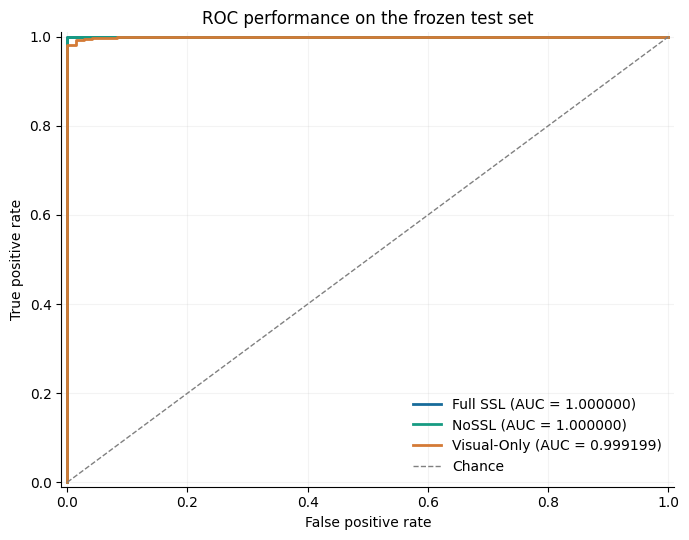

Saved: Figure_38A_ROC_Curves (PNG + PDF)


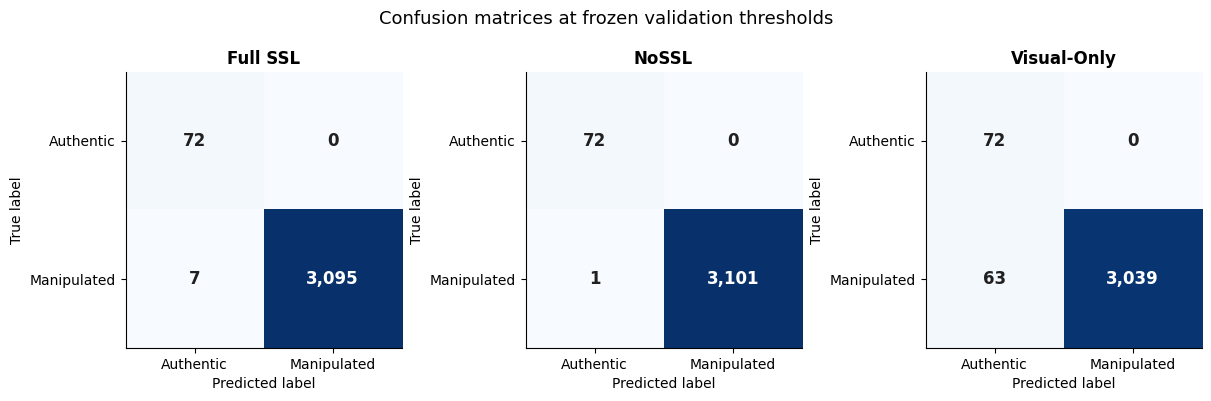

Saved: Figure_38B_Confusion_Matrices (PNG + PDF)


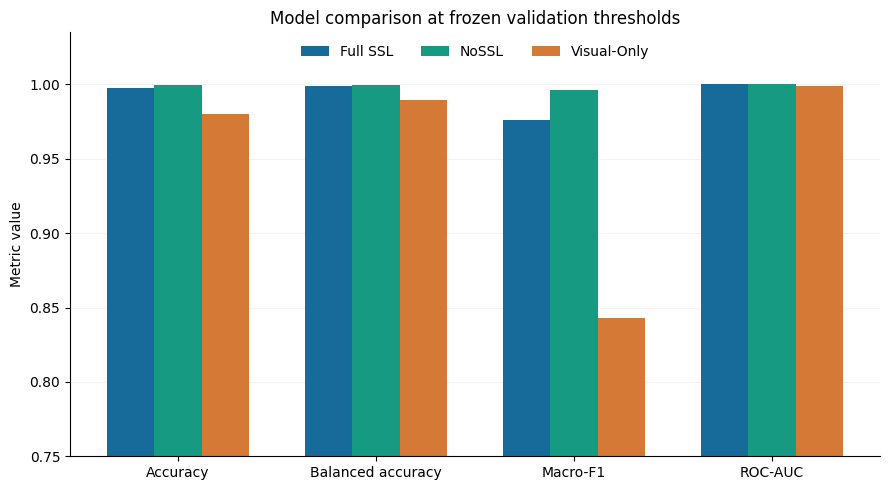

Saved: Figure_38C_Model_Comparison (PNG + PDF)


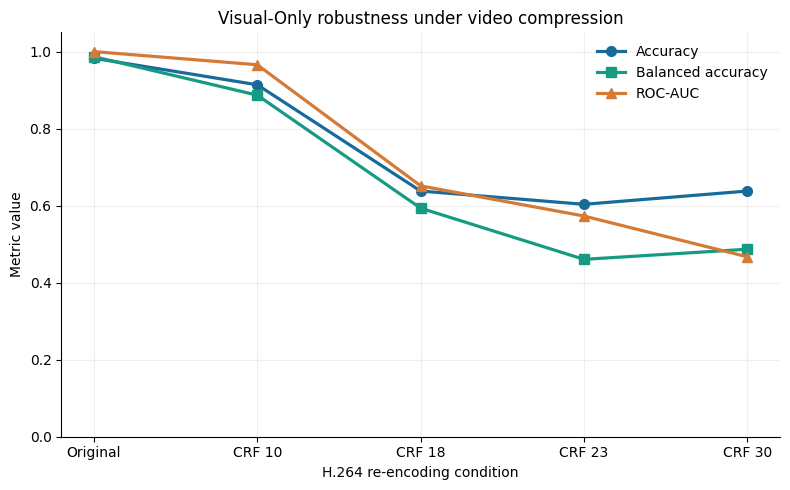

Saved: Figure_38D_Compression_Robustness (PNG + PDF)


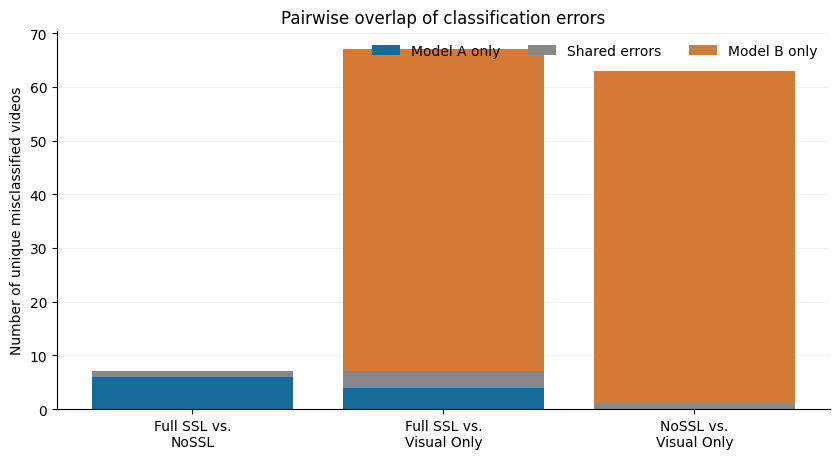

Saved: Figure_38E_Error_Overlap (PNG + PDF)

CELL 38 COMPLETED
Figures generated: 5
Formats: PNG (300 dpi) and PDF (vector)
Output directory: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures
GPU: Not required
Training: Not required
Dataset download: Not required


In [ ]:
# =============================================================================
# CELL 38 — SCIENTIFIC REPORTS PUBLICATION-QUALITY FIGURES
# CPU ONLY | NO TRAINING | NO VIDEO DOWNLOAD
#
# Outputs:
# Fig 1 — ROC curves
# Fig 2 — Frozen-threshold confusion matrices
# Fig 3 — Model performance comparison
# Fig 4 — Compression robustness
# Fig 5 — Error overlap
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from matplotlib.ticker import PercentFormatter
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
PRED = ROOT / "05_Predictions"
TABLES = ROOT / "06_Results/Tables"

OUT = ROOT / "06_Results/Figures/Final_Publication_Figures"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = {
    "Full SSL": (
        "smdnet_v2_final_test_5window_predictions.csv",
        "probability_manipulated",
        0.75732421875
    ),
    "NoSSL": (
        "smdnet_v2_nossl_test_5window_predictions.csv",
        "nossl_probability",
        0.556396484375
    ),
    "Visual-Only": (
        "smdnet_v2_visual_only_test_5window_predictions.csv",
        "visual_only_probability",
        0.9638671875
    )
}

COLORS = {
    "Full SSL": "#176B9A",
    "NoSSL": "#169B82",
    "Visual-Only": "#D47A36"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

def save(fig, name):
    fig.savefig(
        OUT / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    fig.savefig(
        OUT / f"{name}.pdf",
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close(fig)
    print("Saved:", name, "(PNG + PDF)")

def find_col(df, options):
    lookup = {str(c).lower(): c for c in df.columns}
    for c in options:
        if c.lower() in lookup:
            return lookup[c.lower()]
    raise ValueError(
        f"None of {options} found. Available: {list(df.columns)}"
    )

def labels_as_binary(s):
    numeric = pd.to_numeric(s, errors="coerce")
    if numeric.notna().all() and set(numeric.unique()) <= {0, 1}:
        return numeric.astype(int)
    mapping = {
        "real": 0, "authentic": 0, "genuine": 0,
        "rvra": 0, "original": 0,
        "fake": 1, "manipulated": 1,
        "fvfa": 1, "fvra": 1, "rvfa": 1
    }
    out = s.astype(str).str.strip().str.lower().map(mapping)
    if out.isna().any():
        raise ValueError("Unrecognized ground-truth labels.")
    return out.astype(int)

# ---------------------------------------------------------------------------
# LOAD AND VERIFY IDENTICAL TEST SAMPLES
# ---------------------------------------------------------------------------

data = {}
reference_paths = None
reference_labels = None

for name, (filename, prob_col, threshold) in MODELS.items():
    df = pd.read_csv(PRED / filename)

    path_col = find_col(df, [
        "relative_path", "video_path", "path", "filename"
    ])
    label_col = find_col(df, [
        "binary_label", "true_label", "label",
        "ground_truth", "y_true"
    ])

    d = pd.DataFrame({
        "path": df[path_col].astype(str),
        "y": labels_as_binary(df[label_col]),
        "p": pd.to_numeric(df[prob_col], errors="coerce")
    }).set_index("path").sort_index()

    assert len(d) == 3174
    assert not d.index.has_duplicates
    assert d["p"].notna().all()
    assert d["p"].between(0, 1).all()
    assert (d["y"] == 0).sum() == 72
    assert (d["y"] == 1).sum() == 3102

    if reference_paths is None:
        reference_paths = d.index
        reference_labels = d["y"].to_numpy()
    else:
        assert d.index.equals(reference_paths)
        assert np.array_equal(
            d["y"].to_numpy(), reference_labels
        )

    data[name] = {
        "y": d["y"].to_numpy(),
        "p": d["p"].to_numpy(),
        "pred": (d["p"].to_numpy() >= threshold).astype(int),
        "threshold": threshold
    }

print("Verified: 3,174 identical test videos across all models.")

# ---------------------------------------------------------------------------
# FIGURE 1 — ROC CURVES
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5.5))

for name, d in data.items():
    fpr, tpr, _ = roc_curve(d["y"], d["p"])
    auc = roc_auc_score(d["y"], d["p"])

    ax.plot(
        fpr, tpr,
        lw=2,
        color=COLORS[name],
        label=f"{name} (AUC = {auc:.6f})"
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--", color="gray",
    linewidth=1, label="Chance"
)

ax.set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="ROC performance on the frozen test set",
    xlim=(-0.01, 1.01),
    ylim=(-0.01, 1.01)
)

ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=0.15)
fig.tight_layout()
save(fig, "Figure_38A_ROC_Curves")

# ---------------------------------------------------------------------------
# FIGURE 2 — CONFUSION MATRICES
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3, figsize=(12, 3.9),
    constrained_layout=True
)

for ax, (name, d) in zip(axes, data.items()):
    cm = confusion_matrix(
        d["y"], d["pred"], labels=[0, 1]
    )

    ax.imshow(cm, cmap="Blues", vmin=0, vmax=3102)

    for i in range(2):
        for j in range(2):
            value = int(cm[i, j])
            ax.text(
                j, i, f"{value:,}",
                ha="center", va="center",
                fontsize=12, fontweight="bold",
                color="white" if value > 1600 else "#202020"
            )

    ax.set_xticks([0, 1], ["Authentic", "Manipulated"])
    ax.set_yticks([0, 1], ["Authentic", "Manipulated"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(name, fontweight="bold")

fig.suptitle(
    "Confusion matrices at frozen validation thresholds",
    fontsize=13
)
save(fig, "Figure_38B_Confusion_Matrices")

# ---------------------------------------------------------------------------
# FIGURE 3 — MODEL PERFORMANCE COMPARISON
# ---------------------------------------------------------------------------

metric_file = (
    TABLES / "Final_Publication_Tables" /
    "Table_02_Frozen_Validation_Threshold_Performance.csv"
)

metrics = pd.read_csv(metric_file)

names = ["Full_SSL", "NoSSL", "Visual_Only"]
display_names = ["Full SSL", "NoSSL", "Visual-Only"]

metrics = metrics.set_index("Model").loc[names]

metric_columns = [
    "Accuracy", "Balanced_Accuracy",
    "Macro_F1", "ROC_AUC"
]

metric_labels = [
    "Accuracy", "Balanced accuracy",
    "Macro-F1", "ROC-AUC"
]

x = np.arange(len(metric_labels))
width = 0.24

fig, ax = plt.subplots(figsize=(9, 5))

for i, display in enumerate(display_names):
    values = metrics.loc[names[i], metric_columns].to_numpy(
        dtype=float
    )

    ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=display,
        color=COLORS[display]
    )

ax.set_xticks(x, metric_labels)
ax.set_ylim(0.75, 1.035)
ax.set_ylabel("Metric value")
ax.set_title(
    "Model comparison at frozen validation thresholds"
)
ax.legend(frameon=False, ncol=3, loc="upper center")
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

fig.tight_layout()
save(fig, "Figure_38C_Model_Comparison")

# ---------------------------------------------------------------------------
# FIGURE 4 — COMPRESSION ROBUSTNESS
# ---------------------------------------------------------------------------

compression_file = (
    TABLES /
    "smdnet_v2_cell35_recovered_robustness_metrics.csv"
)

compression = pd.read_csv(compression_file)

compression = compression[
    (compression["group"] == "Overall") &
    (compression["threshold_policy"] == "Default_0.5")
].copy()

order = ["Original", "CRF10", "CRF18", "CRF23", "CRF30"]

compression = compression.set_index(
    "compression"
).loc[order]

x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    compression["accuracy"].to_numpy(),
    "o-",
    lw=2.3,
    markersize=7,
    label="Accuracy",
    color="#176B9A"
)

ax.plot(
    x,
    compression["balanced_accuracy"].to_numpy(),
    "s-",
    lw=2.3,
    markersize=7,
    label="Balanced accuracy",
    color="#169B82"
)

ax.plot(
    x,
    compression["roc_auc"].to_numpy(),
    "^-",
    lw=2.3,
    markersize=7,
    label="ROC-AUC",
    color="#D47A36"
)

ax.set_xticks(x, [
    "Original", "CRF 10", "CRF 18", "CRF 23", "CRF 30"
])

ax.set_ylim(0, 1.05)
ax.set_ylabel("Metric value")
ax.set_xlabel("H.264 re-encoding condition")
ax.set_title(
    "Visual-Only robustness under video compression"
)
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()

save(fig, "Figure_38D_Compression_Robustness")

# ---------------------------------------------------------------------------
# FIGURE 5 — ERROR OVERLAP
# ---------------------------------------------------------------------------

overlap_file = (
    TABLES /
    "Final_Publication_Tables" /
    "Cell37_Statistical_Validation" /
    "Table_37E_Error_Overlap.csv"
)

overlap = pd.read_csv(overlap_file)

fig, ax = plt.subplots(figsize=(8.5, 4.7))

pair_labels = [
    f"{a.replace('_', ' ')} vs.\n{b.replace('_', ' ')}"
    for a, b in zip(
        overlap["model_a"], overlap["model_b"]
    )
]

x = np.arange(len(overlap))

a_only = overlap["errors_a_only"].to_numpy()
shared = overlap["shared_errors"].to_numpy()
b_only = overlap["errors_b_only"].to_numpy()

ax.bar(
    x, a_only,
    color="#176B9A",
    label="Model A only"
)

ax.bar(
    x, shared,
    bottom=a_only,
    color="#888888",
    label="Shared errors"
)

ax.bar(
    x, b_only,
    bottom=a_only + shared,
    color="#D47A36",
    label="Model B only"
)

ax.set_xticks(x, pair_labels)
ax.set_ylabel("Number of unique misclassified videos")
ax.set_title("Pairwise overlap of classification errors")
ax.legend(frameon=False, ncol=3)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

fig.tight_layout()
save(fig, "Figure_38E_Error_Overlap")

print("\n" + "=" * 80)
print("CELL 38 COMPLETED")
print("=" * 80)
print("Figures generated: 5")
print("Formats: PNG (300 dpi) and PDF (vector)")
print("Output directory:", OUT)
print("GPU: Not required")
print("Training: Not required")
print("Dataset download: Not required")
print("=" * 80)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 39 — FAKEAVCELEB DATASET VISUALIZATION
Project: /content/drive/MyDrive/SMDNet_V2_ScientificReports
Output: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization

Frozen metadata located:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/01_Metadata/fakeavceleb_final_clean_cohort.csv
Rows: 21476

Dataset validation: PASSED

Partition sizes:
split
Train         15065
Validation     3237
Test           3174

Test category counts:
category
RVRA      72
RVFA      75
FVRA    1444
FVFA    1583


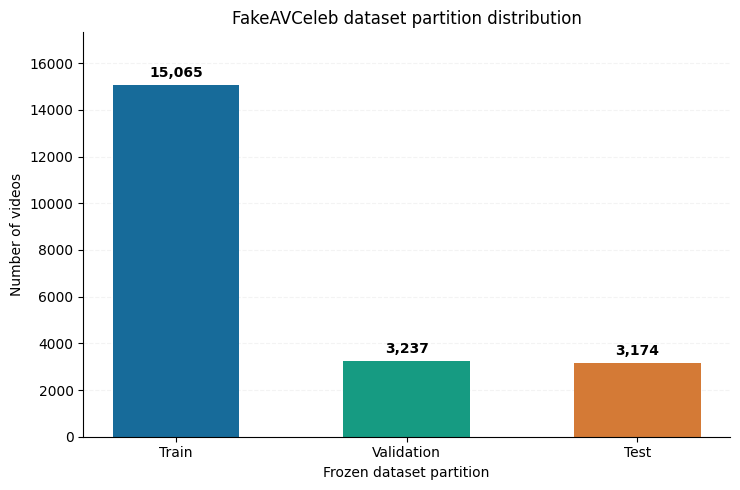

Saved: Figure_39A_Dataset_Partition_Distribution (PNG + PDF)


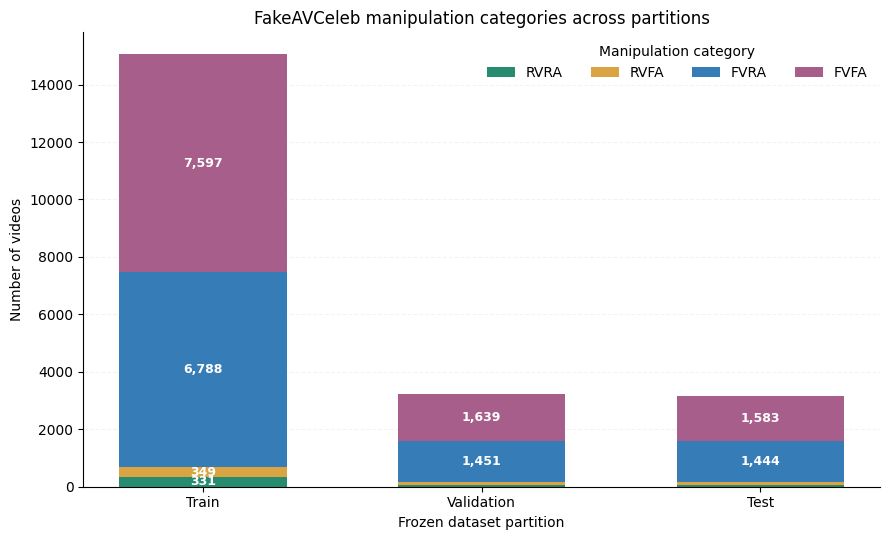

Saved: Figure_39B_Manipulation_Category_Distribution (PNG + PDF)


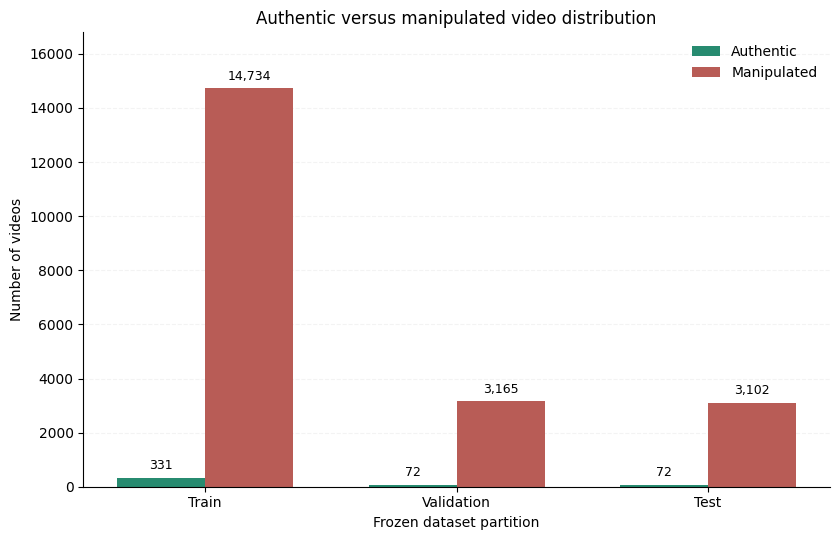

Saved: Figure_39C_Authentic_Manipulated_Imbalance (PNG + PDF)

Figure 39D skipped: verified duration metadata unavailable.


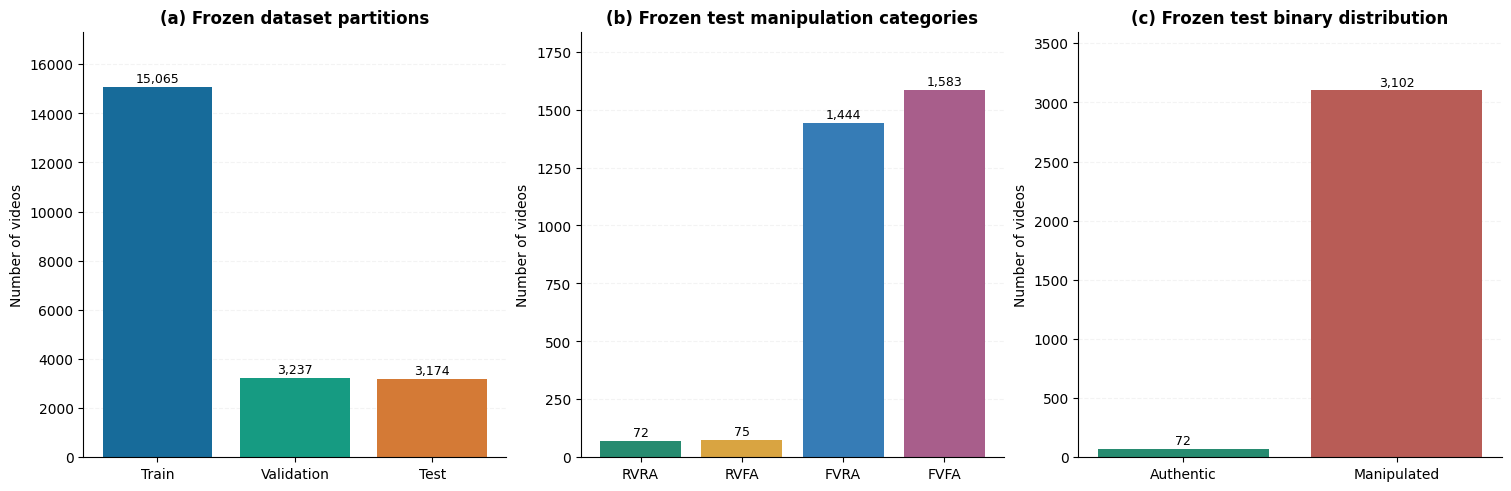

Saved: Figure_39E_Combined_Dataset_Overview (PNG + PDF)

CELL 39 COMPLETED SUCCESSFULLY

Dataset: 21476 videos
Train: 15065
Validation: 3237
Test: 3174

Test composition:
  RVRA: 72
  RVFA: 75
  FVRA: 1,444
  FVFA: 1,583

Test authentic percentage:
2.2684%

Saved figures and audit:
/content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization

GPU: Not required
Training: Not required
Dataset download: Not required


In [ ]:
# =============================================================================
# CELL 39 — FAKEAVCELEB DATASET VISUALIZATION
# SMD-Net V2 | Scientific Reports
#
# CPU ONLY | NO TRAINING | NO VIDEO DOWNLOAD
#
# Generates:
# 39A — Frozen dataset partition sizes
# 39B — Manipulation categories across partitions
# 39C — Authentic versus manipulated class distribution
# 39D — Video duration distributions
# 39E — Combined publication-ready dataset overview
#
# Saves PNG (300 dpi), PDF (vector), CSV, and JSON audit files.
# =============================================================================

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator
from google.colab import drive

warnings.filterwarnings("ignore", category=RuntimeWarning)

# =============================================================================
# 1. GOOGLE DRIVE AND PROJECT DIRECTORIES
# =============================================================================

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

PRED_DIR = ROOT / "05_Predictions"
TABLE_DIR = ROOT / "06_Results" / "Tables"

OUT_DIR = (
    ROOT
    / "06_Results"
    / "Figures"
    / "Final_Publication_Figures"
    / "Dataset_Visualization"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_TOTAL = 21476

EXPECTED_SPLITS = {
    "Train": 15065,
    "Validation": 3237,
    "Test": 3174
}

EXPECTED_TEST_CATEGORIES = {
    "RVRA": 72,
    "RVFA": 75,
    "FVRA": 1444,
    "FVFA": 1583
}

SPLIT_ORDER = ["Train", "Validation", "Test"]
CATEGORY_ORDER = ["RVRA", "RVFA", "FVRA", "FVFA"]

COLORS = {
    "Train": "#176B9A",
    "Validation": "#169B82",
    "Test": "#D47A36",
    "RVRA": "#278B70",
    "RVFA": "#D9A441",
    "FVRA": "#367CB6",
    "FVFA": "#A85E8B",
    "Authentic": "#278B70",
    "Manipulated": "#B85C56"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300
})

print("=" * 95)
print("CELL 39 — FAKEAVCELEB DATASET VISUALIZATION")
print("=" * 95)
print("Project:", ROOT)
print("Output:", OUT_DIR)

# =============================================================================
# 2. FIND FROZEN METADATA
# =============================================================================

def find_col(df, candidates):

    lookup = {
        str(c).strip().lower(): c
        for c in df.columns
    }

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    return None


def normalize_split(values):

    mapping = {
        "train": "Train",
        "training": "Train",
        "val": "Validation",
        "valid": "Validation",
        "validation": "Validation",
        "test": "Test",
        "testing": "Test"
    }

    return (
        values.astype(str)
        .str.strip()
        .str.lower()
        .map(mapping)
    )


def normalize_category(values):

    mapping = {
        "realvideo-realaudio": "RVRA",
        "realvideo-fakeaudio": "RVFA",
        "fakevideo-realaudio": "FVRA",
        "fakevideo-fakeaudio": "FVFA",
        "rvra": "RVRA",
        "rvfa": "RVFA",
        "fvra": "FVRA",
        "fvfa": "FVFA"
    }

    normalized = (
        values.astype(str)
        .str.strip()
        .str.lower()
        .str.replace("_", "-", regex=False)
        .str.replace(" ", "", regex=False)
    )

    return normalized.map(mapping)


# Search only project metadata files, not the dataset itself.
candidates = []

for folder in [
    ROOT / "00_Metadata",
    ROOT / "01_Metadata",
    ROOT / "02_Metadata",
    ROOT / "03_Metadata",
    ROOT / "06_Results" / "Tables",
    ROOT
]:

    if folder.exists():
        candidates.extend(folder.glob("*.csv"))

# Include metadata files located in other project subfolders.
if not candidates:
    candidates = list(ROOT.rglob("*.csv"))

metadata = None
metadata_path = None

for path in sorted(set(candidates)):

    try:
        header = pd.read_csv(path, nrows=3)

        split_col = find_col(
            header,
            ["split", "partition", "subset"]
        )

        path_col = find_col(
            header,
            ["relative_path", "video_path", "path"]
        )

        if split_col is None or path_col is None:
            continue

        candidate = pd.read_csv(path)

        splits = normalize_split(
            candidate[split_col]
        )

        counts = splits.value_counts()

        if (
            len(candidate) == EXPECTED_TOTAL
            and all(
                counts.get(s, 0) == n
                for s, n in EXPECTED_SPLITS.items()
            )
        ):

            metadata = candidate
            metadata_path = path
            break

    except Exception:
        continue

if metadata is None:

    print("\nNo complete frozen metadata CSV was automatically located.")
    print("Searching project recursively...")

    for path in ROOT.rglob("*.csv"):

        try:
            header = pd.read_csv(path, nrows=3)

            split_col = find_col(
                header,
                ["split", "partition", "subset"]
            )

            path_col = find_col(
                header,
                ["relative_path", "video_path", "path"]
            )

            if split_col is None or path_col is None:
                continue

            candidate = pd.read_csv(path)

            splits = normalize_split(
                candidate[split_col]
            )

            counts = splits.value_counts()

            if (
                len(candidate) == EXPECTED_TOTAL
                and all(
                    counts.get(s, 0) == n
                    for s, n in EXPECTED_SPLITS.items()
                )
            ):

                metadata = candidate
                metadata_path = path
                break

        except Exception:
            continue

if metadata is None:
    raise FileNotFoundError(
        "Could not locate the complete frozen 21,476-video "
        "metadata CSV in the project. "
        "No figures were fabricated. "
        "Please provide the metadata CSV path."
    )

print("\nFrozen metadata located:")
print(metadata_path)
print("Rows:", len(metadata))

# =============================================================================
# 3. NORMALIZE AND VALIDATE METADATA
# =============================================================================

split_col = find_col(
    metadata,
    ["split", "partition", "subset"]
)

path_col = find_col(
    metadata,
    ["relative_path", "video_path", "path"]
)

category_col = find_col(
    metadata,
    [
        "category_inventory",
        "category",
        "manipulation_type",
        "group"
    ]
)

duration_col = find_col(
    metadata,
    [
        "duration_sec",
        "duration_seconds",
        "video_duration",
        "duration"
    ]
)

df = pd.DataFrame({
    "relative_path": metadata[path_col].astype(str),
    "split": normalize_split(metadata[split_col])
})

if df["relative_path"].duplicated().any():
    raise ValueError("Duplicate video identifiers in metadata.")

if df["split"].isna().any():
    raise ValueError("Unrecognized dataset partition labels.")

if category_col is not None:

    df["category"] = normalize_category(
        metadata[category_col]
    )

else:

    # The category can be derived from the known FakeAVCeleb
    # folder structure if it is explicitly present in the path.
    df["category"] = normalize_category(
        df["relative_path"].str.split("/").str[0]
    )

if df["category"].isna().any():

    unknown = df.loc[
        df["category"].isna(),
        "relative_path"
    ].head(10)

    raise ValueError(
        "Some manipulation categories could not be verified.\n"
        + unknown.to_string(index=False)
    )

if duration_col is not None:

    df["duration_sec"] = pd.to_numeric(
        metadata[duration_col],
        errors="coerce"
    )

else:

    df["duration_sec"] = np.nan

df["binary_class"] = np.where(
    df["category"] == "RVRA",
    "Authentic",
    "Manipulated"
)

split_counts = (
    df["split"]
    .value_counts()
    .reindex(SPLIT_ORDER, fill_value=0)
)

for split, expected in EXPECTED_SPLITS.items():

    actual = int(split_counts[split])

    if actual != expected:
        raise ValueError(
            f"{split}: expected {expected}, found {actual}"
        )

test_counts = (
    df[df["split"] == "Test"]["category"]
    .value_counts()
    .reindex(CATEGORY_ORDER, fill_value=0)
)

for category, expected in EXPECTED_TEST_CATEGORIES.items():

    actual = int(test_counts[category])

    if actual != expected:
        raise ValueError(
            f"Test {category}: expected {expected}, found {actual}"
        )

print("\nDataset validation: PASSED")
print("\nPartition sizes:")
print(split_counts.to_string())

print("\nTest category counts:")
print(test_counts.to_string())

# =============================================================================
# 4. DATA TABLES
# =============================================================================

split_table = pd.DataFrame({
    "Partition": SPLIT_ORDER,
    "Videos": [
        int(split_counts[s])
        for s in SPLIT_ORDER
    ]
})

split_table["Percentage"] = (
    100 * split_table["Videos"] / EXPECTED_TOTAL
)

category_table = pd.crosstab(
    df["split"],
    df["category"]
).reindex(
    index=SPLIT_ORDER,
    columns=CATEGORY_ORDER,
    fill_value=0
)

binary_table = pd.crosstab(
    df["split"],
    df["binary_class"]
).reindex(
    index=SPLIT_ORDER,
    columns=["Authentic", "Manipulated"],
    fill_value=0
)

split_table.to_csv(
    OUT_DIR / "Dataset_Split_Counts.csv",
    index=False
)

category_table.to_csv(
    OUT_DIR / "Dataset_Category_By_Split.csv"
)

binary_table.to_csv(
    OUT_DIR / "Dataset_Binary_Class_By_Split.csv"
)

# =============================================================================
# 5. FIGURE SAVING HELPER
# =============================================================================

def save_figure(fig, name):

    fig.savefig(
        OUT_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        OUT_DIR / f"{name}.pdf",
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", name, "(PNG + PDF)")


def style_axis(ax):

    ax.grid(
        axis="y",
        alpha=0.15,
        linestyle="--"
    )

    ax.set_axisbelow(True)

# =============================================================================
# 6. FIGURE 39A — PARTITION SIZES
# =============================================================================

fig, ax = plt.subplots(figsize=(7.5, 5))

values = [
    int(split_counts[s])
    for s in SPLIT_ORDER
]

bars = ax.bar(
    SPLIT_ORDER,
    values,
    color=[
        COLORS[s]
        for s in SPLIT_ORDER
    ],
    width=0.55
)

for bar, value in zip(bars, values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_ylim(0, max(values) * 1.15)
ax.set_ylabel("Number of videos")
ax.set_xlabel("Frozen dataset partition")
ax.set_title(
    "FakeAVCeleb dataset partition distribution"
)

ax.yaxis.set_major_locator(
    MaxNLocator(integer=True)
)

style_axis(ax)
fig.tight_layout()

save_figure(
    fig,
    "Figure_39A_Dataset_Partition_Distribution"
)

# =============================================================================
# 7. FIGURE 39B — MANIPULATION CATEGORIES
# =============================================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(SPLIT_ORDER))
bottom = np.zeros(len(SPLIT_ORDER))

for category in CATEGORY_ORDER:

    values = category_table[
        category
    ].to_numpy(dtype=int)

    ax.bar(
        x,
        values,
        bottom=bottom,
        color=COLORS[category],
        label=category,
        width=0.6
    )

    for i, value in enumerate(values):

        if value >= 300:

            ax.text(
                x[i],
                bottom[i] + value / 2,
                f"{value:,}",
                ha="center",
                va="center",
                color="white",
                fontsize=9,
                fontweight="bold"
            )

    bottom += values

ax.set_xticks(x, SPLIT_ORDER)
ax.set_ylabel("Number of videos")
ax.set_xlabel("Frozen dataset partition")
ax.set_title(
    "FakeAVCeleb manipulation categories across partitions"
)

ax.legend(
    title="Manipulation category",
    frameon=False,
    ncol=4,
    loc="upper right"
)

style_axis(ax)
fig.tight_layout()

save_figure(
    fig,
    "Figure_39B_Manipulation_Category_Distribution"
)

# =============================================================================
# 8. FIGURE 39C — CLASS IMBALANCE
# =============================================================================

fig, ax = plt.subplots(figsize=(8.5, 5.5))

x = np.arange(len(SPLIT_ORDER))
width = 0.35

authentic = binary_table[
    "Authentic"
].to_numpy(dtype=int)

manipulated = binary_table[
    "Manipulated"
].to_numpy(dtype=int)

bars_real = ax.bar(
    x - width / 2,
    authentic,
    width,
    label="Authentic",
    color=COLORS["Authentic"]
)

bars_fake = ax.bar(
    x + width / 2,
    manipulated,
    width,
    label="Manipulated",
    color=COLORS["Manipulated"]
)

for bars in [bars_real, bars_fake]:

    for bar in bars:

        value = int(bar.get_height())

        ax.annotate(
            f"{value:,}",
            (
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_xticks(x, SPLIT_ORDER)
ax.set_ylabel("Number of videos")
ax.set_xlabel("Frozen dataset partition")
ax.set_title(
    "Authentic versus manipulated video distribution"
)

ax.set_ylim(
    0,
    max(manipulated.max(), authentic.max()) * 1.14
)

ax.legend(frameon=False)
style_axis(ax)
fig.tight_layout()

save_figure(
    fig,
    "Figure_39C_Authentic_Manipulated_Imbalance"
)

# =============================================================================
# 9. FIGURE 39D — VIDEO DURATION DISTRIBUTION
# =============================================================================

duration_available = (
    df["duration_sec"].notna().any()
    and (df["duration_sec"] > 0).any()
)

if duration_available:

    duration_df = df[
        np.isfinite(df["duration_sec"])
        & (df["duration_sec"] > 0)
    ].copy()

    fig, ax = plt.subplots(figsize=(9, 5.5))

    duration_data = [
        duration_df.loc[
            duration_df["category"] == category,
            "duration_sec"
        ].to_numpy()
        for category in CATEGORY_ORDER
    ]

    ax.boxplot(
        duration_data,
        tick_labels=CATEGORY_ORDER,
        showfliers=False,
        patch_artist=True,
        boxprops={
            "facecolor": "#C9DCE8",
            "edgecolor": "#36546B"
        },
        medianprops={
            "color": "#B85C56",
            "linewidth": 2
        }
    )

    ax.set_ylabel("Video duration (seconds)")
    ax.set_xlabel("Manipulation category")
    ax.set_title(
        "Video duration distribution by manipulation category"
    )

    style_axis(ax)
    fig.tight_layout()

    save_figure(
        fig,
        "Figure_39D_Video_Duration_Distribution"
    )

    duration_summary = (
        duration_df
        .groupby("category")["duration_sec"]
        .agg(
            ["count", "mean", "median", "std", "min", "max"]
        )
        .reindex(CATEGORY_ORDER)
    )

    duration_summary.to_csv(
        OUT_DIR / "Dataset_Duration_Statistics.csv"
    )

else:

    print(
        "\nFigure 39D skipped: "
        "verified duration metadata unavailable."
    )

# =============================================================================
# 10. FIGURE 39E — COMBINED PUBLICATION OVERVIEW
# =============================================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.8),
    constrained_layout=True
)

# Panel A: split sizes
axes[0].bar(
    SPLIT_ORDER,
    values := [
        int(split_counts[s])
        for s in SPLIT_ORDER
    ],
    color=[COLORS[s] for s in SPLIT_ORDER]
)

axes[0].set_title(
    "(a) Frozen dataset partitions",
    fontweight="bold"
)

axes[0].set_ylabel("Number of videos")

for i, value in enumerate(values):
    axes[0].text(
        i, value + 200,
        f"{value:,}",
        ha="center",
        fontsize=9
    )

axes[0].set_ylim(0, max(values) * 1.15)

# Panel B: test manipulation categories
test_values = [
    int(test_counts[c])
    for c in CATEGORY_ORDER
]

axes[1].bar(
    CATEGORY_ORDER,
    test_values,
    color=[
        COLORS[c]
        for c in CATEGORY_ORDER
    ]
)

axes[1].set_title(
    "(b) Frozen test manipulation categories",
    fontweight="bold"
)

axes[1].set_ylabel("Number of videos")

for i, value in enumerate(test_values):
    axes[1].text(
        i, value + 20,
        f"{value:,}",
        ha="center",
        fontsize=9
    )

axes[1].set_ylim(0, max(test_values) * 1.16)

# Panel C: test binary imbalance
test_real = int(
    binary_table.loc["Test", "Authentic"]
)

test_fake = int(
    binary_table.loc["Test", "Manipulated"]
)

axes[2].bar(
    ["Authentic", "Manipulated"],
    [test_real, test_fake],
    color=[
        COLORS["Authentic"],
        COLORS["Manipulated"]
    ]
)

axes[2].set_title(
    "(c) Frozen test binary distribution",
    fontweight="bold"
)

axes[2].set_ylabel("Number of videos")

for i, value in enumerate(
    [test_real, test_fake]
):
    axes[2].text(
        i,
        value + 35,
        f"{value:,}",
        ha="center",
        fontsize=9
    )

axes[2].set_ylim(0, test_fake * 1.16)

for ax in axes:
    style_axis(ax)

save_figure(
    fig,
    "Figure_39E_Combined_Dataset_Overview"
)

# =============================================================================
# 11. AUDIT AND REPRODUCIBILITY
# =============================================================================

summary = {
    "experiment": "Cell 39 FakeAVCeleb dataset visualization",
    "target_journal": "Scientific Reports",
    "metadata_file": str(metadata_path),
    "total_videos": int(len(df)),
    "split_counts": {
        key: int(value)
        for key, value in split_counts.items()
    },
    "test_category_counts": {
        key: int(value)
        for key, value in test_counts.items()
    },
    "test_authentic": test_real,
    "test_manipulated": test_fake,
    "test_authentic_percentage": (
        100 * test_real / (test_real + test_fake)
    ),
    "duration_metadata_available": bool(
        duration_available
    ),
    "dataset_videos_accessed": False,
    "model_training_performed": False,
    "gpu_required": False,
    "output_directory": str(OUT_DIR)
}

with open(
    OUT_DIR / "Cell39_Dataset_Visualization_Audit.json",
    "w"
) as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 95)
print("CELL 39 COMPLETED SUCCESSFULLY")
print("=" * 95)

print("\nDataset:", len(df), "videos")
print("Train:", int(split_counts["Train"]))
print("Validation:", int(split_counts["Validation"]))
print("Test:", int(split_counts["Test"]))

print("\nTest composition:")
for category, count in test_counts.items():
    print(f"  {category}: {count:,}")

print("\nTest authentic percentage:")
print(f"{100 * test_real / (test_real + test_fake):.4f}%")

print("\nSaved figures and audit:")
print(OUT_DIR)

print("\nGPU: Not required")
print("Training: Not required")
print("Dataset download: Not required")
print("=" * 95)

In [ ]:
# =============================================================================
# CELL 40 — REAL FAKEAVCELEB AUDIOVISUAL SAMPLE VISUALIZATION
# SMD-Net V2 | Scientific Reports
#
# CPU ONLY | NO TRAINING | NO AUTOMATIC DATASET DOWNLOAD
#
# Finds real dataset videos and generates:
#   Figure_40A_Actual_FakeAVCeleb_AV_Samples.png
#   Figure_40A_Actual_FakeAVCeleb_AV_Samples.pdf
#   Cell40_Selected_Samples.csv
#   Cell40_Audit.json
#
# Each of four categories:
#   RVRA, RVFA, FVRA, FVFA
#   3 genuine video frames + 1 genuine audio log-mel spectrogram
# =============================================================================

import os
import json
import shutil
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from google.colab import drive

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------------
# 1. ENVIRONMENT
# ---------------------------------------------------------------------------

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

METADATA = ROOT / "01_Metadata/fakeavceleb_final_clean_cohort.csv"

OUT = (
    ROOT
    / "06_Results"
    / "Figures"
    / "Final_Publication_Figures"
    / "Dataset_Visualization"
)

OUT.mkdir(parents=True, exist_ok=True)

CATEGORY_MAP = {
    "RVRA": "RealVideo-RealAudio",
    "RVFA": "RealVideo-FakeAudio",
    "FVRA": "FakeVideo-RealAudio",
    "FVFA": "FakeVideo-FakeAudio"
}

CATEGORY_DESCRIPTIONS = {
    "RVRA": "Authentic video / authentic audio",
    "RVFA": "Authentic video / manipulated audio",
    "FVRA": "Manipulated video / authentic audio",
    "FVFA": "Manipulated video / manipulated audio"
}

CATEGORY_COLORS = {
    "RVRA": "#21856B",
    "RVFA": "#D29A37",
    "FVRA": "#337BAA",
    "FVFA": "#A55B88"
}

print("=" * 95)
print("CELL 40 — REAL FAKEAVCELEB AUDIOVISUAL SAMPLE VISUALIZATION")
print("=" * 95)

if not METADATA.exists():
    raise FileNotFoundError(
        f"Frozen cohort metadata unavailable: {METADATA}"
    )

df = pd.read_csv(METADATA)

print("Metadata rows:", len(df))
print("Metadata columns:", list(df.columns))

assert len(df) == 21476, "Unexpected frozen cohort size."

# ---------------------------------------------------------------------------
# 2. IDENTIFY METADATA COLUMNS
# ---------------------------------------------------------------------------

def get_col(frame, names):
    mapping = {str(c).lower(): c for c in frame.columns}
    for name in names:
        if name.lower() in mapping:
            return mapping[name.lower()]
    return None

PATH_COL = get_col(
    df,
    ["relative_path", "video_path", "path"]
)

CATEGORY_COL = get_col(
    df,
    ["category_inventory", "category", "manipulation_type"]
)

SPLIT_COL = get_col(
    df,
    ["split", "partition", "subset"]
)

ABS_COL = get_col(
    df,
    ["absolute_path", "full_path"]
)

if PATH_COL is None:
    raise ValueError("No relative video path column found.")

if CATEGORY_COL is None:
    df["_category"] = (
        df[PATH_COL]
        .astype(str)
        .str.replace("\\", "/", regex=False)
        .str.split("/")
        .str[0]
    )
    CATEGORY_COL = "_category"

def normalize_category(value):
    value = str(value).strip()
    for code, folder in CATEGORY_MAP.items():
        if value.lower() in [code.lower(), folder.lower()]:
            return code
    return None

df["_code"] = df[CATEGORY_COL].map(normalize_category)

if df["_code"].isna().any():
    raise ValueError(
        "Unrecognized categories in frozen metadata."
    )

# ---------------------------------------------------------------------------
# 3. LOCATE THE ORIGINAL VIDEO ROOT
# ---------------------------------------------------------------------------

SEARCH_ROOTS = [
    ROOT,
    Path("/content/drive/MyDrive"),
    Path("/content"),
    Path("/root/.cache/kagglehub"),
    Path("/kaggle/input")
]

SEARCH_ROOTS = [
    p for p in SEARCH_ROOTS if p.exists()
]

# Prefer source video files, not previously compressed experimental outputs.
def is_experimental_copy(path):
    text = str(path).lower()
    return any(
        term in text
        for term in [
            "compression_pilot",
            "compression_robustness",
            "cell34",
            "crf10",
            "crf18",
            "crf23",
            "crf30",
            "reencoded"
        ]
    )

def resolve_video(row):

    rel = str(row[PATH_COL]).replace("\\", "/").lstrip("/")

    candidates = []

    if ABS_COL is not None:
        value = row.get(ABS_COL)
        if pd.notna(value):
            candidates.append(Path(str(value)))

    candidates.append(Path(rel))

    for base in SEARCH_ROOTS:
        candidates.extend([
            base / rel,
            base / "FakeAVCeleb_v1.2" / rel,
            base / "FakeAVCeleb_v1.2" / "FakeAVCeleb_v1.2" / rel,
            base / "datasets" / rel
        ])

    for candidate in candidates:
        if (
            candidate.is_file()
            and candidate.stat().st_size > 0
            and not is_experimental_copy(candidate)
        ):
            return candidate

    return None

# First try direct path resolution.
selected = {}
missing = []

for code in CATEGORY_MAP:

    subset = df[df["_code"] == code].copy()

    # Prefer test-set examples, but other frozen cohort
    # partitions are acceptable for a descriptive dataset figure.
    if SPLIT_COL is not None:
        subset["_priority"] = (
            subset[SPLIT_COL]
            .astype(str)
            .str.lower()
            .eq("test")
            .map({True: 0, False: 1})
        )
        subset = subset.sort_values("_priority")

    found = None

    # Check a manageable number of candidate metadata paths.
    for _, row in subset.head(250).iterrows():

        video = resolve_video(row)

        if video is not None:
            found = (row, video)
            break

    if found is None:
        missing.append(code)
    else:
        selected[code] = found

# ---------------------------------------------------------------------------
# 4. IF NEEDED, LOCATE DATASET DIRECTORY THROUGH FOLDER DISCOVERY
# ---------------------------------------------------------------------------

if missing:

    print("\nDirect lookup incomplete.")
    print("Missing categories:", missing)
    print("Checking available dataset directories...")

    possible_roots = []

    for base in SEARCH_ROOTS:

        # Search for known FakeAVCeleb directory names.
        try:
            for current, dirs, files in os.walk(base):

                depth = len(
                    Path(current).relative_to(base).parts
                )

                if depth > 7:
                    dirs[:] = []
                    continue

                if (
                    "RealVideo-RealAudio" in dirs
                    or "FakeVideo-RealAudio" in dirs
                    or "RealVideo-FakeAudio" in dirs
                    or "FakeVideo-FakeAudio" in dirs
                ):
                    possible_roots.append(Path(current))
                    dirs[:] = []
                    continue

                # Skip unrelated heavy directories.
                dirs[:] = [
                    d for d in dirs
                    if not d.startswith(".")
                ]

        except Exception as e:
            print("Directory search warning:", str(e)[:120])

    possible_roots = list(dict.fromkeys(possible_roots))

    print("Potential dataset roots:", len(possible_roots))

    for root in possible_roots:
        print(" ", root)

    for code in list(missing):

        subset = df[df["_code"] == code].copy()

        if SPLIT_COL is not None:
            subset["_priority"] = (
                subset[SPLIT_COL]
                .astype(str)
                .str.lower()
                .eq("test")
                .map({True: 0, False: 1})
            )
            subset = subset.sort_values("_priority")

        for _, row in subset.head(1000).iterrows():

            rel = str(row[PATH_COL]).replace("\\", "/")

            for root in possible_roots:

                candidate = root / rel

                if (
                    candidate.is_file()
                    and candidate.stat().st_size > 0
                    and not is_experimental_copy(candidate)
                ):
                    selected[code] = (row, candidate)
                    break

            if code in selected:
                break

# ---------------------------------------------------------------------------
# 5. VERIFY AVAILABILITY
# ---------------------------------------------------------------------------

print("\n" + "-" * 95)
print("ORIGINAL VIDEO AVAILABILITY")
print("-" * 95)

for code in CATEGORY_MAP:

    if code in selected:
        print(f"{code}: FOUND")
        print(" ", selected[code][1])
    else:
        print(f"{code}: NOT FOUND")

if len(selected) != 4:

    status = {
        "status": "original_media_unavailable",
        "categories_found": list(selected.keys()),
        "categories_missing": [
            c for c in CATEGORY_MAP if c not in selected
        ],
        "dataset_download_performed": False,
        "model_training_performed": False,
        "note": (
            "The frozen metadata is available, but one or more "
            "original dataset videos are not accessible. "
            "No substitute or artificial examples were generated."
        )
    }

    with open(
        OUT / "Cell40_Media_Availability_Audit.json",
        "w"
    ) as f:
        json.dump(status, f, indent=2)

    raise FileNotFoundError(
        "At least one original FakeAVCeleb category is unavailable. "
        "Restore four original videos (one from each category) "
        "and rerun Cell 40. Availability audit saved."
    )

# ---------------------------------------------------------------------------
# 6. FRAME EXTRACTION
# ---------------------------------------------------------------------------

def extract_frames(path, n=3):

    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))

    if total < 3:
        cap.release()
        raise RuntimeError(f"Too few frames: {path}")

    # Avoid opening/closing frames; sample interior timestamps.
    indices = np.linspace(
        max(0, int(total * 0.2)),
        min(total - 1, int(total * 0.8)),
        n
    ).astype(int)

    frames = []

    for idx in indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()

        if not ok:
            cap.release()
            raise RuntimeError(
                f"Frame decoding failed at index {idx}: {path}"
            )

        frame = cv2.cvtColor(
            frame, cv2.COLOR_BGR2RGB
        )

        frames.append(frame)

    cap.release()

    return frames, indices.tolist(), fps

# ---------------------------------------------------------------------------
# 7. AUDIO EXTRACTION AND LOG-MEL SPECTROGRAM
# ---------------------------------------------------------------------------

if shutil.which("ffmpeg") is None:
    raise RuntimeError("FFmpeg is required.")

try:
    import librosa
    import librosa.display
except ImportError:
    subprocess.run(
        ["pip", "-q", "install", "librosa"],
        check=True
    )
    import librosa
    import librosa.display

def extract_audio(path, sr=16000, max_seconds=5):

    command = [
        "ffmpeg",
        "-v", "error",
        "-i", str(path),
        "-vn",
        "-ac", "1",
        "-ar", str(sr),
        "-t", str(max_seconds),
        "-f", "f32le",
        "-"
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        check=False
    )

    if result.returncode != 0:
        raise RuntimeError(
            "Audio extraction failed: "
            + result.stderr.decode(
                "utf-8", errors="replace"
            )[:300]
        )

    audio = np.frombuffer(
        result.stdout,
        dtype=np.float32
    ).copy()

    if len(audio) < sr // 2:
        raise RuntimeError(
            f"Insufficient decoded audio: {path}"
        )

    if not np.isfinite(audio).all():
        raise RuntimeError(
            f"Invalid audio values: {path}"
        )

    return audio, sr

def logmel(audio, sr):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=1024,
        hop_length=256,
        n_mels=80,
        fmin=0,
        fmax=sr / 2,
        power=2.0
    )

    return librosa.power_to_db(
        mel,
        ref=np.max
    )

# ---------------------------------------------------------------------------
# 8. PROCESS ALL FOUR ORIGINAL SAMPLES
# ---------------------------------------------------------------------------

processed = {}
audit_rows = []

for code, (row, video) in selected.items():

    print(f"\nProcessing {code}...")

    frames, frame_indices, fps = extract_frames(video)
    audio, sr = extract_audio(video)
    spec = logmel(audio, sr)

    processed[code] = {
        "frames": frames,
        "spectrogram": spec,
        "sample_rate": sr,
        "audio_duration_sec": len(audio) / sr
    }

    audit_rows.append({
        "category": code,
        "description": CATEGORY_DESCRIPTIONS[code],
        "relative_path": str(row[PATH_COL]),
        "source_file": str(video),
        "frame_indices": json.dumps(frame_indices),
        "fps": fps,
        "audio_sample_rate": sr,
        "audio_duration_sec": len(audio) / sr,
        "source_file_size_bytes": video.stat().st_size
    })

audit_df = pd.DataFrame(audit_rows)

audit_df.to_csv(
    OUT / "Cell40_Selected_Samples.csv",
    index=False
)

# ---------------------------------------------------------------------------
# 9. PUBLICATION-QUALITY FIGURE
# ---------------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300
})

fig = plt.figure(figsize=(16, 12))

grid = fig.add_gridspec(
    nrows=4,
    ncols=4,
    width_ratios=[1, 1, 1, 1.8],
    wspace=0.12,
    hspace=0.42
)

codes = list(CATEGORY_MAP.keys())

for row_idx, code in enumerate(codes):

    item = processed[code]

    for col_idx in range(3):

        ax = fig.add_subplot(
            grid[row_idx, col_idx]
        )

        ax.imshow(
            item["frames"][col_idx]
        )

        ax.axis("off")

        if row_idx == 0:
            ax.set_title(
                f"Video frame {col_idx + 1}",
                fontsize=11,
                fontweight="bold",
                pad=8
            )

        if col_idx == 0:

            ax.text(
                -0.05,
                0.5,
                code,
                transform=ax.transAxes,
                rotation=90,
                ha="right",
                va="center",
                fontsize=12,
                fontweight="bold",
                color=CATEGORY_COLORS[code]
            )

    ax_audio = fig.add_subplot(
        grid[row_idx, 3]
    )

    spec = item["spectrogram"]

    extent = [
        0,
        item["audio_duration_sec"],
        0,
        item["sample_rate"] / 2000
    ]

    ax_audio.imshow(
        spec,
        origin="lower",
        aspect="auto",
        extent=extent,
        cmap="magma",
        vmin=-80,
        vmax=0
    )

    ax_audio.set_xlabel(
        "Time (s)",
        fontsize=9
    )

    ax_audio.set_ylabel(
        "Frequency (kHz)",
        fontsize=9
    )

    if row_idx == 0:
        ax_audio.set_title(
            "Audio log-mel spectrogram",
            fontsize=11,
            fontweight="bold",
            pad=8
        )

    ax_audio.tick_params(
        labelsize=8
    )

fig.suptitle(
    "Representative audiovisual samples from FakeAVCeleb v1.2",
    fontsize=15,
    fontweight="bold",
    y=0.995
)

PNG = OUT / "Figure_40A_Actual_FakeAVCeleb_AV_Samples.png"
PDF = OUT / "Figure_40A_Actual_FakeAVCeleb_AV_Samples.pdf"

fig.savefig(
    PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    PDF,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ---------------------------------------------------------------------------
# 10. AUDIT
# ---------------------------------------------------------------------------

audit = {
    "experiment": "Cell 40 actual audiovisual samples",
    "dataset": "FakeAVCeleb v1.2",
    "frozen_cohort_size": int(len(df)),
    "sample_count": len(processed),
    "categories": codes,
    "video_frames_per_category": 3,
    "audio_representation": "80-bin log-mel spectrogram",
    "audio_sample_rate_hz": 16000,
    "original_dataset_media_used": True,
    "model_training_performed": False,
    "dataset_download_performed": False,
    "gpu_required": False,
    "selected_samples_csv": str(
        OUT / "Cell40_Selected_Samples.csv"
    ),
    "figure_png": str(PNG),
    "figure_pdf": str(PDF)
}

with open(
    OUT / "Cell40_Audit.json",
    "w"
) as f:
    json.dump(audit, f, indent=2)

print("\n" + "=" * 95)
print("CELL 40 COMPLETED SUCCESSFULLY")
print("=" * 95)

print("Actual FakeAVCeleb samples:", len(processed))
print("Frames extracted:", 12)
print("Audio spectrograms:", 4)

print("\nPNG:", PNG)
print("PDF:", PDF)
print("Audit:", OUT / "Cell40_Audit.json")

print("\nGPU: NOT REQUIRED")
print("Training: NO")
print("Dataset download: NO")
print("=" * 95)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 40 — REAL FAKEAVCELEB AUDIOVISUAL SAMPLE VISUALIZATION
Metadata rows: 21476
Metadata columns: ['category_inventory', 'binary_label', 'ethnicity', 'gender_inventory', 'folder_identity', 'filename', 'relative_path', 'absolute_path', 'ids_in_filename', 'num_ids_in_filename', 'category_key', 'race_key', 'gender_key', 'source_key_inventory', 'filename_key', 'key', 'sha256', 'metadata_status', 'source', 'target1', 'target2', 'source_key_metadata', 'target1_clean', 'target2_clean', 'method', 'category_metadata', 'type', 'race', 'gender_metadata', 'path', 'metadata_resolution', 'split']

Direct lookup incomplete.
Missing categories: ['RVRA', 'RVFA', 'FVRA', 'FVFA']
Checking available dataset directories...
Potential dataset roots: 0

-----------------------------------------------------------------------------------------------
ORIGINAL VIDEO AVAILABILITY
------

FileNotFoundError: At least one original FakeAVCeleb category is unavailable. Restore four original videos (one from each category) and rerun Cell 40. Availability audit saved.

In [ ]:
# =============================================================================
# CELL 41 — SELECTIVE FAKEAVCELEB VIDEO RECOVERY
# Scientific Reports | SMD-Net V2
#
# Download only 4 individual MP4 files (one per category).
# Verify SHA-256 against frozen cohort metadata.
# Preserve verified files in Google Drive.
#
# CPU ONLY | NO MODEL TRAINING | NO FULL DATASET DOWNLOAD
# =============================================================================

import sys
import subprocess
import hashlib
import json
import shutil
from pathlib import Path

import pandas as pd

from google.colab import drive

drive.mount("/content/drive")

try:
    import kagglehub
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install", "kagglehub"],
        check=True
    )
    import kagglehub

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

METADATA = ROOT / "01_Metadata/fakeavceleb_final_clean_cohort.csv"

SAVE_DIR = ROOT / "08_Representative_Dataset_Samples"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

HANDLE = "shreyaty08/fakeavceleb/versions/1"

CATEGORY_MAP = {
    "RVRA": "RealVideo-RealAudio",
    "RVFA": "RealVideo-FakeAudio",
    "FVRA": "FakeVideo-RealAudio",
    "FVFA": "FakeVideo-FakeAudio"
}

# Previous KaggleHub cache indicated this dataset structure.
# Try these exact per-file prefixes, not dataset-level downloads.
PREFIXES = [
    "FakeAVCeleb_v1.2/FakeAVCeleb_v1.2",
    "FakeAVCeleb_v1.2",
    ""
]

MAX_FILE_BYTES = 100 * 1024 * 1024

print("=" * 90)
print("CELL 41 — SELECTIVE FAKEAVCELEB RECOVERY")
print("=" * 90)

df = pd.read_csv(METADATA)

assert len(df) == 21476
assert "relative_path" in df.columns
assert "sha256" in df.columns
assert "category_inventory" in df.columns

def category_code(value):
    value = str(value).strip().lower()
    for code, folder in CATEGORY_MAP.items():
        if value in (code.lower(), folder.lower()):
            return code
    return None

df["_category"] = df["category_inventory"].map(category_code)

if df["_category"].isna().any():
    raise ValueError("Unrecognized metadata category.")

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def verify(path, expected_hash):
    return (
        path.is_file()
        and path.stat().st_size > 0
        and sha256_file(path).lower() == expected_hash.lower()
    )

def safe_relative_path(value):
    p = Path(str(value).replace("\\", "/"))
    if p.is_absolute() or ".." in p.parts:
        raise ValueError(f"Unsafe metadata path: {value}")
    return p.as_posix()

records = []

for code in CATEGORY_MAP:

    print("\n" + "-" * 90)
    print("CATEGORY:", code)
    print("-" * 90)

    subset = df[df["_category"] == code].copy()

    if "split" in subset.columns:
        subset["_priority"] = (
            subset["split"].astype(str).str.lower() != "test"
        ).astype(int)
        subset = subset.sort_values("_priority")

    # Attempt up to three metadata-listed samples per category.
    # This avoids repeatedly downloading large numbers of files.
    candidates = subset.head(3)

    recovered = False

    for _, row in candidates.iterrows():

        rel = safe_relative_path(row["relative_path"])
        expected_hash = str(row["sha256"]).strip().lower()

        if len(expected_hash) != 64:
            print("Skipping sample with missing/invalid SHA-256:", rel)
            continue

        destination = SAVE_DIR / rel
        destination.parent.mkdir(parents=True, exist_ok=True)

        if verify(destination, expected_hash):
            print("Already verified in Drive:", destination)
            records.append({
                "category": code,
                "relative_path": rel,
                "saved_path": str(destination),
                "sha256": expected_hash,
                "status": "verified_existing"
            })
            recovered = True
            break

        for prefix in PREFIXES:

            kaggle_path = (
                f"{prefix}/{rel}" if prefix else rel
            )

            print("Trying individual file:", kaggle_path)

            try:
                downloaded = Path(
                    kagglehub.dataset_download(
                        HANDLE,
                        path=kaggle_path
                    )
                )

                if downloaded.is_dir():
                    matches = list(downloaded.rglob(Path(rel).name))
                    if len(matches) != 1:
                        raise RuntimeError(
                            "Individual-file request did not return "
                            "one unambiguous MP4."
                        )
                    downloaded = matches[0]

                if not downloaded.is_file():
                    raise FileNotFoundError(downloaded)

                size = downloaded.stat().st_size

                if size > MAX_FILE_BYTES:
                    raise RuntimeError(
                        f"Unexpectedly large single file: {size} bytes"
                    )

                actual_hash = sha256_file(downloaded)

                if actual_hash.lower() != expected_hash:
                    print("SHA-256 mismatch; rejecting this file.")
                    continue

                shutil.copy2(downloaded, destination)

                if not verify(destination, expected_hash):
                    raise RuntimeError(
                        "Verification failed after Drive copy."
                    )

                print("VERIFIED AND SAVED:", destination)

                records.append({
                    "category": code,
                    "relative_path": rel,
                    "saved_path": str(destination),
                    "sha256": expected_hash,
                    "size_bytes": destination.stat().st_size,
                    "status": "verified_downloaded"
                })

                recovered = True
                break

            except Exception as e:
                print(
                    "Individual-file attempt unsuccessful:",
                    str(e)[:250]
                )

        if recovered:
            break

    if not recovered:
        print("NOT RECOVERED:", code)
        records.append({
            "category": code,
            "relative_path": "",
            "saved_path": "",
            "sha256": "",
            "status": "not_recovered"
        })

results = pd.DataFrame(records)

results.to_csv(
    SAVE_DIR / "Cell41_Recovery_Audit.csv",
    index=False
)

summary = {
    "dataset": "FakeAVCeleb v1.2",
    "kaggle_handle": HANDLE,
    "requested_categories": list(CATEGORY_MAP),
    "verified_categories": results.loc[
        results["status"].str.startswith("verified"),
        "category"
    ].tolist(),
    "full_dataset_download_requested": False,
    "training_performed": False,
    "results": records
}

with open(
    SAVE_DIR / "Cell41_Recovery_Audit.json", "w"
) as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 90)
print("CELL 41 — RECOVERY SUMMARY")
print("=" * 90)
print(results.to_string(index=False))

verified = results[
    results["status"].str.startswith("verified")
]

print("\nVerified categories:", len(verified), "/ 4")
print("Permanent Drive folder:", SAVE_DIR)

if len(verified) == 4:
    print("\nSUCCESS: All four original samples recovered.")
    print("Ready for Cell 40 audiovisual figure generation.")
else:
    print("\nSelective recovery incomplete.")
    print("No full-dataset download was requested.")
    print("Review errors before considering another source.")

print("=" * 90)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 41 — SELECTIVE FAKEAVCELEB RECOVERY

------------------------------------------------------------------------------------------
CATEGORY: RVRA
------------------------------------------------------------------------------------------
Trying individual file: FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/RealVideo-RealAudio/Caucasian (American)/women/id00418/00052.mp4


100%|██████████| 164k/164k [00:00<00:00, 7.30MB/s]

VERIFIED AND SAVED: /content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Representative_Dataset_Samples/RealVideo-RealAudio/Caucasian (American)/women/id00418/00052.mp4

------------------------------------------------------------------------------------------
CATEGORY: RVFA
------------------------------------------------------------------------------------------
Trying individual file: FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/RealVideo-FakeAudio/Caucasian (European)/men/id00306/00015_fake.mp4


100%|██████████| 252k/252k [00:00<00:00, 7.21MB/s]

VERIFIED AND SAVED: /content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Representative_Dataset_Samples/RealVideo-FakeAudio/Caucasian (European)/men/id00306/00015_fake.mp4

------------------------------------------------------------------------------------------
CATEGORY: FVRA
------------------------------------------------------------------------------------------


...

100%|██████████| 375k/375k [00:00<00:00, 15.2MB/s]

VERIFIED AND SAVED: /content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Representative_Dataset_Samples/FakeVideo-RealAudio/African/women/id01838/00126_id02301_wavtolip.mp4

------------------------------------------------------------------------------------------
CATEGORY: FVFA
------------------------------------------------------------------------------------------
Trying individual file: FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/FakeVideo-FakeAudio/Caucasian (European)/women/id01018/00072_id03651_wavtolip.mp4


100%|██████████| 157k/157k [00:00<00:00, 1.95MB/s]

VERIFIED AND SAVED: /content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Representative_Dataset_Samples/FakeVideo-FakeAudio/Caucasian (European)/women/id01018/00072_id03651_wavtolip.mp4



CELL 41 — RECOVERY SUMMARY
category                                                                     relative_path                                                                                                                                                             saved_path                                                           sha256  size_bytes              status
    RVRA                  RealVideo-RealAudio/Caucasian (American)/women/id00418/00052.mp4                  /content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Representative_Dataset_Samples/RealVideo-RealAudio/Caucasian (American)/women/id00418/00052.mp4 ff89a89fa3cb9f696c85ca051b2d53789ffb541d005bf1fb2c01ee3ada143ef0      167680 verified_downloaded
    RVFA               RealVideo-FakeAudio/Caucasian (European)/men/id00306/00015_fake.mp4               /content/drive/MyDrive/SMDNet_V2_ScientificReports/08_Representative_Dataset_Samples/RealVideo-FakeAudio/Caucasian (European)/men/id00306/00015_fake.mp4 090d

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 42 — VERIFIED FAKEAVCELEB AUDIOVISUAL FIGURE
RVRA: SHA-256 VERIFIED | split=test
RVFA: SHA-256 VERIFIED | split=test
FVRA: SHA-256 VERIFIED | split=test
FVFA: SHA-256 VERIFIED | split=test

Processing RVRA...

Processing RVFA...

Processing FVRA...

Processing FVFA...


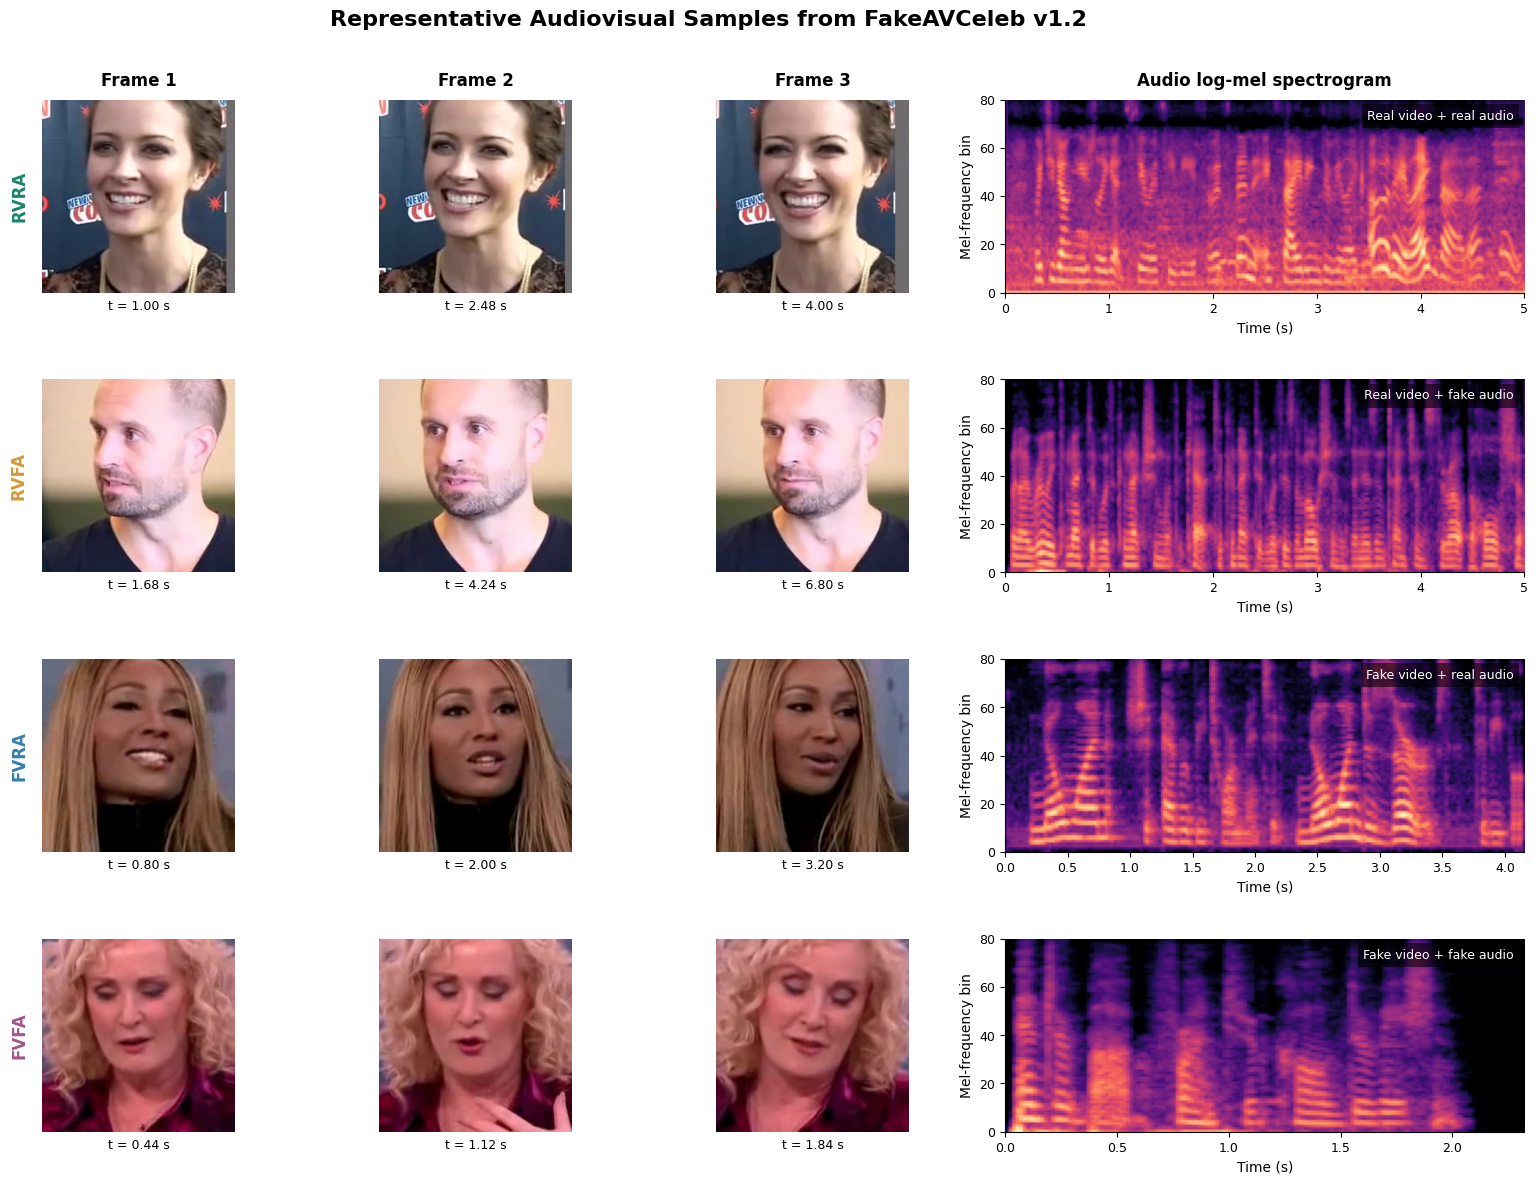


CELL 42 COMPLETED SUCCESSFULLY
Original verified videos: 4
Actual extracted frames: 12
Actual audio spectrograms: 4

Publication PNG: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization/Figure_40A_Actual_FakeAVCeleb_AV_Samples.png
Publication PDF: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization/Figure_40A_Actual_FakeAVCeleb_AV_Samples.pdf
Audit CSV: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization/Cell42_Audiovisual_Figure_Audit.csv
Audit JSON: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization/Cell42_Audiovisual_Figure_Audit.json

No model retraining.
No dataset download.
All source videos SHA-256 verified.


In [ ]:
# =============================================================================
# CELL 42 — PUBLICATION-QUALITY REAL FAKEAVCELEB AUDIOVISUAL FIGURE
# SMD-Net V2 | Scientific Reports
#
# INPUT:
#   Four SHA-256-verified original MP4 files recovered in Cell 41
#
# OUTPUT:
#   Figure_40A_Actual_FakeAVCeleb_AV_Samples.png
#   Figure_40A_Actual_FakeAVCeleb_AV_Samples.pdf
#   Cell42_Audiovisual_Figure_Audit.csv
#   Cell42_Audiovisual_Figure_Audit.json
#
# CPU ONLY | NO TRAINING | NO DATASET DOWNLOAD
# =============================================================================

import sys
import json
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from google.colab import drive

drive.mount("/content/drive")

try:
    import librosa
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install", "librosa"],
        check=True
    )
    import librosa

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

SAMPLES = ROOT / "08_Representative_Dataset_Samples"

METADATA = ROOT / "01_Metadata/fakeavceleb_final_clean_cohort.csv"

OUT = (
    ROOT
    / "06_Results"
    / "Figures"
    / "Final_Publication_Figures"
    / "Dataset_Visualization"
)

OUT.mkdir(parents=True, exist_ok=True)

CATEGORIES = [
    "RVRA",
    "RVFA",
    "FVRA",
    "FVFA"
]

CATEGORY_NAMES = {
    "RVRA": "Real video + real audio",
    "RVFA": "Real video + fake audio",
    "FVRA": "Fake video + real audio",
    "FVFA": "Fake video + fake audio"
}

CATEGORY_FOLDERS = {
    "RVRA": "RealVideo-RealAudio",
    "RVFA": "RealVideo-FakeAudio",
    "FVRA": "FakeVideo-RealAudio",
    "FVFA": "FakeVideo-FakeAudio"
}

CATEGORY_COLORS = {
    "RVRA": "#16866A",
    "RVFA": "#D49A32",
    "FVRA": "#347FAD",
    "FVFA": "#A35688"
}

print("=" * 90)
print("CELL 42 — VERIFIED FAKEAVCELEB AUDIOVISUAL FIGURE")
print("=" * 90)

# ---------------------------------------------------------------------------
# 1. READ FROZEN METADATA AND RECOVERY AUDIT
# ---------------------------------------------------------------------------

df = pd.read_csv(METADATA)

assert len(df) == 21476

audit_path = SAMPLES / "Cell41_Recovery_Audit.csv"

if not audit_path.exists():
    raise FileNotFoundError(
        "Cell 41 recovery audit is missing."
    )

recovery = pd.read_csv(audit_path)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

verified = {}

for category in CATEGORIES:

    rows = recovery[
        (recovery["category"] == category)
        & (recovery["status"].str.startswith("verified"))
    ]

    if len(rows) != 1:
        raise RuntimeError(
            f"Expected one verified file for {category}."
        )

    record = rows.iloc[0]

    rel = str(record["relative_path"])
    path = SAMPLES / rel

    if not path.exists():
        raise FileNotFoundError(path)

    expected = str(record["sha256"]).lower()
    actual = sha256_file(path).lower()

    if actual != expected:
        raise RuntimeError(
            f"SHA-256 verification failed: {category}"
        )

    meta = df[
        df["relative_path"].astype(str) == rel
    ]

    if len(meta) != 1:
        raise RuntimeError(
            f"Metadata lookup ambiguous: {category}"
        )

    metadata_hash = str(
        meta.iloc[0]["sha256"]
    ).lower()

    if metadata_hash != actual:
        raise RuntimeError(
            f"Frozen metadata checksum mismatch: {category}"
        )

    verified[category] = {
        "path": path,
        "relative_path": rel,
        "sha256": actual,
        "split": str(meta.iloc[0]["split"])
    }

    print(
        f"{category}: SHA-256 VERIFIED | "
        f"split={verified[category]['split']}"
    )

# ---------------------------------------------------------------------------
# 2. EXTRACT THREE REAL VIDEO FRAMES
# ---------------------------------------------------------------------------

def extract_frames(video_path):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(
            f"Cannot decode video: {video_path}"
        )

    count = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    fps = float(
        cap.get(cv2.CAP_PROP_FPS)
    )

    if count < 3:
        cap.release()
        raise RuntimeError("Insufficient video frames.")

    indices = np.linspace(
        int(count * 0.2),
        min(count - 1, int(count * 0.8)),
        3
    ).astype(int)

    frames = []

    for index in indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(index)
        )

        success, frame = cap.read()

        if not success:
            cap.release()
            raise RuntimeError(
                f"Cannot read frame {index}"
            )

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frames.append(frame)

    cap.release()

    timestamps = (
        indices / fps
        if fps > 0
        else np.full(3, np.nan)
    )

    return frames, indices, timestamps, fps

# ---------------------------------------------------------------------------
# 3. DECODE GENUINE AUDIO USING FFMPEG
# ---------------------------------------------------------------------------

def extract_audio(video_path, sr=16000):

    cmd = [
        "ffmpeg",
        "-v", "error",
        "-i", str(video_path),
        "-vn",
        "-ac", "1",
        "-ar", str(sr),
        "-t", "5",
        "-f", "f32le",
        "pipe:1"
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        check=False
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"FFmpeg audio extraction failed: {video_path}\n"
            + result.stderr.decode(
                errors="replace"
            )[:500]
        )

    audio = np.frombuffer(
        result.stdout,
        dtype=np.float32
    ).copy()

    if len(audio) < sr // 2:
        raise RuntimeError(
            f"Audio too short or absent: {video_path}"
        )

    return audio, sr

def compute_logmel(audio, sr):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=1024,
        hop_length=256,
        n_mels=80,
        fmin=0,
        fmax=sr / 2,
        power=2.0
    )

    db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return db

# ---------------------------------------------------------------------------
# 4. PROCESS ALL VERIFIED SAMPLES
# ---------------------------------------------------------------------------

processed = {}
audit_records = []

for category in CATEGORIES:

    item = verified[category]

    print(f"\nProcessing {category}...")

    frames, indices, times, fps = extract_frames(
        item["path"]
    )

    audio, sr = extract_audio(
        item["path"]
    )

    spectrogram = compute_logmel(
        audio, sr
    )

    processed[category] = {
        "frames": frames,
        "indices": indices,
        "times": times,
        "spectrogram": spectrogram,
        "sample_rate": sr,
        "audio_duration": len(audio) / sr
    }

    audit_records.append({
        "category": category,
        "description": CATEGORY_NAMES[category],
        "split": item["split"],
        "relative_path": item["relative_path"],
        "sha256": item["sha256"],
        "frame_indices": indices.tolist(),
        "frame_times_seconds": times.tolist(),
        "fps": fps,
        "audio_sample_rate_hz": sr,
        "audio_duration_seconds": len(audio) / sr
    })

# ---------------------------------------------------------------------------
# 5. DRAW FIGURE
# ---------------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, axes = plt.subplots(
    4,
    4,
    figsize=(17, 12),
    gridspec_kw={
        "width_ratios": [1, 1, 1, 1.8],
        "wspace": 0.14,
        "hspace": 0.45
    }
)

for row, category in enumerate(CATEGORIES):

    data = processed[category]

    for col in range(3):

        ax = axes[row, col]

        ax.imshow(
            data["frames"][col]
        )

        ax.axis("off")

        if row == 0:
            ax.set_title(
                f"Frame {col + 1}",
                fontsize=12,
                fontweight="bold",
                pad=10
            )

        timestamp = data["times"][col]

        if np.isfinite(timestamp):
            ax.text(
                0.5,
                -0.035,
                f"t = {timestamp:.2f} s",
                transform=ax.transAxes,
                ha="center",
                va="top",
                fontsize=9
            )

        if col == 0:
            ax.text(
                -0.12,
                0.5,
                category,
                transform=ax.transAxes,
                rotation=90,
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold",
                color=CATEGORY_COLORS[category]
            )

    ax = axes[row, 3]

    spec = data["spectrogram"]

    duration = data["audio_duration"]

    # Mel-frequency bins are not linearly spaced in Hz.
    # Display as mel-bin index to avoid misleading axis labels.
    ax.imshow(
        spec,
        origin="lower",
        aspect="auto",
        extent=[
            0,
            duration,
            0,
            spec.shape[0]
        ],
        cmap="magma",
        vmin=-80,
        vmax=0
    )

    ax.set_xlabel(
        "Time (s)",
        fontsize=10
    )

    ax.set_ylabel(
        "Mel-frequency bin",
        fontsize=10
    )

    if row == 0:
        ax.set_title(
            "Audio log-mel spectrogram",
            fontsize=12,
            fontweight="bold",
            pad=10
        )

    ax.tick_params(
        labelsize=9
    )

    ax.text(
        0.98,
        0.95,
        CATEGORY_NAMES[category],
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        color="white",
        bbox={
            "facecolor": "black",
            "alpha": 0.6,
            "edgecolor": "none",
            "pad": 4
        }
    )

fig.suptitle(
    "Representative Audiovisual Samples from FakeAVCeleb v1.2",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    top=0.92,
    bottom=0.06,
    left=0.08,
    right=0.98
)

png_path = (
    OUT
    / "Figure_40A_Actual_FakeAVCeleb_AV_Samples.png"
)

pdf_path = (
    OUT
    / "Figure_40A_Actual_FakeAVCeleb_AV_Samples.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ---------------------------------------------------------------------------
# 6. SAVE REPRODUCIBILITY AUDIT
# ---------------------------------------------------------------------------

audit_csv = (
    OUT
    / "Cell42_Audiovisual_Figure_Audit.csv"
)

audit_json = (
    OUT
    / "Cell42_Audiovisual_Figure_Audit.json"
)

pd.DataFrame(
    audit_records
).to_csv(
    audit_csv,
    index=False
)

with open(audit_json, "w") as f:
    json.dump(
        {
            "dataset": "FakeAVCeleb v1.2",
            "cohort_size": 21476,
            "source": "Four SHA-256-verified original videos",
            "number_of_categories": 4,
            "frames_per_category": 3,
            "audio_representation": "80-bin log-mel spectrogram",
            "sample_rate_hz": 16000,
            "training_performed": False,
            "dataset_download_performed": False,
            "records": audit_records
        },
        f,
        indent=2
    )

print("\n" + "=" * 90)
print("CELL 42 COMPLETED SUCCESSFULLY")
print("=" * 90)

print("Original verified videos:", 4)
print("Actual extracted frames:", 12)
print("Actual audio spectrograms:", 4)

print("\nPublication PNG:", png_path)
print("Publication PDF:", pdf_path)
print("Audit CSV:", audit_csv)
print("Audit JSON:", audit_json)

print("\nNo model retraining.")
print("No dataset download.")
print("All source videos SHA-256 verified.")
print("=" * 90)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 43 — PUBLICATION-READY FAKEAVCELEB AUDIOVISUAL FIGURE
RVRA: verified | split=test
RVFA: verified | split=test
FVRA: verified | split=test
FVFA: verified | split=test


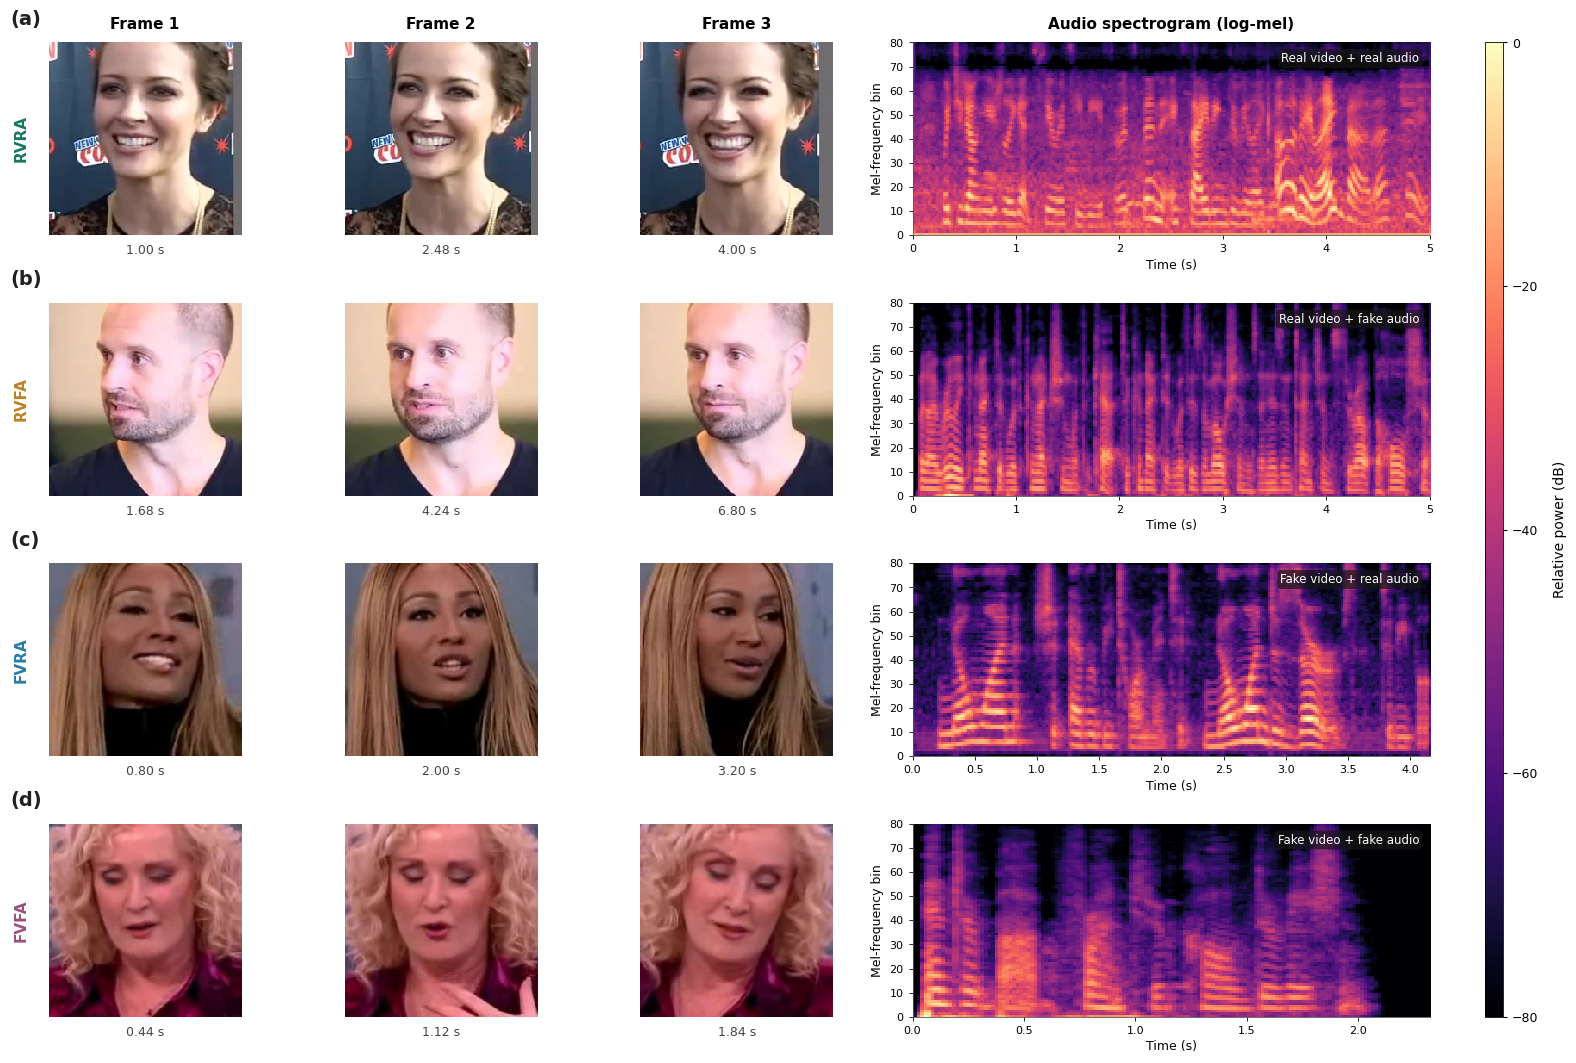


CELL 43 COMPLETED SUCCESSFULLY
Verified original videos: 4
Genuine video frames: 12
Genuine audio spectrograms: 4

Refinements applied:
  [OK] Removed large internal title
  [OK] Added panel labels (a)–(d)
  [OK] Added shared spectrogram color bar
  [OK] Preserved source frame aspect ratios
  [OK] Improved column headings
  [OK] Consistent academic typography
  [OK] High-resolution PNG and vector PDF

PNG: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization/Figure_40A_Refined_Actual_FakeAVCeleb_AV_Samples.png
PDF: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization/Figure_40A_Refined_Actual_FakeAVCeleb_AV_Samples.pdf
Audit CSV: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures/Final_Publication_Figures/Dataset_Visualization/Cell43_Refined_Figure_Audit.csv
Audit JSON: /content/drive/MyDrive/SMDNet_V2_ScientificReports/06_Results/Figures

In [ ]:
# =============================================================================
# CELL 43 — FINAL PUBLICATION REFINEMENT OF FAKEAVCELEB AUDIOVISUAL FIGURE
# SMD-Net V2 | Scientific Reports
#
# INPUT:
#   Four original SHA-256-verified FakeAVCeleb MP4 files from Cell 41
#
# REFINEMENTS:
#   1. Remove large internal figure title
#   2. Add panel labels (a), (b), (c), (d)
#   3. Add shared spectrogram color bar: Relative power (dB)
#   4. Preserve video frame aspect ratios
#   5. Shorten audio column heading
#   6. Consistent typography, spacing, and figure dimensions
#   7. Export high-resolution PNG + vector PDF
#
# CPU ONLY | NO TRAINING | NO DATASET DOWNLOAD
# =============================================================================

import sys
import json
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import cv2

from google.colab import drive

# ---------------------------------------------------------------------------
# 1. MOUNT DRIVE AND IMPORT LIBRARIES
# ---------------------------------------------------------------------------

drive.mount("/content/drive")

try:
    import librosa
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install", "librosa"],
        check=True
    )
    import librosa

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

SAMPLES = ROOT / "08_Representative_Dataset_Samples"

METADATA = ROOT / "01_Metadata/fakeavceleb_final_clean_cohort.csv"

RECOVERY_AUDIT = SAMPLES / "Cell41_Recovery_Audit.csv"

OUT = (
    ROOT
    / "06_Results"
    / "Figures"
    / "Final_Publication_Figures"
    / "Dataset_Visualization"
)

OUT.mkdir(parents=True, exist_ok=True)

CATEGORIES = ["RVRA", "RVFA", "FVRA", "FVFA"]

CATEGORY_INFO = {
    "RVRA": {
        "panel": "(a)",
        "description": "Real video + real audio",
        "color": "#18785F"
    },
    "RVFA": {
        "panel": "(b)",
        "description": "Real video + fake audio",
        "color": "#BD8126"
    },
    "FVRA": {
        "panel": "(c)",
        "description": "Fake video + real audio",
        "color": "#287BA6"
    },
    "FVFA": {
        "panel": "(d)",
        "description": "Fake video + fake audio",
        "color": "#99517C"
    }
}

print("=" * 95)
print("CELL 43 — PUBLICATION-READY FAKEAVCELEB AUDIOVISUAL FIGURE")
print("=" * 95)

# ---------------------------------------------------------------------------
# 2. LOAD AND VERIFY ORIGINAL DATASET FILES
# ---------------------------------------------------------------------------

if not METADATA.exists():
    raise FileNotFoundError(METADATA)

if not RECOVERY_AUDIT.exists():
    raise FileNotFoundError(RECOVERY_AUDIT)

metadata = pd.read_csv(METADATA)
recovery = pd.read_csv(RECOVERY_AUDIT)

assert len(metadata) == 21476, "Frozen cohort size mismatch."

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

verified = {}

for code in CATEGORIES:

    rows = recovery[
        (recovery["category"] == code)
        & (
            recovery["status"]
            .astype(str)
            .str.startswith("verified")
        )
    ]

    if len(rows) != 1:
        raise RuntimeError(
            f"Expected exactly one verified file for {code}."
        )

    row = rows.iloc[0]

    relative_path = str(row["relative_path"])
    video_path = SAMPLES / relative_path

    if not video_path.is_file():
        raise FileNotFoundError(video_path)

    actual_hash = sha256_file(video_path).lower()
    audit_hash = str(row["sha256"]).lower()

    matching_metadata = metadata[
        metadata["relative_path"].astype(str) == relative_path
    ]

    if len(matching_metadata) != 1:
        raise RuntimeError(
            f"Metadata lookup failed for {code}."
        )

    metadata_hash = str(
        matching_metadata.iloc[0]["sha256"]
    ).lower()

    if actual_hash != audit_hash or actual_hash != metadata_hash:
        raise RuntimeError(
            f"SHA-256 verification failed for {code}."
        )

    verified[code] = {
        "path": video_path,
        "relative_path": relative_path,
        "sha256": actual_hash,
        "split": str(matching_metadata.iloc[0]["split"])
    }

    print(f"{code}: verified | split={verified[code]['split']}")

# ---------------------------------------------------------------------------
# 3. EXTRACT REAL VIDEO FRAMES
# ---------------------------------------------------------------------------

def extract_frames(video_path, n_frames=3):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(
            f"Unable to open video: {video_path}"
        )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    fps = float(
        cap.get(cv2.CAP_PROP_FPS)
    )

    if total_frames < n_frames or fps <= 0:
        cap.release()
        raise RuntimeError(
            f"Invalid video frame count or FPS: {video_path}"
        )

    indices = np.linspace(
        int(total_frames * 0.20),
        min(total_frames - 1, int(total_frames * 0.80)),
        n_frames
    ).astype(int)

    frames = []

    for index in indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(index)
        )

        success, frame = cap.read()

        if not success:
            cap.release()
            raise RuntimeError(
                f"Unable to decode frame {index}: {video_path}"
            )

        frames.append(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        )

    cap.release()

    timestamps = indices / fps

    return frames, indices.tolist(), timestamps.tolist(), fps

# ---------------------------------------------------------------------------
# 4. EXTRACT AUDIO AND COMPUTE LOG-MEL SPECTROGRAM
# ---------------------------------------------------------------------------

def extract_audio(video_path, sr=16000, max_duration=5):

    command = [
        "ffmpeg",
        "-v", "error",
        "-i", str(video_path),
        "-vn",
        "-ac", "1",
        "-ar", str(sr),
        "-t", str(max_duration),
        "-f", "f32le",
        "pipe:1"
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        check=False
    )

    if result.returncode != 0:
        raise RuntimeError(
            "FFmpeg failed: "
            + result.stderr.decode(
                "utf-8", errors="replace"
            )[:400]
        )

    audio = np.frombuffer(
        result.stdout,
        dtype=np.float32
    ).copy()

    if len(audio) < sr // 2:
        raise RuntimeError(
            f"Insufficient audio samples: {video_path}"
        )

    if not np.isfinite(audio).all():
        raise RuntimeError(
            f"Invalid audio samples: {video_path}"
        )

    return audio, sr

def make_logmel(audio, sr):

    mel_power = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=1024,
        hop_length=256,
        n_mels=80,
        fmin=0,
        fmax=sr / 2,
        power=2.0
    )

    # Each sample is referenced to its own maximum power.
    mel_db = librosa.power_to_db(
        mel_power,
        ref=np.max,
        top_db=80
    )

    return mel_db

# ---------------------------------------------------------------------------
# 5. PREPARE DATA
# ---------------------------------------------------------------------------

processed = {}
audit_records = []

for code in CATEGORIES:

    item = verified[code]

    frames, indices, times, fps = extract_frames(
        item["path"]
    )

    audio, sr = extract_audio(
        item["path"]
    )

    mel_db = make_logmel(audio, sr)

    processed[code] = {
        "frames": frames,
        "indices": indices,
        "timestamps": times,
        "fps": fps,
        "mel_db": mel_db,
        "sample_rate": sr,
        "audio_duration": len(audio) / sr
    }

    audit_records.append({
        "category": code,
        "panel": CATEGORY_INFO[code]["panel"],
        "description": CATEGORY_INFO[code]["description"],
        "relative_path": item["relative_path"],
        "split": item["split"],
        "sha256": item["sha256"],
        "frame_indices": indices,
        "frame_timestamps_sec": times,
        "fps": fps,
        "audio_duration_sec": len(audio) / sr,
        "audio_sample_rate_hz": sr,
        "mel_bins": 80,
        "mel_db_reference": "Per-sample maximum power"
    })

# ---------------------------------------------------------------------------
# 6. PUBLICATION STYLE
# ---------------------------------------------------------------------------

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

# ---------------------------------------------------------------------------
# 7. DRAW REFINED FIGURE
# ---------------------------------------------------------------------------

fig = plt.figure(figsize=(16.8, 11.2), facecolor="white")

# Fifth column reserved for a shared color bar.
gs = fig.add_gridspec(
    nrows=4,
    ncols=5,
    width_ratios=[1.0, 1.0, 1.0, 2.15, 0.075],
    left=0.085,
    right=0.965,
    top=0.935,
    bottom=0.065,
    wspace=0.22,
    hspace=0.35
)

last_image = None

for row_index, code in enumerate(CATEGORIES):

    data = processed[code]
    info = CATEGORY_INFO[code]

    # -----------------------------------------------------------------------
    # VIDEO FRAME PANELS
    # -----------------------------------------------------------------------

    for col_index in range(3):

        ax = fig.add_subplot(
            gs[row_index, col_index]
        )

        frame = data["frames"][col_index]

        # Matplotlib preserves the source frame aspect ratio.
        ax.imshow(
            frame,
            aspect="equal",
            interpolation="nearest"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

        if row_index == 0:
            ax.set_title(
                f"Frame {col_index + 1}",
                fontweight="bold",
                pad=10
            )

        timestamp = data["timestamps"][col_index]

        ax.text(
            0.5,
            -0.045,
            f"{timestamp:.2f} s",
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9,
            color="#454545"
        )

        if col_index == 0:

            # Panel label outside the image.
            ax.text(
                -0.20,
                1.07,
                info["panel"],
                transform=ax.transAxes,
                ha="left",
                va="bottom",
                fontsize=14,
                fontweight="bold",
                color="#202020"
            )

            # Category label, positioned outside the frame.
            ax.text(
                -0.14,
                0.5,
                code,
                transform=ax.transAxes,
                rotation=90,
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=info["color"]
            )

    # -----------------------------------------------------------------------
    # AUDIO SPECTROGRAM
    # -----------------------------------------------------------------------

    ax_spec = fig.add_subplot(
        gs[row_index, 3]
    )

    mel_db = data["mel_db"]
    duration = data["audio_duration"]

    last_image = ax_spec.imshow(
        mel_db,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        extent=[
            0,
            duration,
            0,
            mel_db.shape[0]
        ],
        cmap="magma",
        vmin=-80,
        vmax=0
    )

    ax_spec.set_xlabel(
        "Time (s)",
        labelpad=3
    )

    ax_spec.set_ylabel(
        "Mel-frequency bin",
        labelpad=4
    )

    ax_spec.tick_params(
        axis="both",
        length=3,
        width=0.6
    )

    for spine in ax_spec.spines.values():
        spine.set_linewidth(0.6)
        spine.set_color("#555555")

    if row_index == 0:
        ax_spec.set_title(
            "Audio spectrogram (log-mel)",
            fontweight="bold",
            pad=10
        )

    # Description inside top-right corner of spectrogram.
    ax_spec.text(
        0.98,
        0.95,
        info["description"],
        transform=ax_spec.transAxes,
        ha="right",
        va="top",
        fontsize=8.5,
        color="white",
        bbox={
            "facecolor": "#161616",
            "alpha": 0.70,
            "edgecolor": "none",
            "boxstyle": "round,pad=0.25"
        }
    )

# ---------------------------------------------------------------------------
# 8. SHARED COLOR BAR
# ---------------------------------------------------------------------------

cax = fig.add_subplot(gs[:, 4])

cbar = fig.colorbar(
    last_image,
    cax=cax,
    orientation="vertical"
)

cbar.set_label(
    "Relative power (dB)",
    rotation=90,
    labelpad=10,
    fontsize=10
)

cbar.set_ticks(
    [-80, -60, -40, -20, 0]
)

cbar.ax.tick_params(
    labelsize=9,
    length=3
)

cbar.outline.set_linewidth(0.6)

# ---------------------------------------------------------------------------
# 9. SAVE PUBLICATION FILES
# ---------------------------------------------------------------------------

PNG = (
    OUT
    / "Figure_40A_Refined_Actual_FakeAVCeleb_AV_Samples.png"
)

PDF = (
    OUT
    / "Figure_40A_Refined_Actual_FakeAVCeleb_AV_Samples.pdf"
)

fig.savefig(
    PNG,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.10,
    facecolor="white"
)

fig.savefig(
    PDF,
    bbox_inches="tight",
    pad_inches=0.10,
    facecolor="white"
)

plt.show()
plt.close(fig)

# ---------------------------------------------------------------------------
# 10. SAVE AUDIT AND FINAL STATUS
# ---------------------------------------------------------------------------

AUDIT_CSV = OUT / "Cell43_Refined_Figure_Audit.csv"
AUDIT_JSON = OUT / "Cell43_Refined_Figure_Audit.json"

pd.DataFrame(
    audit_records
).to_csv(
    AUDIT_CSV,
    index=False
)

with open(AUDIT_JSON, "w") as f:
    json.dump(
        {
            "figure": "Figure 40A — Refined audiovisual samples",
            "dataset": "FakeAVCeleb v1.2",
            "cohort_size": 21476,
            "source_files_sha256_verified": True,
            "category_count": 4,
            "frames_per_category": 3,
            "audio_sample_rate_hz": 16000,
            "spectrogram_mel_bins": 80,
            "spectrogram_reference": "Maximum power per sample",
            "spectrogram_color_range_db": [-80, 0],
            "dataset_download_performed": False,
            "model_training_performed": False,
            "png": str(PNG),
            "pdf": str(PDF),
            "records": audit_records
        },
        f,
        indent=2
    )

print("\n" + "=" * 95)
print("CELL 43 COMPLETED SUCCESSFULLY")
print("=" * 95)

print("Verified original videos: 4")
print("Genuine video frames: 12")
print("Genuine audio spectrograms: 4")

print("\nRefinements applied:")
print("  [OK] Removed large internal title")
print("  [OK] Added panel labels (a)–(d)")
print("  [OK] Added shared spectrogram color bar")
print("  [OK] Preserved source frame aspect ratios")
print("  [OK] Improved column headings")
print("  [OK] Consistent academic typography")
print("  [OK] High-resolution PNG and vector PDF")

print("\nPNG:", PNG)
print("PDF:", PDF)
print("Audit CSV:", AUDIT_CSV)
print("Audit JSON:", AUDIT_JSON)

print("\nNo training, no GPU, no dataset download.")
print("=" * 95)

In [ ]:
# =============================================================================
# CELL 44 — EXPORT ALL SMD-NET V2 PUBLICATION RESULTS
# Scientific Reports | Figures + Tables + Statistical Results
#
# NO TRAINING | NO GPU | NO DATASET DOWNLOAD
# =============================================================================

import os
import json
import shutil
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
from google.colab import drive, files

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

FIGURES = ROOT / "06_Results/Figures"
TABLES = ROOT / "06_Results/Tables"

EXPORT = ROOT / "09_Manuscript_Submission_Package"
EXPORT.mkdir(parents=True, exist_ok=True)

PACKAGE = EXPORT / "SMDNet_V2_All_Publication_Results"

if PACKAGE.exists():
    shutil.rmtree(PACKAGE)

PACKAGE.mkdir(parents=True)

# ---------------------------------------------------------------------------
# 1. ORGANIZE MANUSCRIPT MATERIALS
# ---------------------------------------------------------------------------

DESTINATIONS = {
    "01_Figures": FIGURES,
    "02_Tables": TABLES
}

ALLOWED_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".tif", ".tiff",
    ".pdf", ".svg", ".eps",
    ".csv", ".xlsx", ".xls",
    ".json", ".txt"
}

manifest = []
missing = []

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

for folder_name, source in DESTINATIONS.items():

    destination = PACKAGE / folder_name
    destination.mkdir(parents=True, exist_ok=True)

    if not source.exists():
        missing.append(str(source))
        continue

    for item in sorted(source.rglob("*")):

        if not item.is_file():
            continue

        if item.suffix.lower() not in ALLOWED_EXTENSIONS:
            continue

        relative = item.relative_to(source)
        target = destination / relative

        target.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        shutil.copy2(item, target)

        manifest.append({
            "category": folder_name,
            "filename": item.name,
            "package_path": str(
                target.relative_to(PACKAGE)
            ),
            "source_path": str(item),
            "size_bytes": item.stat().st_size,
            "sha256": file_sha256(item)
        })

# ---------------------------------------------------------------------------
# 2. INCLUDE IMPORTANT EXPERIMENTAL AUDITS
# ---------------------------------------------------------------------------

AUDIT_FILES = [
    ROOT / "07_Logs/smdnet_v2_cell35_recovered_analysis.json",
    ROOT / "08_Representative_Dataset_Samples/Cell41_Recovery_Audit.csv",
    ROOT / "08_Representative_Dataset_Samples/Cell41_Recovery_Audit.json"
]

audit_destination = PACKAGE / "03_Reproducibility_Audits"
audit_destination.mkdir(exist_ok=True)

for source in AUDIT_FILES:

    if not source.exists():
        missing.append(str(source))
        continue

    target = audit_destination / source.name

    shutil.copy2(source, target)

    manifest.append({
        "category": "03_Reproducibility_Audits",
        "filename": source.name,
        "package_path": str(
            target.relative_to(PACKAGE)
        ),
        "source_path": str(source),
        "size_bytes": source.stat().st_size,
        "sha256": file_sha256(source)
    })

# ---------------------------------------------------------------------------
# 3. GENERATE FILE MANIFEST
# ---------------------------------------------------------------------------

manifest_df = pd.DataFrame(manifest)

manifest_csv = PACKAGE / "Publication_Results_Manifest.csv"

manifest_df.to_csv(
    manifest_csv,
    index=False
)

summary = {
    "project": "SMD-Net V2",
    "journal": "Scientific Reports",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "files_included": len(manifest),
    "figures": sum(
        item["category"] == "01_Figures"
        for item in manifest
    ),
    "tables": sum(
        item["category"] == "02_Tables"
        for item in manifest
    ),
    "audits": sum(
        item["category"] == "03_Reproducibility_Audits"
        for item in manifest
    ),
    "missing_optional_paths": missing,
    "training_performed": False,
    "dataset_download_performed": False
}

with open(
    PACKAGE / "Package_Summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=2)

# ---------------------------------------------------------------------------
# 4. CREATE DOWNLOADABLE ZIP
# ---------------------------------------------------------------------------

ZIP_PATH = EXPORT / "SMDNet_V2_All_Publication_Results.zip"

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as zf:

    for item in sorted(PACKAGE.rglob("*")):

        if item.is_file():
            zf.write(
                item,
                arcname=str(
                    item.relative_to(PACKAGE)
                )
            )

# ---------------------------------------------------------------------------
# 5. VERIFY ZIP
# ---------------------------------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    bad_file = zf.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP integrity failed: {bad_file}"
        )

    zip_members = zf.namelist()

print("=" * 90)
print("SMD-NET V2 — PUBLICATION RESULTS EXPORT")
print("=" * 90)

print("Files packaged:", len(manifest))
print("Figure files:", summary["figures"])
print("Table files:", summary["tables"])
print("Audit files:", summary["audits"])

print("\nZIP:", ZIP_PATH)
print("ZIP size (MB):", round(
    ZIP_PATH.stat().st_size / (1024 ** 2), 2
))

print("\nMissing optional files:", len(missing))

for path in missing:
    print(" -", path)

print("\nZIP integrity: VERIFIED")
print("Model training: NO")
print("Dataset download: NO")

print("=" * 90)

# ---------------------------------------------------------------------------
# 6. DOWNLOAD ZIP TO YOUR COMPUTER
# ---------------------------------------------------------------------------

files.download(str(ZIP_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SMD-NET V2 — PUBLICATION RESULTS EXPORT
Files packaged: 120
Figure files: 34
Table files: 83
Audit files: 3

ZIP: /content/drive/MyDrive/SMDNet_V2_ScientificReports/09_Manuscript_Submission_Package/SMDNet_V2_All_Publication_Results.zip
ZIP size (MB): 12.59

Missing optional files: 0

ZIP integrity: VERIFIED
Model training: NO
Dataset download: NO


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =============================================================================
# CELL 45 — COMPLETE RUNTIME RECOVERY + CODEC NORMALIZATION
# SMD-Net V2 | Scientific Reports
#
# INCLUDES:
#  1. Mount Google Drive
#  2. Install required packages
#  3. Verify frozen dataset metadata
#  4. Recover or create a deterministic 48-video test cohort
#  5. Download only missing original videos from FakeAVCeleb
#  6. Verify original SHA-256 checksums
#  7. Normalize audiovisual encoding to H.264 CRF18 + AAC
#  8. Validate output streams and save reproducibility records
#  9. Resume safely after runtime disconnection
#
# CPU ONLY | NO MODEL TRAINING | NO FULL DATASET DOWNLOAD
# =============================================================================

import sys
import subprocess
import hashlib
import json
import shutil
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

from google.colab import drive

# ---------------------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ---------------------------------------------------------------------------

print("=" * 95)
print("STEP 1 — GOOGLE DRIVE MOUNTING")
print("=" * 95)

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Project directory not found: {ROOT}"
    )

print("Project directory verified:", ROOT)

# ---------------------------------------------------------------------------
# 2. INSTALL AND VERIFY DEPENDENCIES
# ---------------------------------------------------------------------------

print("\nSTEP 2 — VERIFYING DEPENDENCIES")

try:
    import kagglehub
except ImportError:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "-q",
            "install",
            "kagglehub"
        ],
        check=True
    )
    import kagglehub

ffmpeg_check = subprocess.run(
    ["ffmpeg", "-version"],
    capture_output=True,
    text=True
)

if ffmpeg_check.returncode != 0:
    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "ffmpeg"],
        check=True
    )

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("KaggleHub: available")
print("FFmpeg: available")

# ---------------------------------------------------------------------------
# 3. PROJECT PATHS
# ---------------------------------------------------------------------------

META = (
    ROOT
    / "01_Metadata"
    / "fakeavceleb_final_clean_cohort.csv"
)

OUT = ROOT / "10_Codec_Normalization_Experiment"

ORIGINAL = OUT / "Original"

NORMALIZED = (
    OUT
    / "Normalized_H264_CRF18_AAC"
)

LOGS = OUT / "Logs"

RECOVERED = (
    ROOT
    / "08_Representative_Dataset_Samples"
)

for directory in [
    ORIGINAL,
    NORMALIZED,
    LOGS
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

SELECTION_FILE = (
    LOGS
    / "Cell45_Frozen_Cohort_Selection.csv"
)

MANIFEST_FILE = (
    LOGS
    / "Cell45_Processing_Manifest.csv"
)

SUMMARY_FILE = (
    LOGS
    / "Cell45_Experiment_Summary.json"
)

HANDLE = "shreyaty08/fakeavceleb/versions/1"

PREFIX = "FakeAVCeleb_v1.2/FakeAVCeleb_v1.2"

CATEGORIES = {
    "RVRA": "RealVideo-RealAudio",
    "RVFA": "RealVideo-FakeAudio",
    "FVRA": "FakeVideo-RealAudio",
    "FVFA": "FakeVideo-FakeAudio"
}

N_PER_CATEGORY = 12
SEED = 20261010

# ---------------------------------------------------------------------------
# 4. VERIFY FROZEN DATASET METADATA
# ---------------------------------------------------------------------------

print("\nSTEP 3 — LOADING FROZEN DATASET METADATA")

if not META.is_file():
    raise FileNotFoundError(
        f"Frozen metadata missing: {META}"
    )

df = pd.read_csv(META)

required_columns = [
    "relative_path",
    "sha256",
    "split",
    "category_inventory"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        "Missing metadata columns: "
        + str(missing_columns)
    )

if len(df) != 21476:
    raise ValueError(
        f"Unexpected cohort size: {len(df)}"
    )

def normalize_category(value):

    value = str(value).strip().lower()

    for code, folder in CATEGORIES.items():

        if value in [
            code.lower(),
            folder.lower()
        ]:
            return code

    return None

df["_category"] = (
    df["category_inventory"]
    .map(normalize_category)
)

test = df[
    df["split"]
    .astype(str)
    .str.strip()
    .str.lower() == "test"
].copy()

if len(test) != 3174:
    raise ValueError(
        f"Unexpected test-set size: {len(test)}"
    )

print("Frozen cohort:", len(df))
print("Test videos:", len(test))

print("\nTest category distribution:")
print(
    test["_category"]
    .value_counts()
    .reindex(CATEGORIES.keys(), fill_value=0)
    .to_string()
)

# ---------------------------------------------------------------------------
# 5. CHECKSUM AND SAFE-PATH UTILITIES
# ---------------------------------------------------------------------------

def safe_relative_path(value):

    text = str(value).replace("\\", "/")

    path = Path(text)

    if (
        path.is_absolute()
        or ".." in path.parts
        or not path.parts
    ):
        raise ValueError(
            f"Unsafe dataset path: {value}"
        )

    return path

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()

def verified(path, expected):

    if not path.is_file():
        return False

    return (
        sha256_file(path).lower()
        == str(expected).lower()
    )

# ---------------------------------------------------------------------------
# 6. RESTORE EXISTING SELECTION OR CREATE A NEW ONE
# ---------------------------------------------------------------------------

print("\nSTEP 4 — RESTORING OR SELECTING TEST COHORT")

if SELECTION_FILE.is_file():

    selected = pd.read_csv(
        SELECTION_FILE
    )

    print("Existing frozen selection restored.")

else:

    selected_parts = []

    for code in CATEGORIES:

        subset = test[
            test["_category"] == code
        ].copy()

        existing_mask = subset[
            "relative_path"
        ].apply(
            lambda x: (
                RECOVERED
                / safe_relative_path(x)
            ).is_file()
        )

        existing = subset[
            existing_mask
        ].sort_values("relative_path")

        chosen_existing = existing.head(1)

        remaining = subset.drop(
            chosen_existing.index
        )

        sampled = remaining.sample(
            n=(
                N_PER_CATEGORY
                - len(chosen_existing)
            ),
            random_state=SEED,
            replace=False
        )

        chosen = pd.concat(
            [
                chosen_existing,
                sampled
            ]
        )

        selected_parts.append(chosen)

    selected = pd.concat(
        selected_parts,
        ignore_index=True
    )

    selected.to_csv(
        SELECTION_FILE,
        index=False
    )

    print("New frozen selection created.")

if len(selected) != 48:
    raise ValueError(
        "Selection must contain exactly 48 videos."
    )

if selected["relative_path"].duplicated().any():
    raise ValueError(
        "Duplicate videos in selection."
    )

selected["_category"] = (
    selected["category_inventory"]
    .map(normalize_category)
)

counts = (
    selected["_category"]
    .value_counts()
    .reindex(CATEGORIES.keys(), fill_value=0)
)

if not (counts == 12).all():
    raise ValueError(
        "Selection is not balanced across categories."
    )

# Verify that restored selection still matches frozen metadata.
metadata_lookup = (
    test.set_index("relative_path")
)

for _, row in selected.iterrows():

    rel = str(row["relative_path"])

    if rel not in metadata_lookup.index:
        raise ValueError(
            f"Selected video not in frozen test set: {rel}"
        )

    frozen_hash = str(
        metadata_lookup.loc[rel, "sha256"]
    ).lower()

    if str(row["sha256"]).lower() != frozen_hash:
        raise ValueError(
            f"Frozen checksum mismatch: {rel}"
        )

print("\nSelected cohort:")
print(counts.to_string())

# ---------------------------------------------------------------------------
# 7. SELECTIVE ORIGINAL VIDEO RECOVERY
# ---------------------------------------------------------------------------

def recover_original(row):

    relative = safe_relative_path(
        row["relative_path"]
    )

    expected_hash = str(
        row["sha256"]
    ).lower()

    destination = ORIGINAL / relative

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # A. Already stored in experiment directory.
    if verified(
        destination,
        expected_hash
    ):
        return destination, "existing_experiment_file"

    # B. Previously recovered representative sample.
    previous = RECOVERED / relative

    if verified(
        previous,
        expected_hash
    ):

        shutil.copy2(
            previous,
            destination
        )

        if not verified(
            destination,
            expected_hash
        ):
            raise RuntimeError(
                "Copied original failed checksum verification."
            )

        return destination, "previously_recovered"

    # C. Download only this particular original MP4.
    remote_path = (
        PREFIX
        + "/"
        + relative.as_posix()
    )

    downloaded = Path(
        kagglehub.dataset_download(
            HANDLE,
            path=remote_path
        )
    )

    if not downloaded.is_file():
        raise RuntimeError(
            f"Selective download did not return a file: {remote_path}"
        )

    if not verified(
        downloaded,
        expected_hash
    ):
        raise RuntimeError(
            f"Original file checksum mismatch: {remote_path}"
        )

    shutil.copy2(
        downloaded,
        destination
    )

    if not verified(
        destination,
        expected_hash
    ):
        raise RuntimeError(
            "Downloaded file failed Drive-copy verification."
        )

    return destination, "selective_kaggle_download"

# ---------------------------------------------------------------------------
# 8. FFPROBE VALIDATION
# ---------------------------------------------------------------------------

def probe_media(path):

    command = [
        "ffprobe",
        "-v", "error",
        "-show_entries",
        (
            "stream=index,codec_type,codec_name,"
            "width,height,sample_rate,channels"
        ),
        "-of", "json",
        str(path)
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"FFprobe failed: {path}"
        )

    return json.loads(
        result.stdout
    )

def validate_normalized(path):

    if (
        not path.is_file()
        or path.stat().st_size == 0
    ):
        return False

    try:

        probe = probe_media(path)

        streams = probe.get(
            "streams",
            []
        )

        video = [
            s for s in streams
            if s.get("codec_type") == "video"
        ]

        audio = [
            s for s in streams
            if s.get("codec_type") == "audio"
        ]

        if len(video) != 1 or len(audio) != 1:
            return False

        if video[0].get("codec_name") != "h264":
            return False

        if audio[0].get("codec_name") != "aac":
            return False

        if int(
            audio[0].get("sample_rate", 0)
        ) != 16000:
            return False

        if int(
            audio[0].get("channels", 0)
        ) != 1:
            return False

        return True

    except Exception:
        return False

# ---------------------------------------------------------------------------
# 9. AUDIOVISUAL ENCODING NORMALIZATION
# ---------------------------------------------------------------------------

def normalize_video(source, destination):

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    if validate_normalized(destination):
        return "already_normalized"

    temporary = destination.with_name(
        destination.stem
        + ".temporary.mp4"
    )

    if temporary.exists():
        temporary.unlink()

    command = [
        "ffmpeg",
        "-hide_banner",
        "-loglevel", "error",
        "-y",
        "-i", str(source),

        "-map", "0:v:0",
        "-map", "0:a:0",

        "-c:v", "libx264",
        "-preset", "medium",
        "-crf", "18",
        "-pix_fmt", "yuv420p",

        "-c:a", "aac",
        "-b:a", "192k",
        "-ar", "16000",
        "-ac", "1",

        "-map_metadata", "-1",
        "-movflags", "+faststart",

        str(temporary)
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    if result.returncode != 0:

        if temporary.exists():
            temporary.unlink()

        raise RuntimeError(
            "FFmpeg error: "
            + result.stderr[-1000:]
        )

    if not validate_normalized(temporary):

        if temporary.exists():
            temporary.unlink()

        raise RuntimeError(
            "Normalized video failed stream validation."
        )

    temporary.replace(destination)

    return "newly_normalized"

# ---------------------------------------------------------------------------
# 10. PROCESS OR RESUME ALL 48 VIDEOS
# ---------------------------------------------------------------------------

print("\nSTEP 5 — RECOVERING AND NORMALIZING VIDEOS")

previous_records = {}

if MANIFEST_FILE.is_file():

    previous_manifest = pd.read_csv(
        MANIFEST_FILE
    )

    for _, record in previous_manifest.iterrows():

        previous_records[
            str(record["relative_path"])
        ] = record.to_dict()

records = []

for i, row in selected.iterrows():

    code = row["_category"]

    relative = safe_relative_path(
        row["relative_path"]
    )

    print(
        f"\n[{i+1:02d}/48] "
        f"{code} | {relative.name}"
    )

    original_path = ORIGINAL / relative

    normalized_path = NORMALIZED / relative

    expected_hash = str(
        row["sha256"]
    ).lower()

    record = {
        "category": code,
        "split": "test",
        "relative_path": relative.as_posix(),
        "expected_sha256": expected_hash,
        "original_path": str(original_path),
        "normalized_path": str(normalized_path),
        "original_sha256_verified": False,
        "original_recovery_method": "",
        "normalization_action": "",
        "normalized_sha256": "",
        "status": "pending",
        "error": ""
    }

    try:

        source, recovery_method = recover_original(
            row
        )

        record[
            "original_recovery_method"
        ] = recovery_method

        record[
            "original_sha256_verified"
        ] = True

        action = normalize_video(
            source,
            normalized_path
        )

        record[
            "normalization_action"
        ] = action

        record[
            "normalized_sha256"
        ] = sha256_file(normalized_path)

        record["status"] = "complete"

        print(
            "  Original: SHA-256 verified"
        )

        print(
            "  Normalized: H.264 + AAC verified"
        )

        print(
            "  Action:", action
        )

    except Exception as error:

        record["status"] = "failed"

        record["error"] = str(error)[:1000]

        print(
            "  FAILED:", record["error"]
        )

    records.append(record)

    # Persist all progress after each processed file.
    pd.DataFrame(records).to_csv(
        MANIFEST_FILE,
        index=False
    )

# ---------------------------------------------------------------------------
# 11. FINAL VERIFICATION
# ---------------------------------------------------------------------------

print("\nSTEP 6 — FINAL VERIFICATION")

results = pd.DataFrame(records)

complete = results[
    results["status"] == "complete"
]

failed = results[
    results["status"] == "failed"
]

category_counts = (
    complete["category"]
    .value_counts()
    .reindex(CATEGORIES.keys(), fill_value=0)
)

summary = {
    "experiment": (
        "Paired audiovisual encoding normalization"
    ),
    "project": "SMD-Net V2",
    "target_journal": "Scientific Reports",
    "dataset": "FakeAVCeleb v1.2",
    "frozen_cohort_size": 21476,
    "frozen_test_size": 3174,
    "selection_seed": SEED,
    "selected_videos": 48,
    "completed_videos": int(len(complete)),
    "failed_videos": int(len(failed)),
    "completed_by_category": {
        k: int(v)
        for k, v in category_counts.items()
    },
    "video_codec": "H.264",
    "video_crf": 18,
    "video_preset": "medium",
    "audio_codec": "AAC",
    "audio_bitrate": "192k",
    "audio_sample_rate_hz": 16000,
    "audio_channels": 1,
    "original_sha256_verified": bool(
        complete["original_sha256_verified"].all()
    ) if len(complete) else False,
    "interpretation_note": (
        "This experiment changes both video and audio "
        "encoding. Prediction differences cannot be "
        "attributed exclusively to video codec effects."
    ),
    "model_training_performed": False,
    "full_dataset_download_performed": False,
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

with open(
    SUMMARY_FILE,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

print("\n" + "=" * 95)
print("CELL 45 — FINAL EXPERIMENT SUMMARY")
print("=" * 95)

print("Selected:", 48)
print("Completed:", len(complete))
print("Failed:", len(failed))

print("\nCompleted per category:")
print(category_counts.to_string())

print("\nManifest:")
print(MANIFEST_FILE)

print("\nSummary:")
print(SUMMARY_FILE)

if len(failed):

    print("\nFailed files:")

    print(
        failed[
            [
                "category",
                "relative_path",
                "error"
            ]
        ].to_string(index=False)
    )

if len(complete) == 48:

    print("\nSUCCESS: All 48 paired videos are ready.")
    print("Next: Full SSL and NoSSL frozen-model inference.")

else:

    print(
        "\nINCOMPLETE: Re-run this same cell "
        "to retry failed videos."
    )

print("\nNo training was performed.")
print("=" * 95)

STEP 1 — GOOGLE DRIVE MOUNTING
Mounted at /content/drive
Project directory verified: /content/drive/MyDrive/SMDNet_V2_ScientificReports

STEP 2 — VERIFYING DEPENDENCIES
Pandas: 2.2.3
NumPy: 2.1.3
KaggleHub: available
FFmpeg: available

STEP 3 — LOADING FROZEN DATASET METADATA
Frozen cohort: 21476
Test videos: 3174

Test category distribution:
_category
RVRA      72
RVFA      75
FVRA    1444
FVFA    1583

STEP 4 — RESTORING OR SELECTING TEST COHORT
Existing frozen selection restored.

Selected cohort:
_category
RVRA    12
RVFA    12
FVRA    12
FVFA    12

STEP 5 — RECOVERING AND NORMALIZING VIDEOS

[01/48] RVRA | 00052.mp4
  Original: SHA-256 verified
  Normalized: H.264 + AAC verified
  Action: already_normalized

[02/48] RVRA | 00015.mp4
  Original: SHA-256 verified
  Normalized: H.264 + AAC verified
  Action: already_normalized

[03/48] RVRA | 00138.mp4
  Original: SHA-256 verified
  Normalized: H.264 + AAC verified
  Action: already_normalized

[04/48] RVRA | 00160.mp4
  Original: S

In [ ]:
# =============================================================================
# CELL 46 — AUTOMATIC RECOVERY AND INFERENCE-READINESS AUDIT
# SMD-Net V2 | Scientific Reports
#
# STANDALONE AFTER CELL 45
# CPU ONLY | NO TRAINING | NO DATASET DOWNLOAD
# =============================================================================

import os
import json
import hashlib
import subprocess
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
EXP = ROOT / "10_Codec_Normalization_Experiment"
LOGS = EXP / "Logs"

LOGS.mkdir(parents=True, exist_ok=True)

MANIFEST = LOGS / "Cell45_Processing_Manifest.csv"
REPORT_JSON = LOGS / "Cell46_Inference_Readiness_Report.json"
REPORT_CSV = LOGS / "Cell46_Model_Artifact_Inventory.csv"

if not ROOT.is_dir():
    raise FileNotFoundError(f"Project not found: {ROOT}")

if not MANIFEST.is_file():
    raise FileNotFoundError(
        "Cell 45 manifest not found. Run Cell 45 before Cell 46."
    )

df = pd.read_csv(MANIFEST)

required = [
    "category", "relative_path", "expected_sha256",
    "original_path", "normalized_path", "status"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Manifest missing columns: {missing}")

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def probe(path):
    result = subprocess.run(
        [
            "ffprobe", "-v", "error",
            "-show_entries",
            "stream=codec_type,codec_name,sample_rate,channels",
            "-of", "json", str(path)
        ],
        capture_output=True,
        text=True
    )
    if result.returncode:
        return None
    return json.loads(result.stdout)

print("=" * 85)
print("CELL 46 — MODEL AND PAIRED-MEDIA READINESS")
print("=" * 85)

media_checks = []

for _, row in df.iterrows():
    original = Path(str(row["original_path"]))
    normalized = Path(str(row["normalized_path"]))
    expected = str(row["expected_sha256"]).lower()

    original_ok = (
        original.is_file()
        and sha256_file(original).lower() == expected
    )

    normalized_ok = False

    if normalized.is_file() and normalized.stat().st_size > 0:
        info = probe(normalized)
        if info:
            streams = info.get("streams", [])
            v = [s for s in streams if s.get("codec_type") == "video"]
            a = [s for s in streams if s.get("codec_type") == "audio"]
            normalized_ok = (
                len(v) == 1 and len(a) == 1
                and v[0].get("codec_name") == "h264"
                and a[0].get("codec_name") == "aac"
                and str(a[0].get("sample_rate")) == "16000"
                and int(a[0].get("channels", 0)) == 1
            )

    media_checks.append({
        "category": row["category"],
        "relative_path": row["relative_path"],
        "original_verified": original_ok,
        "normalized_verified": normalized_ok,
        "paired_ready": original_ok and normalized_ok
    })

media_df = pd.DataFrame(media_checks)

media_df.to_csv(
    LOGS / "Cell46_Paired_Media_Verification.csv",
    index=False
)

# Discover checkpoint and source files without loading models.
checkpoint_extensions = {".pt", ".pth", ".ckpt", ".safetensors"}
source_extensions = {".ipynb", ".py"}
artifact_extensions = checkpoint_extensions | source_extensions

skip_dirs = {
    "Original",
    "Normalized_H264_CRF18_AAC",
    ".ipynb_checkpoints",
    "__pycache__"
}

artifacts = []

for directory, subdirs, filenames in os.walk(ROOT):
    subdirs[:] = [
        d for d in subdirs
        if d not in skip_dirs
    ]

    for filename in filenames:
        path = Path(directory) / filename

        if path.suffix.lower() not in artifact_extensions:
            continue

        artifacts.append({
            "file": filename,
            "relative_path": str(path.relative_to(ROOT)),
            "type": (
                "checkpoint"
                if path.suffix.lower() in checkpoint_extensions
                else "source"
            ),
            "size_mb": round(path.stat().st_size / 1048576, 3)
        })

artifact_df = pd.DataFrame(
    artifacts,
    columns=["file", "relative_path", "type", "size_mb"]
)

artifact_df.to_csv(REPORT_CSV, index=False)

checkpoint_count = int(
    (artifact_df["type"] == "checkpoint").sum()
)

source_count = int(
    (artifact_df["type"] == "source").sum()
)

ready_count = int(media_df["paired_ready"].sum())

report = {
    "project": "SMD-Net V2",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "selected_videos": int(len(df)),
    "verified_paired_videos": ready_count,
    "checkpoint_files_found": checkpoint_count,
    "source_files_found": source_count,
    "full_ssl_frozen_threshold": 0.75732421875,
    "nossl_frozen_threshold": 0.556396484375,
    "thresholds_source": "Previously frozen experimental results",
    "inference_executed": False,
    "model_predictions_generated": False,
    "next_requirement": (
        "Identify and verify the exact saved model architecture, "
        "checkpoint, audiovisual preprocessing, five-window "
        "aggregation and video-level prediction procedure."
    ),
    "artifacts": artifacts
}

with open(REPORT_JSON, "w") as f:
    json.dump(report, f, indent=2)

print(f"\nSelected videos: {len(df)}")
print(f"Verified original + normalized pairs: {ready_count}")
print(f"Checkpoint files found: {checkpoint_count}")
print(f"Python/notebook source files found: {source_count}")

print("\nCheckpoint inventory:")
if checkpoint_count:
    print(
        artifact_df[
            artifact_df["type"] == "checkpoint"
        ].to_string(index=False)
    )
else:
    print("No checkpoint files discovered.")

print("\nSource inventory:")
if source_count:
    print(
        artifact_df[
            artifact_df["type"] == "source"
        ].to_string(index=False)
    )
else:
    print("No source files discovered.")

print("\nReadiness report:", REPORT_JSON)
print("Artifact inventory:", REPORT_CSV)

if ready_count != 48:
    print(
        "\nACTION REQUIRED: Some paired videos are missing. "
        "Rerun Cell 45."
    )
elif checkpoint_count == 0:
    print(
        "\nACTION REQUIRED: Locate the trained checkpoints "
        "before running inference."
    )
else:
    print(
        "\nMEDIA READY. Checkpoint files were discovered. "
        "The exact inference code must still be verified "
        "before producing model predictions."
    )

print("\nNo training or inference was performed.")
print("=" * 85)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 46 — MODEL AND PAIRED-MEDIA READINESS

Selected videos: 48
Verified original + normalized pairs: 48
Checkpoint files found: 9
Python/notebook source files found: 0

Checkpoint inventory:
                                  file                                                    relative_path       type  size_mb
          smdnet_v2_stageA_ssl_best.pt           04_Checkpoints/StageA_SSL/smdnet_v2_stageA_ssl_best.pt checkpoint  321.316
          smdnet_v2_stageA_ssl_last.pt           04_Checkpoints/StageA_SSL/smdnet_v2_stageA_ssl_last.pt checkpoint  321.316
                smdnet_v2_full_best.pt  04_Checkpoints/Full_SSL_Initialized_Fast/smdnet_v2_full_best.pt checkpoint  108.488
                smdnet_v2_full_last.pt  04_Checkpoints/Full_SSL_Initialized_Fast/smdnet_v2_full_last.pt checkpoint  322.809
smdnet_v2_nossl_epoch3_resume_ready.pt 04_Checkpoints/NoSSL

In [ ]:
# =============================================================================
# CELL 47 — CHECKPOINT ARCHITECTURE AND INFERENCE CONFIGURATION AUDIT
# SMD-Net V2 | Scientific Reports
#
# CPU ONLY | NO TRAINING | NO DATASET DOWNLOAD
# =============================================================================

import sys
import json
import subprocess
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import torch
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")

OUT = ROOT / "10_Codec_Normalization_Experiment/Logs"
OUT.mkdir(parents=True, exist_ok=True)

CHECKPOINTS = {
    "Full_SSL": (
        ROOT /
        "04_Checkpoints/Full_SSL_Initialized_Fast/"
        "smdnet_v2_full_best.pt"
    ),
    "NoSSL": (
        ROOT /
        "04_Checkpoints/NoSSL_Fast/"
        "smdnet_v2_nossl_best.pt"
    ),
    "VisualOnly": (
        ROOT /
        "04_Checkpoints/VisualOnly_Fast/"
        "smdnet_v2_visual_only_best.pt"
    ),
    "StageA_SSL": (
        ROOT /
        "04_Checkpoints/StageA_SSL/"
        "smdnet_v2_stageA_ssl_best.pt"
    )
}

def describe(value):

    if isinstance(value, torch.Tensor):
        return {
            "type": "tensor",
            "shape": list(value.shape),
            "dtype": str(value.dtype)
        }

    if isinstance(value, (str, int, float, bool)) or value is None:
        return value

    if isinstance(value, dict):
        return {
            str(k): describe(v)
            for k, v in list(value.items())[:50]
        }

    if isinstance(value, (list, tuple)):
        return [
            describe(v)
            for v in list(value)[:30]
        ]

    return {
        "type": type(value).__name__,
        "representation": str(type(value))
    }

def find_state_dict(checkpoint):

    if not isinstance(checkpoint, dict):
        return None, None

    for key in [
        "model_state_dict",
        "state_dict",
        "model",
        "net",
        "weights"
    ]:

        candidate = checkpoint.get(key)

        if isinstance(candidate, dict):

            tensor_values = [
                v for v in candidate.values()
                if isinstance(v, torch.Tensor)
            ]

            if tensor_values:
                return candidate, key

    tensor_values = [
        v for v in checkpoint.values()
        if isinstance(v, torch.Tensor)
    ]

    if tensor_values:
        return checkpoint, "root"

    return None, None

reports = {}
layer_records = []

print("=" * 90)
print("CELL 47 — SMD-NET V2 CHECKPOINT INSPECTION")
print("=" * 90)

for model_name, path in CHECKPOINTS.items():

    print(f"\nMODEL: {model_name}")
    print("Path:", path)

    if not path.is_file():
        print("MISSING")
        reports[model_name] = {
            "status": "missing"
        }
        continue

    try:

        # weights_only=True avoids unrestricted pickle object loading.
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        state, state_key = find_state_dict(checkpoint)

        if state is None:
            raise RuntimeError(
                "No tensor state dictionary found."
            )

        top_level = {}

        if isinstance(checkpoint, dict):

            for key, value in checkpoint.items():

                if key == state_key:
                    continue

                if key in [
                    "optimizer_state_dict",
                    "scheduler_state_dict",
                    "scaler_state_dict"
                ]:
                    top_level[key] = {
                        "type": "training_state_omitted"
                    }
                    continue

                top_level[key] = describe(value)

        layers = []

        for key, value in state.items():

            if not isinstance(value, torch.Tensor):
                continue

            record = {
                "model": model_name,
                "layer": key,
                "shape": str(tuple(value.shape)),
                "dtype": str(value.dtype),
                "parameters": int(value.numel())
            }

            layers.append(record)
            layer_records.append(record)

        parameter_count = sum(
            r["parameters"]
            for r in layers
        )

        reports[model_name] = {
            "status": "inspected",
            "checkpoint_path": str(path),
            "checkpoint_size_mb": round(
                path.stat().st_size / 1048576, 3
            ),
            "state_dictionary_key": state_key,
            "tensor_count": len(layers),
            "tensor_elements": parameter_count,
            "top_level_metadata": top_level,
            "first_40_layers": layers[:40],
            "last_20_layers": layers[-20:]
        }

        print("State key:", state_key)
        print("Tensor entries:", len(layers))
        print("Tensor elements:", f"{parameter_count:,}")

        print("\nFirst 15 tensor names:")
        for item in layers[:15]:
            print(
                " ",
                item["layer"],
                item["shape"]
            )

        print("\nLast 10 tensor names:")
        for item in layers[-10:]:
            print(
                " ",
                item["layer"],
                item["shape"]
            )

        print("\nCheckpoint metadata keys:")
        print(list(top_level.keys()))

    except Exception as error:

        reports[model_name] = {
            "status": "inspection_failed",
            "error": str(error)
        }

        print("Inspection failed:", error)

# ---------------------------------------------------------------------------
# SAVE ARCHITECTURE AUDIT
# ---------------------------------------------------------------------------

JSON_PATH = OUT / "Cell47_Checkpoint_Architecture_Audit.json"
CSV_PATH = OUT / "Cell47_Checkpoint_Tensor_Inventory.csv"

with open(JSON_PATH, "w") as f:
    json.dump(
        {
            "project": "SMD-Net V2",
            "created_utc": datetime.now(
                timezone.utc
            ).isoformat(),
            "torch_version": torch.__version__,
            "models": reports,
            "inference_performed": False,
            "training_performed": False
        },
        f,
        indent=2
    )

pd.DataFrame(
    layer_records
).to_csv(
    CSV_PATH,
    index=False
)

print("\n" + "=" * 90)
print("CELL 47 — COMPLETE")
print("=" * 90)

print("Architecture audit:", JSON_PATH)
print("Tensor inventory:", CSV_PATH)

print("\nCheckpoint inspection completed.")
print("No inference or training was performed.")
print("=" * 90)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 47 — SMD-NET V2 CHECKPOINT INSPECTION

MODEL: Full_SSL
Path: /content/drive/MyDrive/SMDNet_V2_ScientificReports/04_Checkpoints/Full_SSL_Initialized_Fast/smdnet_v2_full_best.pt
State key: model_state_dict
Tensor entries: 207
Tensor elements: 28,420,187

First 15 tensor names:
  visual_encoder.pos_embedding (1, 16, 512)
  visual_encoder.backbone.0.weight (64, 3, 7, 7)
  visual_encoder.backbone.1.weight (64,)
  visual_encoder.backbone.1.bias (64,)
  visual_encoder.backbone.1.running_mean (64,)
  visual_encoder.backbone.1.running_var (64,)
  visual_encoder.backbone.1.num_batches_tracked ()
  visual_encoder.backbone.4.0.conv1.weight (64, 64, 3, 3)
  visual_encoder.backbone.4.0.bn1.weight (64,)
  visual_encoder.backbone.4.0.bn1.bias (64,)
  visual_encoder.backbone.4.0.bn1.running_mean (64,)
  visual_encoder.backbone.4.0.bn1.running_var (64,)
  visual_encoder.b

In [ ]:
# =============================================================================
# CELL 48 — CORRECTED COMPLETE PAIRED ROBUSTNESS EVALUATION
# SMD-Net V2 | Scientific Reports
#
# FIX: Loads matching architecture + decoder definitions from the SAME
# original notebook implementation, avoiding the VisualEncoder conflict.
#
# Includes:
#   Google Drive mounting
#   Original notebook discovery
#   Original model / decoder recovery
#   Strict Full SSL and NoSSL checkpoint loading
#   Five-window inference on 48 original + 48 normalized videos
#   Resumable video-level prediction storage
#   Performance tables, paired tests, confidence intervals, figures
#
# NO RETRAINING | NO FULL DATASET DOWNLOAD
# =============================================================================

import os
import sys
import ast
import json
import time
import shutil
import hashlib
import subprocess
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
import torchaudio
import matplotlib.pyplot as plt

from torchvision.models import resnet18, ResNet18_Weights
from scipy.stats import binomtest
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from google.colab import drive

warnings.filterwarnings("ignore", category=FutureWarning)

# =============================================================================
# 1. MOUNT DRIVE AND CONFIGURE GPU
# =============================================================================

print("=" * 90)
print("CELL 48 — CORRECTED SMD-NET V2 PAIRED INFERENCE")
print("=" * 90)

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Project folder unavailable: {ROOT}"
    )

if not torch.cuda.is_available():
    raise RuntimeError(
        "Enable a T4 GPU in Runtime > Change runtime type."
    )

DEVICE = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("Project:", ROOT)

EXP = ROOT / "10_Codec_Normalization_Experiment"
LOGS = EXP / "Logs"
RESULTS = EXP / "Results"
TABLES = RESULTS / "Tables"
FIGURES = RESULTS / "Figures"

for folder in [LOGS, RESULTS, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = LOGS / "Cell45_Processing_Manifest.csv"

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        "Cell 45 processing manifest is missing."
    )

manifest = pd.read_csv(MANIFEST_PATH)

if len(manifest) != 48:
    raise ValueError(
        f"Expected 48 selected videos; found {len(manifest)}."
    )

if not manifest["relative_path"].is_unique:
    raise ValueError("Duplicate relative paths in manifest.")

if not manifest["status"].eq("complete").all():
    raise ValueError("Cell 45 contains incomplete videos.")

expected_categories = {
    "RVRA": 12,
    "RVFA": 12,
    "FVRA": 12,
    "FVFA": 12
}

if manifest["category"].value_counts().to_dict() != expected_categories:
    raise ValueError("Unexpected category distribution.")

# =============================================================================
# 2. FIND THE ORIGINAL NOTEBOOK
# =============================================================================

print("\nSTEP 2 — LOCATING ORIGINAL NOTEBOOK")

notebooks = list(
    ROOT.rglob("Video_forgery*.ipynb")
)

if not notebooks:
    raise FileNotFoundError(
        "Upload Video_forgery (1).ipynb to the project folder."
    )

notebooks.sort(
    key=lambda p: (
        p.name != "Video_forgery (1).ipynb",
        -p.stat().st_size
    )
)

NOTEBOOK = notebooks[0]

print("Notebook:", NOTEBOOK)

notebook_bytes = NOTEBOOK.read_bytes()

NOTEBOOK_SHA256 = hashlib.sha256(
    notebook_bytes
).hexdigest()

notebook = json.loads(
    notebook_bytes.decode("utf-8")
)

code_cells = [
    "".join(cell.get("source", []))
    for cell in notebook["cells"]
    if cell.get("cell_type") == "code"
]

print("Code cells:", len(code_cells))
print("Notebook SHA-256:", NOTEBOOK_SHA256)

# =============================================================================
# 3. RECOVER CONSISTENT ORIGINAL MODEL DEFINITIONS
# =============================================================================

print("\nSTEP 3 — RECOVERING MATCHING MODEL DEFINITIONS")

MODEL_NAMES = [
    "VisualEncoder",
    "AudioEncoder",
    "ProjectionHead",
    "FusionClassifier",
    "SMDNetV2"
]

DECODER_NAMES = [
    "preprocess_rgb_frame",
    "decode_visual_opencv_exact",
    "decode_visual_ffmpeg_exact_window",
    "decode_visual_segment",
    "decode_audio_segment"
]

REQUIRED_NAMES = MODEL_NAMES + DECODER_NAMES

# Find the last notebook code cell that defines the complete
# original multimodal model and all its decoders together.
#
# This prevents accidentally selecting a later Visual-Only
# implementation with a different constructor.

compatible_cells = []

for index, source in enumerate(code_cells):

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    definitions = {
        node.name: node
        for node in tree.body
        if isinstance(
            node,
            (ast.FunctionDef, ast.ClassDef)
        )
    }

    if all(name in definitions for name in REQUIRED_NAMES):
        compatible_cells.append(
            (index, source, definitions)
        )

if not compatible_cells:
    raise RuntimeError(
        "No single notebook code cell contains the complete "
        "matching multimodal model and decoder implementation."
    )

# Prefer the most recent complete multimodal implementation.
SOURCE_INDEX, SOURCE, DEFINITIONS = compatible_cells[-1]

print("Selected original code-cell index:", SOURCE_INDEX)
print("Available complete implementations:",
      [x[0] for x in compatible_cells])

# The supplied original notebook has this implementation at
# zero-based code-cell index 49. Fail rather than silently
# accepting an unexpected notebook revision.
if SOURCE_INDEX != 49:
    raise RuntimeError(
        "Unexpected original implementation index "
        f"{SOURCE_INDEX} (expected 49). "
        "Verify that this is the same original notebook."
    )

# Compile ONLY the original class/function definitions.
# Do not execute training, downloads, or notebook top-level code.
#
# Execute only your own trusted notebook.

for name in REQUIRED_NAMES:

    node = DEFINITIONS[name]

    isolated_module = ast.Module(
        body=[node],
        type_ignores=[]
    )

    ast.fix_missing_locations(isolated_module)

    compiled = compile(
        isolated_module,
        f"{NOTEBOOK.name}:code_cell_{SOURCE_INDEX}:{name}",
        "exec"
    )

    exec(compiled, globals())

print("Original model classes: recovered")
print("Original audiovisual decoders: recovered")

# =============================================================================
# 4. ORIGINAL INFERENCE CONSTANTS
# =============================================================================

print("\nSTEP 4 — CONFIGURING ORIGINAL INFERENCE PROTOCOL")

WINDOW_SEC = 0.8
NUM_FRAMES = 16

AUDIO_SR = 16000
AUDIO_SAMPLES = 12800

N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128

IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)

ffmpeg_path = shutil.which("ffmpeg")

if ffmpeg_path is None:
    raise RuntimeError("FFmpeg is unavailable.")

DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "complete_failure": 0
}

WINDOW_FRACTIONS = np.array(
    [0.0, 0.25, 0.5, 0.75, 1.0],
    dtype=np.float64
)

THRESHOLDS = {
    "Full_SSL": 0.75732421875,
    "NoSSL": 0.556396484375
}

print("Window duration:", WINDOW_SEC)
print("Frames per window:", NUM_FRAMES)
print("Audio sampling rate:", AUDIO_SR)
print("Windows per video:", len(WINDOW_FRACTIONS))
print("Thresholds:", THRESHOLDS)

# =============================================================================
# 5. LOAD ORIGINAL TRAINED CHECKPOINTS
# =============================================================================

print("\nSTEP 5 — LOADING ORIGINAL BEST CHECKPOINTS")

CHECKPOINTS = {
    "Full_SSL": (
        ROOT /
        "04_Checkpoints/Full_SSL_Initialized_Fast/"
        "smdnet_v2_full_best.pt"
    ),
    "NoSSL": (
        ROOT /
        "04_Checkpoints/NoSSL_Fast/"
        "smdnet_v2_nossl_best.pt"
    )
}

models = {}
checkpoint_metadata = {}

for name, checkpoint_path in CHECKPOINTS.items():

    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    if "model_state_dict" not in checkpoint:
        raise RuntimeError(
            f"Model state dictionary missing: {name}"
        )

    if checkpoint.get("test_data_used") is not False:
        raise RuntimeError(
            f"Checkpoint provenance check failed: {name}"
        )

    if (
        name == "NoSSL"
        and checkpoint.get("stageA_loaded") is not False
    ):
        raise RuntimeError(
            "NoSSL checkpoint has unexpected SSL initialization."
        )

    model = SMDNetV2(
        pretrained_visual=False
    )

    # Strict loading verifies every parameter/buffer name
    # and shape against the original architecture.
    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(DEVICE)
    model.eval()

    models[name] = model

    checkpoint_metadata[name] = {
        "path": str(checkpoint_path),
        "epoch": checkpoint.get("epoch"),
        "architecture_sha256": checkpoint.get(
            "architecture_sha256"
        ),
        "test_data_used": checkpoint.get(
            "test_data_used"
        ),
        "sampler_protocol": str(
            checkpoint.get("sampler_protocol")
        ),
        "decoder_protocol": str(
            checkpoint.get("decoder_protocol")
        )
    }

    print(
        name,
        "| strict loading: PASS",
        "| epoch:",
        checkpoint.get("epoch")
    )

architecture_hashes = {
    checkpoint_metadata[name]["architecture_sha256"]
    for name in checkpoint_metadata
}

if len(architecture_hashes) != 1 or None in architecture_hashes:
    raise RuntimeError(
        "Full SSL and NoSSL architecture fingerprints differ."
    )

print("\nBoth multimodal checkpoints loaded successfully.")

# =============================================================================
# 6. VERIFY MEDIA FILES
# =============================================================================

print("\nSTEP 6 — VERIFYING PAIRED VIDEO FILES")

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()

for _, row in manifest.iterrows():

    original = Path(str(row["original_path"]))
    normalized = Path(str(row["normalized_path"]))

    if not original.is_file():
        raise FileNotFoundError(original)

    if not normalized.is_file():
        raise FileNotFoundError(normalized)

    if sha256_file(original).lower() != str(
        row["expected_sha256"]
    ).lower():
        raise RuntimeError(
            f"Original checksum mismatch: {original}"
        )

print("All 48 original files verified.")
print("All 48 normalized files found.")

# =============================================================================
# 7. VIDEO DURATION AND FIVE-WINDOW STARTS
# =============================================================================

def probe_duration(path):

    result = subprocess.run(
        [
            "ffprobe",
            "-v", "error",
            "-show_entries", "format=duration",
            "-of",
            "default=noprint_wrappers=1:nokey=1",
            str(path)
        ],
        capture_output=True,
        text=True,
        check=True
    )

    duration = float(
        result.stdout.strip()
    )

    if not np.isfinite(duration) or duration <= 0:
        raise RuntimeError(
            f"Invalid video duration: {path}"
        )

    return duration

def five_window_starts(original_path):

    duration = probe_duration(original_path)

    max_start = max(
        0.0,
        duration - WINDOW_SEC
    )

    return (
        WINDOW_FRACTIONS * max_start
    ), duration

# =============================================================================
# 8. RESUMABLE OUTPUT FILES
# =============================================================================

PREDICTION_FILE = (
    RESULTS /
    "Cell48_Paired_Video_Predictions.csv"
)

WINDOW_FILE = (
    RESULTS /
    "Cell48_Paired_Window_Predictions.csv"
)

RUN_SIGNATURE_FILE = (
    LOGS /
    "Cell48_Run_Signature.json"
)

signature = {
    "notebook_sha256": NOTEBOOK_SHA256,
    "source_code_cell_index": SOURCE_INDEX,
    "checkpoint_paths": {
        name: str(path)
        for name, path in CHECKPOINTS.items()
    },
    "checkpoint_sha256": {
        name: sha256_file(path)
        for name, path in CHECKPOINTS.items()
    },
    "thresholds": THRESHOLDS,
    "window_seconds": WINDOW_SEC,
    "window_fractions": WINDOW_FRACTIONS.tolist(),
    "manifest_sha256": sha256_file(MANIFEST_PATH),
    "decoder_protocol": "original_notebook_code_cell_49"
}

if RUN_SIGNATURE_FILE.is_file():

    previous_signature = json.loads(
        RUN_SIGNATURE_FILE.read_text()
    )

    if previous_signature != signature:
        raise RuntimeError(
            "Existing Cell 48 results were generated using "
            "a different notebook, checkpoint, manifest, "
            "or inference protocol. Do not mix runs. "
            "Archive the previous Cell48 output files "
            "before starting a new experiment."
        )

else:

    if PREDICTION_FILE.exists() or WINDOW_FILE.exists():
        raise RuntimeError(
            "Previous prediction files exist without a "
            "run signature. Archive those files before "
            "running this corrected evaluation."
        )

    RUN_SIGNATURE_FILE.write_text(
        json.dumps(signature, indent=2)
    )

if PREDICTION_FILE.is_file():

    predictions = pd.read_csv(
        PREDICTION_FILE
    ).to_dict("records")

else:
    predictions = []

if WINDOW_FILE.is_file():

    window_predictions = pd.read_csv(
        WINDOW_FILE
    ).to_dict("records")

else:
    window_predictions = []

done = {
    (
        str(record["relative_path"]),
        str(record["encoding"])
    )
    for record in predictions
}

def save_progress():

    # Atomic local writes followed by Drive replacement.
    # This avoids replacing a valid CSV with a partial CSV.

    for records, destination in [
        (predictions, PREDICTION_FILE),
        (window_predictions, WINDOW_FILE)
    ]:

        temporary = Path("/content") / (
            destination.stem + ".tmp.csv"
        )

        pd.DataFrame(records).to_csv(
            temporary,
            index=False
        )

        shutil.copy2(
            temporary,
            destination
        )

# =============================================================================
# 9. ORIGINAL MODEL INFERENCE
# =============================================================================

def infer_one_video(video_path, starts):

    model_scores = {
        "Full_SSL": [],
        "NoSSL": []
    }

    window_records = []

    with torch.inference_mode():

        for window_id, start in enumerate(starts):

            visual = decode_visual_segment(
                video_path,
                float(start)
            )

            audio = decode_audio_segment(
                video_path,
                float(start)
            )

            if not isinstance(visual, torch.Tensor):
                raise TypeError(
                    "Original visual decoder returned a non-tensor."
                )

            if not isinstance(audio, torch.Tensor):
                raise TypeError(
                    "Original audio decoder returned a non-tensor."
                )

            visual = (
                visual.unsqueeze(0)
                .to(DEVICE)
            )

            audio = (
                audio.unsqueeze(0)
                .to(DEVICE)
            )

            for model_name, model in models.items():

                # Full float32 inference for a clear,
                # reproducible baseline without AMP differences.
                output = model(
                    visual,
                    audio
                )

                logit = output["logit"]

                probability = float(
                    torch.sigmoid(
                        logit
                    ).detach().cpu().reshape(-1)[0]
                )

                if not np.isfinite(probability):
                    raise RuntimeError(
                        f"Non-finite prediction: {model_name}"
                    )

                model_scores[
                    model_name
                ].append(probability)

                window_records.append({
                    "model": model_name,
                    "window_id": int(window_id),
                    "start_sec": float(start),
                    "window_fraction": float(
                        WINDOW_FRACTIONS[window_id]
                    ),
                    "probability": probability
                })

            del visual, audio

    return model_scores, window_records

# =============================================================================
# 10. RUN ALL 48 PAIRED VIDEOS
# =============================================================================

print("\nSTEP 7 — STARTING PAIRED INFERENCE")

start_time = time.time()

for index, row in manifest.iterrows():

    relative_path = str(
        row["relative_path"]
    )

    category = str(
        row["category"]
    )

    original = Path(
        str(row["original_path"])
    )

    normalized = Path(
        str(row["normalized_path"])
    )

    starts, duration = five_window_starts(
        original
    )

    for encoding, path in [
        ("Original", original),
        ("Normalized", normalized)
    ]:

        identifier = (
            relative_path,
            encoding
        )

        if identifier in done:

            print(
                f"[{index+1:02d}/48] "
                f"{encoding}: already completed"
            )

            continue

        scores, windows = infer_one_video(
            path,
            starts
        )

        record = {
            "relative_path": relative_path,
            "category": category,
            "binary_label": (
                0 if category == "RVRA" else 1
            ),
            "encoding": encoding,
            "original_duration_sec": duration
        }

        for model_name in models:

            probability = float(
                np.mean(
                    scores[model_name]
                )
            )

            record[
                f"{model_name}_probability"
            ] = probability

            record[
                f"{model_name}_prediction_frozen"
            ] = int(
                probability >= THRESHOLDS[model_name]
            )

            record[
                f"{model_name}_prediction_05"
            ] = int(
                probability >= 0.5
            )

        new_windows = [
            {
                "relative_path": relative_path,
                "category": category,
                "encoding": encoding,
                **window
            }
            for window in windows
        ]

        # Store video and window results together.
        predictions.append(record)
        window_predictions.extend(new_windows)

        save_progress()

        done.add(identifier)

        print(
            f"[{index+1:02d}/48] "
            f"{encoding:10s} | "
            f"Full SSL={record['Full_SSL_probability']:.6f} | "
            f"NoSSL={record['NoSSL_probability']:.6f}",
            flush=True
        )

    torch.cuda.empty_cache()

elapsed_minutes = (
    time.time() - start_time
) / 60

print(
    "\nInference processing time (minutes):",
    round(elapsed_minutes, 2)
)

# =============================================================================
# 11. VERIFY COMPLETE PREDICTION DATA
# =============================================================================

print("\nSTEP 8 — VERIFYING ALL PREDICTIONS")

pred = pd.read_csv(
    PREDICTION_FILE
)

window_df = pd.read_csv(
    WINDOW_FILE
)

if len(pred) != 96:
    raise RuntimeError(
        f"Expected 96 video predictions, got {len(pred)}."
    )

if len(window_df) != 960:
    raise RuntimeError(
        f"Expected 960 window predictions, got {len(window_df)}."
    )

if pred.duplicated(
    ["relative_path", "encoding"]
).any():
    raise RuntimeError(
        "Duplicate video predictions found."
    )

if not pred.groupby(
    "relative_path"
)["encoding"].nunique().eq(2).all():
    raise RuntimeError(
        "Incomplete original/normalized pairs."
    )

print("Video-level predictions:", len(pred))
print("Window-level predictions:", len(window_df))
print("Paired inference: COMPLETE")

# =============================================================================
# 12. PERFORMANCE TABLE
# =============================================================================

print("\nSTEP 9 — GENERATING PERFORMANCE TABLES")

metric_rows = []

for model_name in models:

    for encoding in [
        "Original",
        "Normalized"
    ]:

        subset = pred[
            pred["encoding"] == encoding
        ]

        y = subset[
            "binary_label"
        ].astype(int).to_numpy()

        probabilities = subset[
            f"{model_name}_probability"
        ].to_numpy()

        for threshold_label, threshold in [
            ("Frozen", THRESHOLDS[model_name]),
            ("Default_0.5", 0.5)
        ]:

            predicted = (
                probabilities >= threshold
            ).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y,
                predicted,
                labels=[0, 1]
            ).ravel()

            metric_rows.append({
                "model": model_name,
                "encoding": encoding,
                "threshold_type": threshold_label,
                "threshold": threshold,
                "n": len(y),
                "accuracy": accuracy_score(
                    y, predicted
                ),
                "balanced_accuracy":
                    balanced_accuracy_score(
                        y, predicted
                    ),
                "macro_f1": f1_score(
                    y,
                    predicted,
                    average="macro",
                    zero_division=0
                ),
                "precision_fake": precision_score(
                    y,
                    predicted,
                    zero_division=0
                ),
                "recall_fake": recall_score(
                    y,
                    predicted,
                    zero_division=0
                ),
                "roc_auc": roc_auc_score(
                    y,
                    probabilities
                ),
                "TN": int(tn),
                "FP": int(fp),
                "FN": int(fn),
                "TP": int(tp)
            })

metrics = pd.DataFrame(
    metric_rows
)

metrics.to_csv(
    TABLES /
    "Table_48A_Encoding_Robustness_Performance.csv",
    index=False
)

# =============================================================================
# 13. PAIRED PREDICTION STABILITY
# =============================================================================

print("\nSTEP 10 — PAIRED PREDICTION STABILITY")

paired_tables = {}
stability_rows = []

for model_name in models:

    wide = pred.pivot(
        index="relative_path",
        columns="encoding",
        values=f"{model_name}_probability"
    )

    labels = (
        pred.drop_duplicates("relative_path")
        .set_index("relative_path")[
            ["category", "binary_label"]
        ]
    )

    wide = wide.join(
        labels
    )

    wide["probability_difference"] = (
        wide["Normalized"]
        - wide["Original"]
    )

    wide["original_prediction"] = (
        wide["Original"]
        >= THRESHOLDS[model_name]
    ).astype(int)

    wide["normalized_prediction"] = (
        wide["Normalized"]
        >= THRESHOLDS[model_name]
    ).astype(int)

    wide["prediction_changed"] = (
        wide["original_prediction"]
        != wide["normalized_prediction"]
    )

    paired_tables[model_name] = wide

    stability_rows.append({
        "model": model_name,
        "n_pairs": len(wide),
        "mean_probability_change": float(
            wide["probability_difference"].mean()
        ),
        "mean_absolute_probability_change": float(
            wide["probability_difference"].abs().mean()
        ),
        "median_absolute_probability_change": float(
            wide["probability_difference"].abs().median()
        ),
        "prediction_flips": int(
            wide["prediction_changed"].sum()
        ),
        "prediction_flip_rate": float(
            wide["prediction_changed"].mean()
        )
    })

    wide.reset_index().to_csv(
        TABLES /
        f"Table_48B_{model_name}_Paired_Changes.csv",
        index=False
    )

stability = pd.DataFrame(
    stability_rows
)

stability.to_csv(
    TABLES /
    "Table_48C_Paired_Prediction_Stability.csv",
    index=False
)

# =============================================================================
# 14. PAIRED BOOTSTRAP + EXACT MCNEMAR
# =============================================================================

print("\nSTEP 11 — STATISTICAL VALIDATION")

rng = np.random.default_rng(
    20261010
)

statistical_rows = []

for model_name, wide in paired_tables.items():

    y = wide[
        "binary_label"
    ].astype(int).to_numpy()

    original_predictions = wide[
        "original_prediction"
    ].to_numpy()

    normalized_predictions = wide[
        "normalized_prediction"
    ].to_numpy()

    original_correct = (
        original_predictions == y
    ).astype(int)

    normalized_correct = (
        normalized_predictions == y
    ).astype(int)

    observed_difference = float(
        normalized_correct.mean()
        - original_correct.mean()
    )

    bootstrap_differences = []

    for _ in range(5000):

        indices = rng.integers(
            0,
            len(y),
            len(y)
        )

        difference = (
            normalized_correct[indices].mean()
            - original_correct[indices].mean()
        )

        bootstrap_differences.append(
            difference
        )

    ci_low, ci_high = np.quantile(
        bootstrap_differences,
        [0.025, 0.975]
    )

    original_correct_normalized_wrong = int(
        (
            (original_correct == 1)
            & (normalized_correct == 0)
        ).sum()
    )

    original_wrong_normalized_correct = int(
        (
            (original_correct == 0)
            & (normalized_correct == 1)
        ).sum()
    )

    discordant = (
        original_correct_normalized_wrong
        + original_wrong_normalized_correct
    )

    if discordant > 0:

        p_value = float(
            binomtest(
                min(
                    original_correct_normalized_wrong,
                    original_wrong_normalized_correct
                ),
                n=discordant,
                p=0.5
            ).pvalue
        )

    else:
        p_value = 1.0

    statistical_rows.append({
        "model": model_name,
        "n_pairs": len(y),
        "accuracy_difference_normalized_minus_original":
            observed_difference,
        "bootstrap_95ci_lower": float(ci_low),
        "bootstrap_95ci_upper": float(ci_high),
        "original_correct_normalized_wrong":
            original_correct_normalized_wrong,
        "original_wrong_normalized_correct":
            original_wrong_normalized_correct,
        "exact_mcnemar_p": p_value,
        "bootstrap_resamples": 5000
    })

stats = pd.DataFrame(
    statistical_rows
)

# Holm adjustment for the two model-level tests.
pvalues = stats[
    "exact_mcnemar_p"
].to_numpy()

order = np.argsort(pvalues)

adjusted = np.empty(
    len(pvalues)
)

running = 0.0

for rank, index in enumerate(order):

    candidate = min(
        1.0,
        (len(pvalues) - rank)
        * pvalues[index]
    )

    running = max(
        running,
        candidate
    )

    adjusted[index] = running

stats["holm_adjusted_p"] = adjusted

stats.to_csv(
    TABLES /
    "Table_48D_Paired_Statistical_Tests.csv",
    index=False
)

# =============================================================================
# 15. CATEGORY-SPECIFIC PERFORMANCE
# =============================================================================

category_rows = []

for model_name in models:

    for encoding in [
        "Original",
        "Normalized"
    ]:

        for category in [
            "RVRA",
            "RVFA",
            "FVRA",
            "FVFA"
        ]:

            subset = pred[
                (pred["encoding"] == encoding)
                & (pred["category"] == category)
            ]

            y = subset[
                "binary_label"
            ].astype(int).to_numpy()

            probability = subset[
                f"{model_name}_probability"
            ].to_numpy()

            prediction = (
                probability >= THRESHOLDS[model_name]
            ).astype(int)

            category_rows.append({
                "model": model_name,
                "encoding": encoding,
                "category": category,
                "n": len(subset),
                "correct": int(
                    (prediction == y).sum()
                ),
                "category_accuracy": float(
                    (prediction == y).mean()
                ),
                "mean_manipulation_probability": float(
                    probability.mean()
                )
            })

category_metrics = pd.DataFrame(
    category_rows
)

category_metrics.to_csv(
    TABLES /
    "Table_48E_Category_Specific_Performance.csv",
    index=False
)

# =============================================================================
# 16. PUBLICATION-READY FIGURES
# =============================================================================

print("\nSTEP 12 — CREATING FIGURES")

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 140,
    "savefig.dpi": 300
})

for model_name, wide in paired_tables.items():

    fig, ax = plt.subplots(
        figsize=(6.5, 5.5)
    )

    for category in [
        "RVRA",
        "RVFA",
        "FVRA",
        "FVFA"
    ]:

        subset = wide[
            wide["category"] == category
        ]

        ax.scatter(
            subset["Original"],
            subset["Normalized"],
            label=category,
            s=48,
            alpha=0.8
        )

    ax.plot(
        [0, 1],
        [0, 1],
        "--",
        color="gray",
        linewidth=1
    )

    ax.axvline(
        THRESHOLDS[model_name],
        linestyle=":",
        color="black",
        linewidth=1
    )

    ax.axhline(
        THRESHOLDS[model_name],
        linestyle=":",
        color="black",
        linewidth=1
    )

    ax.set_xlabel(
        "Original manipulation probability"
    )

    ax.set_ylabel(
        "Normalized manipulation probability"
    )

    ax.set_xlim(
        -0.02,
        1.02
    )

    ax.set_ylim(
        -0.02,
        1.02
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.legend(
        title="Manipulation category",
        fontsize=9
    )

    fig.tight_layout()

    for extension in ["png", "pdf"]:

        fig.savefig(
            FIGURES /
            f"Figure_48A_{model_name}_Paired_Probability_Stability.{extension}",
            bbox_inches="tight"
        )

    plt.close(fig)

# =============================================================================
# 17. FINAL REPRODUCIBILITY AUDIT
# =============================================================================

summary = {
    "experiment": (
        "Paired audiovisual encoding normalization"
    ),
    "project": "SMD-Net V2",
    "dataset": "FakeAVCeleb v1.2",
    "selected_test_videos": 48,
    "video_conditions": 2,
    "video_level_predictions": len(pred),
    "window_level_predictions": len(window_df),
    "models": list(models.keys()),
    "notebook": str(NOTEBOOK),
    "notebook_sha256": NOTEBOOK_SHA256,
    "original_code_cell_index": SOURCE_INDEX,
    "window_duration_sec": WINDOW_SEC,
    "windows_per_video": 5,
    "window_fractions": WINDOW_FRACTIONS.tolist(),
    "aggregation": "mean of five sigmoid probabilities",
    "thresholds": THRESHOLDS,
    "checkpoint_metadata": checkpoint_metadata,
    "decoder_statistics": DECODER_STATS,
    "normalization": (
        "H.264 CRF18 video and AAC 16kHz mono audio"
    ),
    "training_performed": False,
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "limitations": [
        "Small balanced controlled test subset",
        "Not an independent external dataset",
        "Video and audio encoding were both modified",
        "Bootstrap confidence intervals are video-level",
        "Original-video prediction consistency with frozen "
        "test outputs requires independent verification"
    ]
}

AUDIT_PATH = (
    LOGS /
    "Cell48_Final_Inference_Audit.json"
)

with open(
    AUDIT_PATH,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2,
        default=str
    )

# =============================================================================
# 18. DISPLAY FINAL RESULTS
# =============================================================================

print("\n" + "=" * 90)
print("CELL 48 — PAIRED INFERENCE COMPLETED")
print("=" * 90)

print("\nPERFORMANCE TABLE")
print(
    metrics[
        [
            "model",
            "encoding",
            "threshold_type",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ].to_string(index=False)
)

print("\nPAIRED PREDICTION STABILITY")
print(
    stability.to_string(index=False)
)

print("\nPAIRED STATISTICAL TESTS")
print(
    stats.to_string(index=False)
)

print("\nCATEGORY-SPECIFIC PERFORMANCE")
print(
    category_metrics.to_string(index=False)
)

print("\nOUTPUT FILES")
print("Predictions:", PREDICTION_FILE)
print("Window predictions:", WINDOW_FILE)
print("Tables:", TABLES)
print("Figures:", FIGURES)
print("Audit:", AUDIT_PATH)

print("\nTraining performed: NO")
print("Dataset downloaded: NO")

print("=" * 90)

CELL 48 — CORRECTED SMD-NET V2 PAIRED INFERENCE
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Project: /content/drive/MyDrive/SMDNet_V2_ScientificReports

STEP 2 — LOCATING ORIGINAL NOTEBOOK
Notebook: /content/drive/MyDrive/SMDNet_V2_ScientificReports/Video_forgery (1).ipynb
Code cells: 84
Notebook SHA-256: 9d2d278a5877f895ec89f5965e253498da58ef9cc50491e6245e517eb800cc7f

STEP 3 — RECOVERING MATCHING MODEL DEFINITIONS
Selected original code-cell index: 49
Available complete implementations: [33, 39, 44, 49]
Original model classes: recovered
Original audiovisual decoders: recovered

STEP 4 — CONFIGURING ORIGINAL INFERENCE PROTOCOL
Window duration: 0.8
Frames per window: 16
Audio sampling rate: 16000
Windows per video: 5
Thresholds: {'Full_SSL': 0.75732421875, 'NoSSL': 0.556396484375}

STEP 5 — LOADING ORIGINAL BEST CHECKPOINTS


Video_forgery (1).ipynb:code_cell_49:VisualEncoder:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True


Full_SSL | strict loading: PASS | epoch: 16
NoSSL | strict loading: PASS | epoch: 26

Both multimodal checkpoints loaded successfully.

STEP 6 — VERIFYING PAIRED VIDEO FILES
All 48 original files verified.
All 48 normalized files found.

STEP 7 — STARTING PAIRED INFERENCE
[01/48] Original   | Full SSL=0.058775 | NoSSL=0.239721
[01/48] Normalized | Full SSL=0.080602 | NoSSL=0.285275
[02/48] Original   | Full SSL=0.002481 | NoSSL=0.001029
[02/48] Normalized | Full SSL=0.003354 | NoSSL=0.001410
[03/48] Original   | Full SSL=0.002882 | NoSSL=0.001241
[03/48] Normalized | Full SSL=0.002898 | NoSSL=0.001461
[04/48] Original   | Full SSL=0.308821 | NoSSL=0.014519
[04/48] Normalized | Full SSL=0.261021 | NoSSL=0.010953
[05/48] Original   | Full SSL=0.011866 | NoSSL=0.005057
[05/48] Normalized | Full SSL=0.046849 | NoSSL=0.005124
[06/48] Original   | Full SSL=0.011322 | NoSSL=0.007938
[06/48] Normalized | Full SSL=0.012303 | NoSSL=0.020888
[07/48] Original   | Full SSL=0.006543 | NoSSL=0.001904

In [ ]:
# =============================================================================
# CELL 49 — ISOLATED VIDEO / AUDIO ENCODING ROBUSTNESS
# SMD-Net V2 | Scientific Reports
#
# Conditions:
#   Original       : existing Cell 48 predictions
#   Video_Only     : H.264 CRF18 video + copied original audio
#   Audio_Only     : copied original video + AAC 16kHz mono audio
#   Combined       : existing Cell 48 predictions
#
# Models: Full SSL and NoSSL (best frozen checkpoints)
# Inference: original notebook architecture and decoders, 5 windows/video
#
# STANDALONE | RESUMABLE | NO TRAINING | NO DATASET DOWNLOAD
# =============================================================================

import os
import sys
import ast
import json
import time
import hashlib
import shutil
import subprocess
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
import torchaudio
import matplotlib.pyplot as plt

from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    roc_auc_score, confusion_matrix
)
from scipy.stats import binomtest
from google.colab import drive

# =============================================================================
# 1. MOUNT GOOGLE DRIVE
# =============================================================================

print("=" * 90)
print("CELL 49 — ISOLATED AUDIOVISUAL ENCODING EXPERIMENT")
print("=" * 90)

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

if not ROOT.is_dir():
    raise FileNotFoundError(f"Project not found: {ROOT}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "Please enable a T4 GPU in Colab runtime settings."
    )

DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

EXP = ROOT / "10_Codec_Normalization_Experiment"

LOGS = EXP / "Logs"
RESULTS = EXP / "Results"

VARIANTS = EXP / "Isolated_Encoding_Variants"
VIDEO_DIR = VARIANTS / "Video_Only"
AUDIO_DIR = VARIANTS / "Audio_Only"

OUT = RESULTS / "Cell49_Isolated_Encoding"
TABLES = OUT / "Tables"
FIGURES = OUT / "Figures"

for folder in [
    LOGS, VIDEO_DIR, AUDIO_DIR, OUT, TABLES, FIGURES
]:
    folder.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = LOGS / "Cell45_Processing_Manifest.csv"

CELL48_PRED = (
    RESULTS / "Cell48_Paired_Video_Predictions.csv"
)

CELL48_SIGNATURE = LOGS / "Cell48_Run_Signature.json"

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError("Cell 45 manifest missing.")

if not CELL48_PRED.is_file():
    raise FileNotFoundError(
        "Cell 48 predictions missing. Complete Cell 48 first."
    )

if not CELL48_SIGNATURE.is_file():
    raise FileNotFoundError(
        "Cell 48 run signature missing."
    )

manifest = pd.read_csv(MANIFEST_PATH)
previous = pd.read_csv(CELL48_PRED)

if len(manifest) != 48:
    raise RuntimeError("Expected exactly 48 selected videos.")

if len(previous) != 96:
    raise RuntimeError("Expected 96 Cell 48 video predictions.")

if not manifest["relative_path"].is_unique:
    raise RuntimeError("Duplicate paths in Cell 45 manifest.")

if previous.duplicated(
    ["relative_path", "encoding"]
).any():
    raise RuntimeError("Duplicate Cell 48 predictions.")

if not manifest["status"].eq("complete").all():
    raise RuntimeError("Cell 45 manifest is incomplete.")

expected_categories = {
    "RVRA": 12,
    "RVFA": 12,
    "FVRA": 12,
    "FVFA": 12
}

if manifest["category"].value_counts().to_dict() != expected_categories:
    raise RuntimeError("Unexpected cohort distribution.")

print("Selected test videos:", len(manifest))
print("Existing Cell 48 predictions:", len(previous))

# =============================================================================
# 2. UTILITIES
# =============================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def run_command(command):
    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )
    if result.returncode:
        raise RuntimeError(
            "Command failed:\n"
            + " ".join(map(str, command))
            + "\n"
            + result.stderr[-2000:]
        )
    return result

def probe(path):
    result = run_command([
        "ffprobe", "-v", "error",
        "-show_streams", "-show_format",
        "-of", "json", str(path)
    ])
    return json.loads(result.stdout)

def streams_of(info, kind):
    return [
        stream for stream in info.get("streams", [])
        if stream.get("codec_type") == kind
    ]

def duration_of(path):
    info = probe(path)
    duration = float(info["format"]["duration"])
    if not np.isfinite(duration) or duration <= 0:
        raise RuntimeError(f"Invalid duration: {path}")
    return duration

def safe_relative(value):
    path = Path(str(value).replace("\\", "/"))
    if path.is_absolute() or ".." in path.parts:
        raise ValueError(f"Unsafe path: {value}")
    return path

# =============================================================================
# 3. VERIFY CELL 48 PROVENANCE
# =============================================================================

print("\nSTEP 3 — VERIFYING PREVIOUS EXPERIMENT")

cell48_signature = json.loads(
    CELL48_SIGNATURE.read_text()
)

if cell48_signature["manifest_sha256"] != sha256_file(MANIFEST_PATH):
    raise RuntimeError(
        "Cell 48 used a different cohort manifest."
    )

if set(previous["encoding"]) != {"Original", "Normalized"}:
    raise RuntimeError("Unexpected Cell 48 encoding labels.")

for relative, group in previous.groupby("relative_path"):
    if set(group["encoding"]) != {"Original", "Normalized"}:
        raise RuntimeError(f"Incomplete pair: {relative}")

if set(previous["relative_path"]) != set(manifest["relative_path"]):
    raise RuntimeError("Cell 48 and Cell 45 cohorts differ.")

THRESHOLDS = {
    "Full_SSL": 0.75732421875,
    "NoSSL": 0.556396484375
}

if cell48_signature["thresholds"] != THRESHOLDS:
    raise RuntimeError("Cell 48 thresholds differ.")

# =============================================================================
# 4. LOCATE ORIGINAL NOTEBOOK
# =============================================================================

print("\nSTEP 4 — LOADING ORIGINAL NOTEBOOK DEFINITIONS")

notebooks = sorted(
    ROOT.rglob("Video_forgery*.ipynb"),
    key=lambda p: (
        p.name != "Video_forgery (1).ipynb",
        -p.stat().st_size
    )
)

if not notebooks:
    raise FileNotFoundError("Original notebook not found.")

NOTEBOOK = notebooks[0]
NOTEBOOK_HASH = sha256_file(NOTEBOOK)

if NOTEBOOK_HASH != cell48_signature["notebook_sha256"]:
    raise RuntimeError(
        "Notebook differs from the one used in Cell 48."
    )

with open(NOTEBOOK, "r", encoding="utf-8") as f:
    notebook = json.load(f)

code_cells = [
    "".join(cell.get("source", []))
    for cell in notebook["cells"]
    if cell.get("cell_type") == "code"
]

SOURCE_INDEX = 49

if cell48_signature["source_code_cell_index"] != SOURCE_INDEX:
    raise RuntimeError("Unexpected Cell 48 architecture source.")

source = code_cells[SOURCE_INDEX]
tree = ast.parse(source)

required_names = [
    "preprocess_rgb_frame",
    "decode_visual_opencv_exact",
    "decode_visual_ffmpeg_exact_window",
    "decode_visual_segment",
    "decode_audio_segment",
    "VisualEncoder",
    "AudioEncoder",
    "ProjectionHead",
    "FusionClassifier",
    "SMDNetV2"
]

definitions = {
    node.name: node
    for node in tree.body
    if isinstance(node, (ast.FunctionDef, ast.ClassDef))
}

missing = [
    name for name in required_names
    if name not in definitions
]

if missing:
    raise RuntimeError(f"Missing original definitions: {missing}")

# =============================================================================
# 5. RESTORE ORIGINAL PREPROCESSING
# =============================================================================

WINDOW_SEC = 0.8
NUM_FRAMES = 16

AUDIO_SR = 16000
AUDIO_SAMPLES = 12800

N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128

IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
)
IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)

ffmpeg_path = shutil.which("ffmpeg")
if ffmpeg_path is None:
    raise RuntimeError("FFmpeg not found.")

DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "complete_failure": 0
}

for name in required_names:
    module = ast.Module(
        body=[definitions[name]],
        type_ignores=[]
    )
    ast.fix_missing_locations(module)
    exec(
        compile(
            module,
            f"{NOTEBOOK.name}:cell49:{name}",
            "exec"
        ),
        globals()
    )

print("Original architecture and decoders recovered.")

# =============================================================================
# 6. LOAD TRAINED MODELS
# =============================================================================

print("\nSTEP 6 — LOADING FROZEN MODELS")

CHECKPOINTS = {
    "Full_SSL": (
        ROOT /
        "04_Checkpoints/Full_SSL_Initialized_Fast/"
        "smdnet_v2_full_best.pt"
    ),
    "NoSSL": (
        ROOT /
        "04_Checkpoints/NoSSL_Fast/"
        "smdnet_v2_nossl_best.pt"
    )
}

models = {}
checkpoint_info = {}

for name, path in CHECKPOINTS.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    checkpoint_hash = sha256_file(path)

    if checkpoint_hash != cell48_signature["checkpoint_sha256"][name]:
        raise RuntimeError(
            f"Checkpoint differs from Cell 48: {name}"
        )

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    if ckpt.get("test_data_used") is not False:
        raise RuntimeError(
            f"Unexpected test-use provenance: {name}"
        )

    if name == "NoSSL" and ckpt.get("stageA_loaded") is not False:
        raise RuntimeError("Unexpected NoSSL provenance.")

    model = SMDNetV2(pretrained_visual=False)

    model.load_state_dict(
        ckpt["model_state_dict"],
        strict=True
    )

    model.to(DEVICE).eval()
    models[name] = model

    checkpoint_info[name] = {
        "sha256": checkpoint_hash,
        "epoch": ckpt.get("epoch"),
        "architecture_sha256": ckpt.get("architecture_sha256")
    }

    print(name, "| strict load PASS | epoch", ckpt.get("epoch"))

# =============================================================================
# 7. MEDIA GENERATION
# =============================================================================

print("\nSTEP 7 — CREATING ISOLATED ENCODING CONDITIONS")

def validate_variant(source, target, condition):

    if not target.is_file() or target.stat().st_size == 0:
        return False

    try:
        src = probe(source)
        dst = probe(target)

        sv = streams_of(src, "video")
        sa = streams_of(src, "audio")
        dv = streams_of(dst, "video")
        da = streams_of(dst, "audio")

        if not (
            len(sv) == len(sa) == len(dv) == len(da) == 1
        ):
            return False

        if condition == "Video_Only":
            return (
                dv[0].get("codec_name") == "h264"
                and da[0].get("codec_name") == sa[0].get("codec_name")
                and da[0].get("sample_rate") == sa[0].get("sample_rate")
            )

        if condition == "Audio_Only":
            return (
                dv[0].get("codec_name") == sv[0].get("codec_name")
                and dv[0].get("width") == sv[0].get("width")
                and dv[0].get("height") == sv[0].get("height")
                and da[0].get("codec_name") == "aac"
                and da[0].get("sample_rate") == "16000"
                and int(da[0].get("channels", 0)) == 1
            )

        return False

    except Exception:
        return False

def generate_variant(source, target, condition):

    target.parent.mkdir(parents=True, exist_ok=True)

    if validate_variant(source, target, condition):
        return "existing"

    temp = target.with_name(
        target.stem + ".temporary.mkv"
    )

    if temp.exists():
        temp.unlink()

    if condition == "Video_Only":

        command = [
            "ffmpeg", "-hide_banner", "-loglevel", "error",
            "-y", "-i", str(source),
            "-map", "0:v:0", "-map", "0:a:0",
            "-c:v", "libx264",
            "-preset", "medium",
            "-crf", "18",
            "-pix_fmt", "yuv420p",
            "-c:a", "copy",
            "-map_metadata", "-1",
            str(temp)
        ]

    elif condition == "Audio_Only":

        command = [
            "ffmpeg", "-hide_banner", "-loglevel", "error",
            "-y", "-i", str(source),
            "-map", "0:v:0", "-map", "0:a:0",
            "-c:v", "copy",
            "-c:a", "aac",
            "-b:a", "192k",
            "-ar", "16000",
            "-ac", "1",
            "-map_metadata", "-1",
            str(temp)
        ]

    else:
        raise ValueError(condition)

    try:
        run_command(command)

        if not validate_variant(source, temp, condition):
            raise RuntimeError(
                f"Invalid generated variant: {temp}"
            )

        temp.replace(target)

    except Exception:
        if temp.exists():
            temp.unlink()
        raise

    return "generated"

MEDIA_MANIFEST = LOGS / "Cell49_Media_Manifest.csv"

media_records = []

for i, row in manifest.iterrows():

    rel = safe_relative(row["relative_path"])
    source = Path(str(row["original_path"]))

    if not source.is_file():
        raise FileNotFoundError(source)

    if sha256_file(source).lower() != str(
        row["expected_sha256"]
    ).lower():
        raise RuntimeError(f"Original checksum mismatch: {rel}")

    for condition, directory in [
        ("Video_Only", VIDEO_DIR),
        ("Audio_Only", AUDIO_DIR)
    ]:

        target = directory / rel.with_suffix(".mkv")

        action = generate_variant(
            source, target, condition
        )

        media_records.append({
            "relative_path": rel.as_posix(),
            "category": str(row["category"]),
            "condition": condition,
            "original_path": str(source),
            "variant_path": str(target),
            "variant_sha256": sha256_file(target),
            "action": action,
            "status": "complete"
        })

        pd.DataFrame(media_records).to_csv(
            MEDIA_MANIFEST, index=False
        )

    print(
        f"[{i+1:02d}/48] Video-only and audio-only ready",
        flush=True
    )

media_df = pd.read_csv(MEDIA_MANIFEST)

assert len(media_df) == 96

print("\nAll 96 isolated encoding files prepared.")

# =============================================================================
# 8. VERIFY COPIED STREAM PACKETS
# =============================================================================

print("\nSTEP 8 — VERIFYING STREAM-COPY INTEGRITY")

def packet_fingerprint(path, stream_selector):

    # Hash the ordered packet payload hashes.
    # This tests preservation of compressed packet contents,
    # not equality of container timestamps or metadata.

    command = [
        "ffprobe",
        "-v", "error",
        "-select_streams", stream_selector,
        "-show_packets",
        "-show_entries", "packet=data_hash",
        "-show_data_hash", "sha256",
        "-of", "json",
        str(path)
    ]

    result = run_command(command)
    packets = json.loads(result.stdout).get("packets", [])

    hashes = [
        packet.get("data_hash", "")
        for packet in packets
    ]

    if not hashes or any(not x for x in hashes):
        raise RuntimeError(
            f"Unable to verify packet hashes: {path}"
        )

    digest = hashlib.sha256(
        "\n".join(hashes).encode("utf-8")
    ).hexdigest()

    return len(hashes), digest

integrity_records = []

for i, row in manifest.iterrows():

    rel = safe_relative(row["relative_path"])
    original = Path(str(row["original_path"]))

    video_only = VIDEO_DIR / rel.with_suffix(".mkv")
    audio_only = AUDIO_DIR / rel.with_suffix(".mkv")

    original_audio = packet_fingerprint(original, "a:0")
    copied_audio = packet_fingerprint(video_only, "a:0")

    original_video = packet_fingerprint(original, "v:0")
    copied_video = packet_fingerprint(audio_only, "v:0")

    audio_preserved = original_audio == copied_audio
    video_preserved = original_video == copied_video

    integrity_records.append({
        "relative_path": rel.as_posix(),
        "audio_packet_payload_preserved_in_video_only":
            audio_preserved,
        "video_packet_payload_preserved_in_audio_only":
            video_preserved,
        "original_audio_packets": original_audio[0],
        "copied_audio_packets": copied_audio[0],
        "original_video_packets": original_video[0],
        "copied_video_packets": copied_video[0]
    })

integrity_df = pd.DataFrame(integrity_records)

integrity_df.to_csv(
    TABLES / "Table_49A_Stream_Copy_Integrity.csv",
    index=False
)

if not (
    integrity_df[
        "audio_packet_payload_preserved_in_video_only"
    ].all()
    and integrity_df[
        "video_packet_payload_preserved_in_audio_only"
    ].all()
):
    raise RuntimeError(
        "Some copied stream packet payloads differ. "
        "Inspect Table_49A before running inference."
    )

print("All copied audio/video packet payloads verified.")

# =============================================================================
# 9. RUN SIGNATURE AND RESUME
# =============================================================================

print("\nSTEP 9 — PREPARING RESUMABLE INFERENCE")

PRED_FILE = OUT / "Cell49_Isolated_Video_Predictions.csv"
WINDOW_FILE = OUT / "Cell49_Isolated_Window_Predictions.csv"
SIGNATURE_FILE = LOGS / "Cell49_Run_Signature.json"

signature = {
    "cell48_signature_sha256": sha256_file(CELL48_SIGNATURE),
    "cell48_predictions_sha256": sha256_file(CELL48_PRED),
    "media_manifest_sha256": sha256_file(MEDIA_MANIFEST),
    "notebook_sha256": NOTEBOOK_HASH,
    "checkpoint_hashes": {
        k: v["sha256"]
        for k, v in checkpoint_info.items()
    },
    "window_sec": WINDOW_SEC,
    "window_fractions": [0, 0.25, 0.5, 0.75, 1],
    "thresholds": THRESHOLDS
}

# The media manifest's "action" field can change from
# generated to existing on reruns. Exclude that field
# from the signature so completed runs remain resumable.
stable_media = media_df.drop(
    columns=["action"],
    errors="ignore"
).sort_values(
    ["relative_path", "condition"]
).reset_index(drop=True)

signature["media_manifest_sha256"] = hashlib.sha256(
    stable_media.to_csv(index=False).encode("utf-8")
).hexdigest()

if SIGNATURE_FILE.exists():

    old = json.loads(SIGNATURE_FILE.read_text())

    if old != signature:
        raise RuntimeError(
            "Cell 49 run signature changed. "
            "Do not combine predictions from different runs."
        )

else:

    if PRED_FILE.exists() or WINDOW_FILE.exists():
        raise RuntimeError(
            "Previous Cell 49 predictions exist without "
            "a run signature."
        )

    SIGNATURE_FILE.write_text(
        json.dumps(signature, indent=2)
    )

if PRED_FILE.exists():
    predictions = pd.read_csv(PRED_FILE).to_dict("records")
else:
    predictions = []

if WINDOW_FILE.exists():
    window_predictions = pd.read_csv(WINDOW_FILE).to_dict("records")
else:
    window_predictions = []

done = {
    (str(r["relative_path"]), str(r["encoding"]))
    for r in predictions
}

def save_progress():

    for records, destination in [
        (predictions, PRED_FILE),
        (window_predictions, WINDOW_FILE)
    ]:

        temporary = Path("/content") / (
            destination.stem + ".tmp.csv"
        )

        pd.DataFrame(records).to_csv(
            temporary, index=False
        )

        shutil.copy2(temporary, destination)

# =============================================================================
# 10. EXACT FIVE-WINDOW INFERENCE
# =============================================================================

print("\nSTEP 10 — RUNNING FROZEN-MODEL INFERENCE")

FRACTIONS = np.array(
    [0.0, 0.25, 0.5, 0.75, 1.0],
    dtype=np.float64
)

def infer_video(path, starts):

    scores = {
        "Full_SSL": [],
        "NoSSL": []
    }

    windows = []

    with torch.inference_mode():

        for window_id, start in enumerate(starts):

            visual = decode_visual_segment(
                path, float(start)
            )

            audio = decode_audio_segment(
                path, float(start)
            )

            visual = visual.unsqueeze(0).to(DEVICE)
            audio = audio.unsqueeze(0).to(DEVICE)

            for model_name, model in models.items():

                output = model(visual, audio)

                probability = float(
                    torch.sigmoid(
                        output["logit"]
                    ).detach().cpu().reshape(-1)[0]
                )

                if not np.isfinite(probability):
                    raise RuntimeError(
                        "Non-finite inference probability."
                    )

                scores[model_name].append(probability)

                windows.append({
                    "model": model_name,
                    "window_id": window_id,
                    "start_sec": float(start),
                    "probability": probability
                })

            del visual, audio

    return scores, windows

start_time = time.time()

for i, row in manifest.iterrows():

    rel = safe_relative(row["relative_path"])
    original = Path(str(row["original_path"]))

    duration = duration_of(original)
    starts = FRACTIONS * max(0.0, duration - WINDOW_SEC)

    for condition, directory in [
        ("Video_Only", VIDEO_DIR),
        ("Audio_Only", AUDIO_DIR)
    ]:

        key = (rel.as_posix(), condition)

        if key in done:
            print(
                f"[{i+1:02d}/48] {condition}: already completed"
            )
            continue

        path = directory / rel.with_suffix(".mkv")

        scores, windows = infer_video(path, starts)

        record = {
            "relative_path": rel.as_posix(),
            "category": str(row["category"]),
            "binary_label": (
                0 if row["category"] == "RVRA" else 1
            ),
            "encoding": condition
        }

        for name in models:

            probability = float(np.mean(scores[name]))

            record[f"{name}_probability"] = probability
            record[f"{name}_prediction_frozen"] = int(
                probability >= THRESHOLDS[name]
            )
            record[f"{name}_prediction_05"] = int(
                probability >= 0.5
            )

        predictions.append(record)

        for window in windows:
            window_predictions.append({
                "relative_path": rel.as_posix(),
                "category": str(row["category"]),
                "encoding": condition,
                **window
            })

        save_progress()
        done.add(key)

        print(
            f"[{i+1:02d}/48] {condition:10s} | "
            f"Full SSL={record['Full_SSL_probability']:.6f} | "
            f"NoSSL={record['NoSSL_probability']:.6f}",
            flush=True
        )

    torch.cuda.empty_cache()

print(
    "\nInference time (minutes):",
    round((time.time() - start_time) / 60, 2)
)

# =============================================================================
# 11. COMBINE ORIGINAL, ISOLATED, AND COMBINED CONDITIONS
# =============================================================================

print("\nSTEP 11 — ASSEMBLING FOUR-CONDITION RESULTS")

isolated = pd.read_csv(PRED_FILE)
window_df = pd.read_csv(WINDOW_FILE)

if len(isolated) != 96:
    raise RuntimeError(
        f"Expected 96 isolated predictions; got {len(isolated)}"
    )

if len(window_df) != 960:
    raise RuntimeError(
        f"Expected 960 isolated window predictions; got {len(window_df)}"
    )

baseline = previous.copy()

baseline["encoding"] = baseline["encoding"].replace({
    "Normalized": "Combined"
})

all_predictions = pd.concat(
    [baseline, isolated],
    ignore_index=True
)

conditions = [
    "Original",
    "Video_Only",
    "Audio_Only",
    "Combined"
]

if len(all_predictions) != 192:
    raise RuntimeError("Expected 192 video-condition records.")

if all_predictions.duplicated(
    ["relative_path", "encoding"]
).any():
    raise RuntimeError("Duplicate condition predictions.")

for _, group in all_predictions.groupby("relative_path"):
    if set(group["encoding"]) != set(conditions):
        raise RuntimeError("Incomplete four-condition comparison.")

ALL_PRED_FILE = (
    OUT / "Cell49_All_Four_Condition_Predictions.csv"
)

all_predictions.to_csv(
    ALL_PRED_FILE,
    index=False
)

print("Videos:", 48)
print("Conditions:", 4)
print("Video-condition records:", 192)

# =============================================================================
# 12. PERFORMANCE METRICS
# =============================================================================

print("\nSTEP 12 — CALCULATING PERFORMANCE")

metric_rows = []
category_rows = []

for model_name in models:

    for condition in conditions:

        subset = all_predictions[
            all_predictions["encoding"] == condition
        ]

        y = subset["binary_label"].astype(int).to_numpy()
        probabilities = subset[
            f"{model_name}_probability"
        ].to_numpy()

        for threshold_type, threshold in [
            ("Frozen", THRESHOLDS[model_name]),
            ("Default_0.5", 0.5)
        ]:

            predicted = (probabilities >= threshold).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y, predicted, labels=[0, 1]
            ).ravel()

            metric_rows.append({
                "model": model_name,
                "condition": condition,
                "threshold_type": threshold_type,
                "threshold": threshold,
                "n": len(y),
                "accuracy": accuracy_score(y, predicted),
                "balanced_accuracy":
                    balanced_accuracy_score(y, predicted),
                "macro_f1": f1_score(
                    y, predicted, average="macro",
                    zero_division=0
                ),
                "roc_auc": roc_auc_score(y, probabilities),
                "TN": int(tn),
                "FP": int(fp),
                "FN": int(fn),
                "TP": int(tp)
            })

        for category in expected_categories:

            cat = subset[
                subset["category"] == category
            ]

            labels = cat["binary_label"].astype(int).to_numpy()

            probabilities_cat = cat[
                f"{model_name}_probability"
            ].to_numpy()

            predicted_cat = (
                probabilities_cat >= THRESHOLDS[model_name]
            ).astype(int)

            category_rows.append({
                "model": model_name,
                "condition": condition,
                "category": category,
                "n": len(cat),
                "correct": int(
                    (predicted_cat == labels).sum()
                ),
                "category_accuracy": float(
                    (predicted_cat == labels).mean()
                ),
                "mean_manipulation_probability": float(
                    probabilities_cat.mean()
                )
            })

metrics = pd.DataFrame(metric_rows)
category_metrics = pd.DataFrame(category_rows)

metrics.to_csv(
    TABLES / "Table_49B_Four_Condition_Performance.csv",
    index=False
)

category_metrics.to_csv(
    TABLES / "Table_49C_Category_Performance.csv",
    index=False
)

# =============================================================================
# 13. PAIRED STATISTICAL TESTS
# =============================================================================

print("\nSTEP 13 — PAIRED STATISTICAL ANALYSIS")

rng = np.random.default_rng(20261010)

stats_rows = []
stability_rows = []

for model_name in models:

    wide = all_predictions.pivot(
        index="relative_path",
        columns="encoding",
        values=f"{model_name}_probability"
    )

    labels = (
        all_predictions
        .drop_duplicates("relative_path")
        .set_index("relative_path")[
            ["category", "binary_label"]
        ]
    )

    wide = wide.join(labels)

    y = wide["binary_label"].astype(int).to_numpy()

    original_prob = wide["Original"].to_numpy()

    original_prediction = (
        original_prob >= THRESHOLDS[model_name]
    ).astype(int)

    original_correct = (
        original_prediction == y
    ).astype(int)

    for condition in [
        "Video_Only",
        "Audio_Only",
        "Combined"
    ]:

        condition_prob = wide[condition].to_numpy()

        condition_prediction = (
            condition_prob >= THRESHOLDS[model_name]
        ).astype(int)

        condition_correct = (
            condition_prediction == y
        ).astype(int)

        accuracy_difference = float(
            condition_correct.mean()
            - original_correct.mean()
        )

        bootstrap = []

        for _ in range(5000):

            indices = rng.integers(
                0, len(y), len(y)
            )

            bootstrap.append(
                condition_correct[indices].mean()
                - original_correct[indices].mean()
            )

        ci_low, ci_high = np.quantile(
            bootstrap, [0.025, 0.975]
        )

        b = int(
            (
                (original_correct == 1)
                & (condition_correct == 0)
            ).sum()
        )

        c = int(
            (
                (original_correct == 0)
                & (condition_correct == 1)
            ).sum()
        )

        discordant = b + c

        p_value = (
            float(
                binomtest(
                    min(b, c),
                    n=discordant,
                    p=0.5
                ).pvalue
            )
            if discordant else 1.0
        )

        stats_rows.append({
            "model": model_name,
            "comparison": f"{condition}_vs_Original",
            "n_pairs": len(y),
            "accuracy_difference": accuracy_difference,
            "bootstrap_95ci_lower": float(ci_low),
            "bootstrap_95ci_upper": float(ci_high),
            "original_correct_condition_wrong": b,
            "original_wrong_condition_correct": c,
            "exact_mcnemar_p": p_value
        })

        delta = condition_prob - original_prob

        stability_rows.append({
            "model": model_name,
            "condition": condition,
            "n_pairs": len(y),
            "mean_probability_change": float(delta.mean()),
            "mean_absolute_probability_change":
                float(np.abs(delta).mean()),
            "median_absolute_probability_change":
                float(np.median(np.abs(delta))),
            "prediction_flips": int(
                (condition_prediction != original_prediction).sum()
            ),
            "prediction_flip_rate": float(
                (condition_prediction != original_prediction).mean()
            )
        })

stats = pd.DataFrame(stats_rows)

# Holm adjustment across all six model/condition comparisons.
pvalues = stats["exact_mcnemar_p"].to_numpy()
order = np.argsort(pvalues)

adjusted = np.empty(len(pvalues))
running = 0.0

for rank, index in enumerate(order):

    candidate = min(
        1.0,
        (len(pvalues) - rank) * pvalues[index]
    )

    running = max(running, candidate)
    adjusted[index] = running

stats["holm_adjusted_p"] = adjusted

stability = pd.DataFrame(stability_rows)

stats.to_csv(
    TABLES / "Table_49D_Paired_Statistical_Tests.csv",
    index=False
)

stability.to_csv(
    TABLES / "Table_49E_Prediction_Stability.csv",
    index=False
)

# =============================================================================
# 14. FIGURES
# =============================================================================

print("\nSTEP 14 — GENERATING PUBLICATION FIGURES")

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 140,
    "savefig.dpi": 300
})

frozen = metrics[
    metrics["threshold_type"] == "Frozen"
]

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(conditions))
width = 0.34

for offset, model_name in [
    (-width / 2, "Full_SSL"),
    (width / 2, "NoSSL")
]:

    values = [
        100 * frozen[
            (frozen["model"] == model_name)
            & (frozen["condition"] == condition)
        ]["accuracy"].iloc[0]
        for condition in conditions
    ]

    ax.bar(
        x + offset,
        values,
        width=width,
        label=model_name.replace("_", " ")
    )

ax.set_xticks(x)
ax.set_xticklabels([
    "Original",
    "Video only",
    "Audio only",
    "Combined"
])

ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()

for extension in ["png", "pdf"]:
    fig.savefig(
        FIGURES /
        f"Figure_49A_Four_Condition_Accuracy.{extension}",
        bbox_inches="tight"
    )

plt.close(fig)

# Category-level figure.
for model_name in models:

    data = category_metrics[
        category_metrics["model"] == model_name
    ]

    pivot = data.pivot(
        index="category",
        columns="condition",
        values="category_accuracy"
    ).reindex(
        index=list(expected_categories),
        columns=conditions
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    x = np.arange(4)
    width = 0.2

    for j, condition in enumerate(conditions):

        values = 100 * pivot[condition].to_numpy()

        ax.bar(
            x + (j - 1.5) * width,
            values,
            width,
            label=condition.replace("_", " ")
        )

    ax.set_xticks(x)
    ax.set_xticklabels(list(expected_categories))
    ax.set_ylabel("Category accuracy (%)")
    ax.set_ylim(0, 105)
    ax.legend(ncol=2)
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()

    for extension in ["png", "pdf"]:

        fig.savefig(
            FIGURES /
            f"Figure_49B_{model_name}_Category_Robustness.{extension}",
            bbox_inches="tight"
        )

    plt.close(fig)

# =============================================================================
# 15. SAVE FINAL AUDIT
# =============================================================================

audit = {
    "experiment": "Isolated audiovisual encoding ablation",
    "dataset": "FakeAVCeleb v1.2",
    "selected_test_videos": 48,
    "conditions": conditions,
    "models": list(models),
    "frozen_thresholds": THRESHOLDS,
    "original_notebook": str(NOTEBOOK),
    "original_notebook_sha256": NOTEBOOK_HASH,
    "original_source_code_cell_index": SOURCE_INDEX,
    "checkpoints": checkpoint_info,
    "video_only": (
        "H264 CRF18 video; original compressed audio packets copied"
    ),
    "audio_only": (
        "Original compressed video packets copied; "
        "AAC 16kHz mono audio"
    ),
    "combined": (
        "H264 CRF18 video and AAC 16kHz mono audio "
        "from Cell 48"
    ),
    "video_level_predictions": len(all_predictions),
    "new_window_predictions": len(window_df),
    "copied_stream_payloads_verified": True,
    "window_duration_sec": WINDOW_SEC,
    "windows_per_video": 5,
    "aggregation": "mean of five window sigmoid probabilities",
    "training_performed": False,
    "dataset_download_performed": False,
    "limitations": [
        "Balanced controlled subset of 48 test videos",
        "Not an independent external validation dataset",
        "Remuxing may change timestamps and container behavior",
        "No separate control for container-only remuxing",
        "Audio-only transcoding can alter synchronization timing",
        "Bootstrap resampling is at video level, not identity level",
        "Original predictions still require comparison with "
        "the previously frozen full-test prediction archive"
    ],
    "created_utc": datetime.now(timezone.utc).isoformat()
}

AUDIT_FILE = LOGS / "Cell49_Final_Experiment_Audit.json"

AUDIT_FILE.write_text(
    json.dumps(audit, indent=2, default=str)
)

# =============================================================================
# 16. FINAL REPORT
# =============================================================================

print("\n" + "=" * 90)
print("CELL 49 — EXPERIMENT COMPLETED")
print("=" * 90)

print("\nFOUR-CONDITION PERFORMANCE (FROZEN THRESHOLDS)")
print(
    frozen[
        [
            "model", "condition", "accuracy",
            "balanced_accuracy", "macro_f1",
            "TN", "FP", "FN", "TP"
        ]
    ].to_string(index=False)
)

print("\nCATEGORY-SPECIFIC PERFORMANCE")
print(
    category_metrics[
        [
            "model", "condition", "category",
            "correct", "n", "category_accuracy"
        ]
    ].to_string(index=False)
)

print("\nPAIRED STATISTICAL TESTS")
print(
    stats[
        [
            "model", "comparison", "accuracy_difference",
            "bootstrap_95ci_lower", "bootstrap_95ci_upper",
            "exact_mcnemar_p", "holm_adjusted_p"
        ]
    ].to_string(index=False)
)

print("\nPREDICTION STABILITY")
print(stability.to_string(index=False))

print("\nOUTPUT DIRECTORY:")
print(OUT)

print("\nAUDIT:")
print(AUDIT_FILE)

print("\nNo retraining or dataset downloading performed.")
print("=" * 90)

CELL 49 — ISOLATED AUDIOVISUAL ENCODING EXPERIMENT
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Selected test videos: 48
Existing Cell 48 predictions: 96

STEP 3 — VERIFYING PREVIOUS EXPERIMENT

STEP 4 — LOADING ORIGINAL NOTEBOOK DEFINITIONS
Original architecture and decoders recovered.

STEP 6 — LOADING FROZEN MODELS


Video_forgery (1).ipynb:cell49:VisualEncoder:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True


Full_SSL | strict load PASS | epoch 16
NoSSL | strict load PASS | epoch 26

STEP 7 — CREATING ISOLATED ENCODING CONDITIONS
[01/48] Video-only and audio-only ready
[02/48] Video-only and audio-only ready
[03/48] Video-only and audio-only ready
[04/48] Video-only and audio-only ready
[05/48] Video-only and audio-only ready
[06/48] Video-only and audio-only ready
[07/48] Video-only and audio-only ready
[08/48] Video-only and audio-only ready
[09/48] Video-only and audio-only ready
[10/48] Video-only and audio-only ready
[11/48] Video-only and audio-only ready
[12/48] Video-only and audio-only ready
[13/48] Video-only and audio-only ready
[14/48] Video-only and audio-only ready
[15/48] Video-only and audio-only ready
[16/48] Video-only and audio-only ready
[17/48] Video-only and audio-only ready
[18/48] Video-only and audio-only ready
[19/48] Video-only and audio-only ready
[20/48] Video-only and audio-only ready
[21/48] Video-only and audio-only ready
[22/48] Video-only and audio-only rea

In [ ]:
# =============================================================================
# CELL 50 — CONTAINER-ONLY CONTROL + ORIGINAL-INFERENCE CONSISTENCY AUDIT
# SMD-Net V2 | Scientific Reports
#
# A. Remux 48 originals to MKV, copying BOTH compressed streams unchanged.
# B. Verify video AND audio packet payloads were preserved.
# C. Evaluate remuxed videos using exact Cell 48/49 inference implementation.
# D. Compare original Cell 48 probabilities against frozen full-test predictions.
# E. Compare Original, Remux, Video-only, Audio-only, Combined.
# F. Save publication tables, figures, audit and resumable predictions.
#
# NO RETRAINING | NO DATASET DOWNLOAD | NO THRESHOLD RETUNING
# =============================================================================

import os, sys, ast, json, time, shutil, hashlib, subprocess, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
import torchaudio
import matplotlib.pyplot as plt

from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    roc_auc_score, confusion_matrix
)
from scipy.stats import binomtest
from google.colab import drive

warnings.filterwarnings("ignore", category=FutureWarning)

print("=" * 88)
print("CELL 50 — CONTAINER CONTROL AND INFERENCE CONSISTENCY")
print("=" * 88)

# =============================================================================
# 1. DRIVE, GPU, PATHS
# =============================================================================

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
EXP = ROOT / "10_Codec_Normalization_Experiment"
LOGS = EXP / "Logs"
RESULTS = EXP / "Results"
CELL49 = RESULTS / "Cell49_Isolated_Encoding"

OUT = RESULTS / "Cell50_Container_Control"
MEDIA_DIR = EXP / "Container_Only_Remux"
TABLES = OUT / "Tables"
FIGURES = OUT / "Figures"

for directory in [LOGS, OUT, MEDIA_DIR, TABLES, FIGURES]:
    directory.mkdir(parents=True, exist_ok=True)

if not ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not accessible: {ROOT}")

if not torch.cuda.is_available():
    raise RuntimeError("Enable a T4 GPU before running Cell 50.")

DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

MANIFEST_PATH = LOGS / "Cell45_Processing_Manifest.csv"
CELL48_PRED_PATH = RESULTS / "Cell48_Paired_Video_Predictions.csv"
CELL48_SIGNATURE_PATH = LOGS / "Cell48_Run_Signature.json"
CELL49_PRED_PATH = CELL49 / "Cell49_All_Four_Condition_Predictions.csv"

FROZEN_FILES = {
    "Full_SSL": ROOT / "05_Predictions" /
        "smdnet_v2_final_test_5window_predictions.csv",
    "NoSSL": ROOT / "05_Predictions" /
        "smdnet_v2_nossl_test_5window_predictions.csv"
}

for path in [
    MANIFEST_PATH, CELL48_PRED_PATH,
    CELL48_SIGNATURE_PATH, CELL49_PRED_PATH
]:
    if not path.is_file():
        raise FileNotFoundError(path)

manifest = pd.read_csv(MANIFEST_PATH)
cell48 = pd.read_csv(CELL48_PRED_PATH)
cell49 = pd.read_csv(CELL49_PRED_PATH)

assert len(manifest) == 48
assert len(cell48) == 96
assert len(cell49) == 192
assert manifest["relative_path"].is_unique

assert manifest["category"].value_counts().to_dict() == {
    "RVRA": 12, "RVFA": 12, "FVRA": 12, "FVFA": 12
}

THRESHOLDS = {
    "Full_SSL": 0.75732421875,
    "NoSSL": 0.556396484375
}

FRACTIONS = np.array([0., 0.25, 0.5, 0.75, 1.], dtype=np.float64)
WINDOW_SEC = 0.8

# =============================================================================
# 2. UTILITY FUNCTIONS
# =============================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def command_output(args):
    p = subprocess.run(
        args, capture_output=True, text=True
    )
    if p.returncode:
        raise RuntimeError(
            "Command failed: " + " ".join(map(str, args))
            + "\n" + p.stderr[-2500:]
        )
    return p.stdout

def probe(path):
    return json.loads(command_output([
        "ffprobe", "-v", "error",
        "-show_streams", "-show_format",
        "-of", "json", str(path)
    ]))

def stream(info, kind):
    result = [
        x for x in info["streams"]
        if x.get("codec_type") == kind
    ]
    if len(result) != 1:
        raise RuntimeError(
            f"Expected one {kind} stream; found {len(result)}"
        )
    return result[0]

def duration(path):
    value = float(probe(path)["format"]["duration"])
    if not np.isfinite(value) or value <= 0:
        raise RuntimeError(f"Invalid duration: {path}")
    return value

def safe_relative(value):
    p = Path(str(value).replace("\\", "/"))
    if p.is_absolute() or ".." in p.parts:
        raise ValueError(f"Unsafe relative path: {value}")
    return p

def packet_fingerprint(path, selector):
    # Compares compressed packet payload hashes, not timestamps.
    info = json.loads(command_output([
        "ffprobe", "-v", "error",
        "-select_streams", selector,
        "-show_packets",
        "-show_entries", "packet=data_hash",
        "-show_data_hash", "sha256",
        "-of", "json", str(path)
    ]))
    hashes = [
        x.get("data_hash")
        for x in info.get("packets", [])
    ]
    if not hashes or any(not x for x in hashes):
        raise RuntimeError(f"Packet hashing failed: {path}")
    digest = hashlib.sha256(
        "\n".join(hashes).encode()
    ).hexdigest()
    return len(hashes), digest

def save_csv_atomic(records, path):
    temporary = Path("/content") / (path.stem + ".tmp.csv")
    pd.DataFrame(records).to_csv(temporary, index=False)
    shutil.copy2(temporary, path)

# =============================================================================
# 3. CHECK ORIGINAL CELL 48 PROVENANCE
# =============================================================================

print("\nSTEP 3 — VERIFYING EXPERIMENT PROVENANCE")

sig48 = json.loads(CELL48_SIGNATURE_PATH.read_text())

assert sig48["manifest_sha256"] == sha256_file(MANIFEST_PATH)
assert sig48["thresholds"] == THRESHOLDS
assert sig48["source_code_cell_index"] == 49

if cell48.duplicated(["relative_path", "encoding"]).any():
    raise RuntimeError("Duplicate Cell 48 predictions.")

if cell49.duplicated(["relative_path", "encoding"]).any():
    raise RuntimeError("Duplicate Cell 49 predictions.")

if set(cell48["relative_path"]) != set(manifest["relative_path"]):
    raise RuntimeError("Cell 48 cohort mismatch.")

if set(cell49["relative_path"]) != set(manifest["relative_path"]):
    raise RuntimeError("Cell 49 cohort mismatch.")

# =============================================================================
# 4. ORIGINAL NOTEBOOK ARCHITECTURE AND PREPROCESSING
# =============================================================================

print("\nSTEP 4 — RESTORING ORIGINAL INFERENCE DEFINITIONS")

notebooks = sorted(
    ROOT.rglob("Video_forgery*.ipynb"),
    key=lambda p: (
        p.name != "Video_forgery (1).ipynb",
        -p.stat().st_size
    )
)

if not notebooks:
    raise FileNotFoundError("Original notebook not found.")

NOTEBOOK = notebooks[0]

if sha256_file(NOTEBOOK) != sig48["notebook_sha256"]:
    raise RuntimeError("Notebook differs from Cell 48.")

notebook = json.loads(NOTEBOOK.read_text(encoding="utf-8"))

code_cells = [
    "".join(c.get("source", []))
    for c in notebook["cells"]
    if c.get("cell_type") == "code"
]

SOURCE_INDEX = 49
source = code_cells[SOURCE_INDEX]
tree = ast.parse(source)

REQUIRED = [
    "preprocess_rgb_frame",
    "decode_visual_opencv_exact",
    "decode_visual_ffmpeg_exact_window",
    "decode_visual_segment",
    "decode_audio_segment",
    "VisualEncoder",
    "AudioEncoder",
    "ProjectionHead",
    "FusionClassifier",
    "SMDNetV2"
]

definitions = {
    node.name: node
    for node in tree.body
    if isinstance(node, (ast.FunctionDef, ast.ClassDef))
}

missing = [name for name in REQUIRED if name not in definitions]

if missing:
    raise RuntimeError(f"Missing notebook definitions: {missing}")

NUM_FRAMES = 16
AUDIO_SR = 16000
AUDIO_SAMPLES = 12800
N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128
IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
)
IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.,
    f_max=8000.,
    power=2.,
    center=True
)

ffmpeg_path = shutil.which("ffmpeg")
assert ffmpeg_path is not None

DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "complete_failure": 0
}

# Execute only explicitly selected definitions from your trusted notebook.
for name in REQUIRED:
    module = ast.Module(
        body=[definitions[name]],
        type_ignores=[]
    )
    ast.fix_missing_locations(module)
    exec(
        compile(
            module,
            f"{NOTEBOOK.name}:original_cell49:{name}",
            "exec"
        ),
        globals()
    )

print("Original architecture and decoders: recovered")

# =============================================================================
# 5. LOAD FROZEN CHECKPOINTS
# =============================================================================

print("\nSTEP 5 — LOADING FROZEN CHECKPOINTS")

CHECKPOINTS = {
    "Full_SSL": ROOT / "04_Checkpoints" /
        "Full_SSL_Initialized_Fast/smdnet_v2_full_best.pt",
    "NoSSL": ROOT / "04_Checkpoints" /
        "NoSSL_Fast/smdnet_v2_nossl_best.pt"
}

models = {}

for name, path in CHECKPOINTS.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    if sha256_file(path) != sig48["checkpoint_sha256"][name]:
        raise RuntimeError(f"Checkpoint changed: {name}")

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=True
    )

    if checkpoint.get("test_data_used") is not False:
        raise RuntimeError(f"Checkpoint provenance mismatch: {name}")

    if name == "NoSSL" and checkpoint.get("stageA_loaded") is not False:
        raise RuntimeError("NoSSL provenance mismatch.")

    model = SMDNetV2(pretrained_visual=False)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    models[name] = model.to(DEVICE).eval()

    print(
        f"{name}: strict checkpoint loading PASS "
        f"(epoch {checkpoint.get('epoch')})"
    )

# =============================================================================
# 6. CREATE CONTAINER-ONLY REMUXES AND VERIFY BOTH STREAMS
# =============================================================================

print("\nSTEP 6 — CREATING CONTAINER-ONLY CONTROLS")

MEDIA_MANIFEST = LOGS / "Cell50_Remux_Integrity_Manifest.csv"
media_rows = []

for i, row in manifest.iterrows():

    rel = safe_relative(row["relative_path"])
    original = Path(str(row["original_path"]))
    target = MEDIA_DIR / rel.with_suffix(".mkv")

    if not original.is_file():
        raise FileNotFoundError(original)

    if sha256_file(original).lower() != str(
        row["expected_sha256"]
    ).lower():
        raise RuntimeError(f"Original SHA256 mismatch: {rel}")

    target.parent.mkdir(parents=True, exist_ok=True)

    if not target.exists() or target.stat().st_size == 0:

        temp = target.with_name(
            target.stem + ".temporary.mkv"
        )

        if temp.exists():
            temp.unlink()

        command_output([
            "ffmpeg", "-hide_banner", "-loglevel", "error",
            "-y", "-i", str(original),
            "-map", "0:v:0", "-map", "0:a:0",
            "-c:v", "copy", "-c:a", "copy",
            "-map_metadata", "-1",
            str(temp)
        ])

        temp.replace(target)

    original_info = probe(original)
    target_info = probe(target)

    ov = stream(original_info, "video")
    oa = stream(original_info, "audio")
    tv = stream(target_info, "video")
    ta = stream(target_info, "audio")

    video_codec_same = (
        ov.get("codec_name") == tv.get("codec_name")
    )
    audio_codec_same = (
        oa.get("codec_name") == ta.get("codec_name")
    )

    video_packets_same = (
        packet_fingerprint(original, "v:0")
        == packet_fingerprint(target, "v:0")
    )

    audio_packets_same = (
        packet_fingerprint(original, "a:0")
        == packet_fingerprint(target, "a:0")
    )

    passed = all([
        video_codec_same,
        audio_codec_same,
        video_packets_same,
        audio_packets_same
    ])

    record = {
        "relative_path": rel.as_posix(),
        "category": str(row["category"]),
        "original_path": str(original),
        "remux_path": str(target),
        "remux_sha256": sha256_file(target),
        "original_video_codec": ov.get("codec_name"),
        "remux_video_codec": tv.get("codec_name"),
        "original_audio_codec": oa.get("codec_name"),
        "remux_audio_codec": ta.get("codec_name"),
        "video_packet_payloads_preserved": video_packets_same,
        "audio_packet_payloads_preserved": audio_packets_same,
        "passed": passed
    }

    media_rows.append(record)

    save_csv_atomic(media_rows, MEDIA_MANIFEST)

    if not passed:
        raise RuntimeError(
            f"Container-only integrity check FAILED: {rel}"
        )

    print(
        f"[{i+1:02d}/48] Remux integrity PASS",
        flush=True
    )

print("\nAll 48 remuxed videos passed both-stream integrity checks.")

# =============================================================================
# 7. ORIGINAL-INFERENCE CONSISTENCY AGAINST FROZEN TEST
# =============================================================================

print("\nSTEP 7 — COMPARING ORIGINAL PREDICTIONS WITH FROZEN TEST")

CONSISTENCY_PATH = TABLES / "Table_50A_Inference_Consistency.csv"
consistency_rows = []
missing_frozen = []

for name, frozen_path in FROZEN_FILES.items():

    if not frozen_path.is_file():
        missing_frozen.append(name)
        continue

    frozen = pd.read_csv(frozen_path)

    probability_col = (
        "probability_manipulated"
        if name == "Full_SSL"
        else "nossl_probability"
    )

    if "relative_path" not in frozen.columns:
        raise RuntimeError(
            f"Frozen {name} file has no relative_path column."
        )

    if probability_col not in frozen.columns:
        raise RuntimeError(
            f"Frozen {name} file lacks {probability_col}."
        )

    if frozen["relative_path"].duplicated().any():
        raise RuntimeError(
            f"Duplicate frozen prediction paths: {name}"
        )

    original48 = cell48[
        cell48["encoding"] == "Original"
    ][
        ["relative_path", f"{name}_probability"]
    ].copy()

    joined = original48.merge(
        frozen[["relative_path", probability_col]],
        on="relative_path",
        how="left",
        validate="one_to_one",
        indicator=True
    )

    if not joined["_merge"].eq("both").all():
        missing = joined.loc[
            joined["_merge"] != "both", "relative_path"
        ].tolist()
        raise RuntimeError(
            f"{name}: {len(missing)} frozen predictions missing. "
            f"Examples: {missing[:3]}"
        )

    joined["absolute_difference"] = (
        joined[f"{name}_probability"]
        - joined[probability_col]
    ).abs()

    joined["model"] = name

    consistency_rows.extend(
        joined[
            [
                "model",
                "relative_path",
                f"{name}_probability",
                probability_col,
                "absolute_difference"
            ]
        ].rename(
            columns={
                f"{name}_probability": "cell48_probability",
                probability_col: "frozen_test_probability"
            }
        ).to_dict("records")
    )

if consistency_rows:

    consistency_df = pd.DataFrame(consistency_rows)
    consistency_df.to_csv(CONSISTENCY_PATH, index=False)

    print("\nOriginal inference consistency:")

    for name in consistency_df["model"].unique():

        sub = consistency_df[
            consistency_df["model"] == name
        ]

        print(
            f"{name}: n={len(sub)}, "
            f"mean |delta|={sub['absolute_difference'].mean():.8f}, "
            f"max |delta|={sub['absolute_difference'].max():.8f}"
        )

else:
    consistency_df = pd.DataFrame()
    print("Frozen prediction files unavailable.")

if missing_frozen:
    print(
        "Missing frozen files for:",
        ", ".join(missing_frozen)
    )
    print(
        "Consistency audit will be marked INCOMPLETE, "
        "not silently passed."
    )

CONSISTENCY_TOLERANCE = 1e-4

consistency_status = {}

for name in models:

    sub = (
        consistency_df[consistency_df["model"] == name]
        if not consistency_df.empty
        else pd.DataFrame()
    )

    if len(sub) != 48:
        consistency_status[name] = "INCOMPLETE"
    elif sub["absolute_difference"].max() <= CONSISTENCY_TOLERANCE:
        consistency_status[name] = "PASS"
    else:
        consistency_status[name] = "REQUIRES_INVESTIGATION"

print("Consistency status:", consistency_status)

# =============================================================================
# 8. RESUMABLE REMUX INFERENCE
# =============================================================================

print("\nSTEP 8 — RUNNING CONTAINER-ONLY INFERENCE")

PRED_FILE = OUT / "Cell50_Remux_Video_Predictions.csv"
WINDOW_FILE = OUT / "Cell50_Remux_Window_Predictions.csv"
SIGNATURE_FILE = LOGS / "Cell50_Run_Signature.json"

stable_media = pd.DataFrame(media_rows).sort_values(
    "relative_path"
).reset_index(drop=True)

signature = {
    "cell48_signature_sha256": sha256_file(
        CELL48_SIGNATURE_PATH
    ),
    "cell48_predictions_sha256": sha256_file(
        CELL48_PRED_PATH
    ),
    "cell49_predictions_sha256": sha256_file(
        CELL49_PRED_PATH
    ),
    "media_manifest_sha256": hashlib.sha256(
        stable_media.to_csv(index=False).encode()
    ).hexdigest(),
    "notebook_sha256": sha256_file(NOTEBOOK),
    "checkpoints_sha256": {
        name: sha256_file(path)
        for name, path in CHECKPOINTS.items()
    },
    "window_seconds": WINDOW_SEC,
    "fractions": FRACTIONS.tolist(),
    "thresholds": THRESHOLDS
}

if SIGNATURE_FILE.exists():

    previous_signature = json.loads(
        SIGNATURE_FILE.read_text()
    )

    if previous_signature != signature:
        raise RuntimeError(
            "Cell 50 run signature changed. "
            "Do not mix predictions from different protocols."
        )

else:

    if PRED_FILE.exists() or WINDOW_FILE.exists():
        raise RuntimeError(
            "Cell 50 predictions exist without a run signature."
        )

    SIGNATURE_FILE.write_text(
        json.dumps(signature, indent=2)
    )

predictions = (
    pd.read_csv(PRED_FILE).to_dict("records")
    if PRED_FILE.exists()
    else []
)

window_predictions = (
    pd.read_csv(WINDOW_FILE).to_dict("records")
    if WINDOW_FILE.exists()
    else []
)

done = {
    str(record["relative_path"])
    for record in predictions
}

def infer_video(path, starts):

    scores = {
        "Full_SSL": [],
        "NoSSL": []
    }

    windows = []

    with torch.inference_mode():

        for window_id, start in enumerate(starts):

            visual = decode_visual_segment(
                path, float(start)
            ).unsqueeze(0).to(DEVICE)

            audio = decode_audio_segment(
                path, float(start)
            ).unsqueeze(0).to(DEVICE)

            for name, model in models.items():

                output = model(visual, audio)

                prob = float(
                    torch.sigmoid(
                        output["logit"]
                    ).detach().cpu().reshape(-1)[0]
                )

                if not np.isfinite(prob):
                    raise RuntimeError(
                        f"Nonfinite probability: {path}, {name}"
                    )

                scores[name].append(prob)

                windows.append({
                    "model": name,
                    "window_id": window_id,
                    "start_sec": float(start),
                    "probability": prob
                })

            del visual, audio

    return scores, windows

start_time = time.time()

for i, row in manifest.iterrows():

    rel = safe_relative(row["relative_path"])
    key = rel.as_posix()

    if key in done:
        print(
            f"[{i+1:02d}/48] Already completed",
            flush=True
        )
        continue

    original = Path(str(row["original_path"]))
    remux = MEDIA_DIR / rel.with_suffix(".mkv")

    original_duration = duration(original)

    starts = FRACTIONS * max(
        0., original_duration - WINDOW_SEC
    )

    scores, windows = infer_video(remux, starts)

    record = {
        "relative_path": key,
        "category": str(row["category"]),
        "binary_label": (
            0 if row["category"] == "RVRA" else 1
        ),
        "encoding": "Container_Only",
        "original_duration_sec": original_duration
    }

    for name in models:

        probability = float(np.mean(scores[name]))

        record[f"{name}_probability"] = probability

        record[f"{name}_prediction_frozen"] = int(
            probability >= THRESHOLDS[name]
        )

    predictions.append(record)

    for item in windows:
        window_predictions.append({
            "relative_path": key,
            "category": str(row["category"]),
            "encoding": "Container_Only",
            **item
        })

    save_csv_atomic(predictions, PRED_FILE)
    save_csv_atomic(window_predictions, WINDOW_FILE)

    done.add(key)

    print(
        f"[{i+1:02d}/48] Container-only | "
        f"Full SSL={record['Full_SSL_probability']:.6f} | "
        f"NoSSL={record['NoSSL_probability']:.6f}",
        flush=True
    )

print(
    "\nInference time (minutes):",
    round((time.time() - start_time) / 60, 2)
)

remux_pred = pd.read_csv(PRED_FILE)
remux_windows = pd.read_csv(WINDOW_FILE)

assert len(remux_pred) == 48
assert len(remux_windows) == 480
assert remux_pred["relative_path"].is_unique

# =============================================================================
# 9. FIVE-CONDITION PERFORMANCE
# =============================================================================

print("\nSTEP 9 — FIVE-CONDITION PERFORMANCE")

combined = pd.concat(
    [
        cell49,
        remux_pred
    ],
    ignore_index=True
)

CONDITIONS = [
    "Original",
    "Container_Only",
    "Video_Only",
    "Audio_Only",
    "Combined"
]

assert len(combined) == 240

for relative, group in combined.groupby("relative_path"):
    if set(group["encoding"]) != set(CONDITIONS):
        raise RuntimeError(
            f"Incomplete conditions: {relative}"
        )

combined.to_csv(
    OUT / "Cell50_All_Five_Condition_Predictions.csv",
    index=False
)

metric_rows = []
category_rows = []

for name in models:

    for condition in CONDITIONS:

        sub = combined[
            combined["encoding"] == condition
        ]

        y = sub["binary_label"].astype(int).to_numpy()

        probs = sub[
            f"{name}_probability"
        ].to_numpy()

        predictions_binary = (
            probs >= THRESHOLDS[name]
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y, predictions_binary, labels=[0, 1]
        ).ravel()

        metric_rows.append({
            "model": name,
            "condition": condition,
            "n": len(sub),
            "accuracy": accuracy_score(
                y, predictions_binary
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y, predictions_binary
            ),
            "macro_f1": f1_score(
                y, predictions_binary,
                average="macro",
                zero_division=0
            ),
            "roc_auc": roc_auc_score(y, probs),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

        for category in ["RVRA", "RVFA", "FVRA", "FVFA"]:

            cat = sub[sub["category"] == category]

            yc = cat["binary_label"].astype(int).to_numpy()
            pc = (
                cat[f"{name}_probability"].to_numpy()
                >= THRESHOLDS[name]
            ).astype(int)

            category_rows.append({
                "model": name,
                "condition": condition,
                "category": category,
                "n": len(cat),
                "correct": int((pc == yc).sum()),
                "category_accuracy": float((pc == yc).mean())
            })

metrics = pd.DataFrame(metric_rows)
categories = pd.DataFrame(category_rows)

metrics.to_csv(
    TABLES / "Table_50B_Five_Condition_Performance.csv",
    index=False
)

categories.to_csv(
    TABLES / "Table_50C_Category_Performance.csv",
    index=False
)

# =============================================================================
# 10. PAIRED REMUX STATISTICS
# =============================================================================

print("\nSTEP 10 — PAIRED CONTAINER-ONLY STATISTICS")

stat_rows = []
rng = np.random.default_rng(20261010)

for name in models:

    wide = combined.pivot(
        index="relative_path",
        columns="encoding",
        values=f"{name}_probability"
    )

    labels = (
        combined.drop_duplicates("relative_path")
        .set_index("relative_path")["binary_label"]
    )

    wide = wide.join(labels)

    y = wide["binary_label"].astype(int).to_numpy()

    original_prob = wide["Original"].to_numpy()
    remux_prob = wide["Container_Only"].to_numpy()

    original_pred = (
        original_prob >= THRESHOLDS[name]
    ).astype(int)

    remux_pred_binary = (
        remux_prob >= THRESHOLDS[name]
    ).astype(int)

    original_correct = (original_pred == y).astype(int)
    remux_correct = (remux_pred_binary == y).astype(int)

    b = int(
        ((original_correct == 1) & (remux_correct == 0)).sum()
    )
    c = int(
        ((original_correct == 0) & (remux_correct == 1)).sum()
    )

    discordant = b + c

    p = (
        float(binomtest(min(b, c), discordant, 0.5).pvalue)
        if discordant else 1.0
    )

    bootstrap = []

    for _ in range(5000):
        idx = rng.integers(0, len(y), len(y))
        bootstrap.append(
            remux_correct[idx].mean()
            - original_correct[idx].mean()
        )

    ci_low, ci_high = np.quantile(
        bootstrap, [0.025, 0.975]
    )

    delta = remux_prob - original_prob

    stat_rows.append({
        "model": name,
        "n_pairs": len(y),
        "original_accuracy": float(original_correct.mean()),
        "container_accuracy": float(remux_correct.mean()),
        "accuracy_difference": float(
            remux_correct.mean() - original_correct.mean()
        ),
        "bootstrap_95ci_lower": float(ci_low),
        "bootstrap_95ci_upper": float(ci_high),
        "original_correct_container_wrong": b,
        "original_wrong_container_correct": c,
        "exact_mcnemar_p": p,
        "prediction_flips": int(
            (original_pred != remux_pred_binary).sum()
        ),
        "mean_probability_change": float(delta.mean()),
        "mean_absolute_probability_change": float(
            np.abs(delta).mean()
        ),
        "max_absolute_probability_change": float(
            np.abs(delta).max()
        )
    })

stats = pd.DataFrame(stat_rows)

stats.to_csv(
    TABLES / "Table_50D_Container_Control_Paired_Tests.csv",
    index=False
)

# =============================================================================
# 11. PUBLICATION FIGURES
# =============================================================================

print("\nSTEP 11 — CREATING FIGURES")

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 140,
    "savefig.dpi": 300
})

fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(CONDITIONS))
width = 0.34

for offset, name in [
    (-width / 2, "Full_SSL"),
    (width / 2, "NoSSL")
]:

    values = [
        100 * metrics.loc[
            (metrics["model"] == name)
            & (metrics["condition"] == condition),
            "accuracy"
        ].iloc[0]
        for condition in CONDITIONS
    ]

    bars = ax.bar(
        x + offset, values, width,
        label=name.replace("_", " ")
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.6,
            f"{value:.1f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

ax.set_xticks(x)
ax.set_xticklabels([
    "Original",
    "Container only",
    "Video only",
    "Audio only",
    "Combined"
])

ax.set_ylabel("Detection accuracy (%)")
ax.set_ylim(0, 109)
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

for ext in ["png", "pdf"]:
    fig.savefig(
        FIGURES / f"Figure_50A_Five_Condition_Accuracy.{ext}",
        bbox_inches="tight"
    )

plt.close(fig)

for name in models:

    wide = combined.pivot(
        index="relative_path",
        columns="encoding",
        values=f"{name}_probability"
    )

    category_lookup = (
        combined.drop_duplicates("relative_path")
        .set_index("relative_path")["category"]
    )

    wide = wide.join(category_lookup)

    fig, ax = plt.subplots(figsize=(6.5, 5.5))

    for category in ["RVRA", "RVFA", "FVRA", "FVFA"]:

        sub = wide[wide["category"] == category]

        ax.scatter(
            sub["Original"],
            sub["Container_Only"],
            label=category,
            s=45,
            alpha=0.8
        )

    ax.plot(
        [0, 1], [0, 1],
        "--", color="gray", linewidth=1
    )

    ax.axvline(
        THRESHOLDS[name],
        linestyle=":", color="black"
    )
    ax.axhline(
        THRESHOLDS[name],
        linestyle=":", color="black"
    )

    ax.set(
        xlabel="Original manipulation probability",
        ylabel="Container-only manipulation probability",
        xlim=(-0.02, 1.02),
        ylim=(-0.02, 1.02)
    )

    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=9)
    fig.tight_layout()

    for ext in ["png", "pdf"]:
        fig.savefig(
            FIGURES /
            f"Figure_50B_{name}_Container_Probability_Stability.{ext}",
            bbox_inches="tight"
        )

    plt.close(fig)

# =============================================================================
# 12. FINAL AUDIT
# =============================================================================

all_integrity_passed = bool(
    pd.DataFrame(media_rows)["passed"].all()
)

audit = {
    "experiment": (
        "Container-only remuxing control and original "
        "inference consistency audit"
    ),
    "dataset": "FakeAVCeleb v1.2",
    "cohort": 48,
    "categories": {
        "RVRA": 12, "RVFA": 12,
        "FVRA": 12, "FVFA": 12
    },
    "conditions": CONDITIONS,
    "models": list(models),
    "thresholds": THRESHOLDS,
    "original_notebook": str(NOTEBOOK),
    "notebook_sha256": sha256_file(NOTEBOOK),
    "architecture_cell_index": SOURCE_INDEX,
    "container_only_transformation": (
        "Matroska remux, -c:v copy -c:a copy, "
        "compressed packet payloads verified"
    ),
    "both_streams_preserved": all_integrity_passed,
    "consistency_tolerance_absolute_probability":
        CONSISTENCY_TOLERANCE,
    "frozen_prediction_consistency": consistency_status,
    "original_test_prediction_files": {
        name: str(path)
        for name, path in FROZEN_FILES.items()
    },
    "video_condition_records": len(combined),
    "remux_window_predictions": len(remux_windows),
    "training_performed": False,
    "dataset_download_performed": False,
    "limitations": [
        "Small balanced subset of 48 videos",
        "Not an independent external validation",
        "Container remux may alter timestamps or seeking behavior",
        "Packet payload integrity does not prove identical decoded frames",
        "Video-level bootstrap does not account for identity clustering",
        "Encoding conditions may interact nonadditively"
    ],
    "created_utc": datetime.now(timezone.utc).isoformat()
}

AUDIT_PATH = LOGS / "Cell50_Final_Experiment_Audit.json"

AUDIT_PATH.write_text(
    json.dumps(audit, indent=2, default=str)
)

# =============================================================================
# 13. FINAL REPORT
# =============================================================================

print("\n" + "=" * 88)
print("CELL 50 — COMPLETED")
print("=" * 88)

print("\nORIGINAL-INFERENCE CONSISTENCY")
for name, status in consistency_status.items():
    print(name, ":", status)

print("\nFIVE-CONDITION PERFORMANCE")
print(
    metrics[
        [
            "model", "condition", "accuracy",
            "balanced_accuracy", "macro_f1",
            "TN", "FP", "FN", "TP"
        ]
    ].to_string(index=False)
)

print("\nCONTAINER-ONLY PAIRED STATISTICS")
print(stats.to_string(index=False))

print("\nCATEGORY-SPECIFIC PERFORMANCE")
print(
    categories[
        [
            "model", "condition", "category",
            "correct", "n", "category_accuracy"
        ]
    ].to_string(index=False)
)

print("\nPACKET INTEGRITY:", "PASS" if all_integrity_passed else "FAIL")
print("Training performed: NO")
print("Dataset downloaded: NO")
print("\nResults:", OUT)
print("Tables:", TABLES)
print("Figures:", FIGURES)
print("Audit:", AUDIT_PATH)
print("=" * 88)

CELL 50 — CONTAINER CONTROL AND INFERENCE CONSISTENCY
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4

STEP 3 — VERIFYING EXPERIMENT PROVENANCE

STEP 4 — RESTORING ORIGINAL INFERENCE DEFINITIONS
Original architecture and decoders: recovered

STEP 5 — LOADING FROZEN CHECKPOINTS


Video_forgery (1).ipynb:original_cell49:VisualEncoder:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True


Full_SSL: strict checkpoint loading PASS (epoch 16)
NoSSL: strict checkpoint loading PASS (epoch 26)

STEP 6 — CREATING CONTAINER-ONLY CONTROLS
[01/48] Remux integrity PASS
[02/48] Remux integrity PASS
[03/48] Remux integrity PASS
[04/48] Remux integrity PASS
[05/48] Remux integrity PASS
[06/48] Remux integrity PASS
[07/48] Remux integrity PASS
[08/48] Remux integrity PASS
[09/48] Remux integrity PASS
[10/48] Remux integrity PASS
[11/48] Remux integrity PASS
[12/48] Remux integrity PASS
[13/48] Remux integrity PASS
[14/48] Remux integrity PASS
[15/48] Remux integrity PASS
[16/48] Remux integrity PASS
[17/48] Remux integrity PASS
[18/48] Remux integrity PASS
[19/48] Remux integrity PASS
[20/48] Remux integrity PASS
[21/48] Remux integrity PASS
[22/48] Remux integrity PASS
[23/48] Remux integrity PASS
[24/48] Remux integrity PASS
[25/48] Remux integrity PASS
[26/48] Remux integrity PASS
[27/48] Remux integrity PASS
[28/48] Remux integrity PASS
[29/48] Remux integrity PASS
[30/48] Remux i

In [ ]:
# =============================================================================
# CELL 51 — FROZEN-PREDICTION REPRODUCIBILITY DISCREPANCY AUDIT
# SMD-Net V2 | Scientific Reports
#
# Objectives:
#  1. Match 48 Cell 48 original-video predictions to frozen full-test outputs
#  2. Quantify numerical differences for Full SSL and NoSSL
#  3. Identify largest-discrepancy videos
#  4. Verify classification agreement at frozen thresholds
#  5. Inspect original notebook inference definitions and protocols
#  6. Compare saved Cell 48/49/50 provenance
#  7. Generate diagnostic tables, figures and audit JSON
#
# NO TRAINING | NO GPU REQUIRED | NO VIDEO DECODING | NO DOWNLOAD
# =============================================================================

import ast
import json
import hashlib
import re
import textwrap
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

print("=" * 90)
print("CELL 51 — FROZEN PREDICTION REPRODUCIBILITY AUDIT")
print("=" * 90)

# =============================================================================
# 1. MOUNT GOOGLE DRIVE
# =============================================================================

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
)

EXP = ROOT / "10_Codec_Normalization_Experiment"
LOGS = EXP / "Logs"
RESULTS = EXP / "Results"

OUT = RESULTS / "Cell51_Reproducibility_Audit"
TABLES = OUT / "Tables"
FIGURES = OUT / "Figures"
REPORTS = OUT / "Reports"

for folder in [OUT, TABLES, FIGURES, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)

if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Project directory not found: {ROOT}"
    )

print("Project:", ROOT)

# =============================================================================
# 2. CONFIGURATION
# =============================================================================

THRESHOLDS = {
    "Full_SSL": 0.75732421875,
    "NoSSL": 0.556396484375
}

TOLERANCES = [
    1e-6,
    1e-5,
    1e-4,
    1e-3,
    5e-3,
    1e-2
]

EXPECTED_VIDEOS = 48

CELL48_PATH = (
    RESULTS /
    "Cell48_Paired_Video_Predictions.csv"
)

CELL48_SIGNATURE = (
    LOGS /
    "Cell48_Run_Signature.json"
)

CELL50_CONSISTENCY = (
    RESULTS /
    "Cell50_Container_Control/Tables/"
    "Table_50A_Inference_Consistency.csv"
)

FROZEN_SPECS = {
    "Full_SSL": {
        "path": (
            ROOT /
            "05_Predictions/"
            "smdnet_v2_final_test_5window_predictions.csv"
        ),
        "probability_column": "probability_manipulated"
    },
    "NoSSL": {
        "path": (
            ROOT /
            "05_Predictions/"
            "smdnet_v2_nossl_test_5window_predictions.csv"
        ),
        "probability_column": "nossl_probability"
    }
}

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()

def normalize_key(value):
    return str(value).replace("\\", "/").lstrip("./")

# =============================================================================
# 3. READ CELL 48 ORIGINAL PREDICTIONS
# =============================================================================

print("\nSTEP 3 — LOADING CELL 48 PREDICTIONS")

if not CELL48_PATH.is_file():
    raise FileNotFoundError(CELL48_PATH)

if not CELL48_SIGNATURE.is_file():
    raise FileNotFoundError(CELL48_SIGNATURE)

cell48 = pd.read_csv(CELL48_PATH)

signature = json.loads(
    CELL48_SIGNATURE.read_text()
)

required_columns = [
    "relative_path",
    "category",
    "binary_label",
    "encoding",
    "Full_SSL_probability",
    "NoSSL_probability"
]

missing = [
    c for c in required_columns
    if c not in cell48.columns
]

if missing:
    raise RuntimeError(
        f"Missing Cell 48 columns: {missing}"
    )

original = cell48[
    cell48["encoding"] == "Original"
].copy()

if len(original) != EXPECTED_VIDEOS:
    raise RuntimeError(
        f"Expected 48 originals, found {len(original)}"
    )

original["join_key"] = original[
    "relative_path"
].map(normalize_key)

if original["join_key"].duplicated().any():
    raise RuntimeError(
        "Duplicate original-video identifiers."
    )

if original["category"].value_counts().to_dict() != {
    "RVRA": 12,
    "RVFA": 12,
    "FVRA": 12,
    "FVFA": 12
}:
    raise RuntimeError(
        "Unexpected category distribution."
    )

expected_labels = (
    original["category"] != "RVRA"
).astype(int)

if not np.array_equal(
    original["binary_label"].astype(int).to_numpy(),
    expected_labels.to_numpy()
):
    raise RuntimeError(
        "Category and binary-label mapping disagree."
    )

print("Original videos:", len(original))
print("Cohort categories:")
print(original["category"].value_counts().to_string())

# =============================================================================
# 4. MATCH FROZEN PREDICTIONS
# =============================================================================

print("\nSTEP 4 — MATCHING FROZEN TEST PREDICTIONS")

matched_tables = []
match_summary = []

for model_name, spec in FROZEN_SPECS.items():

    path = spec["path"]
    probability_column = spec["probability_column"]

    if not path.is_file():
        raise FileNotFoundError(
            f"Frozen prediction archive missing: {path}"
        )

    frozen = pd.read_csv(path)

    for column in [
        "relative_path",
        probability_column
    ]:
        if column not in frozen.columns:
            raise RuntimeError(
                f"{model_name}: missing column {column}. "
                f"Available columns: {list(frozen.columns)}"
            )

    frozen = frozen.copy()

    frozen["join_key"] = frozen[
        "relative_path"
    ].map(normalize_key)

    if frozen["join_key"].duplicated().any():
        raise RuntimeError(
            f"{model_name}: duplicate frozen paths."
        )

    selected = original[
        [
            "join_key",
            "relative_path",
            "category",
            "binary_label",
            f"{model_name}_probability"
        ]
    ].copy()

    selected = selected.rename(
        columns={
            f"{model_name}_probability":
                "cell48_probability"
        }
    )

    frozen_selected = frozen[
        [
            "join_key",
            probability_column
        ]
    ].rename(
        columns={
            probability_column:
                "frozen_probability"
        }
    )

    merged = selected.merge(
        frozen_selected,
        on="join_key",
        how="left",
        validate="one_to_one",
        indicator=True
    )

    if not merged["_merge"].eq("both").all():
        missing_keys = merged.loc[
            merged["_merge"] != "both",
            "relative_path"
        ].tolist()

        raise RuntimeError(
            f"{model_name}: unmatched videos: "
            f"{missing_keys[:10]}"
        )

    merged = merged.drop(columns=["_merge"])

    for column in [
        "cell48_probability",
        "frozen_probability"
    ]:
        merged[column] = pd.to_numeric(
            merged[column],
            errors="raise"
        )

    if not np.isfinite(
        merged[
            ["cell48_probability", "frozen_probability"]
        ].to_numpy()
    ).all():
        raise RuntimeError(
            f"{model_name}: non-finite probabilities."
        )

    merged["model"] = model_name

    merged["signed_difference"] = (
        merged["cell48_probability"]
        - merged["frozen_probability"]
    )

    merged["absolute_difference"] = (
        merged["signed_difference"].abs()
    )

    threshold = THRESHOLDS[model_name]

    merged["cell48_prediction"] = (
        merged["cell48_probability"] >= threshold
    ).astype(int)

    merged["frozen_prediction"] = (
        merged["frozen_probability"] >= threshold
    ).astype(int)

    merged["classification_changed"] = (
        merged["cell48_prediction"]
        != merged["frozen_prediction"]
    )

    merged["cell48_correct"] = (
        merged["cell48_prediction"]
        == merged["binary_label"]
    )

    merged["frozen_correct"] = (
        merged["frozen_prediction"]
        == merged["binary_label"]
    )

    merged["frozen_threshold_margin"] = (
        merged["frozen_probability"] - threshold
    ).abs()

    merged["cell48_threshold_margin"] = (
        merged["cell48_probability"] - threshold
    ).abs()

    merged["threshold"] = threshold

    matched_tables.append(merged)

    match_summary.append({
        "model": model_name,
        "frozen_archive": str(path),
        "frozen_archive_sha256": sha256_file(path),
        "frozen_rows": len(frozen),
        "matched_original_videos": len(merged),
        "frozen_probability_column": probability_column
    })

all_differences = pd.concat(
    matched_tables,
    ignore_index=True
)

all_differences.to_csv(
    TABLES /
    "Table_51A_All_Probability_Differences.csv",
    index=False
)

pd.DataFrame(match_summary).to_csv(
    TABLES /
    "Table_51B_Frozen_Archive_Matching.csv",
    index=False
)

print("Frozen matches:", len(all_differences))
print("Models:", all_differences["model"].unique().tolist())

# =============================================================================
# 5. NUMERICAL CONSISTENCY METRICS
# =============================================================================

print("\nSTEP 5 — NUMERICAL CONSISTENCY")

summary_rows = []
tolerance_rows = []

for model_name in THRESHOLDS:

    subset = all_differences[
        all_differences["model"] == model_name
    ].copy()

    abs_diff = subset[
        "absolute_difference"
    ].to_numpy()

    signed_diff = subset[
        "signed_difference"
    ].to_numpy()

    frozen_values = subset[
        "frozen_probability"
    ].to_numpy()

    current_values = subset[
        "cell48_probability"
    ].to_numpy()

    y = subset["binary_label"].astype(int).to_numpy()

    frozen_pred = subset[
        "frozen_prediction"
    ].to_numpy()

    current_pred = subset[
        "cell48_prediction"
    ].to_numpy()

    changed = int(
        subset["classification_changed"].sum()
    )

    summary_rows.append({
        "model": model_name,
        "n": len(subset),
        "mean_signed_difference":
            float(signed_diff.mean()),
        "mean_absolute_difference":
            float(abs_diff.mean()),
        "median_absolute_difference":
            float(np.median(abs_diff)),
        "max_absolute_difference":
            float(abs_diff.max()),
        "rmse_probability_difference":
            float(np.sqrt(np.mean(signed_diff ** 2))),
        "p95_absolute_difference":
            float(np.percentile(abs_diff, 95)),
        "frozen_accuracy":
            float(np.mean(frozen_pred == y)),
        "cell48_accuracy":
            float(np.mean(current_pred == y)),
        "classification_changes": changed,
        "prediction_agreement":
            float(np.mean(frozen_pred == current_pred)),
        "frozen_mean_probability":
            float(frozen_values.mean()),
        "cell48_mean_probability":
            float(current_values.mean()),
        "strict_1e_4_numerical_match":
            bool(np.all(abs_diff <= 1e-4)),
        "frozen_threshold": THRESHOLDS[model_name]
    })

    for tolerance in TOLERANCES:

        tolerance_rows.append({
            "model": model_name,
            "absolute_tolerance": tolerance,
            "within_tolerance": int(
                np.sum(abs_diff <= tolerance)
            ),
            "outside_tolerance": int(
                np.sum(abs_diff > tolerance)
            ),
            "fraction_within_tolerance": float(
                np.mean(abs_diff <= tolerance)
            )
        })

summary = pd.DataFrame(summary_rows)

tolerance_table = pd.DataFrame(
    tolerance_rows
)

summary.to_csv(
    TABLES /
    "Table_51C_Numerical_Consistency_Summary.csv",
    index=False
)

tolerance_table.to_csv(
    TABLES /
    "Table_51D_Tolerance_Sensitivity.csv",
    index=False
)

print("\nNUMERICAL CONSISTENCY SUMMARY")
print(
    summary[
        [
            "model",
            "n",
            "mean_absolute_difference",
            "max_absolute_difference",
            "classification_changes",
            "prediction_agreement",
            "strict_1e_4_numerical_match"
        ]
    ].to_string(index=False)
)

# =============================================================================
# 6. IDENTIFY THE LARGEST DISCREPANCIES
# =============================================================================

print("\nSTEP 6 — LARGEST DISCREPANCIES")

largest = (
    all_differences
    .sort_values(
        ["model", "absolute_difference"],
        ascending=[True, False]
    )
    .groupby("model", group_keys=False)
    .head(12)
    .copy()
)

largest.to_csv(
    TABLES /
    "Table_51E_Top_12_Discrepancies_Per_Model.csv",
    index=False
)

print(
    largest[
        [
            "model",
            "relative_path",
            "category",
            "frozen_probability",
            "cell48_probability",
            "absolute_difference",
            "classification_changed"
        ]
    ].to_string(index=False)
)

# =============================================================================
# 7. CATEGORY-LEVEL DISCREPANCIES
# =============================================================================

print("\nSTEP 7 — CATEGORY-LEVEL ANALYSIS")

category_summary = (
    all_differences
    .groupby(
        ["model", "category"],
        as_index=False
    )
    .agg(
        n=("relative_path", "size"),
        mean_abs_difference=(
            "absolute_difference", "mean"
        ),
        max_abs_difference=(
            "absolute_difference", "max"
        ),
        mean_signed_difference=(
            "signed_difference", "mean"
        ),
        classification_changes=(
            "classification_changed", "sum"
        )
    )
)

category_summary.to_csv(
    TABLES /
    "Table_51F_Category_Discrepancies.csv",
    index=False
)

print(category_summary.to_string(index=False))

# =============================================================================
# 8. VERIFY CELL 50 CONSISTENCY CALCULATIONS
# =============================================================================

print("\nSTEP 8 — CROSS-CHECKING CELL 50")

crosscheck = {
    "cell50_consistency_file_found":
        CELL50_CONSISTENCY.is_file(),
    "cell50_comparison_available": False,
    "max_difference_between_audits": None
}

if CELL50_CONSISTENCY.is_file():

    previous = pd.read_csv(
        CELL50_CONSISTENCY
    )

    required = [
        "model",
        "relative_path",
        "absolute_difference"
    ]

    if all(c in previous.columns for c in required):

        prior = previous[
            required
        ].rename(
            columns={
                "absolute_difference":
                    "cell50_absolute_difference"
            }
        )

        current = all_differences[
            required
        ].rename(
            columns={
                "absolute_difference":
                    "cell51_absolute_difference"
            }
        )

        joined = current.merge(
            prior,
            on=["model", "relative_path"],
            how="outer",
            validate="one_to_one",
            indicator=True
        )

        if not joined["_merge"].eq("both").all():
            raise RuntimeError(
                "Cell 50/51 consistency cohorts differ."
            )

        delta = (
            joined["cell51_absolute_difference"]
            - joined["cell50_absolute_difference"]
        ).abs()

        crosscheck[
            "cell50_comparison_available"
        ] = True

        crosscheck[
            "max_difference_between_audits"
        ] = float(delta.max())

        print(
            "Maximum Cell 50 vs Cell 51 discrepancy:",
            crosscheck[
                "max_difference_between_audits"
            ]
        )

    else:
        print(
            "Cell 50 file has unexpected columns; "
            "cross-check not performed."
        )

else:
    print(
        "Cell 50 consistency CSV not found; "
        "independent Cell 51 analysis remains valid."
    )

# =============================================================================
# 9. NOTEBOOK PROTOCOL INSPECTION
# =============================================================================

print("\nSTEP 9 — INSPECTING ORIGINAL NOTEBOOK PROTOCOL")

notebooks = sorted(
    ROOT.rglob("Video_forgery*.ipynb"),
    key=lambda p: (
        p.name != "Video_forgery (1).ipynb",
        -p.stat().st_size
    )
)

if not notebooks:
    raise FileNotFoundError(
        "Original notebook not found."
    )

NOTEBOOK = notebooks[0]

notebook_hash = sha256_file(NOTEBOOK)

if notebook_hash != signature["notebook_sha256"]:
    raise RuntimeError(
        "Notebook changed since Cell 48."
    )

notebook = json.loads(
    NOTEBOOK.read_text(encoding="utf-8")
)

code_cells = [
    "".join(cell.get("source", []))
    for cell in notebook["cells"]
    if cell.get("cell_type") == "code"
]

print("Notebook:", NOTEBOOK)
print("Code cells:", len(code_cells))

# Inspect definitions and evaluation protocol without executing them.
# These are static source-code observations, not proof of runtime cause.

KEY_TERMS = [
    "WINDOW_SEC",
    "NUM_FRAMES",
    "decode_visual_segment",
    "decode_audio_segment",
    "get_duration",
    "ffprobe",
    "VideoCapture",
    "CAP_PROP_POS_MSEC",
    "torch.autocast",
    "autocast",
    "float16",
    "bfloat16",
    "sigmoid",
    "threshold",
    "WINDOW_FRACTIONS",
    "linspace",
    "np.linspace",
    "five_window",
    "num_windows"
]

protocol_rows = []

for index, source in enumerate(code_cells):

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if not isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)
        ):
            continue

        name = node.name

        if name not in [
            "get_duration",
            "decode_visual_segment",
            "decode_audio_segment",
            "decode_visual_opencv_exact",
            "decode_visual_ffmpeg_exact_window",
            "SMDNetV2"
        ]:
            continue

        snippet = ast.get_source_segment(
            source, node
        ) or ""

        protocol_rows.append({
            "code_cell_index": index,
            "definition_name": name,
            "source_line": getattr(node, "lineno", None),
            "source_sha256": hashlib.sha256(
                snippet.encode("utf-8")
            ).hexdigest(),
            "source_length": len(snippet),
            "uses_ffmpeg": "ffmpeg" in snippet.lower(),
            "uses_opencv": (
                "cv2" in snippet
                or "VideoCapture" in snippet
            ),
            "uses_torchaudio": "torchaudio" in snippet,
            "uses_seek": (
                "seek" in snippet.lower()
                or "CAP_PROP_POS_MSEC" in snippet
                or "-ss" in snippet
            )
        })

protocol_df = pd.DataFrame(protocol_rows)

protocol_df.to_csv(
    TABLES /
    "Table_51G_Notebook_Decoder_Definition_Inventory.csv",
    index=False
)

# Extract matching protocol lines from relevant original
# evaluation cells. Preserve their original text.

PROTOCOL_CELL_INDICES = [
    33, 39, 40, 44, 49, 51, 54
]

protocol_excerpt = []

for index in PROTOCOL_CELL_INDICES:

    if index >= len(code_cells):
        continue

    source = code_cells[index]

    lines = source.splitlines()

    matches = []

    for line_number, line in enumerate(lines, start=1):

        if any(
            term.lower() in line.lower()
            for term in KEY_TERMS
        ):
            matches.append(
                f"{line_number:04d}: {line[:300]}"
            )

    protocol_excerpt.append(
        f"\n{'=' * 78}\n"
        f"CODE CELL INDEX {index}\n"
        f"{'=' * 78}\n"
        + "\n".join(matches[:250])
    )

PROTOCOL_REPORT = (
    REPORTS /
    "Cell51_Original_Notebook_Protocol_Excerpts.txt"
)

PROTOCOL_REPORT.write_text(
    "\n".join(protocol_excerpt),
    encoding="utf-8"
)

# =============================================================================
# 10. INSPECT WINDOW TIMING AND PRECISION HINTS
# =============================================================================

print("\nSTEP 10 — INFERENCE PROTOCOL DIAGNOSTICS")

def cell_text(index):
    return (
        code_cells[index]
        if index < len(code_cells)
        else ""
    )

source_49 = cell_text(49)
source_40 = cell_text(40)
source_54 = cell_text(54)

diagnostic_rows = []

for label, source in [
    ("Original multimodal implementation", source_49),
    ("Full SSL frozen evaluation", source_40),
    ("NoSSL frozen evaluation", source_54)
]:

    diagnostic_rows.append({
        "source": label,
        "uses_torch_autocast": bool(
            re.search(
                r"(torch\.)?(cuda\.)?amp\.autocast|torch\.autocast",
                source
            )
        ),
        "mentions_float16": "float16" in source,
        "mentions_bfloat16": "bfloat16" in source,
        "mentions_ffprobe": "ffprobe" in source,
        "mentions_get_duration": "get_duration" in source,
        "mentions_cv2_capture": (
            "VideoCapture" in source
        ),
        "mentions_ffmpeg": "ffmpeg" in source.lower(),
        "mentions_five_windows": (
            "5window" in source.lower()
            or "5_window" in source.lower()
            or "five_window" in source.lower()
        ),
        "mentions_window_fractions": (
            "0.25" in source
            and "0.75" in source
        ),
        "mentions_eval_mode": ".eval()" in source,
        "mentions_inference_mode": (
            "inference_mode" in source
        ),
        "source_sha256": hashlib.sha256(
            source.encode("utf-8")
        ).hexdigest()
    })

diagnostics = pd.DataFrame(
    diagnostic_rows
)

diagnostics.to_csv(
    TABLES /
    "Table_51H_Inference_Protocol_Diagnostics.csv",
    index=False
)

print(diagnostics.to_string(index=False))

# =============================================================================
# 11. CLASSIFICATION MARGIN ANALYSIS
# =============================================================================

print("\nSTEP 11 — THRESHOLD MARGIN ANALYSIS")

margin_rows = []

for model_name in THRESHOLDS:

    subset = all_differences[
        all_differences["model"] == model_name
    ].copy()

    for margin in [
        0.001,
        0.005,
        0.01,
        0.05,
        0.1
    ]:

        margin_rows.append({
            "model": model_name,
            "margin": margin,
            "frozen_within_margin": int(
                (
                    subset["frozen_threshold_margin"]
                    <= margin
                ).sum()
            ),
            "cell48_within_margin": int(
                (
                    subset["cell48_threshold_margin"]
                    <= margin
                ).sum()
            )
        })

margins = pd.DataFrame(margin_rows)

margins.to_csv(
    TABLES /
    "Table_51I_Threshold_Margin_Sensitivity.csv",
    index=False
)

# =============================================================================
# 12. FIGURES
# =============================================================================

print("\nSTEP 12 — GENERATING DIAGNOSTIC FIGURES")

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 140,
    "savefig.dpi": 300
})

for model_name in THRESHOLDS:

    subset = all_differences[
        all_differences["model"] == model_name
    ].copy()

    fig, ax = plt.subplots(figsize=(6.5, 5.5))

    for category in [
        "RVRA", "RVFA", "FVRA", "FVFA"
    ]:

        cat = subset[
            subset["category"] == category
        ]

        ax.scatter(
            cat["frozen_probability"],
            cat["cell48_probability"],
            label=category,
            s=45,
            alpha=0.8
        )

    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        linewidth=1
    )

    ax.axhline(
        THRESHOLDS[model_name],
        linestyle=":",
        color="black"
    )

    ax.axvline(
        THRESHOLDS[model_name],
        linestyle=":",
        color="black"
    )

    ax.set_xlabel(
        "Frozen full-test probability"
    )

    ax.set_ylabel(
        "Cell 48 original-video probability"
    )

    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=9)

    fig.tight_layout()

    for ext in ["png", "pdf"]:

        fig.savefig(
            FIGURES /
            f"Figure_51A_{model_name}_Frozen_Consistency.{ext}",
            bbox_inches="tight"
        )

    plt.close(fig)

    # Sorted absolute differences
    fig, ax = plt.subplots(figsize=(8, 4.5))

    differences = np.sort(
        subset["absolute_difference"].to_numpy()
    )[::-1]

    ax.plot(
        np.arange(1, len(differences) + 1),
        differences,
        marker="o",
        markersize=3,
        linewidth=1
    )

    ax.axhline(
        1e-4,
        color="black",
        linestyle="--",
        label="Strict tolerance (1e-4)"
    )

    ax.set_xlabel(
        "Video rank (largest difference first)"
    )

    ax.set_ylabel(
        "Absolute probability difference"
    )

    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()

    for ext in ["png", "pdf"]:

        fig.savefig(
            FIGURES /
            f"Figure_51B_{model_name}_Difference_Ranking.{ext}",
            bbox_inches="tight"
        )

    plt.close(fig)

# =============================================================================
# 13. AUTOMATED INTERPRETATION
# =============================================================================

print("\nSTEP 13 — PRODUCING REPRODUCIBILITY VERDICT")

verdicts = {}

for _, row in summary.iterrows():

    model = row["model"]

    if row["classification_changes"] > 0:

        verdict = (
            "CLASSIFICATION DISAGREEMENT — investigate "
            "before reporting the robustness analysis."
        )

    elif row["strict_1e_4_numerical_match"]:

        verdict = (
            "NUMERICAL CONSISTENCY PASS at 1e-4, "
            "with identical frozen-threshold decisions."
        )

    else:

        verdict = (
            "CLASSIFICATION CONSISTENCY PASS, but "
            "strict numerical reproduction NOT established."
        )

    verdicts[model] = verdict

    print(model + ":", verdict)

# =============================================================================
# 14. FINAL REPRODUCIBILITY AUDIT
# =============================================================================

audit = {
    "experiment": (
        "Frozen full-test versus Cell 48 original "
        "prediction consistency audit"
    ),
    "dataset": "FakeAVCeleb v1.2",
    "matched_videos_per_model": EXPECTED_VIDEOS,
    "models": list(THRESHOLDS),
    "thresholds": THRESHOLDS,
    "notebook": str(NOTEBOOK),
    "notebook_sha256": notebook_hash,
    "cell48_prediction_sha256": sha256_file(
        CELL48_PATH
    ),
    "frozen_archives": match_summary,
    "numerical_summary": summary.to_dict(
        orient="records"
    ),
    "verdicts": verdicts,
    "cell50_crosscheck": crosscheck,
    "strict_absolute_tolerance": 1e-4,
    "training_performed": False,
    "inference_performed": False,
    "video_decoding_performed": False,
    "dataset_download_performed": False,
    "important_interpretation": (
        "Matching binary decisions is weaker than exact "
        "probability reproduction. Static source inspection "
        "cannot establish the causal origin of numerical differences."
    ),
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

AUDIT_PATH = (
    LOGS /
    "Cell51_Final_Reproducibility_Audit.json"
)

AUDIT_PATH.write_text(
    json.dumps(
        audit,
        indent=2,
        default=str
    )
)

# =============================================================================
# 15. TEXT REPORT
# =============================================================================

report_lines = [
    "SMD-NET V2 — CELL 51 REPRODUCIBILITY AUDIT",
    "=" * 70,
    "",
    f"Notebook: {NOTEBOOK}",
    f"Matched videos per model: {EXPECTED_VIDEOS}",
    "",
    "NUMERICAL CONSISTENCY:",
    summary.to_string(index=False),
    "",
    "CATEGORY DISCREPANCIES:",
    category_summary.to_string(index=False),
    "",
    "VERDICTS:",
]

for model, verdict in verdicts.items():
    report_lines.append(
        f"{model}: {verdict}"
    )

report_lines.extend([
    "",
    "INTERPRETATION:",
    "This is a diagnostic audit of existing saved predictions.",
    "It does not identify the exact cause of numerical drift.",
    "Potential causes require controlled runtime comparisons.",
    "",
    "NO TRAINING OR DATASET DOWNLOAD PERFORMED."
])

REPORT_PATH = (
    REPORTS /
    "Cell51_Reproducibility_Summary.txt"
)

REPORT_PATH.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

# =============================================================================
# 16. DISPLAY FINAL OUTPUT
# =============================================================================

print("\n" + "=" * 90)
print("CELL 51 — AUDIT COMPLETED")
print("=" * 90)

print("\nNUMERICAL CONSISTENCY")
print(
    summary[
        [
            "model",
            "mean_absolute_difference",
            "max_absolute_difference",
            "classification_changes",
            "prediction_agreement",
            "strict_1e_4_numerical_match"
        ]
    ].to_string(index=False)
)

print("\nTOLERANCE SENSITIVITY")
print(
    tolerance_table.to_string(index=False)
)

print("\nTHRESHOLD MARGIN SENSITIVITY")
print(
    margins.to_string(index=False)
)

print("\nREPRODUCIBILITY VERDICTS")

for model, verdict in verdicts.items():
    print(f"{model}: {verdict}")

print("\nSAVED OUTPUTS")
print("Tables:", TABLES)
print("Figures:", FIGURES)
print("Notebook protocol excerpts:", PROTOCOL_REPORT)
print("Summary report:", REPORT_PATH)
print("Audit JSON:", AUDIT_PATH)

print("\nTraining: NO")
print("Inference: NO")
print("Dataset download: NO")

print("=" * 90)

CELL 51 — FROZEN PREDICTION REPRODUCIBILITY AUDIT
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/SMDNet_V2_ScientificReports

STEP 3 — LOADING CELL 48 PREDICTIONS
Original videos: 48
Cohort categories:
category
RVRA    12
RVFA    12
FVRA    12
FVFA    12

STEP 4 — MATCHING FROZEN TEST PREDICTIONS
Frozen matches: 96
Models: ['Full_SSL', 'NoSSL']

STEP 5 — NUMERICAL CONSISTENCY

NUMERICAL CONSISTENCY SUMMARY
   model  n  mean_absolute_difference  max_absolute_difference  classification_changes  prediction_agreement  strict_1e_4_numerical_match
Full_SSL 48                  0.000411                 0.003485                       0                   1.0                        False
   NoSSL 48                  0.000170                 0.003561                       0                   1.0                        False

STEP 6 — LARGEST DISCREPANCIES
   model                      

In [ ]:
# =============================================================================
# CELL 52 — ORIGINAL MIXED-PRECISION INFERENCE REPRODUCIBILITY
# SMD-Net V2 | Scientific Reports
#
# Full SSL: 5 windows in ONE batch + CUDA AMP (original Cell 40)
# NoSSL:    5 separate window forwards + CUDA AMP (original Cell 54)
#
# Compares:
#   A. Frozen full-test predictions
#   B. Cell 48 original predictions (full precision)
#   C. Cell 52 original-protocol predictions (mixed precision)
#
# 48 videos, 2 models, 480 window predictions
# No training, no dataset download, no media conversion
# Resumable; existing results remain untouched
# =============================================================================

import ast, json, hashlib, shutil, subprocess, time
from pathlib import Path
from datetime import datetime, timezone
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import cv2
import matplotlib.pyplot as plt

from torchvision.models import resnet18, ResNet18_Weights
from google.colab import drive

print("=" * 88)
print("CELL 52 — MIXED-PRECISION REPRODUCIBILITY VERIFICATION")
print("=" * 88)

# ---------------------------------------------------------------------------
# 1. PROJECT AND GPU
# ---------------------------------------------------------------------------

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
EXP = ROOT / "10_Codec_Normalization_Experiment"
LOGS = EXP / "Logs"
RESULTS = EXP / "Results"

OUT = RESULTS / "Cell52_Mixed_Precision_Verification"
TABLES = OUT / "Tables"
FIGURES = OUT / "Figures"

for p in [OUT, TABLES, FIGURES, LOGS]:
    p.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("Enable a T4 GPU runtime.")

DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

MANIFEST = LOGS / "Cell45_Processing_Manifest.csv"
CELL48 = RESULTS / "Cell48_Paired_Video_Predictions.csv"
SIG48 = LOGS / "Cell48_Run_Signature.json"

FROZEN = {
    "Full_SSL": (
        ROOT / "05_Predictions" /
        "smdnet_v2_final_test_5window_predictions.csv",
        "probability_manipulated"
    ),
    "NoSSL": (
        ROOT / "05_Predictions" /
        "smdnet_v2_nossl_test_5window_predictions.csv",
        "nossl_probability"
    )
}

CHECKPOINTS = {
    "Full_SSL": (
        ROOT / "04_Checkpoints/Full_SSL_Initialized_Fast/"
        "smdnet_v2_full_best.pt"
    ),
    "NoSSL": (
        ROOT / "04_Checkpoints/NoSSL_Fast/"
        "smdnet_v2_nossl_best.pt"
    )
}

THRESHOLDS = {
    "Full_SSL": 0.75732421875,
    "NoSSL": 0.556396484375
}

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def normalize_key(s):
    return str(s).replace("\\", "/").lstrip("./")

for p in [MANIFEST, CELL48, SIG48]:
    if not p.is_file():
        raise FileNotFoundError(p)

manifest = pd.read_csv(MANIFEST)
previous = pd.read_csv(CELL48)
sig48 = json.loads(SIG48.read_text())

if len(manifest) != 48:
    raise RuntimeError("Expected 48 selected videos.")

if manifest["relative_path"].duplicated().any():
    raise RuntimeError("Duplicate cohort identifiers.")

if manifest["category"].value_counts().to_dict() != {
    "RVRA": 12, "RVFA": 12,
    "FVRA": 12, "FVFA": 12
}:
    raise RuntimeError("Unexpected category distribution.")

if sig48["manifest_sha256"] != sha256_file(MANIFEST):
    raise RuntimeError("Manifest changed since Cell 48.")

if sig48["thresholds"] != THRESHOLDS:
    raise RuntimeError("Frozen thresholds changed.")

original48 = previous[
    previous["encoding"] == "Original"
].copy()

if len(original48) != 48:
    raise RuntimeError("Cell 48 original cohort incomplete.")

# ---------------------------------------------------------------------------
# 2. ORIGINAL NOTEBOOK DEFINITIONS
# ---------------------------------------------------------------------------

print("\n[2] Recovering original model and decoder definitions")

notebooks = sorted(
    ROOT.rglob("Video_forgery*.ipynb"),
    key=lambda p: (
        p.name != "Video_forgery (1).ipynb",
        -p.stat().st_size
    )
)

if not notebooks:
    raise FileNotFoundError("Original notebook unavailable.")

NOTEBOOK = notebooks[0]

if sha256_file(NOTEBOOK) != sig48["notebook_sha256"]:
    raise RuntimeError("Original notebook hash changed.")

nb = json.loads(NOTEBOOK.read_text(encoding="utf-8"))

cells = [
    "".join(c.get("source", []))
    for c in nb["cells"]
    if c.get("cell_type") == "code"
]

if len(cells) <= 54:
    raise RuntimeError("Notebook missing evaluation cells.")

# Verify the original evaluation protocols from their actual source.
full_eval = cells[40]
nossl_eval = cells[54]

if "torch.amp.autocast" not in full_eval:
    raise RuntimeError("Full SSL original AMP protocol not found.")

if "torch.amp.autocast" not in nossl_eval:
    raise RuntimeError("NoSSL original AMP protocol not found.")

if "torch.stack" not in full_eval:
    raise RuntimeError("Full SSL five-window batching not found.")

print("Original Full SSL: CUDA AMP, five-window batch")
print("Original NoSSL: CUDA AMP, per-window inference")

SOURCE_INDEX = sig48["source_code_cell_index"]

if SOURCE_INDEX != 49:
    raise RuntimeError("Unexpected original model source index.")

tree = ast.parse(cells[SOURCE_INDEX])

required = [
    "preprocess_rgb_frame",
    "decode_visual_opencv_exact",
    "decode_visual_ffmpeg_exact_window",
    "decode_visual_segment",
    "decode_audio_segment",
    "VisualEncoder",
    "AudioEncoder",
    "ProjectionHead",
    "FusionClassifier",
    "SMDNetV2"
]

definitions = {
    n.name: n
    for n in tree.body
    if isinstance(n, (ast.FunctionDef, ast.ClassDef))
}

missing = [n for n in required if n not in definitions]

if missing:
    raise RuntimeError(f"Missing original definitions: {missing}")

# Original preprocessing constants.
WINDOW_SEC = 0.8
NUM_FRAMES = 16
AUDIO_SR = 16000
AUDIO_SAMPLES = 12800
N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128
IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
)
IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)

ffmpeg_path = shutil.which("ffmpeg")

if ffmpeg_path is None:
    raise RuntimeError("FFmpeg not available.")

DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "complete_failure": 0
}

# Execute only the known definitions from the user's original notebook.
for name in required:
    module = ast.Module(
        body=[definitions[name]],
        type_ignores=[]
    )
    ast.fix_missing_locations(module)
    exec(
        compile(module, f"original:{name}", "exec"),
        globals()
    )

print("Model and decoder definitions restored.")

# ---------------------------------------------------------------------------
# 3. FROZEN REFERENCE DATA
# ---------------------------------------------------------------------------

print("\n[3] Loading frozen full-test reference predictions")

references = {}

for name, (path, probability_col) in FROZEN.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    for col in ["relative_path", probability_col]:
        if col not in df.columns:
            raise RuntimeError(
                f"{name} missing frozen column: {col}"
            )

    df["join_key"] = df["relative_path"].map(normalize_key)

    if df["join_key"].duplicated().any():
        raise RuntimeError(f"Duplicate frozen keys: {name}")

    references[name] = (
        df.set_index("join_key")[probability_col]
        .astype(float)
        .to_dict()
    )

    print(name, "| frozen rows:", len(df))

# ---------------------------------------------------------------------------
# 4. CHECKPOINTS
# ---------------------------------------------------------------------------

print("\n[4] Loading unchanged model checkpoints")

models = {}

for name, path in CHECKPOINTS.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    if sha256_file(path) != sig48["checkpoint_sha256"][name]:
        raise RuntimeError(f"Checkpoint changed: {name}")

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=True
    )

    if checkpoint.get("test_data_used") is not False:
        raise RuntimeError(f"Checkpoint provenance mismatch: {name}")

    if name == "NoSSL" and checkpoint.get("stageA_loaded") is not False:
        raise RuntimeError("NoSSL checkpoint provenance mismatch.")

    model = SMDNetV2(pretrained_visual=False)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    models[name] = model.to(DEVICE).eval()

    print(name, "| strict loading PASS")

# ---------------------------------------------------------------------------
# 5. MEDIA DURATION AND WINDOW STARTS
# ---------------------------------------------------------------------------

print("\n[5] Preparing original five-window protocol")

FRACTIONS = np.array(
    [0.0, 0.25, 0.5, 0.75, 1.0],
    dtype=np.float64
)

def get_media_duration(path):
    proc = subprocess.run(
        [
            "ffprobe", "-v", "error",
            "-show_entries", "format=duration",
            "-of", "default=noprint_wrappers=1:nokey=1",
            str(path)
        ],
        capture_output=True,
        text=True
    )

    if proc.returncode != 0:
        raise RuntimeError(
            f"ffprobe failed: {path}\n{proc.stderr[-1000:]}"
        )

    value = float(proc.stdout.strip())

    if not np.isfinite(value) or value <= 0:
        raise RuntimeError(f"Invalid duration: {path}")

    return value

def five_starts(duration):
    return FRACTIONS * max(
        0.0, float(duration) - WINDOW_SEC
    )

# ---------------------------------------------------------------------------
# 6. SIGNATURE AND RESUME
# ---------------------------------------------------------------------------

PRED_PATH = OUT / "Cell52_Mixed_Precision_Video_Predictions.csv"
WINDOW_PATH = OUT / "Cell52_Mixed_Precision_Window_Predictions.csv"
SIGNATURE_PATH = LOGS / "Cell52_Run_Signature.json"

signature = {
    "manifest_sha256": sha256_file(MANIFEST),
    "cell48_sha256": sha256_file(CELL48),
    "cell48_signature_sha256": sha256_file(SIG48),
    "notebook_sha256": sha256_file(NOTEBOOK),
    "checkpoints": {
        k: sha256_file(v)
        for k, v in CHECKPOINTS.items()
    },
    "frozen_references": {
        k: sha256_file(v[0])
        for k, v in FROZEN.items()
    },
    "thresholds": THRESHOLDS,
    "precision": "torch.amp.autocast(device_type='cuda', enabled=True)",
    "full_ssl_batch": 5,
    "nossl_batch": 1,
    "windows": 5,
    "window_seconds": WINDOW_SEC,
    "window_fractions": FRACTIONS.tolist()
}

if SIGNATURE_PATH.exists():

    old = json.loads(SIGNATURE_PATH.read_text())

    if old != signature:
        raise RuntimeError(
            "Cell 52 run signature changed. "
            "Do not mix results from different protocols."
        )

else:

    if PRED_PATH.exists() or WINDOW_PATH.exists():
        raise RuntimeError(
            "Existing Cell 52 results have no signature."
        )

    SIGNATURE_PATH.write_text(
        json.dumps(signature, indent=2)
    )

records = (
    pd.read_csv(PRED_PATH).to_dict("records")
    if PRED_PATH.exists()
    else []
)

window_records = (
    pd.read_csv(WINDOW_PATH).to_dict("records")
    if WINDOW_PATH.exists()
    else []
)

done = {
    str(r["relative_path"])
    for r in records
}

def save_progress():

    for data, target in [
        (records, PRED_PATH),
        (window_records, WINDOW_PATH)
    ]:

        temp = Path("/content") / (
            target.stem + ".temporary.csv"
        )

        pd.DataFrame(data).to_csv(temp, index=False)
        shutil.copy2(temp, target)

# ---------------------------------------------------------------------------
# 7. EXACT MODEL-SPECIFIC AMP INFERENCE
# ---------------------------------------------------------------------------

print("\n[7] Running mixed-precision original-video inference")

def evaluate_one_video(path, starts):

    visuals = []
    audios = []

    for start in starts:

        v = decode_visual_segment(
            path, float(start),
            WINDOW_SEC, NUM_FRAMES
        )

        a = decode_audio_segment(
            path, float(start),
            WINDOW_SEC
        )

        if tuple(v.shape) != (16, 3, 224, 224):
            raise RuntimeError(
                f"Unexpected visual shape: {tuple(v.shape)}"
            )

        if tuple(a.shape) != (1, 128, 81):
            raise RuntimeError(
                f"Unexpected audio shape: {tuple(a.shape)}"
            )

        visuals.append(v)
        audios.append(a)

    output = {}

    with torch.inference_mode():

        # FULL SSL:
        # Original frozen evaluation uses 5 windows as one batch,
        # with CUDA automatic mixed precision.
        vbatch = torch.stack(visuals, 0).to(DEVICE)
        abatch = torch.stack(audios, 0).to(DEVICE)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=True
        ):
            full_logits = models["Full_SSL"](
                vbatch, abatch
            )["logit"]

        full_probs = (
            torch.sigmoid(full_logits)
            .float()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        if len(full_probs) != 5:
            raise RuntimeError(
                "Full SSL did not return five probabilities."
            )

        del vbatch, abatch

        # NO SSL:
        # Original frozen evaluation uses one window at a time,
        # with CUDA automatic mixed precision.
        nossl_probs = []

        for v, a in zip(visuals, audios):

            v1 = v.unsqueeze(0).to(DEVICE)
            a1 = a.unsqueeze(0).to(DEVICE)

            with torch.amp.autocast(
                "cuda",
                enabled=True
            ):
                logit = models["NoSSL"](
                    v1, a1
                )["logit"]

            prob = float(
                torch.sigmoid(logit)
                .detach()
                .cpu()
                .item()
            )

            nossl_probs.append(prob)

            del v1, a1

    output["Full_SSL"] = np.asarray(
        full_probs, dtype=np.float64
    )

    output["NoSSL"] = np.asarray(
        nossl_probs, dtype=np.float64
    )

    for name, probs in output.items():

        if len(probs) != 5 or not np.isfinite(probs).all():
            raise RuntimeError(
                f"Invalid AMP probabilities: {name}"
            )

    return output

start_time = time.time()

for index, row in manifest.iterrows():

    key = normalize_key(row["relative_path"])

    if key in done:
        print(
            f"[{index+1:02d}/48] Already completed",
            flush=True
        )
        continue

    path = Path(str(row["original_path"]))

    if not path.is_file():
        raise FileNotFoundError(path)

    # Verify original source integrity where manifest checksum exists.
    checksum_columns = [
        "expected_sha256",
        "original_sha256",
        "source_sha256"
    ]

    for col in checksum_columns:
        if col in manifest.columns:
            expected = row[col]

            if pd.notna(expected) and str(expected).strip():
                if sha256_file(path).lower() != str(expected).lower():
                    raise RuntimeError(
                        f"Original checksum mismatch: {key}"
                    )
                break

    duration = get_media_duration(path)
    starts = five_starts(duration)

    probabilities = evaluate_one_video(
        path, starts
    )

    record = {
        "relative_path": key,
        "category": str(row["category"]),
        "binary_label": (
            0 if row["category"] == "RVRA" else 1
        ),
        "duration_sec": duration
    }

    for name in ["Full_SSL", "NoSSL"]:

        video_prob = float(
            np.mean(probabilities[name])
        )

        record[f"{name}_probability"] = video_prob

        record[f"{name}_prediction"] = int(
            video_prob >= THRESHOLDS[name]
        )

        for window_id, (start, prob) in enumerate(
            zip(starts, probabilities[name])
        ):

            window_records.append({
                "relative_path": key,
                "category": str(row["category"]),
                "model": name,
                "window_id": window_id,
                "start_sec": float(start),
                "probability": float(prob)
            })

    records.append(record)
    done.add(key)
    save_progress()

    print(
        f"[{index+1:02d}/48] AMP complete | "
        f"Full SSL={record['Full_SSL_probability']:.8f} | "
        f"NoSSL={record['NoSSL_probability']:.8f}",
        flush=True
    )

print(
    "\nElapsed minutes:",
    round((time.time() - start_time) / 60, 2)
)

amp_predictions = pd.read_csv(PRED_PATH)
amp_windows = pd.read_csv(WINDOW_PATH)

if len(amp_predictions) != 48:
    raise RuntimeError("Expected 48 AMP video predictions.")

if len(amp_windows) != 480:
    raise RuntimeError("Expected 480 AMP window predictions.")

if amp_predictions["relative_path"].duplicated().any():
    raise RuntimeError("Duplicate AMP video predictions.")

# ---------------------------------------------------------------------------
# 8. THREE-WAY COMPARISON
# ---------------------------------------------------------------------------

print("\n[8] Comparing frozen, FP32 and AMP predictions")

comparisons = []
summary_rows = []

original48["join_key"] = original48[
    "relative_path"
].map(normalize_key)

amp_predictions["join_key"] = amp_predictions[
    "relative_path"
].map(normalize_key)

for name in ["Full_SSL", "NoSSL"]:

    fp32 = original48[
        ["join_key", f"{name}_probability"]
    ].rename(
        columns={
            f"{name}_probability": "fp32_probability"
        }
    )

    amp = amp_predictions[
        ["join_key", "category", "binary_label",
         f"{name}_probability"]
    ].rename(
        columns={
            f"{name}_probability": "amp_probability"
        }
    )

    joined = amp.merge(
        fp32,
        on="join_key",
        validate="one_to_one"
    )

    joined["frozen_probability"] = joined[
        "join_key"
    ].map(references[name])

    if joined["frozen_probability"].isna().any():
        raise RuntimeError(
            f"Unmatched frozen predictions: {name}"
        )

    joined["model"] = name

    joined["fp32_absolute_difference"] = (
        joined["fp32_probability"]
        - joined["frozen_probability"]
    ).abs()

    joined["amp_absolute_difference"] = (
        joined["amp_probability"]
        - joined["frozen_probability"]
    ).abs()

    joined["amp_vs_fp32_absolute_difference"] = (
        joined["amp_probability"]
        - joined["fp32_probability"]
    ).abs()

    threshold = THRESHOLDS[name]

    for prefix in ["frozen", "fp32", "amp"]:
        joined[f"{prefix}_prediction"] = (
            joined[f"{prefix}_probability"] >= threshold
        ).astype(int)

    joined["fp32_classification_change"] = (
        joined["fp32_prediction"]
        != joined["frozen_prediction"]
    )

    joined["amp_classification_change"] = (
        joined["amp_prediction"]
        != joined["frozen_prediction"]
    )

    comparisons.append(joined)

    old = joined[
        "fp32_absolute_difference"
    ].to_numpy()

    new = joined[
        "amp_absolute_difference"
    ].to_numpy()

    summary_rows.append({
        "model": name,
        "n": len(joined),
        "fp32_mean_abs_difference": float(old.mean()),
        "amp_mean_abs_difference": float(new.mean()),
        "fp32_max_abs_difference": float(old.max()),
        "amp_max_abs_difference": float(new.max()),
        "fp32_within_1e4": int((old <= 1e-4).sum()),
        "amp_within_1e4": int((new <= 1e-4).sum()),
        "fp32_within_1e5": int((old <= 1e-5).sum()),
        "amp_within_1e5": int((new <= 1e-5).sum()),
        "fp32_classification_changes": int(
            joined["fp32_classification_change"].sum()
        ),
        "amp_classification_changes": int(
            joined["amp_classification_change"].sum()
        ),
        "amp_lower_error_count": int(
            (new < old).sum()
        ),
        "amp_higher_error_count": int(
            (new > old).sum()
        ),
        "amp_equal_error_count": int(
            (new == old).sum()
        ),
        "amp_improves_mean_error": bool(
            new.mean() < old.mean()
        ),
        "amp_strict_reproduction_pass": bool(
            np.all(new <= 1e-4)
        )
    })

comparison_df = pd.concat(
    comparisons,
    ignore_index=True
)

summary_df = pd.DataFrame(summary_rows)

comparison_df.to_csv(
    TABLES / "Table_52A_Three_Way_Probability_Comparison.csv",
    index=False
)

summary_df.to_csv(
    TABLES / "Table_52B_AMP_Reproducibility_Summary.csv",
    index=False
)

# ---------------------------------------------------------------------------
# 9. CATEGORY DIAGNOSTICS
# ---------------------------------------------------------------------------

category_df = (
    comparison_df
    .groupby(["model", "category"], as_index=False)
    .agg(
        n=("join_key", "size"),
        fp32_mean_abs_error=(
            "fp32_absolute_difference", "mean"
        ),
        amp_mean_abs_error=(
            "amp_absolute_difference", "mean"
        ),
        fp32_max_abs_error=(
            "fp32_absolute_difference", "max"
        ),
        amp_max_abs_error=(
            "amp_absolute_difference", "max"
        ),
        amp_classification_changes=(
            "amp_classification_change", "sum"
        )
    )
)

category_df.to_csv(
    TABLES / "Table_52C_Category_Reproducibility.csv",
    index=False
)

# ---------------------------------------------------------------------------
# 10. PUBLICATION-QUALITY DIAGNOSTIC FIGURES
# ---------------------------------------------------------------------------

print("\n[10] Creating diagnostic figures")

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 140,
    "savefig.dpi": 300
})

for name in ["Full_SSL", "NoSSL"]:

    sub = comparison_df[
        comparison_df["model"] == name
    ]

    fig, ax = plt.subplots(figsize=(7, 5))

    x = np.arange(len(sub))
    order = np.argsort(
        -sub["fp32_absolute_difference"].to_numpy()
    )

    ax.plot(
        x + 1,
        sub["fp32_absolute_difference"].to_numpy()[order],
        label="Cell 48 full precision",
        linewidth=1.5
    )

    ax.plot(
        x + 1,
        sub["amp_absolute_difference"].to_numpy()[order],
        label="Cell 52 original AMP protocol",
        linewidth=1.5
    )

    ax.axhline(
        1e-4,
        color="gray",
        linestyle="--",
        label="Strict tolerance (1e-4)"
    )

    ax.set_xlabel(
        "Video rank (ordered by full-precision discrepancy)"
    )
    ax.set_ylabel(
        "Absolute difference from frozen probability"
    )
    ax.grid(alpha=0.2)
    ax.legend()
    fig.tight_layout()

    for ext in ["png", "pdf"]:
        fig.savefig(
            FIGURES /
            f"Figure_52A_{name}_Precision_Comparison.{ext}",
            bbox_inches="tight"
        )

    plt.close(fig)

# ---------------------------------------------------------------------------
# 11. AUDIT AND FINAL VERDICT
# ---------------------------------------------------------------------------

verdicts = {}

for _, row in summary_df.iterrows():

    name = row["model"]

    if row["amp_classification_changes"] > 0:
        verdict = (
            "AMP CLASSIFICATION DISAGREEMENT — investigate."
        )
    elif row["amp_strict_reproduction_pass"]:
        verdict = (
            "AMP NUMERICAL REPRODUCTION PASS at 1e-4 "
            "and classification agreement PASS."
        )
    elif row["amp_improves_mean_error"]:
        verdict = (
            "AMP IMPROVES MEAN NUMERICAL AGREEMENT, "
            "but strict 1e-4 reproduction is not established."
        )
    else:
        verdict = (
            "AMP DOES NOT IMPROVE MEAN NUMERICAL AGREEMENT; "
            "investigate window timing, decoder and runtime settings."
        )

    verdicts[name] = verdict

audit = {
    "experiment": "Original AMP inference reproducibility",
    "dataset": "FakeAVCeleb v1.2",
    "n_videos": 48,
    "models": ["Full_SSL", "NoSSL"],
    "original_full_ssl_protocol": (
        "Five-window batch with CUDA AMP"
    ),
    "original_nossl_protocol": (
        "One-window forward passes with CUDA AMP"
    ),
    "thresholds": THRESHOLDS,
    "notebook_sha256": sha256_file(NOTEBOOK),
    "checkpoint_sha256": {
        k: sha256_file(v)
        for k, v in CHECKPOINTS.items()
    },
    "summary": summary_df.to_dict(orient="records"),
    "verdicts": verdicts,
    "limitations": [
        "Media duration and window-start calculations may differ "
        "from the original frozen evaluation.",
        "The runtime software and GPU kernels may differ.",
        "Numerical agreement alone does not prove every "
        "preprocessing operation was identical.",
        "Only 48 selected original test videos were re-evaluated."
    ],
    "training_performed": False,
    "dataset_download_performed": False,
    "created_utc": datetime.now(timezone.utc).isoformat()
}

AUDIT_PATH = (
    LOGS / "Cell52_Final_Mixed_Precision_Audit.json"
)

AUDIT_PATH.write_text(
    json.dumps(audit, indent=2, default=str)
)

print("\n" + "=" * 88)
print("CELL 52 — COMPLETED")
print("=" * 88)

print("\nTHREE-WAY REPRODUCIBILITY SUMMARY")
print(summary_df.to_string(index=False))

print("\nCATEGORY REPRODUCIBILITY")
print(category_df.to_string(index=False))

print("\nFINAL VERDICTS")
for name, verdict in verdicts.items():
    print(name + ":", verdict)

print("\nSAVED FILES")
print("Video predictions:", PRED_PATH)
print("Window predictions:", WINDOW_PATH)
print("Comparison:", TABLES / "Table_52A_Three_Way_Probability_Comparison.csv")
print("Summary:", TABLES / "Table_52B_AMP_Reproducibility_Summary.csv")
print("Figures:", FIGURES)
print("Audit:", AUDIT_PATH)

print("\nTraining: NO")
print("Dataset download: NO")
print("=" * 88)

CELL 52 — MIXED-PRECISION REPRODUCIBILITY VERIFICATION
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4

[2] Recovering original model and decoder definitions
Original Full SSL: CUDA AMP, five-window batch
Original NoSSL: CUDA AMP, per-window inference
Model and decoder definitions restored.

[3] Loading frozen full-test reference predictions
Full_SSL | frozen rows: 3174
NoSSL | frozen rows: 3174

[4] Loading unchanged model checkpoints


original:VisualEncoder:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True


Full_SSL | strict loading PASS
NoSSL | strict loading PASS

[5] Preparing original five-window protocol

[7] Running mixed-precision original-video inference
[01/48] AMP complete | Full SSL=0.06013184 | NoSSL=0.23916016
[02/48] AMP complete | Full SSL=0.00250263 | NoSSL=0.00102239
[03/48] AMP complete | Full SSL=0.00291538 | NoSSL=0.00123906
[04/48] AMP complete | Full SSL=0.31230621 | NoSSL=0.01423035
[05/48] AMP complete | Full SSL=0.01217194 | NoSSL=0.00503960
[06/48] AMP complete | Full SSL=0.01137772 | NoSSL=0.00787201
[07/48] AMP complete | Full SSL=0.00666428 | NoSSL=0.00188560
[08/48] AMP complete | Full SSL=0.00712967 | NoSSL=0.00236597
[09/48] AMP complete | Full SSL=0.13679810 | NoSSL=0.20522232
[10/48] AMP complete | Full SSL=0.07691040 | NoSSL=0.02955551
[11/48] AMP complete | Full SSL=0.01947937 | NoSSL=0.00354805
[12/48] AMP complete | Full SSL=0.06088409 | NoSSL=0.02987747
[13/48] AMP complete | Full SSL=0.99472656 | NoSSL=0.98867187
[14/48] AMP complete | Full SSL=0.96

In [ ]:
# =============================================================================
# CELL 53 — FINAL FROZEN-PROTOCOL AMP ROBUSTNESS VERIFICATION
# SMD-Net V2 | Scientific Reports
#
# 48 paired videos x 5 conditions x 2 frozen models
#
# Conditions:
#   Original
#   Container_Only
#   Video_Only
#   Audio_Only
#   Combined
#
# Full SSL: 5-window batch + CUDA AMP
# NoSSL:    per-window inference + CUDA AMP
#
# NO RETRAINING
# NO DATASET DOWNLOAD
# NO VIDEO RE-ENCODING
# NO THRESHOLD RETUNING
#
# Includes:
# - Media-file discovery and validation
# - Checkpoint and notebook integrity checks
# - Resumable inference
# - Original-condition frozen-prediction gate
# - Five-condition metrics
# - Category-specific performance
# - Paired McNemar tests and Holm correction
# - Prediction stability
# - Publication figures and final audit
# =============================================================================

import ast
import json
import hashlib
import shutil
import subprocess
import time
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import cv2
import matplotlib.pyplot as plt

from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from scipy.stats import binomtest
from google.colab import drive

print("=" * 90)
print("CELL 53 — FINAL AMP-CONSISTENT ROBUSTNESS EXPERIMENT")
print("=" * 90)

# =============================================================================
# 1. PROJECT CONFIGURATION
# =============================================================================

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
EXP = ROOT / "10_Codec_Normalization_Experiment"
LOGS = EXP / "Logs"
RESULTS = EXP / "Results"

OUT = RESULTS / "Cell53_AMP_Robustness"
TABLES = OUT / "Tables"
FIGURES = OUT / "Figures"

for folder in [OUT, TABLES, FIGURES, LOGS]:
    folder.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("Enable a T4 GPU before running Cell 53.")

DEVICE = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))

MANIFEST_PATH = LOGS / "Cell45_Processing_Manifest.csv"
CELL48_SIGNATURE = LOGS / "Cell48_Run_Signature.json"
CELL52_PATH = (
    RESULTS /
    "Cell52_Mixed_Precision_Verification/"
    "Cell52_Mixed_Precision_Video_Predictions.csv"
)

CHECKPOINTS = {
    "Full_SSL": (
        ROOT / "04_Checkpoints/"
        "Full_SSL_Initialized_Fast/"
        "smdnet_v2_full_best.pt"
    ),
    "NoSSL": (
        ROOT / "04_Checkpoints/"
        "NoSSL_Fast/"
        "smdnet_v2_nossl_best.pt"
    )
}

FROZEN = {
    "Full_SSL": (
        ROOT / "05_Predictions/"
        "smdnet_v2_final_test_5window_predictions.csv",
        "probability_manipulated"
    ),
    "NoSSL": (
        ROOT / "05_Predictions/"
        "smdnet_v2_nossl_test_5window_predictions.csv",
        "nossl_probability"
    )
}

THRESHOLDS = {
    "Full_SSL": 0.75732421875,
    "NoSSL": 0.556396484375
}

CONDITIONS = [
    "Original",
    "Container_Only",
    "Video_Only",
    "Audio_Only",
    "Combined"
]

WINDOW_SEC = 0.8
FRACTIONS = np.array(
    [0.0, 0.25, 0.5, 0.75, 1.0],
    dtype=np.float64
)

STRICT_TOLERANCE = 1e-4

# =============================================================================
# 2. HELPERS
# =============================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


def normalize_key(value):
    return str(value).replace("\\", "/").lstrip("./")


def run_command(args):
    proc = subprocess.run(
        args,
        capture_output=True,
        text=True
    )
    if proc.returncode:
        raise RuntimeError(
            "Command failed:\n"
            + " ".join(map(str, args))
            + "\n"
            + proc.stderr[-2000:]
        )
    return proc.stdout


def media_duration(path):
    result = run_command([
        "ffprobe",
        "-v", "error",
        "-show_entries", "format=duration",
        "-of", "default=noprint_wrappers=1:nokey=1",
        str(path)
    ])
    value = float(result.strip())

    if not np.isfinite(value) or value <= 0:
        raise RuntimeError(f"Invalid duration: {path}")

    return value


def save_csv_atomic(data, destination):
    temp = Path("/content") / (
        destination.stem + ".temporary.csv"
    )
    pd.DataFrame(data).to_csv(temp, index=False)
    shutil.copy2(temp, destination)


def holm_adjust(p_values):
    values = np.asarray(p_values, dtype=float)
    m = len(values)
    order = np.argsort(values)
    adjusted = np.empty(m, dtype=float)

    running = 0.0

    for rank, index in enumerate(order):
        candidate = min(
            1.0,
            (m - rank) * values[index]
        )
        running = max(running, candidate)
        adjusted[index] = running

    return adjusted


# =============================================================================
# 3. LOAD FROZEN COHORT
# =============================================================================

print("\nSTEP 3 — LOADING THE FROZEN 48-VIDEO COHORT")

for path in [
    MANIFEST_PATH,
    CELL48_SIGNATURE,
    CELL52_PATH
]:
    if not path.is_file():
        raise FileNotFoundError(path)

manifest = pd.read_csv(MANIFEST_PATH)
sig48 = json.loads(CELL48_SIGNATURE.read_text())
cell52 = pd.read_csv(CELL52_PATH)

if len(manifest) != 48:
    raise RuntimeError("Expected exactly 48 videos.")

if manifest["relative_path"].duplicated().any():
    raise RuntimeError("Duplicate manifest relative paths.")

if manifest["category"].value_counts().to_dict() != {
    "RVRA": 12,
    "RVFA": 12,
    "FVRA": 12,
    "FVFA": 12
}:
    raise RuntimeError("Incorrect category distribution.")

if sig48["manifest_sha256"] != sha256_file(MANIFEST_PATH):
    raise RuntimeError("Manifest changed since Cell 48.")

if sig48["thresholds"] != THRESHOLDS:
    raise RuntimeError("Frozen thresholds changed.")

manifest["relative_path"] = (
    manifest["relative_path"].map(normalize_key)
)

cell52["relative_path"] = (
    cell52["relative_path"].map(normalize_key)
)

if set(manifest["relative_path"]) != set(
    cell52["relative_path"]
):
    raise RuntimeError("Cell 52 cohort mismatch.")

print("Videos:", len(manifest))
print("Cell 52 reference: verified")

# =============================================================================
# 4. FIND EXISTING MEDIA FILES
# =============================================================================

print("\nSTEP 4 — LOCATING ALL FIVE EXISTING MEDIA CONDITIONS")

# Media directories are identified by their experimental roles.
# This avoids assuming a particular Cell 49 directory naming convention.

def locate_variant(relative_path, condition):

    rel = Path(relative_path)

    if condition == "Original":

        match = manifest.loc[
            manifest["relative_path"] == relative_path
        ]

        return Path(str(match.iloc[0]["original_path"]))

    if condition == "Container_Only":

        return (
            EXP / "Container_Only_Remux" /
            rel.with_suffix(".mkv")
        )

    if condition == "Combined":

        return (
            EXP / "Normalized_H264_CRF18_AAC" /
            rel
        )

    # Find variants generated by Cell 49.
    # Search for a matching relative suffix inside the experiment.
    # Reject files outside a clearly identified isolated condition.

    tokens = (
        ["video_only", "video-only", "videoonly"]
        if condition == "Video_Only"
        else ["audio_only", "audio-only", "audioonly"]
    )

    candidates = []

    for extension in [".mkv", ".mp4", ".mov"]:

        suffix = rel.with_suffix(extension)

        for candidate in EXP.rglob(suffix.name):

            if not candidate.is_file():
                continue

            full = normalize_key(candidate).lower()

            if not any(token in full for token in tokens):
                continue

            if "results" in candidate.parts:
                continue

            if not full.endswith(
                normalize_key(suffix).lower()
            ):
                continue

            candidates.append(candidate)

    unique = sorted(set(candidates))

    if len(unique) != 1:
        raise RuntimeError(
            f"\nCould not uniquely locate {condition} media:\n"
            f"Relative path: {relative_path}\n"
            f"Matches: {[str(x) for x in unique[:10]]}\n"
            "Check the Cell 49 media directory names."
        )

    return unique[0]


# Combined files may retain or change the original extension.
# Resolve from the Cell 45 manifest if the default path does not exist.

def locate_combined(relative_path, row):

    rel = Path(relative_path)

    candidates = [
        EXP / "Normalized_H264_CRF18_AAC" / rel,
        EXP / "Normalized_H264_CRF18_AAC" /
            rel.with_suffix(".mp4"),
        EXP / "Normalized_H264_CRF18_AAC" /
            rel.with_suffix(".mkv")
    ]

    for col in [
        "normalized_path",
        "output_path",
        "combined_path"
    ]:
        if col in row.index and pd.notna(row[col]):
            candidates.insert(0, Path(str(row[col])))

    matches = [
        p for p in dict.fromkeys(candidates)
        if p.is_file()
    ]

    if not matches:
        raise FileNotFoundError(
            f"Combined-normalized file missing: {relative_path}"
        )

    return matches[0]


media_rows = []

for index, row in manifest.iterrows():

    relative_path = row["relative_path"]

    paths = {}

    for condition in CONDITIONS:

        if condition == "Combined":
            path = locate_combined(relative_path, row)
        else:
            path = locate_variant(
                relative_path, condition
            )

        if not path.is_file():
            raise FileNotFoundError(
                f"{condition}: {path}"
            )

        paths[condition] = path

    original = paths["Original"]

    if "expected_sha256" in manifest.columns:

        expected = str(row["expected_sha256"]).lower()

        if sha256_file(original).lower() != expected:
            raise RuntimeError(
                f"Original checksum mismatch: {relative_path}"
            )

    for condition, path in paths.items():

        media_rows.append({
            "relative_path": relative_path,
            "category": row["category"],
            "binary_label": (
                0 if row["category"] == "RVRA" else 1
            ),
            "condition": condition,
            "media_path": str(path),
            "media_size_bytes": path.stat().st_size,
            "media_sha256": sha256_file(path)
        })

    print(
        f"[{index+1:02d}/48] Five media conditions found",
        flush=True
    )

media_df = pd.DataFrame(media_rows)

if len(media_df) != 240:
    raise RuntimeError("Expected 240 media records.")

MEDIA_MANIFEST = (
    OUT / "Cell53_Five_Condition_Media_Manifest.csv"
)

media_df.to_csv(MEDIA_MANIFEST, index=False)

print("\nAll 240 existing media files located.")

# =============================================================================
# 5. RECOVER ORIGINAL ARCHITECTURE
# =============================================================================

print("\nSTEP 5 — RECOVERING ORIGINAL MODEL AND DECODERS")

notebooks = sorted(
    ROOT.rglob("Video_forgery*.ipynb"),
    key=lambda p: (
        p.name != "Video_forgery (1).ipynb",
        -p.stat().st_size
    )
)

if not notebooks:
    raise FileNotFoundError("Original notebook missing.")

NOTEBOOK = notebooks[0]

if sha256_file(NOTEBOOK) != sig48["notebook_sha256"]:
    raise RuntimeError("Notebook hash mismatch.")

nb = json.loads(
    NOTEBOOK.read_text(encoding="utf-8")
)

cells = [
    "".join(c.get("source", []))
    for c in nb["cells"]
    if c.get("cell_type") == "code"
]

SOURCE_INDEX = sig48["source_code_cell_index"]

if SOURCE_INDEX != 49:
    raise RuntimeError("Unexpected architecture cell.")

source_tree = ast.parse(cells[SOURCE_INDEX])

required = [
    "preprocess_rgb_frame",
    "decode_visual_opencv_exact",
    "decode_visual_ffmpeg_exact_window",
    "decode_visual_segment",
    "decode_audio_segment",
    "VisualEncoder",
    "AudioEncoder",
    "ProjectionHead",
    "FusionClassifier",
    "SMDNetV2"
]

definitions = {
    node.name: node
    for node in source_tree.body
    if isinstance(node, (ast.FunctionDef, ast.ClassDef))
}

missing = [
    name for name in required
    if name not in definitions
]

if missing:
    raise RuntimeError(
        f"Missing notebook definitions: {missing}"
    )

NUM_FRAMES = 16
AUDIO_SR = 16000
AUDIO_SAMPLES = 12800
N_FFT = 640
WIN_LENGTH = 400
HOP_LENGTH = 160
N_MELS = 128
IMAGE_SIZE = 224
RESIZE_SHORT = 256

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=8000.0,
    power=2.0,
    center=True
)

ffmpeg_path = shutil.which("ffmpeg")

if ffmpeg_path is None:
    raise RuntimeError("FFmpeg not available.")

DECODER_STATS = {
    "opencv_success": 0,
    "ffmpeg_fallback": 0,
    "complete_failure": 0
}

for name in required:

    module = ast.Module(
        body=[definitions[name]],
        type_ignores=[]
    )

    ast.fix_missing_locations(module)

    exec(
        compile(
            module,
            f"{NOTEBOOK.name}:cell49:{name}",
            "exec"
        ),
        globals()
    )

print("Original model and decoder definitions restored.")

# =============================================================================
# 6. LOAD FROZEN MODELS
# =============================================================================

print("\nSTEP 6 — LOADING FROZEN CHECKPOINTS")

models = {}

for name, path in CHECKPOINTS.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    if (
        sha256_file(path)
        != sig48["checkpoint_sha256"][name]
    ):
        raise RuntimeError(
            f"Checkpoint hash mismatch: {name}"
        )

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    if checkpoint.get("test_data_used") is not False:
        raise RuntimeError(
            f"Unexpected checkpoint provenance: {name}"
        )

    if (
        name == "NoSSL"
        and checkpoint.get("stageA_loaded") is not False
    ):
        raise RuntimeError("NoSSL provenance mismatch.")

    model = SMDNetV2(
        pretrained_visual=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    models[name] = model.to(DEVICE).eval()

    print(
        name,
        "| strict loading PASS",
        "| epoch",
        checkpoint.get("epoch")
    )

# =============================================================================
# 7. FROZEN PREDICTION REFERENCES
# =============================================================================

print("\nSTEP 7 — LOADING FROZEN TEST REFERENCES")

frozen_reference = {}

for name, (path, column) in FROZEN.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    if (
        "relative_path" not in df.columns
        or column not in df.columns
    ):
        raise RuntimeError(
            f"Unexpected frozen prediction schema: {name}"
        )

    df["relative_path"] = (
        df["relative_path"].map(normalize_key)
    )

    if df["relative_path"].duplicated().any():
        raise RuntimeError(
            f"Duplicate frozen prediction paths: {name}"
        )

    frozen_reference[name] = (
        df.set_index("relative_path")[column]
        .astype(float)
        .to_dict()
    )

print("Frozen references loaded.")

# =============================================================================
# 8. RESUME SAFETY
# =============================================================================

print("\nSTEP 8 — PREPARING RESUMABLE INFERENCE")

PRED_PATH = (
    OUT / "Cell53_AMP_Five_Condition_Video_Predictions.csv"
)

WINDOW_PATH = (
    OUT / "Cell53_AMP_Five_Condition_Window_Predictions.csv"
)

SIGNATURE_PATH = (
    LOGS / "Cell53_Run_Signature.json"
)

signature = {
    "manifest_sha256": sha256_file(MANIFEST_PATH),
    "media_manifest_sha256": sha256_file(MEDIA_MANIFEST),
    "notebook_sha256": sha256_file(NOTEBOOK),
    "cell52_predictions_sha256": sha256_file(CELL52_PATH),
    "checkpoints": {
        name: sha256_file(path)
        for name, path in CHECKPOINTS.items()
    },
    "frozen_reference_sha256": {
        name: sha256_file(spec[0])
        for name, spec in FROZEN.items()
    },
    "thresholds": THRESHOLDS,
    "conditions": CONDITIONS,
    "window_seconds": WINDOW_SEC,
    "window_fractions": FRACTIONS.tolist(),
    "full_ssl": "CUDA AMP, five-window batch",
    "nossl": "CUDA AMP, one window per forward"
}

if SIGNATURE_PATH.exists():

    old_signature = json.loads(
        SIGNATURE_PATH.read_text()
    )

    if old_signature != signature:
        raise RuntimeError(
            "Cell 53 signature mismatch. "
            "Existing predictions cannot be mixed."
        )

else:

    if PRED_PATH.exists() or WINDOW_PATH.exists():
        raise RuntimeError(
            "Cell 53 predictions exist without a signature."
        )

    SIGNATURE_PATH.write_text(
        json.dumps(signature, indent=2)
    )

video_records = (
    pd.read_csv(PRED_PATH).to_dict("records")
    if PRED_PATH.exists()
    else []
)

window_records = (
    pd.read_csv(WINDOW_PATH).to_dict("records")
    if WINDOW_PATH.exists()
    else []
)

completed = {
    (
        str(record["relative_path"]),
        str(record["condition"])
    )
    for record in video_records
}

def save_progress():
    save_csv_atomic(video_records, PRED_PATH)
    save_csv_atomic(window_records, WINDOW_PATH)

# =============================================================================
# 9. AMP INFERENCE
# =============================================================================

print("\nSTEP 9 — RUNNING ORIGINAL-PROTOCOL AMP INFERENCE")

def infer_five_windows(path, starts):

    visual_windows = []
    audio_windows = []

    for start in starts:

        visual = decode_visual_segment(
            path,
            float(start),
            WINDOW_SEC,
            NUM_FRAMES
        )

        audio = decode_audio_segment(
            path,
            float(start),
            WINDOW_SEC
        )

        if tuple(visual.shape) != (16, 3, 224, 224):
            raise RuntimeError(
                f"Unexpected visual shape: {tuple(visual.shape)}"
            )

        if tuple(audio.shape) != (1, 128, 81):
            raise RuntimeError(
                f"Unexpected audio shape: {tuple(audio.shape)}"
            )

        visual_windows.append(visual)
        audio_windows.append(audio)

    result = {}

    with torch.inference_mode():

        # Full SSL: five windows together.
        vbatch = torch.stack(
            visual_windows, dim=0
        ).to(DEVICE)

        abatch = torch.stack(
            audio_windows, dim=0
        ).to(DEVICE)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=True
        ):

            logits = models["Full_SSL"](
                vbatch,
                abatch
            )["logit"]

        result["Full_SSL"] = (
            torch.sigmoid(logits)
            .float()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        del vbatch, abatch

        # NoSSL: one window per forward pass.
        nossl_probs = []

        for visual, audio in zip(
            visual_windows,
            audio_windows
        ):

            v = visual.unsqueeze(0).to(DEVICE)
            a = audio.unsqueeze(0).to(DEVICE)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=True
            ):

                logit = models["NoSSL"](
                    v, a
                )["logit"]

            probability = float(
                torch.sigmoid(logit)
                .detach()
                .cpu()
                .item()
            )

            nossl_probs.append(probability)

            del v, a

        result["NoSSL"] = np.asarray(
            nossl_probs,
            dtype=np.float64
        )

    for name, probabilities in result.items():

        if len(probabilities) != 5:
            raise RuntimeError(
                f"{name}: expected five windows."
            )

        if not np.isfinite(probabilities).all():
            raise RuntimeError(
                f"{name}: nonfinite probability."
            )

    return result


# Run original condition first, so its frozen-reference agreement
# is established before processing transformed conditions.

start_time = time.time()

for condition in CONDITIONS:

    print("\nCONDITION:", condition)

    for index, row in manifest.iterrows():

        relative_path = row["relative_path"]

        key = (
            relative_path,
            condition
        )

        if key in completed:
            print(
                f"[{index+1:02d}/48] Already completed",
                flush=True
            )
            continue

        selected = media_df[
            (media_df["relative_path"] == relative_path)
            & (media_df["condition"] == condition)
        ]

        if len(selected) != 1:
            raise RuntimeError(
                f"Missing media record: {key}"
            )

        path = Path(
            selected.iloc[0]["media_path"]
        )

        # Anchor all conditions to the ORIGINAL media duration.
        original_path = Path(
            str(row["original_path"])
        )

        original_duration = media_duration(
            original_path
        )

        starts = FRACTIONS * max(
            0.0,
            original_duration - WINDOW_SEC
        )

        probabilities = infer_five_windows(
            path,
            starts
        )

        record = {
            "relative_path": relative_path,
            "category": str(row["category"]),
            "binary_label": (
                0 if row["category"] == "RVRA" else 1
            ),
            "condition": condition,
            "original_duration_sec": original_duration
        }

        for name in ["Full_SSL", "NoSSL"]:

            mean_probability = float(
                np.mean(probabilities[name])
            )

            record[
                f"{name}_probability"
            ] = mean_probability

            record[
                f"{name}_prediction"
            ] = int(
                mean_probability >= THRESHOLDS[name]
            )

            for window_id, (start, probability) in enumerate(
                zip(starts, probabilities[name])
            ):

                window_records.append({
                    "relative_path": relative_path,
                    "category": str(row["category"]),
                    "condition": condition,
                    "model": name,
                    "window_id": window_id,
                    "start_sec": float(start),
                    "probability": float(probability)
                })

        # Verify original AMP reproduction immediately.
        if condition == "Original":

            for name in ["Full_SSL", "NoSSL"]:

                frozen_probability = frozen_reference[
                    name
                ].get(relative_path)

                if frozen_probability is None:
                    raise RuntimeError(
                        f"Missing frozen reference: {relative_path}"
                    )

                difference = abs(
                    record[f"{name}_probability"]
                    - frozen_probability
                )

                if difference > STRICT_TOLERANCE:
                    raise RuntimeError(
                        f"Original AMP reproduction FAILED:\n"
                        f"Model: {name}\n"
                        f"Video: {relative_path}\n"
                        f"Difference: {difference:.10f}"
                    )

        video_records.append(record)
        completed.add(key)

        save_progress()

        print(
            f"[{index+1:02d}/48] "
            f"Full SSL={record['Full_SSL_probability']:.6f} | "
            f"NoSSL={record['NoSSL_probability']:.6f}",
            flush=True
        )

print(
    "\nInference minutes:",
    round((time.time() - start_time) / 60, 2)
)

predictions = pd.read_csv(PRED_PATH)
windows = pd.read_csv(WINDOW_PATH)

if len(predictions) != 240:
    raise RuntimeError(
        f"Expected 240 video-condition records, "
        f"found {len(predictions)}."
    )

if len(windows) != 2400:
    raise RuntimeError(
        f"Expected 2400 window-model records, "
        f"found {len(windows)}."
    )

if predictions.duplicated(
    ["relative_path", "condition"]
).any():
    raise RuntimeError("Duplicate video-condition predictions.")

# =============================================================================
# 10. ORIGINAL AMP REPRODUCIBILITY
# =============================================================================

print("\nSTEP 10 — VERIFYING ORIGINAL FROZEN REPRODUCTION")

original_pred = predictions[
    predictions["condition"] == "Original"
]

repro_rows = []

for name in ["Full_SSL", "NoSSL"]:

    diffs = []

    for _, row in original_pred.iterrows():

        reference = frozen_reference[name][
            row["relative_path"]
        ]

        difference = abs(
            row[f"{name}_probability"]
            - reference
        )

        diffs.append(difference)

    diffs = np.asarray(diffs)

    repro_rows.append({
        "model": name,
        "n": len(diffs),
        "mean_absolute_difference": float(
            diffs.mean()
        ),
        "max_absolute_difference": float(
            diffs.max()
        ),
        "within_1e4": int(
            (diffs <= 1e-4).sum()
        ),
        "strict_reproduction_pass": bool(
            np.all(diffs <= 1e-4)
        )
    })

repro = pd.DataFrame(repro_rows)

repro.to_csv(
    TABLES /
    "Table_53A_Frozen_Protocol_Reproducibility.csv",
    index=False
)

if not repro["strict_reproduction_pass"].all():
    raise RuntimeError(
        "Original AMP reproduction did not pass."
    )

print(repro.to_string(index=False))

# =============================================================================
# 11. FIVE-CONDITION PERFORMANCE
# =============================================================================

print("\nSTEP 11 — CALCULATING FIVE-CONDITION PERFORMANCE")

metric_rows = []
category_rows = []

for name in ["Full_SSL", "NoSSL"]:

    for condition in CONDITIONS:

        sub = predictions[
            predictions["condition"] == condition
        ]

        y = sub[
            "binary_label"
        ].astype(int).to_numpy()

        probabilities = sub[
            f"{name}_probability"
        ].to_numpy()

        pred = (
            probabilities >= THRESHOLDS[name]
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y,
            pred,
            labels=[0, 1]
        ).ravel()

        metric_rows.append({
            "model": name,
            "condition": condition,
            "n": len(sub),
            "accuracy": accuracy_score(y, pred),
            "balanced_accuracy": balanced_accuracy_score(
                y, pred
            ),
            "macro_f1": f1_score(
                y, pred,
                average="macro",
                zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y, probabilities
            ),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

        for category in [
            "RVRA", "RVFA", "FVRA", "FVFA"
        ]:

            cat = sub[
                sub["category"] == category
            ]

            yc = cat[
                "binary_label"
            ].astype(int).to_numpy()

            pc = (
                cat[f"{name}_probability"].to_numpy()
                >= THRESHOLDS[name]
            ).astype(int)

            category_rows.append({
                "model": name,
                "condition": condition,
                "category": category,
                "correct": int(
                    (pc == yc).sum()
                ),
                "n": len(cat),
                "category_accuracy": float(
                    (pc == yc).mean()
                )
            })

metrics = pd.DataFrame(metric_rows)
categories = pd.DataFrame(category_rows)

metrics.to_csv(
    TABLES /
    "Table_53B_Five_Condition_AMP_Performance.csv",
    index=False
)

categories.to_csv(
    TABLES /
    "Table_53C_Category_Specific_AMP_Performance.csv",
    index=False
)

# =============================================================================
# 12. PAIRED STATISTICAL TESTS
# =============================================================================

print("\nSTEP 12 — EXACT PAIRED TESTS WITH HOLM CORRECTION")

stat_rows = []
rng = np.random.default_rng(20261010)

for name in ["Full_SSL", "NoSSL"]:

    wide = predictions.pivot(
        index="relative_path",
        columns="condition",
        values=f"{name}_probability"
    )

    labels = (
        predictions.drop_duplicates("relative_path")
        .set_index("relative_path")["binary_label"]
        .astype(int)
    )

    wide = wide.join(labels)

    y = wide[
        "binary_label"
    ].to_numpy()

    original_prob = wide[
        "Original"
    ].to_numpy()

    original_pred = (
        original_prob >= THRESHOLDS[name]
    ).astype(int)

    original_correct = (
        original_pred == y
    ).astype(int)

    for condition in CONDITIONS[1:]:

        transformed_prob = wide[
            condition
        ].to_numpy()

        transformed_pred = (
            transformed_prob >= THRESHOLDS[name]
        ).astype(int)

        transformed_correct = (
            transformed_pred == y
        ).astype(int)

        b = int(
            (
                (original_correct == 1)
                & (transformed_correct == 0)
            ).sum()
        )

        c = int(
            (
                (original_correct == 0)
                & (transformed_correct == 1)
            ).sum()
        )

        discordant = b + c

        p = (
            float(
                binomtest(
                    min(b, c),
                    discordant,
                    0.5
                ).pvalue
            )
            if discordant else 1.0
        )

        differences = (
            transformed_correct
            - original_correct
        )

        bootstrap = np.empty(
            5000,
            dtype=float
        )

        for k in range(5000):

            sample = rng.integers(
                0, len(y), len(y)
            )

            bootstrap[k] = differences[
                sample
            ].mean()

        lower, upper = np.quantile(
            bootstrap,
            [0.025, 0.975]
        )

        probability_delta = (
            transformed_prob
            - original_prob
        )

        stat_rows.append({
            "model": name,
            "comparison": (
                f"{condition}_vs_Original"
            ),
            "n_pairs": len(y),
            "accuracy_difference": float(
                differences.mean()
            ),
            "bootstrap_95ci_lower": float(lower),
            "bootstrap_95ci_upper": float(upper),
            "original_correct_transformed_wrong": b,
            "original_wrong_transformed_correct": c,
            "exact_mcnemar_p": p,
            "prediction_flips": int(
                (original_pred != transformed_pred).sum()
            ),
            "mean_probability_change": float(
                probability_delta.mean()
            ),
            "mean_absolute_probability_change": float(
                np.abs(probability_delta).mean()
            )
        })

stats = pd.DataFrame(stat_rows)

# One prespecified family of eight tests:
# four transformed conditions x two models.
stats["holm_adjusted_p"] = holm_adjust(
    stats["exact_mcnemar_p"].to_numpy()
)

stats.to_csv(
    TABLES /
    "Table_53D_Paired_McNemar_Holm_Eight_Tests.csv",
    index=False
)

# =============================================================================
# 13. FIGURES
# =============================================================================

print("\nSTEP 13 — GENERATING PUBLICATION FIGURES")

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 140,
    "savefig.dpi": 300
})

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

x = np.arange(len(CONDITIONS))
width = 0.35

for offset, name in [
    (-width / 2, "Full_SSL"),
    (width / 2, "NoSSL")
]:

    values = [
        100 * metrics.loc[
            (metrics["model"] == name)
            & (metrics["condition"] == condition),
            "accuracy"
        ].iloc[0]
        for condition in CONDITIONS
    ]

    bars = ax.bar(
        x + offset,
        values,
        width,
        label=name.replace("_", " ")
    )

    for bar, value in zip(bars, values):

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.6,
            f"{value:.1f}",
            ha="center",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels([
    "Original",
    "Container only",
    "Video only",
    "Audio only",
    "Combined"
])

ax.set_ylabel("Detection accuracy (%)")
ax.set_ylim(0, 109)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()

for ext in ["png", "pdf"]:
    fig.savefig(
        FIGURES /
        f"Figure_53A_AMP_Five_Condition_Accuracy.{ext}",
        bbox_inches="tight"
    )

plt.close(fig)

# Category-specific heatmap for each model.
for name in ["Full_SSL", "NoSSL"]:

    pivot = categories[
        categories["model"] == name
    ].pivot(
        index="category",
        columns="condition",
        values="category_accuracy"
    )

    pivot = pivot.loc[
        ["RVRA", "RVFA", "FVRA", "FVFA"],
        CONDITIONS
    ]

    fig, ax = plt.subplots(
        figsize=(9, 4.5)
    )

    image = ax.imshow(
        pivot.to_numpy(),
        vmin=0,
        vmax=1,
        cmap="Blues",
        aspect="auto"
    )

    ax.set_xticks(
        range(len(CONDITIONS))
    )

    ax.set_xticklabels([
        "Original",
        "Container",
        "Video",
        "Audio",
        "Combined"
    ])

    ax.set_yticks(range(4))
    ax.set_yticklabels(
        pivot.index
    )

    for i in range(4):
        for j in range(5):

            value = pivot.iloc[i, j]

            ax.text(
                j, i,
                f"{100*value:.1f}%",
                ha="center",
                va="center",
                color=(
                    "white"
                    if value < 0.55
                    else "black"
                )
            )

    fig.colorbar(
        image,
        ax=ax,
        label="Category accuracy"
    )

    fig.tight_layout()

    for ext in ["png", "pdf"]:
        fig.savefig(
            FIGURES /
            f"Figure_53B_{name}_Category_Heatmap.{ext}",
            bbox_inches="tight"
        )

    plt.close(fig)

# =============================================================================
# 14. FINAL AUDIT
# =============================================================================

audit = {
    "experiment": (
        "Final frozen-protocol mixed-precision "
        "audiovisual encoding robustness"
    ),
    "dataset": "FakeAVCeleb v1.2",
    "cohort_videos": 48,
    "conditions": CONDITIONS,
    "video_condition_records": len(predictions),
    "window_model_records": len(windows),
    "models": [
        "Full_SSL",
        "NoSSL"
    ],
    "thresholds": THRESHOLDS,
    "full_ssl_inference": (
        "CUDA AMP with five-window batch"
    ),
    "nossl_inference": (
        "CUDA AMP with one-window forwards"
    ),
    "original_reproduction": repro.to_dict(
        orient="records"
    ),
    "statistical_correction": (
        "Holm adjustment across eight paired "
        "model-condition comparisons"
    ),
    "notebook_sha256": sha256_file(NOTEBOOK),
    "manifest_sha256": sha256_file(MANIFEST_PATH),
    "checkpoint_sha256": {
        name: sha256_file(path)
        for name, path in CHECKPOINTS.items()
    },
    "limitations": [
        "Small 48-video selected subset",
        "Original dataset contains codec-label confounding",
        "No independent external validation",
        "Container changes may affect decoding timestamps",
        "The same original-duration window starts are "
        "used for all encoding conditions",
        "Paired video bootstrap does not account "
        "for possible identity clustering",
        "Holm correction applies to the eight "
        "specified comparisons only"
    ],
    "training_performed": False,
    "dataset_download_performed": False,
    "video_reencoding_performed": False,
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

AUDIT_PATH = (
    LOGS /
    "Cell53_Final_AMP_Robustness_Audit.json"
)

AUDIT_PATH.write_text(
    json.dumps(
        audit,
        indent=2,
        default=str
    )
)

# =============================================================================
# 15. FINAL REPORT
# =============================================================================

print("\n" + "=" * 90)
print("CELL 53 — COMPLETED")
print("=" * 90)

print("\nORIGINAL FROZEN-PROTOCOL REPRODUCIBILITY")
print(repro.to_string(index=False))

print("\nFIVE-CONDITION AMP PERFORMANCE")
print(
    metrics[
        [
            "model",
            "condition",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "TN", "FP", "FN", "TP"
        ]
    ].to_string(index=False)
)

print("\nCATEGORY-SPECIFIC AMP PERFORMANCE")
print(
    categories[
        [
            "model",
            "condition",
            "category",
            "correct",
            "n",
            "category_accuracy"
        ]
    ].to_string(index=False)
)

print("\nPAIRED STATISTICAL TESTS — HOLM CORRECTED")
print(
    stats[
        [
            "model",
            "comparison",
            "accuracy_difference",
            "bootstrap_95ci_lower",
            "bootstrap_95ci_upper",
            "exact_mcnemar_p",
            "holm_adjusted_p",
            "prediction_flips"
        ]
    ].to_string(index=False)
)

print("\nOUTPUT DIRECTORY:", OUT)
print("TABLES:", TABLES)
print("FIGURES:", FIGURES)
print("AUDIT:", AUDIT_PATH)

print("\nTraining: NO")
print("Dataset download: NO")
print("Media re-encoding: NO")

print("=" * 90)

CELL 53 — FINAL AMP-CONSISTENT ROBUSTNESS EXPERIMENT
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4

STEP 3 — LOADING THE FROZEN 48-VIDEO COHORT
Videos: 48
Cell 52 reference: verified

STEP 4 — LOCATING ALL FIVE EXISTING MEDIA CONDITIONS
[01/48] Five media conditions found
[02/48] Five media conditions found
[03/48] Five media conditions found
[04/48] Five media conditions found
[05/48] Five media conditions found
[06/48] Five media conditions found
[07/48] Five media conditions found
[08/48] Five media conditions found
[09/48] Five media conditions found
[10/48] Five media conditions found
[11/48] Five media conditions found
[12/48] Five media conditions found
[13/48] Five media conditions found
[14/48] Five media conditions found
[15/48] Five media conditions found
[16/48] Five media conditions found
[17/48] Five media conditions found
[18/48] Five media conditions found
[19/48] Five media

Video_forgery (1).ipynb:cell49:VisualEncoder:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True


Full_SSL | strict loading PASS | epoch 16
NoSSL | strict loading PASS | epoch 26

STEP 7 — LOADING FROZEN TEST REFERENCES
Frozen references loaded.

STEP 8 — PREPARING RESUMABLE INFERENCE

STEP 9 — RUNNING ORIGINAL-PROTOCOL AMP INFERENCE

CONDITION: Original
[01/48] Full SSL=0.060132 | NoSSL=0.239160
[02/48] Full SSL=0.002503 | NoSSL=0.001022
[03/48] Full SSL=0.002915 | NoSSL=0.001239
[04/48] Full SSL=0.312306 | NoSSL=0.014230
[05/48] Full SSL=0.012172 | NoSSL=0.005040
[06/48] Full SSL=0.011378 | NoSSL=0.007872
[07/48] Full SSL=0.006664 | NoSSL=0.001886
[08/48] Full SSL=0.007130 | NoSSL=0.002366
[09/48] Full SSL=0.136798 | NoSSL=0.205222
[10/48] Full SSL=0.076910 | NoSSL=0.029556
[11/48] Full SSL=0.019479 | NoSSL=0.003548
[12/48] Full SSL=0.060884 | NoSSL=0.029877
[13/48] Full SSL=0.994727 | NoSSL=0.988672
[14/48] Full SSL=0.964941 | NoSSL=0.997070
[15/48] Full SSL=0.984180 | NoSSL=0.993750
[16/48] Full SSL=0.990137 | NoSSL=0.996484
[17/48] Full SSL=0.979785 | NoSSL=0.950195
[18/48] Fu

In [ ]:
# =============================================================================
# CELL 54 — ROBUSTNESS COHORT SELECTION-BIAS AUDIT
# SMD-Net V2 | Scientific Reports
#
# Checks:
# 1. Frozen 48-video selection against full test metadata
# 2. Whether selection is reproducible from original Cell 45 code
# 3. Existing-file priority versus random sampling
# 4. Whether selected videos were all correct in frozen predictions
# 5. Selected versus unselected performance by category
# 6. Exact probability of all-correct selection under simple random sampling
#
# NO TRAINING / NO INFERENCE / NO DOWNLOADS / NO MEDIA CHANGES
# =============================================================================

import json
import hashlib
import ast
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from scipy.stats import hypergeom
from google.colab import drive

print("=" * 90)
print("CELL 54 — ROBUSTNESS COHORT SELECTION-BIAS AUDIT")
print("=" * 90)

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
EXP = ROOT / "10_Codec_Normalization_Experiment"
LOGS = EXP / "Logs"
OUT = EXP / "Results" / "Cell54_Selection_Bias_Audit"
TABLES = OUT / "Tables"
REPORTS = OUT / "Reports"

for folder in [OUT, TABLES, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)

META = ROOT / "01_Metadata/fakeavceleb_final_clean_cohort.csv"
SELECTION = LOGS / "Cell45_Frozen_Cohort_Selection.csv"
MANIFEST = LOGS / "Cell45_Processing_Manifest.csv"
RECOVERED = ROOT / "08_Representative_Dataset_Samples"

FROZEN = {
    "Full_SSL": (
        ROOT / "05_Predictions/smdnet_v2_final_test_5window_predictions.csv",
        "probability_manipulated",
        0.75732421875
    ),
    "NoSSL": (
        ROOT / "05_Predictions/smdnet_v2_nossl_test_5window_predictions.csv",
        "nossl_probability",
        0.556396484375
    )
}

CATEGORIES = {
    "RVRA": "RealVideo-RealAudio",
    "RVFA": "RealVideo-FakeAudio",
    "FVRA": "FakeVideo-RealAudio",
    "FVFA": "FakeVideo-FakeAudio"
}

SEED = 20261010
N_PER_CATEGORY = 12

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def norm_path(value):
    return str(value).replace("\\", "/").lstrip("./")

def norm_category(value):
    text = str(value).strip().lower()
    for code, folder in CATEGORIES.items():
        if text in (code.lower(), folder.lower()):
            return code
    return None

for path in [META, SELECTION, MANIFEST]:
    if not path.is_file():
        raise FileNotFoundError(path)

print("\nSTEP 1 — LOADING FROZEN DATA")

metadata = pd.read_csv(META)
selection = pd.read_csv(SELECTION)
manifest = pd.read_csv(MANIFEST)

for df in [metadata, selection, manifest]:
    if "relative_path" not in df:
        raise RuntimeError("Missing relative_path.")
    df["relative_path"] = df["relative_path"].map(norm_path)

if len(metadata) != 21476:
    raise RuntimeError("Frozen metadata cohort mismatch.")

test = metadata[
    metadata["split"].astype(str).str.strip().str.lower() == "test"
].copy()

if len(test) != 3174:
    raise RuntimeError("Expected 3174 test videos.")

test["category"] = test["category_inventory"].map(norm_category)

if test["category"].isna().any():
    raise RuntimeError("Unrecognized test category.")

if len(selection) != 48 or len(manifest) != 48:
    raise RuntimeError("Expected 48 selected and processed videos.")

for label, df in [
    ("test", test),
    ("selection", selection),
    ("manifest", manifest)
]:
    if df["relative_path"].duplicated().any():
        raise RuntimeError(f"Duplicate paths: {label}")

selected_set = set(selection["relative_path"])

if selected_set != set(manifest["relative_path"]):
    raise RuntimeError("Selection and manifest do not match.")

if not selected_set.issubset(set(test["relative_path"])):
    raise RuntimeError("Selection contains non-test videos.")

test["selected"] = test["relative_path"].isin(selected_set)

counts = (
    test[test["selected"]]["category"]
    .value_counts()
    .reindex(CATEGORIES, fill_value=0)
)

if not (counts == 12).all():
    raise RuntimeError("Selection is not balanced 12/category.")

if "sha256" in selection.columns:
    lookup = test.set_index("relative_path")["sha256"].astype(str)
    for _, row in selection.iterrows():
        if str(row["sha256"]).lower() != str(
            lookup[row["relative_path"]]
        ).lower():
            raise RuntimeError("Selection checksum mismatch.")

print("Full test:", len(test))
print("Selected:", len(selection))
print("Categories:\n", counts.to_string())

# =============================================================================
# 2. VERIFY ORIGINAL CELL 45 SOURCE
# =============================================================================

print("\nSTEP 2 — VERIFYING ORIGINAL SELECTION CODE")

notebooks = sorted(
    ROOT.rglob("Video_forgery*.ipynb"),
    key=lambda p: (
        p.name != "Video_forgery (1).ipynb",
        -p.stat().st_size
    )
)

if not notebooks:
    raise FileNotFoundError("Original notebook unavailable.")

notebook_path = notebooks[0]
notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

code_cells = [
    "".join(cell.get("source", []))
    for cell in notebook["cells"]
    if cell.get("cell_type") == "code"
]

source = code_cells[81]

required_fragments = [
    "Cell45_Frozen_Cohort_Selection.csv",
    "chosen_existing = existing.head(1)",
    "remaining.sample(",
    "random_state=SEED",
    "N_PER_CATEGORY = 12",
    "SEED = 20261010"
]

missing = [fragment for fragment in required_fragments if fragment not in source]

if missing:
    raise RuntimeError(
        "Original selection procedure differs from expected code: "
        + str(missing)
    )

print("Original Cell 45 procedure confirmed:")
print("  One pre-existing recovered file prioritized per category")
print("  Remaining places sampled with seed 20261010")
print("  No model-correctness filter in the verified selection block")

# =============================================================================
# 3. RECONSTRUCT EXPECTED SELECTION
# =============================================================================

print("\nSTEP 3 — RECONSTRUCTING SELECTION")

reconstructed_parts = []
priority_rows = []
availability_rows = []

for category in CATEGORIES:

    subset = test[test["category"] == category].copy()

    # Mirrors original Cell 45:
    # existing files checked in the representative recovery folder.
    existing_mask = subset["relative_path"].apply(
        lambda rel: (RECOVERED / Path(rel)).is_file()
    )

    existing = subset[existing_mask].sort_values("relative_path")
    chosen_existing = existing.head(1)

    remaining = subset.drop(chosen_existing.index)

    sampled = remaining.sample(
        n=N_PER_CATEGORY - len(chosen_existing),
        random_state=SEED,
        replace=False
    )

    chosen = pd.concat([chosen_existing, sampled])
    reconstructed_parts.append(chosen)

    for rel in chosen_existing["relative_path"]:
        priority_rows.append({
            "category": category,
            "relative_path": rel
        })

    availability_rows.append({
        "category": category,
        "currently_recovered_count": len(existing),
        "priority_file_present_now": len(chosen_existing),
        "recovered_directory_exists": RECOVERED.is_dir()
    })

expected = pd.concat(reconstructed_parts, ignore_index=True)

expected_set = set(expected["relative_path"])

selection_exact_match = expected_set == selected_set

only_actual = sorted(selected_set - expected_set)
only_reconstructed = sorted(expected_set - selected_set)

reconstruction = pd.DataFrame({
    "relative_path": sorted(selected_set | expected_set)
})

reconstruction["in_saved_selection"] = (
    reconstruction["relative_path"].isin(selected_set)
)

reconstruction["in_reconstructed_selection"] = (
    reconstruction["relative_path"].isin(expected_set)
)

reconstruction.to_csv(
    TABLES / "Table_54A_Selection_Reconstruction.csv",
    index=False
)

pd.DataFrame(availability_rows).to_csv(
    TABLES / "Table_54B_Current_File_Availability.csv",
    index=False
)

print("Exact reconstruction:", selection_exact_match)
print("Saved-only videos:", len(only_actual))
print("Reconstructed-only videos:", len(only_reconstructed))

if not selection_exact_match:
    print(
        "NOTE: Reconstruction may differ because the recovered-file "
        "inventory changed after the original selection was frozen, "
        "or because the selection file was restored from an earlier run."
    )

# =============================================================================
# 4. JOIN FROZEN MODEL PREDICTIONS
# =============================================================================

print("\nSTEP 4 — AUDITING MODEL CORRECTNESS")

for name, (path, probability_col, threshold) in FROZEN.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    pred = pd.read_csv(path)

    pred["relative_path"] = pred["relative_path"].map(norm_path)

    if pred["relative_path"].duplicated().any():
        raise RuntimeError(f"Duplicate frozen predictions: {name}")

    lookup = pred.set_index("relative_path")[probability_col]

    test[f"{name}_probability"] = (
        test["relative_path"].map(lookup)
    )

    if test[f"{name}_probability"].isna().any():
        raise RuntimeError(f"Unmatched test predictions: {name}")

    test[f"{name}_prediction"] = (
        test[f"{name}_probability"] >= threshold
    ).astype(int)

test["binary_label"] = (
    test["category"] != "RVRA"
).astype(int)

for name in FROZEN:
    test[f"{name}_correct"] = (
        test[f"{name}_prediction"] == test["binary_label"]
    )

test["both_correct"] = (
    test["Full_SSL_correct"] & test["NoSSL_correct"]
)

test.to_csv(
    TABLES / "Table_54C_Full_Test_Selection_Audit.csv",
    index=False
)

# =============================================================================
# 5. SELECTED VS UNSELECTED PERFORMANCE
# =============================================================================

print("\nSTEP 5 — SELECTED VS UNSELECTED PERFORMANCE")

performance_rows = []

for category in list(CATEGORIES) + ["ALL"]:

    category_df = (
        test if category == "ALL"
        else test[test["category"] == category]
    )

    for cohort_name, subset in [
        ("Selected", category_df[category_df["selected"]]),
        ("Unselected", category_df[~category_df["selected"]]),
        ("Full_Test", category_df)
    ]:

        for name in FROZEN:

            performance_rows.append({
                "category": category,
                "cohort": cohort_name,
                "model": name,
                "n": len(subset),
                "correct": int(subset[f"{name}_correct"].sum()),
                "errors": int((~subset[f"{name}_correct"]).sum()),
                "accuracy": float(subset[f"{name}_correct"].mean())
            })

performance = pd.DataFrame(performance_rows)

performance.to_csv(
    TABLES / "Table_54D_Selected_Unselected_Performance.csv",
    index=False
)

print(
    performance[performance["category"] == "ALL"]
    .to_string(index=False)
)

# =============================================================================
# 6. EXACT RANDOM-SAMPLING PROBABILITY
# =============================================================================

print("\nSTEP 6 — RANDOM-SELECTION PLAUSIBILITY")

probability_rows = []

for name in FROZEN:

    category_probabilities = []

    for category in CATEGORIES:

        subset = test[test["category"] == category]

        N = len(subset)
        K = int(subset[f"{name}_correct"].sum())
        n = N_PER_CATEGORY

        # Probability of drawing n correct videos when sampling
        # uniformly without replacement from this category.
        p = float(hypergeom.pmf(n, N, K, n))

        category_probabilities.append(p)

        probability_rows.append({
            "model": name,
            "category": category,
            "population": N,
            "correct_population": K,
            "sample_size": n,
            "observed_correct": int(
                subset.loc[
                    subset["selected"], f"{name}_correct"
                ].sum()
            ),
            "all_correct_probability_under_SRS": p
        })

    probability_rows.append({
        "model": name,
        "category": "ALL_FOUR_CATEGORIES",
        "population": len(test),
        "correct_population": int(test[f"{name}_correct"].sum()),
        "sample_size": 48,
        "observed_correct": int(
            test.loc[test["selected"], f"{name}_correct"].sum()
        ),
        "all_correct_probability_under_SRS": float(
            np.prod(category_probabilities)
        )
    })

probabilities = pd.DataFrame(probability_rows)

probabilities.to_csv(
    TABLES / "Table_54E_Random_Sampling_Plausibility.csv",
    index=False
)

print(probabilities.to_string(index=False))

print(
    "\nIMPORTANT: These probabilities are descriptive under "
    "hypothetical uniform stratified sampling. They are not "
    "p-values proving or disproving selection bias, and the "
    "actual Cell 45 selection includes a recovered-file priority."
)

# =============================================================================
# 7. FINAL VERDICT
# =============================================================================

selected_df = test[test["selected"]]

selected_full_errors = int(
    (~selected_df["Full_SSL_correct"]).sum()
)

selected_nossl_errors = int(
    (~selected_df["NoSSL_correct"]).sum()
)

if selected_full_errors == 0 and selected_nossl_errors == 0:
    correctness_verdict = (
        "Both models classify all 48 selected originals correctly."
    )
else:
    correctness_verdict = (
        "At least one model has errors in the selected cohort."
    )

if selection_exact_match:
    selection_verdict = (
        "The saved cohort is reproducible from the verified Cell 45 "
        "selection procedure using the currently available recovered-file "
        "inventory. The verified code does not filter on correctness."
    )
else:
    selection_verdict = (
        "The saved cohort does not exactly reproduce from the current "
        "recovered-file inventory. Historical selection provenance "
        "cannot be fully reconstructed from the current files alone."
    )

report = {
    "experiment": "Cell 54 robustness selection-bias audit",
    "frozen_test_n": len(test),
    "selected_n": len(selected_df),
    "selected_category_counts": counts.to_dict(),
    "original_selection_seed": SEED,
    "original_selection_method": (
        "One already-recovered file prioritized per category when "
        "available, then random sampling without replacement."
    ),
    "verified_selection_code_filters_by_correctness": False,
    "exact_selection_reconstruction": selection_exact_match,
    "saved_only_count": len(only_actual),
    "reconstructed_only_count": len(only_reconstructed),
    "selected_full_ssl_errors": selected_full_errors,
    "selected_nossl_errors": selected_nossl_errors,
    "correctness_verdict": correctness_verdict,
    "selection_verdict": selection_verdict,
    "limitations": [
        "The recovered-file inventory may have changed since selection.",
        "A restored selection file may have been created by an earlier run.",
        "Code inspection cannot prove that no unrecorded manual selection occurred.",
        "The selected cohort is category-balanced, not population-representative.",
        "The full test contains strong codec-label confounding.",
        "Simple random sampling probabilities are hypothetical and do "
        "not model the recovered-file priority."
    ],
    "training": False,
    "inference": False,
    "downloads": False,
    "created_utc": datetime.now(timezone.utc).isoformat()
}

audit_path = LOGS / "Cell54_Final_Selection_Bias_Audit.json"

audit_path.write_text(
    json.dumps(report, indent=2, default=str)
)

summary_path = REPORTS / "Cell54_Selection_Audit_Summary.txt"

summary_path.write_text(
    "\n".join([
        "CELL 54 — SELECTION AUDIT",
        "",
        f"Selected cohort: {len(selected_df)} / {len(test)}",
        f"Exact selection reconstruction: {selection_exact_match}",
        f"Full SSL selected errors: {selected_full_errors}",
        f"NoSSL selected errors: {selected_nossl_errors}",
        "",
        correctness_verdict,
        selection_verdict,
        "",
        "No training, inference, or downloads performed."
    ])
)

print("\n" + "=" * 90)
print("CELL 54 — AUDIT COMPLETED")
print("=" * 90)

print("\nSELECTION RECONSTRUCTION")
print("Exact match:", selection_exact_match)
print("Saved-only:", len(only_actual))
print("Reconstructed-only:", len(only_reconstructed))

print("\nSELECTED COHORT ERRORS")
print("Full SSL:", selected_full_errors)
print("NoSSL:", selected_nossl_errors)

print("\nSELECTION VERDICT")
print(selection_verdict)

print("\nCORRECTNESS VERDICT")
print(correctness_verdict)

print("\nTABLES:", TABLES)
print("REPORT:", summary_path)
print("AUDIT:", audit_path)
print("=" * 90)

CELL 54 — ROBUSTNESS COHORT SELECTION-BIAS AUDIT
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

STEP 1 — LOADING FROZEN DATA
Full test: 3174
Selected: 48
Categories:
 category
RVRA    12
RVFA    12
FVRA    12
FVFA    12

STEP 2 — VERIFYING ORIGINAL SELECTION CODE
Original Cell 45 procedure confirmed:
  One pre-existing recovered file prioritized per category
  Remaining places sampled with seed 20261010
  No model-correctness filter in the verified selection block

STEP 3 — RECONSTRUCTING SELECTION
Exact reconstruction: True
Saved-only videos: 0
Reconstructed-only videos: 0

STEP 4 — AUDITING MODEL CORRECTNESS

STEP 5 — SELECTED VS UNSELECTED PERFORMANCE
category     cohort    model    n  correct  errors  accuracy
     ALL   Selected Full_SSL   48       48       0  1.000000
     ALL   Selected    NoSSL   48       48       0  1.000000
     ALL Unselected Full_SSL 3126     3119       7  0.997761
     ALL U

In [ ]:
# =============================================================================
# CELL 55 — FAST REVISION AUDIT (NO TRAINING, NO GPU)
# SMD-Net V2 | FakeAVCeleb v1.2 | Scientific Reports
#
#  A. Metadata-only shortcut baseline (ffprobe features -> simple classifiers)
#  B. Identity-clean test subset (re-scores your EXISTING predictions)
#  C. Imbalance-aware metrics + majority-class baseline for every model
#
# Needs: the restored FakeAVCeleb video files (same as your recovery cells).
# Runtime: ~10-20 min for ffprobe on 21,476 videos (cached after first run).
# =============================================================================

import json, re, subprocess, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, roc_auc_score,
                             average_precision_score, confusion_matrix)

START = time.time()
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
SPLIT_FILE = ROOT / "02_Splits/fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
PRED_DIR = ROOT / "05_Predictions"
OUT = ROOT / "11_Fast_Revision"
OUT.mkdir(parents=True, exist_ok=True)

PRED_FILES = {
    "Full_SSL":    ("smdnet_v2_final_test_5window_predictions.csv", "probability_manipulated", 0.75732421875),
    "NoSSL":       ("smdnet_v2_nossl_test_5window_predictions.csv", "nossl_probability", 0.556396484375),
    "Visual_Only": ("smdnet_v2_visual_only_test_5window_predictions.csv", "visual_only_probability", 0.9638671875),
}
CATEGORIES = ["RealVideo-RealAudio", "RealVideo-FakeAudio",
              "FakeVideo-RealAudio", "FakeVideo-FakeAudio"]

# -----------------------------------------------------------------------------
# Helpers
# -----------------------------------------------------------------------------
def to_relative(p):
    """Normalise any absolute/relative path to start at the category folder."""
    p = str(p).replace("\\", "/")
    for c in CATEGORIES:
        k = p.find(c + "/")
        if k >= 0:
            return p[k:]
    return p.lstrip("/")

def find_col(frame, candidates):
    lookup = {str(c).lower(): c for c in frame.columns}
    for c in candidates:
        if c.lower() in lookup:
            return lookup[c.lower()]
    return None

def metrics(y, prob, thr):
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {
        "n": len(y), "n_authentic": int((y == 0).sum()), "n_manipulated": int((y == 1).sum()),
        "threshold": thr,
        "accuracy": accuracy_score(y, pred),
        "majority_baseline_accuracy": max(y.mean(), 1 - y.mean()),
        "balanced_accuracy": balanced_accuracy_score(y, pred) if both else np.nan,
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y, pred) if both else np.nan,
        "roc_auc": roc_auc_score(y, prob) if both else np.nan,
        # PR-AUC for the RARE (authentic) class: the honest imbalance metric
        "pr_auc_authentic": average_precision_score(1 - y, 1 - prob) if both else np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

# -----------------------------------------------------------------------------
# Load split
# -----------------------------------------------------------------------------
df = pd.read_csv(SPLIT_FILE)
path_col = find_col(df, ["relative_path", "video_path", "path"])
split_col = find_col(df, ["split", "subset", "partition"])
df["rel"] = df[path_col].map(to_relative)
df["split"] = (df[split_col].astype(str).str.lower().str.strip()
               .replace({"training": "train", "validation": "val", "valid": "val", "testing": "test"}))
df["label"] = (~df["rel"].str.startswith("RealVideo-RealAudio/")).astype(int)
df["category"] = df["rel"].str.split("/").str[0]
print("Split counts:\n", df.groupby(["split", "label"]).size().unstack())

# -----------------------------------------------------------------------------
# Locate dataset root
# -----------------------------------------------------------------------------
search_bases = [Path("/root/.cache/kagglehub"), Path("/content"), ROOT]
DATA_ROOT = None
for base in search_bases:
    if not base.exists():
        continue
    for cand in base.rglob("RealVideo-RealAudio"):
        if cand.is_dir():
            DATA_ROOT = cand.parent
            break
    if DATA_ROOT:
        break
assert DATA_ROOT is not None, ("FakeAVCeleb files not found. Run your dataset "
                               "restoration/recovery cell first, then rerun this cell.")
print("DATA_ROOT:", DATA_ROOT)

# =============================================================================
# A. METADATA-ONLY SHORTCUT BASELINE
# =============================================================================
CACHE = OUT / "Cell55_ffprobe_metadata.csv"

def probe(rel):
    path = DATA_ROOT / rel
    cmd = ["ffprobe", "-v", "error", "-show_entries",
           "stream=codec_type,codec_name,width,height,avg_frame_rate,sample_rate,channels,bit_rate"
           ":format=duration,size,bit_rate", "-of", "json", str(path)]
    row = {"rel": rel}
    try:
        info = json.loads(subprocess.run(cmd, capture_output=True, text=True, timeout=60).stdout)
    except Exception as e:
        row["probe_error"] = str(e)
        return row
    for s in info.get("streams", []):
        if s.get("codec_type") == "video" and "v_codec" not in row:
            num, _, den = str(s.get("avg_frame_rate", "0/1")).partition("/")
            row.update(v_codec=s.get("codec_name"), width=s.get("width"), height=s.get("height"),
                       fps=float(num) / float(den or 1) if float(den or 1) else np.nan,
                       v_bitrate=s.get("bit_rate"))
        elif s.get("codec_type") == "audio" and "a_codec" not in row:
            row.update(a_codec=s.get("codec_name"), a_sample_rate=s.get("sample_rate"),
                       a_channels=s.get("channels"), a_bitrate=s.get("bit_rate"))
    f = info.get("format", {})
    row.update(duration=f.get("duration"), file_size=f.get("size"), total_bitrate=f.get("bit_rate"))
    return row

if CACHE.is_file():
    meta = pd.read_csv(CACHE)
    print("Loaded cached ffprobe metadata:", len(meta))
else:
    print("Running ffprobe on", len(df), "videos ...")
    with ThreadPoolExecutor(max_workers=16) as ex:
        meta = pd.DataFrame(list(ex.map(probe, df["rel"].tolist())))
    meta.to_csv(CACHE, index=False)

data = df.merge(meta, on="rel", how="left")
print("Probe failures:", int(data["v_codec"].isna().sum()))

NUM = ["width", "height", "fps", "v_bitrate", "a_sample_rate", "a_channels",
       "a_bitrate", "duration", "file_size", "total_bitrate"]
CAT = ["v_codec", "a_codec"]
for c in NUM:
    data[c] = pd.to_numeric(data[c], errors="coerce")
X_all = pd.get_dummies(data[NUM + CAT].astype({c: "string" for c in CAT}),
                       columns=CAT, dummy_na=True).fillna(-1).astype(float)

tr, va, te = (data["split"] == s for s in ["train", "val", "test"])
y = data["label"].values

baselines = {
    "Metadata_LogReg": make_pipeline(StandardScaler(),
                                     LogisticRegression(max_iter=5000, class_weight="balanced")),
    "Metadata_Tree_depth3": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42),
}
rows = []
for name, model in baselines.items():
    model.fit(X_all[tr], y[tr])
    p_val = model.predict_proba(X_all[va])[:, 1]
    p_te = model.predict_proba(X_all[te])[:, 1]
    # validation-only threshold (max balanced accuracy), mirroring your protocol
    grid = np.unique(np.r_[p_val, 0.5])
    val_thr = max(grid, key=lambda t: balanced_accuracy_score(y[va], (p_val >= t).astype(int)))
    rows.append({"model": name, "policy": "Default_0.5", **metrics(y[te], p_te, 0.5)})
    rows.append({"model": name, "policy": "Frozen_Validation", **metrics(y[te], p_te, val_thr)})

# Single hand-written rule: "not H.264 => fake"
codec_rule = (data.loc[te, "v_codec"].astype(str) != "h264").astype(float).values
rows.append({"model": "Rule_video_codec_not_h264", "policy": "Rule", **metrics(y[te], codec_rule, 0.5)})

tree_rules = export_text(baselines["Metadata_Tree_depth3"], feature_names=list(X_all.columns))
(OUT / "Cell55A_metadata_tree_rules.txt").write_text(tree_rules)

# Codec-by-label cross tables for the paper
for split in ["train", "val", "test"]:
    ct = pd.crosstab(data.loc[data["split"] == split, "v_codec"],
                     data.loc[data["split"] == split, "label"]).rename(columns={0: "authentic", 1: "manipulated"})
    ct.to_csv(OUT / f"Cell55A_codec_by_label_{split}.csv")

# =============================================================================
# B + C. RE-SCORE EXISTING MODEL PREDICTIONS (full test + identity-clean subset)
# =============================================================================
def ids_in(rel):
    return set(re.findall(r"id\d{5}", rel))

train_ids = set().union(*data.loc[tr, "rel"].map(ids_in))
test = data.loc[te, ["rel", "label", "category"]].copy()
test["all_ids_unseen_in_train"] = test["rel"].map(lambda r: ids_in(r).isdisjoint(train_ids))
# Authentic test videos are kept (source-disjoint by protocol); manipulated videos
# are kept only if NO identity in their path (source or target) appears in training.
test["identity_clean"] = (test["label"] == 0) | test["all_ids_unseen_in_train"]
print("\nIdentity-clean subset:")
print(test.groupby(["category", "identity_clean"]).size().unstack(fill_value=0))
print("Authentic test videos whose identity appears anywhere in training:",
      int(((test["label"] == 0) & ~test["all_ids_unseen_in_train"]).sum()))

for model, (fname, prob_col, frozen_thr) in PRED_FILES.items():
    pred = pd.read_csv(PRED_DIR / fname)
    pcol = find_col(pred, ["relative_path", "video_path", "path"])
    pred["rel"] = pred[pcol].map(to_relative)
    m = test.merge(pred[["rel", prob_col]], on="rel", how="inner")
    assert len(m) == len(test), f"{model}: {len(m)} of {len(test)} predictions matched"
    for subset_name, mask in [("Full_test", np.ones(len(m), bool)),
                              ("Identity_clean", m["identity_clean"].values)]:
        for policy, thr in [("Default_0.5", 0.5), ("Frozen_Validation", frozen_thr)]:
            rows.append({"model": model, "subset": subset_name, "policy": policy,
                         **metrics(m.loc[mask, "label"], m.loc[mask, prob_col], thr)})

results = pd.DataFrame(rows)
results["subset"] = results["subset"].fillna("Full_test")
cols = ["model", "subset", "policy", "n", "n_authentic", "n_manipulated", "accuracy",
        "majority_baseline_accuracy", "balanced_accuracy", "macro_f1", "mcc", "roc_auc",
        "pr_auc_authentic", "tn", "fp", "fn", "tp", "threshold"]
results = results[cols]
results.to_csv(OUT / "Cell55_Fast_Revision_Results.csv", index=False)
test.to_csv(OUT / "Cell55B_identity_clean_test_membership.csv", index=False)

pd.set_option("display.width", 250)
print("\n" + "=" * 100)
print("CELL 55 RESULTS")
print("=" * 100)
print(results.round(4).to_string(index=False))
print("\nDepth-3 metadata tree rules:\n", tree_rules)
print("\nSaved to:", OUT)
print(f"Done in {(time.time() - START) / 60:.1f} min | Training: NO | Download: NO")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Split counts:
 label    0      1
split            
test    72   3102
train  331  14734
val     72   3165
DATA_ROOT: /content/drive/.shortcut-targets-by-id/1cMRnO5c8TlwtcYIS8H3ad_Er1Q9hZgpP/SMDNet_V2_ScientificReports/08_Representative_Dataset_Samples
Running ffprobe on 21476 videos ...
Probe failures: 21472


KeyError: 'width'

In [ ]:
# =============================================================================
# CELL 55 — FAST REVISION AUDIT (NO TRAINING, NO GPU)
# SMD-Net V2 | FakeAVCeleb v1.2 | Scientific Reports
#
#  A. Metadata-only shortcut baseline (ffprobe features -> simple classifiers)
#  B. Identity-clean test subset (re-scores your EXISTING predictions)
#  C. Imbalance-aware metrics + majority-class baseline for every model
#
# Needs: the restored FakeAVCeleb video files (same as your recovery cells).
# Runtime: ~10-20 min for ffprobe on 21,476 videos (cached after first run).
# =============================================================================

import json, re, subprocess, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, roc_auc_score,
                             average_precision_score, confusion_matrix)

START = time.time()
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
SPLIT_FILE = ROOT / "02_Splits/fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
PRED_DIR = ROOT / "05_Predictions"
OUT = ROOT / "11_Fast_Revision"
OUT.mkdir(parents=True, exist_ok=True)

PRED_FILES = {
    "Full_SSL":    ("smdnet_v2_final_test_5window_predictions.csv", "probability_manipulated", 0.75732421875),
    "NoSSL":       ("smdnet_v2_nossl_test_5window_predictions.csv", "nossl_probability", 0.556396484375),
    "Visual_Only": ("smdnet_v2_visual_only_test_5window_predictions.csv", "visual_only_probability", 0.9638671875),
}
CATEGORIES = ["RealVideo-RealAudio", "RealVideo-FakeAudio",
              "FakeVideo-RealAudio", "FakeVideo-FakeAudio"]

# -----------------------------------------------------------------------------
# Helpers
# -----------------------------------------------------------------------------
def to_relative(p):
    """Normalise any absolute/relative path to start at the category folder."""
    p = str(p).replace("\\", "/")
    for c in CATEGORIES:
        k = p.find(c + "/")
        if k >= 0:
            return p[k:]
    return p.lstrip("/")

def find_col(frame, candidates):
    lookup = {str(c).lower(): c for c in frame.columns}
    for c in candidates:
        if c.lower() in lookup:
            return lookup[c.lower()]
    return None

def metrics(y, prob, thr):
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {
        "n": len(y), "n_authentic": int((y == 0).sum()), "n_manipulated": int((y == 1).sum()),
        "threshold": thr,
        "accuracy": accuracy_score(y, pred),
        "majority_baseline_accuracy": max(y.mean(), 1 - y.mean()),
        "balanced_accuracy": balanced_accuracy_score(y, pred) if both else np.nan,
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y, pred) if both else np.nan,
        "roc_auc": roc_auc_score(y, prob) if both else np.nan,
        # PR-AUC for the RARE (authentic) class: the honest imbalance metric
        "pr_auc_authentic": average_precision_score(1 - y, 1 - prob) if both else np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

# -----------------------------------------------------------------------------
# Load split
# -----------------------------------------------------------------------------
df = pd.read_csv(SPLIT_FILE)
path_col = find_col(df, ["relative_path", "video_path", "path"])
split_col = find_col(df, ["split", "subset", "partition"])
df["rel"] = df[path_col].map(to_relative)
df["split"] = (df[split_col].astype(str).str.lower().str.strip()
               .replace({"training": "train", "validation": "val", "valid": "val", "testing": "test"}))
df["label"] = (~df["rel"].str.startswith("RealVideo-RealAudio/")).astype(int)
df["category"] = df["rel"].str.split("/").str[0]
print("Split counts:\n", df.groupby(["split", "label"]).size().unstack())

# -----------------------------------------------------------------------------
# Locate dataset root
# -----------------------------------------------------------------------------
# A valid root must actually contain the split's videos (checked on a sample),
# not just a folder named RealVideo-RealAudio (e.g. the 4-video samples folder).
def root_is_valid(root, k=200):
    sample = df["rel"].sample(min(k, len(df)), random_state=0)
    return sum((root / r).is_file() for r in sample) / len(sample) >= 0.95

DATA_ROOT = None
# Local disk only: never crawl Google Drive (slow, and holds only sample videos).
search_bases = [Path("/root/.cache/kagglehub"), Path("/content/fakeavceleb"),
                Path("/content/data"), Path("/content/datasets")]
for base in search_bases:
    if not base.exists():
        continue
    for cand in base.rglob("RealVideo-RealAudio"):
        if cand.is_dir() and "Representative" not in str(cand) and root_is_valid(cand.parent):
            DATA_ROOT = cand.parent
            break
    if DATA_ROOT:
        break
RUN_METADATA = DATA_ROOT is not None
print("DATA_ROOT:", DATA_ROOT if RUN_METADATA else
      "NOT FOUND -> Part A (metadata baseline) skipped; Parts B and C still run.")

# =============================================================================
# A. METADATA-ONLY SHORTCUT BASELINE
# =============================================================================
CACHE = OUT / "Cell55_ffprobe_metadata.csv"
rows = []
data = df.copy()
tr, va, te = (data["split"] == s for s in ["train", "val", "test"])
y = data["label"].values

if RUN_METADATA:
    def probe(rel):
        path = DATA_ROOT / rel
        cmd = ["ffprobe", "-v", "error", "-show_entries",
               "stream=codec_type,codec_name,width,height,avg_frame_rate,sample_rate,channels,bit_rate"
               ":format=duration,size,bit_rate", "-of", "json", str(path)]
        row = {"rel": rel}
        try:
            info = json.loads(subprocess.run(cmd, capture_output=True, text=True, timeout=60).stdout)
        except Exception as e:
            row["probe_error"] = str(e)
            return row
        for s in info.get("streams", []):
            if s.get("codec_type") == "video" and "v_codec" not in row:
                num, _, den = str(s.get("avg_frame_rate", "0/1")).partition("/")
                row.update(v_codec=s.get("codec_name"), width=s.get("width"), height=s.get("height"),
                           fps=float(num) / float(den or 1) if float(den or 1) else np.nan,
                           v_bitrate=s.get("bit_rate"))
            elif s.get("codec_type") == "audio" and "a_codec" not in row:
                row.update(a_codec=s.get("codec_name"), a_sample_rate=s.get("sample_rate"),
                           a_channels=s.get("channels"), a_bitrate=s.get("bit_rate"))
        f = info.get("format", {})
        row.update(duration=f.get("duration"), file_size=f.get("size"), total_bitrate=f.get("bit_rate"))
        return row

    meta = None
    if CACHE.is_file():
        meta = pd.read_csv(CACHE)
        if "v_codec" not in meta or meta["v_codec"].isna().mean() > 0.01:
            print("Discarding invalid cache from a failed run:", CACHE)
            CACHE.unlink()
            meta = None
        else:
            print("Loaded cached ffprobe metadata:", len(meta))
    if meta is None:
        print("Running ffprobe on", len(df), "videos ...")
        with ThreadPoolExecutor(max_workers=16) as ex:
            meta = pd.DataFrame(list(ex.map(probe, df["rel"].tolist())))
        fail_rate = meta["v_codec"].isna().mean() if "v_codec" in meta else 1.0
        assert fail_rate <= 0.01, f"ffprobe failed on {fail_rate:.1%} of videos; check DATA_ROOT"
        meta.to_csv(CACHE, index=False)

    data = df.merge(meta, on="rel", how="left")
    assert len(data) == len(df)
    print("Probe failures:", int(data["v_codec"].isna().sum()))

    NUM = ["width", "height", "fps", "v_bitrate", "a_sample_rate", "a_channels",
           "a_bitrate", "duration", "file_size", "total_bitrate"]
    CAT = ["v_codec", "a_codec"]
    for c in NUM:
        data[c] = pd.to_numeric(data[c], errors="coerce")
    X_all = pd.get_dummies(data[NUM + CAT].astype({c: "string" for c in CAT}),
                           columns=CAT, dummy_na=True).fillna(-1).astype(float)

    tr, va, te = (data["split"] == s for s in ["train", "val", "test"])
    y = data["label"].values

    baselines = {
        "Metadata_LogReg": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=5000, class_weight="balanced")),
        "Metadata_Tree_depth3": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42),
    }
    for name, model in baselines.items():
        model.fit(X_all[tr], y[tr])
        p_val = model.predict_proba(X_all[va])[:, 1]
        p_te = model.predict_proba(X_all[te])[:, 1]
        # validation-only threshold (max balanced accuracy), mirroring your protocol
        grid = np.unique(np.r_[p_val, 0.5])
        val_thr = max(grid, key=lambda t: balanced_accuracy_score(y[va], (p_val >= t).astype(int)))
        rows.append({"model": name, "policy": "Default_0.5", **metrics(y[te], p_te, 0.5)})
        rows.append({"model": name, "policy": "Frozen_Validation", **metrics(y[te], p_te, val_thr)})

    # Single hand-written rule: "not H.264 => fake"
    codec_rule = (data.loc[te, "v_codec"].astype(str) != "h264").astype(float).values
    rows.append({"model": "Rule_video_codec_not_h264", "policy": "Rule", **metrics(y[te], codec_rule, 0.5)})

    tree_rules = export_text(baselines["Metadata_Tree_depth3"], feature_names=list(X_all.columns))
    (OUT / "Cell55A_metadata_tree_rules.txt").write_text(tree_rules)

    # Codec-by-label cross tables for the paper
    for split in ["train", "val", "test"]:
        ct = pd.crosstab(data.loc[data["split"] == split, "v_codec"],
                         data.loc[data["split"] == split, "label"]).rename(columns={0: "authentic", 1: "manipulated"})
        ct.to_csv(OUT / f"Cell55A_codec_by_label_{split}.csv")

# =============================================================================
# B + C. RE-SCORE EXISTING MODEL PREDICTIONS (full test + identity-clean subset)
# =============================================================================
def ids_in(rel):
    return set(re.findall(r"id\d{5}", rel))

train_ids = set().union(*data.loc[tr, "rel"].map(ids_in))
test = data.loc[te, ["rel", "label", "category"]].copy()
test["all_ids_unseen_in_train"] = test["rel"].map(lambda r: ids_in(r).isdisjoint(train_ids))
# Authentic test videos are kept (source-disjoint by protocol); manipulated videos
# are kept only if NO identity in their path (source or target) appears in training.
test["identity_clean"] = (test["label"] == 0) | test["all_ids_unseen_in_train"]
print("\nIdentity-clean subset:")
print(test.groupby(["category", "identity_clean"]).size().unstack(fill_value=0))
print("Authentic test videos whose identity appears anywhere in training:",
      int(((test["label"] == 0) & ~test["all_ids_unseen_in_train"]).sum()))

for model, (fname, prob_col, frozen_thr) in PRED_FILES.items():
    pred = pd.read_csv(PRED_DIR / fname)
    pcol = find_col(pred, ["relative_path", "video_path", "path"])
    pred["rel"] = pred[pcol].map(to_relative)
    m = test.merge(pred[["rel", prob_col]], on="rel", how="inner")
    assert len(m) == len(test), f"{model}: {len(m)} of {len(test)} predictions matched"
    for subset_name, mask in [("Full_test", np.ones(len(m), bool)),
                              ("Identity_clean", m["identity_clean"].values)]:
        for policy, thr in [("Default_0.5", 0.5), ("Frozen_Validation", frozen_thr)]:
            rows.append({"model": model, "subset": subset_name, "policy": policy,
                         **metrics(m.loc[mask, "label"], m.loc[mask, prob_col], thr)})

results = pd.DataFrame(rows)
if "subset" not in results:
    results["subset"] = "Full_test"
results["subset"] = results["subset"].fillna("Full_test")
cols = ["model", "subset", "policy", "n", "n_authentic", "n_manipulated", "accuracy",
        "majority_baseline_accuracy", "balanced_accuracy", "macro_f1", "mcc", "roc_auc",
        "pr_auc_authentic", "tn", "fp", "fn", "tp", "threshold"]
results = results[cols]
results.to_csv(OUT / "Cell55_Fast_Revision_Results.csv", index=False)
test.to_csv(OUT / "Cell55B_identity_clean_test_membership.csv", index=False)

pd.set_option("display.width", 250)
print("\n" + "=" * 100)
print("CELL 55 RESULTS")
print("=" * 100)
print(results.round(4).to_string(index=False))
if RUN_METADATA:
    print("\nDepth-3 metadata tree rules:\n", tree_rules)
print("\nSaved to:", OUT)
print(f"Done in {(time.time() - START) / 60:.1f} min | Training: NO | Download: NO")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Split counts:
 label    0      1
split            
test    72   3102
train  331  14734
val     72   3165
DATA_ROOT: NOT FOUND -> Part A (metadata baseline) skipped; Parts B and C still run.

Identity-clean subset:
identity_clean       False  True 
category                         
FakeVideo-FakeAudio   1583      0
FakeVideo-RealAudio   1444      0
RealVideo-FakeAudio     75      0
RealVideo-RealAudio      0     72
Authentic test videos whose identity appears anywhere in training: 72

CELL 55 RESULTS
      model         subset            policy    n  n_authentic  n_manipulated  accuracy  majority_baseline_accuracy  balanced_accuracy  macro_f1    mcc  roc_auc  pr_auc_authentic  tn  fp  fn   tp  threshold
   Full_SSL      Full_test       Default_0.5 3174           72           3102    0.9997                      0.9773             0.9931    0.9964 0.9929   1.000

In [ ]:
import torch, shutil, subprocess
from google.colab import drive
drive.mount("/content/drive")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch to T4!")
print("FFmpeg:", "OK" if shutil.which("ffmpeg") else "MISSING")
subprocess.run(["pip", "-q", "install", "kagglehub"])
print("Ready - now run Cell 56")

Mounted at /content/drive
GPU: Tesla T4
FFmpeg: OK
Ready - now run Cell 56


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Test videos: 3174 | frozen original predictions aligned for both models


original_cell49:VisualEncoder:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True


Full_SSL checkpoint loaded (strict) | epoch 16
NoSSL checkpoint loaded (strict) | epoch 26

Restoring FakeAVCeleb with KaggleHub (cached after the first download) ...


100%|██████████| 6.18G/6.18G [01:27<00:00, 75.8MB/s]

Extracting files...


DATA_ROOT: /root/.cache/kagglehub/datasets/shreyaty08/fakeavceleb/versions/1/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2

Already done: 0 | remaining: 3174 | workers: 2
  48/3174 done | 4.17 s/video | ETA 217 min
  96/3174 done | 4.07 s/video | ETA 209 min
  144/3174 done | 4.01 s/video | ETA 203 min
  192/3174 done | 3.97 s/video | ETA 197 min
  240/3174 done | 3.97 s/video | ETA 194 min
  288/3174 done | 3.97 s/video | ETA 191 min
  336/3174 done | 3.98 s/video | ETA 188 min
  384/3174 done | 3.98 s/video | ETA 185 min
  432/3174 done | 3.97 s/video | ETA 181 min
  480/3174 done | 3.95 s/video | ETA 177 min
  528/3174 done | 3.95 s/video | ETA 174 min
  576/3174 done | 3.96 s/video | ETA 171 min
  624/3174 done | 3.96 s/video | ETA 168 min
  672/3174 done | 3.99 s/video | ETA 166 min
  720/3174 done | 3.98 s/video | ETA 163 min
  768/3174 done | 3.98 s/video | ETA 160 min
  816/3174 done | 3.99 s/video | ETA 157 min
  864/3174 done | 4.00 s/video | ETA 154 min
  912/3174 done | 4.00 s/video | 

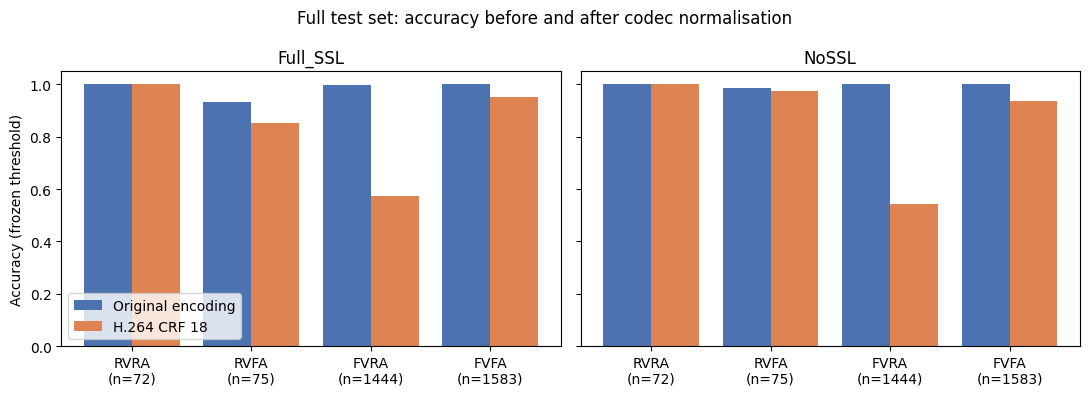


CELL 56 RESULTS (paste this output back)
   model            policy              encoding  accuracy  balanced_accuracy  macro_f1    mcc  roc_auc  specificity  sensitivity  fp  fn
Full_SSL Frozen_Validation              Original    0.9978             0.9989    0.9763 0.9536   1.0000       1.0000       0.9977   0   7
Full_SSL Frozen_Validation Normalized_H264_CRF18    0.7779             0.8864    0.5207 0.2676   0.9747       1.0000       0.7727   0 705
Full_SSL       Default_0.5              Original    0.9997             0.9931    0.9964 0.9929   1.0000       0.9861       1.0000   1   0
Full_SSL       Default_0.5 Normalized_H264_CRF18    0.8784             0.9242    0.5999 0.3608   0.9747       0.9722       0.8762   2 384
   NoSSL Frozen_Validation              Original    0.9997             0.9998    0.9965 0.9930   1.0000       1.0000       0.9997   0   1
   NoSSL Frozen_Validation Normalized_H264_CRF18    0.7599             0.8772    0.5095 0.2552   0.9645       1.0000       0.7544 

In [ ]:
# =============================================================================
# CELL 56 — FULL-TEST-SET CODEC NORMALISATION (ALL 3,174 TEST VIDEOS)
# SMD-Net V2 | Scientific Reports
#
# Replaces the 48-video diagnostic with the complete frozen test set.
#   1. Restores FakeAVCeleb (KaggleHub, same handle as before)
#   2. Re-encodes each test video exactly as Cell 45:
#        H.264 libx264, preset medium, CRF 18, yuv420p + AAC 192k, 16 kHz mono
#   3. Runs Full_SSL and NoSSL with the ORIGINAL protocol (Cell 52):
#        code-cell-49 definitions, 5 windows, CUDA AMP,
#        window starts from the ORIGINAL file's duration
#   4. Compares with the FROZEN original predictions (no re-inference needed;
#      Cell 52 verified they reproduce to <= 2.4e-8)
#   5. Paired statistics, per-category tables, figure
#
# RESUMABLE: progress saved to Drive every batch. After a disconnect,
# just rerun this cell. NO TRAINING.
# Expected time on a T4 runtime: ~1.5-3 h (mostly ffmpeg re-encoding).
# =============================================================================

import ast, json, os, re, shutil, subprocess, sys, time, hashlib, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchaudio, cv2
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights
from scipy.stats import binomtest
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, roc_auc_score, confusion_matrix)
from google.colab import drive

warnings.filterwarnings("ignore", category=FutureWarning)
T0 = time.time()
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
SPLIT_FILE = ROOT / "02_Splits/fakeavceleb_source_disjoint_split_seed42_media_audited.csv"
PRED_DIR = ROOT / "05_Predictions"
OUT = ROOT / "12_Full_Test_Codec_Normalization"
TABLES, FIGS = OUT / "Tables", OUT / "Figures"
for d in [OUT, TABLES, FIGS]:
    d.mkdir(parents=True, exist_ok=True)
PROGRESS = OUT / "Cell56_normalized_video_predictions.csv"
LOCAL_NORM = Path("/content/cell56_normalized")
LOCAL_NORM.mkdir(exist_ok=True)

assert torch.cuda.is_available(), "Enable a T4 GPU: Runtime > Change runtime type."
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

CATEGORIES = {"RealVideo-RealAudio": "RVRA", "RealVideo-FakeAudio": "RVFA",
              "FakeVideo-RealAudio": "FVRA", "FakeVideo-FakeAudio": "FVFA"}
THRESHOLDS = {"Full_SSL": 0.75732421875, "NoSSL": 0.556396484375}
FROZEN = {"Full_SSL": ("smdnet_v2_final_test_5window_predictions.csv", "probability_manipulated"),
          "NoSSL":    ("smdnet_v2_nossl_test_5window_predictions.csv", "nossl_probability")}
CHECKPOINTS = {"Full_SSL": ROOT / "04_Checkpoints/Full_SSL_Initialized_Fast/smdnet_v2_full_best.pt",
               "NoSSL":    ROOT / "04_Checkpoints/NoSSL_Fast/smdnet_v2_nossl_best.pt"}
BATCH = 48            # videos re-encoded in parallel, then inferred, then deleted
WORKERS = max(2, os.cpu_count() or 2)

def to_relative(p):
    p = str(p).replace("\\", "/")
    for c in CATEGORIES:
        k = p.find(c + "/")
        if k >= 0:
            return p[k:]
    return p.lstrip("/")

def find_col(frame, names):
    low = {str(c).lower(): c for c in frame.columns}
    for n in names:
        if n.lower() in low:
            return low[n.lower()]
    raise KeyError(f"None of {names} in {list(frame.columns)}")

# -----------------------------------------------------------------------------
# 1. Frozen test split + frozen original predictions
# -----------------------------------------------------------------------------
split = pd.read_csv(SPLIT_FILE)
split["rel"] = split[find_col(split, ["relative_path", "video_path", "path"])].map(to_relative)
split_col = find_col(split, ["split", "subset", "partition"])
test = split[split[split_col].astype(str).str.lower().str.strip() == "test"][["rel"]].copy()
test["label"] = (~test["rel"].str.startswith("RealVideo-RealAudio/")).astype(int)
test["category"] = test["rel"].str.split("/").str[0].map(CATEGORIES)
test = test.reset_index(drop=True)
assert len(test) == 3174, f"Expected 3,174 test videos, found {len(test)}"

for model, (fname, col) in FROZEN.items():
    pred = pd.read_csv(PRED_DIR / fname)
    pred["rel"] = pred[find_col(pred, ["relative_path", "video_path", "path"])].map(to_relative)
    test = test.merge(pred[["rel", col]].rename(columns={col: f"{model}_original"}),
                      on="rel", how="left")
    assert test[f"{model}_original"].notna().all(), f"{model}: frozen predictions missing"
print("Test videos:", len(test), "| frozen original predictions aligned for both models")

# -----------------------------------------------------------------------------
# 2. Original model + decoder definitions (code cell 49, as in Cells 48-52)
# -----------------------------------------------------------------------------
notebooks = sorted(ROOT.rglob("Video_forgery*.ipynb"),
                   key=lambda p: (p.name != "Video_forgery (1).ipynb", -p.stat().st_size))
assert notebooks, "Original notebook not found in the project folder."
NOTEBOOK = notebooks[0]
code_cells = ["".join(c.get("source", [])) for c in
              json.loads(NOTEBOOK.read_text(encoding="utf-8"))["cells"] if c.get("cell_type") == "code"]
REQUIRED = ["preprocess_rgb_frame", "decode_visual_opencv_exact", "decode_visual_ffmpeg_exact_window",
            "decode_visual_segment", "decode_audio_segment",
            "VisualEncoder", "AudioEncoder", "ProjectionHead", "FusionClassifier", "SMDNetV2"]
defs = {n.name: n for n in ast.parse(code_cells[49]).body
        if isinstance(n, (ast.FunctionDef, ast.ClassDef))}
missing = [n for n in REQUIRED if n not in defs]
assert not missing, f"Code cell 49 is missing {missing}; wrong notebook revision?"

WINDOW_SEC, NUM_FRAMES = 0.8, 16
AUDIO_SR, AUDIO_SAMPLES = 16000, 12800
N_FFT, WIN_LENGTH, HOP_LENGTH, N_MELS = 640, 400, 160, 128
IMAGE_SIZE, RESIZE_SHORT = 224, 256
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=AUDIO_SR, n_fft=N_FFT, win_length=WIN_LENGTH, hop_length=HOP_LENGTH,
    n_mels=N_MELS, f_min=0.0, f_max=8000.0, power=2.0, center=True)
ffmpeg_path = shutil.which("ffmpeg")
assert ffmpeg_path, "FFmpeg unavailable."
DECODER_STATS = {"opencv_success": 0, "ffmpeg_fallback": 0, "complete_failure": 0}
WINDOW_FRACTIONS = np.array([0.0, 0.25, 0.5, 0.75, 1.0])

for name in REQUIRED:
    mod = ast.Module(body=[defs[name]], type_ignores=[])
    ast.fix_missing_locations(mod)
    exec(compile(mod, f"original_cell49:{name}", "exec"), globals())

models = {}
for name, ckpt_path in CHECKPOINTS.items():
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=True)
    assert ckpt.get("test_data_used") is False, f"{name}: provenance check failed"
    m = SMDNetV2(pretrained_visual=False)
    m.load_state_dict(ckpt["model_state_dict"], strict=True)
    models[name] = m.to(DEVICE).eval()
    print(name, "checkpoint loaded (strict) | epoch", ckpt.get("epoch"))

# -----------------------------------------------------------------------------
# 3. Restore FakeAVCeleb originals
# -----------------------------------------------------------------------------
try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "kagglehub"], check=True)
    import kagglehub

def valid_root(root, k=100):
    sample = test["rel"].sample(min(k, len(test)), random_state=0)
    return root.is_dir() and np.mean([(root / r).is_file() for r in sample]) >= 0.98

DATA_ROOT = None
print("\nRestoring FakeAVCeleb with KaggleHub (cached after the first download) ...")
base = Path(kagglehub.dataset_download("shreyaty08/fakeavceleb"))
for cand in [base / "FakeAVCeleb_v1.2" / "FakeAVCeleb_v1.2", base / "FakeAVCeleb_v1.2", base]:
    if valid_root(cand):
        DATA_ROOT = cand
        break
assert DATA_ROOT is not None, f"Could not find the test videos under {base}"
print("DATA_ROOT:", DATA_ROOT)

# -----------------------------------------------------------------------------
# 4. Re-encoding (identical to Cell 45) and original-protocol inference
# -----------------------------------------------------------------------------
def probe(path, entries):
    r = subprocess.run(["ffprobe", "-v", "error", "-show_entries", entries, "-of", "json", str(path)],
                       capture_output=True, text=True, check=True)
    return json.loads(r.stdout)

def duration_of(path):
    return float(probe(path, "format=duration")["format"]["duration"])

def normalize(rel):
    src = DATA_ROOT / rel
    dst = LOCAL_NORM / (hashlib.md5(rel.encode()).hexdigest() + ".mp4")
    if not (dst.is_file() and dst.stat().st_size > 1000):
        cmd = [ffmpeg_path, "-y", "-v", "error", "-i", str(src),
               "-map", "0:v:0", "-map", "0:a:0",
               "-c:v", "libx264", "-preset", "medium", "-crf", "18", "-pix_fmt", "yuv420p",
               "-c:a", "aac", "-b:a", "192k", "-ar", "16000", "-ac", "1",
               "-movflags", "+faststart", "-threads", "1", str(dst)]
        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode != 0:
            return rel, None, None, r.stderr[-300:]
    streams = probe(dst, "stream=codec_type,codec_name,sample_rate")["streams"]
    v = [s for s in streams if s["codec_type"] == "video"]
    a = [s for s in streams if s["codec_type"] == "audio"]
    if not v or v[0]["codec_name"] != "h264" or not a or a[0]["codec_name"] != "aac" \
            or str(a[0].get("sample_rate")) != "16000":
        return rel, None, None, "normalised stream check failed"
    starts = WINDOW_FRACTIONS * max(0.0, duration_of(src) - WINDOW_SEC)  # ORIGINAL duration
    return rel, dst, starts, None

def infer(path, starts):
    vis = [decode_visual_segment(path, float(s), WINDOW_SEC, NUM_FRAMES) for s in starts]
    aud = [decode_audio_segment(path, float(s), WINDOW_SEC) for s in starts]
    out = {}
    with torch.inference_mode():
        vb, ab = torch.stack(vis).to(DEVICE), torch.stack(aud).to(DEVICE)
        with torch.amp.autocast(device_type="cuda", enabled=True):      # Full_SSL: 5-window batch
            out["Full_SSL"] = torch.sigmoid(models["Full_SSL"](vb, ab)["logit"]).float().cpu().numpy().reshape(-1)
        probs = []
        for v, a in zip(vis, aud):                                       # NoSSL: per window
            with torch.amp.autocast("cuda", enabled=True):
                probs.append(float(torch.sigmoid(models["NoSSL"](v.unsqueeze(0).to(DEVICE),
                                                                 a.unsqueeze(0).to(DEVICE))["logit"]).cpu().item()))
        out["NoSSL"] = np.asarray(probs)
    for k, p in out.items():
        assert len(p) == 5 and np.isfinite(p).all(), f"{k}: bad window output"
    return {k: float(np.mean(p)) for k, p in out.items()}

records = pd.read_csv(PROGRESS).to_dict("records") if PROGRESS.is_file() else []
done = {r["rel"] for r in records}
todo = [r for r in test["rel"] if r not in done]
print(f"\nAlready done: {len(done)} | remaining: {len(todo)} | workers: {WORKERS}")

def save():
    tmp = Path("/content/cell56_progress.tmp.csv")
    pd.DataFrame(records).to_csv(tmp, index=False)
    shutil.copy2(tmp, PROGRESS)

t_start, n_new = time.time(), 0
for b in range(0, len(todo), BATCH):
    chunk = todo[b:b + BATCH]
    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        prepared = list(ex.map(normalize, chunk))
    for rel, dst, starts, err in prepared:
        if err:
            records.append({"rel": rel, "status": "failed", "error": err})
            continue
        try:
            probs = infer(dst, starts)
            records.append({"rel": rel, "status": "ok",
                            "Full_SSL_normalized": probs["Full_SSL"], "NoSSL_normalized": probs["NoSSL"]})
        except Exception as e:
            records.append({"rel": rel, "status": "failed", "error": repr(e)[:300]})
        finally:
            dst.unlink(missing_ok=True)
        n_new += 1
    save()
    rate = (time.time() - t_start) / max(n_new, 1)
    left = len(todo) - (b + len(chunk))
    print(f"  {len(records)}/{len(test)} done | {rate:.2f} s/video | ETA {left * rate / 60:.0f} min")

# -----------------------------------------------------------------------------
# 5. Analysis
# -----------------------------------------------------------------------------
res = pd.DataFrame(records)
failed = res[res["status"] != "ok"]
print("\nFailed videos:", len(failed))
if len(failed):
    failed.to_csv(TABLES / "Cell56_failed_videos.csv", index=False)
data = test.merge(res[res["status"] == "ok"].drop(columns=["status"], errors="ignore"), on="rel", how="inner")
print("Paired videos analysed:", len(data), "of", len(test))

def metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, yhat), "balanced_accuracy": balanced_accuracy_score(y, yhat),
            "macro_f1": f1_score(y, yhat, average="macro", zero_division=0),
            "mcc": matthews_corrcoef(y, yhat), "roc_auc": roc_auc_score(y, p),
            "specificity": tn / (tn + fp), "sensitivity": tp / (tp + fn),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp}

rng = np.random.default_rng(42)
y = data["label"].values
idx0, idx1 = np.where(y == 0)[0], np.where(y == 1)[0]
overall, by_cat, tests = [], [], []
for model, thr0 in THRESHOLDS.items():
    po, pn = data[f"{model}_original"].values, data[f"{model}_normalized"].values
    for policy, thr in [("Frozen_Validation", thr0), ("Default_0.5", 0.5)]:
        mo, mn = metrics(y, po, thr), metrics(y, pn, thr)
        overall += [{"model": model, "policy": policy, "encoding": "Original", **mo},
                    {"model": model, "policy": policy, "encoding": "Normalized_H264_CRF18", **mn}]
        co, cn = (po >= thr).astype(int) == y, (pn >= thr).astype(int) == y
        b_lost, b_gained = int((co & ~cn).sum()), int((~co & cn).sum())
        p_mc = binomtest(min(b_lost, b_gained), b_lost + b_gained, 0.5).pvalue if b_lost + b_gained else 1.0
        boots_acc, boots_bal = [], []
        for _ in range(5000):                                   # stratified paired bootstrap
            s = np.r_[rng.choice(idx0, len(idx0)), rng.choice(idx1, len(idx1))]
            boots_acc.append(cn[s].mean() - co[s].mean())
            yo, yn = (po[s] >= thr).astype(int), (pn[s] >= thr).astype(int)
            boots_bal.append(balanced_accuracy_score(y[s], yn) - balanced_accuracy_score(y[s], yo))
        tests.append({"model": model, "policy": policy,
                      "accuracy_change_pp": 100 * (mn["accuracy"] - mo["accuracy"]),
                      "accuracy_change_ci95_pp": tuple(np.round(100 * np.percentile(boots_acc, [2.5, 97.5]), 2)),
                      "balanced_accuracy_change_pp": 100 * (mn["balanced_accuracy"] - mo["balanced_accuracy"]),
                      "balanced_accuracy_change_ci95_pp": tuple(np.round(100 * np.percentile(boots_bal, [2.5, 97.5]), 2)),
                      "correct_to_wrong": b_lost, "wrong_to_correct": b_gained, "exact_mcnemar_p": p_mc})
        for cat in ["RVRA", "RVFA", "FVRA", "FVFA"]:
            m = data["category"].values == cat
            by_cat.append({"model": model, "policy": policy, "category": cat, "n": int(m.sum()),
                           "correct_original": int(co[m].sum()), "correct_normalized": int(cn[m].sum()),
                           "accuracy_original": co[m].mean(), "accuracy_normalized": cn[m].mean(),
                           "mean_prob_original": po[m].mean(), "mean_prob_normalized": pn[m].mean()})

overall, by_cat, tests = pd.DataFrame(overall), pd.DataFrame(by_cat), pd.DataFrame(tests)
# Holm across the 4 tests (2 models x 2 policies)
order = np.argsort(tests["exact_mcnemar_p"].values)
holm, running = np.empty(len(tests)), 0.0
for rank, i in enumerate(order):
    running = max(running, min(1.0, (len(tests) - rank) * tests["exact_mcnemar_p"].values[i]))
    holm[i] = running
tests["holm_p"] = holm

overall.to_csv(TABLES / "Cell56_overall_metrics.csv", index=False)
by_cat.to_csv(TABLES / "Cell56_per_category.csv", index=False)
tests.to_csv(TABLES / "Cell56_paired_tests.csv", index=False)
data.to_csv(TABLES / "Cell56_paired_video_predictions.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, model in zip(axes, THRESHOLDS):
    sub = by_cat[(by_cat.model == model) & (by_cat.policy == "Frozen_Validation")]
    x = np.arange(len(sub))
    ax.bar(x - 0.2, sub["accuracy_original"], 0.4, label="Original encoding", color="#4C72B0")
    ax.bar(x + 0.2, sub["accuracy_normalized"], 0.4, label="H.264 CRF 18", color="#DD8452")
    ax.set_xticks(x, [f"{c}\n(n={n})" for c, n in zip(sub.category, sub.n)])
    ax.set_title(model)
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Accuracy (frozen threshold)")
axes[0].legend(loc="lower left")
fig.suptitle("Full test set: accuracy before and after codec normalisation")
fig.tight_layout()
for ext in ["png", "pdf"]:
    fig.savefig(FIGS / f"Figure_Cell56_Full_Test_Codec_Normalization.{ext}", dpi=300)
plt.show()

pd.set_option("display.width", 250)
print("\n" + "=" * 100 + "\nCELL 56 RESULTS (paste this output back)\n" + "=" * 100)
print(overall[["model", "policy", "encoding", "accuracy", "balanced_accuracy", "macro_f1", "mcc",
               "roc_auc", "specificity", "sensitivity", "fp", "fn"]].round(4).to_string(index=False))
print("\nPaired tests:\n", tests.round(6).to_string(index=False))
print("\nPer category (frozen threshold):\n",
      by_cat[by_cat.policy == "Frozen_Validation"].round(4).to_string(index=False))
print(f"\nSaved to {OUT}\nTotal time {(time.time() - T0) / 60:.1f} min | Training: NO")

In [ ]:
# =============================================================================
# CELL 57 — MODEL SIZE, FLOPs AND INFERENCE TIME (Supplementary Table S2)
# SMD-Net V2 | Scientific Reports        No training, no dataset download.
# Uses the exact frozen definitions (code cell 49) and the Full_SSL checkpoint.
# =============================================================================
import ast, json, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchaudio, cv2, shutil
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.flop_counter import FlopCounterMode
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
assert torch.cuda.is_available(), "Switch to a T4 GPU runtime."
DEVICE = torch.device("cuda")

# --- frozen definitions from code cell 49 (same procedure as Cells 48-56)
nbk = sorted(ROOT.rglob("Video_forgery*.ipynb"),
             key=lambda p: (p.name != "Video_forgery (1).ipynb", -p.stat().st_size))[0]
code = ["".join(c["source"]) for c in json.loads(nbk.read_text())["cells"] if c["cell_type"] == "code"][49]
WINDOW_SEC, NUM_FRAMES, AUDIO_SR, AUDIO_SAMPLES = 0.8, 16, 16000, 12800
N_FFT, WIN_LENGTH, HOP_LENGTH, N_MELS, IMAGE_SIZE, RESIZE_SHORT = 640, 400, 160, 128, 224, 256
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
mel_transform = torchaudio.transforms.MelSpectrogram(sample_rate=AUDIO_SR, n_fft=N_FFT, win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH, n_mels=N_MELS, f_min=0.0, f_max=8000.0, power=2.0, center=True)
ffmpeg_path = shutil.which("ffmpeg")
DECODER_STATS = {"opencv_success": 0, "ffmpeg_fallback": 0, "complete_failure": 0}
for n in ast.parse(code).body:
    if isinstance(n, (ast.FunctionDef, ast.ClassDef)):
        m = ast.Module(body=[n], type_ignores=[]); ast.fix_missing_locations(m)
        exec(compile(m, f"cell49:{n.name}", "exec"), globals())

model = SMDNetV2(pretrained_visual=False)
ck = torch.load(ROOT / "04_Checkpoints/Full_SSL_Initialized_Fast/smdnet_v2_full_best.pt",
                map_location="cpu", weights_only=True)
model.load_state_dict(ck["model_state_dict"], strict=True)
model = model.to(DEVICE).eval()

# --- parameters
def count(mod): return sum(p.numel() for p in mod.parameters())
print(f"Total parameters: {count(model):,}")
for name, sub in model.named_children():
    print(f"  {name:<22s} {count(sub):>12,}")

# --- FLOPs (FlopCounterMode counts 2 x multiply-accumulate)
def flops(n_windows):
    v = torch.randn(n_windows, 16, 3, 224, 224, device=DEVICE)
    a = torch.randn(n_windows, 1, 128, 81, device=DEVICE)
    with torch.inference_mode(), FlopCounterMode(display=False) as fc:
        model(v, a)
    return fc.get_total_flops() / 1e9
g1, g5 = flops(1), flops(5)
print(f"\nGFLOPs per 0.8 s window: {g1:.2f}")
print(f"GFLOPs per video (5 windows): {g5:.2f}")

# --- GPU latency, model only, original AMP protocol (5-window batch)
v = torch.randn(5, 16, 3, 224, 224, device=DEVICE); a = torch.randn(5, 1, 128, 81, device=DEVICE)
times = []
with torch.inference_mode(), torch.amp.autocast(device_type="cuda"):
    for i in range(60):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        model(v, a)
        torch.cuda.synchronize()
        if i >= 10: times.append(time.perf_counter() - t0)       # 10 warm-up runs
ms = 1000 * np.array(times)
print(f"\nModel inference per video (5 windows, T4, AMP): {ms.mean():.1f} ± {ms.std():.1f} ms "
      f"(median {np.median(ms):.1f} ms, n = {len(ms)})")
print(f"Throughput: {1000 / ms.mean():.1f} videos/s  |  {5000 / ms.mean():.1f} windows/s")

# --- end-to-end per video including decoding, on the representative samples (if present)
samples = sorted((ROOT / "08_Representative_Dataset_Samples").rglob("*.mp4"))
if samples:
    e2e = []
    for p in samples:
        r = cv2.VideoCapture(str(p)); fps = r.get(cv2.CAP_PROP_FPS); n = r.get(cv2.CAP_PROP_FRAME_COUNT); r.release()
        dur = n / fps if fps else 0
        starts = np.array([0, .25, .5, .75, 1.0]) * max(0.0, dur - WINDOW_SEC)
        torch.cuda.synchronize(); t0 = time.perf_counter()
        vb = torch.stack([decode_visual_segment(p, float(s), WINDOW_SEC, NUM_FRAMES) for s in starts]).to(DEVICE)
        ab = torch.stack([decode_audio_segment(p, float(s), WINDOW_SEC) for s in starts]).to(DEVICE)
        with torch.inference_mode(), torch.amp.autocast(device_type="cuda"):
            model(vb, ab)
        torch.cuda.synchronize(); e2e.append(time.perf_counter() - t0)
    print(f"End-to-end per video incl. decoding ({len(e2e)} sample videos): {1000 * np.mean(e2e):.0f} ms (mean)")
print("\nPaste this output back to fill Supplementary Table S2.")

In [ ]:
from google.colab import drive
from pathlib import Path
drive.mount("/content/drive")
root = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
print("Project folder found:", root.exists())
print("Checkpoint found:", (root / "04_Checkpoints/Full_SSL_Initialized_Fast/smdnet_v2_full_best.pt").exists())

Mounted at /content/drive
Project folder found: True
Checkpoint found: True


In [ ]:
# =============================================================================
# CELL 57 — MODEL SIZE, FLOPs AND INFERENCE TIME (Supplementary Table S2)
# SMD-Net V2 | Scientific Reports        No training, no dataset download.
# Uses the exact frozen definitions (code cell 49) and the Full_SSL checkpoint.
# =============================================================================
import ast, json, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchaudio, cv2, shutil
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.flop_counter import FlopCounterMode
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/SMDNet_V2_ScientificReports")
assert torch.cuda.is_available(), "Switch to a T4 GPU runtime."
DEVICE = torch.device("cuda")

# --- frozen definitions from code cell 49 (same procedure as Cells 48-56)
nbk = sorted(ROOT.rglob("Video_forgery*.ipynb"),
             key=lambda p: (p.name != "Video_forgery (1).ipynb", -p.stat().st_size))[0]
code = ["".join(c["source"]) for c in json.loads(nbk.read_text())["cells"] if c["cell_type"] == "code"][49]
WINDOW_SEC, NUM_FRAMES, AUDIO_SR, AUDIO_SAMPLES = 0.8, 16, 16000, 12800
N_FFT, WIN_LENGTH, HOP_LENGTH, N_MELS, IMAGE_SIZE, RESIZE_SHORT = 640, 400, 160, 128, 224, 256
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
mel_transform = torchaudio.transforms.MelSpectrogram(sample_rate=AUDIO_SR, n_fft=N_FFT, win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH, n_mels=N_MELS, f_min=0.0, f_max=8000.0, power=2.0, center=True)
ffmpeg_path = shutil.which("ffmpeg")
DECODER_STATS = {"opencv_success": 0, "ffmpeg_fallback": 0, "complete_failure": 0}
for n in ast.parse(code).body:
    if isinstance(n, (ast.FunctionDef, ast.ClassDef)):
        m = ast.Module(body=[n], type_ignores=[]); ast.fix_missing_locations(m)
        exec(compile(m, f"cell49:{n.name}", "exec"), globals())

model = SMDNetV2(pretrained_visual=False)
ck = torch.load(ROOT / "04_Checkpoints/Full_SSL_Initialized_Fast/smdnet_v2_full_best.pt",
                map_location="cpu", weights_only=True)
model.load_state_dict(ck["model_state_dict"], strict=True)
model = model.to(DEVICE).eval()

# --- parameters
def count(mod): return sum(p.numel() for p in mod.parameters())
print(f"Total parameters: {count(model):,}")
for name, sub in model.named_children():
    print(f"  {name:<22s} {count(sub):>12,}")

# --- FLOPs (FlopCounterMode counts 2 x multiply-accumulate)
def flops(n_windows):
    v = torch.randn(n_windows, 16, 3, 224, 224, device=DEVICE)
    a = torch.randn(n_windows, 1, 128, 81, device=DEVICE)
    with torch.inference_mode(), FlopCounterMode(display=False) as fc:
        model(v, a)
    return fc.get_total_flops() / 1e9
g1, g5 = flops(1), flops(5)
print(f"\nGFLOPs per 0.8 s window: {g1:.2f}")
print(f"GFLOPs per video (5 windows): {g5:.2f}")

# --- GPU latency, model only, original AMP protocol (5-window batch)
v = torch.randn(5, 16, 3, 224, 224, device=DEVICE); a = torch.randn(5, 1, 128, 81, device=DEVICE)
times = []
with torch.inference_mode(), torch.amp.autocast(device_type="cuda"):
    for i in range(60):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        model(v, a)
        torch.cuda.synchronize()
        if i >= 10: times.append(time.perf_counter() - t0)       # 10 warm-up runs
ms = 1000 * np.array(times)
print(f"\nModel inference per video (5 windows, T4, AMP): {ms.mean():.1f} ± {ms.std():.1f} ms "
      f"(median {np.median(ms):.1f} ms, n = {len(ms)})")
print(f"Throughput: {1000 / ms.mean():.1f} videos/s  |  {5000 / ms.mean():.1f} windows/s")

# --- end-to-end per video including decoding, on the representative samples (if present)
samples = sorted((ROOT / "08_Representative_Dataset_Samples").rglob("*.mp4"))
if samples:
    e2e = []
    for p in samples:
        r = cv2.VideoCapture(str(p)); fps = r.get(cv2.CAP_PROP_FPS); n = r.get(cv2.CAP_PROP_FRAME_COUNT); r.release()
        dur = n / fps if fps else 0
        starts = np.array([0, .25, .5, .75, 1.0]) * max(0.0, dur - WINDOW_SEC)
        torch.cuda.synchronize(); t0 = time.perf_counter()
        vb = torch.stack([decode_visual_segment(p, float(s), WINDOW_SEC, NUM_FRAMES) for s in starts]).to(DEVICE)
        ab = torch.stack([decode_audio_segment(p, float(s), WINDOW_SEC) for s in starts]).to(DEVICE)
        with torch.inference_mode(), torch.amp.autocast(device_type="cuda"):
            model(vb, ab)
        torch.cuda.synchronize(); e2e.append(time.perf_counter() - t0)
    print(f"End-to-end per video incl. decoding ({len(e2e)} sample videos): {1000 * np.mean(e2e):.0f} ms (mean)")
print("\nPaste this output back to fill Supplementary Table S2.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


cell49:VisualEncoder:1478: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True


Total parameters: 28,408,065
  visual_encoder           17,490,496
  audio_encoder            10,061,760
  visual_projection           164,736
  audio_projection            164,736
  fusion_classifier           526,337

GFLOPs per 0.8 s window: 58.55
GFLOPs per video (5 windows): 292.74

Model inference per video (5 windows, T4, AMP): 36.6 ± 0.8 ms (median 36.5 ms, n = 50)
Throughput: 27.3 videos/s  |  136.5 windows/s


NameError: name 'subprocess' is not defined

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!unzip -q -o "/content/drive/MyDrive/SMDNet_V2_All_Publication_Results.zip" -d /content/SMDNet_V2_All_Publication_Results
!ls /content/SMDNet_V2_All_Publication_Results

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
unzip:  cannot find or open /content/drive/MyDrive/SMDNet_V2_All_Publication_Results.zip, /content/drive/MyDrive/SMDNet_V2_All_Publication_Results.zip.zip or /content/drive/MyDrive/SMDNet_V2_All_Publication_Results.zip.ZIP.
ls: cannot access '/content/SMDNet_V2_All_Publication_Results': No such file or directory


In [ ]:
RESULTS_DIR  = "/content/SMDNet_V2_All_Publication_Results"
PROJECT_DIR  = "/content/drive/MyDrive/SMDNet_V2_ScientificReports"
NOTEBOOK     = "/content/drive/MyDrive/SMDNet_V2_ScientificReports/Video_forgery (1).ipynb"
OUTPUT_DIR   = "/content/figures_out"
FIGURES      = [2, 3, 4, 5, 6, 7, 8, 9, 10]

In [ ]:
#!/usr/bin/env python3
"""
make_figures.py — regenerate Figures 2–10 of the SMD-Net V2 manuscript.

    Fig. 2  Sample audiovisual inputs (frames + log-mel spectrograms)
    Fig. 3  Cohort curation flow chart and dataset distribution
    Fig. 4  Training progress (Stage B ROC-AUC, Stage A InfoNCE)
    Fig. 5  ROC curves on the frozen test set
    Fig. 6  Confusion matrices: original test set and H.264 re-encoded test set
    Fig. 7  Ablation and error analysis
    Fig. 8  Encoding shortcut and codec-control experiments
    Fig. 9  Full-test-set codec normalisation
    Fig. 10 Protocol-matched comparison

Inputs (set with command-line options or environment variables):
    --results   unzipped SMDNet_V2_All_Publication_Results folder       (SMDNET_RESULTS)
    --project   Drive project folder SMDNet_V2_ScientificReports         (SMDNET_PROJECT)
                  05_Predictions/                      -> Fig. 5
                  08_Representative_Dataset_Samples/   -> Fig. 2
                  12_Full_Test_Codec_Normalization/    -> Figs. 6, 9, 10
    --notebook  development notebook (Cell 53 printed output)          (SMDNET_NOTEBOOK)
                                                         -> Fig. 8c,d
    --out       output folder (default: figures_out)
Usage:
    python make_figures.py                     # all figures
    python make_figures.py --figures 6 9       # selected figures

Each figure is written as PDF (vector), PNG and TIFF (600 dpi) at 180 mm width.
If an optional input is missing, the script says so and uses the values verified
for the manuscript instead, so every figure can still be produced.

Requirements: numpy, pandas, matplotlib, pillow; opencv-python and ffmpeg only for Fig. 2.
"""
import argparse, json, os, re, shutil, subprocess, tempfile, warnings

# =============================================================================
# SETTINGS FOR NOTEBOOK USE — edit these if you paste this script into a Colab cell.
# (Command-line options or environment variables override them.)
# =============================================================================
RESULTS_DIR  = "/content/SMDNet_V2_All_Publication_Results"          # unzipped results package
PROJECT_DIR  = "/content/drive/MyDrive/SMDNet_V2_ScientificReports"  # Drive project folder
NOTEBOOK     = "/content/drive/MyDrive/SMDNet_V2_ScientificReports/Video_forgery (1).ipynb"
OUTPUT_DIR   = "/content/figures_out"
FIGURES      = [2, 3, 4, 5, 6, 7, 8, 9, 10]
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.ticker
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from PIL import Image

# =============================================================================
# Style
# =============================================================================
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 6.5, "axes.labelsize": 6.5, "axes.titlesize": 7,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 5.8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42})
INK, MUTED, GRID = "#2B2B2B", "#6B6B6B", "#E6E6E6"
REAL, FAKE = "#2E7D4F", "#B23A3A"
COL = {"Full_SSL": "#6A4BB5", "NoSSL": "#2E7D4F", "Visual_Only": "#2C6BAC"}
NAME = {"Full_SSL": "Full SSL", "NoSSL": "No SSL", "Visual_Only": "Visual only"}
CATS = [("RealVideo-RealAudio", "RVRA"), ("RealVideo-FakeAudio", "RVFA"),
        ("FakeVideo-RealAudio", "FVRA"), ("FakeVideo-FakeAudio", "FVFA")]
THR = {"Full_SSL": 0.75732421875, "NoSSL": 0.556396484375, "Visual_Only": 0.9638671875}
FW = 180  # figure width in mm

# =============================================================================
# Values verified for the manuscript (used only when an input file is missing)
# =============================================================================
VERIFIED_CONFUSION_ORIGINAL = {"Full_SSL": (72, 0, 7, 3095), "NoSSL": (72, 0, 1, 3101),
                               "Visual_Only": (72, 0, 63, 3039)}          # TN, FP, FN, TP
VERIFIED_CELL56 = {  # frozen thresholds; Cell 56 output
    "Full_SSL": {"orig": dict(balanced_accuracy=0.9989, macro_f1=0.9763, mcc=0.9536, roc_auc=1.0, tn=72, fp=0, fn=7, tp=3095),
                 "norm": dict(balanced_accuracy=0.8864, macro_f1=0.5207, mcc=0.2676, roc_auc=0.9747, tn=72, fp=0, fn=705, tp=2397),
                 "cat_correct": {"RVRA": (72, 72), "RVFA": (70, 64), "FVRA": (1442, 826), "FVFA": (1583, 1507)},
                 "cat_prob": {"RVRA": (0.0894, 0.0942), "RVFA": (0.9313, 0.9004), "FVRA": (0.9915, 0.7107), "FVFA": (0.9987, 0.9600)}},
    "NoSSL": {"orig": dict(balanced_accuracy=0.9998, macro_f1=0.9965, mcc=0.9930, roc_auc=1.0, tn=72, fp=0, fn=1, tp=3101),
              "norm": dict(balanced_accuracy=0.8772, macro_f1=0.5095, mcc=0.2552, roc_auc=0.9645, tn=72, fp=0, fn=762, tp=2340),
              "cat_correct": {"RVRA": (72, 72), "RVFA": (74, 73), "FVRA": (1444, 786), "FVFA": (1583, 1481)},
              "cat_prob": {"RVRA": (0.0547, 0.0587), "RVFA": (0.9484, 0.8919), "FVRA": (0.9943, 0.5716), "FVFA": (0.9986, 0.9035)}}}
VERIFIED_CELL53_TESTS = {  # accuracy change (pp), 95% CI, Holm p; Cell 53 output
    "Full_SSL": [(0.0, 0.0, 0.0, 1.0), (-2.083, -6.25, 0.0, 1.0), (-10.417, -20.833, -2.083, 0.3125), (-14.583, -25.0, -6.25, 0.109)],
    "NoSSL": [(0.0, 0.0, 0.0, 1.0), (0.0, 0.0, 0.0, 1.0), (-14.583, -25.0, -6.25, 0.109), (-16.667, -27.083, -6.25, 0.0625)]}
VERIFIED_CELL53_PROBS = """
O:0.060132,0.239160;0.002503,0.001022;0.002915,0.001239;0.312306,0.014230;0.012172,0.005040;0.011378,0.007872;0.006664,0.001886;0.007130,0.002366;0.136798,0.205222;0.076910,0.029556;0.019479,0.003548;0.060884,0.029877;0.994727,0.988672;0.964941,0.997070;0.984180,0.993750;0.990137,0.996484;0.979785,0.950195;0.808472,0.837305;0.994043,0.997656;0.986719,0.997363;0.983887,0.987207;0.962793,0.935547;0.981152,0.964941;0.995898,0.996387;0.994336,0.995117;0.995801,0.996387;0.995313,0.995020;0.995508,0.995605;0.992480,0.995117;0.993164,0.995215;0.996484,0.997070;0.991699,0.995410;0.994434,0.995215;0.992188,0.995410;0.992480,0.996094;0.995215,0.996875;0.997949,0.998242;0.999219,0.999414;0.999609,0.999121;0.999316,0.998730;0.998926,0.998437;0.998047,0.998437;0.999316,0.999609;0.998242,0.998535;0.999512,0.998926;0.999512,0.999316;0.999219,0.999219;0.998730,0.999023
C:0.047375,0.305872;0.003718,0.001607;0.003806,0.006675;0.379390,0.154614;0.184513,0.062721;0.071962,0.074200;0.193521,0.184554;0.084836,0.110681;0.360614,0.266141;0.255231,0.226437;0.124704,0.096409;0.229031,0.195358;0.996777,0.994043;0.992480,0.997949;0.983105,0.991602;0.990820,0.996680;0.990625,0.988867;0.951465,0.963184;0.994434,0.998340;0.990820,0.998340;0.995020,0.995117;0.971973,0.986816;0.990918,0.990039;0.995215,0.983496;0.994434,0.995215;0.996289,0.996680;0.995703,0.995313;0.995410,0.995898;0.993457,0.995508;0.993945,0.995898;0.996680,0.997168;0.992480,0.995801;0.995410,0.996289;0.992285,0.995215;0.993262,0.996289;0.995410,0.996777;0.998047,0.998340;0.999219,0.999414;0.999609,0.999121;0.999414,0.998828;0.999023,0.998535;0.998145,0.998437;0.999316,0.999609;0.998340,0.998633;0.999512,0.998926;0.999512,0.999316;0.999219,0.999219;0.998730,0.999023
A:0.052884,0.272205;0.003728,0.001586;0.003631,0.006761;0.340126,0.158363;0.179781,0.053533;0.068948,0.062053;0.191702,0.182756;0.076826,0.108221;0.392395,0.288007;0.241418,0.226121;0.105127,0.069071;0.229522,0.193897;0.989453,0.993164;0.956348,0.996777;0.978711,0.990625;0.990527,0.995898;0.980566,0.992676;0.735834,0.673828;0.988770,0.996875;0.964551,0.996582;0.994238,0.994727;0.883203,0.882910;0.980273,0.985352;0.995020,0.996191;0.994336,0.995410;0.995996,0.995508;0.996191,0.995996;0.995313,0.995898;0.993359,0.995605;0.993945,0.995801;0.996191,0.997070;0.992480,0.995801;0.995215,0.996289;0.992578,0.995605;0.993066,0.996094;0.995703,0.996875;0.997363,0.998145;0.999414,0.999609;0.999316,0.998926;0.999219,0.998828;0.998730,0.998633;0.997852,0.998340;0.999316,0.999609;0.998535,0.998926;0.999219,0.998730;0.999316,0.999121;0.999219,0.999512;0.997363,0.998535
V:0.052084,0.351184;0.004717,0.002082;0.004604,0.012344;0.376050,0.086413;0.196832,0.070166;0.072511,0.039647;0.197311,0.169746;0.074323,0.040947;0.383105,0.369882;0.287521,0.328223;0.119751,0.089744;0.264696,0.183883;0.995801,0.988867;0.992188,0.997559;0.987988,0.985645;0.988770,0.976953;0.991602,0.957617;0.935449,0.951465;0.993164,0.997363;0.988086,0.995313;0.994727,0.994531;0.972949,0.955762;0.989941,0.984668;0.993359,0.934863;0.238425,0.637054;0.892285,0.133524;0.995508,0.995605;0.993750,0.388517;0.970898,0.836133;0.992285,0.995410;0.521590,0.515988;0.451562,0.049216;0.607486,0.376692;0.379640,0.020232;0.925391,0.229848;0.965039,0.583252;0.978320,0.640363;0.999316,0.985449;0.995215,0.960547;0.996484,0.786316;0.924707,0.713245;0.998535,0.999219;0.991992,0.997070;0.998828,0.999414;0.999512,0.999316;0.999512,0.999805;0.999219,0.999414;0.990430,0.760767
B:0.082266,0.283936;0.003379,0.001406;0.002925,0.001462;0.265025,0.010773;0.048375,0.005103;0.012287,0.020761;0.007903,0.001447;0.007160,0.002596;0.160114,0.180490;0.084479,0.056084;0.018646,0.003639;0.177997,0.023089;0.988672,0.959082;0.939551,0.988477;0.982617,0.979688;0.979492,0.947754;0.944238,0.801099;0.728864,0.624133;0.985254,0.992480;0.972754,0.993750;0.977734,0.968359;0.937109,0.740723;0.961719,0.887305;0.993262,0.992480;0.175854,0.521835;0.891113,0.118163;0.995020,0.994922;0.992285,0.388648;0.912695,0.670874;0.990820,0.994141;0.440673,0.425473;0.279438,0.007046;0.608130,0.397530;0.432881,0.040388;0.736877,0.207073;0.986035,0.699512;0.964453,0.635501;0.999219,0.980664;0.993750,0.978613;0.993848,0.735864;0.891699,0.694727;0.998340,0.999316;0.991113,0.997266;0.998438,0.998535;0.999512,0.999316;0.999414,0.999707;0.999121,0.999023;0.862598,0.686523
"""  # Cell 53 output: per condition, 48 videos x (Full_SSL, NoSSL)
NCAT = {"RVRA": 72, "RVFA": 75, "FVRA": 1444, "FVFA": 1583}

# =============================================================================
# Helpers
# =============================================================================
class Paths:
    def __init__(self, a):
        self.results = Path(a.results); self.project = Path(a.project) if a.project else None
        self.notebook = Path(a.notebook) if a.notebook else None
        self.out = Path(a.out); self.out.mkdir(parents=True, exist_ok=True)
        self.tables = self.results / "02_Tables"
        self.pubfigs = self.results / "01_Figures" / "Final_Publication_Figures"
    def proj(self, *p):
        return self.project.joinpath(*p) if self.project else None

def note(msg): print("   note:", msg)

def new_fig(h_mm):
    return plt.figure(figsize=(FW / 25.4, h_mm / 25.4)), h_mm

def axmm(fig, H, x, y, w, h):
    return fig.add_axes([x / FW, y / H, w / FW, h / H])

def letter(fig, H, x, y, s):
    fig.text(x / FW, y / H, s, fontsize=10, fontweight="bold", va="top", ha="left")

def head(fig, H, x, y, s):
    fig.text(x / FW, y / H, s, fontsize=7, va="top")

def save(fig, P, name):
    for ext, kw in [("pdf", {}), ("png", {"dpi": 600}),
                    ("tiff", {"dpi": 600, "pil_kwargs": {"compression": "tiff_lzw"}})]:
        fig.savefig(P.out / f"{name}.{ext}", **kw)
    plt.close(fig)
    print(f"   saved {name}.pdf/.png/.tiff")

def ygrid(ax): ax.grid(axis="y", color=GRID, lw=0.5); ax.set_axisbelow(True)
def xgrid(ax): ax.grid(axis="x", color=GRID, lw=0.5); ax.set_axisbelow(True)

def find_col(df, names):
    low = {c.lower(): c for c in df.columns}
    for n in names:
        if n.lower() in low:
            return low[n.lower()]
    raise KeyError(f"none of {names} in {list(df.columns)}")

def to_rel(p):
    p = str(p).replace("\\", "/")
    for c, _ in CATS:
        k = p.find(c + "/")
        if k >= 0:
            return p[k:]
    return p

def mcc(tn, fp, fn, tp):
    d = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return (tp * tn - fp * fn) / d if d else 0.0

def bal_acc(tn, fp, fn, tp):
    return 0.5 * (tp / (tp + fn) + tn / (tn + fp))

def load_cell56(P):
    """Cell 56 metrics; falls back to the verified manuscript values."""
    base = P.proj("12_Full_Test_Codec_Normalization", "Tables")
    out = json.loads(json.dumps(VERIFIED_CELL56))
    if base is None or not (base / "Cell56_overall_metrics.csv").is_file():
        note("Cell 56 tables not found; using verified manuscript values.")
        return out
    ov = pd.read_csv(base / "Cell56_overall_metrics.csv")
    ov = ov[ov.policy == "Frozen_Validation"]
    for m in ["Full_SSL", "NoSSL"]:
        for enc, key in [("Original", "orig"), ("Normalized_H264_CRF18", "norm")]:
            r = ov[(ov.model == m) & (ov.encoding == enc)].iloc[0]
            out[m][key] = {k: float(r[k]) for k in ["balanced_accuracy", "macro_f1", "mcc", "roc_auc", "tn", "fp", "fn", "tp"]}
    pc = pd.read_csv(base / "Cell56_per_category.csv")
    pc = pc[pc.policy == "Frozen_Validation"]
    for m in ["Full_SSL", "NoSSL"]:
        for _, r in pc[pc.model == m].iterrows():
            out[m]["cat_correct"][r.category] = (int(r.correct_original), int(r.correct_normalized))
            out[m]["cat_prob"][r.category] = (float(r.mean_prob_original), float(r.mean_prob_normalized))
    return out

def _verified_cell53_probs():
    names = {"O": "Original", "C": "Container_Only", "A": "Audio_Only", "V": "Video_Only", "B": "Combined"}
    rows = []
    for line in VERIFIED_CELL53_PROBS.strip().splitlines():
        code, vals = line.split(":")
        for i, pair in enumerate(vals.split(";"), start=1):
            a, b = pair.split(",")
            rows.append((names[code], i, float(a), float(b)))
    return pd.DataFrame(rows, columns=["condition", "idx", "Full_SSL", "NoSSL"])

def _notebook_has_cell53(path):
    try:
        cells = json.loads(Path(path).read_text(encoding="utf-8"))["cells"]
    except Exception:
        return False
    for c in cells:
        if c.get("cell_type") == "code" and "CELL 53" in "".join(c.get("source", []))[:300]:
            out = "".join("".join(o.get("text", "")) for o in c.get("outputs", []) if "text" in o)
            return "CONDITION: Combined" in out
    return False

def find_notebook(given, project):
    if given and Path(given).is_file() and _notebook_has_cell53(given):
        return Path(given)
    roots = [r for r in [project, "/content/drive/MyDrive", "/content"] if r and Path(r).is_dir()]
    print("   searching for the development notebook with Cell 53 output ...")
    seen = set()
    for r in roots:
        for nb in sorted(Path(r).glob("**/*.ipynb"), key=lambda p: -p.stat().st_size):
            if nb in seen or ".ipynb_checkpoints" in str(nb):
                continue
            seen.add(nb)
            if _notebook_has_cell53(nb):
                print(f"   found: {nb}")
                return nb
    return None

def load_cell53(P):
    """Per-video probabilities and paired tests printed by Cell 53."""
    probs, tests = None, None
    if P.notebook and P.notebook.is_file():
        cells = json.loads(P.notebook.read_text(encoding="utf-8"))["cells"]
        text = None
        for c in cells:
            if c.get("cell_type") == "code" and "CELL 53" in "".join(c.get("source", []))[:300]:
                text = "".join("".join(o.get("text", "")) for o in c.get("outputs", []) if "text" in o)
        if text:
            rows, cond = [], None
            for line in text.splitlines():
                m = re.match(r"CONDITION: (\S+)", line)
                if m:
                    cond = m.group(1); continue
                m = re.match(r"\[(\d+)/48\] Full SSL=([\d.]+) \| NoSSL=([\d.]+)", line)
                if m and cond:
                    rows.append((cond, int(m.group(1)), float(m.group(2)), float(m.group(3))))
            if len(rows) == 240:
                probs = pd.DataFrame(rows, columns=["condition", "idx", "Full_SSL", "NoSSL"])
            tests = {"Full_SSL": [], "NoSSL": []}
            for cond in ["Container_Only", "Audio_Only", "Video_Only", "Combined"]:
                for m in tests:
                    mm = re.search(rf"{'Full_SSL' if m == 'Full_SSL' else 'NoSSL'}\s+{cond}_vs_Original\s+(\S+)\s+(\S+)\s+(\S+)\s+\S+\s+(\S+)", text)
                    if mm:
                        d, lo, hi, holm = (float(x) for x in mm.groups())
                        tests[m].append((100 * d, 100 * lo, 100 * hi, holm))
            if any(len(v) != 4 for v in tests.values()):
                tests = None
    if probs is None:
        note("Cell 53 output not found in a notebook; using the verified Cell 53 values built into this script.")
        probs = _verified_cell53_probs()
    if tests is None:
        note("Cell 53 paired tests not parsed; using verified manuscript values.")
        tests = VERIFIED_CELL53_TESTS
    return probs, tests

# =============================================================================
# Figure 2 — sample audiovisual inputs
# =============================================================================
def logmel(wav, sr=16000, n_fft=640, win=400, hop=160, n_mels=128, fmax=8000):
    """Log-mel spectrogram with numpy only (HTK mel scale), in dB relative to max."""
    if len(wav) < win:
        wav = np.pad(wav, (0, win - len(wav)))
    frames = 1 + (len(wav) - win) // hop
    idx = np.arange(win)[None, :] + hop * np.arange(frames)[:, None]
    spec = np.abs(np.fft.rfft(wav[idx] * np.hanning(win), n=n_fft)) ** 2
    hz2mel = lambda f: 2595 * np.log10(1 + f / 700)
    mel2hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    pts = mel2hz(np.linspace(hz2mel(0), hz2mel(fmax), n_mels + 2))
    bins = np.floor((n_fft + 1) * pts / sr).astype(int)
    fb = np.zeros((n_mels, n_fft // 2 + 1))
    for i in range(1, n_mels + 1):
        l, c, r = bins[i - 1], bins[i], bins[i + 1]
        if c > l: fb[i - 1, l:c] = (np.arange(l, c) - l) / (c - l)
        if r > c: fb[i - 1, c:r] = (r - np.arange(c, r)) / (r - c)
    mel = spec @ fb.T
    db = 10 * np.log10(np.maximum(mel, 1e-10))
    return np.maximum(db - db.max(), -80).T          # (n_mels, frames), 0 … −80 dB

def fig2_samples(P):
    import cv2
    root = P.proj("08_Representative_Dataset_Samples")
    vids = {}
    if root and root.is_dir():
        for folder, code in CATS:
            hits = sorted(p for p in root.rglob("*.mp4") if folder in str(p))
            if hits: vids[code] = hits[0]
    if len(vids) < 4:
        src = P.pubfigs / "Dataset_Visualization" / "Figure_40A_Refined_Actual_FakeAVCeleb_AV_Samples.png"
        note("sample videos not found; copying the published sample figure from the results package.")
        im = Image.open(src).convert("RGB")
        for ext in ["png", "tiff", "pdf"]:
            im.save(P.out / f"Figure2_Sample_Inputs.{ext}", dpi=(600, 600))
        return
    fig, H = new_fig(134)
    labels = {"RVRA": ("Real video · real audio", REAL), "RVFA": ("Real video · fake audio", "#C98F3A"),
              "FVRA": ("Fake video · real audio", "#2C6BAC"), "FVFA": ("Fake video · fake audio", "#8E3F7A")}
    for r, (_, code) in enumerate(CATS):
        path = vids[code]
        cap = cv2.VideoCapture(str(path)); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fps = cap.get(cv2.CAP_PROP_FPS) or 25
        y = H - 12 - r * 30
        for j, frac in enumerate([0.2, 0.5, 0.8]):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frac * max(n - 1, 0)))
            ok, fr = cap.read()
            ax = axmm(fig, H, 20 + j * 25, y - 22, 22, 22); ax.axis("off")
            if ok:
                fr = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB); h, w = fr.shape[:2]; s = min(h, w)
                ax.imshow(fr[(h - s) // 2:(h + s) // 2, (w - s) // 2:(w + s) // 2])
            ax.set_title(f"{frac * n / fps:.2f} s", fontsize=5.4, color=MUTED, pad=1.5, y=-0.16)
        cap.release()
        with tempfile.TemporaryDirectory() as td:
            wavp = Path(td) / "a.f32"
            subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(path), "-ac", "1", "-ar", "16000",
                            "-f", "f32le", str(wavp)], check=True)
            wav = np.fromfile(wavp, dtype=np.float32)
        S = logmel(wav)
        ax = axmm(fig, H, 104, y - 22, 58, 22)
        im = ax.imshow(S, origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=0,
                       extent=(0, len(wav) / 16000, 0, S.shape[0]))
        ax.set_ylabel("Mel bin", fontsize=5.6); ax.tick_params(labelsize=5.2)
        if r == 3: ax.set_xlabel("Time (s)", fontsize=5.6)
        fig.text(3 / FW, (y - 9) / H, code, fontsize=7.5, fontweight="bold", color=labels[code][1], rotation=90, va="center")
        fig.text(20 / FW, (y + 2.5) / H, f"({'abcd'[r]})  {labels[code][0]}", fontsize=6.2, va="bottom")
    cax = axmm(fig, H, 165, 14, 2.2, H - 30)
    cb = fig.colorbar(im, cax=cax, ticks=[-80, -60, -40, -20, 0])
    cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%d"))
    cb.set_label("Relative power (dB)", fontsize=5.6); cb.ax.tick_params(labelsize=5.2)
    save(fig, P, "Figure2_Sample_Inputs")

# =============================================================================
# Figure 3 — dataset distribution
# =============================================================================
CURATION = {  # Cells 4, 6B, 7, 9 and 11 of the development notebook
    "downloaded": 21560, "metadata_rows": 21566,
    "conflict_groups": 25, "conflict_files": 51, "after_conflicts": 21509,
    "same_label_dups": 17, "after_dedup": 21492,
    "no_metadata": 16, "final": 21476, "undecodable": 0,
    "authentic_before": 500, "authentic_final": 475}

def _box(ax, x, y, w, h, lines, fc, ec, bold_first=True, fs=5.6):
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.2", fc=fc, ec=ec, lw=0.7, zorder=2))
    n = len(lines); lh = fs * 0.43
    for k, t in enumerate(lines):
        ax.text(x + w / 2, y + h / 2 + (n - 1) * lh / 2 - k * lh, t, ha="center", va="center", fontsize=fs,
                fontweight="bold" if (bold_first and k == 0) else "normal", color=INK, zorder=3)

def _arrow(ax, p, q, c=INK):
    from matplotlib.patches import FancyArrowPatch
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=6, color=c, lw=0.7, shrinkA=0, shrinkB=0, zorder=1))

def fig3_distribution(P):
    d = P.pubfigs / "Dataset_Visualization"
    split = pd.read_csv(d / "Dataset_Split_Counts.csv")
    cat = pd.read_csv(d / "Dataset_Category_By_Split.csv").set_index("split")
    binc = pd.read_csv(d / "Dataset_Binary_Class_By_Split.csv").set_index("split")
    C = CURATION
    assert int(binc.sum().sum()) == C["final"], "split files do not add up to the curated cohort"
    fig, H = new_fig(150)

    # ---------------- (a) cohort curation flow chart
    ax = fig.add_axes([0, 64 / H, 1, 80 / H]); ax.set_xlim(0, 180); ax.set_ylim(0, 80); ax.axis("off")
    MAIN, MAIN_E = "#EEF3F9", "#2C6BAC"; EXC, EXC_E = "#FBEDED", "#B23A3A"; FIN, FIN_E = "#E7F2EA", REAL
    w, h, y = 31, 17, 57
    xs = [2, 37.5, 73, 108.5, 144]
    main = [["Files downloaded", f"{C['downloaded']:,} videos", f"({C['metadata_rows']:,} metadata rows)"],
            ["Label conflicts removed", f"{C['after_conflicts']:,} videos"],
            ["Exact duplicates removed", f"{C['after_dedup']:,} videos"],
            ["Metadata matched", f"{C['final']:,} videos"],
            ["Final clean cohort", f"{C['final']:,} videos", f"{C['authentic_final']} authentic", f"{C['final'] - C['authentic_final']:,} manipulated", "500 source identities"]]
    for k, (x, lines) in enumerate(zip(xs, main)):
        last = k == len(xs) - 1
        _box(ax, x, y, w, h, lines, FIN if last else MAIN, FIN_E if last else MAIN_E)
        if k: _arrow(ax, (xs[k - 1] + w, y + h / 2), (x, y + h / 2))
    exc = [[f"−{C['conflict_files']} files", f"{C['conflict_groups']} byte-identical groups", "labelled both authentic", "and manipulated"],
           [f"−{C['same_label_dups']} files", "byte-identical copies", "with the same label"],
           [f"−{C['no_metadata']} files", "no metadata record"],
           [f"−{C['undecodable']} files", "decodability and", "audio–video integrity audit"]]
    for k, lines in enumerate(exc):
        xm = (xs[k] + w + xs[k + 1]) / 2
        bx = xm - 15.5
        _box(ax, bx, 34, 31, 14, lines, EXC, EXC_E, fs=5.3)
        ax.plot([xm, xm], [y + h / 2, 48], color=EXC_E, lw=0.6, ls=(0, (2, 1.5)), zorder=1)
    # split
    fx = xs[-1] + w / 2
    ax.plot([fx, fx], [y, 28], color=INK, lw=0.7)
    ax.text(90, 29.4, "Source-identity-disjoint split (seed 42)", ha="center", fontsize=5.8, fontweight="bold")
    ax.text(90, 26.0, "0 shared source identities · 0 shared SHA-256 hashes between partitions", ha="center", fontsize=5.2, color=MUTED)
    ax.plot([24, fx], [24, 24], color=INK, lw=0.7)
    sx = [8, 66, 124]; sw = 48
    for k, part in enumerate(["Train", "Validation", "Test"]):
        a_, m_ = int(binc.loc[part, "Authentic"]), int(binc.loc[part, "Manipulated"])
        ids = {"Train": 350, "Validation": 75, "Test": 75}[part]
        _arrow(ax, (sx[k] + sw / 2, 24), (sx[k] + sw / 2, 17))
        _box(ax, sx[k], 2, sw, 15, [f"{part}: {a_ + m_:,} videos", f"{ids} source identities",
                                     f"{a_} authentic · {m_:,} manipulated"], MAIN, MAIN_E, fs=5.6)
    ax.plot([sx[0] + sw / 2, sx[2] + sw / 2], [24, 24], color=INK, lw=0.7)
    letter(fig, H, 2, 148, "a"); head(fig, H, 8, 147.6, "Cohort curation and split")
    fig.text(176 / FW, 147.6 / H, f"authentic videos: {C['authentic_before']} → {C['authentic_final']}", ha="right", va="top",
             fontsize=5.4, color=MUTED)

    # ---------------- (b–d) distributions
    panels = [("Videos per partition", split.Partition.tolist(), split.Videos.tolist(), ["#2C6BAC", "#3E9C8F", "#D27A2C"]),
              ("Test videos per category", [c for _, c in CATS], [int(cat.loc["Test", c]) for _, c in CATS],
               [REAL, "#C98F3A", "#2C6BAC", "#8E3F7A"]),
              ("Test videos per class", ["Authentic", "Manipulated"],
               [int(binc.loc["Test", "Authentic"]), int(binc.loc["Test", "Manipulated"])], [REAL, FAKE])]
    for k, (title, labs, vals, cols) in enumerate(panels):
        ax = axmm(fig, H, 14 + k * 57, 9, 44, 40)
        ax.bar(range(len(vals)), vals, color=cols, width=0.68)
        for i_, v in enumerate(vals):
            ax.text(i_, v * 1.01 + max(vals) * 0.01, f"{v:,}", ha="center", va="bottom", fontsize=5.6)
        ax.set_xticks(range(len(vals)), labs); ax.set_ylim(0, max(vals) * 1.15)
        ax.set_title(title, pad=4); ygrid(ax)
        if k == 0: ax.set_ylabel("Number of videos")
        letter(fig, H, 2 + k * 57, 59, "bcd"[k])
    tot = int(binc.loc["Test"].sum()); share = binc.loc["Test", "Manipulated"] / tot
    fig.axes[-1].text(1, binc.loc["Test", "Manipulated"] * 0.5, f"{100 * share:.1f}%", ha="center", color="white",
                      fontsize=7, fontweight="bold")
    save(fig, P, "Figure3_Dataset_Curation_and_Distribution")

# =============================================================================
# Figure 4 — training progress
# =============================================================================
def fig4_training(P):
    T = P.tables
    fig, H = new_fig(70)
    ax = axmm(fig, H, 16, 13, 80, 47)
    for m, f in [("Full_SSL", "smdnet_v2_full_training_history_fast.csv"),
                 ("NoSSL", "smdnet_v2_nossl_training_history_fast.csv"),
                 ("Visual_Only", "smdnet_v2_visual_only_training_history_fast.csv")]:
        h = pd.read_csv(T / f)
        ax.plot(h.epoch, h.fast_val_roc_auc, color=COL[m], lw=1.0, marker="o", ms=1.8, label=NAME[m])
        b = h.loc[h.fast_val_roc_auc.idxmax()]
        ax.plot(b.epoch, b.fast_val_roc_auc, marker="*", ms=7, color=COL[m], mec="white", mew=0.5, zorder=5)
    hdl, lab = ax.get_legend_handles_labels()
    hdl.append(Line2D([], [], ls="none", marker="*", ms=7, color=MUTED, mec="white")); lab.append("selected checkpoint")
    ax.legend(hdl, lab, frameon=False, loc="lower right")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Validation ROC-AUC (fast subset)"); ax.set_ylim(0.70, 1.01); ax.set_xlim(0, 31)
    ax.set_title("Stage B supervised training", pad=4); ygrid(ax); letter(fig, H, 2, 68, "a")

    s = pd.read_csv(T / "stageA_ssl_training_history.csv")
    ax = axmm(fig, H, 118, 13, 46, 47)
    ax.plot(s.epoch, s.train_loss, color="#9A86CF", lw=1.0, marker="o", ms=1.8, label="training")
    ax.plot(s.epoch, s.val_loss, color=COL["Full_SSL"], lw=1.0, marker="o", ms=1.8, label="validation")
    b = s.loc[s.val_loss.idxmin()]
    ax.plot(b.epoch, b.val_loss, marker="*", ms=7, color=COL["Full_SSL"], mec="white", mew=0.5, zorder=5)
    ax.set_xlabel("Epoch"); ax.set_ylabel("InfoNCE loss"); ax.set_xticks(range(2, int(s.epoch.max()) + 1, 2))
    ax.set_ylim(2.0, 4.9); ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 0.18)); ygrid(ax)
    ax2 = ax.twinx()
    ax2.bar(s.epoch, 100 * s.val_mean_top1, width=0.5, color="#D9D9D9", zorder=0)
    ax2.axhline(100 / 72, color=MUTED, lw=0.6, ls=(0, (3, 2)))
    ax2.text(0.7, 100 / 72 + 0.45, "chance (1/72)", fontsize=5.2, color=MUTED)
    ax2.set_ylim(0, 20); ax2.set_ylabel("Retrieval top-1 (%)", color=MUTED); ax2.tick_params(axis="y", colors=MUTED)
    ax2.spines["right"].set_visible(True)
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.set_title("Stage A pretraining", pad=4); letter(fig, H, 106, 68, "b")
    save(fig, P, "Figure4_Training_Progress")

# =============================================================================
# Figure 5 — ROC curves
# =============================================================================
def roc_points(y, p):
    order = np.argsort(-p, kind="mergesort"); y = y[order]; p = p[order]
    distinct = np.r_[np.where(np.diff(p))[0], len(p) - 1]
    tps = np.cumsum(y)[distinct]; fps = np.cumsum(1 - y)[distinct]
    tpr = np.r_[0, tps / y.sum()]; fpr = np.r_[0, fps / (1 - y).sum()]
    trap = getattr(np, "trapezoid", None) or getattr(np, "trapz")   # NumPy 2 renamed trapz
    return fpr, tpr, trap(tpr, fpr)

def fig5_roc(P):
    pred_dir = P.proj("05_Predictions")
    files = {"Full_SSL": ("smdnet_v2_final_test_5window_predictions.csv", "probability_manipulated"),
             "NoSSL": ("smdnet_v2_nossl_test_5window_predictions.csv", "nossl_probability"),
             "Visual_Only": ("smdnet_v2_visual_only_test_5window_predictions.csv", "visual_only_probability")}
    if pred_dir is None or not all((pred_dir / f).is_file() for f, _ in files.values()):
        note("prediction files not found in <project>/05_Predictions; copying the published ROC figure.")
        im = Image.open(P.pubfigs / "Figure_38A_ROC_Curves.png").convert("RGB")
        for ext in ["png", "tiff", "pdf"]:
            im.save(P.out / f"Figure5_ROC_Curves.{ext}", dpi=(600, 600))
        return
    fig, H = new_fig(84)
    ax = axmm(fig, H, 16, 12, 66, 66); axz = axmm(fig, H, 104, 12, 66, 66)
    for m, (f, col) in files.items():
        d = pd.read_csv(pred_dir / f)
        rel = d[find_col(d, ["relative_path", "video_path", "path"])].map(to_rel)
        y = (~rel.str.startswith("RealVideo-RealAudio/")).astype(int).values
        fpr, tpr, auc = roc_points(y, d[col].astype(float).values)
        for a in (ax, axz):
            a.plot(fpr, tpr, color=COL[m], lw=1.2, label=f"{NAME[m]} (AUC = {auc:.4f})", drawstyle="steps-post")
    ax.plot([0, 1], [0, 1], color=MUTED, lw=0.7, ls=(0, (3, 2)), label="chance")
    ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01); ax.set_title("Full range", pad=4)
    axz.set_xlim(-0.005, 0.10); axz.set_ylim(0.90, 1.002); axz.set_title("Zoom: FPR ≤ 0.10, TPR ≥ 0.90", pad=4)
    for a in (ax, axz):
        a.set_xlabel("False positive rate"); a.grid(color=GRID, lw=0.5); a.set_axisbelow(True)
    ax.set_ylabel("True positive rate"); ax.legend(frameon=False, loc="lower right")
    letter(fig, H, 2, 82, "a"); letter(fig, H, 92, 82, "b")
    save(fig, P, "Figure5_ROC_Curves")

# =============================================================================
# Figure 6 — confusion matrices
# =============================================================================
def fig6_confusion(P):
    perf = pd.read_csv(P.tables / "Final_Publication_Tables" / "Table_02_Frozen_Validation_Threshold_Performance.csv")
    orig = {}
    for m in ["Full_SSL", "NoSSL", "Visual_Only"]:
        r = perf[perf.Model == m].iloc[0]
        orig[m] = (int(r.TN), int(r.FP), int(r.FN), int(r.TP))
        if orig[m] != VERIFIED_CONFUSION_ORIGINAL[m]:
            warnings.warn(f"{m}: confusion counts differ from the manuscript values")
    c56 = load_cell56(P)
    norm = {m: tuple(int(c56[m]["norm"][k]) for k in ["tn", "fp", "fn", "tp"]) for m in ["Full_SSL", "NoSSL"]}
    GREEN, RED = np.array([46, 125, 79]) / 255, np.array([178, 58, 58]) / 255
    tint = lambda base, f: tuple(1 - (1 - base) * (0.12 + 0.88 * f))

    def matrix(ax, m, cm):
        tn, fp, fn, tp = cm; cells = [[tn, fp], [fn, tp]]; tot = [tn + fp, fn + tp]
        for r in range(2):
            for c in range(2):
                v = cells[r][c]; pct = v / tot[r]; p = 100 * pct
                ax.add_patch(Rectangle((c, 1 - r), 1, 1, fc=tint(GREEN if r == c else RED, pct if v else 0), ec="white", lw=2))
                dark = pct > 0.55
                ax.text(c + .5, 1 - r + .58, f"{v:,}", ha="center", va="center", fontsize=9, fontweight="bold", color="white" if dark else INK)
                ptxt = f"{p:.2f}%" if (0 < p < 0.1 or 99.9 < p < 100) else f"{p:.1f}%"
                ax.text(c + .5, 1 - r + .30, ptxt, ha="center", va="center", fontsize=6, color="white" if dark else MUTED)
        ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_aspect("equal")
        ax.set_xticks([.5, 1.5], ["Authentic", "Manipulated"])
        ax.set_yticks([1.5, .5], [f"Authentic\n(n = {tn + fp:,})", f"Manipulated\n(n = {fn + tp:,})"])
        ax.tick_params(length=0, labelsize=6)
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_xlabel("Predicted label", fontsize=6, color=MUTED, labelpad=2)
        ax.set_title(NAME[m], fontsize=7.2, fontweight="bold", color=COL[m], pad=12)
        ax.text(1, 2.08, f"BA {bal_acc(*cm):.4f} · MCC {mcc(*cm):.3f}", ha="center", va="bottom", fontsize=5.6, color=MUTED)

    fig, H = new_fig(132)
    for i, m in enumerate(["Full_SSL", "NoSSL", "Visual_Only"]):
        ax = axmm(fig, H, 24 + i * 58, 76, 36, 36); matrix(ax, m, orig[m])
        if i == 0: ax.set_ylabel("True label", fontsize=6, color=MUTED, labelpad=2)
    for i, m in enumerate(["Full_SSL", "NoSSL"]):
        ax = axmm(fig, H, 53 + i * 58, 12, 36, 36); matrix(ax, m, norm[m])
        if i == 0: ax.set_ylabel("True label", fontsize=6, color=MUTED, labelpad=2)
    letter(fig, H, 2, 129, "a"); head(fig, H, 8, 128.6, "Original test set (frozen validation thresholds)")
    letter(fig, H, 2, 65, "b"); head(fig, H, 8, 64.6, "Same test videos re-encoded to H.264 (CRF 18) with 16 kHz AAC: manipulations unchanged")
    for i, (lab, base) in enumerate([("correct (shade = row %)", GREEN), ("error (shade = row %)", RED)]):
        fig.patches.append(Rectangle((6 / FW, (36 - 6 * i) / H), 4 / FW, 4 / H, transform=fig.transFigure, fc=tint(base, .8), ec="none"))
        fig.text(12 / FW, (38 - 6 * i) / H, lab, fontsize=5.8, va="center")
    fig.text(6 / FW, 23 / H, "Each cell: count and\npercentage of its true class.", fontsize=5.6, va="center", color=MUTED)
    save(fig, P, "Figure6_Confusion_Matrices")

# =============================================================================
# Figure 7 — ablation and error analysis
# =============================================================================
def fig7_ablation(P):
    T = P.tables
    ci = pd.read_csv(T / "Final_Publication_Tables" / "Cell37_Statistical_Validation" / "Table_37C_Model_95CI.csv")
    fig, H = new_fig(118)
    for k, (metric, lab, lim) in enumerate([("balanced_accuracy", "Balanced accuracy", (0.984, 1.0015)),
                                            ("macro_f1", "Macro-F1", (0.80, 1.005))]):
        ax = axmm(fig, H, 15 + 37 * k, 66, 25, 40)
        for i, m in enumerate(["Full_SSL", "NoSSL", "Visual_Only"]):
            r = ci[(ci.model == m) & (ci.metric == metric)].iloc[0]
            ax.errorbar(i, r.point_estimate, yerr=[[r.point_estimate - r.ci_95_lower], [r.ci_95_upper - r.point_estimate]],
                        fmt="o", ms=3.6, color=COL[m], elinewidth=0.9, capsize=2.2, capthick=0.8)
        ax.set_xticks(range(3), ["Full\nSSL", "No\nSSL", "Visual\nonly"]); ax.set_xlim(-0.6, 2.6); ax.set_ylim(*lim)
        ax.set_title(lab, pad=4); ygrid(ax)
    fig.text(46 / FW, 54.5 / H, "Majority-class baseline (always \u201cmanipulated\u201d): balanced accuracy 0.500,\n"
             "macro-F1 0.494 \u2014 both off scale. Error bars: 95% stratified bootstrap CIs.",
             ha="center", va="center", fontsize=5.3, color=MUTED, style="italic")
    letter(fig, H, 2, 114, "a")

    pc = pd.read_csv(T / "smdnet_v2_three_model_per_condition.csv")
    pc = pc[pc.operating_point == "Validation_Frozen"]
    mods = [("Full_SSL", "Full SSL"), ("Full_NoSSL", "No SSL"), ("Visual_Only", "Visual only")]
    M = np.zeros((3, 4)); TX = [[""] * 4 for _ in range(3)]
    for i, (m, _) in enumerate(mods):
        for j, (c, _) in enumerate(CATS):
            r = pc[(pc.model == m) & (pc.condition == c)].iloc[0]
            M[i, j] = r.accuracy; TX[i][j] = f"{int(r.correct):,}/{int(r.n):,}"
    ax = axmm(fig, H, 104, 66, 72, 40)
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("acc", [(0, "#B23A3A"), (0.55, "#EDBFAE"), (0.88, "#F8EEE8"), (1, "#E8F2EA")])
    ax.imshow(M, cmap=cmap, vmin=0.25, vmax=1.0, aspect="auto")
    for i in range(3):
        for j in range(4):
            dark = M[i, j] < 0.5
            ax.text(j, i - .12, f"{100 * M[i, j]:.1f}%", ha="center", va="center", fontsize=6.3, fontweight="bold", color="white" if dark else INK)
            ax.text(j, i + .22, TX[i][j], ha="center", va="center", fontsize=5.0, color="white" if dark else MUTED)
    ax.set_xticks(range(4), [c for _, c in CATS]); ax.set_yticks(range(3), [m[1] for m in mods]); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xticks(np.arange(-.5, 4), minor=True); ax.set_yticks(np.arange(-.5, 3), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="minor", length=0)
    ax.set_title("Accuracy by category (frozen thresholds)", pad=4); letter(fig, H, 88, 114, "b")

    d = pd.read_csv(T / "smdnet_v2_three_model_error_overlap.csv")
    a, b, c = (d[k].astype(bool) for k in ["error_frozen_Full_SSL", "error_frozen_Full_NoSSL", "error_frozen_Visual_Only"])
    groups = [("Visual only", ~a & ~b & c), ("Full SSL", a & ~b & ~c), ("No SSL", ~a & b & ~c),
              ("Full SSL +\nVisual only", a & ~b & c), ("Full SSL +\nNo SSL", a & b & ~c),
              ("No SSL +\nVisual only", ~a & b & c), ("all three", a & b & c)]
    groups = [(n, int(g.sum())) for n, g in groups if g.sum() > 0]
    ax = axmm(fig, H, 40, 11, 110, 30)
    y = np.arange(len(groups))[::-1]
    ax.barh(y, [g[1] for g in groups], color="#8C8C8C", height=0.58)
    for yi, (_, v) in zip(y, groups): ax.text(v + 1, yi, str(v), va="center", fontsize=6)
    ax.set_yticks(y, [g[0] for g in groups]); ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, max(g[1] for g in groups) * 1.15); ax.set_xlabel("Misclassified test videos")
    ax.set_title("Error overlap", pad=4); letter(fig, H, 2, 47, "c")
    save(fig, P, "Figure7_Ablation_and_Error_Analysis")

# =============================================================================
# Figure 8 — encoding shortcut and codec control
# =============================================================================
def codec_rule(meta):
    v = meta[meta.feature == "video_codec"]
    h264 = v[v.value.astype(str) == "h264"].iloc[0]
    other = v[v.value.astype(str) != "h264"][["authentic", "manipulated"]].sum()
    tn, fn = int(h264.authentic), int(h264.manipulated)          # predicted authentic
    fp, tp = int(other.authentic), int(other.manipulated)        # predicted manipulated
    return tn, fp, fn, tp

def fig8_codec(P):
    T = P.tables
    meta = pd.read_csv(T / "smdnet_v2_metadata_shortcut_indicators.csv")
    perf = pd.read_csv(T / "Final_Publication_Tables" / "Table_02_Frozen_Validation_Threshold_Performance.csv").set_index("Model")
    probs, tests = load_cell53(P)
    fig, H = new_fig(194)

    # (a) encoding attributes vs label
    rows = [("video_codec", "h264", "H.264"), ("video_codec", "mpeg4", "MPEG-4 Part 2"),
            ("audio_sample_rate", "44100", "44.1 kHz"), ("audio_sample_rate", "16000", "16 kHz"),
            ("audio_codec", "mp3", "MP3"), ("audio_codec", "aac", "AAC")]
    groups = {"video_codec": "Video codec", "audio_sample_rate": "Audio sample rate", "audio_codec": "Audio codec"}
    ax = axmm(fig, H, 30, 150, 52, 33); ypos = []
    for k, (feat, val, lab) in enumerate(rows):
        r = meta[(meta.feature == feat) & (meta.value.astype(str) == val)].iloc[0]
        fa = r.authentic / r.total; yy = -(k + (k // 2) * 0.7); ypos.append(yy)
        ax.barh(yy, fa, color=REAL, height=0.72); ax.barh(yy, 1 - fa, left=fa, color=FAKE, height=0.72, alpha=0.85)
        ax.text(1.02, yy, f"{r.authentic:,} / {r.manipulated:,}", va="center", fontsize=5.6)
        if k % 2 == 0:
            ax.text(-0.02, yy + 0.85, groups[feat], ha="right", va="center", fontsize=5.8, fontweight="bold",
                    transform=ax.get_yaxis_transform())
    ax.set_yticks(ypos, [r[2] for r in rows]); ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 1); ax.set_xticks([0, .5, 1], ["0", "50", "100"]); ax.set_xlabel("Share of test videos (%)")
    ax.set_ylim(min(ypos) - .7, 1.2); ax.spines["left"].set_visible(False)
    ax.text(1.02, 1.0, "auth. / manip.", fontsize=5.4, color=MUTED, va="center")
    ax.legend([Line2D([], [], lw=5, color=REAL), Line2D([], [], lw=5, color=FAKE, alpha=.85)], ["authentic", "manipulated"],
              frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(-0.02, 1.0), handlelength=1.2)
    letter(fig, H, 2, 193, "a"); head(fig, H, 9, 192.6, "Encoding attributes are confounded with the label")

    # (b) codec rule vs trained models
    rule = codec_rule(meta)
    entries = [("Majority class", 0.5, MUTED), ("Codec rule\n(no training)", bal_acc(*rule), FAKE)] + \
              [(NAME[m], float(perf.loc[m, "Balanced_Accuracy"]), COL[m]) for m in ["Visual_Only", "Full_SSL", "NoSSL"]]
    ax = axmm(fig, H, 128, 150, 46, 33)
    for i, (lab, v, c) in enumerate(entries):
        ax.plot([0.45, v], [-i, -i], color=c, lw=1.0, alpha=.6); ax.plot(v, -i, "o", ms=4.2, color=c, mec="white", mew=.5)
        ax.text(v - .012, -i + .33, f"{v:.3f}", ha="right", fontsize=5.6, color=c, fontweight="bold" if "Codec" in lab else "normal")
    ax.set_yticks([-i for i in range(len(entries))], [e[0] for e in entries]); ax.tick_params(axis="y", length=0)
    ax.set_xlim(0.45, 1.03); ax.set_ylim(-len(entries) + .4, .6); ax.set_xlabel("Balanced accuracy on the test set")
    ax.spines["left"].set_visible(False); xgrid(ax)
    letter(fig, H, 98, 193, "b"); head(fig, H, 105, 192.6, "A one-line codec rule nearly matches trained models")

    # (c) per-video paths, 48-video cohort, shown for the two informative categories
    #     (videos 1–12 RVRA, 13–24 RVFA, 25–36 FVRA, 37–48 FVFA)
    order = ["Original", "Container_Only", "Audio_Only", "Video_Only", "Combined"]
    xlab = ["orig.", "remux", "audio\nre-enc.", "video\nre-enc.", "both\nre-enc."]
    panels = [("Full_SSL", "RVRA", range(1, 13), REAL, "authentic (RVRA)"),
              ("Full_SSL", "FVRA", range(25, 37), FAKE, "face swap / lip sync (FVRA)"),
              ("NoSSL", "RVRA", range(1, 13), REAL, "authentic (RVRA)"),
              ("NoSSL", "FVRA", range(25, 37), FAKE, "face swap / lip sync (FVRA)")]
    for k, (m, cat, ids, c, sub) in enumerate(panels):
        x0 = 16 + k * 41 + (4 if k >= 2 else 0)
        ax = axmm(fig, H, x0, 86, 34, 33)
        w = probs[probs.idx.isin(list(ids))].pivot(index="idx", columns="condition", values=m)[order]
        for _, row in w.iterrows():
            ax.plot(range(5), row.values, color=c, lw=0.6, alpha=0.35, zorder=2)
        ax.plot(range(5), w.median().values, color=c, lw=2.0, marker="o", ms=3, zorder=4)
        ax.axhline(THR[m], color=INK, lw=0.6, ls=(0, (3, 2)), zorder=3)
        correct = (w >= THR[m]).sum() if cat != "RVRA" else (w < THR[m]).sum()
        for xi, n in enumerate(correct.values):
            ax.text(xi, 1.07, f"{n}/12", ha="center", fontsize=5.3,
                    color=FAKE if n < 12 else MUTED, fontweight="bold" if n < 12 else "normal")
        ax.set_xticks(range(5), xlab, fontsize=5.4); ax.set_xlim(-.4, 4.4); ax.set_ylim(-.03, 1.13)
        ax.set_yticks([0, .25, .5, .75, 1.0]); ygrid(ax)
        ax.set_title(sub, fontsize=6.2, color=c, pad=9)
        if k in (0, 2):
            ax.set_ylabel("p(manipulated)")
            ax.text(-0.35, THR[m] + 0.03, f"threshold {THR[m]:.2f}", fontsize=5, color=INK)
        else:
            ax.set_yticklabels([])
    fig.text((16 + 75 / 2) / FW, 129 / H, "Full SSL", ha="center", fontsize=7, fontweight="bold", color=COL["Full_SSL"])
    fig.text((20 + 82 + 75 / 2) / FW, 129 / H, "No SSL", ha="center", fontsize=7, fontweight="bold", color=COL["NoSSL"])
    fig.text(176 / FW, 136.6 / H, "thin lines: 12 videos · bold: median · n/12: correct decisions",
             ha="right", va="top", fontsize=5.3, color=MUTED)
    letter(fig, H, 2, 137, "c")
    head(fig, H, 9, 136.6, "48-video cohort: the same videos, only the encoding changed")

    # (d) accuracy change with CI
    ax = axmm(fig, H, 16, 14, 46, 42)
    for k, m in enumerate(["Full_SSL", "NoSSL"]):
        off = -.13 if k == 0 else .13
        for i, (dlt, lo, hi, _) in enumerate(tests[m]):
            ax.errorbar(i + off, dlt, yerr=[[dlt - lo], [hi - dlt]], fmt="o", ms=3.4, color=COL[m], elinewidth=.9,
                        capsize=2, capthick=.8, label=NAME[m] if i == 0 else None)
    ax.axhline(0, color=INK, lw=.6); ax.set_xticks(range(4), ["remux", "audio\nre-enc.", "video\nre-enc.", "both\nre-enc."])
    ax.set_xlim(-.5, 3.5); ax.set_ylim(-30, 4); ax.set_ylabel("Accuracy change (pp)"); ygrid(ax)
    ax.legend(frameon=False, loc="lower left", handlelength=1.0)
    letter(fig, H, 2, 68, "d"); head(fig, H, 9, 67.6, "Paired change, 95% CI")

    # (e) Visual_Only CRF sweep: median and interquartile range per group
    pr = pd.read_csv(T / "smdnet_v2_multilevel_compression_predictions.csv")
    lev = ["Original", "CRF10", "CRF18", "CRF23", "CRF30"]
    grp = [("Authentic", "authentic", REAL), ("AudioOnlyFake", "audio-only fake", "#C98F3A"), ("VideoManipulated", "video-manipulated", FAKE)]
    ax = axmm(fig, H, 76, 14, 48, 42)
    for g, lab, c in grp:
        q = np.array([np.percentile(pr[(pr.group == g) & (pr.compression == L)].probability.values, [25, 50, 75]) for L in lev])
        ax.fill_between(range(5), q[:, 0], q[:, 2], color=c, alpha=0.18, lw=0)
        ax.plot(range(5), q[:, 1], color=c, lw=1.6, marker="o", ms=3, label=lab)
    ax.axhline(.5, color=INK, lw=.6, ls=(0, (3, 2))); ax.text(4.35, .52, "0.5", fontsize=5.2, ha="right")
    ax.set_xticks(range(5), ["orig.", "10", "18", "23", "30"]); ax.set_xlabel("H.264 CRF")
    ax.set_xlim(-.2, 4.2); ax.set_ylim(-.02, 1.03); ax.set_ylabel("Visual-only p(manipulated)"); ygrid(ax)
    ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, .02), handlelength=1.4, fontsize=5.4)
    letter(fig, H, 66, 68, "e"); head(fig, H, 73, 67.6, "Visual only: median and IQR")

    # (f) ROC-AUC and authentic accuracy vs CRF
    m35 = pd.read_csv(T / "smdnet_v2_cell35_recovered_robustness_metrics.csv")
    ov = m35[(m35.group == "Overall") & (m35.threshold_policy == "Default_0.5")].set_index("compression").loc[lev]
    au = m35[(m35.group == "Authentic") & (m35.threshold_policy == "Default_0.5")].set_index("compression").loc[lev]
    ax = axmm(fig, H, 138, 14, 38, 42)
    ax.plot(range(5), ov.roc_auc, color=COL["Visual_Only"], marker="o", ms=3, lw=1.3, label="ROC-AUC")
    ax.plot(range(5), au.accuracy, color=REAL, marker="s", ms=2.8, lw=1.3, label="authentic\ncorrect (0.5)")
    ax.axhline(.5, color=MUTED, lw=.6, ls=(0, (3, 2))); ax.text(4.1, .53, "chance", fontsize=5.2, color=MUTED, ha="right")
    ax.set_xticks(range(5), ["orig.", "10", "18", "23", "30"]); ax.set_xlabel("H.264 CRF"); ax.set_ylim(-.03, 1.05); ygrid(ax)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, .04), handlelength=1.4, fontsize=5.4)
    letter(fig, H, 128, 68, "f"); head(fig, H, 135, 67.6, "Visual only: AUC vs CRF")
    save(fig, P, "Figure8_Encoding_Shortcut_and_Codec_Control")

# =============================================================================
# Figure 9 — full-test-set codec normalisation
# =============================================================================
def fig9_fulltest(P):
    c56 = load_cell56(P)
    cats = [c for _, c in CATS]
    acc = {m: {c: (c56[m]["cat_correct"][c][0] / NCAT[c], c56[m]["cat_correct"][c][1] / NCAT[c]) for c in cats} for m in ["Full_SSL", "NoSSL"]}
    prob = {m: {c: tuple(c56[m]["cat_prob"][c]) for c in cats} for m in ["Full_SSL", "NoSSL"]}
    fig, H = new_fig(78)

    def dumbbell(ax, data, fmt, xlab, xlim, thr=False):
        for ci, c in enumerate(cats):
            for k, m in enumerate(["Full_SSL", "NoSSL"]):
                y = -(ci * 2.6 + k); a, b = data[m][c]
                ax.plot([a, b], [y, y], color=COL[m], lw=1.0, alpha=.55, zorder=2)
                ax.plot(a, y, "o", ms=3.6, mfc="white", mec=COL[m], mew=.9, zorder=3)
                ax.plot(b, y, "o", ms=3.6, color=COL[m], zorder=3)
                if abs(a - b) > .08:
                    ax.text(min(a, b) - .015 * (xlim[1] - xlim[0]), y, fmt(b), ha="right", va="center", fontsize=5.4, color=COL[m])
        ax.set_yticks([-(ci * 2.6 + .5) for ci in range(4)], [f"{c}\nn = {NCAT[c]:,}" for c in cats])
        ax.tick_params(axis="y", length=0); ax.set_xlim(*xlim); ax.set_ylim(-(3 * 2.6 + 1) - .7, .8)
        ax.set_xlabel(xlab); xgrid(ax); ax.spines["left"].set_visible(False)
        if thr:
            for m in ["Full_SSL", "NoSSL"]:
                ax.axvline(THR[m], color=COL[m], lw=.6, ls=(0, (3, 2)), zorder=1)

    ax = axmm(fig, H, 18, 13, 40, 52)
    dumbbell(ax, acc, lambda v: f"{100 * v:.0f}%", "Accuracy (frozen threshold)", (.4, 1.03))
    ax.set_xticks([.4, .6, .8, 1.0], ["40%", "60%", "80%", "100%"])
    letter(fig, H, 2, 75, "a"); head(fig, H, 8, 74.6, "Accuracy by category")
    ax = axmm(fig, H, 78, 13, 40, 52)
    dumbbell(ax, prob, lambda v: f"{v:.2f}", "Mean p(manipulated)", (-.02, 1.04), thr=True); ax.set_yticklabels([])
    letter(fig, H, 64, 75, "b"); head(fig, H, 70, 74.6, "Mean predicted probability")
    ax = axmm(fig, H, 132, 13, 28, 52)
    mets = [("roc_auc", "ROC-AUC"), ("balanced_accuracy", "Balanced accuracy"), ("macro_f1", "Macro-F1"), ("mcc", "MCC")]
    for m in ["Full_SSL", "NoSSL"]:
        for key, lab in mets:
            a, b = c56[m]["orig"][key], c56[m]["norm"][key]
            ax.plot([0, 1], [a, b], color=COL[m], lw=.9, alpha=.8, marker="o", ms=2.8)
            if m == "NoSSL": ax.text(1.1, b, lab, va="center", fontsize=5.6, clip_on=False)
    ax.set_xticks([0, 1], ["original", "H.264\nCRF 18"]); ax.set_xlim(-.2, 1.05); ax.set_ylim(.2, 1.03)
    ax.set_ylabel("Test-set metric"); ygrid(ax)
    letter(fig, H, 122, 75, "c"); head(fig, H, 128, 74.6, "Overall metrics")
    fig.legend([Line2D([], [], ls="none", marker="o", mfc="white", mec=MUTED, ms=4), Line2D([], [], ls="none", marker="o", color=MUTED, ms=4),
                Line2D([], [], color=COL["Full_SSL"], lw=1.2), Line2D([], [], color=COL["NoSSL"], lw=1.2),
                Line2D([], [], color=MUTED, lw=.7, ls=(0, (3, 2)))],
               ["original encoding", "re-encoded (H.264 CRF 18, AAC 16 kHz)", "Full SSL", "No SSL", "frozen threshold"],
               frameon=False, ncol=5, loc="center", bbox_to_anchor=(.5, 2.6 / H), handlelength=1.6, columnspacing=1.6)
    save(fig, P, "Figure9_Full_Test_Codec_Normalization")

# =============================================================================
# Figure 10 — protocol-matched comparison
# =============================================================================
def fig10_comparison(P):
    perf = pd.read_csv(P.tables / "Final_Publication_Tables" / "Table_02_Frozen_Validation_Threshold_Performance.csv").set_index("Model")
    rule = codec_rule(pd.read_csv(P.tables / "smdnet_v2_metadata_shortcut_indicators.csv"))
    c56 = load_cell56(P)
    rows = [("Majority class", .5, 0.0, "#9A9A9A"), ("Codec rule (no training)", bal_acc(*rule), mcc(*rule), FAKE)]
    rows += [(NAME[m], float(perf.loc[m, "Balanced_Accuracy"]), float(perf.loc[m, "MCC"]), COL[m]) for m in ["Visual_Only", "Full_SSL", "NoSSL"]]
    rows += [(f"{NAME[m]}, re-encoded test set", c56[m]["norm"]["balanced_accuracy"], c56[m]["norm"]["mcc"], light)
             for m, light in [("Full_SSL", "#B8A9DE"), ("NoSSL", "#9CCBAE")]]
    fig, H = new_fig(62)
    for k, (title, idx, lim) in enumerate([("Balanced accuracy", 1, (.4, 1.05)), ("Matthews correlation coefficient", 2, (0, 1.12))]):
        ax = axmm(fig, H, 48 + k * 68, 10, 52, 44)
        for i, r in enumerate(rows):
            y = len(rows) - 1 - i
            ax.barh(y, r[idx], color=r[3], height=.62); ax.text(r[idx] + .01, y, f"{r[idx]:.3f}", va="center", fontsize=5.8)
        ax.set_yticks(range(len(rows))[::-1], [r[0] for r in rows] if k == 0 else [""] * len(rows))
        ax.tick_params(axis="y", length=0); ax.set_xlim(*lim); ax.set_title(title, fontsize=7, pad=4)
        ax.axhline(1.5, color="#BBBBBB", lw=.6, ls=(0, (3, 2))); xgrid(ax)
        letter(fig, H, 40 + k * 68, 59, "ab"[k])
    save(fig, P, "Figure10_Protocol_Matched_Comparison")

# =============================================================================
# Locate the results package automatically
# =============================================================================
def _is_results(p):
    return (p / "02_Tables").is_dir() and (p / "01_Figures").is_dir()

def _search_dirs(base, max_depth):
    base = Path(base)
    if not base.is_dir():
        return
    stack = [(base, 0)]
    while stack:
        d, depth = stack.pop()
        try:
            entries = list(d.iterdir())
        except (PermissionError, OSError):
            continue
        for e in entries:
            if e.is_dir() and not e.name.startswith("."):
                yield e
                if depth + 1 < max_depth:
                    stack.append((e, depth + 1))

def find_results(given):
    """Return a folder that contains 02_Tables and 01_Figures, unzipping the package if needed."""
    g = Path(given)
    for cand in [g] + ([c for c in g.iterdir() if c.is_dir()] if g.is_dir() else []):
        if _is_results(cand):
            return cand
    roots = [("/content", 3), ("/content/drive/MyDrive", 4)]
    print("   searching for the results package (folder with 02_Tables and 01_Figures) ...")
    for root, depth in roots:
        for d in _search_dirs(root, depth):
            if d.name == "02_Tables" and _is_results(d.parent):
                print(f"   found: {d.parent}")
                return d.parent
    for root, depth in roots:
        if not Path(root).is_dir():
            continue
        for z in Path(root).glob("**/*Publication_Results*.zip") if depth > 3 else Path(root).glob("*Publication_Results*.zip"):
            dest = Path("/content/SMDNet_V2_All_Publication_Results")
            print(f"   found zip: {z}\n   unzipping to {dest} ...")
            shutil.unpack_archive(str(z), str(dest))
            for cand in [dest] + [c for c in dest.iterdir() if c.is_dir()]:
                if _is_results(cand):
                    return cand
    return None

# =============================================================================
FIGS = {2: fig2_samples, 3: fig3_distribution, 4: fig4_training, 5: fig5_roc, 6: fig6_confusion,
        7: fig7_ablation, 8: fig8_codec, 9: fig9_fulltest, 10: fig10_comparison}

def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--results", default=os.environ.get("SMDNET_RESULTS", RESULTS_DIR))
    ap.add_argument("--project", default=os.environ.get("SMDNET_PROJECT", PROJECT_DIR))
    ap.add_argument("--notebook", default=os.environ.get("SMDNET_NOTEBOOK", NOTEBOOK))
    ap.add_argument("--out", default=os.environ.get("SMDNET_FIG_OUT", OUTPUT_DIR))
    ap.add_argument("--figures", nargs="*", type=int, default=FIGURES)
    a, _ = ap.parse_known_args()          # ignores Jupyter's own "-f kernel.json" argument
    if a.project and not Path(a.project).is_dir():
        note(f"project folder {a.project} not found; Figs. 2, 5 fall back to published versions.")
        a.project = None
    if 8 in a.figures:
        nb = find_notebook(a.notebook, a.project)
        a.notebook = str(nb) if nb else None
    found = find_results(a.results)
    if found is None:
        raise SystemExit("Results package not found. Upload or unzip SMDNet_V2_All_Publication_Results.zip and set "
                         "RESULTS_DIR to the folder that contains 02_Tables and 01_Figures.")
    a.results = str(found)
    print(f"Results package: {found}")
    P = Paths(a)
    failed = []
    for n in a.figures:
        print(f"Figure {n}: {FIGS[n].__name__}")
        try:
            FIGS[n](P)
        except Exception as e:
            plt.close("all"); failed.append(n)
            print(f"   ERROR in Figure {n}: {type(e).__name__}: {e}")
    print(f"Done. Files in {P.out.resolve()}")
    if failed:
        print(f"Figures that failed: {failed} (see the errors above)")

if __name__ == "__main__":
    main()

   searching for the development notebook with Cell 53 output ...
   found: /content/drive/MyDrive/Colab Notebooks/Video_forgery.ipynb
   searching for the results package (folder with 02_Tables and 01_Figures) ...
   found: /content/drive/MyDrive/SMDNet_V2_ScientificReports/09_Manuscript_Submission_Package/SMDNet_V2_All_Publication_Results
Results package: /content/drive/MyDrive/SMDNet_V2_ScientificReports/09_Manuscript_Submission_Package/SMDNet_V2_All_Publication_Results
Figure 2: fig2_samples
   saved Figure2_Sample_Inputs.pdf/.png/.tiff
Figure 3: fig3_distribution
   saved Figure3_Dataset_Curation_and_Distribution.pdf/.png/.tiff
Figure 4: fig4_training
   saved Figure4_Training_Progress.pdf/.png/.tiff
Figure 5: fig5_roc
   saved Figure5_ROC_Curves.pdf/.png/.tiff
Figure 6: fig6_confusion
   saved Figure6_Confusion_Matrices.pdf/.png/.tiff
Figure 7: fig7_ablation
   saved Figure7_Ablation_and_Error_Analysis.pdf/.png/.tiff
Figure 8: fig8_codec
   saved Figure8_Encoding_Shortcut_and_Cod

In [ ]:
!cd /content && zip -qr figures_out.zip figures_out
from google.colab import files; files.download("/content/figures_out.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# SMD-Net V2 — Export Cell 56 Results for Scientific Reports
# Download saved predictions, metrics, figures, and audit logs
# ============================================================

from pathlib import Path
import os
import zipfile
from google.colab import drive, files

# 1. Mount Drive only if necessary
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# 2. Frozen experiment folder
ROOT = Path(
    "/content/drive/MyDrive/"
    "SMDNet_V2_ScientificReports/"
    "12_Full_Test_Codec_Normalization"
)

assert ROOT.exists(), f"Experiment folder not found: {ROOT}"

# 3. Supported result formats
EXTENSIONS = {
    ".csv", ".json", ".jsonl",
    ".tsv", ".txt", ".png",
    ".jpg", ".jpeg", ".pdf",
    ".xlsx", ".npz", ".parquet"
}

# Exclude media, models, and large intermediate data
EXCLUDED_EXTENSIONS = {
    ".mp4", ".avi", ".mov", ".mkv",
    ".wav", ".mp3", ".pt", ".pth",
    ".ckpt", ".safetensors"
}

# 4. Discover saved results recursively
selected = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() in EXCLUDED_EXTENSIONS:
        continue

    if path.suffix.lower() in EXTENSIONS:
        selected.append(path)

selected.sort()

print("=" * 70)
print("CELL 56 SAVED RESULTS")
print("=" * 70)
print("Experiment folder:", ROOT)
print("Selected files:", len(selected))

for path in selected:
    relative = path.relative_to(ROOT)
    size_mb = path.stat().st_size / (1024 ** 2)
    print(f"{relative}  ({size_mb:.3f} MB)")

if not selected:
    raise RuntimeError(
        "No results found. Inspect the experiment folder."
    )

# 5. Create one ZIP, preserving folder structure
ZIP_PATH = Path(
    "/content/SMDNet_V2_Cell56_Results_For_Verification.zip"
)

with zipfile.ZipFile(
    ZIP_PATH, "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as archive:

    for path in selected:
        archive.write(
            path,
            arcname=str(path.relative_to(ROOT))
        )

# 6. Validate archive
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    assert bad_file is None, f"Corrupted archive member: {bad_file}"
    print("\nZIP entries:", len(archive.namelist()))

print("\n" + "=" * 70)
print("EXPORT COMPLETED")
print("=" * 70)
print("ZIP:", ZIP_PATH)
print("Size:", round(ZIP_PATH.stat().st_size / 1024**2, 2), "MB")
print("Original Drive files were not modified.")
print("\nStarting download...")

# 7. Download to your computer
files.download(str(ZIP_PATH))


Mounted at /content/drive
CELL 56 SAVED RESULTS
Experiment folder: /content/drive/MyDrive/SMDNet_V2_ScientificReports/12_Full_Test_Codec_Normalization
Selected files: 7
Cell56_normalized_video_predictions.csv  (0.357 MB)
Figures/Figure_Cell56_Full_Test_Codec_Normalization.pdf  (0.017 MB)
Figures/Figure_Cell56_Full_Test_Codec_Normalization.png  (0.111 MB)
Tables/Cell56_overall_metrics.csv  (0.001 MB)
Tables/Cell56_paired_tests.csv  (0.001 MB)
Tables/Cell56_paired_video_predictions.csv  (0.461 MB)
Tables/Cell56_per_category.csv  (0.002 MB)

ZIP entries: 7

EXPORT COMPLETED
ZIP: /content/SMDNet_V2_Cell56_Results_For_Verification.zip
Size: 0.25 MB
Original Drive files were not modified.

Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>